Step 1 — Cell 1: Mount Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import os

BENCHMARK_ROOT = "/content/gdrive/MyDrive/Benchmark_V5"
ORIGINAL_ROOT  = "/content/gdrive/MyDrive/SolarLoad_MTL_Study"

print("Benchmark_V5 exists:", os.path.exists(BENCHMARK_ROOT))
print("SolarLoad_MTL_Study exists:", os.path.exists(ORIGINAL_ROOT))

if os.path.exists(BENCHMARK_ROOT):
    print("\nBenchmark_V5:", BENCHMARK_ROOT)

if os.path.exists(ORIGINAL_ROOT):
    print("SolarLoad_MTL_Study:", ORIGINAL_ROOT)

Benchmark_V5 exists: True
SolarLoad_MTL_Study exists: True

Benchmark_V5: /content/gdrive/MyDrive/Benchmark_V5
SolarLoad_MTL_Study: /content/gdrive/MyDrive/SolarLoad_MTL_Study


Step 1 — Cell 2: Inventory relevant files

In [ ]:
import os
from pathlib import Path
from datetime import datetime

BENCHMARK_ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
ORIGINAL_ROOT  = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

# File types potentially relevant to the audit
extensions = {
    ".csv", ".json", ".npz", ".npy",
    ".h5", ".keras", ".pkl", ".pickle",
    ".pt", ".pth", ".joblib", ".txt", ".yaml", ".yml"
}

# Keywords related to the experiments we need to trace
keywords = [
    "lstm", "mtl", "st_", "transformer",
    "checkpoint", "model", "weight",
    "metric", "result", "prediction", "pred",
    "degrad", "robust", "sensitivity", "occlusion",
    "scaler", "config", "test", "seed"
]

def audit_inventory(root):
    records = []

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        name_lower = path.name.lower()

        if (
            path.suffix.lower() in extensions
            or any(k in name_lower for k in keywords)
        ):
            try:
                stat = path.stat()
                records.append({
                    "path": str(path.relative_to(root)),
                    "size_mb": stat.st_size / (1024**2),
                    "modified": datetime.fromtimestamp(
                        stat.st_mtime
                    ).strftime("%Y-%m-%d %H:%M:%S")
                })
            except Exception:
                pass

    return sorted(records, key=lambda x: x["path"].lower())


for label, root in [
    ("Benchmark_V5", BENCHMARK_ROOT),
    ("SolarLoad_MTL_Study", ORIGINAL_ROOT)
]:
    print("\n" + "=" * 90)
    print(label)
    print("=" * 90)

    files = audit_inventory(root)

    print("Relevant files found:", len(files))
    print()

    for r in files:
        print(
            f"{r['size_mb']:9.3f} MB | "
            f"{r['modified']} | "
            f"{r['path']}"
        )


Benchmark_V5
Relevant files found: 179

    0.001 MB | 2026-10-06 20:55:09 | benchmark/core/__pycache__/benchmark_config.cpython-313.pyc
    0.001 MB | 2026-10-06 20:54:47 | benchmark/core/benchmark_config.py
    0.001 MB | 2026-10-05 08:40:57 | config/benchmark_config.json
    0.000 MB | 2026-10-05 08:54:29 | config/dataset_sha256.txt
    0.000 MB | 2026-10-08 12:16:29 | config/dlinear_commit.txt
    0.000 MB | 2026-10-05 09:04:43 | config/patchtst_commit.txt
  253.941 MB | 2026-10-05 08:56:04 | data/benchmark_dataset_v5.pkl
    2.520 MB | 2026-09-17 17:47:27 | data/frozen_168h_sequences.npz
    0.000 MB | 2026-10-08 12:16:29 | external_models/LTSF-Linear/.git/config
    0.004 MB | 2026-10-08 12:16:29 | external_models/LTSF-Linear/FEDformer/layers/Transformer_EncDec.py
    0.003 MB | 2026-10-08 12:16:29 | external_models/LTSF-Linear/FEDformer/models/Transformer.py
    0.001 MB | 2026-10-08 12:16:29 | external_models/LTSF-Linear/FEDformer/utils/metrics.py
    0.004 MB | 2026-10-08 12:

Step 1 — Cell 3: Compare benchmark vs robustness results seed-by-seed

In [ ]:
import pandas as pd
import json
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

files = {
    "final_test_runs":
        ROOT / "final_test_five_seed_runs.csv",

    "final_test_summary":
        ROOT / "final_test_five_seed_summary.csv",

    "robustness_runs":
        ROOT / "robustness_degradation_runs.csv",

    "robustness_summary":
        ROOT / "robustness_degradation_summary.csv",

    "reconstruction_runs":
        ROOT / "robustness_model_reconstruction_runs.csv",

    "robustness_protocol":
        ROOT / "robustness_protocol_freeze.json",

    "model_selection":
        ROOT / "final_model_selection_freeze.json",
}

print("=" * 100)
print("STEP 1 — BENCHMARK vs ROBUSTNESS FORENSIC INSPECTION")
print("=" * 100)

for label, path in files.items():

    print("\n\n" + "=" * 100)
    print(label)
    print("PATH:", path)
    print("=" * 100)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    if path.suffix.lower() == ".csv":

        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("\nColumns:")
        print(list(df.columns))

        print("\nFull contents:")
        with pd.option_context(
            "display.max_rows", 200,
            "display.max_columns", 50,
            "display.width", 250
        ):
            print(df)

    elif path.suffix.lower() == ".json":

        with open(path, "r") as f:
            data = json.load(f)

        print(json.dumps(data, indent=2))

STEP 1 — BENCHMARK vs ROBUSTNESS FORENSIC INSPECTION


final_test_runs
PATH: /content/gdrive/MyDrive/SolarLoad_MTL_Study/final_test_five_seed_runs.csv
Shape: (30, 10)

Columns:
['Seed', 'Model', 'Target', 'MAE', 'RMSE', 'R2', 'Parameters', 'Best_epoch', 'Training_time_s', 'Inference_time_s']

Full contents:
    Seed                Model Target         MAE         RMSE        R2  Parameters  Best_epoch  Training_time_s  Inference_time_s
0      1                 LSTM   Load  585.574651   762.646626  0.993861       33346          26       321.472126          1.122050
1      1                 LSTM  Solar  300.169153   482.421124  0.996896       33346          26       321.472126          1.122050
2      1       ST-Transformer   Load  580.065255   740.703683  0.994209       71745          10        82.847696          7.169040
3      1       ST-Transformer  Solar  387.405145   625.382609  0.994784       71745           8        77.422345          5.253557
4      1  MTL-Transformer-2:1   Load

Step 1 — Cell 4: Search specifically for all Keras benchmark checkpoints

In [ ]:
from pathlib import Path
from datetime import datetime

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5")
]

print("=" * 110)
print("STEP 1 — CELL 4: COMPLETE MODEL/CHECKPOINT INVENTORY")
print("=" * 110)

model_extensions = {
    ".keras", ".h5", ".hdf5",
    ".pt", ".pth",
    ".ckpt", ".index"
}

for root in ROOTS:

    print("\n" + "=" * 110)
    print("ROOT:", root)
    print("=" * 110)

    records = []

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        suffix = p.suffix.lower()
        name = p.name.lower()

        # Include explicit model formats plus TensorFlow checkpoint fragments
        if (
            suffix in model_extensions
            or ".ckpt" in name
            or "checkpoint" in name
            or "weights" in name
        ):
            try:
                stat = p.stat()

                records.append({
                    "path": str(p.relative_to(root)),
                    "size_mb": stat.st_size / (1024**2),
                    "modified": datetime.fromtimestamp(
                        stat.st_mtime
                    ).strftime("%Y-%m-%d %H:%M:%S")
                })

            except Exception as e:
                pass

    records = sorted(records, key=lambda x: x["path"].lower())

    print("Model/checkpoint-related files found:", len(records))
    print()

    for r in records:
        print(
            f"{r['size_mb']:10.3f} MB | "
            f"{r['modified']} | "
            f"{r['path']}"
        )

STEP 1 — CELL 4: COMPLETE MODEL/CHECKPOINT INVENTORY

ROOT: /content/gdrive/MyDrive/SolarLoad_MTL_Study
Model/checkpoint-related files found: 15

     0.432 MB | 2026-09-17 17:46:27 | lstm_168h_seed42.keras
     0.432 MB | 2026-09-17 20:20:19 | robustness_models/robust_LSTM_seed_1.keras
     0.432 MB | 2026-09-17 20:47:44 | robustness_models/robust_LSTM_seed_100.keras
     0.432 MB | 2026-09-17 20:34:02 | robustness_models/robust_LSTM_seed_42.keras
     0.961 MB | 2026-09-17 20:28:08 | robustness_models/robust_MTL_2to1_seed_1.keras
     0.961 MB | 2026-09-17 20:59:16 | robustness_models/robust_MTL_2to1_seed_100.keras
     0.961 MB | 2026-09-17 20:41:55 | robustness_models/robust_MTL_2to1_seed_42.keras
     0.955 MB | 2026-09-17 20:22:56 | robustness_models/robust_ST_Load_seed_1.keras
     0.955 MB | 2026-09-17 20:52:41 | robustness_models/robust_ST_Load_seed_100.keras
     0.955 MB | 2026-09-17 20:37:27 | robustness_models/robust_ST_Load_seed_42.keras
     0.955 MB | 2026-09-17 20:25:2

Step 2 — Positional Encoding Audit

Step 2 — Cell 1: Search source files for Transformer architecture definitions

In [ ]:
from pathlib import Path

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5")
]

SEARCH_TERMS = [
    "MultiHeadAttention",
    "Transformer",
    "positional",
    "position",
    "Embedding",
    "GlobalAveragePooling1D",
    "last_state",
    "x[:, -1",
    "Lambda",
]

SOURCE_EXTENSIONS = {
    ".py", ".ipynb", ".txt", ".json"
}

print("=" * 110)
print("STEP 2 — CELL 1: TRANSFORMER / POSITIONAL-ENCODING SOURCE AUDIT")
print("=" * 110)

for root in ROOTS:

    print("\n" + "=" * 110)
    print("ROOT:", root)
    print("=" * 110)

    matches = []

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in SOURCE_EXTENSIONS:
            continue

        # Skip large external repositories for now.
        rel = str(path.relative_to(root))

        if (
            "external_models/PatchTST" in rel
            or "external_models/LTSF-Linear" in rel
            or "__pycache__" in rel
        ):
            continue

        try:
            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )

            found = [
                term for term in SEARCH_TERMS
                if term.lower() in text.lower()
            ]

            if found:
                matches.append(
                    (rel, found, len(text))
                )

        except Exception:
            pass

    print("Relevant source files:", len(matches))
    print()

    for rel, found, chars in matches:
        print(f"FILE: {rel}")
        print(f"SIZE: {chars:,} characters")
        print("MATCHES:", ", ".join(found))
        print("-" * 110)

STEP 2 — CELL 1: TRANSFORMER / POSITIONAL-ENCODING SOURCE AUDIT

ROOT: /content/gdrive/MyDrive/SolarLoad_MTL_Study
Relevant source files: 5

FILE: experiment_manifest.json
SIZE: 2,809 characters
MATCHES: Transformer
--------------------------------------------------------------------------------------------------------------
FILE: final_model_selection_freeze.json
SIZE: 605 characters
MATCHES: Transformer
--------------------------------------------------------------------------------------------------------------
FILE: robustness_protocol_freeze.json
SIZE: 857 characters
MATCHES: Transformer
--------------------------------------------------------------------------------------------------------------
FILE: FINAL_FROZEN_ARCHIVE/FINAL_PROJECT_FILE_INVENTORY.json
SIZE: 9,876 characters
MATCHES: Transformer
--------------------------------------------------------------------------------------------------------------
FILE: FINAL_FROZEN_ARCHIVE/FINAL_PAPER_ARTIFACT_INVENTORY.json
SIZE: 8,81

Step 2 — Cell 2: Inspect the saved ST model architecture

In [ ]:
import tensorflow as tf
import json
from pathlib import Path

MODEL_PATH = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "single_task_load_transformer_168h_seed42.keras"
)

print("=" * 110)
print("STEP 2 — CELL 2: SAVED TRANSFORMER ARCHITECTURE AUDIT")
print("=" * 110)

print("\nTensorFlow version:", tf.__version__)
print("Model exists:", MODEL_PATH.exists())
print("Model:", MODEL_PATH)

# Load without compiling: architecture inspection only
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("\n" + "=" * 110)
print("MODEL SUMMARY")
print("=" * 110)

model.summary(expand_nested=True)

print("\n" + "=" * 110)
print("LAYER-BY-LAYER AUDIT")
print("=" * 110)

for i, layer in enumerate(model.layers):

    print(f"\n[{i}] {layer.name}")
    print("Class:", layer.__class__.__name__)

    try:
        print("Input shape:", layer.input.shape)
    except Exception:
        pass

    try:
        print("Output shape:", layer.output.shape)
    except Exception:
        pass

    try:
        cfg = layer.get_config()

        # Print configuration, but truncate huge objects if necessary
        cfg_text = json.dumps(cfg, indent=2, default=str)

        if len(cfg_text) > 5000:
            cfg_text = cfg_text[:5000] + "\n... [TRUNCATED]"

        print("Config:")
        print(cfg_text)

    except Exception as e:
        print("Config unavailable:", repr(e))


print("\n" + "=" * 110)
print("POSITION / ORDER RELATED LAYERS")
print("=" * 110)

position_terms = [
    "position",
    "positional",
    "embedding",
    "sinus",
    "encoding",
    "lambda"
]

found = []

for i, layer in enumerate(model.layers):

    class_name = layer.__class__.__name__.lower()
    layer_name = layer.name.lower()

    try:
        cfg = json.dumps(
            layer.get_config(),
            default=str
        ).lower()
    except Exception:
        cfg = ""

    matched_terms = [
        term for term in position_terms
        if (
            term in class_name
            or term in layer_name
            or term in cfg
        )
    ]

    if matched_terms:
        found.append(
            (
                i,
                layer.name,
                layer.__class__.__name__,
                matched_terms
            )
        )

if found:
    for item in found:
        print(item)
else:
    print(
        "NO explicit positional/order-related layer "
        "was detected by this search."
    )


print("\n" + "=" * 110)
print("INPUT AND OUTPUT SHAPES")
print("=" * 110)

print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

STEP 2 — CELL 2: SAVED TRANSFORMER ARCHITECTURE AUDIT

TensorFlow version: 2.21.0
Model exists: True
Model: /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_load_transformer_168h_seed42.keras


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'SinusoidalPositionalEncoding'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'SinusoidalPositionalEncoding', 'config': {'name': 'positional_encoding', 'd_model': 64, 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'na

Step 2 — Cell 3: Direct serialized architecture audit

In [ ]:
import zipfile
import json
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

MODELS = {
    "Original ST Load seed42":
        ROOT / "single_task_load_transformer_168h_seed42.keras",

    "Original ST Solar seed42":
        ROOT / "single_task_solar_transformer_168h_seed42.keras",

    "Robustness MTL seed1":
        ROOT / "robustness_models/robust_MTL_2to1_seed_1.keras",

    "Robustness MTL seed42":
        ROOT / "robustness_models/robust_MTL_2to1_seed_42.keras",

    "Robustness MTL seed100":
        ROOT / "robustness_models/robust_MTL_2to1_seed_100.keras",
}

print("=" * 110)
print("STEP 2 — CELL 3: SERIALIZED POSITIONAL-ENCODING AUDIT")
print("=" * 110)

for label, path in MODELS.items():

    print("\n" + "=" * 110)
    print(label)
    print("PATH:", path)
    print("=" * 110)

    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        with zipfile.ZipFile(path, "r") as z:

            print("Archive contents:")
            print(z.namelist())

            if "config.json" not in z.namelist():
                print("config.json NOT FOUND")
                continue

            config = json.loads(
                z.read("config.json").decode("utf-8")
            )

        # Flatten config to searchable text
        config_text = json.dumps(config)

        terms = [
            "SinusoidalPositionalEncoding",
            "positional_encoding",
            "MultiHeadAttention",
            "input_projection",
            "GlobalAveragePooling1D",
        ]

        print("\nArchitecture-term audit:")

        for term in terms:
            print(
                f"{term:35s}:",
                term.lower() in config_text.lower()
            )

        # Extract layer sequence
        layers = (
            config
            .get("config", {})
            .get("layers", [])
        )

        print("\nSerialized layer sequence:")

        for i, layer in enumerate(layers):

            class_name = layer.get(
                "class_name",
                "UNKNOWN"
            )

            layer_cfg = layer.get(
                "config",
                {}
            )

            name = layer_cfg.get(
                "name",
                "UNKNOWN"
            )

            print(
                f"{i:02d} | "
                f"{class_name:35s} | "
                f"{name}"
            )

        # Extract positional encoding details
        print("\nPositional-encoding details:")

        positional_layers = []

        for i, layer in enumerate(layers):

            class_name = str(
                layer.get("class_name", "")
            )

            layer_cfg = layer.get(
                "config",
                {}
            )

            name = str(
                layer_cfg.get("name", "")
            )

            if (
                "position" in class_name.lower()
                or "position" in name.lower()
            ):
                positional_layers.append(
                    (i, class_name, layer_cfg)
                )

        if not positional_layers:
            print("NONE FOUND")

        else:
            for i, class_name, cfg in positional_layers:

                print("\nLayer index:", i)
                print("Class:", class_name)
                print(
                    json.dumps(
                        cfg,
                        indent=2,
                        default=str
                    )
                )

    except Exception as e:
        print("ERROR:", repr(e))

STEP 2 — CELL 3: SERIALIZED POSITIONAL-ENCODING AUDIT

Original ST Load seed42
PATH: /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_load_transformer_168h_seed42.keras
Archive contents:
['metadata.json', 'config.json', 'model.weights.h5']

Architecture-term audit:
SinusoidalPositionalEncoding       : True
positional_encoding                : True
MultiHeadAttention                 : True
input_projection                   : True
GlobalAveragePooling1D             : True

Serialized layer sequence:
00 | InputLayer                          | input_sequence
01 | Dense                               | input_projection
02 | SinusoidalPositionalEncoding        | positional_encoding
03 | MultiHeadAttention                  | mha_1
04 | Add                                 | attn_residual_1
05 | LayerNormalization                  | attn_norm_1
06 | Dense                               | ff1_1
07 | Dropout                             | ff_dropout_1
08 | Dense                              

Step 3 — GAP vs LSTA Audit

In [ ]:
from pathlib import Path

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5")
]

SEARCH_TERMS = [
    "LSTA",
    "last-state",
    "last_state",
    "last state",
    "GlobalAveragePooling1D",
    "global_average_pooling",
    "GAP",
    "temporal aggregation",
    "aggregation"
]

EXTENSIONS = {
    ".py", ".ipynb", ".txt", ".json",
    ".csv", ".md", ".yaml", ".yml"
}

print("=" * 110)
print("STEP 3 — CELL 1: GAP / LSTA FORENSIC SEARCH")
print("=" * 110)

for root in ROOTS:

    print("\n" + "=" * 110)
    print("ROOT:", root)
    print("=" * 110)

    results = []

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        rel = str(path.relative_to(root))

        # Exclude external baseline repositories
        if (
            "external_models/PatchTST" in rel
            or "external_models/LTSF-Linear" in rel
            or "__pycache__" in rel
        ):
            continue

        try:
            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )

            matched = [
                term for term in SEARCH_TERMS
                if term.lower() in text.lower()
            ]

            if matched:
                results.append(
                    {
                        "path": rel,
                        "terms": matched,
                        "text": text
                    }
                )

        except Exception:
            pass

    print("Files with GAP/LSTA-related evidence:", len(results))

    for item in results:

        print("\n" + "-" * 110)
        print("FILE:", item["path"])
        print("MATCHED:", ", ".join(item["terms"]))

        text_lower = item["text"].lower()

        # Print contextual snippets around each matched term
        printed = set()

        for term in item["terms"]:

            start = 0

            while True:

                idx = text_lower.find(
                    term.lower(),
                    start
                )

                if idx == -1:
                    break

                left = max(0, idx - 350)
                right = min(
                    len(item["text"]),
                    idx + len(term) + 500
                )

                snippet = item["text"][left:right]

                # Avoid printing nearly identical snippets repeatedly
                key = snippet[:200]

                if key not in printed:
                    print("\n>>> CONTEXT")
                    print(snippet)
                    printed.add(key)

                start = idx + len(term)

STEP 3 — CELL 1: GAP / LSTA FORENSIC SEARCH

ROOT: /content/gdrive/MyDrive/SolarLoad_MTL_Study
Files with GAP/LSTA-related evidence: 1

--------------------------------------------------------------------------------------------------------------
FILE: experiment_manifest.json
MATCHED: GAP

>>> CONTEXT
split": {
        "train": "2015-01-01 00:00 UTC -> 2018-12-31 23:00 UTC",
        "validation": "2019-01-01 00:00 UTC -> 2019-12-31 23:00 UTC",
        "test": "2020-01-01 00:00 UTC -> 2020-09-30 23:00 UTC"
    },
    "missing_data": {
        "load_missing": 0,
        "solar_missing": 103,
        "solar_missing_runs": 5,
        "longest_solar_gap_hours": 24,
        "policy": "No interpolation. Reject supervised windows containing missing target observations."
    },
    "features": {
        "n_features": 8,
        "columns": [
            "DE_load_actual_entsoe_transparency",
            "DE_solar_generation_actual",
            "hour_sin",
            "hour_cos",
            "do

Step 3 — Cell 2: inspect manifests and prediction artifacts around the five-seed MTL results

In [ ]:
from pathlib import Path
import json
import pandas as pd

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5")
]

# Exact benchmark values give us strong provenance fingerprints.
FINGERPRINTS = [
    "742.539785",
    "474.374233",
    "1101.083045",
    "566.382347",
    "759.850581",
    "565.202023",
    "821.769479",
    "529.441892"
]

MODEL_TERMS = [
    "MTL-Transformer-2:1",
    "MTL Transformer",
    "MTL-2:1"
]

print("=" * 110)
print("STEP 3 — CELL 2: MTL BENCHMARK PROVENANCE TRACE")
print("=" * 110)

# ------------------------------------------------------------------
# PART A — print key original manifests/results completely
# ------------------------------------------------------------------

key_files = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study/experiment_manifest.json"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study/final_model_selection_freeze.json"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study/final_test_five_seed_runs.csv"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study/final_test_mtl_vs_st.csv"),
]

for path in key_files:

    print("\n\n" + "=" * 110)
    print("KEY FILE:", path)
    print("=" * 110)

    if not path.exists():
        print("NOT FOUND")
        continue

    if path.suffix.lower() == ".json":

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print(json.dumps(data, indent=2, default=str))

    elif path.suffix.lower() == ".csv":

        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", list(df.columns))

        with pd.option_context(
            "display.max_rows", 200,
            "display.max_columns", 50,
            "display.width", 300
        ):
            print(df)


# ------------------------------------------------------------------
# PART B — trace exact benchmark fingerprints through both projects
# ------------------------------------------------------------------

print("\n\n" + "=" * 110)
print("EXACT BENCHMARK-FINGERPRINT SEARCH")
print("=" * 110)

extensions = {".csv", ".json", ".txt", ".md", ".yaml", ".yml"}

for root in ROOTS:

    print("\nROOT:", root)

    hits = []

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        rel = str(path.relative_to(root))

        if (
            "external_models/PatchTST" in rel
            or "external_models/LTSF-Linear" in rel
        ):
            continue

        try:
            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )
        except Exception:
            continue

        fp_hits = [
            fp for fp in FINGERPRINTS
            if fp in text
        ]

        model_hits = [
            term for term in MODEL_TERMS
            if term.lower() in text.lower()
        ]

        if fp_hits:
            hits.append(
                (rel, fp_hits, model_hits)
            )

    print("Files containing exact benchmark fingerprints:", len(hits))

    for rel, fp_hits, model_hits in hits:
        print("\nFILE:", rel)
        print("FINGERPRINTS:", fp_hits)
        print("MODEL TERMS:", model_hits)


# ------------------------------------------------------------------
# PART C — list potentially relevant prediction files
# ------------------------------------------------------------------

print("\n\n" + "=" * 110)
print("POTENTIALLY RELEVANT MTL/PREDICTION FILES")
print("=" * 110)

for root in ROOTS:

    print("\nROOT:", root)

    candidates = []

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        rel = str(path.relative_to(root))
        low = rel.lower()

        if (
            "mtl" in low
            or "prediction" in low
            or "five_seed" in low
            or "five-seed" in low
        ):
            try:
                size_mb = path.stat().st_size / (1024 ** 2)
            except Exception:
                size_mb = -1

            candidates.append(
                (rel, size_mb)
            )

    for rel, size_mb in sorted(candidates):
        print(f"{size_mb:10.3f} MB | {rel}")

STEP 3 — CELL 2: MTL BENCHMARK PROVENANCE TRACE


KEY FILE: /content/gdrive/MyDrive/SolarLoad_MTL_Study/experiment_manifest.json
{
  "study": "Solar-Load Multi-Task Transformer Study",
  "dataset": {
    "source": "Open Power System Data",
    "release": "2020-10-06",
    "resolution": "60 min",
    "raw_rows": 50401,
    "raw_columns": 300,
    "load_target": "DE_load_actual_entsoe_transparency",
    "solar_target": "DE_solar_generation_actual"
  },
  "split": {
    "train": "2015-01-01 00:00 UTC -> 2018-12-31 23:00 UTC",
    "validation": "2019-01-01 00:00 UTC -> 2019-12-31 23:00 UTC",
    "test": "2020-01-01 00:00 UTC -> 2020-09-30 23:00 UTC"
  },
  "missing_data": {
    "load_missing": 0,
    "solar_missing": 103,
    "solar_missing_runs": 5,
    "longest_solar_gap_hours": 24,
    "policy": "No interpolation. Reject supervised windows containing missing target observations."
  },
  "features": {
    "n_features": 8,
    "columns": [
      "DE_load_actual_entsoe_transparency",
     

Step 3 — Cell 3: inspect the validation-development history

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

FILES = [
    "baseline_results.csv",
    "five_seed_validation_runs.csv",
    "five_seed_validation_summary.csv",
    "mtl_loss_weight_all_runs.csv",
    "mtl_loss_weight_balanced_runs.csv",
    "mtl_loss_weight_balanced_summary.csv",
    "mtl_loss_weight_summary.csv",
    "paired_mtl_vs_st_validation.csv",
    "weighted_mtl_validation_runs.csv",
]

print("=" * 110)
print("STEP 3 — CELL 3: MTL DEVELOPMENT / VALIDATION HISTORY")
print("=" * 110)

for filename in FILES:

    path = ROOT / filename

    print("\n\n" + "=" * 110)
    print("FILE:", filename)
    print("PATH:", path)
    print("=" * 110)

    if not path.exists():
        print("NOT FOUND")
        continue

    try:
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:")
        print(list(df.columns))

        print("\nFull contents:")

        with pd.option_context(
            "display.max_rows", 300,
            "display.max_columns", 100,
            "display.width", 350,
            "display.max_colwidth", 100
        ):
            print(df)

    except Exception as e:
        print("ERROR:", repr(e))

STEP 3 — CELL 3: MTL DEVELOPMENT / VALIDATION HISTORY


FILE: baseline_results.csv
PATH: /content/gdrive/MyDrive/SolarLoad_MTL_Study/baseline_results.csv
Shape: (8, 7)
Columns:
['Period', 'Model', 'Target', 'N', 'MAE', 'RMSE', 'R2']

Full contents:
       Period                     Model Target     N          MAE         RMSE        R2
0  Validation         Persistence (t-1)   Load  8760  1898.436187  2525.656395  0.934811
1  Validation         Persistence (t-1)  Solar  8760  1293.684475  2155.637306  0.912510
2  Validation  Daily persistence (t-24)   Load  8760  4557.693037  6943.990853  0.507230
3  Validation  Daily persistence (t-24)  Solar  8760  1136.622717  2477.540140  0.884429
4        Test         Persistence (t-1)   Load  6576  1848.603710  2391.091669  0.939656
5        Test         Persistence (t-1)  Solar  6576  1623.434611  2583.798211  0.910967
6        Test  Daily persistence (t-24)   Load  6576  4049.460158  6161.737375  0.599272
7        Test  Daily persistence (t-24)

In [ ]:
from pathlib import Path
from collections import Counter

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5")
]

NAME_TERMS = [
    "lsta",
    "last_state",
    "last-state",
    "laststate",
    "gap",
    "pool",
    "aggregation",
    "aggregate"
]

print("=" * 110)
print("STEP 3 — CELL 4: FINAL LSTA / GAP ARTIFACT AUDIT")
print("=" * 110)

for root in ROOTS:

    print("\n" + "=" * 110)
    print("ROOT:", root)
    print("=" * 110)

    all_items = list(root.rglob("*"))

    print("Total filesystem items:", len(all_items))

    # --------------------------------------------------------------
    # A. Filename / directory-name search
    # --------------------------------------------------------------

    print("\n[A] FILENAMES / DIRECTORY NAMES")

    name_hits = []

    for path in all_items:

        rel = str(path.relative_to(root))
        low = rel.lower()

        matched = [
            term for term in NAME_TERMS
            if term in low
        ]

        if matched:
            name_hits.append(
                (
                    "DIR" if path.is_dir() else "FILE",
                    rel,
                    matched
                )
            )

    if not name_hits:
        print("NO filename/directory hits.")
    else:
        for kind, rel, matched in name_hits:
            print(
                f"{kind:4s} | {rel} | "
                f"{', '.join(matched)}"
            )

    # --------------------------------------------------------------
    # B. Inventory model-like files
    # --------------------------------------------------------------

    print("\n[B] MODEL / CHECKPOINT-LIKE FILES")

    model_exts = {
        ".keras", ".h5", ".hdf5",
        ".pt", ".pth", ".ckpt"
    }

    model_files = []

    for path in all_items:

        if (
            path.is_file()
            and path.suffix.lower() in model_exts
        ):
            rel = str(path.relative_to(root))
            size_mb = path.stat().st_size / (1024 ** 2)

            model_files.append(
                (rel, size_mb)
            )

    print("Count:", len(model_files))

    for rel, size_mb in sorted(model_files):
        print(
            f"{size_mb:10.3f} MB | {rel}"
        )

    # --------------------------------------------------------------
    # C. File-extension inventory
    # --------------------------------------------------------------

    print("\n[C] FILE EXTENSION INVENTORY")

    ext_counts = Counter()

    for path in all_items:
        if path.is_file():
            ext = path.suffix.lower()
            if not ext:
                ext = "[no extension]"
            ext_counts[ext] += 1

    for ext, count in sorted(
        ext_counts.items(),
        key=lambda x: (-x[1], x[0])
    ):
        print(f"{ext:20s} {count}")

STEP 3 — CELL 4: FINAL LSTA / GAP ARTIFACT AUDIT

ROOT: /content/gdrive/MyDrive/SolarLoad_MTL_Study
Total filesystem items: 84

[A] FILENAMES / DIRECTORY NAMES
NO filename/directory hits.

[B] MODEL / CHECKPOINT-LIKE FILES
Count: 15
     0.432 MB | lstm_168h_seed42.keras
     0.432 MB | robustness_models/robust_LSTM_seed_1.keras
     0.432 MB | robustness_models/robust_LSTM_seed_100.keras
     0.432 MB | robustness_models/robust_LSTM_seed_42.keras
     0.961 MB | robustness_models/robust_MTL_2to1_seed_1.keras
     0.961 MB | robustness_models/robust_MTL_2to1_seed_100.keras
     0.961 MB | robustness_models/robust_MTL_2to1_seed_42.keras
     0.955 MB | robustness_models/robust_ST_Load_seed_1.keras
     0.955 MB | robustness_models/robust_ST_Load_seed_100.keras
     0.955 MB | robustness_models/robust_ST_Load_seed_42.keras
     0.955 MB | robustness_models/robust_ST_Solar_seed_1.keras
     0.955 MB | robustness_models/robust_ST_Solar_seed_100.keras
     0.955 MB | robustness_models/robus

Next: Step 4 — Sample-count audit

In [ ]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

print("=" * 110)
print("STEP 4 — CELL 1: SAMPLE-COUNT / DATA-PROVENANCE AUDIT")
print("=" * 110)

# ------------------------------------------------------------------
# A. Experiment manifest
# ------------------------------------------------------------------

manifest_path = ROOT / "experiment_manifest.json"

print("\n[A] EXPERIMENT MANIFEST")
print("-" * 110)

if manifest_path.exists():

    with open(manifest_path, "r", encoding="utf-8") as f:
        manifest = json.load(f)

    print(json.dumps(manifest, indent=2, default=str))

else:
    print("experiment_manifest.json NOT FOUND")


# ------------------------------------------------------------------
# B. NPZ dataset structure
# ------------------------------------------------------------------

print("\n\n[B] NPZ DATASET FILES")
print("-" * 110)

npz_files = list(ROOT.rglob("*.npz"))

print("NPZ files found:", len(npz_files))

for path in npz_files:

    print("\nFILE:", path)
    print("Size MB:", round(path.stat().st_size / (1024**2), 3))

    try:

        data = np.load(path, allow_pickle=True)

        print("Keys:", list(data.keys()))

        for key in data.keys():

            arr = data[key]

            try:
                print(
                    f"{key:30s} "
                    f"shape={arr.shape} "
                    f"dtype={arr.dtype}"
                )

            except Exception:
                print(key, type(arr))

    except Exception as e:
        print("ERROR:", repr(e))


# ------------------------------------------------------------------
# C. Search CSV/JSON records for sample counts
# ------------------------------------------------------------------

print("\n\n[C] SAMPLE-COUNT REFERENCES")
print("-" * 110)

search_values = [
    "50401",
    "34121",
    "8760",
    "6576",
    "103",
    "168"
]

extensions = {".csv", ".json", ".txt", ".md"}

hits = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    matched = [
        value for value in search_values
        if value in text
    ]

    if matched:
        hits.append(
            (
                str(path.relative_to(ROOT)),
                matched
            )
        )

print("Files containing relevant counts:", len(hits))

for rel, matched in hits:
    print(
        f"{rel:70s} | "
        f"{', '.join(matched)}"
    )


# ------------------------------------------------------------------
# D. Look for timestamp/index arrays
# ------------------------------------------------------------------

print("\n\n[D] TIMESTAMP / INDEX ARTIFACTS")
print("-" * 110)

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    low = path.name.lower()

    if any(
        term in low
        for term in [
            "timestamp",
            "datetime",
            "index",
            "split",
            "sequence"
        ]
    ):
        print(
            f"{path.stat().st_size / (1024**2):10.3f} MB | "
            f"{path.relative_to(ROOT)}"
        )

STEP 4 — CELL 1: SAMPLE-COUNT / DATA-PROVENANCE AUDIT

[A] EXPERIMENT MANIFEST
--------------------------------------------------------------------------------------------------------------
{
  "study": "Solar-Load Multi-Task Transformer Study",
  "dataset": {
    "source": "Open Power System Data",
    "release": "2020-10-06",
    "resolution": "60 min",
    "raw_rows": 50401,
    "raw_columns": 300,
    "load_target": "DE_load_actual_entsoe_transparency",
    "solar_target": "DE_solar_generation_actual"
  },
  "split": {
    "train": "2015-01-01 00:00 UTC -> 2018-12-31 23:00 UTC",
    "validation": "2019-01-01 00:00 UTC -> 2019-12-31 23:00 UTC",
    "test": "2020-01-01 00:00 UTC -> 2020-09-30 23:00 UTC"
  },
  "missing_data": {
    "load_missing": 0,
    "solar_missing": 103,
    "solar_missing_runs": 5,
    "longest_solar_gap_hours": 24,
    "policy": "No interpolation. Reject supervised windows containing missing target observations."
  },
  "features": {
    "n_features": 8,
    "

Step 4 — Cell 2: read the two dedicated audit files

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

print("=" * 110)
print("STEP 4 — CELL 2: SPLIT AND SEQUENCE AUDIT")
print("=" * 110)

for filename in [
    "split_audit.csv",
    "sequence_audit.csv"
]:
    path = ROOT / filename

    print("\n" + "=" * 110)
    print("FILE:", filename)
    print("PATH:", path)
    print("=" * 110)

    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nFULL CONTENTS:")

    with pd.option_context(
        "display.max_rows", 200,
        "display.max_columns", 100,
        "display.width", 350,
        "display.max_colwidth", 150
    ):
        print(df.to_string(index=False))

STEP 4 — CELL 2: SPLIT AND SEQUENCE AUDIT

FILE: split_audit.csv
PATH: /content/gdrive/MyDrive/SolarLoad_MTL_Study/split_audit.csv
Shape: (3, 13)
Columns: ['partition', 'start', 'end', 'rows', 'load_valid', 'load_missing', 'solar_valid', 'solar_missing', 'joint_valid', 'load_mean', 'load_std', 'solar_mean', 'solar_std']

FULL CONTENTS:
 partition                     start                       end  rows  load_valid  load_missing  solar_valid  solar_missing  joint_valid    load_mean     load_std  solar_mean   solar_std
     Train 2015-01-01 00:00:00+00:00 2018-12-31 23:00:00+00:00 35064       35064             0        34961            103        34961 55826.576546 10033.521355 4184.239495 6415.452703
Validation 2019-01-01 00:00:00+00:00 2019-12-31 23:00:00+00:00  8760        8760             0         8760              0         8760 55990.258676  9892.633982 4784.788470 7288.198179
      Test 2020-01-01 00:00:00+00:00 2020-09-30 23:00:00+00:00  6576        6576             0         6

Step 5A — Cell 1: extract the complete serialized MTL architecture

In [ ]:
from pathlib import Path
import zipfile
import json

MODEL = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "robustness_models/robust_MTL_2to1_seed_1.keras"
)

print("=" * 120)
print("STEP 5A — CELL 1: EXACT SERIALIZED MTL-GAP ARCHITECTURE")
print("=" * 120)
print("MODEL:", MODEL)

assert MODEL.exists(), f"Model not found: {MODEL}"

# ------------------------------------------------------------------
# 1. Read Keras config.json directly
# ------------------------------------------------------------------

with zipfile.ZipFile(MODEL, "r") as z:
    names = z.namelist()

    print("\nArchive contents:")
    for n in names:
        print(" ", n)

    assert "config.json" in names, "config.json not found in .keras archive"

    config = json.loads(
        z.read("config.json").decode("utf-8")
    )

# ------------------------------------------------------------------
# 2. Basic model metadata
# ------------------------------------------------------------------

print("\n" + "=" * 120)
print("[A] MODEL METADATA")
print("=" * 120)

print("Top-level class:", config.get("class_name"))
print("Registered name:", config.get("registered_name"))

model_cfg = config.get("config", {})

print("Model name:", model_cfg.get("name"))
print("Trainable:", model_cfg.get("trainable"))

# ------------------------------------------------------------------
# 3. Complete layer-by-layer architecture
# ------------------------------------------------------------------

layers = model_cfg.get("layers", [])

print("\n" + "=" * 120)
print("[B] COMPLETE LAYER SEQUENCE")
print("=" * 120)

for i, layer in enumerate(layers):

    lc = layer.get("config", {})

    print(f"\nLAYER {i}")
    print("-" * 120)

    print("class_name      :", layer.get("class_name"))
    print("registered_name :", layer.get("registered_name"))
    print("name            :", lc.get("name"))
    print("trainable       :", lc.get("trainable"))
    print("dtype           :", lc.get("dtype"))

    # Important architecture fields only
    keys = [
        "batch_shape",
        "shape",
        "units",
        "activation",
        "use_bias",

        "d_model",
        "sequence_length",

        "num_heads",
        "key_dim",
        "value_dim",

        "dropout",
        "rate",

        "epsilon",
        "axis",
        "center",
        "scale",

        "kernel_initializer",
        "bias_initializer",

        "kernel_regularizer",
        "bias_regularizer",
        "activity_regularizer",

        "kernel_constraint",
        "bias_constraint"
    ]

    for key in keys:
        if key in lc:
            print(f"{key:16s}:", lc[key])

    # Connectivity
    inbound = layer.get("inbound_nodes")

    if inbound is not None:
        print("inbound_nodes    :", json.dumps(
            inbound,
            indent=2
        ))

# ------------------------------------------------------------------
# 4. Input and output layer definitions
# ------------------------------------------------------------------

print("\n" + "=" * 120)
print("[C] MODEL INPUT / OUTPUT STRUCTURE")
print("=" * 120)

print(
    "input_layers:",
    json.dumps(
        model_cfg.get("input_layers"),
        indent=2
    )
)

print(
    "output_layers:",
    json.dumps(
        model_cfg.get("output_layers"),
        indent=2
    )
)

# ------------------------------------------------------------------
# 5. Compile configuration
# ------------------------------------------------------------------

print("\n" + "=" * 120)
print("[D] COMPILE CONFIGURATION")
print("=" * 120)

compile_cfg = config.get("compile_config")

print(
    json.dumps(
        compile_cfg,
        indent=2,
        default=str
    )
)

# ------------------------------------------------------------------
# 6. Compact architecture fingerprint
# ------------------------------------------------------------------

print("\n" + "=" * 120)
print("[E] COMPACT ARCHITECTURE FINGERPRINT")
print("=" * 120)

for i, layer in enumerate(layers):

    lc = layer.get("config", {})

    summary = {
        "index": i,
        "class": layer.get("class_name"),
        "name": lc.get("name")
    }

    for key in [
        "units",
        "activation",
        "d_model",
        "sequence_length",
        "num_heads",
        "key_dim",
        "dropout",
        "rate",
        "epsilon"
    ]:
        if key in lc:
            summary[key] = lc[key]

    print(summary)

print("\n" + "=" * 120)
print("CELL COMPLETE — NO TRAINING PERFORMED")
print("=" * 120)

STEP 5A — CELL 1: EXACT SERIALIZED MTL-GAP ARCHITECTURE
MODEL: /content/gdrive/MyDrive/SolarLoad_MTL_Study/robustness_models/robust_MTL_2to1_seed_1.keras

Archive contents:
  metadata.json
  config.json
  model.weights.h5

[A] MODEL METADATA
Top-level class: Functional
Registered name: Functional
Model name: MTL_Transformer_2to1
Trainable: True

[B] COMPLETE LAYER SEQUENCE

LAYER 0
------------------------------------------------------------------------------------------------------------------------
class_name      : InputLayer
registered_name : None
name            : input
trainable       : None
dtype           : float32
batch_shape     : [None, 168, 8]
inbound_nodes    : []

LAYER 1
------------------------------------------------------------------------------------------------------------------------
class_name      : Dense
registered_name : None
name            : dense
trainable       : True
dtype           : {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'flo

Step 5A — Cell 2: recover the PositionalEncoding implementation

In [ ]:
from pathlib import Path
import zipfile
import h5py
import tempfile
import os

MODEL = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "robustness_models/robust_MTL_2to1_seed_1.keras"
)

print("=" * 120)
print("STEP 5A — CELL 2: POSITIONAL-ENCODING WEIGHT FORENSICS")
print("=" * 120)

assert MODEL.exists(), MODEL

# ---------------------------------------------------------------
# Extract model.weights.h5 temporarily
# ---------------------------------------------------------------

with zipfile.ZipFile(MODEL, "r") as z:

    assert "model.weights.h5" in z.namelist()

    tmp_dir = tempfile.mkdtemp()
    weights_path = Path(tmp_dir) / "model.weights.h5"

    with open(weights_path, "wb") as f:
        f.write(z.read("model.weights.h5"))

print("Temporary weights file:", weights_path)

# ---------------------------------------------------------------
# Recursively print HDF5 structure
# ---------------------------------------------------------------

print("\n" + "=" * 120)
print("[A] COMPLETE HDF5 WEIGHT STRUCTURE")
print("=" * 120)

with h5py.File(weights_path, "r") as h5:

    def visitor(name, obj):

        if isinstance(obj, h5py.Dataset):

            print(
                f"DATASET | {name:100s} "
                f"| shape={obj.shape} "
                f"| dtype={obj.dtype}"
            )

        elif isinstance(obj, h5py.Group):

            print(
                f"GROUP   | {name}"
            )

    h5.visititems(visitor)

# ---------------------------------------------------------------
# Search specifically for positional-related entries
# ---------------------------------------------------------------

print("\n" + "=" * 120)
print("[B] POSITIONAL-RELATED WEIGHT ENTRIES")
print("=" * 120)

found = []

with h5py.File(weights_path, "r") as h5:

    def search_pos(name, obj):

        if any(
            term in name.lower()
            for term in [
                "position",
                "positional",
                "encoding"
            ]
        ):
            found.append(
                (
                    name,
                    type(obj).__name__,
                    getattr(obj, "shape", None)
                )
            )

    h5.visititems(search_pos)

if not found:
    print("NO positional-related HDF5 entries found.")
else:
    for item in found:
        print(item)

# ---------------------------------------------------------------
# Summarize top-level layer groups
# ---------------------------------------------------------------

print("\n" + "=" * 120)
print("[C] TOP-LEVEL WEIGHT GROUPS")
print("=" * 120)

with h5py.File(weights_path, "r") as h5:

    for key in h5.keys():
        print(key)

# Cleanup temporary file
try:
    os.remove(weights_path)
    os.rmdir(tmp_dir)
except Exception:
    pass

print("\n" + "=" * 120)
print("CELL COMPLETE — NO MODEL LOADING OR TRAINING PERFORMED")
print("=" * 120)

STEP 5A — CELL 2: POSITIONAL-ENCODING WEIGHT FORENSICS
Temporary weights file: /tmp/tmppga38lse/model.weights.h5

[A] COMPLETE HDF5 WEIGHT STRUCTURE
GROUP   | layers
GROUP   | layers/dense
GROUP   | layers/dense/vars
DATASET | layers/dense/vars/0                                                                                  | shape=(8, 64) | dtype=float32
DATASET | layers/dense/vars/1                                                                                  | shape=(64,) | dtype=float32
GROUP   | layers/dense_1
GROUP   | layers/dense_1/vars
DATASET | layers/dense_1/vars/0                                                                                | shape=(64, 128) | dtype=float32
DATASET | layers/dense_1/vars/1                                                                                | shape=(128,) | dtype=float32
GROUP   | layers/dense_2
GROUP   | layers/dense_2/vars
DATASET | layers/dense_2/vars/0                                                                       

Step 5A — Cell 3: search Google Drive for the class definition

In [ ]:
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive")

TERMS = [
    "class PositionalEncoding",
    "PositionalEncoding(",
    "SolarLoadStudy>PositionalEncoding",
    "register_keras_serializable",
    "positional_encoding"
]

TEXT_EXTS = {
    ".py", ".ipynb", ".txt", ".md",
    ".json", ".yaml", ".yml"
}

print("=" * 120)
print("STEP 5A — CELL 3: POSITIONAL-ENCODING SOURCE SEARCH")
print("=" * 120)

hits = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in TEXT_EXTS:
        continue

    # Avoid large third-party repositories
    rel_low = str(path.relative_to(ROOT)).lower()

    if any(x in rel_low for x in [
        "external_models/patchtst",
        "external_models/ltsf-linear",
        ".git/",
        "__pycache__"
    ]):
        continue

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    matched = [
        term for term in TERMS
        if term.lower() in text.lower()
    ]

    if not matched:
        continue

    hits.append((path, matched, text))

print("Files containing positional-encoding evidence:", len(hits))

for path, matched, text in hits:

    print("\n" + "=" * 120)
    print("FILE:", path)
    print("MATCHED:", matched)
    print("=" * 120)

    low = text.lower()
    printed = set()

    for term in matched:

        start = 0

        while True:

            idx = low.find(term.lower(), start)

            if idx == -1:
                break

            left = max(0, idx - 1000)
            right = min(
                len(text),
                idx + len(term) + 2500
            )

            snippet = text[left:right]

            # avoid duplicate overlapping snippets
            key = snippet[:300]

            if key not in printed:
                print("\n>>> CONTEXT")
                print(snippet)
                printed.add(key)

            start = idx + len(term)

print("\n" + "=" * 120)
print("SEARCH COMPLETE — NO FILES MODIFIED")
print("=" * 120)

STEP 5A — CELL 3: POSITIONAL-ENCODING SOURCE SEARCH
Files containing positional-encoding evidence: 18

FILE: /content/gdrive/MyDrive/Colab Notebooks/Robustness_XAI_Genomic_Transformers.ipynb
MATCHED: ['class PositionalEncoding', 'PositionalEncoding(', 'positional_encoding']

>>> CONTEXT
t_roles  = role_binarizer.transform(test_df['FunctionalRoles'])\n","\n","print(\"Label shapes:\")\n","print(\"GeneType:\", y_train_gene.shape)\n","print(\"SymbolFamily:\", y_train_symbol.shape)\n","print(\"FunctionalRoles:\", y_train_roles.shape)\n"],"metadata":{"colab":{"base_uri":"https://localhost:8080/"},"id":"_8aVANJJjxhD","executionInfo":{"status":"ok","timestamp":1767203872728,"user_tz":-180,"elapsed":18,"user":{"displayName":"Dr.Bashar ALHAJ AHMAD","userId":"07209201161597372159"}},"outputId":"6830a648-0109-4226-a11d-6184ac072d2c"},"execution_count":19,"outputs":[{"output_type":"stream","name":"stdout","text":["Label shapes:\n","GeneType: (22593,)\n","SymbolFamily: (22593,)\n","FunctionalRoles: 

Step 5B — Build paired GAP and LSTA models

In [ ]:
# ================================================================
# STEP 5B — CELL 1
# CONTROLLED GAP vs LSTA ARCHITECTURE VALIDATION
# NO TRAINING
# ================================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ------------------------------------------------
# Frozen configuration
# ------------------------------------------------

SEQ_LEN = 168
N_FEATURES = 8

D_MODEL = 64
NUM_HEADS = 4
KEY_DIM = 16
FF_DIM = 128
DROPOUT = 0.2
N_BLOCKS = 2

# ------------------------------------------------
# Fixed sinusoidal positional encoding
# ------------------------------------------------

@keras.utils.register_keras_serializable(
    package="SolarLoadStudy"
)
class PositionalEncoding(layers.Layer):

    def __init__(
        self,
        sequence_length,
        d_model,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.d_model = d_model

        position = np.arange(
            sequence_length
        )[:, np.newaxis]

        div_term = np.exp(
            np.arange(
                0,
                d_model,
                2
            )
            *
            (
                -np.log(10000.0)
                / d_model
            )
        )

        pe = np.zeros(
            (sequence_length, d_model),
            dtype=np.float32
        )

        pe[:, 0::2] = np.sin(
            position * div_term
        )

        pe[:, 1::2] = np.cos(
            position * div_term
        )

        self.pos_encoding = tf.constant(
            pe[np.newaxis, ...],
            dtype=tf.float32
        )

    def call(self, inputs):

        return (
            inputs
            +
            self.pos_encoding[
                :,
                :tf.shape(inputs)[1],
                :
            ]
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "sequence_length":
                self.sequence_length,
            "d_model":
                self.d_model
        })

        return config


# ------------------------------------------------
# Transformer encoder block
# ------------------------------------------------

def transformer_block(x, block_id):

    # Self-attention
    attn = layers.MultiHeadAttention(
        num_heads=NUM_HEADS,
        key_dim=KEY_DIM,
        value_dim=KEY_DIM,
        dropout=DROPOUT,
        name=f"block{block_id}_mha"
    )(x, x)

    attn = layers.Dropout(
        DROPOUT,
        name=f"block{block_id}_attn_dropout"
    )(attn)

    x = layers.Add(
        name=f"block{block_id}_attn_add"
    )([x, attn])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"block{block_id}_attn_norm"
    )(x)

    # Feed-forward network
    ff = layers.Dense(
        FF_DIM,
        activation="gelu",
        name=f"block{block_id}_ffn_1"
    )(x)

    ff = layers.Dropout(
        DROPOUT,
        name=f"block{block_id}_ffn_dropout_1"
    )(ff)

    ff = layers.Dense(
        D_MODEL,
        activation="linear",
        name=f"block{block_id}_ffn_2"
    )(ff)

    ff = layers.Dropout(
        DROPOUT,
        name=f"block{block_id}_ffn_dropout_2"
    )(ff)

    x = layers.Add(
        name=f"block{block_id}_ffn_add"
    )([x, ff])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"block{block_id}_ffn_norm"
    )(x)

    return x


# ------------------------------------------------
# Build paired MTL models
# ------------------------------------------------

def build_mtl_model(aggregation):

    assert aggregation in {"GAP", "LSTA"}

    inputs = keras.Input(
        shape=(SEQ_LEN, N_FEATURES),
        name="input"
    )

    # 8 -> 64 projection
    x = layers.Dense(
        D_MODEL,
        activation="linear",
        name="input_projection"
    )(inputs)

    # Fixed sinusoidal positional information
    x = PositionalEncoding(
        sequence_length=SEQ_LEN,
        d_model=D_MODEL,
        name="positional_encoding"
    )(x)

    # Two identical Transformer blocks
    for b in range(1, N_BLOCKS + 1):
        x = transformer_block(x, b)

    # --------------------------------------------
    # ONLY EXPERIMENTAL DIFFERENCE
    # --------------------------------------------

    if aggregation == "GAP":

        x = layers.GlobalAveragePooling1D(
            name="temporal_aggregation_GAP"
        )(x)

    else:

        x = layers.Lambda(
            lambda z: z[:, -1, :],
            output_shape=(D_MODEL,),
            name="temporal_aggregation_LSTA"
        )(x)

    # Shared task representation
    x = layers.Dense(
        64,
        activation="gelu",
        name="shared_dense"
    )(x)

    x = layers.Dropout(
        DROPOUT,
        name="shared_dropout"
    )(x)

    # Two linear task heads
    load = layers.Dense(
        1,
        activation="linear",
        name="load"
    )(x)

    solar = layers.Dense(
        1,
        activation="linear",
        name="solar"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs={
            "load": load,
            "solar": solar
        },
        name=f"MTL_{aggregation}"
    )

    return model


# ------------------------------------------------
# Build both models
# ------------------------------------------------

tf.keras.backend.clear_session()

gap_model = build_mtl_model("GAP")
lsta_model = build_mtl_model("LSTA")


# ------------------------------------------------
# Architecture audit
# ------------------------------------------------

print("=" * 100)
print("STEP 5B — GAP vs LSTA ARCHITECTURE AUDIT")
print("=" * 100)

print("\nGAP parameters :", gap_model.count_params())
print("LSTA parameters:", lsta_model.count_params())

assert (
    gap_model.count_params()
    ==
    lsta_model.count_params()
), "ERROR: parameter counts differ."

print("\nParameter-count equality: PASS")


# ------------------------------------------------
# Compare layers
# ------------------------------------------------

gap_layers = [
    (layer.name, layer.__class__.__name__)
    for layer in gap_model.layers
]

lsta_layers = [
    (layer.name, layer.__class__.__name__)
    for layer in lsta_model.layers
]

print("\n" + "=" * 100)
print("LAYER-BY-LAYER COMPARISON")
print("=" * 100)

assert len(gap_layers) == len(lsta_layers)

differences = []

for i, (g, l) in enumerate(
    zip(gap_layers, lsta_layers)
):

    same = (g == l)

    if not same:
        differences.append((i, g, l))

    print(
        f"{i:02d} | "
        f"GAP={str(g):55s} | "
        f"LSTA={str(l):55s} | "
        f"{'SAME' if same else 'DIFFERENT'}"
    )

print("\nStructural differences found:")
for d in differences:
    print(d)

assert len(differences) == 1, (
    "ERROR: more than one architectural "
    "difference detected."
)

assert (
    differences[0][1][0]
    == "temporal_aggregation_GAP"
)

assert (
    differences[0][2][0]
    == "temporal_aggregation_LSTA"
)

print(
    "\nONLY temporal aggregation differs: PASS"
)


# ------------------------------------------------
# Shape audit
# ------------------------------------------------

dummy = np.zeros(
    (2, SEQ_LEN, N_FEATURES),
    dtype=np.float32
)

gap_out = gap_model(
    dummy,
    training=False
)

lsta_out = lsta_model(
    dummy,
    training=False
)

print("\n" + "=" * 100)
print("OUTPUT SHAPE AUDIT")
print("=" * 100)

for task in ["load", "solar"]:

    print(
        task,
        "GAP:",
        gap_out[task].shape,
        "LSTA:",
        lsta_out[task].shape
    )

    assert (
        gap_out[task].shape
        ==
        lsta_out[task].shape
        ==
        (2, 1)
    )

print("\nOutput shapes: PASS")


# ------------------------------------------------
# Positional encoding audit
# ------------------------------------------------

pe_layer = gap_model.get_layer(
    "positional_encoding"
)

print("\n" + "=" * 100)
print("POSITIONAL ENCODING AUDIT")
print("=" * 100)

print(
    "Trainable PE parameters:",
    sum(
        np.prod(v.shape)
        for v in pe_layer.trainable_weights
    )
)

print(
    "Non-trainable PE parameters:",
    sum(
        np.prod(v.shape)
        for v in pe_layer.non_trainable_weights
    )
)

print(
    "Stored as deterministic tensor:",
    pe_layer.pos_encoding.shape
)


# ------------------------------------------------
# Final summaries
# ------------------------------------------------

print("\n" + "=" * 100)
print("GAP MODEL SUMMARY")
print("=" * 100)
gap_model.summary()

print("\n" + "=" * 100)
print("LSTA MODEL SUMMARY")
print("=" * 100)
lsta_model.summary()

print("\n" + "=" * 100)
print("STEP 5B CELL 1 COMPLETE — NO TRAINING PERFORMED")
print("=" * 100)

STEP 5B — GAP vs LSTA ARCHITECTURE AUDIT

GAP parameters : 71810
LSTA parameters: 71810

Parameter-count equality: PASS

LAYER-BY-LAYER COMPARISON
00 | GAP=('input', 'InputLayer')                                 | LSTA=('input', 'InputLayer')                                 | SAME
01 | GAP=('input_projection', 'Dense')                           | LSTA=('input_projection', 'Dense')                           | SAME
02 | GAP=('positional_encoding', 'PositionalEncoding')           | LSTA=('positional_encoding', 'PositionalEncoding')           | SAME
03 | GAP=('block1_mha', 'MultiHeadAttention')                    | LSTA=('block1_mha', 'MultiHeadAttention')                    | SAME
04 | GAP=('block1_attn_dropout', 'Dropout')                      | LSTA=('block1_attn_dropout', 'Dropout')                      | SAME
05 | GAP=('block1_attn_add', 'Add')                              | LSTA=('block1_attn_add', 'Add')                              | SAME
06 | GAP=('block1_attn_norm', 'LayerNormali

Model: "MTL_GAP"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 168, 8)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 168, 64)   │        576 │ input[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 168, 64)   │          0 │ input_projection… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_mha          │ (None, 168, 64)   │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_dropout │ (None, 168, 64)   │          0 │ block1_mha[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_add     │ (None, 168, 64)   │          0 │ positional_encod… │
│ (Add)               │                   │            │ block1_attn_drop… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_norm    │ (None, 168, 64)   │        128 │ block1_attn_add[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_1        │ (None, 168, 128)  │      8,320 │ block1_attn_norm… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_dropout… │ (None, 168, 128)  │          0 │ block1_ffn_1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_2        │ (None, 168, 64)   │      8,256 │ block1_ffn_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_dropout… │ (None, 168, 64)   │          0 │ block1_ffn_2[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_add      │ (None, 168, 64)   │          0 │ block1_attn_norm… │
│ (Add)               │                   │            │ block1_ffn_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_norm     │ (None, 168, 64)   │        128 │ block1_ffn_add[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_mha          │ (None, 168, 64)   │     16,640 │ block1_ffn_norm[… │
│ (MultiHeadAttentio… │                   │            │ block1_ffn_norm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_dropout │ (None, 168, 64)   │          0 │ block2_mha[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_add     │ (None, 168, 64)   │          0 │ block1_ffn_norm[… │
│ (Add)               │                   │            │ block2_attn_drop… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_norm    │ (None, 168, 64)   │        128 │ block2_attn_add[… │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 71,810 (280.51 KB)

 Trainable params: 71,810 (280.51 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 168, 8)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 168, 64)   │        576 │ input[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 168, 64)   │          0 │ input_projection… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_mha          │ (None, 168, 64)   │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_dropout │ (None, 168, 64)   │          0 │ block1_mha[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_add     │ (None, 168, 64)   │          0 │ positional_encod… │
│ (Add)               │                   │            │ block1_attn_drop… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attn_norm    │ (None, 168, 64)   │        128 │ block1_attn_add[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_1        │ (None, 168, 128)  │      8,320 │ block1_attn_norm… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_dropout… │ (None, 168, 128)  │          0 │ block1_ffn_1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_2        │ (None, 168, 64)   │      8,256 │ block1_ffn_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_dropout… │ (None, 168, 64)   │          0 │ block1_ffn_2[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_add      │ (None, 168, 64)   │          0 │ block1_attn_norm… │
│ (Add)               │                   │            │ block1_ffn_dropo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ffn_norm     │ (None, 168, 64)   │        128 │ block1_ffn_add[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_mha          │ (None, 168, 64)   │     16,640 │ block1_ffn_norm[… │
│ (MultiHeadAttentio… │                   │            │ block1_ffn_norm[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_dropout │ (None, 168, 64)   │          0 │ block2_mha[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_add     │ (None, 168, 64)   │          0 │ block1_ffn_norm[… │
│ (Add)               │                   │            │ block2_attn_drop… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attn_norm    │ (None, 168, 64)   │        128 │ block2_attn_add[… │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 71,810 (280.51 KB)

 Trainable params: 71,810 (280.51 KB)

 Non-trainable params: 0 (0.00 B)


STEP 5B CELL 1 COMPLETE — NO TRAINING PERFORMED


Step 5B — Cell 2

In [ ]:
# ================================================================
# STEP 5B — CELL 2A
# LOAD AND VERIFY THE FROZEN 168-HOUR DATASET
# NO TRAINING
# ================================================================

from pathlib import Path
import numpy as np
import hashlib

DATA_PATH = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "frozen_168h_sequences.npz"
)

print("=" * 110)
print("STEP 5B — CELL 2A: LOAD FROZEN DATA")
print("=" * 110)

print("\nDataset:")
print(DATA_PATH)

assert DATA_PATH.exists(), (
    f"Dataset not found: {DATA_PATH}"
)

# ------------------------------------------------
# Load arrays
# ------------------------------------------------

data = np.load(
    DATA_PATH,
    allow_pickle=False
)

print("\nNPZ keys:")
print(data.files)

expected_keys = {
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test"
}

assert set(data.files) == expected_keys, (
    f"Unexpected NPZ keys: {data.files}"
)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]


# ------------------------------------------------
# Expected shapes
# ------------------------------------------------

expected_shapes = {
    "X_train": (34121, 168, 8),
    "y_train": (34121, 2),

    "X_val": (8760, 168, 8),
    "y_val": (8760, 2),

    "X_test": (6576, 168, 8),
    "y_test": (6576, 2)
}

arrays = {
    "X_train": X_train,
    "y_train": y_train,
    "X_val": X_val,
    "y_val": y_val,
    "X_test": X_test,
    "y_test": y_test
}

print("\n" + "=" * 110)
print("ARRAY AUDIT")
print("=" * 110)

for name, arr in arrays.items():

    print(
        f"{name:8s} | "
        f"shape={arr.shape} | "
        f"dtype={arr.dtype} | "
        f"finite={np.isfinite(arr).all()}"
    )

    assert arr.shape == expected_shapes[name]
    assert np.isfinite(arr).all()

print("\nShape and finite-value audit: PASS")


# ------------------------------------------------
# SHA-256 of the ORIGINAL NPZ FILE
# This should reproduce the provenance hash
# established earlier.
# ------------------------------------------------

def file_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


npz_sha = file_sha256(DATA_PATH)

print("\n" + "=" * 110)
print("SOURCE FILE FINGERPRINT")
print("=" * 110)

print("SHA256:")
print(npz_sha)

EXPECTED_NPZ_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

print("\nExpected:")
print(EXPECTED_NPZ_SHA256)

assert npz_sha == EXPECTED_NPZ_SHA256, (
    "\nSTOP: frozen NPZ fingerprint does not match "
    "the previously audited dataset."
)

print("\nFrozen dataset fingerprint: PASS")


# ------------------------------------------------
# Final
# ------------------------------------------------

print("\n" + "=" * 110)
print("STEP 5B CELL 2A COMPLETE")
print("FROZEN DATA SUCCESSFULLY LOADED")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 5B — CELL 2A: LOAD FROZEN DATA

Dataset:
/content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz

NPZ keys:
['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']

ARRAY AUDIT
X_train  | shape=(34121, 168, 8) | dtype=float32 | finite=True
y_train  | shape=(34121, 2) | dtype=float32 | finite=True
X_val    | shape=(8760, 168, 8) | dtype=float32 | finite=True
y_val    | shape=(8760, 2) | dtype=float32 | finite=True
X_test   | shape=(6576, 168, 8) | dtype=float32 | finite=True
y_test   | shape=(6576, 2) | dtype=float32 | finite=True

Shape and finite-value audit: PASS

SOURCE FILE FINGERPRINT
SHA256:
ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Expected:
ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen dataset fingerprint: PASS

STEP 5B CELL 2A COMPLETE
FROZEN DATA SUCCESSFULLY LOADED
NO TRAINING PERFORMED


In [ ]:
# ================================================================
# STEP 5B — CELL 2
# FREEZE GAP-vs-LSTA EXPERIMENT PROTOCOL AND OUTPUT STRUCTURE
# NO TRAINING
# ================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
import sys
import platform
from datetime import datetime, timezone

# ------------------------------------------------
# 1. Frozen experiment definition
# ------------------------------------------------

SEEDS = [1, 7, 21, 42, 100]

EXPERIMENT_NAME = "MTL_GAP_vs_LSTA_V6"

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
) / EXPERIMENT_NAME

CHECKPOINT_DIR = OUT_ROOT / "checkpoints"
RESULT_DIR = OUT_ROOT / "results"
PREDICTION_DIR = OUT_ROOT / "predictions"
LOG_DIR = OUT_ROOT / "logs"

for p in [
    OUT_ROOT,
    CHECKPOINT_DIR,
    RESULT_DIR,
    PREDICTION_DIR,
    LOG_DIR
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 110)
print("STEP 5B — CELL 2: EXPERIMENT FREEZE")
print("=" * 110)

print("\nExperiment root:")
print(OUT_ROOT)


# ------------------------------------------------
# 2. Verify required arrays already exist
# ------------------------------------------------

required_arrays = {
    "X_train": X_train,
    "y_train": y_train,
    "X_val": X_val,
    "y_val": y_val,
    "X_test": X_test,
    "y_test": y_test
}

expected_shapes = {
    "X_train": (34121, 168, 8),
    "y_train": (34121, 2),

    "X_val": (8760, 168, 8),
    "y_val": (8760, 2),

    "X_test": (6576, 168, 8),
    "y_test": (6576, 2)
}

print("\n" + "=" * 110)
print("DATA SHAPE AUDIT")
print("=" * 110)

for name, arr in required_arrays.items():

    print(
        f"{name:8s}",
        "shape =",
        arr.shape,
        "| dtype =",
        arr.dtype
    )

    assert arr.shape == expected_shapes[name], (
        f"{name} has unexpected shape: "
        f"{arr.shape}"
    )

print("\nAll frozen array shapes: PASS")


# ------------------------------------------------
# 3. Basic finite-value audit
# ------------------------------------------------

print("\n" + "=" * 110)
print("FINITE-VALUE AUDIT")
print("=" * 110)

for name, arr in required_arrays.items():

    finite = np.isfinite(arr).all()

    print(
        f"{name:8s}",
        "finite =",
        finite
    )

    assert finite, (
        f"Non-finite values found in {name}"
    )

print("\nFinite-value audit: PASS")


# ------------------------------------------------
# 4. Fingerprint arrays
# ------------------------------------------------

def array_sha256(arr):

    arr_c = np.ascontiguousarray(arr)

    h = hashlib.sha256()

    h.update(
        str(arr_c.shape).encode()
    )

    h.update(
        str(arr_c.dtype).encode()
    )

    h.update(
        arr_c.tobytes()
    )

    return h.hexdigest()


fingerprints = {}

print("\n" + "=" * 110)
print("ARRAY FINGERPRINTS")
print("=" * 110)

for name, arr in required_arrays.items():

    sha = array_sha256(arr)

    fingerprints[name] = sha

    print(
        f"{name:8s}: {sha}"
    )


# ------------------------------------------------
# 5. Freeze training protocol
# ------------------------------------------------

protocol = {

    "experiment_name":
        EXPERIMENT_NAME,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "purpose":
        (
            "Controlled five-seed ablation of "
            "Global Average Pooling versus "
            "Last-State Temporal Aggregation "
            "in the multi-task Transformer."
        ),

    "dataset": {
        "source":
            "Germany OPSD",
        "train_period":
            "2015-01-01 to 2018-12-31",
        "validation_period":
            "2019-01-01 to 2019-12-31",
        "test_period":
            "2020-01-01 to 2020-09-30",
        "context_hours":
            168,
        "forecast_horizon_hours":
            1,
        "features":
            [
                "load",
                "solar",
                "hour_sin",
                "hour_cos",
                "dow_sin",
                "dow_cos",
                "doy_sin",
                "doy_cos"
            ],
        "targets":
            [
                "load",
                "solar"
            ]
    },

    "array_shapes": {
        k: list(v.shape)
        for k, v
        in required_arrays.items()
    },

    "array_sha256":
        fingerprints,

    "architecture": {
        "input_shape":
            [168, 8],
        "d_model":
            64,
        "num_heads":
            4,
        "key_dim":
            16,
        "ff_dim":
            128,
        "num_transformer_blocks":
            2,
        "dropout":
            0.2,
        "ffn_activation":
            "gelu",
        "layer_norm_epsilon":
            1e-6,
        "positional_encoding":
            "fixed sinusoidal",
        "shared_dense_units":
            64,
        "outputs":
            [
                "load",
                "solar"
            ],
        "parameter_count":
            71810
    },

    "experimental_factor": {
        "GAP":
            (
                "GlobalAveragePooling1D "
                "over all 168 contextual states"
            ),
        "LSTA":
            (
                "Final contextual state "
                "H[:, -1, :]"
            )
    },

    "training": {
        "optimizer":
            "Adam",
        "learning_rate":
            1e-3,
        "loss":
            "MSE",
        "loss_weights": {
            "load":
                2.0,
            "solar":
                1.0
        },
        "batch_size":
            64,
        "maximum_epochs":
            50,
        "early_stopping_patience":
            7,
        "early_stopping_monitor":
            "val_loss",
        "restore_best_weights":
            True,
        "seeds":
            SEEDS
    },

    "evaluation": {
        "primary_metrics":
            [
                "MAE",
                "RMSE",
                "R2"
            ],
        "evaluation_split":
            "test",
        "test_used_for_model_selection":
            False
    },

    "checkpoint_policy": {
        "save_every_best_model":
            True,
        "checkpoint_monitor":
            "val_loss",
        "checkpoint_mode":
            "min",
        "checkpoint_format":
            ".keras",
        "predictions_saved":
            True,
        "training_history_saved":
            True
    },

    "software": {
        "python":
            sys.version,
        "tensorflow":
            tf.__version__,
        "numpy":
            np.__version__,
        "pandas":
            pd.__version__,
        "platform":
            platform.platform()
    }
}


# ------------------------------------------------
# 6. Write protocol manifest
# ------------------------------------------------

protocol_path = (
    OUT_ROOT /
    "protocol_freeze.json"
)

with open(
    protocol_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )

print("\nProtocol written:")
print(protocol_path)


# ------------------------------------------------
# 7. Create expected-run manifest
# ------------------------------------------------

runs = []

for aggregation in [
    "GAP",
    "LSTA"
]:

    for seed in SEEDS:

        run_id = (
            f"MTL_{aggregation}"
            f"_seed_{seed}"
        )

        runs.append({

            "run_id":
                run_id,

            "aggregation":
                aggregation,

            "seed":
                seed,

            "checkpoint":
                str(
                    CHECKPOINT_DIR /
                    f"{run_id}.keras"
                ),

            "history":
                str(
                    LOG_DIR /
                    f"{run_id}_history.csv"
                ),

            "predictions":
                str(
                    PREDICTION_DIR /
                    f"{run_id}_predictions.npz"
                ),

            "metrics":
                str(
                    RESULT_DIR /
                    f"{run_id}_metrics.json"
                ),

            "status":
                "PENDING"
        })


run_manifest = pd.DataFrame(
    runs
)

run_manifest_path = (
    OUT_ROOT /
    "run_manifest.csv"
)

run_manifest.to_csv(
    run_manifest_path,
    index=False
)


# ------------------------------------------------
# 8. Verify exactly ten planned runs
# ------------------------------------------------

print("\n" + "=" * 110)
print("RUN MANIFEST")
print("=" * 110)

print(
    run_manifest[
        [
            "run_id",
            "aggregation",
            "seed",
            "status"
        ]
    ].to_string(
        index=False
    )
)

assert len(run_manifest) == 10

assert (
    run_manifest["run_id"].nunique()
    == 10
)

assert set(
    run_manifest["aggregation"]
) == {
    "GAP",
    "LSTA"
}

assert sorted(
    run_manifest[
        run_manifest["aggregation"]
        == "GAP"
    ]["seed"].tolist()
) == SEEDS

assert sorted(
    run_manifest[
        run_manifest["aggregation"]
        == "LSTA"
    ]["seed"].tolist()
) == SEEDS

print(
    "\n10-run manifest validation: PASS"
)


# ------------------------------------------------
# 9. Verify architecture counts once more
# ------------------------------------------------

assert (
    gap_model.count_params()
    ==
    71810
)

assert (
    lsta_model.count_params()
    ==
    71810
)

print(
    "GAP parameter count:  PASS (71,810)"
)

print(
    "LSTA parameter count: PASS (71,810)"
)


# ------------------------------------------------
# 10. Safety check: no completed results yet
# ------------------------------------------------

existing_checkpoints = list(
    CHECKPOINT_DIR.glob("*.keras")
)

existing_metrics = list(
    RESULT_DIR.glob("*_metrics.json")
)

print("\n" + "=" * 110)
print("PRE-TRAINING OUTPUT AUDIT")
print("=" * 110)

print(
    "Existing checkpoints:",
    len(existing_checkpoints)
)

print(
    "Existing metric files:",
    len(existing_metrics)
)

if existing_checkpoints or existing_metrics:

    print(
        "\nWARNING: This experiment directory "
        "already contains outputs."
    )

    print(
        "Do NOT begin training until these "
        "files are reviewed."
    )

else:

    print(
        "\nExperiment directory is clean: PASS"
    )


# ------------------------------------------------
# 11. Final status
# ------------------------------------------------

print("\n" + "=" * 110)
print("STEP 5B CELL 2 COMPLETE")
print("NO TRAINING HAS BEEN PERFORMED")
print("=" * 110)

print("\nProtocol:")
print(protocol_path)

print("\nRun manifest:")
print(run_manifest_path)

print(
    "\nNext step ONLY after this audit passes:"
)

print(
    "Step 5B Cell 3 — controlled training "
    "with checkpoint preservation."
)

STEP 5B — CELL 2: EXPERIMENT FREEZE

Experiment root:
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6

DATA SHAPE AUDIT
X_train  shape = (34121, 168, 8) | dtype = float32
y_train  shape = (34121, 2) | dtype = float32
X_val    shape = (8760, 168, 8) | dtype = float32
y_val    shape = (8760, 2) | dtype = float32
X_test   shape = (6576, 168, 8) | dtype = float32
y_test   shape = (6576, 2) | dtype = float32

All frozen array shapes: PASS

FINITE-VALUE AUDIT
X_train  finite = True
y_train  finite = True
X_val    finite = True
y_val    finite = True
X_test   finite = True
y_test   finite = True

Finite-value audit: PASS

ARRAY FINGERPRINTS
X_train : 51e878068915897c4c3e5f5bbc508fc632cfad26a25b61b2ed17d744bcd98586
y_train : 1473dab19c85a895c1efac584967d3f0cab50b314496f930c8d06d9fc799d3bf
X_val   : 17e490775385bf529e209d3c10f15f7b98f56c11c81dc2907d98a576fd150041
y_val   : f3e69be7b4babb4b50bf15f04d73d27dc0343608cd06069c617ce4f9e3783921
X_test  : 3c0d557b275c0f75309c0bd6f06d906622d4cc3e

Step 5B — Cell 3: Controlled five-seed training

In [ ]:
# ================================================================
# STEP 5B — CELL 3
# CONTROLLED FIVE-SEED GAP vs LSTA TRAINING
# Saves:
#   - best checkpoint for every run
#   - complete training history
#   - test predictions
#   - per-run metrics
#   - continuously updated run manifest
# ================================================================

from pathlib import Path
import os
import gc
import json
import time
import random
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------
# 1. Frozen configuration
# ------------------------------------------------

SEEDS = [1, 7, 21, 42, 100]
AGGREGATIONS = ["GAP", "LSTA"]

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MTL_GAP_vs_LSTA_V6"
)

CHECKPOINT_DIR = OUT_ROOT / "checkpoints"
RESULT_DIR = OUT_ROOT / "results"
PREDICTION_DIR = OUT_ROOT / "predictions"
LOG_DIR = OUT_ROOT / "logs"

RUN_MANIFEST_PATH = OUT_ROOT / "run_manifest.csv"
PROTOCOL_PATH = OUT_ROOT / "protocol_freeze.json"

BATCH_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 7
LEARNING_RATE = 1e-3

# ------------------------------------------------
# 2. Safety checks
# ------------------------------------------------

assert PROTOCOL_PATH.exists(), (
    "protocol_freeze.json missing."
)

assert RUN_MANIFEST_PATH.exists(), (
    "run_manifest.csv missing."
)

assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

assert gap_model.count_params() == 71810
assert lsta_model.count_params() == 71810

print("=" * 110)
print("STEP 5B — CELL 3")
print("CONTROLLED GAP vs LSTA FIVE-SEED TRAINING")
print("=" * 110)

print("\nTensorFlow:", tf.__version__)

print(
    "GPU:",
    tf.config.list_physical_devices("GPU")
)

print("\nSeeds:", SEEDS)

print(
    "Aggregations:",
    AGGREGATIONS
)

# ------------------------------------------------
# 3. Determinism
# ------------------------------------------------

def set_seed(seed):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


# ------------------------------------------------
# 4. Metrics
# ------------------------------------------------

def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true
    ).reshape(-1)

    y_pred = np.asarray(
        y_pred
    ).reshape(-1)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "R2": float(r2)
    }


# ------------------------------------------------
# 5. File SHA-256
# ------------------------------------------------

def file_sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


# ------------------------------------------------
# 6. Fresh model builder
# Uses Step 5B Cell 1 build_mtl_model()
# ------------------------------------------------

def make_fresh_model(
    aggregation,
    seed
):

    tf.keras.backend.clear_session()

    gc.collect()

    set_seed(seed)

    model = build_mtl_model(
        aggregation
    )

    assert model.count_params() == 71810

    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss={
            "load": "mse",
            "solar": "mse"
        },

        loss_weights={
            "load": 2.0,
            "solar": 1.0
        }
    )

    return model


# ------------------------------------------------
# 7. Load run manifest
# ------------------------------------------------

run_manifest = pd.read_csv(
    RUN_MANIFEST_PATH
)

print("\nInitial manifest:")
print(
    run_manifest[
        [
            "run_id",
            "aggregation",
            "seed",
            "status"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------
# 8. Training order
#
# Paired by seed:
# seed1  GAP -> LSTA
# seed7  GAP -> LSTA
# ...
# ------------------------------------------------

run_order = []

for seed in SEEDS:

    for aggregation in AGGREGATIONS:

        run_order.append(
            (
                aggregation,
                seed
            )
        )


# ------------------------------------------------
# 9. Train
# ------------------------------------------------

for run_number, (
    aggregation,
    seed
) in enumerate(
    run_order,
    start=1
):

    run_id = (
        f"MTL_{aggregation}"
        f"_seed_{seed}"
    )

    print("\n")
    print("=" * 110)
    print(
        f"RUN {run_number}/10: "
        f"{run_id}"
    )
    print("=" * 110)

    row_mask = (
        run_manifest["run_id"]
        == run_id
    )

    assert row_mask.sum() == 1

    row = run_manifest.loc[
        row_mask
    ].iloc[0]

    checkpoint_path = Path(
        row["checkpoint"]
    )

    history_path = Path(
        row["history"]
    )

    prediction_path = Path(
        row["predictions"]
    )

    metric_path = Path(
        row["metrics"]
    )

    # ------------------------------------------------
    # Resume safety
    # ------------------------------------------------

    if (
        checkpoint_path.exists()
        and
        history_path.exists()
        and
        prediction_path.exists()
        and
        metric_path.exists()
    ):

        print(
            "All artifacts already exist "
            "for this run."
        )

        print(
            "Skipping completed run."
        )

        run_manifest.loc[
            row_mask,
            "status"
        ] = "COMPLETE"

        run_manifest.to_csv(
            RUN_MANIFEST_PATH,
            index=False
        )

        continue

    # If partially completed, STOP rather than overwrite
    partial_artifacts = [
        p
        for p in [
            checkpoint_path,
            history_path,
            prediction_path,
            metric_path
        ]
        if p.exists()
    ]

    if partial_artifacts:

        raise RuntimeError(
            "\nPARTIAL RUN DETECTED.\n"
            f"Run: {run_id}\n"
            "Existing artifacts:\n"
            +
            "\n".join(
                str(p)
                for p in partial_artifacts
            )
            +
            "\n\nSTOPPING rather than overwriting."
        )

    # ------------------------------------------------
    # Mark RUNNING
    # ------------------------------------------------

    run_manifest.loc[
        row_mask,
        "status"
    ] = "RUNNING"

    run_manifest.to_csv(
        RUN_MANIFEST_PATH,
        index=False
    )

    # ------------------------------------------------
    # Fresh model
    # ------------------------------------------------

    model = make_fresh_model(
        aggregation,
        seed
    )

    print(
        "\nParameter count:",
        model.count_params()
    )

    # ------------------------------------------------
    # Callbacks
    # ------------------------------------------------

    checkpoint_callback = (
        keras.callbacks.ModelCheckpoint(
            filepath=str(
                checkpoint_path
            ),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=False,
            verbose=0
        )
    )

    early_stopping = (
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=1
        )
    )

    # ------------------------------------------------
    # Train
    # ------------------------------------------------

    start_time = time.perf_counter()

    history = model.fit(

        X_train,

        {
            "load":
                y_train[:, 0],
            "solar":
                y_train[:, 1]
        },

        validation_data=(

            X_val,

            {
                "load":
                    y_val[:, 0],
                "solar":
                    y_val[:, 1]
            }
        ),

        epochs=MAX_EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=True,

        callbacks=[
            checkpoint_callback,
            early_stopping
        ],

        verbose=2
    )

    elapsed_seconds = (
        time.perf_counter()
        -
        start_time
    )

    # ------------------------------------------------
    # Save history
    # ------------------------------------------------

    history_df = pd.DataFrame(
        history.history
    )

    history_df.index = (
        np.arange(
            1,
            len(history_df) + 1
        )
    )

    history_df.index.name = "epoch"

    history_df.to_csv(
        history_path
    )

    # ------------------------------------------------
    # Determine best epoch
    # ------------------------------------------------

    val_loss_history = np.asarray(
        history.history["val_loss"]
    )

    best_epoch = (
        int(
            np.argmin(
                val_loss_history
            )
        )
        + 1
    )

    best_val_loss = float(
        np.min(
            val_loss_history
        )
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best val_loss:",
        best_val_loss
    )

    # ------------------------------------------------
    # IMPORTANT:
    # Reload SAVED best checkpoint.
    #
    # Evaluation therefore comes from the
    # exact persisted model artifact,
    # not merely the in-memory model.
    # ------------------------------------------------

    del model

    tf.keras.backend.clear_session()

    gc.collect()

    best_model = keras.models.load_model(
        checkpoint_path,
        custom_objects={
            "PositionalEncoding":
                PositionalEncoding
        },
        safe_mode=False
    )

    assert (
        best_model.count_params()
        ==
        71810
    )

    # ------------------------------------------------
    # Predict TEST set
    # ------------------------------------------------

    pred = best_model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    # Keras may return dict or list depending
    # serialization/runtime behavior.
    if isinstance(pred, dict):

        pred_load = np.asarray(
            pred["load"]
        ).reshape(-1)

        pred_solar = np.asarray(
            pred["solar"]
        ).reshape(-1)

    elif isinstance(pred, (list, tuple)):

        output_names = (
            best_model.output_names
        )

        pred_map = {
            name:
                np.asarray(value).reshape(-1)

            for name, value
            in zip(
                output_names,
                pred
            )
        }

        pred_load = pred_map[
            "load"
        ]

        pred_solar = pred_map[
            "solar"
        ]

    else:

        raise TypeError(
            "Unexpected prediction format: "
            f"{type(pred)}"
        )

    assert pred_load.shape == (6576,)
    assert pred_solar.shape == (6576,)

    assert np.isfinite(
        pred_load
    ).all()

    assert np.isfinite(
        pred_solar
    ).all()

    # ------------------------------------------------
    # Metrics
    # ------------------------------------------------

    load_metrics = calculate_metrics(
        y_test[:, 0],
        pred_load
    )

    solar_metrics = calculate_metrics(
        y_test[:, 1],
        pred_solar
    )

    print("\nTEST METRICS")

    print(
        "Load :",
        load_metrics
    )

    print(
        "Solar:",
        solar_metrics
    )

    # ------------------------------------------------
    # Save predictions
    # ------------------------------------------------

    np.savez_compressed(

        prediction_path,

        y_true_load=
            y_test[:, 0],

        y_pred_load=
            pred_load,

        y_true_solar=
            y_test[:, 1],

        y_pred_solar=
            pred_solar,

        seed=np.array(
            seed
        ),

        aggregation=np.array(
            aggregation
        )
    )

    # ------------------------------------------------
    # Checkpoint fingerprint
    # ------------------------------------------------

    checkpoint_sha = file_sha256(
        checkpoint_path
    )

    prediction_sha = file_sha256(
        prediction_path
    )

    # ------------------------------------------------
    # Save metrics
    # ------------------------------------------------

    metric_record = {

        "run_id":
            run_id,

        "aggregation":
            aggregation,

        "seed":
            int(seed),

        "parameter_count":
            int(
                best_model.count_params()
            ),

        "best_epoch":
            best_epoch,

        "best_val_loss":
            best_val_loss,

        "epochs_trained":
            len(
                history.history[
                    "loss"
                ]
            ),

        "training_seconds":
            float(
                elapsed_seconds
            ),

        "load": load_metrics,

        "solar": solar_metrics,

        "checkpoint_sha256":
            checkpoint_sha,

        "predictions_sha256":
            prediction_sha
    }

    with open(
        metric_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metric_record,
            f,
            indent=2
        )

    # ------------------------------------------------
    # Final artifact existence check
    # ------------------------------------------------

    for required_path in [
        checkpoint_path,
        history_path,
        prediction_path,
        metric_path
    ]:

        assert required_path.exists(), (
            f"Missing artifact: "
            f"{required_path}"
        )

    # ------------------------------------------------
    # Mark COMPLETE
    # ------------------------------------------------

    run_manifest.loc[
        row_mask,
        "status"
    ] = "COMPLETE"

    run_manifest.to_csv(
        RUN_MANIFEST_PATH,
        index=False
    )

    print(
        "\nArtifacts saved: PASS"
    )

    print(
        "Checkpoint SHA256:",
        checkpoint_sha
    )

    print(
        "Prediction SHA256:",
        prediction_sha
    )

    print(
        f"RUN COMPLETE: {run_id}"
    )

    # ------------------------------------------------
    # Cleanup
    # ------------------------------------------------

    del best_model
    del pred
    del pred_load
    del pred_solar

    tf.keras.backend.clear_session()

    gc.collect()


# ------------------------------------------------
# 10. Final manifest audit
# ------------------------------------------------

run_manifest = pd.read_csv(
    RUN_MANIFEST_PATH
)

print("\n")
print("=" * 110)
print("FINAL RUN MANIFEST")
print("=" * 110)

print(
    run_manifest[
        [
            "run_id",
            "aggregation",
            "seed",
            "status"
        ]
    ].to_string(
        index=False
    )
)

assert (
    run_manifest["status"]
    == "COMPLETE"
).all()

# ------------------------------------------------
# 11. Artifact-count audit
# ------------------------------------------------

n_checkpoints = len(
    list(
        CHECKPOINT_DIR.glob(
            "*.keras"
        )
    )
)

n_histories = len(
    list(
        LOG_DIR.glob(
            "*_history.csv"
        )
    )
)

n_predictions = len(
    list(
        PREDICTION_DIR.glob(
            "*_predictions.npz"
        )
    )
)

n_metrics = len(
    list(
        RESULT_DIR.glob(
            "*_metrics.json"
        )
    )
)

print("\nArtifact counts:")

print(
    "Checkpoints :",
    n_checkpoints
)

print(
    "Histories   :",
    n_histories
)

print(
    "Predictions :",
    n_predictions
)

print(
    "Metrics     :",
    n_metrics
)

assert n_checkpoints == 10
assert n_histories == 10
assert n_predictions == 10
assert n_metrics == 10

print(
    "\n10-run artifact audit: PASS"
)


# ------------------------------------------------
# 12. Compact results table
# ------------------------------------------------

records = []

for metric_file in sorted(
    RESULT_DIR.glob(
        "*_metrics.json"
    )
):

    with open(
        metric_file,
        "r",
        encoding="utf-8"
    ) as f:

        r = json.load(f)

    records.append({

        "aggregation":
            r["aggregation"],

        "seed":
            r["seed"],

        "best_epoch":
            r["best_epoch"],

        "load_MAE":
            r["load"]["MAE"],

        "load_RMSE":
            r["load"]["RMSE"],

        "load_R2":
            r["load"]["R2"],

        "solar_MAE":
            r["solar"]["MAE"],

        "solar_RMSE":
            r["solar"]["RMSE"],

        "solar_R2":
            r["solar"]["R2"]
    })


results_df = pd.DataFrame(
    records
).sort_values(
    [
        "seed",
        "aggregation"
    ]
)

results_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_all_runs.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n")
print("=" * 110)
print("ALL RUN RESULTS")
print("=" * 110)

print(
    results_df.to_string(
        index=False
    )
)


# ------------------------------------------------
# 13. Mean ± sample SD summary
# ------------------------------------------------

summary_rows = []

for aggregation in AGGREGATIONS:

    sub = results_df[
        results_df[
            "aggregation"
        ]
        ==
        aggregation
    ]

    row = {
        "aggregation":
            aggregation
    }

    for metric in [
        "load_MAE",
        "load_RMSE",
        "load_R2",
        "solar_MAE",
        "solar_RMSE",
        "solar_R2"
    ]:

        row[
            metric + "_mean"
        ] = float(
            sub[metric].mean()
        )

        row[
            metric + "_sd"
        ] = float(
            sub[metric].std(
                ddof=1
            )
        )

    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)

summary_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n")
print("=" * 110)
print("FIVE-SEED SUMMARY")
print("=" * 110)

print(
    summary_df.to_string(
        index=False
    )
)

print("\nResults saved:")
print(results_path)

print("\nSummary saved:")
print(summary_path)

print("\n" + "=" * 110)
print("STEP 5B CELL 3 COMPLETE")
print("ALL TEN CONTROLLED RUNS PRESERVED")
print("=" * 110)

STEP 5B — CELL 3
CONTROLLED GAP vs LSTA FIVE-SEED TRAINING

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Seeds: [1, 7, 21, 42, 100]
Aggregations: ['GAP', 'LSTA']

Initial manifest:
           run_id aggregation  seed  status
   MTL_GAP_seed_1         GAP     1 PENDING
   MTL_GAP_seed_7         GAP     7 PENDING
  MTL_GAP_seed_21         GAP    21 PENDING
  MTL_GAP_seed_42         GAP    42 PENDING
 MTL_GAP_seed_100         GAP   100 PENDING
  MTL_LSTA_seed_1        LSTA     1 PENDING
  MTL_LSTA_seed_7        LSTA     7 PENDING
 MTL_LSTA_seed_21        LSTA    21 PENDING
 MTL_LSTA_seed_42        LSTA    42 PENDING
MTL_LSTA_seed_100        LSTA   100 PENDING


RUN 1/10: MTL_GAP_seed_1

Parameter count: 71810
Epoch 1/50
534/534 - 11s - 21ms/step - load_loss: 0.1295 - loss: 0.4383 - solar_loss: 0.1788 - val_load_loss: 0.0245 - val_loss: 0.0728 - val_solar_loss: 0.0239
Epoch 2/50
534/534 - 3s - 6ms/step - load_loss: 0.0233 - loss: 0.0773 - sola

In [ ]:
# ======================================================================================
# STEP 5C — CELL 4A
# READ-ONLY TARGET-SCALER / STANDARDIZATION AUDIT
# ======================================================================================

from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd

print("=" * 110)
print("STEP 5C — CELL 4A: TARGET SCALER / STANDARDIZATION AUDIT")
print("READ ONLY — NO TRAINING")
print("=" * 110)

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
]

DATA_PATH = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz"
)

# --------------------------------------------------------------------------------------
# 1. Load frozen arrays
# --------------------------------------------------------------------------------------

assert DATA_PATH.exists(), f"Frozen dataset not found: {DATA_PATH}"

data = np.load(DATA_PATH)

X_train = data["X_train"]
y_train = data["y_train"]
X_val   = data["X_val"]
y_val   = data["y_val"]
X_test  = data["X_test"]
y_test  = data["y_test"]

print("\nFrozen target arrays:")
for name, arr in [
    ("y_train", y_train),
    ("y_val", y_val),
    ("y_test", y_test),
]:
    print(
        f"{name:8s} | shape={arr.shape} | "
        f"dtype={arr.dtype} | finite={np.isfinite(arr).all()}"
    )

assert y_train.shape[1] == 2
assert y_val.shape[1] == 2
assert y_test.shape[1] == 2

# --------------------------------------------------------------------------------------
# 2. Direct statistical audit of standardized targets
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("STANDARDIZED TARGET STATISTICS")
print("=" * 110)

for split_name, arr in [
    ("TRAIN", y_train),
    ("VAL", y_val),
    ("TEST", y_test),
]:
    print(f"\n{split_name}")
    for j, target in enumerate(["Load", "Solar"]):
        print(
            f"{target:5s} | "
            f"mean={np.mean(arr[:, j]): .12f} | "
            f"std(ddof=0)={np.std(arr[:, j], ddof=0): .12f} | "
            f"std(ddof=1)={np.std(arr[:, j], ddof=1): .12f} | "
            f"min={np.min(arr[:, j]): .12f} | "
            f"max={np.max(arr[:, j]): .12f}"
        )

print("\nTraining targets should be approximately standardized if the frozen")
print("arrays contain transformed targets. Small departures from exactly")
print("mean=0/std=1 may occur because sequence construction removes some")
print("training target timestamps.")

# --------------------------------------------------------------------------------------
# 3. Search for likely scaler / preprocessing artifacts
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("CANDIDATE SCALER / PREPROCESSING FILES")
print("=" * 110)

keywords = (
    "scaler",
    "scale",
    "standard",
    "normaliz",
    "preprocess",
    "mean",
    "std",
    "stats",
)

extensions = {
    ".pkl", ".pickle", ".joblib", ".json",
    ".npz", ".npy", ".csv", ".txt"
}

candidates = []

for root in ROOTS:
    if not root.exists():
        continue

    for p in root.rglob("*"):
        if not p.is_file():
            continue

        low = p.name.lower()

        if p.suffix.lower() in extensions and any(k in low for k in keywords):
            candidates.append(p)

# Remove duplicates
candidates = sorted(set(candidates), key=lambda p: str(p))

if not candidates:
    print("No filename-based scaler candidates found.")
else:
    for i, p in enumerate(candidates, 1):
        try:
            size = p.stat().st_size
        except Exception:
            size = -1

        print(f"[{i:03d}] {p} | {size:,} bytes")

# --------------------------------------------------------------------------------------
# 4. Inspect small JSON files for scaler-related fields
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("JSON CONTENT AUDIT")
print("=" * 110)

json_hits = 0

for root in ROOTS:
    if not root.exists():
        continue

    for p in root.rglob("*.json"):
        try:
            if p.stat().st_size > 5_000_000:
                continue

            with open(p, "r", encoding="utf-8") as f:
                obj = json.load(f)

            txt = json.dumps(obj, default=str).lower()

            if any(k in txt for k in [
                "scaler", "mean_", "scale_", "standardscaler",
                "load_mean", "solar_mean", "load_std", "solar_std"
            ]):
                json_hits += 1
                print(f"\n--- JSON HIT {json_hits}: {p}")
                print(json.dumps(obj, indent=2, default=str)[:12000])

        except Exception:
            pass

if json_hits == 0:
    print("No scaler-related JSON content found.")

# --------------------------------------------------------------------------------------
# 5. Safely inspect serialized scaler-like objects
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("SERIALIZED OBJECT AUDIT")
print("=" * 110)

serial_candidates = [
    p for p in candidates
    if p.suffix.lower() in {".pkl", ".pickle", ".joblib"}
]

serial_hits = 0

for p in serial_candidates:
    try:
        if p.suffix.lower() == ".joblib":
            obj = joblib.load(p)
        else:
            with open(p, "rb") as f:
                obj = pickle.load(f)

        print(f"\n--- OBJECT: {p}")
        print("Type:", type(obj))

        attrs_found = False

        for attr in [
            "mean_",
            "scale_",
            "var_",
            "n_features_in_",
            "feature_names_in_",
        ]:
            if hasattr(obj, attr):
                attrs_found = True
                print(f"{attr}: {getattr(obj, attr)}")

        # Handle dictionaries containing scalers/statistics
        if isinstance(obj, dict):
            print("Dictionary keys:", list(obj.keys()))

            for key, value in obj.items():
                key_low = str(key).lower()

                if any(k in key_low for k in [
                    "scaler", "mean", "std", "scale", "normal"
                ]):
                    print(f"\nKEY: {key}")
                    print("TYPE:", type(value))

                    for attr in [
                        "mean_",
                        "scale_",
                        "var_",
                        "n_features_in_",
                        "feature_names_in_",
                    ]:
                        if hasattr(value, attr):
                            print(f"{attr}: {getattr(value, attr)}")

                    if not hasattr(value, "mean_"):
                        print("VALUE:", value)

        if attrs_found or isinstance(obj, dict):
            serial_hits += 1

    except Exception as e:
        print(f"\nCould not inspect: {p}")
        print("Reason:", repr(e))

if not serial_candidates:
    print("No .pkl/.pickle/.joblib candidates found.")

# --------------------------------------------------------------------------------------
# 6. Inspect NPZ files whose names suggest preprocessing/scaling
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("SCALER-RELATED NPZ AUDIT")
print("=" * 110)

for p in candidates:
    if p.suffix.lower() != ".npz":
        continue

    # Skip the large frozen sequence file already audited
    if p.resolve() == DATA_PATH.resolve():
        continue

    try:
        z = np.load(p, allow_pickle=True)

        print(f"\n--- NPZ: {p}")
        print("Keys:", z.files)

        for key in z.files:
            arr = z[key]
            print(
                f"{key:30s} | shape={getattr(arr, 'shape', None)} | "
                f"dtype={getattr(arr, 'dtype', None)}"
            )

            if np.size(arr) <= 30:
                print("   value =", arr)

    except Exception as e:
        print(f"Could not inspect {p}: {repr(e)}")

# --------------------------------------------------------------------------------------
# 7. Important diagnostic: dynamic input channels vs target arrays
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("INPUT/TARGET CONSISTENCY DIAGNOSTIC")
print("=" * 110)

print("\nAssumed frozen feature order:")
print("0 = Load")
print("1 = Solar")
print("2 = hour_sin")
print("3 = hour_cos")
print("4 = dow_sin")
print("5 = dow_cos")
print("6 = doy_sin")
print("7 = doy_cos")

for j, target in enumerate(["Load", "Solar"]):
    hist = X_train[:, :, j].reshape(-1)

    print(
        f"\n{target}:"
        f"\n  historical X_train channel mean = {hist.mean(): .12f}"
        f"\n  historical X_train channel std  = {hist.std(ddof=0): .12f}"
        f"\n  y_train mean                    = {y_train[:, j].mean(): .12f}"
        f"\n  y_train std                     = {y_train[:, j].std(ddof=0): .12f}"
    )

print("\n" + "=" * 110)
print("STEP 5C CELL 4A COMPLETE")
print("NO FILES MODIFIED")
print("NO TRAINING PERFORMED")
print("=" * 110)

print("\nPlease send the COMPLETE output of this cell.")
print("Do not perform inverse transformation yet.")

STEP 5C — CELL 4A: TARGET SCALER / STANDARDIZATION AUDIT
READ ONLY — NO TRAINING

Frozen target arrays:
y_train  | shape=(34121, 2) | dtype=float32 | finite=True
y_val    | shape=(8760, 2) | dtype=float32 | finite=True
y_test   | shape=(6576, 2) | dtype=float32 | finite=True

STANDARDIZED TARGET STATISTICS

TRAIN
Load  | mean=-0.000622449093 | std(ddof=0)= 1.000673532486 | std(ddof=1)= 1.000688195229 | min=-2.443024396896 | max= 2.165222406387
Solar | mean= 0.005307189189 | std(ddof=0)= 1.004195094109 | std(ddof=1)= 1.004209756851 | min=-0.652221977711 | max= 3.861163854599

VAL
Load  | mean= 0.016785940155 | std(ddof=0)= 0.985794246197 | std(ddof=1)= 0.985850512981 | min=-2.244910240173 | max= 2.041849613190
Solar | mean= 0.093611106277 | std(ddof=0)= 1.135989427567 | std(ddof=1)= 1.136054277420 | min=-0.652221977711 | max= 4.028418540955

TEST
Load  | mean=-0.276439696550 | std(ddof=0)= 0.970012307167 | std(ddof=1)= 0.970086097717 | min=-2.381636857986 | max= 1.966111779213
Solar | m

Step 5C — Cell 4B: verify and convert GAP/LSTA predictions to MW

In [ ]:
# ======================================================================================
# STEP 5C — CELL 4B
# VERIFIED INVERSE TRANSFORMATION OF GAP/LSTA PREDICTIONS
# STANDARDIZED UNITS -> PHYSICAL UNITS (MW)
# NO TRAINING
# ORIGINAL PREDICTION FILES ARE NOT MODIFIED
# ======================================================================================

from pathlib import Path
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 110)
print("STEP 5C — CELL 4B")
print("VERIFIED PHYSICAL-UNIT RECONSTRUCTION")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths
# --------------------------------------------------------------------------------------

SOURCE_ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

EXP_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MTL_GAP_vs_LSTA_V6"
)

SCALER_PATH = (
    SOURCE_ROOT /
    "target_scaler.joblib"
)

PRED_DIR = (
    EXP_ROOT /
    "predictions"
)

RESULT_DIR = (
    EXP_ROOT /
    "results"
)

PHYSICAL_PRED_DIR = (
    EXP_ROOT /
    "predictions_physical"
)

PHYSICAL_PRED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert SCALER_PATH.exists()
assert PRED_DIR.exists()
assert RESULT_DIR.exists()

# --------------------------------------------------------------------------------------
# 2. Load exact verified target scaler
# --------------------------------------------------------------------------------------

scaler = joblib.load(
    SCALER_PATH
)

print("\nScaler:")
print(type(scaler))

print(
    "mean_: ",
    scaler.mean_
)

print(
    "scale_:",
    scaler.scale_
)

EXPECTED_MEAN = np.array([
    55821.81814021338,
    4184.239495437773
])

EXPECTED_SCALE = np.array([
    10034.618508055319,
    6415.360950933769
])

assert np.allclose(
    scaler.mean_,
    EXPECTED_MEAN,
    rtol=0,
    atol=1e-8
)

assert np.allclose(
    scaler.scale_,
    EXPECTED_SCALE,
    rtol=0,
    atol=1e-8
)

print(
    "\nExact scaler verification: PASS"
)

# --------------------------------------------------------------------------------------
# 3. Helper functions
# --------------------------------------------------------------------------------------

def metrics(
    y_true,
    y_pred
):
    y_true = np.asarray(
        y_true
    ).reshape(-1)

    y_pred = np.asarray(
        y_pred
    ).reshape(-1)

    return {
        "MAE":
            float(
                mean_absolute_error(
                    y_true,
                    y_pred
                )
            ),

        "RMSE":
            float(
                np.sqrt(
                    mean_squared_error(
                        y_true,
                        y_pred
                    )
                )
            ),

        "R2":
            float(
                r2_score(
                    y_true,
                    y_pred
                )
            )
    }


def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for chunk in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


# --------------------------------------------------------------------------------------
# 4. Locate all ten standardized prediction files
# --------------------------------------------------------------------------------------

prediction_files = sorted(
    PRED_DIR.glob(
        "MTL_*_seed_*_predictions.npz"
    )
)

print(
    "\nPrediction files found:",
    len(prediction_files)
)

for p in prediction_files:
    print(" -", p.name)

assert len(
    prediction_files
) == 10, (
    "Expected exactly 10 prediction files."
)

# --------------------------------------------------------------------------------------
# 5. Convert every run to physical units
# --------------------------------------------------------------------------------------

records = []

reference_true_std = None
reference_true_mw = None

for p in prediction_files:

    z = np.load(
        p,
        allow_pickle=False
    )

    required_keys = {
        "y_true_load",
        "y_pred_load",
        "y_true_solar",
        "y_pred_solar",
        "seed",
        "aggregation"
    }

    assert set(
        z.files
    ) == required_keys, (
        f"Unexpected keys in {p.name}: {z.files}"
    )

    y_true_load_std = np.asarray(
        z["y_true_load"]
    ).reshape(-1)

    y_pred_load_std = np.asarray(
        z["y_pred_load"]
    ).reshape(-1)

    y_true_solar_std = np.asarray(
        z["y_true_solar"]
    ).reshape(-1)

    y_pred_solar_std = np.asarray(
        z["y_pred_solar"]
    ).reshape(-1)

    seed = int(
        np.asarray(
            z["seed"]
        ).item()
    )

    aggregation = str(
        np.asarray(
            z["aggregation"]
        ).item()
    )

    assert aggregation in {
        "GAP",
        "LSTA"
    }

    assert (
        y_true_load_std.shape
        ==
        (6576,)
    )

    assert (
        y_true_solar_std.shape
        ==
        (6576,)
    )

    # ------------------------------------------------------------------
    # Combine target columns because StandardScaler was fitted jointly
    # on [Load, Solar].
    # ------------------------------------------------------------------

    y_true_std = np.column_stack([
        y_true_load_std,
        y_true_solar_std
    ])

    y_pred_std = np.column_stack([
        y_pred_load_std,
        y_pred_solar_std
    ])

    y_true_mw = scaler.inverse_transform(
        y_true_std
    )

    y_pred_mw = scaler.inverse_transform(
        y_pred_std
    )

    assert np.isfinite(
        y_true_mw
    ).all()

    assert np.isfinite(
        y_pred_mw
    ).all()

    # ------------------------------------------------------------------
    # Verify all runs contain identical ground truth
    # ------------------------------------------------------------------

    if reference_true_std is None:

        reference_true_std = (
            y_true_std.copy()
        )

        reference_true_mw = (
            y_true_mw.copy()
        )

    else:

        assert np.array_equal(
            y_true_std,
            reference_true_std
        ), (
            "Ground-truth arrays differ "
            "between prediction files."
        )

        assert np.allclose(
            y_true_mw,
            reference_true_mw,
            rtol=0,
            atol=1e-8
        )

    # ------------------------------------------------------------------
    # Metrics in both spaces
    # ------------------------------------------------------------------

    load_std_metrics = metrics(
        y_true_load_std,
        y_pred_load_std
    )

    solar_std_metrics = metrics(
        y_true_solar_std,
        y_pred_solar_std
    )

    load_mw_metrics = metrics(
        y_true_mw[:, 0],
        y_pred_mw[:, 0]
    )

    solar_mw_metrics = metrics(
        y_true_mw[:, 1],
        y_pred_mw[:, 1]
    )

    # ------------------------------------------------------------------
    # Scaling identity check
    #
    # For affine StandardScaler inversion:
    # MAE_MW  = MAE_std  * scale
    # RMSE_MW = RMSE_std * scale
    # R2 remains unchanged.
    # ------------------------------------------------------------------

    assert np.isclose(
        load_mw_metrics["MAE"],
        load_std_metrics["MAE"]
        * scaler.scale_[0],
        rtol=1e-5,
        atol=1e-3
    )

    assert np.isclose(
        load_mw_metrics["RMSE"],
        load_std_metrics["RMSE"]
        * scaler.scale_[0],
        rtol=1e-5,
        atol=1e-3
    )

    assert np.isclose(
        solar_mw_metrics["MAE"],
        solar_std_metrics["MAE"]
        * scaler.scale_[1],
        rtol=1e-5,
        atol=1e-3
    )

    assert np.isclose(
        solar_mw_metrics["RMSE"],
        solar_std_metrics["RMSE"]
        * scaler.scale_[1],
        rtol=1e-5,
        atol=1e-3
    )

    assert np.isclose(
        load_mw_metrics["R2"],
        load_std_metrics["R2"],
        atol=1e-6
    )

    assert np.isclose(
        solar_mw_metrics["R2"],
        solar_std_metrics["R2"],
        atol=1e-6
    )

    # ------------------------------------------------------------------
    # Save DERIVED physical prediction file.
    # Original standardized file remains untouched.
    # ------------------------------------------------------------------

    out_path = (
        PHYSICAL_PRED_DIR /
        p.name.replace(
            "_predictions.npz",
            "_predictions_MW.npz"
        )
    )

    np.savez_compressed(
        out_path,

        y_true_load_MW=
            y_true_mw[:, 0],

        y_pred_load_MW=
            y_pred_mw[:, 0],

        y_true_solar_MW=
            y_true_mw[:, 1],

        y_pred_solar_MW=
            y_pred_mw[:, 1],

        seed=np.array(
            seed
        ),

        aggregation=np.array(
            aggregation
        )
    )

    records.append({

        "aggregation":
            aggregation,

        "seed":
            seed,

        "load_MAE_MW":
            load_mw_metrics["MAE"],

        "load_RMSE_MW":
            load_mw_metrics["RMSE"],

        "load_R2":
            load_mw_metrics["R2"],

        "solar_MAE_MW":
            solar_mw_metrics["MAE"],

        "solar_RMSE_MW":
            solar_mw_metrics["RMSE"],

        "solar_R2":
            solar_mw_metrics["R2"],

        "source_prediction":
            str(p),

        "source_sha256":
            sha256_file(p),

        "physical_prediction":
            str(out_path),

        "physical_sha256":
            sha256_file(out_path)
    })


# --------------------------------------------------------------------------------------
# 6. Physical-scale ground-truth sanity check
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("PHYSICAL GROUND-TRUTH SANITY CHECK")
print("=" * 110)

print(
    "Test Load mean MW :",
    reference_true_mw[:, 0].mean()
)

print(
    "Test Load std MW  :",
    reference_true_mw[:, 0].std(
        ddof=0
    )
)

print(
    "Test Solar mean MW:",
    reference_true_mw[:, 1].mean()
)

print(
    "Test Solar std MW :",
    reference_true_mw[:, 1].std(
        ddof=0
    )
)

# Previously audited test statistics.
EXPECTED_TEST_LOAD_MEAN = 53047.851125
EXPECTED_TEST_SOLAR_MEAN = 6304.488443

assert np.isclose(
    reference_true_mw[:, 0].mean(),
    EXPECTED_TEST_LOAD_MEAN,
    atol=0.05
)

assert np.isclose(
    reference_true_mw[:, 1].mean(),
    EXPECTED_TEST_SOLAR_MEAN,
    atol=0.05
)

print(
    "\nPhysical ground-truth reconstruction: PASS"
)

# --------------------------------------------------------------------------------------
# 7. Save per-run physical metrics
# --------------------------------------------------------------------------------------

physical_df = pd.DataFrame(
    records
).sort_values([
    "seed",
    "aggregation"
])

physical_metrics_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_all_runs_physical_MW.csv"
)

physical_df.to_csv(
    physical_metrics_path,
    index=False
)

print("\n" + "=" * 110)
print("PHYSICAL-UNIT RESULTS")
print("=" * 110)

display_cols = [
    "aggregation",
    "seed",
    "load_MAE_MW",
    "load_RMSE_MW",
    "load_R2",
    "solar_MAE_MW",
    "solar_RMSE_MW",
    "solar_R2"
]

print(
    physical_df[
        display_cols
    ].to_string(
        index=False
    )
)

# --------------------------------------------------------------------------------------
# 8. Five-seed mean ± sample SD
# --------------------------------------------------------------------------------------

summary_records = []

metric_cols = [
    "load_MAE_MW",
    "load_RMSE_MW",
    "load_R2",
    "solar_MAE_MW",
    "solar_RMSE_MW",
    "solar_R2"
]

for aggregation in [
    "GAP",
    "LSTA"
]:

    sub = physical_df[
        physical_df[
            "aggregation"
        ] == aggregation
    ]

    assert len(sub) == 5

    row = {
        "aggregation":
            aggregation
    }

    for col in metric_cols:

        row[
            col + "_mean"
        ] = float(
            sub[col].mean()
        )

        row[
            col + "_sd"
        ] = float(
            sub[col].std(
                ddof=1
            )
        )

    summary_records.append(
        row
    )

summary_df = pd.DataFrame(
    summary_records
)

summary_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_summary_physical_MW.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 110)
print("FIVE-SEED PHYSICAL-UNIT SUMMARY")
print("=" * 110)

print(
    summary_df.to_string(
        index=False
    )
)

# --------------------------------------------------------------------------------------
# 9. Artifact audit
# --------------------------------------------------------------------------------------

n_physical_files = len(
    list(
        PHYSICAL_PRED_DIR.glob(
            "*_predictions_MW.npz"
        )
    )
)

print("\n" + "=" * 110)
print("ARTIFACT AUDIT")
print("=" * 110)

print(
    "Original standardized prediction files:",
    len(prediction_files)
)

print(
    "Derived physical prediction files:",
    n_physical_files
)

assert len(
    prediction_files
) == 10

assert n_physical_files == 10

print(
    "\nPhysical-unit artifact audit: PASS"
)

print("\nMetrics:")
print(physical_metrics_path)

print("\nSummary:")
print(summary_path)

print("\n" + "=" * 110)
print("STEP 5C CELL 4B COMPLETE")
print("NO MODEL RETRAINING PERFORMED")
print("ORIGINAL STANDARDIZED PREDICTIONS PRESERVED")
print("=" * 110)

STEP 5C — CELL 4B
VERIFIED PHYSICAL-UNIT RECONSTRUCTION
NO TRAINING

Scaler:
<class 'sklearn.preprocessing._data.StandardScaler'>
mean_:  [55821.81814021  4184.23949544]
scale_: [10034.61850806  6415.36095093]

Exact scaler verification: PASS

Prediction files found: 10
 - MTL_GAP_seed_100_predictions.npz
 - MTL_GAP_seed_1_predictions.npz
 - MTL_GAP_seed_21_predictions.npz
 - MTL_GAP_seed_42_predictions.npz
 - MTL_GAP_seed_7_predictions.npz
 - MTL_LSTA_seed_100_predictions.npz
 - MTL_LSTA_seed_1_predictions.npz
 - MTL_LSTA_seed_21_predictions.npz
 - MTL_LSTA_seed_42_predictions.npz
 - MTL_LSTA_seed_7_predictions.npz

PHYSICAL GROUND-TRUTH SANITY CHECK
Test Load mean MW : 53047.855
Test Load std MW  : 9733.703
Test Solar mean MW: 6304.4883
Test Solar std MW : 8659.286

Physical ground-truth reconstruction: PASS

PHYSICAL-UNIT RESULTS
aggregation  seed  load_MAE_MW  load_RMSE_MW  load_R2  solar_MAE_MW  solar_RMSE_MW  solar_R2
        GAP     1   701.155212    910.657146 0.991247    499.2

Step 5D — GAP vs LSTA statistical comparison

In [ ]:
# ======================================================================================
# STEP 5D — CELL 5A
# FORMAL PAIRED GAP vs LSTA STATISTICAL COMPARISON
#
# Primary:
#   Paired two-sided DM-style HAC test
#   squared-error loss differential
#   HAC lag = 24
#   Holm correction separately for Load and Solar
#
# Supplementary:
#   seed-level direction/win count
#   exact two-sided sign test across five seeds
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import math
import numpy as np
import pandas as pd

from scipy.stats import norm, binomtest

print("=" * 110)
print("STEP 5D — CELL 5A")
print("FORMAL GAP vs LSTA PAIRED STATISTICAL COMPARISON")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths and frozen settings
# --------------------------------------------------------------------------------------

EXP_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MTL_GAP_vs_LSTA_V6"
)

PHYSICAL_PRED_DIR = (
    EXP_ROOT /
    "predictions_physical"
)

RESULT_DIR = (
    EXP_ROOT /
    "results"
)

SEEDS = [1, 7, 21, 42, 100]

HAC_LAG = 24

ALPHA = 0.05

assert PHYSICAL_PRED_DIR.exists()
assert RESULT_DIR.exists()

# --------------------------------------------------------------------------------------
# 2. Newey-West HAC variance of sample mean
# --------------------------------------------------------------------------------------

def hac_variance_of_mean(
    d,
    lag=24
):
    """
    Newey-West / Bartlett HAC estimate for Var(mean(d)).
    """

    d = np.asarray(
        d,
        dtype=np.float64
    ).reshape(-1)

    n = len(d)

    assert n > lag

    u = d - np.mean(d)

    # gamma_0
    gamma0 = np.dot(
        u,
        u
    ) / n

    long_run_var = gamma0

    for k in range(
        1,
        lag + 1
    ):

        gamma_k = np.dot(
            u[k:],
            u[:-k]
        ) / n

        weight = (
            1.0 -
            k / (lag + 1.0)
        )

        long_run_var += (
            2.0 *
            weight *
            gamma_k
        )

    var_mean = (
        long_run_var / n
    )

    return float(
        max(
            var_mean,
            0.0
        )
    )


# --------------------------------------------------------------------------------------
# 3. DM-style HAC test
#
# d_t = loss_GAP - loss_LSTA
#
# Therefore:
#   positive mean_d => LSTA has LOWER squared error
#   negative mean_d => GAP has LOWER squared error
# --------------------------------------------------------------------------------------

def dm_hac_test(
    y_true,
    pred_gap,
    pred_lsta,
    lag=24
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    ).reshape(-1)

    pred_gap = np.asarray(
        pred_gap,
        dtype=np.float64
    ).reshape(-1)

    pred_lsta = np.asarray(
        pred_lsta,
        dtype=np.float64
    ).reshape(-1)

    assert (
        len(y_true)
        ==
        len(pred_gap)
        ==
        len(pred_lsta)
    )

    e_gap = (
        y_true -
        pred_gap
    )

    e_lsta = (
        y_true -
        pred_lsta
    )

    loss_gap = (
        e_gap ** 2
    )

    loss_lsta = (
        e_lsta ** 2
    )

    d = (
        loss_gap -
        loss_lsta
    )

    mean_d = float(
        np.mean(d)
    )

    var_mean = (
        hac_variance_of_mean(
            d,
            lag=lag
        )
    )

    if var_mean <= 0:

        statistic = np.nan
        p_value = np.nan

    else:

        statistic = (
            mean_d /
            np.sqrt(
                var_mean
            )
        )

        p_value = (
            2.0 *
            norm.sf(
                abs(statistic)
            )
        )

    return {
        "mean_loss_diff":
            mean_d,

        "DM_HAC_stat":
            float(statistic),

        "p_raw":
            float(p_value),

        "n":
            int(len(d)),

        "hac_lag":
            int(lag)
    }


# --------------------------------------------------------------------------------------
# 4. Holm correction
# --------------------------------------------------------------------------------------

def holm_adjust(
    p_values
):

    p_values = np.asarray(
        p_values,
        dtype=np.float64
    )

    m = len(p_values)

    order = np.argsort(
        p_values
    )

    adjusted = np.empty(
        m,
        dtype=np.float64
    )

    running_max = 0.0

    for rank, idx in enumerate(
        order
    ):

        multiplier = (
            m - rank
        )

        candidate = (
            multiplier *
            p_values[idx]
        )

        running_max = max(
            running_max,
            candidate
        )

        adjusted[idx] = min(
            running_max,
            1.0
        )

    return adjusted


# --------------------------------------------------------------------------------------
# 5. Load paired physical predictions
# --------------------------------------------------------------------------------------

def prediction_path(
    aggregation,
    seed
):

    return (
        PHYSICAL_PRED_DIR /
        f"MTL_{aggregation}_seed_{seed}_predictions_MW.npz"
    )


records = []

for seed in SEEDS:

    gap_path = prediction_path(
        "GAP",
        seed
    )

    lsta_path = prediction_path(
        "LSTA",
        seed
    )

    assert gap_path.exists(), gap_path
    assert lsta_path.exists(), lsta_path

    gap = np.load(
        gap_path,
        allow_pickle=False
    )

    lsta = np.load(
        lsta_path,
        allow_pickle=False
    )

    # ------------------------------------------------
    # Ground truth must be exactly common
    # ------------------------------------------------

    y_load_gap = gap[
        "y_true_load_MW"
    ]

    y_load_lsta = lsta[
        "y_true_load_MW"
    ]

    y_solar_gap = gap[
        "y_true_solar_MW"
    ]

    y_solar_lsta = lsta[
        "y_true_solar_MW"
    ]

    assert np.array_equal(
        y_load_gap,
        y_load_lsta
    )

    assert np.array_equal(
        y_solar_gap,
        y_solar_lsta
    )

    # ------------------------------------------------
    # Predictions
    # ------------------------------------------------

    gap_load = gap[
        "y_pred_load_MW"
    ]

    lsta_load = lsta[
        "y_pred_load_MW"
    ]

    gap_solar = gap[
        "y_pred_solar_MW"
    ]

    lsta_solar = lsta[
        "y_pred_solar_MW"
    ]

    # ------------------------------------------------
    # RMSE
    # ------------------------------------------------

    load_gap_rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_load_gap -
                    gap_load
                ) ** 2
            )
        )
    )

    load_lsta_rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_load_gap -
                    lsta_load
                ) ** 2
            )
        )
    )

    solar_gap_rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_solar_gap -
                    gap_solar
                ) ** 2
            )
        )
    )

    solar_lsta_rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_solar_gap -
                    lsta_solar
                ) ** 2
            )
        )
    )

    # ------------------------------------------------
    # MAE
    # ------------------------------------------------

    load_gap_mae = float(
        np.mean(
            np.abs(
                y_load_gap -
                gap_load
            )
        )
    )

    load_lsta_mae = float(
        np.mean(
            np.abs(
                y_load_gap -
                lsta_load
            )
        )
    )

    solar_gap_mae = float(
        np.mean(
            np.abs(
                y_solar_gap -
                gap_solar
            )
        )
    )

    solar_lsta_mae = float(
        np.mean(
            np.abs(
                y_solar_gap -
                lsta_solar
            )
        )
    )

    # ------------------------------------------------
    # DM-HAC
    # ------------------------------------------------

    load_test = dm_hac_test(
        y_load_gap,
        gap_load,
        lsta_load,
        lag=HAC_LAG
    )

    solar_test = dm_hac_test(
        y_solar_gap,
        gap_solar,
        lsta_solar,
        lag=HAC_LAG
    )

    # ------------------------------------------------
    # Store Load
    # ------------------------------------------------

    records.append({

        "target":
            "Load",

        "seed":
            seed,

        "GAP_MAE_MW":
            load_gap_mae,

        "LSTA_MAE_MW":
            load_lsta_mae,

        "GAP_RMSE_MW":
            load_gap_rmse,

        "LSTA_RMSE_MW":
            load_lsta_rmse,

        "RMSE_diff_GAP_minus_LSTA":
            (
                load_gap_rmse -
                load_lsta_rmse
            ),

        "LSTA_RMSE_improvement_pct":
            (
                100.0 *
                (
                    load_gap_rmse -
                    load_lsta_rmse
                )
                /
                load_gap_rmse
            ),

        "winner":
            (
                "LSTA"
                if
                load_lsta_rmse
                <
                load_gap_rmse
                else
                "GAP"
            ),

        **load_test
    })

    # ------------------------------------------------
    # Store Solar
    # ------------------------------------------------

    records.append({

        "target":
            "Solar",

        "seed":
            seed,

        "GAP_MAE_MW":
            solar_gap_mae,

        "LSTA_MAE_MW":
            solar_lsta_mae,

        "GAP_RMSE_MW":
            solar_gap_rmse,

        "LSTA_RMSE_MW":
            solar_lsta_rmse,

        "RMSE_diff_GAP_minus_LSTA":
            (
                solar_gap_rmse -
                solar_lsta_rmse
            ),

        "LSTA_RMSE_improvement_pct":
            (
                100.0 *
                (
                    solar_gap_rmse -
                    solar_lsta_rmse
                )
                /
                solar_gap_rmse
            ),

        "winner":
            (
                "LSTA"
                if
                solar_lsta_rmse
                <
                solar_gap_rmse
                else
                "GAP"
            ),

        **solar_test
    })


results = pd.DataFrame(
    records
)

# --------------------------------------------------------------------------------------
# 6. Holm correction separately by target
# --------------------------------------------------------------------------------------

results[
    "p_holm"
] = np.nan

for target in [
    "Load",
    "Solar"
]:

    mask = (
        results[
            "target"
        ]
        ==
        target
    )

    corrected = holm_adjust(
        results.loc[
            mask,
            "p_raw"
        ].values
    )

    results.loc[
        mask,
        "p_holm"
    ] = corrected


results[
    "significant_holm_0.05"
] = (
    results[
        "p_holm"
    ]
    <
    ALPHA
)


# --------------------------------------------------------------------------------------
# 7. Directional interpretation
# --------------------------------------------------------------------------------------

results[
    "DM_direction"
] = np.where(
    results[
        "mean_loss_diff"
    ] > 0,
    "LSTA lower squared error",
    "GAP lower squared error"
)


# --------------------------------------------------------------------------------------
# 8. Sort and save
# --------------------------------------------------------------------------------------

results = results.sort_values(
    [
        "target",
        "seed"
    ]
).reset_index(
    drop=True
)

results_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_DM_HAC_seed_tests.csv"
)

results.to_csv(
    results_path,
    index=False
)

print("\n" + "=" * 110)
print("PER-SEED DM-HAC RESULTS")
print("=" * 110)

display_cols = [
    "target",
    "seed",
    "GAP_RMSE_MW",
    "LSTA_RMSE_MW",
    "RMSE_diff_GAP_minus_LSTA",
    "LSTA_RMSE_improvement_pct",
    "winner",
    "DM_HAC_stat",
    "p_raw",
    "p_holm",
    "significant_holm_0.05",
    "DM_direction"
]

print(
    results[
        display_cols
    ].to_string(
        index=False
    )
)


# --------------------------------------------------------------------------------------
# 9. Seed-level summary + exact sign test
# --------------------------------------------------------------------------------------

summary_records = []

for target in [
    "Load",
    "Solar"
]:

    sub = results[
        results[
            "target"
        ]
        ==
        target
    ].copy()

    lsta_wins = int(
        (
            sub["winner"]
            ==
            "LSTA"
        ).sum()
    )

    gap_wins = int(
        (
            sub["winner"]
            ==
            "GAP"
        ).sum()
    )

    # Exact two-sided sign test.
    # With n=5, even 5/5 gives p=0.0625.
    sign_test = binomtest(
        k=lsta_wins,
        n=5,
        p=0.5,
        alternative="two-sided"
    )

    summary_records.append({

        "target":
            target,

        "GAP_RMSE_mean_MW":
            float(
                sub[
                    "GAP_RMSE_MW"
                ].mean()
            ),

        "GAP_RMSE_sd_MW":
            float(
                sub[
                    "GAP_RMSE_MW"
                ].std(
                    ddof=1
                )
            ),

        "LSTA_RMSE_mean_MW":
            float(
                sub[
                    "LSTA_RMSE_MW"
                ].mean()
            ),

        "LSTA_RMSE_sd_MW":
            float(
                sub[
                    "LSTA_RMSE_MW"
                ].std(
                    ddof=1
                )
            ),

        "mean_RMSE_difference_MW":
            float(
                sub[
                    "RMSE_diff_GAP_minus_LSTA"
                ].mean()
            ),

        "mean_LSTA_improvement_pct":
            float(
                100.0 *
                (
                    sub[
                        "GAP_RMSE_MW"
                    ].mean()
                    -
                    sub[
                        "LSTA_RMSE_MW"
                    ].mean()
                )
                /
                sub[
                    "GAP_RMSE_MW"
                ].mean()
            ),

        "LSTA_seed_wins":
            lsta_wins,

        "GAP_seed_wins":
            gap_wins,

        "Holm_significant_seed_tests":
            int(
                sub[
                    "significant_holm_0.05"
                ].sum()
            ),

        "exact_two_sided_sign_test_p":
            float(
                sign_test.pvalue
            )
    })


summary = pd.DataFrame(
    summary_records
)

summary_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_statistical_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 110)
print("STATISTICAL SUMMARY")
print("=" * 110)

print(
    summary.to_string(
        index=False
    )
)


# --------------------------------------------------------------------------------------
# 10. Basic integrity assertions
# --------------------------------------------------------------------------------------

assert len(results) == 10

assert set(
    results["seed"]
) == set(
    SEEDS
)

assert (
    results.groupby(
        "target"
    ).size()
    ==
    5
).all()

assert (
    results["n"]
    ==
    6576
).all()

assert (
    results["hac_lag"]
    ==
    24
).all()

print("\nIntegrity checks: PASS")


# --------------------------------------------------------------------------------------
# 11. Freeze statistical protocol/result metadata
# --------------------------------------------------------------------------------------

freeze = {

    "analysis":
        "MTL GAP versus LSTA controlled ablation",

    "models_retrained_in_this_cell":
        False,

    "targets":
        [
            "Load",
            "Solar"
        ],

    "seeds":
        SEEDS,

    "test_samples_per_seed":
        6576,

    "primary_test":
        (
            "paired two-sided DM-style "
            "HAC test on squared-error "
            "loss differential"
        ),

    "loss_differential":
        (
            "squared_error_GAP "
            "minus squared_error_LSTA"
        ),

    "positive_loss_differential_means":
        "LSTA lower squared error",

    "hac_lag":
        HAC_LAG,

    "multiplicity":
        (
            "Holm correction across "
            "five seed-level tests "
            "separately for each target"
        ),

    "supplementary_test":
        (
            "exact two-sided seed-level "
            "sign test"
        ),

    "alpha":
        ALPHA,

    "per_seed_results":
        str(
            results_path
        ),

    "summary":
        str(
            summary_path
        )
}

freeze_path = (
    RESULT_DIR /
    "GAP_vs_LSTA_statistical_freeze.json"
)

with open(
    freeze_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze,
        f,
        indent=2
    )


print("\nPer-seed results:")
print(results_path)

print("\nSummary:")
print(summary_path)

print("\nFreeze manifest:")
print(freeze_path)

print("\n" + "=" * 110)
print("STEP 5D CELL 5A COMPLETE")
print("NO MODEL TRAINING PERFORMED")
print("=" * 110)

STEP 5D — CELL 5A
FORMAL GAP vs LSTA PAIRED STATISTICAL COMPARISON
NO TRAINING

PER-SEED DM-HAC RESULTS
target  seed  GAP_RMSE_MW  LSTA_RMSE_MW  RMSE_diff_GAP_minus_LSTA  LSTA_RMSE_improvement_pct winner  DM_HAC_stat         p_raw        p_holm  significant_holm_0.05             DM_direction
  Load     1   910.657166    686.386902                224.270264                  24.627299   LSTA    16.667289  2.266439e-62  6.799318e-62                   True LSTA lower squared error
  Load     7  1219.058960    738.786011                480.272949                  39.397024   LSTA    28.454696 4.262886e-178 2.131443e-177                   True LSTA lower squared error
  Load    21   733.397217    761.165588                -27.768372                  -3.786266    GAP    -1.405958  1.597366e-01  1.597366e-01                  False  GAP lower squared error
  Load    42   927.570435    636.214355                291.356079                  31.410669   LSTA    22.825412 2.565077e-115 1.026031e-114

Step 5E — Cell 6A: resolve the 50,401 vs 50,400 discrepancy

In [ ]:
# ======================================================================================
# STEP 5E — CELL 6A
# RAW TIMESTAMP / ROW-COUNT FORENSIC AUDIT
#
# Goal:
#   Explain exactly:
#       source/manifest = 50,401 rows
#       chronological split union = 50,400 rows
#
# READ ONLY
# NO TRAINING
# NO FILE MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

print("=" * 110)
print("STEP 5E — CELL 6A")
print("RAW TIMESTAMP / ROW-COUNT FORENSIC AUDIT")
print("READ ONLY — NO TRAINING")
print("=" * 110)

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

assert ROOT.exists()

# --------------------------------------------------------------------------------------
# 1. Reconfirm existing split audit
# --------------------------------------------------------------------------------------

SPLIT_AUDIT = ROOT / "split_audit.csv"

print("\n" + "=" * 110)
print("1. EXISTING SPLIT AUDIT")
print("=" * 110)

if SPLIT_AUDIT.exists():

    split_df = pd.read_csv(
        SPLIT_AUDIT
    )

    print(split_df.to_string(index=False))

    # Try to identify row-count column automatically.
    possible_count_cols = [
        c for c in split_df.columns
        if any(
            k in c.lower()
            for k in [
                "row",
                "count",
                "n_",
                "nrows",
                "samples"
            ]
        )
    ]

    print(
        "\nPossible count columns:",
        possible_count_cols
    )

else:
    print("split_audit.csv NOT FOUND")


# --------------------------------------------------------------------------------------
# 2. Inspect manifest for raw-row statement
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("2. MANIFEST ROW-COUNT EVIDENCE")
print("=" * 110)

manifest_candidates = [
    ROOT / "experiment_manifest.json",
    ROOT / "FINAL_FROZEN_ARCHIVE" / "FINAL_PROJECT_FILE_INVENTORY.json",
]

for p in manifest_candidates:

    print("\nFILE:", p)

    if not p.exists():
        print("NOT FOUND")
        continue

    try:

        with open(
            p,
            "r",
            encoding="utf-8"
        ) as f:

            obj = json.load(f)

        txt = json.dumps(
            obj,
            indent=2,
            default=str
        )

        # Print lines containing useful provenance/count terms.
        lines = txt.splitlines()

        hits = []

        for i, line in enumerate(lines):

            low = line.lower()

            if any(
                term in low
                for term in [
                    "50401",
                    "50,401",
                    "raw",
                    "row",
                    "start",
                    "end",
                    "date",
                    "time",
                    "period"
                ]
            ):

                lo = max(
                    0,
                    i - 2
                )

                hi = min(
                    len(lines),
                    i + 3
                )

                hits.extend(
                    lines[lo:hi]
                )

        # Deduplicate while preserving order.
        seen = set()

        for line in hits:

            if line not in seen:
                print(line)
                seen.add(line)

    except Exception as e:

        print(
            "Could not inspect:",
            repr(e)
        )


# --------------------------------------------------------------------------------------
# 3. Find likely source/preprocessed tabular files
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("3. TABULAR DATA CANDIDATES")
print("=" * 110)

candidate_extensions = {
    ".csv",
    ".parquet",
    ".feather",
    ".pkl",
    ".pickle"
}

exclude_terms = [
    "result",
    "history",
    "prediction",
    "summary",
    "audit",
    "occlusion",
    "robustness",
    "statistical",
    "comparison",
    "ranking",
    "performance",
    "validation",
    "baseline"
]

tabular_candidates = []

for p in ROOT.rglob("*"):

    if not p.is_file():
        continue

    if p.suffix.lower() not in candidate_extensions:
        continue

    low = p.name.lower()

    if any(
        term in low
        for term in exclude_terms
    ):
        continue

    try:
        size = p.stat().st_size
    except Exception:
        size = -1

    tabular_candidates.append(
        (
            p,
            size
        )
    )

tabular_candidates = sorted(
    tabular_candidates,
    key=lambda x: x[1],
    reverse=True
)

if not tabular_candidates:

    print(
        "No likely raw/preprocessed "
        "tabular files found."
    )

else:

    for i, (
        p,
        size
    ) in enumerate(
        tabular_candidates,
        start=1
    ):

        print(
            f"[{i:03d}] "
            f"{size:>15,} bytes | "
            f"{p}"
        )


# --------------------------------------------------------------------------------------
# 4. Safely inspect candidate tables
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("4. CANDIDATE TABLE STRUCTURE / TIMESTAMP AUDIT")
print("=" * 110)

START_EXPECTED = pd.Timestamp(
    "2015-01-01 00:00:00",
    tz="UTC"
)

END_EXPECTED = pd.Timestamp(
    "2020-09-30 23:00:00",
    tz="UTC"
)

def read_candidate(path):

    suffix = path.suffix.lower()

    if suffix == ".csv":
        return pd.read_csv(path)

    elif suffix == ".parquet":
        return pd.read_parquet(path)

    elif suffix == ".feather":
        return pd.read_feather(path)

    elif suffix in {
        ".pkl",
        ".pickle"
    }:
        obj = pd.read_pickle(path)

        if isinstance(
            obj,
            pd.DataFrame
        ):
            return obj

        return None

    return None


def parse_datetime_series(series):

    try:

        parsed = pd.to_datetime(
            series,
            errors="coerce",
            utc=True
        )

        success = (
            parsed.notna().mean()
        )

        return (
            parsed,
            success
        )

    except Exception:

        return (
            None,
            0.0
        )


table_findings = []

for p, size in tabular_candidates:

    # Avoid blindly loading extremely large files.
    # 250 MB is more than enough for this project audit.
    if size > 250_000_000:

        print(
            "\nSKIPPING VERY LARGE FILE:",
            p,
            "|",
            f"{size:,}",
            "bytes"
        )

        continue

    print("\n" + "-" * 110)
    print("FILE:", p)

    try:

        df = read_candidate(
            p
        )

        if df is None:

            print(
                "Not a DataFrame."
            )

            continue

        print(
            "Shape:",
            df.shape
        )

        print(
            "Columns:",
            list(df.columns)
        )

        # --------------------------------------------------------------
        # Candidate timestamp columns
        # --------------------------------------------------------------

        datetime_candidates = []

        # First consider index.
        if isinstance(
            df.index,
            pd.DatetimeIndex
        ):

            idx = pd.to_datetime(
                df.index,
                utc=True
            )

            datetime_candidates.append(
                (
                    "__INDEX__",
                    idx,
                    1.0
                )
            )

        # Then columns.
        for col in df.columns:

            low = str(
                col
            ).lower()

            if any(
                term in low
                for term in [
                    "time",
                    "date",
                    "utc",
                    "timestamp"
                ]
            ):

                parsed, success = (
                    parse_datetime_series(
                        df[col]
                    )
                )

                if (
                    parsed is not None
                    and
                    success >= 0.90
                ):

                    datetime_candidates.append(
                        (
                            str(col),
                            parsed,
                            success
                        )
                    )

        if not datetime_candidates:

            print(
                "No high-confidence timestamp "
                "column/index detected."
            )

            continue

        for (
            source,
            ts,
            success
        ) in datetime_candidates:

            ts_series = pd.Series(
                ts
            ).dropna()

            if len(
                ts_series
            ) == 0:

                continue

            print(
                f"\nTimestamp source: {source}"
            )

            print(
                "Parse success:",
                success
            )

            print(
                "Valid timestamps:",
                len(
                    ts_series
                )
            )

            print(
                "Min:",
                ts_series.min()
            )

            print(
                "Max:",
                ts_series.max()
            )

            print(
                "Unique:",
                ts_series.nunique()
            )

            print(
                "Duplicates:",
                ts_series.duplicated().sum()
            )

            # ----------------------------------------------------------
            # Exact expected interval membership
            # ----------------------------------------------------------

            in_range = (
                (
                    ts_series
                    >=
                    START_EXPECTED
                )
                &
                (
                    ts_series
                    <=
                    END_EXPECTED
                )
            )

            n_in = int(
                in_range.sum()
            )

            n_out = int(
                (
                    ~in_range
                ).sum()
            )

            print(
                "Rows inside expected analysis interval:",
                n_in
            )

            print(
                "Rows outside expected analysis interval:",
                n_out
            )

            if n_out > 0:

                outside = (
                    ts_series[
                        ~in_range
                    ]
                    .sort_values()
                )

                print(
                    "\nOUTSIDE TIMESTAMPS:"
                )

                print(
                    outside.to_string(
                        index=False
                    )
                )

            # ----------------------------------------------------------
            # Compare against exact hourly calendar
            # ----------------------------------------------------------

            unique_ts = pd.DatetimeIndex(
                ts_series.unique()
            ).sort_values()

            expected = pd.date_range(
                START_EXPECTED,
                END_EXPECTED,
                freq="h"
            )

            missing = expected.difference(
                unique_ts
            )

            extra = unique_ts.difference(
                expected
            )

            print(
                "\nExpected hourly timestamps:",
                len(expected)
            )

            print(
                "Missing expected timestamps:",
                len(missing)
            )

            print(
                "Extra unique timestamps:",
                len(extra)
            )

            if len(
                missing
            ) <= 30:

                print(
                    "Missing:",
                    list(missing)
                )

            else:

                print(
                    "First missing:",
                    list(
                        missing[:15]
                    )
                )

                print(
                    "Last missing:",
                    list(
                        missing[-15:]
                    )
                )

            if len(
                extra
            ) <= 30:

                print(
                    "Extra:",
                    list(extra)
                )

            else:

                print(
                    "First extra:",
                    list(
                        extra[:15]
                    )
                )

                print(
                    "Last extra:",
                    list(
                        extra[-15:]
                    )
                )

            table_findings.append({

                "file":
                    str(p),

                "rows":
                    int(
                        len(df)
                    ),

                "timestamp_source":
                    source,

                "valid_timestamps":
                    int(
                        len(ts_series)
                    ),

                "unique_timestamps":
                    int(
                        ts_series.nunique()
                    ),

                "duplicates":
                    int(
                        ts_series.duplicated().sum()
                    ),

                "min_timestamp":
                    str(
                        ts_series.min()
                    ),

                "max_timestamp":
                    str(
                        ts_series.max()
                    ),

                "inside_expected":
                    n_in,

                "outside_expected":
                    n_out,

                "missing_expected":
                    int(
                        len(missing)
                    ),

                "extra_unique":
                    int(
                        len(extra)
                    )
            })

    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )


# --------------------------------------------------------------------------------------
# 5. Save ONLY the new audit summary
#
# This does not modify any source data.
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("5. FORENSIC SUMMARY")
print("=" * 110)

if table_findings:

    findings_df = pd.DataFrame(
        table_findings
    )

    print(
        findings_df.to_string(
            index=False
        )
    )

    OUT_PATH = (
        ROOT /
        "raw_row_count_forensic_audit.csv"
    )

    findings_df.to_csv(
        OUT_PATH,
        index=False
    )

    print(
        "\nAudit summary saved to:"
    )

    print(
        OUT_PATH
    )

else:

    print(
        "No auditable timestamp table "
        "was discovered."
    )


# --------------------------------------------------------------------------------------
# 6. Final explicit check
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("STEP 5E CELL 6A COMPLETE")
print("=" * 110)

print(
    "\nWe are specifically looking for evidence explaining:"
)

print(
    "50,401 source rows vs 50,400 rows in the final chronological interval."
)

print(
    "\nNO TRAINING PERFORMED."
)

print(
    "NO SOURCE DATA MODIFIED."
)

STEP 5E — CELL 6A
RAW TIMESTAMP / ROW-COUNT FORENSIC AUDIT
READ ONLY — NO TRAINING

1. EXISTING SPLIT AUDIT
 partition                     start                       end  rows  load_valid  load_missing  solar_valid  solar_missing  joint_valid    load_mean     load_std  solar_mean   solar_std
     Train 2015-01-01 00:00:00+00:00 2018-12-31 23:00:00+00:00 35064       35064             0        34961            103        34961 55826.576546 10033.521355 4184.239495 6415.452703
Validation 2019-01-01 00:00:00+00:00 2019-12-31 23:00:00+00:00  8760        8760             0         8760              0         8760 55990.258676  9892.633982 4784.788470 7288.198179
      Test 2020-01-01 00:00:00+00:00 2020-09-30 23:00:00+00:00  6576        6576             0         6576              0         6576 53047.851125  9734.443589 6304.488443 8659.944850

Possible count columns: ['rows']

2. MANIFEST ROW-COUNT EVIDENCE

FILE: /content/gdrive/MyDrive/SolarLoad_MTL_Study/experiment_manifest.json
    "r

Cell 6B

In [ ]:
# ======================================================================================
# STEP 5E — CELL 6B
# SOURCE-CODE FORENSIC AUDIT FOR 50,401 -> 50,400
# READ ONLY — NO TRAINING
# ======================================================================================

from pathlib import Path
import re
import json

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

print("=" * 110)
print("STEP 5E — CELL 6B")
print("SOURCE-CODE FORENSIC AUDIT")
print("READ ONLY — NO TRAINING")
print("=" * 110)

assert ROOT.exists()

# ------------------------------------------------------------------
# 1. Search text-bearing project files
# ------------------------------------------------------------------

EXTENSIONS = {
    ".py", ".ipynb", ".json", ".txt", ".md",
    ".yaml", ".yml", ".csv"
}

SEARCH_TERMS = [
    "50401",
    "50,401",
    "raw_rows",
    "DE_load_actual_entsoe_transparency",
    "DE_solar_generation_actual",
    "2020-09-30",
    "2020-10-01",
    "2015-01-01",
    "OPSD",
    "time_series_60min",
    "opsd",
]

hits = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in EXTENSIONS:
        continue

    try:
        # avoid pathological huge text files
        if path.stat().st_size > 100_000_000:
            continue

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:
        continue

    lower = text.lower()

    matched_terms = [
        term
        for term in SEARCH_TERMS
        if term.lower() in lower
    ]

    if not matched_terms:
        continue

    hits.append((path, matched_terms, text))


print("\nFiles containing relevant evidence:", len(hits))

for i, (path, terms, _) in enumerate(hits, 1):
    print(f"[{i:03d}] {path}")
    print("      terms:", terms)


# ------------------------------------------------------------------
# 2. Print contextual evidence
# ------------------------------------------------------------------

print("\n" + "=" * 110)
print("CONTEXTUAL SOURCE EVIDENCE")
print("=" * 110)

patterns = [
    r"50401",
    r"50,401",
    r"raw_rows",
    r"DE_load_actual_entsoe_transparency",
    r"DE_solar_generation_actual",
    r"2020-09-30",
    r"2020-10-01",
    r"time_series_60min",
]

for path, terms, text in hits:

    lines = text.splitlines()

    relevant_indices = set()

    for idx, line in enumerate(lines):

        if any(
            re.search(pattern, line, flags=re.IGNORECASE)
            for pattern in patterns
        ):
            # ±8 lines of context
            for j in range(
                max(0, idx - 8),
                min(len(lines), idx + 9)
            ):
                relevant_indices.add(j)

    if not relevant_indices:
        continue

    print("\n" + "-" * 110)
    print("FILE:", path)
    print("-" * 110)

    previous = None

    for idx in sorted(relevant_indices):

        if (
            previous is not None
            and idx > previous + 1
        ):
            print("   ...")

        line = lines[idx]

        # keep very long notebook JSON lines manageable
        if len(line) > 1200:
            line = line[:1200] + " ... [TRUNCATED]"

        print(
            f"{idx + 1:06d}: {line}"
        )

        previous = idx


# ------------------------------------------------------------------
# 3. Search project filenames for likely original data
# ------------------------------------------------------------------

print("\n" + "=" * 110)
print("LIKELY DATA FILES BY NAME")
print("=" * 110)

NAME_TERMS = [
    "opsd",
    "time_series",
    "60min",
    "germany",
    "energy",
    "raw",
    "clean",
    "prepared",
    "processed",
]

data_candidates = []

for path in ROOT.rglob("*"):

    if not path.is_file():
        continue

    low = path.name.lower()

    if any(term in low for term in NAME_TERMS):

        try:
            size = path.stat().st_size
        except Exception:
            size = -1

        data_candidates.append(
            (path, size)
        )

data_candidates.sort(
    key=lambda x: x[1],
    reverse=True
)

for i, (path, size) in enumerate(
    data_candidates,
    1
):
    print(
        f"[{i:03d}] "
        f"{size:>15,} bytes | {path}"
    )


# ------------------------------------------------------------------
# 4. Explicit mathematical check
# ------------------------------------------------------------------

import pandas as pd

expected = pd.date_range(
    "2015-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

print("\n" + "=" * 110)
print("EXPECTED ANALYSIS CALENDAR")
print("=" * 110)

print("First timestamp :", expected[0])
print("Last timestamp  :", expected[-1])
print("Hourly timestamps:", len(expected))

assert len(expected) == 50400

print("\nExact Jan-2015 through Sep-2020 hourly calendar = 50,400: PASS")


# ------------------------------------------------------------------
# 5. Final
# ------------------------------------------------------------------

print("\n" + "=" * 110)
print("STEP 5E CELL 6B COMPLETE")
print("NO TRAINING PERFORMED")
print("NO SOURCE FILE MODIFIED")
print("=" * 110)

STEP 5E — CELL 6B
SOURCE-CODE FORENSIC AUDIT
READ ONLY — NO TRAINING

Files containing relevant evidence: 8
[001] /content/gdrive/MyDrive/SolarLoad_MTL_Study/sequence_audit.csv
      terms: ['2020-09-30']
[002] /content/gdrive/MyDrive/SolarLoad_MTL_Study/split_audit.csv
      terms: ['2020-09-30', '2015-01-01']
[003] /content/gdrive/MyDrive/SolarLoad_MTL_Study/experiment_manifest.json
      terms: ['50401', 'raw_rows', 'DE_load_actual_entsoe_transparency', 'DE_solar_generation_actual', '2020-09-30', '2015-01-01']
[004] /content/gdrive/MyDrive/SolarLoad_MTL_Study/mtl_loss_weight_all_runs.csv
      terms: ['50401']
[005] /content/gdrive/MyDrive/SolarLoad_MTL_Study/weighted_mtl_validation_runs.csv
      terms: ['50401']
[006] /content/gdrive/MyDrive/SolarLoad_MTL_Study/final_model_selection_freeze.json
      terms: ['2020-09-30', '2015-01-01']
[007] /content/gdrive/MyDrive/SolarLoad_MTL_Study/final_test_predictions.csv
      terms: ['50401', '2020-09-30']
[008] /content/gdrive/MyDrive/Sol

Step 6A — baseline alignment audit

In [ ]:
# ======================================================================================
# STEP 6A — CELL 7A
# NAIVE BASELINE ALIGNMENT / PROVENANCE AUDIT
#
# Purpose:
#   Recover the exact physical load/solar history required for:
#       Persistence:        y[t-1]
#       Daily seasonal:     y[t-24]
#       Weekly seasonal:    y[t-168]
#
#   Verify alignment against the frozen 6,576 test targets.
#
# NO TRAINING
# NO MODEL MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

print("=" * 110)
print("STEP 6A — CELL 7A")
print("NAIVE BASELINE ALIGNMENT / PROVENANCE AUDIT")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths
# --------------------------------------------------------------------------------------

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

SEQ_CANDIDATES = [
    BENCH / "sequences_168h.npz",
    ROOT / "sequences_168h.npz",
]

SCALER_PATH = (
    ROOT /
    "target_scaler.joblib"
)

assert SCALER_PATH.exists(), SCALER_PATH

# --------------------------------------------------------------------------------------
# 2. Locate frozen sequence artifact
# --------------------------------------------------------------------------------------

# --------------------------------------------------------------------------------------
# 2. Select the frozen benchmark sequence artifact
# --------------------------------------------------------------------------------------

seq_path = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz"
)

source_copy = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz"
)

assert seq_path.exists(), seq_path
assert source_copy.exists(), source_copy

print("\nSelected frozen benchmark sequence artifact:")
print(seq_path)

print("\nOriginal-project copy:")
print(source_copy)

# --------------------------------------------------------------------------------------
# 3. Load sequence artifact
# --------------------------------------------------------------------------------------

data = np.load(
    seq_path,
    allow_pickle=False
)

print("\nNPZ keys:")
print(list(data.files))

required = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test"
]

for key in required:
    assert key in data.files, (
        f"Missing required key: {key}"
    )

X_train = np.asarray(
    data["X_train"]
)

y_train = np.asarray(
    data["y_train"]
)

X_val = np.asarray(
    data["X_val"]
)

y_val = np.asarray(
    data["y_val"]
)

X_test = np.asarray(
    data["X_test"]
)

y_test = np.asarray(
    data["y_test"]
)

print("\nShapes:")
for name, arr in [
    ("X_train", X_train),
    ("y_train", y_train),
    ("X_val", X_val),
    ("y_val", y_val),
    ("X_test", X_test),
    ("y_test", y_test),
]:
    print(
        f"{name:8s}: "
        f"{arr.shape} "
        f"{arr.dtype}"
    )

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)


# --------------------------------------------------------------------------------------
# 4. Exact scaler
# --------------------------------------------------------------------------------------

scaler = joblib.load(
    SCALER_PATH
)

EXPECTED_MEAN = np.array(
    [
        55821.81814021338,
        4184.239495437773
    ],
    dtype=np.float64
)

EXPECTED_SCALE = np.array(
    [
        10034.618508055319,
        6415.360950933769
    ],
    dtype=np.float64
)

np.testing.assert_allclose(
    scaler.mean_,
    EXPECTED_MEAN,
    rtol=0,
    atol=1e-8
)

np.testing.assert_allclose(
    scaler.scale_,
    EXPECTED_SCALE,
    rtol=0,
    atol=1e-8
)

print("\nTarget scaler verification: PASS")
print("mean_ :", scaler.mean_)
print("scale_:", scaler.scale_)


# --------------------------------------------------------------------------------------
# 5. Test timestamps
# --------------------------------------------------------------------------------------

test_times = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(test_times) == 6576

print("\nTest timestamps:")
print("First:", test_times[0])
print("Last :", test_times[-1])
print("N    :", len(test_times))


# --------------------------------------------------------------------------------------
# 6. Reconstruct physical target values
# --------------------------------------------------------------------------------------

y_test_MW = scaler.inverse_transform(
    y_test.astype(
        np.float64
    )
)

print("\nPhysical test-target sanity:")
print(
    "Load mean :",
    y_test_MW[:, 0].mean()
)
print(
    "Solar mean:",
    y_test_MW[:, 1].mean()
)

np.testing.assert_allclose(
    y_test_MW[:, 0].mean(),
    53047.851125304136,
    atol=0.05
)

np.testing.assert_allclose(
    y_test_MW[:, 1].mean(),
    6304.488442822384,
    atol=0.05
)

print(
    "Physical target reconstruction: PASS"
)


# --------------------------------------------------------------------------------------
# 7. Key alignment test
#
# For each test sample:
# X_test[i, -1, 0] should be Load at t-1
# X_test[i, -1, 1] should be Solar at t-1
#
# X_test[i, -24, :] corresponds to t-24
# X_test[i, -168, :] corresponds to t-168
#
# This follows because the target is the next hour
# after the 168-hour context window.
# --------------------------------------------------------------------------------------

# Dynamic channels are already standardized
# with the same training scaler.

persistence_z = np.column_stack(
    [
        X_test[:, -1, 0],
        X_test[:, -1, 1]
    ]
)

daily_z = np.column_stack(
    [
        X_test[:, -24, 0],
        X_test[:, -24, 1]
    ]
)

weekly_z = np.column_stack(
    [
        X_test[:, -168, 0],
        X_test[:, -168, 1]
    ]
)

persistence_MW = scaler.inverse_transform(
    persistence_z.astype(
        np.float64
    )
)

daily_MW = scaler.inverse_transform(
    daily_z.astype(
        np.float64
    )
)

weekly_MW = scaler.inverse_transform(
    weekly_z.astype(
        np.float64
    )
)


# --------------------------------------------------------------------------------------
# 8. Basic integrity checks
# --------------------------------------------------------------------------------------

for name, arr in [
    ("truth", y_test_MW),
    ("persistence", persistence_MW),
    ("daily", daily_MW),
    ("weekly", weekly_MW),
]:

    assert arr.shape == (
        6576,
        2
    )

    assert np.isfinite(
        arr
    ).all()

    print(
        f"{name:12s} "
        f"shape={arr.shape} "
        f"finite=PASS"
    )


# --------------------------------------------------------------------------------------
# 9. Timestamp interpretation examples
# --------------------------------------------------------------------------------------

example_indices = [
    0,
    1,
    23,
    24,
    167,
    168,
    len(test_times) - 1
]

rows = []

for i in example_indices:

    t = test_times[i]

    rows.append(
        {
            "i":
                i,

            "target_time":
                str(t),

            "persistence_source":
                str(
                    t -
                    pd.Timedelta(
                        hours=1
                    )
                ),

            "daily_source":
                str(
                    t -
                    pd.Timedelta(
                        hours=24
                    )
                ),

            "weekly_source":
                str(
                    t -
                    pd.Timedelta(
                        hours=168
                    )
                ),

            "true_load_MW":
                y_test_MW[
                    i,
                    0
                ],

            "pers_load_MW":
                persistence_MW[
                    i,
                    0
                ],

            "daily_load_MW":
                daily_MW[
                    i,
                    0
                ],

            "weekly_load_MW":
                weekly_MW[
                    i,
                    0
                ],

            "true_solar_MW":
                y_test_MW[
                    i,
                    1
                ],

            "pers_solar_MW":
                persistence_MW[
                    i,
                    1
                ],

            "daily_solar_MW":
                daily_MW[
                    i,
                    1
                ],

            "weekly_solar_MW":
                weekly_MW[
                    i,
                    1
                ],
        }
    )

examples = pd.DataFrame(
    rows
)

print("\n" + "=" * 110)
print("ALIGNMENT EXAMPLES")
print("=" * 110)

print(
    examples.to_string(
        index=False
    )
)


# --------------------------------------------------------------------------------------
# 10. Critical no-leakage checks
# --------------------------------------------------------------------------------------

# Baseline predictions must never use target time or future time.
for i, t in enumerate(test_times):

    assert (
        t - pd.Timedelta(hours=1)
    ) < t

    assert (
        t - pd.Timedelta(hours=24)
    ) < t

    assert (
        t - pd.Timedelta(hours=168)
    ) < t

print(
    "\nPast-only baseline timing check: PASS"
)


# --------------------------------------------------------------------------------------
# 11. Save aligned baseline predictions
# --------------------------------------------------------------------------------------

OUT_DIR = (
    BENCH /
    "Naive_Baselines_V6"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUT_NPZ = (
    OUT_DIR /
    "naive_baseline_aligned_predictions.npz"
)

np.savez_compressed(
    OUT_NPZ,

    timestamps=np.array(
        [
            str(x)
            for x in test_times
        ]
    ),

    y_true_load_MW=
        y_test_MW[:, 0],

    y_true_solar_MW=
        y_test_MW[:, 1],

    persistence_load_MW=
        persistence_MW[:, 0],

    persistence_solar_MW=
        persistence_MW[:, 1],

    daily_load_MW=
        daily_MW[:, 0],

    daily_solar_MW=
        daily_MW[:, 1],

    weekly_load_MW=
        weekly_MW[:, 0],

    weekly_solar_MW=
        weekly_MW[:, 1],
)


# --------------------------------------------------------------------------------------
# 12. Save alignment manifest
# --------------------------------------------------------------------------------------

manifest = {

    "analysis":
        "Naive forecasting baseline alignment",

    "training_performed":
        False,

    "test_samples":
        6576,

    "test_start":
        str(
            test_times[0]
        ),

    "test_end":
        str(
            test_times[-1]
        ),

    "forecast_horizon_hours":
        1,

    "context_hours":
        168,

    "baselines": {

        "persistence":
            "target at t predicted by observed target at t-1",

        "daily_seasonal":
            "target at t predicted by observed target at t-24",

        "weekly_seasonal":
            "target at t predicted by observed target at t-168"
    },

    "dynamic_feature_indices": {
        "load": 0,
        "solar": 1
    },

    "target_indices": {
        "load": 0,
        "solar": 1
    },

    "physical_units":
        "MW",

    "source_sequence_artifact":
        str(
            seq_path
        ),

    "target_scaler":
        str(
            SCALER_PATH
        ),

    "output_predictions":
        str(
            OUT_NPZ
        )
}

MANIFEST_PATH = (
    OUT_DIR /
    "naive_baseline_alignment_manifest.json"
)

with open(
    MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nAligned predictions:")
print(OUT_NPZ)

print("\nAlignment manifest:")
print(MANIFEST_PATH)

print("\n" + "=" * 110)
print("STEP 6A CELL 7A COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)


STEP 6A — CELL 7A
NAIVE BASELINE ALIGNMENT / PROVENANCE AUDIT
NO TRAINING

Selected frozen benchmark sequence artifact:
/content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz

Original-project copy:
/content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz

NPZ keys:
['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']

Shapes:
X_train : (34121, 168, 8) float32
y_train : (34121, 2) float32
X_val   : (8760, 168, 8) float32
y_val   : (8760, 2) float32
X_test  : (6576, 168, 8) float32
y_test  : (6576, 2) float32

Target scaler verification: PASS
mean_ : [55821.81814021  4184.23949544]
scale_: [10034.61850806  6415.36095093]

Test timestamps:
First: 2020-01-01 00:00:00+00:00
Last : 2020-09-30 23:00:00+00:00
N    : 6576

Physical test-target sanity:
Load mean : 53047.85112642379
Solar mean: 6304.488475545893
Physical target reconstruction: PASS
truth        shape=(6576, 2) finite=PASS
persistence  shape=(6576, 2) finite=PASS
daily        shape=(6576, 2) fini

Step 6B — Cell 7B

In [ ]:
# ======================================================================================
# STEP 6B — CELL 7B
# NAIVE BASELINE METRICS + FORECAST SKILL + DAYTIME SOLAR
#
# Uses frozen aligned predictions from Step 6A.
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 110)
print("STEP 6B — CELL 7B")
print("NAIVE BASELINE METRICS + FORECAST SKILL + DAYTIME SOLAR")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths
# --------------------------------------------------------------------------------------

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6"
)

NPZ_PATH = (
    ROOT /
    "naive_baseline_aligned_predictions.npz"
)

assert NPZ_PATH.exists(), NPZ_PATH

data = np.load(
    NPZ_PATH,
    allow_pickle=False
)

print("\nPrediction artifact:")
print(NPZ_PATH)

print("\nKeys:")
print(list(data.files))


# --------------------------------------------------------------------------------------
# 2. Recover arrays
# --------------------------------------------------------------------------------------

timestamps = pd.to_datetime(
    data["timestamps"],
    utc=True
)

truth = {
    "Load":
        np.asarray(
            data["y_true_load_MW"],
            dtype=np.float64
        ),

    "Solar":
        np.asarray(
            data["y_true_solar_MW"],
            dtype=np.float64
        )
}

predictions = {

    "Persistence": {
        "Load":
            np.asarray(
                data["persistence_load_MW"],
                dtype=np.float64
            ),

        "Solar":
            np.asarray(
                data["persistence_solar_MW"],
                dtype=np.float64
            )
    },

    "Daily seasonal": {
        "Load":
            np.asarray(
                data["daily_load_MW"],
                dtype=np.float64
            ),

        "Solar":
            np.asarray(
                data["daily_solar_MW"],
                dtype=np.float64
            )
    },

    "Weekly seasonal": {
        "Load":
            np.asarray(
                data["weekly_load_MW"],
                dtype=np.float64
            ),

        "Solar":
            np.asarray(
                data["weekly_solar_MW"],
                dtype=np.float64
            )
    }
}

assert len(timestamps) == 6576

for target in ["Load", "Solar"]:

    assert truth[target].shape == (6576,)
    assert np.isfinite(truth[target]).all()

    for baseline in predictions:

        assert predictions[baseline][target].shape == (6576,)
        assert np.isfinite(
            predictions[baseline][target]
        ).all()

print("\nInput integrity: PASS")


# --------------------------------------------------------------------------------------
# 3. Metric function
#
# nRMSE_mean = RMSE / mean(y_true)
# --------------------------------------------------------------------------------------

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    mean_true = np.mean(
        y_true
    )

    nrmse = (
        rmse /
        mean_true
    )

    nrmse_pct = (
        100.0 *
        nrmse
    )

    return {
        "N":
            len(y_true),

        "Mean_true_MW":
            mean_true,

        "MAE_MW":
            mae,

        "RMSE_MW":
            rmse,

        "R2":
            r2,

        "nRMSE_mean":
            nrmse,

        "nRMSE_mean_pct":
            nrmse_pct
    }


# --------------------------------------------------------------------------------------
# 4. Full-period naive baseline metrics
# --------------------------------------------------------------------------------------

rows = []

for target in [
    "Load",
    "Solar"
]:

    y = truth[target]

    for baseline in [
        "Persistence",
        "Daily seasonal",
        "Weekly seasonal"
    ]:

        m = calculate_metrics(
            y,
            predictions[
                baseline
            ][target]
        )

        rows.append(
            {
                "Evaluation":
                    "Full test",

                "Target":
                    target,

                "Baseline":
                    baseline,

                **m
            }
        )

baseline_metrics = pd.DataFrame(
    rows
)

print("\n" + "=" * 110)
print("FULL TEST — NAIVE BASELINE METRICS")
print("=" * 110)

print(
    baseline_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 5. Sanity check against previously observed persistence/daily results
#
# These are NOT used to generate the results.
# They are only audit tolerances based on earlier preserved analysis.
# --------------------------------------------------------------------------------------

expected_approx = {

    ("Load", "Persistence"):
        2391.092,

    ("Solar", "Persistence"):
        2583.798,

    ("Load", "Daily seasonal"):
        6161.737,

    ("Solar", "Daily seasonal"):
        2633.191
}

print("\n" + "=" * 110)
print("SANITY CHECK AGAINST PREVIOUSLY OBSERVED VALUES")
print("=" * 110)

for (
    target,
    baseline
), expected in expected_approx.items():

    observed = baseline_metrics.loc[
        (
            baseline_metrics["Target"]
            ==
            target
        )
        &
        (
            baseline_metrics["Baseline"]
            ==
            baseline
        ),
        "RMSE_MW"
    ].iloc[0]

    diff = abs(
        observed -
        expected
    )

    print(
        f"{target:5s} | "
        f"{baseline:16s} | "
        f"observed={observed:.6f} | "
        f"previous≈{expected:.6f} | "
        f"abs diff={diff:.6f}"
    )

    assert diff < 1.0

print("\nBaseline reconstruction sanity: PASS")


# --------------------------------------------------------------------------------------
# 6. Daytime-solar evaluation
#
# Threshold is defined from OBSERVED solar only.
# Reconstructed nighttime values are very slightly > 0,
# therefore use >= 1 MW rather than > 0.
# --------------------------------------------------------------------------------------

SOLAR_DAY_THRESHOLD_MW = 1.0

solar_true = truth[
    "Solar"
]

day_mask = (
    solar_true
    >=
    SOLAR_DAY_THRESHOLD_MW
)

night_mask = (
    ~day_mask
)

n_day = int(
    day_mask.sum()
)

n_night = int(
    night_mask.sum()
)

pct_day = (
    100.0 *
    n_day /
    len(solar_true)
)

print("\n" + "=" * 110)
print("DAYTIME SOLAR MASK")
print("=" * 110)

print(
    "Threshold:",
    SOLAR_DAY_THRESHOLD_MW,
    "MW"
)

print(
    "Daytime observations:",
    n_day
)

print(
    "Night/effectively-zero observations:",
    n_night
)

print(
    "Daytime percentage:",
    f"{pct_day:.3f}%"
)

assert n_day > 0
assert n_night > 0


day_rows = []

for baseline in [
    "Persistence",
    "Daily seasonal",
    "Weekly seasonal"
]:

    m = calculate_metrics(
        solar_true[
            day_mask
        ],
        predictions[
            baseline
        ]["Solar"][
            day_mask
        ]
    )

    day_rows.append(
        {
            "Evaluation":
                "Daytime solar",

            "Target":
                "Solar",

            "Baseline":
                baseline,

            "Threshold_MW":
                SOLAR_DAY_THRESHOLD_MW,

            **m
        }
    )

daytime_metrics = pd.DataFrame(
    day_rows
)

print("\n" + "=" * 110)
print("DAYTIME SOLAR — NAIVE BASELINE METRICS")
print("=" * 110)

print(
    daytime_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 7. Current five-model RMSE reference values
#
# These are used ONLY to calculate full-period RMSE skill.
#
# MTL uses the newly validated LSTA result.
# Other values are the current frozen five-seed means.
# --------------------------------------------------------------------------------------

model_rmse = {

    "Load": {
        "PatchTST":
            697.37,

        "MTL-LSTA":
            708.821777,

        "DLinear":
            760.03,

        "LSTM":
            823.79,

        "ST-Transformer":
            887.02
    },

    "Solar": {
        "LSTM":
            486.65,

        "DLinear":
            489.31,

        "PatchTST":
            540.16,

        "MTL-LSTA":
            541.200635,

        "ST-Transformer":
            609.12
    }
}


# --------------------------------------------------------------------------------------
# 8. Forecast skill
#
# Skill_B = 1 - RMSE_model / RMSE_baseline
#
# Positive  -> model improves over baseline
# Zero      -> equal
# Negative  -> model worse
# --------------------------------------------------------------------------------------

skill_rows = []

for target in [
    "Load",
    "Solar"
]:

    baseline_rmse = {}

    for baseline in [
        "Persistence",
        "Daily seasonal",
        "Weekly seasonal"
    ]:

        baseline_rmse[
            baseline
        ] = baseline_metrics.loc[
            (
                baseline_metrics[
                    "Target"
                ]
                ==
                target
            )
            &
            (
                baseline_metrics[
                    "Baseline"
                ]
                ==
                baseline
            ),
            "RMSE_MW"
        ].iloc[0]

    for (
        model,
        rmse
    ) in model_rmse[
        target
    ].items():

        skill_rows.append(
            {
                "Target":
                    target,

                "Model":
                    model,

                "Model_RMSE_MW":
                    rmse,

                "Skill_vs_Persistence":
                    (
                        1.0
                        -
                        rmse
                        /
                        baseline_rmse[
                            "Persistence"
                        ]
                    ),

                "Skill_vs_Daily":
                    (
                        1.0
                        -
                        rmse
                        /
                        baseline_rmse[
                            "Daily seasonal"
                        ]
                    ),

                "Skill_vs_Weekly":
                    (
                        1.0
                        -
                        rmse
                        /
                        baseline_rmse[
                            "Weekly seasonal"
                        ]
                    )
            }
        )

skill_df = pd.DataFrame(
    skill_rows
)

print("\n" + "=" * 110)
print("FORECAST SKILL OF CURRENT MODELS")
print("=" * 110)

print(
    skill_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 9. Save outputs
# --------------------------------------------------------------------------------------

BASELINE_OUT = (
    ROOT /
    "naive_baseline_metrics.csv"
)

DAYTIME_OUT = (
    ROOT /
    "naive_baseline_daytime_solar_metrics.csv"
)

SKILL_OUT = (
    ROOT /
    "model_forecast_skill_vs_naive.csv"
)

baseline_metrics.to_csv(
    BASELINE_OUT,
    index=False
)

daytime_metrics.to_csv(
    DAYTIME_OUT,
    index=False
)

skill_df.to_csv(
    SKILL_OUT,
    index=False
)


# --------------------------------------------------------------------------------------
# 10. Freeze manifest
# --------------------------------------------------------------------------------------

freeze = {

    "step":
        "6B",

    "analysis":
        "Naive baseline metrics and forecast skill",

    "training_performed":
        False,

    "test_samples":
        6576,

    "baselines": [
        "Persistence t-1",
        "Daily seasonal t-24",
        "Weekly seasonal t-168"
    ],

    "metrics": [
        "MAE",
        "RMSE",
        "R2",
        "nRMSE normalized by observed mean"
    ],

    "nrmse_definition":
        "RMSE / mean(y_true)",

    "skill_definition":
        "1 - RMSE_model / RMSE_baseline",

    "daytime_solar_definition":
        "Observed solar generation >= 1 MW",

    "daytime_threshold_MW":
        1.0,

    "model_rmse_note":
        (
            "Forecast-skill calculation uses current "
            "five-seed mean RMSE values; MTL uses the "
            "new controlled LSTA result."
        ),

    "outputs": {
        "baseline_metrics":
            str(
                BASELINE_OUT
            ),

        "daytime_solar":
            str(
                DAYTIME_OUT
            ),

        "forecast_skill":
            str(
                SKILL_OUT
            )
    }
}

FREEZE_PATH = (
    ROOT /
    "naive_baseline_metrics_freeze.json"
)

with open(
    FREEZE_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze,
        f,
        indent=2
    )


print("\n" + "=" * 110)
print("OUTPUT FILES")
print("=" * 110)

print(BASELINE_OUT)
print(DAYTIME_OUT)
print(SKILL_OUT)
print(FREEZE_PATH)

print("\n" + "=" * 110)
print("STEP 6B CELL 7B COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 6B — CELL 7B
NAIVE BASELINE METRICS + FORECAST SKILL + DAYTIME SOLAR
NO TRAINING

Prediction artifact:
/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6/naive_baseline_aligned_predictions.npz

Keys:
['timestamps', 'y_true_load_MW', 'y_true_solar_MW', 'persistence_load_MW', 'persistence_solar_MW', 'daily_load_MW', 'daily_solar_MW', 'weekly_load_MW', 'weekly_solar_MW']

Input integrity: PASS

FULL TEST — NAIVE BASELINE METRICS
Evaluation Target        Baseline    N  Mean_true_MW      MAE_MW     RMSE_MW       R2  nRMSE_mean  nRMSE_mean_pct
 Full test   Load     Persistence 6576  53047.851126 1848.603705 2391.091665 0.939656    0.045074        4.507424
 Full test   Load  Daily seasonal 6576  53047.851126 4049.460150 6161.737368 0.599272    0.116154       11.615433
 Full test   Load Weekly seasonal 6576  53047.851126 2226.509739 3777.579554 0.849384    0.071211        7.121079
 Full test  Solar     Persistence 6576   6304.488476 1623.434599 2583.798209 0.910967    0.409835       

Next: Step 6C — recover learned-model predictions

In [ ]:
# ======================================================================================
# STEP 6C — CELL 7C
# LEARNED-MODEL TEST-PREDICTION INVENTORY
#
# Purpose:
#   Identify preserved timestamp/sample-level test predictions for:
#       LSTM
#       ST-Transformer
#       PatchTST
#       DLinear
#       MTL-LSTA
#
# NO TRAINING
# READ ONLY
# ======================================================================================

from pathlib import Path
import os
import pandas as pd
import numpy as np

print("=" * 110)
print("STEP 6C — CELL 7C")
print("LEARNED-MODEL TEST-PREDICTION INVENTORY")
print("READ ONLY — NO TRAINING")
print("=" * 110)

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
]

# --------------------------------------------------------------------------------------
# 1. Find likely prediction artifacts
# --------------------------------------------------------------------------------------

prediction_files = []

for root in ROOTS:

    assert root.exists(), root

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        low = p.name.lower()

        if (
            "pred" in low
            and
            p.suffix.lower()
            in {
                ".csv",
                ".npz",
                ".npy"
            }
        ):

            prediction_files.append(
                p
            )

prediction_files = sorted(
    set(prediction_files)
)

print(
    "\nPrediction-like files found:",
    len(prediction_files)
)

for i, p in enumerate(
    prediction_files,
    1
):

    try:
        size = p.stat().st_size
    except Exception:
        size = -1

    print(
        f"[{i:03d}] "
        f"{size:>15,} bytes | "
        f"{p}"
    )


# --------------------------------------------------------------------------------------
# 2. Inspect structure of each candidate
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("STRUCTURAL INSPECTION")
print("=" * 110)

records = []

for p in prediction_files:

    print("\n" + "-" * 110)
    print("FILE:", p)

    try:

        # --------------------------------------------------------------
        # CSV
        # --------------------------------------------------------------

        if p.suffix.lower() == ".csv":

            df = pd.read_csv(
                p
            )

            print(
                "Shape:",
                df.shape
            )

            print(
                "Columns:",
                list(df.columns)
            )

            print("\nFirst rows:")
            print(
                df.head(
                    3
                ).to_string(
                    index=False
                )
            )

            print("\nLast rows:")
            print(
                df.tail(
                    3
                ).to_string(
                    index=False
                )
            )

            # Identify common metadata columns
            for col in [
                "Model",
                "model",
                "Target",
                "target",
                "Seed",
                "seed"
            ]:

                if col in df.columns:

                    vals = (
                        df[col]
                        .dropna()
                        .unique()
                    )

                    print(
                        f"\nUnique {col}:"
                    )

                    if len(vals) <= 30:
                        print(vals)
                    else:
                        print(
                            vals[:30],
                            "... total=",
                            len(vals)
                        )

            records.append(
                {
                    "file":
                        str(p),

                    "type":
                        "csv",

                    "rows":
                        len(df),

                    "columns":
                        " | ".join(
                            map(
                                str,
                                df.columns
                            )
                        )
                }
            )

        # --------------------------------------------------------------
        # NPZ
        # --------------------------------------------------------------

        elif p.suffix.lower() == ".npz":

            z = np.load(
                p,
                allow_pickle=False
            )

            print(
                "Keys:",
                list(z.files)
            )

            for key in z.files:

                arr = np.asarray(
                    z[key]
                )

                print(
                    f"{key:40s} "
                    f"shape={arr.shape} "
                    f"dtype={arr.dtype}"
                )

            records.append(
                {
                    "file":
                        str(p),

                    "type":
                        "npz",

                    "rows":
                        np.nan,

                    "columns":
                        " | ".join(
                            z.files
                        )
                }
            )

        # --------------------------------------------------------------
        # NPY
        # --------------------------------------------------------------

        elif p.suffix.lower() == ".npy":

            arr = np.load(
                p,
                allow_pickle=False
            )

            print(
                "Shape:",
                arr.shape
            )

            print(
                "dtype:",
                arr.dtype
            )

            print(
                "finite:",
                (
                    np.isfinite(arr).all()
                    if np.issubdtype(
                        arr.dtype,
                        np.number
                    )
                    else "N/A"
                )
            )

            records.append(
                {
                    "file":
                        str(p),

                    "type":
                        "npy",

                    "rows":
                        (
                            arr.shape[0]
                            if arr.ndim > 0
                            else 1
                        ),

                    "columns":
                        str(
                            arr.shape
                        )
                }
            )

    except Exception as e:

        print(
            "INSPECTION ERROR:",
            repr(e)
        )

        records.append(
            {
                "file":
                    str(p),

                "type":
                    p.suffix.lower(),

                "rows":
                    np.nan,

                "columns":
                    "ERROR: " + repr(e)
            }
        )


# --------------------------------------------------------------------------------------
# 3. Specifically inspect original final_test_predictions.csv
# --------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("ORIGINAL FINAL TEST PREDICTIONS")
print("=" * 110)

old_pred = (
    Path(
        "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
    )
    /
    "final_test_predictions.csv"
)

if old_pred.exists():

    df = pd.read_csv(
        old_pred
    )

    print(
        "Shape:",
        df.shape
    )

    print(
        "Columns:",
        list(df.columns)
    )

    # Detect likely metadata column names.
    model_col = next(
        (
            c
            for c in df.columns
            if c.lower() == "model"
        ),
        None
    )

    target_col = next(
        (
            c
            for c in df.columns
            if c.lower() == "target"
        ),
        None
    )

    seed_col = next(
        (
            c
            for c in df.columns
            if c.lower() == "seed"
        ),
        None
    )

    time_col = next(
        (
            c
            for c in df.columns
            if c.lower()
            in {
                "timestamp",
                "time",
                "datetime",
                "date"
            }
        ),
        None
    )

    print(
        "\nDetected:",
        {
            "model":
                model_col,
            "target":
                target_col,
            "seed":
                seed_col,
            "time":
                time_col
        }
    )

    group_cols = [
        c
        for c in [
            model_col,
            target_col,
            seed_col
        ]
        if c is not None
    ]

    if group_cols:

        counts = (
            df.groupby(
                group_cols,
                dropna=False
            )
            .size()
            .reset_index(
                name="N"
            )
        )

        print(
            "\nRows per model/target/seed:"
        )

        print(
            counts.to_string(
                index=False
            )
        )

    if time_col is not None:

        parsed = pd.to_datetime(
            df[time_col],
            utc=True,
            errors="coerce"
        )

        print(
            "\nTimestamp parse success:",
            parsed.notna().mean()
        )

        print(
            "Min timestamp:",
            parsed.min()
        )

        print(
            "Max timestamp:",
            parsed.max()
        )

else:

    print(
        "final_test_predictions.csv NOT FOUND"
    )


# --------------------------------------------------------------------------------------
# 4. Save inventory
# --------------------------------------------------------------------------------------

inventory = pd.DataFrame(
    records
)

OUT = (
    Path(
        "/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6"
    )
    /
    "learned_prediction_inventory.csv"
)

inventory.to_csv(
    OUT,
    index=False
)

print("\n" + "=" * 110)
print("INVENTORY SAVED")
print("=" * 110)

print(OUT)

print("\n" + "=" * 110)
print("STEP 6C CELL 7C COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 6C — CELL 7C
LEARNED-MODEL TEST-PREDICTION INVENTORY
READ ONLY — NO TRAINING

Prediction-like files found: 34
[001]          86,800 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_100_predictions.npz
[002]          86,954 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_1_predictions.npz
[003]          86,851 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_21_predictions.npz
[004]          86,990 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_42_predictions.npz
[005]          86,842 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_7_predictions.npz
[006]          86,819 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_LSTA_seed_100_predictions.npz
[007]          86,824 bytes | /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_LS

Step 6C — Cell 7D: five-model daytime solar evaluation

In [ ]:
# ======================================================================================
# STEP 6C — CELL 7D
# FIVE-MODEL DAYTIME SOLAR EVALUATION
#
# Models:
#   LSTM
#   ST-Transformer
#   PatchTST
#   DLinear
#   MTL-LSTA  <-- NEW controlled LSTA predictions, NOT old GAP MTL
#
# Daytime definition:
#   observed Solar >= 1 MW
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 110)
print("STEP 6C — CELL 7D")
print("FIVE-MODEL DAYTIME SOLAR EVALUATION")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths
# --------------------------------------------------------------------------------------

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

NAIVE_ROOT = (
    BENCH /
    "Naive_Baselines_V6"
)

UNIFIED_PATH = (
    BENCH /
    "results" /
    "Unified_Benchmark" /
    "unified_five_model_test_predictions.csv"
)

LSTA_DIR = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "predictions_physical"
)

NAIVE_PATH = (
    NAIVE_ROOT /
    "naive_baseline_aligned_predictions.npz"
)

assert UNIFIED_PATH.exists()
assert LSTA_DIR.exists()
assert NAIVE_PATH.exists()

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

DAY_THRESHOLD_MW = 1.0


# --------------------------------------------------------------------------------------
# 2. Authoritative truth + timestamps from Step 6A
# --------------------------------------------------------------------------------------

naive = np.load(
    NAIVE_PATH,
    allow_pickle=False
)

timestamps = pd.to_datetime(
    naive["timestamps"],
    utc=True
)

solar_true = np.asarray(
    naive["y_true_solar_MW"],
    dtype=np.float64
)

assert timestamps.shape == (6576,)
assert solar_true.shape == (6576,)
assert np.isfinite(solar_true).all()

day_mask = (
    solar_true
    >=
    DAY_THRESHOLD_MW
)

assert int(
    day_mask.sum()
) == 4047

print("\nAuthoritative test truth:")
print(
    "N total:",
    len(solar_true)
)
print(
    "N daytime:",
    int(
        day_mask.sum()
    )
)
print(
    "Daytime percentage:",
    100.0 *
    day_mask.mean()
)


# --------------------------------------------------------------------------------------
# 3. Load original unified predictions
#
# Use ONLY:
#   LSTM
#   ST-Transformer
#   PatchTST
#   DLinear
#
# DO NOT use old MTL-Transformer-2:1.
# --------------------------------------------------------------------------------------

print("\nLoading unified benchmark...")

unified = pd.read_csv(
    UNIFIED_PATH
)

unified["Timestamp"] = pd.to_datetime(
    unified["Timestamp"],
    utc=True
)

print(
    "Unified shape:",
    unified.shape
)

print(
    "Models:",
    unified["Model"].unique()
)

assert (
    "MTL-Transformer-2:1"
    in
    unified["Model"].unique()
)

models_from_unified = [
    "LSTM",
    "ST-Transformer",
    "PatchTST",
    "DLinear"
]


# --------------------------------------------------------------------------------------
# 4. Metric function
# --------------------------------------------------------------------------------------

def metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    assert y_true.shape == y_pred.shape
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    mean_true = np.mean(
        y_true
    )

    nrmse = (
        rmse /
        mean_true
    )

    return {
        "N":
            len(y_true),

        "Mean_true_MW":
            mean_true,

        "MAE_MW":
            mae,

        "RMSE_MW":
            rmse,

        "R2":
            r2,

        "nRMSE_mean":
            nrmse,

        "nRMSE_mean_pct":
            100.0 * nrmse
    }


# --------------------------------------------------------------------------------------
# 5. Original models — per seed
# --------------------------------------------------------------------------------------

rows = []

for model in models_from_unified:

    for seed in SEEDS:

        df = unified[
            (
                unified["Model"]
                ==
                model
            )
            &
            (
                unified["Target"]
                ==
                "Solar"
            )
            &
            (
                unified["Seed"]
                ==
                seed
            )
        ].copy()

        df = df.sort_values(
            "Timestamp"
        ).reset_index(
            drop=True
        )

        assert len(df) == 6576

        # Timestamp alignment
        observed_times = pd.DatetimeIndex(
            df["Timestamp"]
        )

        expected_times = pd.DatetimeIndex(
            timestamps
        )

        assert observed_times.equals(
            expected_times
        ), (
            f"Timestamp mismatch: "
            f"{model}, seed={seed}"
        )

        actual = df[
            "Actual"
        ].to_numpy(
            dtype=np.float64
        )

        pred = df[
            "Prediction"
        ].to_numpy(
            dtype=np.float64
        )

        # Ground-truth identity
        np.testing.assert_allclose(
            actual,
            solar_true,
            rtol=0,
            atol=1e-3
        )

        m = metrics(
            solar_true[
                day_mask
            ],
            pred[
                day_mask
            ]
        )

        rows.append(
            {
                "Model":
                    model,

                "Seed":
                    seed,

                **m
            }
        )

print(
    "\nOriginal four-model "
    "daytime extraction: PASS"
)


# --------------------------------------------------------------------------------------
# 6. New MTL-LSTA — per seed
# --------------------------------------------------------------------------------------

for seed in SEEDS:

    path = (
        LSTA_DIR /
        f"MTL_LSTA_seed_{seed}_predictions_MW.npz"
    )

    assert path.exists(), path

    z = np.load(
        path,
        allow_pickle=False
    )

    actual = np.asarray(
        z["y_true_solar_MW"],
        dtype=np.float64
    )

    pred = np.asarray(
        z["y_pred_solar_MW"],
        dtype=np.float64
    )

    assert actual.shape == (6576,)
    assert pred.shape == (6576,)

    np.testing.assert_allclose(
        actual,
        solar_true,
        rtol=0,
        atol=1e-3
    )

    stored_seed = int(
        np.asarray(
            z["seed"]
        ).item()
    )

    assert stored_seed == seed

    aggregation = str(
        np.asarray(
            z["aggregation"]
        ).item()
    )

    assert aggregation.upper() == "LSTA"

    m = metrics(
        solar_true[
            day_mask
        ],
        pred[
            day_mask
        ]
    )

    rows.append(
        {
            "Model":
                "MTL-LSTA",

            "Seed":
                seed,

            **m
        }
    )

print(
    "MTL-LSTA daytime extraction: PASS"
)


# --------------------------------------------------------------------------------------
# 7. Per-seed results
# --------------------------------------------------------------------------------------

per_seed = pd.DataFrame(
    rows
)

assert len(per_seed) == 25

print("\n" + "=" * 110)
print("PER-SEED DAYTIME SOLAR RESULTS")
print("=" * 110)

print(
    per_seed.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 8. Five-seed summary
# --------------------------------------------------------------------------------------

summary_rows = []

for model in [
    "LSTM",
    "DLinear",
    "PatchTST",
    "MTL-LSTA",
    "ST-Transformer"
]:

    d = per_seed[
        per_seed["Model"]
        ==
        model
    ]

    assert len(d) == 5

    summary_rows.append(
        {
            "Model":
                model,

            "N_daytime":
                int(
                    d["N"].iloc[0]
                ),

            "MAE_mean_MW":
                d["MAE_MW"].mean(),

            "MAE_sd_MW":
                d["MAE_MW"].std(
                    ddof=1
                ),

            "RMSE_mean_MW":
                d["RMSE_MW"].mean(),

            "RMSE_sd_MW":
                d["RMSE_MW"].std(
                    ddof=1
                ),

            "R2_mean":
                d["R2"].mean(),

            "R2_sd":
                d["R2"].std(
                    ddof=1
                ),

            "nRMSE_mean_pct":
                d[
                    "nRMSE_mean_pct"
                ].mean(),

            "nRMSE_sd_pct":
                d[
                    "nRMSE_mean_pct"
                ].std(
                    ddof=1
                )
        }
    )

summary = pd.DataFrame(
    summary_rows
)

summary = summary.sort_values(
    "RMSE_mean_MW"
).reset_index(
    drop=True
)

summary.insert(
    0,
    "RMSE_rank",
    np.arange(
        1,
        len(summary) + 1
    )
)

print("\n" + "=" * 110)
print("FIVE-SEED DAYTIME SOLAR SUMMARY")
print("=" * 110)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 9. Add naive daytime references
# --------------------------------------------------------------------------------------

naive_day_path = (
    NAIVE_ROOT /
    "naive_baseline_daytime_solar_metrics.csv"
)

assert naive_day_path.exists()

naive_day = pd.read_csv(
    naive_day_path
)

print("\n" + "=" * 110)
print("NAIVE DAYTIME REFERENCES")
print("=" * 110)

print(
    naive_day.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 10. Daytime skill vs naive baselines
# --------------------------------------------------------------------------------------

baseline_rmse = dict(
    zip(
        naive_day["Baseline"],
        naive_day["RMSE_MW"]
    )
)

skill_rows = []

for _, row in summary.iterrows():

    rmse = row[
        "RMSE_mean_MW"
    ]

    skill_rows.append(
        {
            "Model":
                row["Model"],

            "Daytime_RMSE_MW":
                rmse,

            "Skill_vs_Persistence":
                (
                    1.0
                    -
                    rmse
                    /
                    baseline_rmse[
                        "Persistence"
                    ]
                ),

            "Skill_vs_Daily":
                (
                    1.0
                    -
                    rmse
                    /
                    baseline_rmse[
                        "Daily seasonal"
                    ]
                ),

            "Skill_vs_Weekly":
                (
                    1.0
                    -
                    rmse
                    /
                    baseline_rmse[
                        "Weekly seasonal"
                    ]
                )
        }
    )

day_skill = pd.DataFrame(
    skill_rows
)

print("\n" + "=" * 110)
print("DAYTIME SOLAR FORECAST SKILL")
print("=" * 110)

print(
    day_skill.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 11. Save outputs
# --------------------------------------------------------------------------------------

PER_SEED_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_per_seed.csv"
)

SUMMARY_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_summary.csv"
)

SKILL_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_skill.csv"
)

per_seed.to_csv(
    PER_SEED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

day_skill.to_csv(
    SKILL_OUT,
    index=False
)


# --------------------------------------------------------------------------------------
# 12. Freeze manifest
# --------------------------------------------------------------------------------------

freeze = {

    "step":
        "6C",

    "analysis":
        "Five-model daytime solar evaluation",

    "training_performed":
        False,

    "daytime_definition":
        "Observed solar generation >= 1 MW",

    "daytime_threshold_MW":
        1.0,

    "n_total":
        6576,

    "n_daytime":
        int(
            day_mask.sum()
        ),

    "seeds":
        SEEDS,

    "models": [
        "LSTM",
        "ST-Transformer",
        "PatchTST",
        "DLinear",
        "MTL-LSTA"
    ],

    "provenance": {
        "LSTM":
            "Unified frozen benchmark predictions",

        "ST-Transformer":
            "Unified frozen benchmark predictions",

        "PatchTST":
            "Unified frozen benchmark predictions",

        "DLinear":
            "Unified frozen benchmark predictions",

        "MTL-LSTA":
            (
                "New controlled GAP-vs-LSTA "
                "physical-unit prediction artifacts"
            )
    },

    "excluded_old_model":
        (
            "Old MTL-Transformer-2:1 GAP-based "
            "predictions were not used as MTL-LSTA."
        ),

    "outputs": {
        "per_seed":
            str(
                PER_SEED_OUT
            ),

        "summary":
            str(
                SUMMARY_OUT
            ),

        "skill":
            str(
                SKILL_OUT
            )
    }
}

FREEZE_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_freeze.json"
)

with open(
    FREEZE_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze,
        f,
        indent=2
    )


print("\n" + "=" * 110)
print("OUTPUT FILES")
print("=" * 110)

print(PER_SEED_OUT)
print(SUMMARY_OUT)
print(SKILL_OUT)
print(FREEZE_OUT)

print("\n" + "=" * 110)
print("STEP 6C CELL 7D COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 6C — CELL 7D
FIVE-MODEL DAYTIME SOLAR EVALUATION
NO TRAINING

Authoritative test truth:
N total: 6576
N daytime: 4047
Daytime percentage: 61.54197080291971

Loading unified benchmark...
Unified shape: (328800, 9)
Models: ['LSTM' 'ST-Transformer' 'MTL-Transformer-2:1' 'PatchTST' 'DLinear']

Original four-model daytime extraction: PASS


AssertionError: 
Not equal to tolerance rtol=0, atol=0.001

Mismatched elements: 240 / 6576 (3.65%)
Max absolute difference among violations: 0.00171458
Max relative difference among violations: 8.10789978e-08
 ACTUAL: array([0.000238, 0.000238, 0.000238, ..., 0.000238, 0.000238, 0.000238])
 DESIRED: array([8.82916e-05, 8.82916e-05, 8.82916e-05, ..., 8.82916e-05,
       8.82916e-05, 8.82916e-05])

In [ ]:
# ======================================================================================
# STEP 6C — CELL 7D-A
# MTL-LSTA GROUND-TRUTH NUMERICAL EQUIVALENCE AUDIT
#
# Purpose:
#   Determine whether the small difference between:
#       Step-6A authoritative physical truth
#       LSTA stored physical truth
#   is only floating-point inverse-scaling precision.
#
# NO TRAINING
# NO FILE MODIFICATION
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

print("=" * 110)
print("STEP 6C — CELL 7D-A")
print("MTL-LSTA GROUND-TRUTH NUMERICAL EQUIVALENCE AUDIT")
print("NO TRAINING")
print("=" * 110)

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

NAIVE_PATH = (
    BENCH /
    "Naive_Baselines_V6" /
    "naive_baseline_aligned_predictions.npz"
)

LSTA_STD_DIR = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "predictions"
)

LSTA_MW_DIR = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "predictions_physical"
)

SCALER_PATH = (
    ROOT /
    "target_scaler.joblib"
)

SEEDS = [1, 7, 21, 42, 100]

# ------------------------------------------------------------------
# 1. Authoritative Step-6A truth
# ------------------------------------------------------------------

naive = np.load(
    NAIVE_PATH,
    allow_pickle=False
)

truth_authoritative = np.asarray(
    naive["y_true_solar_MW"],
    dtype=np.float64
)

assert truth_authoritative.shape == (6576,)

scaler = joblib.load(
    SCALER_PATH
)

solar_mean = float(
    scaler.mean_[1]
)

solar_scale = float(
    scaler.scale_[1]
)

print("\nScaler:")
print("Solar mean :", solar_mean)
print("Solar scale:", solar_scale)


# ------------------------------------------------------------------
# 2. Audit each LSTA seed
# ------------------------------------------------------------------

rows = []

reference_std_truth = None

for seed in SEEDS:

    std_path = (
        LSTA_STD_DIR /
        f"MTL_LSTA_seed_{seed}_predictions.npz"
    )

    mw_path = (
        LSTA_MW_DIR /
        f"MTL_LSTA_seed_{seed}_predictions_MW.npz"
    )

    assert std_path.exists(), std_path
    assert mw_path.exists(), mw_path

    z_std = np.load(
        std_path,
        allow_pickle=False
    )

    z_mw = np.load(
        mw_path,
        allow_pickle=False
    )

    y_std = np.asarray(
        z_std["y_true_solar"],
        dtype=np.float64
    )

    y_mw_stored = np.asarray(
        z_mw["y_true_solar_MW"],
        dtype=np.float64
    )

    assert y_std.shape == (6576,)
    assert y_mw_stored.shape == (6576,)

    # Reconstruct in float64 directly from standardized truth.
    y_mw_float64 = (
        y_std * solar_scale
        +
        solar_mean
    )

    if reference_std_truth is None:
        reference_std_truth = y_std.copy()
    else:
        np.testing.assert_array_equal(
            y_std,
            reference_std_truth
        )

    diff_stored_vs_auth = (
        y_mw_stored -
        truth_authoritative
    )

    diff_float64_vs_auth = (
        y_mw_float64 -
        truth_authoritative
    )

    diff_stored_vs_float64 = (
        y_mw_stored -
        y_mw_float64
    )

    rows.append(
        {
            "Seed": seed,

            "max_abs_stored_vs_authoritative_MW":
                np.max(
                    np.abs(
                        diff_stored_vs_auth
                    )
                ),

            "mean_abs_stored_vs_authoritative_MW":
                np.mean(
                    np.abs(
                        diff_stored_vs_auth
                    )
                ),

            "n_gt_0p001_MW":
                int(
                    np.sum(
                        np.abs(
                            diff_stored_vs_auth
                        )
                        >
                        0.001
                    )
                ),

            "max_abs_float64_reconstruction_vs_authoritative_MW":
                np.max(
                    np.abs(
                        diff_float64_vs_auth
                    )
                ),

            "mean_abs_float64_reconstruction_vs_authoritative_MW":
                np.mean(
                    np.abs(
                        diff_float64_vs_auth
                    )
                ),

            "max_abs_stored_vs_float64_MW":
                np.max(
                    np.abs(
                        diff_stored_vs_float64
                    )
                )
        }
    )

audit = pd.DataFrame(rows)

print("\n" + "=" * 110)
print("NUMERICAL DIFFERENCE SUMMARY")
print("=" * 110)

print(
    audit.to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}"
    )
)


# ------------------------------------------------------------------
# 3. Standardized truth identity against frozen y_test
# ------------------------------------------------------------------

SEQ_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

seq = np.load(
    SEQ_PATH,
    allow_pickle=False
)

frozen_y_test = np.asarray(
    seq["y_test"][:, 1],
    dtype=np.float64
)

assert frozen_y_test.shape == (6576,)

std_diff = (
    reference_std_truth -
    frozen_y_test
)

print("\n" + "=" * 110)
print("STANDARDIZED TRUTH IDENTITY")
print("=" * 110)

print(
    "Max absolute difference:",
    np.max(
        np.abs(
            std_diff
        )
    )
)

print(
    "Mean absolute difference:",
    np.mean(
        np.abs(
            std_diff
        )
    )
)

print(
    "Exact array equality:",
    np.array_equal(
        reference_std_truth,
        frozen_y_test
    )
)

np.testing.assert_array_equal(
    reference_std_truth,
    frozen_y_test
)

print(
    "LSTA standardized truth == "
    "frozen y_test: PASS"
)


# ------------------------------------------------------------------
# 4. Daytime-mask stability
# ------------------------------------------------------------------

mask_authoritative = (
    truth_authoritative >= 1.0
)

mask_lsta_stored = (
    np.load(
        LSTA_MW_DIR /
        "MTL_LSTA_seed_1_predictions_MW.npz",
        allow_pickle=False
    )["y_true_solar_MW"]
    >=
    1.0
)

mask_lsta_float64 = (
    (
        reference_std_truth *
        solar_scale
        +
        solar_mean
    )
    >=
    1.0
)

print("\n" + "=" * 110)
print("DAYTIME MASK STABILITY")
print("=" * 110)

print(
    "Authoritative daytime N:",
    int(
        mask_authoritative.sum()
    )
)

print(
    "Stored LSTA daytime N:",
    int(
        mask_lsta_stored.sum()
    )
)

print(
    "Float64 LSTA daytime N:",
    int(
        mask_lsta_float64.sum()
    )
)

print(
    "Stored-mask disagreements:",
    int(
        np.sum(
            mask_authoritative
            !=
            mask_lsta_stored
        )
    )
)

print(
    "Float64-mask disagreements:",
    int(
        np.sum(
            mask_authoritative
            !=
            mask_lsta_float64
        )
    )
)

assert np.array_equal(
    mask_authoritative,
    mask_lsta_stored
)

assert np.array_equal(
    mask_authoritative,
    mask_lsta_float64
)

print(
    "Daytime-mask identity: PASS"
)


# ------------------------------------------------------------------
# 5. Decision diagnostics
# ------------------------------------------------------------------

max_stored_diff = audit[
    "max_abs_stored_vs_authoritative_MW"
].max()

print("\n" + "=" * 110)
print("AUDIT DECISION")
print("=" * 110)

print(
    "Maximum stored physical-truth difference:",
    max_stored_diff,
    "MW"
)

print(
    "Relative to 1 MW:",
    100 * max_stored_diff,
    "%"
)

print(
    "\nIf standardized truth is exactly identical "
    "and the daytime masks are exactly identical, "
    "the discrepancy is numerical reconstruction "
    "precision rather than dataset misalignment."
)

print("\n" + "=" * 110)
print("STEP 6C CELL 7D-A COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 6C — CELL 7D-A
MTL-LSTA GROUND-TRUTH NUMERICAL EQUIVALENCE AUDIT
NO TRAINING

Scaler:
Solar mean : 4184.239495437773
Solar scale: 6415.360950933769

NUMERICAL DIFFERENCE SUMMARY
 Seed  max_abs_stored_vs_authoritative_MW  mean_abs_stored_vs_authoritative_MW  n_gt_0p001_MW  max_abs_float64_reconstruction_vs_authoritative_MW  mean_abs_float64_reconstruction_vs_authoritative_MW  max_abs_stored_vs_float64_MW
    1                      0.001714577586                       0.000203966615            240                                      0.000000000000                                       0.000000000000                0.001714577586
    7                      0.001714577586                       0.000203966615            240                                      0.000000000000                                       0.000000000000                0.001714577586
   21                      0.001714577586                       0.000203966615            240                                     

Step 6C — corrected Cell 7D

In [ ]:
# ======================================================================================
# STEP 6C — CELL 7D (CORRECTED)
# FIVE-MODEL DAYTIME SOLAR EVALUATION
#
# Authoritative truth:
#   Step-6A physical solar target
#
# Common daytime mask:
#   observed authoritative Solar >= 1 MW
#
# Models:
#   LSTM
#   ST-Transformer
#   PatchTST
#   DLinear
#   MTL-LSTA
#
# IMPORTANT:
#   Old MTL-Transformer-2:1 predictions are NOT used.
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 110)
print("STEP 6C — CELL 7D (CORRECTED)")
print("FIVE-MODEL DAYTIME SOLAR EVALUATION")
print("NO TRAINING")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Paths / constants
# --------------------------------------------------------------------------------------

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

NAIVE_ROOT = (
    BENCH /
    "Naive_Baselines_V6"
)

UNIFIED_PATH = (
    BENCH /
    "results" /
    "Unified_Benchmark" /
    "unified_five_model_test_predictions.csv"
)

LSTA_DIR = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "predictions_physical"
)

NAIVE_PATH = (
    NAIVE_ROOT /
    "naive_baseline_aligned_predictions.npz"
)

assert UNIFIED_PATH.exists()
assert LSTA_DIR.exists()
assert NAIVE_PATH.exists()

SEEDS = [1, 7, 21, 42, 100]

DAY_THRESHOLD_MW = 1.0


# --------------------------------------------------------------------------------------
# 2. Single authoritative truth + common daytime mask
# --------------------------------------------------------------------------------------

naive = np.load(
    NAIVE_PATH,
    allow_pickle=False
)

timestamps = pd.to_datetime(
    naive["timestamps"],
    utc=True
)

solar_true = np.asarray(
    naive["y_true_solar_MW"],
    dtype=np.float64
)

assert timestamps.shape == (6576,)
assert solar_true.shape == (6576,)
assert np.isfinite(solar_true).all()

day_mask = (
    solar_true >= DAY_THRESHOLD_MW
)

assert int(day_mask.sum()) == 4047

solar_day_true = solar_true[
    day_mask
]

print("\nAuthoritative evaluation set:")
print("Total test observations :", len(solar_true))
print("Daytime observations    :", int(day_mask.sum()))
print(
    "Daytime percentage      :",
    f"{100.0 * day_mask.mean():.6f}%"
)
print(
    "Daytime true mean (MW)  :",
    f"{solar_day_true.mean():.6f}"
)


# --------------------------------------------------------------------------------------
# 3. Metric function
# --------------------------------------------------------------------------------------

def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    assert y_true.shape == y_pred.shape
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    mean_true = np.mean(
        y_true
    )

    nrmse_pct = (
        100.0 *
        rmse /
        mean_true
    )

    return {
        "N":
            len(y_true),

        "Mean_true_MW":
            mean_true,

        "MAE_MW":
            mae,

        "RMSE_MW":
            rmse,

        "R2":
            r2,

        "nRMSE_mean_pct":
            nrmse_pct
    }


# --------------------------------------------------------------------------------------
# 4. Load unified predictions for four preserved benchmark models
# --------------------------------------------------------------------------------------

unified = pd.read_csv(
    UNIFIED_PATH
)

unified["Timestamp"] = pd.to_datetime(
    unified["Timestamp"],
    utc=True
)

print("\nUnified benchmark shape:")
print(unified.shape)

print("\nAvailable models:")
print(
    unified["Model"].unique()
)

# Explicitly exclude old GAP-based MTL.
MODELS_UNIFIED = [
    "LSTM",
    "ST-Transformer",
    "PatchTST",
    "DLinear"
]

rows = []


# --------------------------------------------------------------------------------------
# 5. Four original benchmark models
# --------------------------------------------------------------------------------------

for model in MODELS_UNIFIED:

    for seed in SEEDS:

        df = unified[
            (
                unified["Model"] == model
            )
            &
            (
                unified["Target"] == "Solar"
            )
            &
            (
                unified["Seed"] == seed
            )
        ].copy()

        df = (
            df
            .sort_values("Timestamp")
            .reset_index(drop=True)
        )

        assert len(df) == 6576, (
            model,
            seed,
            len(df)
        )

        model_times = pd.DatetimeIndex(
            df["Timestamp"]
        )

        expected_times = pd.DatetimeIndex(
            timestamps
        )

        assert model_times.equals(
            expected_times
        ), (
            f"Timestamp mismatch: "
            f"{model}, seed={seed}"
        )

        stored_actual = df[
            "Actual"
        ].to_numpy(
            dtype=np.float64
        )

        pred = df[
            "Prediction"
        ].to_numpy(
            dtype=np.float64
        )

        # These already passed in the first Cell 7D,
        # but retain the check.
        np.testing.assert_allclose(
            stored_actual,
            solar_true,
            rtol=0,
            atol=1e-3
        )

        m = calculate_metrics(
            solar_day_true,
            pred[
                day_mask
            ]
        )

        rows.append(
            {
                "Model":
                    model,

                "Seed":
                    seed,

                **m
            }
        )

print(
    "\nFour preserved benchmark models: PASS"
)


# --------------------------------------------------------------------------------------
# 6. New controlled MTL-LSTA
#
# IMPORTANT:
# Use only the LSTA PREDICTIONS.
# Metrics use authoritative Step-6A truth.
# --------------------------------------------------------------------------------------

for seed in SEEDS:

    path = (
        LSTA_DIR /
        f"MTL_LSTA_seed_{seed}_predictions_MW.npz"
    )

    assert path.exists(), path

    z = np.load(
        path,
        allow_pickle=False
    )

    pred = np.asarray(
        z["y_pred_solar_MW"],
        dtype=np.float64
    )

    assert pred.shape == (6576,)
    assert np.isfinite(pred).all()

    stored_seed = int(
        np.asarray(
            z["seed"]
        ).item()
    )

    assert stored_seed == seed

    aggregation = str(
        np.asarray(
            z["aggregation"]
        ).item()
    )

    assert aggregation.upper() == "LSTA"

    m = calculate_metrics(
        solar_day_true,
        pred[
            day_mask
        ]
    )

    rows.append(
        {
            "Model":
                "MTL-LSTA",

            "Seed":
                seed,

            **m
        }
    )

print(
    "New controlled MTL-LSTA: PASS"
)


# --------------------------------------------------------------------------------------
# 7. Per-seed results
# --------------------------------------------------------------------------------------

per_seed = pd.DataFrame(
    rows
)

assert len(per_seed) == 25

assert set(
    per_seed["Model"]
) == {
    "LSTM",
    "ST-Transformer",
    "PatchTST",
    "DLinear",
    "MTL-LSTA"
}

print("\n" + "=" * 110)
print("PER-SEED DAYTIME SOLAR RESULTS")
print("=" * 110)

print(
    per_seed.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 8. Five-seed mean ± sample SD
# --------------------------------------------------------------------------------------

summary_rows = []

MODEL_ORDER = [
    "LSTM",
    "DLinear",
    "PatchTST",
    "MTL-LSTA",
    "ST-Transformer"
]

for model in MODEL_ORDER:

    d = per_seed[
        per_seed["Model"] == model
    ]

    assert len(d) == 5

    summary_rows.append(
        {
            "Model":
                model,

            "N_daytime":
                int(
                    d["N"].iloc[0]
                ),

            "MAE_mean_MW":
                d["MAE_MW"].mean(),

            "MAE_sd_MW":
                d["MAE_MW"].std(
                    ddof=1
                ),

            "RMSE_mean_MW":
                d["RMSE_MW"].mean(),

            "RMSE_sd_MW":
                d["RMSE_MW"].std(
                    ddof=1
                ),

            "R2_mean":
                d["R2"].mean(),

            "R2_sd":
                d["R2"].std(
                    ddof=1
                ),

            "nRMSE_mean_pct":
                d[
                    "nRMSE_mean_pct"
                ].mean(),

            "nRMSE_sd_pct":
                d[
                    "nRMSE_mean_pct"
                ].std(
                    ddof=1
                )
        }
    )

summary = pd.DataFrame(
    summary_rows
)

summary = (
    summary
    .sort_values(
        "RMSE_mean_MW"
    )
    .reset_index(
        drop=True
    )
)

summary.insert(
    0,
    "RMSE_rank",
    np.arange(
        1,
        len(summary) + 1
    )
)

print("\n" + "=" * 110)
print("FIVE-SEED DAYTIME SOLAR SUMMARY")
print("=" * 110)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 9. Naive daytime baselines
# --------------------------------------------------------------------------------------

NAIVE_DAY_PATH = (
    NAIVE_ROOT /
    "naive_baseline_daytime_solar_metrics.csv"
)

assert NAIVE_DAY_PATH.exists()

naive_day = pd.read_csv(
    NAIVE_DAY_PATH
)

print("\n" + "=" * 110)
print("NAIVE DAYTIME SOLAR REFERENCES")
print("=" * 110)

print(
    naive_day.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 10. Daytime forecast skill
# --------------------------------------------------------------------------------------

baseline_rmse = dict(
    zip(
        naive_day["Baseline"],
        naive_day["RMSE_MW"]
    )
)

skill_rows = []

for _, row in summary.iterrows():

    rmse = float(
        row["RMSE_mean_MW"]
    )

    skill_rows.append(
        {
            "Model":
                row["Model"],

            "Daytime_RMSE_MW":
                rmse,

            "Skill_vs_Persistence":
                (
                    1.0
                    -
                    rmse /
                    baseline_rmse[
                        "Persistence"
                    ]
                ),

            "Skill_vs_Daily":
                (
                    1.0
                    -
                    rmse /
                    baseline_rmse[
                        "Daily seasonal"
                    ]
                ),

            "Skill_vs_Weekly":
                (
                    1.0
                    -
                    rmse /
                    baseline_rmse[
                        "Weekly seasonal"
                    ]
                )
        }
    )

day_skill = pd.DataFrame(
    skill_rows
)

print("\n" + "=" * 110)
print("DAYTIME SOLAR FORECAST SKILL")
print("=" * 110)

print(
    day_skill.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 11. Compare full-period vs daytime solar ranking
# --------------------------------------------------------------------------------------

FULL_PERIOD_RMSE = {
    "LSTM":
        486.65,

    "DLinear":
        489.31,

    "PatchTST":
        540.16,

    "MTL-LSTA":
        541.200635,

    "ST-Transformer":
        609.12
}

comparison_rows = []

for _, row in summary.iterrows():

    model = row[
        "Model"
    ]

    daytime_rmse = float(
        row["RMSE_mean_MW"]
    )

    full_rmse = FULL_PERIOD_RMSE[
        model
    ]

    comparison_rows.append(
        {
            "Model":
                model,

            "Full_period_RMSE_MW":
                full_rmse,

            "Daytime_RMSE_MW":
                daytime_rmse,

            "Daytime_minus_full_MW":
                daytime_rmse -
                full_rmse,

            "Daytime_RMSE_increase_pct":
                100.0 *
                (
                    daytime_rmse /
                    full_rmse
                    -
                    1.0
                )
        }
    )

comparison = pd.DataFrame(
    comparison_rows
)

comparison["Full_rank"] = (
    comparison[
        "Full_period_RMSE_MW"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)

comparison["Daytime_rank"] = (
    comparison[
        "Daytime_RMSE_MW"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)

comparison = (
    comparison
    .sort_values(
        "Daytime_rank"
    )
    .reset_index(
        drop=True
    )
)

print("\n" + "=" * 110)
print("FULL-PERIOD vs DAYTIME SOLAR")
print("=" * 110)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# --------------------------------------------------------------------------------------
# 12. Save
# --------------------------------------------------------------------------------------

PER_SEED_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_per_seed.csv"
)

SUMMARY_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_summary.csv"
)

SKILL_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_skill.csv"
)

COMPARISON_OUT = (
    NAIVE_ROOT /
    "full_vs_daytime_solar_comparison.csv"
)

per_seed.to_csv(
    PER_SEED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

day_skill.to_csv(
    SKILL_OUT,
    index=False
)

comparison.to_csv(
    COMPARISON_OUT,
    index=False
)


# --------------------------------------------------------------------------------------
# 13. Freeze manifest
# --------------------------------------------------------------------------------------

freeze = {
    "step":
        "6C",

    "analysis":
        "Five-model daytime solar evaluation",

    "training_performed":
        False,

    "authoritative_truth":
        (
            "Step-6A inverse-scaled frozen y_test"
        ),

    "daytime_definition":
        "Observed authoritative solar >= 1 MW",

    "daytime_threshold_MW":
        1.0,

    "n_total":
        6576,

    "n_daytime":
        4047,

    "seeds":
        SEEDS,

    "models": [
        "LSTM",
        "ST-Transformer",
        "PatchTST",
        "DLinear",
        "MTL-LSTA"
    ],

    "excluded":
        (
            "Old MTL-Transformer-2:1 "
            "GAP-based predictions"
        ),

    "lsta_truth_audit":
        (
            "Standardized LSTA y_true was exactly "
            "identical to frozen y_test; physical "
            "differences were numerical reconstruction "
            "precision only."
        ),

    "outputs": {
        "per_seed":
            str(
                PER_SEED_OUT
            ),

        "summary":
            str(
                SUMMARY_OUT
            ),

        "skill":
            str(
                SKILL_OUT
            ),

        "full_vs_daytime":
            str(
                COMPARISON_OUT
            )
    }
}

FREEZE_OUT = (
    NAIVE_ROOT /
    "five_model_daytime_solar_freeze.json"
)

with open(
    FREEZE_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze,
        f,
        indent=2
    )


print("\n" + "=" * 110)
print("OUTPUT FILES")
print("=" * 110)

print(PER_SEED_OUT)
print(SUMMARY_OUT)
print(SKILL_OUT)
print(COMPARISON_OUT)
print(FREEZE_OUT)

print("\n" + "=" * 110)
print("STEP 6C CELL 7D COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 110)

STEP 6C — CELL 7D (CORRECTED)
FIVE-MODEL DAYTIME SOLAR EVALUATION
NO TRAINING

Authoritative evaluation set:
Total test observations : 6576
Daytime observations    : 4047
Daytime percentage      : 61.541971%
Daytime true mean (MW)  : 10244.209536

Unified benchmark shape:
(328800, 9)

Available models:
['LSTM' 'ST-Transformer' 'MTL-Transformer-2:1' 'PatchTST' 'DLinear']

Four preserved benchmark models: PASS
New controlled MTL-LSTA: PASS

PER-SEED DAYTIME SOLAR RESULTS
         Model  Seed    N  Mean_true_MW     MAE_MW    RMSE_MW       R2  nRMSE_mean_pct
          LSTM     1 4047  10244.209536 425.736425 608.729209 0.995452        5.942178
          LSTM     7 4047  10244.209536 426.883624 603.158126 0.995535        5.887796
          LSTM    21 4047  10244.209536 444.705529 633.107502 0.995081        6.180150
          LSTM    42 4047  10244.209536 439.375873 664.724386 0.994577        6.488782
          LSTM   100 4047  10244.209536 413.795595 565.621014 0.996074        5.521373
ST-T

Step 7A — Cell 8A: exhaustive checkpoint inventory

In [ ]:
# ======================================================================================
# STEP 7A — CELL 8A
# EXHAUSTIVE LSTM / ST CHECKPOINT RECOVERY INVENTORY
#
# Purpose:
#   Find every potentially relevant preserved model/checkpoint for:
#       LSTM
#       ST-Transformer
#
#   Also identify associated histories/manifests/results that may establish:
#       seed
#       best epoch
#       architecture
#       training provenance
#
# IMPORTANT:
#   This cell does NOT load models.
#   This cell does NOT run inference.
#   This cell does NOT train anything.
#   READ ONLY.
# ======================================================================================

from pathlib import Path
import pandas as pd
import json
import re
import hashlib

print("=" * 115)
print("STEP 7A — CELL 8A")
print("EXHAUSTIVE LSTM / ST CHECKPOINT RECOVERY INVENTORY")
print("READ ONLY — NO INFERENCE — NO TRAINING")
print("=" * 115)

# --------------------------------------------------------------------------------------
# 1. Search roots
# --------------------------------------------------------------------------------------

ROOTS = [
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
]

for root in ROOTS:
    assert root.exists(), root

SEEDS = [1, 7, 21, 42, 100]

# --------------------------------------------------------------------------------------
# 2. Model/checkpoint extensions
# --------------------------------------------------------------------------------------

MODEL_SUFFIXES = {
    ".keras",
    ".h5",
    ".hdf5",
    ".ckpt",
    ".pt",
    ".pth",
    ".bin",
    ".joblib",
    ".pkl",
    ".pickle",
}

MODEL_NAME_TERMS = [
    "lstm",
    "st_transformer",
    "st-transformer",
    "single_task",
    "single-task",
    "transformer",
    "checkpoint",
    "model",
    "weights",
    "best",
]

EXCLUDE_OBVIOUS = [
    "patchtst",
    "dlinear",
    "mtl_gap_vs_lsta",
]

# --------------------------------------------------------------------------------------
# 3. Helpers
# --------------------------------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def infer_seed(text):

    text = text.lower()

    patterns = [
        r"seed[_\-\s]*(1|7|21|42|100)(?:\D|$)",
        r"(?:^|\D)s[_\-]?(1|7|21|42|100)(?:\D|$)",
    ]

    for pattern in patterns:

        m = re.search(
            pattern,
            text
        )

        if m:
            return int(
                m.group(1)
            )

    return None


def infer_model(text):

    low = text.lower()

    if "lstm" in low:
        return "LSTM"

    if (
        "st_transformer" in low
        or
        "st-transformer" in low
        or
        "single_task" in low
        or
        "single-task" in low
    ):
        return "ST-Transformer"

    if (
        "transformer" in low
        and
        "mtl" not in low
        and
        "patch" not in low
    ):
        return "Possible ST-Transformer"

    return "Unknown"


# --------------------------------------------------------------------------------------
# 4. Inventory model-like files
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("MODEL / CHECKPOINT FILES")
print("=" * 115)

model_records = []

for root in ROOTS:

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        suffix = p.suffix.lower()
        low_path = str(p).lower()

        if any(
            term in low_path
            for term in EXCLUDE_OBVIOUS
        ):
            continue

        filename_relevant = any(
            term in low_path
            for term in MODEL_NAME_TERMS
        )

        suffix_relevant = (
            suffix in MODEL_SUFFIXES
        )

        # TensorFlow checkpoint components can have
        # suffixes such as ".index" and ".data-00000-of-00001".
        tf_checkpoint_component = (
            p.name.endswith(".index")
            or
            ".data-" in p.name
        )

        if not (
            filename_relevant
            and
            (
                suffix_relevant
                or
                tf_checkpoint_component
            )
        ):
            continue

        try:
            size = p.stat().st_size
        except Exception:
            size = -1

        seed = infer_seed(
            str(p)
        )

        model = infer_model(
            str(p)
        )

        # Hash reasonably sized files.
        file_hash = None

        try:

            if (
                size >= 0
                and
                size <= 500_000_000
            ):
                file_hash = sha256_file(
                    p
                )

        except Exception:
            file_hash = "HASH_ERROR"

        model_records.append(
            {
                "Model_guess":
                    model,

                "Seed_guess":
                    seed,

                "Size_bytes":
                    size,

                "Suffix":
                    suffix,

                "SHA256":
                    file_hash,

                "Path":
                    str(p),
            }
        )


model_inventory = pd.DataFrame(
    model_records
)

if len(model_inventory) == 0:

    print(
        "No candidate model/checkpoint "
        "files discovered."
    )

else:

    model_inventory = (
        model_inventory
        .sort_values(
            [
                "Model_guess",
                "Seed_guess",
                "Path"
            ],
            na_position="last"
        )
        .reset_index(
            drop=True
        )
    )

    print(
        model_inventory.to_string(
            index=False
        )
    )


# --------------------------------------------------------------------------------------
# 5. Detect SavedModel-like directories
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("SAVEDMODEL-LIKE DIRECTORIES")
print("=" * 115)

savedmodel_records = []

for root in ROOTS:

    for p in root.rglob("saved_model.pb"):

        parent = p.parent

        low = str(
            parent
        ).lower()

        if any(
            term in low
            for term in EXCLUDE_OBVIOUS
        ):
            continue

        savedmodel_records.append(
            {
                "Model_guess":
                    infer_model(
                        str(parent)
                    ),

                "Seed_guess":
                    infer_seed(
                        str(parent)
                    ),

                "Path":
                    str(parent)
            }
        )

if savedmodel_records:

    savedmodel_df = pd.DataFrame(
        savedmodel_records
    )

    print(
        savedmodel_df.to_string(
            index=False
        )
    )

else:

    savedmodel_df = pd.DataFrame()

    print(
        "No SavedModel directories discovered."
    )


# --------------------------------------------------------------------------------------
# 6. Inventory histories / manifests / run metadata
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("HISTORY / MANIFEST / RUN-METADATA FILES")
print("=" * 115)

META_SUFFIXES = {
    ".csv",
    ".json",
    ".txt",
    ".md",
}

META_TERMS = [
    "history",
    "manifest",
    "run",
    "metric",
    "result",
    "benchmark",
    "epoch",
    "config",
    "summary",
]

meta_records = []

for root in ROOTS:

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        if p.suffix.lower() not in META_SUFFIXES:
            continue

        low = str(
            p
        ).lower()

        if not any(
            term in low
            for term in META_TERMS
        ):
            continue

        # Prefer metadata plausibly related to
        # LSTM/ST/final benchmark.
        relevant = any(
            term in low
            for term in [
                "lstm",
                "transformer",
                "final",
                "benchmark",
                "robust",
                "reconstruct",
            ]
        )

        if not relevant:
            continue

        try:
            size = p.stat().st_size
        except Exception:
            size = -1

        meta_records.append(
            {
                "Size_bytes":
                    size,

                "Path":
                    str(p)
            }
        )

meta_inventory = pd.DataFrame(
    meta_records
)

if len(meta_inventory):

    meta_inventory = (
        meta_inventory
        .sort_values(
            "Path"
        )
        .reset_index(
            drop=True
        )
    )

    print(
        meta_inventory.to_string(
            index=False
        )
    )

else:

    print(
        "No relevant metadata files discovered."
    )


# --------------------------------------------------------------------------------------
# 7. Search metadata CONTENT for exact authoritative benchmark signatures
#
# These are the known primary benchmark RMSE values for the
# five seeds of LSTM and ST.
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("METADATA CONTENT SEARCH")
print("=" * 115)

SEARCH_TERMS = [
    # LSTM
    "762.646626",
    "482.421124",
    "747.432484",
    "523.106933",
    "876.722050",
    "447.757108",

    # ST
    "740.703683",
    "625.382609",
    "916.427873",
    "798.274660",
    "1068.571732",
    "439.266092",

    # best epochs known from forensic audit
    "best_epoch",
    "seed",
]

content_hits = []

for _, row in meta_inventory.iterrows():

    p = Path(
        row["Path"]
    )

    # Keep content scan bounded.
    try:

        if p.stat().st_size > 50_000_000:
            continue

        text = p.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:
        continue

    matched = [
        term
        for term in SEARCH_TERMS
        if term.lower() in text.lower()
    ]

    if matched:

        content_hits.append(
            {
                "Path":
                    str(p),

                "Matched_terms":
                    " | ".join(
                        matched
                    )
            }
        )

if content_hits:

    content_hits_df = pd.DataFrame(
        content_hits
    )

    print(
        content_hits_df.to_string(
            index=False
        )
    )

else:

    content_hits_df = pd.DataFrame()

    print(
        "No exact benchmark signatures found "
        "in scanned metadata."
    )


# --------------------------------------------------------------------------------------
# 8. Specifically inventory robustness/reconstruction checkpoints
#
# We keep these visible because they may LOOK like candidates
# but are known to require prediction-level verification.
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("ROBUSTNESS / RECONSTRUCTION CANDIDATES")
print("=" * 115)

robust_records = []

for root in ROOTS:

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        low = str(
            p
        ).lower()

        if not (
            "robust" in low
            or
            "reconstruct" in low
        ):
            continue

        if not (
            "lstm" in low
            or
            "transformer" in low
        ):
            continue

        try:
            size = p.stat().st_size
        except Exception:
            size = -1

        robust_records.append(
            {
                "Model_guess":
                    infer_model(
                        str(p)
                    ),

                "Seed_guess":
                    infer_seed(
                        str(p)
                    ),

                "Size_bytes":
                    size,

                "Path":
                    str(p)
            }
        )

if robust_records:

    robust_df = pd.DataFrame(
        robust_records
    )

    print(
        robust_df.to_string(
            index=False
        )
    )

else:

    robust_df = pd.DataFrame()

    print(
        "No robustness/reconstruction "
        "candidate files found."
    )


# --------------------------------------------------------------------------------------
# 9. Coverage summary by model/seed
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("CANDIDATE COVERAGE SUMMARY")
print("=" * 115)

coverage_rows = []

for model in [
    "LSTM",
    "ST-Transformer",
    "Possible ST-Transformer"
]:

    for seed in SEEDS:

        if len(model_inventory):

            d = model_inventory[
                (
                    model_inventory[
                        "Model_guess"
                    ]
                    ==
                    model
                )
                &
                (
                    model_inventory[
                        "Seed_guess"
                    ]
                    ==
                    seed
                )
            ]

            n = len(d)

        else:
            n = 0

        coverage_rows.append(
            {
                "Model_guess":
                    model,

                "Seed":
                    seed,

                "Candidate_files":
                    n
            }
        )

coverage = pd.DataFrame(
    coverage_rows
)

print(
    coverage.to_string(
        index=False
    )
)


# --------------------------------------------------------------------------------------
# 10. Save inventory only
# --------------------------------------------------------------------------------------

OUT_DIR = (
    Path(
        "/content/gdrive/MyDrive/Benchmark_V5"
    )
    /
    "Reliability_V6"
    /
    "checkpoint_audit"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_OUT = (
    OUT_DIR /
    "checkpoint_file_inventory.csv"
)

META_OUT = (
    OUT_DIR /
    "checkpoint_metadata_inventory.csv"
)

COVERAGE_OUT = (
    OUT_DIR /
    "checkpoint_candidate_coverage.csv"
)

HITS_OUT = (
    OUT_DIR /
    "checkpoint_metadata_content_hits.csv"
)

model_inventory.to_csv(
    MODEL_OUT,
    index=False
)

meta_inventory.to_csv(
    META_OUT,
    index=False
)

coverage.to_csv(
    COVERAGE_OUT,
    index=False
)

content_hits_df.to_csv(
    HITS_OUT,
    index=False
)


# --------------------------------------------------------------------------------------
# 11. Final
# --------------------------------------------------------------------------------------

print("\n" + "=" * 115)
print("OUTPUT FILES")
print("=" * 115)

print(MODEL_OUT)
print(META_OUT)
print(COVERAGE_OUT)
print(HITS_OUT)

print("\nIMPORTANT:")
print(
    "A candidate checkpoint is NOT accepted merely "
    "because its filename/model/seed appears correct."
)

print(
    "Any candidate must later reproduce the "
    "authoritative clean prediction array or metrics."
)

print("\n" + "=" * 115)
print("STEP 7A CELL 8A COMPLETE")
print("NO MODEL LOADING")
print("NO INFERENCE")
print("NO TRAINING")
print("=" * 115)

STEP 7A — CELL 8A
EXHAUSTIVE LSTM / ST CHECKPOINT RECOVERY INVENTORY
READ ONLY — NO INFERENCE — NO TRAINING

MODEL / CHECKPOINT FILES
   Model_guess  Seed_guess  Size_bytes Suffix                                                           SHA256                                                                                         Path
          LSTM           1      452962 .keras a18a071b6cb99b3f931fdf3c116073f9a81d7dd9529ed7494328c4645b21d4ed       /content/gdrive/MyDrive/SolarLoad_MTL_Study/robustness_models/robust_LSTM_seed_1.keras
          LSTM          42      453118 .keras d638e40f13f18ef3d5dd144bae0e8703c4e95e5684fa9c044becd5d03f963c8a                           /content/gdrive/MyDrive/SolarLoad_MTL_Study/lstm_168h_seed42.keras
          LSTM          42      452962 .keras 055851f4004197e92ca065f8d70058cdacfa49a61457aa238980d113cb7b41ab      /content/gdrive/MyDrive/SolarLoad_MTL_Study/robustness_models/robust_LSTM_seed_42.keras
          LSTM         100      452962 .keras 9f35

Step 7B — Cell 8B: freeze the LSTM/ST retraining protocol

In [ ]:
# ======================================================================================
# STEP 7B — CELL 8B
# LSTM / ST V6 CONTROLLED RETRAINING PROTOCOL FREEZE
#
# NO TRAINING
#
# Purpose:
#   Freeze the exact protocol BEFORE controlled retraining.
#   These retrained checkpoints will become the authoritative V6
#   LSTM/ST checkpoints for clean evaluation and reliability analysis.
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import joblib

print("=" * 115)
print("STEP 7B — CELL 8B")
print("LSTM / ST V6 CONTROLLED RETRAINING PROTOCOL FREEZE")
print("NO TRAINING")
print("=" * 115)

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

SOURCE = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

SEQ_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

SCALER_PATH = (
    SOURCE /
    "target_scaler.joblib"
)

OUT_ROOT = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------------
# 1. Verify frozen data
# ------------------------------------------------------------------

assert SEQ_PATH.exists()
assert SCALER_PATH.exists()

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


dataset_hash = sha256_file(
    SEQ_PATH
)

EXPECTED_DATASET_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

assert dataset_hash == EXPECTED_DATASET_HASH

z = np.load(
    SEQ_PATH,
    allow_pickle=False
)

assert z["X_train"].shape == (34121, 168, 8)
assert z["y_train"].shape == (34121, 2)
assert z["X_val"].shape   == (8760, 168, 8)
assert z["y_val"].shape   == (8760, 2)
assert z["X_test"].shape  == (6576, 168, 8)
assert z["y_test"].shape  == (6576, 2)

print("\nFrozen dataset: PASS")
print("SHA256:", dataset_hash)


# ------------------------------------------------------------------
# 2. Verify scaler
# ------------------------------------------------------------------

scaler = joblib.load(
    SCALER_PATH
)

expected_mean = np.array(
    [
        55821.81814021,
        4184.23949544
    ]
)

expected_scale = np.array(
    [
        10034.61850806,
        6415.36095093
    ]
)

np.testing.assert_allclose(
    scaler.mean_,
    expected_mean,
    rtol=0,
    atol=1e-8
)

np.testing.assert_allclose(
    scaler.scale_,
    expected_scale,
    rtol=0,
    atol=1e-8
)

print("\nTarget scaler: PASS")
print("mean_ :", scaler.mean_)
print("scale_:", scaler.scale_)


# ------------------------------------------------------------------
# 3. Frozen experimental seeds
# ------------------------------------------------------------------

SEEDS = [
    1,
    7,
    21,
    42,
    100
]


# ------------------------------------------------------------------
# 4. Frozen common training protocol
#
# This reproduces the original LSTM/ST training schedule.
# ------------------------------------------------------------------

COMMON_TRAINING = {
    "optimizer":
        "Adam",

    "learning_rate":
        1e-3,

    "batch_size":
        64,

    "max_epochs":
        50,

    "early_stopping_patience":
        7,

    "early_stopping_monitor":
        "val_loss",

    "restore_best_weights":
        True,

    "checkpoint_best_only":
        True,

    "shuffle_training":
        True,

    "seeds":
        SEEDS
}


# ------------------------------------------------------------------
# 5. LSTM architecture freeze
#
# Parameter target from authoritative study:
#   33,346 trainable parameters.
#
# IMPORTANT:
#   Cell 8C must verify the constructed model has exactly this count.
# ------------------------------------------------------------------

LSTM_SPEC = {
    "model_name":
        "LSTM",

    "input_shape":
        [168, 8],

    "parameter_target":
        33346,

    "optimizer":
        "Adam",

    "learning_rate":
        1e-3,

    "batch_size":
        64,

    "max_epochs":
        50,

    "patience":
        7,

    "targets": [
        "Load",
        "Solar"
    ],

    "output_dimension":
        2,

    "loss":
        "MSE",

    "selection_metric":
        "validation loss",

    "note":
        (
            "Exact architecture must be recovered from the "
            "preserved original LSTM model/source before training. "
            "No architectural modification is permitted merely "
            "to improve performance."
        )
}


# ------------------------------------------------------------------
# 6. ST architecture freeze
#
# Two independent models:
#   one Load model
#   one Solar model
#
# Each target model:
#   71,745 parameters
#
# Total task-level accounting:
#   143,490 parameters
#
# Known recovered transformer design:
#   input projection 8 -> 64
#   fixed sinusoidal positional encoding
#   sequence length 168
#   d_model = 64
#   2 encoder blocks
#   4 attention heads
#   key_dim = 16
#   FFN = 128
#   dropout = 0.2
#   LayerNorm epsilon = 1e-6
#
# Cell 8C must verify exact architecture before training.
# ------------------------------------------------------------------

ST_SPEC = {
    "model_name":
        "ST-Transformer",

    "strategy":
        "Independent single-target models",

    "targets": [
        "Load",
        "Solar"
    ],

    "input_shape":
        [168, 8],

    "sequence_length":
        168,

    "d_model":
        64,

    "encoder_blocks":
        2,

    "attention_heads":
        4,

    "key_dim":
        16,

    "ff_dim":
        128,

    "dropout":
        0.2,

    "layernorm_epsilon":
        1e-6,

    "positional_encoding":
        "fixed deterministic sinusoidal",

    "parameter_target_per_model":
        71745,

    "parameter_target_total":
        143490,

    "optimizer":
        "Adam",

    "learning_rate":
        1e-3,

    "batch_size":
        64,

    "max_epochs":
        50,

    "patience":
        7,

    "loss":
        "MSE",

    "selection_metric":
        "validation loss",

    "note":
        (
            "Exact architecture must be verified against preserved "
            "original ST artifacts/source before training."
        )
}


# ------------------------------------------------------------------
# 7. Reliability integrity rule
# ------------------------------------------------------------------

INTEGRITY_RULES = {
    "clean_checkpoint_rule":
        (
            "The exact persisted best checkpoint used to generate "
            "the clean V6 test prediction must also be used for "
            "all degradation and sensitivity experiments."
        ),

    "prediction_rule":
        (
            "No separately reconstructed or separately retrained "
            "checkpoint may be substituted during reliability analysis."
        ),

    "seed_rule":
        (
            "All five seeds must be evaluated for every model."
        ),

    "clean_reproduction_rule":
        (
            "Reliability clean predictions must reproduce the frozen "
            "V6 clean prediction arrays within numerical tolerance."
        ),

    "old_checkpoint_rule":
        (
            "Original benchmark LSTM/ST predictions remain provenance "
            "evidence but are not checkpoint-dependent reliability "
            "evidence because complete original checkpoint sets were "
            "not recovered."
        )
}


# ------------------------------------------------------------------
# 8. Planned outputs
# ------------------------------------------------------------------

PLANNED_OUTPUTS = {
    "LSTM_checkpoints":
        str(
            OUT_ROOT /
            "checkpoints" /
            "LSTM"
        ),

    "ST_load_checkpoints":
        str(
            OUT_ROOT /
            "checkpoints" /
            "ST_Load"
        ),

    "ST_solar_checkpoints":
        str(
            OUT_ROOT /
            "checkpoints" /
            "ST_Solar"
        ),

    "histories":
        str(
            OUT_ROOT /
            "histories"
        ),

    "predictions":
        str(
            OUT_ROOT /
            "predictions"
        ),

    "metrics":
        str(
            OUT_ROOT /
            "metrics"
        )
}


# ------------------------------------------------------------------
# 9. Save protocol
# ------------------------------------------------------------------

protocol = {
    "step":
        "7B",

    "purpose":
        (
            "Controlled V6 retraining protocol freeze "
            "for LSTM and ST-Transformer"
        ),

    "training_performed":
        False,

    "dataset_path":
        str(
            SEQ_PATH
        ),

    "dataset_sha256":
        dataset_hash,

    "dataset_shapes": {
        "X_train":
            list(
                z["X_train"].shape
            ),

        "y_train":
            list(
                z["y_train"].shape
            ),

        "X_val":
            list(
                z["X_val"].shape
            ),

        "y_val":
            list(
                z["y_val"].shape
            ),

        "X_test":
            list(
                z["X_test"].shape
            ),

        "y_test":
            list(
                z["y_test"].shape
            )
    },

    "target_scaler_mean":
        scaler.mean_.tolist(),

    "target_scaler_scale":
        scaler.scale_.tolist(),

    "common_training":
        COMMON_TRAINING,

    "LSTM":
        LSTM_SPEC,

    "ST_Transformer":
        ST_SPEC,

    "integrity_rules":
        INTEGRITY_RULES,

    "planned_outputs":
        PLANNED_OUTPUTS
}

PROTOCOL_OUT = (
    OUT_ROOT /
    "LSTM_ST_V6_retraining_protocol_freeze.json"
)

with open(
    PROTOCOL_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


# ------------------------------------------------------------------
# 10. Display frozen protocol
# ------------------------------------------------------------------

print("\n" + "=" * 115)
print("COMMON TRAINING PROTOCOL")
print("=" * 115)

for k, v in COMMON_TRAINING.items():
    print(f"{k}: {v}")

print("\n" + "=" * 115)
print("LSTM FREEZE")
print("=" * 115)

for k, v in LSTM_SPEC.items():
    print(f"{k}: {v}")

print("\n" + "=" * 115)
print("ST-TRANSFORMER FREEZE")
print("=" * 115)

for k, v in ST_SPEC.items():
    print(f"{k}: {v}")

print("\n" + "=" * 115)
print("INTEGRITY RULES")
print("=" * 115)

for k, v in INTEGRITY_RULES.items():
    print(f"{k}: {v}")

print("\nProtocol saved:")
print(PROTOCOL_OUT)

print("\n" + "=" * 115)
print("STEP 7B CELL 8B COMPLETE")
print("NO TRAINING PERFORMED")
print("=" * 115)

STEP 7B — CELL 8B
LSTM / ST V6 CONTROLLED RETRAINING PROTOCOL FREEZE
NO TRAINING

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Target scaler: PASS
mean_ : [55821.81814021  4184.23949544]
scale_: [10034.61850806  6415.36095093]

COMMON TRAINING PROTOCOL
optimizer: Adam
learning_rate: 0.001
batch_size: 64
max_epochs: 50
early_stopping_patience: 7
early_stopping_monitor: val_loss
restore_best_weights: True
checkpoint_best_only: True
shuffle_training: True
seeds: [1, 7, 21, 42, 100]

LSTM FREEZE
model_name: LSTM
input_shape: [168, 8]
parameter_target: 33346
optimizer: Adam
learning_rate: 0.001
batch_size: 64
max_epochs: 50
patience: 7
targets: ['Load', 'Solar']
output_dimension: 2
loss: MSE
selection_metric: validation loss
note: Exact architecture must be recovered from the preserved original LSTM model/source before training. No architectural modification is permitted merely to improve performance.

ST-TRANSFORMER FREEZE
model_name: ST-Tr

Step 7C — Cell 8C: exact architecture recovery

In [ ]:
# ======================================================================================
# STEP 7C — CELL 8C
# ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT
#
# Purpose:
#   Recover the exact architecture from preserved original seed-42 models.
#
# IMPORTANT:
#   Architecture reference only.
#   NO inference.
#   NO evaluation.
#   NO training.
# ======================================================================================

from pathlib import Path
import json
import hashlib
import tensorflow as tf
import pandas as pd
import numpy as np

print("=" * 115)
print("STEP 7C — CELL 8C")
print("ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT")
print("ARCHITECTURE REFERENCE ONLY — NO INFERENCE — NO TRAINING")
print("=" * 115)

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "Reliability_V6/controlled_retraining/"
    "architecture_audit"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATHS = {
    "LSTM":
        ROOT / "lstm_168h_seed42.keras",

    "ST_Load":
        ROOT / "single_task_load_transformer_168h_seed42.keras",

    "ST_Solar":
        ROOT / "single_task_solar_transformer_168h_seed42.keras",
}

EXPECTED_PARAMS = {
    "LSTM": 33346,
    "ST_Load": 71745,
    "ST_Solar": 71745,
}


# ------------------------------------------------------------------
# 1. Basic file integrity
# ------------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(
                1024 * 1024
            )

            if not block:
                break

            h.update(block)

    return h.hexdigest()


print("\nREFERENCE FILES")

file_rows = []

for name, path in MODEL_PATHS.items():

    assert path.exists(), path

    size = path.stat().st_size
    digest = sha256_file(path)

    file_rows.append(
        {
            "Model":
                name,

            "Size_bytes":
                size,

            "SHA256":
                digest,

            "Path":
                str(path)
        }
    )

file_df = pd.DataFrame(
    file_rows
)

print(
    file_df.to_string(
        index=False
    )
)


# ------------------------------------------------------------------
# 2. Load architecture safely
#
# compile=False prevents optimizer state from being required.
# safe_mode=False may be needed for preserved Lambda/custom layers.
#
# These are our own preserved research artifacts.
# ------------------------------------------------------------------

models = {}

for name, path in MODEL_PATHS.items():

    print("\n" + "=" * 115)
    print(f"LOADING ARCHITECTURE: {name}")
    print("=" * 115)

    try:

        model = tf.keras.models.load_model(
            path,
            compile=False,
            safe_mode=False
        )

    except TypeError:

        # Compatibility fallback for TF/Keras versions
        # without safe_mode argument.
        model = tf.keras.models.load_model(
            path,
            compile=False
        )

    models[name] = model

    print(
        "Model name:",
        model.name
    )

    print(
        "Input shape:",
        model.input_shape
    )

    print(
        "Output shape:",
        model.output_shape
    )

    print(
        "Parameter count:",
        model.count_params()
    )

    assert model.count_params() == EXPECTED_PARAMS[name], (
        name,
        model.count_params(),
        EXPECTED_PARAMS[name]
    )

    print(
        "Parameter target: PASS"
    )


# ------------------------------------------------------------------
# 3. Layer-level architecture extraction
# ------------------------------------------------------------------

layer_rows = []

for model_key, model in models.items():

    print("\n" + "=" * 115)
    print(f"LAYER INVENTORY — {model_key}")
    print("=" * 115)

    for i, layer in enumerate(model.layers):

        config = layer.get_config()

        try:
            output_shape = str(
                layer.output.shape
            )
        except Exception:
            output_shape = "Unavailable"

        row = {
            "Model":
                model_key,

            "Index":
                i,

            "Layer_name":
                layer.name,

            "Layer_class":
                layer.__class__.__name__,

            "Trainable":
                layer.trainable,

            "Params":
                layer.count_params(),

            "Output_shape":
                output_shape
        }

        # Extract important layer-specific configuration.
        for key in [
            "units",
            "activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "output_shape",
            "rate",
            "data_format",
            "keepdims",
        ]:

            if key in config:

                value = config[key]

                # Avoid embedding huge structures.
                if isinstance(
                    value,
                    (str, int, float, bool, type(None))
                ):
                    row[key] = value
                else:
                    row[key] = str(value)

        layer_rows.append(
            row
        )

        print(
            f"{i:02d} | "
            f"{layer.__class__.__name__:28s} | "
            f"{layer.name:35s} | "
            f"params={layer.count_params():7d} | "
            f"output={output_shape}"
        )


layers_df = pd.DataFrame(
    layer_rows
)


# ------------------------------------------------------------------
# 4. Print complete model summaries
# ------------------------------------------------------------------

for name, model in models.items():

    print("\n" + "=" * 115)
    print(f"MODEL SUMMARY — {name}")
    print("=" * 115)

    model.summary()


# ------------------------------------------------------------------
# 5. Extract key architecture details
# ------------------------------------------------------------------

print("\n" + "=" * 115)
print("KEY ARCHITECTURE DETAILS")
print("=" * 115)

architecture_summary = {}

for name, model in models.items():

    info = {
        "model_name":
            model.name,

        "input_shape":
            str(model.input_shape),

        "output_shape":
            str(model.output_shape),

        "parameter_count":
            int(model.count_params()),

        "layer_count":
            len(model.layers),

        "layers": []
    }

    for layer in model.layers:

        cfg = layer.get_config()

        item = {
            "name":
                layer.name,

            "class":
                layer.__class__.__name__,

            "params":
                int(layer.count_params())
        }

        if isinstance(
            layer,
            tf.keras.layers.LSTM
        ):

            item.update(
                {
                    "units":
                        int(layer.units),

                    "activation":
                        str(layer.activation.__name__),

                    "recurrent_activation":
                        str(
                            layer.recurrent_activation.__name__
                        ),

                    "return_sequences":
                        bool(layer.return_sequences),

                    "dropout":
                        float(layer.dropout),

                    "recurrent_dropout":
                        float(layer.recurrent_dropout)
                }
            )

        if isinstance(
            layer,
            tf.keras.layers.Dense
        ):

            item.update(
                {
                    "units":
                        int(layer.units),

                    "activation":
                        str(layer.activation.__name__),

                    "use_bias":
                        bool(layer.use_bias)
                }
            )

        if isinstance(
            layer,
            tf.keras.layers.Dropout
        ):

            item["rate"] = float(
                layer.rate
            )

        if isinstance(
            layer,
            tf.keras.layers.LayerNormalization
        ):

            item["epsilon"] = float(
                layer.epsilon
            )

        if isinstance(
            layer,
            tf.keras.layers.MultiHeadAttention
        ):

            cfg = layer.get_config()

            item.update(
                {
                    "num_heads":
                        int(
                            cfg["num_heads"]
                        ),

                    "key_dim":
                        int(
                            cfg["key_dim"]
                        ),

                    "value_dim":
                        (
                            None
                            if cfg.get(
                                "value_dim"
                            ) is None
                            else int(
                                cfg["value_dim"]
                            )
                        ),

                    "dropout":
                        float(
                            cfg["dropout"]
                        )
                }
            )

        info["layers"].append(
            item
        )

    architecture_summary[name] = info


print(
    json.dumps(
        architecture_summary,
        indent=2
    )
)


# ------------------------------------------------------------------
# 6. Full serialized Keras configurations
# ------------------------------------------------------------------

full_configs = {}

for name, model in models.items():

    full_configs[name] = json.loads(
        model.to_json()
    )


# ------------------------------------------------------------------
# 7. ST Load vs ST Solar structural comparison
#
# Ignore model/layer names when determining whether the
# computational architecture is equivalent.
# ------------------------------------------------------------------

def normalized_layer_signature(model):

    signature = []

    for layer in model.layers:

        cfg = layer.get_config()

        item = {
            "class":
                layer.__class__.__name__,

            "params":
                int(layer.count_params())
        }

        # Only structural fields.
        for key in [
            "units",
            "activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "rate",
            "keepdims",
        ]:

            if key in cfg:

                value = cfg[key]

                # Normalize lists/tuples.
                if isinstance(
                    value,
                    (list, tuple)
                ):
                    value = list(value)

                item[key] = value

        signature.append(
            item
        )

    return signature


load_signature = normalized_layer_signature(
    models["ST_Load"]
)

solar_signature = normalized_layer_signature(
    models["ST_Solar"]
)

st_structural_identity = (
    load_signature
    ==
    solar_signature
)

print("\n" + "=" * 115)
print("ST LOAD vs ST SOLAR STRUCTURAL COMPARISON")
print("=" * 115)

print(
    "Same parameter count:",
    models["ST_Load"].count_params()
    ==
    models["ST_Solar"].count_params()
)

print(
    "Same number of layers:",
    len(models["ST_Load"].layers)
    ==
    len(models["ST_Solar"].layers)
)

print(
    "Normalized structural identity:",
    st_structural_identity
)

assert (
    models["ST_Load"].count_params()
    ==
    models["ST_Solar"].count_params()
    ==
    71745
)


# ------------------------------------------------------------------
# 8. Identify aggregation immediately before prediction head
# ------------------------------------------------------------------

print("\n" + "=" * 115)
print("AGGREGATION / HEAD INSPECTION")
print("=" * 115)

for name in [
    "LSTM",
    "ST_Load",
    "ST_Solar"
]:

    model = models[name]

    print(f"\n{name} final layers:")

    start = max(
        0,
        len(model.layers) - 6
    )

    for i in range(
        start,
        len(model.layers)
    ):

        layer = model.layers[i]

        try:
            shape = str(
                layer.output.shape
            )
        except Exception:
            shape = "Unavailable"

        print(
            f"{i:02d} | "
            f"{layer.__class__.__name__:28s} | "
            f"{layer.name:35s} | "
            f"params={layer.count_params():7d} | "
            f"output={shape}"
        )


# ------------------------------------------------------------------
# 9. Save audit artifacts
# ------------------------------------------------------------------

FILES_OUT = (
    OUT_ROOT /
    "reference_model_files.csv"
)

LAYERS_OUT = (
    OUT_ROOT /
    "reference_model_layer_inventory.csv"
)

ARCH_OUT = (
    OUT_ROOT /
    "reference_model_architecture_summary.json"
)

CONFIG_OUT = (
    OUT_ROOT /
    "reference_model_full_keras_configs.json"
)

COMPARISON_OUT = (
    OUT_ROOT /
    "ST_load_vs_solar_architecture_comparison.json"
)

file_df.to_csv(
    FILES_OUT,
    index=False
)

layers_df.to_csv(
    LAYERS_OUT,
    index=False
)

with open(
    ARCH_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        architecture_summary,
        f,
        indent=2
    )

with open(
    CONFIG_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        full_configs,
        f,
        indent=2
    )

comparison = {
    "ST_Load_params":
        int(
            models[
                "ST_Load"
            ].count_params()
        ),

    "ST_Solar_params":
        int(
            models[
                "ST_Solar"
            ].count_params()
        ),

    "same_parameter_count":
        bool(
            models[
                "ST_Load"
            ].count_params()
            ==
            models[
                "ST_Solar"
            ].count_params()
        ),

    "same_layer_count":
        bool(
            len(
                models[
                    "ST_Load"
                ].layers
            )
            ==
            len(
                models[
                    "ST_Solar"
                ].layers
            )
        ),

    "normalized_structural_identity":
        bool(
            st_structural_identity
        )
}

with open(
    COMPARISON_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        comparison,
        f,
        indent=2
    )


# ------------------------------------------------------------------
# 10. Final checks
# ------------------------------------------------------------------

assert (
    models["LSTM"].count_params()
    ==
    33346
)

assert (
    models["ST_Load"].count_params()
    ==
    71745
)

assert (
    models["ST_Solar"].count_params()
    ==
    71745
)

print("\n" + "=" * 115)
print("OUTPUT FILES")
print("=" * 115)

print(FILES_OUT)
print(LAYERS_OUT)
print(ARCH_OUT)
print(CONFIG_OUT)
print(COMPARISON_OUT)

print("\nArchitecture parameter verification: PASS")

print("\n" + "=" * 115)
print("STEP 7C CELL 8C COMPLETE")
print("NO INFERENCE")
print("NO TRAINING")
print("=" * 115)

STEP 7C — CELL 8C
ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT
ARCHITECTURE REFERENCE ONLY — NO INFERENCE — NO TRAINING

REFERENCE FILES
   Model  Size_bytes                                                           SHA256                                                                                        Path
    LSTM      453118 d638e40f13f18ef3d5dd144bae0e8703c4e95e5684fa9c044becd5d03f963c8a                          /content/gdrive/MyDrive/SolarLoad_MTL_Study/lstm_168h_seed42.keras
 ST_Load     1000439 2363bc77a39855b00da5c076112ddd960706e3fe10b7b3e36c7bf355fc5893ae  /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_load_transformer_168h_seed42.keras
ST_Solar     1000443 17c9fa9be8068ef94de707b9ab1b0ae60b7f2e2bc75b2e234f96da5e13db48bd /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_solar_transformer_168h_seed42.keras

LOADING ARCHITECTURE: LSTM
Model name: controlled_multioutput_lstm
Input shape: (None, 168, 8)
Output shape: [(None, 1), (None, 1)]
Parameter count:

TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'SinusoidalPositionalEncoding'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'SinusoidalPositionalEncoding', 'config': {'name': 'positional_encoding', 'd_model': 64, 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'na

Step 7C — Cell 8C-R: architecture recovery with custom PE

In [ ]:
# ======================================================================================
# STEP 7C — CELL 8C-R
# ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT
# CUSTOM SINUSOIDAL POSITIONAL ENCODING REGISTERED
#
# ARCHITECTURE REFERENCE ONLY
# NO INFERENCE
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 115)
print("STEP 7C — CELL 8C-R")
print("ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT")
print("CUSTOM POSITIONAL ENCODING REGISTERED")
print("NO INFERENCE — NO TRAINING")
print("=" * 115)


# ======================================================================================
# 1. EXACT CUSTOM LAYER RECOVERED FROM ORIGINAL PROJECT
# ======================================================================================

@tf.keras.utils.register_keras_serializable(
    name="SinusoidalPositionalEncoding"
)
class SinusoidalPositionalEncoding(tf.keras.layers.Layer):

    def __init__(
        self,
        d_model,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.d_model = int(
            d_model
        )

    def call(
        self,
        inputs
    ):

        seq_len = tf.shape(
            inputs
        )[1]

        position = tf.cast(
            tf.range(
                seq_len
            )[:, tf.newaxis],
            tf.float32
        )

        div_term = tf.exp(
            tf.cast(
                tf.range(
                    0,
                    self.d_model,
                    2
                ),
                tf.float32
            )
            *
            (
                -np.log(10000.0)
                /
                self.d_model
            )
        )

        sin_part = tf.sin(
            position *
            div_term
        )

        cos_part = tf.cos(
            position *
            div_term
        )

        # Interleave:
        # sin on even dimensions
        # cos on odd dimensions
        pe = tf.reshape(
            tf.stack(
                [
                    sin_part,
                    cos_part
                ],
                axis=-1
            ),
            [
                seq_len,
                self.d_model
            ]
        )

        pe = tf.cast(
            pe,
            inputs.dtype
        )

        return (
            inputs
            +
            pe[tf.newaxis, :, :]
        )

    def get_config(self):

        config = super().get_config()

        config.update(
            {
                "d_model":
                    self.d_model
            }
        )

        return config


print(
    "\nCustom layer registered:",
    SinusoidalPositionalEncoding.__name__
)


# ======================================================================================
# 2. Paths
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "Reliability_V6/controlled_retraining/"
    "architecture_audit"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATHS = {

    "LSTM":
        ROOT /
        "lstm_168h_seed42.keras",

    "ST_Load":
        ROOT /
        "single_task_load_transformer_168h_seed42.keras",

    "ST_Solar":
        ROOT /
        "single_task_solar_transformer_168h_seed42.keras",
}

EXPECTED_PARAMS = {

    "LSTM":
        33346,

    "ST_Load":
        71745,

    "ST_Solar":
        71745,
}


# ======================================================================================
# 3. File integrity
# ======================================================================================

def sha256_file(
    path
):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            block = f.read(
                1024 * 1024
            )

            if not block:
                break

            h.update(
                block
            )

    return h.hexdigest()


file_rows = []

print("\n" + "=" * 115)
print("REFERENCE FILES")
print("=" * 115)

for name, path in MODEL_PATHS.items():

    assert path.exists(), path

    row = {

        "Model":
            name,

        "Size_bytes":
            path.stat().st_size,

        "SHA256":
            sha256_file(
                path
            ),

        "Path":
            str(
                path
            )
    }

    file_rows.append(
        row
    )

file_df = pd.DataFrame(
    file_rows
)

print(
    file_df.to_string(
        index=False
    )
)


# ======================================================================================
# 4. Load models with custom object
# ======================================================================================

models = {}

CUSTOM_OBJECTS = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding
}

for name, path in MODEL_PATHS.items():

    print("\n" + "=" * 115)
    print(
        f"LOADING ARCHITECTURE: {name}"
    )
    print("=" * 115)

    model = tf.keras.models.load_model(
        path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False,
        safe_mode=False
    )

    models[name] = model

    print(
        "Model name:",
        model.name
    )

    print(
        "Input shape:",
        model.input_shape
    )

    print(
        "Output shape:",
        model.output_shape
    )

    print(
        "Parameter count:",
        model.count_params()
    )

    assert (
        model.count_params()
        ==
        EXPECTED_PARAMS[name]
    ), (
        name,
        model.count_params(),
        EXPECTED_PARAMS[name]
    )

    print(
        "Parameter target: PASS"
    )


# ======================================================================================
# 5. Detailed layer inventory
# ======================================================================================

layer_rows = []

for model_key, model in models.items():

    print("\n" + "=" * 115)
    print(
        f"LAYER INVENTORY — {model_key}"
    )
    print("=" * 115)

    for i, layer in enumerate(
        model.layers
    ):

        config = layer.get_config()

        try:

            output_shape = str(
                layer.output.shape
            )

        except Exception:

            output_shape = (
                "Unavailable"
            )

        row = {

            "Model":
                model_key,

            "Index":
                i,

            "Layer_name":
                layer.name,

            "Layer_class":
                layer.__class__.__name__,

            "Trainable":
                bool(
                    layer.trainable
                ),

            "Params":
                int(
                    layer.count_params()
                ),

            "Output_shape":
                output_shape
        }

        for key in [
            "units",
            "activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "rate",
            "keepdims",
            "d_model"
        ]:

            if key in config:

                value = config[
                    key
                ]

                if isinstance(
                    value,
                    (
                        str,
                        int,
                        float,
                        bool,
                        type(None)
                    )
                ):

                    row[key] = value

                else:

                    row[key] = str(
                        value
                    )

        layer_rows.append(
            row
        )

        print(
            f"{i:02d} | "
            f"{layer.__class__.__name__:30s} | "
            f"{layer.name:35s} | "
            f"params={layer.count_params():7d} | "
            f"output={output_shape}"
        )

layers_df = pd.DataFrame(
    layer_rows
)


# ======================================================================================
# 6. Model summaries
# ======================================================================================

for name, model in models.items():

    print("\n" + "=" * 115)
    print(
        f"MODEL SUMMARY — {name}"
    )
    print("=" * 115)

    model.summary()


# ======================================================================================
# 7. Exact architecture extraction
# ======================================================================================

architecture_summary = {}

for name, model in models.items():

    info = {

        "keras_model_name":
            model.name,

        "input_shape":
            str(
                model.input_shape
            ),

        "output_shape":
            str(
                model.output_shape
            ),

        "parameter_count":
            int(
                model.count_params()
            ),

        "layer_count":
            len(
                model.layers
            ),

        "layers":
            []
    }

    for layer in model.layers:

        cfg = layer.get_config()

        item = {

            "name":
                layer.name,

            "class":
                layer.__class__.__name__,

            "params":
                int(
                    layer.count_params()
                )
        }

        for key in [
            "units",
            "activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "rate",
            "keepdims",
            "d_model"
        ]:

            if key in cfg:

                value = cfg[
                    key
                ]

                if isinstance(
                    value,
                    (
                        str,
                        int,
                        float,
                        bool,
                        type(None)
                    )
                ):

                    item[key] = value

                else:

                    item[key] = str(
                        value
                    )

        info[
            "layers"
        ].append(
            item
        )

    architecture_summary[
        name
    ] = info


# ======================================================================================
# 8. ST structural identity
# ======================================================================================

def normalized_signature(
    model
):

    signature = []

    for layer in model.layers:

        cfg = layer.get_config()

        item = {

            "class":
                layer.__class__.__name__,

            "params":
                int(
                    layer.count_params()
                )
        }

        for key in [
            "units",
            "activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "rate",
            "keepdims",
            "d_model"
        ]:

            if key in cfg:

                value = cfg[
                    key
                ]

                if isinstance(
                    value,
                    tuple
                ):
                    value = list(
                        value
                    )

                item[
                    key
                ] = value

        signature.append(
            item
        )

    return signature


load_signature = normalized_signature(
    models["ST_Load"]
)

solar_signature = normalized_signature(
    models["ST_Solar"]
)

st_structural_identity = (
    load_signature
    ==
    solar_signature
)

print("\n" + "=" * 115)
print("ST LOAD vs ST SOLAR STRUCTURAL COMPARISON")
print("=" * 115)

print(
    "Same parameter count:",
    models[
        "ST_Load"
    ].count_params()
    ==
    models[
        "ST_Solar"
    ].count_params()
)

print(
    "Same number of layers:",
    len(
        models[
            "ST_Load"
        ].layers
    )
    ==
    len(
        models[
            "ST_Solar"
        ].layers
    )
)

print(
    "Normalized structural identity:",
    st_structural_identity
)

assert (
    models[
        "ST_Load"
    ].count_params()
    ==
    models[
        "ST_Solar"
    ].count_params()
    ==
    71745
)


# ======================================================================================
# 9. Final-layer / aggregation inspection
# ======================================================================================

print("\n" + "=" * 115)
print("AGGREGATION / HEAD INSPECTION")
print("=" * 115)

for name in [
    "LSTM",
    "ST_Load",
    "ST_Solar"
]:

    model = models[
        name
    ]

    print(
        f"\n{name} final layers:"
    )

    start = max(
        0,
        len(
            model.layers
        ) - 8
    )

    for i in range(
        start,
        len(
            model.layers
        )
    ):

        layer = model.layers[
            i
        ]

        try:

            shape = str(
                layer.output.shape
            )

        except Exception:

            shape = (
                "Unavailable"
            )

        print(
            f"{i:02d} | "
            f"{layer.__class__.__name__:30s} | "
            f"{layer.name:35s} | "
            f"params={layer.count_params():7d} | "
            f"output={shape}"
        )


# ======================================================================================
# 10. Explicit LSTM details
# ======================================================================================

print("\n" + "=" * 115)
print("LSTM RECURRENT DETAILS")
print("=" * 115)

for layer in models[
    "LSTM"
].layers:

    if isinstance(
        layer,
        tf.keras.layers.LSTM
    ):

        print(
            "Layer:",
            layer.name
        )

        print(
            "Units:",
            layer.units
        )

        print(
            "Activation:",
            layer.activation.__name__
        )

        print(
            "Recurrent activation:",
            layer.recurrent_activation.__name__
        )

        print(
            "Return sequences:",
            layer.return_sequences
        )

        print(
            "Dropout:",
            layer.dropout
        )

        print(
            "Recurrent dropout:",
            layer.recurrent_dropout
        )


# ======================================================================================
# 11. Explicit ST attention details
# ======================================================================================

print("\n" + "=" * 115)
print("ST ATTENTION DETAILS")
print("=" * 115)

for model_name in [
    "ST_Load",
    "ST_Solar"
]:

    print(
        f"\n{model_name}:"
    )

    for layer in models[
        model_name
    ].layers:

        if isinstance(
            layer,
            tf.keras.layers.MultiHeadAttention
        ):

            cfg = layer.get_config()

            print(
                layer.name,
                "| heads =",
                cfg.get(
                    "num_heads"
                ),
                "| key_dim =",
                cfg.get(
                    "key_dim"
                ),
                "| value_dim =",
                cfg.get(
                    "value_dim"
                ),
                "| dropout =",
                cfg.get(
                    "dropout"
                )
            )


# ======================================================================================
# 12. Save complete architecture audit
# ======================================================================================

FILES_OUT = (
    OUT_ROOT /
    "reference_model_files.csv"
)

LAYERS_OUT = (
    OUT_ROOT /
    "reference_model_layer_inventory.csv"
)

ARCH_OUT = (
    OUT_ROOT /
    "reference_model_architecture_summary.json"
)

CONFIG_OUT = (
    OUT_ROOT /
    "reference_model_full_keras_configs.json"
)

COMPARE_OUT = (
    OUT_ROOT /
    "ST_load_vs_solar_architecture_comparison.json"
)

file_df.to_csv(
    FILES_OUT,
    index=False
)

layers_df.to_csv(
    LAYERS_OUT,
    index=False
)

with open(
    ARCH_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        architecture_summary,
        f,
        indent=2
    )


full_configs = {}

for name, model in models.items():

    full_configs[
        name
    ] = json.loads(
        model.to_json()
    )


with open(
    CONFIG_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        full_configs,
        f,
        indent=2
    )


comparison = {

    "ST_Load_params":
        int(
            models[
                "ST_Load"
            ].count_params()
        ),

    "ST_Solar_params":
        int(
            models[
                "ST_Solar"
            ].count_params()
        ),

    "same_parameter_count":
        bool(
            models[
                "ST_Load"
            ].count_params()
            ==
            models[
                "ST_Solar"
            ].count_params()
        ),

    "same_layer_count":
        bool(
            len(
                models[
                    "ST_Load"
                ].layers
            )
            ==
            len(
                models[
                    "ST_Solar"
                ].layers
            )
        ),

    "normalized_structural_identity":
        bool(
            st_structural_identity
        )
}


with open(
    COMPARE_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        comparison,
        f,
        indent=2
    )


# ======================================================================================
# 13. Final assertions
# ======================================================================================

assert (
    models[
        "LSTM"
    ].count_params()
    ==
    33346
)

assert (
    models[
        "ST_Load"
    ].count_params()
    ==
    71745
)

assert (
    models[
        "ST_Solar"
    ].count_params()
    ==
    71745
)

print("\n" + "=" * 115)
print("OUTPUT FILES")
print("=" * 115)

print(FILES_OUT)
print(LAYERS_OUT)
print(ARCH_OUT)
print(CONFIG_OUT)
print(COMPARE_OUT)

print(
    "\nArchitecture parameter verification: PASS"
)

print("\n" + "=" * 115)
print("STEP 7C CELL 8C-R COMPLETE")
print("NO INFERENCE")
print("NO TRAINING")
print("=" * 115)

STEP 7C — CELL 8C-R
ORIGINAL LSTM / ST ARCHITECTURE RECOVERY AUDIT
CUSTOM POSITIONAL ENCODING REGISTERED
NO INFERENCE — NO TRAINING

Custom layer registered: SinusoidalPositionalEncoding

REFERENCE FILES
   Model  Size_bytes                                                           SHA256                                                                                        Path
    LSTM      453118 d638e40f13f18ef3d5dd144bae0e8703c4e95e5684fa9c044becd5d03f963c8a                          /content/gdrive/MyDrive/SolarLoad_MTL_Study/lstm_168h_seed42.keras
 ST_Load     1000439 2363bc77a39855b00da5c076112ddd960706e3fe10b7b3e36c7bf355fc5893ae  /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_load_transformer_168h_seed42.keras
ST_Solar     1000443 17c9fa9be8068ef94de707b9ab1b0ae60b7f2e2bc75b2e234f96da5e13db48bd /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_solar_transformer_168h_seed42.keras

LOADING ARCHITECTURE: LSTM
Model name: controlled_multioutput_lstm
Input shape: (No

Model: "controlled_multioutput_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_sequence      │ (None, 168, 8)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 168, 64)   │     18,688 │ input_sequence[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 168, 64)   │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 32)        │     12,416 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_dense        │ (None, 64)        │      2,112 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_dropout      │ (None, 64)        │          0 │ shared_dense[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ load_output (Dense) │ (None, 1)         │         65 │ shared_dropout[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ solar_output        │ (None, 1)         │         65 │ shared_dropout[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,346 (130.26 KB)

 Trainable params: 33,346 (130.26 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_sequence      │ (None, 168, 8)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 168, 64)   │        576 │ input_sequence[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 168, 64)   │          0 │ input_projection… │
│ (SinusoidalPositio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mha_1               │ (None, 168, 64)   │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_residual_1     │ (None, 168, 64)   │          0 │ positional_encod… │
│ (Add)               │                   │            │ mha_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_norm_1         │ (None, 168, 64)   │        128 │ attn_residual_1[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff1_1 (Dense)       │ (None, 168, 128)  │      8,320 │ attn_norm_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_dropout_1        │ (None, 168, 128)  │          0 │ ff1_1[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff2_1 (Dense)       │ (None, 168, 64)   │      8,256 │ ff_dropout_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_residual_1 (Add) │ (None, 168, 64)   │          0 │ attn_norm_1[0][0… │
│                     │                   │            │ ff2_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_norm_1           │ (None, 168, 64)   │        128 │ ff_residual_1[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mha_2               │ (None, 168, 64)   │     16,640 │ ff_norm_1[0][0],  │
│ (MultiHeadAttentio… │                   │            │ ff_norm_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_residual_2     │ (None, 168, 64)   │          0 │ ff_norm_1[0][0],  │
│ (Add)               │                   │            │ mha_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_norm_2         │ (None, 168, 64)   │        128 │ attn_residual_2[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff1_2 (Dense)       │ (None, 168, 128)  │      8,320 │ attn_norm_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_dropout_2        │ (None, 168, 128)  │          0 │ ff1_2[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff2_2 (Dense)       │ (None, 168, 64)   │      8,256 │ ff_dropout_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_residual_2 (Add) │ (None, 168, 64)   │          0 │ attn_norm_2[0][0… │
│                     │                   │            │ ff2_2[0][0]     

 Total params: 71,745 (280.25 KB)

 Trainable params: 71,745 (280.25 KB)

 Non-trainable params: 0 (0.00 B)


ST LOAD vs ST SOLAR STRUCTURAL COMPARISON
Same parameter count: True
Same number of layers: True
Normalized structural identity: True

AGGREGATION / HEAD INSPECTION

LSTM final layers:
01 | LSTM                           | lstm_1                              | params=  18688 | output=(None, 168, 64)
02 | Dropout                        | dropout_1                           | params=      0 | output=(None, 168, 64)
03 | LSTM                           | lstm_2                              | params=  12416 | output=(None, 32)
04 | Dropout                        | dropout_2                           | params=      0 | output=(None, 32)
05 | Dense                          | shared_dense                        | params=   2112 | output=(None, 64)
06 | Dropout                        | shared_dropout                      | params=      0 | output=(None, 64)
07 | Dense                          | load_output                         | params=     65 | output=(None, 1)
08 | Dense                  

Step 7D — Cell 8D: exact reconstruction verification

In [ ]:
# ======================================================================================
# STEP 7D — CELL 8D
# EXACT LSTM / ST RECONSTRUCTION VERIFICATION
#
# NO TRAINING
# NO TEST EVALUATION
#
# Purpose:
#   1. Load preserved architecture references.
#   2. Extract every configuration needed for reconstruction.
#   3. Build fresh LSTM/ST models from those recovered configurations.
#   4. Verify parameter counts and structural configuration BEFORE training.
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import tensorflow as tf

print("=" * 118)
print("STEP 7D — CELL 8D")
print("EXACT LSTM / ST RECONSTRUCTION VERIFICATION")
print("NO TRAINING — NO TEST EVALUATION")
print("=" * 118)


# --------------------------------------------------------------------------------------
# 1. Custom positional encoding
# --------------------------------------------------------------------------------------

@tf.keras.utils.register_keras_serializable(
    name="SinusoidalPositionalEncoding"
)
class SinusoidalPositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def call(self, inputs):

        seq_len = tf.shape(inputs)[1]

        position = tf.cast(
            tf.range(seq_len)[:, tf.newaxis],
            tf.float32
        )

        div_term = tf.exp(
            tf.cast(
                tf.range(0, self.d_model, 2),
                tf.float32
            )
            *
            (-np.log(10000.0) / self.d_model)
        )

        sin_part = tf.sin(position * div_term)
        cos_part = tf.cos(position * div_term)

        pe = tf.reshape(
            tf.stack(
                [sin_part, cos_part],
                axis=-1
            ),
            [seq_len, self.d_model]
        )

        return inputs + tf.cast(
            pe[tf.newaxis, :, :],
            inputs.dtype
        )

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"d_model": self.d_model})
        return cfg


# --------------------------------------------------------------------------------------
# 2. Load preserved references
# --------------------------------------------------------------------------------------

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "Reliability_V6/controlled_retraining/"
    "architecture_audit"
)

OUT.mkdir(parents=True, exist_ok=True)

paths = {
    "LSTM":
        ROOT / "lstm_168h_seed42.keras",

    "ST_Load":
        ROOT / "single_task_load_transformer_168h_seed42.keras",

    "ST_Solar":
        ROOT / "single_task_solar_transformer_168h_seed42.keras",
}

custom_objects = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding
}

refs = {
    name: tf.keras.models.load_model(
        path,
        custom_objects=custom_objects,
        compile=False,
        safe_mode=False
    )
    for name, path in paths.items()
}


# --------------------------------------------------------------------------------------
# 3. Extract exact important configurations
# --------------------------------------------------------------------------------------

def cfg(model, layer_name):
    return model.get_layer(layer_name).get_config()


print("\n" + "=" * 118)
print("EXACT LSTM CONFIGURATION")
print("=" * 118)

for name in [
    "lstm_1",
    "dropout_1",
    "lstm_2",
    "dropout_2",
    "shared_dense",
    "shared_dropout",
    "load_output",
    "solar_output",
]:
    c = cfg(refs["LSTM"], name)

    print(f"\n{name}")

    for key in [
        "units",
        "activation",
        "recurrent_activation",
        "return_sequences",
        "dropout",
        "recurrent_dropout",
        "rate",
        "use_bias",
        "kernel_initializer",
        "recurrent_initializer",
        "bias_initializer"
    ]:
        if key in c:
            print(f"  {key}: {c[key]}")


print("\n" + "=" * 118)
print("EXACT ST CONFIGURATION")
print("=" * 118)

for name in [
    "input_projection",
    "positional_encoding",
    "mha_1",
    "attn_norm_1",
    "ff1_1",
    "ff_dropout_1",
    "ff2_1",
    "ff_norm_1",
    "mha_2",
    "attn_norm_2",
    "ff1_2",
    "ff_dropout_2",
    "ff2_2",
    "ff_norm_2",
    "global_average_pooling",
    "task_dense",
    "task_dropout",
]:
    c = cfg(refs["ST_Load"], name)

    print(f"\n{name}")

    for key in [
        "units",
        "activation",
        "use_bias",
        "rate",
        "epsilon",
        "axis",
        "num_heads",
        "key_dim",
        "value_dim",
        "dropout",
        "d_model",
        "kernel_initializer",
        "bias_initializer"
    ]:
        if key in c:
            print(f"  {key}: {c[key]}")


# --------------------------------------------------------------------------------------
# 4. Builder that clones architecture CONFIGURATION from preserved model
#
# This is safer than manually assuming hidden defaults.
# We use clone_model to reconstruct the exact serialized graph/configuration,
# while generating fresh weights.
# --------------------------------------------------------------------------------------

def fresh_clone(reference_model):

    fresh = tf.keras.models.clone_model(
        reference_model,
        clone_function=lambda layer:
            layer.__class__.from_config(
                layer.get_config()
            )
    )

    return fresh


fresh_lstm = fresh_clone(
    refs["LSTM"]
)

fresh_st_load = fresh_clone(
    refs["ST_Load"]
)

fresh_st_solar = fresh_clone(
    refs["ST_Solar"]
)


# --------------------------------------------------------------------------------------
# 5. Parameter verification
# --------------------------------------------------------------------------------------

print("\n" + "=" * 118)
print("PARAMETER VERIFICATION")
print("=" * 118)

checks = [
    ("LSTM", refs["LSTM"], fresh_lstm, 33346),
    ("ST_Load", refs["ST_Load"], fresh_st_load, 71745),
    ("ST_Solar", refs["ST_Solar"], fresh_st_solar, 71745),
]

for name, ref, fresh, expected in checks:

    print(
        f"{name:10s} | "
        f"reference={ref.count_params():6d} | "
        f"fresh={fresh.count_params():6d} | "
        f"expected={expected:6d}"
    )

    assert ref.count_params() == expected
    assert fresh.count_params() == expected


# --------------------------------------------------------------------------------------
# 6. Structural signature comparison
# --------------------------------------------------------------------------------------

def structural_signature(model):

    sig = []

    for layer in model.layers:

        c = layer.get_config()

        item = {
            "class": layer.__class__.__name__,
            "params": int(layer.count_params())
        }

        for key in [
            "units",
            "activation",
            "recurrent_activation",
            "return_sequences",
            "dropout",
            "recurrent_dropout",
            "rate",
            "use_bias",
            "epsilon",
            "axis",
            "num_heads",
            "key_dim",
            "value_dim",
            "d_model",
            "keepdims",
        ]:
            if key in c:
                value = c[key]

                if isinstance(value, tuple):
                    value = list(value)

                item[key] = value

        sig.append(item)

    return sig


comparisons = {
    "LSTM":
        structural_signature(refs["LSTM"])
        ==
        structural_signature(fresh_lstm),

    "ST_Load":
        structural_signature(refs["ST_Load"])
        ==
        structural_signature(fresh_st_load),

    "ST_Solar":
        structural_signature(refs["ST_Solar"])
        ==
        structural_signature(fresh_st_solar),
}

print("\n" + "=" * 118)
print("STRUCTURAL IDENTITY")
print("=" * 118)

for name, result in comparisons.items():
    print(name, ":", result)
    assert result


# --------------------------------------------------------------------------------------
# 7. Critical architecture assertions
# --------------------------------------------------------------------------------------

assert isinstance(
    fresh_st_load.get_layer("global_average_pooling"),
    tf.keras.layers.GlobalAveragePooling1D
)

assert isinstance(
    fresh_st_solar.get_layer("global_average_pooling"),
    tf.keras.layers.GlobalAveragePooling1D
)

assert (
    fresh_lstm.get_layer("lstm_1").units
    ==
    64
)

assert (
    fresh_lstm.get_layer("lstm_1").return_sequences
    is True
)

assert (
    fresh_lstm.get_layer("lstm_2").units
    ==
    32
)

assert (
    fresh_lstm.get_layer("lstm_2").return_sequences
    is False
)


# --------------------------------------------------------------------------------------
# 8. Save final reconstruction specification
# --------------------------------------------------------------------------------------

freeze = {
    "step": "7D",
    "training_performed": False,

    "LSTM": {
        "params": fresh_lstm.count_params(),
        "input_shape": str(fresh_lstm.input_shape),
        "output_shape": str(fresh_lstm.output_shape),
        "structurally_identical_to_reference":
            comparisons["LSTM"],
    },

    "ST_Load": {
        "params": fresh_st_load.count_params(),
        "input_shape": str(fresh_st_load.input_shape),
        "output_shape": str(fresh_st_load.output_shape),
        "aggregation": "GlobalAveragePooling1D",
        "structurally_identical_to_reference":
            comparisons["ST_Load"],
    },

    "ST_Solar": {
        "params": fresh_st_solar.count_params(),
        "input_shape": str(fresh_st_solar.input_shape),
        "output_shape": str(fresh_st_solar.output_shape),
        "aggregation": "GlobalAveragePooling1D",
        "structurally_identical_to_reference":
            comparisons["ST_Solar"],
    },

    "decision": (
        "Fresh V6 LSTM and ST models will be cloned from the "
        "preserved reference architecture configuration, initialized "
        "with fresh weights for each frozen seed, and trained under "
        "the previously frozen V6 training protocol."
    )
}

freeze_path = (
    OUT /
    "exact_reconstruction_freeze.json"
)

with open(
    freeze_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        freeze,
        f,
        indent=2
    )


print("\nFreeze saved:")
print(freeze_path)

print("\n" + "=" * 118)
print("STEP 7D CELL 8D COMPLETE")
print("EXACT RECONSTRUCTION VERIFIED")
print("NO TRAINING")
print("=" * 118)

STEP 7D — CELL 8D
EXACT LSTM / ST RECONSTRUCTION VERIFICATION
NO TRAINING — NO TEST EVALUATION

EXACT LSTM CONFIGURATION

lstm_1
  units: 64
  activation: tanh
  recurrent_activation: sigmoid
  return_sequences: True
  dropout: 0.0
  recurrent_dropout: 0.0
  use_bias: True
  kernel_initializer: {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}
  recurrent_initializer: {'module': 'keras.initializers', 'class_name': 'Orthogonal', 'config': {'seed': None, 'gain': 1.0}, 'registered_name': None}
  bias_initializer: {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}

dropout_1
  rate: 0.2

lstm_2
  units: 32
  activation: tanh
  recurrent_activation: sigmoid
  return_sequences: False
  dropout: 0.0
  recurrent_dropout: 0.0
  use_bias: True
  kernel_initializer: {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}
  recurren

Step 7E — Controlled five-seed retraining

In [ ]:
# ======================================================================================
# STEP 7E — CELL 8E
# CONTROLLED V6 RETRAINING — LSTM + ST-TRANSFORMER
#
# TRAINING IS PERFORMED IN THIS CELL.
#
# Models:
#   LSTM multi-output: seeds 1,7,21,42,100
#   ST Load:           seeds 1,7,21,42,100
#   ST Solar:          seeds 1,7,21,42,100
#
# Integrity:
#   - exact preserved architecture cloned
#   - frozen dataset
#   - frozen seeds
#   - frozen optimizer/training schedule
#   - best checkpoint persisted
#   - checkpoint reloaded BEFORE test prediction
# ======================================================================================

from pathlib import Path
import os
import gc
import json
import time
import random
import hashlib

import numpy as np
import pandas as pd
import tensorflow as tf
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 120)
print("STEP 7E — CELL 8E")
print("CONTROLLED V6 RETRAINING — LSTM + ST-TRANSFORMER")
print("TRAINING WILL BE PERFORMED")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

SOURCE = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

SEQ_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

SCALER_PATH = (
    SOURCE /
    "target_scaler.joblib"
)

LSTM_REFERENCE = (
    SOURCE /
    "lstm_168h_seed42.keras"
)

ST_LOAD_REFERENCE = (
    SOURCE /
    "single_task_load_transformer_168h_seed42.keras"
)

ST_SOLAR_REFERENCE = (
    SOURCE /
    "single_task_solar_transformer_168h_seed42.keras"
)

OUT_ROOT = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining"
)

CHECKPOINT_ROOT = (
    OUT_ROOT /
    "checkpoints"
)

HISTORY_ROOT = (
    OUT_ROOT /
    "histories"
)

PREDICTION_ROOT = (
    OUT_ROOT /
    "predictions"
)

METRIC_ROOT = (
    OUT_ROOT /
    "metrics"
)

for d in [
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    PREDICTION_ROOT,
    METRIC_ROOT
]:
    d.mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 2. CUSTOM POSITIONAL ENCODING
# ======================================================================================

@tf.keras.utils.register_keras_serializable(
    name="SinusoidalPositionalEncoding"
)
class SinusoidalPositionalEncoding(tf.keras.layers.Layer):

    def __init__(
        self,
        d_model,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def call(
        self,
        inputs
    ):

        seq_len = tf.shape(
            inputs
        )[1]

        position = tf.cast(
            tf.range(
                seq_len
            )[:, tf.newaxis],
            tf.float32
        )

        div_term = tf.exp(
            tf.cast(
                tf.range(
                    0,
                    self.d_model,
                    2
                ),
                tf.float32
            )
            *
            (
                -np.log(10000.0)
                /
                self.d_model
            )
        )

        sin_part = tf.sin(
            position * div_term
        )

        cos_part = tf.cos(
            position * div_term
        )

        pe = tf.reshape(
            tf.stack(
                [
                    sin_part,
                    cos_part
                ],
                axis=-1
            ),
            [
                seq_len,
                self.d_model
            ]
        )

        return (
            inputs
            +
            tf.cast(
                pe[
                    tf.newaxis,
                    :,
                    :
                ],
                inputs.dtype
            )
        )

    def get_config(
        self
    ):

        cfg = super().get_config()

        cfg.update(
            {
                "d_model":
                    self.d_model
            }
        )

        return cfg


CUSTOM_OBJECTS = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding
}


# ======================================================================================
# 3. REPRODUCIBILITY
# ======================================================================================

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

def set_seed(
    seed
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    tf.keras.utils.set_random_seed(
        seed
    )

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


# ======================================================================================
# 4. VERIFY FROZEN DATA
# ======================================================================================

def sha256_file(
    path
):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(
                chunk
            )

    return h.hexdigest()


EXPECTED_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

actual_hash = sha256_file(
    SEQ_PATH
)

assert actual_hash == EXPECTED_HASH

z = np.load(
    SEQ_PATH,
    allow_pickle=False
)

X_train = z[
    "X_train"
].astype(
    np.float32,
    copy=False
)

y_train = z[
    "y_train"
].astype(
    np.float32,
    copy=False
)

X_val = z[
    "X_val"
].astype(
    np.float32,
    copy=False
)

y_val = z[
    "y_val"
].astype(
    np.float32,
    copy=False
)

X_test = z[
    "X_test"
].astype(
    np.float32,
    copy=False
)

y_test = z[
    "y_test"
].astype(
    np.float32,
    copy=False
)

assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen dataset: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 5. TARGET SCALER
# ======================================================================================

target_scaler = joblib.load(
    SCALER_PATH
)

np.testing.assert_allclose(
    target_scaler.mean_,
    [
        55821.81814021,
        4184.23949544
    ],
    rtol=0,
    atol=1e-8
)

np.testing.assert_allclose(
    target_scaler.scale_,
    [
        10034.61850806,
        6415.36095093
    ],
    rtol=0,
    atol=1e-8
)

print("Target scaler: PASS")


# ======================================================================================
# 6. LOAD ARCHITECTURE REFERENCES
# ======================================================================================

reference_lstm = tf.keras.models.load_model(
    LSTM_REFERENCE,
    compile=False,
    safe_mode=False
)

reference_st_load = tf.keras.models.load_model(
    ST_LOAD_REFERENCE,
    custom_objects=CUSTOM_OBJECTS,
    compile=False,
    safe_mode=False
)

reference_st_solar = tf.keras.models.load_model(
    ST_SOLAR_REFERENCE,
    custom_objects=CUSTOM_OBJECTS,
    compile=False,
    safe_mode=False
)

assert reference_lstm.count_params() == 33346
assert reference_st_load.count_params() == 71745
assert reference_st_solar.count_params() == 71745

print("Reference architectures: PASS")


# ======================================================================================
# 7. FRESH CLONE
# ======================================================================================

def fresh_clone(
    reference
):

    return tf.keras.models.clone_model(
        reference,
        clone_function=lambda layer:
            layer.__class__.from_config(
                layer.get_config()
            )
    )


# ======================================================================================
# 8. PHYSICAL-UNIT HELPERS
# ======================================================================================

TARGET_MEAN = np.asarray(
    target_scaler.mean_,
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    target_scaler.scale_,
    dtype=np.float64
)


def inverse_one_target(
    values,
    target_index
):

    values = np.asarray(
        values,
        dtype=np.float64
    ).reshape(-1)

    return (
        values
        *
        TARGET_SCALE[
            target_index
        ]
        +
        TARGET_MEAN[
            target_index
        ]
    )


TRUE_LOAD_MW = inverse_one_target(
    y_test[:, 0],
    0
)

TRUE_SOLAR_MW = inverse_one_target(
    y_test[:, 1],
    1
)


def metrics(
    truth,
    pred
):

    truth = np.asarray(
        truth,
        dtype=np.float64
    )

    pred = np.asarray(
        pred,
        dtype=np.float64
    )

    return {
        "MAE_MW":
            float(
                mean_absolute_error(
                    truth,
                    pred
                )
            ),

        "RMSE_MW":
            float(
                np.sqrt(
                    mean_squared_error(
                        truth,
                        pred
                    )
                )
            ),

        "R2":
            float(
                r2_score(
                    truth,
                    pred
                )
            )
    }


# ======================================================================================
# 9. CALLBACK FACTORY
# ======================================================================================

def callbacks_for(
    checkpoint_path
):

    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(
                checkpoint_path
            ),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=False,
            verbose=0
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=0
        )
    ]


# ======================================================================================
# 10. RESULTS
# ======================================================================================

run_rows = []


# ======================================================================================
# 11. TRAIN LSTM — FIVE SEEDS
# ======================================================================================

print("\n" + "=" * 120)
print("LSTM — CONTROLLED FIVE-SEED TRAINING")
print("=" * 120)

for seed in SEEDS:

    print(
        f"\n--- LSTM | seed={seed} ---"
    )

    tf.keras.backend.clear_session()
    gc.collect()

    set_seed(
        seed
    )

    model = fresh_clone(
        reference_lstm
    )

    assert model.count_params() == 33346

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss={
            "load_output":
                "mse",

            "solar_output":
                "mse"
        },
        loss_weights={
            "load_output":
                1.0,

            "solar_output":
                1.0
        }
    )

    ckpt = (
        CHECKPOINT_ROOT /
        f"LSTM_seed_{seed}.keras"
    )

    start = time.time()

    history = model.fit(
        X_train,
        {
            "load_output":
                y_train[:, 0],

            "solar_output":
                y_train[:, 1]
        },
        validation_data=(
            X_val,
            {
                "load_output":
                    y_val[:, 0],

                "solar_output":
                    y_val[:, 1]
            }
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks_for(
            ckpt
        ),
        verbose=2
    )

    elapsed = time.time() - start

    history_df = pd.DataFrame(
        history.history
    )

    history_path = (
        HISTORY_ROOT /
        f"LSTM_seed_{seed}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    best_epoch = int(
        np.argmin(
            history.history[
                "val_loss"
            ]
        )
        +
        1
    )

    # --------------------------------------------------------------
    # CRITICAL:
    # Reload exact persisted best checkpoint before clean inference.
    # --------------------------------------------------------------

    del model
    tf.keras.backend.clear_session()
    gc.collect()

    best_model = tf.keras.models.load_model(
        ckpt,
        compile=False,
        safe_mode=False
    )

    assert best_model.count_params() == 33346

    pred = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    assert isinstance(
        pred,
        (list, tuple)
    )

    pred_load_std = np.asarray(
        pred[0]
    ).reshape(-1)

    pred_solar_std = np.asarray(
        pred[1]
    ).reshape(-1)

    pred_load_MW = inverse_one_target(
        pred_load_std,
        0
    )

    pred_solar_MW = inverse_one_target(
        pred_solar_std,
        1
    )

    m_load = metrics(
        TRUE_LOAD_MW,
        pred_load_MW
    )

    m_solar = metrics(
        TRUE_SOLAR_MW,
        pred_solar_MW
    )

    pred_path = (
        PREDICTION_ROOT /
        f"LSTM_seed_{seed}_clean_predictions.npz"
    )

    np.savez_compressed(
        pred_path,

        y_true_load_MW=
            TRUE_LOAD_MW,

        y_true_solar_MW=
            TRUE_SOLAR_MW,

        pred_load_MW=
            pred_load_MW,

        pred_solar_MW=
            pred_solar_MW,

        pred_load_std=
            pred_load_std,

        pred_solar_std=
            pred_solar_std
    )

    run_rows.append(
        {
            "Model":
                "LSTM",

            "Target":
                "Load",

            "Seed":
                seed,

            "Best_epoch":
                best_epoch,

            "Params":
                33346,

            "Training_seconds":
                elapsed,

            **m_load,

            "Checkpoint":
                str(
                    ckpt
                ),

            "Predictions":
                str(
                    pred_path
                )
        }
    )

    run_rows.append(
        {
            "Model":
                "LSTM",

            "Target":
                "Solar",

            "Seed":
                seed,

            "Best_epoch":
                best_epoch,

            "Params":
                33346,

            "Training_seconds":
                elapsed,

            **m_solar,

            "Checkpoint":
                str(
                    ckpt
                ),

            "Predictions":
                str(
                    pred_path
                )
        }
    )

    print(
        f"Best epoch: {best_epoch}"
    )

    print(
        "Load  RMSE:",
        f"{m_load['RMSE_MW']:.6f}"
    )

    print(
        "Solar RMSE:",
        f"{m_solar['RMSE_MW']:.6f}"
    )

    del best_model
    gc.collect()


# ======================================================================================
# 12. TRAIN ST — FIVE SEEDS × TWO TARGETS
# ======================================================================================

print("\n" + "=" * 120)
print("ST-TRANSFORMER — CONTROLLED FIVE-SEED TRAINING")
print("=" * 120)

ST_TASKS = [
    (
        "Load",
        0,
        reference_st_load,
        TRUE_LOAD_MW
    ),
    (
        "Solar",
        1,
        reference_st_solar,
        TRUE_SOLAR_MW
    )
]


for target_name, target_index, reference, truth_MW in ST_TASKS:

    for seed in SEEDS:

        print(
            f"\n--- ST-Transformer | "
            f"{target_name} | seed={seed} ---"
        )

        tf.keras.backend.clear_session()
        gc.collect()

        set_seed(
            seed
        )

        model = fresh_clone(
            reference
        )

        assert model.count_params() == 71745

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss="mse"
        )

        ckpt = (
            CHECKPOINT_ROOT /
            f"ST_{target_name}_seed_{seed}.keras"
        )

        start = time.time()

        history = model.fit(
            X_train,
            y_train[
                :,
                target_index
            ],
            validation_data=(
                X_val,
                y_val[
                    :,
                    target_index
                ]
            ),
            epochs=50,
            batch_size=64,
            shuffle=True,
            callbacks=callbacks_for(
                ckpt
            ),
            verbose=2
        )

        elapsed = time.time() - start

        history_df = pd.DataFrame(
            history.history
        )

        history_path = (
            HISTORY_ROOT /
            f"ST_{target_name}_seed_{seed}_history.csv"
        )

        history_df.to_csv(
            history_path,
            index=False
        )

        best_epoch = int(
            np.argmin(
                history.history[
                    "val_loss"
                ]
            )
            +
            1
        )

        # ----------------------------------------------------------
        # Reload exact persisted best checkpoint.
        # ----------------------------------------------------------

        del model
        tf.keras.backend.clear_session()
        gc.collect()

        best_model = tf.keras.models.load_model(
            ckpt,
            custom_objects=CUSTOM_OBJECTS,
            compile=False,
            safe_mode=False
        )

        assert best_model.count_params() == 71745

        pred_std = best_model.predict(
            X_test,
            batch_size=256,
            verbose=0
        ).reshape(-1)

        pred_MW = inverse_one_target(
            pred_std,
            target_index
        )

        m = metrics(
            truth_MW,
            pred_MW
        )

        pred_path = (
            PREDICTION_ROOT /
            f"ST_{target_name}_seed_{seed}_clean_predictions.npz"
        )

        np.savez_compressed(
            pred_path,

            target=
                target_name,

            target_index=
                target_index,

            y_true_MW=
                truth_MW,

            pred_MW=
                pred_MW,

            pred_std=
                pred_std
        )

        run_rows.append(
            {
                "Model":
                    "ST-Transformer",

                "Target":
                    target_name,

                "Seed":
                    seed,

                "Best_epoch":
                    best_epoch,

                "Params":
                    71745,

                "Training_seconds":
                    elapsed,

                **m,

                "Checkpoint":
                    str(
                        ckpt
                    ),

                "Predictions":
                    str(
                        pred_path
                    )
            }
        )

        print(
            f"Best epoch: {best_epoch}"
        )

        print(
            "RMSE:",
            f"{m['RMSE_MW']:.6f}"
        )

        del best_model
        gc.collect()


# ======================================================================================
# 13. SAVE PER-RUN RESULTS
# ======================================================================================

results = pd.DataFrame(
    run_rows
)

results = results.sort_values(
    [
        "Model",
        "Target",
        "Seed"
    ]
).reset_index(
    drop=True
)

RUN_OUT = (
    METRIC_ROOT /
    "LSTM_ST_V6_clean_per_seed.csv"
)

results.to_csv(
    RUN_OUT,
    index=False
)


# ======================================================================================
# 14. FIVE-SEED SUMMARY
# ======================================================================================

summary = (
    results
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        N_seeds=(
            "Seed",
            "count"
        ),

        MAE_mean_MW=(
            "MAE_MW",
            "mean"
        ),

        MAE_sd_MW=(
            "MAE_MW",
            "std"
        ),

        RMSE_mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_sd_MW=(
            "RMSE_MW",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_sd=(
            "R2",
            "std"
        )
    )
)

SUMMARY_OUT = (
    METRIC_ROOT /
    "LSTM_ST_V6_clean_summary.csv"
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)


# ======================================================================================
# 15. CHECKPOINT INVENTORY
# ======================================================================================

checkpoint_rows = []

for p in sorted(
    CHECKPOINT_ROOT.glob(
        "*.keras"
    )
):

    checkpoint_rows.append(
        {
            "Filename":
                p.name,

            "Size_bytes":
                p.stat().st_size,

            "SHA256":
                sha256_file(
                    p
                ),

            "Path":
                str(
                    p
                )
        }
    )

checkpoint_df = pd.DataFrame(
    checkpoint_rows
)

CHECKPOINT_OUT = (
    METRIC_ROOT /
    "LSTM_ST_V6_checkpoint_inventory.csv"
)

checkpoint_df.to_csv(
    CHECKPOINT_OUT,
    index=False
)


# ======================================================================================
# 16. INTEGRITY ASSERTIONS
# ======================================================================================

assert len(
    results[
        (
            results["Model"] == "LSTM"
        )
        &
        (
            results["Target"] == "Load"
        )
    ]
) == 5

assert len(
    results[
        (
            results["Model"] == "LSTM"
        )
        &
        (
            results["Target"] == "Solar"
        )
    ]
) == 5

assert len(
    results[
        (
            results["Model"] == "ST-Transformer"
        )
        &
        (
            results["Target"] == "Load"
        )
    ]
) == 5

assert len(
    results[
        (
            results["Model"] == "ST-Transformer"
        )
        &
        (
            results["Target"] == "Solar"
        )
    ]
) == 5

# 5 LSTM + 5 ST Load + 5 ST Solar
assert len(
    checkpoint_df
) == 15

assert np.isfinite(
    results[
        [
            "MAE_MW",
            "RMSE_MW",
            "R2"
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 17. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7E",

    "training_performed":
        True,

    "dataset_sha256":
        actual_hash,

    "seeds":
        SEEDS,

    "protocol": {
        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            7,

        "monitor":
            "val_loss",

        "checkpoint_best_only":
            True,

        "reload_best_checkpoint_before_test":
            True
    },

    "models": {
        "LSTM": {
            "params":
                33346,

            "architecture_source":
                str(
                    LSTM_REFERENCE
                ),

            "outputs": [
                "Load",
                "Solar"
            ],

            "loss":
                "equal-weight MSE"
        },

        "ST_Load": {
            "params":
                71745,

            "architecture_source":
                str(
                    ST_LOAD_REFERENCE
                ),

            "aggregation":
                "GlobalAveragePooling1D"
        },

        "ST_Solar": {
            "params":
                71745,

            "architecture_source":
                str(
                    ST_SOLAR_REFERENCE
                ),

            "aggregation":
                "GlobalAveragePooling1D"
        }
    }
}

MANIFEST_OUT = (
    METRIC_ROOT /
    "LSTM_ST_V6_training_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. DISPLAY RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("PER-SEED CLEAN V6 RESULTS")
print("=" * 120)

print(
    results[
        [
            "Model",
            "Target",
            "Seed",
            "Best_epoch",
            "MAE_MW",
            "RMSE_MW",
            "R2"
        ]
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("FIVE-SEED CLEAN V6 SUMMARY")
print("=" * 120)

print(
    summary.to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("CHECKPOINT INVENTORY")
print("=" * 120)

print(
    checkpoint_df[
        [
            "Filename",
            "Size_bytes",
            "SHA256"
        ]
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

print(RUN_OUT)
print(SUMMARY_OUT)
print(CHECKPOINT_OUT)
print(MANIFEST_OUT)

print("\n" + "=" * 120)
print("STEP 7E CELL 8E COMPLETE")
print("15 BEST CHECKPOINTS PRESERVED")
print("CLEAN PREDICTIONS PRESERVED")
print("=" * 120)

STEP 7E — CELL 8E
CONTROLLED V6 RETRAINING — LSTM + ST-TRANSFORMER
TRAINING WILL BE PERFORMED

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Target scaler: PASS
Reference architectures: PASS

LSTM — CONTROLLED FIVE-SEED TRAINING

--- LSTM | seed=1 ---
Epoch 1/50
534/534 - 7s - 14ms/step - load_output_loss: 0.1228 - loss: 0.2506 - solar_output_loss: 0.1275 - val_load_output_loss: 0.0360 - val_loss: 0.0643 - val_solar_output_loss: 0.0283
Epoch 2/50
534/534 - 6s - 11ms/step - load_output_loss: 0.0546 - loss: 0.1041 - solar_output_loss: 0.0495 - val_load_output_loss: 0.0214 - val_loss: 0.0424 - val_solar_output_loss: 0.0210
Epoch 3/50
534/534 - 6s - 11ms/step - load_output_loss: 0.0467 - loss: 0.0857 - solar_output_loss: 0.0390 - val_load_output_loss: 0.0186 - val_loss: 0.0302 - val_solar_output_loss: 0.0116
Epoch 4/50
534/534 - 6s - 11ms/step - load_output_loss: 0.0408 - loss: 0.0744 - solar_output_loss: 0.0337 - val_load_output_loss: 0.0157

Next: Step 7F — Clean checkpoint reproduction audit

In [ ]:
# ==================================================================================================
# STEP 7F — CELL 8F
# CLEAN CHECKPOINT REPRODUCTION / INTEGRITY AUDIT
#
# PURPOSE
# -------
# 1. Reload every V6 LSTM/ST best checkpoint saved in Step 7E.
# 2. Run inference on the unchanged frozen X_test.
# 3. Compare the reloaded predictions against the clean predictions saved in Step 7E.
# 4. Recompute physical-unit MAE/RMSE/R2 from the reloaded checkpoints.
# 5. Compare those metrics against the frozen Step 7E per-seed metrics.
#
# IMPORTANT
# ---------
# NO TRAINING.
# NO CHECKPOINT MODIFICATION.
# NO DEGRADATION.
# NO NEW BENCHMARK DECISION.
# ==================================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 120)
print("STEP 7F — CELL 8F")
print("CLEAN CHECKPOINT REPRODUCTION / INTEGRITY AUDIT")
print("NO TRAINING WILL BE PERFORMED")
print("=" * 120)

# --------------------------------------------------------------------------------------------------
# 1. FROZEN PATHS
# --------------------------------------------------------------------------------------------------

BENCH_ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA_CANDIDATES = [
    BENCH_ROOT / "data" / "frozen_168h_sequences.npz",
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz"),
]

ROOT = BENCH_ROOT / "Reliability_V6" / "controlled_retraining"

CKPT_DIR = ROOT / "checkpoints"
PRED_DIR = ROOT / "predictions"
METRIC_DIR = ROOT / "metrics"

FROZEN_METRICS_PATH = METRIC_DIR / "LSTM_ST_V6_clean_per_seed.csv"

AUDIT_DIR = BENCH_ROOT / "Reliability_V6" / "checkpoint_reproduction_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

# Numerical tolerances.
#
# Saved predictions may have passed through float32 arrays, so we do not require
# literal bitwise equality. These are audit tolerances, not performance tolerances.
STD_ATOL = 1e-6
MW_ATOL = 1e-2
METRIC_ATOL_MW = 1e-2
R2_ATOL = 1e-7


# --------------------------------------------------------------------------------------------------
# 2. HELPERS
# --------------------------------------------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk_size)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def inverse_target(z, target_index):
    z = np.asarray(z, dtype=np.float64).reshape(-1)
    return z * TARGET_SCALE[target_index] + TARGET_MEAN[target_index]


def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=np.float64).reshape(-1)

    return {
        "MAE_MW": float(mean_absolute_error(y_true, y_pred)),
        "RMSE_MW": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }


def max_abs(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    return float(np.max(np.abs(a - b)))


def mean_abs(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    return float(np.mean(np.abs(a - b)))


def find_existing(paths):
    for p in paths:
        if Path(p).exists():
            return Path(p)
    return None


def locate_prediction_file(model, seed):
    """
    Search only inside the Step 7E clean prediction directory.
    We intentionally do not search the old benchmark/reconstruction directories.
    """

    patterns = []

    if model == "LSTM":
        patterns = [
            f"*LSTM*seed*{seed}*.npz",
            f"*lstm*seed*{seed}*.npz",
            f"*LSTM*{seed}*.npz",
            f"*lstm*{seed}*.npz",
        ]

    elif model == "ST-Transformer":
        patterns = [
            f"*ST*seed*{seed}*.npz",
            f"*st*seed*{seed}*.npz",
            f"*Transformer*seed*{seed}*.npz",
            f"*transformer*seed*{seed}*.npz",
        ]

    found = []

    for pat in patterns:
        found.extend(PRED_DIR.glob(pat))

    # Unique files only
    found = sorted(set(found))

    return found


def describe_npz(path):
    with np.load(path, allow_pickle=True) as d:
        return {
            k: {
                "shape": tuple(np.asarray(d[k]).shape),
                "dtype": str(np.asarray(d[k]).dtype)
            }
            for k in d.files
        }


def extract_saved_predictions(path, model):
    """
    Flexible reader because Step 7E prediction key names may differ.

    Returns:
        {
          "load_std": array or None,
          "solar_std": array or None,
          "load_mw": array or None,
          "solar_mw": array or None
        }
    """

    out = {
        "load_std": None,
        "solar_std": None,
        "load_mw": None,
        "solar_mw": None,
    }

    with np.load(path, allow_pickle=True) as d:

        keys = list(d.files)

        # Normalize for easier matching
        lower = {k.lower(): k for k in keys}

        # ---------------------------
        # Direct likely key names
        # ---------------------------

        candidates = {
            "load_std": [
                "load_pred_std", "pred_load_std", "y_pred_load_std",
                "load_prediction_std", "load_std"
            ],
            "solar_std": [
                "solar_pred_std", "pred_solar_std", "y_pred_solar_std",
                "solar_prediction_std", "solar_std"
            ],
            "load_mw": [
                "load_pred_mw", "pred_load_mw", "y_pred_load_mw",
                "load_prediction_mw", "load_mw"
            ],
            "solar_mw": [
                "solar_pred_mw", "pred_solar_mw", "y_pred_solar_mw",
                "solar_prediction_mw", "solar_mw"
            ],
        }

        for dest, names in candidates.items():
            for name in names:
                if name in lower:
                    out[dest] = np.asarray(d[lower[name]]).reshape(-1)
                    break

        # ---------------------------
        # Generic two-column arrays
        # ---------------------------

        if model == "LSTM":

            generic_std = [
                "y_pred_std", "pred_std", "predictions_std",
                "test_pred_std", "test_predictions_std"
            ]

            generic_mw = [
                "y_pred_mw", "pred_mw", "predictions_mw",
                "test_pred_mw", "test_predictions_mw"
            ]

            for name in generic_std:
                if name in lower:
                    arr = np.asarray(d[lower[name]])
                    if arr.ndim == 2 and arr.shape[1] >= 2:
                        out["load_std"] = arr[:, 0]
                        out["solar_std"] = arr[:, 1]
                        break

            for name in generic_mw:
                if name in lower:
                    arr = np.asarray(d[lower[name]])
                    if arr.ndim == 2 and arr.shape[1] >= 2:
                        out["load_mw"] = arr[:, 0]
                        out["solar_mw"] = arr[:, 1]
                        break

        return out


# --------------------------------------------------------------------------------------------------
# 3. VERIFY FROZEN DATASET
# --------------------------------------------------------------------------------------------------

DATA_PATH = find_existing(DATA_CANDIDATES)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Frozen dataset not found in either expected location."
    )

data_sha = sha256_file(DATA_PATH)

print("\nFrozen dataset:")
print(DATA_PATH)
print("SHA256:", data_sha)

if data_sha != EXPECTED_DATA_SHA256:
    raise RuntimeError(
        "DATASET SHA256 MISMATCH — STOP. "
        "Do not continue this audit with a different dataset."
    )

print("Frozen dataset SHA256: PASS")

with np.load(DATA_PATH, allow_pickle=True) as d:
    X_test = np.asarray(d["X_test"])
    y_test = np.asarray(d["y_test"])

print("X_test:", X_test.shape, X_test.dtype)
print("y_test:", y_test.shape, y_test.dtype)

if X_test.shape != (6576, 168, 8):
    raise RuntimeError(f"Unexpected X_test shape: {X_test.shape}")

if y_test.shape != (6576, 2):
    raise RuntimeError(f"Unexpected y_test shape: {y_test.shape}")

y_true_load_mw = inverse_target(y_test[:, 0], 0)
y_true_solar_mw = inverse_target(y_test[:, 1], 1)

print("Frozen test set: PASS")


# --------------------------------------------------------------------------------------------------
# 4. VERIFY STEP 7E ARTIFACTS EXIST
# --------------------------------------------------------------------------------------------------

if not CKPT_DIR.exists():
    raise FileNotFoundError(f"Checkpoint directory not found: {CKPT_DIR}")

if not PRED_DIR.exists():
    raise FileNotFoundError(f"Prediction directory not found: {PRED_DIR}")

if not FROZEN_METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Frozen Step 7E metrics file not found: {FROZEN_METRICS_PATH}"
    )

frozen_metrics = pd.read_csv(FROZEN_METRICS_PATH)

print("\nFrozen Step 7E metrics loaded:")
print(FROZEN_METRICS_PATH)
print(frozen_metrics.to_string(index=False))


# --------------------------------------------------------------------------------------------------
# 5. CHECKPOINT PATHS
# --------------------------------------------------------------------------------------------------

expected_checkpoints = []

for seed in SEEDS:
    expected_checkpoints.append(
        ("LSTM", "Both", seed, CKPT_DIR / f"LSTM_seed_{seed}.keras")
    )
    expected_checkpoints.append(
        ("ST-Transformer", "Load", seed, CKPT_DIR / f"ST_Load_seed_{seed}.keras")
    )
    expected_checkpoints.append(
        ("ST-Transformer", "Solar", seed, CKPT_DIR / f"ST_Solar_seed_{seed}.keras")
    )

missing = [str(p) for _, _, _, p in expected_checkpoints if not p.exists()]

if missing:
    print("\nMissing expected checkpoints:")
    for p in missing:
        print(p)
    raise FileNotFoundError(
        "One or more Step 7E checkpoints are missing. STOP."
    )

print("\nCheckpoint existence: PASS (15/15)")


# --------------------------------------------------------------------------------------------------
# 6. INVENTORY SAVED PREDICTION FILES
# --------------------------------------------------------------------------------------------------

print("\n" + "=" * 120)
print("STEP 7E SAVED PREDICTION INVENTORY")
print("=" * 120)

prediction_inventory = []

for model in ["LSTM", "ST-Transformer"]:
    for seed in SEEDS:

        files = locate_prediction_file(model, seed)

        print(f"\n{model} | seed={seed}")

        if len(files) == 0:
            print("  NO MATCHING NPZ FOUND")
        else:
            for p in files:
                desc = describe_npz(p)
                print(" ", p.name)
                print("   ", desc)

                prediction_inventory.append({
                    "Model": model,
                    "Seed": seed,
                    "Path": str(p),
                    "Description": json.dumps(desc)
                })

pd.DataFrame(prediction_inventory).to_csv(
    AUDIT_DIR / "saved_prediction_inventory.csv",
    index=False
)


# --------------------------------------------------------------------------------------------------
# 7. RELOAD LSTM CHECKPOINTS AND REPRODUCE CLEAN PREDICTIONS
# --------------------------------------------------------------------------------------------------

audit_rows = []
reproduced_predictions = {}

print("\n" + "=" * 120)
print("LSTM CHECKPOINT REPRODUCTION")
print("=" * 120)

for seed in SEEDS:

    ckpt = CKPT_DIR / f"LSTM_seed_{seed}.keras"

    print(f"\n--- LSTM | seed={seed} ---")
    print("Checkpoint:", ckpt.name)
    print("SHA256:", sha256_file(ckpt))

    model = tf.keras.models.load_model(ckpt, compile=False)

    pred = model.predict(
        X_test,
        batch_size=64,
        verbose=0
    )

    # Keras may return dict/list/array depending on serialization.
    if isinstance(pred, dict):

        # Prefer named outputs.
        if "load_output" in pred and "solar_output" in pred:
            pred_load_std = np.asarray(pred["load_output"]).reshape(-1)
            pred_solar_std = np.asarray(pred["solar_output"]).reshape(-1)
        else:
            vals = list(pred.values())
            if len(vals) != 2:
                raise RuntimeError(
                    f"Unexpected LSTM prediction dictionary keys: {pred.keys()}"
                )
            pred_load_std = np.asarray(vals[0]).reshape(-1)
            pred_solar_std = np.asarray(vals[1]).reshape(-1)

    elif isinstance(pred, (list, tuple)):

        if len(pred) != 2:
            raise RuntimeError(
                f"Unexpected number of LSTM outputs: {len(pred)}"
            )

        pred_load_std = np.asarray(pred[0]).reshape(-1)
        pred_solar_std = np.asarray(pred[1]).reshape(-1)

    else:

        pred = np.asarray(pred)

        if pred.ndim != 2 or pred.shape[1] != 2:
            raise RuntimeError(
                f"Unexpected LSTM prediction shape: {pred.shape}"
            )

        pred_load_std = pred[:, 0]
        pred_solar_std = pred[:, 1]

    pred_load_mw = inverse_target(pred_load_std, 0)
    pred_solar_mw = inverse_target(pred_solar_std, 1)

    reproduced_predictions[("LSTM", "Load", seed)] = pred_load_mw
    reproduced_predictions[("LSTM", "Solar", seed)] = pred_solar_mw

    for target, pred_std, pred_mw, y_true_mw in [
        ("Load", pred_load_std, pred_load_mw, y_true_load_mw),
        ("Solar", pred_solar_std, pred_solar_mw, y_true_solar_mw),
    ]:

        m = metrics(y_true_mw, pred_mw)

        frozen_row = frozen_metrics[
            (frozen_metrics["Model"] == "LSTM") &
            (frozen_metrics["Target"] == target) &
            (frozen_metrics["Seed"] == seed)
        ]

        if len(frozen_row) != 1:
            raise RuntimeError(
                f"Could not uniquely locate frozen metric row: "
                f"LSTM | {target} | seed={seed}"
            )

        frozen_row = frozen_row.iloc[0]

        mae_diff = abs(m["MAE_MW"] - float(frozen_row["MAE_MW"]))
        rmse_diff = abs(m["RMSE_MW"] - float(frozen_row["RMSE_MW"]))
        r2_diff = abs(m["R2"] - float(frozen_row["R2"]))

        metric_pass = (
            mae_diff <= METRIC_ATOL_MW and
            rmse_diff <= METRIC_ATOL_MW and
            r2_diff <= R2_ATOL
        )

        print(
            f"{target:5s} | "
            f"MAE={m['MAE_MW']:.6f} | "
            f"RMSE={m['RMSE_MW']:.6f} | "
            f"R2={m['R2']:.9f} | "
            f"metric reproduction={'PASS' if metric_pass else 'FAIL'}"
        )

        audit_rows.append({
            "Model": "LSTM",
            "Target": target,
            "Seed": seed,
            "Checkpoint": str(ckpt),
            "Checkpoint_SHA256": sha256_file(ckpt),
            "MAE_reloaded_MW": m["MAE_MW"],
            "RMSE_reloaded_MW": m["RMSE_MW"],
            "R2_reloaded": m["R2"],
            "MAE_frozen_MW": float(frozen_row["MAE_MW"]),
            "RMSE_frozen_MW": float(frozen_row["RMSE_MW"]),
            "R2_frozen": float(frozen_row["R2"]),
            "MAE_abs_diff_MW": mae_diff,
            "RMSE_abs_diff_MW": rmse_diff,
            "R2_abs_diff": r2_diff,
            "Metric_reproduction_PASS": metric_pass
        })

    del model
    tf.keras.backend.clear_session()


# --------------------------------------------------------------------------------------------------
# 8. RELOAD ST CHECKPOINTS AND REPRODUCE CLEAN PREDICTIONS
# --------------------------------------------------------------------------------------------------

print("\n" + "=" * 120)
print("ST-TRANSFORMER CHECKPOINT REPRODUCTION")
print("=" * 120)

for seed in SEEDS:

    for target, target_index in [("Load", 0), ("Solar", 1)]:

        ckpt = CKPT_DIR / f"ST_{target}_seed_{seed}.keras"

        print(f"\n--- ST-Transformer | {target} | seed={seed} ---")
        print("Checkpoint:", ckpt.name)
        print("SHA256:", sha256_file(ckpt))

        model = tf.keras.models.load_model(ckpt, compile=False)

        pred_std = model.predict(
            X_test,
            batch_size=64,
            verbose=0
        )

        if isinstance(pred_std, dict):
            pred_std = np.asarray(list(pred_std.values())[0]).reshape(-1)
        elif isinstance(pred_std, (list, tuple)):
            pred_std = np.asarray(pred_std[0]).reshape(-1)
        else:
            pred_std = np.asarray(pred_std).reshape(-1)

        pred_mw = inverse_target(pred_std, target_index)

        y_true_mw = (
            y_true_load_mw if target == "Load"
            else y_true_solar_mw
        )

        reproduced_predictions[
            ("ST-Transformer", target, seed)
        ] = pred_mw

        m = metrics(y_true_mw, pred_mw)

        frozen_row = frozen_metrics[
            (frozen_metrics["Model"] == "ST-Transformer") &
            (frozen_metrics["Target"] == target) &
            (frozen_metrics["Seed"] == seed)
        ]

        if len(frozen_row) != 1:
            raise RuntimeError(
                f"Could not uniquely locate frozen metric row: "
                f"ST-Transformer | {target} | seed={seed}"
            )

        frozen_row = frozen_row.iloc[0]

        mae_diff = abs(m["MAE_MW"] - float(frozen_row["MAE_MW"]))
        rmse_diff = abs(m["RMSE_MW"] - float(frozen_row["RMSE_MW"]))
        r2_diff = abs(m["R2"] - float(frozen_row["R2"]))

        metric_pass = (
            mae_diff <= METRIC_ATOL_MW and
            rmse_diff <= METRIC_ATOL_MW and
            r2_diff <= R2_ATOL
        )

        print(
            f"MAE={m['MAE_MW']:.6f} | "
            f"RMSE={m['RMSE_MW']:.6f} | "
            f"R2={m['R2']:.9f} | "
            f"metric reproduction={'PASS' if metric_pass else 'FAIL'}"
        )

        audit_rows.append({
            "Model": "ST-Transformer",
            "Target": target,
            "Seed": seed,
            "Checkpoint": str(ckpt),
            "Checkpoint_SHA256": sha256_file(ckpt),
            "MAE_reloaded_MW": m["MAE_MW"],
            "RMSE_reloaded_MW": m["RMSE_MW"],
            "R2_reloaded": m["R2"],
            "MAE_frozen_MW": float(frozen_row["MAE_MW"]),
            "RMSE_frozen_MW": float(frozen_row["RMSE_MW"]),
            "R2_frozen": float(frozen_row["R2"]),
            "MAE_abs_diff_MW": mae_diff,
            "RMSE_abs_diff_MW": rmse_diff,
            "R2_abs_diff": r2_diff,
            "Metric_reproduction_PASS": metric_pass
        })

        del model
        tf.keras.backend.clear_session()


# --------------------------------------------------------------------------------------------------
# 9. METRIC-LEVEL INTEGRITY SUMMARY
# --------------------------------------------------------------------------------------------------

audit_df = pd.DataFrame(audit_rows)

audit_df.to_csv(
    AUDIT_DIR / "checkpoint_metric_reproduction.csv",
    index=False
)

print("\n" + "=" * 120)
print("METRIC REPRODUCTION SUMMARY")
print("=" * 120)

print(
    audit_df[
        [
            "Model",
            "Target",
            "Seed",
            "MAE_abs_diff_MW",
            "RMSE_abs_diff_MW",
            "R2_abs_diff",
            "Metric_reproduction_PASS"
        ]
    ].to_string(index=False)
)

n_pass = int(audit_df["Metric_reproduction_PASS"].sum())
n_total = len(audit_df)

print(f"\nMetric checks passed: {n_pass}/{n_total}")


# --------------------------------------------------------------------------------------------------
# 10. COMPARE AGAINST STEP 7E SAVED PREDICTION ARRAYS
# --------------------------------------------------------------------------------------------------
#
# We first inventory and attempt automatic matching.
# If Step 7E used unexpected filenames/keys, this section reports that clearly
# instead of silently comparing against the wrong artifact.
# --------------------------------------------------------------------------------------------------

print("\n" + "=" * 120)
print("SAVED-PREDICTION ARRAY REPRODUCTION AUDIT")
print("=" * 120)

prediction_compare_rows = []

for model in ["LSTM", "ST-Transformer"]:

    for seed in SEEDS:

        candidates = locate_prediction_file(model, seed)

        if len(candidates) == 0:
            print(
                f"{model} | seed={seed}: "
                f"NO SAVED NPZ AUTOMATICALLY LOCATED"
            )
            continue

        # Prefer files whose name explicitly contains the model and seed.
        # If multiple files remain, inspect all; never silently choose one.
        for pred_file in candidates:

            saved = extract_saved_predictions(pred_file, model)

            if model == "LSTM":

                comparisons = [
                    ("Load", saved["load_std"], saved["load_mw"], 0),
                    ("Solar", saved["solar_std"], saved["solar_mw"], 1),
                ]

            else:
                # ST files may be target-specific. Infer target from filename.
                name_low = pred_file.name.lower()

                comparisons = []

                if "load" in name_low:
                    comparisons.append(
                        ("Load", saved["load_std"], saved["load_mw"], 0)
                    )

                if "solar" in name_low:
                    comparisons.append(
                        ("Solar", saved["solar_std"], saved["solar_mw"], 1)
                    )

                # If filename does not reveal target, report only; do not guess.
                if len(comparisons) == 0:
                    print(
                        f"{model} | seed={seed} | {pred_file.name}: "
                        "target not inferable from filename — NOT GUESSED"
                    )
                    continue

            for target, saved_std, saved_mw, target_index in comparisons:

                reproduced_mw = reproduced_predictions.get(
                    (model, target, seed)
                )

                if reproduced_mw is None:
                    continue

                row = {
                    "Model": model,
                    "Target": target,
                    "Seed": seed,
                    "Prediction_file": str(pred_file),
                    "Saved_std_available": saved_std is not None,
                    "Saved_MW_available": saved_mw is not None,
                    "Std_max_abs_diff": np.nan,
                    "Std_mean_abs_diff": np.nan,
                    "MW_max_abs_diff": np.nan,
                    "MW_mean_abs_diff": np.nan,
                    "Prediction_reproduction_PASS": False
                }

                checks = []

                if saved_mw is not None:

                    if len(saved_mw) != len(reproduced_mw):
                        print(
                            f"{model} | {target} | seed={seed}: "
                            f"saved MW length mismatch "
                            f"{len(saved_mw)} != {len(reproduced_mw)}"
                        )
                        checks.append(False)

                    else:
                        row["MW_max_abs_diff"] = max_abs(
                            saved_mw, reproduced_mw
                        )
                        row["MW_mean_abs_diff"] = mean_abs(
                            saved_mw, reproduced_mw
                        )

                        checks.append(
                            row["MW_max_abs_diff"] <= MW_ATOL
                        )

                if saved_std is not None:

                    # Reconstruct standardized prediction from the newly
                    # reproduced MW prediction in float64.
                    reproduced_std = (
                        reproduced_mw - TARGET_MEAN[target_index]
                    ) / TARGET_SCALE[target_index]

                    if len(saved_std) != len(reproduced_std):
                        checks.append(False)

                    else:
                        row["Std_max_abs_diff"] = max_abs(
                            saved_std, reproduced_std
                        )
                        row["Std_mean_abs_diff"] = mean_abs(
                            saved_std, reproduced_std
                        )

                        checks.append(
                            row["Std_max_abs_diff"] <= STD_ATOL
                        )

                if len(checks) > 0:
                    row["Prediction_reproduction_PASS"] = bool(all(checks))

                prediction_compare_rows.append(row)

                print(
                    f"{model:15s} | {target:5s} | seed={seed:3d} | "
                    f"{pred_file.name} | "
                    f"MW max diff={row['MW_max_abs_diff']} | "
                    f"STD max diff={row['Std_max_abs_diff']} | "
                    f"{'PASS' if row['Prediction_reproduction_PASS'] else 'CHECK'}"
                )


pred_compare_df = pd.DataFrame(prediction_compare_rows)

if len(pred_compare_df) > 0:
    pred_compare_df.to_csv(
        AUDIT_DIR / "saved_prediction_reproduction.csv",
        index=False
    )


# --------------------------------------------------------------------------------------------------
# 11. SAVE REPRODUCED CLEAN PREDICTIONS FROM CHECKPOINTS
# --------------------------------------------------------------------------------------------------
#
# These are audit outputs only. They do not replace Step 7E artifacts.
# --------------------------------------------------------------------------------------------------

for (model, target, seed), pred_mw in reproduced_predictions.items():

    safe_model = model.replace("-", "_").replace(" ", "_")

    np.save(
        AUDIT_DIR /
        f"reproduced_{safe_model}_{target}_seed_{seed}_MW.npy",
        np.asarray(pred_mw, dtype=np.float64)
    )


# --------------------------------------------------------------------------------------------------
# 12. FINAL DECISION
# --------------------------------------------------------------------------------------------------

all_metric_pass = bool(
    len(audit_df) == 20 and
    audit_df["Metric_reproduction_PASS"].all()
)

if len(pred_compare_df) > 0:
    available_prediction_checks = pred_compare_df[
        pred_compare_df["Saved_std_available"] |
        pred_compare_df["Saved_MW_available"]
    ]

    if len(available_prediction_checks) > 0:
        all_prediction_pass = bool(
            available_prediction_checks[
                "Prediction_reproduction_PASS"
            ].all()
        )
    else:
        all_prediction_pass = None
else:
    all_prediction_pass = None


print("\n" + "=" * 120)
print("STEP 7F FINAL INTEGRITY DECISION")
print("=" * 120)

print(f"Metric reproduction: {'PASS' if all_metric_pass else 'FAIL'}")

if all_prediction_pass is True:
    print("Saved prediction reproduction: PASS")
elif all_prediction_pass is False:
    print("Saved prediction reproduction: FAIL / REQUIRES INSPECTION")
else:
    print(
        "Saved prediction reproduction: NOT FULLY AUTO-RESOLVED "
        "(inspect inventory; no assumptions made)"
    )

if all_metric_pass and (all_prediction_pass is True):
    final_status = "FULL PASS"
elif all_metric_pass and (all_prediction_pass is None):
    final_status = "METRIC PASS — SAVED ARRAY MAPPING REQUIRES MANUAL RESOLUTION"
else:
    final_status = "DO NOT FREEZE — INVESTIGATION REQUIRED"

print("\nFINAL STATUS:", final_status)

manifest = {
    "step": "7F",
    "purpose": "Clean checkpoint reproduction audit",
    "training_performed": False,
    "dataset_path": str(DATA_PATH),
    "dataset_sha256": data_sha,
    "expected_dataset_sha256": EXPECTED_DATA_SHA256,
    "n_expected_metric_checks": 20,
    "n_metric_checks": int(len(audit_df)),
    "n_metric_pass": int(n_pass),
    "metric_reproduction_pass": bool(all_metric_pass),
    "saved_prediction_reproduction_pass": (
        None if all_prediction_pass is None
        else bool(all_prediction_pass)
    ),
    "final_status": final_status,
    "tolerances": {
        "standardized_prediction_atol": STD_ATOL,
        "physical_prediction_atol_MW": MW_ATOL,
        "metric_atol_MW": METRIC_ATOL_MW,
        "R2_atol": R2_ATOL
    }
}

with open(
    AUDIT_DIR / "checkpoint_reproduction_manifest.json",
    "w"
) as f:
    json.dump(manifest, f, indent=2)

print("\nAudit outputs:")
print(AUDIT_DIR / "checkpoint_metric_reproduction.csv")
print(AUDIT_DIR / "saved_prediction_inventory.csv")
print(AUDIT_DIR / "saved_prediction_reproduction.csv")
print(AUDIT_DIR / "checkpoint_reproduction_manifest.json")

print("\n" + "=" * 120)
print("STEP 7F — CELL 8F COMPLETE")
print("=" * 120)

STEP 7F — CELL 8F
CLEAN CHECKPOINT REPRODUCTION / INTEGRITY AUDIT
NO TRAINING WILL BE PERFORMED

Frozen dataset:
/content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Frozen dataset SHA256: PASS
X_test: (6576, 168, 8) float32
y_test: (6576, 2) float32
Frozen test set: PASS

Frozen Step 7E metrics loaded:
/content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/metrics/LSTM_ST_V6_clean_per_seed.csv
         Model Target  Seed  Best_epoch  Params  Training_seconds     MAE_MW    RMSE_MW       R2                                                                                                    Checkpoint                                                                                                                   Predictions
          LSTM   Load     1          28   33346        204.664937 627.543975 820.334453 0.992897       /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/control

Step 7F-R — corrected exact audit

In [ ]:
# ======================================================================================
# STEP 7F-R — CELL 8F-R
# CORRECTED CLEAN CHECKPOINT / SAVED-PREDICTION INTEGRITY AUDIT
#
# NO TRAINING
# NO DEGRADATION
#
# Fixes from Cell 8F:
#   1. Exact filenames only — no glob/substring seed matching.
#   2. Correct ST NPZ keys: pred_std / pred_MW.
#   3. Direct checkpoint-vs-saved prediction comparison.
#   4. Separates exact artifact integrity from GPU numerical reproducibility.
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 120)
print("STEP 7F-R — CELL 8F-R")
print("CORRECTED CLEAN CHECKPOINT / SAVED-PREDICTION INTEGRITY AUDIT")
print("NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

ROOT = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining"
)

CKPT = ROOT / "checkpoints"
PRED = ROOT / "predictions"
METRICS = ROOT / "metrics"

DATA_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

METRIC_PATH = (
    METRICS /
    "LSTM_ST_V6_clean_per_seed.csv"
)

OUT = (
    BENCH /
    "Reliability_V6" /
    "checkpoint_reproduction_audit_corrected"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [1, 7, 21, 42, 100]

EXPECTED_DATA_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093
    ],
    dtype=np.float64
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(1024 * 1024)

            if not block:
                break

            h.update(block)

    return h.hexdigest()


def inverse_target(z, idx):

    z = np.asarray(
        z,
        dtype=np.float64
    ).reshape(-1)

    return (
        z * TARGET_SCALE[idx]
        +
        TARGET_MEAN[idx]
    )


def metric_values(y, p):

    y = np.asarray(
        y,
        dtype=np.float64
    ).reshape(-1)

    p = np.asarray(
        p,
        dtype=np.float64
    ).reshape(-1)

    return {
        "MAE":
            float(
                mean_absolute_error(y, p)
            ),

        "RMSE":
            float(
                np.sqrt(
                    mean_squared_error(y, p)
                )
            ),

        "R2":
            float(
                r2_score(y, p)
            )
    }


def diff_stats(a, b):

    a = np.asarray(
        a,
        dtype=np.float64
    ).reshape(-1)

    b = np.asarray(
        b,
        dtype=np.float64
    ).reshape(-1)

    d = np.abs(a - b)

    return {
        "max":
            float(np.max(d)),

        "mean":
            float(np.mean(d)),

        "median":
            float(np.median(d)),

        "p99":
            float(
                np.quantile(
                    d,
                    0.99
                )
            )
    }


# ======================================================================================
# 3. VERIFY DATA
# ======================================================================================

assert DATA_PATH.exists()
assert sha256_file(DATA_PATH) == EXPECTED_DATA_HASH

z = np.load(
    DATA_PATH,
    allow_pickle=False
)

X_test = z["X_test"].astype(
    np.float32,
    copy=False
)

y_test = z["y_test"].astype(
    np.float32,
    copy=False
)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

true_load_MW = inverse_target(
    y_test[:, 0],
    0
)

true_solar_MW = inverse_target(
    y_test[:, 1],
    1
)

frozen_metrics = pd.read_csv(
    METRIC_PATH
)

print("\nFrozen dataset/scaler context: PASS")


# ======================================================================================
# 4. EXACT ARTIFACT MAP
#
# No globbing.
# No substring matching.
# ======================================================================================

artifact_map = []

for seed in SEEDS:

    artifact_map.append(
        {
            "Model":
                "LSTM",

            "Target":
                "Load",

            "Seed":
                seed,

            "Checkpoint":
                CKPT /
                f"LSTM_seed_{seed}.keras",

            "Prediction":
                PRED /
                f"LSTM_seed_{seed}_clean_predictions.npz"
        }
    )

    artifact_map.append(
        {
            "Model":
                "LSTM",

            "Target":
                "Solar",

            "Seed":
                seed,

            "Checkpoint":
                CKPT /
                f"LSTM_seed_{seed}.keras",

            "Prediction":
                PRED /
                f"LSTM_seed_{seed}_clean_predictions.npz"
        }
    )

    artifact_map.append(
        {
            "Model":
                "ST-Transformer",

            "Target":
                "Load",

            "Seed":
                seed,

            "Checkpoint":
                CKPT /
                f"ST_Load_seed_{seed}.keras",

            "Prediction":
                PRED /
                f"ST_Load_seed_{seed}_clean_predictions.npz"
        }
    )

    artifact_map.append(
        {
            "Model":
                "ST-Transformer",

            "Target":
                "Solar",

            "Seed":
                seed,

            "Checkpoint":
                CKPT /
                f"ST_Solar_seed_{seed}.keras",

            "Prediction":
                PRED /
                f"ST_Solar_seed_{seed}_clean_predictions.npz"
        }
    )


for row in artifact_map:

    assert row["Checkpoint"].exists(), row
    assert row["Prediction"].exists(), row


print(
    "Exact artifact mapping: PASS "
    f"({len(artifact_map)} target-level mappings)"
)


# ======================================================================================
# 5. FIRST VERIFY SAVED PREDICTION ARRAYS THEMSELVES
#
# These are the predictions generated immediately after reloading
# the persisted best checkpoints in Step 7E.
#
# We recompute their metrics and compare with Step 7E CSV.
# This is the strongest direct audit of what was actually frozen.
# ======================================================================================

print("\n" + "=" * 120)
print("A. SAVED STEP 7E PREDICTION → METRIC INTEGRITY")
print("=" * 120)

saved_metric_rows = []

for row in artifact_map:

    model = row["Model"]
    target = row["Target"]
    seed = row["Seed"]

    with np.load(
        row["Prediction"],
        allow_pickle=False
    ) as d:

        if model == "LSTM":

            if target == "Load":

                pred_std = np.asarray(
                    d["pred_load_std"]
                ).reshape(-1)

                pred_MW = np.asarray(
                    d["pred_load_MW"]
                ).reshape(-1)

                truth = true_load_MW
                idx = 0

            else:

                pred_std = np.asarray(
                    d["pred_solar_std"]
                ).reshape(-1)

                pred_MW = np.asarray(
                    d["pred_solar_MW"]
                ).reshape(-1)

                truth = true_solar_MW
                idx = 1

        else:

            stored_target = str(
                np.asarray(
                    d["target"]
                ).item()
            )

            stored_index = int(
                np.asarray(
                    d["target_index"]
                ).item()
            )

            assert stored_target == target
            assert stored_index == (
                0 if target == "Load" else 1
            )

            pred_std = np.asarray(
                d["pred_std"]
            ).reshape(-1)

            pred_MW = np.asarray(
                d["pred_MW"]
            ).reshape(-1)

            truth = (
                true_load_MW
                if target == "Load"
                else true_solar_MW
            )

            idx = stored_index

    # Verify stored MW corresponds to stored standardized prediction.
    reconstructed_MW = inverse_target(
        pred_std,
        idx
    )

    physical_consistency = diff_stats(
        pred_MW,
        reconstructed_MW
    )

    m = metric_values(
        truth,
        pred_MW
    )

    frozen = frozen_metrics[
        (frozen_metrics["Model"] == model)
        &
        (frozen_metrics["Target"] == target)
        &
        (frozen_metrics["Seed"] == seed)
    ]

    assert len(frozen) == 1

    frozen = frozen.iloc[0]

    mae_diff = abs(
        m["MAE"]
        -
        float(frozen["MAE_MW"])
    )

    rmse_diff = abs(
        m["RMSE"]
        -
        float(frozen["RMSE_MW"])
    )

    r2_diff = abs(
        m["R2"]
        -
        float(frozen["R2"])
    )

    # Because these are the exact saved arrays used to produce
    # the Step 7E metrics, differences should be essentially zero.
    metric_pass = (
        mae_diff <= 1e-8
        and
        rmse_diff <= 1e-8
        and
        r2_diff <= 1e-10
    )

    saved_metric_rows.append(
        {
            "Model":
                model,

            "Target":
                target,

            "Seed":
                seed,

            "Stored_MW_vs_std_max_diff_MW":
                physical_consistency["max"],

            "MAE_diff_vs_frozen":
                mae_diff,

            "RMSE_diff_vs_frozen":
                rmse_diff,

            "R2_diff_vs_frozen":
                r2_diff,

            "Saved_metric_integrity_PASS":
                metric_pass
        }
    )

    print(
        f"{model:15s} | "
        f"{target:5s} | "
        f"seed={seed:3d} | "
        f"metric={'PASS' if metric_pass else 'FAIL'} | "
        f"MW/std max={physical_consistency['max']:.9f}"
    )


saved_metric_df = pd.DataFrame(
    saved_metric_rows
)

saved_metric_df.to_csv(
    OUT /
    "saved_prediction_metric_integrity.csv",
    index=False
)


# ======================================================================================
# 6. CHECKPOINT RE-INFERENCE
#
# We compare newly generated predictions against the exact saved
# Step 7E prediction arrays.
#
# IMPORTANT:
# Small deviations for GPU LSTM inference are quantified rather than
# hidden by arbitrary tolerances.
# ======================================================================================

print("\n" + "=" * 120)
print("B. CHECKPOINT → RE-INFERENCE vs SAVED STEP 7E PREDICTIONS")
print("=" * 120)

reinference_rows = []


# --------------------------------------------------------------------------------------
# LSTM — load once per seed, evaluate both outputs
# --------------------------------------------------------------------------------------

for seed in SEEDS:

    ckpt = (
        CKPT /
        f"LSTM_seed_{seed}.keras"
    )

    pred_file = (
        PRED /
        f"LSTM_seed_{seed}_clean_predictions.npz"
    )

    model = tf.keras.models.load_model(
        ckpt,
        compile=False,
        safe_mode=False
    )

    fresh = model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    assert isinstance(
        fresh,
        (list, tuple)
    )

    fresh_load_std = np.asarray(
        fresh[0]
    ).reshape(-1)

    fresh_solar_std = np.asarray(
        fresh[1]
    ).reshape(-1)

    with np.load(
        pred_file,
        allow_pickle=False
    ) as d:

        saved_load_std = np.asarray(
            d["pred_load_std"]
        ).reshape(-1)

        saved_solar_std = np.asarray(
            d["pred_solar_std"]
        ).reshape(-1)

    for target, idx, fresh_std, saved_std in [

        (
            "Load",
            0,
            fresh_load_std,
            saved_load_std
        ),

        (
            "Solar",
            1,
            fresh_solar_std,
            saved_solar_std
        )
    ]:

        std_diff = diff_stats(
            fresh_std,
            saved_std
        )

        fresh_MW = inverse_target(
            fresh_std,
            idx
        )

        saved_MW = inverse_target(
            saved_std,
            idx
        )

        mw_diff = diff_stats(
            fresh_MW,
            saved_MW
        )

        truth = (
            true_load_MW
            if target == "Load"
            else true_solar_MW
        )

        fresh_metrics = metric_values(
            truth,
            fresh_MW
        )

        saved_metrics = metric_values(
            truth,
            saved_MW
        )

        reinference_rows.append(
            {
                "Model":
                    "LSTM",

                "Target":
                    target,

                "Seed":
                    seed,

                "Checkpoint_SHA256":
                    sha256_file(
                        ckpt
                    ),

                "Std_max_abs_diff":
                    std_diff["max"],

                "Std_mean_abs_diff":
                    std_diff["mean"],

                "Std_p99_abs_diff":
                    std_diff["p99"],

                "MW_max_abs_diff":
                    mw_diff["max"],

                "MW_mean_abs_diff":
                    mw_diff["mean"],

                "MW_p99_abs_diff":
                    mw_diff["p99"],

                "RMSE_saved":
                    saved_metrics["RMSE"],

                "RMSE_reinference":
                    fresh_metrics["RMSE"],

                "RMSE_abs_diff":
                    abs(
                        fresh_metrics["RMSE"]
                        -
                        saved_metrics["RMSE"]
                    )
            }
        )

        print(
            f"LSTM | {target:5s} | seed={seed:3d} | "
            f"std max={std_diff['max']:.9f} | "
            f"MW max={mw_diff['max']:.6f} | "
            f"RMSE Δ={abs(fresh_metrics['RMSE'] - saved_metrics['RMSE']):.6f}"
        )

    del model
    tf.keras.backend.clear_session()


# --------------------------------------------------------------------------------------
# ST — one checkpoint per target/seed
# --------------------------------------------------------------------------------------

for target, idx in [
    ("Load", 0),
    ("Solar", 1)
]:

    for seed in SEEDS:

        ckpt = (
            CKPT /
            f"ST_{target}_seed_{seed}.keras"
        )

        pred_file = (
            PRED /
            f"ST_{target}_seed_{seed}_clean_predictions.npz"
        )

        model = tf.keras.models.load_model(
            ckpt,
            compile=False,
            safe_mode=False
        )

        fresh_std = np.asarray(
            model.predict(
                X_test,
                batch_size=256,
                verbose=0
            )
        ).reshape(-1)

        with np.load(
            pred_file,
            allow_pickle=False
        ) as d:

            saved_std = np.asarray(
                d["pred_std"]
            ).reshape(-1)

        std_diff = diff_stats(
            fresh_std,
            saved_std
        )

        fresh_MW = inverse_target(
            fresh_std,
            idx
        )

        saved_MW = inverse_target(
            saved_std,
            idx
        )

        mw_diff = diff_stats(
            fresh_MW,
            saved_MW
        )

        truth = (
            true_load_MW
            if target == "Load"
            else true_solar_MW
        )

        fresh_metrics = metric_values(
            truth,
            fresh_MW
        )

        saved_metrics = metric_values(
            truth,
            saved_MW
        )

        reinference_rows.append(
            {
                "Model":
                    "ST-Transformer",

                "Target":
                    target,

                "Seed":
                    seed,

                "Checkpoint_SHA256":
                    sha256_file(
                        ckpt
                    ),

                "Std_max_abs_diff":
                    std_diff["max"],

                "Std_mean_abs_diff":
                    std_diff["mean"],

                "Std_p99_abs_diff":
                    std_diff["p99"],

                "MW_max_abs_diff":
                    mw_diff["max"],

                "MW_mean_abs_diff":
                    mw_diff["mean"],

                "MW_p99_abs_diff":
                    mw_diff["p99"],

                "RMSE_saved":
                    saved_metrics["RMSE"],

                "RMSE_reinference":
                    fresh_metrics["RMSE"],

                "RMSE_abs_diff":
                    abs(
                        fresh_metrics["RMSE"]
                        -
                        saved_metrics["RMSE"]
                    )
            }
        )

        print(
            f"ST   | {target:5s} | seed={seed:3d} | "
            f"std max={std_diff['max']:.9f} | "
            f"MW max={mw_diff['max']:.6f} | "
            f"RMSE Δ={abs(fresh_metrics['RMSE'] - saved_metrics['RMSE']):.6f}"
        )

        del model
        tf.keras.backend.clear_session()


reinference_df = pd.DataFrame(
    reinference_rows
)

reinference_df.to_csv(
    OUT /
    "checkpoint_reinference_vs_saved_predictions.csv",
    index=False
)


# ======================================================================================
# 7. SUMMARIZE NUMERICAL RE-INFERENCE DRIFT
# ======================================================================================

print("\n" + "=" * 120)
print("C. RE-INFERENCE DRIFT SUMMARY")
print("=" * 120)

summary = (
    reinference_df
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        Max_pointwise_MW_diff=(
            "MW_max_abs_diff",
            "max"
        ),

        Mean_of_mean_MW_diff=(
            "MW_mean_abs_diff",
            "mean"
        ),

        Max_RMSE_diff_MW=(
            "RMSE_abs_diff",
            "max"
        )
    )
)

print(
    summary.to_string(
        index=False
    )
)

summary.to_csv(
    OUT /
    "reinference_drift_summary.csv",
    index=False
)


# ======================================================================================
# 8. FINAL INTEGRITY LOGIC
#
# Key distinction:
#
# A) Saved Step 7E predictions must reproduce frozen Step 7E metrics.
#    This is the authoritative benchmark-integrity requirement.
#
# B) Reloaded checkpoint inference may exhibit tiny hardware/kernel
#    numerical drift. We report it separately and do not rewrite the
#    frozen benchmark from a later inference pass.
# ======================================================================================

saved_integrity_pass = bool(
    len(saved_metric_df) == 20
    and
    saved_metric_df[
        "Saved_metric_integrity_PASS"
    ].all()
)

all_finite = bool(
    np.isfinite(
        reinference_df[
            [
                "Std_max_abs_diff",
                "MW_max_abs_diff",
                "RMSE_abs_diff"
            ]
        ].to_numpy()
    ).all()
)

# Diagnostic threshold only:
# A later inference RMSE difference below 0.1 MW is negligible
# relative to forecast RMSE in the hundreds of MW.
reinference_numerically_stable = bool(
    all_finite
    and
    (
        reinference_df[
            "RMSE_abs_diff"
        ].max()
        <
        0.1
    )
)

print("\n" + "=" * 120)
print("FINAL CORRECTED INTEGRITY DECISION")
print("=" * 120)

print(
    "Saved prediction → frozen metric integrity:",
    "PASS"
    if saved_integrity_pass
    else "FAIL"
)

print(
    "Checkpoint re-inference numerical stability:",
    "PASS"
    if reinference_numerically_stable
    else "INVESTIGATE"
)

if (
    saved_integrity_pass
    and
    reinference_numerically_stable
):

    FINAL_STATUS = (
        "PASS — V6 LSTM/ST CLEAN BENCHMARK MAY BE FROZEN"
    )

else:

    FINAL_STATUS = (
        "DO NOT FREEZE — INVESTIGATION REQUIRED"
    )

print(
    "\nFINAL STATUS:",
    FINAL_STATUS
)


# ======================================================================================
# 9. SAVE CORRECTED MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7F-R",

    "training_performed":
        False,

    "dataset_sha256":
        sha256_file(
            DATA_PATH
        ),

    "exact_artifact_mapping":
        True,

    "saved_prediction_metric_integrity_pass":
        saved_integrity_pass,

    "checkpoint_reinference_numerically_stable":
        reinference_numerically_stable,

    "max_reinference_RMSE_difference_MW":
        float(
            reinference_df[
                "RMSE_abs_diff"
            ].max()
        ),

    "diagnostic_reinference_RMSE_threshold_MW":
        0.1,

    "final_status":
        FINAL_STATUS,

    "interpretation":
        (
            "Step 7E saved clean prediction arrays are authoritative "
            "for the V6 benchmark. Later checkpoint re-inference is "
            "used to verify checkpoint identity and numerical stability; "
            "small hardware/kernel numerical drift does not replace the "
            "original frozen clean predictions."
        )
}

MANIFEST = (
    OUT /
    "corrected_checkpoint_integrity_manifest.json"
)

with open(
    MANIFEST,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nOutputs:")
print(
    OUT /
    "saved_prediction_metric_integrity.csv"
)
print(
    OUT /
    "checkpoint_reinference_vs_saved_predictions.csv"
)
print(
    OUT /
    "reinference_drift_summary.csv"
)
print(MANIFEST)

print("\n" + "=" * 120)
print("STEP 7F-R — CELL 8F-R COMPLETE")
print("=" * 120)

STEP 7F-R — CELL 8F-R
CORRECTED CLEAN CHECKPOINT / SAVED-PREDICTION INTEGRITY AUDIT
NO TRAINING

Frozen dataset/scaler context: PASS
Exact artifact mapping: PASS (20 target-level mappings)

A. SAVED STEP 7E PREDICTION → METRIC INTEGRITY
LSTM            | Load  | seed=  1 | metric=PASS | MW/std max=0.000000014
LSTM            | Solar | seed=  1 | metric=PASS | MW/std max=0.000000013
ST-Transformer  | Load  | seed=  1 | metric=PASS | MW/std max=0.000000014
ST-Transformer  | Solar | seed=  1 | metric=PASS | MW/std max=0.000000013
LSTM            | Load  | seed=  7 | metric=PASS | MW/std max=0.000000014
LSTM            | Solar | seed=  7 | metric=PASS | MW/std max=0.000000014
ST-Transformer  | Load  | seed=  7 | metric=PASS | MW/std max=0.000000014
ST-Transformer  | Solar | seed=  7 | metric=PASS | MW/std max=0.000000013
LSTM            | Load  | seed= 21 | metric=PASS | MW/std max=0.000000014
LSTM            | Solar | seed= 21 | metric=PASS | MW/std max=0.000000013
ST-Transformer  | Load 

Cell 8G

In [ ]:
# ======================================================================================
# STEP 7G-R — CELL 8G-R
# DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE
#
# CORRECTION:
#   Controlled GAP/LSTA CSV is WIDE:
#   aggregation | seed | load_* | solar_*
#
# NO TRAINING
# NO DEGRADATION
# NO RELIABILITY EXPERIMENT
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

print("=" * 125)
print("STEP 7G-R — CELL 8G-R")
print("DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE")
print("NO TRAINING — NO DEGRADATION")
print("=" * 125)

# ======================================================================================
# 1. PATHS
# ======================================================================================

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")
SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

OUT = BENCH / "V6_Definitive_Benchmark"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]
TARGETS = ["Load", "Solar"]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

DATA_PATH = BENCH / "data" / "frozen_168h_sequences.npz"

LSTM_ST_PATH = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining" /
    "metrics" /
    "LSTM_ST_V6_clean_per_seed.csv"
)

LSTA_PATH = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "results" /
    "GAP_vs_LSTA_all_runs_physical_MW.csv"
)

OLD_BENCH_PATH = (
    SOURCE /
    "final_test_five_seed_runs.csv"
)

# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(1024 * 1024)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def normalize_model_name(x):
    return (
        str(x)
        .strip()
        .lower()
        .replace("_", "-")
        .replace(" ", "-")
    )


# ======================================================================================
# 3. VERIFY INPUTS
# ======================================================================================

for p in [
    DATA_PATH,
    LSTM_ST_PATH,
    LSTA_PATH,
    OLD_BENCH_PATH
]:
    assert p.exists(), f"Missing file: {p}"

DATA_HASH = sha256_file(DATA_PATH)

assert DATA_HASH == EXPECTED_DATA_SHA256

print("\nFrozen dataset: PASS")
print("Dataset SHA256:", DATA_HASH)

print("\nAuthoritative sources:")
print(" LSTM/ST :", LSTM_ST_PATH)
print(" LSTA    :", LSTA_PATH)
print(" Old base:", OLD_BENCH_PATH)

# ======================================================================================
# 4. LOAD
# ======================================================================================

lstm_st_raw = pd.read_csv(LSTM_ST_PATH)
lsta_raw = pd.read_csv(LSTA_PATH)
old_raw = pd.read_csv(OLD_BENCH_PATH)

print("\n" + "=" * 125)
print("SOURCE TABLE SHAPES")
print("=" * 125)

print("LSTM/ST:", lstm_st_raw.shape)
print("GAP/LSTA:", lsta_raw.shape)
print("Old benchmark:", old_raw.shape)

print("\nLSTM/ST columns:")
print(list(lstm_st_raw.columns))

print("\nGAP/LSTA columns:")
print(list(lsta_raw.columns))

print("\nOld benchmark columns:")
print(list(old_raw.columns))

# ======================================================================================
# 5. LSTM + ST — NEW V6 AUTHORITATIVE RESULTS
# ======================================================================================

required = [
    "Model",
    "Target",
    "Seed",
    "MAE_MW",
    "RMSE_MW",
    "R2"
]

for c in required:
    assert c in lstm_st_raw.columns, c

lstm_st = lstm_st_raw[required].copy()

assert set(lstm_st["Model"]) == {
    "LSTM",
    "ST-Transformer"
}

assert set(lstm_st["Target"]) == {
    "Load",
    "Solar"
}

assert set(lstm_st["Seed"]) == set(SEEDS)

assert len(lstm_st) == 20

lstm_st["Source"] = (
    "Step 7E controlled V6 retraining; exact persisted best checkpoint"
)

lstm_st["Authority"] = "V6 authoritative"

print("\nLSTM/ST V6 extraction: PASS — 20 rows")

# ======================================================================================
# 6. MTL-LSTA — CONTROLLED EXPERIMENT
#
# Actual source is WIDE:
# aggregation | seed | load_* | solar_*
# ======================================================================================

required_lsta = [
    "aggregation",
    "seed",
    "load_MAE_MW",
    "load_RMSE_MW",
    "load_R2",
    "solar_MAE_MW",
    "solar_RMSE_MW",
    "solar_R2"
]

for c in required_lsta:
    assert c in lsta_raw.columns, c

print("\nAggregation labels:")
print(lsta_raw["aggregation"].value_counts(dropna=False))

# Select ONLY LSTA.
lsta_only = lsta_raw[
    lsta_raw["aggregation"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("LSTA")
].copy()

assert len(lsta_only) == 5, (
    f"Expected exactly 5 LSTA rows, found {len(lsta_only)}"
)

assert set(
    lsta_only["seed"].astype(int)
) == set(SEEDS)

# Convert wide -> long.
lsta_load = pd.DataFrame({
    "Model": "MTL-LSTA",
    "Target": "Load",
    "Seed": lsta_only["seed"].astype(int),
    "MAE_MW": lsta_only["load_MAE_MW"].astype(float),
    "RMSE_MW": lsta_only["load_RMSE_MW"].astype(float),
    "R2": lsta_only["load_R2"].astype(float)
})

lsta_solar = pd.DataFrame({
    "Model": "MTL-LSTA",
    "Target": "Solar",
    "Seed": lsta_only["seed"].astype(int),
    "MAE_MW": lsta_only["solar_MAE_MW"].astype(float),
    "RMSE_MW": lsta_only["solar_RMSE_MW"].astype(float),
    "R2": lsta_only["solar_R2"].astype(float)
})

lsta = pd.concat(
    [lsta_load, lsta_solar],
    ignore_index=True
)

lsta["Source"] = (
    "Step 5 controlled GAP-vs-LSTA V6 experiment; LSTA only"
)

lsta["Authority"] = "V6 authoritative"

assert len(lsta) == 10

assert set(lsta["Target"]) == {
    "Load",
    "Solar"
}

assert set(lsta["Seed"]) == set(SEEDS)

print("MTL-LSTA extraction: PASS — 10 rows")
print("Old GAP rows selected: 0")

# ======================================================================================
# 7. PATCHTST + DLINEAR — PRESERVED AUTHORITATIVE RESULTS
# ======================================================================================

required_old = [
    "Seed",
    "Model",
    "Target",
    "MAE",
    "RMSE",
    "R2"
]

for c in required_old:
    assert c in old_raw.columns, c

print("\nOld benchmark model labels:")
print(sorted(old_raw["Model"].astype(str).unique()))

norm = old_raw["Model"].map(normalize_model_name)

patch_mask = norm.str.contains(
    "patchtst",
    regex=False
)

dlinear_mask = norm.str.contains(
    "dlinear",
    regex=False
)

keep = old_raw[
    patch_mask | dlinear_mask
].copy()

exclude = old_raw[
    ~(patch_mask | dlinear_mask)
].copy()

assert len(keep) == 20, (
    f"Expected 20 PatchTST/DLinear rows, found {len(keep)}"
)

def canonical_model(x):
    n = normalize_model_name(x)

    if "patchtst" in n:
        return "PatchTST"

    if "dlinear" in n:
        return "DLinear"

    raise RuntimeError(x)

preserved = pd.DataFrame({
    "Model": keep["Model"].map(canonical_model),
    "Target": keep["Target"].astype(str),
    "Seed": keep["Seed"].astype(int),
    "MAE_MW": keep["MAE"].astype(float),
    "RMSE_MW": keep["RMSE"].astype(float),
    "R2": keep["R2"].astype(float)
})

preserved["Source"] = (
    "Preserved benchmark; PatchTST/DLinear only"
)

preserved["Authority"] = (
    "Preserved authoritative"
)

assert set(preserved["Model"]) == {
    "PatchTST",
    "DLinear"
}

assert set(preserved["Target"]) == {
    "Load",
    "Solar"
}

assert set(preserved["Seed"]) == set(SEEDS)

print("\nPreserved PatchTST/DLinear extraction: PASS — 20 rows")

print("\n" + "=" * 125)
print("OLD BENCHMARK EXCLUSION AUDIT")
print("=" * 125)

print("Rows retained:", len(keep))
print("Rows excluded:", len(exclude))

print("Excluded model labels:")
print(sorted(exclude["Model"].astype(str).unique()))

# ======================================================================================
# 8. COMBINE
# ======================================================================================

benchmark = pd.concat(
    [
        lstm_st,
        lsta,
        preserved
    ],
    ignore_index=True
)

benchmark["Seed"] = benchmark["Seed"].astype(int)

benchmark = benchmark.sort_values(
    [
        "Target",
        "Model",
        "Seed"
    ]
).reset_index(drop=True)

EXPECTED_MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

assert len(benchmark) == 50

assert set(benchmark["Model"]) == set(EXPECTED_MODELS)
assert set(benchmark["Target"]) == set(TARGETS)

counts = benchmark.groupby(
    ["Model", "Target"]
).size()

assert counts.eq(5).all()

for model in EXPECTED_MODELS:
    for target in TARGETS:

        tmp = benchmark[
            (benchmark["Model"] == model)
            &
            (benchmark["Target"] == target)
        ]

        assert set(tmp["Seed"]) == set(SEEDS)

assert np.isfinite(
    benchmark[
        ["MAE_MW", "RMSE_MW", "R2"]
    ].to_numpy()
).all()

print("\nFive-model structural integrity: PASS")
print("Rows: 50")
print("Expected: 5 models × 2 targets × 5 seeds = 50")

# ======================================================================================
# 9. PARAMETER COUNTS
# ======================================================================================

PARAMS = {
    "DLinear": 338,
    "LSTM": 33346,
    "PatchTST": 69715,
    "MTL-LSTA": 71810,
    "ST-Transformer": 143490
}

# ST total = 2 independent models × 71,745.

mtl_reduction = (
    1.0
    -
    PARAMS["MTL-LSTA"]
    /
    PARAMS["ST-Transformer"]
) * 100.0

assert abs(
    mtl_reduction - 49.954701
) < 1e-5

print(
    "\nMTL-LSTA parameter reduction vs two ST models:",
    f"{mtl_reduction:.6f}%"
)

# ======================================================================================
# 10. FIVE-SEED SUMMARY
# ======================================================================================

summary = (
    benchmark
    .groupby(
        ["Model", "Target"],
        as_index=False
    )
    .agg(
        N_seeds=("Seed", "count"),

        MAE_mean_MW=("MAE_MW", "mean"),
        MAE_sd_MW=("MAE_MW", "std"),

        RMSE_mean_MW=("RMSE_MW", "mean"),
        RMSE_sd_MW=("RMSE_MW", "std"),

        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std")
    )
)

summary["Parameters"] = summary["Model"].map(PARAMS)

summary["RMSE_rank"] = (
    summary
    .groupby("Target")["RMSE_mean_MW"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

summary["MAE_rank"] = (
    summary
    .groupby("Target")["MAE_mean_MW"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

summary = summary.sort_values(
    ["Target", "RMSE_rank"]
).reset_index(drop=True)

# ======================================================================================
# 11. PRINT PER-SEED RESULTS
# ======================================================================================

print("\n" + "=" * 125)
print("DEFINITIVE V6 PER-SEED CLEAN BENCHMARK")
print("=" * 125)

print(
    benchmark[
        [
            "Model",
            "Target",
            "Seed",
            "MAE_MW",
            "RMSE_MW",
            "R2"
        ]
    ].to_string(index=False)
)

# ======================================================================================
# 12. PRINT SUMMARY
# ======================================================================================

print("\n" + "=" * 125)
print("DEFINITIVE V6 FIVE-SEED SUMMARY")
print("=" * 125)

print(
    summary[
        [
            "Target",
            "RMSE_rank",
            "MAE_rank",
            "Model",
            "Parameters",
            "MAE_mean_MW",
            "MAE_sd_MW",
            "RMSE_mean_MW",
            "RMSE_sd_MW",
            "R2_mean",
            "R2_sd"
        ]
    ].to_string(index=False)
)

# ======================================================================================
# 13. PRINT RMSE RANKING
# ======================================================================================

print("\n" + "=" * 125)
print("DEFINITIVE RMSE RANKING")
print("=" * 125)

for target in TARGETS:

    tmp = summary[
        summary["Target"] == target
    ].sort_values("RMSE_rank")

    print(f"\n{target}")

    for _, r in tmp.iterrows():

        print(
            f"{int(r['RMSE_rank'])}. "
            f"{r['Model']}: "
            f"{r['RMSE_mean_MW']:.6f} "
            f"± {r['RMSE_sd_MW']:.6f} MW"
        )

# ======================================================================================
# 14. ACCURACY-COMPLEXITY TABLE
# ======================================================================================

complexity = summary[
    [
        "Model",
        "Target",
        "Parameters",
        "MAE_mean_MW",
        "MAE_sd_MW",
        "RMSE_mean_MW",
        "RMSE_sd_MW",
        "R2_mean",
        "R2_sd",
        "MAE_rank",
        "RMSE_rank"
    ]
].copy()

complexity[
    "Parameters_relative_to_DLinear"
] = (
    complexity["Parameters"]
    /
    PARAMS["DLinear"]
)

# ======================================================================================
# 15. SAVE
# ======================================================================================

PER_SEED_OUT = (
    OUT /
    "V6_definitive_five_model_per_seed.csv"
)

SUMMARY_OUT = (
    OUT /
    "V6_definitive_five_model_summary.csv"
)

COMPLEXITY_OUT = (
    OUT /
    "V6_accuracy_complexity_table.csv"
)

EXCLUDED_OUT = (
    OUT /
    "old_benchmark_rows_excluded_from_V6.csv"
)

benchmark.to_csv(
    PER_SEED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

complexity.to_csv(
    COMPLEXITY_OUT,
    index=False
)

exclude.to_csv(
    EXCLUDED_OUT,
    index=False
)

# ======================================================================================
# 16. FREEZE MANIFEST
# ======================================================================================

manifest = {
    "step": "7G-R",

    "status": "FROZEN",

    "training_performed": False,

    "dataset_sha256": DATA_HASH,

    "seeds": SEEDS,

    "targets": TARGETS,

    "models": EXPECTED_MODELS,

    "row_count": int(len(benchmark)),

    "parameter_counts": PARAMS,

    "MTL_LSTA_parameter_reduction_vs_two_ST_percent":
        float(mtl_reduction),

    "authoritative_sources": {
        "LSTM":
            "Step 7E controlled V6 retraining",

        "ST-Transformer":
            "Step 7E controlled V6 retraining",

        "MTL-LSTA":
            "Step 5 controlled LSTA experiment",

        "PatchTST":
            "Preserved five-seed benchmark",

        "DLinear":
            "Preserved five-seed benchmark"
    },

    "explicit_exclusions": [
        "Old LSTM benchmark rows excluded.",
        "Old ST benchmark rows excluded.",
        (
            "Old MTL-Transformer-2:1 GAP benchmark "
            "rows excluded and never relabeled LSTA."
        )
    ],

    "source_files": {
        "LSTM_ST":
            str(LSTM_ST_PATH),

        "LSTA":
            str(LSTA_PATH),

        "preserved_benchmark":
            str(OLD_BENCH_PATH)
    },

    "source_sha256": {
        "LSTM_ST":
            sha256_file(LSTM_ST_PATH),

        "LSTA":
            sha256_file(LSTA_PATH),

        "preserved_benchmark":
            sha256_file(OLD_BENCH_PATH)
    },

    "outputs": {
        "per_seed":
            str(PER_SEED_OUT),

        "summary":
            str(SUMMARY_OUT),

        "accuracy_complexity":
            str(COMPLEXITY_OUT),

        "excluded_old_rows":
            str(EXCLUDED_OUT)
    }
}

MANIFEST_OUT = (
    OUT /
    "V6_definitive_benchmark_freeze_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )

# ======================================================================================
# 17. FINAL SAFETY ASSERTIONS
# ======================================================================================

assert len(benchmark) == 50

assert (
    benchmark
    .groupby(
        ["Model", "Target"]
    )
    .size()
    .eq(5)
    .all()
)

assert summary["N_seeds"].eq(5).all()

assert summary["RMSE_rank"].between(1, 5).all()
assert summary["MAE_rank"].between(1, 5).all()

assert not benchmark["Model"].str.contains(
    "MTL-Transformer-2:1",
    regex=False
).any()

# Ensure old benchmark contributes only the two preserved models.
assert set(preserved["Model"]) == {
    "PatchTST",
    "DLinear"
}

# Ensure controlled MTL contributes LSTA only.
assert benchmark[
    benchmark["Model"] == "MTL-LSTA"
].shape[0] == 10

# ======================================================================================
# 18. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("OUTPUT FILES")
print("=" * 125)

print(PER_SEED_OUT)
print(SUMMARY_OUT)
print(COMPLEXITY_OUT)
print(EXCLUDED_OUT)
print(MANIFEST_OUT)

print("\n" + "=" * 125)
print("STEP 7G-R FINAL STATUS")
print("=" * 125)

print(
    "PASS — DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK FROZEN"
)

print(
    "50 authoritative rows verified."
)

print(
    "Old LSTM/ST benchmark rows excluded."
)

print(
    "Old GAP-based MTL benchmark rows excluded."
)

print(
    "MTL-LSTA obtained ONLY from controlled LSTA experiment."
)

print(
    "NO TRAINING PERFORMED."
)

print("=" * 125)

STEP 7G-R — CELL 8G-R
DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE
NO TRAINING — NO DEGRADATION

Frozen dataset: PASS
Dataset SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Authoritative sources:
 LSTM/ST : /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/metrics/LSTM_ST_V6_clean_per_seed.csv
 LSTA    : /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/results/GAP_vs_LSTA_all_runs_physical_MW.csv
 Old base: /content/gdrive/MyDrive/SolarLoad_MTL_Study/final_test_five_seed_runs.csv

SOURCE TABLE SHAPES
LSTM/ST: (20, 11)
GAP/LSTA: (10, 12)
Old benchmark: (30, 10)

LSTM/ST columns:
['Model', 'Target', 'Seed', 'Best_epoch', 'Params', 'Training_seconds', 'MAE_MW', 'RMSE_MW', 'R2', 'Checkpoint', 'Predictions']

GAP/LSTA columns:
['aggregation', 'seed', 'load_MAE_MW', 'load_RMSE_MW', 'load_R2', 'solar_MAE_MW', 'solar_RMSE_MW', 'solar_R2', 'source_prediction', 'source_sha256', 'physical_prediction', 'physical_sha256'

AssertionError: Expected 20 PatchTST/DLinear rows, found 0

Step 7G-S — locate PatchTST/DLinear authoritative metrics

In [ ]:
# ======================================================================================
# STEP 7G-S — CELL 8G-S
# PATCHTST / DLINEAR AUTHORITATIVE METRIC SOURCE DISCOVERY
#
# READ-ONLY
# NO TRAINING
# NO INFERENCE
# NO BENCHMARK FREEZE
# ======================================================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 125)
print("STEP 7G-S — CELL 8G-S")
print("PATCHTST / DLINEAR AUTHORITATIVE METRIC SOURCE DISCOVERY")
print("READ-ONLY — NO TRAINING — NO INFERENCE")
print("=" * 125)

ROOTS = [
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")
]

# --------------------------------------------------------------------------------------
# 1. Search CSV files
# --------------------------------------------------------------------------------------

csv_files = []

for root in ROOTS:
    if root.exists():
        csv_files.extend(root.rglob("*.csv"))

csv_files = sorted(set(csv_files))

print(f"\nCSV files discovered: {len(csv_files)}")

hits = []

for path in csv_files:

    try:
        df = pd.read_csv(path)
    except Exception:
        continue

    # Need a model-like column.
    model_cols = [
        c for c in df.columns
        if str(c).strip().lower() in {
            "model",
            "model_name",
            "architecture"
        }
    ]

    if not model_cols:
        continue

    model_col = model_cols[0]

    labels = (
        df[model_col]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    labels_low = [
        x.lower()
        for x in labels
    ]

    has_patch = any(
        "patchtst" in x
        for x in labels_low
    )

    has_dlinear = any(
        "dlinear" in x
        for x in labels_low
    )

    if has_patch or has_dlinear:

        hits.append({
            "path": str(path),
            "shape": df.shape,
            "columns": list(df.columns),
            "labels": labels,
            "has_patchtst": has_patch,
            "has_dlinear": has_dlinear
        })

# --------------------------------------------------------------------------------------
# 2. Report candidate files
# --------------------------------------------------------------------------------------

print("\n" + "=" * 125)
print("CANDIDATE METRIC FILES")
print("=" * 125)

if not hits:
    print("NO CSV containing PatchTST or DLinear model labels was found.")
else:
    for i, h in enumerate(hits, 1):

        print(f"\nCandidate {i}")
        print("Path:")
        print(h["path"])

        print("Shape:")
        print(h["shape"])

        print("Columns:")
        print(h["columns"])

        print("Model labels:")
        print(h["labels"])

        print("Contains PatchTST:", h["has_patchtst"])
        print("Contains DLinear:", h["has_dlinear"])

# --------------------------------------------------------------------------------------
# 3. Inspect candidates more carefully
# --------------------------------------------------------------------------------------

print("\n" + "=" * 125)
print("PATCHTST / DLINEAR ROW INSPECTION")
print("=" * 125)

for i, h in enumerate(hits, 1):

    path = Path(h["path"])
    df = pd.read_csv(path)

    model_col = next(
        c for c in df.columns
        if str(c).strip().lower() in {
            "model",
            "model_name",
            "architecture"
        }
    )

    mask = (
        df[model_col]
        .astype(str)
        .str.lower()
        .str.contains(
            "patchtst|dlinear",
            regex=True
        )
    )

    selected = df[mask].copy()

    print("\n" + "-" * 125)
    print(f"CANDIDATE {i}")
    print(path)
    print("-" * 125)

    print("Selected rows:", len(selected))

    # Show all rows if reasonably small.
    if len(selected) <= 50:
        print(selected.to_string(index=False))
    else:
        print(selected.head(50).to_string(index=False))

    # Useful structural checks if columns exist.
    lower_cols = {
        str(c).lower(): c
        for c in selected.columns
    }

    seed_col = lower_cols.get("seed")
    target_col = lower_cols.get("target")

    if seed_col is not None:
        print(
            "\nSeeds:",
            sorted(
                selected[seed_col]
                .dropna()
                .unique()
                .tolist()
            )
        )

    if target_col is not None:
        print(
            "Targets:",
            sorted(
                selected[target_col]
                .dropna()
                .astype(str)
                .unique()
                .tolist()
            )
        )

    print(
        "PatchTST rows:",
        int(
            selected[model_col]
            .astype(str)
            .str.lower()
            .str.contains("patchtst", regex=False)
            .sum()
        )
    )

    print(
        "DLinear rows:",
        int(
            selected[model_col]
            .astype(str)
            .str.lower()
            .str.contains("dlinear", regex=False)
            .sum()
        )
    )

# --------------------------------------------------------------------------------------
# 4. Also search likely filenames even if model labels are not stored in a Model column
# --------------------------------------------------------------------------------------

print("\n" + "=" * 125)
print("LIKELY FILENAMES")
print("=" * 125)

name_hits = []

for root in ROOTS:
    if not root.exists():
        continue

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        name = p.name.lower()

        if (
            "patchtst" in name
            or
            "dlinear" in name
            or
            "five_model" in name
            or
            "five-model" in name
            or
            "benchmark" in name
        ):
            name_hits.append(p)

for p in sorted(set(name_hits)):
    print(p)

print("\n" + "=" * 125)
print("STEP 7G-S COMPLETE")
print("=" * 125)

print(
    "NO TRAINING OR INFERENCE PERFORMED."
)

print(
    "Do not freeze Step 7G yet."
)

STEP 7G-S — CELL 8G-S
PATCHTST / DLINEAR AUTHORITATIVE METRIC SOURCE DISCOVERY
READ-ONLY — NO TRAINING — NO INFERENCE

CSV files discovered: 176

CANDIDATE METRIC FILES

Candidate 1
Path:
/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6/five_model_daytime_solar_per_seed.csv
Shape:
(25, 8)
Columns:
['Model', 'Seed', 'N', 'Mean_true_MW', 'MAE_MW', 'RMSE_MW', 'R2', 'nRMSE_mean_pct']
Model labels:
['LSTM', 'ST-Transformer', 'PatchTST', 'DLinear', 'MTL-LSTA']
Contains PatchTST: True
Contains DLinear: True

Candidate 2
Path:
/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6/five_model_daytime_solar_skill.csv
Shape:
(5, 5)
Columns:
['Model', 'Daytime_RMSE_MW', 'Skill_vs_Persistence', 'Skill_vs_Daily', 'Skill_vs_Weekly']
Model labels:
['DLinear', 'LSTM', 'PatchTST', 'MTL-LSTA', 'ST-Transformer']
Contains PatchTST: True
Contains DLinear: True

Candidate 3
Path:
/content/gdrive/MyDrive/Benchmark_V5/Naive_Baselines_V6/five_model_daytime_solar_summary.csv
Shape:
(5, 11)
Columns:
['RMS

Step 7G-F — Cell 8G-F: definitive benchmark freeze

In [ ]:
# ======================================================================================
# STEP 7G-F — CELL 8G-F
# DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE
#
# AUTHORITATIVE SOURCES:
#   LSTM / ST       -> Step 7E V6 controlled retraining
#   MTL-LSTA        -> Step 5 controlled GAP-vs-LSTA experiment, LSTA rows only
#   PatchTST        -> model-specific preserved per-seed evaluation
#   DLinear         -> model-specific preserved per-seed evaluation
#
# NO TRAINING
# NO DEGRADATION
# NO RELIABILITY EXPERIMENT
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

print("=" * 125)
print("STEP 7G-F — CELL 8G-F")
print("DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE")
print("NO TRAINING — NO DEGRADATION")
print("=" * 125)

# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = BENCH / "V6_Definitive_Benchmark"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]
TARGETS = ["Load", "Solar"]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

DATA_PATH = BENCH / "data" / "frozen_168h_sequences.npz"

LSTM_ST_PATH = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining" /
    "metrics" /
    "LSTM_ST_V6_clean_per_seed.csv"
)

LSTA_PATH = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "results" /
    "GAP_vs_LSTA_all_runs_physical_MW.csv"
)

PATCH_PATH = (
    BENCH /
    "results" /
    "PatchTST" /
    "evaluation" /
    "patchtst_test_metrics_per_seed.csv"
)

DLINEAR_PATH = (
    BENCH /
    "results" /
    "DLinear" /
    "evaluation" /
    "dlinear_test_metrics_per_seed.csv"
)

UNIFIED_CROSSCHECK_PATH = (
    BENCH /
    "results" /
    "Unified_Benchmark" /
    "tables" /
    "unified_five_model_per_seed_metrics.csv"
)

PARAMS = {
    "DLinear": 338,
    "LSTM": 33346,
    "PatchTST": 69715,
    "MTL-LSTA": 71810,
    "ST-Transformer": 143490
}

EXPECTED_MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(1024 * 1024)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def validate_10_rows(df, model_name):
    assert len(df) == 10, (
        f"{model_name}: expected 10 rows, got {len(df)}"
    )

    assert set(df["Target"]) == set(TARGETS), (
        f"{model_name}: target mismatch"
    )

    assert set(df["Seed"].astype(int)) == set(SEEDS), (
        f"{model_name}: seed mismatch"
    )

    counts = df.groupby("Target").size()

    assert counts.eq(5).all(), (
        f"{model_name}: expected 5 rows per target"
    )

    for target in TARGETS:
        seeds_here = set(
            df.loc[
                df["Target"] == target,
                "Seed"
            ].astype(int)
        )

        assert seeds_here == set(SEEDS), (
            f"{model_name}/{target}: seed coverage mismatch"
        )


# ======================================================================================
# 3. VERIFY SOURCE FILES
# ======================================================================================

for p in [
    DATA_PATH,
    LSTM_ST_PATH,
    LSTA_PATH,
    PATCH_PATH,
    DLINEAR_PATH
]:
    assert p.exists(), f"Missing required source: {p}"

data_hash = sha256_file(DATA_PATH)

assert data_hash == EXPECTED_DATA_SHA256

print("\nFrozen dataset SHA256: PASS")
print(data_hash)

print("\nAuthoritative metric sources:")
print("LSTM/ST :", LSTM_ST_PATH)
print("LSTA    :", LSTA_PATH)
print("PatchTST:", PATCH_PATH)
print("DLinear :", DLINEAR_PATH)

# ======================================================================================
# 4. LOAD SOURCE TABLES
# ======================================================================================

ls_raw = pd.read_csv(LSTM_ST_PATH)
lsta_raw = pd.read_csv(LSTA_PATH)
patch_raw = pd.read_csv(PATCH_PATH)
dlinear_raw = pd.read_csv(DLINEAR_PATH)

print("\n" + "=" * 125)
print("SOURCE TABLE SHAPES")
print("=" * 125)

print("LSTM/ST :", ls_raw.shape)
print("GAP/LSTA:", lsta_raw.shape)
print("PatchTST:", patch_raw.shape)
print("DLinear :", dlinear_raw.shape)

# ======================================================================================
# 5. LSTM / ST — V6 AUTHORITATIVE
# ======================================================================================

required_ls = [
    "Model",
    "Target",
    "Seed",
    "MAE_MW",
    "RMSE_MW",
    "R2"
]

for c in required_ls:
    assert c in ls_raw.columns, c

ls = ls_raw[required_ls].copy()

ls["Seed"] = ls["Seed"].astype(int)

assert len(ls) == 20

assert set(ls["Model"]) == {
    "LSTM",
    "ST-Transformer"
}

assert set(ls["Target"]) == set(TARGETS)
assert set(ls["Seed"]) == set(SEEDS)

assert (
    ls.groupby(
        ["Model", "Target"]
    ).size().eq(5).all()
)

ls["Source"] = (
    "Step 7E controlled V6 retraining; exact persisted best checkpoints"
)

ls["Authority"] = "V6 authoritative"

print("\nLSTM/ST extraction: PASS — 20 rows")

# ======================================================================================
# 6. MTL-LSTA — CONTROLLED LSTA ONLY
# ======================================================================================

required_lsta = [
    "aggregation",
    "seed",
    "load_MAE_MW",
    "load_RMSE_MW",
    "load_R2",
    "solar_MAE_MW",
    "solar_RMSE_MW",
    "solar_R2"
]

for c in required_lsta:
    assert c in lsta_raw.columns, c

print("\nAggregation counts:")
print(lsta_raw["aggregation"].value_counts(dropna=False))

lsta_wide = lsta_raw[
    lsta_raw["aggregation"]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("LSTA")
].copy()

assert len(lsta_wide) == 5

assert set(
    lsta_wide["seed"].astype(int)
) == set(SEEDS)

lsta_load = pd.DataFrame({
    "Model": "MTL-LSTA",
    "Target": "Load",
    "Seed": lsta_wide["seed"].astype(int),
    "MAE_MW": lsta_wide["load_MAE_MW"].astype(float),
    "RMSE_MW": lsta_wide["load_RMSE_MW"].astype(float),
    "R2": lsta_wide["load_R2"].astype(float)
})

lsta_solar = pd.DataFrame({
    "Model": "MTL-LSTA",
    "Target": "Solar",
    "Seed": lsta_wide["seed"].astype(int),
    "MAE_MW": lsta_wide["solar_MAE_MW"].astype(float),
    "RMSE_MW": lsta_wide["solar_RMSE_MW"].astype(float),
    "R2": lsta_wide["solar_R2"].astype(float)
})

lsta = pd.concat(
    [lsta_load, lsta_solar],
    ignore_index=True
)

validate_10_rows(lsta, "MTL-LSTA")

lsta["Source"] = (
    "Step 5 controlled GAP-vs-LSTA V6 experiment; LSTA rows only"
)

lsta["Authority"] = "V6 authoritative"

print("MTL-LSTA extraction: PASS — 10 rows")
print("GAP rows entering definitive benchmark: 0")

# ======================================================================================
# 7. PATCHTST — PRESERVED MODEL-SPECIFIC AUTHORITATIVE RESULTS
# ======================================================================================

required_patch = [
    "Seed",
    "Model",
    "Target",
    "MAE",
    "RMSE",
    "R2",
    "Parameters"
]

for c in required_patch:
    assert c in patch_raw.columns, c

assert set(patch_raw["Model"].astype(str)) == {"PatchTST"}

assert patch_raw["Parameters"].astype(int).eq(
    PARAMS["PatchTST"]
).all()

patch = pd.DataFrame({
    "Model": "PatchTST",
    "Target": patch_raw["Target"].astype(str),
    "Seed": patch_raw["Seed"].astype(int),
    "MAE_MW": patch_raw["MAE"].astype(float),
    "RMSE_MW": patch_raw["RMSE"].astype(float),
    "R2": patch_raw["R2"].astype(float)
})

validate_10_rows(patch, "PatchTST")

patch["Source"] = (
    "Preserved PatchTST model-specific five-seed evaluation"
)

patch["Authority"] = "Preserved authoritative"

print("PatchTST extraction: PASS — 10 rows")

# ======================================================================================
# 8. DLINEAR — PRESERVED MODEL-SPECIFIC AUTHORITATIVE RESULTS
# ======================================================================================

required_dl = [
    "Seed",
    "Model",
    "Target",
    "MAE",
    "RMSE",
    "R2",
    "Parameters"
]

for c in required_dl:
    assert c in dlinear_raw.columns, c

assert set(dlinear_raw["Model"].astype(str)) == {"DLinear"}

assert dlinear_raw["Parameters"].astype(int).eq(
    PARAMS["DLinear"]
).all()

dlinear = pd.DataFrame({
    "Model": "DLinear",
    "Target": dlinear_raw["Target"].astype(str),
    "Seed": dlinear_raw["Seed"].astype(int),
    "MAE_MW": dlinear_raw["MAE"].astype(float),
    "RMSE_MW": dlinear_raw["RMSE"].astype(float),
    "R2": dlinear_raw["R2"].astype(float)
})

validate_10_rows(dlinear, "DLinear")

dlinear["Source"] = (
    "Preserved DLinear model-specific five-seed evaluation"
)

dlinear["Authority"] = "Preserved authoritative"

print("DLinear extraction: PASS — 10 rows")

# ======================================================================================
# 9. OPTIONAL INDEPENDENT CROSS-CHECK FOR PATCHTST / DLINEAR
# ======================================================================================

# ======================================================================================
# 9. INDEPENDENT CROSS-CHECK FOR PATCHTST / DLINEAR
# ======================================================================================

if UNIFIED_CROSSCHECK_PATH.exists():

    unified = pd.read_csv(
        UNIFIED_CROSSCHECK_PATH
    )

    unified = unified[
        unified["Model"].isin(
            ["PatchTST", "DLinear"]
        )
    ].copy()

    assert len(unified) == 20

    source_compare = pd.concat(
        [patch, dlinear],
        ignore_index=True
    )

    merged = source_compare.merge(
        unified[
            [
                "Model",
                "Seed",
                "Target",
                "MAE",
                "RMSE",
                "R2"
            ]
        ],
        on=[
            "Model",
            "Seed",
            "Target"
        ],
        how="inner",
        validate="one_to_one",
        suffixes=("_source", "_unified")
    )

    assert len(merged) == 20

    # --------------------------------------------------------------
    # Numerical differences between authoritative model-specific
    # metrics and the independently reconstructed unified benchmark
    # --------------------------------------------------------------

    merged["MAE_abs_diff"] = np.abs(
        merged["MAE_MW"] -
        merged["MAE"]
    )

    merged["RMSE_abs_diff"] = np.abs(
        merged["RMSE_MW"] -
        merged["RMSE"]
    )

    merged["R2_abs_diff"] = np.abs(
        merged["R2_source"] -
        merged["R2_unified"]
    )

    max_mae_diff = float(
        merged["MAE_abs_diff"].max()
    )

    max_rmse_diff = float(
        merged["RMSE_abs_diff"].max()
    )

    max_r2_diff = float(
        merged["R2_abs_diff"].max()
    )

    print("\nPreserved-model independent cross-check:")

    print(
        f"Max MAE difference : {max_mae_diff:.12f} MW"
    )

    print(
        f"Max RMSE difference: {max_rmse_diff:.12f} MW"
    )

    print(
        f"Max R2 difference  : {max_r2_diff:.12e}"
    )

    # These tolerances are intentionally much larger than the
    # previously observed numerical reconstruction differences,
    # while still being negligible relative to forecasting scale.
    assert max_mae_diff < 0.001, (
        f"PatchTST/DLinear MAE cross-check failed: "
        f"{max_mae_diff}"
    )

    assert max_rmse_diff < 0.001, (
        f"PatchTST/DLinear RMSE cross-check failed: "
        f"{max_rmse_diff}"
    )

    assert max_r2_diff < 1e-6, (
        f"PatchTST/DLinear R2 cross-check failed: "
        f"{max_r2_diff}"
    )

    print(
        "PatchTST/DLinear independent cross-check: PASS"
    )

else:

    print(
        "\nIndependent unified cross-check file not found."
    )

    print(
        "Authoritative model-specific PatchTST/DLinear "
        "sources remain sufficient for consolidation."
    )
# ======================================================================================
# 10. COMBINE DEFINITIVE V6 BENCHMARK
# ======================================================================================

benchmark = pd.concat(
    [
        ls,
        lsta,
        patch,
        dlinear
    ],
    ignore_index=True
)

benchmark["Seed"] = benchmark["Seed"].astype(int)

benchmark = benchmark.sort_values(
    [
        "Target",
        "Model",
        "Seed"
    ]
).reset_index(drop=True)

assert len(benchmark) == 50

assert set(
    benchmark["Model"]
) == set(EXPECTED_MODELS)

assert set(
    benchmark["Target"]
) == set(TARGETS)

counts = benchmark.groupby(
    ["Model", "Target"]
).size()

assert counts.eq(5).all()

for model in EXPECTED_MODELS:
    for target in TARGETS:

        subset = benchmark[
            (benchmark["Model"] == model)
            &
            (benchmark["Target"] == target)
        ]

        assert len(subset) == 5

        assert set(
            subset["Seed"]
        ) == set(SEEDS)

assert np.isfinite(
    benchmark[
        ["MAE_MW", "RMSE_MW", "R2"]
    ].to_numpy()
).all()

print("\nDefinitive five-model structure: PASS")
print("5 models × 2 targets × 5 seeds = 50 rows")

# ======================================================================================
# 11. FIVE-SEED SUMMARY
# ======================================================================================

summary = (
    benchmark
    .groupby(
        ["Model", "Target"],
        as_index=False
    )
    .agg(
        N_seeds=("Seed", "count"),

        MAE_mean_MW=("MAE_MW", "mean"),
        MAE_sd_MW=("MAE_MW", "std"),

        RMSE_mean_MW=("RMSE_MW", "mean"),
        RMSE_sd_MW=("RMSE_MW", "std"),

        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std")
    )
)

summary["Parameters"] = (
    summary["Model"].map(PARAMS)
)

summary["RMSE_rank"] = (
    summary
    .groupby("Target")["RMSE_mean_MW"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

summary["MAE_rank"] = (
    summary
    .groupby("Target")["MAE_mean_MW"]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)

summary = summary.sort_values(
    ["Target", "RMSE_rank"]
).reset_index(drop=True)

# ======================================================================================
# 12. PARAMETER CHECK
# ======================================================================================

mtl_reduction = (
    1.0
    -
    PARAMS["MTL-LSTA"]
    /
    PARAMS["ST-Transformer"]
) * 100.0

print(
    "\nMTL-LSTA parameter reduction vs two independent ST models:",
    f"{mtl_reduction:.6f}%"
)

# ======================================================================================
# 13. PRINT DEFINITIVE SUMMARY
# ======================================================================================

print("\n" + "=" * 125)
print("DEFINITIVE V6 FIVE-SEED SUMMARY")
print("=" * 125)

print(
    summary[
        [
            "Target",
            "RMSE_rank",
            "MAE_rank",
            "Model",
            "Parameters",
            "MAE_mean_MW",
            "MAE_sd_MW",
            "RMSE_mean_MW",
            "RMSE_sd_MW",
            "R2_mean",
            "R2_sd"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 125)
print("DEFINITIVE RMSE RANKING")
print("=" * 125)

for target in TARGETS:

    tmp = summary[
        summary["Target"] == target
    ].sort_values("RMSE_rank")

    print(f"\n{target}")

    for _, r in tmp.iterrows():

        print(
            f"{int(r['RMSE_rank'])}. "
            f"{r['Model']}: "
            f"{r['RMSE_mean_MW']:.6f} "
            f"± {r['RMSE_sd_MW']:.6f} MW"
        )

# ======================================================================================
# 14. SAVE
# ======================================================================================

PER_SEED_OUT = (
    OUT /
    "V6_definitive_five_model_per_seed.csv"
)

SUMMARY_OUT = (
    OUT /
    "V6_definitive_five_model_summary.csv"
)

COMPLEXITY_OUT = (
    OUT /
    "V6_accuracy_complexity_table.csv"
)

benchmark.to_csv(
    PER_SEED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

summary[
    [
        "Model",
        "Target",
        "Parameters",
        "MAE_mean_MW",
        "MAE_sd_MW",
        "RMSE_mean_MW",
        "RMSE_sd_MW",
        "R2_mean",
        "R2_sd",
        "MAE_rank",
        "RMSE_rank"
    ]
].to_csv(
    COMPLEXITY_OUT,
    index=False
)

# ======================================================================================
# 15. FREEZE MANIFEST
# ======================================================================================

manifest = {
    "step": "7G-F",
    "status": "FROZEN",

    "training_performed": False,
    "degradation_performed": False,

    "dataset_sha256": data_hash,

    "seeds": SEEDS,
    "targets": TARGETS,
    "models": EXPECTED_MODELS,

    "row_count": int(len(benchmark)),

    "parameter_counts": PARAMS,

    "MTL_LSTA_parameter_reduction_vs_two_ST_percent":
        float(mtl_reduction),

    "authoritative_sources": {
        "LSTM":
            str(LSTM_ST_PATH),

        "ST-Transformer":
            str(LSTM_ST_PATH),

        "MTL-LSTA":
            str(LSTA_PATH),

        "PatchTST":
            str(PATCH_PATH),

        "DLinear":
            str(DLINEAR_PATH)
    },

    "source_sha256": {
        "LSTM_ST":
            sha256_file(LSTM_ST_PATH),

        "MTL_LSTA":
            sha256_file(LSTA_PATH),

        "PatchTST":
            sha256_file(PATCH_PATH),

        "DLinear":
            sha256_file(DLINEAR_PATH)
    },

    "explicit_exclusions": [
        "Old LSTM benchmark rows are excluded.",
        "Old ST benchmark rows are excluded.",
        (
            "Old GAP-based MTL-Transformer-2:1 rows "
            "are excluded and are never relabeled as LSTA."
        ),
        (
            "Paper-ready summary tables are not used as "
            "authoritative metric sources."
        )
    ],

    "outputs": {
        "per_seed":
            str(PER_SEED_OUT),

        "summary":
            str(SUMMARY_OUT),

        "accuracy_complexity":
            str(COMPLEXITY_OUT)
    }
}

MANIFEST_OUT = (
    OUT /
    "V6_definitive_benchmark_freeze_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )

# ======================================================================================
# 16. FINAL ASSERTIONS
# ======================================================================================

assert len(benchmark) == 50

assert (
    benchmark
    .groupby(
        ["Model", "Target"]
    )
    .size()
    .eq(5)
    .all()
)

assert summary["N_seeds"].eq(5).all()

assert summary["RMSE_rank"].between(1, 5).all()
assert summary["MAE_rank"].between(1, 5).all()

assert not benchmark["Model"].str.contains(
    "MTL-Transformer-2:1",
    regex=False
).any()

assert (
    benchmark[
        benchmark["Model"] == "MTL-LSTA"
    ].shape[0]
    == 10
)

assert (
    benchmark[
        benchmark["Model"] == "PatchTST"
    ].shape[0]
    == 10
)

assert (
    benchmark[
        benchmark["Model"] == "DLinear"
    ].shape[0]
    == 10
)

# ======================================================================================
# 17. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("OUTPUT FILES")
print("=" * 125)

print(PER_SEED_OUT)
print(SUMMARY_OUT)
print(COMPLEXITY_OUT)
print(MANIFEST_OUT)

print("\n" + "=" * 125)
print("STEP 7G-F FINAL STATUS")
print("=" * 125)

print(
    "PASS — DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK FROZEN"
)

print(
    "50 authoritative target-level rows verified."
)

print(
    "LSTM/ST: V6 controlled retraining only."
)

print(
    "MTL-LSTA: controlled LSTA experiment only."
)

print(
    "PatchTST/DLinear: model-specific preserved five-seed evaluations."
)

print(
    "Old GAP-based MTL rows excluded."
)

print(
    "NO TRAINING PERFORMED."
)

print("=" * 125)

STEP 7G-F — CELL 8G-F
DEFINITIVE FIVE-MODEL V6 CLEAN BENCHMARK CONSOLIDATION AND FREEZE
NO TRAINING — NO DEGRADATION

Frozen dataset SHA256: PASS
ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Authoritative metric sources:
LSTM/ST : /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/metrics/LSTM_ST_V6_clean_per_seed.csv
LSTA    : /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/results/GAP_vs_LSTA_all_runs_physical_MW.csv
PatchTST: /content/gdrive/MyDrive/Benchmark_V5/results/PatchTST/evaluation/patchtst_test_metrics_per_seed.csv
DLinear : /content/gdrive/MyDrive/Benchmark_V5/results/DLinear/evaluation/dlinear_test_metrics_per_seed.csv

SOURCE TABLE SHAPES
LSTM/ST : (20, 11)
GAP/LSTA: (10, 12)
PatchTST: (10, 8)
DLinear : (10, 7)

LSTM/ST extraction: PASS — 20 rows

Aggregation counts:
aggregation
GAP     5
LSTA    5
Name: count, dtype: int64
MTL-LSTA extraction: PASS — 10 rows
GAP rows entering definitive benchmark: 0
PatchTST extraction

Step 7H-A — Cell 8H-A

In [ ]:
# ======================================================================================
# STEP 7H-A — CELL 8H-A
# DEFINITIVE V6 CLEAN-PREDICTION SOURCE MAPPING AUDIT
#
# PURPOSE:
#   Establish the exact authoritative clean-prediction artifacts that will be used for:
#       1. Updated naive-baseline skill analysis
#       2. Daytime-only solar evaluation
#       3. Later reliability experiments
#
# READ-ONLY
# NO TRAINING
# NO MODEL INFERENCE
# NO DEGRADATION
# NO METRIC REPLACEMENT
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

print("=" * 125)
print("STEP 7H-A — CELL 8H-A")
print("DEFINITIVE V6 CLEAN-PREDICTION SOURCE MAPPING AUDIT")
print("READ-ONLY — NO TRAINING — NO INFERENCE — NO DEGRADATION")
print("=" * 125)


# ======================================================================================
# 1. ROOTS / CONSTANTS
# ======================================================================================

BENCH = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

SOURCE = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

OUT = (
    BENCH /
    "V6_Definitive_Benchmark" /
    "prediction_source_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [1, 7, 21, 42, 100]

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093
    ],
    dtype=np.float64
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(
                1024 * 1024
            )

            if not block:
                break

            h.update(block)

    return h.hexdigest()


def describe_npz(path):

    info = {
        "path":
            str(path),

        "exists":
            path.exists(),

        "sha256":
            None,

        "keys":
            None,

        "shapes":
            None,

        "dtypes":
            None
    }

    if not path.exists():
        return info

    info["sha256"] = sha256_file(
        path
    )

    try:

        with np.load(
            path,
            allow_pickle=False
        ) as z:

            keys = list(
                z.files
            )

            shapes = {}
            dtypes = {}

            for k in keys:

                arr = np.asarray(
                    z[k]
                )

                shapes[k] = list(
                    arr.shape
                )

                dtypes[k] = str(
                    arr.dtype
                )

            info["keys"] = keys
            info["shapes"] = shapes
            info["dtypes"] = dtypes

    except Exception as e:

        info["load_error"] = repr(
            e
        )

    return info


def candidate_npz_files(
    roots,
    include_terms
):

    hits = []

    for root in roots:

        if not root.exists():
            continue

        for p in root.rglob(
            "*.npz"
        ):

            s = str(
                p
            ).lower()

            if all(
                term.lower() in s
                for term in include_terms
            ):

                hits.append(
                    p
                )

    return sorted(
        set(
            hits
        )
    )


def print_npz_summary(
    title,
    files
):

    print(
        "\n" +
        "=" * 125
    )

    print(title)

    print(
        "=" * 125
    )

    print(
        "Files:",
        len(
            files
        )
    )

    for p in files:

        info = describe_npz(
            p
        )

        print(
            "\n",
            p,
            sep=""
        )

        print(
            " SHA256:",
            info.get(
                "sha256"
            )
        )

        print(
            " Keys:",
            info.get(
                "keys"
            )
        )

        print(
            " Shapes:",
            info.get(
                "shapes"
            )
        )


# ======================================================================================
# 3. VERIFY FROZEN DATASET
# ======================================================================================

DATA_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

assert DATA_PATH.exists()

DATA_HASH = sha256_file(
    DATA_PATH
)

assert (
    DATA_HASH
    ==
    EXPECTED_DATA_SHA256
)

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"]
    )

    y_test = np.asarray(
        z["y_test"]
    )

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)

print(
    "\nFrozen dataset: PASS"
)

print(
    "SHA256:",
    DATA_HASH
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


# ======================================================================================
# 4. LSTM AUTHORITATIVE PREDICTIONS
#
# Exact V6 Step 7E files.
# ======================================================================================

LSTM_PRED_DIR = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining" /
    "predictions"
)

lstm_files = []

for seed in SEEDS:

    p = (
        LSTM_PRED_DIR /
        f"LSTM_seed_{seed}_clean_predictions.npz"
    )

    assert p.exists(), (
        f"Missing LSTM prediction: {p}"
    )

    lstm_files.append(
        p
    )

print_npz_summary(
    "LSTM — V6 AUTHORITATIVE CLEAN PREDICTIONS",
    lstm_files
)


# ======================================================================================
# 5. ST AUTHORITATIVE PREDICTIONS
#
# ST uses two independent target-specific models.
# Therefore:
#   5 Load files
#   5 Solar files
# logically representing 5 ST model-seed prediction sets.
# ======================================================================================

st_load_files = []
st_solar_files = []

for seed in SEEDS:

    lp = (
        LSTM_PRED_DIR /
        f"ST_Load_seed_{seed}_clean_predictions.npz"
    )

    sp = (
        LSTM_PRED_DIR /
        f"ST_Solar_seed_{seed}_clean_predictions.npz"
    )

    assert lp.exists(), (
        f"Missing ST Load prediction: {lp}"
    )

    assert sp.exists(), (
        f"Missing ST Solar prediction: {sp}"
    )

    st_load_files.append(
        lp
    )

    st_solar_files.append(
        sp
    )

print_npz_summary(
    "ST-TRANSFORMER LOAD — V6 AUTHORITATIVE",
    st_load_files
)

print_npz_summary(
    "ST-TRANSFORMER SOLAR — V6 AUTHORITATIVE",
    st_solar_files
)


# ======================================================================================
# 6. MTL-LSTA AUTHORITATIVE PREDICTIONS
#
# We know the controlled experiment exists, but we deliberately discover
# its exact physical-prediction filenames from the controlled directory
# rather than inventing a naming pattern.
# ======================================================================================

MTL_ROOT = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6"
)

lsta_candidates = candidate_npz_files(
    [MTL_ROOT],
    [
        "lsta"
    ]
)

print_npz_summary(
    "MTL-LSTA — CANDIDATE CONTROLLED PREDICTION FILES",
    lsta_candidates
)


# ======================================================================================
# 7. PATCHTST AUTHORITATIVE PREDICTION DISCOVERY
# ======================================================================================

patch_candidates = candidate_npz_files(
    [
        BENCH /
        "results" /
        "PatchTST",

        BENCH
    ],
    [
        "patchtst"
    ]
)

# Remove obvious duplicates caused by overlapping search roots.
patch_candidates = sorted(
    set(
        patch_candidates
    )
)

print_npz_summary(
    "PATCHTST — CANDIDATE PRESERVED PREDICTION FILES",
    patch_candidates
)


# ======================================================================================
# 8. DLINEAR AUTHORITATIVE PREDICTION DISCOVERY
# ======================================================================================

dlinear_candidates = candidate_npz_files(
    [
        BENCH /
        "results" /
        "DLinear",

        BENCH
    ],
    [
        "dlinear"
    ]
)

dlinear_candidates = sorted(
    set(
        dlinear_candidates
    )
)

print_npz_summary(
    "DLINEAR — CANDIDATE PRESERVED PREDICTION FILES",
    dlinear_candidates
)


# ======================================================================================
# 9. BUILD PHYSICAL FILE INVENTORY
#
# This is intentionally broad for LSTA/PatchTST/DLinear.
# We do NOT yet decide which discovered file is authoritative unless its
# content and naming are unambiguous.
# ======================================================================================

inventory_rows = []


def add_inventory(
    model,
    target,
    seed,
    path,
    role,
    authority_status
):

    info = describe_npz(
        path
    )

    inventory_rows.append(
        {
            "Model":
                model,

            "Target":
                target,

            "Seed":
                seed,

            "Path":
                str(path),

            "Role":
                role,

            "Authority_status":
                authority_status,

            "Exists":
                info.get(
                    "exists"
                ),

            "SHA256":
                info.get(
                    "sha256"
                ),

            "Keys":
                json.dumps(
                    info.get(
                        "keys"
                    )
                ),

            "Shapes":
                json.dumps(
                    info.get(
                        "shapes"
                    )
                )
        }
    )


# Exact LSTM files.
for seed, p in zip(
    SEEDS,
    lstm_files
):

    add_inventory(
        "LSTM",
        "Load+Solar",
        seed,
        p,
        "clean prediction",
        "authoritative"
    )


# Exact ST files.
for seed, p in zip(
    SEEDS,
    st_load_files
):

    add_inventory(
        "ST-Transformer",
        "Load",
        seed,
        p,
        "clean prediction",
        "authoritative"
    )


for seed, p in zip(
    SEEDS,
    st_solar_files
):

    add_inventory(
        "ST-Transformer",
        "Solar",
        seed,
        p,
        "clean prediction",
        "authoritative"
    )


# Discovered candidate files.
for p in lsta_candidates:

    add_inventory(
        "MTL-LSTA",
        "Unknown until inspected",
        None,
        p,
        "candidate prediction",
        "candidate"
    )


for p in patch_candidates:

    add_inventory(
        "PatchTST",
        "Unknown until inspected",
        None,
        p,
        "candidate prediction",
        "candidate"
    )


for p in dlinear_candidates:

    add_inventory(
        "DLinear",
        "Unknown until inspected",
        None,
        p,
        "candidate prediction",
        "candidate"
    )


inventory = pd.DataFrame(
    inventory_rows
)

INVENTORY_OUT = (
    OUT /
    "V6_prediction_file_inventory.csv"
)

inventory.to_csv(
    INVENTORY_OUT,
    index=False
)


# ======================================================================================
# 10. TARGETED STRUCTURAL ANALYSIS OF CANDIDATE FILES
#
# We now identify files containing arrays of test length 6576.
# ======================================================================================

candidate_analysis = []


for model, files in [
    (
        "MTL-LSTA",
        lsta_candidates
    ),
    (
        "PatchTST",
        patch_candidates
    ),
    (
        "DLinear",
        dlinear_candidates
    )
]:

    for p in files:

        try:

            with np.load(
                p,
                allow_pickle=False
            ) as z:

                for key in z.files:

                    arr = np.asarray(
                        z[key]
                    )

                    candidate_analysis.append(
                        {
                            "Model":
                                model,

                            "Path":
                                str(p),

                            "Key":
                                key,

                            "Shape":
                                str(
                                    arr.shape
                                ),

                            "Dtype":
                                str(
                                    arr.dtype
                                ),

                            "First_dimension":
                                (
                                    int(
                                        arr.shape[0]
                                    )
                                    if arr.ndim >= 1
                                    else None
                                ),

                            "Looks_like_test_prediction":
                                bool(
                                    arr.ndim >= 1
                                    and
                                    arr.shape[0] == 6576
                                )
                        }
                    )

        except Exception as e:

            candidate_analysis.append(
                {
                    "Model":
                        model,

                    "Path":
                        str(p),

                    "Key":
                        None,

                    "Shape":
                        None,

                    "Dtype":
                        None,

                    "First_dimension":
                        None,

                    "Looks_like_test_prediction":
                        False,

                    "Error":
                        repr(
                            e
                        )
                }
            )


candidate_df = pd.DataFrame(
    candidate_analysis
)

CANDIDATE_OUT = (
    OUT /
    "V6_prediction_candidate_array_analysis.csv"
)

candidate_df.to_csv(
    CANDIDATE_OUT,
    index=False
)


# ======================================================================================
# 11. REPORT TEST-LENGTH ARRAYS
# ======================================================================================

print(
    "\n" +
    "=" * 125
)

print(
    "TEST-LENGTH (N=6576) CANDIDATE ARRAYS"
)

print(
    "=" * 125
)

test_like = candidate_df[
    candidate_df[
        "Looks_like_test_prediction"
    ]
    ==
    True
].copy()

if len(
    test_like
) == 0:

    print(
        "No candidate arrays with first dimension 6576 found."
    )

else:

    print(
        test_like[
            [
                "Model",
                "Path",
                "Key",
                "Shape",
                "Dtype"
            ]
        ].to_string(
            index=False
        )
    )


# ======================================================================================
# 12. VERIFY EXACT V6 LSTM/ST NPZ STRUCTURE
# ======================================================================================

print(
    "\n" +
    "=" * 125
)

print(
    "EXACT V6 LSTM/ST STRUCTURAL CHECK"
)

print(
    "=" * 125
)


# LSTM
for seed, p in zip(
    SEEDS,
    lstm_files
):

    with np.load(
        p,
        allow_pickle=False
    ) as z:

        required = {
            "pred_load_std",
            "pred_solar_std",
            "pred_load_MW",
            "pred_solar_MW"
        }

        assert required.issubset(
            set(
                z.files
            )
        )

        for key in required:

            assert np.asarray(
                z[key]
            ).reshape(-1).shape[0] == 6576


print(
    "LSTM exact prediction structure: PASS"
)


# ST
for seed, lp, sp in zip(
    SEEDS,
    st_load_files,
    st_solar_files
):

    for target, p in [
        (
            "Load",
            lp
        ),
        (
            "Solar",
            sp
        )
    ]:

        with np.load(
            p,
            allow_pickle=False
        ) as z:

            assert {
                "pred_std",
                "pred_MW"
            }.issubset(
                set(
                    z.files
                )
            )

            assert np.asarray(
                z["pred_std"]
            ).reshape(-1).shape[0] == 6576

            assert np.asarray(
                z["pred_MW"]
            ).reshape(-1).shape[0] == 6576


print(
    "ST exact prediction structure: PASS"
)


# ======================================================================================
# 13. SAVE AUDIT MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7H-A",

    "status":
        "DISCOVERY_AUDIT_COMPLETE",

    "training_performed":
        False,

    "inference_performed":
        False,

    "degradation_performed":
        False,

    "dataset_sha256":
        DATA_HASH,

    "test_samples":
        6576,

    "seeds":
        SEEDS,

    "purpose":
        (
            "Map exact authoritative clean-prediction artifacts "
            "before recalculating naive skill, daytime solar metrics, "
            "and later reliability experiments."
        ),

    "known_authoritative_sources":
        {
            "LSTM":
                [
                    str(
                        p
                    )
                    for p in lstm_files
                ],

            "ST_Load":
                [
                    str(
                        p
                    )
                    for p in st_load_files
                ],

            "ST_Solar":
                [
                    str(
                        p
                    )
                    for p in st_solar_files
                ]
        },

    "candidate_counts":
        {
            "MTL_LSTA":
                len(
                    lsta_candidates
                ),

            "PatchTST":
                len(
                    patch_candidates
                ),

            "DLinear":
                len(
                    dlinear_candidates
                )
        },

    "outputs":
        {
            "inventory":
                str(
                    INVENTORY_OUT
                ),

            "candidate_array_analysis":
                str(
                    CANDIDATE_OUT
                )
        }
}

MANIFEST_OUT = (
    OUT /
    "V6_prediction_source_discovery_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL STATUS
# ======================================================================================

print(
    "\n" +
    "=" * 125
)

print(
    "OUTPUT FILES"
)

print(
    "=" * 125
)

print(
    INVENTORY_OUT
)

print(
    CANDIDATE_OUT
)

print(
    MANIFEST_OUT
)

print(
    "\n" +
    "=" * 125
)

print(
    "STEP 7H-A STATUS"
)

print(
    "=" * 125
)

print(
    "PASS — READ-ONLY PREDICTION SOURCE DISCOVERY COMPLETE"
)

print(
    "LSTM/ST exact V6 prediction artifacts verified."
)

print(
    "MTL-LSTA/PatchTST/DLinear candidates enumerated for final mapping."
)

print(
    "NO TRAINING, MODEL INFERENCE, OR DEGRADATION PERFORMED."
)

print(
    "=" * 125
)

STEP 7H-A — CELL 8H-A
DEFINITIVE V6 CLEAN-PREDICTION SOURCE MAPPING AUDIT
READ-ONLY — NO TRAINING — NO INFERENCE — NO DEGRADATION

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)

LSTM — V6 AUTHORITATIVE CLEAN PREDICTIONS
Files: 5

/content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/predictions/LSTM_seed_1_clean_predictions.npz
 SHA256: 29d73b7dbd460cf8b24fb45dde2a2f5b708e3bbbe4824ad98a6fdeb73769ad9d
 Keys: ['y_true_load_MW', 'y_true_solar_MW', 'pred_load_MW', 'pred_solar_MW', 'pred_load_std', 'pred_solar_std']
 Shapes: {'y_true_load_MW': [6576], 'y_true_solar_MW': [6576], 'pred_load_MW': [6576], 'pred_solar_MW': [6576], 'pred_load_std': [6576], 'pred_solar_std': [6576]}

/content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/predictions/LSTM_seed_7_clean_predictions.npz
 SHA256: 7d31f2ec44d87991e0f264f260f1f516255fe4b8ed04e79aaa52c0fc4bc074e7
 Keys: ['y_true_

Step 7H-B — definitive naive skill + daytime solar

In [ ]:
# ======================================================================================
# STEP 7H-B — CELL 8H-B
# DEFINITIVE V6 NAIVE-BASELINE SKILL + DAYTIME SOLAR ANALYSIS
#
# NO TRAINING
# NO MODEL INFERENCE
# NO DEGRADATION
#
# Daytime definition:
#     observed solar >= 1 MW
#
# Forecast skill:
#     Skill_RMSE = 1 - RMSE_model / RMSE_naive
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 125)
print("STEP 7H-B — CELL 8H-B")
print("DEFINITIVE V6 NAIVE-BASELINE SKILL + DAYTIME SOLAR ANALYSIS")
print("NO TRAINING — NO INFERENCE — NO DEGRADATION")
print("=" * 125)

# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA_PATH = BENCH / "data" / "frozen_168h_sequences.npz"

DEF_ROOT = BENCH / "V6_Definitive_Benchmark"

DEF_PER_SEED = (
    DEF_ROOT /
    "V6_definitive_five_model_per_seed.csv"
)

OUT = DEF_ROOT / "baseline_and_daytime_analysis"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

DAYTIME_THRESHOLD_MW = 1.0

# Full-period baseline values already frozen in Step 6B.
FROZEN_NAIVE_FULL = {
    "Load": {
        "Persistence": {
            "MAE": 1848.603705,
            "RMSE": 2391.091665,
            "R2": 0.939656
        },
        "Daily": {
            "MAE": 4049.460150,
            "RMSE": 6161.737368,
            "R2": 0.599272
        },
        "Weekly": {
            "MAE": 2226.509739,
            "RMSE": 3777.579554,
            "R2": 0.849384
        }
    },
    "Solar": {
        "Persistence": {
            "MAE": 1623.434599,
            "RMSE": 2583.798209,
            "R2": 0.910967
        },
        "Daily": {
            "MAE": 1259.568579,
            "RMSE": 2633.190651,
            "R2": 0.907530
        },
        "Weekly": {
            "MAE": 2027.308537,
            "RMSE": 4010.644929,
            "R2": 0.785482
        }
    }
}

# Frozen Step 6B daytime-naive results.
FROZEN_NAIVE_DAYTIME_SOLAR = {
    "Persistence": {
        "MAE": 2631.044465,
        "RMSE": 3293.325556,
        "R2": 0.866890
    },
    "Daily": {
        "MAE": 2046.678522,
        "RMSE": 3356.576924,
        "R2": 0.861728
    },
    "Weekly": {
        "MAE": 3294.173942,
        "RMSE": 5112.443417,
        "R2": 0.679227
    }
}


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(1024 * 1024)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=np.float64).reshape(-1)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return float(mae), float(rmse), float(r2)


def inverse_target(std_values, target_index):
    std_values = np.asarray(std_values, dtype=np.float64)
    return (
        std_values * TARGET_SCALE[target_index]
        + TARGET_MEAN[target_index]
    )


def extract_seed_from_npz(path):
    with np.load(path, allow_pickle=False) as z:
        if "seed" in z.files:
            return int(np.asarray(z["seed"]).item())
    return None


# ======================================================================================
# 3. FROZEN DATASET / AUTHORITATIVE TRUTH
# ======================================================================================

assert DATA_PATH.exists()

data_sha = sha256_file(DATA_PATH)
assert data_sha == EXPECTED_DATA_SHA256

with np.load(DATA_PATH, allow_pickle=False) as z:
    X_test = np.asarray(z["X_test"])
    y_test_std = np.asarray(z["y_test"], dtype=np.float64)

assert X_test.shape == (6576, 168, 8)
assert y_test_std.shape == (6576, 2)

y_true_load = inverse_target(y_test_std[:, 0], 0)
y_true_solar = inverse_target(y_test_std[:, 1], 1)

print("\nFrozen dataset: PASS")
print("Dataset SHA256:", data_sha)
print("Test samples:", len(y_true_load))
print("Load mean MW :", y_true_load.mean())
print("Solar mean MW:", y_true_solar.mean())


# ======================================================================================
# 4. DAYTIME MASK
# ======================================================================================

day_mask = y_true_solar >= DAYTIME_THRESHOLD_MW

N_DAY = int(day_mask.sum())
N_TOTAL = len(day_mask)

assert N_DAY == 4047, (
    f"Expected frozen daytime N=4047, found {N_DAY}"
)

daytime_mean_solar = float(
    y_true_solar[day_mask].mean()
)

print("\nDaytime definition:")
print(f"Observed solar >= {DAYTIME_THRESHOLD_MW:.1f} MW")
print(f"Daytime N: {N_DAY}/{N_TOTAL} ({100*N_DAY/N_TOTAL:.6f}%)")
print(f"Daytime mean observed solar: {daytime_mean_solar:.6f} MW")

assert abs(
    daytime_mean_solar - 10244.209536
) < 0.001

print("Daytime-mask reproduction: PASS")


# ======================================================================================
# 5. AUTHORITATIVE PREDICTION LOADER
# ======================================================================================

V6_PRED = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining" /
    "predictions"
)

LSTA_STD = (
    BENCH /
    "MTL_GAP_vs_LSTA_V6" /
    "predictions"
)

PATCH_DIR = (
    BENCH /
    "results" /
    "PatchTST" /
    "predictions"
)

DLINEAR_DIR = (
    BENCH /
    "results" /
    "DLinear" /
    "predictions"
)


def load_authoritative_prediction(model, seed):

    if model == "LSTM":

        p = V6_PRED / f"LSTM_seed_{seed}_clean_predictions.npz"
        assert p.exists()

        with np.load(p, allow_pickle=False) as z:
            load_pred = np.asarray(
                z["pred_load_MW"],
                dtype=np.float64
            ).reshape(-1)

            solar_pred = np.asarray(
                z["pred_solar_MW"],
                dtype=np.float64
            ).reshape(-1)

        return load_pred, solar_pred, str(p)


    if model == "ST-Transformer":

        lp = V6_PRED / f"ST_Load_seed_{seed}_clean_predictions.npz"
        sp = V6_PRED / f"ST_Solar_seed_{seed}_clean_predictions.npz"

        assert lp.exists()
        assert sp.exists()

        with np.load(lp, allow_pickle=False) as z:
            load_pred = np.asarray(
                z["pred_MW"],
                dtype=np.float64
            ).reshape(-1)

        with np.load(sp, allow_pickle=False) as z:
            solar_pred = np.asarray(
                z["pred_MW"],
                dtype=np.float64
            ).reshape(-1)

        return load_pred, solar_pred, f"{lp} | {sp}"


    if model == "MTL-LSTA":

        p = (
            LSTA_STD /
            f"MTL_LSTA_seed_{seed}_predictions.npz"
        )

        assert p.exists()

        with np.load(p, allow_pickle=False) as z:

            aggregation = str(
                np.asarray(z["aggregation"]).item()
            )

            stored_seed = int(
                np.asarray(z["seed"]).item()
            )

            assert aggregation.upper() == "LSTA"
            assert stored_seed == seed

            # Standardized predictions are authoritative.
            # Reconstruct in float64 to avoid the previously audited
            # float32 physical-MW rounding difference.
            load_pred = inverse_target(
                np.asarray(
                    z["y_pred_load"],
                    dtype=np.float64
                ),
                0
            )

            solar_pred = inverse_target(
                np.asarray(
                    z["y_pred_solar"],
                    dtype=np.float64
                ),
                1
            )

        return load_pred, solar_pred, str(p)


    if model == "PatchTST":

        p = (
            PATCH_DIR /
            f"patchtst_seed_{seed}_predictions.npz"
        )

        assert p.exists()

        with np.load(p, allow_pickle=False) as z:

            stored_seed = int(
                np.asarray(z["seed"]).item()
            )

            assert stored_seed == seed

            pred_std = np.asarray(
                z["test_predictions"],
                dtype=np.float64
            )

            target_std = np.asarray(
                z["test_targets"],
                dtype=np.float64
            )

            assert pred_std.shape == (6576, 2)
            assert target_std.shape == (6576, 2)

            # Verify target identity against frozen y_test.
            max_truth_diff = float(
                np.max(
                    np.abs(
                        target_std -
                        y_test_std
                    )
                )
            )

            assert max_truth_diff < 1e-6, (
                f"PatchTST truth mismatch seed={seed}: "
                f"{max_truth_diff}"
            )

            load_pred = inverse_target(
                pred_std[:, 0],
                0
            )

            solar_pred = inverse_target(
                pred_std[:, 1],
                1
            )

        return load_pred, solar_pred, str(p)


    if model == "DLinear":

        p = (
            DLINEAR_DIR /
            f"dlinear_seed_{seed}_predictions.npz"
        )

        assert p.exists()

        with np.load(p, allow_pickle=False) as z:

            stored_seed = int(
                np.asarray(z["seed"]).item()
            )

            assert stored_seed == seed

            pred_std = np.asarray(
                z["test_predictions"],
                dtype=np.float64
            )

            target_std = np.asarray(
                z["test_targets"],
                dtype=np.float64
            )

            assert pred_std.shape == (6576, 2)
            assert target_std.shape == (6576, 2)

            max_truth_diff = float(
                np.max(
                    np.abs(
                        target_std -
                        y_test_std
                    )
                )
            )

            assert max_truth_diff < 1e-6, (
                f"DLinear truth mismatch seed={seed}: "
                f"{max_truth_diff}"
            )

            load_pred = inverse_target(
                pred_std[:, 0],
                0
            )

            solar_pred = inverse_target(
                pred_std[:, 1],
                1
            )

        return load_pred, solar_pred, str(p)

    raise ValueError(model)


# ======================================================================================
# 6. LOAD DEFINITIVE STEP 7G BENCHMARK
# ======================================================================================

assert DEF_PER_SEED.exists()

definitive = pd.read_csv(DEF_PER_SEED)

print("\nDefinitive Step 7G table shape:", definitive.shape)
print("Columns:", list(definitive.columns))


def detect_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(
        f"None of {candidates} found. Columns={list(df.columns)}"
    )


MODEL_COL = detect_col(definitive, ["Model"])
TARGET_COL = detect_col(definitive, ["Target"])
SEED_COL = detect_col(definitive, ["Seed", "seed"])
MAE_COL = detect_col(definitive, ["MAE_MW", "MAE"])
RMSE_COL = detect_col(definitive, ["RMSE_MW", "RMSE"])
R2_COL = detect_col(definitive, ["R2"])

assert len(definitive) == 50


# ======================================================================================
# 7. FULL-PERIOD REPRODUCTION AUDIT
# ======================================================================================

reproduction_rows = []
prediction_cache = {}

for model in MODELS:

    for seed in SEEDS:

        pred_load, pred_solar, source = (
            load_authoritative_prediction(
                model,
                seed
            )
        )

        assert pred_load.shape == (6576,)
        assert pred_solar.shape == (6576,)

        prediction_cache[
            (model, seed, "Load")
        ] = pred_load

        prediction_cache[
            (model, seed, "Solar")
        ] = pred_solar

        for target, truth, pred in [
            ("Load", y_true_load, pred_load),
            ("Solar", y_true_solar, pred_solar)
        ]:

            mae, rmse, r2 = metrics(
                truth,
                pred
            )

            ref = definitive[
                (definitive[MODEL_COL] == model)
                &
                (definitive[TARGET_COL] == target)
                &
                (definitive[SEED_COL].astype(int) == seed)
            ]

            assert len(ref) == 1

            ref = ref.iloc[0]

            mae_diff = abs(
                mae -
                float(ref[MAE_COL])
            )

            rmse_diff = abs(
                rmse -
                float(ref[RMSE_COL])
            )

            r2_diff = abs(
                r2 -
                float(ref[R2_COL])
            )

            reproduction_rows.append(
                {
                    "Model": model,
                    "Target": target,
                    "Seed": seed,
                    "MAE_recomputed_MW": mae,
                    "MAE_frozen_MW": float(ref[MAE_COL]),
                    "MAE_abs_diff_MW": mae_diff,
                    "RMSE_recomputed_MW": rmse,
                    "RMSE_frozen_MW": float(ref[RMSE_COL]),
                    "RMSE_abs_diff_MW": rmse_diff,
                    "R2_recomputed": r2,
                    "R2_frozen": float(ref[R2_COL]),
                    "R2_abs_diff": r2_diff,
                    "Prediction_source": source
                }
            )


reproduction = pd.DataFrame(reproduction_rows)

print("\n" + "=" * 125)
print("FULL-PERIOD PREDICTION → DEFINITIVE BENCHMARK REPRODUCTION")
print("=" * 125)

repro_summary = (
    reproduction
    .groupby(["Model", "Target"])
    .agg(
        Max_MAE_diff_MW=("MAE_abs_diff_MW", "max"),
        Max_RMSE_diff_MW=("RMSE_abs_diff_MW", "max"),
        Max_R2_diff=("R2_abs_diff", "max")
    )
    .reset_index()
)

print(repro_summary.to_string(index=False))

# Allow only negligible numerical reconstruction differences.
assert reproduction["MAE_abs_diff_MW"].max() < 0.001
assert reproduction["RMSE_abs_diff_MW"].max() < 0.001
assert reproduction["R2_abs_diff"].max() < 1e-6

print("\nAll 50 definitive target-level benchmark rows reproduced: PASS")


# ======================================================================================
# 8. FULL-PERIOD RMSE SKILL AGAINST THREE NAIVE BASELINES
# ======================================================================================

full_skill_rows = []

for model in MODELS:

    for target in ["Load", "Solar"]:

        for seed in SEEDS:

            pred = prediction_cache[
                (model, seed, target)
            ]

            truth = (
                y_true_load
                if target == "Load"
                else y_true_solar
            )

            _, model_rmse, _ = metrics(
                truth,
                pred
            )

            for baseline in [
                "Persistence",
                "Daily",
                "Weekly"
            ]:

                baseline_rmse = (
                    FROZEN_NAIVE_FULL[
                        target
                    ][
                        baseline
                    ][
                        "RMSE"
                    ]
                )

                skill = (
                    1.0 -
                    model_rmse /
                    baseline_rmse
                )

                full_skill_rows.append(
                    {
                        "Model": model,
                        "Target": target,
                        "Seed": seed,
                        "Baseline": baseline,
                        "Model_RMSE_MW": model_rmse,
                        "Baseline_RMSE_MW": baseline_rmse,
                        "RMSE_skill": skill
                    }
                )


full_skill = pd.DataFrame(
    full_skill_rows
)

full_skill_summary = (
    full_skill
    .groupby(
        ["Target", "Baseline", "Model"],
        as_index=False
    )
    .agg(
        RMSE_mean_MW=(
            "Model_RMSE_MW",
            "mean"
        ),
        RMSE_sd_MW=(
            "Model_RMSE_MW",
            lambda x: np.std(
                x,
                ddof=1
            )
        ),
        Skill_mean=(
            "RMSE_skill",
            "mean"
        ),
        Skill_sd=(
            "RMSE_skill",
            lambda x: np.std(
                x,
                ddof=1
            )
        )
    )
)

print("\n" + "=" * 125)
print("FULL-PERIOD RMSE SKILL AGAINST NAIVE BASELINES")
print("=" * 125)

print(
    full_skill_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 9. DAYTIME-ONLY SOLAR METRICS
# ======================================================================================

day_rows = []

for model in MODELS:

    for seed in SEEDS:

        pred = prediction_cache[
            (model, seed, "Solar")
        ]

        mae, rmse, r2 = metrics(
            y_true_solar[day_mask],
            pred[day_mask]
        )

        nrmse_mean_pct = (
            100.0 *
            rmse /
            daytime_mean_solar
        )

        day_rows.append(
            {
                "Model": model,
                "Seed": seed,
                "Daytime_N": N_DAY,
                "Threshold_MW": DAYTIME_THRESHOLD_MW,
                "MAE_MW": mae,
                "RMSE_MW": rmse,
                "R2": r2,
                "nRMSE_mean_pct": nrmse_mean_pct
            }
        )


daytime = pd.DataFrame(
    day_rows
)

daytime_summary = (
    daytime
    .groupby(
        "Model",
        as_index=False
    )
    .agg(
        MAE_mean_MW=(
            "MAE_MW",
            "mean"
        ),
        MAE_sd_MW=(
            "MAE_MW",
            lambda x: np.std(
                x,
                ddof=1
            )
        ),
        RMSE_mean_MW=(
            "RMSE_MW",
            "mean"
        ),
        RMSE_sd_MW=(
            "RMSE_MW",
            lambda x: np.std(
                x,
                ddof=1
            )
        ),
        R2_mean=(
            "R2",
            "mean"
        ),
        R2_sd=(
            "R2",
            lambda x: np.std(
                x,
                ddof=1
            )
        ),
        nRMSE_mean_pct=(
            "nRMSE_mean_pct",
            "mean"
        ),
        nRMSE_sd_pct=(
            "nRMSE_mean_pct",
            lambda x: np.std(
                x,
                ddof=1
            )
        )
    )
)

daytime_summary["RMSE_rank"] = (
    daytime_summary[
        "RMSE_mean_MW"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)

daytime_summary["MAE_rank"] = (
    daytime_summary[
        "MAE_mean_MW"
    ]
    .rank(
        method="min"
    )
    .astype(int)
)

daytime_summary = daytime_summary.sort_values(
    [
        "RMSE_rank",
        "MAE_rank"
    ]
).reset_index(drop=True)


print("\n" + "=" * 125)
print("DEFINITIVE V6 DAYTIME-ONLY SOLAR RESULTS")
print("=" * 125)

print(
    daytime_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 10. DAYTIME SOLAR SKILL AGAINST NAIVE BASELINES
# ======================================================================================

day_skill_rows = []

for _, row in daytime.iterrows():

    for baseline in [
        "Persistence",
        "Daily",
        "Weekly"
    ]:

        baseline_rmse = (
            FROZEN_NAIVE_DAYTIME_SOLAR[
                baseline
            ][
                "RMSE"
            ]
        )

        skill = (
            1.0 -
            row["RMSE_MW"] /
            baseline_rmse
        )

        day_skill_rows.append(
            {
                "Model":
                    row["Model"],

                "Seed":
                    int(
                        row["Seed"]
                    ),

                "Baseline":
                    baseline,

                "Model_RMSE_MW":
                    row["RMSE_MW"],

                "Baseline_RMSE_MW":
                    baseline_rmse,

                "RMSE_skill":
                    skill
            }
        )


day_skill = pd.DataFrame(
    day_skill_rows
)

day_skill_summary = (
    day_skill
    .groupby(
        ["Baseline", "Model"],
        as_index=False
    )
    .agg(
        RMSE_mean_MW=(
            "Model_RMSE_MW",
            "mean"
        ),
        RMSE_sd_MW=(
            "Model_RMSE_MW",
            lambda x: np.std(
                x,
                ddof=1
            )
        ),
        Skill_mean=(
            "RMSE_skill",
            "mean"
        ),
        Skill_sd=(
            "RMSE_skill",
            lambda x: np.std(
                x,
                ddof=1
            )
        )
    )
)

print("\n" + "=" * 125)
print("DAYTIME SOLAR RMSE SKILL AGAINST NAIVE BASELINES")
print("=" * 125)

print(
    day_skill_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 11. FULL-PERIOD vs DAYTIME SOLAR COMPARISON
# ======================================================================================

comparison_rows = []

for model in MODELS:

    full_model = definitive[
        (definitive[MODEL_COL] == model)
        &
        (definitive[TARGET_COL] == "Solar")
    ]

    assert len(full_model) == 5

    full_rmse_mean = float(
        full_model[RMSE_COL].mean()
    )

    full_rmse_sd = float(
        full_model[RMSE_COL].std(
            ddof=1
        )
    )

    d = daytime_summary[
        daytime_summary["Model"] == model
    ].iloc[0]

    comparison_rows.append(
        {
            "Model":
                model,

            "Full_RMSE_mean_MW":
                full_rmse_mean,

            "Full_RMSE_sd_MW":
                full_rmse_sd,

            "Daytime_RMSE_mean_MW":
                float(
                    d["RMSE_mean_MW"]
                ),

            "Daytime_RMSE_sd_MW":
                float(
                    d["RMSE_sd_MW"]
                ),

            "Daytime_minus_full_RMSE_MW":
                float(
                    d["RMSE_mean_MW"]
                    -
                    full_rmse_mean
                ),

            "Daytime_to_full_RMSE_ratio":
                float(
                    d["RMSE_mean_MW"]
                    /
                    full_rmse_mean
                )
        }
    )


comparison = pd.DataFrame(
    comparison_rows
).sort_values(
    "Daytime_RMSE_mean_MW"
)


print("\n" + "=" * 125)
print("FULL-PERIOD vs DAYTIME SOLAR RMSE")
print("=" * 125)

print(
    comparison.to_string(
        index=False
    )
)


# ======================================================================================
# 12. SAVE OUTPUTS
# ======================================================================================

REPRO_OUT = (
    OUT /
    "V6_prediction_to_benchmark_reproduction.csv"
)

FULL_SKILL_OUT = (
    OUT /
    "V6_full_period_naive_skill_per_seed.csv"
)

FULL_SKILL_SUMMARY_OUT = (
    OUT /
    "V6_full_period_naive_skill_summary.csv"
)

DAY_OUT = (
    OUT /
    "V6_daytime_solar_per_seed.csv"
)

DAY_SUMMARY_OUT = (
    OUT /
    "V6_daytime_solar_summary.csv"
)

DAY_SKILL_OUT = (
    OUT /
    "V6_daytime_solar_naive_skill_per_seed.csv"
)

DAY_SKILL_SUMMARY_OUT = (
    OUT /
    "V6_daytime_solar_naive_skill_summary.csv"
)

COMPARE_OUT = (
    OUT /
    "V6_full_vs_daytime_solar.csv"
)

reproduction.to_csv(
    REPRO_OUT,
    index=False
)

full_skill.to_csv(
    FULL_SKILL_OUT,
    index=False
)

full_skill_summary.to_csv(
    FULL_SKILL_SUMMARY_OUT,
    index=False
)

daytime.to_csv(
    DAY_OUT,
    index=False
)

daytime_summary.to_csv(
    DAY_SUMMARY_OUT,
    index=False
)

day_skill.to_csv(
    DAY_SKILL_OUT,
    index=False
)

day_skill_summary.to_csv(
    DAY_SKILL_SUMMARY_OUT,
    index=False
)

comparison.to_csv(
    COMPARE_OUT,
    index=False
)


# ======================================================================================
# 13. FREEZE MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7H-B",

    "status":
        "FROZEN",

    "training_performed":
        False,

    "inference_performed":
        False,

    "degradation_performed":
        False,

    "dataset_sha256":
        data_sha,

    "test_samples":
        N_TOTAL,

    "daytime_definition":
        "observed solar >= 1 MW",

    "daytime_samples":
        N_DAY,

    "daytime_fraction":
        float(
            N_DAY /
            N_TOTAL
        ),

    "daytime_mean_observed_solar_MW":
        daytime_mean_solar,

    "forecast_skill_definition":
        "1 - RMSE_model / RMSE_naive",

    "naive_baselines":
        [
            "Persistence (t-1)",
            "Daily seasonal naive (t-24)",
            "Weekly seasonal naive (t-168)"
        ],

    "authoritative_models":
        MODELS,

    "seeds":
        SEEDS,

    "integrity_thresholds":
        {
            "MAE_abs_diff_MW":
                0.001,

            "RMSE_abs_diff_MW":
                0.001,

            "R2_abs_diff":
                1e-6
        },

    "outputs":
        [
            str(REPRO_OUT),
            str(FULL_SKILL_OUT),
            str(FULL_SKILL_SUMMARY_OUT),
            str(DAY_OUT),
            str(DAY_SUMMARY_OUT),
            str(DAY_SKILL_OUT),
            str(DAY_SKILL_SUMMARY_OUT),
            str(COMPARE_OUT)
        ]
}

MANIFEST_OUT = (
    OUT /
    "V6_baseline_daytime_freeze_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("OUTPUT FILES")
print("=" * 125)

for p in [
    REPRO_OUT,
    FULL_SKILL_OUT,
    FULL_SKILL_SUMMARY_OUT,
    DAY_OUT,
    DAY_SUMMARY_OUT,
    DAY_SKILL_OUT,
    DAY_SKILL_SUMMARY_OUT,
    COMPARE_OUT,
    MANIFEST_OUT
]:
    print(p)


print("\n" + "=" * 125)
print("STEP 7H-B FINAL STATUS")
print("=" * 125)

print(
    "PASS — DEFINITIVE V6 NAIVE-SKILL AND "
    "DAYTIME-SOLAR ANALYSES FROZEN"
)

print(
    "All 50 model/target/seed benchmark rows "
    "reproduced from authoritative saved predictions."
)

print(
    "Daytime definition frozen at observed solar >= 1 MW."
)

print(
    "NO TRAINING, MODEL INFERENCE, OR DEGRADATION PERFORMED."
)

print("=" * 125)

STEP 7H-B — CELL 8H-B
DEFINITIVE V6 NAIVE-BASELINE SKILL + DAYTIME SOLAR ANALYSIS
NO TRAINING — NO INFERENCE — NO DEGRADATION

Frozen dataset: PASS
Dataset SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Test samples: 6576
Load mean MW : 53047.85112641912
Solar mean MW: 6304.488475546873

Daytime definition:
Observed solar >= 1.0 MW
Daytime N: 4047/6576 (61.541971%)
Daytime mean observed solar: 10244.209536 MW
Daytime-mask reproduction: PASS

Definitive Step 7G table shape: (50, 8)
Columns: ['Model', 'Target', 'Seed', 'MAE_MW', 'RMSE_MW', 'R2', 'Source', 'Authority']

FULL-PERIOD PREDICTION → DEFINITIVE BENCHMARK REPRODUCTION
         Model Target  Max_MAE_diff_MW  Max_RMSE_diff_MW  Max_R2_diff
       DLinear   Load     6.018559e-05      4.699552e-05 2.774267e-08
       DLinear  Solar     2.102423e-05      3.226143e-05 2.351790e-08
          LSTM   Load     1.797389e-09      1.956096e-09 2.797762e-14
          LSTM  Solar     1.610829e-09      2.038632e-09 2.32

Step 7I-A — Cell 8I-A: checkpoint and inference-readiness audit

In [ ]:
# ======================================================================================
# STEP 7I-A — CELL 8I-A
# FIVE-MODEL CHECKPOINT / INFERENCE-READINESS AUDIT
#
# PURPOSE:
#   Determine whether exact persisted model checkpoints are available for the
#   definitive V6 reliability experiment.
#
# REQUIRED LOGICAL MODEL-SEED SYSTEMS:
#   LSTM            : 5
#   ST-Transformer  : 5 logical systems = 10 target-specific checkpoints
#   MTL-LSTA        : 5
#   PatchTST        : 5
#   DLinear         : 5
#
# READ-ONLY
# NO MODEL LOADING
# NO MODEL INFERENCE
# NO TRAINING
# NO DEGRADATION
# ======================================================================================

from pathlib import Path
import hashlib
import json
import re
import pandas as pd

print("=" * 125)
print("STEP 7I-A — CELL 8I-A")
print("FIVE-MODEL CHECKPOINT / INFERENCE-READINESS AUDIT")
print("READ-ONLY — NO MODEL LOADING — NO INFERENCE — NO TRAINING — NO DEGRADATION")
print("=" * 125)

# ======================================================================================
# 1. ROOTS / CONSTANTS
# ======================================================================================

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")
SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

OUT = (
    BENCH /
    "Reliability_V6" /
    "five_model_checkpoint_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [1, 7, 21, 42, 100]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

DATA_PATH = (
    BENCH /
    "data" /
    "frozen_168h_sequences.npz"
)

# Model-like file extensions that may contain persisted weights/models.
MODEL_EXTENSIONS = {
    ".keras",
    ".h5",
    ".hdf5",
    ".pt",
    ".pth",
    ".ckpt",
    ".pkl",
    ".pickle"
}


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(1024 * 1024)

            if not block:
                break

            h.update(block)

    return h.hexdigest()


def seed_from_name(name):

    s = name.lower()

    # More specific patterns first.
    patterns = [
        r"seed[_\-]?100(?:\D|$)",
        r"seed[_\-]?42(?:\D|$)",
        r"seed[_\-]?21(?:\D|$)",
        r"seed[_\-]?7(?:\D|$)",
        r"seed[_\-]?1(?:\D|$)"
    ]

    values = [100, 42, 21, 7, 1]

    for pattern, value in zip(patterns, values):

        if re.search(pattern, s):
            return value

    return None


def classify_model(path):

    s = str(path).lower()

    # --------------------------------------------------------------
    # DLinear
    # --------------------------------------------------------------
    if "dlinear" in s:
        return "DLinear"

    # --------------------------------------------------------------
    # PatchTST
    # --------------------------------------------------------------
    if "patchtst" in s or "patch_tst" in s:
        return "PatchTST"

    # --------------------------------------------------------------
    # MTL-LSTA
    # Require explicit LSTA where possible.
    # --------------------------------------------------------------
    if "lsta" in s:
        return "MTL-LSTA"

    # --------------------------------------------------------------
    # ST target-specific
    # --------------------------------------------------------------
    if (
        "st_load" in s
        or
        "single_task_load" in s
        or
        "single-task-load" in s
    ):
        return "ST-Load"

    if (
        "st_solar" in s
        or
        "single_task_solar" in s
        or
        "single-task-solar" in s
    ):
        return "ST-Solar"

    # Robustness ST naming may not contain "single_task".
    if "transformer" in s and "load" in s:
        return "ST-Load"

    if "transformer" in s and "solar" in s:
        return "ST-Solar"

    # --------------------------------------------------------------
    # LSTM
    # --------------------------------------------------------------
    if "lstm" in s:
        return "LSTM"

    return "Unknown"


def role_from_path(path):

    s = str(path).lower()

    if "checkpoint" in s:
        return "checkpoint"

    if "best" in s:
        return "best-model candidate"

    if "model" in s:
        return "model candidate"

    return "model-like file"


# ======================================================================================
# 3. VERIFY FROZEN DATASET
# ======================================================================================

assert DATA_PATH.exists()

data_hash = sha256_file(DATA_PATH)

assert data_hash == EXPECTED_DATA_SHA256

print("\nFrozen dataset SHA256: PASS")
print(data_hash)


# ======================================================================================
# 4. SEARCH ROOTS
#
# We search both projects because:
#   - LSTM/ST V6 models are under Benchmark_V5
#   - MTL-LSTA controlled models are under Benchmark_V5
#   - PatchTST/DLinear preserved implementations/results may be in Benchmark_V5
#   - older architecture-reference files may remain under SolarLoad_MTL_Study
#
# Nothing is loaded.
# ======================================================================================

roots = [
    BENCH,
    SOURCE
]

all_files = []

for root in roots:

    if not root.exists():
        continue

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        suffix = p.suffix.lower()

        # Also include TensorFlow checkpoint metadata/index/data files.
        is_tf_checkpoint_piece = (
            p.name.endswith(".index")
            or
            ".data-" in p.name
        )

        if (
            suffix in MODEL_EXTENSIONS
            or
            is_tf_checkpoint_piece
        ):

            all_files.append(p)


all_files = sorted(
    set(all_files)
)

print("\nTotal model/checkpoint-like files found:", len(all_files))


# ======================================================================================
# 5. INVENTORY
# ======================================================================================

rows = []

for p in all_files:

    try:
        file_hash = sha256_file(p)
    except Exception:
        file_hash = None

    rows.append(
        {
            "Model_class":
                classify_model(p),

            "Seed_from_filename":
                seed_from_name(p.name),

            "Filename":
                p.name,

            "Suffix":
                p.suffix,

            "Size_bytes":
                p.stat().st_size,

            "Role":
                role_from_path(p),

            "Path":
                str(p),

            "SHA256":
                file_hash
        }
    )


inventory = pd.DataFrame(rows)

INVENTORY_OUT = (
    OUT /
    "five_model_checkpoint_inventory.csv"
)

inventory.to_csv(
    INVENTORY_OUT,
    index=False
)


# ======================================================================================
# 6. PRINT RELEVANT MODEL FILES
# ======================================================================================

relevant = inventory[
    inventory["Model_class"].isin(
        [
            "LSTM",
            "ST-Load",
            "ST-Solar",
            "MTL-LSTA",
            "PatchTST",
            "DLinear"
        ]
    )
].copy()

print("\n" + "=" * 125)
print("RELEVANT CHECKPOINT / MODEL FILES")
print("=" * 125)

if len(relevant) == 0:

    print("No relevant model files found.")

else:

    print(
        relevant[
            [
                "Model_class",
                "Seed_from_filename",
                "Filename",
                "Size_bytes",
                "Path"
            ]
        ].to_string(index=False)
    )


# ======================================================================================
# 7. SEED COVERAGE SUMMARY
# ======================================================================================

coverage_rows = []

classes = [
    "LSTM",
    "ST-Load",
    "ST-Solar",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

for model_class in classes:

    subset = relevant[
        relevant["Model_class"] == model_class
    ]

    for seed in SEEDS:

        hits = subset[
            subset["Seed_from_filename"] == seed
        ]

        coverage_rows.append(
            {
                "Model_class":
                    model_class,

                "Seed":
                    seed,

                "Candidate_files":
                    len(hits),

                "Paths":
                    " || ".join(
                        hits["Path"].tolist()
                    )
            }
        )


coverage = pd.DataFrame(
    coverage_rows
)

COVERAGE_OUT = (
    OUT /
    "five_model_checkpoint_seed_coverage.csv"
)

coverage.to_csv(
    COVERAGE_OUT,
    index=False
)


print("\n" + "=" * 125)
print("SEED COVERAGE")
print("=" * 125)

print(
    coverage.to_string(
        index=False
    )
)


# ======================================================================================
# 8. EXPECTED V6 LSTM / ST CHECKPOINT PATHS
#
# These are the controlled Step 7E checkpoints.
# We verify their physical existence directly.
# ======================================================================================

CONTROLLED_ROOT = (
    BENCH /
    "Reliability_V6" /
    "controlled_retraining"
)

expected_rows = []


def find_exact_filename(root, filename):

    hits = list(
        root.rglob(filename)
    )

    return hits


# Search expected seed-specific names flexibly because the exact directory
# was frozen previously but filename formatting may differ slightly.
for seed in SEEDS:

    # LSTM
    lstm_hits = [
        p for p in all_files
        if (
            classify_model(p) == "LSTM"
            and
            seed_from_name(p.name) == seed
            and
            str(CONTROLLED_ROOT) in str(p)
        )
    ]

    expected_rows.append(
        {
            "Logical_model":
                "LSTM",

            "Target":
                "Load+Solar",

            "Seed":
                seed,

            "Files_found":
                len(lstm_hits),

            "Paths":
                " || ".join(
                    str(p)
                    for p in lstm_hits
                )
        }
    )

    # ST Load
    stl_hits = [
        p for p in all_files
        if (
            classify_model(p) == "ST-Load"
            and
            seed_from_name(p.name) == seed
            and
            str(CONTROLLED_ROOT) in str(p)
        )
    ]

    expected_rows.append(
        {
            "Logical_model":
                "ST-Transformer",

            "Target":
                "Load",

            "Seed":
                seed,

            "Files_found":
                len(stl_hits),

            "Paths":
                " || ".join(
                    str(p)
                    for p in stl_hits
                )
        }
    )

    # ST Solar
    sts_hits = [
        p for p in all_files
        if (
            classify_model(p) == "ST-Solar"
            and
            seed_from_name(p.name) == seed
            and
            str(CONTROLLED_ROOT) in str(p)
        )
    ]

    expected_rows.append(
        {
            "Logical_model":
                "ST-Transformer",

            "Target":
                "Solar",

            "Seed":
                seed,

            "Files_found":
                len(sts_hits),

            "Paths":
                " || ".join(
                    str(p)
                    for p in sts_hits
                )
        }
    )


expected_v6 = pd.DataFrame(
    expected_rows
)

EXPECTED_OUT = (
    OUT /
    "controlled_v6_lstm_st_checkpoint_coverage.csv"
)

expected_v6.to_csv(
    EXPECTED_OUT,
    index=False
)


print("\n" + "=" * 125)
print("CONTROLLED V6 LSTM/ST CHECKPOINT COVERAGE")
print("=" * 125)

print(
    expected_v6.to_string(
        index=False
    )
)


# ======================================================================================
# 9. TARGETED SEARCH FOR MTL-LSTA / PATCHTST / DLINEAR
#
# Print every candidate with seed information.
# ======================================================================================

for model_class in [
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]:

    print("\n" + "=" * 125)
    print(f"{model_class} — TARGETED MODEL/CHECKPOINT CANDIDATES")
    print("=" * 125)

    tmp = relevant[
        relevant["Model_class"] == model_class
    ].copy()

    if len(tmp) == 0:

        print("NONE FOUND")

    else:

        print(
            tmp[
                [
                    "Seed_from_filename",
                    "Filename",
                    "Suffix",
                    "Size_bytes",
                    "Role",
                    "Path",
                    "SHA256"
                ]
            ].to_string(
                index=False
            )
        )


# ======================================================================================
# 10. DIRECTORY-LEVEL CONTEXT
#
# Sometimes PyTorch projects save checkpoints under generic filenames
# such as "checkpoint.pth", while the seed is encoded in the parent folder.
# Search directories containing model keywords even if seed parsing failed.
# ======================================================================================

directory_context_rows = []

keywords = {
    "MTL-LSTA":
        ["lsta"],

    "PatchTST":
        ["patchtst", "patch_tst"],

    "DLinear":
        ["dlinear"]
}

for label, terms in keywords.items():

    for p in all_files:

        s = str(p).lower()

        if any(
            term in s
            for term in terms
        ):

            directory_context_rows.append(
                {
                    "Model":
                        label,

                    "Filename":
                        p.name,

                    "Seed_filename":
                        seed_from_name(
                            p.name
                        ),

                    "Parent":
                        str(
                            p.parent
                        ),

                    "Path":
                        str(p),

                    "Size_bytes":
                        p.stat().st_size
                }
            )


directory_context = pd.DataFrame(
    directory_context_rows
)

DIR_CONTEXT_OUT = (
    OUT /
    "target_model_directory_context.csv"
)

directory_context.to_csv(
    DIR_CONTEXT_OUT,
    index=False
)


# ======================================================================================
# 11. READINESS SUMMARY
#
# This is intentionally conservative.
#
# "candidate coverage" != "verified inference ready".
# Verification requires the next step to load the exact candidate and
# reproduce its authoritative clean prediction.
# ======================================================================================

readiness_rows = []


def candidate_seed_count(model_class):

    tmp = relevant[
        relevant["Model_class"] == model_class
    ]

    seeds_found = sorted(
        set(
            int(x)
            for x in tmp["Seed_from_filename"].dropna()
            if int(x) in SEEDS
        )
    )

    return seeds_found


# LSTM/ST controlled coverage is evaluated separately from generic files.
for logical_model, target in [
    ("LSTM", "Load+Solar"),
    ("ST-Transformer", "Load"),
    ("ST-Transformer", "Solar")
]:

    tmp = expected_v6[
        (expected_v6["Logical_model"] == logical_model)
        &
        (expected_v6["Target"] == target)
    ]

    seeds_found = sorted(
        tmp.loc[
            tmp["Files_found"] > 0,
            "Seed"
        ].astype(int).tolist()
    )

    readiness_rows.append(
        {
            "Model":
                logical_model,

            "Target":
                target,

            "Expected_seeds":
                str(SEEDS),

            "Candidate_seeds_found":
                str(seeds_found),

            "Complete_candidate_coverage":
                seeds_found == SEEDS,

            "Inference_ready_verified":
                False,

            "Reason":
                (
                    "Candidate checkpoint coverage only; "
                    "exact prediction reproduction required next."
                )
        }
    )


for model_class in [
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]:

    seeds_found = candidate_seed_count(
        model_class
    )

    readiness_rows.append(
        {
            "Model":
                model_class,

            "Target":
                "Load+Solar",

            "Expected_seeds":
                str(SEEDS),

            "Candidate_seeds_found":
                str(seeds_found),

            "Complete_candidate_coverage":
                seeds_found == SEEDS,

            "Inference_ready_verified":
                False,

            "Reason":
                (
                    "Candidate model files only; exact architecture/loading "
                    "and clean-prediction reproduction not yet tested."
                )
        }
    )


readiness = pd.DataFrame(
    readiness_rows
)

READINESS_OUT = (
    OUT /
    "five_model_inference_readiness_precheck.csv"
)

readiness.to_csv(
    READINESS_OUT,
    index=False
)


print("\n" + "=" * 125)
print("PRELIMINARY INFERENCE-READINESS SUMMARY")
print("=" * 125)

print(
    readiness.to_string(
        index=False
    )
)


# ======================================================================================
# 12. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-A",

    "status":
        "CHECKPOINT_DISCOVERY_COMPLETE",

    "training_performed":
        False,

    "model_loading_performed":
        False,

    "inference_performed":
        False,

    "degradation_performed":
        False,

    "dataset_sha256":
        data_hash,

    "seeds":
        SEEDS,

    "purpose":
        (
            "Identify exact persisted model/checkpoint candidates "
            "for five-model reliability experiments before any "
            "perturbed-input inference is performed."
        ),

    "critical_rule":
        (
            "A checkpoint may enter reliability analysis only after "
            "its clean inference reproduces the authoritative "
            "Step 7G/7H prediction for the same model and seed."
        ),

    "outputs": [
        str(INVENTORY_OUT),
        str(COVERAGE_OUT),
        str(EXPECTED_OUT),
        str(DIR_CONTEXT_OUT),
        str(READINESS_OUT)
    ]
}

MANIFEST_OUT = (
    OUT /
    "five_model_checkpoint_audit_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 13. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("OUTPUT FILES")
print("=" * 125)

for p in [
    INVENTORY_OUT,
    COVERAGE_OUT,
    EXPECTED_OUT,
    DIR_CONTEXT_OUT,
    READINESS_OUT,
    MANIFEST_OUT
]:
    print(p)


print("\n" + "=" * 125)
print("STEP 7I-A FINAL STATUS")
print("=" * 125)

print(
    "PASS — CHECKPOINT DISCOVERY AUDIT COMPLETE"
)

print(
    "IMPORTANT: candidate discovery does NOT yet mean "
    "that a checkpoint is authorized for reliability inference."
)

print(
    "Next requirement: load exact candidates and reproduce "
    "their frozen clean predictions before any degradation."
)

print(
    "NO MODEL LOADING, INFERENCE, TRAINING, OR DEGRADATION PERFORMED."
)

print("=" * 125)

STEP 7I-A — CELL 8I-A
FIVE-MODEL CHECKPOINT / INFERENCE-READINESS AUDIT
READ-ONLY — NO MODEL LOADING — NO INFERENCE — NO TRAINING — NO DEGRADATION

Frozen dataset SHA256: PASS
ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Total model/checkpoint-like files found: 51

RELEVANT CHECKPOINT / MODEL FILES
Model_class  Seed_from_filename                                        Filename  Size_bytes                                                                                                          Path
   MTL-LSTA                 1.0                            MTL_GAP_seed_1.keras     1016560                      /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_1.keras
   MTL-LSTA               100.0                          MTL_GAP_seed_100.keras     1016560                    /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_100.keras
   MTL-LSTA                21.0                           MTL_GAP_seed_21

Step 7I-B — clean checkpoint reproduction authorization

In [ ]:
# ======================================================================================
# STEP 7I-B1 — CELL 8I-B1
# PATCHTST / DLINEAR CHECKPOINT STRUCTURE + IMPLEMENTATION-SOURCE AUDIT
#
# READ-ONLY
# NO MODEL INFERENCE
# NO TRAINING
# NO DEGRADATION
# ======================================================================================

from pathlib import Path
import hashlib
import json
import re
import torch
import pandas as pd

print("=" * 125)
print("STEP 7I-B1 — PATCHTST / DLINEAR CHECKPOINT STRUCTURE + SOURCE AUDIT")
print("READ-ONLY — NO INFERENCE — NO TRAINING — NO DEGRADATION")
print("=" * 125)

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    BENCH /
    "Reliability_V6" /
    "five_model_checkpoint_audit" /
    "torch_checkpoint_structure"
)

OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

PATCH_CKPT = (
    BENCH /
    "results" /
    "PatchTST" /
    "checkpoints"
)

DLINEAR_CKPT = (
    BENCH /
    "results" /
    "DLinear" /
    "checkpoints"
)


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(1024 * 1024)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def describe_obj(obj, depth=0, max_depth=3):

    if depth > max_depth:
        return {
            "type": type(obj).__name__
        }

    if isinstance(obj, dict):

        out = {
            "type": "dict",
            "keys": list(obj.keys())
        }

        details = {}

        for k, v in obj.items():

            if torch.is_tensor(v):

                details[str(k)] = {
                    "type": "tensor",
                    "shape": list(v.shape),
                    "dtype": str(v.dtype)
                }

            elif isinstance(v, dict):

                details[str(k)] = describe_obj(
                    v,
                    depth + 1,
                    max_depth
                )

            elif isinstance(v, (list, tuple)):

                details[str(k)] = {
                    "type": type(v).__name__,
                    "length": len(v)
                }

            else:

                details[str(k)] = {
                    "type": type(v).__name__,
                    "repr": repr(v)[:500]
                }

        out["details"] = details
        return out

    if torch.is_tensor(obj):

        return {
            "type": "tensor",
            "shape": list(obj.shape),
            "dtype": str(obj.dtype)
        }

    return {
        "type": type(obj).__name__,
        "repr": repr(obj)[:1000]
    }


# ======================================================================================
# 1. CHECKPOINT STRUCTURE
# ======================================================================================

rows = []
full_structures = {}

for model, root, pattern in [
    (
        "PatchTST",
        PATCH_CKPT,
        "patchtst_seed_{}_best.pt"
    ),
    (
        "DLinear",
        DLINEAR_CKPT,
        "dlinear_seed_{}_best.pt"
    )
]:

    print("\n" + "=" * 125)
    print(model)
    print("=" * 125)

    for seed in SEEDS:

        path = root / pattern.format(seed)

        assert path.exists(), path

        obj = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        structure = describe_obj(obj)

        full_structures[
            f"{model}_seed_{seed}"
        ] = {
            "path": str(path),
            "sha256": sha256_file(path),
            "structure": structure
        }

        print(f"\nSeed {seed}")
        print("Path   :", path)
        print("SHA256 :", sha256_file(path))
        print("Object :", type(obj).__name__)

        if isinstance(obj, dict):

            print("Top-level keys:")
            print(list(obj.keys()))

            # Identify likely state dictionary.
            state = None
            state_name = None

            for candidate in [
                "model_state_dict",
                "state_dict",
                "model",
                "net",
                "weights"
            ]:

                if (
                    candidate in obj
                    and
                    isinstance(obj[candidate], dict)
                ):
                    state = obj[candidate]
                    state_name = candidate
                    break

            # Some checkpoints may themselves be state_dicts.
            if state is None:

                if all(
                    torch.is_tensor(v)
                    for v in obj.values()
                ):
                    state = obj
                    state_name = "<top-level-state-dict>"

            if state is not None:

                print(
                    "State-dict location:",
                    state_name
                )

                print(
                    "Number of tensors:",
                    len(state)
                )

                print("First state keys:")

                for k in list(state.keys())[:30]:

                    v = state[k]

                    if torch.is_tensor(v):
                        print(
                            f"  {k}: "
                            f"{tuple(v.shape)} "
                            f"{v.dtype}"
                        )
                    else:
                        print(
                            f"  {k}: "
                            f"{type(v).__name__}"
                        )

                n_params = sum(
                    int(v.numel())
                    for v in state.values()
                    if torch.is_tensor(v)
                )

                print(
                    "State tensor parameter count:",
                    n_params
                )

            else:

                print(
                    "No obvious state_dict automatically identified."
                )

        rows.append(
            {
                "Model": model,
                "Seed": seed,
                "Path": str(path),
                "SHA256": sha256_file(path),
                "Object_type": type(obj).__name__,
                "Top_level_keys": (
                    json.dumps(list(obj.keys()))
                    if isinstance(obj, dict)
                    else None
                )
            }
        )


# ======================================================================================
# 2. SEARCH FOR IMPLEMENTATION / CONFIG FILES
#
# We want the exact code/config used to instantiate PatchTST and DLinear.
# ======================================================================================

print("\n" + "=" * 125)
print("IMPLEMENTATION / CONFIG SOURCE SEARCH")
print("=" * 125)

search_roots = [
    BENCH / "results" / "PatchTST",
    BENCH / "results" / "DLinear",
    BENCH
]

allowed_suffixes = {
    ".py",
    ".ipynb",
    ".json",
    ".yaml",
    ".yml",
    ".txt",
    ".md",
    ".csv"
}

source_rows = []

seen = set()

for root in search_roots:

    if not root.exists():
        continue

    for p in root.rglob("*"):

        if (
            not p.is_file()
            or
            p.suffix.lower() not in allowed_suffixes
        ):
            continue

        if str(p) in seen:
            continue

        seen.add(str(p))

        s = str(p).lower()

        # Keep files whose path/name suggests model implementation,
        # configuration, manifest, protocol, or training information.
        if any(
            term in s
            for term in [
                "patchtst",
                "dlinear",
                "config",
                "manifest",
                "protocol",
                "train",
                "model",
                "benchmark"
            ]
        ):

            source_rows.append(
                {
                    "Filename": p.name,
                    "Suffix": p.suffix,
                    "Size_bytes": p.stat().st_size,
                    "Path": str(p)
                }
            )


sources = pd.DataFrame(source_rows)

if len(sources):

    sources = sources.sort_values(
        ["Path"]
    ).reset_index(drop=True)

    print(
        sources.to_string(
            index=False
        )
    )

else:

    print(
        "No implementation/config candidate files found."
    )


# ======================================================================================
# 3. TEXT SEARCH INSIDE SMALL SOURCE/CONFIG FILES
#
# Search for the exact architecture terms we already froze:
# PatchTST:
#   seq_len=168, pred_len=1, patch_len=12, stride=12,
#   d_model=64, e_layers=2, n_heads=4, d_ff=128,
#   dropout=0.2, revin
#
# DLinear:
#   seq_len=168, pred_len=1, moving_avg=25, individual=False
# ======================================================================================

terms = [
    "patch_len",
    "patch_len = 12",
    "patch_len=12",
    "stride",
    "d_model",
    "n_heads",
    "e_layers",
    "d_ff",
    "revin",
    "moving_avg",
    "individual",
    "seq_len",
    "pred_len",
    "DLinear",
    "PatchTST"
]

text_hits = []

for _, row in sources.iterrows():

    p = Path(row["Path"])

    # Avoid huge notebooks/binaries disguised as text.
    if p.stat().st_size > 20_000_000:
        continue

    try:

        text = p.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:
        continue

    low = text.lower()

    matched = [
        term
        for term in terms
        if term.lower() in low
    ]

    if matched:

        # Collect short context around first few matches.
        contexts = []

        for term in matched[:8]:

            idx = low.find(
                term.lower()
            )

            if idx >= 0:

                start = max(
                    0,
                    idx - 250
                )

                end = min(
                    len(text),
                    idx + 500
                )

                contexts.append(
                    text[start:end]
                    .replace("\n", " ")
                )

        text_hits.append(
            {
                "Path": str(p),
                "Matched_terms": " | ".join(matched),
                "Context": " || ".join(contexts)
            }
        )


hits_df = pd.DataFrame(
    text_hits
)

print("\n" + "=" * 125)
print("ARCHITECTURE / CONFIG TEXT HITS")
print("=" * 125)

if len(hits_df):

    for _, r in hits_df.iterrows():

        print("\nFILE:")
        print(r["Path"])

        print("MATCHED:")
        print(r["Matched_terms"])

        print("CONTEXT:")
        print(r["Context"][:5000])

else:

    print(
        "No architecture/config text hits found."
    )


# ======================================================================================
# 4. SAVE
# ======================================================================================

CKPT_OUT = (
    OUT /
    "torch_checkpoint_structure_summary.csv"
)

SOURCE_OUT = (
    OUT /
    "torch_implementation_source_candidates.csv"
)

HITS_OUT = (
    OUT /
    "torch_architecture_text_hits.csv"
)

STRUCTURE_OUT = (
    OUT /
    "torch_checkpoint_full_structure.json"
)

pd.DataFrame(rows).to_csv(
    CKPT_OUT,
    index=False
)

sources.to_csv(
    SOURCE_OUT,
    index=False
)

hits_df.to_csv(
    HITS_OUT,
    index=False
)

with open(
    STRUCTURE_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        full_structures,
        f,
        indent=2
    )


# ======================================================================================
# 5. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 125)
print("OUTPUT FILES")
print("=" * 125)

for p in [
    CKPT_OUT,
    SOURCE_OUT,
    HITS_OUT,
    STRUCTURE_OUT
]:
    print(p)

print("\n" + "=" * 125)
print("STEP 7I-B1 FINAL STATUS")
print("=" * 125)

print(
    "PASS — PATCHTST/DLINEAR CHECKPOINT STRUCTURE "
    "AND SOURCE DISCOVERY COMPLETE"
)

print(
    "NO MODEL INFERENCE, TRAINING, OR DEGRADATION PERFORMED."
)

print("=" * 125)

STEP 7I-B1 — PATCHTST / DLINEAR CHECKPOINT STRUCTURE + SOURCE AUDIT
READ-ONLY — NO INFERENCE — NO TRAINING — NO DEGRADATION

PatchTST

Seed 1
Path   : /content/gdrive/MyDrive/Benchmark_V5/results/PatchTST/checkpoints/patchtst_seed_1_best.pt
SHA256 : 35757065a0ddc2eae9eaaaa5df0b0107561be4f2952824e20ac4862ef44f2dc2
Object : dict
Top-level keys:
['seed', 'model_state_dict', 'best_epoch', 'best_val_mse', 'training_time_seconds', 'target_indices', 'target_names', 'benchmark_config']
State-dict location: model_state_dict
Number of tensors: 53
First state keys:
  model.model.revin_layer.affine_weight: (8,) torch.float32
  model.model.revin_layer.affine_bias: (8,) torch.float32
  model.model.backbone.W_pos: (15, 64) torch.float32
  model.model.backbone.W_P.weight: (64, 12) torch.float32
  model.model.backbone.W_P.bias: (64,) torch.float32
  model.model.backbone.encoder.layers.0.self_attn.W_Q.weight: (64, 64) torch.float32
  model.model.backbone.encoder.layers.0.self_attn.W_Q.bias: (64,) torch.

In [ ]:
# STEP 7I-B1b — print exact PatchTST/DLinear checkpoint config + benchmark wrapper candidates
from pathlib import Path
import torch
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

print("=" * 100)
print("PATCHTST CHECKPOINT CONFIG")
print("=" * 100)

p = ROOT / "results/PatchTST/checkpoints/patchtst_seed_1_best.pt"
ck = torch.load(p, map_location="cpu", weights_only=False)

print("seed:", ck.get("seed"))
print("target_indices:", ck.get("target_indices"))
print("target_names:", ck.get("target_names"))
print("benchmark_config:")
print(json.dumps(ck.get("benchmark_config"), indent=2, default=str))

print("\n" + "=" * 100)
print("PATCHTST BENCHMARK PACKAGE")
print("=" * 100)

patch_dir = ROOT / "benchmark/patchtst"

if patch_dir.exists():
    for f in sorted(patch_dir.rglob("*")):
        if f.is_file():
            print(f)
else:
    print("benchmark/patchtst directory not found")

print("\n" + "=" * 100)
print("DLINEAR BENCHMARK PACKAGE")
print("=" * 100)

dlin_dir = ROOT / "benchmark/dlinear"

if dlin_dir.exists():
    for f in sorted(dlin_dir.rglob("*")):
        if f.is_file():
            print(f)
else:
    print("benchmark/dlinear directory not found")

print("\n" + "=" * 100)
print("LIKELY MODEL/WRAPPER DEFINITIONS")
print("=" * 100)

for root in [
    ROOT / "benchmark",
    ROOT / "results/PatchTST",
    ROOT / "results/DLinear",
]:
    if not root.exists():
        continue

    for f in root.rglob("*.py"):
        try:
            txt = f.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        low = txt.lower()

        if (
            "patchtst" in low
            or "dlinear" in low
            or "patchtst" in f.name.lower()
            or "dlinear" in f.name.lower()
        ):
            print("\nFILE:", f)

            # Print only class/function/import lines useful for reconstruction.
            for line in txt.splitlines():
                s = line.strip()
                sl = s.lower()

                if (
                    s.startswith("class ")
                    or s.startswith("def ")
                    or s.startswith("from ")
                    or s.startswith("import ")
                ):
                    if any(
                        k in sl
                        for k in [
                            "patch",
                            "linear",
                            "model",
                            "benchmark",
                            "torch"
                        ]
                    ):
                        print(" ", s)

print("\nPASS — READ-ONLY EXTRACTION COMPLETE")
print("NO INFERENCE — NO TRAINING — NO DEGRADATION")

PATCHTST CHECKPOINT CONFIG
seed: 1
target_indices: [0, 1]
target_names: ['load', 'solar']
benchmark_config:
{
  "benchmark_name": "Benchmark_V5",
  "benchmark_version": "5.0",
  "created": "2026-10-05 08:40:31",
  "lookback": 168,
  "forecast_horizon": 1,
  "num_features": 8,
  "outputs": 2,
  "batch_size": 64,
  "epochs": 50,
  "patience": 10,
  "learning_rate": 0.0001,
  "optimizer": "Adam",
  "embedding_dim": 64,
  "num_heads": 4,
  "ff_dim": 128,
  "dropout": 0.2,
  "random_seeds": [
    1,
    7,
    21,
    42,
    100
  ],
  "train_country": "Slovenia",
  "test_country": "Austria"
}

PATCHTST BENCHMARK PACKAGE
/content/gdrive/MyDrive/Benchmark_V5/benchmark/patchtst/benchmark_dataset.py

DLINEAR BENCHMARK PACKAGE
benchmark/dlinear directory not found

LIKELY MODEL/WRAPPER DEFINITIONS

PASS — READ-ONLY EXTRACTION COMPLETE
NO INFERENCE — NO TRAINING — NO DEGRADATION


In [ ]:
# ======================================================================================
# STEP 7I-B2 — CELL 8I-B2 — CORRECTED
# PATCHTST / DLINEAR EXACT CLEAN CHECKPOINT REPRODUCTION
#
# PURPOSE:
#   Verify that the exact persisted PatchTST and DLinear checkpoints reproduce
#   the already-frozen definitive V6 clean benchmark before they are authorized
#   for reliability/degradation experiments.
#
# IMPORTANT:
#   - NO TRAINING
#   - NO DEGRADATION
#   - CLEAN INFERENCE ONLY
#   - STRICT CHECKPOINT LOADING
#   - DLINEAR: remove ONLY the audited outer "model." wrapper prefix
#   - PATCHTST: allow ONLY a deterministic single outer "model." prefix removal
#     if direct strict loading fails
#
# DO NOT RUN RELIABILITY EXPERIMENTS UNLESS THIS CELL ENDS WITH PASS.
# ======================================================================================

from pathlib import Path
import sys
import json
import hashlib
import importlib
import numpy as np
import pandas as pd
import torch

print("=" * 120)
print("STEP 7I-B2 — EXACT CLEAN CHECKPOINT REPRODUCTION — CORRECTED")
print("PATCHTST + DLINEAR")
print("CLEAN INFERENCE ONLY — NO TRAINING — NO DEGRADATION")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA = (
    ROOT /
    "data" /
    "frozen_168h_sequences.npz"
)

PATCH_ROOT = (
    ROOT /
    "external_models" /
    "PatchTST" /
    "PatchTST_supervised"
)

DLINEAR_ROOT = (
    ROOT /
    "external_models" /
    "LTSF-Linear"
)

PATCH_CKPT = (
    ROOT /
    "results" /
    "PatchTST" /
    "checkpoints"
)

DLINEAR_CKPT = (
    ROOT /
    "results" /
    "DLinear" /
    "checkpoints"
)

DEF_BENCH = (
    ROOT /
    "V6_Definitive_Benchmark" /
    "V6_definitive_five_model_per_seed.csv"
)

OUT = (
    ROOT /
    "Reliability_V6" /
    "five_model_checkpoint_reproduction"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [1, 7, 21, 42, 100]

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093
    ],
    dtype=np.float64
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(
                1024 * 1024
            )

            if not block:
                break

            h.update(block)

    return h.hexdigest()


def mae(y_true, y_pred):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    return float(
        np.mean(
            np.abs(
                y_true -
                y_pred
            )
        )
    )


def rmse(y_true, y_pred):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true -
                    y_pred
                ) ** 2
            )
        )
    )


def r2_score_local(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    ss_res = np.sum(
        (
            y_true -
            y_pred
        ) ** 2
    )

    ss_tot = np.sum(
        (
            y_true -
            np.mean(y_true)
        ) ** 2
    )

    return float(
        1.0 -
        ss_res /
        ss_tot
    )


def inverse_targets(
    y_std
):

    y_std = np.asarray(
        y_std,
        dtype=np.float64
    )

    return (
        y_std *
        TARGET_SCALE +
        TARGET_MEAN
    )


# ======================================================================================
# 3. VERIFY REQUIRED FILES / DIRECTORIES
# ======================================================================================

assert DATA.exists(), (
    f"Missing dataset: {DATA}"
)

assert DEF_BENCH.exists(), (
    f"Missing definitive benchmark: {DEF_BENCH}"
)

assert DLINEAR_ROOT.exists(), (
    f"Missing DLinear source repository: {DLINEAR_ROOT}"
)

assert PATCH_ROOT.exists(), (
    f"Missing PatchTST source repository: {PATCH_ROOT}"
)

assert DLINEAR_CKPT.exists(), (
    f"Missing DLinear checkpoint directory: {DLINEAR_CKPT}"
)

assert PATCH_CKPT.exists(), (
    f"Missing PatchTST checkpoint directory: {PATCH_CKPT}"
)


# ======================================================================================
# 4. DATASET INTEGRITY
# ======================================================================================

print("\n" + "=" * 120)
print("DATASET INTEGRITY")
print("=" * 120)

data_sha = sha256_file(
    DATA
)

print(
    "Dataset SHA256:",
    data_sha
)

assert (
    data_sha ==
    EXPECTED_DATA_SHA256
), (
    "Frozen dataset SHA256 mismatch."
)

with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_std.shape == (
    6576,
    2
)

y_test_mw = inverse_targets(
    y_test_std
)

print(
    "Dataset integrity: PASS"
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test_std.shape
)

print(
    "Load mean MW:",
    float(
        y_test_mw[:, 0].mean()
    )
)

print(
    "Solar mean MW:",
    float(
        y_test_mw[:, 1].mean()
    )
)


# ======================================================================================
# 5. LOAD DEFINITIVE V6 BENCHMARK
# ======================================================================================

definitive = pd.read_csv(
    DEF_BENCH
)

required_columns = {
    "Model",
    "Target",
    "Seed",
    "MAE_MW",
    "RMSE_MW",
    "R2"
}

assert required_columns.issubset(
    definitive.columns
), (
    f"Unexpected definitive benchmark columns: "
    f"{list(definitive.columns)}"
)

assert len(definitive) == 50

print(
    "\nDefinitive V6 benchmark:",
    DEF_BENCH
)

print(
    "Definitive benchmark rows:",
    len(definitive)
)


# ======================================================================================
# 6. DLINEAR — IMPORT EXACT OFFICIAL MODEL
# ======================================================================================

print("\n" + "=" * 120)
print("DLINEAR — EXACT OFFICIAL MODEL RECONSTRUCTION")
print("=" * 120)

# Remove possible previous imports from another model repository.
for module_name in list(sys.modules.keys()):

    if (
        module_name == "models"
        or
        module_name.startswith(
            "models."
        )
    ):

        del sys.modules[
            module_name
        ]


if str(DLINEAR_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(DLINEAR_ROOT)
    )


from models.DLinear import Model as OfficialDLinear


class DLinearArgs:

    seq_len = 168
    pred_len = 1
    enc_in = 8
    individual = False


dlinear_rows = []
dlinear_predictions_std = {}
dlinear_predictions_mw = {}
dlinear_checkpoint_records = []


# ======================================================================================
# 7. DLINEAR — EXACT CHECKPOINT CLEAN INFERENCE
# ======================================================================================

for seed in SEEDS:

    print(
        "\n" +
        "-" * 100
    )

    print(
        f"DLinear seed={seed}"
    )

    ckpt_path = (
        DLINEAR_CKPT /
        f"dlinear_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists(), (
        f"Missing DLinear checkpoint: "
        f"{ckpt_path}"
    )

    checkpoint_sha = sha256_file(
        ckpt_path
    )

    state_raw = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    assert isinstance(
        state_raw,
        dict
    )

    print(
        "Raw checkpoint keys:"
    )

    for k in state_raw.keys():
        print(
            " ",
            k
        )


    # ------------------------------------------------------------------
    # AUDITED WRAPPER CORRECTION
    #
    # Preserved benchmark checkpoint:
    #
    #   model.Linear_Seasonal.weight
    #   model.Linear_Seasonal.bias
    #   model.Linear_Trend.weight
    #   model.Linear_Trend.bias
    #
    # Official DLinear:
    #
    #   Linear_Seasonal.weight
    #   Linear_Seasonal.bias
    #   Linear_Trend.weight
    #   Linear_Trend.bias
    #
    # Remove ONLY the deterministic outer "model." prefix.
    # ------------------------------------------------------------------

    expected_raw_keys = {
        "model.Linear_Seasonal.weight",
        "model.Linear_Seasonal.bias",
        "model.Linear_Trend.weight",
        "model.Linear_Trend.bias"
    }

    assert (
        set(state_raw.keys()) ==
        expected_raw_keys
    ), (
        "Unexpected DLinear checkpoint structure.\n"
        f"Expected: {sorted(expected_raw_keys)}\n"
        f"Found: {sorted(state_raw.keys())}"
    )


    state = {
        k[len("model."):]: v
        for k, v
        in state_raw.items()
    }


    expected_unwrapped_keys = {
        "Linear_Seasonal.weight",
        "Linear_Seasonal.bias",
        "Linear_Trend.weight",
        "Linear_Trend.bias"
    }

    assert (
        set(state.keys()) ==
        expected_unwrapped_keys
    )


    model = OfficialDLinear(
        DLinearArgs()
    ).cpu()


    load_result = (
        model.load_state_dict(
            state,
            strict=True
        )
    )


    assert (
        len(
            load_result.missing_keys
        ) == 0
    )

    assert (
        len(
            load_result.unexpected_keys
        ) == 0
    )


    model.eval()


    n_params = sum(
        int(
            p.numel()
        )
        for p
        in model.parameters()
    )


    assert n_params == 338, (
        f"DLinear parameter mismatch: "
        f"{n_params}"
    )


    print(
        "Strict checkpoint load: PASS"
    )

    print(
        "Wrapper correction: "
        "single outer 'model.' prefix removed"
    )

    print(
        "Parameters:",
        n_params
    )

    print(
        "Checkpoint SHA256:",
        checkpoint_sha
    )


    # ------------------------------------------------------------------
    # CLEAN INFERENCE
    # ------------------------------------------------------------------

    with torch.no_grad():

        x = torch.from_numpy(
            X_test
        ).float()

        output = model(
            x
        )


    print(
        "Raw output shape:",
        tuple(
            output.shape
        )
    )


    assert output.ndim == 3, (
        f"Unexpected DLinear output ndim: "
        f"{output.ndim}"
    )

    assert tuple(
        output.shape
    ) == (
        6576,
        1,
        8
    ), (
        f"Unexpected DLinear output shape: "
        f"{tuple(output.shape)}"
    )


    pred_std = (
        output[
            :,
            0,
            [0, 1]
        ]
        .cpu()
        .numpy()
        .astype(
            np.float64
        )
    )


    assert pred_std.shape == (
        6576,
        2
    )


    pred_mw = inverse_targets(
        pred_std
    )


    dlinear_predictions_std[
        seed
    ] = pred_std

    dlinear_predictions_mw[
        seed
    ] = pred_mw


    for j, target in enumerate(
        [
            "Load",
            "Solar"
        ]
    ):

        current_mae = mae(
            y_test_mw[:, j],
            pred_mw[:, j]
        )

        current_rmse = rmse(
            y_test_mw[:, j],
            pred_mw[:, j]
        )

        current_r2 = (
            r2_score_local(
                y_test_mw[:, j],
                pred_mw[:, j]
            )
        )


        dlinear_rows.append(
            {
                "Model":
                    "DLinear",

                "Target":
                    target,

                "Seed":
                    seed,

                "MAE_MW":
                    current_mae,

                "RMSE_MW":
                    current_rmse,

                "R2":
                    current_r2,

                "Checkpoint":
                    str(
                        ckpt_path
                    ),

                "Checkpoint_SHA256":
                    checkpoint_sha,

                "Parameters":
                    n_params,

                "Checkpoint_load_mode":
                    (
                        "strict_after_single_"
                        "outer_model_prefix_removed"
                    )
            }
        )


        print(
            f"{target:5s} | "
            f"MAE={current_mae:.6f} | "
            f"RMSE={current_rmse:.6f} | "
            f"R2={current_r2:.9f}"
        )


    dlinear_checkpoint_records.append(
        {
            "Model":
                "DLinear",

            "Seed":
                seed,

            "Checkpoint":
                str(
                    ckpt_path
                ),

            "SHA256":
                checkpoint_sha,

            "Parameters":
                n_params,

            "Load_mode":
                (
                    "strict_after_single_"
                    "outer_model_prefix_removed"
                )
        }
    )


# ======================================================================================
# 8. CLEAR DLINEAR IMPORTS BEFORE PATCHTST IMPORT
# ======================================================================================

print("\n" + "=" * 120)
print("SWITCHING MODEL REPOSITORY: DLINEAR -> PATCHTST")
print("=" * 120)


for module_name in list(
    sys.modules.keys()
):

    if (
        module_name == "models"
        or
        module_name.startswith(
            "models."
        )
    ):

        del sys.modules[
            module_name
        ]


# Remove DLinear root from sys.path if present.
while (
    str(DLINEAR_ROOT)
    in sys.path
):

    sys.path.remove(
        str(DLINEAR_ROOT)
    )


if str(PATCH_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(PATCH_ROOT)
    )


# ======================================================================================
# 9. PATCHTST — IMPORT EXACT OFFICIAL MODEL
# ======================================================================================

from models.PatchTST import Model as OfficialPatchTST


class PatchArgs:

    # ------------------------------------------------------------------
    # Frozen benchmark dimensions
    # ------------------------------------------------------------------

    seq_len = 168
    pred_len = 1
    enc_in = 8

    # ------------------------------------------------------------------
    # Frozen transformer architecture
    # ------------------------------------------------------------------

    e_layers = 2
    n_heads = 4
    d_model = 64
    d_ff = 128

    dropout = 0.2

    # ------------------------------------------------------------------
    # Patch configuration
    # ------------------------------------------------------------------

    patch_len = 12
    stride = 12
    padding_patch = "end"

    # ------------------------------------------------------------------
    # RevIN
    # ------------------------------------------------------------------

    revin = 1
    affine = 1
    subtract_last = 0

    # ------------------------------------------------------------------
    # Head dropout
    # ------------------------------------------------------------------

    fc_dropout = 0.0
    head_dropout = 0.0

    # ------------------------------------------------------------------
    # Standard official PatchTST options
    # ------------------------------------------------------------------

    decomposition = 0
    kernel_size = 25
    individual = 0


patch_rows = []
patch_predictions_std = {}
patch_predictions_mw = {}
patch_checkpoint_records = []


# ======================================================================================
# 10. PATCHTST — EXACT CHECKPOINT CLEAN INFERENCE
# ======================================================================================

print("\n" + "=" * 120)
print("PATCHTST — EXACT OFFICIAL MODEL RECONSTRUCTION")
print("=" * 120)


for seed in SEEDS:

    print(
        "\n" +
        "-" * 100
    )

    print(
        f"PatchTST seed={seed}"
    )


    ckpt_path = (
        PATCH_CKPT /
        f"patchtst_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists(), (
        f"Missing PatchTST checkpoint: "
        f"{ckpt_path}"
    )


    checkpoint_sha = sha256_file(
        ckpt_path
    )


    checkpoint = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )


    assert isinstance(
        checkpoint,
        dict
    )


    assert (
        "model_state_dict"
        in checkpoint
    ), (
        "PatchTST checkpoint does not "
        "contain model_state_dict."
    )


    state_raw = checkpoint[
        "model_state_dict"
    ]


    assert isinstance(
        state_raw,
        dict
    )


    # ------------------------------------------------------------------
    # Verify frozen checkpoint metadata.
    #
    # IMPORTANT:
    # Do NOT use stale Slovenia/Austria labels to determine the dataset.
    # Dataset identity is controlled by the frozen array SHA256 above.
    # ------------------------------------------------------------------

    stored_seed = checkpoint.get(
        "seed",
        None
    )

    if stored_seed is not None:

        assert int(
            stored_seed
        ) == seed


    target_indices = checkpoint.get(
        "target_indices",
        None
    )

    if target_indices is not None:

        assert list(
            target_indices
        ) == [
            0,
            1
        ]


    target_names = checkpoint.get(
        "target_names",
        None
    )

    if target_names is not None:

        assert [
            str(x).lower()
            for x
            in target_names
        ] == [
            "load",
            "solar"
        ]


    benchmark_config = checkpoint.get(
        "benchmark_config",
        {}
    )


    if benchmark_config:

        assert int(
            benchmark_config.get(
                "lookback",
                168
            )
        ) == 168

        assert int(
            benchmark_config.get(
                "forecast_horizon",
                1
            )
        ) == 1

        assert int(
            benchmark_config.get(
                "num_features",
                8
            )
        ) == 8

        assert int(
            benchmark_config.get(
                "embedding_dim",
                64
            )
        ) == 64

        assert int(
            benchmark_config.get(
                "num_heads",
                4
            )
        ) == 4

        assert int(
            benchmark_config.get(
                "ff_dim",
                128
            )
        ) == 128


    print(
        "Checkpoint metadata: PASS"
    )

    print(
        "Checkpoint SHA256:",
        checkpoint_sha
    )

    print(
        "State tensors:",
        len(
            state_raw
        )
    )


    # ------------------------------------------------------------------
    # Construct official model.
    # ------------------------------------------------------------------

    model = OfficialPatchTST(
        PatchArgs()
    ).cpu()


    # ------------------------------------------------------------------
    # STRICT LOADING POLICY
    #
    # Attempt 1:
    #     load state dictionary exactly as stored.
    #
    # Attempt 2:
    #     if every key has one outer "model." prefix, remove ONLY that
    #     prefix and retry strict=True.
    #
    # NO:
    #   - strict=False
    #   - shape adaptation
    #   - missing-weight initialization
    #   - arbitrary key rewriting
    # ------------------------------------------------------------------

    direct_error = None

    try:

        load_result = (
            model.load_state_dict(
                state_raw,
                strict=True
            )
        )

        load_mode = (
            "direct_strict"
        )

        state_used = (
            state_raw
        )

    except RuntimeError as e:

        direct_error = str(e)

        all_prefixed = all(
            k.startswith(
                "model."
            )
            for k
            in state_raw.keys()
        )

        if not all_prefixed:

            print(
                "\nDIRECT STRICT LOAD ERROR:"
            )

            print(
                direct_error
            )

            raise RuntimeError(
                "PatchTST direct strict loading failed "
                "and not all checkpoint keys share the "
                "single audited outer 'model.' prefix. "
                "STOP — do not continue."
            )


        state_unwrapped = {
            k[len("model."):]: v
            for k, v
            in state_raw.items()
        }


        load_result = (
            model.load_state_dict(
                state_unwrapped,
                strict=True
            )
        )

        load_mode = (
            "strict_after_single_"
            "outer_model_prefix_removed"
        )

        state_used = (
            state_unwrapped
        )


    assert (
        len(
            load_result.missing_keys
        ) == 0
    )

    assert (
        len(
            load_result.unexpected_keys
        ) == 0
    )


    model.eval()


    n_params = sum(
        int(
            p.numel()
        )
        for p
        in model.parameters()
    )


    print(
        "Strict checkpoint load: PASS"
    )

    print(
        "Load mode:",
        load_mode
    )

    print(
        "Loaded-model parameters:",
        n_params
    )


    # ------------------------------------------------------------------
    # CLEAN INFERENCE
    # ------------------------------------------------------------------

    with torch.no_grad():

        x = torch.from_numpy(
            X_test
        ).float()

        output = model(
            x
        )


    # Some wrappers may return tuple/list.
    if isinstance(
        output,
        (
            tuple,
            list
        )
    ):

        assert len(
            output
        ) >= 1

        output = output[0]


    assert torch.is_tensor(
        output
    ), (
        f"Unexpected PatchTST output type: "
        f"{type(output)}"
    )


    print(
        "Raw output shape:",
        tuple(
            output.shape
        )
    )


    assert output.ndim == 3, (
        f"Unexpected PatchTST output ndim: "
        f"{output.ndim}"
    )


    # Expected official supervised output:
    # [batch, pred_len, channels]
    assert tuple(
        output.shape
    ) == (
        6576,
        1,
        8
    ), (
        f"Expected PatchTST output "
        f"(6576, 1, 8), "
        f"got {tuple(output.shape)}"
    )


    pred_std = (
        output[
            :,
            0,
            [0, 1]
        ]
        .cpu()
        .numpy()
        .astype(
            np.float64
        )
    )


    assert pred_std.shape == (
        6576,
        2
    )


    pred_mw = inverse_targets(
        pred_std
    )


    patch_predictions_std[
        seed
    ] = pred_std

    patch_predictions_mw[
        seed
    ] = pred_mw


    for j, target in enumerate(
        [
            "Load",
            "Solar"
        ]
    ):

        current_mae = mae(
            y_test_mw[:, j],
            pred_mw[:, j]
        )

        current_rmse = rmse(
            y_test_mw[:, j],
            pred_mw[:, j]
        )

        current_r2 = (
            r2_score_local(
                y_test_mw[:, j],
                pred_mw[:, j]
            )
        )


        patch_rows.append(
            {
                "Model":
                    "PatchTST",

                "Target":
                    target,

                "Seed":
                    seed,

                "MAE_MW":
                    current_mae,

                "RMSE_MW":
                    current_rmse,

                "R2":
                    current_r2,

                "Checkpoint":
                    str(
                        ckpt_path
                    ),

                "Checkpoint_SHA256":
                    checkpoint_sha,

                "Parameters_loaded_model":
                    n_params,

                "Checkpoint_load_mode":
                    load_mode
            }
        )


        print(
            f"{target:5s} | "
            f"MAE={current_mae:.6f} | "
            f"RMSE={current_rmse:.6f} | "
            f"R2={current_r2:.9f}"
        )


    patch_checkpoint_records.append(
        {
            "Model":
                "PatchTST",

            "Seed":
                seed,

            "Checkpoint":
                str(
                    ckpt_path
                ),

            "SHA256":
                checkpoint_sha,

            "Parameters_loaded_model":
                n_params,

            "Load_mode":
                load_mode
        }
    )


# ======================================================================================
# 11. COMBINE CHECKPOINT-GENERATED METRICS
# ======================================================================================

checkpoint_metrics = pd.DataFrame(
    dlinear_rows +
    patch_rows
)


assert len(
    checkpoint_metrics
) == 20, (
    f"Expected 20 target-level rows, "
    f"found {len(checkpoint_metrics)}"
)


print("\n" + "=" * 120)
print("CHECKPOINT-GENERATED CLEAN METRICS")
print("=" * 120)

print(
    checkpoint_metrics[
        [
            "Model",
            "Target",
            "Seed",
            "MAE_MW",
            "RMSE_MW",
            "R2"
        ]
    ].to_string(
        index=False
    )
)


# ======================================================================================
# 12. CHECKPOINT METRICS -> DEFINITIVE STEP 7G BENCHMARK
# ======================================================================================

print("\n" + "=" * 120)
print("CHECKPOINT METRICS -> DEFINITIVE V6 BENCHMARK")
print("=" * 120)


comparison_rows = []


for _, row in checkpoint_metrics.iterrows():

    model_name = row[
        "Model"
    ]

    target_name = row[
        "Target"
    ]

    seed = int(
        row[
            "Seed"
        ]
    )


    ref = definitive[
        (
            definitive[
                "Model"
            ] ==
            model_name
        )
        &
        (
            definitive[
                "Target"
            ] ==
            target_name
        )
        &
        (
            definitive[
                "Seed"
            ].astype(int) ==
            seed
        )
    ]


    assert len(ref) == 1, (
        model_name,
        target_name,
        seed,
        len(ref)
    )


    ref = ref.iloc[0]


    mae_diff = (
        float(
            row[
                "MAE_MW"
            ]
        )
        -
        float(
            ref[
                "MAE_MW"
            ]
        )
    )


    rmse_diff = (
        float(
            row[
                "RMSE_MW"
            ]
        )
        -
        float(
            ref[
                "RMSE_MW"
            ]
        )
    )


    r2_diff = (
        float(
            row[
                "R2"
            ]
        )
        -
        float(
            ref[
                "R2"
            ]
        )
    )


    comparison_rows.append(
        {
            "Model":
                model_name,

            "Target":
                target_name,

            "Seed":
                seed,

            "Checkpoint_MAE_MW":
                float(
                    row[
                        "MAE_MW"
                    ]
                ),

            "Reference_MAE_MW":
                float(
                    ref[
                        "MAE_MW"
                    ]
                ),

            "MAE_diff_MW":
                mae_diff,

            "Checkpoint_RMSE_MW":
                float(
                    row[
                        "RMSE_MW"
                    ]
                ),

            "Reference_RMSE_MW":
                float(
                    ref[
                        "RMSE_MW"
                    ]
                ),

            "RMSE_diff_MW":
                rmse_diff,

            "Checkpoint_R2":
                float(
                    row[
                        "R2"
                    ]
                ),

            "Reference_R2":
                float(
                    ref[
                        "R2"
                    ]
                ),

            "R2_diff":
                r2_diff
        }
    )


comparison = pd.DataFrame(
    comparison_rows
)


# ======================================================================================
# 13. STRICT NUMERICAL REPRODUCTION THRESHOLDS
# ======================================================================================

MAX_MAE_DIFF_MW = 0.01
MAX_RMSE_DIFF_MW = 0.01
MAX_R2_DIFF = 1e-6


comparison[
    "PASS"
] = (
    comparison[
        "MAE_diff_MW"
    ].abs().le(
        MAX_MAE_DIFF_MW
    )
    &
    comparison[
        "RMSE_diff_MW"
    ].abs().le(
        MAX_RMSE_DIFF_MW
    )
    &
    comparison[
        "R2_diff"
    ].abs().le(
        MAX_R2_DIFF
    )
)


print(
    comparison[
        [
            "Model",
            "Target",
            "Seed",
            "MAE_diff_MW",
            "RMSE_diff_MW",
            "R2_diff",
            "PASS"
        ]
    ].to_string(
        index=False
    )
)


# ======================================================================================
# 14. REPRODUCTION SUMMARY
# ======================================================================================

summary = (
    comparison
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        Max_MAE_diff_MW=(
            "MAE_diff_MW",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Max_RMSE_diff_MW=(
            "RMSE_diff_MW",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Max_R2_diff=(
            "R2_diff",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Passed=(
            "PASS",
            "all"
        )
    )
)


print("\n" + "=" * 120)
print("REPRODUCTION SUMMARY")
print("=" * 120)

print(
    summary.to_string(
        index=False
    )
)


all_pass = bool(
    comparison[
        "PASS"
    ].all()
)


# ======================================================================================
# 15. SAVE CHECKPOINT-GENERATED CLEAN PREDICTIONS
# ======================================================================================

prediction_payload = {
    "y_true_std":
        y_test_std,

    "y_true_mw":
        y_test_mw
}


for seed in SEEDS:

    prediction_payload[
        f"DLinear_seed_{seed}_pred_std"
    ] = (
        dlinear_predictions_std[
            seed
        ]
    )

    prediction_payload[
        f"DLinear_seed_{seed}_pred_mw"
    ] = (
        dlinear_predictions_mw[
            seed
        ]
    )

    prediction_payload[
        f"PatchTST_seed_{seed}_pred_std"
    ] = (
        patch_predictions_std[
            seed
        ]
    )

    prediction_payload[
        f"PatchTST_seed_{seed}_pred_mw"
    ] = (
        patch_predictions_mw[
            seed
        ]
    )


PRED_OUT = (
    OUT /
    "PatchTST_DLinear_checkpoint_clean_predictions.npz"
)


np.savez_compressed(
    PRED_OUT,
    **prediction_payload
)


# ======================================================================================
# 16. SAVE TABLES
# ======================================================================================

METRICS_OUT = (
    OUT /
    "PatchTST_DLinear_checkpoint_clean_metrics.csv"
)

COMPARE_OUT = (
    OUT /
    "PatchTST_DLinear_checkpoint_vs_definitive.csv"
)

SUMMARY_OUT = (
    OUT /
    "PatchTST_DLinear_checkpoint_reproduction_summary.csv"
)

CHECKPOINT_OUT = (
    OUT /
    "PatchTST_DLinear_authorized_checkpoint_inventory.csv"
)


checkpoint_metrics.to_csv(
    METRICS_OUT,
    index=False
)

comparison.to_csv(
    COMPARE_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

pd.DataFrame(
    dlinear_checkpoint_records +
    patch_checkpoint_records
).to_csv(
    CHECKPOINT_OUT,
    index=False
)


# ======================================================================================
# 17. FREEZE / FAILURE MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-B2",

    "status":
        (
            "PASS_AUTHORIZED"
            if all_pass
            else
            "FAIL_NOT_AUTHORIZED"
        ),

    "purpose":
        (
            "Exact clean checkpoint reproduction "
            "gate before five-model reliability "
            "degradation experiments."
        ),

    "dataset_sha256":
        data_sha,

    "dataset_identity":
        (
            "Frozen Germany OPSD benchmark arrays. "
            "Legacy Slovenia/Austria labels in "
            "PatchTST benchmark_config are stale "
            "metadata and were not used for dataset "
            "selection or inference."
        ),

    "models":
        [
            "PatchTST",
            "DLinear"
        ],

    "seeds":
        SEEDS,

    "training_performed":
        False,

    "clean_inference_performed":
        True,

    "degradation_performed":
        False,

    "dlinear_checkpoint_loading":
        (
            "Exact official DLinear architecture; "
            "single audited outer 'model.' prefix "
            "removed; strict=True."
        ),

    "patchtst_checkpoint_loading":
        (
            "Exact preserved official PatchTST "
            "architecture; direct strict load or "
            "single deterministic outer 'model.' "
            "prefix removal only; strict=True."
        ),

    "thresholds":
        {
            "MAE_abs_diff_MW":
                MAX_MAE_DIFF_MW,

            "RMSE_abs_diff_MW":
                MAX_RMSE_DIFF_MW,

            "R2_abs_diff":
                MAX_R2_DIFF
        },

    "all_20_target_seed_cases_pass":
        all_pass,

    "outputs":
        [
            str(
                PRED_OUT
            ),

            str(
                METRICS_OUT
            ),

            str(
                COMPARE_OUT
            ),

            str(
                SUMMARY_OUT
            ),

            str(
                CHECKPOINT_OUT
            )
        ]
}


MANIFEST_OUT = (
    OUT /
    "PatchTST_DLinear_checkpoint_reproduction_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. OUTPUT FILES
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    PRED_OUT,
    METRICS_OUT,
    COMPARE_OUT,
    SUMMARY_OUT,
    CHECKPOINT_OUT,
    MANIFEST_OUT
]:

    print(p)


# ======================================================================================
# 19. FINAL AUTHORIZATION STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 7I-B2 FINAL STATUS")
print("=" * 120)


if all_pass:

    print(
        "PASS — PATCHTST/DLINEAR CHECKPOINTS "
        "AUTHORIZED FOR RELIABILITY EXPERIMENTS"
    )

    print(
        "All 20 model-target-seed clean checkpoint "
        "results reproduce the definitive V6 benchmark "
        "within the frozen numerical tolerances."
    )

else:

    print(
        "FAIL — PATCHTST/DLINEAR CHECKPOINTS "
        "NOT AUTHORIZED FOR RELIABILITY EXPERIMENTS"
    )

    print(
        "STOP HERE. DO NOT RUN ANY DEGRADATION "
        "OR PERTURBATION EXPERIMENT."
    )


print(
    "NO TRAINING — NO DEGRADATION"
)

print("=" * 120)

STEP 7I-B2 — EXACT CLEAN CHECKPOINT REPRODUCTION — CORRECTED
PATCHTST + DLINEAR
CLEAN INFERENCE ONLY — NO TRAINING — NO DEGRADATION

DATASET INTEGRITY
Dataset SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Dataset integrity: PASS
X_test: (6576, 168, 8)
y_test: (6576, 2)
Load mean MW: 53047.85112641912
Solar mean MW: 6304.488475546873

Definitive V6 benchmark: /content/gdrive/MyDrive/Benchmark_V5/V6_Definitive_Benchmark/V6_definitive_five_model_per_seed.csv
Definitive benchmark rows: 50

DLINEAR — EXACT OFFICIAL MODEL RECONSTRUCTION

----------------------------------------------------------------------------------------------------
DLinear seed=1
Raw checkpoint keys:
  model.Linear_Seasonal.weight
  model.Linear_Seasonal.bias
  model.Linear_Trend.weight
  model.Linear_Trend.bias
Strict checkpoint load: PASS
Wrapper correction: single outer 'model.' prefix removed
Parameters: 338
Checkpoint SHA256: fc10e409e096b7a882c1975ac5621a94828c6de1b06d168a5f11714bbf05188

Step 7I-C1 — Freeze the five-model degradation protocol

In [ ]:
# ======================================================================================
# STEP 7I-C1 — CELL 8I-C1
# FIVE-MODEL RELIABILITY DEGRADATION PROTOCOL FREEZE
#
# NO MODEL LOADING
# NO INFERENCE
# NO TRAINING
#
# PURPOSE:
#   Freeze degradation definitions, masks, seeds, sample counts and integrity
#   checks BEFORE any five-model reliability inference is performed.
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 7I-C1 — FIVE-MODEL RELIABILITY DEGRADATION PROTOCOL FREEZE")
print("NO MODEL LOADING — NO INFERENCE — NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA = (
    ROOT /
    "data" /
    "frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "Reliability_V6" /
    "degradation_protocol"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_DATA_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

MODEL_SEEDS = [1, 7, 21, 42, 100]

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

DYNAMIC_CHANNELS = [0, 1]

DYNAMIC_NAMES = [
    "Load",
    "Solar"
]

CALENDAR_CHANNELS = [
    2, 3, 4, 5, 6, 7
]

CALENDAR_NAMES = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "doy_sin",
    "doy_cos"
]

LOOKBACK = 168

RANDOM_LEVELS = [
    0.10,
    0.30,
    0.50
]

CONTIGUOUS_GAPS_HOURS = [
    1,
    3,
    6,
    12,
    24
]


# ======================================================================================
# 2. HASH HELPER
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ======================================================================================
# 3. VERIFY DATASET
# ======================================================================================

assert DATA.exists(), DATA

data_sha = sha256_file(DATA)

assert (
    data_sha ==
    EXPECTED_DATA_SHA256
)

with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)

N = X_test.shape[0]


print(
    "\nFrozen dataset: PASS"
)

print(
    "SHA256:",
    data_sha
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)


# ======================================================================================
# 4. RANDOM DEGRADATION DESIGN
#
# IMPORTANT DESIGN DECISION:
#
# We separate degradation-mask randomness from model-training randomness.
#
# Therefore:
#   - masks do NOT depend on model seed
#   - the same masks are applied to every model and every trained seed
#
# This makes model comparisons fair.
#
# We use 5 independent mask replicates.
#
# Each replicate contains one random score for every:
#     sample x history-position
#
# The SAME temporal positions are degraded in BOTH dynamic channels.
#
# Nested masks:
#     10% subset of 30%
#     30% subset of 50%
#
# This allows clean monotonic stress comparisons.
# ======================================================================================

MASK_REPLICATE_SEEDS = [
    20261001,
    20261002,
    20261003,
    20261004,
    20261005
]


random_masks = {}

random_summary_rows = []


for replicate_id, mask_seed in enumerate(
    MASK_REPLICATE_SEEDS,
    start=1
):

    rng = np.random.default_rng(
        mask_seed
    )

    # One random score per sample/time position.
    # Dynamic channels share the same temporal missingness pattern.
    scores = rng.random(
        (
            N,
            LOOKBACK
        )
    )

    previous_mask = None

    for level in RANDOM_LEVELS:

        mask = (
            scores <
            level
        )

        # Save for later inference.
        random_masks[
            (
                replicate_id,
                level
            )
        ] = mask

        actual_fraction = float(
            mask.mean()
        )

        # Verify nested design.
        if previous_mask is not None:

            assert np.all(
                previous_mask <= mask
            )

        previous_mask = mask


        random_summary_rows.append(
            {
                "Replicate":
                    replicate_id,

                "Mask_seed":
                    mask_seed,

                "Requested_fraction":
                    level,

                "Actual_fraction":
                    actual_fraction,

                "Masked_sample_time_positions":
                    int(
                        mask.sum()
                    ),

                "Total_sample_time_positions":
                    int(
                        mask.size
                    ),

                "Dynamic_channels_affected":
                    "Load+Solar",

                "Replacement":
                    (
                        "0 in standardized space "
                        "(training-mean replacement)"
                    ),

                "Calendar_channels_changed":
                    False
            }
        )


random_summary = pd.DataFrame(
    random_summary_rows
)


# ======================================================================================
# 5. VERIFY RANDOM PERTURBATION IMPLEMENTATION
#
# This creates perturbed COPIES only for protocol verification.
# No models are called.
# ======================================================================================

random_integrity_rows = []


for (
    replicate_id,
    level
), mask in random_masks.items():

    X_deg = X_test.copy()

    # Apply identical temporal mask to both dynamic channels.
    for channel in DYNAMIC_CHANNELS:

        channel_view = X_deg[
            :,
            :,
            channel
        ]

        channel_view[
            mask
        ] = 0.0

        X_deg[
            :,
            :,
            channel
        ] = channel_view


    # Calendar channels must be exactly unchanged.
    calendar_exact = np.array_equal(
        X_deg[
            :,
            :,
            CALENDAR_CHANNELS
        ],
        X_test[
            :,
            :,
            CALENDAR_CHANNELS
        ]
    )

    assert calendar_exact


    # Outside masked positions dynamic channels must remain unchanged.
    outside_mask_exact = True

    for channel in DYNAMIC_CHANNELS:

        before = X_test[
            :,
            :,
            channel
        ]

        after = X_deg[
            :,
            :,
            channel
        ]

        if not np.array_equal(
            before[
                ~mask
            ],
            after[
                ~mask
            ]
        ):

            outside_mask_exact = False


    assert outside_mask_exact


    # Masked dynamic values must be exactly zero.
    masked_zero_exact = True

    for channel in DYNAMIC_CHANNELS:

        if not np.all(
            X_deg[
                :,
                :,
                channel
            ][mask] == 0.0
        ):

            masked_zero_exact = False


    assert masked_zero_exact


    random_integrity_rows.append(
        {
            "Replicate":
                replicate_id,

            "Requested_fraction":
                level,

            "Actual_fraction":
                float(
                    mask.mean()
                ),

            "Calendar_exactly_unchanged":
                calendar_exact,

            "Unmasked_dynamic_exactly_unchanged":
                outside_mask_exact,

            "Masked_dynamic_exactly_zero":
                masked_zero_exact
        }
    )


random_integrity = pd.DataFrame(
    random_integrity_rows
)


# ======================================================================================
# 6. CONTIGUOUS RECENT-GAP + FORWARD-FILL DESIGN
#
# Definition:
#
# If the final k dynamic observations are unavailable:
#
#     X[:, -k:, dynamic_channel]
#
# they are replaced by the most recent AVAILABLE value:
#
#     X[:, -(k+1), dynamic_channel]
#
# repeated across the missing interval.
#
# Examples:
#
#   1-h gap:
#       position -1 receives position -2
#
#   6-h gap:
#       positions -6: receive position -7
#
#   24-h gap:
#       positions -24: receive position -25
#
# Calendar features remain exactly unchanged.
#
# This is deterministic and identical across all models/seeds.
# ======================================================================================

gap_summary_rows = []
gap_integrity_rows = []


for gap_hours in CONTIGUOUS_GAPS_HOURS:

    assert (
        gap_hours <
        LOOKBACK
    )

    X_gap = X_test.copy()

    source_index = -(
        gap_hours +
        1
    )

    gap_start_index = -gap_hours


    for channel in DYNAMIC_CHANNELS:

        fill_values = (
            X_test[
                :,
                source_index,
                channel
            ]
            .reshape(
                N,
                1
            )
        )

        X_gap[
            :,
            gap_start_index:,
            channel
        ] = fill_values


    # Calendar integrity.
    calendar_exact = np.array_equal(
        X_gap[
            :,
            :,
            CALENDAR_CHANNELS
        ],
        X_test[
            :,
            :,
            CALENDAR_CHANNELS
        ]
    )

    assert calendar_exact


    # Dynamic history BEFORE the outage must be unchanged.
    prefix_exact = True

    for channel in DYNAMIC_CHANNELS:

        if not np.array_equal(
            X_gap[
                :,
                :gap_start_index,
                channel
            ],
            X_test[
                :,
                :gap_start_index,
                channel
            ]
        ):

            prefix_exact = False


    assert prefix_exact


    # Every value inside outage interval must equal last available value.
    fill_exact = True

    for channel in DYNAMIC_CHANNELS:

        expected = np.repeat(
            X_test[
                :,
                source_index,
                channel
            ].reshape(
                N,
                1
            ),
            gap_hours,
            axis=1
        )

        observed = X_gap[
            :,
            gap_start_index:,
            channel
        ]

        if not np.array_equal(
            observed,
            expected
        ):

            fill_exact = False


    assert fill_exact


    gap_summary_rows.append(
        {
            "Gap_hours":
                gap_hours,

            "Affected_history_positions":
                gap_hours,

            "Dynamic_channels_affected":
                "Load+Solar",

            "Replacement":
                (
                    "forward-fill from most recent "
                    "available pre-gap observation"
                ),

            "Source_relative_index":
                source_index,

            "Calendar_channels_changed":
                False
        }
    )


    gap_integrity_rows.append(
        {
            "Gap_hours":
                gap_hours,

            "Calendar_exactly_unchanged":
                calendar_exact,

            "Pre_gap_dynamic_exactly_unchanged":
                prefix_exact,

            "Forward_fill_exact":
                fill_exact
        }
    )


gap_summary = pd.DataFrame(
    gap_summary_rows
)

gap_integrity = pd.DataFrame(
    gap_integrity_rows
)


# ======================================================================================
# 7. SAVE RANDOM MASKS
#
# Save boolean masks once so every future model uses EXACTLY the same masks.
# ======================================================================================

mask_payload = {}

for (
    replicate_id,
    level
), mask in random_masks.items():

    level_pct = int(
        round(
            level * 100
        )
    )

    key = (
        f"replicate_{replicate_id}_"
        f"level_{level_pct:02d}"
    )

    mask_payload[
        key
    ] = mask


MASK_OUT = (
    OUT /
    "random_degradation_masks.npz"
)

np.savez_compressed(
    MASK_OUT,
    **mask_payload
)


# ======================================================================================
# 8. PRINT PROTOCOL
# ======================================================================================

print("\n" + "=" * 120)
print("RANDOM MEAN-REPLACEMENT STRESS PROTOCOL")
print("=" * 120)

print(
    random_summary.to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("RANDOM-STRESS INTEGRITY")
print("=" * 120)

print(
    random_integrity.to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("RECENT CONTIGUOUS GAP + FORWARD-FILL PROTOCOL")
print("=" * 120)

print(
    gap_summary.to_string(
        index=False
    )
)


print("\n" + "=" * 120)
print("CONTIGUOUS-GAP INTEGRITY")
print("=" * 120)

print(
    gap_integrity.to_string(
        index=False
    )
)


# ======================================================================================
# 9. SAVE TABLES
# ======================================================================================

RANDOM_SUMMARY_OUT = (
    OUT /
    "random_degradation_protocol.csv"
)

RANDOM_INTEGRITY_OUT = (
    OUT /
    "random_degradation_integrity.csv"
)

GAP_SUMMARY_OUT = (
    OUT /
    "contiguous_gap_protocol.csv"
)

GAP_INTEGRITY_OUT = (
    OUT /
    "contiguous_gap_integrity.csv"
)


random_summary.to_csv(
    RANDOM_SUMMARY_OUT,
    index=False
)

random_integrity.to_csv(
    RANDOM_INTEGRITY_OUT,
    index=False
)

gap_summary.to_csv(
    GAP_SUMMARY_OUT,
    index=False
)

gap_integrity.to_csv(
    GAP_INTEGRITY_OUT,
    index=False
)


# ======================================================================================
# 10. FREEZE MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-C1",

    "status":
        "PROTOCOL_FROZEN",

    "dataset_sha256":
        data_sha,

    "models":
        MODELS,

    "model_seeds":
        MODEL_SEEDS,

    "lookback_hours":
        LOOKBACK,

    "dynamic_channels":
        {
            "indices":
                DYNAMIC_CHANNELS,

            "names":
                DYNAMIC_NAMES
        },

    "calendar_channels":
        {
            "indices":
                CALENDAR_CHANNELS,

            "names":
                CALENDAR_NAMES,

            "changed_under_degradation":
                False
        },

    "random_mean_replacement":
        {
            "levels":
                RANDOM_LEVELS,

            "mask_replicates":
                len(
                    MASK_REPLICATE_SEEDS
                ),

            "mask_seeds":
                MASK_REPLICATE_SEEDS,

            "mask_unit":
                (
                    "sample x temporal-history-position; "
                    "same temporal mask applied to both "
                    "dynamic channels"
                ),

            "nested_masks":
                True,

            "replacement":
                (
                    "0.0 in standardized space "
                    "= training-mean replacement"
                ),

            "interpretation":
                (
                    "controlled stress test, not a "
                    "literal operational sensor-failure model"
                )
        },

    "recent_contiguous_gap":
        {
            "gap_hours":
                CONTIGUOUS_GAPS_HOURS,

            "affected_channels":
                DYNAMIC_NAMES,

            "replacement":
                (
                    "forward-fill using most recent "
                    "available observation immediately "
                    "before the gap"
                ),

            "deterministic":
                True,

            "interpretation":
                (
                    "operationally plausible recent-history "
                    "data-outage stress test"
                )
        },

    "training_performed":
        False,

    "model_loading_performed":
        False,

    "model_inference_performed":
        False,

    "outputs":
        [
            str(
                MASK_OUT
            ),

            str(
                RANDOM_SUMMARY_OUT
            ),

            str(
                RANDOM_INTEGRITY_OUT
            ),

            str(
                GAP_SUMMARY_OUT
            ),

            str(
                GAP_INTEGRITY_OUT
            )
        ]
}


MANIFEST_OUT = (
    OUT /
    "degradation_protocol_freeze_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 11. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    MASK_OUT,
    RANDOM_SUMMARY_OUT,
    RANDOM_INTEGRITY_OUT,
    GAP_SUMMARY_OUT,
    GAP_INTEGRITY_OUT,
    MANIFEST_OUT
]:

    print(p)


print("\n" + "=" * 120)
print("STEP 7I-C1 FINAL STATUS")
print("=" * 120)

print(
    "PASS — FIVE-MODEL DEGRADATION PROTOCOL FROZEN"
)

print(
    "Random stress: 10/30/50% standardized "
    "training-mean replacement, 5 shared nested "
    "mask replicates."
)

print(
    "Realistic stress: recent contiguous "
    "1/3/6/12/24-h gaps with forward-fill."
)

print(
    "Calendar channels remain unchanged in all conditions."
)

print(
    "NO MODEL LOADING — NO INFERENCE — NO TRAINING."
)

print("=" * 120)

STEP 7I-C1 — FIVE-MODEL RELIABILITY DEGRADATION PROTOCOL FREEZE
NO MODEL LOADING — NO INFERENCE — NO TRAINING

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)

RANDOM MEAN-REPLACEMENT STRESS PROTOCOL
 Replicate  Mask_seed  Requested_fraction  Actual_fraction  Masked_sample_time_positions  Total_sample_time_positions Dynamic_channels_affected                                         Replacement  Calendar_channels_changed
         1   20261001                 0.1         0.100481                        111008                      1104768                Load+Solar 0 in standardized space (training-mean replacement)                      False
         1   20261001                 0.3         0.300430                        331906                      1104768                Load+Solar 0 in standardized space (training-mean replacement)                      False
         1   20261001                 0.5   

Step 7I-C2 — actual reliability inference

In [ ]:
# ======================================================================================
# STEP 7I-C2A — CELL 8I-C2A
# TENSORFLOW RELIABILITY INFERENCE
#
# Models:
#   LSTM
#   ST-Transformer
#   MTL-LSTA
#
# Conditions:
#   CLEAN
#   RANDOM mean-replacement: 10%, 30%, 50% x 5 shared mask replicates
#   CONTIGUOUS recent gaps: 1, 3, 6, 12, 24 h with forward-fill
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import hashlib
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 120)
print("STEP 7I-C2A — TENSORFLOW FIVE-SEED RELIABILITY INFERENCE")
print("LSTM + ST-TRANSFORMER + MTL-LSTA")
print("NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA = ROOT / "data/frozen_168h_sequences.npz"

MASK_FILE = (
    ROOT /
    "Reliability_V6/degradation_protocol/random_degradation_masks.npz"
)

OUT = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models"
)

OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

RANDOM_LEVELS = [10, 30, 50]

MASK_REPLICATES = [1, 2, 3, 4, 5]

GAPS = [1, 3, 6, 12, 24]

DYNAMIC_CHANNELS = [0, 1]

TARGETS = ["Load", "Solar"]

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

EXPECTED_DATA_SHA = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def inverse_targets(y):

    y = np.asarray(y, dtype=np.float64)

    return (
        y * TARGET_SCALE +
        TARGET_MEAN
    )


def calc_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    mae = float(
        np.mean(
            np.abs(y_true - y_pred)
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                (y_true - y_pred) ** 2
            )
        )
    )

    ss_res = np.sum(
        (y_true - y_pred) ** 2
    )

    ss_tot = np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

    r2 = float(
        1.0 -
        ss_res / ss_tot
    )

    return mae, rmse, r2


def make_random_degraded(
    X,
    mask
):

    Xd = X.copy()

    for ch in DYNAMIC_CHANNELS:

        view = Xd[:, :, ch]

        view[mask] = 0.0

        Xd[:, :, ch] = view

    return Xd


def make_gap_degraded(
    X,
    gap
):

    Xd = X.copy()

    source_idx = -(gap + 1)

    for ch in DYNAMIC_CHANNELS:

        fill = (
            X[:, source_idx, ch]
            .reshape(-1, 1)
        )

        Xd[:, -gap:, ch] = fill

    return Xd


# ======================================================================================
# 3. FROZEN DATA
# ======================================================================================

assert DATA.exists()

assert sha256_file(DATA) == EXPECTED_DATA_SHA

with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )

assert X_test.shape == (6576, 168, 8)
assert y_test_std.shape == (6576, 2)

y_true_mw = inverse_targets(
    y_test_std
)

print("\nFrozen dataset: PASS")
print("X_test:", X_test.shape)
print("y_test:", y_test_std.shape)


# ======================================================================================
# 4. LOAD FROZEN RANDOM MASKS
# ======================================================================================

assert MASK_FILE.exists()

mask_npz = np.load(
    MASK_FILE,
    allow_pickle=False
)

MASKS = {}

for rep in MASK_REPLICATES:

    for level in RANDOM_LEVELS:

        key = (
            f"replicate_{rep}_"
            f"level_{level:02d}"
        )

        assert key in mask_npz.files, key

        mask = np.asarray(
            mask_npz[key],
            dtype=bool
        )

        assert mask.shape == (
            6576,
            168
        )

        MASKS[(rep, level)] = mask


print(
    "Frozen random masks loaded:",
    len(MASKS)
)


# ======================================================================================
# 5. CUSTOM POSITIONAL ENCODING
#
# Needed only if Keras requires the custom class while loading ST/LSTA.
# ======================================================================================

@tf.keras.utils.register_keras_serializable()
class SinusoidalPositionalEncoding(tf.keras.layers.Layer):

    def __init__(
        self,
        sequence_length=168,
        d_model=64,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.sequence_length = int(
            sequence_length
        )

        self.d_model = int(
            d_model
        )


    def build(self, input_shape):

        position = np.arange(
            self.sequence_length
        )[:, np.newaxis]

        div_term = np.exp(
            np.arange(
                0,
                self.d_model,
                2
            )
            *
            (
                -np.log(10000.0) /
                self.d_model
            )
        )

        pe = np.zeros(
            (
                self.sequence_length,
                self.d_model
            ),
            dtype=np.float32
        )

        pe[:, 0::2] = np.sin(
            position * div_term
        )

        pe[:, 1::2] = np.cos(
            position * div_term
        )

        self.pe = tf.constant(
            pe,
            dtype=tf.float32
        )

        super().build(input_shape)


    def call(self, inputs):

        return (
            inputs +
            self.pe[
                tf.newaxis,
                :,
                :
            ]
        )


    def get_config(self):

        config = super().get_config()

        config.update(
            {
                "sequence_length":
                    self.sequence_length,

                "d_model":
                    self.d_model
            }
        )

        return config


CUSTOM_OBJECTS = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding
}


# ======================================================================================
# 6. DISCOVER EXACT AUTHORIZED CHECKPOINTS
#
# We use explicit controlled V6 roots only.
# ======================================================================================

CONTROLLED = (
    ROOT /
    "Reliability_V6/controlled_retraining"
)

LSTA_ROOT = (
    ROOT /
    "MTL_GAP_vs_LSTA_V6"
)


def find_one(
    root,
    filename
):

    hits = list(
        root.rglob(filename)
    )

    assert len(hits) == 1, (
        filename,
        hits
    )

    return hits[0]


CHECKPOINTS = {}


for seed in SEEDS:

    # --------------------------------------------------------------
    # LSTM
    # --------------------------------------------------------------

    lstm_hits = list(
        CONTROLLED.rglob(
            f"*LSTM*seed_{seed}*.keras"
        )
    )

    # Exact seed protection:
    # avoid seed 1 accidentally matching 100.
    lstm_hits = [
        p for p in lstm_hits
        if (
            f"seed_{seed}_" in p.name
            or
            p.name.endswith(
                f"seed_{seed}.keras"
            )
        )
    ]

    assert len(lstm_hits) == 1, (
        seed,
        lstm_hits
    )

    CHECKPOINTS[
        ("LSTM", seed)
    ] = lstm_hits[0]


    # --------------------------------------------------------------
    # ST LOAD
    # --------------------------------------------------------------

    st_load_hits = list(
        CONTROLLED.rglob(
            f"*ST*Load*seed_{seed}*.keras"
        )
    )

    st_load_hits = [
        p for p in st_load_hits
        if (
            f"seed_{seed}_" in p.name
            or
            p.name.endswith(
                f"seed_{seed}.keras"
            )
        )
    ]

    assert len(st_load_hits) == 1, (
        "ST Load",
        seed,
        st_load_hits
    )

    CHECKPOINTS[
        ("ST_Load", seed)
    ] = st_load_hits[0]


    # --------------------------------------------------------------
    # ST SOLAR
    # --------------------------------------------------------------

    st_solar_hits = list(
        CONTROLLED.rglob(
            f"*ST*Solar*seed_{seed}*.keras"
        )
    )

    st_solar_hits = [
        p for p in st_solar_hits
        if (
            f"seed_{seed}_" in p.name
            or
            p.name.endswith(
                f"seed_{seed}.keras"
            )
        )
    ]

    assert len(st_solar_hits) == 1, (
        "ST Solar",
        seed,
        st_solar_hits
    )

    CHECKPOINTS[
        ("ST_Solar", seed)
    ] = st_solar_hits[0]


    # --------------------------------------------------------------
    # EXPLICIT LSTA ONLY
    # GAP is prohibited.
    # --------------------------------------------------------------

    lsta_hits = list(
        LSTA_ROOT.rglob(
            f"MTL_LSTA_seed_{seed}.keras"
        )
    )

    assert len(lsta_hits) == 1, (
        "LSTA",
        seed,
        lsta_hits
    )

    CHECKPOINTS[
        ("MTL-LSTA", seed)
    ] = lsta_hits[0]


print(
    "\nAuthorized TensorFlow checkpoint map:"
)

for k, v in CHECKPOINTS.items():

    print(
        k,
        "->",
        v
    )


# ======================================================================================
# 7. INFERENCE HELPERS
# ======================================================================================

def predict_lstm_or_lsta(
    model,
    X,
    batch_size=256
):

    pred = model.predict(
        X,
        batch_size=batch_size,
        verbose=0
    )

    # --------------------------------------------------------------
    # Case 1 — Keras model returns a dictionary.
    # Expected for some saved MTL-LSTA models.
    # --------------------------------------------------------------

    if isinstance(pred, dict):

        keys = list(pred.keys())

        print(
            "Multi-output dictionary keys:",
            keys
        )

        # Prefer explicit semantic names.
        load_key = next(
            (
                k for k in keys
                if "load" in str(k).lower()
            ),
            None
        )

        solar_key = next(
            (
                k for k in keys
                if "solar" in str(k).lower()
            ),
            None
        )

        if (
            load_key is None
            or
            solar_key is None
        ):

            raise RuntimeError(
                "Dictionary output detected, but Load/Solar "
                f"outputs could not be identified safely. Keys={keys}"
            )

        load = np.asarray(
            pred[load_key]
        ).reshape(-1)

        solar = np.asarray(
            pred[solar_key]
        ).reshape(-1)

        assert len(load) == len(X)
        assert len(solar) == len(X)

        pred_std = np.column_stack(
            [
                load,
                solar
            ]
        )


    # --------------------------------------------------------------
    # Case 2 — Keras model returns list/tuple.
    # --------------------------------------------------------------

    elif isinstance(
        pred,
        (
            list,
            tuple
        )
    ):

        assert len(pred) == 2, (
            f"Expected two outputs, found {len(pred)}"
        )

        load = np.asarray(
            pred[0]
        ).reshape(-1)

        solar = np.asarray(
            pred[1]
        ).reshape(-1)

        assert len(load) == len(X)
        assert len(solar) == len(X)

        pred_std = np.column_stack(
            [
                load,
                solar
            ]
        )


    # --------------------------------------------------------------
    # Case 3 — Single ndarray containing both outputs.
    # --------------------------------------------------------------

    else:

        pred = np.asarray(pred)

        if (
            pred.ndim == 2
            and
            pred.shape == (
                len(X),
                2
            )
        ):

            pred_std = pred

        else:

            raise RuntimeError(
                "Unexpected multi-output prediction structure. "
                f"type={type(pred)}, shape={pred.shape}"
            )


    assert pred_std.shape == (
        len(X),
        2
    ), (
        f"Final prediction shape mismatch: {pred_std.shape}"
    )

    return np.asarray(
        pred_std,
        dtype=np.float64
    )


def predict_single_target(
    model,
    X,
    batch_size=256
):

    pred = model.predict(
        X,
        batch_size=batch_size,
        verbose=0
    )

    pred = np.asarray(
        pred
    ).reshape(-1)

    assert len(pred) == len(X)

    return np.asarray(
        pred,
        dtype=np.float64
    )


# ======================================================================================
# 8. RESULTS CONTAINERS
# ======================================================================================

metric_rows = []

prediction_manifest_rows = []

clean_predictions = {}


# ======================================================================================
# 9. CONDITION REGISTRY
#
# We generate one condition at a time so memory remains controlled.
# ======================================================================================

conditions = [
    (
        "Clean",
        "Clean",
        None,
        None
    )
]


for rep in MASK_REPLICATES:

    for level in RANDOM_LEVELS:

        conditions.append(
            (
                "RandomMean",
                f"RandomMean_{level}_R{rep}",
                level,
                rep
            )
        )


for gap in GAPS:

    conditions.append(
        (
            "RecentGapFFill",
            f"RecentGapFFill_{gap}h",
            gap,
            None
        )
    )


print(
    "\nTotal conditions:",
    len(conditions)
)

assert len(conditions) == 21


# ======================================================================================
# 10. MODEL LOOP
# ======================================================================================

for seed in SEEDS:

    print("\n" + "#" * 120)
    print(f"MODEL SEED {seed}")
    print("#" * 120)


    # ==================================================================================
    # 10A. LSTM
    # ==================================================================================

    tf.keras.backend.clear_session()
    gc.collect()

    lstm_path = CHECKPOINTS[
        ("LSTM", seed)
    ]

    lstm = tf.keras.models.load_model(
        lstm_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )

    print(
        "\nLoaded LSTM:",
        lstm_path
    )


    # ==================================================================================
    # 10B. ST LOAD
    # ==================================================================================

    st_load_path = CHECKPOINTS[
        ("ST_Load", seed)
    ]

    st_load = tf.keras.models.load_model(
        st_load_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )


    # ==================================================================================
    # 10C. ST SOLAR
    # ==================================================================================

    st_solar_path = CHECKPOINTS[
        ("ST_Solar", seed)
    ]

    st_solar = tf.keras.models.load_model(
        st_solar_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )


    # ==================================================================================
    # 10D. MTL-LSTA
    # ==================================================================================

    lsta_path = CHECKPOINTS[
        ("MTL-LSTA", seed)
    ]

    lsta = tf.keras.models.load_model(
    lsta_path,
    custom_objects=CUSTOM_OBJECTS,
    compile=False,
    safe_mode=False
    )

    print(
        "Loaded ST Load:",
        st_load_path
    )

    print(
        "Loaded ST Solar:",
        st_solar_path
    )

    print(
        "Loaded MTL-LSTA:",
        lsta_path
    )


    # ==================================================================================
    # 10E. CONDITION LOOP
    # ==================================================================================

    for (
        family,
        condition_name,
        value,
        replicate
    ) in conditions:


        # ------------------------------------------------------------------
        # Construct condition.
        # ------------------------------------------------------------------

        if family == "Clean":

            X_condition = X_test


        elif family == "RandomMean":

            mask = MASKS[
                (
                    replicate,
                    value
                )
            ]

            X_condition = (
                make_random_degraded(
                    X_test,
                    mask
                )
            )


        elif family == "RecentGapFFill":

            X_condition = (
                make_gap_degraded(
                    X_test,
                    value
                )
            )


        else:

            raise RuntimeError(
                family
            )


        # ------------------------------------------------------------------
        # LSTM
        # ------------------------------------------------------------------

        lstm_std = (
            predict_lstm_or_lsta(
                lstm,
                X_condition
            )
        )

        lstm_mw = inverse_targets(
            lstm_std
        )


        # ------------------------------------------------------------------
        # ST
        # ------------------------------------------------------------------

        st_load_std = (
            predict_single_target(
                st_load,
                X_condition
            )
        )

        st_solar_std = (
            predict_single_target(
                st_solar,
                X_condition
            )
        )

        st_std = np.column_stack(
            [
                st_load_std,
                st_solar_std
            ]
        )

        st_mw = inverse_targets(
            st_std
        )


        # ------------------------------------------------------------------
        # LSTA
        # ------------------------------------------------------------------

        lsta_std = (
            predict_lstm_or_lsta(
                lsta,
                X_condition
            )
        )

        lsta_mw = inverse_targets(
            lsta_std
        )


        # ------------------------------------------------------------------
        # Store CLEAN predictions for later cross-check.
        # ------------------------------------------------------------------

        if family == "Clean":

            clean_predictions[
                ("LSTM", seed)
            ] = lstm_mw.copy()

            clean_predictions[
                ("ST-Transformer", seed)
            ] = st_mw.copy()

            clean_predictions[
                ("MTL-LSTA", seed)
            ] = lsta_mw.copy()


        # ------------------------------------------------------------------
        # Metrics.
        # ------------------------------------------------------------------

        for model_name, pred_mw in [
            (
                "LSTM",
                lstm_mw
            ),
            (
                "ST-Transformer",
                st_mw
            ),
            (
                "MTL-LSTA",
                lsta_mw
            )
        ]:

            for target_idx, target_name in enumerate(
                TARGETS
            ):

                current_mae, current_rmse, current_r2 = (
                    calc_metrics(
                        y_true_mw[
                            :,
                            target_idx
                        ],
                        pred_mw[
                            :,
                            target_idx
                        ]
                    )
                )


                metric_rows.append(
                    {
                        "Model":
                            model_name,

                        "Seed":
                            seed,

                        "Target":
                            target_name,

                        "Family":
                            family,

                        "Condition":
                            condition_name,

                        "Level_or_gap":
                            value,

                        "Mask_replicate":
                            replicate,

                        "MAE_MW":
                            current_mae,

                        "RMSE_MW":
                            current_rmse,

                        "R2":
                            current_r2
                    }
                )


        print(
            f"seed={seed:3d} | "
            f"{condition_name:24s} | "
            f"LSTM load RMSE={rmse(y_true_mw[:,0], lstm_mw[:,0]):8.2f} | "
            f"ST={rmse(y_true_mw[:,0], st_mw[:,0]):8.2f} | "
            f"LSTA={rmse(y_true_mw[:,0], lsta_mw[:,0]):8.2f}"
        )


        # Free perturbed copy.
        if family != "Clean":

            del X_condition


    # ==================================================================================
    # 10F. RELEASE MODELS FOR THIS SEED
    # ==================================================================================

    del lstm
    del st_load
    del st_solar
    del lsta

    tf.keras.backend.clear_session()
    gc.collect()


# ======================================================================================
# 11. RESULTS TABLE
# ======================================================================================

metrics = pd.DataFrame(
    metric_rows
)

expected_rows = (
    3       # models
    * 5     # seeds
    * 21    # conditions
    * 2     # targets
)

assert len(metrics) == expected_rows, (
    len(metrics),
    expected_rows
)

print("\n" + "=" * 120)
print("RESULT STRUCTURE")
print("=" * 120)

print(
    "Rows:",
    len(metrics)
)

print(
    metrics.groupby(
        [
            "Model",
            "Family"
        ]
    ).size()
)


# ======================================================================================
# 12. CLEAN BENCHMARK REPRODUCTION
#
# Mandatory authorization check.
# ======================================================================================

DEF = (
    ROOT /
    "V6_Definitive_Benchmark" /
    "V6_definitive_five_model_per_seed.csv"
)

definitive = pd.read_csv(
    DEF
)

clean = metrics[
    metrics["Family"] == "Clean"
].copy()


comparison_rows = []


for _, row in clean.iterrows():

    ref = definitive[
        (
            definitive["Model"] ==
            row["Model"]
        )
        &
        (
            definitive["Target"] ==
            row["Target"]
        )
        &
        (
            definitive["Seed"].astype(int) ==
            int(row["Seed"])
        )
    ]

    assert len(ref) == 1

    ref = ref.iloc[0]


    comparison_rows.append(
        {
            "Model":
                row["Model"],

            "Seed":
                int(row["Seed"]),

            "Target":
                row["Target"],

            "MAE_diff_MW":
                float(
                    row["MAE_MW"] -
                    ref["MAE_MW"]
                ),

            "RMSE_diff_MW":
                float(
                    row["RMSE_MW"] -
                    ref["RMSE_MW"]
                ),

            "R2_diff":
                float(
                    row["R2"] -
                    ref["R2"]
                )
        }
    )


comparison = pd.DataFrame(
    comparison_rows
)


comparison["PASS"] = (
    comparison["MAE_diff_MW"]
    .abs()
    .le(0.01)
    &
    comparison["RMSE_diff_MW"]
    .abs()
    .le(0.01)
    &
    comparison["R2_diff"]
    .abs()
    .le(1e-6)
)


print("\n" + "=" * 120)
print("CLEAN CHECKPOINT -> DEFINITIVE BENCHMARK")
print("=" * 120)

clean_summary = (
    comparison
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        Max_MAE_diff_MW=(
            "MAE_diff_MW",
            lambda x:
                np.max(
                    np.abs(x)
                )
        ),

        Max_RMSE_diff_MW=(
            "RMSE_diff_MW",
            lambda x:
                np.max(
                    np.abs(x)
                )
        ),

        Max_R2_diff=(
            "R2_diff",
            lambda x:
                np.max(
                    np.abs(x)
                )
        ),

        Passed=(
            "PASS",
            "all"
        )
    )
)

print(
    clean_summary.to_string(
        index=False
    )
)

all_clean_pass = bool(
    comparison["PASS"].all()
)


# ======================================================================================
# 13. SAVE CLEAN PREDICTIONS
# ======================================================================================

clean_payload = {
    "y_true_mw":
        y_true_mw
}


for (
    model_name,
    seed
), pred in clean_predictions.items():

    safe_name = (
        model_name
        .replace("-", "_")
    )

    clean_payload[
        f"{safe_name}_seed_{seed}_pred_mw"
    ] = pred


CLEAN_PRED_OUT = (
    OUT /
    "tensorflow_reliability_clean_predictions.npz"
)

np.savez_compressed(
    CLEAN_PRED_OUT,
    **clean_payload
)


# ======================================================================================
# 14. SAVE RAW RELIABILITY RESULTS
# ======================================================================================

METRICS_OUT = (
    OUT /
    "tensorflow_reliability_all_conditions.csv"
)

CLEAN_COMPARE_OUT = (
    OUT /
    "tensorflow_clean_vs_definitive.csv"
)

CLEAN_SUMMARY_OUT = (
    OUT /
    "tensorflow_clean_reproduction_summary.csv"
)


metrics.to_csv(
    METRICS_OUT,
    index=False
)

comparison.to_csv(
    CLEAN_COMPARE_OUT,
    index=False
)

clean_summary.to_csv(
    CLEAN_SUMMARY_OUT,
    index=False
)


# ======================================================================================
# 15. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-C2A",

    "status":
        (
            "PASS"
            if all_clean_pass
            else
            "FAIL_CLEAN_REPRODUCTION"
        ),

    "models":
        [
            "LSTM",
            "ST-Transformer",
            "MTL-LSTA"
        ],

    "seeds":
        SEEDS,

    "conditions":
        {
            "clean":
                1,

            "random_mean_replacement":
                {
                    "levels_pct":
                        RANDOM_LEVELS,

                    "mask_replicates":
                        MASK_REPLICATES
                },

            "recent_gap_forward_fill_hours":
                GAPS
        },

    "dataset_sha256":
        sha256_file(DATA),

    "training_performed":
        False,

    "degradation_inference_performed":
        True,

    "clean_benchmark_reproduction_pass":
        all_clean_pass,

    "outputs":
        [
            str(METRICS_OUT),
            str(CLEAN_COMPARE_OUT),
            str(CLEAN_SUMMARY_OUT),
            str(CLEAN_PRED_OUT)
        ]
}


MANIFEST_OUT = (
    OUT /
    "tensorflow_reliability_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 16. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    METRICS_OUT,
    CLEAN_COMPARE_OUT,
    CLEAN_SUMMARY_OUT,
    CLEAN_PRED_OUT,
    MANIFEST_OUT
]:

    print(p)


print("\n" + "=" * 120)
print("STEP 7I-C2A FINAL STATUS")
print("=" * 120)


if all_clean_pass:

    print(
        "PASS — TENSORFLOW RELIABILITY INFERENCE COMPLETE"
    )

    print(
        "All LSTM/ST/MTL-LSTA clean checkpoint predictions "
        "reproduce the definitive V6 benchmark."
    )

else:

    print(
        "FAIL — CLEAN REPRODUCTION FAILED."
    )

    print(
        "DO NOT MERGE OR INTERPRET DEGRADED RESULTS."
    )


print(
    "NO TRAINING PERFORMED."
)

print("=" * 120)

STEP 7I-C2A — TENSORFLOW FIVE-SEED RELIABILITY INFERENCE
LSTM + ST-TRANSFORMER + MTL-LSTA
NO TRAINING

Frozen dataset: PASS
X_test: (6576, 168, 8)
y_test: (6576, 2)
Frozen random masks loaded: 15

Authorized TensorFlow checkpoint map:
('LSTM', 1) -> /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/checkpoints/LSTM_seed_1.keras
('ST_Load', 1) -> /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/checkpoints/ST_Load_seed_1.keras
('ST_Solar', 1) -> /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/checkpoints/ST_Solar_seed_1.keras
('MTL-LSTA', 1) -> /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_LSTA_seed_1.keras
('LSTM', 7) -> /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/checkpoints/LSTM_seed_7.keras
('ST_Load', 7) -> /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/checkpoints/ST_Load_seed_7.keras
('ST_Solar', 7) -> /content/gdrive/MyDriv

Next: Step 7I-C2B — PatchTST + DLinear

In [ ]:
# ======================================================================================
# STEP 7I-C2B — CELL 8I-C2B
# PYTORCH RELIABILITY INFERENCE
#
# Models:
#   PatchTST
#   DLinear
#
# Conditions:
#   CLEAN
#   RANDOM mean-replacement: 10%, 30%, 50% x 5 shared mask replicates
#   CONTIGUOUS recent gaps: 1, 3, 6, 12, 24 h with forward-fill
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import sys
import json
import hashlib
import gc
import numpy as np
import pandas as pd
import torch

print("=" * 120)
print("STEP 7I-C2B — PYTORCH FIVE-SEED RELIABILITY INFERENCE")
print("PATCHTST + DLINEAR")
print("NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA = ROOT / "data/frozen_168h_sequences.npz"

MASK_FILE = (
    ROOT /
    "Reliability_V6/degradation_protocol/random_degradation_masks.npz"
)

PATCH_ROOT = (
    ROOT /
    "external_models/PatchTST/PatchTST_supervised"
)

DLINEAR_ROOT = (
    ROOT /
    "external_models/LTSF-Linear"
)

PATCH_CKPT = (
    ROOT /
    "results/PatchTST/checkpoints"
)

DLINEAR_CKPT = (
    ROOT /
    "results/DLinear/checkpoints"
)

DEF_BENCH = (
    ROOT /
    "V6_Definitive_Benchmark/V6_definitive_five_model_per_seed.csv"
)

OUT = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [1, 7, 21, 42, 100]

RANDOM_LEVELS = [10, 30, 50]

MASK_REPLICATES = [1, 2, 3, 4, 5]

GAPS = [1, 3, 6, 12, 24]

DYNAMIC_CHANNELS = [0, 1]

TARGETS = ["Load", "Solar"]

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093
    ],
    dtype=np.float64
)

EXPECTED_DATA_SHA = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    DEVICE
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def inverse_targets(y):

    y = np.asarray(
        y,
        dtype=np.float64
    )

    return (
        y *
        TARGET_SCALE +
        TARGET_MEAN
    )


def calc_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    current_mae = float(
        np.mean(
            np.abs(
                y_true -
                y_pred
            )
        )
    )

    current_rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_true -
                    y_pred
                ) ** 2
            )
        )
    )

    ss_res = np.sum(
        (
            y_true -
            y_pred
        ) ** 2
    )

    ss_tot = np.sum(
        (
            y_true -
            np.mean(y_true)
        ) ** 2
    )

    current_r2 = float(
        1.0 -
        ss_res /
        ss_tot
    )

    return (
        current_mae,
        current_rmse,
        current_r2
    )


def make_random_degraded(
    X,
    mask
):

    Xd = X.copy()

    for ch in DYNAMIC_CHANNELS:

        view = Xd[
            :,
            :,
            ch
        ]

        view[
            mask
        ] = 0.0

        Xd[
            :,
            :,
            ch
        ] = view

    return Xd


def make_gap_degraded(
    X,
    gap
):

    Xd = X.copy()

    source_idx = -(
        gap +
        1
    )

    for ch in DYNAMIC_CHANNELS:

        fill = (
            X[
                :,
                source_idx,
                ch
            ]
            .reshape(
                -1,
                1
            )
        )

        Xd[
            :,
            -gap:,
            ch
        ] = fill

    return Xd


# ======================================================================================
# 3. DATASET INTEGRITY
# ======================================================================================

assert DATA.exists()

data_sha = sha256_file(
    DATA
)

assert (
    data_sha ==
    EXPECTED_DATA_SHA
)

with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_std.shape == (
    6576,
    2
)

y_true_mw = inverse_targets(
    y_test_std
)

print(
    "\nFrozen dataset: PASS"
)

print(
    "SHA256:",
    data_sha
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test_std.shape
)


# ======================================================================================
# 4. LOAD EXACT FROZEN RANDOM MASKS
# ======================================================================================

assert MASK_FILE.exists()

mask_npz = np.load(
    MASK_FILE,
    allow_pickle=False
)

MASKS = {}

for rep in MASK_REPLICATES:

    for level in RANDOM_LEVELS:

        key = (
            f"replicate_{rep}_"
            f"level_{level:02d}"
        )

        assert key in mask_npz.files

        mask = np.asarray(
            mask_npz[key],
            dtype=bool
        )

        assert mask.shape == (
            6576,
            168
        )

        MASKS[
            (
                rep,
                level
            )
        ] = mask


print(
    "Frozen random masks loaded:",
    len(MASKS)
)

assert len(MASKS) == 15


# ======================================================================================
# 5. CONDITION REGISTRY
# ======================================================================================

conditions = [
    (
        "Clean",
        "Clean",
        None,
        None
    )
]


for rep in MASK_REPLICATES:

    for level in RANDOM_LEVELS:

        conditions.append(
            (
                "RandomMean",
                f"RandomMean_{level}_R{rep}",
                level,
                rep
            )
        )


for gap in GAPS:

    conditions.append(
        (
            "RecentGapFFill",
            f"RecentGapFFill_{gap}h",
            gap,
            None
        )
    )


assert len(conditions) == 21

print(
    "Total conditions:",
    len(conditions)
)


# ======================================================================================
# 6. DLINEAR — IMPORT OFFICIAL MODEL
# ======================================================================================

for module_name in list(
    sys.modules.keys()
):

    if (
        module_name == "models"
        or
        module_name.startswith(
            "models."
        )
    ):

        del sys.modules[
            module_name
        ]


while str(PATCH_ROOT) in sys.path:

    sys.path.remove(
        str(PATCH_ROOT)
    )


if str(DLINEAR_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(DLINEAR_ROOT)
    )


from models.DLinear import Model as OfficialDLinear


class DLinearArgs:

    seq_len = 168
    pred_len = 1
    enc_in = 8
    individual = False


# ======================================================================================
# 7. LOAD ALL FIVE DLINEAR MODELS
# ======================================================================================

DLINEAR_MODELS = {}

DLINEAR_PATHS = {}


for seed in SEEDS:

    ckpt_path = (
        DLINEAR_CKPT /
        f"dlinear_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists()

    state_raw = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    expected_raw_keys = {
        "model.Linear_Seasonal.weight",
        "model.Linear_Seasonal.bias",
        "model.Linear_Trend.weight",
        "model.Linear_Trend.bias"
    }

    assert (
        set(
            state_raw.keys()
        ) ==
        expected_raw_keys
    )


    # Remove ONLY audited wrapper prefix.
    state = {
        k[
            len("model.") :
        ]: v

        for k, v
        in state_raw.items()
    }


    model = OfficialDLinear(
        DLinearArgs()
    )

    load_result = model.load_state_dict(
        state,
        strict=True
    )

    assert not load_result.missing_keys
    assert not load_result.unexpected_keys

    n_params = sum(
        p.numel()
        for p
        in model.parameters()
    )

    assert n_params == 338

    model = model.to(
        DEVICE
    )

    model.eval()

    DLINEAR_MODELS[
        seed
    ] = model

    DLINEAR_PATHS[
        seed
    ] = ckpt_path


print(
    "\nDLinear models loaded:",
    len(DLINEAR_MODELS)
)


# ======================================================================================
# 8. CLEAR DLINEAR IMPORTS BEFORE PATCHTST
# ======================================================================================

for module_name in list(
    sys.modules.keys()
):

    if (
        module_name == "models"
        or
        module_name.startswith(
            "models."
        )
    ):

        del sys.modules[
            module_name
        ]


while str(DLINEAR_ROOT) in sys.path:

    sys.path.remove(
        str(DLINEAR_ROOT)
    )


if str(PATCH_ROOT) not in sys.path:

    sys.path.insert(
        0,
        str(PATCH_ROOT)
    )


# ======================================================================================
# 9. PATCHTST — IMPORT OFFICIAL MODEL
# ======================================================================================

from models.PatchTST import Model as OfficialPatchTST


class PatchArgs:

    seq_len = 168
    pred_len = 1
    enc_in = 8

    e_layers = 2
    n_heads = 4
    d_model = 64
    d_ff = 128

    dropout = 0.2

    patch_len = 12
    stride = 12
    padding_patch = "end"

    revin = 1
    affine = 1
    subtract_last = 0

    fc_dropout = 0.0
    head_dropout = 0.0

    decomposition = 0
    kernel_size = 25
    individual = 0


# ======================================================================================
# 10. LOAD ALL FIVE PATCHTST MODELS
# ======================================================================================

PATCH_MODELS = {}

PATCH_PATHS = {}


for seed in SEEDS:

    ckpt_path = (
        PATCH_CKPT /
        f"patchtst_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists()

    checkpoint = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    assert (
        "model_state_dict"
        in checkpoint
    )

    state_raw = checkpoint[
        "model_state_dict"
    ]


    model = OfficialPatchTST(
        PatchArgs()
    )


    # Exact loading rule already authorized in B2.
    try:

        load_result = (
            model.load_state_dict(
                state_raw,
                strict=True
            )
        )

        load_mode = (
            "direct_strict"
        )

    except RuntimeError:

        assert all(
            k.startswith(
                "model."
            )
            for k
            in state_raw.keys()
        )

        state = {
            k[
                len("model.") :
            ]: v

            for k, v
            in state_raw.items()
        }

        load_result = (
            model.load_state_dict(
                state,
                strict=True
            )
        )

        load_mode = (
            "strict_after_single_"
            "outer_model_prefix_removed"
        )


    assert not load_result.missing_keys
    assert not load_result.unexpected_keys


    n_params = sum(
        p.numel()
        for p
        in model.parameters()
    )

    assert n_params == 69715


    model = model.to(
        DEVICE
    )

    model.eval()


    PATCH_MODELS[
        seed
    ] = model

    PATCH_PATHS[
        seed
    ] = ckpt_path


print(
    "PatchTST models loaded:",
    len(PATCH_MODELS)
)


# ======================================================================================
# 11. BATCHED INFERENCE
# ======================================================================================

def predict_torch_model(
    model,
    X,
    batch_size=512
):

    outputs = []

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size
        ):

            end = min(
                start +
                batch_size,
                len(X)
            )

            xb = torch.from_numpy(
                X[
                    start:end
                ]
            ).float().to(
                DEVICE
            )

            out = model(
                xb
            )

            if isinstance(
                out,
                (
                    tuple,
                    list
                )
            ):

                out = out[0]


            assert torch.is_tensor(
                out
            )

            assert out.ndim == 3

            assert out.shape[1] == 1

            assert out.shape[2] == 8


            out = (
                out[
                    :,
                    0,
                    [0, 1]
                ]
                .detach()
                .cpu()
                .numpy()
            )

            outputs.append(
                out
            )


    pred_std = np.concatenate(
        outputs,
        axis=0
    ).astype(
        np.float64
    )

    assert pred_std.shape == (
        len(X),
        2
    )

    return pred_std


# ======================================================================================
# 12. RESULTS
# ======================================================================================

metric_rows = []

clean_predictions = {}


# ======================================================================================
# 13. CONDITION LOOP
#
# One degraded array is created and shared by BOTH model families and ALL seeds.
# This guarantees identical input perturbation for PatchTST and DLinear.
# ======================================================================================

for (
    family,
    condition_name,
    value,
    replicate
) in conditions:


    print(
        "\n" +
        "-" * 120
    )

    print(
        "Condition:",
        condition_name
    )


    if family == "Clean":

        X_condition = X_test


    elif family == "RandomMean":

        X_condition = (
            make_random_degraded(
                X_test,
                MASKS[
                    (
                        replicate,
                        value
                    )
                ]
            )
        )


    elif family == "RecentGapFFill":

        X_condition = (
            make_gap_degraded(
                X_test,
                value
            )
        )


    else:

        raise RuntimeError(
            family
        )


    # ==================================================================================
    # 13A. DLINEAR
    # ==================================================================================

    for seed in SEEDS:

        pred_std = predict_torch_model(
            DLINEAR_MODELS[
                seed
            ],
            X_condition
        )

        pred_mw = inverse_targets(
            pred_std
        )


        if family == "Clean":

            clean_predictions[
                (
                    "DLinear",
                    seed
                )
            ] = pred_mw.copy()


        for target_idx, target_name in enumerate(
            TARGETS
        ):

            current_mae, current_rmse, current_r2 = (
                calc_metrics(
                    y_true_mw[
                        :,
                        target_idx
                    ],
                    pred_mw[
                        :,
                        target_idx
                    ]
                )
            )


            metric_rows.append(
                {
                    "Model":
                        "DLinear",

                    "Seed":
                        seed,

                    "Target":
                        target_name,

                    "Family":
                        family,

                    "Condition":
                        condition_name,

                    "Level_or_gap":
                        value,

                    "Mask_replicate":
                        replicate,

                    "MAE_MW":
                        current_mae,

                    "RMSE_MW":
                        current_rmse,

                    "R2":
                        current_r2
                }
            )


    # ==================================================================================
    # 13B. PATCHTST
    # ==================================================================================

    for seed in SEEDS:

        pred_std = predict_torch_model(
            PATCH_MODELS[
                seed
            ],
            X_condition
        )

        pred_mw = inverse_targets(
            pred_std
        )


        if family == "Clean":

            clean_predictions[
                (
                    "PatchTST",
                    seed
                )
            ] = pred_mw.copy()


        for target_idx, target_name in enumerate(
            TARGETS
        ):

            current_mae, current_rmse, current_r2 = (
                calc_metrics(
                    y_true_mw[
                        :,
                        target_idx
                    ],
                    pred_mw[
                        :,
                        target_idx
                    ]
                )
            )


            metric_rows.append(
                {
                    "Model":
                        "PatchTST",

                    "Seed":
                        seed,

                    "Target":
                        target_name,

                    "Family":
                        family,

                    "Condition":
                        condition_name,

                    "Level_or_gap":
                        value,

                    "Mask_replicate":
                        replicate,

                    "MAE_MW":
                        current_mae,

                    "RMSE_MW":
                        current_rmse,

                    "R2":
                        current_r2
                }
            )


    # Print mean RMSE over 5 model seeds for quick monitoring.
    temp = pd.DataFrame(
        metric_rows
    )

    current = temp[
        temp[
            "Condition"
        ] ==
        condition_name
    ]


    for model_name in [
        "DLinear",
        "PatchTST"
    ]:

        load_mean = (
            current[
                (
                    current[
                        "Model"
                    ] ==
                    model_name
                )
                &
                (
                    current[
                        "Target"
                    ] ==
                    "Load"
                )
            ][
                "RMSE_MW"
            ].mean()
        )

        solar_mean = (
            current[
                (
                    current[
                        "Model"
                    ] ==
                    model_name
                )
                &
                (
                    current[
                        "Target"
                    ] ==
                    "Solar"
                )
            ][
                "RMSE_MW"
            ].mean()
        )

        print(
            f"{model_name:10s} | "
            f"Load mean RMSE={load_mean:9.2f} | "
            f"Solar mean RMSE={solar_mean:9.2f}"
        )


    if family != "Clean":

        del X_condition

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ======================================================================================
# 14. RESULTS STRUCTURE
# ======================================================================================

metrics = pd.DataFrame(
    metric_rows
)

expected_rows = (
    2       # models
    * 5     # seeds
    * 21    # conditions
    * 2     # targets
)

assert len(metrics) == expected_rows

print("\n" + "=" * 120)
print("RESULT STRUCTURE")
print("=" * 120)

print(
    "Rows:",
    len(metrics)
)

print(
    metrics.groupby(
        [
            "Model",
            "Family"
        ]
    ).size()
)


# ======================================================================================
# 15. CLEAN CHECKPOINT -> DEFINITIVE BENCHMARK
# ======================================================================================

definitive = pd.read_csv(
    DEF_BENCH
)

clean = metrics[
    metrics[
        "Family"
    ] ==
    "Clean"
].copy()


comparison_rows = []


for _, row in clean.iterrows():

    ref = definitive[
        (
            definitive[
                "Model"
            ] ==
            row[
                "Model"
            ]
        )
        &
        (
            definitive[
                "Target"
            ] ==
            row[
                "Target"
            ]
        )
        &
        (
            definitive[
                "Seed"
            ].astype(int) ==
            int(
                row[
                    "Seed"
                ]
            )
        )
    ]


    assert len(ref) == 1

    ref = ref.iloc[0]


    comparison_rows.append(
        {
            "Model":
                row[
                    "Model"
                ],

            "Seed":
                int(
                    row[
                        "Seed"
                    ]
                ),

            "Target":
                row[
                    "Target"
                ],

            "MAE_diff_MW":
                float(
                    row[
                        "MAE_MW"
                    ]
                    -
                    ref[
                        "MAE_MW"
                    ]
                ),

            "RMSE_diff_MW":
                float(
                    row[
                        "RMSE_MW"
                    ]
                    -
                    ref[
                        "RMSE_MW"
                    ]
                ),

            "R2_diff":
                float(
                    row[
                        "R2"
                    ]
                    -
                    ref[
                        "R2"
                    ]
                )
        }
    )


comparison = pd.DataFrame(
    comparison_rows
)


comparison[
    "PASS"
] = (
    comparison[
        "MAE_diff_MW"
    ].abs().le(
        0.01
    )
    &
    comparison[
        "RMSE_diff_MW"
    ].abs().le(
        0.01
    )
    &
    comparison[
        "R2_diff"
    ].abs().le(
        1e-6
    )
)


clean_summary = (
    comparison
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        Max_MAE_diff_MW=(
            "MAE_diff_MW",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Max_RMSE_diff_MW=(
            "RMSE_diff_MW",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Max_R2_diff=(
            "R2_diff",
            lambda x:
                float(
                    np.max(
                        np.abs(x)
                    )
                )
        ),

        Passed=(
            "PASS",
            "all"
        )
    )
)


print("\n" + "=" * 120)
print("CLEAN CHECKPOINT -> DEFINITIVE BENCHMARK")
print("=" * 120)

print(
    clean_summary.to_string(
        index=False
    )
)


all_clean_pass = bool(
    comparison[
        "PASS"
    ].all()
)


# ======================================================================================
# 16. SAVE CLEAN PREDICTIONS
# ======================================================================================

clean_payload = {
    "y_true_mw":
        y_true_mw
}


for (
    model_name,
    seed
), pred in clean_predictions.items():

    clean_payload[
        f"{model_name}_seed_{seed}_pred_mw"
    ] = pred


CLEAN_PRED_OUT = (
    OUT /
    "pytorch_reliability_clean_predictions.npz"
)

np.savez_compressed(
    CLEAN_PRED_OUT,
    **clean_payload
)


# ======================================================================================
# 17. SAVE RESULTS
# ======================================================================================

METRICS_OUT = (
    OUT /
    "pytorch_reliability_all_conditions.csv"
)

CLEAN_COMPARE_OUT = (
    OUT /
    "pytorch_clean_vs_definitive.csv"
)

CLEAN_SUMMARY_OUT = (
    OUT /
    "pytorch_clean_reproduction_summary.csv"
)


metrics.to_csv(
    METRICS_OUT,
    index=False
)

comparison.to_csv(
    CLEAN_COMPARE_OUT,
    index=False
)

clean_summary.to_csv(
    CLEAN_SUMMARY_OUT,
    index=False
)


# ======================================================================================
# 18. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-C2B",

    "status":
        (
            "PASS"
            if all_clean_pass
            else
            "FAIL_CLEAN_REPRODUCTION"
        ),

    "models":
        [
            "PatchTST",
            "DLinear"
        ],

    "seeds":
        SEEDS,

    "conditions":
        {
            "clean":
                1,

            "random_mean_replacement":
                {
                    "levels_pct":
                        RANDOM_LEVELS,

                    "mask_replicates":
                        MASK_REPLICATES
                },

            "recent_gap_forward_fill_hours":
                GAPS
        },

    "dataset_sha256":
        data_sha,

    "training_performed":
        False,

    "degradation_inference_performed":
        True,

    "clean_benchmark_reproduction_pass":
        all_clean_pass,

    "outputs":
        [
            str(
                METRICS_OUT
            ),

            str(
                CLEAN_COMPARE_OUT
            ),

            str(
                CLEAN_SUMMARY_OUT
            ),

            str(
                CLEAN_PRED_OUT
            )
        ]
}


MANIFEST_OUT = (
    OUT /
    "pytorch_reliability_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 19. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    METRICS_OUT,
    CLEAN_COMPARE_OUT,
    CLEAN_SUMMARY_OUT,
    CLEAN_PRED_OUT,
    MANIFEST_OUT
]:

    print(p)


print("\n" + "=" * 120)
print("STEP 7I-C2B FINAL STATUS")
print("=" * 120)


if all_clean_pass:

    print(
        "PASS — PYTORCH RELIABILITY INFERENCE COMPLETE"
    )

    print(
        "All PatchTST/DLinear clean checkpoint predictions "
        "reproduce the definitive V6 benchmark."
    )

else:

    print(
        "FAIL — CLEAN REPRODUCTION FAILED."
    )

    print(
        "DO NOT MERGE OR INTERPRET DEGRADED RESULTS."
    )


print(
    "NO TRAINING PERFORMED."
)

print("=" * 120)

STEP 7I-C2B — PYTORCH FIVE-SEED RELIABILITY INFERENCE
PATCHTST + DLINEAR
NO TRAINING
Device: cuda

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)
Frozen random masks loaded: 15
Total conditions: 21

DLinear models loaded: 5
PatchTST models loaded: 5

------------------------------------------------------------------------------------------------------------------------
Condition: Clean
DLinear    | Load mean RMSE=   760.03 | Solar mean RMSE=   489.31
PatchTST   | Load mean RMSE=   697.37 | Solar mean RMSE=   540.16

------------------------------------------------------------------------------------------------------------------------
Condition: RandomMean_10_R1
DLinear    | Load mean RMSE=  5258.74 | Solar mean RMSE=  4564.37
PatchTST   | Load mean RMSE=  3800.06 | Solar mean RMSE=  3170.50

------------------------------------------------------------------------------------------------------------

Step 7I-C3 — Five-model reliability integration

In [ ]:
# ======================================================================================
# STEP 7I-C3 — FIVE-MODEL RELIABILITY INTEGRATION AND AGGREGATION
#
# Inputs:
#   C2A — TensorFlow reliability results
#   C2B — PyTorch reliability results
#
# Outputs:
#   1. Integrated raw reliability table
#   2. Integrity/completeness audit
#   3. Random-degradation summary
#   4. Recent-gap summary
#   5. Relative RMSE deterioration summaries
#   6. Ranking tables
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 7I-C3 — FIVE-MODEL RELIABILITY INTEGRATION")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

TF_FILE = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models/"
    "tensorflow_reliability_all_conditions.csv"
)

PT_FILE = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models/"
    "pytorch_reliability_all_conditions.csv"
)

OUT = (
    ROOT /
    "Reliability_V6/degradation_results/five_model_integration"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

TARGETS = [
    "Load",
    "Solar"
]

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

RANDOM_LEVELS = [
    10,
    30,
    50
]

MASK_REPLICATES = [
    1,
    2,
    3,
    4,
    5
]

GAPS = [
    1,
    3,
    6,
    12,
    24
]


# ======================================================================================
# 2. LOAD C2A + C2B
# ======================================================================================

assert TF_FILE.exists(), TF_FILE
assert PT_FILE.exists(), PT_FILE

tf_df = pd.read_csv(
    TF_FILE
)

pt_df = pd.read_csv(
    PT_FILE
)

print("\nInput rows:")
print("TensorFlow:", len(tf_df))
print("PyTorch   :", len(pt_df))

assert len(tf_df) == 630
assert len(pt_df) == 420


# ======================================================================================
# 3. COLUMN CONSISTENCY
# ======================================================================================

required_columns = [
    "Model",
    "Seed",
    "Target",
    "Family",
    "Condition",
    "Level_or_gap",
    "Mask_replicate",
    "MAE_MW",
    "RMSE_MW",
    "R2"
]

for name, df in [
    ("TensorFlow", tf_df),
    ("PyTorch", pt_df)
]:

    missing = [
        c
        for c in required_columns
        if c not in df.columns
    ]

    assert not missing, (
        name,
        missing
    )


tf_df = tf_df[
    required_columns
].copy()

pt_df = pt_df[
    required_columns
].copy()


# ======================================================================================
# 4. COMBINE
# ======================================================================================

all_df = pd.concat(
    [
        tf_df,
        pt_df
    ],
    ignore_index=True
)

assert len(all_df) == 1050

all_df["Seed"] = (
    all_df["Seed"]
    .astype(int)
)

print(
    "\nIntegrated rows:",
    len(all_df)
)


# ======================================================================================
# 5. BASIC DOMAIN INTEGRITY
# ======================================================================================

assert set(
    all_df["Model"].unique()
) == set(MODELS)

assert set(
    all_df["Target"].unique()
) == set(TARGETS)

assert set(
    all_df["Seed"].unique()
) == set(SEEDS)

assert set(
    all_df["Family"].unique()
) == {
    "Clean",
    "RandomMean",
    "RecentGapFFill"
}


# ======================================================================================
# 6. DUPLICATE AUDIT
# ======================================================================================

key_cols = [
    "Model",
    "Seed",
    "Target",
    "Family",
    "Condition"
]

duplicate_count = int(
    all_df.duplicated(
        subset=key_cols
    ).sum()
)

print(
    "Duplicate condition rows:",
    duplicate_count
)

assert duplicate_count == 0


# ======================================================================================
# 7. EXPECTED CONDITION COVERAGE
# ======================================================================================

coverage = (
    all_df
    .groupby(
        [
            "Model",
            "Seed",
            "Target",
            "Family"
        ]
    )
    .size()
    .reset_index(
        name="N"
    )
)

for model in MODELS:

    for seed in SEEDS:

        for target in TARGETS:

            block = coverage[
                (
                    coverage["Model"] ==
                    model
                )
                &
                (
                    coverage["Seed"] ==
                    seed
                )
                &
                (
                    coverage["Target"] ==
                    target
                )
            ]

            assert len(block) == 3

            counts = dict(
                zip(
                    block["Family"],
                    block["N"]
                )
            )

            assert counts["Clean"] == 1
            assert counts["RandomMean"] == 15
            assert counts["RecentGapFFill"] == 5


print(
    "Condition coverage: PASS"
)


# ======================================================================================
# 8. RANDOM CONDITION INTEGRITY
# ======================================================================================

random_df = all_df[
    all_df["Family"] ==
    "RandomMean"
].copy()

random_df[
    "Level_or_gap"
] = (
    random_df[
        "Level_or_gap"
    ]
    .astype(int)
)

random_df[
    "Mask_replicate"
] = (
    random_df[
        "Mask_replicate"
    ]
    .astype(int)
)

assert set(
    random_df[
        "Level_or_gap"
    ].unique()
) == set(
    RANDOM_LEVELS
)

assert set(
    random_df[
        "Mask_replicate"
    ].unique()
) == set(
    MASK_REPLICATES
)


# Every model/seed/target must contain exactly one row
# for every level x mask replicate.

random_combo_count = (
    random_df
    .groupby(
        [
            "Model",
            "Seed",
            "Target"
        ]
    )
    .size()
)

assert (
    random_combo_count ==
    15
).all()

print(
    "Random degradation coverage: PASS"
)


# ======================================================================================
# 9. GAP CONDITION INTEGRITY
# ======================================================================================

gap_df = all_df[
    all_df["Family"] ==
    "RecentGapFFill"
].copy()

gap_df[
    "Level_or_gap"
] = (
    gap_df[
        "Level_or_gap"
    ]
    .astype(int)
)

assert set(
    gap_df[
        "Level_or_gap"
    ].unique()
) == set(
    GAPS
)

gap_combo_count = (
    gap_df
    .groupby(
        [
            "Model",
            "Seed",
            "Target"
        ]
    )
    .size()
)

assert (
    gap_combo_count ==
    5
).all()

print(
    "Recent-gap coverage: PASS"
)


# ======================================================================================
# 10. CLEAN REFERENCE TABLE
#
# Relative deterioration is calculated against each model/seed/target's
# OWN clean RMSE. This prevents baseline-performance differences from
# contaminating the robustness calculation.
# ======================================================================================

clean_df = all_df[
    all_df["Family"] ==
    "Clean"
].copy()

assert len(clean_df) == (
    5 *
    5 *
    2
)

clean_ref = clean_df[
    [
        "Model",
        "Seed",
        "Target",
        "MAE_MW",
        "RMSE_MW",
        "R2"
    ]
].rename(
    columns={
        "MAE_MW":
            "Clean_MAE_MW",

        "RMSE_MW":
            "Clean_RMSE_MW",

        "R2":
            "Clean_R2"
    }
)


# ======================================================================================
# 11. ATTACH CLEAN REFERENCES TO DEGRADED CONDITIONS
# ======================================================================================

degraded = all_df[
    all_df["Family"] !=
    "Clean"
].copy()

degraded = degraded.merge(
    clean_ref,
    on=[
        "Model",
        "Seed",
        "Target"
    ],
    how="left",
    validate="many_to_one"
)

assert not degraded[
    "Clean_RMSE_MW"
].isna().any()


# ======================================================================================
# 12. RELATIVE DETERIORATION METRICS
#
# RMSE_Increase_MW:
#     degraded RMSE - clean RMSE
#
# RMSE_Increase_pct:
#     100 * (degraded RMSE / clean RMSE - 1)
#
# RMSE_Ratio:
#     degraded RMSE / clean RMSE
# ======================================================================================

degraded[
    "RMSE_Increase_MW"
] = (
    degraded[
        "RMSE_MW"
    ]
    -
    degraded[
        "Clean_RMSE_MW"
    ]
)

degraded[
    "RMSE_Increase_pct"
] = (
    100.0
    *
    (
        degraded[
            "RMSE_MW"
        ]
        /
        degraded[
            "Clean_RMSE_MW"
        ]
        -
        1.0
    )
)

degraded[
    "RMSE_Ratio"
] = (
    degraded[
        "RMSE_MW"
    ]
    /
    degraded[
        "Clean_RMSE_MW"
    ]
)


# ======================================================================================
# 13. RANDOM DEGRADATION:
# FIRST AVERAGE OVER MASK REPLICATES WITHIN EACH TRAINING SEED
#
# This is important:
# the 25 seed x mask observations are NOT treated as 25 independent
# training runs.
# ======================================================================================

random_full = degraded[
    degraded["Family"] ==
    "RandomMean"
].copy()

random_full[
    "Level_or_gap"
] = (
    random_full[
        "Level_or_gap"
    ]
    .astype(int)
)

random_full[
    "Mask_replicate"
] = (
    random_full[
        "Mask_replicate"
    ]
    .astype(int)
)


random_seed_level = (
    random_full
    .groupby(
        [
            "Model",
            "Seed",
            "Target",
            "Level_or_gap"
        ],
        as_index=False
    )
    .agg(
        RMSE_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_Mask_SD_MW=(
            "RMSE_MW",
            "std"
        ),

        RMSE_Increase_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_pct=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Ratio=(
            "RMSE_Ratio",
            "mean"
        ),

        Mask_Replicates=(
            "Mask_replicate",
            "nunique"
        )
    )
)

assert (
    random_seed_level[
        "Mask_Replicates"
    ] ==
    5
).all()


# ======================================================================================
# 14. RANDOM DEGRADATION:
# THEN AGGREGATE ACROSS THE FIVE TRAINING SEEDS
# ======================================================================================

random_summary = (
    random_seed_level
    .groupby(
        [
            "Model",
            "Target",
            "Level_or_gap"
        ],
        as_index=False
    )
    .agg(
        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_AcrossSeeds_MW=(
            "RMSE_MW",
            "std"
        ),

        Mean_Mask_SD_MW=(
            "RMSE_Mask_SD_MW",
            "mean"
        ),

        RMSE_Increase_Mean_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_SD_MW=(
            "RMSE_Increase_MW",
            "std"
        ),

        RMSE_Increase_pct_Mean=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Increase_pct_SD=(
            "RMSE_Increase_pct",
            "std"
        ),

        RMSE_Ratio_Mean=(
            "RMSE_Ratio",
            "mean"
        ),

        RMSE_Ratio_SD=(
            "RMSE_Ratio",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)

assert (
    random_summary[
        "Training_Seeds"
    ] ==
    5
).all()


# ======================================================================================
# 15. RECENT-GAP AGGREGATION ACROSS TRAINING SEEDS
# ======================================================================================

gap_full = degraded[
    degraded["Family"] ==
    "RecentGapFFill"
].copy()

gap_full[
    "Level_or_gap"
] = (
    gap_full[
        "Level_or_gap"
    ]
    .astype(int)
)


gap_summary = (
    gap_full
    .groupby(
        [
            "Model",
            "Target",
            "Level_or_gap"
        ],
        as_index=False
    )
    .agg(
        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_AcrossSeeds_MW=(
            "RMSE_MW",
            "std"
        ),

        RMSE_Increase_Mean_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_SD_MW=(
            "RMSE_Increase_MW",
            "std"
        ),

        RMSE_Increase_pct_Mean=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Increase_pct_SD=(
            "RMSE_Increase_pct",
            "std"
        ),

        RMSE_Ratio_Mean=(
            "RMSE_Ratio",
            "mean"
        ),

        RMSE_Ratio_SD=(
            "RMSE_Ratio",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)

assert (
    gap_summary[
        "Training_Seeds"
    ] ==
    5
).all()


# ======================================================================================
# 16. CLEAN SUMMARY FOR CONTEXT
# ======================================================================================

clean_summary = (
    clean_df
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        Clean_RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        Clean_RMSE_SD_MW=(
            "RMSE_MW",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)


# ======================================================================================
# 17. ROBUSTNESS RANKING
#
# Lower relative RMSE increase = better robustness.
# Rank is calculated separately for target and degradation level.
# ======================================================================================

random_ranking = (
    random_summary.copy()
)

random_ranking[
    "Robustness_Rank"
] = (
    random_ranking
    .groupby(
        [
            "Target",
            "Level_or_gap"
        ]
    )[
        "RMSE_Increase_pct_Mean"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)


gap_ranking = (
    gap_summary.copy()
)

gap_ranking[
    "Robustness_Rank"
] = (
    gap_ranking
    .groupby(
        [
            "Target",
            "Level_or_gap"
        ]
    )[
        "RMSE_Increase_pct_Mean"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)


# ======================================================================================
# 18. MONOTONICITY AUDIT
#
# Random mean-replacement SHOULD generally worsen with degradation level.
# We audit rather than assume.
#
# Gap results are NOT required to be monotonic because forward-fill may
# interact with strong 24-h periodicity.
# ======================================================================================

monotonic_rows = []

for model in MODELS:

    for target in TARGETS:

        block = (
            random_summary[
                (
                    random_summary[
                        "Model"
                    ] ==
                    model
                )
                &
                (
                    random_summary[
                        "Target"
                    ] ==
                    target
                )
            ]
            .sort_values(
                "Level_or_gap"
            )
        )

        values = block[
            "RMSE_Mean_MW"
        ].to_numpy()

        monotonic = bool(
            np.all(
                np.diff(
                    values
                ) >= 0
            )
        )

        monotonic_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "Random_RMSE_Monotonic":
                    monotonic
            }
        )


monotonicity = pd.DataFrame(
    monotonic_rows
)


# ======================================================================================
# 19. SAVE OUTPUTS
# ======================================================================================

INTEGRATED_OUT = (
    OUT /
    "five_model_reliability_all_conditions.csv"
)

DEGRADED_OUT = (
    OUT /
    "five_model_reliability_with_clean_reference.csv"
)

CLEAN_OUT = (
    OUT /
    "five_model_clean_summary.csv"
)

RANDOM_SEED_OUT = (
    OUT /
    "random_degradation_seed_level.csv"
)

RANDOM_SUMMARY_OUT = (
    OUT /
    "random_degradation_summary.csv"
)

GAP_SUMMARY_OUT = (
    OUT /
    "recent_gap_forward_fill_summary.csv"
)

RANDOM_RANK_OUT = (
    OUT /
    "random_degradation_robustness_ranking.csv"
)

GAP_RANK_OUT = (
    OUT /
    "recent_gap_robustness_ranking.csv"
)

MONOTONIC_OUT = (
    OUT /
    "random_degradation_monotonicity_audit.csv"
)


all_df.to_csv(
    INTEGRATED_OUT,
    index=False
)

degraded.to_csv(
    DEGRADED_OUT,
    index=False
)

clean_summary.to_csv(
    CLEAN_OUT,
    index=False
)

random_seed_level.to_csv(
    RANDOM_SEED_OUT,
    index=False
)

random_summary.to_csv(
    RANDOM_SUMMARY_OUT,
    index=False
)

gap_summary.to_csv(
    GAP_SUMMARY_OUT,
    index=False
)

random_ranking.to_csv(
    RANDOM_RANK_OUT,
    index=False
)

gap_ranking.to_csv(
    GAP_RANK_OUT,
    index=False
)

monotonicity.to_csv(
    MONOTONIC_OUT,
    index=False
)


# ======================================================================================
# 20. PRINT MANUSCRIPT-RELEVANT SUMMARIES
# ======================================================================================

print("\n" + "=" * 120)
print("CLEAN RMSE — FIVE MODELS")
print("=" * 120)

print(
    clean_summary
    .sort_values(
        [
            "Target",
            "Clean_RMSE_Mean_MW"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("RANDOM MEAN-REPLACEMENT — RELATIVE RMSE INCREASE (%)")
print("Mean over mask replicates within seed, then mean ± SD across five training seeds")
print("=" * 120)

print(
    random_summary[
        [
            "Model",
            "Target",
            "Level_or_gap",
            "RMSE_Mean_MW",
            "RMSE_SD_AcrossSeeds_MW",
            "RMSE_Increase_pct_Mean",
            "RMSE_Increase_pct_SD"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Level_or_gap",
            "RMSE_Increase_pct_Mean"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("RECENT CONTIGUOUS GAP + FORWARD-FILL — RELATIVE RMSE INCREASE (%)")
print("Mean ± SD across five training seeds")
print("=" * 120)

print(
    gap_summary[
        [
            "Model",
            "Target",
            "Level_or_gap",
            "RMSE_Mean_MW",
            "RMSE_SD_AcrossSeeds_MW",
            "RMSE_Increase_pct_Mean",
            "RMSE_Increase_pct_SD"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Level_or_gap",
            "RMSE_Increase_pct_Mean"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("RANDOM DEGRADATION ROBUSTNESS RANKING")
print("1 = smallest relative RMSE deterioration")
print("=" * 120)

print(
    random_ranking[
        [
            "Target",
            "Level_or_gap",
            "Model",
            "RMSE_Increase_pct_Mean",
            "Robustness_Rank"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Level_or_gap",
            "Robustness_Rank"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("RECENT-GAP ROBUSTNESS RANKING")
print("1 = smallest relative RMSE deterioration")
print("=" * 120)

print(
    gap_ranking[
        [
            "Target",
            "Level_or_gap",
            "Model",
            "RMSE_Increase_pct_Mean",
            "Robustness_Rank"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Level_or_gap",
            "Robustness_Rank"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("RANDOM-DEGRADATION MONOTONICITY AUDIT")
print("=" * 120)

print(
    monotonicity.to_string(
        index=False
    )
)


# ======================================================================================
# 21. FINAL INTEGRITY MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-C3",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "input_rows":
        {
            "tensorflow":
                int(
                    len(tf_df)
                ),

            "pytorch":
                int(
                    len(pt_df)
                ),

            "integrated":
                int(
                    len(all_df)
                )
        },

    "models":
        MODELS,

    "targets":
        TARGETS,

    "training_seeds":
        SEEDS,

    "random_degradation":
        {
            "levels_pct":
                RANDOM_LEVELS,

            "mask_replicates":
                MASK_REPLICATES,

            "aggregation":
                (
                    "First average across five shared mask "
                    "replicates within each training seed; "
                    "then summarize across five training seeds."
                )
        },

    "recent_gap_forward_fill_hours":
        GAPS,

    "relative_robustness_definition":
        (
            "100 * (degraded RMSE / "
            "same-model same-seed clean RMSE - 1)"
        ),

    "outputs":
        [
            str(INTEGRATED_OUT),
            str(DEGRADED_OUT),
            str(CLEAN_OUT),
            str(RANDOM_SEED_OUT),
            str(RANDOM_SUMMARY_OUT),
            str(GAP_SUMMARY_OUT),
            str(RANDOM_RANK_OUT),
            str(GAP_RANK_OUT),
            str(MONOTONIC_OUT)
        ]
}


MANIFEST_OUT = (
    OUT /
    "five_model_reliability_integration_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    INTEGRATED_OUT,
    DEGRADED_OUT,
    CLEAN_OUT,
    RANDOM_SEED_OUT,
    RANDOM_SUMMARY_OUT,
    GAP_SUMMARY_OUT,
    RANDOM_RANK_OUT,
    GAP_RANK_OUT,
    MONOTONIC_OUT,
    MANIFEST_OUT
]:

    print(p)


print("\n" + "=" * 120)
print("STEP 7I-C3 FINAL STATUS")
print("=" * 120)

print(
    "PASS — FIVE-MODEL RELIABILITY RESULTS "
    "INTEGRATED AND AGGREGATED."
)

print(
    "Expected integrated rows: 1050"
)

print(
    "Observed integrated rows:",
    len(all_df)
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 7I-C3 — FIVE-MODEL RELIABILITY INTEGRATION
NO TRAINING — NO MODEL INFERENCE

Input rows:
TensorFlow: 630
PyTorch   : 420

Integrated rows: 1050
Duplicate condition rows: 0
Condition coverage: PASS
Random degradation coverage: PASS
Recent-gap coverage: PASS

CLEAN RMSE — FIVE MODELS
         Model Target  Clean_RMSE_Mean_MW  Clean_RMSE_SD_MW  Training_Seeds
      PatchTST   Load             697.373            11.331               5
      MTL-LSTA   Load             708.822            48.926               5
       DLinear   Load             760.031             2.842               5
ST-Transformer   Load             786.595            70.291               5
          LSTM   Load             818.183            22.641               5
          LSTM  Solar             469.731            24.015               5
       DLinear  Solar             489.307             5.068               5
ST-Transformer  Solar             524.388            75.135               5
      PatchTST  Solar       

Step 7I-D1 — TensorFlow perturbation sensitivity

In [ ]:
# ======================================================================================
# STEP 7I-D1 — TENSORFLOW TEMPORAL + CHANNEL PERTURBATION SENSITIVITY
#
# Models:
#   LSTM
#   ST-Transformer
#   MTL-LSTA
#
# Five training seeds:
#   1, 7, 21, 42, 100
#
# Perturbation:
#   Seven non-overlapping 24-h blocks across the 168-h input history.
#
# For every temporal block:
#   1. Load channel only  -> standardized training mean = 0
#   2. Solar channel only -> standardized training mean = 0
#   3. Both dynamic channels -> 0
#
# Calendar channels are NEVER perturbed.
#
# IMPORTANT:
#   This is controlled perturbation sensitivity.
#   It is NOT causal feature importance.
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import json
import hashlib
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

print("=" * 120)
print("STEP 7I-D1 — TENSORFLOW TEMPORAL + CHANNEL PERTURBATION SENSITIVITY")
print("LSTM + ST-TRANSFORMER + MTL-LSTA")
print("NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

TF_CKPT_ROOT = (
    ROOT /
    "Reliability_V6/controlled_retraining/checkpoints"
)

LSTA_CKPT_ROOT = (
    ROOT /
    "MTL_GAP_vs_LSTA_V6/checkpoints"
)

# C2A clean predictions are used as the frozen reliability reference.
C2A_CLEAN = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models/"
    "tensorflow_reliability_clean_predictions.npz"
)

OUT = (
    ROOT /
    "Reliability_V6/perturbation_sensitivity/tensorflow_models"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

TARGETS = [
    "Load",
    "Solar"
]

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093
    ],
    dtype=np.float64
)

EXPECTED_DATA_SHA = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

BATCH_SIZE = 256

# Dynamic feature indices in the frozen feature tensor.
LOAD_CH = 0
SOLAR_CH = 1

# Calendar channels 2:8 are intentionally untouched.
CALENDAR_CHANNELS = [
    2, 3, 4, 5, 6, 7
]


# ======================================================================================
# 2. CUSTOM OBJECTS
#
# Required to deserialize the frozen Transformer checkpoints.
# ======================================================================================

@tf.keras.utils.register_keras_serializable()
class SinusoidalPositionalEncoding(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        sequence_length=168,
        d_model=64,
        **kwargs
    ):

        super().__init__(
            **kwargs
        )

        self.sequence_length = int(
            sequence_length
        )

        self.d_model = int(
            d_model
        )


        position = np.arange(
            self.sequence_length
        )[:, np.newaxis]


        div_term = np.exp(
            np.arange(
                0,
                self.d_model,
                2
            )
            *
            (
                -np.log(10000.0)
                /
                self.d_model
            )
        )


        pe = np.zeros(
            (
                self.sequence_length,
                self.d_model
            ),
            dtype=np.float32
        )


        pe[
            :,
            0::2
        ] = np.sin(
            position *
            div_term
        )


        pe[
            :,
            1::2
        ] = np.cos(
            position *
            div_term
        )


        self.pe = tf.constant(
            pe[
                np.newaxis,
                ...,
            ],
            dtype=tf.float32
        )


    def call(
        self,
        inputs
    ):

        return (
            inputs
            +
            self.pe[
                :,
                :tf.shape(inputs)[1],
                :
            ]
        )


    def get_config(
        self
    ):

        config = super().get_config()

        config.update(
            {
                "sequence_length":
                    self.sequence_length,

                "d_model":
                    self.d_model
            }
        )

        return config


CUSTOM_OBJECTS = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding
}


# ======================================================================================
# 3. HELPERS
# ======================================================================================

def sha256_file(
    path
):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 *
                    1024
                ),
            b""
        ):

            h.update(
                block
            )

    return h.hexdigest()


def inverse_targets(
    y
):

    y = np.asarray(
        y,
        dtype=np.float64
    )

    return (
        y *
        TARGET_SCALE
        +
        TARGET_MEAN
    )


def calc_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )


    mae = float(
        np.mean(
            np.abs(
                y_true -
                y_pred
            )
        )
    )


    rmse = float(
        np.sqrt(
            np.mean(
                (
                    y_true -
                    y_pred
                ) ** 2
            )
        )
    )


    ss_res = float(
        np.sum(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )


    ss_tot = float(
        np.sum(
            (
                y_true -
                np.mean(
                    y_true
                )
            ) ** 2
        )
    )


    r2 = float(
        1.0 -
        ss_res /
        ss_tot
    )


    return (
        mae,
        rmse,
        r2
    )


def normalize_multi_output_prediction(
    pred,
    n_samples
):

    # --------------------------------------------------------------
    # Dictionary output
    # --------------------------------------------------------------

    if isinstance(
        pred,
        dict
    ):

        keys = list(
            pred.keys()
        )

        load_key = next(
            (
                k
                for k
                in keys
                if "load" in str(k).lower()
            ),
            None
        )

        solar_key = next(
            (
                k
                for k
                in keys
                if "solar" in str(k).lower()
            ),
            None
        )


        if (
            load_key is None
            or
            solar_key is None
        ):

            raise RuntimeError(
                "Cannot identify Load/Solar "
                f"dictionary outputs: {keys}"
            )


        load = np.asarray(
            pred[
                load_key
            ]
        ).reshape(
            -1
        )


        solar = np.asarray(
            pred[
                solar_key
            ]
        ).reshape(
            -1
        )


        result = np.column_stack(
            [
                load,
                solar
            ]
        )


    # --------------------------------------------------------------
    # List / tuple output
    # --------------------------------------------------------------

    elif isinstance(
        pred,
        (
            list,
            tuple
        )
    ):

        assert len(pred) == 2


        load = np.asarray(
            pred[0]
        ).reshape(
            -1
        )


        solar = np.asarray(
            pred[1]
        ).reshape(
            -1
        )


        result = np.column_stack(
            [
                load,
                solar
            ]
        )


    # --------------------------------------------------------------
    # Direct ndarray output
    # --------------------------------------------------------------

    else:

        arr = np.asarray(
            pred
        )


        if (
            arr.ndim == 2
            and
            arr.shape == (
                n_samples,
                2
            )
        ):

            result = arr

        else:

            raise RuntimeError(
                "Unexpected multi-output "
                f"prediction structure: "
                f"type={type(pred)}, "
                f"shape={arr.shape}"
            )


    assert result.shape == (
        n_samples,
        2
    )


    return np.asarray(
        result,
        dtype=np.float64
    )


def predict_multi_output(
    model,
    X
):

    pred = model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )


    return (
        normalize_multi_output_prediction(
            pred,
            len(X)
        )
    )


def predict_single_output(
    model,
    X
):

    pred = model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )


    if isinstance(
        pred,
        dict
    ):

        if len(pred) != 1:

            raise RuntimeError(
                "Unexpected single-target "
                f"dictionary output: {list(pred.keys())}"
            )

        pred = next(
            iter(
                pred.values()
            )
        )


    if isinstance(
        pred,
        (
            list,
            tuple
        )
    ):

        if len(pred) != 1:

            raise RuntimeError(
                "Unexpected single-target "
                f"list output length={len(pred)}"
            )

        pred = pred[0]


    pred = np.asarray(
        pred
    ).reshape(
        -1
    )


    assert len(pred) == len(X)


    return pred.astype(
        np.float64
    )


def make_block_perturbed(
    X,
    start,
    end,
    channels
):

    Xp = X.copy()


    # Dynamic channels are standardized.
    # Training mean therefore corresponds to 0.0.
    for ch in channels:

        Xp[
            :,
            start:end,
            ch
        ] = 0.0


    # Explicit integrity guard:
    # calendar channels must remain bitwise unchanged.
    assert np.array_equal(
        Xp[
            :,
            :,
            CALENDAR_CHANNELS
        ],
        X[
            :,
            :,
            CALENDAR_CHANNELS
        ]
    )


    return Xp


# ======================================================================================
# 4. LOAD FROZEN DATASET
# ======================================================================================

assert DATA.exists()

data_sha = sha256_file(
    DATA
)

assert (
    data_sha ==
    EXPECTED_DATA_SHA
)


with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z[
            "X_test"
        ],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z[
            "y_test"
        ],
        dtype=np.float64
    )


assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_std.shape == (
    6576,
    2
)


y_true_mw = inverse_targets(
    y_test_std
)


print(
    "\nFrozen dataset: PASS"
)

print(
    "SHA256:",
    data_sha
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test_std.shape
)


# ======================================================================================
# 5. TEMPORAL BLOCK REGISTRY
#
# Input indices:
#   0 ... 167
#
# Day -7 = oldest 24 h
# Day -1 = most recent 24 h
# ======================================================================================

BLOCKS = []


for block_idx in range(
    7
):

    start = (
        block_idx *
        24
    )

    end = (
        start +
        24
    )

    day_from_forecast = (
        7 -
        block_idx
    )


    BLOCKS.append(
        {
            "Block_Index":
                block_idx + 1,

            "Day_Label":
                f"Day-{day_from_forecast}",

            "Start_Index":
                start,

            "End_Index_Exclusive":
                end,

            "Hours":
                24
        }
    )


blocks_df = pd.DataFrame(
    BLOCKS
)


print(
    "\nTemporal block registry:"
)

print(
    blocks_df.to_string(
        index=False
    )
)


assert (
    blocks_df[
        "Hours"
    ] ==
    24
).all()

assert (
    blocks_df.iloc[
        0
    ][
        "Start_Index"
    ]
    ==
    0
)

assert (
    blocks_df.iloc[
        -1
    ][
        "End_Index_Exclusive"
    ]
    ==
    168
)


# ======================================================================================
# 6. PERTURBATION REGISTRY
# ======================================================================================

CHANNEL_CASES = [
    (
        "LoadOnly",
        [LOAD_CH]
    ),

    (
        "SolarOnly",
        [SOLAR_CH]
    ),

    (
        "BothDynamic",
        [
            LOAD_CH,
            SOLAR_CH
        ]
    )
]


conditions = [
    {
        "Family":
            "Clean",

        "Condition":
            "Clean",

        "Block_Index":
            None,

        "Day_Label":
            None,

        "Start_Index":
            None,

        "End_Index_Exclusive":
            None,

        "Channel_Case":
            "None",

        "Channels":
            []
    }
]


for block in BLOCKS:

    for (
        channel_case,
        channels
    ) in CHANNEL_CASES:

        conditions.append(
            {
                "Family":
                    "BlockMeanPerturbation",

                "Condition":
                    (
                        f"{block['Day_Label']}_"
                        f"{channel_case}"
                    ),

                "Block_Index":
                    block[
                        "Block_Index"
                    ],

                "Day_Label":
                    block[
                        "Day_Label"
                    ],

                "Start_Index":
                    block[
                        "Start_Index"
                    ],

                "End_Index_Exclusive":
                    block[
                        "End_Index_Exclusive"
                    ],

                "Channel_Case":
                    channel_case,

                "Channels":
                    channels
            }
        )


assert len(
    conditions
) == 22


print(
    "\nTotal conditions:",
    len(
        conditions
    )
)


# ======================================================================================
# 7. LOAD FROZEN C2A CLEAN REFERENCES
# ======================================================================================

assert C2A_CLEAN.exists(), (
    C2A_CLEAN
)


with np.load(
    C2A_CLEAN,
    allow_pickle=False
) as z:

    clean_reference = {
        key:
            np.asarray(
                z[key],
                dtype=np.float64
            )

        for key
        in z.files
    }


assert (
    "y_true_mw"
    in clean_reference
)


assert np.allclose(
    clean_reference[
        "y_true_mw"
    ],
    y_true_mw,
    atol=1e-8,
    rtol=0
)


print(
    "Frozen C2A clean reference: PASS"
)


# ======================================================================================
# 8. RESULTS
# ======================================================================================

metric_rows = []

clean_reproduction_rows = []


# ======================================================================================
# 9. MODEL-SEED LOOP
# ======================================================================================

for seed in SEEDS:

    print(
        "\n" +
        "#" * 120
    )

    print(
        "MODEL SEED",
        seed
    )

    print(
        "#" * 120
    )


    # ----------------------------------------------------------------------------------
    # 9A. LOAD EXACT AUTHORIZED CHECKPOINTS
    # ----------------------------------------------------------------------------------

    lstm_path = (
        TF_CKPT_ROOT /
        f"LSTM_seed_{seed}.keras"
    )

    st_load_path = (
        TF_CKPT_ROOT /
        f"ST_Load_seed_{seed}.keras"
    )

    st_solar_path = (
        TF_CKPT_ROOT /
        f"ST_Solar_seed_{seed}.keras"
    )

    lsta_path = (
        LSTA_CKPT_ROOT /
        f"MTL_LSTA_seed_{seed}.keras"
    )


    for p in [
        lstm_path,
        st_load_path,
        st_solar_path,
        lsta_path
    ]:

        assert p.exists(), p


    lstm = tf.keras.models.load_model(
        lstm_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )


    st_load = tf.keras.models.load_model(
        st_load_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )


    st_solar = tf.keras.models.load_model(
        st_solar_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )


    # Trusted checkpoint produced by our controlled V6 experiment.
    # safe_mode=False is required only because the serialized model
    # contains the audited Lambda aggregation layer.
    lsta = tf.keras.models.load_model(
        lsta_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False,
        safe_mode=False
    )


    print(
        "Loaded:",
        "LSTM | ST_Load | ST_Solar | MTL-LSTA"
    )


    # ==================================================================================
    # 9B. CONDITION LOOP
    # ==================================================================================

    for condition in conditions:

        family = condition[
            "Family"
        ]

        condition_name = condition[
            "Condition"
        ]


        if family == "Clean":

            X_condition = X_test


        else:

            X_condition = (
                make_block_perturbed(
                    X_test,
                    int(
                        condition[
                            "Start_Index"
                        ]
                    ),
                    int(
                        condition[
                            "End_Index_Exclusive"
                        ]
                    ),
                    condition[
                        "Channels"
                    ]
                )
            )


        # ------------------------------------------------------------------------------
        # LSTM
        # ------------------------------------------------------------------------------

        lstm_std = predict_multi_output(
            lstm,
            X_condition
        )

        lstm_mw = inverse_targets(
            lstm_std
        )


        # ------------------------------------------------------------------------------
        # ST-Transformer
        # ------------------------------------------------------------------------------

        st_load_std = predict_single_output(
            st_load,
            X_condition
        )

        st_solar_std = predict_single_output(
            st_solar,
            X_condition
        )

        st_std = np.column_stack(
            [
                st_load_std,
                st_solar_std
            ]
        )

        st_mw = inverse_targets(
            st_std
        )


        # ------------------------------------------------------------------------------
        # MTL-LSTA
        # ------------------------------------------------------------------------------

        lsta_std = predict_multi_output(
            lsta,
            X_condition
        )

        lsta_mw = inverse_targets(
            lsta_std
        )


        model_predictions = {
            "LSTM":
                lstm_mw,

            "ST-Transformer":
                st_mw,

            "MTL-LSTA":
                lsta_mw
        }


        # ------------------------------------------------------------------------------
        # Metrics
        # ------------------------------------------------------------------------------

        for (
            model_name,
            pred_mw
        ) in model_predictions.items():

            for (
                target_idx,
                target_name
            ) in enumerate(
                TARGETS
            ):

                mae, rmse, r2 = calc_metrics(
                    y_true_mw[
                        :,
                        target_idx
                    ],
                    pred_mw[
                        :,
                        target_idx
                    ]
                )


                metric_rows.append(
                    {
                        "Model":
                            model_name,

                        "Seed":
                            seed,

                        "Target":
                            target_name,

                        "Family":
                            family,

                        "Condition":
                            condition_name,

                        "Block_Index":
                            condition[
                                "Block_Index"
                            ],

                        "Day_Label":
                            condition[
                                "Day_Label"
                            ],

                        "Start_Index":
                            condition[
                                "Start_Index"
                            ],

                        "End_Index_Exclusive":
                            condition[
                                "End_Index_Exclusive"
                            ],

                        "Channel_Case":
                            condition[
                                "Channel_Case"
                            ],

                        "MAE_MW":
                            mae,

                        "RMSE_MW":
                            rmse,

                        "R2":
                            r2
                    }
                )


        # ------------------------------------------------------------------------------
        # CLEAN REPRODUCTION AGAINST C2A
        # ------------------------------------------------------------------------------

        if family == "Clean":

            reference_keys = {
                "LSTM":
                     f"LSTM_seed_{seed}_pred_mw",

                 "ST-Transformer":
                     f"ST_Transformer_seed_{seed}_pred_mw",

                 "MTL-LSTA":
                     f"MTL_LSTA_seed_{seed}_pred_mw"
            }



            for (
                model_name,
                pred_mw
            ) in model_predictions.items():

                key = reference_keys[
                    model_name
                ]

                assert key in clean_reference, (
                    f"Missing clean reference key: {key}"
                )


                ref = clean_reference[
                    key
                ]


                assert ref.shape == pred_mw.shape


                max_abs_diff = float(
                    np.max(
                        np.abs(
                            pred_mw -
                            ref
                        )
                    )
                )


                passed = bool(
                    max_abs_diff <=
                    0.02
                )


                clean_reproduction_rows.append(
                    {
                        "Model":
                            model_name,

                        "Seed":
                            seed,

                        "MaxAbsPredictionDiff_MW":
                            max_abs_diff,

                        "Passed":
                            passed
                    }
                )


        if family != "Clean":

            del X_condition


    # ----------------------------------------------------------------------------------
    # Release models before next seed
    # ----------------------------------------------------------------------------------

    del lstm
    del st_load
    del st_solar
    del lsta

    tf.keras.backend.clear_session()

    gc.collect()


# ======================================================================================
# 10. RESULT STRUCTURE
# ======================================================================================

metrics = pd.DataFrame(
    metric_rows
)

expected_rows = (
    3       # models
    *
    5       # seeds
    *
    22      # clean + 21 perturbations
    *
    2       # targets
)

assert len(metrics) == expected_rows


print(
    "\n" +
    "=" * 120
)

print(
    "RESULT STRUCTURE"
)

print(
    "=" * 120
)

print(
    "Rows:",
    len(metrics)
)


print(
    metrics.groupby(
        [
            "Model",
            "Family"
        ]
    ).size()
)


# ======================================================================================
# 11. CLEAN REPRODUCTION GATE
# ======================================================================================

clean_reproduction = pd.DataFrame(
    clean_reproduction_rows
)


assert len(
    clean_reproduction
) == (
    3 *
    5
)


clean_summary = (
    clean_reproduction
    .groupby(
        "Model",
        as_index=False
    )
    .agg(
        MaxAbsPredictionDiff_MW=(
            "MaxAbsPredictionDiff_MW",
            "max"
        ),

        Passed=(
            "Passed",
            "all"
        )
    )
)


print(
    "\n" +
    "=" * 120
)

print(
    "CLEAN PREDICTION REPRODUCTION AGAINST C2A"
)

print(
    "=" * 120
)


print(
    clean_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.9f}"
    )
)


all_clean_pass = bool(
    clean_reproduction[
        "Passed"
    ].all()
)


# ======================================================================================
# 12. ATTACH SAME-MODEL / SAME-SEED CLEAN RMSE
# ======================================================================================

clean_metrics = (
    metrics[
        metrics[
            "Family"
        ] ==
        "Clean"
    ][
        [
            "Model",
            "Seed",
            "Target",
            "RMSE_MW"
        ]
    ]
    .rename(
        columns={
            "RMSE_MW":
                "Clean_RMSE_MW"
        }
    )
)


perturbed = (
    metrics[
        metrics[
            "Family"
        ] ==
        "BlockMeanPerturbation"
    ]
    .merge(
        clean_metrics,
        on=[
            "Model",
            "Seed",
            "Target"
        ],
        how="left",
        validate="many_to_one"
    )
)


assert not perturbed[
    "Clean_RMSE_MW"
].isna().any()


perturbed[
    "RMSE_Increase_MW"
] = (
    perturbed[
        "RMSE_MW"
    ]
    -
    perturbed[
        "Clean_RMSE_MW"
    ]
)


perturbed[
    "RMSE_Increase_pct"
] = (
    100.0
    *
    (
        perturbed[
            "RMSE_MW"
        ]
        /
        perturbed[
            "Clean_RMSE_MW"
        ]
        -
        1.0
    )
)


perturbed[
    "RMSE_Ratio"
] = (
    perturbed[
        "RMSE_MW"
    ]
    /
    perturbed[
        "Clean_RMSE_MW"
    ]
)


# ======================================================================================
# 13. FIVE-SEED SUMMARY
# ======================================================================================

summary = (
    perturbed
    .groupby(
        [
            "Model",
            "Target",
            "Block_Index",
            "Day_Label",
            "Channel_Case"
        ],
        as_index=False
    )
    .agg(
        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_MW=(
            "RMSE_MW",
            "std"
        ),

        RMSE_Increase_Mean_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_SD_MW=(
            "RMSE_Increase_MW",
            "std"
        ),

        RMSE_Increase_pct_Mean=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Increase_pct_SD=(
            "RMSE_Increase_pct",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)


assert (
    summary[
        "Training_Seeds"
    ] ==
    5
).all()


# ======================================================================================
# 14. RECENCY CONCENTRATION
#
# Based on JOINT dynamic-channel perturbation only.
#
# Positive RMSE increase is used as perturbation magnitude.
# Negative values, if any, are clipped to zero ONLY for the concentration
# calculation, not for the stored/raw results.
#
# Recent72h share =
#   sensitivity in Day-3 + Day-2 + Day-1
#   -------------------------------------------------
#   sensitivity across all seven 24-h blocks
# ======================================================================================

joint = summary[
    summary[
        "Channel_Case"
    ] ==
    "BothDynamic"
].copy()


joint[
    "Positive_RMSE_Increase_MW"
] = np.maximum(
    joint[
        "RMSE_Increase_Mean_MW"
    ],
    0.0
)


recency_rows = []


for model in [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA"
]:

    for target in TARGETS:

        block = joint[
            (
                joint[
                    "Model"
                ] ==
                model
            )
            &
            (
                joint[
                    "Target"
                ] ==
                target
            )
        ].copy()


        assert len(
            block
        ) == 7


        total = float(
            block[
                "Positive_RMSE_Increase_MW"
            ].sum()
        )


        recent = float(
            block[
                block[
                    "Day_Label"
                ].isin(
                    [
                        "Day-3",
                        "Day-2",
                        "Day-1"
                    ]
                )
            ][
                "Positive_RMSE_Increase_MW"
            ].sum()
        )


        share = (
            100.0 *
            recent /
            total
            if total > 0
            else np.nan
        )


        day1 = float(
            block[
                block[
                    "Day_Label"
                ] ==
                "Day-1"
            ][
                "RMSE_Increase_pct_Mean"
            ].iloc[0]
        )


        recency_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "Recent72h_Share_pct":
                    share,

                "Day1_RMSE_Increase_pct":
                    day1
            }
        )


recency_summary = pd.DataFrame(
    recency_rows
)


# ======================================================================================
# 15. DAY-1 CHANNEL DECOMPOSITION
#
# Reports target-specific sensitivity to:
#   Load history only
#   Solar history only
#   Both dynamic histories
#
# No causal interpretation.
# ======================================================================================

day1_channel = (
    summary[
        summary[
            "Day_Label"
        ] ==
        "Day-1"
    ][
        [
            "Model",
            "Target",
            "Channel_Case",
            "RMSE_Increase_Mean_MW",
            "RMSE_Increase_pct_Mean",
            "RMSE_Increase_pct_SD"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Model",
            "Channel_Case"
        ]
    )
)


# ======================================================================================
# 16. SAVE OUTPUTS
# ======================================================================================

METRICS_OUT = (
    OUT /
    "tensorflow_temporal_channel_sensitivity_all_conditions.csv"
)

PERTURBED_OUT = (
    OUT /
    "tensorflow_temporal_channel_sensitivity_with_clean_reference.csv"
)

SUMMARY_OUT = (
    OUT /
    "tensorflow_temporal_channel_sensitivity_summary.csv"
)

RECENCY_OUT = (
    OUT /
    "tensorflow_recency_concentration_summary.csv"
)

DAY1_OUT = (
    OUT /
    "tensorflow_day1_channel_sensitivity.csv"
)

CLEAN_REPRO_OUT = (
    OUT /
    "tensorflow_sensitivity_clean_reproduction.csv"
)

BLOCK_OUT = (
    OUT /
    "temporal_block_registry.csv"
)


metrics.to_csv(
    METRICS_OUT,
    index=False
)

perturbed.to_csv(
    PERTURBED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

recency_summary.to_csv(
    RECENCY_OUT,
    index=False
)

day1_channel.to_csv(
    DAY1_OUT,
    index=False
)

clean_reproduction.to_csv(
    CLEAN_REPRO_OUT,
    index=False
)

blocks_df.to_csv(
    BLOCK_OUT,
    index=False
)


# ======================================================================================
# 17. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-D1",

    "status":
        (
            "PASS"
            if all_clean_pass
            else
            "FAIL_CLEAN_REPRODUCTION"
        ),

    "models":
        [
            "LSTM",
            "ST-Transformer",
            "MTL-LSTA"
        ],

    "seeds":
        SEEDS,

    "input_history_hours":
        168,

    "temporal_blocks":
        7,

    "hours_per_block":
        24,

    "channel_cases":
        {
            "LoadOnly":
                [0],

            "SolarOnly":
                [1],

            "BothDynamic":
                [0, 1]
        },

    "replacement_value_standardized":
        0.0,

    "calendar_channels_perturbed":
        False,

    "interpretation":
        (
            "Controlled predictive perturbation sensitivity; "
            "not causal feature importance."
        ),

    "clean_reproduction_pass":
        all_clean_pass,

    "training_performed":
        False,

    "outputs":
        [
            str(METRICS_OUT),
            str(PERTURBED_OUT),
            str(SUMMARY_OUT),
            str(RECENCY_OUT),
            str(DAY1_OUT),
            str(CLEAN_REPRO_OUT),
            str(BLOCK_OUT)
        ]
}


MANIFEST_OUT = (
    OUT /
    "tensorflow_temporal_channel_sensitivity_manifest.json"
)


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. PRINT KEY RESULTS
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "RECENCY CONCENTRATION — JOINT DYNAMIC PERTURBATION"
)

print(
    "=" * 120
)


print(
    recency_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print(
    "\n" +
    "=" * 120
)

print(
    "DAY-1 CHANNEL SENSITIVITY"
)

print(
    "=" * 120
)


print(
    day1_channel.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print(
    "\n" +
    "=" * 120
)

print(
    "OUTPUT FILES"
)

print(
    "=" * 120
)


for p in [
    METRICS_OUT,
    PERTURBED_OUT,
    SUMMARY_OUT,
    RECENCY_OUT,
    DAY1_OUT,
    CLEAN_REPRO_OUT,
    BLOCK_OUT,
    MANIFEST_OUT
]:

    print(
        p
    )


# ======================================================================================
# 19. FINAL STATUS
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "STEP 7I-D1 FINAL STATUS"
)

print(
    "=" * 120
)


if all_clean_pass:

    print(
        "PASS — TENSORFLOW TEMPORAL/CHANNEL "
        "PERTURBATION SENSITIVITY COMPLETE."
    )

    print(
        "Clean predictions reproduce the frozen C2A reliability reference."
    )

else:

    print(
        "FAIL — CLEAN REPRODUCTION FAILED."
    )

    print(
        "DO NOT INTERPRET OR MERGE SENSITIVITY RESULTS."
    )


print(
    "NO TRAINING PERFORMED."
)

print(
    "=" * 120
)

STEP 7I-D1 — TENSORFLOW TEMPORAL + CHANNEL PERTURBATION SENSITIVITY
LSTM + ST-TRANSFORMER + MTL-LSTA
NO TRAINING

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)

Temporal block registry:
 Block_Index Day_Label  Start_Index  End_Index_Exclusive  Hours
           1     Day-7            0                   24     24
           2     Day-6           24                   48     24
           3     Day-5           48                   72     24
           4     Day-4           72                   96     24
           5     Day-3           96                  120     24
           6     Day-2          120                  144     24
           7     Day-1          144                  168     24

Total conditions: 22
Frozen C2A clean reference: PASS

########################################################################################################################
MODEL SEED 1
#######################

Step 7I-D2: PatchTST + DLinear

In [ ]:
# ======================================================================================
# STEP 7I-D2 — PYTORCH TEMPORAL + CHANNEL PERTURBATION SENSITIVITY
#
# Models:
#   PatchTST
#   DLinear
#
# Five training seeds:
#   1, 7, 21, 42, 100
#
# Seven 24-h temporal blocks ×:
#   LoadOnly | SolarOnly | BothDynamic
#
# Dynamic-channel replacement = standardized training mean (0.0)
# Calendar channels remain untouched.
#
# NO TRAINING
# ======================================================================================

from pathlib import Path
import sys
import json
import hashlib
import gc
import numpy as np
import pandas as pd
import torch

print("=" * 120)
print("STEP 7I-D2 — PYTORCH TEMPORAL + CHANNEL PERTURBATION SENSITIVITY")
print("PATCHTST + DLINEAR")
print("NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA = ROOT / "data/frozen_168h_sequences.npz"

PATCH_ROOT = ROOT / "external_models/PatchTST/PatchTST_supervised"
DLINEAR_ROOT = ROOT / "external_models/LTSF-Linear"

PATCH_CKPT = ROOT / "results/PatchTST/checkpoints"
DLINEAR_CKPT = ROOT / "results/DLinear/checkpoints"

C2B_CLEAN = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models/"
    "pytorch_reliability_clean_predictions.npz"
)

OUT = (
    ROOT /
    "Reliability_V6/perturbation_sensitivity/pytorch_models"
)

OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

TARGETS = ["Load", "Solar"]

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

EXPECTED_DATA_SHA = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

LOAD_CH = 0
SOLAR_CH = 1
CALENDAR_CHANNELS = [2, 3, 4, 5, 6, 7]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def inverse_targets(y):

    y = np.asarray(y, dtype=np.float64)

    return y * TARGET_SCALE + TARGET_MEAN


def calc_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    mae = float(
        np.mean(np.abs(y_true - y_pred))
    )

    rmse = float(
        np.sqrt(
            np.mean((y_true - y_pred) ** 2)
        )
    )

    ss_res = float(
        np.sum((y_true - y_pred) ** 2)
    )

    ss_tot = float(
        np.sum(
            (y_true - np.mean(y_true)) ** 2
        )
    )

    r2 = float(
        1.0 - ss_res / ss_tot
    )

    return mae, rmse, r2


def make_block_perturbed(
    X,
    start,
    end,
    channels
):

    Xp = X.copy()

    for ch in channels:

        Xp[:, start:end, ch] = 0.0

    # Calendar channels must remain untouched.
    assert np.array_equal(
        Xp[:, :, CALENDAR_CHANNELS],
        X[:, :, CALENDAR_CHANNELS]
    )

    return Xp


def predict_torch_model(
    model,
    X,
    batch_size=512
):

    outputs = []

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size
        ):

            end = min(
                start + batch_size,
                len(X)
            )

            xb = torch.from_numpy(
                X[start:end]
            ).float().to(DEVICE)

            out = model(xb)

            if isinstance(
                out,
                (tuple, list)
            ):
                out = out[0]

            assert torch.is_tensor(out)
            assert out.ndim == 3
            assert out.shape[1] == 1
            assert out.shape[2] == 8

            # Frozen benchmark uses dynamic channels 0 and 1.
            out = (
                out[:, 0, [0, 1]]
                .detach()
                .cpu()
                .numpy()
            )

            outputs.append(out)

    pred_std = np.concatenate(
        outputs,
        axis=0
    ).astype(np.float64)

    assert pred_std.shape == (
        len(X),
        2
    )

    return pred_std


# ======================================================================================
# 3. LOAD FROZEN DATASET
# ======================================================================================

assert DATA.exists()

data_sha = sha256_file(DATA)

assert data_sha == EXPECTED_DATA_SHA

with np.load(
    DATA,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )

assert X_test.shape == (6576, 168, 8)
assert y_test_std.shape == (6576, 2)

y_true_mw = inverse_targets(
    y_test_std
)

print("\nFrozen dataset: PASS")
print("SHA256:", data_sha)
print("X_test:", X_test.shape)
print("y_test:", y_test_std.shape)


# ======================================================================================
# 4. TEMPORAL BLOCK REGISTRY
# ======================================================================================

BLOCKS = []

for block_idx in range(7):

    start = block_idx * 24
    end = start + 24
    day_from_forecast = 7 - block_idx

    BLOCKS.append(
        {
            "Block_Index":
                block_idx + 1,

            "Day_Label":
                f"Day-{day_from_forecast}",

            "Start_Index":
                start,

            "End_Index_Exclusive":
                end,

            "Hours":
                24
        }
    )

blocks_df = pd.DataFrame(BLOCKS)

print("\nTemporal block registry:")
print(blocks_df.to_string(index=False))

assert blocks_df.iloc[0]["Start_Index"] == 0
assert blocks_df.iloc[-1]["End_Index_Exclusive"] == 168


# ======================================================================================
# 5. CONDITION REGISTRY
# ======================================================================================

CHANNEL_CASES = [
    ("LoadOnly", [LOAD_CH]),
    ("SolarOnly", [SOLAR_CH]),
    ("BothDynamic", [LOAD_CH, SOLAR_CH])
]

conditions = [
    {
        "Family": "Clean",
        "Condition": "Clean",
        "Block_Index": None,
        "Day_Label": None,
        "Start_Index": None,
        "End_Index_Exclusive": None,
        "Channel_Case": "None",
        "Channels": []
    }
]

for block in BLOCKS:

    for channel_case, channels in CHANNEL_CASES:

        conditions.append(
            {
                "Family":
                    "BlockMeanPerturbation",

                "Condition":
                    (
                        f"{block['Day_Label']}_"
                        f"{channel_case}"
                    ),

                "Block_Index":
                    block["Block_Index"],

                "Day_Label":
                    block["Day_Label"],

                "Start_Index":
                    block["Start_Index"],

                "End_Index_Exclusive":
                    block["End_Index_Exclusive"],

                "Channel_Case":
                    channel_case,

                "Channels":
                    channels
            }
        )

assert len(conditions) == 22

print("\nTotal conditions:", len(conditions))


# ======================================================================================
# 6. LOAD FROZEN C2B CLEAN REFERENCES
# ======================================================================================

assert C2B_CLEAN.exists(), C2B_CLEAN

with np.load(
    C2B_CLEAN,
    allow_pickle=False
) as z:

    clean_reference = {
        key: np.asarray(
            z[key],
            dtype=np.float64
        )
        for key in z.files
    }

assert "y_true_mw" in clean_reference

assert np.allclose(
    clean_reference["y_true_mw"],
    y_true_mw,
    atol=1e-8,
    rtol=0
)

print("Frozen C2B clean reference: PASS")


# ======================================================================================
# 7. IMPORT DLINEAR
# ======================================================================================

for module_name in list(sys.modules.keys()):

    if (
        module_name == "models"
        or
        module_name.startswith("models.")
    ):
        del sys.modules[module_name]

while str(PATCH_ROOT) in sys.path:
    sys.path.remove(str(PATCH_ROOT))

if str(DLINEAR_ROOT) not in sys.path:
    sys.path.insert(0, str(DLINEAR_ROOT))

from models.DLinear import Model as OfficialDLinear


class DLinearArgs:

    seq_len = 168
    pred_len = 1
    enc_in = 8
    individual = False


# ======================================================================================
# 8. LOAD DLINEAR MODELS
# ======================================================================================

DLINEAR_MODELS = {}

for seed in SEEDS:

    ckpt_path = (
        DLINEAR_CKPT /
        f"dlinear_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists()

    state_raw = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    expected_raw_keys = {
        "model.Linear_Seasonal.weight",
        "model.Linear_Seasonal.bias",
        "model.Linear_Trend.weight",
        "model.Linear_Trend.bias"
    }

    assert set(state_raw.keys()) == expected_raw_keys

    # Remove ONLY the previously audited wrapper prefix.
    state = {
        k[len("model."):]: v
        for k, v in state_raw.items()
    }

    model = OfficialDLinear(
        DLinearArgs()
    )

    load_result = model.load_state_dict(
        state,
        strict=True
    )

    assert not load_result.missing_keys
    assert not load_result.unexpected_keys

    assert sum(
        p.numel()
        for p in model.parameters()
    ) == 338

    model = model.to(DEVICE)
    model.eval()

    DLINEAR_MODELS[seed] = model

print(
    "\nDLinear models loaded:",
    len(DLINEAR_MODELS)
)


# ======================================================================================
# 9. CLEAR IMPORTS AND IMPORT PATCHTST
# ======================================================================================

for module_name in list(sys.modules.keys()):

    if (
        module_name == "models"
        or
        module_name.startswith("models.")
    ):
        del sys.modules[module_name]

while str(DLINEAR_ROOT) in sys.path:
    sys.path.remove(str(DLINEAR_ROOT))

if str(PATCH_ROOT) not in sys.path:
    sys.path.insert(0, str(PATCH_ROOT))

from models.PatchTST import Model as OfficialPatchTST


class PatchArgs:

    seq_len = 168
    pred_len = 1
    enc_in = 8

    e_layers = 2
    n_heads = 4
    d_model = 64
    d_ff = 128

    dropout = 0.2

    patch_len = 12
    stride = 12
    padding_patch = "end"

    revin = 1
    affine = 1
    subtract_last = 0

    fc_dropout = 0.0
    head_dropout = 0.0

    decomposition = 0
    kernel_size = 25
    individual = 0


# ======================================================================================
# 10. LOAD PATCHTST MODELS
# ======================================================================================

PATCH_MODELS = {}

for seed in SEEDS:

    ckpt_path = (
        PATCH_CKPT /
        f"patchtst_seed_{seed}_best.pt"
    )

    assert ckpt_path.exists()

    checkpoint = torch.load(
        ckpt_path,
        map_location="cpu",
        weights_only=False
    )

    assert "model_state_dict" in checkpoint

    state_raw = checkpoint[
        "model_state_dict"
    ]

    model = OfficialPatchTST(
        PatchArgs()
    )

    try:

        load_result = model.load_state_dict(
            state_raw,
            strict=True
        )

    except RuntimeError:

        assert all(
            k.startswith("model.")
            for k in state_raw.keys()
        )

        state = {
            k[len("model."):]: v
            for k, v in state_raw.items()
        }

        load_result = model.load_state_dict(
            state,
            strict=True
        )

    assert not load_result.missing_keys
    assert not load_result.unexpected_keys

    assert sum(
        p.numel()
        for p in model.parameters()
    ) == 69715

    model = model.to(DEVICE)
    model.eval()

    PATCH_MODELS[seed] = model

print(
    "PatchTST models loaded:",
    len(PATCH_MODELS)
)


# ======================================================================================
# 11. RESULTS
# ======================================================================================

metric_rows = []
clean_reproduction_rows = []


# ======================================================================================
# 12. CONDITION LOOP
#
# Exactly the same X_condition is passed to both model families and all seeds.
# ======================================================================================

for condition in conditions:

    family = condition["Family"]
    condition_name = condition["Condition"]

    print(
        "\n" +
        "-" * 120
    )

    print(
        "Condition:",
        condition_name
    )

    if family == "Clean":

        X_condition = X_test

    else:

        X_condition = make_block_perturbed(
            X_test,
            int(condition["Start_Index"]),
            int(condition["End_Index_Exclusive"]),
            condition["Channels"]
        )


    for model_name, model_dict in [
        ("DLinear", DLINEAR_MODELS),
        ("PatchTST", PATCH_MODELS)
    ]:

        for seed in SEEDS:

            pred_std = predict_torch_model(
                model_dict[seed],
                X_condition
            )

            pred_mw = inverse_targets(
                pred_std
            )


            # --------------------------------------------------------------------------
            # Metrics
            # --------------------------------------------------------------------------

            for target_idx, target_name in enumerate(
                TARGETS
            ):

                mae, rmse, r2 = calc_metrics(
                    y_true_mw[:, target_idx],
                    pred_mw[:, target_idx]
                )

                metric_rows.append(
                    {
                        "Model":
                            model_name,

                        "Seed":
                            seed,

                        "Target":
                            target_name,

                        "Family":
                            family,

                        "Condition":
                            condition_name,

                        "Block_Index":
                            condition["Block_Index"],

                        "Day_Label":
                            condition["Day_Label"],

                        "Start_Index":
                            condition["Start_Index"],

                        "End_Index_Exclusive":
                            condition[
                                "End_Index_Exclusive"
                            ],

                        "Channel_Case":
                            condition["Channel_Case"],

                        "MAE_MW":
                            mae,

                        "RMSE_MW":
                            rmse,

                        "R2":
                            r2
                    }
                )


            # --------------------------------------------------------------------------
            # CLEAN REPRODUCTION AGAINST C2B
            # --------------------------------------------------------------------------

            if family == "Clean":

                key = (
                    f"{model_name}_"
                    f"seed_{seed}_pred_mw"
                )

                assert key in clean_reference, (
                    f"Missing clean reference key: {key}"
                )

                ref = clean_reference[key]

                assert ref.shape == pred_mw.shape

                max_abs_diff = float(
                    np.max(
                        np.abs(
                            pred_mw -
                            ref
                        )
                    )
                )

                passed = bool(
                    max_abs_diff <= 0.02
                )

                clean_reproduction_rows.append(
                    {
                        "Model":
                            model_name,

                        "Seed":
                            seed,

                        "MaxAbsPredictionDiff_MW":
                            max_abs_diff,

                        "Passed":
                            passed
                    }
                )


    if family != "Clean":
        del X_condition

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ======================================================================================
# 13. RESULT STRUCTURE
# ======================================================================================

metrics = pd.DataFrame(
    metric_rows
)

expected_rows = (
    2 *
    5 *
    22 *
    2
)

assert len(metrics) == expected_rows

print("\n" + "=" * 120)
print("RESULT STRUCTURE")
print("=" * 120)

print(
    "Rows:",
    len(metrics)
)

print(
    metrics.groupby(
        [
            "Model",
            "Family"
        ]
    ).size()
)


# ======================================================================================
# 14. CLEAN REPRODUCTION GATE
# ======================================================================================

clean_reproduction = pd.DataFrame(
    clean_reproduction_rows
)

assert len(clean_reproduction) == 10

clean_summary = (
    clean_reproduction
    .groupby(
        "Model",
        as_index=False
    )
    .agg(
        MaxAbsPredictionDiff_MW=(
            "MaxAbsPredictionDiff_MW",
            "max"
        ),

        Passed=(
            "Passed",
            "all"
        )
    )
)

print("\n" + "=" * 120)
print("CLEAN PREDICTION REPRODUCTION AGAINST C2B")
print("=" * 120)

print(
    clean_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.9f}"
    )
)

all_clean_pass = bool(
    clean_reproduction[
        "Passed"
    ].all()
)


# ======================================================================================
# 15. ATTACH SAME-MODEL / SAME-SEED CLEAN RMSE
# ======================================================================================

clean_metrics = (
    metrics[
        metrics["Family"] ==
        "Clean"
    ][
        [
            "Model",
            "Seed",
            "Target",
            "RMSE_MW"
        ]
    ]
    .rename(
        columns={
            "RMSE_MW":
                "Clean_RMSE_MW"
        }
    )
)

perturbed = (
    metrics[
        metrics["Family"] ==
        "BlockMeanPerturbation"
    ]
    .merge(
        clean_metrics,
        on=[
            "Model",
            "Seed",
            "Target"
        ],
        how="left",
        validate="many_to_one"
    )
)

assert not perturbed[
    "Clean_RMSE_MW"
].isna().any()

perturbed[
    "RMSE_Increase_MW"
] = (
    perturbed["RMSE_MW"]
    -
    perturbed["Clean_RMSE_MW"]
)

perturbed[
    "RMSE_Increase_pct"
] = (
    100.0 *
    (
        perturbed["RMSE_MW"]
        /
        perturbed["Clean_RMSE_MW"]
        -
        1.0
    )
)

perturbed[
    "RMSE_Ratio"
] = (
    perturbed["RMSE_MW"]
    /
    perturbed["Clean_RMSE_MW"]
)


# ======================================================================================
# 16. FIVE-SEED SUMMARY
# ======================================================================================

summary = (
    perturbed
    .groupby(
        [
            "Model",
            "Target",
            "Block_Index",
            "Day_Label",
            "Channel_Case"
        ],
        as_index=False
    )
    .agg(
        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_MW=(
            "RMSE_MW",
            "std"
        ),

        RMSE_Increase_Mean_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_SD_MW=(
            "RMSE_Increase_MW",
            "std"
        ),

        RMSE_Increase_pct_Mean=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Increase_pct_SD=(
            "RMSE_Increase_pct",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)

assert (
    summary[
        "Training_Seeds"
    ] ==
    5
).all()


# ======================================================================================
# 17. RECENCY CONCENTRATION
# ======================================================================================

joint = summary[
    summary["Channel_Case"] ==
    "BothDynamic"
].copy()

joint[
    "Positive_RMSE_Increase_MW"
] = np.maximum(
    joint[
        "RMSE_Increase_Mean_MW"
    ],
    0.0
)

recency_rows = []

for model in [
    "DLinear",
    "PatchTST"
]:

    for target in TARGETS:

        block = joint[
            (
                joint["Model"] ==
                model
            )
            &
            (
                joint["Target"] ==
                target
            )
        ].copy()

        assert len(block) == 7

        total = float(
            block[
                "Positive_RMSE_Increase_MW"
            ].sum()
        )

        recent = float(
            block[
                block[
                    "Day_Label"
                ].isin(
                    [
                        "Day-3",
                        "Day-2",
                        "Day-1"
                    ]
                )
            ][
                "Positive_RMSE_Increase_MW"
            ].sum()
        )

        share = (
            100.0 * recent / total
            if total > 0
            else np.nan
        )

        day1 = float(
            block[
                block["Day_Label"] ==
                "Day-1"
            ][
                "RMSE_Increase_pct_Mean"
            ].iloc[0]
        )

        recency_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "Recent72h_Share_pct":
                    share,

                "Day1_RMSE_Increase_pct":
                    day1
            }
        )

recency_summary = pd.DataFrame(
    recency_rows
)


# ======================================================================================
# 18. DAY-1 CHANNEL DECOMPOSITION
# ======================================================================================

day1_channel = (
    summary[
        summary["Day_Label"] ==
        "Day-1"
    ][
        [
            "Model",
            "Target",
            "Channel_Case",
            "RMSE_Increase_Mean_MW",
            "RMSE_Increase_pct_Mean",
            "RMSE_Increase_pct_SD"
        ]
    ]
    .sort_values(
        [
            "Target",
            "Model",
            "Channel_Case"
        ]
    )
)


# ======================================================================================
# 19. SAVE OUTPUTS
# ======================================================================================

METRICS_OUT = (
    OUT /
    "pytorch_temporal_channel_sensitivity_all_conditions.csv"
)

PERTURBED_OUT = (
    OUT /
    "pytorch_temporal_channel_sensitivity_with_clean_reference.csv"
)

SUMMARY_OUT = (
    OUT /
    "pytorch_temporal_channel_sensitivity_summary.csv"
)

RECENCY_OUT = (
    OUT /
    "pytorch_recency_concentration_summary.csv"
)

DAY1_OUT = (
    OUT /
    "pytorch_day1_channel_sensitivity.csv"
)

CLEAN_REPRO_OUT = (
    OUT /
    "pytorch_sensitivity_clean_reproduction.csv"
)

BLOCK_OUT = (
    OUT /
    "temporal_block_registry.csv"
)

metrics.to_csv(
    METRICS_OUT,
    index=False
)

perturbed.to_csv(
    PERTURBED_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

recency_summary.to_csv(
    RECENCY_OUT,
    index=False
)

day1_channel.to_csv(
    DAY1_OUT,
    index=False
)

clean_reproduction.to_csv(
    CLEAN_REPRO_OUT,
    index=False
)

blocks_df.to_csv(
    BLOCK_OUT,
    index=False
)


# ======================================================================================
# 20. MANIFEST
# ======================================================================================

manifest = {
    "step":
        "7I-D2",

    "status":
        (
            "PASS"
            if all_clean_pass
            else
            "FAIL_CLEAN_REPRODUCTION"
        ),

    "models":
        [
            "PatchTST",
            "DLinear"
        ],

    "seeds":
        SEEDS,

    "input_history_hours":
        168,

    "temporal_blocks":
        7,

    "hours_per_block":
        24,

    "channel_cases":
        {
            "LoadOnly": [0],
            "SolarOnly": [1],
            "BothDynamic": [0, 1]
        },

    "replacement_value_standardized":
        0.0,

    "calendar_channels_perturbed":
        False,

    "interpretation":
        (
            "Controlled predictive perturbation sensitivity; "
            "not causal feature importance."
        ),

    "clean_reproduction_pass":
        all_clean_pass,

    "training_performed":
        False,

    "outputs":
        [
            str(METRICS_OUT),
            str(PERTURBED_OUT),
            str(SUMMARY_OUT),
            str(RECENCY_OUT),
            str(DAY1_OUT),
            str(CLEAN_REPRO_OUT),
            str(BLOCK_OUT)
        ]
}

MANIFEST_OUT = (
    OUT /
    "pytorch_temporal_channel_sensitivity_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 21. PRINT KEY RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("RECENCY CONCENTRATION — JOINT DYNAMIC PERTURBATION")
print("=" * 120)

print(
    recency_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)

print("\n" + "=" * 120)
print("DAY-1 CHANNEL SENSITIVITY")
print("=" * 120)

print(
    day1_channel.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    METRICS_OUT,
    PERTURBED_OUT,
    SUMMARY_OUT,
    RECENCY_OUT,
    DAY1_OUT,
    CLEAN_REPRO_OUT,
    BLOCK_OUT,
    MANIFEST_OUT
]:

    print(p)


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 7I-D2 FINAL STATUS")
print("=" * 120)

if all_clean_pass:

    print(
        "PASS — PYTORCH TEMPORAL/CHANNEL "
        "PERTURBATION SENSITIVITY COMPLETE."
    )

    print(
        "Clean predictions reproduce the frozen C2B reliability reference."
    )

else:

    print(
        "FAIL — CLEAN REPRODUCTION FAILED."
    )

    print(
        "DO NOT INTERPRET OR MERGE SENSITIVITY RESULTS."
    )

print(
    "NO TRAINING PERFORMED."
)

print("=" * 120)

STEP 7I-D2 — PYTORCH TEMPORAL + CHANNEL PERTURBATION SENSITIVITY
PATCHTST + DLINEAR
NO TRAINING
Device: cuda

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)

Temporal block registry:
 Block_Index Day_Label  Start_Index  End_Index_Exclusive  Hours
           1     Day-7            0                   24     24
           2     Day-6           24                   48     24
           3     Day-5           48                   72     24
           4     Day-4           72                   96     24
           5     Day-3           96                  120     24
           6     Day-2          120                  144     24
           7     Day-1          144                  168     24

Total conditions: 22
Frozen C2B clean reference: PASS

DLinear models loaded: 5
PatchTST models loaded: 5

-------------------------------------------------------------------------------------------------------------

Step 7I-D3 — Five-model sensitivity integration

In [ ]:
# ======================================================================================
# STEP 7I-D3 — FIVE-MODEL TEMPORAL + CHANNEL SENSITIVITY INTEGRATION
#
# Inputs:
#   D1 — TensorFlow models: LSTM, ST-Transformer, MTL-LSTA
#   D2 — PyTorch models: PatchTST, DLinear
#
# Purpose:
#   - integrate all five models
#   - audit completeness
#   - summarize seven 24-h temporal blocks
#   - quantify recent-history concentration
#   - quantify own-channel vs cross-channel sensitivity
#   - produce manuscript-ready tables
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 7I-D3 — FIVE-MODEL TEMPORAL + CHANNEL SENSITIVITY INTEGRATION")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

TF_FILE = (
    ROOT /
    "Reliability_V6/perturbation_sensitivity/tensorflow_models/"
    "tensorflow_temporal_channel_sensitivity_all_conditions.csv"
)

PT_FILE = (
    ROOT /
    "Reliability_V6/perturbation_sensitivity/pytorch_models/"
    "pytorch_temporal_channel_sensitivity_all_conditions.csv"
)

OUT = (
    ROOT /
    "Reliability_V6/perturbation_sensitivity/five_model_integration"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

TARGETS = [
    "Load",
    "Solar"
]

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

DAY_ORDER = [
    "Day-7",
    "Day-6",
    "Day-5",
    "Day-4",
    "Day-3",
    "Day-2",
    "Day-1"
]

CHANNEL_CASES = [
    "LoadOnly",
    "SolarOnly",
    "BothDynamic"
]


# ======================================================================================
# 2. LOAD D1 + D2
# ======================================================================================

assert TF_FILE.exists(), TF_FILE
assert PT_FILE.exists(), PT_FILE

tf_df = pd.read_csv(TF_FILE)
pt_df = pd.read_csv(PT_FILE)

print("\nInput rows:")
print("TensorFlow:", len(tf_df))
print("PyTorch   :", len(pt_df))

assert len(tf_df) == 660
assert len(pt_df) == 440


# ======================================================================================
# 3. REQUIRED SCHEMA
# ======================================================================================

required_columns = [
    "Model",
    "Seed",
    "Target",
    "Family",
    "Condition",
    "Block_Index",
    "Day_Label",
    "Start_Index",
    "End_Index_Exclusive",
    "Channel_Case",
    "MAE_MW",
    "RMSE_MW",
    "R2"
]

for name, df in [
    ("TensorFlow", tf_df),
    ("PyTorch", pt_df)
]:

    missing = [
        c
        for c in required_columns
        if c not in df.columns
    ]

    assert not missing, (
        name,
        missing
    )


tf_df = tf_df[
    required_columns
].copy()

pt_df = pt_df[
    required_columns
].copy()


# ======================================================================================
# 4. INTEGRATE
# ======================================================================================

all_df = pd.concat(
    [
        tf_df,
        pt_df
    ],
    ignore_index=True
)

all_df["Seed"] = (
    all_df["Seed"]
    .astype(int)
)

assert len(all_df) == 1100

print(
    "Integrated rows:",
    len(all_df)
)


# ======================================================================================
# 5. DOMAIN / DUPLICATE AUDIT
# ======================================================================================

assert set(
    all_df["Model"].unique()
) == set(MODELS)

assert set(
    all_df["Target"].unique()
) == set(TARGETS)

assert set(
    all_df["Seed"].unique()
) == set(SEEDS)

assert set(
    all_df["Family"].unique()
) == {
    "Clean",
    "BlockMeanPerturbation"
}

duplicate_count = int(
    all_df.duplicated(
        subset=[
            "Model",
            "Seed",
            "Target",
            "Condition"
        ]
    ).sum()
)

print(
    "Duplicate condition rows:",
    duplicate_count
)

assert duplicate_count == 0


# ======================================================================================
# 6. COMPLETE CONDITION COVERAGE
# ======================================================================================

coverage = (
    all_df
    .groupby(
        [
            "Model",
            "Seed",
            "Target",
            "Family"
        ]
    )
    .size()
    .reset_index(
        name="N"
    )
)

for model in MODELS:

    for seed in SEEDS:

        for target in TARGETS:

            block = coverage[
                (
                    coverage["Model"] ==
                    model
                )
                &
                (
                    coverage["Seed"] ==
                    seed
                )
                &
                (
                    coverage["Target"] ==
                    target
                )
            ]

            assert len(block) == 2

            counts = dict(
                zip(
                    block["Family"],
                    block["N"]
                )
            )

            assert counts["Clean"] == 1
            assert counts["BlockMeanPerturbation"] == 21


print(
    "Condition coverage: PASS"
)


# ======================================================================================
# 7. PERTURBATION REGISTRY AUDIT
# ======================================================================================

pert = all_df[
    all_df["Family"] ==
    "BlockMeanPerturbation"
].copy()

assert len(pert) == 1050

assert set(
    pert["Day_Label"].unique()
) == set(DAY_ORDER)

assert set(
    pert["Channel_Case"].unique()
) == set(CHANNEL_CASES)

condition_counts = (
    pert
    .groupby(
        [
            "Model",
            "Seed",
            "Target",
            "Day_Label"
        ]
    )[
        "Channel_Case"
    ]
    .nunique()
)

assert (
    condition_counts ==
    3
).all()

print(
    "Perturbation registry: PASS"
)


# ======================================================================================
# 8. CLEAN REFERENCE
# ======================================================================================

clean = all_df[
    all_df["Family"] ==
    "Clean"
].copy()

assert len(clean) == 50

clean_ref = (
    clean[
        [
            "Model",
            "Seed",
            "Target",
            "RMSE_MW"
        ]
    ]
    .rename(
        columns={
            "RMSE_MW":
                "Clean_RMSE_MW"
        }
    )
)


# ======================================================================================
# 9. ATTACH CLEAN PERFORMANCE
# ======================================================================================

pert = pert.merge(
    clean_ref,
    on=[
        "Model",
        "Seed",
        "Target"
    ],
    how="left",
    validate="many_to_one"
)

assert not pert[
    "Clean_RMSE_MW"
].isna().any()

pert[
    "RMSE_Increase_MW"
] = (
    pert["RMSE_MW"]
    -
    pert["Clean_RMSE_MW"]
)

pert[
    "RMSE_Increase_pct"
] = (
    100.0 *
    (
        pert["RMSE_MW"]
        /
        pert["Clean_RMSE_MW"]
        -
        1.0
    )
)

pert[
    "RMSE_Ratio"
] = (
    pert["RMSE_MW"]
    /
    pert["Clean_RMSE_MW"]
)


# ======================================================================================
# 10. FIVE-SEED CONDITION SUMMARY
# ======================================================================================

summary = (
    pert
    .groupby(
        [
            "Model",
            "Target",
            "Block_Index",
            "Day_Label",
            "Channel_Case"
        ],
        as_index=False
    )
    .agg(
        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_MW=(
            "RMSE_MW",
            "std"
        ),

        RMSE_Increase_Mean_MW=(
            "RMSE_Increase_MW",
            "mean"
        ),

        RMSE_Increase_SD_MW=(
            "RMSE_Increase_MW",
            "std"
        ),

        RMSE_Increase_pct_Mean=(
            "RMSE_Increase_pct",
            "mean"
        ),

        RMSE_Increase_pct_SD=(
            "RMSE_Increase_pct",
            "std"
        ),

        Training_Seeds=(
            "Seed",
            "nunique"
        )
    )
)

assert len(summary) == (
    5 *
    2 *
    7 *
    3
)

assert (
    summary["Training_Seeds"] ==
    5
).all()


# ======================================================================================
# 11. JOINT TEMPORAL SENSITIVITY
#
# BothDynamic only.
# ======================================================================================

joint = summary[
    summary["Channel_Case"] ==
    "BothDynamic"
].copy()

assert len(joint) == 70

joint["Day_Number"] = (
    joint["Day_Label"]
    .str.replace(
        "Day-",
        "",
        regex=False
    )
    .astype(int)
)


# ======================================================================================
# 12. RECENCY CONCENTRATION
#
# We use positive mean RMSE increase for concentration only.
# Raw negative effects remain untouched in all saved tables.
# ======================================================================================

joint[
    "Positive_RMSE_Increase_MW"
] = np.maximum(
    joint["RMSE_Increase_Mean_MW"],
    0.0
)

recency_rows = []

for model in MODELS:

    for target in TARGETS:

        block = joint[
            (
                joint["Model"] ==
                model
            )
            &
            (
                joint["Target"] ==
                target
            )
        ].copy()

        assert len(block) == 7

        total = float(
            block[
                "Positive_RMSE_Increase_MW"
            ].sum()
        )

        recent72 = float(
            block[
                block[
                    "Day_Label"
                ].isin(
                    [
                        "Day-3",
                        "Day-2",
                        "Day-1"
                    ]
                )
            ][
                "Positive_RMSE_Increase_MW"
            ].sum()
        )

        recent48 = float(
            block[
                block[
                    "Day_Label"
                ].isin(
                    [
                        "Day-2",
                        "Day-1"
                    ]
                )
            ][
                "Positive_RMSE_Increase_MW"
            ].sum()
        )

        day1_value = float(
            block[
                block["Day_Label"] ==
                "Day-1"
            ][
                "Positive_RMSE_Increase_MW"
            ].iloc[0]
        )

        recency_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "Recent72h_Share_pct":
                    (
                        100.0 *
                        recent72 /
                        total
                        if total > 0
                        else np.nan
                    ),

                "Recent48h_Share_pct":
                    (
                        100.0 *
                        recent48 /
                        total
                        if total > 0
                        else np.nan
                    ),

                "Day1_Share_pct":
                    (
                        100.0 *
                        day1_value /
                        total
                        if total > 0
                        else np.nan
                    ),

                "Day1_RMSE_Increase_pct":
                    float(
                        block[
                            block["Day_Label"] ==
                            "Day-1"
                        ][
                            "RMSE_Increase_pct_Mean"
                        ].iloc[0]
                    )
            }
        )

recency_summary = pd.DataFrame(
    recency_rows
)


# ======================================================================================
# 13. OWN-CHANNEL / CROSS-CHANNEL MAPPING
#
# Load target:
#   own   = LoadOnly
#   cross = SolarOnly
#
# Solar target:
#   own   = SolarOnly
#   cross = LoadOnly
#
# This is predictive sensitivity, NOT causal importance.
# ======================================================================================

channel_rows = []

for _, row in summary.iterrows():

    if row["Channel_Case"] == "BothDynamic":
        continue

    target = row["Target"]
    channel_case = row["Channel_Case"]

    if target == "Load":

        sensitivity_type = (
            "OwnChannel"
            if channel_case == "LoadOnly"
            else
            "CrossChannel"
        )

    elif target == "Solar":

        sensitivity_type = (
            "OwnChannel"
            if channel_case == "SolarOnly"
            else
            "CrossChannel"
        )

    else:
        raise RuntimeError(target)

    channel_rows.append(
        {
            **row.to_dict(),
            "Sensitivity_Type":
                sensitivity_type
        }
    )

channel_mapped = pd.DataFrame(
    channel_rows
)

assert len(channel_mapped) == (
    5 *
    2 *
    7 *
    2
)


# ======================================================================================
# 14. DAY-1 OWN VS CROSS
# ======================================================================================

day1 = channel_mapped[
    channel_mapped["Day_Label"] ==
    "Day-1"
].copy()

day1_pivot = (
    day1
    .pivot(
        index=[
            "Model",
            "Target"
        ],
        columns="Sensitivity_Type",
        values="RMSE_Increase_Mean_MW"
    )
    .reset_index()
)

assert "OwnChannel" in day1_pivot.columns
assert "CrossChannel" in day1_pivot.columns


# For contribution shares, use positive deterioration only.
day1_pivot[
    "Own_Positive_MW"
] = np.maximum(
    day1_pivot["OwnChannel"],
    0.0
)

day1_pivot[
    "Cross_Positive_MW"
] = np.maximum(
    day1_pivot["CrossChannel"],
    0.0
)

day1_pivot[
    "Positive_Total_MW"
] = (
    day1_pivot["Own_Positive_MW"]
    +
    day1_pivot["Cross_Positive_MW"]
)

day1_pivot[
    "Own_Share_pct"
] = np.where(
    day1_pivot["Positive_Total_MW"] > 0,
    100.0 *
    day1_pivot["Own_Positive_MW"]
    /
    day1_pivot["Positive_Total_MW"],
    np.nan
)

day1_pivot[
    "Cross_Share_pct"
] = np.where(
    day1_pivot["Positive_Total_MW"] > 0,
    100.0 *
    day1_pivot["Cross_Positive_MW"]
    /
    day1_pivot["Positive_Total_MW"],
    np.nan
)


# ======================================================================================
# 15. ALL-BLOCK OWN VS CROSS
#
# Aggregate positive sensitivity across all seven temporal blocks.
# ======================================================================================

channel_mapped[
    "Positive_RMSE_Increase_MW"
] = np.maximum(
    channel_mapped[
        "RMSE_Increase_Mean_MW"
    ],
    0.0
)

all_block_channel = (
    channel_mapped
    .groupby(
        [
            "Model",
            "Target",
            "Sensitivity_Type"
        ],
        as_index=False
    )
    .agg(
        Positive_RMSE_Increase_Total_MW=(
            "Positive_RMSE_Increase_MW",
            "sum"
        ),

        Mean_RMSE_Increase_MW=(
            "RMSE_Increase_Mean_MW",
            "mean"
        )
    )
)

all_block_pivot = (
    all_block_channel
    .pivot(
        index=[
            "Model",
            "Target"
        ],
        columns="Sensitivity_Type",
        values="Positive_RMSE_Increase_Total_MW"
    )
    .reset_index()
)

all_block_pivot[
    "Positive_Total_MW"
] = (
    all_block_pivot["OwnChannel"]
    +
    all_block_pivot["CrossChannel"]
)

all_block_pivot[
    "Own_Share_pct"
] = np.where(
    all_block_pivot[
        "Positive_Total_MW"
    ] > 0,
    100.0 *
    all_block_pivot["OwnChannel"]
    /
    all_block_pivot[
        "Positive_Total_MW"
    ],
    np.nan
)

all_block_pivot[
    "Cross_Share_pct"
] = np.where(
    all_block_pivot[
        "Positive_Total_MW"
    ] > 0,
    100.0 *
    all_block_pivot["CrossChannel"]
    /
    all_block_pivot[
        "Positive_Total_MW"
    ],
    np.nan
)


# ======================================================================================
# 16. STRUCTURAL ZERO-CROSS-CHANNEL AUDIT
#
# PatchTST and DLinear process each channel independently in this benchmark.
# Their cross-channel sensitivity should therefore be numerically zero.
# ======================================================================================

structural_zero_rows = []

for model in [
    "PatchTST",
    "DLinear"
]:

    block = channel_mapped[
        (
            channel_mapped["Model"] ==
            model
        )
        &
        (
            channel_mapped[
                "Sensitivity_Type"
            ] ==
            "CrossChannel"
        )
    ]

    max_abs_cross = float(
        np.max(
            np.abs(
                block[
                    "RMSE_Increase_Mean_MW"
                ].to_numpy()
            )
        )
    )

    structural_zero_rows.append(
        {
            "Model":
                model,

            "MaxAbsCrossChannelSensitivity_MW":
                max_abs_cross,

            "Passed":
                bool(
                    max_abs_cross <= 1e-6
                )
        }
    )

structural_zero_audit = pd.DataFrame(
    structural_zero_rows
)


# ======================================================================================
# 17. TEMPORAL PEAK AUDIT
#
# Identify the temporal block producing the largest positive joint
# deterioration for each model/target.
# ======================================================================================

peak_rows = []

for model in MODELS:

    for target in TARGETS:

        block = joint[
            (
                joint["Model"] ==
                model
            )
            &
            (
                joint["Target"] ==
                target
            )
        ].copy()

        idx = (
            block[
                "RMSE_Increase_Mean_MW"
            ]
            .idxmax()
        )

        peak = block.loc[idx]

        peak_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "Peak_Day":
                    peak[
                        "Day_Label"
                    ],

                "Peak_RMSE_Increase_MW":
                    float(
                        peak[
                            "RMSE_Increase_Mean_MW"
                        ]
                    ),

                "Peak_RMSE_Increase_pct":
                    float(
                        peak[
                            "RMSE_Increase_pct_Mean"
                        ]
                    )
            }
        )

peak_summary = pd.DataFrame(
    peak_rows
)


# ======================================================================================
# 18. SAVE OUTPUTS
# ======================================================================================

INTEGRATED_OUT = (
    OUT /
    "five_model_sensitivity_all_conditions.csv"
)

PERT_OUT = (
    OUT /
    "five_model_sensitivity_with_clean_reference.csv"
)

SUMMARY_OUT = (
    OUT /
    "five_model_sensitivity_summary.csv"
)

JOINT_OUT = (
    OUT /
    "five_model_joint_temporal_sensitivity.csv"
)

RECENCY_OUT = (
    OUT /
    "five_model_recency_concentration.csv"
)

CHANNEL_MAPPED_OUT = (
    OUT /
    "five_model_own_cross_channel_mapped.csv"
)

DAY1_OUT = (
    OUT /
    "five_model_day1_own_cross_summary.csv"
)

ALL_BLOCK_CHANNEL_OUT = (
    OUT /
    "five_model_all_block_own_cross_summary.csv"
)

STRUCTURAL_ZERO_OUT = (
    OUT /
    "patch_dlinear_structural_zero_cross_channel_audit.csv"
)

PEAK_OUT = (
    OUT /
    "five_model_temporal_peak_summary.csv"
)


all_df.to_csv(
    INTEGRATED_OUT,
    index=False
)

pert.to_csv(
    PERT_OUT,
    index=False
)

summary.to_csv(
    SUMMARY_OUT,
    index=False
)

joint.to_csv(
    JOINT_OUT,
    index=False
)

recency_summary.to_csv(
    RECENCY_OUT,
    index=False
)

channel_mapped.to_csv(
    CHANNEL_MAPPED_OUT,
    index=False
)

day1_pivot.to_csv(
    DAY1_OUT,
    index=False
)

all_block_pivot.to_csv(
    ALL_BLOCK_CHANNEL_OUT,
    index=False
)

structural_zero_audit.to_csv(
    STRUCTURAL_ZERO_OUT,
    index=False
)

peak_summary.to_csv(
    PEAK_OUT,
    index=False
)


# ======================================================================================
# 19. PRINT MANUSCRIPT-RELEVANT RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("RECENCY CONCENTRATION — JOINT DYNAMIC PERTURBATION")
print("=" * 120)

print(
    recency_summary
    .sort_values(
        [
            "Target",
            "Model"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("DAY-1 OWN-CHANNEL VS CROSS-CHANNEL SENSITIVITY")
print("Shares use positive RMSE deterioration only.")
print("=" * 120)

print(
    day1_pivot
    .sort_values(
        [
            "Target",
            "Model"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("ALL-SEVEN-BLOCK OWN-CHANNEL VS CROSS-CHANNEL SENSITIVITY")
print("Shares use positive RMSE deterioration only.")
print("=" * 120)

print(
    all_block_pivot
    .sort_values(
        [
            "Target",
            "Model"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


print("\n" + "=" * 120)
print("STRUCTURAL ZERO CROSS-CHANNEL AUDIT — PATCHTST / DLINEAR")
print("=" * 120)

print(
    structural_zero_audit.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.12f}"
    )
)


print("\n" + "=" * 120)
print("PEAK TEMPORAL SENSITIVITY — JOINT DYNAMIC PERTURBATION")
print("=" * 120)

print(
    peak_summary
    .sort_values(
        [
            "Target",
            "Model"
        ]
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)


# ======================================================================================
# 20. MANIFEST
# ======================================================================================

structural_zero_pass = bool(
    structural_zero_audit[
        "Passed"
    ].all()
)

manifest = {
    "step":
        "7I-D3",

    "status":
        (
            "PASS"
            if structural_zero_pass
            else
            "FAIL_STRUCTURAL_ZERO_AUDIT"
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "input_rows":
        {
            "tensorflow":
                int(len(tf_df)),

            "pytorch":
                int(len(pt_df)),

            "integrated":
                int(len(all_df))
        },

    "models":
        MODELS,

    "targets":
        TARGETS,

    "seeds":
        SEEDS,

    "temporal_design":
        {
            "input_history_hours":
                168,

            "blocks":
                7,

            "hours_per_block":
                24,

            "recent_window_definition":
                "Day-3 + Day-2 + Day-1 = most recent 72 h"
        },

    "perturbation":
        {
            "replacement":
                "standardized training mean (0.0)",

            "channel_cases":
                CHANNEL_CASES,

            "calendar_channels_perturbed":
                False
        },

    "interpretation":
        (
            "Predictive perturbation sensitivity only; "
            "not causal feature importance."
        ),

    "structural_zero_cross_channel_pass":
        structural_zero_pass,

    "outputs":
        [
            str(INTEGRATED_OUT),
            str(PERT_OUT),
            str(SUMMARY_OUT),
            str(JOINT_OUT),
            str(RECENCY_OUT),
            str(CHANNEL_MAPPED_OUT),
            str(DAY1_OUT),
            str(ALL_BLOCK_CHANNEL_OUT),
            str(STRUCTURAL_ZERO_OUT),
            str(PEAK_OUT)
        ]
}

MANIFEST_OUT = (
    OUT /
    "five_model_sensitivity_integration_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 21. OUTPUT FILES
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    INTEGRATED_OUT,
    PERT_OUT,
    SUMMARY_OUT,
    JOINT_OUT,
    RECENCY_OUT,
    CHANNEL_MAPPED_OUT,
    DAY1_OUT,
    ALL_BLOCK_CHANNEL_OUT,
    STRUCTURAL_ZERO_OUT,
    PEAK_OUT,
    MANIFEST_OUT
]:

    print(p)


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 7I-D3 FINAL STATUS")
print("=" * 120)

if structural_zero_pass:

    print(
        "PASS — FIVE-MODEL TEMPORAL/CHANNEL "
        "PERTURBATION SENSITIVITY INTEGRATED."
    )

    print(
        "Expected integrated rows: 1100"
    )

    print(
        "Observed integrated rows:",
        len(all_df)
    )

    print(
        "PatchTST/DLinear structural cross-channel zero audit: PASS"
    )

else:

    print(
        "FAIL — PATCHTST/DLINEAR STRUCTURAL "
        "CROSS-CHANNEL AUDIT FAILED."
    )

    print(
        "DO NOT FREEZE OR INTERPRET THE INTEGRATED RESULTS."
    )

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 7I-D3 — FIVE-MODEL TEMPORAL + CHANNEL SENSITIVITY INTEGRATION
NO TRAINING — NO MODEL INFERENCE

Input rows:
TensorFlow: 660
PyTorch   : 440
Integrated rows: 1100
Duplicate condition rows: 0
Condition coverage: PASS
Perturbation registry: PASS

RECENCY CONCENTRATION — JOINT DYNAMIC PERTURBATION
         Model Target  Recent72h_Share_pct  Recent48h_Share_pct  Day1_Share_pct  Day1_RMSE_Increase_pct
       DLinear   Load               89.400               87.860          79.664                1432.068
          LSTM   Load              100.000               99.998          99.974                1104.836
      MTL-LSTA   Load               98.951               98.434          97.782                1333.293
      PatchTST   Load               93.692               91.988          89.572                1323.761
ST-Transformer   Load               97.494               96.940          95.891                1152.991
       DLinear  Solar               89.798               88.604          80.

Step 8A — Freeze the temporal-analysis protocol

Step 8A — Temporal-analysis input audit

In [ ]:
# ======================================================================================
# STEP 8A — NORMALIZED TEMPORAL ANALYSIS: INPUT + TIMESTAMP AUDIT
#
# Purpose:
#   1. Freeze the exact test dataset used by the definitive benchmark.
#   2. Reconstruct the exact 6,576 hourly test timestamps.
#   3. Verify complete Jan–Sep 2020 coverage.
#   4. Verify target scaling and physical test-target reconstruction.
#   5. Freeze the temporal-analysis protocol.
#
# NO TRAINING
# NO MODEL INFERENCE
# NO CORRELATION ANALYSIS YET
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8A — NORMALIZED TEMPORAL ANALYSIS: INPUT + TIMESTAMP AUDIT")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS / CONSTANTS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "Temporal_Analysis_V6"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_DATA_SHA = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.360950933769
    ],
    dtype=np.float64
)

TARGETS = [
    "Load",
    "Solar"
]


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):

            h.update(block)

    return h.hexdigest()


def inverse_targets(y):

    y = np.asarray(
        y,
        dtype=np.float64
    )

    return (
        y *
        TARGET_SCALE
        +
        TARGET_MEAN
    )


# ======================================================================================
# 3. VERIFY FROZEN DATASET
# ======================================================================================

assert DATA.exists(), DATA

data_sha = sha256_file(DATA)

assert data_sha == EXPECTED_DATA_SHA

with np.load(
    DATA,
    allow_pickle=False
) as z:

    print(
        "\nNPZ keys:",
        z.files
    )

    X_train = np.asarray(
        z["X_train"],
        dtype=np.float32
    )

    y_train_std = np.asarray(
        z["y_train"],
        dtype=np.float64
    )

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float32
    )

    y_val_std = np.asarray(
        z["y_val"],
        dtype=np.float64
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_train.shape == (
    34121,
    168,
    8
)

assert y_train_std.shape == (
    34121,
    2
)

assert X_val.shape == (
    8760,
    168,
    8
)

assert y_val_std.shape == (
    8760,
    2
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_std.shape == (
    6576,
    2
)


print("\nFrozen dataset: PASS")
print("SHA256:", data_sha)
print("Train:", X_train.shape, y_train_std.shape)
print("Val  :", X_val.shape, y_val_std.shape)
print("Test :", X_test.shape, y_test_std.shape)


# ======================================================================================
# 4. PHYSICAL TARGET RECONSTRUCTION
# ======================================================================================

y_train_mw = inverse_targets(
    y_train_std
)

y_val_mw = inverse_targets(
    y_val_std
)

y_test_mw = inverse_targets(
    y_test_std
)


print("\nPhysical target means:")

print(
    "Train Load :",
    f"{y_train_mw[:, 0].mean():.6f}"
)

print(
    "Train Solar:",
    f"{y_train_mw[:, 1].mean():.6f}"
)

print(
    "Val Load   :",
    f"{y_val_mw[:, 0].mean():.6f}"
)

print(
    "Val Solar  :",
    f"{y_val_mw[:, 1].mean():.6f}"
)

print(
    "Test Load  :",
    f"{y_test_mw[:, 0].mean():.6f}"
)

print(
    "Test Solar :",
    f"{y_test_mw[:, 1].mean():.6f}"
)


# Frozen values from the prior physical reconstruction audit.
assert np.isclose(
    y_test_mw[:, 0].mean(),
    53047.851126,
    atol=1e-3
)

assert np.isclose(
    y_test_mw[:, 1].mean(),
    6304.488476,
    atol=1e-3
)

print(
    "Physical test-target reconstruction: PASS"
)


# ======================================================================================
# 5. EXACT TEST TIMESTAMPS
#
# Previously audited:
#   first test target = 2020-01-01 00:00 UTC
#   last test target  = 2020-09-30 23:00 UTC
#   N = 6576
# ======================================================================================

test_timestamps = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(test_timestamps) == 6576
assert len(test_timestamps) == len(y_test_mw)

assert (
    test_timestamps[0] ==
    pd.Timestamp(
        "2020-01-01 00:00:00",
        tz="UTC"
    )
)

assert (
    test_timestamps[-1] ==
    pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    )
)

print("\nTest timestamp alignment: PASS")
print("First:", test_timestamps[0])
print("Last :", test_timestamps[-1])
print("N    :", len(test_timestamps))


# ======================================================================================
# 6. MONTHLY COVERAGE AUDIT
# ======================================================================================

test_frame = pd.DataFrame(
    {
        "Timestamp":
            test_timestamps,

        "Load_MW":
            y_test_mw[:, 0],

        "Solar_MW":
            y_test_mw[:, 1]
    }
)

test_frame["Year"] = (
    test_frame["Timestamp"].dt.year
)

test_frame["Month"] = (
    test_frame["Timestamp"].dt.month
)

test_frame["Month_Name"] = (
    test_frame["Timestamp"].dt.month_name()
)


monthly_coverage = (
    test_frame
    .groupby(
        [
            "Year",
            "Month",
            "Month_Name"
        ],
        as_index=False
    )
    .agg(
        N_Hours=(
            "Timestamp",
            "size"
        ),

        Load_Mean_MW=(
            "Load_MW",
            "mean"
        ),

        Solar_Mean_MW=(
            "Solar_MW",
            "mean"
        )
    )
)


expected_hours = {
    1: 744,
    2: 696,   # leap year 2020
    3: 744,
    4: 720,
    5: 744,
    6: 720,
    7: 744,
    8: 744,
    9: 720
}


assert len(monthly_coverage) == 9

for _, row in monthly_coverage.iterrows():

    month = int(
        row["Month"]
    )

    assert int(
        row["N_Hours"]
    ) == expected_hours[month]


assert int(
    monthly_coverage[
        "N_Hours"
    ].sum()
) == 6576


print(
    "\n" +
    "=" * 120
)

print(
    "MONTHLY TEST COVERAGE"
)

print(
    "=" * 120
)

print(
    monthly_coverage.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)

print(
    "\nMonthly coverage: PASS"
)


# ======================================================================================
# 7. FREEZE SEASON-MATCHED REFERENCE DESIGN
#
# Reference:
#   January 2020 is compared with January observations from 2015–2018,
#   February 2020 with February observations from 2015–2018, etc.
#
# IMPORTANT:
#   The frozen sequence dataset contains accepted target samples, not the
#   original complete raw hourly training table.
#
# Therefore Step 8B must use the previously audited/reconstructed physical
# historical target series or another exact provenance source for the
# 2015–2018 season-matched reference distributions.
#
# We deliberately do NOT approximate those distributions here from y_train
# unless timestamp alignment of the training targets is explicitly recovered.
# ======================================================================================

protocol = {
    "step":
        "8A",

    "status":
        "PASS",

    "purpose":
        "Normalized temporal distribution-change analysis",

    "dataset_sha256":
        data_sha,

    "test_period":
        {
            "start":
                str(test_timestamps[0]),

            "end":
                str(test_timestamps[-1]),

            "hours":
                int(len(test_timestamps)),

            "months":
                9
        },

    "reference_period":
        "2015-2018",

    "season_matching":
        (
            "Each Jan-Sep 2020 month will be compared "
            "with the same calendar month pooled across "
            "2015-2018."
        ),

    "distribution_shift_metrics":
        [
            "Standardized Mean Difference (SMD)",
            "Normalized Wasserstein Distance (NWD)"
        ],

    "forecast_error_metrics":
        [
            "RMSE_MW",
            "nRMSE_mean_pct"
        ],

    "nrmse_definition":
        (
            "100 * monthly RMSE / "
            "monthly mean observed target"
        ),

    "association_method":
        "Spearman rank correlation",

    "association_sample_size":
        9,

    "association_interpretation":
        (
            "Exploratory/descriptive only; "
            "nominal p-values are not confirmatory."
        ),

    "models":
        [
            "LSTM",
            "ST-Transformer",
            "MTL-LSTA",
            "PatchTST",
            "DLinear"
        ],

    "targets":
        TARGETS,

    "covid_interpretation":
        (
            "Spring-2020 load changes may be discussed "
            "as temporally coinciding with the COVID-19 "
            "period/restrictions; no causal attribution."
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False
}


PROTOCOL_OUT = (
    OUT /
    "temporal_analysis_protocol_freeze.json"
)

with open(
    PROTOCOL_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )


COVERAGE_OUT = (
    OUT /
    "test_monthly_coverage.csv"
)

monthly_coverage.to_csv(
    COVERAGE_OUT,
    index=False
)


# ======================================================================================
# 8. FINAL STATUS
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "STEP 8A PROTOCOL FREEZE"
)

print(
    "=" * 120
)

print(
    "Reference design : season-matched 2015–2018 vs 2020"
)

print(
    "Shift metrics    : SMD + normalized Wasserstein distance"
)

print(
    "Error metrics    : RMSE + monthly mean-normalized RMSE"
)

print(
    "Association      : Spearman rho, n=9 months"
)

print(
    "Interpretation   : exploratory/descriptive"
)

print(
    "Models           : all five definitive benchmark models"
)

print(
    "COVID context    : temporal context only; no causal attribution"
)


print(
    "\nOutputs:"
)

print(
    COVERAGE_OUT
)

print(
    PROTOCOL_OUT
)


print(
    "\n" +
    "=" * 120
)

print(
    "STEP 8A FINAL STATUS"
)

print(
    "=" * 120
)

print(
    "PASS — TEMPORAL-ANALYSIS INPUT AND PROTOCOL FROZEN."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO CORRELATION ANALYSIS PERFORMED YET."
)

print(
    "=" * 120
)

STEP 8A — NORMALIZED TEMPORAL ANALYSIS: INPUT + TIMESTAMP AUDIT
NO TRAINING — NO MODEL INFERENCE

NPZ keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Train: (34121, 168, 8) (34121, 2)
Val  : (8760, 168, 8) (8760, 2)
Test : (6576, 168, 8) (6576, 2)

Physical target means:
Train Load : 55815.572112
Train Solar: 4218.287076
Val Load   : 55990.258673
Val Solar  : 4784.788508
Test Load  : 53047.851126
Test Solar : 6304.488476
Physical test-target reconstruction: PASS

Test timestamp alignment: PASS
First: 2020-01-01 00:00:00+00:00
Last : 2020-09-30 23:00:00+00:00
N    : 6576

MONTHLY TEST COVERAGE
 Year  Month Month_Name  N_Hours  Load_Mean_MW  Solar_Mean_MW
 2020      1    January      744     59351.935       1474.696
 2020      2   February      696     59749.859       2401.108
 2020      3      March      744     56215.249       5516.218
 2020      4      April      720     4

Step 8B-1 — Historical source discovery

In [ ]:
# ======================================================================================
# STEP 8B-1 — HISTORICAL REFERENCE SOURCE DISCOVERY
#
# Goal:
#   Locate the exact historical Germany Load/Solar source capable of reconstructing
#   the season-matched 2015–2018 reference distributions.
#
# READ-ONLY
# NO TRAINING
# NO MODEL INFERENCE
# NO TEMPORAL-SHIFT CALCULATION
# ======================================================================================

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8B-1 — HISTORICAL REFERENCE SOURCE DISCOVERY")
print("READ-ONLY — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. SEARCH ROOTS
# ======================================================================================

SEARCH_ROOTS = [
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")
]

extensions = {
    ".csv",
    ".npz",
    ".npy",
    ".parquet",
    ".pkl",
    ".pickle",
    ".json"
}

exclude_tokens = [
    "checkpoint",
    "prediction",
    "predictions",
    "history",
    "metric",
    "evaluation",
    "reliability",
    "sensitivity",
    "robustness",
    "result"
]


# ======================================================================================
# 2. INVENTORY CANDIDATE DATA FILES
# ======================================================================================

candidates = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        if p.suffix.lower() not in extensions:
            continue

        path_lower = str(p).lower()

        # Keep frozen sequence files for provenance visibility,
        # but deprioritize obvious result/checkpoint artifacts.
        excluded = any(
            token in path_lower
            for token in exclude_tokens
        )

        try:
            size_mb = p.stat().st_size / (1024 ** 2)
        except Exception:
            size_mb = np.nan

        candidates.append(
            {
                "Path": str(p),
                "Suffix": p.suffix.lower(),
                "Size_MB": size_mb,
                "ExcludedByName": excluded
            }
        )


inventory = pd.DataFrame(candidates)

assert len(inventory) > 0

inventory["Priority"] = np.where(
    inventory["ExcludedByName"],
    1,
    0
)

inventory = inventory.sort_values(
    [
        "Priority",
        "Size_MB"
    ],
    ascending=[
        True,
        False
    ]
).reset_index(drop=True)


print("\nCandidate data files found:", len(inventory))

print("\nTop candidate files:")
print(
    inventory.head(100).to_string(
        index=False,
        max_colwidth=120,
        float_format=lambda x: f"{x:.3f}"
    )
)


# ======================================================================================
# 3. SAFE CSV/PARQUET STRUCTURE INSPECTION
#
# Only inspect headers / small samples.
# Do NOT load huge tables fully.
# ======================================================================================

structured_rows = []

priority_files = inventory[
    inventory["ExcludedByName"] == False
].copy()

for _, row in priority_files.iterrows():

    p = Path(row["Path"])
    suffix = p.suffix.lower()

    if suffix not in {
        ".csv",
        ".parquet"
    }:
        continue

    record = {
        "Path": str(p),
        "Suffix": suffix,
        "Size_MB": row["Size_MB"],
        "Columns": None,
        "Sample_Rows": None,
        "Possible_Time_Column": None,
        "Possible_Load_Column": None,
        "Possible_Solar_Column": None,
        "Inspection_Status": None
    }

    try:

        if suffix == ".csv":

            sample = pd.read_csv(
                p,
                nrows=10,
                low_memory=False
            )

        else:

            # Reading a parquet schema is generally inexpensive;
            # if unavailable, the exception is recorded.
            sample = pd.read_parquet(p).head(10)

        cols = [
            str(c)
            for c in sample.columns
        ]

        lower_map = {
            str(c).lower(): str(c)
            for c in sample.columns
        }

        record["Columns"] = " | ".join(cols)
        record["Sample_Rows"] = len(sample)

        # Broad discovery only — no assumption that these names are correct.
        time_candidates = [
            c for c in cols
            if any(
                token in c.lower()
                for token in [
                    "time",
                    "date",
                    "utc",
                    "cet"
                ]
            )
        ]

        load_candidates = [
            c for c in cols
            if any(
                token in c.lower()
                for token in [
                    "load",
                    "consumption"
                ]
            )
        ]

        solar_candidates = [
            c for c in cols
            if any(
                token in c.lower()
                for token in [
                    "solar",
                    "pv"
                ]
            )
        ]

        record["Possible_Time_Column"] = (
            " | ".join(time_candidates)
            if time_candidates
            else ""
        )

        record["Possible_Load_Column"] = (
            " | ".join(load_candidates)
            if load_candidates
            else ""
        )

        record["Possible_Solar_Column"] = (
            " | ".join(solar_candidates)
            if solar_candidates
            else ""
        )

        record["Inspection_Status"] = "PASS"

    except Exception as e:

        record["Inspection_Status"] = (
            f"ERROR: {type(e).__name__}: {e}"
        )

    structured_rows.append(record)


structured = pd.DataFrame(
    structured_rows
)


print("\n" + "=" * 120)
print("CSV / PARQUET STRUCTURE CANDIDATES")
print("=" * 120)

if len(structured) == 0:

    print(
        "No non-result CSV/Parquet candidates found."
    )

else:

    interesting = structured[
        (
            structured["Possible_Time_Column"]
            .fillna("")
            .str.len() > 0
        )
        |
        (
            structured["Possible_Load_Column"]
            .fillna("")
            .str.len() > 0
        )
        |
        (
            structured["Possible_Solar_Column"]
            .fillna("")
            .str.len() > 0
        )
    ].copy()

    if len(interesting) > 0:

        print(
            interesting.to_string(
                index=False,
                max_colwidth=100
            )
        )

    else:

        print(
            structured.head(50).to_string(
                index=False,
                max_colwidth=100
            )
        )


# ======================================================================================
# 4. NPZ STRUCTURE INSPECTION
# ======================================================================================

npz_rows = []

for _, row in priority_files.iterrows():

    p = Path(row["Path"])

    if p.suffix.lower() != ".npz":
        continue

    record = {
        "Path": str(p),
        "Size_MB": row["Size_MB"],
        "Keys": None,
        "Shapes": None,
        "Inspection_Status": None
    }

    try:

        with np.load(
            p,
            allow_pickle=False
        ) as z:

            keys = list(z.files)

            shapes = []

            for key in keys:

                try:
                    arr = z[key]

                    shapes.append(
                        f"{key}:{arr.shape}"
                    )

                except Exception:

                    shapes.append(
                        f"{key}:UNREADABLE"
                    )

            record["Keys"] = " | ".join(keys)
            record["Shapes"] = " | ".join(shapes)
            record["Inspection_Status"] = "PASS"

    except Exception as e:

        record["Inspection_Status"] = (
            f"ERROR: {type(e).__name__}: {e}"
        )

    npz_rows.append(record)


npz_info = pd.DataFrame(
    npz_rows
)


print("\n" + "=" * 120)
print("NPZ CANDIDATES")
print("=" * 120)

if len(npz_info) == 0:

    print(
        "No non-result NPZ candidates found."
    )

else:

    print(
        npz_info.to_string(
            index=False,
            max_colwidth=120
        )
    )


# ======================================================================================
# 5. SEARCH SOURCE CODE FOR RAW-DATA PATHS / COLUMN NAMES
# ======================================================================================

code_extensions = {
    ".py",
    ".ipynb",
    ".txt",
    ".md"
}

keywords = [
    "Open Power System Data",
    "time_series_60min",
    "DE_load",
    "DE_solar",
    "DE_solar_generation",
    "load_actual",
    "solar_generation",
    "2015-01-01",
    "2020-09-30"
]

code_hits = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for p in root.rglob("*"):

        if (
            not p.is_file()
            or
            p.suffix.lower() not in code_extensions
        ):
            continue

        # Avoid very large notebooks/text artifacts.
        try:

            if p.stat().st_size > 25 * 1024 * 1024:
                continue

            text = p.read_text(
                encoding="utf-8",
                errors="ignore"
            )

        except Exception:
            continue

        matched = [
            kw
            for kw in keywords
            if kw.lower() in text.lower()
        ]

        if matched:

            code_hits.append(
                {
                    "Path": str(p),
                    "Matched_Keywords":
                        " | ".join(matched)
                }
            )


code_hits_df = pd.DataFrame(
    code_hits
)


print("\n" + "=" * 120)
print("SOURCE-CODE / NOTE HITS")
print("=" * 120)

if len(code_hits_df) == 0:

    print(
        "No source-code hits found."
    )

else:

    print(
        code_hits_df.to_string(
            index=False,
            max_colwidth=120
        )
    )


# ======================================================================================
# 6. SAVE DISCOVERY OUTPUTS
# ======================================================================================

OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/Temporal_Analysis_V6/source_discovery"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

inventory_out = (
    OUT /
    "historical_source_file_inventory.csv"
)

structured_out = (
    OUT /
    "historical_source_structured_candidates.csv"
)

npz_out = (
    OUT /
    "historical_source_npz_candidates.csv"
)

code_hits_out = (
    OUT /
    "historical_source_code_hits.csv"
)


inventory.to_csv(
    inventory_out,
    index=False
)

structured.to_csv(
    structured_out,
    index=False
)

npz_info.to_csv(
    npz_out,
    index=False
)

code_hits_df.to_csv(
    code_hits_out,
    index=False
)


manifest = {
    "step":
        "8B-1",

    "purpose":
        (
            "Read-only discovery of exact historical "
            "Germany Load/Solar source for season-matched "
            "2015-2018 temporal reference distributions."
        ),

    "candidate_files":
        int(len(inventory)),

    "structured_candidates":
        int(len(structured)),

    "npz_candidates":
        int(len(npz_info)),

    "source_code_hits":
        int(len(code_hits_df)),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "temporal_shift_calculated":
        False,

    "outputs":
        [
            str(inventory_out),
            str(structured_out),
            str(npz_out),
            str(code_hits_out)
        ]
}

manifest_out = (
    OUT /
    "historical_source_discovery_manifest.json"
)

with open(
    manifest_out,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 7. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 8B-1 FINAL STATUS")
print("=" * 120)

print(
    "PASS — READ-ONLY HISTORICAL SOURCE DISCOVERY COMPLETE."
)

print(
    "Candidate files:",
    len(inventory)
)

print(
    "Structured candidates:",
    len(structured)
)

print(
    "NPZ candidates:",
    len(npz_info)
)

print(
    "Source-code hits:",
    len(code_hits_df)
)

print("\nOutputs:")

for p in [
    inventory_out,
    structured_out,
    npz_out,
    code_hits_out,
    manifest_out
]:

    print(p)

print(
    "\nNO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO TEMPORAL-SHIFT METRICS CALCULATED."
)

print("=" * 120)

STEP 8B-1 — HISTORICAL REFERENCE SOURCE DISCOVERY
READ-ONLY — NO TRAINING — NO MODEL INFERENCE

Candidate data files found: 409

Top candidate files:
                                                                                                                    Path Suffix  Size_MB  ExcludedByName  Priority
                                                      /content/gdrive/MyDrive/Benchmark_V5/data/benchmark_dataset_v5.pkl   .pkl  253.941           False         0
                                                     /content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz   .npz    2.520           False         0
                                                   /content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz   .npz    2.520           False         0
                                              /content/gdrive/MyDrive/SolarLoad_MTL_Study/monthly_test_error_by_seed.csv   .csv    0.016           False         0
                                   

Step 8B-2 — Inspect benchmark_dataset_v5.pkl

In [ ]:
# ======================================================================================
# STEP 8B-2 — BENCHMARK DATASET PKL FORENSIC INSPECTION
#
# Candidate:
#   /content/gdrive/MyDrive/Benchmark_V5/data/benchmark_dataset_v5.pkl
#
# PURPOSE:
#   Determine whether this preserved artifact contains the exact historical
#   Germany Load/Solar hourly series required for the 2015–2018
#   season-matched temporal-distribution reference.
#
# READ-ONLY
# NO TRAINING
# NO MODEL INFERENCE
# NO SMD / NWD CALCULATION
# ======================================================================================

from pathlib import Path
import json
import hashlib
import pickle
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8B-2 — BENCHMARK DATASET PKL FORENSIC INSPECTION")
print("READ-ONLY — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

PKL = (
    ROOT /
    "data/benchmark_dataset_v5.pkl"
)

OUT = (
    ROOT /
    "Temporal_Analysis_V6/pkl_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

assert PKL.exists(), PKL


# ======================================================================================
# 2. BASIC FILE INFORMATION
# ======================================================================================

size_mb = (
    PKL.stat().st_size /
    (1024 ** 2)
)

print("\nCandidate:")
print(PKL)

print(
    "Size MB:",
    f"{size_mb:.3f}"
)


# ======================================================================================
# 3. SHA256
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b""
        ):
            h.update(block)

    return h.hexdigest()


pkl_sha = sha256_file(
    PKL
)

print(
    "SHA256:",
    pkl_sha
)


# ======================================================================================
# 4. LOAD PRESERVED OBJECT
#
# This is our own trusted project artifact.
# ======================================================================================

print(
    "\nLoading preserved PKL..."
)

obj = pd.read_pickle(
    PKL
)

print(
    "Object type:",
    type(obj)
)


# ======================================================================================
# 5. TOP-LEVEL STRUCTURE
# ======================================================================================

inspection = {
    "file":
        str(PKL),

    "size_mb":
        float(size_mb),

    "sha256":
        pkl_sha,

    "object_type":
        str(type(obj))
}


if isinstance(
    obj,
    pd.DataFrame
):

    print(
        "\nDetected: pandas DataFrame"
    )

    print(
        "Shape:",
        obj.shape
    )

    print(
        "Index type:",
        type(obj.index)
    )

    print(
        "Columns:"
    )

    for i, c in enumerate(
        obj.columns
    ):

        print(
            f"  [{i}] {repr(c)}"
        )

    inspection[
        "dataframe_shape"
    ] = [
        int(obj.shape[0]),
        int(obj.shape[1])
    ]

    inspection[
        "columns"
    ] = [
        str(c)
        for c in obj.columns
    ]

    inspection[
        "index_type"
    ] = str(
        type(obj.index)
    )


elif isinstance(
    obj,
    dict
):

    print(
        "\nDetected: dictionary"
    )

    print(
        "Top-level keys:"
    )

    for key in obj.keys():

        value = obj[key]

        shape = getattr(
            value,
            "shape",
            None
        )

        print(
            f"  {repr(key)} -> "
            f"{type(value)} "
            f"shape={shape}"
        )

    inspection[
        "dictionary_keys"
    ] = [
        str(k)
        for k in obj.keys()
    ]


else:

    print(
        "\nUnrecognized top-level structure."
    )

    print(
        repr(obj)[:2000]
    )


# ======================================================================================
# 6. IF DICTIONARY, INSPECT DATAFRAME-LIKE MEMBERS
# ======================================================================================

candidate_frames = {}


if isinstance(
    obj,
    pd.DataFrame
):

    candidate_frames[
        "ROOT_DATAFRAME"
    ] = obj


elif isinstance(
    obj,
    dict
):

    for key, value in obj.items():

        if isinstance(
            value,
            pd.DataFrame
        ):

            candidate_frames[
                str(key)
            ] = value


        elif isinstance(
            value,
            pd.Series
        ):

            candidate_frames[
                str(key)
            ] = value.to_frame()


print(
    "\nDataFrame-like objects found:",
    len(candidate_frames)
)


# ======================================================================================
# 7. INSPECT EACH FRAME
# ======================================================================================

frame_rows = []

for name, df in candidate_frames.items():

    print(
        "\n" +
        "-" * 120
    )

    print(
        "FRAME:",
        name
    )

    print(
        "Shape:",
        df.shape
    )

    print(
        "Index:",
        type(df.index)
    )

    cols = [
        str(c)
        for c in df.columns
    ]

    print(
        "Columns:",
        cols
    )


    # ------------------------------------------------------------------
    # Timestamp candidates
    # ------------------------------------------------------------------

    timestamp_candidates = []

    if isinstance(
        df.index,
        pd.DatetimeIndex
    ):

        timestamp_candidates.append(
            "__INDEX__"
        )


    for c in df.columns:

        c_str = str(c).lower()

        if any(
            token in c_str
            for token in [
                "time",
                "date",
                "utc",
                "cet"
            ]
        ):

            timestamp_candidates.append(
                str(c)
            )


    # ------------------------------------------------------------------
    # Load candidates
    # ------------------------------------------------------------------

    load_candidates = [
        str(c)
        for c in df.columns
        if any(
            token in str(c).lower()
            for token in [
                "load",
                "consumption"
            ]
        )
    ]


    # ------------------------------------------------------------------
    # Solar candidates
    # ------------------------------------------------------------------

    solar_candidates = [
        str(c)
        for c in df.columns
        if any(
            token in str(c).lower()
            for token in [
                "solar",
                "pv"
            ]
        )
    ]


    print(
        "Timestamp candidates:",
        timestamp_candidates
    )

    print(
        "Load candidates:",
        load_candidates
    )

    print(
        "Solar candidates:",
        solar_candidates
    )


    # ------------------------------------------------------------------
    # Index temporal range if available
    # ------------------------------------------------------------------

    index_min = None
    index_max = None
    index_unique = None
    index_duplicates = None


    if isinstance(
        df.index,
        pd.DatetimeIndex
    ):

        index_min = str(
            df.index.min()
        )

        index_max = str(
            df.index.max()
        )

        index_unique = int(
            df.index.nunique()
        )

        index_duplicates = int(
            df.index.duplicated().sum()
        )

        print(
            "Index min:",
            index_min
        )

        print(
            "Index max:",
            index_max
        )

        print(
            "Unique timestamps:",
            index_unique
        )

        print(
            "Duplicate timestamps:",
            index_duplicates
        )


    # ------------------------------------------------------------------
    # Preview only potentially relevant columns
    # ------------------------------------------------------------------

    relevant_cols = []

    for c in (
        load_candidates
        +
        solar_candidates
    ):

        if c not in relevant_cols:
            relevant_cols.append(c)


    if relevant_cols:

        print(
            "\nRelevant-column preview:"
        )

        print(
            df[
                relevant_cols
            ]
            .head(10)
            .to_string()
        )


        print(
            "\nRelevant-column missing counts:"
        )

        print(
            df[
                relevant_cols
            ]
            .isna()
            .sum()
            .to_string()
        )


        print(
            "\nRelevant-column numeric summaries:"
        )

        numeric_relevant = (
            df[
                relevant_cols
            ]
            .select_dtypes(
                include=[
                    np.number
                ]
            )
        )

        if numeric_relevant.shape[1] > 0:

            print(
                numeric_relevant
                .describe()
                .T
                .to_string()
            )


    frame_rows.append(
        {
            "Frame":
                name,

            "Rows":
                int(df.shape[0]),

            "Columns_N":
                int(df.shape[1]),

            "Timestamp_Candidates":
                " | ".join(
                    timestamp_candidates
                ),

            "Load_Candidates":
                " | ".join(
                    load_candidates
                ),

            "Solar_Candidates":
                " | ".join(
                    solar_candidates
                ),

            "Index_Min":
                index_min,

            "Index_Max":
                index_max,

            "Index_Unique":
                index_unique,

            "Index_Duplicates":
                index_duplicates
        }
    )


frame_audit = pd.DataFrame(
    frame_rows
)


# ======================================================================================
# 8. SPECIAL CHECK FOR EXPECTED 2015–2020 RANGE
# ======================================================================================

range_rows = []


for name, df in candidate_frames.items():

    # --------------------------------------------------------------
    # Try index first
    # --------------------------------------------------------------

    if isinstance(
        df.index,
        pd.DatetimeIndex
    ):

        ts = df.index

        selected = (
            (ts >= pd.Timestamp("2015-01-01"))
            &
            (ts < pd.Timestamp("2020-10-01"))
        )

        range_rows.append(
            {
                "Frame":
                    name,

                "Timestamp_Source":
                    "__INDEX__",

                "Selected_2015_to_Sep2020_Rows":
                    int(
                        selected.sum()
                    ),

                "Selected_Min":
                    (
                        str(ts[selected].min())
                        if selected.any()
                        else None
                    ),

                "Selected_Max":
                    (
                        str(ts[selected].max())
                        if selected.any()
                        else None
                    )
            }
        )


    # --------------------------------------------------------------
    # Try named timestamp columns
    # --------------------------------------------------------------

    for c in df.columns:

        if not any(
            token in str(c).lower()
            for token in [
                "time",
                "date",
                "utc",
                "cet"
            ]
        ):
            continue

        try:

            ts = pd.to_datetime(
                df[c],
                errors="coerce",
                utc=True
            )

            valid = ts.notna()

            selected = (
                valid
                &
                (
                    ts >=
                    pd.Timestamp(
                        "2015-01-01",
                        tz="UTC"
                    )
                )
                &
                (
                    ts <
                    pd.Timestamp(
                        "2020-10-01",
                        tz="UTC"
                    )
                )
            )

            range_rows.append(
                {
                    "Frame":
                        name,

                    "Timestamp_Source":
                        str(c),

                    "Selected_2015_to_Sep2020_Rows":
                        int(
                            selected.sum()
                        ),

                    "Selected_Min":
                        (
                            str(
                                ts[
                                    selected
                                ].min()
                            )
                            if selected.any()
                            else None
                        ),

                    "Selected_Max":
                        (
                            str(
                                ts[
                                    selected
                                ].max()
                            )
                            if selected.any()
                            else None
                        )
                }
            )

        except Exception:

            pass


range_audit = pd.DataFrame(
    range_rows
)


print(
    "\n" +
    "=" * 120
)

print(
    "2015–SEP 2020 RANGE AUDIT"
)

print(
    "=" * 120
)


if len(range_audit) == 0:

    print(
        "No usable timestamp source identified."
    )

else:

    print(
        range_audit.to_string(
            index=False
        )
    )


# ======================================================================================
# 9. SAVE AUDIT
# ======================================================================================

FRAME_OUT = (
    OUT /
    "benchmark_dataset_v5_frame_audit.csv"
)

RANGE_OUT = (
    OUT /
    "benchmark_dataset_v5_temporal_range_audit.csv"
)

JSON_OUT = (
    OUT /
    "benchmark_dataset_v5_top_level_inspection.json"
)


frame_audit.to_csv(
    FRAME_OUT,
    index=False
)

range_audit.to_csv(
    RANGE_OUT,
    index=False
)

with open(
    JSON_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        inspection,
        f,
        indent=2,
        default=str
    )


# ======================================================================================
# 10. FINAL STATUS
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "STEP 8B-2 FINAL STATUS"
)

print(
    "=" * 120
)

print(
    "PASS — PKL FORENSIC INSPECTION COMPLETE."
)

print(
    "DataFrame-like objects:",
    len(candidate_frames)
)

print(
    "\nOutputs:"
)

print(
    FRAME_OUT
)

print(
    RANGE_OUT
)

print(
    JSON_OUT
)

print(
    "\nNO DATA MODIFIED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO SMD/NWD CALCULATED."
)

print(
    "=" * 120
)

STEP 8B-2 — BENCHMARK DATASET PKL FORENSIC INSPECTION
READ-ONLY — NO TRAINING — NO MODEL INFERENCE

Candidate:
/content/gdrive/MyDrive/Benchmark_V5/data/benchmark_dataset_v5.pkl
Size MB: 253.941
SHA256: bc0c27fda40342983691899c52fa9d0322852f030fd47904225ee583f3c18d9e

Loading preserved PKL...
Object type: <class 'dict'>

Detected: dictionary
Top-level keys:
  'X_train' -> <class 'numpy.ndarray'> shape=(34121, 168, 8)
  'y_train' -> <class 'numpy.ndarray'> shape=(34121, 2)
  'X_val' -> <class 'numpy.ndarray'> shape=(8760, 168, 8)
  'y_val' -> <class 'numpy.ndarray'> shape=(8760, 2)
  'X_test' -> <class 'numpy.ndarray'> shape=(6576, 168, 8)
  'y_test' -> <class 'numpy.ndarray'> shape=(6576, 2)

DataFrame-like objects found: 0

2015–SEP 2020 RANGE AUDIT
No usable timestamp source identified.

STEP 8B-2 FINAL STATUS
PASS — PKL FORENSIC INSPECTION COMPLETE.
DataFrame-like objects: 0

Outputs:
/content/gdrive/MyDrive/Benchmark_V5/Temporal_Analysis_V6/pkl_audit/benchmark_dataset_v5_frame_audi

Step 8B-3 — Audit preserved temporal-shift artifacts

In [ ]:
# ======================================================================================
# STEP 8B-3 — PRESERVED TEMPORAL-SHIFT ARTIFACT AUDIT
#
# PURPOSE:
#   Inspect the original temporal-distribution artifacts and determine whether
#   they contain sufficient provenance/statistics to serve as the frozen
#   season-matched 2015–2018 vs 2020 distribution-shift reference.
#
# READ-ONLY
# NO TRAINING
# NO MODEL INFERENCE
# NO NEW CORRELATION ANALYSIS
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8B-3 — PRESERVED TEMPORAL-SHIFT ARTIFACT AUDIT")
print("READ-ONLY — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "Temporal_Analysis_V6/preserved_shift_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


FILES = {
    "monthly_shift":
        ROOT / "temporal_distribution_shift_monthly.csv",

    "shift_audit":
        ROOT / "temporal_distribution_shift_audit.csv",

    "shift_error_coupling":
        ROOT / "shift_error_coupling.csv",

    "association_summary":
        ROOT / "shift_error_association_summary.csv",

    "monthly_test_error":
        ROOT / "monthly_test_error_summary.csv",

    "monthly_test_error_seed":
        ROOT / "monthly_test_error_by_seed.csv"
}


# ======================================================================================
# 2. FILE EXISTENCE + HASH AUDIT
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


file_rows = []

for name, path in FILES.items():

    exists = path.exists()

    file_rows.append(
        {
            "Artifact":
                name,

            "Path":
                str(path),

            "Exists":
                exists,

            "Size_Bytes":
                (
                    int(path.stat().st_size)
                    if exists
                    else None
                ),

            "SHA256":
                (
                    sha256_file(path)
                    if exists
                    else None
                )
        }
    )


file_audit = pd.DataFrame(
    file_rows
)

print("\n" + "=" * 120)
print("FILE AUDIT")
print("=" * 120)

print(
    file_audit.to_string(
        index=False
    )
)

assert file_audit["Exists"].all(), (
    "One or more expected preserved temporal artifacts are missing."
)


# ======================================================================================
# 3. LOAD ALL ARTIFACTS
# ======================================================================================

dfs = {}

for name, path in FILES.items():

    dfs[name] = pd.read_csv(
        path
    )


# ======================================================================================
# 4. PRINT EXACT SCHEMA + CONTENT
# ======================================================================================

schema_rows = []

for name, df in dfs.items():

    print("\n" + "#" * 120)
    print("ARTIFACT:", name)
    print("#" * 120)

    print(
        "Shape:",
        df.shape
    )

    print(
        "Columns:"
    )

    for i, c in enumerate(df.columns):

        print(
            f"  [{i}] {c}"
        )

    print("\nContent:")

    print(
        df.to_string(
            index=False,
            max_rows=200,
            float_format=lambda x:
                f"{x:.9f}"
        )
    )

    schema_rows.append(
        {
            "Artifact":
                name,

            "Rows":
                int(df.shape[0]),

            "Columns":
                int(df.shape[1]),

            "Column_Names":
                " | ".join(
                    map(str, df.columns)
                )
        }
    )


schema_audit = pd.DataFrame(
    schema_rows
)


# ======================================================================================
# 5. IDENTIFY MONTH / TARGET / SHIFT COLUMNS
# ======================================================================================

monthly = dfs[
    "monthly_shift"
].copy()

print("\n" + "=" * 120)
print("MONTHLY SHIFT ARTIFACT — AUTOMATIC FIELD DISCOVERY")
print("=" * 120)


def matching_columns(df, tokens):

    out = []

    for c in df.columns:

        name = str(c).lower()

        if any(
            token in name
            for token in tokens
        ):
            out.append(str(c))

    return out


month_cols = matching_columns(
    monthly,
    [
        "month"
    ]
)

target_cols = matching_columns(
    monthly,
    [
        "target",
        "variable"
    ]
)

smd_cols = matching_columns(
    monthly,
    [
        "smd",
        "standardized"
    ]
)

wasserstein_cols = matching_columns(
    monthly,
    [
        "wasser",
        "nwd"
    ]
)

mean_cols = matching_columns(
    monthly,
    [
        "mean"
    ]
)

print(
    "Month columns      :",
    month_cols
)

print(
    "Target columns     :",
    target_cols
)

print(
    "SMD columns        :",
    smd_cols
)

print(
    "Wasserstein columns:",
    wasserstein_cols
)

print(
    "Mean-related cols  :",
    mean_cols
)


# ======================================================================================
# 6. VALIDATE 2020 MONTHLY MEANS AGAINST STEP 8A
#
# We do not assume column names.
# We identify numeric mean-like columns and test whether any reproduce the
# frozen Jan-Sep 2020 target means from Step 8A.
# ======================================================================================

FROZEN_2020 = {
    "Load": np.array(
        [
            59351.935,
            59749.859,
            56215.249,
            49414.719,
            48669.144,
            49645.360,
            51126.601,
            50805.048,
            52645.187
        ],
        dtype=np.float64
    ),

    "Solar": np.array(
        [
            1474.696,
            2401.108,
            5516.218,
            8772.597,
            8328.675,
            7942.797,
            8446.664,
            7309.864,
            6432.542
        ],
        dtype=np.float64
    )
}


validation_rows = []


# Try common long-format organization first.
if (
    len(month_cols) >= 1
    and
    len(target_cols) >= 1
):

    month_col = month_cols[0]
    target_col = target_cols[0]

    for target in [
        "Load",
        "Solar"
    ]:

        block = monthly[
            monthly[
                target_col
            ].astype(str).str.lower()
            ==
            target.lower()
        ].copy()

        if len(block) == 0:
            continue

        try:

            block[
                "_month_numeric"
            ] = pd.to_numeric(
                block[month_col],
                errors="coerce"
            )

            block = block.sort_values(
                "_month_numeric"
            )

        except Exception:

            pass

        for c in monthly.columns:

            if not pd.api.types.is_numeric_dtype(
                monthly[c]
            ):
                continue

            values = (
                pd.to_numeric(
                    block[c],
                    errors="coerce"
                )
                .dropna()
                .to_numpy(
                    dtype=np.float64
                )
            )

            if len(values) != 9:
                continue

            expected = FROZEN_2020[
                target
            ]

            max_abs_diff = float(
                np.max(
                    np.abs(
                        values -
                        expected
                    )
                )
            )

            validation_rows.append(
                {
                    "Target":
                        target,

                    "Candidate_Column":
                        str(c),

                    "N":
                        len(values),

                    "MaxAbsDiff_vs_Step8A_MW":
                        max_abs_diff,

                    "Matches_Within_1MW":
                        bool(
                            max_abs_diff <= 1.0
                        )
                }
            )


validation_df = pd.DataFrame(
    validation_rows
)


print("\n" + "=" * 120)
print("2020 MONTHLY-MEAN CROSS-CHECK")
print("=" * 120)

if len(validation_df) == 0:

    print(
        "Automatic long-format cross-check could not be performed."
    )

else:

    best = validation_df.sort_values(
        "MaxAbsDiff_vs_Step8A_MW"
    )

    print(
        best.head(30).to_string(
            index=False,
            float_format=lambda x:
                f"{x:.9f}"
        )
    )


# ======================================================================================
# 7. CHECK FOR EXPECTED TEMPORAL DESIGN INFORMATION
# ======================================================================================

design_terms = [
    "2015",
    "2018",
    "2020",
    "SMD",
    "Wasserstein",
    "normalized",
    "month"
]

design_hits = []

for artifact, df in dfs.items():

    text = (
        " ".join(
            map(str, df.columns)
        )
        +
        " "
        +
        df.astype(str)
        .to_string(index=False)
    ).lower()

    hits = [
        term
        for term in design_terms
        if term.lower() in text
    ]

    design_hits.append(
        {
            "Artifact":
                artifact,

            "Design_Terms_Found":
                " | ".join(hits)
        }
    )


design_hits_df = pd.DataFrame(
    design_hits
)


print("\n" + "=" * 120)
print("DESIGN TERM AUDIT")
print("=" * 120)

print(
    design_hits_df.to_string(
        index=False
    )
)


# ======================================================================================
# 8. SAVE AUDIT OUTPUTS
# ======================================================================================

FILE_AUDIT_OUT = (
    OUT /
    "preserved_temporal_artifact_file_audit.csv"
)

SCHEMA_OUT = (
    OUT /
    "preserved_temporal_artifact_schema_audit.csv"
)

VALIDATION_OUT = (
    OUT /
    "preserved_shift_2020_monthly_mean_validation.csv"
)

DESIGN_OUT = (
    OUT /
    "preserved_temporal_design_term_audit.csv"
)


file_audit.to_csv(
    FILE_AUDIT_OUT,
    index=False
)

schema_audit.to_csv(
    SCHEMA_OUT,
    index=False
)

validation_df.to_csv(
    VALIDATION_OUT,
    index=False
)

design_hits_df.to_csv(
    DESIGN_OUT,
    index=False
)


manifest = {
    "step":
        "8B-3",

    "purpose":
        (
            "Audit preserved original temporal-distribution artifacts "
            "before deciding whether they can serve as the frozen "
            "2015-2018 season-matched shift reference."
        ),

    "artifacts_checked":
        list(FILES.keys()),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "new_shift_metrics_calculated":
        False,

    "new_correlations_calculated":
        False,

    "decision":
        (
            "PENDING MANUAL REVIEW OF AUDIT OUTPUT"
        )
}


MANIFEST_OUT = (
    OUT /
    "preserved_temporal_shift_audit_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 9. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 8B-3 FINAL STATUS")
print("=" * 120)

print(
    "PASS — PRESERVED TEMPORAL-SHIFT ARTIFACT AUDIT COMPLETE."
)

print(
    "NO NEW SMD/NWD VALUES CALCULATED."
)

print(
    "NO NEW CORRELATIONS CALCULATED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "\nDecision remains pending until the artifact contents "
    "and Step-8A monthly-mean cross-check are reviewed."
)

print("\nOutputs:")

for p in [
    FILE_AUDIT_OUT,
    SCHEMA_OUT,
    VALIDATION_OUT,
    DESIGN_OUT,
    MANIFEST_OUT
]:

    print(p)

print("=" * 120)

STEP 8B-3 — PRESERVED TEMPORAL-SHIFT ARTIFACT AUDIT
READ-ONLY — NO TRAINING — NO MODEL INFERENCE

FILE AUDIT
               Artifact                                                                                Path  Exists  Size_Bytes                                                           SHA256
          monthly_shift /content/gdrive/MyDrive/SolarLoad_MTL_Study/temporal_distribution_shift_monthly.csv    True        4881 9d35a9547ad207085edd307dbc202ca54168f160026a4c5c7be03a4058b826d6
            shift_audit   /content/gdrive/MyDrive/SolarLoad_MTL_Study/temporal_distribution_shift_audit.csv    True        1315 75c739c8821051c4f93c4604c1d75fefc1da2c37e6be9cf9e3fed929dde089c0
   shift_error_coupling                /content/gdrive/MyDrive/SolarLoad_MTL_Study/shift_error_coupling.csv    True       11572 14f28afe9bb7e2058ade48827c97a5a19eaafd71db5f4816d994a3197b2ed39f
    association_summary     /content/gdrive/MyDrive/SolarLoad_MTL_Study/shift_error_association_summary.csv    True    

Step 8C-1 — definitive monthly error reconstruction

In [ ]:
# ======================================================================================
# STEP 8C-1 — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION
#
# PURPOSE
#   Recompute Jan-Sep 2020 monthly forecast errors from the definitive V6
#   predictions for:
#
#       LSTM
#       ST-Transformer
#       MTL-LSTA
#       PatchTST
#       DLinear
#
#   Before monthly analysis is accepted, every model/seed/target must reproduce
#   the frozen definitive whole-test benchmark.
#
# NO TRAINING
# NO MODEL INFERENCE
# NO CORRELATION ANALYSIS
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 120)
print("STEP 8C-1 — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION")
print("NO TRAINING — NO MODEL INFERENCE — NO CORRELATION ANALYSIS")
print("=" * 120)


# ======================================================================================
# 1. ROOTS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

TEMP_ROOT = (
    ROOT /
    "Temporal_Analysis_V6"
)

OUT = (
    TEMP_ROOT /
    "definitive_monthly_errors"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


SEEDS = [
    1,
    7,
    21,
    42,
    100
]

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]

TARGETS = [
    "Load",
    "Solar"
]


# ======================================================================================
# 2. FROZEN DATASET
# ======================================================================================

NPZ = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

assert NPZ.exists(), NPZ

data = np.load(
    NPZ
)

X_test = np.asarray(
    data["X_test"]
)

y_test_std = np.asarray(
    data["y_test"],
    dtype=np.float64
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_std.shape == (
    6576,
    2
)


# ======================================================================================
# 3. EXACT FROZEN TARGET SCALER
# ======================================================================================

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.360950933769
    ],
    dtype=np.float64
)


y_true = (
    y_test_std *
    TARGET_SCALE
    +
    TARGET_MEAN
)


assert y_true.shape == (
    6576,
    2
)


print(
    "\nFrozen test truth:",
    y_true.shape
)

print(
    "Load mean :",
    f"{y_true[:, 0].mean():.6f}"
)

print(
    "Solar mean:",
    f"{y_true[:, 1].mean():.6f}"
)


# ======================================================================================
# 4. TEST TIMESTAMPS
#
# Frozen Step 8A alignment:
# 2020-01-01 00:00 UTC
# ...
# 2020-09-30 23:00 UTC
# ======================================================================================

timestamps = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(timestamps) == 6576

assert timestamps[0] == pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

assert timestamps[-1] == pd.Timestamp(
    "2020-09-30 23:00:00",
    tz="UTC"
)

print(
    "\nTimestamp alignment: PASS"
)

print(
    "First:",
    timestamps[0]
)

print(
    "Last :",
    timestamps[-1]
)

print(
    "N    :",
    len(timestamps)
)


# ======================================================================================
# 5. DEFINITIVE BENCHMARK REFERENCE
#
# These are the frozen Step 7G-F per-seed values.
# Used only as an integrity gate.
# ======================================================================================

benchmark_rows = []


# --------------------------------------------------------------------------------------
# LSTM
# --------------------------------------------------------------------------------------

LSTM = {
    1:   (820.334453, 486.987035),
    7:   (847.712282, 465.127950),
    21:  (784.342413, 455.145159),
    42:  (822.896510, 500.473715),
    100: (815.630478, 440.920179),
}


# --------------------------------------------------------------------------------------
# ST-Transformer
# --------------------------------------------------------------------------------------

ST = {
    1:   (731.908918, 482.052533),
    7:   (876.923564, 622.602212),
    21:  (709.477598, 581.964534),
    42:  (777.283357, 494.022858),
    100: (837.373747, 441.300700),
}


# --------------------------------------------------------------------------------------
# MTL-LSTA
# --------------------------------------------------------------------------------------

LSTA = {
    1:   (686.386872, 486.989733),
    7:   (738.785997, 535.550184),
    21:  (761.165595, 603.361884),
    42:  (636.214341, 499.392084),
    100: (721.556001, 580.709292),
}


# --------------------------------------------------------------------------------------
# PatchTST
# --------------------------------------------------------------------------------------

PATCH = {
    1:   (683.672071, 534.169683),
    7:   (700.738695, 547.444660),
    21:  (710.789592, 552.020408),
    42:  (703.886821, 523.212881),
    100: (687.775808, 543.952376),
}


# --------------------------------------------------------------------------------------
# DLinear
# --------------------------------------------------------------------------------------

DLINEAR = {
    1:   (756.392011, 487.796144),
    7:   (759.941897, 483.543932),
    21:  (760.805658, 495.536862),
    42:  (758.853000, 486.096923),
    100: (764.163145, 493.563509),
}


REFERENCE = {
    "LSTM": LSTM,
    "ST-Transformer": ST,
    "MTL-LSTA": LSTA,
    "PatchTST": PATCH,
    "DLinear": DLINEAR
}


# ======================================================================================
# 6. FIND DEFINITIVE PREDICTION ARTIFACTS
#
# We do NOT silently select old predictions.
#
# Candidate files are restricted to the V6 / definitive / reliability branches.
# Old original benchmark predictions are excluded.
# ======================================================================================

SEARCH_ROOTS = [
    ROOT / "Reliability_V6",
    ROOT / "V6_Definitive_Benchmark",
    ROOT / "MTL_GAP_vs_LSTA_V6",
    ROOT / "results"
]


all_npz = []

for search_root in SEARCH_ROOTS:

    if not search_root.exists():
        continue

    for p in search_root.rglob("*.npz"):

        s = str(p).lower()

        # --------------------------------------------------------------
        # Explicitly exclude old GAP artifacts for the MTL main model
        # --------------------------------------------------------------

        if (
            "mtl_gap" in s
            or
            "/gap_" in s
            or
            "_gap_" in s
        ):
            continue

        all_npz.append(p)


print(
    "\nCandidate NPZ files discovered:",
    len(all_npz)
)


# ======================================================================================
# 7. GENERIC ARRAY EXTRACTION
#
# We inspect NPZ structures but accept a candidate only if:
#
#   1. it has the expected 6576 predictions;
#   2. its model/seed identity matches;
#   3. its whole-test RMSE reproduces the frozen benchmark.
#
# This prevents accidental reuse of old predictions.
# ======================================================================================

def inspect_npz(path):

    try:

        z = np.load(
            path,
            allow_pickle=True
        )

        info = {}

        for key in z.files:

            arr = np.asarray(
                z[key]
            )

            info[key] = {
                "shape": arr.shape,
                "dtype": str(arr.dtype)
            }

        return info

    except Exception:

        return None


# ======================================================================================
# 8. MODEL / SEED CANDIDATE FILTER
# ======================================================================================

def model_tokens(model):

    if model == "LSTM":

        return [
            "lstm"
        ]

    if model == "ST-Transformer":

        return [
            "st",
            "transformer"
        ]

    if model == "MTL-LSTA":

        return [
            "lsta"
        ]

    if model == "PatchTST":

        return [
            "patch"
        ]

    if model == "DLinear":

        return [
            "dlinear"
        ]

    raise ValueError(model)


def candidate_files(model, seed):

    out = []

    tokens = model_tokens(
        model
    )

    seed_patterns = [
        f"seed_{seed}",
        f"seed{seed}",
        f"/{seed}/"
    ]

    for p in all_npz:

        s = str(p).lower()

        # --------------------------------------------------------------
        # Model identity
        # --------------------------------------------------------------

        if model == "ST-Transformer":

            model_ok = (
                "st" in s
                and
                "transformer" in s
            )

        else:

            model_ok = any(
                token in s
                for token in tokens
            )

        if not model_ok:
            continue


        # --------------------------------------------------------------
        # Seed identity
        # --------------------------------------------------------------

        if not any(
            pattern in s
            for pattern in seed_patterns
        ):
            continue


        # --------------------------------------------------------------
        # Main MTL model must explicitly be LSTA
        # --------------------------------------------------------------

        if (
            model == "MTL-LSTA"
            and
            "lsta" not in s
        ):
            continue


        out.append(p)

    return sorted(
        set(out)
    )


# ======================================================================================
# 9. PREDICTION EXTRACTION HELPERS
# ======================================================================================

PRED_KEYS = [
    "predictions",
    "prediction",
    "pred",
    "preds",
    "y_pred",
    "test_predictions",
    "test_pred",
    "pred_mw",
    "prediction_mw",
    "predictions_mw"
]


def possible_prediction_arrays(path):

    z = np.load(
        path,
        allow_pickle=True
    )

    arrays = []

    # --------------------------------------------------------------
    # Preferred prediction-like keys first
    # --------------------------------------------------------------

    ordered_keys = []

    for k in PRED_KEYS:

        if k in z.files:
            ordered_keys.append(k)

    for k in z.files:

        if k not in ordered_keys:
            ordered_keys.append(k)


    for key in ordered_keys:

        arr = np.asarray(
            z[key]
        )

        # ----------------------------------------------------------
        # Must have test length
        # ----------------------------------------------------------

        if arr.ndim == 1:

            if arr.shape[0] == 6576:

                arrays.append(
                    (
                        key,
                        arr.reshape(
                            6576,
                            1
                        )
                    )
                )


        elif arr.ndim == 2:

            if arr.shape[0] == 6576:

                arrays.append(
                    (
                        key,
                        arr
                    )
                )

    return arrays


# ======================================================================================
# 10. DETERMINE WHETHER ARRAY IS STANDARDIZED OR PHYSICAL
#
# We test both interpretations and keep only the one reproducing the frozen
# benchmark.
# ======================================================================================

def physical_candidates(
    arr,
    target_index
):

    candidates = []

    # --------------------------------------------------------------
    # Choose target column
    # --------------------------------------------------------------

    if arr.shape[1] == 1:

        col = arr[:, 0].astype(
            np.float64
        )

    elif arr.shape[1] >= 2:

        col = arr[:, target_index].astype(
            np.float64
        )

    else:

        return candidates


    # --------------------------------------------------------------
    # Interpretation A: already physical MW
    # --------------------------------------------------------------

    candidates.append(
        (
            "physical",
            col
        )
    )


    # --------------------------------------------------------------
    # Interpretation B: standardized prediction
    # --------------------------------------------------------------

    standardized_to_mw = (
        col *
        TARGET_SCALE[target_index]
        +
        TARGET_MEAN[target_index]
    )

    candidates.append(
        (
            "standardized",
            standardized_to_mw
        )
    )

    return candidates


# ======================================================================================
# 11. SELECT AUTHORITATIVE PREDICTION BY BENCHMARK REPRODUCTION
# ======================================================================================

def rmse(
    y,
    pred
):

    return float(
        np.sqrt(
            np.mean(
                (
                    np.asarray(y, dtype=np.float64)
                    -
                    np.asarray(pred, dtype=np.float64)
                ) ** 2
            )
        )
    )


def select_prediction(
    model,
    seed,
    target
):

    target_index = (
        0
        if target == "Load"
        else 1
    )

    expected_rmse = REFERENCE[
        model
    ][seed][target_index]


    candidates = candidate_files(
        model,
        seed
    )

    if len(candidates) == 0:

        raise FileNotFoundError(
            f"No candidate prediction artifact found: "
            f"{model}, seed={seed}"
        )


    tested = []


    for path in candidates:

        try:

            arrays = possible_prediction_arrays(
                path
            )

        except Exception:

            continue


        for key, arr in arrays:

            for interpretation, pred_mw in physical_candidates(
                arr,
                target_index
            ):

                value = rmse(
                    y_true[:, target_index],
                    pred_mw
                )

                diff = abs(
                    value -
                    expected_rmse
                )

                tested.append(
                    {
                        "Model":
                            model,

                        "Seed":
                            seed,

                        "Target":
                            target,

                        "Path":
                            str(path),

                        "Key":
                            key,

                        "Interpretation":
                            interpretation,

                        "RMSE":
                            value,

                        "Expected_RMSE":
                            expected_rmse,

                        "AbsDiff":
                            diff,

                        "Prediction":
                            pred_mw
                    }
                )


    if len(tested) == 0:

        raise RuntimeError(
            f"No usable prediction arrays found: "
            f"{model}, seed={seed}, target={target}"
        )


    tested = sorted(
        tested,
        key=lambda x:
            x["AbsDiff"]
    )

    best = tested[0]


    # --------------------------------------------------------------
    # Tolerance accommodates the already-audited tiny reconstruction
    # differences while still preventing old-model contamination.
    # --------------------------------------------------------------

    TOL_RMSE_MW = 0.02


    if best["AbsDiff"] > TOL_RMSE_MW:

        print(
            "\nTop failed candidates:"
        )

        for x in tested[:10]:

            print(
                model,
                seed,
                target,
                x["RMSE"],
                x["Expected_RMSE"],
                x["AbsDiff"],
                x["Key"],
                x["Interpretation"],
                x["Path"]
            )

        raise AssertionError(
            f"Definitive benchmark reproduction FAILED: "
            f"{model}, seed={seed}, target={target}, "
            f"best RMSE difference={best['AbsDiff']:.6f} MW"
        )


    return best


# ======================================================================================
# 12. RESOLVE ALL 50 MODEL-SEED-TARGET PREDICTIONS
# ======================================================================================

prediction_map = {}

reproduction_rows = []


for model in MODELS:

    print(
        "\n" +
        "#" * 120
    )

    print(
        "MODEL:",
        model
    )

    print(
        "#" * 120
    )


    for seed in SEEDS:

        prediction_map[
            (model, seed)
        ] = {}


        for target in TARGETS:

            selected = select_prediction(
                model,
                seed,
                target
            )

            prediction_map[
                (model, seed)
            ][target] = selected[
                "Prediction"
            ]


            reproduction_rows.append(
                {
                    "Model":
                        model,

                    "Seed":
                        seed,

                    "Target":
                        target,

                    "Expected_RMSE_MW":
                        selected[
                            "Expected_RMSE"
                        ],

                    "Reconstructed_RMSE_MW":
                        selected[
                            "RMSE"
                        ],

                    "AbsDiff_MW":
                        selected[
                            "AbsDiff"
                        ],

                    "Source_Path":
                        selected[
                            "Path"
                        ],

                    "Source_Key":
                        selected[
                            "Key"
                        ],

                    "Interpretation":
                        selected[
                            "Interpretation"
                        ],

                    "Passed":
                        True
                }
            )


        print(
            "Resolved seed:",
            seed
        )


reproduction = pd.DataFrame(
    reproduction_rows
)


assert len(reproduction) == 50

assert reproduction[
    "Passed"
].all()


print(
    "\n" +
    "=" * 120
)

print(
    "WHOLE-TEST DEFINITIVE BENCHMARK REPRODUCTION"
)

print(
    "=" * 120
)


reproduction_summary = (
    reproduction
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        MaxAbsRMSEDiff_MW=(
            "AbsDiff_MW",
            "max"
        )
    )
)


reproduction_summary[
    "Passed"
] = (
    reproduction_summary[
        "MaxAbsRMSEDiff_MW"
    ]
    <=
    0.02
)


print(
    reproduction_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.9f}"
    )
)


assert reproduction_summary[
    "Passed"
].all()


# ======================================================================================
# 13. MONTHLY ERROR CALCULATION
# ======================================================================================

month_rows = []


for model in MODELS:

    for seed in SEEDS:

        for target_index, target in enumerate(
            TARGETS
        ):

            pred = prediction_map[
                (model, seed)
            ][target]


            for month in range(
                1,
                10
            ):

                mask = (
                    timestamps.month
                    ==
                    month
                )

                truth_m = y_true[
                    mask,
                    target_index
                ]

                pred_m = pred[
                    mask
                ]


                n = int(
                    mask.sum()
                )

                assert len(
                    truth_m
                ) == n

                assert len(
                    pred_m
                ) == n


                mae_m = float(
                    np.mean(
                        np.abs(
                            truth_m -
                            pred_m
                        )
                    )
                )


                rmse_m = float(
                    np.sqrt(
                        np.mean(
                            (
                                truth_m -
                                pred_m
                            ) ** 2
                        )
                    )
                )


                mean_target_m = float(
                    np.mean(
                        truth_m
                    )
                )


                nrmse_mean_pct = (
                    rmse_m /
                    mean_target_m *
                    100.0
                )


                month_rows.append(
                    {
                        "Model":
                            model,

                        "Seed":
                            seed,

                        "Target":
                            target,

                        "Month":
                            month,

                        "Month_Name":
                            pd.Timestamp(
                                2020,
                                month,
                                1
                            ).month_name(),

                        "N":
                            n,

                        "Target_Mean_MW":
                            mean_target_m,

                        "MAE_MW":
                            mae_m,

                        "RMSE_MW":
                            rmse_m,

                        "nRMSE_Mean_pct":
                            nrmse_mean_pct
                    }
                )


monthly_seed = pd.DataFrame(
    month_rows
)


# ======================================================================================
# 14. STRUCTURAL AUDITS
# ======================================================================================

expected_rows = (
    len(MODELS)
    *
    len(SEEDS)
    *
    len(TARGETS)
    *
    9
)

assert len(
    monthly_seed
) == expected_rows


assert monthly_seed[
    [
        "Model",
        "Seed",
        "Target",
        "Month"
    ]
].duplicated().sum() == 0


expected_month_hours = {
    1: 744,
    2: 696,
    3: 744,
    4: 720,
    5: 744,
    6: 720,
    7: 744,
    8: 744,
    9: 720
}


for month, n_expected in expected_month_hours.items():

    observed = monthly_seed.loc[
        monthly_seed[
            "Month"
        ] == month,
        "N"
    ].unique()

    assert len(
        observed
    ) == 1

    assert int(
        observed[0]
    ) == n_expected


print(
    "\nMonthly row structure: PASS"
)

print(
    "Rows:",
    len(monthly_seed)
)


# ======================================================================================
# 15. AGGREGATE ACROSS FIVE TRAINING SEEDS
#
# Mean and sample SD across training seeds.
# ======================================================================================

monthly_summary = (
    monthly_seed
    .groupby(
        [
            "Model",
            "Target",
            "Month",
            "Month_Name"
        ],
        as_index=False
    )
    .agg(
        N=(
            "N",
            "first"
        ),

        Target_Mean_MW=(
            "Target_Mean_MW",
            "first"
        ),

        MAE_Mean_MW=(
            "MAE_MW",
            "mean"
        ),

        MAE_SD_MW=(
            "MAE_MW",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_MW=(
            "RMSE_MW",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        nRMSE_Mean_pct=(
            "nRMSE_Mean_pct",
            "mean"
        ),

        nRMSE_SD_pct=(
            "nRMSE_Mean_pct",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        Seeds=(
            "Seed",
            "nunique"
        )
    )
)


assert len(
    monthly_summary
) == (
    5 *
    2 *
    9
)

assert (
    monthly_summary[
        "Seeds"
    ] == 5
).all()


# ======================================================================================
# 16. PRINT MONTHLY NORMALIZED RMSE
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "MONTHLY MEAN-NORMALIZED RMSE — FIVE DEFINITIVE MODELS"
)

print(
    "=" * 120
)


display_cols = [
    "Model",
    "Target",
    "Month",
    "Month_Name",
    "Target_Mean_MW",
    "RMSE_Mean_MW",
    "RMSE_SD_MW",
    "nRMSE_Mean_pct",
    "nRMSE_SD_pct"
]


print(
    monthly_summary[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ======================================================================================
# 17. SAVE OUTPUTS
# ======================================================================================

REPRO_OUT = (
    OUT /
    "definitive_prediction_reproduction_gate.csv"
)

REPRO_SUMMARY_OUT = (
    OUT /
    "definitive_prediction_reproduction_summary.csv"
)

MONTHLY_SEED_OUT = (
    OUT /
    "definitive_monthly_error_by_seed.csv"
)

MONTHLY_SUMMARY_OUT = (
    OUT /
    "definitive_monthly_error_summary.csv"
)


reproduction.to_csv(
    REPRO_OUT,
    index=False
)

reproduction_summary.to_csv(
    REPRO_SUMMARY_OUT,
    index=False
)

monthly_seed.to_csv(
    MONTHLY_SEED_OUT,
    index=False
)

monthly_summary.to_csv(
    MONTHLY_SUMMARY_OUT,
    index=False
)


manifest = {
    "step":
        "8C-1",

    "test_period":
        "2020-01-01 00:00 UTC to 2020-09-30 23:00 UTC",

    "n_test":
        6576,

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "targets":
        TARGETS,

    "primary_temporal_error_metric":
        "monthly RMSE normalized by observed monthly target mean",

    "formula":
        "nRMSE_mean_pct = 100 * RMSE_month / observed_monthly_mean",

    "whole_test_reproduction_tolerance_mw":
        0.02,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "correlation_analysis_performed":
        False
}


MANIFEST_OUT = (
    OUT /
    "definitive_monthly_error_manifest.json"
)

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. FINAL STATUS
# ======================================================================================

print(
    "\n" +
    "=" * 120
)

print(
    "STEP 8C-1 FINAL STATUS"
)

print(
    "=" * 120
)

print(
    "PASS — DEFINITIVE FIVE-MODEL MONTHLY ERRORS RECONSTRUCTED."
)

print(
    "Whole-test benchmark reproduction: PASS"
)

print(
    "Monthly coverage: PASS"
)

print(
    "Expected monthly seed-level rows:",
    expected_rows
)

print(
    "Observed monthly seed-level rows:",
    len(monthly_seed)
)

print(
    "\nOutputs:"
)

for p in [
    REPRO_OUT,
    REPRO_SUMMARY_OUT,
    MONTHLY_SEED_OUT,
    MONTHLY_SUMMARY_OUT,
    MANIFEST_OUT
]:

    print(p)

print(
    "\nNO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO CORRELATION ANALYSIS PERFORMED."
)

print(
    "=" * 120
)

STEP 8C-1 — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION
NO TRAINING — NO MODEL INFERENCE — NO CORRELATION ANALYSIS

Frozen test truth: (6576, 2)
Load mean : 53047.851126
Solar mean: 6304.488476

Timestamp alignment: PASS
First: 2020-01-01 00:00:00+00:00
Last : 2020-09-30 23:00:00+00:00
N    : 6576

Candidate NPZ files discovered: 29

########################################################################################################################
MODEL: LSTM
########################################################################################################################
Resolved seed: 1
Resolved seed: 7
Resolved seed: 21
Resolved seed: 42
Resolved seed: 100

########################################################################################################################
MODEL: ST-Transformer
########################################################################################################################


FileNotFoundError: No candidate prediction artifact found: ST-Transformer, seed=1

In [ ]:
# ======================================================================================
# STEP 8C-1A — DEFINITIVE PREDICTION PATH RESOLUTION
#
# PURPOSE:
#   Resolve the exact saved V6 prediction artifacts before rerunning Step 8C-1.
#
# READ-ONLY
# NO TRAINING
# NO MODEL INFERENCE
# NO METRIC CALCULATION
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8C-1A — DEFINITIVE PREDICTION PATH RESOLUTION")
print("READ-ONLY — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

SEARCH_ROOTS = [
    ROOT / "Reliability_V6",
    ROOT / "V6_Definitive_Benchmark",
    ROOT / "MTL_GAP_vs_LSTA_V6",
    ROOT / "results",
]

rows = []

for search_root in SEARCH_ROOTS:

    if not search_root.exists():
        continue

    for p in search_root.rglob("*.npz"):

        path_lower = str(p).lower()

        # Exclude explicit GAP artifacts.
        if (
            "mtl_gap" in path_lower
            or "_gap_" in path_lower
            or "/gap_" in path_lower
        ):
            continue

        try:
            with np.load(p, allow_pickle=True) as z:

                keys = list(z.files)

                shapes = []

                for key in keys:
                    try:
                        arr = np.asarray(z[key])
                        shapes.append(f"{key}:{arr.shape}")
                    except Exception:
                        shapes.append(f"{key}:UNREADABLE")

        except Exception as e:

            keys = []
            shapes = [f"ERROR:{type(e).__name__}:{e}"]

        # ------------------------------------------------------------------
        # Broad labels for inspection only.
        # These DO NOT authorize a prediction source.
        # ------------------------------------------------------------------

        labels = []

        if "lstm" in path_lower:
            labels.append("LSTM")

        if any(
            token in path_lower
            for token in [
                "st_load",
                "st_solar",
                "/st/",
                "single_task",
                "single-task",
                "st_seed",
            ]
        ):
            labels.append("ST")

        if "lsta" in path_lower:
            labels.append("MTL-LSTA")

        if "patch" in path_lower:
            labels.append("PatchTST")

        if "dlinear" in path_lower:
            labels.append("DLinear")

        if "clean" in path_lower:
            labels.append("Clean")

        if "prediction" in path_lower or "pred" in path_lower:
            labels.append("Prediction")

        rows.append(
            {
                "Path": str(p),
                "Labels": " | ".join(labels),
                "Keys": " | ".join(keys),
                "Shapes": " | ".join(shapes),
                "Size_MB": p.stat().st_size / (1024 ** 2),
            }
        )

inventory = pd.DataFrame(rows).sort_values(
    ["Labels", "Path"]
).reset_index(drop=True)

print("\nNPZ files:", len(inventory))

print(
    inventory.to_string(
        index=False,
        max_colwidth=180,
        float_format=lambda x: f"{x:.3f}"
    )
)


# ======================================================================================
# Focus specifically on files that could contain ST predictions.
# ======================================================================================

st_mask = inventory["Path"].str.lower().str.contains(
    r"st[_\-/]|single.?task|transformer",
    regex=True
)

st_candidates = inventory[
    st_mask
].copy()

print("\n" + "=" * 120)
print("POTENTIAL ST SOURCES")
print("=" * 120)

if len(st_candidates):

    print(
        st_candidates.to_string(
            index=False,
            max_colwidth=180,
            float_format=lambda x: f"{x:.3f}"
        )
    )

else:

    print("No ST candidate identified by filename.")


# ======================================================================================
# Also inspect clean reliability prediction bundles.
# They may contain semantic model/seed keys rather than separate files.
# ======================================================================================

clean_mask = (
    inventory["Path"]
    .str.lower()
    .str.contains(
        "clean_predictions|clean_prediction|reliability.*clean",
        regex=True
    )
)

clean_candidates = inventory[
    clean_mask
].copy()

print("\n" + "=" * 120)
print("CLEAN RELIABILITY PREDICTION BUNDLES")
print("=" * 120)

if len(clean_candidates):

    print(
        clean_candidates.to_string(
            index=False,
            max_colwidth=180,
            float_format=lambda x: f"{x:.3f}"
        )
    )

else:

    print("No clean reliability prediction bundle found.")


# ======================================================================================
# Save inventory
# ======================================================================================

OUT = (
    ROOT /
    "Temporal_Analysis_V6/definitive_monthly_errors"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

inventory_path = (
    OUT /
    "prediction_path_inventory.csv"
)

st_path = (
    OUT /
    "st_prediction_candidate_inventory.csv"
)

clean_path = (
    OUT /
    "clean_prediction_bundle_inventory.csv"
)

inventory.to_csv(
    inventory_path,
    index=False
)

st_candidates.to_csv(
    st_path,
    index=False
)

clean_candidates.to_csv(
    clean_path,
    index=False
)

print("\nOutputs:")
print(inventory_path)
print(st_path)
print(clean_path)

print("\n" + "=" * 120)
print("STEP 8C-1A FINAL STATUS")
print("=" * 120)
print("PASS — PREDICTION PATH INVENTORY COMPLETE.")
print("NO TRAINING PERFORMED.")
print("NO MODEL INFERENCE PERFORMED.")
print("NO METRICS CALCULATED.")
print("=" * 120)

STEP 8C-1A — DEFINITIVE PREDICTION PATH RESOLUTION
READ-ONLY — NO TRAINING — NO MODEL INFERENCE

NPZ files: 29
                                                                                                                                    Path                                  Labels                                                                                                                                                                                 Keys                                                                                                                                                                               Shapes  Size_MB
                                   /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/degradation_protocol/random_degradation_masks.npz                                         replicate_1_level_10 | replicate_1_level_30 | replicate_1_level_50 | replicate_2_level_10 | replicate_2_level_30 | replicate_2_level_50 | replicate_3_level_10 | rep

Step 8C-1B — Final explicit-source monthly reconstruction

In [ ]:
# ======================================================================================
# STEP 8C-1B — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION
# EXPLICIT AUTHORITATIVE CLEAN-PREDICTION SOURCES
#
# NO TRAINING
# NO MODEL INFERENCE
# NO CORRELATION ANALYSIS
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 120)
print("STEP 8C-1B — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION")
print("EXPLICIT AUTHORITATIVE CLEAN-PREDICTION SOURCES")
print("NO TRAINING — NO MODEL INFERENCE — NO CORRELATION ANALYSIS")
print("=" * 120)

# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA_PATH = ROOT / "data/frozen_168h_sequences.npz"

TF_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models/"
    "tensorflow_reliability_clean_predictions.npz"
)

PT_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models/"
    "pytorch_reliability_clean_predictions.npz"
)

OUT = (
    ROOT /
    "Temporal_Analysis_V6/definitive_monthly_errors"
)

OUT.mkdir(parents=True, exist_ok=True)

for p in [DATA_PATH, TF_PRED_PATH, PT_PRED_PATH]:
    assert p.exists(), p

SEEDS = [1, 7, 21, 42, 100]

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

TARGETS = ["Load", "Solar"]

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.360950933769],
    dtype=np.float64
)


# ======================================================================================
# 2. FROZEN TEST TRUTH
# ======================================================================================

with np.load(DATA_PATH, allow_pickle=False) as z:
    X_test = np.asarray(z["X_test"])
    y_test_std = np.asarray(z["y_test"], dtype=np.float64)

assert X_test.shape == (6576, 168, 8)
assert y_test_std.shape == (6576, 2)

y_true_mw = (
    y_test_std * TARGET_SCALE
    + TARGET_MEAN
)

assert y_true_mw.shape == (6576, 2)

assert np.isclose(
    y_true_mw[:, 0].mean(),
    53047.851126,
    atol=1e-3
)

assert np.isclose(
    y_true_mw[:, 1].mean(),
    6304.488476,
    atol=1e-3
)

print("\nFrozen test truth: PASS")
print("X_test:", X_test.shape)
print("y_test:", y_true_mw.shape)
print("Load mean :", f"{y_true_mw[:,0].mean():.6f}")
print("Solar mean:", f"{y_true_mw[:,1].mean():.6f}")


# ======================================================================================
# 3. TEST TIMESTAMPS
# ======================================================================================

timestamps = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(timestamps) == 6576

print("\nTimestamp alignment: PASS")
print("First:", timestamps[0])
print("Last :", timestamps[-1])
print("N    :", len(timestamps))


# ======================================================================================
# 4. LOAD AUTHORITATIVE CLEAN-PREDICTION BUNDLES
# ======================================================================================

tf = np.load(
    TF_PRED_PATH,
    allow_pickle=False
)

pt = np.load(
    PT_PRED_PATH,
    allow_pickle=False
)

print("\nTensorFlow bundle keys:")
print(tf.files)

print("\nPyTorch bundle keys:")
print(pt.files)


# ======================================================================================
# 5. REQUIRED KEY AUDIT
# ======================================================================================

required_tf = ["y_true_mw"]
required_pt = ["y_true_mw"]

for seed in SEEDS:
    required_tf += [
        f"LSTM_seed_{seed}_pred_mw",
        f"ST_Transformer_seed_{seed}_pred_mw",
        f"MTL_LSTA_seed_{seed}_pred_mw",
    ]

    required_pt += [
        f"DLinear_seed_{seed}_pred_mw",
        f"PatchTST_seed_{seed}_pred_mw",
    ]

missing_tf = [
    k for k in required_tf
    if k not in tf.files
]

missing_pt = [
    k for k in required_pt
    if k not in pt.files
]

assert not missing_tf, f"Missing TF keys: {missing_tf}"
assert not missing_pt, f"Missing PT keys: {missing_pt}"

print("\nRequired prediction keys: PASS")


# ======================================================================================
# 6. STORED TRUTH REPRODUCTION
# ======================================================================================

tf_truth = np.asarray(
    tf["y_true_mw"],
    dtype=np.float64
)

pt_truth = np.asarray(
    pt["y_true_mw"],
    dtype=np.float64
)

assert tf_truth.shape == (6576, 2)
assert pt_truth.shape == (6576, 2)

tf_truth_diff = float(
    np.max(
        np.abs(tf_truth - y_true_mw)
    )
)

pt_truth_diff = float(
    np.max(
        np.abs(pt_truth - y_true_mw)
    )
)

print("\nStored truth audit:")
print(
    "TensorFlow max abs truth diff:",
    f"{tf_truth_diff:.12f} MW"
)
print(
    "PyTorch max abs truth diff   :",
    f"{pt_truth_diff:.12f} MW"
)

# Tiny reconstruction differences are acceptable.
assert tf_truth_diff <= 0.01
assert pt_truth_diff <= 0.01

print("Stored truth reproduction: PASS")


# ======================================================================================
# 7. EXPLICIT PREDICTION MAP
# ======================================================================================

prediction_map = {}

for seed in SEEDS:

    prediction_map[("LSTM", seed)] = np.asarray(
        tf[f"LSTM_seed_{seed}_pred_mw"],
        dtype=np.float64
    )

    prediction_map[("ST-Transformer", seed)] = np.asarray(
        tf[f"ST_Transformer_seed_{seed}_pred_mw"],
        dtype=np.float64
    )

    prediction_map[("MTL-LSTA", seed)] = np.asarray(
        tf[f"MTL_LSTA_seed_{seed}_pred_mw"],
        dtype=np.float64
    )

    prediction_map[("PatchTST", seed)] = np.asarray(
        pt[f"PatchTST_seed_{seed}_pred_mw"],
        dtype=np.float64
    )

    prediction_map[("DLinear", seed)] = np.asarray(
        pt[f"DLinear_seed_{seed}_pred_mw"],
        dtype=np.float64
    )

for key, arr in prediction_map.items():
    assert arr.shape == (6576, 2), (
        key,
        arr.shape
    )

print(
    "\nExplicit prediction map:",
    len(prediction_map),
    "model-seed arrays — PASS"
)


# ======================================================================================
# 8. FROZEN DEFINITIVE PER-SEED RMSE REFERENCE
# ======================================================================================

REFERENCE = {

    "LSTM": {
        1:   (820.334453, 486.987035),
        7:   (847.712282, 465.127950),
        21:  (784.342413, 455.145159),
        42:  (822.896510, 500.473715),
        100: (815.630478, 440.920179),
    },

    "ST-Transformer": {
        1:   (731.908918, 482.052533),
        7:   (876.923564, 622.602212),
        21:  (709.477598, 581.964534),
        42:  (777.283357, 494.022858),
        100: (837.373747, 441.300700),
    },

    "MTL-LSTA": {
        1:   (686.386872, 486.989733),
        7:   (738.785997, 535.550184),
        21:  (761.165595, 603.361884),
        42:  (636.214341, 499.392084),
        100: (721.556001, 580.709292),
    },

    "PatchTST": {
        1:   (683.672071, 534.169683),
        7:   (700.738695, 547.444660),
        21:  (710.789592, 552.020408),
        42:  (703.886821, 523.212881),
        100: (687.775808, 543.952376),
    },

    "DLinear": {
        1:   (756.392011, 487.796144),
        7:   (759.941897, 483.543932),
        21:  (760.805658, 495.536862),
        42:  (758.853000, 486.096923),
        100: (764.163145, 493.563509),
    }
}


# ======================================================================================
# 9. WHOLE-TEST REPRODUCTION GATE
# ======================================================================================

def rmse(y, p):
    y = np.asarray(y, dtype=np.float64)
    p = np.asarray(p, dtype=np.float64)

    return float(
        np.sqrt(
            np.mean(
                (y - p) ** 2
            )
        )
    )


repro_rows = []

for model in MODELS:

    for seed in SEEDS:

        pred = prediction_map[
            (model, seed)
        ]

        for target_idx, target in enumerate(TARGETS):

            reconstructed = rmse(
                y_true_mw[:, target_idx],
                pred[:, target_idx]
            )

            expected = REFERENCE[
                model
            ][seed][target_idx]

            diff = abs(
                reconstructed - expected
            )

            repro_rows.append(
                {
                    "Model": model,
                    "Seed": seed,
                    "Target": target,
                    "Expected_RMSE_MW": expected,
                    "Reconstructed_RMSE_MW": reconstructed,
                    "AbsDiff_MW": diff,
                }
            )

reproduction = pd.DataFrame(
    repro_rows
)

assert len(reproduction) == 50

# Same conservative tolerance as before.
TOL = 0.02

reproduction["Passed"] = (
    reproduction["AbsDiff_MW"]
    <= TOL
)

print("\n" + "=" * 120)
print("WHOLE-TEST DEFINITIVE BENCHMARK REPRODUCTION")
print("=" * 120)

repro_summary = (
    reproduction
    .groupby(
        ["Model", "Target"],
        as_index=False
    )
    .agg(
        MaxAbsRMSEDiff_MW=(
            "AbsDiff_MW",
            "max"
        ),
        MeanAbsRMSEDiff_MW=(
            "AbsDiff_MW",
            "mean"
        ),
        Passed=(
            "Passed",
            "all"
        )
    )
)

print(
    repro_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)

assert reproduction["Passed"].all()

print("\nAll 50 model-seed-target benchmark rows: PASS")


# ======================================================================================
# 10. MONTHLY ERROR CALCULATION
# ======================================================================================

month_rows = []

for model in MODELS:

    for seed in SEEDS:

        pred = prediction_map[
            (model, seed)
        ]

        for target_idx, target in enumerate(TARGETS):

            for month in range(1, 10):

                mask = (
                    timestamps.month
                    == month
                )

                truth_m = y_true_mw[
                    mask,
                    target_idx
                ]

                pred_m = pred[
                    mask,
                    target_idx
                ]

                n = int(
                    np.sum(mask)
                )

                mae_m = float(
                    np.mean(
                        np.abs(
                            truth_m - pred_m
                        )
                    )
                )

                rmse_m = rmse(
                    truth_m,
                    pred_m
                )

                target_mean_m = float(
                    np.mean(
                        truth_m
                    )
                )

                nrmse_m = float(
                    100.0
                    *
                    rmse_m
                    /
                    target_mean_m
                )

                month_rows.append(
                    {
                        "Model": model,
                        "Seed": seed,
                        "Target": target,
                        "Month": month,
                        "Month_Name":
                            pd.Timestamp(
                                2020,
                                month,
                                1
                            ).month_name(),
                        "N": n,
                        "Target_Mean_MW":
                            target_mean_m,
                        "MAE_MW":
                            mae_m,
                        "RMSE_MW":
                            rmse_m,
                        "nRMSE_Mean_pct":
                            nrmse_m,
                    }
                )

monthly_seed = pd.DataFrame(
    month_rows
)

expected_rows = (
    5 * 5 * 2 * 9
)

assert len(monthly_seed) == expected_rows

assert (
    monthly_seed[
        ["Model", "Seed", "Target", "Month"]
    ]
    .duplicated()
    .sum()
    == 0
)

print("\nMonthly seed-level structure: PASS")
print("Expected rows:", expected_rows)
print("Observed rows:", len(monthly_seed))


# ======================================================================================
# 11. MONTHLY COVERAGE GATE
# ======================================================================================

EXPECTED_HOURS = {
    1: 744,
    2: 696,
    3: 744,
    4: 720,
    5: 744,
    6: 720,
    7: 744,
    8: 744,
    9: 720,
}

for month, expected_n in EXPECTED_HOURS.items():

    vals = monthly_seed.loc[
        monthly_seed["Month"] == month,
        "N"
    ].unique()

    assert len(vals) == 1
    assert int(vals[0]) == expected_n

print("Monthly coverage: PASS")


# ======================================================================================
# 12. AGGREGATE ACROSS FIVE TRAINING SEEDS
# ======================================================================================

monthly_summary = (
    monthly_seed
    .groupby(
        [
            "Model",
            "Target",
            "Month",
            "Month_Name"
        ],
        as_index=False
    )
    .agg(
        N=(
            "N",
            "first"
        ),

        Target_Mean_MW=(
            "Target_Mean_MW",
            "first"
        ),

        MAE_Mean_MW=(
            "MAE_MW",
            "mean"
        ),

        MAE_SD_MW=(
            "MAE_MW",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        RMSE_Mean_MW=(
            "RMSE_MW",
            "mean"
        ),

        RMSE_SD_MW=(
            "RMSE_MW",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        nRMSE_Mean_pct=(
            "nRMSE_Mean_pct",
            "mean"
        ),

        nRMSE_SD_pct=(
            "nRMSE_Mean_pct",
            lambda x:
                float(
                    np.std(
                        x,
                        ddof=1
                    )
                )
        ),

        Seeds=(
            "Seed",
            "nunique"
        )
    )
)

assert len(monthly_summary) == 90
assert (monthly_summary["Seeds"] == 5).all()


# ======================================================================================
# 13. PRINT NORMALIZED MONTHLY RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("MONTHLY NORMALIZED RMSE — DEFINITIVE FIVE-MODEL BENCHMARK")
print("=" * 120)

print(
    monthly_summary[
        [
            "Model",
            "Target",
            "Month",
            "Month_Name",
            "Target_Mean_MW",
            "RMSE_Mean_MW",
            "RMSE_SD_MW",
            "nRMSE_Mean_pct",
            "nRMSE_SD_pct",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ======================================================================================
# 14. SAVE
# ======================================================================================

REPRO_OUT = (
    OUT /
    "definitive_prediction_reproduction_gate.csv"
)

REPRO_SUMMARY_OUT = (
    OUT /
    "definitive_prediction_reproduction_summary.csv"
)

SEED_OUT = (
    OUT /
    "definitive_monthly_error_by_seed.csv"
)

SUMMARY_OUT = (
    OUT /
    "definitive_monthly_error_summary.csv"
)

SOURCE_MAP_OUT = (
    OUT /
    "authoritative_prediction_source_map.csv"
)

MANIFEST_OUT = (
    OUT /
    "definitive_monthly_error_manifest.json"
)

reproduction.to_csv(
    REPRO_OUT,
    index=False
)

repro_summary.to_csv(
    REPRO_SUMMARY_OUT,
    index=False
)

monthly_seed.to_csv(
    SEED_OUT,
    index=False
)

monthly_summary.to_csv(
    SUMMARY_OUT,
    index=False
)

source_map = pd.DataFrame(
    [
        {
            "Models":
                "LSTM | ST-Transformer | MTL-LSTA",
            "Source":
                str(TF_PRED_PATH)
        },
        {
            "Models":
                "PatchTST | DLinear",
            "Source":
                str(PT_PRED_PATH)
        }
    ]
)

source_map.to_csv(
    SOURCE_MAP_OUT,
    index=False
)

manifest = {
    "step":
        "8C-1B",

    "status":
        "PASS",

    "test_period":
        "2020-01-01 00:00 UTC to 2020-09-30 23:00 UTC",

    "n_test":
        6576,

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "targets":
        TARGETS,

    "prediction_sources": {
        "TensorFlow":
            str(TF_PRED_PATH),
        "PyTorch":
            str(PT_PRED_PATH),
    },

    "primary_temporal_error_metric":
        "monthly mean-normalized RMSE",

    "nrmse_definition":
        "100 * monthly RMSE / observed monthly target mean",

    "benchmark_reproduction_tolerance_mw":
        TOL,

    "expected_seed_level_monthly_rows":
        expected_rows,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "correlation_analysis_performed":
        False,
}

with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    REPRO_OUT,
    REPRO_SUMMARY_OUT,
    SEED_OUT,
    SUMMARY_OUT,
    SOURCE_MAP_OUT,
    MANIFEST_OUT,
]:
    print(p)

print("\n" + "=" * 120)
print("STEP 8C-1B FINAL STATUS")
print("=" * 120)

print(
    "PASS — DEFINITIVE FIVE-MODEL MONTHLY ERRORS RECONSTRUCTED."
)
print(
    "Explicit authoritative prediction sources: FROZEN."
)
print(
    "Whole-test definitive benchmark reproduction: PASS."
)
print(
    "Monthly coverage: PASS."
)
print(
    "Expected monthly seed-level rows:",
    expected_rows
)
print(
    "Observed monthly seed-level rows:",
    len(monthly_seed)
)
print(
    "NO TRAINING PERFORMED."
)
print(
    "NO MODEL INFERENCE PERFORMED."
)
print(
    "NO CORRELATION ANALYSIS PERFORMED."
)
print("=" * 120)

STEP 8C-1B — DEFINITIVE FIVE-MODEL MONTHLY ERROR RECONSTRUCTION
EXPLICIT AUTHORITATIVE CLEAN-PREDICTION SOURCES
NO TRAINING — NO MODEL INFERENCE — NO CORRELATION ANALYSIS

Frozen test truth: PASS
X_test: (6576, 168, 8)
y_test: (6576, 2)
Load mean : 53047.851126
Solar mean: 6304.488476

Timestamp alignment: PASS
First: 2020-01-01 00:00:00+00:00
Last : 2020-09-30 23:00:00+00:00
N    : 6576

TensorFlow bundle keys:
['y_true_mw', 'LSTM_seed_1_pred_mw', 'ST_Transformer_seed_1_pred_mw', 'MTL_LSTA_seed_1_pred_mw', 'LSTM_seed_7_pred_mw', 'ST_Transformer_seed_7_pred_mw', 'MTL_LSTA_seed_7_pred_mw', 'LSTM_seed_21_pred_mw', 'ST_Transformer_seed_21_pred_mw', 'MTL_LSTA_seed_21_pred_mw', 'LSTM_seed_42_pred_mw', 'ST_Transformer_seed_42_pred_mw', 'MTL_LSTA_seed_42_pred_mw', 'LSTM_seed_100_pred_mw', 'ST_Transformer_seed_100_pred_mw', 'MTL_LSTA_seed_100_pred_mw']

PyTorch bundle keys:
['y_true_mw', 'DLinear_seed_1_pred_mw', 'DLinear_seed_7_pred_mw', 'DLinear_seed_21_pred_mw', 'DLinear_seed_42_pred_mw', '

Step 8C-1B — FROZEN

In [ ]:
# ======================================================================================
# STEP 8C-2 — NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS
#
# Historical shift:
#   season-matched 2015–2018 reference vs corresponding 2020 month
#
# Forecast error:
#   definitive V6 monthly mean-normalized RMSE
#
# Association:
#   Spearman rho across nine Jan-Sep months
#
# IMPORTANT:
#   - n = 9 months per model-target association
#   - five training seeds are summarized BEFORE correlation
#   - |SMD| is used as shift magnitude
#   - NWD is nonnegative
#   - analysis is exploratory/descriptive
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("=" * 120)
print("STEP 8C-2 — NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

TEMP_ROOT = ROOT / "Temporal_Analysis_V6"

MONTHLY_ERROR_PATH = (
    TEMP_ROOT /
    "definitive_monthly_errors/"
    "definitive_monthly_error_summary.csv"
)

assert MONTHLY_ERROR_PATH.exists(), MONTHLY_ERROR_PATH


# ======================================================================================
# 1. LOAD DEFINITIVE MONTHLY ERRORS
# ======================================================================================

errors = pd.read_csv(MONTHLY_ERROR_PATH)

required_error_cols = {
    "Model",
    "Target",
    "Month",
    "Month_Name",
    "Target_Mean_MW",
    "RMSE_Mean_MW",
    "RMSE_SD_MW",
    "nRMSE_Mean_pct",
    "nRMSE_SD_pct",
    "Seeds",
}

missing = required_error_cols - set(errors.columns)

assert not missing, (
    f"Missing monthly-error columns: {missing}"
)

assert len(errors) == 90

assert (errors["Seeds"] == 5).all()

assert (
    errors[
        ["Model", "Target", "Month"]
    ]
    .duplicated()
    .sum()
    == 0
)

print("\nDefinitive monthly errors: PASS")
print("Rows:", len(errors))


# ======================================================================================
# 2. LOCATE PRESERVED TEMPORAL DISTRIBUTION-SHIFT TABLE
#
# We search only within Benchmark_V5 / SolarLoad_MTL_Study-related preserved
# result locations. We do NOT recompute historical distributions.
# ======================================================================================

candidate_names = [
    "temporal_distribution_shift_monthly.csv",
]

search_roots = [
    ROOT,
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
]

shift_candidates = []

for sr in search_roots:

    if not sr.exists():
        continue

    for name in candidate_names:

        shift_candidates.extend(
            sr.rglob(name)
        )

shift_candidates = sorted(
    set(shift_candidates)
)

print("\nTemporal-shift candidates:")

for p in shift_candidates:
    print(p)

assert len(shift_candidates) >= 1, (
    "Could not locate temporal_distribution_shift_monthly.csv"
)


# ======================================================================================
# 3. INSPECT CANDIDATES AND SELECT THE PRESERVED TABLE
#
# Required properties:
#   - Load and Solar
#   - Jan-Sep 2020
#   - SMD
#   - normalized Wasserstein distance
#
# ======================================================================================

selected_shift_path = None
shift = None

for p in shift_candidates:

    try:
        df = pd.read_csv(p)
    except Exception:
        continue

    cols_lower = {
        str(c).lower(): c
        for c in df.columns
    }

    has_smd = any(
        "smd" in str(c).lower()
        for c in df.columns
    )

    has_wasserstein = any(
        "wasser" in str(c).lower()
        for c in df.columns
    )

    if (
        len(df) >= 18
        and has_smd
        and has_wasserstein
    ):
        selected_shift_path = p
        shift = df.copy()
        break

assert selected_shift_path is not None

print("\nSelected temporal-shift source:")
print(selected_shift_path)

print("\nColumns:")
print(list(shift.columns))

print("\nShape:", shift.shape)


# ======================================================================================
# 4. NORMALIZE COLUMN NAMES
#
# This section resolves the actual preserved column labels without altering
# values.
# ======================================================================================

def find_col(columns, patterns):

    for c in columns:

        cl = str(c).lower()

        if all(
            p.lower() in cl
            for p in patterns
        ):
            return c

    return None


target_col = find_col(
    shift.columns,
    ["target"]
)

month_col = find_col(
    shift.columns,
    ["month"]
)

smd_col = find_col(
    shift.columns,
    ["smd"]
)

# Prefer explicitly normalized Wasserstein.
nwd_col = None

for c in shift.columns:

    cl = str(c).lower()

    if (
        "wasser" in cl
        and
        (
            "norm" in cl
            or
            "normalized" in cl
        )
    ):
        nwd_col = c
        break


assert target_col is not None, list(shift.columns)
assert month_col is not None, list(shift.columns)
assert smd_col is not None, list(shift.columns)
assert nwd_col is not None, list(shift.columns)

print("\nResolved columns:")
print("Target:", target_col)
print("Month :", month_col)
print("SMD   :", smd_col)
print("NWD   :", nwd_col)


# ======================================================================================
# 5. STANDARDIZE TARGET LABELS
# ======================================================================================

def normalize_target(x):

    s = str(x).strip().lower()

    if "load" in s:
        return "Load"

    if "solar" in s:
        return "Solar"

    return None


shift["Target_Normalized"] = (
    shift[target_col]
    .apply(normalize_target)
)

shift = shift[
    shift["Target_Normalized"].isin(
        ["Load", "Solar"]
    )
].copy()


# ======================================================================================
# 6. STANDARDIZE MONTH
# ======================================================================================

def normalize_month(x):

    # Numeric month
    try:
        value = int(float(x))

        if 1 <= value <= 12:
            return value

    except Exception:
        pass

    # Month names
    s = str(x).strip()

    try:
        return pd.to_datetime(
            s,
            format="%B"
        ).month
    except Exception:
        pass

    try:
        return pd.to_datetime(
            s,
            format="%b"
        ).month
    except Exception:
        pass

    # Date-like
    try:
        return pd.to_datetime(s).month
    except Exception:
        return np.nan


shift["Month_Normalized"] = (
    shift[month_col]
    .apply(normalize_month)
)

shift = shift[
    shift["Month_Normalized"].between(
        1,
        9
    )
].copy()

shift[
    "Month_Normalized"
] = shift[
    "Month_Normalized"
].astype(int)


# ======================================================================================
# 7. BUILD FROZEN SHIFT REFERENCE
# ======================================================================================

shift_reference = pd.DataFrame(
    {
        "Target":
            shift[
                "Target_Normalized"
            ],

        "Month":
            shift[
                "Month_Normalized"
            ],

        "SMD":
            pd.to_numeric(
                shift[smd_col],
                errors="coerce"
            ),

        "NWD":
            pd.to_numeric(
                shift[nwd_col],
                errors="coerce"
            ),
    }
)

shift_reference = (
    shift_reference
    .dropna()
    .drop_duplicates(
        subset=[
            "Target",
            "Month"
        ]
    )
    .sort_values(
        [
            "Target",
            "Month"
        ]
    )
    .reset_index(
        drop=True
    )
)


assert len(shift_reference) == 18, (
    f"Expected 18 target-month shift rows, "
    f"found {len(shift_reference)}"
)

assert (
    shift_reference
    .groupby("Target")
    .size()
    .eq(9)
    .all()
)

shift_reference[
    "Abs_SMD"
] = np.abs(
    shift_reference[
        "SMD"
    ]
)


print("\n" + "=" * 120)
print("FROZEN MONTHLY SHIFT REFERENCE")
print("=" * 120)

print(
    shift_reference.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ======================================================================================
# 8. MERGE SHIFT WITH DEFINITIVE NORMALIZED ERROR
# ======================================================================================

analysis = errors.merge(
    shift_reference,
    on=[
        "Target",
        "Month"
    ],
    how="left",
    validate="many_to_one"
)

assert len(analysis) == 90

assert analysis[
    [
        "SMD",
        "Abs_SMD",
        "NWD"
    ]
].notna().all().all()

print("\nShift/error merge: PASS")
print("Rows:", len(analysis))


# ======================================================================================
# 9. SPEARMAN ASSOCIATIONS
#
# Primary:
#   |SMD| vs nRMSE
#   NWD   vs nRMSE
#
# Secondary descriptive:
#   signed SMD vs nRMSE
#
# n = 9 months in every case.
# ======================================================================================

association_rows = []

for model in sorted(
    analysis["Model"].unique()
):

    for target in ["Load", "Solar"]:

        d = (
            analysis[
                (analysis["Model"] == model)
                &
                (analysis["Target"] == target)
            ]
            .sort_values("Month")
            .copy()
        )

        assert len(d) == 9


        metrics = [
            (
                "Abs_SMD",
                "Absolute SMD"
            ),
            (
                "NWD",
                "Normalized Wasserstein Distance"
            ),
            (
                "SMD",
                "Signed SMD"
            ),
        ]


        for shift_metric, label in metrics:

            rho, p = spearmanr(
                d[shift_metric],
                d["nRMSE_Mean_pct"]
            )

            association_rows.append(
                {
                    "Model":
                        model,

                    "Target":
                        target,

                    "Shift_Metric":
                        shift_metric,

                    "Shift_Metric_Label":
                        label,

                    "Error_Metric":
                        "Monthly mean-normalized RMSE (%)",

                    "N_Months":
                        9,

                    "Spearman_Rho":
                        float(rho),

                    "P_Value":
                        float(p),

                    "Interpretation":
                        "Exploratory/descriptive"
                }
            )


associations = pd.DataFrame(
    association_rows
)

assert len(associations) == (
    5 * 2 * 3
)


# ======================================================================================
# 10. PRIMARY ASSOCIATIONS ONLY
# ======================================================================================

primary = associations[
    associations[
        "Shift_Metric"
    ].isin(
        [
            "Abs_SMD",
            "NWD"
        ]
    )
].copy()

assert len(primary) == 20


print("\n" + "=" * 120)
print("PRIMARY NORMALIZED TEMPORAL ASSOCIATIONS")
print("Spearman correlation across nine months — exploratory/descriptive")
print("=" * 120)

print(
    primary[
        [
            "Model",
            "Target",
            "Shift_Metric_Label",
            "N_Months",
            "Spearman_Rho",
            "P_Value"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ======================================================================================
# 11. COMPACT MODEL-TARGET SUMMARY
# ======================================================================================

compact_rows = []

for model in sorted(
    analysis["Model"].unique()
):

    for target in ["Load", "Solar"]:

        a = primary[
            (primary["Model"] == model)
            &
            (primary["Target"] == target)
        ]

        smd = a[
            a["Shift_Metric"] == "Abs_SMD"
        ].iloc[0]

        nwd = a[
            a["Shift_Metric"] == "NWD"
        ].iloc[0]

        compact_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "AbsSMD_Rho":
                    smd["Spearman_Rho"],

                "AbsSMD_p":
                    smd["P_Value"],

                "NWD_Rho":
                    nwd["Spearman_Rho"],

                "NWD_p":
                    nwd["P_Value"],

                "N_Months":
                    9
            }
        )


compact = pd.DataFrame(
    compact_rows
)


print("\n" + "=" * 120)
print("COMPACT ASSOCIATION SUMMARY")
print("=" * 120)

print(
    compact.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ======================================================================================
# 12. MONTH-LEVEL ANALYSIS TABLE
# ======================================================================================

month_level = analysis[
    [
        "Model",
        "Target",
        "Month",
        "Month_Name",
        "Target_Mean_MW",
        "RMSE_Mean_MW",
        "RMSE_SD_MW",
        "nRMSE_Mean_pct",
        "nRMSE_SD_pct",
        "SMD",
        "Abs_SMD",
        "NWD"
    ]
].copy()


# ======================================================================================
# 13. SAVE
# ======================================================================================

OUT = (
    TEMP_ROOT /
    "normalized_shift_association"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

SHIFT_OUT = (
    OUT /
    "frozen_monthly_shift_reference.csv"
)

MONTH_LEVEL_OUT = (
    OUT /
    "five_model_monthly_shift_error_table.csv"
)

ALL_ASSOC_OUT = (
    OUT /
    "five_model_all_temporal_associations.csv"
)

PRIMARY_OUT = (
    OUT /
    "five_model_primary_normalized_temporal_associations.csv"
)

COMPACT_OUT = (
    OUT /
    "five_model_temporal_association_compact_summary.csv"
)

MANIFEST_OUT = (
    OUT /
    "normalized_temporal_association_manifest.json"
)


shift_reference.to_csv(
    SHIFT_OUT,
    index=False
)

month_level.to_csv(
    MONTH_LEVEL_OUT,
    index=False
)

associations.to_csv(
    ALL_ASSOC_OUT,
    index=False
)

primary.to_csv(
    PRIMARY_OUT,
    index=False
)

compact.to_csv(
    COMPACT_OUT,
    index=False
)


manifest = {
    "step":
        "8C-2",

    "historical_reference":
        str(selected_shift_path),

    "historical_reference_period":
        "season-matched 2015-2018",

    "future_period":
        "January-September 2020",

    "models":
        sorted(
            analysis["Model"].unique().tolist()
        ),

    "targets":
        ["Load", "Solar"],

    "error_metric":
        "monthly mean-normalized RMSE (%)",

    "primary_shift_metrics":
        [
            "absolute standardized mean difference",
            "normalized Wasserstein distance"
        ],

    "secondary_shift_metric":
        "signed standardized mean difference",

    "association_method":
        "Spearman rank correlation",

    "n_months_per_association":
        9,

    "seed_handling":
        "monthly errors averaged across five training seeds before association",

    "multiple_testing_correction":
        "none; exploratory/descriptive analysis",

    "causal_interpretation":
        False,

    "covid_context":
        (
            "Spring-2020 load changes temporally overlap with the "
            "COVID-19 disruption period, but no causal attribution "
            "is made."
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    SHIFT_OUT,
    MONTH_LEVEL_OUT,
    ALL_ASSOC_OUT,
    PRIMARY_OUT,
    COMPACT_OUT,
    MANIFEST_OUT
]:
    print(p)


print("\n" + "=" * 120)
print("STEP 8C-2 FINAL STATUS")
print("=" * 120)

print(
    "PASS — NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS COMPLETE."
)

print(
    "Models:",
    len(
        analysis["Model"].unique()
    )
)

print(
    "Targets: 2"
)

print(
    "Months per association: 9"
)

print(
    "Primary associations:",
    len(primary)
)

print(
    "All associations including signed-SMD sensitivity:",
    len(associations)
)

print(
    "Interpretation: EXPLORATORY / DESCRIPTIVE."
)

print(
    "NO MULTIPLE-TESTING CLAIMS."
)

print(
    "NO CAUSAL ATTRIBUTION."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 8C-2 — NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS
NO TRAINING — NO MODEL INFERENCE

Definitive monthly errors: PASS
Rows: 90

Temporal-shift candidates:
/content/gdrive/MyDrive/SolarLoad_MTL_Study/temporal_distribution_shift_monthly.csv


AssertionError: 

In [ ]:
# ======================================================================================
# STEP 8C-2A — EXACT TEMPORAL-SHIFT TABLE SCHEMA
# READ-ONLY — NO ANALYSIS
# ======================================================================================

from pathlib import Path
import pandas as pd

print("=" * 120)
print("STEP 8C-2A — EXACT TEMPORAL-SHIFT TABLE SCHEMA")
print("READ-ONLY — NO CORRELATION ANALYSIS")
print("=" * 120)

SHIFT_PATH = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "temporal_distribution_shift_monthly.csv"
)

assert SHIFT_PATH.exists(), SHIFT_PATH

df = pd.read_csv(SHIFT_PATH)

print("\nPath:")
print(SHIFT_PATH)

print("\nShape:")
print(df.shape)

print("\nExact columns:")

for i, c in enumerate(df.columns):
    print(f"[{i}] {repr(c)}")

print("\nDtypes:")
print(df.dtypes.to_string())

print("\nFirst 20 rows:")
print(
    df.head(20).to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)

print("\n" + "=" * 120)
print("STEP 8C-2A FINAL STATUS")
print("=" * 120)
print("PASS — EXACT SHIFT-TABLE SCHEMA DISPLAYED.")
print("NO VALUES MODIFIED.")
print("NO CORRELATIONS CALCULATED.")
print("NO TRAINING PERFORMED.")
print("NO MODEL INFERENCE PERFORMED.")
print("=" * 120)

STEP 8C-2A — EXACT TEMPORAL-SHIFT TABLE SCHEMA
READ-ONLY — NO CORRELATION ANALYSIS

Path:
/content/gdrive/MyDrive/SolarLoad_MTL_Study/temporal_distribution_shift_monthly.csv

Shape:
(18, 17)

Exact columns:
[0] 'Target'
[1] 'Reference_period'
[2] 'Future_period'
[3] 'N_reference'
[4] 'N_future'
[5] 'Reference_mean'
[6] 'Future_mean'
[7] 'Mean_change_pct'
[8] 'Reference_SD'
[9] 'Future_SD'
[10] 'SD_change_pct'
[11] 'Standardized_mean_difference'
[12] 'Wasserstein_distance'
[13] 'Normalized_Wasserstein'
[14] 'KS_statistic'
[15] 'KS_p_value'
[16] 'Month'

Dtypes:
Target                           object
Reference_period                 object
Future_period                    object
N_reference                       int64
N_future                          int64
Reference_mean                  float64
Future_mean                     float64
Mean_change_pct                 float64
Reference_SD                    float64
Future_SD                       float64
SD_change_pct                   f

Step 8C-2B — Final normalized temporal-shift association

In [ ]:
# ======================================================================================
# STEP 8C-2B — FINAL NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS
# EXPLICIT FROZEN SCHEMA
#
# Historical shift:
#   season-matched 2015–2018 vs corresponding month in 2020
#
# Forecast error:
#   definitive V6 five-seed mean monthly nRMSE
#
# Primary associations:
#   |SMD| vs nRMSE
#   NWD   vs nRMSE
#
# Secondary sensitivity:
#   signed SMD vs nRMSE
#
# IMPORTANT:
#   n = 9 months per model-target association.
#   Five training seeds are averaged BEFORE correlation.
#   This is exploratory/descriptive analysis.
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("=" * 120)
print("STEP 8C-2B — FINAL NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS")
print("EXPLICIT FROZEN SCHEMA")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

TEMP_ROOT = (
    ROOT /
    "Temporal_Analysis_V6"
)

ERROR_PATH = (
    TEMP_ROOT /
    "definitive_monthly_errors/"
    "definitive_monthly_error_summary.csv"
)

SHIFT_PATH = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "temporal_distribution_shift_monthly.csv"
)

OUT = (
    TEMP_ROOT /
    "normalized_shift_association"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

assert ERROR_PATH.exists(), ERROR_PATH
assert SHIFT_PATH.exists(), SHIFT_PATH


# ======================================================================================
# 2. EXPLICIT FROZEN COLUMN MAP
# ======================================================================================

TARGET_COL = "Target"
MONTH_COL = "Month"

REFERENCE_PERIOD_COL = "Reference_period"
FUTURE_PERIOD_COL = "Future_period"

N_REFERENCE_COL = "N_reference"
N_FUTURE_COL = "N_future"

REFERENCE_MEAN_COL = "Reference_mean"
FUTURE_MEAN_COL = "Future_mean"

MEAN_CHANGE_COL = "Mean_change_pct"

SMD_COL = "Standardized_mean_difference"
WASSERSTEIN_COL = "Wasserstein_distance"
NWD_COL = "Normalized_Wasserstein"

KS_COL = "KS_statistic"
KS_P_COL = "KS_p_value"


# ======================================================================================
# 3. LOAD DEFINITIVE MONTHLY ERRORS
# ======================================================================================

errors = pd.read_csv(
    ERROR_PATH
)

required_error_cols = {
    "Model",
    "Target",
    "Month",
    "Month_Name",
    "N",
    "Target_Mean_MW",
    "RMSE_Mean_MW",
    "RMSE_SD_MW",
    "nRMSE_Mean_pct",
    "nRMSE_SD_pct",
    "Seeds",
}

missing_error = (
    required_error_cols
    -
    set(errors.columns)
)

assert not missing_error, (
    f"Missing error columns: {missing_error}"
)

assert len(errors) == 90

assert (
    errors["Seeds"] == 5
).all()

assert (
    errors[
        ["Model", "Target", "Month"]
    ]
    .duplicated()
    .sum()
    == 0
)

assert set(
    errors["Target"]
) == {
    "Load",
    "Solar"
}

assert set(
    errors["Month"]
) == set(
    range(1, 10)
)

print("\nDefinitive monthly-error table: PASS")
print("Rows:", len(errors))


# ======================================================================================
# 4. LOAD PRESERVED HISTORICAL SHIFT TABLE
# ======================================================================================

shift_raw = pd.read_csv(
    SHIFT_PATH
)

required_shift_cols = {
    TARGET_COL,
    MONTH_COL,
    REFERENCE_PERIOD_COL,
    FUTURE_PERIOD_COL,
    N_REFERENCE_COL,
    N_FUTURE_COL,
    REFERENCE_MEAN_COL,
    FUTURE_MEAN_COL,
    MEAN_CHANGE_COL,
    SMD_COL,
    WASSERSTEIN_COL,
    NWD_COL,
    KS_COL,
    KS_P_COL,
}

missing_shift = (
    required_shift_cols
    -
    set(shift_raw.columns)
)

assert not missing_shift, (
    f"Missing shift columns: {missing_shift}"
)

assert len(shift_raw) == 18

assert set(
    shift_raw[TARGET_COL]
) == {
    "Load",
    "Solar"
}

assert set(
    shift_raw[MONTH_COL]
) == set(
    range(1, 10)
)

assert (
    shift_raw[
        [TARGET_COL, MONTH_COL]
    ]
    .duplicated()
    .sum()
    == 0
)

print("\nPreserved historical shift table: PASS")
print("Rows:", len(shift_raw))


# ======================================================================================
# 5. BUILD EXPLICIT SHIFT REFERENCE
# ======================================================================================

shift = pd.DataFrame(
    {
        "Target":
            shift_raw[TARGET_COL].astype(str),

        "Month":
            shift_raw[MONTH_COL].astype(int),

        "Reference_Period":
            shift_raw[REFERENCE_PERIOD_COL],

        "Future_Period":
            shift_raw[FUTURE_PERIOD_COL],

        "N_Reference":
            shift_raw[N_REFERENCE_COL].astype(int),

        "N_Future":
            shift_raw[N_FUTURE_COL].astype(int),

        "Reference_Mean_MW":
            shift_raw[REFERENCE_MEAN_COL].astype(float),

        "Future_Mean_MW":
            shift_raw[FUTURE_MEAN_COL].astype(float),

        "Mean_Change_pct":
            shift_raw[MEAN_CHANGE_COL].astype(float),

        "SMD":
            shift_raw[SMD_COL].astype(float),

        "Wasserstein_MW":
            shift_raw[WASSERSTEIN_COL].astype(float),

        "NWD":
            shift_raw[NWD_COL].astype(float),

        "KS_Statistic":
            shift_raw[KS_COL].astype(float),

        "KS_p":
            shift_raw[KS_P_COL].astype(float),
    }
)

shift["Abs_SMD"] = np.abs(
    shift["SMD"]
)

shift = (
    shift
    .sort_values(
        ["Target", "Month"]
    )
    .reset_index(drop=True)
)

assert len(shift) == 18


# ======================================================================================
# 6. HISTORICAL TABLE INTERNAL INTEGRITY
# ======================================================================================

assert (
    shift["N_Reference"] > 0
).all()

assert (
    shift["N_Future"] > 0
).all()

assert np.isfinite(
    shift[
        [
            "Reference_Mean_MW",
            "Future_Mean_MW",
            "SMD",
            "Abs_SMD",
            "Wasserstein_MW",
            "NWD",
        ]
    ].to_numpy()
).all()

assert (
    shift["NWD"] >= 0
).all()

assert (
    shift["Abs_SMD"] >= 0
).all()

print("\nHistorical shift internal integrity: PASS")


# ======================================================================================
# 7. CRITICAL CROSS-SOURCE ALIGNMENT GATE
#
# The preserved 2020 Future_mean must reproduce the monthly observed target
# means used in Step 8C-1B.
#
# Because the error table has five models per target/month, first collapse its
# identical target means to one row per target/month.
# ======================================================================================

monthly_truth = (
    errors[
        [
            "Target",
            "Month",
            "N",
            "Target_Mean_MW"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["Target", "Month"]
    )
    .reset_index(drop=True)
)

assert len(monthly_truth) == 18

alignment = shift.merge(
    monthly_truth,
    on=[
        "Target",
        "Month"
    ],
    how="inner",
    validate="one_to_one"
)

assert len(alignment) == 18

alignment[
    "FutureMean_AbsDiff_MW"
] = np.abs(
    alignment["Future_Mean_MW"]
    -
    alignment["Target_Mean_MW"]
)

alignment[
    "N_Future_Matches"
] = (
    alignment["N_Future"]
    ==
    alignment["N"]
)

MAX_MEAN_DIFF = float(
    alignment[
        "FutureMean_AbsDiff_MW"
    ].max()
)

assert MAX_MEAN_DIFF <= 0.001, (
    f"2020 monthly mean mismatch: "
    f"{MAX_MEAN_DIFF:.9f} MW"
)

assert alignment[
    "N_Future_Matches"
].all()

print("\n" + "=" * 120)
print("HISTORICAL-SHIFT / V6-ERROR ALIGNMENT GATE")
print("=" * 120)

print(
    alignment[
        [
            "Target",
            "Month",
            "N_Future",
            "N",
            "Future_Mean_MW",
            "Target_Mean_MW",
            "FutureMean_AbsDiff_MW",
            "N_Future_Matches",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)

print(
    "\nMaximum monthly target-mean difference:",
    f"{MAX_MEAN_DIFF:.12f} MW"
)

print(
    "Historical shift / V6 error alignment: PASS"
)


# ======================================================================================
# 8. PRINT FROZEN SHIFT REFERENCE
# ======================================================================================

print("\n" + "=" * 120)
print("FROZEN MONTHLY DISTRIBUTION-SHIFT REFERENCE")
print("=" * 120)

print(
    shift[
        [
            "Target",
            "Month",
            "Reference_Mean_MW",
            "Future_Mean_MW",
            "Mean_Change_pct",
            "SMD",
            "Abs_SMD",
            "NWD",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}"
    )
)


# ======================================================================================
# 9. MERGE SHIFT WITH DEFINITIVE FIVE-MODEL ERRORS
# ======================================================================================

analysis = errors.merge(
    shift[
        [
            "Target",
            "Month",
            "Reference_Period",
            "Future_Period",
            "N_Reference",
            "N_Future",
            "Reference_Mean_MW",
            "Future_Mean_MW",
            "Mean_Change_pct",
            "SMD",
            "Abs_SMD",
            "Wasserstein_MW",
            "NWD",
        ]
    ],
    on=[
        "Target",
        "Month"
    ],
    how="left",
    validate="many_to_one"
)

assert len(analysis) == 90

assert analysis[
    [
        "SMD",
        "Abs_SMD",
        "NWD"
    ]
].notna().all().all()

assert (
    analysis
    .groupby(
        ["Model", "Target"]
    )
    .size()
    .eq(9)
    .all()
)

print("\nShift/error merge: PASS")
print("Rows:", len(analysis))


# ======================================================================================
# 10. SPEARMAN ASSOCIATION FUNCTION
# ======================================================================================

def calculate_spearman(
    d,
    x_col,
    x_label
):

    x = np.asarray(
        d[x_col],
        dtype=np.float64
    )

    y = np.asarray(
        d["nRMSE_Mean_pct"],
        dtype=np.float64
    )

    assert len(x) == 9
    assert len(y) == 9

    rho, p = spearmanr(
        x,
        y
    )

    return {
        "Shift_Metric":
            x_col,

        "Shift_Metric_Label":
            x_label,

        "N_Months":
            9,

        "Spearman_Rho":
            float(rho),

        "P_Value":
            float(p),
    }


# ======================================================================================
# 11. CALCULATE ASSOCIATIONS
#
# PRIMARY:
#   |SMD|
#   NWD
#
# SECONDARY:
#   signed SMD
# ======================================================================================

association_rows = []

for model in sorted(
    analysis["Model"].unique()
):

    for target in [
        "Load",
        "Solar"
    ]:

        d = (
            analysis[
                (
                    analysis["Model"] == model
                )
                &
                (
                    analysis["Target"] == target
                )
            ]
            .sort_values("Month")
            .reset_index(drop=True)
        )

        assert len(d) == 9

        metric_specs = [
            (
                "Abs_SMD",
                "Absolute standardized mean difference",
                True
            ),
            (
                "NWD",
                "Normalized Wasserstein distance",
                True
            ),
            (
                "SMD",
                "Signed standardized mean difference",
                False
            ),
        ]

        for col, label, primary_flag in metric_specs:

            result = calculate_spearman(
                d,
                col,
                label
            )

            association_rows.append(
                {
                    "Model":
                        model,

                    "Target":
                        target,

                    **result,

                    "Primary_Analysis":
                        primary_flag,

                    "Error_Metric":
                        "Monthly mean-normalized RMSE (%)",

                    "Interpretation":
                        "Exploratory/descriptive",

                    "Multiple_Testing_Adjusted":
                        False,
                }
            )

associations = pd.DataFrame(
    association_rows
)

assert len(associations) == 30

primary = associations[
    associations[
        "Primary_Analysis"
    ]
].copy()

assert len(primary) == 20


# ======================================================================================
# 12. PRIMARY RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("PRIMARY NORMALIZED TEMPORAL ASSOCIATIONS")
print("Spearman rho across nine months")
print("Exploratory/descriptive — no multiple-testing discovery claims")
print("=" * 120)

print(
    primary[
        [
            "Model",
            "Target",
            "Shift_Metric_Label",
            "N_Months",
            "Spearman_Rho",
            "P_Value",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ======================================================================================
# 13. COMPACT MODEL-TARGET TABLE
# ======================================================================================

compact_rows = []

for model in sorted(
    analysis["Model"].unique()
):

    for target in [
        "Load",
        "Solar"
    ]:

        a = primary[
            (
                primary["Model"] == model
            )
            &
            (
                primary["Target"] == target
            )
        ]

        abs_smd = a[
            a["Shift_Metric"] == "Abs_SMD"
        ].iloc[0]

        nwd = a[
            a["Shift_Metric"] == "NWD"
        ].iloc[0]

        compact_rows.append(
            {
                "Model":
                    model,

                "Target":
                    target,

                "AbsSMD_Rho":
                    float(
                        abs_smd[
                            "Spearman_Rho"
                        ]
                    ),

                "AbsSMD_p":
                    float(
                        abs_smd[
                            "P_Value"
                        ]
                    ),

                "NWD_Rho":
                    float(
                        nwd[
                            "Spearman_Rho"
                        ]
                    ),

                "NWD_p":
                    float(
                        nwd[
                            "P_Value"
                        ]
                    ),

                "N_Months":
                    9,
            }
        )

compact = pd.DataFrame(
    compact_rows
)

assert len(compact) == 10


print("\n" + "=" * 120)
print("COMPACT PRIMARY ASSOCIATION SUMMARY")
print("=" * 120)

print(
    compact.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ======================================================================================
# 14. CONSISTENCY SUMMARY
#
# This is descriptive only.
# No significance threshold is used to decide consistency.
# ======================================================================================

consistency_rows = []

for target in [
    "Load",
    "Solar"
]:

    d = compact[
        compact["Target"] == target
    ]

    consistency_rows.append(
        {
            "Target":
                target,

            "Models":
                len(d),

            "Positive_AbsSMD_Rho":
                int(
                    (
                        d["AbsSMD_Rho"] > 0
                    ).sum()
                ),

            "Negative_AbsSMD_Rho":
                int(
                    (
                        d["AbsSMD_Rho"] < 0
                    ).sum()
                ),

            "Median_AbsSMD_Rho":
                float(
                    d["AbsSMD_Rho"].median()
                ),

            "Positive_NWD_Rho":
                int(
                    (
                        d["NWD_Rho"] > 0
                    ).sum()
                ),

            "Negative_NWD_Rho":
                int(
                    (
                        d["NWD_Rho"] < 0
                    ).sum()
                ),

            "Median_NWD_Rho":
                float(
                    d["NWD_Rho"].median()
                ),
        }
    )

consistency = pd.DataFrame(
    consistency_rows
)


print("\n" + "=" * 120)
print("CROSS-MODEL DIRECTIONAL CONSISTENCY")
print("Descriptive only")
print("=" * 120)

print(
    consistency.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ======================================================================================
# 15. MONTH-LEVEL ANALYSIS TABLE
# ======================================================================================

month_level = analysis[
    [
        "Model",
        "Target",
        "Month",
        "Month_Name",
        "N",
        "Target_Mean_MW",
        "RMSE_Mean_MW",
        "RMSE_SD_MW",
        "nRMSE_Mean_pct",
        "nRMSE_SD_pct",
        "Reference_Mean_MW",
        "Future_Mean_MW",
        "Mean_Change_pct",
        "SMD",
        "Abs_SMD",
        "NWD",
    ]
].copy()


# ======================================================================================
# 16. SAVE OUTPUTS
# ======================================================================================

SHIFT_OUT = (
    OUT /
    "frozen_monthly_shift_reference.csv"
)

ALIGN_OUT = (
    OUT /
    "historical_shift_v6_error_alignment_audit.csv"
)

MONTH_LEVEL_OUT = (
    OUT /
    "five_model_monthly_shift_error_table.csv"
)

ALL_ASSOC_OUT = (
    OUT /
    "five_model_all_temporal_associations.csv"
)

PRIMARY_OUT = (
    OUT /
    "five_model_primary_normalized_temporal_associations.csv"
)

COMPACT_OUT = (
    OUT /
    "five_model_temporal_association_compact_summary.csv"
)

CONSISTENCY_OUT = (
    OUT /
    "five_model_temporal_association_consistency_summary.csv"
)

MANIFEST_OUT = (
    OUT /
    "normalized_temporal_association_manifest.json"
)


shift.to_csv(
    SHIFT_OUT,
    index=False
)

alignment.to_csv(
    ALIGN_OUT,
    index=False
)

month_level.to_csv(
    MONTH_LEVEL_OUT,
    index=False
)

associations.to_csv(
    ALL_ASSOC_OUT,
    index=False
)

primary.to_csv(
    PRIMARY_OUT,
    index=False
)

compact.to_csv(
    COMPACT_OUT,
    index=False
)

consistency.to_csv(
    CONSISTENCY_OUT,
    index=False
)


manifest = {
    "step":
        "8C-2B",

    "status":
        "PASS",

    "historical_shift_source":
        str(SHIFT_PATH),

    "historical_reference_design":
        "season-matched corresponding months from 2015-2018 versus 2020",

    "future_period":
        "January-September 2020",

    "models":
        sorted(
            analysis[
                "Model"
            ].unique().tolist()
        ),

    "targets":
        [
            "Load",
            "Solar"
        ],

    "months":
        list(
            range(1, 10)
        ),

    "n_months_per_association":
        9,

    "forecast_error_metric":
        "monthly mean-normalized RMSE (%)",

    "forecast_error_seed_handling":
        "mean across five training seeds before temporal association",

    "primary_shift_metrics": {
        "Abs_SMD":
            (
                "absolute value of "
                "Standardized_mean_difference"
            ),

        "NWD":
            "Normalized_Wasserstein",
    },

    "secondary_shift_metric":
        "signed Standardized_mean_difference",

    "association_method":
        "Spearman rank correlation",

    "primary_association_count":
        20,

    "all_association_count":
        30,

    "multiple_testing_correction":
        None,

    "interpretation":
        "exploratory/descriptive",

    "causal_interpretation":
        False,

    "covid_context":
        (
            "Spring-2020 load changes temporally overlap "
            "with the COVID-19 disruption period. "
            "No causal attribution is made."
        ),

    "max_allowed_future_mean_alignment_difference_mw":
        0.001,

    "observed_max_future_mean_alignment_difference_mw":
        MAX_MEAN_DIFF,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 17. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    SHIFT_OUT,
    ALIGN_OUT,
    MONTH_LEVEL_OUT,
    ALL_ASSOC_OUT,
    PRIMARY_OUT,
    COMPACT_OUT,
    CONSISTENCY_OUT,
    MANIFEST_OUT,
]:
    print(p)


print("\n" + "=" * 120)
print("STEP 8C-2B FINAL STATUS")
print("=" * 120)

print(
    "PASS — FINAL NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS COMPLETE."
)

print(
    "Historical shift / V6 monthly-error alignment: PASS."
)

print(
    "Models: 5"
)

print(
    "Targets: 2"
)

print(
    "Months per association: 9"
)

print(
    "Primary associations:",
    len(primary)
)

print(
    "All associations:",
    len(associations)
)

print(
    "Interpretation: EXPLORATORY / DESCRIPTIVE."
)

print(
    "NO MULTIPLE-TESTING DISCOVERY CLAIMS."
)

print(
    "NO CAUSAL ATTRIBUTION."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 8C-2B — FINAL NORMALIZED TEMPORAL-SHIFT ASSOCIATION ANALYSIS
EXPLICIT FROZEN SCHEMA
NO TRAINING — NO MODEL INFERENCE

Definitive monthly-error table: PASS
Rows: 90

Preserved historical shift table: PASS
Rows: 18

Historical shift internal integrity: PASS

HISTORICAL-SHIFT / V6-ERROR ALIGNMENT GATE
Target  Month  N_Future   N  Future_Mean_MW  Target_Mean_MW  FutureMean_AbsDiff_MW  N_Future_Matches
  Load      1       744 744 59351.935483871 59351.935481085            0.000002786              True
  Load      2       696 696 59749.859195402 59749.859196702            0.000001300              True
  Load      3       744 744 56215.248655914 56215.248649553            0.000006361              True
  Load      4       720 720 49414.719444444 49414.719450575            0.000006130              True
  Load      5       744 744 48669.143817204 48669.143834585            0.000017380              True
  Load      6       720 720 49645.359722222 49645.359734356            0.000012134       

Step 9A — Definitive statistical protocol + prediction alignment freeze

In [ ]:
# ======================================================================================
# STEP 9A — DEFINITIVE FIVE-MODEL STATISTICAL PROTOCOL + PREDICTION ALIGNMENT FREEZE
#
# PURPOSE
#   Prepare the final paired statistical comparison for:
#
#       LSTM
#       ST-Transformer
#       MTL-LSTA
#       PatchTST
#       DLinear
#
#   This cell:
#       1. loads ONLY the already-authorized clean prediction bundles;
#       2. verifies frozen test truth;
#       3. verifies all 25 model-seed prediction arrays;
#       4. reproduces all 50 definitive model-seed-target RMSE values;
#       5. freezes all 10 unordered model pairs;
#       6. verifies matched-seed / matched-timestamp pairing;
#       7. freezes the exact DM-HAC + Holm protocol.
#
# IMPORTANT
#   NO DM STATISTIC IS CALCULATED HERE.
#   NO P-VALUE IS CALCULATED HERE.
#   NO MULTIPLE-TESTING CORRECTION IS PERFORMED HERE.
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
from itertools import combinations
import hashlib
import json

import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 9A — DEFINITIVE FIVE-MODEL STATISTICAL PROTOCOL + PREDICTION ALIGNMENT FREEZE")
print("NO STATISTICAL TESTING — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. ROOTS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

TF_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models/"
    "tensorflow_reliability_clean_predictions.npz"
)

PT_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models/"
    "pytorch_reliability_clean_predictions.npz"
)

OUT = (
    ROOT /
    "Statistical_Analysis_V6"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

for p in [
    DATA_PATH,
    TF_PRED_PATH,
    PT_PRED_PATH,
]:
    assert p.exists(), p


# ======================================================================================
# 2. FROZEN EXPERIMENT REGISTRY
# ======================================================================================

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

TARGETS = [
    "Load",
    "Solar",
]

N_TEST = 6576

EXPECTED_DATASET_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.360950933769,
    ],
    dtype=np.float64
)


# ======================================================================================
# 3. HASH HELPER
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ======================================================================================
# 4. FROZEN DATASET AUDIT
# ======================================================================================

dataset_hash = sha256_file(
    DATA_PATH
)

assert dataset_hash == EXPECTED_DATASET_SHA256, (
    dataset_hash,
    EXPECTED_DATASET_SHA256
)

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"]
    )

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )

assert X_test.shape == (
    N_TEST,
    168,
    8
)

assert y_test_std.shape == (
    N_TEST,
    2
)

y_true_mw = (
    y_test_std
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)

assert y_true_mw.shape == (
    N_TEST,
    2
)

assert np.isfinite(
    y_true_mw
).all()


print("\nFrozen dataset: PASS")
print("SHA256:", dataset_hash)
print("X_test:", X_test.shape)
print("y_test:", y_true_mw.shape)
print(
    "Load mean :",
    f"{y_true_mw[:,0].mean():.6f}"
)
print(
    "Solar mean:",
    f"{y_true_mw[:,1].mean():.6f}"
)


# ======================================================================================
# 5. FROZEN TIMESTAMP ALIGNMENT
#
# This is needed because the DM test operates on paired time-indexed losses.
# ======================================================================================

timestamps = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(
    timestamps
) == N_TEST

assert timestamps[0] == pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

assert timestamps[-1] == pd.Timestamp(
    "2020-09-30 23:00:00",
    tz="UTC"
)

assert timestamps.is_monotonic_increasing
assert timestamps.is_unique

print("\nTimestamp alignment: PASS")
print("First:", timestamps[0])
print("Last :", timestamps[-1])
print("N    :", len(timestamps))


# ======================================================================================
# 6. LOAD ONLY AUTHORIZED CLEAN-PREDICTION BUNDLES
# ======================================================================================

tf = np.load(
    TF_PRED_PATH,
    allow_pickle=False
)

pt = np.load(
    PT_PRED_PATH,
    allow_pickle=False
)


# ======================================================================================
# 7. REQUIRED KEY AUDIT
# ======================================================================================

required_tf = [
    "y_true_mw"
]

required_pt = [
    "y_true_mw"
]

for seed in SEEDS:

    required_tf.extend(
        [
            f"LSTM_seed_{seed}_pred_mw",
            f"ST_Transformer_seed_{seed}_pred_mw",
            f"MTL_LSTA_seed_{seed}_pred_mw",
        ]
    )

    required_pt.extend(
        [
            f"PatchTST_seed_{seed}_pred_mw",
            f"DLinear_seed_{seed}_pred_mw",
        ]
    )


missing_tf = [
    k
    for k in required_tf
    if k not in tf.files
]

missing_pt = [
    k
    for k in required_pt
    if k not in pt.files
]

assert not missing_tf, (
    f"Missing TensorFlow keys: {missing_tf}"
)

assert not missing_pt, (
    f"Missing PyTorch keys: {missing_pt}"
)

print("\nAuthorized prediction-bundle key audit: PASS")


# ======================================================================================
# 8. STORED TRUTH AUDIT
# ======================================================================================

tf_truth = np.asarray(
    tf["y_true_mw"],
    dtype=np.float64
)

pt_truth = np.asarray(
    pt["y_true_mw"],
    dtype=np.float64
)

assert tf_truth.shape == (
    N_TEST,
    2
)

assert pt_truth.shape == (
    N_TEST,
    2
)

tf_truth_diff = float(
    np.max(
        np.abs(
            tf_truth -
            y_true_mw
        )
    )
)

pt_truth_diff = float(
    np.max(
        np.abs(
            pt_truth -
            y_true_mw
        )
    )
)

TRUTH_TOL_MW = 0.01

assert tf_truth_diff <= TRUTH_TOL_MW
assert pt_truth_diff <= TRUTH_TOL_MW

print("\nStored truth reproduction: PASS")
print(
    "TensorFlow max abs diff:",
    f"{tf_truth_diff:.12f} MW"
)
print(
    "PyTorch max abs diff   :",
    f"{pt_truth_diff:.12f} MW"
)


# ======================================================================================
# 9. EXPLICIT AUTHORITATIVE PREDICTION MAP
# ======================================================================================

prediction_map = {}

for seed in SEEDS:

    prediction_map[
        ("LSTM", seed)
    ] = np.asarray(
        tf[
            f"LSTM_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("ST-Transformer", seed)
    ] = np.asarray(
        tf[
            f"ST_Transformer_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("MTL-LSTA", seed)
    ] = np.asarray(
        tf[
            f"MTL_LSTA_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("PatchTST", seed)
    ] = np.asarray(
        pt[
            f"PatchTST_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("DLinear", seed)
    ] = np.asarray(
        pt[
            f"DLinear_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )


assert len(
    prediction_map
) == 25

for key, arr in prediction_map.items():

    assert arr.shape == (
        N_TEST,
        2
    ), (
        key,
        arr.shape
    )

    assert np.isfinite(
        arr
    ).all(), key


print(
    "\nExplicit prediction map: PASS"
)
print(
    "Model-seed prediction arrays:",
    len(prediction_map)
)


# ======================================================================================
# 10. DEFINITIVE PER-SEED RMSE REFERENCE
# ======================================================================================

REFERENCE = {

    "LSTM": {
        1:   (820.334453, 486.987035),
        7:   (847.712282, 465.127950),
        21:  (784.342413, 455.145159),
        42:  (822.896510, 500.473715),
        100: (815.630478, 440.920179),
    },

    "ST-Transformer": {
        1:   (731.908918, 482.052533),
        7:   (876.923564, 622.602212),
        21:  (709.477598, 581.964534),
        42:  (777.283357, 494.022858),
        100: (837.373747, 441.300700),
    },

    "MTL-LSTA": {
        1:   (686.386872, 486.989733),
        7:   (738.785997, 535.550184),
        21:  (761.165595, 603.361884),
        42:  (636.214341, 499.392084),
        100: (721.556001, 580.709292),
    },

    "PatchTST": {
        1:   (683.672071, 534.169683),
        7:   (700.738695, 547.444660),
        21:  (710.789592, 552.020408),
        42:  (703.886821, 523.212881),
        100: (687.775808, 543.952376),
    },

    "DLinear": {
        1:   (756.392011, 487.796144),
        7:   (759.941897, 483.543932),
        21:  (760.805658, 495.536862),
        42:  (758.853000, 486.096923),
        100: (764.163145, 493.563509),
    },
}


# ======================================================================================
# 11. RMSE HELPER
# ======================================================================================

def rmse(
    y,
    p
):

    y = np.asarray(
        y,
        dtype=np.float64
    )

    p = np.asarray(
        p,
        dtype=np.float64
    )

    return float(
        np.sqrt(
            np.mean(
                (
                    y -
                    p
                ) ** 2
            )
        )
    )


# ======================================================================================
# 12. DEFINITIVE BENCHMARK REPRODUCTION GATE
# ======================================================================================

reproduction_rows = []

for model in MODELS:

    for seed in SEEDS:

        pred = prediction_map[
            (model, seed)
        ]

        for target_idx, target in enumerate(
            TARGETS
        ):

            reconstructed = rmse(
                y_true_mw[
                    :,
                    target_idx
                ],
                pred[
                    :,
                    target_idx
                ]
            )

            expected = REFERENCE[
                model
            ][seed][target_idx]

            diff = abs(
                reconstructed -
                expected
            )

            reproduction_rows.append(
                {
                    "Model":
                        model,

                    "Seed":
                        seed,

                    "Target":
                        target,

                    "Expected_RMSE_MW":
                        expected,

                    "Reconstructed_RMSE_MW":
                        reconstructed,

                    "AbsDiff_MW":
                        diff,
                }
            )


reproduction = pd.DataFrame(
    reproduction_rows
)

assert len(
    reproduction
) == 50

RMSE_TOL_MW = 0.02

reproduction[
    "Passed"
] = (
    reproduction[
        "AbsDiff_MW"
    ]
    <=
    RMSE_TOL_MW
)

assert reproduction[
    "Passed"
].all()


reproduction_summary = (
    reproduction
    .groupby(
        [
            "Model",
            "Target"
        ],
        as_index=False
    )
    .agg(
        MaxAbsRMSEDiff_MW=(
            "AbsDiff_MW",
            "max"
        ),

        MeanAbsRMSEDiff_MW=(
            "AbsDiff_MW",
            "mean"
        ),

        Passed=(
            "Passed",
            "all"
        )
    )
)


print("\n" + "=" * 120)
print("DEFINITIVE BENCHMARK REPRODUCTION")
print("=" * 120)

print(
    reproduction_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.9f}"
    )
)

assert reproduction_summary[
    "Passed"
].all()


# ======================================================================================
# 13. FREEZE THE TEN UNORDERED MODEL PAIRS
#
# IMPORTANT:
#
# The orientation below will also be used in Step 9B:
#
#     loss_diff = squared_error(Model_A) - squared_error(Model_B)
#
# Therefore:
#
#     mean loss_diff < 0  -> Model_A lower squared error
#     mean loss_diff > 0  -> Model_B lower squared error
#
# Pair order must NEVER be changed after this freeze.
# ======================================================================================

MODEL_PAIRS = list(
    combinations(
        MODELS,
        2
    )
)

assert len(
    MODEL_PAIRS
) == 10


pair_registry_rows = []

for pair_id, (
    model_a,
    model_b
) in enumerate(
    MODEL_PAIRS,
    start=1
):

    pair_registry_rows.append(
        {
            "Pair_ID":
                pair_id,

            "Model_A":
                model_a,

            "Model_B":
                model_b,

            "Loss_Differential_Definition":
                (
                    "SE(Model_A) - SE(Model_B)"
                ),

            "Negative_Mean_Differential":
                (
                    "Model_A has lower mean squared error"
                ),

            "Positive_Mean_Differential":
                (
                    "Model_B has lower mean squared error"
                ),
        }
    )


pair_registry = pd.DataFrame(
    pair_registry_rows
)


print("\n" + "=" * 120)
print("FROZEN MODEL-PAIR REGISTRY")
print("=" * 120)

print(
    pair_registry.to_string(
        index=False
    )
)


# ======================================================================================
# 14. MATCHED-PAIR REGISTRY
#
# 10 pairs × 5 seeds × 2 targets = 100 paired time-series comparisons.
#
# Each comparison contains exactly 6576 paired hourly observations.
# ======================================================================================

comparison_rows = []

for pair_id, (
    model_a,
    model_b
) in enumerate(
    MODEL_PAIRS,
    start=1
):

    for seed in SEEDS:

        pred_a = prediction_map[
            (model_a, seed)
        ]

        pred_b = prediction_map[
            (model_b, seed)
        ]

        assert pred_a.shape == pred_b.shape
        assert pred_a.shape == (
            N_TEST,
            2
        )

        for target_idx, target in enumerate(
            TARGETS
        ):

            y = y_true_mw[
                :,
                target_idx
            ]

            a = pred_a[
                :,
                target_idx
            ]

            b = pred_b[
                :,
                target_idx
            ]

            assert len(y) == N_TEST
            assert len(a) == N_TEST
            assert len(b) == N_TEST

            assert np.isfinite(
                y
            ).all()

            assert np.isfinite(
                a
            ).all()

            assert np.isfinite(
                b
            ).all()

            comparison_rows.append(
                {
                    "Pair_ID":
                        pair_id,

                    "Model_A":
                        model_a,

                    "Model_B":
                        model_b,

                    "Seed":
                        seed,

                    "Target":
                        target,

                    "N_Paired_Observations":
                        N_TEST,

                    "First_Timestamp":
                        timestamps[0].isoformat(),

                    "Last_Timestamp":
                        timestamps[-1].isoformat(),

                    "Pairing_Status":
                        "PASS",
                }
            )


comparison_registry = pd.DataFrame(
    comparison_rows
)

EXPECTED_COMPARISONS = (
    10 *
    5 *
    2
)

assert len(
    comparison_registry
) == EXPECTED_COMPARISONS

assert (
    comparison_registry[
        "N_Paired_Observations"
    ]
    ==
    N_TEST
).all()

assert (
    comparison_registry[
        "Pairing_Status"
    ]
    ==
    "PASS"
).all()

assert (
    comparison_registry[
        [
            "Pair_ID",
            "Seed",
            "Target"
        ]
    ]
    .duplicated()
    .sum()
    ==
    0
)


print("\nMatched comparison registry: PASS")
print(
    "Expected comparisons:",
    EXPECTED_COMPARISONS
)
print(
    "Observed comparisons:",
    len(comparison_registry)
)


# ======================================================================================
# 15. LOSS-DIFFERENTIAL STRUCTURAL AUDIT
#
# We create the differential vectors ONLY to verify their shape and identity.
#
# NO HAC variance
# NO DM statistic
# NO p-value
#
# d_t = e_A,t^2 - e_B,t^2
# ======================================================================================

loss_audit_rows = []

for _, row in comparison_registry.iterrows():

    pair_id = int(
        row["Pair_ID"]
    )

    model_a = row[
        "Model_A"
    ]

    model_b = row[
        "Model_B"
    ]

    seed = int(
        row["Seed"]
    )

    target = row[
        "Target"
    ]

    target_idx = (
        0
        if target == "Load"
        else 1
    )

    y = y_true_mw[
        :,
        target_idx
    ]

    pred_a = prediction_map[
        (model_a, seed)
    ][
        :,
        target_idx
    ]

    pred_b = prediction_map[
        (model_b, seed)
    ][
        :,
        target_idx
    ]

    se_a = (
        y -
        pred_a
    ) ** 2

    se_b = (
        y -
        pred_b
    ) ** 2

    d = (
        se_a -
        se_b
    )

    assert d.shape == (
        N_TEST,
    )

    assert np.isfinite(
        d
    ).all()

    # Algebraic consistency:
    # mean(SE_A - SE_B) =
    # RMSE_A^2 - RMSE_B^2
    expected_mean_diff = (
        np.mean(se_a)
        -
        np.mean(se_b)
    )

    observed_mean_diff = np.mean(
        d
    )

    algebra_diff = abs(
        observed_mean_diff
        -
        expected_mean_diff
    )

    assert algebra_diff <= 1e-6

    loss_audit_rows.append(
        {
            "Pair_ID":
                pair_id,

            "Model_A":
                model_a,

            "Model_B":
                model_b,

            "Seed":
                seed,

            "Target":
                target,

            "N":
                len(d),

            "Mean_Loss_Differential":
                float(
                    observed_mean_diff
                ),

            "Algebra_AbsDiff":
                float(
                    algebra_diff
                ),

            "Finite":
                bool(
                    np.isfinite(d).all()
                ),

            "Passed":
                True,
        }
    )


loss_audit = pd.DataFrame(
    loss_audit_rows
)

assert len(
    loss_audit
) == 100

assert loss_audit[
    "Passed"
].all()


print("\nLoss-differential structural audit: PASS")
print(
    "Rows:",
    len(loss_audit)
)


# ======================================================================================
# 16. FREEZE EXACT STATISTICAL PROTOCOL
#
# Step 9B will implement exactly this.
#
# HAC estimator:
#
# gamma_k = (1/n) * sum_{t=k+1}^{n}
#           (d_t - d_bar)(d_{t-k} - d_bar)
#
# Bartlett weight:
#
# w_k = 1 - k/(L+1)
#
# long-run variance:
#
# omega_hat =
#     gamma_0 +
#     2 * sum_{k=1}^{L} w_k * gamma_k
#
# variance of sample mean:
#
# Var(d_bar) = omega_hat / n
#
# DM_HAC =
#     d_bar / sqrt(omega_hat / n)
#
# Two-sided normal-reference p:
#
# p = 2 * [1 - Phi(|DM_HAC|)]
#
# L = 24
#
# Holm:
#   separately within Load and Solar
#   across all 50 pair-seed tests per target.
#
# No Harvey-Leybourne-Newbold small-sample correction.
#
# Reason:
#   this is a large-n hourly paired loss-differential test,
#   not the classical small-sample multi-step DM correction setting.
# ======================================================================================

STAT_PROTOCOL = {

    "analysis_name":
        "Definitive five-model paired DM-HAC comparison",

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "targets":
        TARGETS,

    "test_period":
        (
            "2020-01-01 00:00 UTC "
            "to 2020-09-30 23:00 UTC"
        ),

    "n_test":
        N_TEST,

    "number_of_model_pairs":
        10,

    "comparisons_per_target":
        50,

    "total_comparisons":
        100,

    "pairing":
        (
            "same target, same seed, same 6576 "
            "hourly test timestamps"
        ),

    "loss_function":
        "squared forecast error",

    "loss_differential":
        (
            "d_t = SE(Model_A,t) - SE(Model_B,t)"
        ),

    "differential_orientation": {
        "negative":
            "Model_A has lower mean squared error",

        "positive":
            "Model_B has lower mean squared error",
    },

    "test_statistic":
        "DM-style HAC statistic",

    "hac_estimator":
        "Newey-West/Bartlett",

    "hac_lag":
        24,

    "autocovariance_denominator":
        "n",

    "bartlett_weight":
        "1 - k/(L+1)",

    "long_run_variance":
        (
            "gamma_0 + 2 * sum_{k=1}^L "
            "[1-k/(L+1)] * gamma_k"
        ),

    "variance_of_mean":
        "long_run_variance / n",

    "reference_distribution":
        "standard normal",

    "alternative":
        "two-sided",

    "small_sample_HLN_correction":
        False,

    "alpha":
        0.05,

    "multiple_testing":
        {
            "method":
                "Holm step-down",

            "family_definition":
                (
                    "all 50 pair-seed tests "
                    "within each target separately"
                ),

            "number_of_families":
                2,

            "family_sizes": {
                "Load":
                    50,

                "Solar":
                    50,
            },
        },

    "supplementary_seed_consistency":
        {
            "method":
                "exact two-sided sign test",

            "unit":
                "training seed",

            "n_seeds":
                5,

            "minimum_attainable_two_sided_p":
                0.0625,

            "inferential_role":
                "supplementary/descriptive",
        },

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "statistical_testing_performed_in_step_9A":
        False,
}


# ======================================================================================
# 17. SAVE SOURCE MAP
# ======================================================================================

source_map = pd.DataFrame(
    [
        {
            "Models":
                "LSTM | ST-Transformer | MTL-LSTA",

            "Prediction_Source":
                str(
                    TF_PRED_PATH
                ),
        },

        {
            "Models":
                "PatchTST | DLinear",

            "Prediction_Source":
                str(
                    PT_PRED_PATH
                ),
        },
    ]
)


# ======================================================================================
# 18. SAVE ALL FREEZE ARTIFACTS
# ======================================================================================

REPRO_OUT = (
    OUT /
    "definitive_prediction_reproduction_gate.csv"
)

REPRO_SUMMARY_OUT = (
    OUT /
    "definitive_prediction_reproduction_summary.csv"
)

PAIR_OUT = (
    OUT /
    "frozen_model_pair_registry.csv"
)

COMPARISON_OUT = (
    OUT /
    "matched_comparison_registry.csv"
)

LOSS_AUDIT_OUT = (
    OUT /
    "loss_differential_structural_audit.csv"
)

SOURCE_MAP_OUT = (
    OUT /
    "authoritative_prediction_source_map.csv"
)

PROTOCOL_OUT = (
    OUT /
    "definitive_dm_hac_protocol_freeze.json"
)


reproduction.to_csv(
    REPRO_OUT,
    index=False
)

reproduction_summary.to_csv(
    REPRO_SUMMARY_OUT,
    index=False
)

pair_registry.to_csv(
    PAIR_OUT,
    index=False
)

comparison_registry.to_csv(
    COMPARISON_OUT,
    index=False
)

loss_audit.to_csv(
    LOSS_AUDIT_OUT,
    index=False
)

source_map.to_csv(
    SOURCE_MAP_OUT,
    index=False
)

with open(
    PROTOCOL_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        STAT_PROTOCOL,
        f,
        indent=2
    )


# ======================================================================================
# 19. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STATISTICAL PROTOCOL FREEZE")
print("=" * 120)

print("Loss:")
print("  squared forecast error")

print("\nLoss differential:")
print(
    "  d_t = SE(Model_A,t) - SE(Model_B,t)"
)

print("\nHAC:")
print("  Newey-West/Bartlett")
print("  lag = 24")
print("  autocovariance denominator = n")

print("\nReference distribution:")
print("  standard normal")
print("  two-sided")

print("\nMultiple testing:")
print(
    "  Holm separately within Load and Solar"
)
print(
    "  50 tests per target"
)

print("\nSupplement:")
print(
    "  exact two-sided sign test across five seeds"
)
print(
    "  minimum attainable two-sided p = 0.0625"
)


print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    REPRO_OUT,
    REPRO_SUMMARY_OUT,
    PAIR_OUT,
    COMPARISON_OUT,
    LOSS_AUDIT_OUT,
    SOURCE_MAP_OUT,
    PROTOCOL_OUT,
]:
    print(p)


print("\n" + "=" * 120)
print("STEP 9A FINAL STATUS")
print("=" * 120)

print(
    "PASS — DEFINITIVE STATISTICAL PROTOCOL AND PREDICTION ALIGNMENT FROZEN."
)

print(
    "Dataset hash: PASS."
)

print(
    "Stored truth reproduction: PASS."
)

print(
    "Definitive benchmark reproduction: PASS."
)

print(
    "Model pairs:",
    len(MODEL_PAIRS)
)

print(
    "Matched comparisons:",
    len(comparison_registry)
)

print(
    "Paired observations per comparison:",
    N_TEST
)

print(
    "Loss-differential structural audit: PASS."
)

print(
    "NO DM STATISTICS CALCULATED."
)

print(
    "NO P-VALUES CALCULATED."
)

print(
    "NO MULTIPLE-TESTING CORRECTION PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 9A — DEFINITIVE FIVE-MODEL STATISTICAL PROTOCOL + PREDICTION ALIGNMENT FREEZE
NO STATISTICAL TESTING — NO TRAINING — NO MODEL INFERENCE

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
X_test: (6576, 168, 8)
y_test: (6576, 2)
Load mean : 53047.851126
Solar mean: 6304.488476

Timestamp alignment: PASS
First: 2020-01-01 00:00:00+00:00
Last : 2020-09-30 23:00:00+00:00
N    : 6576

Authorized prediction-bundle key audit: PASS

Stored truth reproduction: PASS
TensorFlow max abs diff: 0.000000016895 MW
PyTorch max abs diff   : 0.000000016895 MW

Explicit prediction map: PASS
Model-seed prediction arrays: 25

DEFINITIVE BENCHMARK REPRODUCTION
         Model Target  MaxAbsRMSEDiff_MW  MeanAbsRMSEDiff_MW  Passed
       DLinear   Load        0.000093139         0.000030321    True
       DLinear  Solar        0.000049923         0.000031194    True
          LSTM   Load        0.000000413         0.000000231    True
          LSTM  Solar        

Step 9B — Definitive DM-HAC + Holm analysis

In [ ]:
# ======================================================================================
# STEP 9B — DEFINITIVE FIVE-MODEL DM-HAC + HOLM STATISTICAL COMPARISON
#
# FROZEN PROTOCOL FROM STEP 9A
#
# Loss:
#   squared forecast error
#
# Differential:
#   d_t = SE(Model_A,t) - SE(Model_B,t)
#
# Interpretation:
#   mean(d) < 0  -> Model_A lower mean squared error
#   mean(d) > 0  -> Model_B lower mean squared error
#
# HAC:
#   Newey-West / Bartlett
#   lag L = 24
#   autocovariance denominator = n
#
# Test:
#   two-sided normal-reference DM-HAC
#
# Multiple testing:
#   Holm separately for:
#       50 Load tests
#       50 Solar tests
#
# Supplement:
#   exact two-sided sign test across five seeds
#
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
from itertools import combinations
from math import comb
import json
import hashlib

import numpy as np
import pandas as pd
from scipy.stats import norm


print("=" * 120)
print("STEP 9B — DEFINITIVE FIVE-MODEL DM-HAC + HOLM STATISTICAL COMPARISON")
print("NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

STAT_ROOT = (
    ROOT /
    "Statistical_Analysis_V6"
)

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

TF_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/tensorflow_models/"
    "tensorflow_reliability_clean_predictions.npz"
)

PT_PRED_PATH = (
    ROOT /
    "Reliability_V6/degradation_results/pytorch_models/"
    "pytorch_reliability_clean_predictions.npz"
)

PROTOCOL_PATH = (
    STAT_ROOT /
    "definitive_dm_hac_protocol_freeze.json"
)

PAIR_PATH = (
    STAT_ROOT /
    "frozen_model_pair_registry.csv"
)

MATCHED_PATH = (
    STAT_ROOT /
    "matched_comparison_registry.csv"
)

for p in [
    DATA_PATH,
    TF_PRED_PATH,
    PT_PRED_PATH,
    PROTOCOL_PATH,
    PAIR_PATH,
    MATCHED_PATH,
]:
    assert p.exists(), p


# ======================================================================================
# 2. LOAD AND VERIFY FROZEN PROTOCOL
# ======================================================================================

with open(
    PROTOCOL_PATH,
    "r",
    encoding="utf-8"
) as f:

    protocol = json.load(f)


assert protocol["hac_lag"] == 24
assert protocol["alternative"] == "two-sided"
assert protocol["alpha"] == 0.05
assert protocol["small_sample_HLN_correction"] is False
assert protocol["comparisons_per_target"] == 50
assert protocol["total_comparisons"] == 100

assert (
    protocol["multiple_testing"]["method"]
    ==
    "Holm step-down"
)

print("\nFrozen Step 9A protocol: PASS")


# ======================================================================================
# 3. EXPERIMENT REGISTRY
# ======================================================================================

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

TARGETS = [
    "Load",
    "Solar",
]

TARGET_INDEX = {
    "Load": 0,
    "Solar": 1,
}

N_TEST = 6576

HAC_LAG = 24

ALPHA = 0.05

EXPECTED_DATASET_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

TARGET_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.array(
    [
        10034.61850806,
        6415.360950933769,
    ],
    dtype=np.float64
)


# ======================================================================================
# 4. HASH HELPER
# ======================================================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024
):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ======================================================================================
# 5. FROZEN DATASET
# ======================================================================================

dataset_hash = sha256_file(
    DATA_PATH
)

assert dataset_hash == EXPECTED_DATASET_SHA256

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    y_test_std = np.asarray(
        z["y_test"],
        dtype=np.float64
    )

assert y_test_std.shape == (
    N_TEST,
    2
)

y_true_mw = (
    y_test_std
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)

assert np.isfinite(
    y_true_mw
).all()

print("\nFrozen dataset: PASS")
print("SHA256:", dataset_hash)


# ======================================================================================
# 6. LOAD AUTHORITATIVE PREDICTIONS
# ======================================================================================

tf = np.load(
    TF_PRED_PATH,
    allow_pickle=False
)

pt = np.load(
    PT_PRED_PATH,
    allow_pickle=False
)

prediction_map = {}

for seed in SEEDS:

    prediction_map[
        ("LSTM", seed)
    ] = np.asarray(
        tf[
            f"LSTM_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("ST-Transformer", seed)
    ] = np.asarray(
        tf[
            f"ST_Transformer_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("MTL-LSTA", seed)
    ] = np.asarray(
        tf[
            f"MTL_LSTA_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("PatchTST", seed)
    ] = np.asarray(
        pt[
            f"PatchTST_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )

    prediction_map[
        ("DLinear", seed)
    ] = np.asarray(
        pt[
            f"DLinear_seed_{seed}_pred_mw"
        ],
        dtype=np.float64
    )


assert len(
    prediction_map
) == 25

for key, arr in prediction_map.items():

    assert arr.shape == (
        N_TEST,
        2
    )

    assert np.isfinite(
        arr
    ).all(), key


print(
    "Authoritative prediction map: PASS"
)


# ======================================================================================
# 7. LOAD FROZEN PAIR REGISTRY
# ======================================================================================

pair_registry = pd.read_csv(
    PAIR_PATH
)

matched_registry = pd.read_csv(
    MATCHED_PATH
)

assert len(
    pair_registry
) == 10

assert len(
    matched_registry
) == 100

assert (
    matched_registry[
        "N_Paired_Observations"
    ]
    ==
    N_TEST
).all()

PAIR_MAP = {}

for _, row in pair_registry.iterrows():

    pair_id = int(
        row["Pair_ID"]
    )

    PAIR_MAP[pair_id] = (
        row["Model_A"],
        row["Model_B"]
    )


assert len(
    PAIR_MAP
) == 10

print(
    "Frozen pair registry: PASS"
)


# ======================================================================================
# 8. NEWey-WEST / BARTLETT LONG-RUN VARIANCE
#
# Frozen Step 9A formula:
#
# gamma_k =
#   (1/n) sum_{t=k}^{n-1}
#   (d_t-dbar)(d_{t-k}-dbar)
#
# omega =
#   gamma_0
#   +
#   2 sum_{k=1}^L
#   [1-k/(L+1)] gamma_k
# ======================================================================================

def newey_west_long_run_variance(
    d,
    lag=24
):

    d = np.asarray(
        d,
        dtype=np.float64
    )

    n = len(d)

    assert n > lag

    d_centered = (
        d -
        np.mean(d)
    )

    gamma0 = (
        np.dot(
            d_centered,
            d_centered
        )
        /
        n
    )

    omega = float(
        gamma0
    )

    autocovariances = [
        float(gamma0)
    ]

    for k in range(
        1,
        lag + 1
    ):

        gamma_k = (
            np.dot(
                d_centered[k:],
                d_centered[:-k]
            )
            /
            n
        )

        weight = (
            1.0
            -
            k / (lag + 1.0)
        )

        omega += (
            2.0
            *
            weight
            *
            gamma_k
        )

        autocovariances.append(
            float(gamma_k)
        )

    return (
        float(omega),
        autocovariances
    )


# ======================================================================================
# 9. DM-HAC TEST
# ======================================================================================

def dm_hac_test(
    y_true,
    pred_a,
    pred_b,
    lag=24
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    pred_a = np.asarray(
        pred_a,
        dtype=np.float64
    )

    pred_b = np.asarray(
        pred_b,
        dtype=np.float64
    )

    assert (
        y_true.shape
        ==
        pred_a.shape
        ==
        pred_b.shape
    )

    n = len(
        y_true
    )

    se_a = (
        y_true -
        pred_a
    ) ** 2

    se_b = (
        y_true -
        pred_b
    ) ** 2

    d = (
        se_a -
        se_b
    )

    d_bar = float(
        np.mean(d)
    )

    omega, autocovs = (
        newey_west_long_run_variance(
            d,
            lag=lag
        )
    )

    # Numerical integrity:
    # Long-run variance should be positive.
    if (
        not np.isfinite(omega)
        or
        omega <= 0
    ):

        raise ValueError(
            f"Invalid HAC long-run variance: {omega}"
        )

    var_mean = (
        omega /
        n
    )

    se_mean = float(
        np.sqrt(
            var_mean
        )
    )

    dm = float(
        d_bar /
        se_mean
    )

    # Survival function is numerically preferable
    # to 1-CDF for very small p-values.
    p_two = float(
        2.0
        *
        norm.sf(
            abs(dm)
        )
    )

    rmse_a = float(
        np.sqrt(
            np.mean(
                se_a
            )
        )
    )

    rmse_b = float(
        np.sqrt(
            np.mean(
                se_b
            )
        )
    )

    rmse_diff = (
        rmse_a -
        rmse_b
    )

    if d_bar < 0:

        favored = "Model_A"

    elif d_bar > 0:

        favored = "Model_B"

    else:

        favored = "Tie"

    return {

        "N":
            n,

        "RMSE_A_MW":
            rmse_a,

        "RMSE_B_MW":
            rmse_b,

        "RMSE_A_minus_B_MW":
            rmse_diff,

        "Mean_Loss_Differential":
            d_bar,

        "HAC_Long_Run_Variance":
            omega,

        "Variance_of_Mean":
            var_mean,

        "SE_Mean_Differential":
            se_mean,

        "DM_HAC":
            dm,

        "Raw_p":
            p_two,

        "Favored_Side":
            favored,
    }


# ======================================================================================
# 10. RUN ALL 100 FROZEN COMPARISONS
# ======================================================================================

result_rows = []

for pair_id in sorted(
    PAIR_MAP
):

    model_a, model_b = (
        PAIR_MAP[pair_id]
    )

    for seed in SEEDS:

        pred_a_all = prediction_map[
            (model_a, seed)
        ]

        pred_b_all = prediction_map[
            (model_b, seed)
        ]

        for target in TARGETS:

            target_idx = (
                TARGET_INDEX[
                    target
                ]
            )

            result = dm_hac_test(
                y_true=
                    y_true_mw[
                        :,
                        target_idx
                    ],

                pred_a=
                    pred_a_all[
                        :,
                        target_idx
                    ],

                pred_b=
                    pred_b_all[
                        :,
                        target_idx
                    ],

                lag=HAC_LAG
            )

            favored_model = (
                model_a
                if result[
                    "Favored_Side"
                ] == "Model_A"
                else
                model_b
                if result[
                    "Favored_Side"
                ] == "Model_B"
                else
                "Tie"
            )

            result_rows.append(
                {
                    "Pair_ID":
                        pair_id,

                    "Model_A":
                        model_a,

                    "Model_B":
                        model_b,

                    "Seed":
                        seed,

                    "Target":
                        target,

                    **result,

                    "Favored_Model":
                        favored_model,
                }
            )


results = pd.DataFrame(
    result_rows
)

assert len(
    results
) == 100

assert (
    results[
        "N"
    ]
    ==
    N_TEST
).all()

assert np.isfinite(
    results[
        [
            "RMSE_A_MW",
            "RMSE_B_MW",
            "Mean_Loss_Differential",
            "HAC_Long_Run_Variance",
            "SE_Mean_Differential",
            "DM_HAC",
            "Raw_p",
        ]
    ].to_numpy()
).all()

assert (
    results[
        "HAC_Long_Run_Variance"
    ]
    >
    0
).all()

assert (
    results[
        "Raw_p"
    ]
    .between(
        0,
        1
    )
    .all()
)


print("\nRaw DM-HAC tests: PASS")
print(
    "Rows:",
    len(results)
)


# ======================================================================================
# 11. HOLM STEP-DOWN CORRECTION
#
# Applied separately to:
#   50 Load tests
#   50 Solar tests
#
# Adjusted p-values:
#
# sorted raw p_(1) <= ... <= p_(m)
#
# q_i = max_{j<=i} [(m-j+1) p_(j)]
#
# clipped to 1.
# ======================================================================================

def holm_adjust(
    p_values
):

    p = np.asarray(
        p_values,
        dtype=np.float64
    )

    m = len(p)

    order = np.argsort(
        p,
        kind="mergesort"
    )

    sorted_p = p[
        order
    ]

    raw_adjusted = (
        (
            m -
            np.arange(m)
        )
        *
        sorted_p
    )

    adjusted_sorted = np.maximum.accumulate(
        raw_adjusted
    )

    adjusted_sorted = np.minimum(
        adjusted_sorted,
        1.0
    )

    adjusted = np.empty(
        m,
        dtype=np.float64
    )

    adjusted[
        order
    ] = adjusted_sorted

    return adjusted


results[
    "Holm_p"
] = np.nan

for target in TARGETS:

    mask = (
        results[
            "Target"
        ]
        ==
        target
    )

    assert mask.sum() == 50

    results.loc[
        mask,
        "Holm_p"
    ] = holm_adjust(
        results.loc[
            mask,
            "Raw_p"
        ].to_numpy()
    )


assert results[
    "Holm_p"
].notna().all()

assert results[
    "Holm_p"
].between(
    0,
    1
).all()

results[
    "Holm_Significant"
] = (
    results[
        "Holm_p"
    ]
    <
    ALPHA
)


print(
    "Holm correction: PASS"
)
print(
    "Load family size:",
    (
        results["Target"] == "Load"
    ).sum()
)
print(
    "Solar family size:",
    (
        results["Target"] == "Solar"
    ).sum()
)


# ======================================================================================
# 12. INTERNAL DIRECTIONAL CONSISTENCY AUDIT
#
# Sign(mean squared-error differential) must agree with
# sign(RMSE_A - RMSE_B), because RMSE is monotonic in MSE.
# ======================================================================================

direction_ok = []

for _, row in results.iterrows():

    d = float(
        row[
            "Mean_Loss_Differential"
        ]
    )

    r = float(
        row[
            "RMSE_A_minus_B_MW"
        ]
    )

    if d < 0:
        ok = r < 0

    elif d > 0:
        ok = r > 0

    else:
        ok = abs(r) < 1e-12

    direction_ok.append(
        bool(ok)
    )


results[
    "Direction_Audit_Passed"
] = direction_ok

assert results[
    "Direction_Audit_Passed"
].all()

print(
    "Direction audit: PASS"
)


# ======================================================================================
# 13. EXACT TWO-SIDED SIGN TEST ACROSS FIVE SEEDS
#
# Supplementary only.
#
# Under H0:
#   P(A wins) = P(B wins) = 0.5
#
# Ties, if any, are excluded.
#
# Two-sided exact p:
#   2 * P[X <= min(wins_A, wins_B)]
#
# clipped to 1.
# ======================================================================================

def exact_two_sided_sign_test(
    wins_a,
    wins_b
):

    n = (
        wins_a +
        wins_b
    )

    if n == 0:
        return 1.0

    k = min(
        wins_a,
        wins_b
    )

    lower_tail = sum(
        comb(
            n,
            i
        )
        for i in range(
            k + 1
        )
    ) / (
        2 ** n
    )

    return float(
        min(
            1.0,
            2.0 * lower_tail
        )
    )


# ======================================================================================
# 14. PAIR-LEVEL SUMMARY
# ======================================================================================

summary_rows = []

for pair_id in sorted(
    PAIR_MAP
):

    model_a, model_b = (
        PAIR_MAP[
            pair_id
        ]
    )

    for target in TARGETS:

        d = (
            results[
                (
                    results[
                        "Pair_ID"
                    ]
                    ==
                    pair_id
                )
                &
                (
                    results[
                        "Target"
                    ]
                    ==
                    target
                )
            ]
            .copy()
            .sort_values(
                "Seed"
            )
        )

        assert len(
            d
        ) == 5

        wins_a = int(
            (
                d[
                    "Favored_Model"
                ]
                ==
                model_a
            ).sum()
        )

        wins_b = int(
            (
                d[
                    "Favored_Model"
                ]
                ==
                model_b
            ).sum()
        )

        ties = int(
            (
                d[
                    "Favored_Model"
                ]
                ==
                "Tie"
            ).sum()
        )

        holm_sig = int(
            d[
                "Holm_Significant"
            ].sum()
        )

        holm_sig_a = int(
            (
                d[
                    "Holm_Significant"
                ]
                &
                (
                    d[
                        "Favored_Model"
                    ]
                    ==
                    model_a
                )
            ).sum()
        )

        holm_sig_b = int(
            (
                d[
                    "Holm_Significant"
                ]
                &
                (
                    d[
                        "Favored_Model"
                    ]
                    ==
                    model_b
                )
            ).sum()
        )

        mean_rmse_a = float(
            d[
                "RMSE_A_MW"
            ].mean()
        )

        mean_rmse_b = float(
            d[
                "RMSE_B_MW"
            ].mean()
        )

        mean_rmse_diff = float(
            (
                d[
                    "RMSE_A_MW"
                ]
                -
                d[
                    "RMSE_B_MW"
                ]
            ).mean()
        )

        sign_p = (
            exact_two_sided_sign_test(
                wins_a,
                wins_b
            )
        )

        if wins_a > wins_b:

            majority_model = (
                model_a
            )

        elif wins_b > wins_a:

            majority_model = (
                model_b
            )

        else:

            majority_model = (
                "Tie"
            )

        summary_rows.append(
            {
                "Pair_ID":
                    pair_id,

                "Model_A":
                    model_a,

                "Model_B":
                    model_b,

                "Target":
                    target,

                "Mean_RMSE_A_MW":
                    mean_rmse_a,

                "Mean_RMSE_B_MW":
                    mean_rmse_b,

                "Mean_RMSE_A_minus_B_MW":
                    mean_rmse_diff,

                "A_Wins_Seeds":
                    wins_a,

                "B_Wins_Seeds":
                    wins_b,

                "Ties":
                    ties,

                "Majority_Favored_Model":
                    majority_model,

                "Holm_Significant_Seeds":
                    holm_sig,

                "Holm_Significant_A_Favored":
                    holm_sig_a,

                "Holm_Significant_B_Favored":
                    holm_sig_b,

                "Exact_TwoSided_Sign_p":
                    sign_p,
            }
        )


summary = pd.DataFrame(
    summary_rows
)

assert len(
    summary
) == 20


# ======================================================================================
# 15. TARGET-LEVEL GLOBAL SUMMARY
# ======================================================================================

target_summary_rows = []

for target in TARGETS:

    d = results[
        results[
            "Target"
        ]
        ==
        target
    ]

    assert len(
        d
    ) == 50

    target_summary_rows.append(
        {
            "Target":
                target,

            "Total_Tests":
                len(d),

            "Raw_p_lt_0_05":
                int(
                    (
                        d[
                            "Raw_p"
                        ]
                        <
                        0.05
                    ).sum()
                ),

            "Holm_Significant":
                int(
                    d[
                        "Holm_Significant"
                    ].sum()
                ),

            "Holm_Not_Significant":
                int(
                    (
                        ~d[
                            "Holm_Significant"
                        ]
                    ).sum()
                ),

            "Min_Raw_p":
                float(
                    d[
                        "Raw_p"
                    ].min()
                ),

            "Min_Holm_p":
                float(
                    d[
                        "Holm_p"
                    ].min()
                ),

            "Max_Abs_DM_HAC":
                float(
                    np.abs(
                        d[
                            "DM_HAC"
                        ]
                    ).max()
                ),
        }
    )


target_summary = pd.DataFrame(
    target_summary_rows
)


# ======================================================================================
# 16. MODEL-LEVEL SIGNIFICANT WIN COUNTS
#
# Descriptive summary only.
# Counts how often each model is the favored model in Holm-significant
# seed-level comparisons.
# ======================================================================================

model_win_rows = []

for target in TARGETS:

    d = results[
        (
            results[
                "Target"
            ]
            ==
            target
        )
        &
        (
            results[
                "Holm_Significant"
            ]
        )
    ]

    for model in MODELS:

        model_win_rows.append(
            {
                "Target":
                    target,

                "Model":
                    model,

                "Holm_Significant_Wins":
                    int(
                        (
                            d[
                                "Favored_Model"
                            ]
                            ==
                            model
                        ).sum()
                    ),
            }
        )


model_win_summary = pd.DataFrame(
    model_win_rows
)


# ======================================================================================
# 17. PRINT TARGET SUMMARY
# ======================================================================================

print("\n" + "=" * 120)
print("TARGET-LEVEL DM-HAC + HOLM SUMMARY")
print("=" * 120)

print(
    target_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6e}"
    )
)


# ======================================================================================
# 18. PRINT PAIR-LEVEL SUMMARY
# ======================================================================================

print("\n" + "=" * 120)
print("PAIR-LEVEL SUMMARY")
print("Five matched training seeds per model pair")
print("=" * 120)

display_cols = [
    "Pair_ID",
    "Model_A",
    "Model_B",
    "Target",
    "Mean_RMSE_A_MW",
    "Mean_RMSE_B_MW",
    "A_Wins_Seeds",
    "B_Wins_Seeds",
    "Majority_Favored_Model",
    "Holm_Significant_Seeds",
    "Holm_Significant_A_Favored",
    "Holm_Significant_B_Favored",
    "Exact_TwoSided_Sign_p",
]

print(
    summary[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)


# ======================================================================================
# 19. PRINT MODEL-LEVEL SIGNIFICANT WIN COUNTS
# ======================================================================================

print("\n" + "=" * 120)
print("HOLM-SIGNIFICANT WIN COUNTS")
print("Descriptive seed-level comparison counts")
print("=" * 120)

print(
    model_win_summary
    .pivot(
        index="Model",
        columns="Target",
        values="Holm_Significant_Wins"
    )
    .reindex(
        MODELS
    )
    .fillna(0)
    .astype(int)
    .to_string()
)


# ======================================================================================
# 20. PRINT INDIVIDUAL RESULTS
# ======================================================================================

print("\n" + "=" * 120)
print("ALL 100 SEED-LEVEL DM-HAC RESULTS")
print("=" * 120)

print(
    results[
        [
            "Pair_ID",
            "Model_A",
            "Model_B",
            "Seed",
            "Target",
            "RMSE_A_MW",
            "RMSE_B_MW",
            "Mean_Loss_Differential",
            "DM_HAC",
            "Raw_p",
            "Holm_p",
            "Holm_Significant",
            "Favored_Model",
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.9e}"
    )
)


# ======================================================================================
# 21. SAVE OUTPUTS
# ======================================================================================

ALL_RESULTS_OUT = (
    STAT_ROOT /
    "definitive_dm_hac_all_100_tests.csv"
)

PAIR_SUMMARY_OUT = (
    STAT_ROOT /
    "definitive_dm_hac_pair_summary.csv"
)

TARGET_SUMMARY_OUT = (
    STAT_ROOT /
    "definitive_dm_hac_target_summary.csv"
)

MODEL_WIN_OUT = (
    STAT_ROOT /
    "definitive_dm_hac_model_significant_win_counts.csv"
)

MANIFEST_OUT = (
    STAT_ROOT /
    "definitive_dm_hac_results_manifest.json"
)


results.to_csv(
    ALL_RESULTS_OUT,
    index=False
)

summary.to_csv(
    PAIR_SUMMARY_OUT,
    index=False
)

target_summary.to_csv(
    TARGET_SUMMARY_OUT,
    index=False
)

model_win_summary.to_csv(
    MODEL_WIN_OUT,
    index=False
)


manifest = {

    "step":
        "9B",

    "status":
        "PASS",

    "protocol_source":
        str(PROTOCOL_PATH),

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "targets":
        TARGETS,

    "n_test":
        N_TEST,

    "model_pairs":
        10,

    "seed_level_tests_per_target":
        50,

    "total_seed_level_tests":
        100,

    "loss":
        "squared forecast error",

    "loss_differential":
        "SE(Model_A) - SE(Model_B)",

    "hac":
        {
            "estimator":
                "Newey-West/Bartlett",

            "lag":
                HAC_LAG,

            "autocovariance_denominator":
                "n",
        },

    "test":
        {
            "reference_distribution":
                "standard normal",

            "alternative":
                "two-sided",

            "HLN_small_sample_correction":
                False,
        },

    "multiple_testing":
        {
            "method":
                "Holm",

            "families":
                {
                    "Load":
                        50,

                    "Solar":
                        50,
                },

            "alpha":
                ALPHA,
        },

    "supplementary_sign_test":
        {
            "type":
                "exact two-sided",

            "unit":
                "training seed",

            "n_seeds":
                5,

            "minimum_two_sided_p":
                0.0625,
        },

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    ALL_RESULTS_OUT,
    PAIR_SUMMARY_OUT,
    TARGET_SUMMARY_OUT,
    MODEL_WIN_OUT,
    MANIFEST_OUT,
]:
    print(p)


print("\n" + "=" * 120)
print("STEP 9B FINAL STATUS")
print("=" * 120)

print(
    "PASS — DEFINITIVE FIVE-MODEL DM-HAC + HOLM ANALYSIS COMPLETE."
)

print(
    "Seed-level DM-HAC tests:",
    len(results)
)

print(
    "Load tests:",
    (
        results["Target"] == "Load"
    ).sum()
)

print(
    "Solar tests:",
    (
        results["Target"] == "Solar"
    ).sum()
)

print(
    "Pair-level summaries:",
    len(summary)
)

print(
    "HAC lag:",
    HAC_LAG
)

print(
    "Holm families: Load=50, Solar=50."
)

print(
    "Exact sign test retained as supplementary seed-consistency analysis."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 9B — DEFINITIVE FIVE-MODEL DM-HAC + HOLM STATISTICAL COMPARISON
NO TRAINING — NO MODEL INFERENCE

Frozen Step 9A protocol: PASS

Frozen dataset: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
Authoritative prediction map: PASS
Frozen pair registry: PASS

Raw DM-HAC tests: PASS
Rows: 100
Holm correction: PASS
Load family size: 50
Solar family size: 50
Direction audit: PASS

TARGET-LEVEL DM-HAC + HOLM SUMMARY
Target  Total_Tests  Raw_p_lt_0_05  Holm_Significant  Holm_Not_Significant    Min_Raw_p   Min_Holm_p  Max_Abs_DM_HAC
  Load           50             40                36                    14 1.215577e-52 6.077884e-51    1.526979e+01
 Solar           50             31                25                    25 6.501962e-42 3.250981e-40    1.356450e+01

PAIR-LEVEL SUMMARY
Five matched training seeds per model pair
 Pair_ID        Model_A        Model_B Target  Mean_RMSE_A_MW  Mean_RMSE_B_MW  A_Wins_Seeds  B_Wins_Seeds Majority_Favored_Model  Holm_Sign

Step 10A: Multi-Horizon Experimental Design Freeze

In [ ]:
# ======================================================================================
# STEP 10A — MULTI-HORIZON EXPERIMENTAL DESIGN FREEZE
#
# PURPOSE
#   Freeze the exact experimental definition for the multi-horizon extension.
#
# HORIZONS
#   1 h  -> existing definitive V6 benchmark; NO retraining
#   6 h  -> new direct single-step models
#   24 h -> new direct single-step models
#
# FORECASTING TASK
#
#   Historical input:
#
#       X_t = [x_(t-167), ..., x_t]
#
#   Direct target:
#
#       y_(t+h)
#
#   where h ∈ {1, 6, 24}.
#
# IMPORTANT
#   - Separate model per horizon.
#   - No recursive forecasting.
#   - No multi-output 24-step trajectory.
#   - No future target information.
#   - No future calendar covariates added.
#   - Existing historical 8-channel representation retained.
#   - Existing 1-h benchmark remains frozen.
#
# NO TRAINING
# NO MODEL INFERENCE
# NO DATASET MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np


print("=" * 120)
print("STEP 10A — MULTI-HORIZON EXPERIMENTAL DESIGN FREEZE")
print("NO TRAINING — NO MODEL INFERENCE — NO DATASET MODIFICATION")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "MultiHorizon_V6"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

PROTOCOL_OUT = (
    OUT /
    "multihorizon_protocol_freeze.json"
)


# ======================================================================================
# 2. FROZEN DATASET IDENTITY
# ======================================================================================

EXPECTED_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


def sha256_file(
    path,
    chunk_size=1024 * 1024
):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


assert DATA_PATH.exists(), DATA_PATH

actual_hash = sha256_file(
    DATA_PATH
)

assert actual_hash == EXPECTED_SHA256, (
    actual_hash,
    EXPECTED_SHA256
)


print("\nFrozen dataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 3. VERIFY EXISTING FROZEN 1-H ARRAYS
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    required = [
        "X_train",
        "y_train",
        "X_val",
        "y_val",
        "X_test",
        "y_test",
    ]

    for key in required:

        assert key in z.files, key

    X_train = np.asarray(
        z["X_train"]
    )

    y_train = np.asarray(
        z["y_train"]
    )

    X_val = np.asarray(
        z["X_val"]
    )

    y_val = np.asarray(
        z["y_val"]
    )

    X_test = np.asarray(
        z["X_test"]
    )

    y_test = np.asarray(
        z["y_test"]
    )


assert X_train.shape == (
    34121,
    168,
    8
)

assert y_train.shape == (
    34121,
    2
)

assert X_val.shape == (
    8760,
    168,
    8
)

assert y_val.shape == (
    8760,
    2
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)


print("\nExisting 1-h frozen arrays: PASS")

print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Val  :",
    X_val.shape,
    y_val.shape
)

print(
    "Test :",
    X_test.shape,
    y_test.shape
)


# ======================================================================================
# 4. FREEZE FORECASTING DEFINITION
#
# IMPORTANT INDEXING CONVENTION
#
# Existing V6 sequence:
#
#   sequence positions:
#       [t-167, ..., t]
#
#   existing target:
#       t+1
#
# Therefore, relative to the existing y_(t+1):
#
#   h = 1:
#       target offset = 0
#
#   h = 6:
#       target offset = +5 hours
#
#   h = 24:
#       target offset = +23 hours
#
# This distinction prevents the common off-by-one error.
# ======================================================================================

HORIZONS = [
    1,
    6,
    24,
]

TARGET_OFFSET_FROM_EXISTING_1H = {
    1: 0,
    6: 5,
    24: 23,
}

for h in HORIZONS:

    assert (
        TARGET_OFFSET_FROM_EXISTING_1H[h]
        ==
        h - 1
    )


print("\nForecast-horizon indexing: FROZEN")

for h in HORIZONS:

    print(
        f"{h:>2} h -> "
        f"existing 1-h target shifted by "
        f"{TARGET_OFFSET_FROM_EXISTING_1H[h]} hour(s)"
    )


# ======================================================================================
# 5. FREEZE INFORMATION SET
# ======================================================================================

FEATURES = [
    "Load",
    "Solar",
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "DayOfYear_sin",
    "DayOfYear_cos",
]

assert len(
    FEATURES
) == 8


INFORMATION_SET = {

    "history_length_hours":
        168,

    "input_channels":
        FEATURES,

    "historical_dynamic_channels":
        [
            "Load",
            "Solar",
        ],

    "historical_calendar_channels":
        [
            "Hour_sin",
            "Hour_cos",
            "DayOfWeek_sin",
            "DayOfWeek_cos",
            "DayOfYear_sin",
            "DayOfYear_cos",
        ],

    "future_calendar_covariates":
        False,

    "future_target_covariates":
        False,

    "reason":
        (
            "Preserve the original eight-channel historical "
            "information set across all horizons so that the "
            "forecast horizon is the primary manipulated factor."
        ),
}


# ======================================================================================
# 6. FREEZE MODEL SET
# ======================================================================================

MODELS = [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

TARGETS = [
    "Load",
    "Solar",
]


# ======================================================================================
# 7. FREEZE TRAINING POLICY
#
# 1 h:
#   use existing definitive benchmark.
#
# 6 h and 24 h:
#   train new horizon-specific models.
#
# IMPORTANT:
#   Hyperparameters remain frozen from the definitive 1-h protocol.
#   No horizon-specific retuning.
#
# This prevents tuning effort from becoming a confounder.
# ======================================================================================

TRAINING_POLICY = {

    "1h":
        {
            "action":
                "reuse_existing_definitive_V6_results",

            "retraining":
                False,
        },

    "6h":
        {
            "action":
                "train_new_direct_horizon_models",

            "retraining":
                True,
        },

    "24h":
        {
            "action":
                "train_new_direct_horizon_models",

            "retraining":
                True,
        },

    "horizon_specific_hyperparameter_tuning":
        False,

    "hyperparameter_policy":
        (
            "Reuse the already-frozen model-specific "
            "hyperparameters and training protocols from "
            "the definitive 1-h benchmark."
        ),
}


# ======================================================================================
# 8. FREEZE MODEL-SPECIFIC TRAINING SETTINGS
# ======================================================================================

MODEL_PROTOCOLS = {

    "LSTM": {

        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            7,

        "monitor":
            "val_loss",

        "best_checkpoint":
            True,
    },

    "ST-Transformer": {

        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            7,

        "monitor":
            "val_loss",

        "best_checkpoint":
            True,
    },

    "MTL-LSTA": {

        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            7,

        "monitor":
            "val_loss",

        "best_checkpoint":
            True,

        "load_loss_weight":
            2.0,

        "solar_loss_weight":
            1.0,
    },

    "PatchTST": {

        "optimizer":
            "Adam",

        "learning_rate":
            1e-4,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            10,

        "monitor":
            "val_loss",

        "best_checkpoint":
            True,
    },

    "DLinear": {

        "optimizer":
            "Adam",

        "learning_rate":
            1e-4,

        "batch_size":
            64,

        "max_epochs":
            50,

        "early_stopping_patience":
            10,

        "monitor":
            "val_loss",

        "best_checkpoint":
            True,
    },
}


# ======================================================================================
# 9. FREEZE ARCHITECTURE POLICY
# ======================================================================================

ARCHITECTURE_POLICY = {

    "LSTM":
        (
            "Exact definitive V6 LSTM architecture; "
            "only target horizon changes."
        ),

    "ST-Transformer":
        (
            "Exact definitive V6 independent single-target "
            "Transformer architecture; only target horizon changes."
        ),

    "MTL-LSTA":
        (
            "Exact definitive V6 MTL-LSTA architecture with "
            "2:1 Load:Solar loss weighting; only target horizon changes."
        ),

    "PatchTST":
        (
            "Exact definitive V6 PatchTST configuration; "
            "only target horizon changes."
        ),

    "DLinear":
        (
            "Exact definitive V6 DLinear configuration; "
            "only target horizon changes."
        ),
}


# ======================================================================================
# 10. FREEZE SPLIT POLICY
#
# IMPORTANT:
#
# Calendar TARGET periods remain:
#
# Train targets:
#   2015-01-01 through 2018-12-31
#
# Validation targets:
#   2019-01-01 through 2019-12-31
#
# Test targets:
#   2020-01-01 through 2020-09-30
#
# Historical context may cross the split boundary because it contains
# only information available BEFORE the target timestamp.
#
# No future target may cross beyond the end of its target period.
# ======================================================================================

SPLIT_POLICY = {

    "train_target_period":
        "2015-01-01 through 2018-12-31",

    "validation_target_period":
        "2019-01-01 through 2019-12-31",

    "test_target_period":
        "2020-01-01 through 2020-09-30",

    "split_basis":
        "target timestamp",

    "past_context_may_cross_split_start":
        True,

    "future_information_allowed":
        False,

    "target_may_cross_split_end":
        False,
}


# ======================================================================================
# 11. FREEZE SCALING POLICY
# ======================================================================================

SCALING_POLICY = {

    "fit_scalers_on":
        "training period only",

    "reuse_existing_scaler":
        True,

    "target_mean":
        [
            55821.81814021,
            4184.23949544,
        ],

    "target_scale":
        [
            10034.61850806,
            6415.360950933769,
        ],

    "refit_per_horizon":
        False,

    "reason":
        (
            "Keep physical scaling identical across horizons "
            "and prevent horizon-specific preprocessing changes."
        ),
}


# ======================================================================================
# 12. FREEZE PRIMARY MULTI-HORIZON METRICS
# ======================================================================================

METRICS = {

    "primary":
        [
            "MAE",
            "RMSE",
            "R2",
        ],

    "normalized":
        [
            "nRMSE_percent_of_target_mean",
        ],

    "baseline_skill":
        (
            "1 - RMSE_model / RMSE_naive"
        ),

    "aggregation":
        (
            "mean ± sample SD across five training seeds"
        ),
}


# ======================================================================================
# 13. FREEZE HORIZON-APPROPRIATE NAIVE BASELINES
#
# We should not automatically use exactly the same naive definition
# for all horizons without defining its information availability.
#
# At forecast origin t:
#
# Persistence:
#     y_hat(t+h) = y(t)
#
# Daily seasonal:
#     y_hat(t+h) = y(t+h-24)
#
# Weekly seasonal:
#     y_hat(t+h) = y(t+h-168)
#
# These are valid only because the referenced value is <= t
# for h <= 24.
#
# For h=24:
#   daily seasonal becomes y(t), numerically the same as persistence.
#
# We retain both labels in the raw audit but must acknowledge that
# they coincide at h=24.
# ======================================================================================

NAIVE_BASELINES = {

    "persistence":
        "forecast y(t+h) using y(t)",

    "daily_seasonal":
        "forecast y(t+h) using y(t+h-24)",

    "weekly_seasonal":
        "forecast y(t+h) using y(t+h-168)",

    "availability_rule":
        (
            "All baseline source observations must be at or "
            "before forecast origin t."
        ),

    "24h_note":
        (
            "At h=24, daily seasonal and persistence both use y(t) "
            "and are therefore numerically identical."
        ),
}


# ======================================================================================
# 14. FREEZE STATISTICAL POLICY FOR MULTI-HORIZON RESULTS
#
# We do NOT run statistics here.
#
# Later:
#   same paired DM-HAC framework can be applied separately per horizon.
#
# Important:
#   each horizon forms its own inferential family.
#
# We do not pool 1 h, 6 h and 24 h into one giant Holm family.
# ======================================================================================

STATISTICAL_POLICY = {

    "test":
        "paired DM-HAC",

    "loss":
        "squared forecast error",

    "hac":
        "Newey-West/Bartlett",

    "hac_lag":
        24,

    "alternative":
        "two-sided",

    "multiple_testing":
        (
            "Holm correction separately by target "
            "and forecast horizon"
        ),

    "sign_test":
        (
            "exact two-sided sign test across five seeds; "
            "supplementary only"
        ),
}


# ======================================================================================
# 15. RELIABILITY POLICY
#
# Full degradation/sensitivity analysis remains a 1-h reliability
# experiment. We do NOT multiply the already-large reliability suite
# across every horizon.
#
# Multi-horizon extension addresses forecast-horizon generalization.
# ======================================================================================

RELIABILITY_POLICY = {

    "full_reliability_analysis_horizon":
        "1h",

    "repeat_full_degradation_at_6h":
        False,

    "repeat_full_degradation_at_24h":
        False,

    "repeat_full_sensitivity_at_6h":
        False,

    "repeat_full_sensitivity_at_24h":
        False,

    "reason":
        (
            "The multi-horizon experiment evaluates whether model "
            "performance conclusions generalize with forecast horizon; "
            "the detailed reliability stress tests remain focused on "
            "the primary 1-h forecasting task."
        ),
}


# ======================================================================================
# 16. EXPECTED NEW TRAINING RUNS
#
# LSTM:
#   2 horizons × 5 seeds = 10 models
#
# ST:
#   2 horizons × 5 seeds × 2 targets = 20 models
#
# MTL-LSTA:
#   2 horizons × 5 seeds = 10 models
#
# PatchTST:
#   2 horizons × 5 seeds = 10 models
#
# DLinear:
#   2 horizons × 5 seeds = 10 models
#
# Total physical trained model objects = 60
#
# Conceptual benchmark systems:
#   5 systems × 2 new horizons × 5 seeds = 50 system-seed runs.
# ======================================================================================

EXPECTED_TRAINING = {

    "LSTM":
        10,

    "ST-Transformer":
        20,

    "MTL-LSTA":
        10,

    "PatchTST":
        10,

    "DLinear":
        10,

    "total_model_objects":
        60,

    "total_system_seed_runs":
        50,
}


assert (
    sum(
        EXPECTED_TRAINING[m]
        for m in MODELS
    )
    ==
    60
)


# ======================================================================================
# 17. FREEZE PROTOCOL
# ======================================================================================

PROTOCOL = {

    "step":
        "10A",

    "study":
        "Multi-horizon direct forecasting extension",

    "status":
        "FROZEN",

    "dataset": {

        "path":
            str(DATA_PATH),

        "sha256":
            actual_hash,

        "existing_task":
            "168 historical hours -> next-hour Load and Solar",
    },

    "horizons_hours":
        HORIZONS,

    "forecasting_strategy":
        "direct single-step horizon-specific forecasting",

    "formal_definition":
        (
            "Given historical input X_t = [x_(t-167),...,x_t], "
            "predict y_(t+h) independently for h in {1,6,24}."
        ),

    "target_offset_from_existing_1h":
        TARGET_OFFSET_FROM_EXISTING_1H,

    "recursive_forecasting":
        False,

    "multi_output_trajectory_forecasting":
        False,

    "separate_model_per_horizon":
        True,

    "information_set":
        INFORMATION_SET,

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "targets":
        TARGETS,

    "training_policy":
        TRAINING_POLICY,

    "model_protocols":
        MODEL_PROTOCOLS,

    "architecture_policy":
        ARCHITECTURE_POLICY,

    "split_policy":
        SPLIT_POLICY,

    "scaling_policy":
        SCALING_POLICY,

    "metrics":
        METRICS,

    "naive_baselines":
        NAIVE_BASELINES,

    "statistical_policy":
        STATISTICAL_POLICY,

    "reliability_policy":
        RELIABILITY_POLICY,

    "expected_new_training":
        EXPECTED_TRAINING,

    "training_performed_in_step_10A":
        False,

    "model_inference_performed_in_step_10A":
        False,

    "dataset_modified_in_step_10A":
        False,
}


with open(
    PROTOCOL_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        PROTOCOL,
        f,
        indent=2
    )


# ======================================================================================
# 18. PRINT DESIGN SUMMARY
# ======================================================================================

print("\n" + "=" * 120)
print("FROZEN MULTI-HORIZON DESIGN")
print("=" * 120)

print("""
Forecast origin:
    t

Historical input:
    [t-167, ..., t]

Targets:
     1 h -> t+1
     6 h -> t+6
    24 h -> t+24

Strategy:
    direct single-step, horizon-specific forecasting

Future calendar covariates:
    NOT ADDED

Recursive prediction:
    NO

Trajectory prediction:
    NO

1-h retraining:
    NO

6-h training:
    YES

24-h training:
    YES

Hyperparameter retuning by horizon:
    NO

Full reliability suite repeated at 6/24 h:
    NO
""")


print("=" * 120)
print("EXPECTED NEW TRAINING")
print("=" * 120)

for model in MODELS:

    print(
        f"{model:<20}: "
        f"{EXPECTED_TRAINING[model]} model objects"
    )

print(
    "\nTotal physical model objects:",
    EXPECTED_TRAINING[
        "total_model_objects"
    ]
)

print(
    "Total system-seed runs:",
    EXPECTED_TRAINING[
        "total_system_seed_runs"
    ]
)


print("\n" + "=" * 120)
print("NAIVE BASELINE DEFINITIONS")
print("=" * 120)

print(
    "Persistence   : y_hat(t+h) = y(t)"
)

print(
    "Daily seasonal: y_hat(t+h) = y(t+h-24)"
)

print(
    "Weekly season.: y_hat(t+h) = y(t+h-168)"
)

print(
    "\nAt h=24, persistence and daily seasonal coincide."
)


print("\n" + "=" * 120)
print("OUTPUT")
print("=" * 120)

print(
    PROTOCOL_OUT
)


print("\n" + "=" * 120)
print("STEP 10A FINAL STATUS")
print("=" * 120)

print(
    "PASS — MULTI-HORIZON EXPERIMENTAL DESIGN FROZEN."
)

print(
    "Horizons: 1 h, 6 h, 24 h."
)

print(
    "Forecasting strategy: direct single-step."
)

print(
    "Existing 1-h definitive benchmark preserved."
)

print(
    "New training required only for 6 h and 24 h."
)

print(
    "Historical 168-h × 8-channel information set preserved."
)

print(
    "No future calendar covariates added."
)

print(
    "No horizon-specific hyperparameter retuning."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO DATASET MODIFICATION PERFORMED."
)

print("=" * 120)

STEP 10A — MULTI-HORIZON EXPERIMENTAL DESIGN FREEZE
NO TRAINING — NO MODEL INFERENCE — NO DATASET MODIFICATION

Frozen dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Existing 1-h frozen arrays: PASS
Train: (34121, 168, 8) (34121, 2)
Val  : (8760, 168, 8) (8760, 2)
Test : (6576, 168, 8) (6576, 2)

Forecast-horizon indexing: FROZEN
 1 h -> existing 1-h target shifted by 0 hour(s)
 6 h -> existing 1-h target shifted by 5 hour(s)
24 h -> existing 1-h target shifted by 23 hour(s)

FROZEN MULTI-HORIZON DESIGN

Forecast origin:
    t

Historical input:
    [t-167, ..., t]

Targets:
     1 h -> t+1
     6 h -> t+6
    24 h -> t+24

Strategy:
    direct single-step, horizon-specific forecasting

Future calendar covariates:
    NOT ADDED

Recursive prediction:
    NO

Trajectory prediction:
    NO

1-h retraining:
    NO

6-h training:
    YES

24-h training:
    YES

Hyperparameter retuning by horizon:
    NO

Full reliability suite repeated at 

Step 10B-1 — Chronological reconstruction audit

In [ ]:
# ======================================================================================
# STEP 10B-1 — CHRONOLOGICAL SOURCE RECONSTRUCTION AUDIT
#
# PURPOSE
#   Determine whether the frozen 1-h sequence arrays contain sufficient,
#   internally consistent information to reconstruct the chronological
#   standardized Load/Solar series needed for direct 6-h and 24-h targets.
#
# IMPORTANT
#   - NO new horizon dataset is created.
#   - NO training.
#   - NO inference.
#   - NO shifting of y arrays to create final datasets.
#
# We audit:
#   1. overlap consistency between consecutive 168-h windows;
#   2. relation between X[i+1,-1,:2] and y[i];
#   3. split-boundary continuity;
#   4. whether validation/test windows provide the required past context;
#   5. exact 2020 target timestamp alignment.
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-1 — CHRONOLOGICAL SOURCE RECONSTRUCTION AUDIT")
print("NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "MultiHorizon_V6/source_reconstruction_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


# ======================================================================================
# 2. HASH
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(DATA_PATH)

assert actual_hash == EXPECTED_SHA256

print("\nDataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 3. LOAD ARRAYS
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(z["X_train"])
    y_train = np.asarray(z["y_train"])

    X_val = np.asarray(z["X_val"])
    y_val = np.asarray(z["y_val"])

    X_test = np.asarray(z["X_test"])
    y_test = np.asarray(z["y_test"])


expected_shapes = {

    "X_train": (34121, 168, 8),
    "y_train": (34121, 2),

    "X_val": (8760, 168, 8),
    "y_val": (8760, 2),

    "X_test": (6576, 168, 8),
    "y_test": (6576, 2),
}

actual_shapes = {

    "X_train": X_train.shape,
    "y_train": y_train.shape,

    "X_val": X_val.shape,
    "y_val": y_val.shape,

    "X_test": X_test.shape,
    "y_test": y_test.shape,
}

assert actual_shapes == expected_shapes

print("\nFrozen shapes: PASS")

for k, v in actual_shapes.items():
    print(k, v)


# ======================================================================================
# 4. SPLIT TIMESTAMPS FOR EXISTING 1-H TARGETS
#
# Existing y timestamps:
#
# train:
#   accepted training targets only, because missing-data windows were removed.
#
# val:
#   2019-01-01 00 through 2019-12-31 23
#
# test:
#   2020-01-01 00 through 2020-09-30 23
#
# Validation and test are therefore straightforward chronological sequences.
# ======================================================================================

val_target_ts = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

test_target_ts = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(val_target_ts) == len(y_val)
assert len(test_target_ts) == len(y_test)

print("\nValidation/test target timestamps: PASS")
print("Validation:", val_target_ts[0], "->", val_target_ts[-1])
print("Test      :", test_target_ts[0], "->", test_target_ts[-1])


# ======================================================================================
# 5. OVERLAP AUDIT FUNCTION
#
# For truly consecutive windows:
#
# X[i, 1:, :] == X[i+1, :-1, :]
#
# and because y[i] is the next hour:
#
# X[i+1, -1, dynamic] == y[i]
#
# We audit validation and test exhaustively because they contain every
# chronological target hour.
# ======================================================================================

def audit_consecutive_split(
    X,
    y,
    name,
    atol=1e-6
):

    assert X.shape[0] == y.shape[0]

    # --------------------------------------------------
    # Window overlap
    # --------------------------------------------------

    overlap_diff = np.abs(
        X[:-1, 1:, :]
        -
        X[1:, :-1, :]
    )

    overlap_max = float(
        np.max(overlap_diff)
    )

    overlap_mean = float(
        np.mean(overlap_diff)
    )

    # --------------------------------------------------
    # Dynamic next-hour identity
    #
    # y[i] = dynamic observation at target hour
    # X[i+1,-1,:2] = same hour for next window
    # --------------------------------------------------

    dynamic_diff = np.abs(
        X[1:, -1, :2]
        -
        y[:-1]
    )

    dynamic_max = float(
        np.max(dynamic_diff)
    )

    dynamic_mean = float(
        np.mean(dynamic_diff)
    )

    result = {

        "Split":
            name,

        "Rows":
            int(len(X)),

        "Overlap_MaxAbsDiff":
            overlap_max,

        "Overlap_MeanAbsDiff":
            overlap_mean,

        "DynamicTarget_MaxAbsDiff":
            dynamic_max,

        "DynamicTarget_MeanAbsDiff":
            dynamic_mean,

        "Overlap_PASS":
            bool(overlap_max <= atol),

        "DynamicTarget_PASS":
            bool(dynamic_max <= atol),
    }

    return result


val_audit = audit_consecutive_split(
    X_val,
    y_val,
    "Validation"
)

test_audit = audit_consecutive_split(
    X_test,
    y_test,
    "Test"
)

audit_df = pd.DataFrame(
    [
        val_audit,
        test_audit
    ]
)


print("\n" + "=" * 120)
print("CONSECUTIVE WINDOW AUDIT")
print("=" * 120)

print(
    audit_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.12e}"
    )
)

assert audit_df[
    "Overlap_PASS"
].all()

assert audit_df[
    "DynamicTarget_PASS"
].all()


# ======================================================================================
# 6. CALENDAR-CYCLE SANITY CHECK
#
# Historical calendar features should also shift exactly one position
# between consecutive windows.
#
# This is already included in the 8-channel overlap audit, but we report
# the six calendar channels separately.
# ======================================================================================

calendar_rows = []

for name, X in [
    ("Validation", X_val),
    ("Test", X_test),
]:

    diff = np.abs(
        X[:-1, 1:, 2:]
        -
        X[1:, :-1, 2:]
    )

    calendar_rows.append(
        {
            "Split":
                name,

            "Calendar_MaxAbsDiff":
                float(np.max(diff)),

            "Calendar_MeanAbsDiff":
                float(np.mean(diff)),

            "Passed":
                bool(np.max(diff) <= 1e-6),
        }
    )


calendar_audit = pd.DataFrame(
    calendar_rows
)

print("\nCalendar-channel overlap audit:")

print(
    calendar_audit.to_string(
        index=False,
        float_format=lambda x: f"{x:.12e}"
    )
)

assert calendar_audit[
    "Passed"
].all()


# ======================================================================================
# 7. RECONSTRUCT CONTIGUOUS STANDARDIZED DYNAMIC SERIES
#
# For a consecutive split:
#
# first window gives the 168 historical hours preceding its first target.
# y then gives every target hour.
#
# Therefore:
#
# reconstructed dynamic timeline =
#
#   X[0,:,0:2] + y[:,:]
#
# Length:
#   168 + number_of_targets
#
# This reconstruction is performed only in memory for auditing.
# No horizon dataset is saved here.
# ======================================================================================

def reconstruct_dynamic_timeline(
    X,
    y
):

    history = np.asarray(
        X[0, :, :2],
        dtype=np.float64
    )

    targets = np.asarray(
        y,
        dtype=np.float64
    )

    return np.concatenate(
        [
            history,
            targets
        ],
        axis=0
    )


val_dynamic = reconstruct_dynamic_timeline(
    X_val,
    y_val
)

test_dynamic = reconstruct_dynamic_timeline(
    X_test,
    y_test
)

assert val_dynamic.shape == (
    168 + 8760,
    2
)

assert test_dynamic.shape == (
    168 + 6576,
    2
)


print("\nIn-memory dynamic reconstruction: PASS")
print("Validation timeline:", val_dynamic.shape)
print("Test timeline      :", test_dynamic.shape)


# ======================================================================================
# 8. ASSIGN RECONSTRUCTED TIMESTAMPS
#
# If first validation target is 2019-01-01 00,
# its 168-hour context starts 2018-12-25 00.
#
# If first test target is 2020-01-01 00,
# its 168-hour context starts 2019-12-25 00.
# ======================================================================================

val_full_ts = pd.date_range(
    end=val_target_ts[-1],
    periods=len(val_dynamic),
    freq="h",
    tz="UTC"
)

test_full_ts = pd.date_range(
    end=test_target_ts[-1],
    periods=len(test_dynamic),
    freq="h",
    tz="UTC"
)

assert val_full_ts[-168] == val_target_ts[0]
assert test_full_ts[-6576] == test_target_ts[0]

assert val_full_ts[0] == pd.Timestamp(
    "2018-12-25 00:00:00",
    tz="UTC"
)

assert test_full_ts[0] == pd.Timestamp(
    "2019-12-25 00:00:00",
    tz="UTC"
)


print("\nReconstructed timestamp coverage: PASS")

print(
    "Validation source timeline:",
    val_full_ts[0],
    "->",
    val_full_ts[-1]
)

print(
    "Test source timeline      :",
    test_full_ts[0],
    "->",
    test_full_ts[-1]
)


# ======================================================================================
# 9. VALIDATION -> TEST BOUNDARY AUDIT
#
# Test historical context begins 2019-12-25.
# Those hours should correspond to the final 168 hours of validation y.
#
# This is a powerful cross-split continuity check.
# ======================================================================================

val_tail = np.asarray(
    y_val[-168:],
    dtype=np.float64
)

test_history = np.asarray(
    X_test[0, :, :2],
    dtype=np.float64
)

boundary_diff = np.abs(
    val_tail -
    test_history
)

boundary_max = float(
    np.max(boundary_diff)
)

boundary_mean = float(
    np.mean(boundary_diff)
)


print("\n" + "=" * 120)
print("VALIDATION -> TEST BOUNDARY AUDIT")
print("=" * 120)

print(
    "Max abs diff :",
    f"{boundary_max:.12e}"
)

print(
    "Mean abs diff:",
    f"{boundary_mean:.12e}"
)

assert boundary_max <= 1e-6

print("Boundary continuity: PASS")


# ======================================================================================
# 10. DETERMINE WHETHER TEST TARGETS FOR h=6 AND h=24 CAN BE BUILT
#
# The current test timeline ends at:
#
#   2020-09-30 23
#
# To preserve the SAME target test period Jan-Sep 2020:
#
# a target at 2020-09-30 23 with h=24 requires forecast origin
# 2020-09-29 23.
#
# That origin and its 168-h history are fully contained in the reconstructed
# timeline.
#
# Thus no post-Sep-2020 observations are required when split membership is
# based on TARGET timestamp.
# ======================================================================================

horizon_rows = []

for h in [
    1,
    6,
    24
]:

    first_target = pd.Timestamp(
        "2020-01-01 00:00:00",
        tz="UTC"
    )

    last_target = pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    )

    first_origin = (
        first_target
        -
        pd.Timedelta(
            hours=h
        )
    )

    last_origin = (
        last_target
        -
        pd.Timedelta(
            hours=h
        )
    )

    first_history = (
        first_origin
        -
        pd.Timedelta(
            hours=167
        )
    )

    available = (
        first_history
        >=
        test_full_ts[0]
    ) and (
        last_target
        <=
        test_full_ts[-1]
    )

    horizon_rows.append(
        {
            "Horizon_h":
                h,

            "First_Target":
                first_target.isoformat(),

            "First_Origin":
                first_origin.isoformat(),

            "First_History_Hour":
                first_history.isoformat(),

            "Last_Target":
                last_target.isoformat(),

            "Last_Origin":
                last_origin.isoformat(),

            "Required_Source_Available":
                bool(available),
        }
    )


horizon_audit = pd.DataFrame(
    horizon_rows
)


print("\n" + "=" * 120)
print("TEST HORIZON AVAILABILITY AUDIT")
print("=" * 120)

print(
    horizon_audit.to_string(
        index=False
    )
)

assert horizon_audit[
    "Required_Source_Available"
].all()


# ======================================================================================
# 11. EXPLICIT INDEX SPOT CHECKS
#
# For each horizon:
#
# target timestamp = T
# forecast origin   = T-h
#
# historical input must end exactly at T-h.
#
# We only check index availability here.
# No new X/y arrays are created.
# ======================================================================================

spot_targets = [

    pd.Timestamp(
        "2020-01-01 00:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-04-15 12:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    ),
]

timestamp_to_idx = {
    ts: i
    for i, ts in enumerate(
        test_full_ts
    )
}

spot_rows = []

for h in [
    1,
    6,
    24
]:

    for target_ts in spot_targets:

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=h
            )
        )

        history_start_ts = (
            origin_ts
            -
            pd.Timedelta(
                hours=167
            )
        )

        assert target_ts in timestamp_to_idx
        assert origin_ts in timestamp_to_idx
        assert history_start_ts in timestamp_to_idx

        target_idx = timestamp_to_idx[
            target_ts
        ]

        origin_idx = timestamp_to_idx[
            origin_ts
        ]

        history_start_idx = timestamp_to_idx[
            history_start_ts
        ]

        assert (
            target_idx -
            origin_idx
        ) == h

        assert (
            origin_idx -
            history_start_idx
        ) == 167

        spot_rows.append(
            {
                "Horizon_h":
                    h,

                "Target":
                    target_ts.isoformat(),

                "Origin":
                    origin_ts.isoformat(),

                "History_Start":
                    history_start_ts.isoformat(),

                "Target_Index":
                    target_idx,

                "Origin_Index":
                    origin_idx,

                "History_Start_Index":
                    history_start_idx,

                "Target_minus_Origin":
                    target_idx -
                    origin_idx,

                "History_Length":
                    origin_idx -
                    history_start_idx +
                    1,

                "Passed":
                    True,
            }
        )


spot_audit = pd.DataFrame(
    spot_rows
)

assert (
    spot_audit[
        "History_Length"
    ]
    ==
    168
).all()

assert spot_audit[
    "Passed"
].all()


print("\n" + "=" * 120)
print("INDEX SPOT CHECKS")
print("=" * 120)

print(
    spot_audit.to_string(
        index=False
    )
)


# ======================================================================================
# 12. IMPORTANT TRAINING-SPLIT LIMITATION AUDIT
#
# Training is different:
#
# X_train/y_train contains rejected windows because of the 103 missing
# solar observations in 2015-2018.
#
# Therefore X_train is NOT assumed to be a fully consecutive hourly
# sequence.
#
# We explicitly test this rather than silently reconstructing training.
# ======================================================================================

train_pair_count = (
    len(X_train) - 1
)

train_overlap_pass_count = 0
train_dynamic_pass_count = 0

OVERLAP_TOL = 1e-6

for i in range(
    train_pair_count
):

    # Cheap first test using dynamic endpoint identity.
    dynamic_match = np.max(
        np.abs(
            X_train[
                i + 1,
                -1,
                :2
            ]
            -
            y_train[
                i
            ]
        )
    ) <= OVERLAP_TOL

    if dynamic_match:

        train_dynamic_pass_count += 1

        full_overlap_match = np.max(
            np.abs(
                X_train[
                    i,
                    1:,
                    :
                ]
                -
                X_train[
                    i + 1,
                    :-1,
                    :
                ]
            )
        ) <= OVERLAP_TOL

        if full_overlap_match:

            train_overlap_pass_count += 1


train_nonconsecutive = (
    train_pair_count -
    train_overlap_pass_count
)


print("\n" + "=" * 120)
print("TRAINING CHRONOLOGY AUDIT")
print("=" * 120)

print(
    "Adjacent stored training-window pairs:",
    train_pair_count
)

print(
    "Dynamic-next-hour matches:",
    train_dynamic_pass_count
)

print(
    "Full consecutive overlaps:",
    train_overlap_pass_count
)

print(
    "Non-consecutive stored transitions:",
    train_nonconsecutive
)


# ======================================================================================
# 13. TRAINING RECONSTRUCTION DECISION
#
# We expect at least some non-consecutive transitions because invalid
# windows were rejected.
#
# Therefore:
#
# - validation/test can be reconstructed directly from frozen arrays;
# - training must NOT be reconstructed by naïvely concatenating y_train;
# - Step 10B-2 must recover training timestamps/source chronology from
#   preserved preprocessing artifacts or reconstruct it using exact
#   window identity/timestamp logic.
# ======================================================================================

assert train_nonconsecutive > 0, (
    "Unexpected result: training appears fully consecutive. "
    "Inspect before proceeding."
)

TRAIN_DECISION = (
    "DO_NOT_NAIVELY_CONCATENATE_TRAINING_TARGETS"
)


print("\nTraining reconstruction decision:")
print(TRAIN_DECISION)


# ======================================================================================
# 14. SAVE AUDITS
# ======================================================================================

CONSECUTIVE_OUT = (
    OUT /
    "validation_test_consecutive_window_audit.csv"
)

CALENDAR_OUT = (
    OUT /
    "calendar_overlap_audit.csv"
)

HORIZON_OUT = (
    OUT /
    "test_horizon_availability_audit.csv"
)

SPOT_OUT = (
    OUT /
    "test_horizon_index_spot_checks.csv"
)

TRAIN_OUT = (
    OUT /
    "training_chronology_audit.csv"
)

MANIFEST_OUT = (
    OUT /
    "source_reconstruction_audit_manifest.json"
)


audit_df.to_csv(
    CONSECUTIVE_OUT,
    index=False
)

calendar_audit.to_csv(
    CALENDAR_OUT,
    index=False
)

horizon_audit.to_csv(
    HORIZON_OUT,
    index=False
)

spot_audit.to_csv(
    SPOT_OUT,
    index=False
)

pd.DataFrame(
    [
        {
            "Adjacent_Stored_Pairs":
                train_pair_count,

            "Dynamic_NextHour_Matches":
                train_dynamic_pass_count,

            "Full_Consecutive_Overlaps":
                train_overlap_pass_count,

            "NonConsecutive_Transitions":
                train_nonconsecutive,

            "Decision":
                TRAIN_DECISION,
        }
    ]
).to_csv(
    TRAIN_OUT,
    index=False
)


manifest = {

    "step":
        "10B-1",

    "status":
        "PASS",

    "dataset_sha256":
        actual_hash,

    "validation_test_consecutive_reconstruction":
        True,

    "validation_test_dynamic_identity":
        True,

    "validation_test_calendar_overlap":
        True,

    "validation_test_boundary_continuity":
        True,

    "test_horizon_availability": {
        "1h":
            True,

        "6h":
            True,

        "24h":
            True,
    },

    "training_windows_fully_consecutive":
        False,

    "training_decision":
        TRAIN_DECISION,

    "next_step":
        (
            "Recover exact training chronology before "
            "constructing 6-h and 24-h training datasets."
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "new_horizon_dataset_created":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [
    CONSECUTIVE_OUT,
    CALENDAR_OUT,
    HORIZON_OUT,
    SPOT_OUT,
    TRAIN_OUT,
    MANIFEST_OUT,
]:
    print(p)


print("\n" + "=" * 120)
print("STEP 10B-1 FINAL STATUS")
print("=" * 120)

print(
    "PASS — VALIDATION/TEST CHRONOLOGICAL RECONSTRUCTION AUDITED."
)

print(
    "Validation consecutive-window identity: PASS."
)

print(
    "Test consecutive-window identity: PASS."
)

print(
    "Validation -> test boundary continuity: PASS."
)

print(
    "1 h / 6 h / 24 h test target availability: PASS."
)

print(
    "Training windows contain chronology gaps caused by rejected windows."
)

print(
    "Training chronology will NOT be reconstructed by naïve y concatenation."
)

print(
    "NO 6-h OR 24-h DATASET CREATED YET."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-1 — CHRONOLOGICAL SOURCE RECONSTRUCTION AUDIT
NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE

Dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen shapes: PASS
X_train (34121, 168, 8)
y_train (34121, 2)
X_val (8760, 168, 8)
y_val (8760, 2)
X_test (6576, 168, 8)
y_test (6576, 2)

Validation/test target timestamps: PASS
Validation: 2019-01-01 00:00:00+00:00 -> 2019-12-31 23:00:00+00:00
Test      : 2020-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00

CONSECUTIVE WINDOW AUDIT
     Split  Rows  Overlap_MaxAbsDiff  Overlap_MeanAbsDiff  DynamicTarget_MaxAbsDiff  DynamicTarget_MeanAbsDiff  Overlap_PASS  DynamicTarget_PASS
Validation  8760  0.000000000000e+00   0.000000000000e+00        0.000000000000e+00         0.000000000000e+00          True                True
      Test  6576  0.000000000000e+00   0.000000000000e+00        0.000000000000e+00         0.000000000000e+00          True                True

Calendar-channel

AssertionError: 

In [ ]:
# ======================================================================================
# STEP 10B-1R — CORRECTED CHRONOLOGICAL RECONSTRUCTION CONTINUATION
#
# Correction:
#   In a reconstructed timeline:
#
#       [168 historical observations] + [N target observations]
#
#   the first target is at positional index 168.
#
#   The previous assertion:
#
#       val_full_ts[-168] == val_target_ts[0]
#
#   was an indexing error in the audit code.
#
#   Correct:
#
#       val_full_ts[168]  == val_target_ts[0]
#       test_full_ts[168] == test_target_ts[0]
#
# NO DATA MODIFICATION
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-1R — CORRECTED CHRONOLOGICAL RECONSTRUCTION CONTINUATION")
print("NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "MultiHorizon_V6/source_reconstruction_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


# ======================================================================================
# 2. HASH
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(
    DATA_PATH
)

assert actual_hash == EXPECTED_SHA256

print("\nDataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 3. LOAD FROZEN ARRAYS
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"]
    )

    y_train = np.asarray(
        z["y_train"]
    )

    X_val = np.asarray(
        z["X_val"]
    )

    y_val = np.asarray(
        z["y_val"]
    )

    X_test = np.asarray(
        z["X_test"]
    )

    y_test = np.asarray(
        z["y_test"]
    )


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen arrays: PASS")


# ======================================================================================
# 4. RECONFIRM EXACT VALIDATION / TEST CONTINUITY
# ======================================================================================

for name, X, y in [

    (
        "Validation",
        X_val,
        y_val
    ),

    (
        "Test",
        X_test,
        y_test
    ),
]:

    overlap_max = float(
        np.max(
            np.abs(
                X[:-1, 1:, :]
                -
                X[1:, :-1, :]
            )
        )
    )

    dynamic_max = float(
        np.max(
            np.abs(
                X[1:, -1, :2]
                -
                y[:-1]
            )
        )
    )

    print(
        f"{name:<12} "
        f"overlap max={overlap_max:.12e} | "
        f"dynamic max={dynamic_max:.12e}"
    )

    assert overlap_max == 0.0
    assert dynamic_max == 0.0


print(
    "\nValidation/test exact chronological continuity: PASS"
)


# ======================================================================================
# 5. TARGET TIMESTAMPS
# ======================================================================================

val_target_ts = pd.date_range(
    start="2019-01-01 00:00:00",
    end="2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

test_target_ts = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(val_target_ts) == 8760
assert len(test_target_ts) == 6576


# ======================================================================================
# 6. RECONSTRUCT DYNAMIC TIMELINES
# ======================================================================================

val_dynamic = np.concatenate(
    [
        np.asarray(
            X_val[0, :, :2],
            dtype=np.float64
        ),

        np.asarray(
            y_val,
            dtype=np.float64
        ),
    ],
    axis=0
)

test_dynamic = np.concatenate(
    [
        np.asarray(
            X_test[0, :, :2],
            dtype=np.float64
        ),

        np.asarray(
            y_test,
            dtype=np.float64
        ),
    ],
    axis=0
)

assert val_dynamic.shape == (
    8928,
    2
)

assert test_dynamic.shape == (
    6744,
    2
)

print("\nDynamic reconstruction: PASS")
print("Validation:", val_dynamic.shape)
print("Test      :", test_dynamic.shape)


# ======================================================================================
# 7. CORRECT TIMESTAMP CONSTRUCTION
#
# Position:
#
#   0 ... 167   = historical context
#   168         = first target
#   169         = second target
#   ...
#
# ======================================================================================

CONTEXT = 168

val_history_start = (
    val_target_ts[0]
    -
    pd.Timedelta(
        hours=CONTEXT
    )
)

test_history_start = (
    test_target_ts[0]
    -
    pd.Timedelta(
        hours=CONTEXT
    )
)


val_full_ts = pd.date_range(
    start=val_history_start,
    periods=len(val_dynamic),
    freq="h",
    tz="UTC"
)

test_full_ts = pd.date_range(
    start=test_history_start,
    periods=len(test_dynamic),
    freq="h",
    tz="UTC"
)


# ======================================================================================
# 8. CORRECTED POSITIONAL ASSERTIONS
# ======================================================================================

assert val_full_ts[CONTEXT] == val_target_ts[0]
assert test_full_ts[CONTEXT] == test_target_ts[0]

assert val_full_ts[-1] == val_target_ts[-1]
assert test_full_ts[-1] == test_target_ts[-1]

assert val_full_ts[0] == pd.Timestamp(
    "2018-12-25 00:00:00",
    tz="UTC"
)

assert test_full_ts[0] == pd.Timestamp(
    "2019-12-25 00:00:00",
    tz="UTC"
)


print("\nCorrected timestamp reconstruction: PASS")

print(
    "Validation:",
    val_full_ts[0],
    "->",
    val_full_ts[-1]
)

print(
    "  first target position:",
    CONTEXT,
    "=",
    val_full_ts[CONTEXT]
)

print(
    "Test      :",
    test_full_ts[0],
    "->",
    test_full_ts[-1]
)

print(
    "  first target position:",
    CONTEXT,
    "=",
    test_full_ts[CONTEXT]
)


# ======================================================================================
# 9. VALIDATION -> TEST BOUNDARY CONTINUITY
#
# Test context:
#   2019-12-25 00 ... 2019-12-31 23
#
# This must equal final 168 validation targets.
# ======================================================================================

val_tail = np.asarray(
    y_val[-168:],
    dtype=np.float64
)

test_initial_history = np.asarray(
    X_test[0, :, :2],
    dtype=np.float64
)

boundary_diff = np.abs(
    val_tail -
    test_initial_history
)

boundary_max = float(
    np.max(
        boundary_diff
    )
)

boundary_mean = float(
    np.mean(
        boundary_diff
    )
)


print("\n" + "=" * 120)
print("VALIDATION -> TEST BOUNDARY")
print("=" * 120)

print(
    "Max abs diff :",
    f"{boundary_max:.12e}"
)

print(
    "Mean abs diff:",
    f"{boundary_mean:.12e}"
)

assert boundary_max == 0.0

print("Boundary continuity: PASS")


# ======================================================================================
# 10. TEST HORIZON AVAILABILITY
#
# Target period remains exactly:
#
#   2020-01-01 00
#       through
#   2020-09-30 23
#
# For each target T and horizon h:
#
#   origin = T-h
#
# Input:
#
#   [origin-167, ..., origin]
#
# ======================================================================================

HORIZONS = [
    1,
    6,
    24
]

horizon_rows = []

test_ts_set = set(
    test_full_ts
)

for h in HORIZONS:

    first_target = test_target_ts[0]
    last_target = test_target_ts[-1]

    first_origin = (
        first_target
        -
        pd.Timedelta(
            hours=h
        )
    )

    last_origin = (
        last_target
        -
        pd.Timedelta(
            hours=h
        )
    )

    first_history = (
        first_origin
        -
        pd.Timedelta(
            hours=167
        )
    )

    last_history = (
        last_origin
        -
        pd.Timedelta(
            hours=167
        )
    )

    available = (

        first_history
        in
        test_ts_set

        and

        first_origin
        in
        test_ts_set

        and

        first_target
        in
        test_ts_set

        and

        last_history
        in
        test_ts_set

        and

        last_origin
        in
        test_ts_set

        and

        last_target
        in
        test_ts_set
    )

    horizon_rows.append(
        {
            "Horizon_h":
                h,

            "First_Target":
                first_target.isoformat(),

            "First_Origin":
                first_origin.isoformat(),

            "First_History":
                first_history.isoformat(),

            "Last_Target":
                last_target.isoformat(),

            "Last_Origin":
                last_origin.isoformat(),

            "Last_History":
                last_history.isoformat(),

            "Available":
                bool(
                    available
                ),
        }
    )


horizon_audit = pd.DataFrame(
    horizon_rows
)


print("\n" + "=" * 120)
print("TEST HORIZON AVAILABILITY")
print("=" * 120)

print(
    horizon_audit.to_string(
        index=False
    )
)

assert horizon_audit[
    "Available"
].all()

print("\nAll horizons: PASS")


# ======================================================================================
# 11. EXPLICIT INDEX SPOT CHECKS
# ======================================================================================

timestamp_to_idx = {
    ts: i
    for i, ts in enumerate(
        test_full_ts
    )
}

SPOT_TARGETS = [

    pd.Timestamp(
        "2020-01-01 00:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-04-15 12:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    ),
]

spot_rows = []

for h in HORIZONS:

    for target_ts in SPOT_TARGETS:

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=h
            )
        )

        history_start_ts = (
            origin_ts
            -
            pd.Timedelta(
                hours=167
            )
        )

        assert target_ts in timestamp_to_idx
        assert origin_ts in timestamp_to_idx
        assert history_start_ts in timestamp_to_idx

        target_idx = timestamp_to_idx[
            target_ts
        ]

        origin_idx = timestamp_to_idx[
            origin_ts
        ]

        history_start_idx = timestamp_to_idx[
            history_start_ts
        ]

        assert (
            target_idx -
            origin_idx
        ) == h

        assert (
            origin_idx -
            history_start_idx +
            1
        ) == 168

        spot_rows.append(
            {
                "Horizon_h":
                    h,

                "Target":
                    target_ts.isoformat(),

                "Origin":
                    origin_ts.isoformat(),

                "History_Start":
                    history_start_ts.isoformat(),

                "Target_Index":
                    target_idx,

                "Origin_Index":
                    origin_idx,

                "History_Start_Index":
                    history_start_idx,

                "Target_minus_Origin":
                    target_idx -
                    origin_idx,

                "History_Length":
                    origin_idx -
                    history_start_idx +
                    1,

                "Passed":
                    True,
            }
        )


spot_audit = pd.DataFrame(
    spot_rows
)

assert (
    spot_audit[
        "History_Length"
    ]
    ==
    168
).all()

assert (
    spot_audit[
        "Target_minus_Origin"
    ]
    ==
    spot_audit[
        "Horizon_h"
    ]
).all()


print("\n" + "=" * 120)
print("EXPLICIT INDEX SPOT CHECKS")
print("=" * 120)

print(
    spot_audit.to_string(
        index=False
    )
)


# ======================================================================================
# 12. TRAINING CHRONOLOGY AUDIT
#
# IMPORTANT:
# Training windows are not assumed consecutive because the original
# preprocessing rejected windows containing missing observations.
#
# We identify which adjacent STORED windows are truly consecutive.
# ======================================================================================

train_pair_count = (
    len(X_train) - 1
)

train_dynamic_match_count = 0
train_full_overlap_count = 0

TOL = 1e-6

for i in range(
    train_pair_count
):

    dynamic_diff = float(
        np.max(
            np.abs(
                X_train[
                    i + 1,
                    -1,
                    :2
                ]
                -
                y_train[
                    i
                ]
            )
        )
    )

    if dynamic_diff <= TOL:

        train_dynamic_match_count += 1

        overlap_diff = float(
            np.max(
                np.abs(
                    X_train[
                        i,
                        1:,
                        :
                    ]
                    -
                    X_train[
                        i + 1,
                        :-1,
                        :
                    ]
                )
            )
        )

        if overlap_diff <= TOL:

            train_full_overlap_count += 1


train_nonconsecutive = (
    train_pair_count -
    train_full_overlap_count
)


print("\n" + "=" * 120)
print("TRAINING CHRONOLOGY AUDIT")
print("=" * 120)

print(
    "Adjacent stored pairs:",
    train_pair_count
)

print(
    "Dynamic next-hour matches:",
    train_dynamic_match_count
)

print(
    "Full consecutive overlaps:",
    train_full_overlap_count
)

print(
    "Non-consecutive transitions:",
    train_nonconsecutive
)


# ======================================================================================
# 13. DECISION
# ======================================================================================

if train_nonconsecutive > 0:

    TRAIN_DECISION = (
        "RECOVER_EXACT_TRAINING_CHRONOLOGY_BEFORE_MULTI_HORIZON_BUILD"
    )

else:

    TRAIN_DECISION = (
        "TRAINING_APPEARS_FULLY_CONSECUTIVE_REQUIRES_MANUAL_REVIEW"
    )


assert train_nonconsecutive > 0, (
    "Unexpected: training appears fully consecutive. "
    "Do not proceed automatically."
)


print("\nTraining decision:")
print(TRAIN_DECISION)


# ======================================================================================
# 14. SAVE CORRECTED AUDIT
# ======================================================================================

TIMESTAMP_OUT = (
    OUT /
    "corrected_timestamp_reconstruction_audit.csv"
)

BOUNDARY_OUT = (
    OUT /
    "validation_test_boundary_audit.csv"
)

HORIZON_OUT = (
    OUT /
    "test_horizon_availability_audit_corrected.csv"
)

SPOT_OUT = (
    OUT /
    "test_horizon_index_spot_checks_corrected.csv"
)

TRAIN_OUT = (
    OUT /
    "training_chronology_audit_corrected.csv"
)

MANIFEST_OUT = (
    OUT /
    "source_reconstruction_audit_manifest_corrected.json"
)


pd.DataFrame(
    [
        {
            "Split":
                "Validation",

            "Timeline_Start":
                val_full_ts[0].isoformat(),

            "First_Target_Position":
                168,

            "First_Target":
                val_full_ts[168].isoformat(),

            "Timeline_End":
                val_full_ts[-1].isoformat(),

            "Passed":
                True,
        },

        {
            "Split":
                "Test",

            "Timeline_Start":
                test_full_ts[0].isoformat(),

            "First_Target_Position":
                168,

            "First_Target":
                test_full_ts[168].isoformat(),

            "Timeline_End":
                test_full_ts[-1].isoformat(),

            "Passed":
                True,
        },
    ]
).to_csv(
    TIMESTAMP_OUT,
    index=False
)


pd.DataFrame(
    [
        {
            "Boundary":
                "Validation_to_Test",

            "MaxAbsDiff":
                boundary_max,

            "MeanAbsDiff":
                boundary_mean,

            "Passed":
                boundary_max == 0.0,
        }
    ]
).to_csv(
    BOUNDARY_OUT,
    index=False
)


horizon_audit.to_csv(
    HORIZON_OUT,
    index=False
)

spot_audit.to_csv(
    SPOT_OUT,
    index=False
)


pd.DataFrame(
    [
        {
            "Adjacent_Stored_Pairs":
                train_pair_count,

            "Dynamic_NextHour_Matches":
                train_dynamic_match_count,

            "Full_Consecutive_Overlaps":
                train_full_overlap_count,

            "NonConsecutive_Transitions":
                train_nonconsecutive,

            "Decision":
                TRAIN_DECISION,
        }
    ]
).to_csv(
    TRAIN_OUT,
    index=False
)


manifest = {

    "step":
        "10B-1R",

    "status":
        "PASS",

    "correction":
        (
            "The first target in a reconstructed timeline "
            "occurs at positional index 168. "
            "The previous val_full_ts[-168] assertion was "
            "an audit-code indexing error."
        ),

    "dataset_sha256":
        actual_hash,

    "validation_exact_overlap":
        True,

    "test_exact_overlap":
        True,

    "validation_test_boundary_exact":
        True,

    "test_horizon_availability": {
        "1h":
            True,

        "6h":
            True,

        "24h":
            True,
    },

    "training_nonconsecutive_transitions":
        int(
            train_nonconsecutive
        ),

    "training_decision":
        TRAIN_DECISION,

    "new_horizon_dataset_created":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-1R FINAL STATUS")
print("=" * 120)

print(
    "PASS — TIMESTAMP INDEXING ERROR CORRECTED."
)

print(
    "Validation/test chronological reconstruction: PASS."
)

print(
    "Validation -> test continuity: PASS."
)

print(
    "1 h / 6 h / 24 h test availability: PASS."
)

print(
    "Training chronology contains discontinuities and will be handled separately."
)

print(
    "NO NEW HORIZON DATASET CREATED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-1R — CORRECTED CHRONOLOGICAL RECONSTRUCTION CONTINUATION
NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE

Dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen arrays: PASS
Validation   overlap max=0.000000000000e+00 | dynamic max=0.000000000000e+00
Test         overlap max=0.000000000000e+00 | dynamic max=0.000000000000e+00

Validation/test exact chronological continuity: PASS

Dynamic reconstruction: PASS
Validation: (8928, 2)
Test      : (6744, 2)

Corrected timestamp reconstruction: PASS
Validation: 2018-12-25 00:00:00+00:00 -> 2019-12-31 23:00:00+00:00
  first target position: 168 = 2019-01-01 00:00:00+00:00
Test      : 2019-12-25 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00
  first target position: 168 = 2020-01-01 00:00:00+00:00

VALIDATION -> TEST BOUNDARY
Max abs diff : 0.000000000000e+00
Mean abs diff: 0.000000000000e+00
Boundary continuity: PASS

TEST HORIZON AVAILABILITY
 Horizon_h              First_Target   

AssertionError: 

In [ ]:
# ======================================================================================
# STEP 10B-1S — CROSS-SPLIT HISTORY EXTENSION AUDIT
#
# PURPOSE
#   Resolve the 6-h / 24-h test-history coverage issue detected in 10B-1R.
#
# The existing test reconstruction begins:
#       2019-12-25 00:00
#
# But first 2020 targets require:
#       h=6  -> history begins 2019-12-24 19:00
#       h=24 -> history begins 2019-12-24 01:00
#
# Those hours belong to 2019 and should be available from the already
# verified validation chronology.
#
# We therefore construct ONE IN-MEMORY chronological dynamic timeline
# spanning the necessary pre-test history and the complete test period.
#
# NO HORIZON DATASET CREATED
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-1S — CROSS-SPLIT HISTORY EXTENSION AUDIT")
print("NO HORIZON DATASET CREATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS / DATASET IDENTITY
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT /
    "data/frozen_168h_sequences.npz"
)

OUT = (
    ROOT /
    "MultiHorizon_V6/source_reconstruction_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_SHA256 = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(
    DATA_PATH
)

assert actual_hash == EXPECTED_SHA256

print("\nDataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 2. LOAD FROZEN VALIDATION / TEST ARRAYS
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float64
    )

    y_val = np.asarray(
        z["y_val"],
        dtype=np.float64
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float64
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen validation/test arrays: PASS")


# ======================================================================================
# 3. TIMESTAMPS
# ======================================================================================

val_target_ts = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

test_target_ts = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(val_target_ts) == 8760
assert len(test_target_ts) == 6576


# ======================================================================================
# 4. BUILD AUTHORITATIVE 2019 + 2020 DYNAMIC TIMELINE
#
# y_val gives every 2019 dynamic observation.
# y_test gives every Jan-Sep 2020 dynamic observation.
#
# This is valid because both splits were already shown to contain every
# chronological target hour with exact continuity.
# ======================================================================================

combined_dynamic = np.concatenate(
    [
        y_val,
        y_test
    ],
    axis=0
)

combined_ts = val_target_ts.append(
    test_target_ts
)

assert len(combined_dynamic) == (
    8760 + 6576
)

assert len(combined_ts) == len(
    combined_dynamic
)

assert combined_ts[0] == pd.Timestamp(
    "2019-01-01 00:00:00",
    tz="UTC"
)

assert combined_ts[-1] == pd.Timestamp(
    "2020-09-30 23:00:00",
    tz="UTC"
)

assert combined_ts.is_monotonic_increasing
assert combined_ts.is_unique

# Exactly hourly
delta_ns = np.diff(
    combined_ts.asi8
)

expected_hour_ns = int(
    pd.Timedelta(hours=1).value
)

assert np.all(
    delta_ns == expected_hour_ns
)

print("\nCombined 2019 + Jan-Sep 2020 dynamic chronology: PASS")
print(
    combined_ts[0],
    "->",
    combined_ts[-1]
)
print(
    "Rows:",
    len(combined_ts)
)


# ======================================================================================
# 5. RECONFIRM VALIDATION -> TEST EXACT BOUNDARY
# ======================================================================================

assert (
    val_target_ts[-1]
    +
    pd.Timedelta(hours=1)
    ==
    test_target_ts[0]
)

# The first test window contains the last 168 h of 2019.
boundary_diff = np.abs(
    y_val[-168:]
    -
    X_test[0, :, :2]
)

boundary_max = float(
    np.max(boundary_diff)
)

assert boundary_max == 0.0

print("\nValidation -> test exact boundary: PASS")
print(
    "Max dynamic difference:",
    f"{boundary_max:.12e}"
)


# ======================================================================================
# 6. TEST HORIZON COVERAGE USING CROSS-SPLIT HISTORY
# ======================================================================================

HORIZONS = [
    1,
    6,
    24
]

timestamp_to_idx = {
    ts: i
    for i, ts in enumerate(
        combined_ts
    )
}

coverage_rows = []

for h in HORIZONS:

    first_target = test_target_ts[0]
    last_target = test_target_ts[-1]

    first_origin = (
        first_target
        -
        pd.Timedelta(hours=h)
    )

    last_origin = (
        last_target
        -
        pd.Timedelta(hours=h)
    )

    first_history = (
        first_origin
        -
        pd.Timedelta(hours=167)
    )

    last_history = (
        last_origin
        -
        pd.Timedelta(hours=167)
    )

    required = [
        first_history,
        first_origin,
        first_target,
        last_history,
        last_origin,
        last_target,
    ]

    available = all(
        ts in timestamp_to_idx
        for ts in required
    )

    coverage_rows.append(
        {
            "Horizon_h":
                h,

            "First_History":
                first_history.isoformat(),

            "First_Origin":
                first_origin.isoformat(),

            "First_Target":
                first_target.isoformat(),

            "Last_History":
                last_history.isoformat(),

            "Last_Origin":
                last_origin.isoformat(),

            "Last_Target":
                last_target.isoformat(),

            "Available_With_CrossSplit_History":
                available,
        }
    )


coverage = pd.DataFrame(
    coverage_rows
)

print("\n" + "=" * 120)
print("CROSS-SPLIT TEST COVERAGE")
print("=" * 120)

print(
    coverage.to_string(
        index=False
    )
)

assert coverage[
    "Available_With_CrossSplit_History"
].all()

print("\n1 h / 6 h / 24 h: ALL AVAILABLE")


# ======================================================================================
# 7. EXPLICIT FIRST-TARGET AUDIT
#
# This is the critical case that failed in 10B-1R.
# ======================================================================================

first_target = pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

first_target_rows = []

for h in HORIZONS:

    origin = (
        first_target
        -
        pd.Timedelta(hours=h)
    )

    history_start = (
        origin
        -
        pd.Timedelta(hours=167)
    )

    history_end = origin

    hs_idx = timestamp_to_idx[
        history_start
    ]

    he_idx = timestamp_to_idx[
        history_end
    ]

    target_idx = timestamp_to_idx[
        first_target
    ]

    assert (
        he_idx -
        hs_idx +
        1
    ) == 168

    assert (
        target_idx -
        he_idx
    ) == h

    first_target_rows.append(
        {
            "Horizon_h":
                h,

            "History_Start":
                history_start.isoformat(),

            "History_End":
                history_end.isoformat(),

            "Target":
                first_target.isoformat(),

            "History_Length":
                he_idx - hs_idx + 1,

            "Target_minus_Origin":
                target_idx - he_idx,

            "Passed":
                True,
        }
    )


first_target_audit = pd.DataFrame(
    first_target_rows
)

print("\n" + "=" * 120)
print("FIRST 2020 TARGET — CRITICAL ALIGNMENT CHECK")
print("=" * 120)

print(
    first_target_audit.to_string(
        index=False
    )
)

assert first_target_audit[
    "Passed"
].all()


# ======================================================================================
# 8. FINAL-TARGET AUDIT
# ======================================================================================

last_target = pd.Timestamp(
    "2020-09-30 23:00:00",
    tz="UTC"
)

last_target_rows = []

for h in HORIZONS:

    origin = (
        last_target
        -
        pd.Timedelta(hours=h)
    )

    history_start = (
        origin
        -
        pd.Timedelta(hours=167)
    )

    hs_idx = timestamp_to_idx[
        history_start
    ]

    origin_idx = timestamp_to_idx[
        origin
    ]

    target_idx = timestamp_to_idx[
        last_target
    ]

    assert (
        origin_idx -
        hs_idx +
        1
    ) == 168

    assert (
        target_idx -
        origin_idx
    ) == h

    last_target_rows.append(
        {
            "Horizon_h":
                h,

            "History_Start":
                history_start.isoformat(),

            "History_End":
                origin.isoformat(),

            "Target":
                last_target.isoformat(),

            "History_Length":
                origin_idx - hs_idx + 1,

            "Target_minus_Origin":
                target_idx - origin_idx,

            "Passed":
                True,
        }
    )


last_target_audit = pd.DataFrame(
    last_target_rows
)

print("\n" + "=" * 120)
print("LAST 2020 TARGET — ALIGNMENT CHECK")
print("=" * 120)

print(
    last_target_audit.to_string(
        index=False
    )
)

assert last_target_audit[
    "Passed"
].all()


# ======================================================================================
# 9. RANDOM/SPREAD TARGET SPOT CHECKS
#
# Deterministic dates — no randomness.
# ======================================================================================

SPOT_TARGETS = [

    pd.Timestamp(
        "2020-01-01 00:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-02-29 12:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-04-15 12:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-07-01 00:00:00",
        tz="UTC"
    ),

    pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    ),
]

spot_rows = []

for h in HORIZONS:

    for target in SPOT_TARGETS:

        origin = (
            target
            -
            pd.Timedelta(hours=h)
        )

        history_start = (
            origin
            -
            pd.Timedelta(hours=167)
        )

        hs_idx = timestamp_to_idx[
            history_start
        ]

        origin_idx = timestamp_to_idx[
            origin
        ]

        target_idx = timestamp_to_idx[
            target
        ]

        history_length = (
            origin_idx -
            hs_idx +
            1
        )

        target_gap = (
            target_idx -
            origin_idx
        )

        assert history_length == 168
        assert target_gap == h

        spot_rows.append(
            {
                "Horizon_h":
                    h,

                "Target":
                    target.isoformat(),

                "Origin":
                    origin.isoformat(),

                "History_Start":
                    history_start.isoformat(),

                "History_Length":
                    history_length,

                "Target_minus_Origin":
                    target_gap,

                "Passed":
                    True,
            }
        )


spot_audit = pd.DataFrame(
    spot_rows
)

assert spot_audit[
    "Passed"
].all()

print("\nSpread target checks: PASS")
print(
    "Checks:",
    len(spot_audit)
)


# ======================================================================================
# 10. IMPORTANT CONCLUSION
#
# We now know:
#
#   - The original test-only reconstruction is sufficient for h=1.
#   - It is 5 h too short for the first h=6 input.
#   - It is 23 h too short for the first h=24 input.
#   - Those hours are available exactly from the validation chronology.
#
# Therefore:
#
#   TEST MULTI-HORIZON CONSTRUCTION IS FEASIBLE
#
# using past history across the split boundary.
#
# This is NOT leakage because all such observations precede the test target.
# ======================================================================================

DECISION = (
    "TEST_MULTI_HORIZON_CONSTRUCTION_FEASIBLE_USING_PAST_VALIDATION_HISTORY"
)

print("\nDecision:")
print(DECISION)


# ======================================================================================
# 11. SAVE AUDIT
# ======================================================================================

COVERAGE_OUT = (
    OUT /
    "cross_split_test_horizon_coverage.csv"
)

FIRST_OUT = (
    OUT /
    "first_test_target_multihorizon_alignment.csv"
)

LAST_OUT = (
    OUT /
    "last_test_target_multihorizon_alignment.csv"
)

SPOT_OUT = (
    OUT /
    "cross_split_multihorizon_spot_checks.csv"
)

MANIFEST_OUT = (
    OUT /
    "cross_split_history_extension_manifest.json"
)


coverage.to_csv(
    COVERAGE_OUT,
    index=False
)

first_target_audit.to_csv(
    FIRST_OUT,
    index=False
)

last_target_audit.to_csv(
    LAST_OUT,
    index=False
)

spot_audit.to_csv(
    SPOT_OUT,
    index=False
)


manifest = {

    "step":
        "10B-1S",

    "status":
        "PASS",

    "issue_detected_in_10B_1R":
        (
            "The test-only reconstruction begins at "
            "2019-12-25 00:00 and is therefore missing "
            "5 pre-test hours for h=6 and 23 pre-test hours "
            "for h=24."
        ),

    "resolution":
        (
            "Use the already-verified 2019 validation chronology "
            "as past context for the earliest 2020 test targets."
        ),

    "leakage":
        False,

    "reason_no_leakage":
        (
            "Only observations strictly preceding each test "
            "target and forecast origin are used."
        ),

    "test_target_period_preserved":
        (
            "2020-01-01 00:00 through "
            "2020-09-30 23:00 UTC"
        ),

    "test_samples_per_horizon":
        6576,

    "horizon_coverage": {
        "1h": True,
        "6h": True,
        "24h": True,
    },

    "decision":
        DECISION,

    "new_horizon_dataset_created":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-1S FINAL STATUS")
print("=" * 120)

print(
    "PASS — CROSS-SPLIT HISTORY EXTENSION RESOLVES TEST COVERAGE."
)

print(
    "1-h test target coverage: PASS."
)

print(
    "6-h test target coverage: PASS."
)

print(
    "24-h test target coverage: PASS."
)

print(
    "Complete Jan-Sep 2020 target period preserved at all horizons."
)

print(
    "Past 2019 observations used only as historical context."
)

print(
    "NO FUTURE INFORMATION USED."
)

print(
    "NO NEW HORIZON DATASET CREATED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-1S — CROSS-SPLIT HISTORY EXTENSION AUDIT
NO HORIZON DATASET CREATION — NO TRAINING — NO MODEL INFERENCE

Dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen validation/test arrays: PASS

Combined 2019 + Jan-Sep 2020 dynamic chronology: PASS
2019-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00
Rows: 15336

Validation -> test exact boundary: PASS
Max dynamic difference: 0.000000000000e+00

CROSS-SPLIT TEST COVERAGE
 Horizon_h             First_History              First_Origin              First_Target              Last_History               Last_Origin               Last_Target  Available_With_CrossSplit_History
         1 2019-12-25T00:00:00+00:00 2019-12-31T23:00:00+00:00 2020-01-01T00:00:00+00:00 2020-09-23T23:00:00+00:00 2020-09-30T22:00:00+00:00 2020-09-30T23:00:00+00:00                               True
         6 2019-12-24T19:00:00+00:00 2019-12-31T18:00:00+00:00 2020-01-01T00:00:00+00:00 2020-09-23T18:00:00+00:00 2

Step 10B-2A — Training-source provenance discovery

In [ ]:
# ======================================================================================
# STEP 10B-2A — TRAINING CHRONOLOGY SOURCE / PROVENANCE DISCOVERY
#
# PURPOSE
#   Find preserved artifacts capable of reconstructing the exact
#   2015-2018 chronological training series for the 6-h and 24-h tasks.
#
# SEARCH PRIORITY
#   1. Timestamp/index artifacts
#   2. Raw/clean/processed hourly data
#   3. Preprocessing caches
#   4. NPZ/NPY/CSV/Pickle artifacts
#   5. Source code describing sequence construction
#
# IMPORTANT
#   - READ ONLY
#   - NO DATASET CREATION
#   - NO IMPUTATION
#   - NO TRAINING
#   - NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import os
import re
import json
import pandas as pd


print("=" * 120)
print("STEP 10B-2A — TRAINING CHRONOLOGY SOURCE / PROVENANCE DISCOVERY")
print("READ ONLY — NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. SEARCH ROOTS
# ======================================================================================

ROOTS = [

    Path(
        "/content/gdrive/MyDrive/Benchmark_V5"
    ),

    Path(
        "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
    ),
]

for root in ROOTS:

    print(
        "\nRoot:",
        root,
        "| exists:",
        root.exists()
    )

    assert root.exists(), root


# ======================================================================================
# 2. DISCOVERY TERMS
# ======================================================================================

HIGH_VALUE_TERMS = [

    "raw",
    "clean",
    "processed",
    "preprocess",
    "dataset",
    "data",
    "hourly",
    "timestamp",
    "datetime",
    "date",
    "time",
    "index",
    "indices",
    "split",
    "sequence",
    "window",
    "train",
    "valid",
    "test",
    "germany",
    "opsd",
    "solar",
    "load",
    "scaler",
    "manifest",
]

DATA_EXTENSIONS = {

    ".csv",
    ".parquet",
    ".feather",
    ".pkl",
    ".pickle",
    ".npz",
    ".npy",
    ".json",
    ".txt",
}

CODE_EXTENSIONS = {

    ".py",
    ".ipynb",
}


# ======================================================================================
# 3. FILE INVENTORY
# ======================================================================================

rows = []

for root in ROOTS:

    for path in root.rglob("*"):

        try:

            if not path.is_file():
                continue

            suffix = path.suffix.lower()

            if (
                suffix not in DATA_EXTENSIONS
                and
                suffix not in CODE_EXTENSIONS
            ):
                continue

            stat = path.stat()

            name_lower = path.name.lower()
            full_lower = str(path).lower()

            matched_terms = [

                term

                for term in HIGH_VALUE_TERMS

                if (
                    term in name_lower
                    or
                    term in full_lower
                )
            ]

            rows.append(
                {
                    "Root":
                        str(root),

                    "Path":
                        str(path),

                    "Filename":
                        path.name,

                    "Extension":
                        suffix,

                    "Size_MB":
                        stat.st_size /
                        (1024 ** 2),

                    "Matched_Terms":
                        ";".join(
                            sorted(
                                set(
                                    matched_terms
                                )
                            )
                        ),

                    "Term_Count":
                        len(
                            set(
                                matched_terms
                            )
                        ),
                }
            )

        except Exception as e:

            rows.append(
                {
                    "Root":
                        str(root),

                    "Path":
                        str(path),

                    "Filename":
                        path.name,

                    "Extension":
                        path.suffix.lower(),

                    "Size_MB":
                        None,

                    "Matched_Terms":
                        "",

                    "Term_Count":
                        -1,

                    "Error":
                        str(e),
                }
            )


inventory = pd.DataFrame(
    rows
)

assert len(inventory) > 0

inventory = inventory.sort_values(
    [
        "Term_Count",
        "Size_MB",
    ],
    ascending=[
        False,
        False,
    ]
).reset_index(
    drop=True
)


print(
    "\nEligible files discovered:",
    len(inventory)
)


# ======================================================================================
# 4. HIGH-VALUE DATA CANDIDATES
# ======================================================================================

data_candidates = inventory[
    inventory[
        "Extension"
    ].isin(
        DATA_EXTENSIONS
    )
].copy()


def priority_score(row):

    text = (
        str(
            row["Path"]
        ).lower()
    )

    score = 0

    # Highest-value chronology/source clues
    for term, weight in [

        ("timestamp", 12),
        ("datetime", 12),
        ("indices", 11),
        ("index", 9),

        ("raw", 10),
        ("hourly", 10),
        ("processed", 9),
        ("clean", 9),
        ("preprocess", 8),

        ("opsd", 10),
        ("germany", 8),

        ("sequence", 7),
        ("window", 7),
        ("split", 7),

        ("dataset", 6),
        ("train", 5),
        ("solar", 4),
        ("load", 4),
    ]:

        if term in text:
            score += weight

    # Useful data formats
    ext = str(
        row["Extension"]
    ).lower()

    if ext in {
        ".csv",
        ".parquet",
        ".feather",
    }:
        score += 5

    elif ext in {
        ".npz",
        ".npy",
        ".pkl",
        ".pickle",
    }:
        score += 3

    return score


data_candidates[
    "Priority_Score"
] = data_candidates.apply(
    priority_score,
    axis=1
)

data_candidates = data_candidates.sort_values(
    [
        "Priority_Score",
        "Term_Count",
        "Size_MB",
    ],
    ascending=[
        False,
        False,
        False,
    ]
).reset_index(
    drop=True
)


print("\n" + "=" * 120)
print("TOP DATA / CHRONOLOGY CANDIDATES")
print("=" * 120)

display_cols = [

    "Priority_Score",
    "Size_MB",
    "Extension",
    "Path",
]

print(
    data_candidates[
        display_cols
    ].head(
        100
    ).to_string(
        index=False
    )
)


# ======================================================================================
# 5. SMALL-FILE STRUCTURAL INSPECTION
#
# Only inspect manageable files.
#
# We do NOT deserialize arbitrary large pickle files.
# ======================================================================================

inspection_rows = []

MAX_INSPECT_MB = 50.0

for _, row in data_candidates.head(
    150
).iterrows():

    path = Path(
        row["Path"]
    )

    size_mb = float(
        row["Size_MB"]
    )

    suffix = path.suffix.lower()

    result = {

        "Path":
            str(path),

        "Size_MB":
            size_mb,

        "Extension":
            suffix,

        "Inspection":
            "",

        "Potential_Chronology":
            False,
    }

    try:

        if size_mb > MAX_INSPECT_MB:

            result[
                "Inspection"
            ] = (
                "SKIPPED_LARGE_FILE"
            )

        elif suffix == ".csv":

            df_head = pd.read_csv(
                path,
                nrows=5
            )

            cols = [
                str(c)
                for c in df_head.columns
            ]

            result[
                "Inspection"
            ] = (
                "CSV columns: "
                +
                repr(cols)
            )

            chronology_terms = (
                " ".join(cols).lower()
            )

            result[
                "Potential_Chronology"
            ] = any(
                term in chronology_terms
                for term in [
                    "time",
                    "date",
                    "timestamp",
                    "datetime",
                ]
            )

        elif suffix == ".npz":

            import numpy as np

            with np.load(
                path,
                allow_pickle=False
            ) as z:

                keys = list(
                    z.files
                )

                shapes = {}

                for key in keys[:30]:

                    try:

                        shapes[
                            key
                        ] = tuple(
                            z[key].shape
                        )

                    except Exception:

                        shapes[
                            key
                        ] = "unreadable"

            result[
                "Inspection"
            ] = (
                "NPZ keys/shapes: "
                +
                repr(shapes)
            )

            key_text = (
                " ".join(keys).lower()
            )

            result[
                "Potential_Chronology"
            ] = any(
                term in key_text
                for term in [
                    "time",
                    "date",
                    "timestamp",
                    "index",
                    "indices",
                ]
            )

        elif suffix == ".npy":

            import numpy as np

            arr = np.load(
                path,
                mmap_mode="r",
                allow_pickle=False
            )

            result[
                "Inspection"
            ] = (
                f"NPY shape={arr.shape}, "
                f"dtype={arr.dtype}"
            )

        elif suffix == ".json":

            with open(
                path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:

                obj = json.load(
                    f
                )

            if isinstance(
                obj,
                dict
            ):

                keys = list(
                    obj.keys()
                )

                result[
                    "Inspection"
                ] = (
                    "JSON keys: "
                    +
                    repr(
                        keys[:50]
                    )
                )

                key_text = (
                    " ".join(
                        map(
                            str,
                            keys
                        )
                    ).lower()
                )

                result[
                    "Potential_Chronology"
                ] = any(
                    term in key_text
                    for term in [
                        "time",
                        "date",
                        "timestamp",
                        "index",
                        "split",
                    ]
                )

            else:

                result[
                    "Inspection"
                ] = (
                    "JSON type: "
                    +
                    type(obj).__name__
                )

        elif suffix in {
            ".txt"
        }:

            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )[:10000]

            result[
                "Inspection"
            ] = (
                "TXT preview: "
                +
                repr(
                    text[:500]
                )
            )

            result[
                "Potential_Chronology"
            ] = any(
                term in text.lower()
                for term in [
                    "timestamp",
                    "datetime",
                    "2015-",
                    "2016-",
                    "2017-",
                    "2018-",
                ]
            )

        elif suffix in {
            ".pkl",
            ".pickle"
        }:

            # Do not deserialize automatically.
            result[
                "Inspection"
            ] = (
                "PICKLE_NOT_DESERIALIZED_IN_DISCOVERY"
            )

    except Exception as e:

        result[
            "Inspection"
        ] = (
            "ERROR: "
            +
            repr(e)
        )

    inspection_rows.append(
        result
    )


inspection = pd.DataFrame(
    inspection_rows
)


print("\n" + "=" * 120)
print("STRUCTURAL INSPECTION — POTENTIAL CHRONOLOGY ARTIFACTS")
print("=" * 120)

potential = inspection[
    inspection[
        "Potential_Chronology"
    ]
].copy()

if len(
    potential
) > 0:

    print(
        potential.to_string(
            index=False
        )
    )

else:

    print(
        "No small file exposed explicit timestamp/index fields."
    )


# ======================================================================================
# 6. SOURCE-CODE DISCOVERY
#
# Search source code for exact preprocessing clues.
#
# We are interested in:
#   - pd.read_csv
#   - read_parquet
#   - OPSD
#   - Germany
#   - date_range
#   - dropna
#   - sequence_length / 168
#   - train / validation / test dates
# ======================================================================================

code_candidates = inventory[
    inventory[
        "Extension"
    ].isin(
        CODE_EXTENSIONS
    )
].copy()


PATTERNS = [

    r"read_csv",
    r"read_parquet",
    r"read_excel",

    r"opsd",
    r"germany",

    r"2015-01-01",
    r"2018-12-31",
    r"2019-01-01",
    r"2020-01-01",
    r"2020-09-30",

    r"date_range",
    r"timestamp",
    r"datetime",

    r"dropna",
    r"isna",
    r"notna",

    r"sequence_length",
    r"seq_len",
    r"168",

    r"x_train",
    r"y_train",
]


code_hits = []

for _, row in code_candidates.iterrows():

    path = Path(
        row["Path"]
    )

    try:

        # Avoid huge notebook/source files.
        if path.stat().st_size > (
            30 * 1024 * 1024
        ):
            continue

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        text_lower = text.lower()

        hits = []

        for pattern in PATTERNS:

            if re.search(
                pattern,
                text_lower
            ):

                hits.append(
                    pattern
                )

        if hits:

            code_hits.append(
                {
                    "Path":
                        str(path),

                    "Hit_Count":
                        len(hits),

                    "Hits":
                        "; ".join(
                            hits
                        ),
                }
            )

    except Exception:

        pass


code_hits_df = pd.DataFrame(
    code_hits
)

if len(
    code_hits_df
) > 0:

    code_hits_df = code_hits_df.sort_values(
        "Hit_Count",
        ascending=False
    ).reset_index(
        drop=True
    )


print("\n" + "=" * 120)
print("SOURCE-CODE PREPROCESSING CANDIDATES")
print("=" * 120)

if len(
    code_hits_df
) > 0:

    print(
        code_hits_df.head(
            100
        ).to_string(
            index=False
        )
    )

else:

    print(
        "No source-code preprocessing candidates found."
    )


# ======================================================================================
# 7. SPECIAL SEARCH FOR FILES THAT MAY CONTAIN 2015-2018 TIMESTAMPS
#
# For manageable CSV/TXT/JSON/code files, search text for date signatures.
# ======================================================================================

date_hit_rows = []

DATE_SIGNATURES = [

    "2015-01-01",
    "2018-12-31",
    "2019-01-01",
    "2020-09-30",
]

for _, row in inventory.iterrows():

    path = Path(
        row["Path"]
    )

    suffix = path.suffix.lower()

    if suffix not in {
        ".csv",
        ".txt",
        ".json",
        ".py",
        ".ipynb",
    }:
        continue

    try:

        if path.stat().st_size > (
            30 * 1024 * 1024
        ):
            continue

        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        hits = [
            sig
            for sig in DATE_SIGNATURES
            if sig in text
        ]

        if hits:

            date_hit_rows.append(
                {
                    "Path":
                        str(path),

                    "Date_Hits":
                        "; ".join(
                            hits
                        ),
                }
            )

    except Exception:

        pass


date_hits = pd.DataFrame(
    date_hit_rows
)


print("\n" + "=" * 120)
print("FILES CONTAINING SPLIT-DATE SIGNATURES")
print("=" * 120)

if len(
    date_hits
) > 0:

    print(
        date_hits.head(
            100
        ).to_string(
            index=False
        )
    )

else:

    print(
        "No manageable text-based file contained the searched date signatures."
    )


# ======================================================================================
# 8. SAVE DISCOVERY OUTPUTS
# ======================================================================================

OUT = (
    ROOT /
    "MultiHorizon_V6/training_source_discovery"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


INVENTORY_OUT = (
    OUT /
    "eligible_file_inventory.csv"
)

DATA_OUT = (
    OUT /
    "ranked_data_candidates.csv"
)

INSPECTION_OUT = (
    OUT /
    "small_file_structural_inspection.csv"
)

CODE_OUT = (
    OUT /
    "source_code_preprocessing_candidates.csv"
)

DATE_OUT = (
    OUT /
    "split_date_signature_hits.csv"
)

MANIFEST_OUT = (
    OUT /
    "training_source_discovery_manifest.json"
)


inventory.to_csv(
    INVENTORY_OUT,
    index=False
)

data_candidates.to_csv(
    DATA_OUT,
    index=False
)

inspection.to_csv(
    INSPECTION_OUT,
    index=False
)

code_hits_df.to_csv(
    CODE_OUT,
    index=False
)

date_hits.to_csv(
    DATE_OUT,
    index=False
)


manifest = {

    "step":
        "10B-2A",

    "status":
        "DISCOVERY_COMPLETE",

    "search_roots":
        [
            str(r)
            for r in ROOTS
        ],

    "eligible_files":
        int(
            len(
                inventory
            )
        ),

    "data_candidates":
        int(
            len(
                data_candidates
            )
        ),

    "potential_small_chronology_artifacts":
        int(
            len(
                potential
            )
        ),

    "source_code_candidates":
        int(
            len(
                code_hits_df
            )
        ),

    "split_date_signature_files":
        int(
            len(
                date_hits
            )
        ),

    "dataset_created":
        False,

    "imputation_performed":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 9. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

for p in [

    INVENTORY_OUT,
    DATA_OUT,
    INSPECTION_OUT,
    CODE_OUT,
    DATE_OUT,
    MANIFEST_OUT,

]:

    print(p)


print("\n" + "=" * 120)
print("STEP 10B-2A FINAL STATUS")
print("=" * 120)

print(
    "PASS — READ-ONLY TRAINING-SOURCE DISCOVERY COMPLETE."
)

print(
    "No dataset created."
)

print(
    "No missing values imputed."
)

print(
    "No training performed."
)

print(
    "No model inference performed."
)

print("=" * 120)

STEP 10B-2A — TRAINING CHRONOLOGY SOURCE / PROVENANCE DISCOVERY
READ ONLY — NO DATASET CREATION — NO TRAINING — NO MODEL INFERENCE

Root: /content/gdrive/MyDrive/Benchmark_V5 | exists: True

Root: /content/gdrive/MyDrive/SolarLoad_MTL_Study | exists: True

Eligible files discovered: 624

TOP DATA / CHRONOLOGY CANDIDATES
 Priority_Score   Size_MB Extension                                                                                                                                                            Path
             23  0.000692      .csv                                                                                    /content/gdrive/MyDrive/SolarLoad_MTL_Study/raw_row_count_forensic_audit.csv
             21  0.112468      .npz                                      /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/predictions/ST_Load_seed_7_clean_predictions.npz
             21  0.112467      .npz                                     /content/gdrive/My

Step 10B-2B — Original preprocessing evidence audit

In [ ]:
# ======================================================================================
# STEP 10B-2B — ORIGINAL TRAINING PREPROCESSING EVIDENCE AUDIT
#
# PURPOSE
#   Inspect the strongest preserved ORIGINAL-project provenance artifacts before
#   deciding whether exact 6-h / 24-h training-set reconstruction is possible.
#
# IMPORTANT
#   READ ONLY
#   NO DATASET CREATION
#   NO IMPUTATION
#   NO TRAINING
#   NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-2B — ORIGINAL TRAINING PREPROCESSING EVIDENCE AUDIT")
print("READ ONLY — NO DATASET CREATION — NO IMPUTATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

FILES = {
    "raw_row_count":
        ROOT / "raw_row_count_forensic_audit.csv",

    "sequence_audit":
        ROOT / "sequence_audit.csv",

    "split_audit":
        ROOT / "split_audit.csv",

    "experiment_manifest":
        ROOT / "experiment_manifest.json",

    "selection_freeze":
        ROOT / "final_model_selection_freeze.json",

    "frozen_sequences":
        ROOT / "frozen_168h_sequences.npz",
}

for name, path in FILES.items():
    print(f"{name:22s}: {path} | exists={path.exists()}")
    assert path.exists(), path


# ======================================================================================
# 1. RAW-ROW FORENSIC AUDIT
# ======================================================================================

print("\n" + "=" * 120)
print("A. RAW ROW COUNT FORENSIC AUDIT")
print("=" * 120)

raw_audit = pd.read_csv(FILES["raw_row_count"])

print("Shape:", raw_audit.shape)
print("Columns:", list(raw_audit.columns))
print(raw_audit.to_string(index=False))


# ======================================================================================
# 2. SPLIT AUDIT
# ======================================================================================

print("\n" + "=" * 120)
print("B. ORIGINAL SPLIT AUDIT")
print("=" * 120)

split_audit = pd.read_csv(FILES["split_audit"])

print("Shape:", split_audit.shape)
print("Columns:", list(split_audit.columns))
print(split_audit.to_string(index=False))


# ======================================================================================
# 3. SEQUENCE AUDIT
# ======================================================================================

print("\n" + "=" * 120)
print("C. ORIGINAL SEQUENCE AUDIT")
print("=" * 120)

sequence_audit = pd.read_csv(FILES["sequence_audit"])

print("Shape:", sequence_audit.shape)
print("Columns:", list(sequence_audit.columns))
print(sequence_audit.to_string(index=False))


# ======================================================================================
# 4. EXPERIMENT MANIFEST — COMPLETE STRUCTURE
# ======================================================================================

print("\n" + "=" * 120)
print("D. ORIGINAL EXPERIMENT MANIFEST")
print("=" * 120)

with open(FILES["experiment_manifest"], "r", encoding="utf-8") as f:
    experiment_manifest = json.load(f)

print(json.dumps(
    experiment_manifest,
    indent=2,
    ensure_ascii=False
))


# ======================================================================================
# 5. FINAL MODEL-SELECTION FREEZE — COMPLETE STRUCTURE
# ======================================================================================

print("\n" + "=" * 120)
print("E. FINAL MODEL-SELECTION FREEZE")
print("=" * 120)

with open(FILES["selection_freeze"], "r", encoding="utf-8") as f:
    selection_freeze = json.load(f)

print(json.dumps(
    selection_freeze,
    indent=2,
    ensure_ascii=False
))


# ======================================================================================
# 6. FROZEN NPZ STRUCTURE + HASH
# ======================================================================================

print("\n" + "=" * 120)
print("F. FROZEN 168-h SEQUENCE ARCHIVE")
print("=" * 120)


def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()


npz_hash = sha256_file(FILES["frozen_sequences"])

print("SHA256:", npz_hash)

EXPECTED_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)

assert npz_hash == EXPECTED_HASH

with np.load(FILES["frozen_sequences"], allow_pickle=False) as z:

    print("Keys:", list(z.files))

    for key in z.files:
        arr = z[key]
        print(
            f"{key:10s}",
            "shape=",
            arr.shape,
            "dtype=",
            arr.dtype
        )

    X_train = np.asarray(z["X_train"], dtype=np.float64)
    y_train = np.asarray(z["y_train"], dtype=np.float64)

    X_val = np.asarray(z["X_val"], dtype=np.float64)
    y_val = np.asarray(z["y_val"], dtype=np.float64)

    X_test = np.asarray(z["X_test"], dtype=np.float64)
    y_test = np.asarray(z["y_test"], dtype=np.float64)


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen dataset identity and shapes: PASS")


# ======================================================================================
# 7. TRAINING-WINDOW CONTINUITY STRUCTURE
#
# Determine which consecutive accepted windows overlap exactly.
#
# For genuinely consecutive target hours:
#
#   X[i,1:,:] == X[i+1,:-1,:]
#
# If a candidate window was rejected because of missing data, the next retained
# accepted window may no longer be the immediate chronological successor.
#
# This allows us to identify contiguous RUNS of accepted training windows.
# It does NOT reconstruct rejected observations.
# ======================================================================================

print("\n" + "=" * 120)
print("G. ACCEPTED TRAINING-WINDOW CONTINUITY STRUCTURE")
print("=" * 120)

n_train = len(X_train)

max_overlap_diff = np.empty(
    n_train - 1,
    dtype=np.float64
)

dynamic_target_link_diff = np.empty(
    n_train - 1,
    dtype=np.float64
)

for i in range(n_train - 1):

    max_overlap_diff[i] = np.max(
        np.abs(
            X_train[i, 1:, :]
            -
            X_train[i + 1, :-1, :]
        )
    )

    # If windows are consecutive, the next target should be the new
    # last dynamic observation following the preceding window.
    dynamic_target_link_diff[i] = np.max(
        np.abs(
            y_train[i]
            -
            X_train[i + 1, -1, :2]
        )
    )


# Exact equality is appropriate here because these are stored arrays from
# the same frozen archive.
consecutive = (
    (max_overlap_diff == 0.0)
    &
    (dynamic_target_link_diff == 0.0)
)

n_links = len(consecutive)
n_consecutive = int(consecutive.sum())
n_breaks = int((~consecutive).sum())

print("Accepted windows :", n_train)
print("Adjacent links   :", n_links)
print("Consecutive links:", n_consecutive)
print("Continuity breaks:", n_breaks)


# ======================================================================================
# 8. IDENTIFY CONTIGUOUS ACCEPTED-WINDOW RUNS
# ======================================================================================

run_starts = [0]

for i, is_consecutive in enumerate(consecutive):

    if not is_consecutive:
        run_starts.append(i + 1)

run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate([
    run_starts[1:] - 1,
    np.array([n_train - 1])
])

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)

run_df = pd.DataFrame({
    "Run_ID":
        np.arange(1, len(run_starts) + 1),

    "Accepted_Row_Start":
        run_starts,

    "Accepted_Row_End":
        run_ends,

    "Accepted_Windows":
        run_lengths,
})

print("\nContiguous accepted-window runs:", len(run_df))

print("\nRun-length summary:")
print(
    run_df["Accepted_Windows"]
    .describe()
    .to_string()
)

print("\nShortest runs:")
print(
    run_df
    .sort_values("Accepted_Windows")
    .head(20)
    .to_string(index=False)
)

print("\nLongest runs:")
print(
    run_df
    .sort_values(
        "Accepted_Windows",
        ascending=False
    )
    .head(20)
    .to_string(index=False)
)


# ======================================================================================
# 9. BREAK-DIAGNOSTIC SUMMARY
#
# We intentionally DO NOT infer the number of missing hours from numerical
# differences. This only identifies where accepted-window continuity fails.
# ======================================================================================

break_indices = np.where(
    ~consecutive
)[0]

break_df = pd.DataFrame({
    "Left_Accepted_Row":
        break_indices,

    "Right_Accepted_Row":
        break_indices + 1,

    "Overlap_MaxAbsDiff":
        max_overlap_diff[break_indices],

    "Dynamic_Link_MaxAbsDiff":
        dynamic_target_link_diff[break_indices],
})

print("\n" + "=" * 120)
print("H. CONTINUITY BREAK DIAGNOSTICS")
print("=" * 120)

print("Number of breaks:", len(break_df))

if len(break_df) > 0:

    print(
        break_df
        .head(50)
        .to_string(index=False)
    )


# ======================================================================================
# 10. WHAT CAN BE PROVEN FROM FROZEN WINDOWS?
# ======================================================================================

print("\n" + "=" * 120)
print("I. RECONSTRUCTION EVIDENCE STATUS")
print("=" * 120)

print(
    "The frozen archive can prove exact values inside accepted 168-h windows."
)

print(
    "It can identify exact adjacency between retained accepted windows."
)

print(
    "It cannot automatically recover observations absent from every accepted "
    "window."
)

print(
    "Therefore no 6-h/24-h training dataset will be created in this step."
)


# ======================================================================================
# 11. SAVE READ-ONLY AUDIT OUTPUTS
# ======================================================================================

OUT = (
    Path("/content/gdrive/MyDrive/Benchmark_V5")
    /
    "MultiHorizon_V6/training_source_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

RUN_OUT = OUT / "accepted_training_contiguous_runs.csv"

BREAK_OUT = OUT / "accepted_training_continuity_breaks.csv"

SUMMARY_OUT = OUT / "training_reconstruction_evidence_summary.json"


run_df.to_csv(
    RUN_OUT,
    index=False
)

break_df.to_csv(
    BREAK_OUT,
    index=False
)


summary = {
    "step":
        "10B-2B",

    "dataset_sha256":
        npz_hash,

    "accepted_training_windows":
        int(n_train),

    "adjacent_accepted_links":
        int(n_links),

    "exact_consecutive_links":
        int(n_consecutive),

    "continuity_breaks":
        int(n_breaks),

    "contiguous_runs":
        int(len(run_df)),

    "raw_source_recovered":
        False,

    "horizon_dataset_created":
        False,

    "imputation_performed":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    SUMMARY_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

print(RUN_OUT)
print(BREAK_OUT)
print(SUMMARY_OUT)

print("\n" + "=" * 120)
print("STEP 10B-2B FINAL STATUS")
print("=" * 120)

print(
    "PASS — ORIGINAL TRAINING PREPROCESSING EVIDENCE AUDITED."
)

print(
    "NO HORIZON DATASET CREATED."
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-2B — ORIGINAL TRAINING PREPROCESSING EVIDENCE AUDIT
READ ONLY — NO DATASET CREATION — NO IMPUTATION — NO TRAINING — NO MODEL INFERENCE
raw_row_count         : /content/gdrive/MyDrive/SolarLoad_MTL_Study/raw_row_count_forensic_audit.csv | exists=True
sequence_audit        : /content/gdrive/MyDrive/SolarLoad_MTL_Study/sequence_audit.csv | exists=True
split_audit           : /content/gdrive/MyDrive/SolarLoad_MTL_Study/split_audit.csv | exists=True
experiment_manifest   : /content/gdrive/MyDrive/SolarLoad_MTL_Study/experiment_manifest.json | exists=True
selection_freeze      : /content/gdrive/MyDrive/SolarLoad_MTL_Study/final_model_selection_freeze.json | exists=True
frozen_sequences      : /content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz | exists=True

A. RAW ROW COUNT FORENSIC AUDIT
Shape: (3, 12)
Columns: ['file', 'rows', 'timestamp_source', 'valid_timestamps', 'unique_timestamps', 'duplicates', 'min_timestamp', 'max_timestamp', 'inside_expected', 'outside_

Step 10B-2C — Provenance-safe horizon construction audit

In [ ]:
# ======================================================================================
# STEP 10B-2C — PROVENANCE-SAFE MULTI-HORIZON TRAINING ALIGNMENT AUDIT
#
# PURPOSE
#   Determine which frozen 168-h training windows can support direct
#   1-h, 6-h, and 24-h targets using ONLY exact chronological continuity
#   within the preserved accepted-window runs.
#
# RULE
#   For horizon h:
#
#       X_h[i] = X_train[i]
#       y_h[i] = y_train[i + (h - 1)]
#
#   ONLY if every accepted-window transition from i through i+h-1
#   is exactly consecutive.
#
# IMPORTANT
#   - NO IMPUTATION
#   - NO RAW DATA RECONSTRUCTION
#   - NO DATASET SAVING
#   - NO TRAINING
#   - NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-2C — PROVENANCE-SAFE MULTI-HORIZON TRAINING ALIGNMENT AUDIT")
print("NO IMPUTATION — NO DATASET SAVING — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. LOAD FROZEN ARCHIVE
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

NPZ = ROOT / "frozen_168h_sequences.npz"

EXPECTED_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(NPZ)

assert actual_hash == EXPECTED_HASH

print("Dataset identity: PASS")
print("SHA256:", actual_hash)


with np.load(NPZ, allow_pickle=False) as z:

    X_train = np.asarray(z["X_train"])
    y_train = np.asarray(z["y_train"])

    X_val = np.asarray(z["X_val"])
    y_val = np.asarray(z["y_val"])

    X_test = np.asarray(z["X_test"])
    y_test = np.asarray(z["y_test"])


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

print("\nFrozen training arrays: PASS")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)


# ======================================================================================
# 2. RECOMPUTE EXACT TRAINING CONTINUITY
# ======================================================================================

n = len(X_train)

consecutive = np.zeros(
    n - 1,
    dtype=bool
)

overlap_diff = np.empty(
    n - 1,
    dtype=np.float64
)

target_link_diff = np.empty(
    n - 1,
    dtype=np.float64
)


for i in range(n - 1):

    overlap_diff[i] = np.max(
        np.abs(
            X_train[i, 1:, :]
            -
            X_train[i + 1, :-1, :]
        )
    )

    target_link_diff[i] = np.max(
        np.abs(
            y_train[i]
            -
            X_train[i + 1, -1, :2]
        )
    )

    consecutive[i] = (
        overlap_diff[i] == 0.0
        and
        target_link_diff[i] == 0.0
    )


assert int(consecutive.sum()) == 34116
assert int((~consecutive).sum()) == 4

print("\nContinuity reproduction: PASS")
print("Consecutive links:", int(consecutive.sum()))
print("Breaks           :", int((~consecutive).sum()))


# ======================================================================================
# 3. RECONSTRUCT CONTIGUOUS ACCEPTED-WINDOW RUNS
# ======================================================================================

run_starts = [0]

for i, flag in enumerate(consecutive):

    if not flag:
        run_starts.append(i + 1)


run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate([
    run_starts[1:] - 1,
    np.array([n - 1], dtype=int)
])

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)


EXPECTED_LENGTHS = np.array([
    1217,
    10821,
    3385,
    817,
    17881,
])

assert np.array_equal(
    run_lengths,
    EXPECTED_LENGTHS
)

print("\nContiguous-run reproduction: PASS")
print("Run lengths:", run_lengths.tolist())


# ======================================================================================
# 4. BUILD SUPPORT REGISTRY
#
# No X/y horizon datasets are materialized.
# We only record which source rows are supportable.
# ======================================================================================

HORIZONS = [1, 6, 24]

support_records = []
run_records = []


for h in HORIZONS:

    offset = h - 1

    source_indices = []
    target_indices = []

    for run_id, (start, end) in enumerate(
        zip(run_starts, run_ends),
        start=1
    ):

        # Need i + offset <= end.
        last_origin_index = end - offset

        if last_origin_index >= start:

            origins = np.arange(
                start,
                last_origin_index + 1,
                dtype=int
            )

            targets = origins + offset

        else:

            origins = np.array([], dtype=int)
            targets = np.array([], dtype=int)

        source_indices.append(origins)
        target_indices.append(targets)

        run_records.append({
            "Horizon_h":
                h,

            "Run_ID":
                run_id,

            "Run_Start":
                int(start),

            "Run_End":
                int(end),

            "Run_Length":
                int(end - start + 1),

            "Offset":
                int(offset),

            "Usable_Examples":
                int(len(origins)),

            "Discarded_From_Run_End":
                int(
                    (end - start + 1)
                    -
                    len(origins)
                ),
        })


    source_indices = np.concatenate(source_indices)
    target_indices = np.concatenate(target_indices)

    assert len(source_indices) == len(target_indices)

    # No source row may cross a run boundary.
    for src, tgt in zip(source_indices, target_indices):

        assert tgt - src == offset

        if offset > 0:

            assert consecutive[src:tgt].all()


    support_records.append({
        "Horizon_h":
            h,

        "Offset":
            offset,

        "Usable_Training_Examples":
            int(len(source_indices)),

        "Discarded_vs_1h_Accepted":
            int(n - len(source_indices)),

        "Retained_pct":
            float(
                100.0
                *
                len(source_indices)
                /
                n
            ),

        "First_Source_Row":
            int(source_indices[0]),

        "Last_Source_Row":
            int(source_indices[-1]),

        "First_Target_Row":
            int(target_indices[0]),

        "Last_Target_Row":
            int(target_indices[-1]),
    })


support_df = pd.DataFrame(
    support_records
)

run_df = pd.DataFrame(
    run_records
)


# ======================================================================================
# 5. EXPECTED COUNT CHECK
#
# For R contiguous runs, each horizon loses h-1 origins at the end of each run.
#
# expected = sum(max(L_r - (h-1), 0))
# ======================================================================================

for h in HORIZONS:

    expected = int(
        sum(
            max(
                int(L) - (h - 1),
                0
            )
            for L in run_lengths
        )
    )

    observed = int(
        support_df.loc[
            support_df["Horizon_h"] == h,
            "Usable_Training_Examples"
        ].iloc[0]
    )

    assert observed == expected


print("\n" + "=" * 120)
print("PROVENANCE-SAFE TRAINING SUPPORT")
print("=" * 120)

print(
    support_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


print("\n" + "=" * 120)
print("SUPPORT BY CONTIGUOUS RUN")
print("=" * 120)

print(
    run_df.to_string(
        index=False
    )
)


# ======================================================================================
# 6. VALIDATION OF TARGET SHIFT INSIDE RUNS
#
# Spot-check exact target relationships for multiple points.
# ======================================================================================

spot_rows = []

for h in [6, 24]:

    offset = h - 1

    for run_id, (start, end) in enumerate(
        zip(run_starts, run_ends),
        start=1
    ):

        last_origin = end - offset

        if last_origin < start:
            continue

        candidates = sorted(
            set([
                int(start),
                int((start + last_origin) // 2),
                int(last_origin),
            ])
        )

        for src in candidates:

            tgt = src + offset

            continuity_ok = bool(
                consecutive[src:tgt].all()
            )

            spot_rows.append({
                "Horizon_h":
                    h,

                "Run_ID":
                    run_id,

                "Source_Row":
                    src,

                "Target_Row":
                    tgt,

                "Offset":
                    tgt - src,

                "Continuity_PASS":
                    continuity_ok,
            })


spot_df = pd.DataFrame(
    spot_rows
)

assert spot_df["Continuity_PASS"].all()

print("\n" + "=" * 120)
print("SPREAD ALIGNMENT CHECKS")
print("=" * 120)

print(
    spot_df.to_string(
        index=False
    )
)

print("\nSpread checks: PASS")


# ======================================================================================
# 7. IMPORTANT SAMPLE-COUNT INTERPRETATION
# ======================================================================================

print("\n" + "=" * 120)
print("SAMPLE-COUNT INTERPRETATION")
print("=" * 120)

for _, row in support_df.iterrows():

    print(
        f"{int(row['Horizon_h']):2d} h : "
        f"{int(row['Usable_Training_Examples'])} usable examples "
        f"({row['Retained_pct']:.6f}% of frozen 1-h accepted windows)"
    )


print(
    "\nNo missing observation was reconstructed."
)

print(
    "No interpolation was performed."
)

print(
    "No training origin was allowed to cross a frozen continuity break."
)


# ======================================================================================
# 8. SAVE AUDIT ONLY
# ======================================================================================

OUT = (
    Path("/content/gdrive/MyDrive/Benchmark_V5")
    /
    "MultiHorizon_V6/training_alignment_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


SUPPORT_OUT = (
    OUT /
    "provenance_safe_training_support.csv"
)

RUN_OUT = (
    OUT /
    "provenance_safe_support_by_run.csv"
)

SPOT_OUT = (
    OUT /
    "provenance_safe_alignment_spot_checks.csv"
)

MANIFEST_OUT = (
    OUT /
    "provenance_safe_training_alignment_manifest.json"
)


support_df.to_csv(
    SUPPORT_OUT,
    index=False
)

run_df.to_csv(
    RUN_OUT,
    index=False
)

spot_df.to_csv(
    SPOT_OUT,
    index=False
)


manifest = {
    "step":
        "10B-2C",

    "dataset_sha256":
        actual_hash,

    "horizons_hours":
        HORIZONS,

    "construction_rule":
        (
            "X_h[i] = X_train[i]; "
            "y_h[i] = y_train[i + (h-1)] "
            "only within exact contiguous accepted-window runs."
        ),

    "continuity_breaks":
        int((~consecutive).sum()),

    "contiguous_runs":
        int(len(run_lengths)),

    "run_lengths":
        [
            int(x)
            for x in run_lengths
        ],

    "support":
        support_df.to_dict(
            orient="records"
        ),

    "imputation_performed":
        False,

    "missing_values_reconstructed":
        False,

    "horizon_dataset_saved":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 9. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("OUTPUT FILES")
print("=" * 120)

print(SUPPORT_OUT)
print(RUN_OUT)
print(SPOT_OUT)
print(MANIFEST_OUT)


print("\n" + "=" * 120)
print("STEP 10B-2C FINAL STATUS")
print("=" * 120)

print(
    "PASS — PROVENANCE-SAFE MULTI-HORIZON TRAINING SUPPORT AUDITED."
)

print(
    "NO HORIZON DATASET SAVED."
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-2C — PROVENANCE-SAFE MULTI-HORIZON TRAINING ALIGNMENT AUDIT
NO IMPUTATION — NO DATASET SAVING — NO TRAINING — NO MODEL INFERENCE
Dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen training arrays: PASS
X_train: (34121, 168, 8)
y_train: (34121, 2)

Continuity reproduction: PASS
Consecutive links: 34116
Breaks           : 4

Contiguous-run reproduction: PASS
Run lengths: [1217, 10821, 3385, 817, 17881]

PROVENANCE-SAFE TRAINING SUPPORT
 Horizon_h  Offset  Usable_Training_Examples  Discarded_vs_1h_Accepted  Retained_pct  First_Source_Row  Last_Source_Row  First_Target_Row  Last_Target_Row
         1       0                     34121                         0    100.000000                 0            34120                 0            34120
         6       5                     34096                        25     99.926731                 0            34115                 5            34120
        24      23                 

Step 10B-3 — Construct and freeze 6-h/24-h datasets

In [ ]:
# ======================================================================================
# STEP 10B-3 — CONSTRUCT AND FREEZE PROVENANCE-SAFE 6-h / 24-h DATASETS
#
# DESIGN
#
# TRAIN:
#   Use only exact contiguous accepted-window runs:
#
#       X_h[i] = X_train[i]
#       y_h[i] = y_train[i + (h-1)]
#
#   with no crossing of a continuity break.
#
# VALIDATION:
#   Preserve ALL 2019 target timestamps.
#   Earliest h=6/h=24 examples use late-2018 observations as historical context.
#
# TEST:
#   Preserve ALL Jan-Sep 2020 target timestamps.
#   Earliest h=6/h=24 examples use late-2019 observations as historical context.
#
# IMPORTANT
#   - NO IMPUTATION
#   - NO SCALER REFIT
#   - NO TRAINING
#   - NO MODEL INFERENCE
#   - ORIGINAL 1-h ARCHIVE IS NOT MODIFIED
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-3 — CONSTRUCT AND FREEZE PROVENANCE-SAFE MULTI-HORIZON DATASETS")
print("NO IMPUTATION — NO SCALER REFIT — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS
# ======================================================================================

SOURCE_ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

SOURCE_NPZ = (
    SOURCE_ROOT /
    "frozen_168h_sequences.npz"
)

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


# ======================================================================================
# 2. SOURCE IDENTITY
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


source_hash = sha256_file(
    SOURCE_NPZ
)

assert source_hash == EXPECTED_HASH

print("\nSource dataset identity: PASS")
print("SHA256:", source_hash)


# ======================================================================================
# 3. LOAD FROZEN ARRAYS
# ======================================================================================

with np.load(
    SOURCE_NPZ,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"]
    )

    y_train = np.asarray(
        z["y_train"]
    )

    X_val = np.asarray(
        z["X_val"]
    )

    y_val = np.asarray(
        z["y_val"]
    )

    X_test = np.asarray(
        z["X_test"]
    )

    y_test = np.asarray(
        z["y_test"]
    )


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen source arrays: PASS")


# ======================================================================================
# 4. EXACT TRAINING CONTINUITY
# ======================================================================================

n_train = len(X_train)

consecutive = np.zeros(
    n_train - 1,
    dtype=bool
)

for i in range(
    n_train - 1
):

    overlap_ok = (
        np.max(
            np.abs(
                X_train[i, 1:, :]
                -
                X_train[i + 1, :-1, :]
            )
        )
        ==
        0.0
    )

    target_link_ok = (
        np.max(
            np.abs(
                y_train[i]
                -
                X_train[i + 1, -1, :2]
            )
        )
        ==
        0.0
    )

    consecutive[i] = (
        overlap_ok
        and
        target_link_ok
    )


assert int(
    consecutive.sum()
) == 34116

assert int(
    (~consecutive).sum()
) == 4


run_starts = [0]

for i, flag in enumerate(
    consecutive
):

    if not flag:

        run_starts.append(
            i + 1
        )


run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate(
    [
        run_starts[1:] - 1,
        np.array(
            [n_train - 1],
            dtype=int
        ),
    ]
)

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)

assert np.array_equal(
    run_lengths,
    np.array(
        [
            1217,
            10821,
            3385,
            817,
            17881,
        ]
    )
)

print("\nTraining continuity: PASS")
print(
    "Run lengths:",
    run_lengths.tolist()
)


# ======================================================================================
# 5. RECONSTRUCT COMPLETE DYNAMIC CHRONOLOGIES FOR SPLIT BOUNDARIES
#
# We need only exact observations already preserved in accepted arrays.
#
# Final training run:
#   provides late-2018 history.
#
# Validation:
#   y_val provides every 2019 dynamic observation.
#
# Test:
#   y_test provides every Jan-Sep 2020 dynamic observation.
# ======================================================================================

# The final accepted training run is consecutive through 2018-12-31 23:00.
#
# X_train[-1] contains:
#   2018-12-25 00:00 ... 2018-12-31 23:00
#
# y_train[-1] is:
#   2018-12-31 23:00
#
# Therefore X_train[-1] supplies the exact 168 h immediately preceding
# the final 1-h target/origin structure.

late_2018_dynamic = np.asarray(
    X_train[-1, :, :2],
    dtype=np.float64
)

late_2018_calendar = np.asarray(
    X_train[-1, :, 2:],
    dtype=np.float64
)


# ======================================================================================
# 6. TIMESTAMP DEFINITIONS
# ======================================================================================

val_target_ts = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

test_target_ts = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)

assert len(
    val_target_ts
) == 8760

assert len(
    test_target_ts
) == 6576


# ======================================================================================
# 7. RECONSTRUCT COMPLETE VALIDATION FEATURE TIMELINE
#
# For validation, we need enough late-2018 context for h=24:
#
# first target = 2019-01-01 00
# origin       = 2018-12-31 00
# history      = 2018-12-24 01 ... 2018-12-31 00
#
# X_train[-1] starts 2018-12-25 00, which is 23 hours too late.
#
# Therefore use the final TRAINING CONTIGUOUS RUN itself to recover the
# additional preceding observations exactly.
# ======================================================================================

# Build the exact dynamic timeline represented by the final training run:
#
# first accepted window contributes its 168 historical rows,
# then every y target contributes one subsequent dynamic observation.

final_run_start = int(
    run_starts[-1]
)

final_run_end = int(
    run_ends[-1]
)


final_run_dynamic = np.concatenate(
    [
        np.asarray(
            X_train[
                final_run_start,
                :,
                :2
            ],
            dtype=np.float64
        ),

        np.asarray(
            y_train[
                final_run_start:
                final_run_end + 1
            ],
            dtype=np.float64
        ),
    ],
    axis=0
)


# Calendar timeline:
#
# Recover calendars from overlapping X windows.
# Start with the first window's 168 calendar rows.
# Each subsequent accepted window contributes its final calendar row.
#
# For the final target after the final accepted window, its target calendar
# is not stored in y. However, for multi-horizon validation construction,
# we only need calendars through the forecast ORIGIN, not target time.
#
# We will therefore reconstruct calendar values from timestamp formulas
# for all boundary timelines and verify them against stored calendar channels.
# ======================================================================================

# Timestamp span for final training run.
#
# The last target is known:
# 2018-12-31 23:00.
#
# Number of accepted targets in final run = run length.
# Because this run is exactly consecutive, first target is determined.

final_run_last_target_ts = pd.Timestamp(
    "2018-12-31 23:00:00",
    tz="UTC"
)

final_run_first_target_ts = (
    final_run_last_target_ts
    -
    pd.Timedelta(
        hours=(
            int(run_lengths[-1]) - 1
        )
    )
)

final_run_timeline_start_ts = (
    final_run_first_target_ts
    -
    pd.Timedelta(
        hours=168
    )
)

final_run_ts = pd.date_range(
    start=final_run_timeline_start_ts,
    periods=len(final_run_dynamic),
    freq="h",
    tz="UTC"
)

assert (
    final_run_ts[-1]
    ==
    final_run_last_target_ts
)

print("\nFinal training-run chronology reconstructed: PASS")
print(
    final_run_ts[0],
    "->",
    final_run_ts[-1]
)
print(
    "Rows:",
    len(final_run_ts)
)


# ======================================================================================
# 8. CALENDAR FEATURE FUNCTION
#
# Frozen definitions:
# hour sin/cos
# dow  sin/cos
# doy  sin/cos with 365.25 denominator
# ======================================================================================

def calendar_features(ts_index):

    hour = np.asarray(
        ts_index.hour,
        dtype=np.float64
    )

    dow = np.asarray(
        ts_index.dayofweek,
        dtype=np.float64
    )

    doy = np.asarray(
        ts_index.dayofyear,
        dtype=np.float64
    )

    return np.column_stack(
        [
            np.sin(
                2.0 * np.pi * hour / 24.0
            ),

            np.cos(
                2.0 * np.pi * hour / 24.0
            ),

            np.sin(
                2.0 * np.pi * dow / 7.0
            ),

            np.cos(
                2.0 * np.pi * dow / 7.0
            ),

            np.sin(
                2.0 * np.pi * doy / 365.25
            ),

            np.cos(
                2.0 * np.pi * doy / 365.25
            ),
        ]
    )


# ======================================================================================
# 9. VERIFY CALENDAR FORMULA AGAINST STORED ARRAYS
# ======================================================================================

# Test first window is known to span:
# 2019-12-25 00 ... 2019-12-31 23.

test_first_window_ts = pd.date_range(
    "2019-12-25 00:00:00",
    periods=168,
    freq="h",
    tz="UTC"
)

calc_test_cal = calendar_features(
    test_first_window_ts
)

stored_test_cal = np.asarray(
    X_test[0, :, 2:],
    dtype=np.float64
)

calendar_diff = float(
    np.max(
        np.abs(
            calc_test_cal
            -
            stored_test_cal
        )
    )
)

print("\nCalendar formula max difference:")
print(
    f"{calendar_diff:.12e}"
)

assert calendar_diff < 1e-5

print("Calendar formula verification: PASS")


# ======================================================================================
# 10. BUILD GENERIC TIMESTAMP -> FEATURE LOOKUP FOR VALIDATION/TEST
# ======================================================================================

# Dynamic timeline:
# final training run + complete validation + complete test.

dynamic_values = np.concatenate(
    [
        final_run_dynamic,
        np.asarray(
            y_val,
            dtype=np.float64
        ),
        np.asarray(
            y_test,
            dtype=np.float64
        ),
    ],
    axis=0
)

dynamic_ts = (
    final_run_ts
    .append(
        val_target_ts
    )
    .append(
        test_target_ts
    )
)

assert len(
    dynamic_values
) == len(
    dynamic_ts
)

assert dynamic_ts.is_unique
assert dynamic_ts.is_monotonic_increasing

assert np.all(
    np.diff(
        dynamic_ts.asi8
    )
    ==
    int(
        pd.Timedelta(
            hours=1
        ).value
    )
)

dynamic_lookup = {
    ts: dynamic_values[i]
    for i, ts in enumerate(
        dynamic_ts
    )
}

print("\nCross-split dynamic lookup: PASS")
print(
    dynamic_ts[0],
    "->",
    dynamic_ts[-1]
)


# ======================================================================================
# 11. BUILD ONE HORIZON SPLIT
# ======================================================================================

def build_eval_split(
    target_timestamps,
    horizon_h,
):

    X_list = []
    y_list = []

    for target_ts in target_timestamps:

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=horizon_h
            )
        )

        history_start = (
            origin_ts
            -
            pd.Timedelta(
                hours=167
            )
        )

        history_ts = pd.date_range(
            history_start,
            origin_ts,
            freq="h",
            tz="UTC"
        )

        assert len(
            history_ts
        ) == 168

        # Dynamic channels
        dyn = np.stack(
            [
                dynamic_lookup[ts]
                for ts in history_ts
            ],
            axis=0
        )

        # Calendar channels
        cal = calendar_features(
            history_ts
        )

        X = np.concatenate(
            [
                dyn,
                cal
            ],
            axis=1
        )

        target = np.asarray(
            dynamic_lookup[
                target_ts
            ],
            dtype=np.float64
        )

        X_list.append(
            X.astype(
                np.float32
            )
        )

        y_list.append(
            target.astype(
                np.float32
            )
        )

    return (
        np.stack(
            X_list,
            axis=0
        ),
        np.stack(
            y_list,
            axis=0
        ),
    )


# ======================================================================================
# 12. BUILD TRAINING SPLIT SAFELY
# ======================================================================================

def build_train_split(
    horizon_h
):

    offset = (
        horizon_h - 1
    )

    origin_indices = []
    target_indices = []

    for start, end in zip(
        run_starts,
        run_ends
    ):

        last_origin = (
            end - offset
        )

        if last_origin < start:
            continue

        origins = np.arange(
            start,
            last_origin + 1,
            dtype=int
        )

        targets = (
            origins + offset
        )

        origin_indices.append(
            origins
        )

        target_indices.append(
            targets
        )


    origin_indices = np.concatenate(
        origin_indices
    )

    target_indices = np.concatenate(
        target_indices
    )

    X_h = np.asarray(
        X_train[
            origin_indices
        ],
        dtype=np.float32
    )

    y_h = np.asarray(
        y_train[
            target_indices
        ],
        dtype=np.float32
    )

    return (
        X_h,
        y_h,
        origin_indices,
        target_indices,
    )


# ======================================================================================
# 13. CONSTRUCT 6-h AND 24-h DATASETS
# ======================================================================================

HORIZONS = [
    6,
    24,
]

dataset_summary = []

created = {}


for h in HORIZONS:

    print("\n" + "=" * 120)
    print(
        f"CONSTRUCTING {h}-h DATASET"
    )
    print("=" * 120)

    (
        Xtr,
        ytr,
        train_origin_idx,
        train_target_idx,
    ) = build_train_split(
        h
    )

    Xv, yv = build_eval_split(
        val_target_ts,
        h
    )

    Xt, yt = build_eval_split(
        test_target_ts,
        h
    )


    # ------------------------------------------------------------------
    # Shape checks
    # ------------------------------------------------------------------

    expected_train = {
        6: 34096,
        24: 34006,
    }[h]

    assert Xtr.shape == (
        expected_train,
        168,
        8
    )

    assert ytr.shape == (
        expected_train,
        2
    )

    assert Xv.shape == (
        8760,
        168,
        8
    )

    assert yv.shape == (
        8760,
        2
    )

    assert Xt.shape == (
        6576,
        168,
        8
    )

    assert yt.shape == (
        6576,
        2
    )


    # ------------------------------------------------------------------
    # Finite checks
    # ------------------------------------------------------------------

    for name, arr in [
        ("X_train", Xtr),
        ("y_train", ytr),
        ("X_val", Xv),
        ("y_val", yv),
        ("X_test", Xt),
        ("y_test", yt),
    ]:

        assert np.isfinite(
            arr
        ).all(), (
            h,
            name
        )


    # ------------------------------------------------------------------
    # Target identity checks
    #
    # Validation/test target period does not change by horizon.
    # Therefore y remains exactly y_val/y_test.
    # ------------------------------------------------------------------

    val_target_diff = float(
        np.max(
            np.abs(
                yv
                -
                y_val
            )
        )
    )

    test_target_diff = float(
        np.max(
            np.abs(
                yt
                -
                y_test
            )
        )
    )

    assert val_target_diff == 0.0
    assert test_target_diff == 0.0


    # ------------------------------------------------------------------
    # Forecast-origin / target separation checks
    #
    # Last dynamic row of each X must be the observation h hours before y.
    # We verify via chronology for boundary + spread examples.
    # ------------------------------------------------------------------

    check_positions_val = [
        0,
        len(Xv) // 2,
        len(Xv) - 1,
    ]

    check_positions_test = [
        0,
        len(Xt) // 2,
        len(Xt) - 1,
    ]

    for pos in check_positions_val:

        target_ts = val_target_ts[
            pos
        ]

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=h
            )
        )

        expected_origin_dynamic = np.asarray(
            dynamic_lookup[
                origin_ts
            ],
            dtype=np.float32
        )

        assert np.array_equal(
            Xv[
                pos,
                -1,
                :2
            ],
            expected_origin_dynamic
        )


    for pos in check_positions_test:

        target_ts = test_target_ts[
            pos
        ]

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=h
            )
        )

        expected_origin_dynamic = np.asarray(
            dynamic_lookup[
                origin_ts
            ],
            dtype=np.float32
        )

        assert np.array_equal(
            Xt[
                pos,
                -1,
                :2
            ],
            expected_origin_dynamic
        )


    # ------------------------------------------------------------------
    # Save dataset
    # ------------------------------------------------------------------

    out_path = (
        OUT_ROOT /
        f"frozen_168h_h{h}_v6.npz"
    )

    np.savez_compressed(
        out_path,

        X_train=Xtr,
        y_train=ytr,

        X_val=Xv,
        y_val=yv,

        X_test=Xt,
        y_test=yt,

        train_origin_indices=train_origin_idx,
        train_target_indices=train_target_idx,
    )


    out_hash = sha256_file(
        out_path
    )


    dataset_summary.append(
        {
            "Horizon_h":
                h,

            "Train_N":
                len(Xtr),

            "Validation_N":
                len(Xv),

            "Test_N":
                len(Xt),

            "Validation_Target_MaxDiff":
                val_target_diff,

            "Test_Target_MaxDiff":
                test_target_diff,

            "Output":
                str(out_path),

            "SHA256":
                out_hash,
        }
    )


    created[h] = {
        "path":
            out_path,

        "hash":
            out_hash,
    }


    print(
        "Train:",
        Xtr.shape,
        ytr.shape
    )

    print(
        "Val  :",
        Xv.shape,
        yv.shape
    )

    print(
        "Test :",
        Xt.shape,
        yt.shape
    )

    print(
        "Validation target identity max diff:",
        f"{val_target_diff:.12e}"
    )

    print(
        "Test target identity max diff:",
        f"{test_target_diff:.12e}"
    )

    print(
        "Saved:",
        out_path
    )

    print(
        "SHA256:",
        out_hash
    )


# ======================================================================================
# 14. SUMMARY
# ======================================================================================

summary_df = pd.DataFrame(
    dataset_summary
)

print("\n" + "=" * 120)
print("MULTI-HORIZON DATASET SUMMARY")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


# ======================================================================================
# 15. SAVE MANIFEST
# ======================================================================================

SUMMARY_CSV = (
    OUT_ROOT /
    "multihorizon_dataset_summary.csv"
)

MANIFEST = (
    OUT_ROOT /
    "multihorizon_dataset_manifest.json"
)


summary_df.to_csv(
    SUMMARY_CSV,
    index=False
)


manifest = {

    "step":
        "10B-3",

    "status":
        "DATASETS_CREATED_PENDING_FINAL_AUDIT",

    "source_dataset":
        str(
            SOURCE_NPZ
        ),

    "source_sha256":
        source_hash,

    "context_hours":
        168,

    "features":
        8,

    "targets":
        2,

    "horizons_created_hours":
        [
            6,
            24,
        ],

    "training_construction":
        (
            "Within exact contiguous accepted-window runs only; "
            "X_train source window retained and y shifted by h-1 "
            "accepted consecutive target rows."
        ),

    "validation_construction":
        (
            "All 8760 target timestamps retained; late-2018 observations "
            "used only as historical context for early-2019 targets."
        ),

    "test_construction":
        (
            "All 6576 Jan-Sep 2020 target timestamps retained; late-2019 "
            "observations used only as historical context for early-2020 targets."
        ),

    "future_calendar_covariates_added":
        False,

    "calendar_definition":
        (
            "hour sin/cos, day-of-week sin/cos, "
            "day-of-year sin/cos with 365.25 denominator"
        ),

    "imputation_performed":
        False,

    "scaler_refit":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "datasets": {
        str(h): {
            "path":
                str(
                    created[h]["path"]
                ),

            "sha256":
                created[h]["hash"],
        }
        for h in HORIZONS
    },
}


with open(
    MANIFEST,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nManifest:")
print(MANIFEST)


# ======================================================================================
# 16. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-3 FINAL STATUS")
print("=" * 120)

print(
    "PASS — 6-h AND 24-h PROVENANCE-SAFE DATASETS CREATED."
)

print(
    "Training samples:"
)

print(
    "  6 h : 34,096"
)

print(
    " 24 h : 34,006"
)

print(
    "Validation samples:"
)

print(
    "  6 h : 8,760"
)

print(
    " 24 h : 8,760"
)

print(
    "Test samples:"
)

print(
    "  6 h : 6,576"
)

print(
    " 24 h : 6,576"
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO SCALER REFIT PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "STATUS: DATASETS CREATED — FINAL INTEGRITY AUDIT STILL REQUIRED."
)

print("=" * 120)

STEP 10B-3 — CONSTRUCT AND FREEZE PROVENANCE-SAFE MULTI-HORIZON DATASETS
NO IMPUTATION — NO SCALER REFIT — NO TRAINING — NO MODEL INFERENCE

Source dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen source arrays: PASS

Training continuity: PASS
Run lengths: [1217, 10821, 3385, 817, 17881]

Final training-run chronology reconstructed: PASS
2016-12-09 23:00:00+00:00 -> 2018-12-31 23:00:00+00:00
Rows: 18049

Calendar formula max difference:
1.720078079665e-02


AssertionError: 

Step 10B-3A — Exact stored-calendar reconstruction audit

In [ ]:
# ======================================================================================
# STEP 10B-3A — EXACT STORED-FEATURE CROSS-SPLIT RECONSTRUCTION AUDIT
#
# PURPOSE
#   Avoid regenerating calendar features.
#
#   Reconstruct the chronological 8-channel feature rows directly from
#   the frozen overlapping windows and verify exact boundary continuity.
#
# NO DATASET CREATION
# NO IMPUTATION
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-3A — EXACT STORED-FEATURE CROSS-SPLIT RECONSTRUCTION AUDIT")
print("NO DATASET CREATION — NO IMPUTATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


ROOT = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")
NPZ = ROOT / "frozen_168h_sequences.npz"

OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/exact_feature_reconstruction_audit"
)

OUT.mkdir(parents=True, exist_ok=True)

EXPECTED_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


# ======================================================================================
# 1. IDENTITY
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(NPZ)

assert actual_hash == EXPECTED_HASH

print("\nDataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 2. LOAD
# ======================================================================================

with np.load(NPZ, allow_pickle=False) as z:

    X_train = np.asarray(z["X_train"])
    y_train = np.asarray(z["y_train"])

    X_val = np.asarray(z["X_val"])
    y_val = np.asarray(z["y_val"])

    X_test = np.asarray(z["X_test"])
    y_test = np.asarray(z["y_test"])


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen arrays: PASS")


# ======================================================================================
# 3. TRAINING CONTIGUITY / FINAL RUN
# ======================================================================================

n = len(X_train)

consecutive = np.zeros(
    n - 1,
    dtype=bool
)

for i in range(n - 1):

    overlap_ok = (
        np.max(
            np.abs(
                X_train[i, 1:, :]
                -
                X_train[i + 1, :-1, :]
            )
        )
        ==
        0.0
    )

    target_ok = (
        np.max(
            np.abs(
                y_train[i]
                -
                X_train[i + 1, -1, :2]
            )
        )
        ==
        0.0
    )

    consecutive[i] = (
        overlap_ok
        and
        target_ok
    )


assert int(consecutive.sum()) == 34116
assert int((~consecutive).sum()) == 4


run_starts = [0]

for i, flag in enumerate(consecutive):

    if not flag:
        run_starts.append(i + 1)


run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate(
    [
        run_starts[1:] - 1,
        np.array([n - 1])
    ]
)

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)

assert np.array_equal(
    run_lengths,
    np.array([
        1217,
        10821,
        3385,
        817,
        17881,
    ])
)

final_start = int(run_starts[-1])
final_end = int(run_ends[-1])

print("\nTraining continuity: PASS")
print("Final run:", final_start, "->", final_end)
print("Final run length:", int(run_lengths[-1]))


# ======================================================================================
# 4. RECONSTRUCT EXACT 8-CHANNEL ROWS FROM A CONSECUTIVE WINDOW SET
#
# If windows are consecutive:
#
#   first X supplies 168 rows.
#   every subsequent X contributes its new final row.
#
# Therefore for windows start...end:
#
#   timeline =
#       X[start,:,:]
#       +
#       X[start+1,-1,:]
#       +
#       ...
#       +
#       X[end,-1,:]
#
# This gives stored feature rows through the LAST FORECAST ORIGIN represented
# by the final window.
#
# No calendar formula is used.
# ======================================================================================

def reconstruct_stored_feature_timeline(
    X,
    start_idx,
    end_idx
):

    first = np.asarray(
        X[start_idx],
        dtype=np.float64
    )

    if end_idx == start_idx:
        return first.copy()

    appended = np.asarray(
        X[
            start_idx + 1:
            end_idx + 1,
            -1,
            :
        ],
        dtype=np.float64
    )

    return np.concatenate(
        [
            first,
            appended
        ],
        axis=0
    )


final_train_features = reconstruct_stored_feature_timeline(
    X_train,
    final_start,
    final_end
)

val_features = reconstruct_stored_feature_timeline(
    X_val,
    0,
    len(X_val) - 1
)

test_features = reconstruct_stored_feature_timeline(
    X_test,
    0,
    len(X_test) - 1
)


print("\nReconstructed exact stored-feature timelines:")
print("Final train:", final_train_features.shape)
print("Validation :", val_features.shape)
print("Test       :", test_features.shape)


# ======================================================================================
# 5. ASSIGN TIMESTAMPS
#
# IMPORTANT:
# These reconstructed X timelines end at the forecast origin of the final
# 1-h sample, i.e. one hour before the final y target.
# ======================================================================================

# ------------------------------
# Final training run
# ------------------------------

final_train_last_origin = pd.Timestamp(
    "2018-12-31 22:00:00",
    tz="UTC"
)

final_train_ts = pd.date_range(
    end=final_train_last_origin,
    periods=len(final_train_features),
    freq="h",
    tz="UTC"
)


# ------------------------------
# Validation
#
# first 1-h target = 2019-01-01 00
# first origin      = 2018-12-31 23
# history begins   = 2018-12-25 00
#
# final target      = 2019-12-31 23
# final origin      = 2019-12-31 22
# ------------------------------

val_last_origin = pd.Timestamp(
    "2019-12-31 22:00:00",
    tz="UTC"
)

val_ts = pd.date_range(
    end=val_last_origin,
    periods=len(val_features),
    freq="h",
    tz="UTC"
)


# ------------------------------
# Test
# ------------------------------

test_last_origin = pd.Timestamp(
    "2020-09-30 22:00:00",
    tz="UTC"
)

test_ts = pd.date_range(
    end=test_last_origin,
    periods=len(test_features),
    freq="h",
    tz="UTC"
)


print("\nTimestamp coverage:")
print(
    "Final train:",
    final_train_ts[0],
    "->",
    final_train_ts[-1]
)

print(
    "Validation :",
    val_ts[0],
    "->",
    val_ts[-1]
)

print(
    "Test       :",
    test_ts[0],
    "->",
    test_ts[-1]
)


# ======================================================================================
# 6. INTERNAL TIMESTAMP SANITY
# ======================================================================================

assert val_ts[0] == pd.Timestamp(
    "2018-12-25 00:00:00",
    tz="UTC"
)

assert test_ts[0] == pd.Timestamp(
    "2019-12-25 00:00:00",
    tz="UTC"
)

assert val_ts[-1] == pd.Timestamp(
    "2019-12-31 22:00:00",
    tz="UTC"
)

assert test_ts[-1] == pd.Timestamp(
    "2020-09-30 22:00:00",
    tz="UTC"
)

print("\nTimestamp sanity: PASS")


# ======================================================================================
# 7. 2018 -> VALIDATION FEATURE BOUNDARY
#
# Validation first X spans:
# 2018-12-25 00 ... 2018-12-31 23.
#
# Our final training reconstruction ends 2018-12-31 22.
#
# The overlapping portion must be exactly identical across ALL 8 channels.
# ======================================================================================

train_lookup = {
    ts: final_train_features[i]
    for i, ts in enumerate(final_train_ts)
}

val_lookup = {
    ts: val_features[i]
    for i, ts in enumerate(val_ts)
}


common_2018_val = (
    final_train_ts.intersection(
        val_ts
    )
)

assert len(common_2018_val) > 0

boundary_2018_diff = np.stack(
    [
        np.abs(
            train_lookup[ts]
            -
            val_lookup[ts]
        )
        for ts in common_2018_val
    ],
    axis=0
)

boundary_2018_max = float(
    np.max(boundary_2018_diff)
)

boundary_2018_mean = float(
    np.mean(boundary_2018_diff)
)


print("\n" + "=" * 120)
print("2018 -> 2019 VALIDATION BOUNDARY")
print("=" * 120)

print("Overlap hours:", len(common_2018_val))
print("First overlap:", common_2018_val[0])
print("Last overlap :", common_2018_val[-1])

print(
    "All-channel max diff :",
    f"{boundary_2018_max:.12e}"
)

print(
    "All-channel mean diff:",
    f"{boundary_2018_mean:.12e}"
)

assert boundary_2018_max == 0.0

print("Exact 8-channel continuity: PASS")


# ======================================================================================
# 8. VALIDATION -> TEST FEATURE BOUNDARY
# ======================================================================================

test_lookup = {
    ts: test_features[i]
    for i, ts in enumerate(test_ts)
}

common_val_test = (
    val_ts.intersection(
        test_ts
    )
)

assert len(common_val_test) > 0

boundary_2019_diff = np.stack(
    [
        np.abs(
            val_lookup[ts]
            -
            test_lookup[ts]
        )
        for ts in common_val_test
    ],
    axis=0
)

boundary_2019_max = float(
    np.max(boundary_2019_diff)
)

boundary_2019_mean = float(
    np.mean(boundary_2019_diff)
)


print("\n" + "=" * 120)
print("2019 -> 2020 TEST BOUNDARY")
print("=" * 120)

print("Overlap hours:", len(common_val_test))
print("First overlap:", common_val_test[0])
print("Last overlap :", common_val_test[-1])

print(
    "All-channel max diff :",
    f"{boundary_2019_max:.12e}"
)

print(
    "All-channel mean diff:",
    f"{boundary_2019_mean:.12e}"
)

assert boundary_2019_max == 0.0

print("Exact 8-channel continuity: PASS")


# ======================================================================================
# 9. CHECK TARGET/DYNAMIC RELATION AT BOUNDARIES
#
# 1-h target at T must equal dynamic observation stored as feature row at T
# whenever T subsequently appears in an X window.
# ======================================================================================

# Validation first target = 2019-01-01 00.
# This timestamp is present in later validation X rows.

val_first_target_ts = pd.Timestamp(
    "2019-01-01 00:00:00",
    tz="UTC"
)

assert val_first_target_ts in val_lookup

val_target_diff = float(
    np.max(
        np.abs(
            np.asarray(
                y_val[0],
                dtype=np.float64
            )
            -
            val_lookup[
                val_first_target_ts
            ][:2]
        )
    )
)

assert val_target_diff == 0.0


# Test first target = 2020-01-01 00.

test_first_target_ts = pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

assert test_first_target_ts in test_lookup

test_target_diff = float(
    np.max(
        np.abs(
            np.asarray(
                y_test[0],
                dtype=np.float64
            )
            -
            test_lookup[
                test_first_target_ts
            ][:2]
        )
    )
)

assert test_target_diff == 0.0


print("\nDynamic target identity:")
print(
    "Validation first target max diff:",
    f"{val_target_diff:.12e}"
)

print(
    "Test first target max diff      :",
    f"{test_target_diff:.12e}"
)

print("Target/feature identity: PASS")


# ======================================================================================
# 10. CAN THE REQUIRED 24-h VALIDATION HISTORY BE RECOVERED?
#
# First validation target:
#   2019-01-01 00
#
# h=24 origin:
#   2018-12-31 00
#
# history:
#   2018-12-24 01 ... 2018-12-31 00
#
# This must lie entirely inside final_train_features.
# ======================================================================================

requirements = []

for split_name, first_target, lookup in [

    (
        "Validation",
        pd.Timestamp(
            "2019-01-01 00:00:00",
            tz="UTC"
        ),
        train_lookup
    ),

    (
        "Test",
        pd.Timestamp(
            "2020-01-01 00:00:00",
            tz="UTC"
        ),
        val_lookup
    ),
]:

    for h in [1, 6, 24]:

        origin = (
            first_target
            -
            pd.Timedelta(hours=h)
        )

        history_start = (
            origin
            -
            pd.Timedelta(hours=167)
        )

        required_ts = pd.date_range(
            history_start,
            origin,
            freq="h",
            tz="UTC"
        )

        available = all(
            ts in lookup
            for ts in required_ts
        )

        requirements.append({
            "Split":
                split_name,

            "Horizon_h":
                h,

            "History_Start":
                history_start.isoformat(),

            "Origin":
                origin.isoformat(),

            "First_Target":
                first_target.isoformat(),

            "History_Length":
                len(required_ts),

            "Available_From_Previous_Split_Stored_Features":
                available,
        })


requirements_df = pd.DataFrame(
    requirements
)

print("\n" + "=" * 120)
print("EARLIEST TARGET HISTORY AVAILABILITY")
print("=" * 120)

print(
    requirements_df.to_string(
        index=False
    )
)

assert requirements_df[
    "Available_From_Previous_Split_Stored_Features"
].all()

print("\nAll boundary histories: PASS")


# ======================================================================================
# 11. CRITICAL DECISION
# ======================================================================================

DECISION = (
    "USE_EXACT_STORED_8_CHANNEL_ROWS_FOR_MULTIHORIZON_EVALUATION_CONSTRUCTION"
)

print("\nDecision:")
print(DECISION)

print(
    "\nCalendar features will NOT be regenerated from an assumed formula."
)


# ======================================================================================
# 12. SAVE AUDIT
# ======================================================================================

BOUNDARY_OUT = (
    OUT /
    "exact_cross_split_feature_boundary_audit.csv"
)

REQUIREMENTS_OUT = (
    OUT /
    "earliest_target_history_availability.csv"
)

MANIFEST_OUT = (
    OUT /
    "exact_feature_reconstruction_manifest.json"
)


pd.DataFrame(
    [
        {
            "Boundary":
                "2018_to_2019",

            "Overlap_Hours":
                len(common_2018_val),

            "AllChannel_MaxAbsDiff":
                boundary_2018_max,

            "AllChannel_MeanAbsDiff":
                boundary_2018_mean,

            "Passed":
                boundary_2018_max == 0.0,
        },

        {
            "Boundary":
                "2019_to_2020",

            "Overlap_Hours":
                len(common_val_test),

            "AllChannel_MaxAbsDiff":
                boundary_2019_max,

            "AllChannel_MeanAbsDiff":
                boundary_2019_mean,

            "Passed":
                boundary_2019_max == 0.0,
        },
    ]
).to_csv(
    BOUNDARY_OUT,
    index=False
)


requirements_df.to_csv(
    REQUIREMENTS_OUT,
    index=False
)


manifest = {

    "step":
        "10B-3A",

    "status":
        "PASS",

    "source_sha256":
        actual_hash,

    "calendar_regeneration":
        False,

    "feature_source":
        "exact stored frozen X rows",

    "2018_2019_all_channel_boundary_max_diff":
        boundary_2018_max,

    "2019_2020_all_channel_boundary_max_diff":
        boundary_2019_max,

    "validation_boundary_history_available":
        True,

    "test_boundary_history_available":
        True,

    "decision":
        DECISION,

    "dataset_created":
        False,

    "imputation_performed":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 120)
print("STEP 10B-3A FINAL STATUS")
print("=" * 120)

print(
    "PASS — EXACT STORED-FEATURE RECONSTRUCTION AUDITED."
)

print(
    "Calendar regeneration abandoned."
)

print(
    "Exact frozen 8-channel rows will be used."
)

print(
    "NO DATASET CREATED."
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-3A — EXACT STORED-FEATURE CROSS-SPLIT RECONSTRUCTION AUDIT
NO DATASET CREATION — NO IMPUTATION — NO TRAINING — NO MODEL INFERENCE

Dataset identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen arrays: PASS

Training continuity: PASS
Final run: 16240 -> 34120
Final run length: 17881

Reconstructed exact stored-feature timelines:
Final train: (18048, 8)
Validation : (8927, 8)
Test       : (6743, 8)

Timestamp coverage:
Final train: 2016-12-09 23:00:00+00:00 -> 2018-12-31 22:00:00+00:00
Validation : 2018-12-25 00:00:00+00:00 -> 2019-12-31 22:00:00+00:00
Test       : 2019-12-25 00:00:00+00:00 -> 2020-09-30 22:00:00+00:00

Timestamp sanity: PASS

2018 -> 2019 VALIDATION BOUNDARY
Overlap hours: 167
First overlap: 2018-12-25 00:00:00+00:00
Last overlap : 2018-12-31 22:00:00+00:00
All-channel max diff : 0.000000000000e+00
All-channel mean diff: 0.000000000000e+00
Exact 8-channel continuity: PASS

2019 -> 2020 TEST BOUNDARY
Overlap hours: 167
F

AssertionError: 

Step 10B-3A-R — Correct the audit scope

In [ ]:
# ======================================================================================
# STEP 10B-3A-R — CORRECTED HORIZON-SCOPE DECISION
#
# The 1-h horizon is NOT being reconstructed:
#   - Existing definitive 1-h dataset/benchmark is reused.
#   - No 1-h retraining is planned.
#
# New dataset construction is required ONLY for:
#   - 6 h
#   - 24 h
#
# Therefore the cross-split history requirement applies to 6 h and 24 h only.
# ======================================================================================

import json
from pathlib import Path


print("=" * 120)
print("STEP 10B-3A-R — CORRECTED HORIZON-SCOPE DECISION")
print("=" * 120)


# ======================================================================================
# 1. DISPLAY PREVIOUS AUDIT RESULT
# ======================================================================================

print(
    requirements_df.to_string(
        index=False
    )
)


# ======================================================================================
# 2. APPLY THE FROZEN STEP-10A SCOPE
# ======================================================================================

NEW_HORIZONS = [
    6,
    24,
]

new_horizon_requirements = (
    requirements_df[
        requirements_df[
            "Horizon_h"
        ].isin(
            NEW_HORIZONS
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 120)
print("REQUIRED NEW-HORIZON BOUNDARY COVERAGE")
print("=" * 120)

print(
    new_horizon_requirements.to_string(
        index=False
    )
)


assert new_horizon_requirements[
    "Available_From_Previous_Split_Stored_Features"
].all()


print(
    "\n6-h and 24-h validation/test boundary histories: PASS"
)


# ======================================================================================
# 3. RECONFIRM EXACT STORED-FEATURE BOUNDARIES
# ======================================================================================

assert boundary_2018_max == 0.0
assert boundary_2019_max == 0.0

assert val_target_diff == 0.0
assert test_target_diff == 0.0


print(
    "2018 -> 2019 all-channel continuity: PASS"
)

print(
    "2019 -> 2020 all-channel continuity: PASS"
)

print(
    "Validation first-target dynamic identity: PASS"
)

print(
    "Test first-target dynamic identity: PASS"
)


# ======================================================================================
# 4. EXPLICIT 1-h DECISION
# ======================================================================================

ONE_HOUR_DECISION = (
    "REUSE_EXISTING_DEFINITIVE_1H_DATASET_AND_RESULTS"
)

NEW_HORIZON_DECISION = (
    "CONSTRUCT_6H_AND_24H_FROM_EXACT_STORED_FEATURE_ROWS"
)


print("\n1-h decision:")
print(
    ONE_HOUR_DECISION
)

print("\n6-h / 24-h decision:")
print(
    NEW_HORIZON_DECISION
)


# ======================================================================================
# 5. SAVE CORRECTED AUDIT MANIFEST
# ======================================================================================

OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/exact_feature_reconstruction_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


REQUIREMENTS_OUT = (
    OUT /
    "new_horizon_boundary_requirements_6h_24h.csv"
)

MANIFEST_OUT = (
    OUT /
    "exact_feature_reconstruction_manifest_CORRECTED.json"
)


new_horizon_requirements.to_csv(
    REQUIREMENTS_OUT,
    index=False
)


manifest = {

    "step":
        "10B-3A-R",

    "status":
        "PASS",

    "source_sha256":
        actual_hash,

    "scope_correction":
        (
            "The failed assertion included the 1-h horizon, "
            "although Step 10A froze the design to reuse the "
            "existing definitive 1-h dataset/results without "
            "reconstruction or retraining."
        ),

    "one_hour":
        {
            "dataset_reconstructed":
                False,

            "training_planned":
                False,

            "decision":
                ONE_HOUR_DECISION,
        },

    "new_horizons_hours":
        [
            6,
            24
        ],

    "calendar_regeneration":
        False,

    "feature_source":
        "exact stored frozen X rows",

    "2018_2019_all_channel_boundary_max_diff":
        float(
            boundary_2018_max
        ),

    "2019_2020_all_channel_boundary_max_diff":
        float(
            boundary_2019_max
        ),

    "validation_6h_history_available":
        True,

    "validation_24h_history_available":
        True,

    "test_6h_history_available":
        True,

    "test_24h_history_available":
        True,

    "validation_first_target_dynamic_identity_max_diff":
        float(
            val_target_diff
        ),

    "test_first_target_dynamic_identity_max_diff":
        float(
            test_target_diff
        ),

    "decision":
        NEW_HORIZON_DECISION,

    "dataset_created":
        False,

    "imputation_performed":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 6. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-3A-R FINAL STATUS")
print("=" * 120)

print(
    "PASS — EXACT STORED-FEATURE RECONSTRUCTION "
    "IS SUFFICIENT FOR ALL NEW HORIZONS."
)

print(
    "6-h validation boundary history: PASS."
)

print(
    "24-h validation boundary history: PASS."
)

print(
    "6-h test boundary history: PASS."
)

print(
    "24-h test boundary history: PASS."
)

print(
    "1-h dataset/results will be reused unchanged."
)

print(
    "Calendar features will NOT be regenerated."
)

print(
    "NO DATASET CREATED."
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print("=" * 120)

STEP 10B-3A-R — CORRECTED HORIZON-SCOPE DECISION
     Split  Horizon_h             History_Start                    Origin              First_Target  History_Length  Available_From_Previous_Split_Stored_Features
Validation          1 2018-12-25T00:00:00+00:00 2018-12-31T23:00:00+00:00 2019-01-01T00:00:00+00:00             168                                          False
Validation          6 2018-12-24T19:00:00+00:00 2018-12-31T18:00:00+00:00 2019-01-01T00:00:00+00:00             168                                           True
Validation         24 2018-12-24T01:00:00+00:00 2018-12-31T00:00:00+00:00 2019-01-01T00:00:00+00:00             168                                           True
      Test          1 2019-12-25T00:00:00+00:00 2019-12-31T23:00:00+00:00 2020-01-01T00:00:00+00:00             168                                          False
      Test          6 2019-12-24T19:00:00+00:00 2019-12-31T18:00:00+00:00 2020-01-01T00:00:00+00:00             168                     

Step 10B-3B — Create the definitive 6-h and 24-h datasets

In [ ]:
# ======================================================================================
# STEP 10B-3B — CREATE DEFINITIVE PROVENANCE-SAFE 6-h / 24-h DATASETS
#
# FROZEN DESIGN
#
# 1 h:
#   Reuse existing definitive dataset/results. No reconstruction.
#
# 6 h / 24 h TRAIN:
#   X_h[i] = frozen X_train[i]
#   y_h[i] = frozen y_train[i + (h-1)]
#   only inside exact contiguous accepted-window runs.
#
# 6 h / 24 h VALIDATION + TEST:
#   Construct 168-h input windows from EXACT STORED 8-CHANNEL feature rows.
#   No calendar regeneration.
#
# TARGET SPLITS:
#   Validation: all 8760 targets in 2019.
#   Test      : all 6576 targets Jan-Sep 2020.
#
# NO IMPUTATION
# NO SCALER REFIT
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-3B — CREATE DEFINITIVE PROVENANCE-SAFE 6-h / 24-h DATASETS")
print("EXACT STORED FEATURES — NO IMPUTATION — NO SCALER REFIT — NO TRAINING")
print("=" * 120)


# ======================================================================================
# 1. PATHS / IDENTITY
# ======================================================================================

SOURCE_ROOT = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

SOURCE_NPZ = (
    SOURCE_ROOT /
    "frozen_168h_sequences.npz"
)

OUT_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/datasets"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

EXPECTED_SOURCE_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


source_hash = sha256_file(
    SOURCE_NPZ
)

assert source_hash == EXPECTED_SOURCE_HASH

print("\nSource identity: PASS")
print("SHA256:", source_hash)


# ======================================================================================
# 2. LOAD FROZEN ARRAYS
# ======================================================================================

with np.load(
    SOURCE_NPZ,
    allow_pickle=False
) as z:

    X_train = np.asarray(z["X_train"])
    y_train = np.asarray(z["y_train"])

    X_val = np.asarray(z["X_val"])
    y_val = np.asarray(z["y_val"])

    X_test = np.asarray(z["X_test"])
    y_test = np.asarray(z["y_test"])


assert X_train.shape == (34121, 168, 8)
assert y_train.shape == (34121, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

print("\nFrozen source arrays: PASS")


# ======================================================================================
# 3. REPRODUCE TRAINING CONTINUITY
# ======================================================================================

n_train = len(X_train)

consecutive = np.zeros(
    n_train - 1,
    dtype=bool
)

for i in range(n_train - 1):

    overlap_ok = (
        np.max(
            np.abs(
                X_train[i, 1:, :]
                -
                X_train[i + 1, :-1, :]
            )
        )
        ==
        0.0
    )

    target_link_ok = (
        np.max(
            np.abs(
                y_train[i]
                -
                X_train[i + 1, -1, :2]
            )
        )
        ==
        0.0
    )

    consecutive[i] = (
        overlap_ok
        and
        target_link_ok
    )


assert int(consecutive.sum()) == 34116
assert int((~consecutive).sum()) == 4


run_starts = [0]

for i, flag in enumerate(consecutive):

    if not flag:
        run_starts.append(i + 1)


run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate(
    [
        run_starts[1:] - 1,
        np.array([n_train - 1])
    ]
)

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)

assert np.array_equal(
    run_lengths,
    np.array([
        1217,
        10821,
        3385,
        817,
        17881,
    ])
)

print("\nTraining continuity: PASS")
print("Run lengths:", run_lengths.tolist())


# ======================================================================================
# 4. EXACT STORED-FEATURE TIMELINE RECONSTRUCTION
# ======================================================================================

def reconstruct_feature_timeline(
    X,
    start_idx,
    end_idx
):

    first = np.asarray(
        X[start_idx],
        dtype=np.float64
    )

    if end_idx == start_idx:
        return first.copy()

    tails = np.asarray(
        X[
            start_idx + 1:
            end_idx + 1,
            -1,
            :
        ],
        dtype=np.float64
    )

    return np.concatenate(
        [
            first,
            tails
        ],
        axis=0
    )


final_run_start = int(
    run_starts[-1]
)

final_run_end = int(
    run_ends[-1]
)


train_tail_features = reconstruct_feature_timeline(
    X_train,
    final_run_start,
    final_run_end
)

val_features = reconstruct_feature_timeline(
    X_val,
    0,
    len(X_val) - 1
)

test_features = reconstruct_feature_timeline(
    X_test,
    0,
    len(X_test) - 1
)


assert train_tail_features.shape == (
    18048,
    8
)

assert val_features.shape == (
    8927,
    8
)

assert test_features.shape == (
    6743,
    8
)

print("\nExact stored-feature reconstruction: PASS")


# ======================================================================================
# 5. TIMESTAMPS FOR STORED FEATURE ROWS
# ======================================================================================

train_tail_ts = pd.date_range(
    end=pd.Timestamp(
        "2018-12-31 22:00:00",
        tz="UTC"
    ),
    periods=len(train_tail_features),
    freq="h",
)

val_feature_ts = pd.date_range(
    end=pd.Timestamp(
        "2019-12-31 22:00:00",
        tz="UTC"
    ),
    periods=len(val_features),
    freq="h",
)

test_feature_ts = pd.date_range(
    end=pd.Timestamp(
        "2020-09-30 22:00:00",
        tz="UTC"
    ),
    periods=len(test_features),
    freq="h",
)


val_target_ts = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

test_target_ts = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)


assert len(val_target_ts) == 8760
assert len(test_target_ts) == 6576


# ======================================================================================
# 6. VERIFY EXACT FEATURE OVERLAPS AGAIN
# ======================================================================================

train_lookup = {
    ts: train_tail_features[i]
    for i, ts in enumerate(train_tail_ts)
}

val_lookup = {
    ts: val_features[i]
    for i, ts in enumerate(val_feature_ts)
}

test_lookup = {
    ts: test_features[i]
    for i, ts in enumerate(test_feature_ts)
}


common_train_val = train_tail_ts.intersection(
    val_feature_ts
)

common_val_test = val_feature_ts.intersection(
    test_feature_ts
)


assert len(common_train_val) == 167
assert len(common_val_test) == 167


train_val_maxdiff = max(
    float(
        np.max(
            np.abs(
                train_lookup[ts]
                -
                val_lookup[ts]
            )
        )
    )
    for ts in common_train_val
)

val_test_maxdiff = max(
    float(
        np.max(
            np.abs(
                val_lookup[ts]
                -
                test_lookup[ts]
            )
        )
    )
    for ts in common_val_test
)


assert train_val_maxdiff == 0.0
assert val_test_maxdiff == 0.0

print("\nCross-split stored-feature identity: PASS")
print(
    "2018 -> 2019 max diff:",
    f"{train_val_maxdiff:.12e}"
)
print(
    "2019 -> 2020 max diff:",
    f"{val_test_maxdiff:.12e}"
)


# ======================================================================================
# 7. COMBINED FEATURE LOOKUP
#
# Priority is irrelevant where rows overlap because overlap equality = 0.
# ======================================================================================

feature_lookup = {}

for ts, row in zip(
    train_tail_ts,
    train_tail_features
):
    feature_lookup[ts] = row

for ts, row in zip(
    val_feature_ts,
    val_features
):

    if ts in feature_lookup:

        assert np.array_equal(
            feature_lookup[ts],
            row
        )

    feature_lookup[ts] = row

for ts, row in zip(
    test_feature_ts,
    test_features
):

    if ts in feature_lookup:

        assert np.array_equal(
            feature_lookup[ts],
            row
        )

    feature_lookup[ts] = row


print(
    "\nFeature lookup rows:",
    len(feature_lookup)
)


# ======================================================================================
# 8. TARGET LOOKUP
#
# Validation and test targets remain exactly the original frozen y arrays.
# ======================================================================================

val_target_lookup = {
    ts: np.asarray(
        y_val[i],
        dtype=np.float64
    )
    for i, ts in enumerate(
        val_target_ts
    )
}

test_target_lookup = {
    ts: np.asarray(
        y_test[i],
        dtype=np.float64
    )
    for i, ts in enumerate(
        test_target_ts
    )
}


# ======================================================================================
# 9. TRAIN SPLIT BUILDER
# ======================================================================================

def build_train_horizon(
    horizon_h
):

    offset = (
        horizon_h - 1
    )

    origin_indices = []
    target_indices = []
    run_ids = []

    for run_id, (start, end) in enumerate(
        zip(
            run_starts,
            run_ends
        ),
        start=1
    ):

        last_origin = (
            int(end)
            -
            offset
        )

        if last_origin < int(start):
            continue

        origins = np.arange(
            int(start),
            last_origin + 1,
            dtype=np.int64
        )

        targets = (
            origins + offset
        )

        # Exact continuity gate.
        if offset > 0:

            for src, tgt in zip(
                origins,
                targets
            ):

                assert consecutive[
                    src:tgt
                ].all()

        origin_indices.append(
            origins
        )

        target_indices.append(
            targets
        )

        run_ids.append(
            np.full(
                len(origins),
                run_id,
                dtype=np.int16
            )
        )


    origin_indices = np.concatenate(
        origin_indices
    )

    target_indices = np.concatenate(
        target_indices
    )

    run_ids = np.concatenate(
        run_ids
    )


    X_h = np.asarray(
        X_train[
            origin_indices
        ]
    )

    y_h = np.asarray(
        y_train[
            target_indices
        ]
    )


    return (
        X_h,
        y_h,
        origin_indices,
        target_indices,
        run_ids,
    )


# ======================================================================================
# 10. EVALUATION SPLIT BUILDER
#
# Uses only exact stored feature rows.
# ======================================================================================

def build_eval_horizon(
    target_timestamps,
    targets,
    horizon_h,
):

    N = len(
        target_timestamps
    )

    X_out = np.empty(
        (
            N,
            168,
            8
        ),
        dtype=X_train.dtype
    )

    y_out = np.asarray(
        targets
    ).copy()


    origin_timestamps = []
    history_start_timestamps = []


    for i, target_ts in enumerate(
        target_timestamps
    ):

        origin_ts = (
            target_ts
            -
            pd.Timedelta(
                hours=horizon_h
            )
        )

        history_start = (
            origin_ts
            -
            pd.Timedelta(
                hours=167
            )
        )

        history_ts = pd.date_range(
            history_start,
            origin_ts,
            freq="h",
            tz="UTC"
        )

        assert len(history_ts) == 168

        missing = [
            ts
            for ts in history_ts
            if ts not in feature_lookup
        ]

        assert len(missing) == 0, (
            horizon_h,
            target_ts,
            missing[:5]
        )

        X_out[i] = np.stack(
            [
                feature_lookup[ts]
                for ts in history_ts
            ],
            axis=0
        ).astype(
            X_train.dtype,
            copy=False
        )

        origin_timestamps.append(
            origin_ts
        )

        history_start_timestamps.append(
            history_start
        )


    return (
        X_out,
        y_out,
        pd.DatetimeIndex(
            origin_timestamps
        ),
        pd.DatetimeIndex(
            history_start_timestamps
        ),
    )


# ======================================================================================
# 11. CREATE HORIZON DATASETS
# ======================================================================================

HORIZONS = [
    6,
    24,
]

EXPECTED_TRAIN_N = {
    6: 34096,
    24: 34006,
}

summary_rows = []
created = {}


for h in HORIZONS:

    print("\n" + "=" * 120)
    print(
        f"CREATING {h}-h DATASET"
    )
    print("=" * 120)


    (
        Xtr,
        ytr,
        train_origin_indices,
        train_target_indices,
        train_run_ids,
    ) = build_train_horizon(
        h
    )


    (
        Xv,
        yv,
        val_origin_ts,
        val_history_start_ts,
    ) = build_eval_horizon(
        val_target_ts,
        y_val,
        h
    )


    (
        Xt,
        yt,
        test_origin_ts,
        test_history_start_ts,
    ) = build_eval_horizon(
        test_target_ts,
        y_test,
        h
    )


    # ------------------------------------------------------------------
    # Shape checks
    # ------------------------------------------------------------------

    assert Xtr.shape == (
        EXPECTED_TRAIN_N[h],
        168,
        8
    )

    assert ytr.shape == (
        EXPECTED_TRAIN_N[h],
        2
    )

    assert Xv.shape == (
        8760,
        168,
        8
    )

    assert yv.shape == (
        8760,
        2
    )

    assert Xt.shape == (
        6576,
        168,
        8
    )

    assert yt.shape == (
        6576,
        2
    )


    # ------------------------------------------------------------------
    # Finite checks
    # ------------------------------------------------------------------

    for name, arr in [
        ("X_train", Xtr),
        ("y_train", ytr),
        ("X_val", Xv),
        ("y_val", yv),
        ("X_test", Xt),
        ("y_test", yt),
    ]:

        assert np.isfinite(
            arr
        ).all(), (
            h,
            name
        )


    # ------------------------------------------------------------------
    # Target identity
    # ------------------------------------------------------------------

    assert np.array_equal(
        yv,
        y_val
    )

    assert np.array_equal(
        yt,
        y_test
    )


    # ------------------------------------------------------------------
    # Boundary checks
    # ------------------------------------------------------------------

    assert val_origin_ts[0] == (
        val_target_ts[0]
        -
        pd.Timedelta(
            hours=h
        )
    )

    assert test_origin_ts[0] == (
        test_target_ts[0]
        -
        pd.Timedelta(
            hours=h
        )
    )

    assert val_history_start_ts[0] == (
        val_origin_ts[0]
        -
        pd.Timedelta(
            hours=167
        )
    )

    assert test_history_start_ts[0] == (
        test_origin_ts[0]
        -
        pd.Timedelta(
            hours=167
        )
    )


    # ------------------------------------------------------------------
    # Exact stored-feature spot checks
    # ------------------------------------------------------------------

    for pos in [
        0,
        len(Xv) // 2,
        len(Xv) - 1,
    ]:

        origin_ts = val_origin_ts[
            pos
        ]

        assert np.array_equal(
            Xv[
                pos,
                -1,
                :
            ],
            np.asarray(
                feature_lookup[
                    origin_ts
                ],
                dtype=Xv.dtype
            )
        )


    for pos in [
        0,
        len(Xt) // 2,
        len(Xt) - 1,
    ]:

        origin_ts = test_origin_ts[
            pos
        ]

        assert np.array_equal(
            Xt[
                pos,
                -1,
                :
            ],
            np.asarray(
                feature_lookup[
                    origin_ts
                ],
                dtype=Xt.dtype
            )
        )


    # ------------------------------------------------------------------
    # SAVE
    # ------------------------------------------------------------------

    out_path = (
        OUT_ROOT /
        f"frozen_168h_h{h}_v6.npz"
    )


    np.savez_compressed(
        out_path,

        X_train=Xtr,
        y_train=ytr,

        X_val=Xv,
        y_val=yv,

        X_test=Xt,
        y_test=yt,

        train_origin_indices=train_origin_indices,
        train_target_indices=train_target_indices,
        train_run_ids=train_run_ids,

        val_target_timestamps=np.asarray(
            val_target_ts.astype(str)
        ),

        val_origin_timestamps=np.asarray(
            val_origin_ts.astype(str)
        ),

        test_target_timestamps=np.asarray(
            test_target_ts.astype(str)
        ),

        test_origin_timestamps=np.asarray(
            test_origin_ts.astype(str)
        ),
    )


    output_hash = sha256_file(
        out_path
    )


    created[h] = {
        "path":
            str(out_path),

        "sha256":
            output_hash,
    }


    summary_rows.append(
        {
            "Horizon_h":
                h,

            "Train_N":
                len(Xtr),

            "Validation_N":
                len(Xv),

            "Test_N":
                len(Xt),

            "Train_Retention_pct":
                (
                    100.0
                    *
                    len(Xtr)
                    /
                    len(X_train)
                ),

            "Val_First_Target":
                val_target_ts[0].isoformat(),

            "Val_First_Origin":
                val_origin_ts[0].isoformat(),

            "Test_First_Target":
                test_target_ts[0].isoformat(),

            "Test_First_Origin":
                test_origin_ts[0].isoformat(),

            "Output":
                str(out_path),

            "SHA256":
                output_hash,
        }
    )


    print(
        "Train:",
        Xtr.shape,
        ytr.shape
    )

    print(
        "Val  :",
        Xv.shape,
        yv.shape
    )

    print(
        "Test :",
        Xt.shape,
        yt.shape
    )

    print(
        "Validation first target:",
        val_target_ts[0]
    )

    print(
        "Validation first origin:",
        val_origin_ts[0]
    )

    print(
        "Test first target:",
        test_target_ts[0]
    )

    print(
        "Test first origin:",
        test_origin_ts[0]
    )

    print(
        "Saved:",
        out_path
    )

    print(
        "SHA256:",
        output_hash
    )


# ======================================================================================
# 12. SUMMARY / MANIFEST
# ======================================================================================

summary_df = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 120)
print("CREATED DATASET SUMMARY")
print("=" * 120)

print(
    summary_df.to_string(
        index=False
    )
)


SUMMARY_OUT = (
    OUT_ROOT /
    "multihorizon_dataset_summary_v6.csv"
)

MANIFEST_OUT = (
    OUT_ROOT /
    "multihorizon_dataset_manifest_v6.json"
)


summary_df.to_csv(
    SUMMARY_OUT,
    index=False
)


manifest = {

    "step":
        "10B-3B",

    "status":
        "CREATED_PENDING_INDEPENDENT_10B_4_AUDIT",

    "source_npz":
        str(SOURCE_NPZ),

    "source_sha256":
        source_hash,

    "one_hour_policy":
        (
            "Reuse existing definitive 1-h dataset/results; "
            "no reconstruction and no retraining."
        ),

    "new_horizons_hours":
        [
            6,
            24
        ],

    "context_length":
        168,

    "feature_count":
        8,

    "target_count":
        2,

    "feature_policy":
        (
            "Exact stored frozen 8-channel feature rows only. "
            "No calendar regeneration."
        ),

    "training_policy":
        (
            "Use frozen X_train origin window and y_train shifted "
            "by h-1 rows only inside exact contiguous accepted-window runs."
        ),

    "validation_target_policy":
        (
            "Retain all 8760 2019 target timestamps."
        ),

    "test_target_policy":
        (
            "Retain all 6576 Jan-Sep 2020 target timestamps."
        ),

    "imputation_performed":
        False,

    "scaler_refit":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "datasets":
        created,
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nSummary:")
print(SUMMARY_OUT)

print("\nManifest:")
print(MANIFEST_OUT)


# ======================================================================================
# 13. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-3B FINAL STATUS")
print("=" * 120)

print(
    "PASS — 6-h AND 24-h DATASETS CREATED."
)

print(
    "6-h training samples : 34,096"
)

print(
    "24-h training samples: 34,006"
)

print(
    "Validation targets   : 8,760 at each new horizon"
)

print(
    "Test targets         : 6,576 at each new horizon"
)

print(
    "Exact stored 8-channel features used."
)

print(
    "Calendar features were NOT regenerated."
)

print(
    "No missing observation was reconstructed."
)

print(
    "No interpolation was performed."
)

print(
    "No scaler was refitted."
)

print(
    "No training was performed."
)

print(
    "No model inference was performed."
)

print(
    "STATUS: CREATED, BUT NOT YET FROZEN."
)

print(
    "Independent Step 10B-4 audit is still required."
)

print("=" * 120)

STEP 10B-3B — CREATE DEFINITIVE PROVENANCE-SAFE 6-h / 24-h DATASETS
EXACT STORED FEATURES — NO IMPUTATION — NO SCALER REFIT — NO TRAINING

Source identity: PASS
SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912

Frozen source arrays: PASS

Training continuity: PASS
Run lengths: [1217, 10821, 3385, 817, 17881]

Exact stored-feature reconstruction: PASS

Cross-split stored-feature identity: PASS
2018 -> 2019 max diff: 0.000000000000e+00
2019 -> 2020 max diff: 0.000000000000e+00

Feature lookup rows: 33384

CREATING 6-h DATASET
Train: (34096, 168, 8) (34096, 2)
Val  : (8760, 168, 8) (8760, 2)
Test : (6576, 168, 8) (6576, 2)
Validation first target: 2019-01-01 00:00:00+00:00
Validation first origin: 2018-12-31 18:00:00+00:00
Test first target: 2020-01-01 00:00:00+00:00
Test first origin: 2019-12-31 18:00:00+00:00
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz
SHA256: c9c3471e9a2d96f438c8ea18263e3f9069113dd61724be4c0d70f68c9

Step 10B-4 — Independent final dataset integrity audit

In [ ]:
# ======================================================================================
# STEP 10B-4 — INDEPENDENT FINAL MULTI-HORIZON DATASET INTEGRITY AUDIT
#
# PURPOSE
#   Independently reopen and verify the saved 6-h and 24-h datasets.
#
# CRITICAL:
#   This audit does NOT depend on in-memory objects from Step 10B-3B.
#
# CHECKS
#   1. Source SHA256
#   2. Saved dataset SHA256
#   3. Array shapes
#   4. Finite values
#   5. Complete validation/test target coverage
#   6. Exact validation/test target identity
#   7. Exact training source-window identity
#   8. Exact training target mapping
#   9. No training mapping crosses a continuity break
#  10. Exact horizon timestamp separation
#  11. Exact stored-feature provenance for validation/test windows
#  12. No target leakage into input histories
#  13. Split-boundary integrity
#
# NO DATA MODIFICATION
# NO IMPUTATION
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-4 — INDEPENDENT FINAL MULTI-HORIZON DATASET INTEGRITY AUDIT")
print("READ ONLY — NO DATA MODIFICATION — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. PATHS / EXPECTED HASHES
# ======================================================================================

SOURCE = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study/"
    "frozen_168h_sequences.npz"
)

DATA_ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/datasets"
)

DATASETS = {

    6: {
        "path":
            DATA_ROOT / "frozen_168h_h6_v6.npz",

        "sha256":
            "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",

        "train_n":
            34096,
    },

    24: {
        "path":
            DATA_ROOT / "frozen_168h_h24_v6.npz",

        "sha256":
            "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936",

        "train_n":
            34006,
    },
}

EXPECTED_SOURCE_HASH = (
    "ed67feaed54517cac5f84d314caca75a7"
    "b3837ed9bb7f17c7613f0023bd69912"
)


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ======================================================================================
# 2. VERIFY FILE IDENTITIES
# ======================================================================================

assert SOURCE.exists()

source_hash = sha256_file(
    SOURCE
)

assert source_hash == EXPECTED_SOURCE_HASH


print("\nSOURCE IDENTITY: PASS")
print("Source SHA256:", source_hash)


for h, cfg in DATASETS.items():

    assert cfg["path"].exists()

    observed_hash = sha256_file(
        cfg["path"]
    )

    assert observed_hash == cfg["sha256"]

    print(
        f"{h:2d}-h dataset SHA256: PASS"
    )

    print(
        observed_hash
    )


# ======================================================================================
# 3. LOAD SOURCE FRESH FROM DISK
# ======================================================================================

with np.load(
    SOURCE,
    allow_pickle=False
) as z:

    SRC_X_train = np.asarray(
        z["X_train"]
    )

    SRC_y_train = np.asarray(
        z["y_train"]
    )

    SRC_X_val = np.asarray(
        z["X_val"]
    )

    SRC_y_val = np.asarray(
        z["y_val"]
    )

    SRC_X_test = np.asarray(
        z["X_test"]
    )

    SRC_y_test = np.asarray(
        z["y_test"]
    )


assert SRC_X_train.shape == (34121, 168, 8)
assert SRC_y_train.shape == (34121, 2)

assert SRC_X_val.shape == (8760, 168, 8)
assert SRC_y_val.shape == (8760, 2)

assert SRC_X_test.shape == (6576, 168, 8)
assert SRC_y_test.shape == (6576, 2)


print("\nFresh source reload: PASS")


# ======================================================================================
# 4. INDEPENDENTLY RECOMPUTE SOURCE TRAINING CONTINUITY
# ======================================================================================

n = len(
    SRC_X_train
)

src_consecutive = np.zeros(
    n - 1,
    dtype=bool
)


for i in range(n - 1):

    overlap = np.max(
        np.abs(
            SRC_X_train[i, 1:, :]
            -
            SRC_X_train[i + 1, :-1, :]
        )
    )

    target_link = np.max(
        np.abs(
            SRC_y_train[i]
            -
            SRC_X_train[i + 1, -1, :2]
        )
    )

    src_consecutive[i] = (
        overlap == 0.0
        and
        target_link == 0.0
    )


assert int(
    src_consecutive.sum()
) == 34116

assert int(
    (~src_consecutive).sum()
) == 4


break_indices = np.where(
    ~src_consecutive
)[0]


print("\nSource continuity: PASS")
print(
    "Exact consecutive links:",
    int(src_consecutive.sum())
)

print(
    "Continuity breaks:",
    break_indices.tolist()
)


# ======================================================================================
# 5. INDEPENDENT STORED-FEATURE RECONSTRUCTION
# ======================================================================================

def reconstruct_exact_features(X):

    first = np.asarray(
        X[0],
        dtype=np.float64
    )

    tails = np.asarray(
        X[1:, -1, :],
        dtype=np.float64
    )

    return np.concatenate(
        [
            first,
            tails
        ],
        axis=0
    )


VAL_FEATURES = reconstruct_exact_features(
    SRC_X_val
)

TEST_FEATURES = reconstruct_exact_features(
    SRC_X_test
)


assert VAL_FEATURES.shape == (
    8927,
    8
)

assert TEST_FEATURES.shape == (
    6743,
    8
)


VAL_FEATURE_TS = pd.date_range(
    end=pd.Timestamp(
        "2019-12-31 22:00:00",
        tz="UTC"
    ),
    periods=len(
        VAL_FEATURES
    ),
    freq="h"
)

TEST_FEATURE_TS = pd.date_range(
    end=pd.Timestamp(
        "2020-09-30 22:00:00",
        tz="UTC"
    ),
    periods=len(
        TEST_FEATURES
    ),
    freq="h"
)


val_lookup = {
    ts: VAL_FEATURES[i]
    for i, ts in enumerate(
        VAL_FEATURE_TS
    )
}

test_lookup = {
    ts: TEST_FEATURES[i]
    for i, ts in enumerate(
        TEST_FEATURE_TS
    )
}


# ======================================================================================
# 6. INDEPENDENT FINAL-TRAINING-RUN RECONSTRUCTION
# ======================================================================================

run_starts = [0]

for i, flag in enumerate(
    src_consecutive
):

    if not flag:
        run_starts.append(
            i + 1
        )


run_starts = np.asarray(
    run_starts,
    dtype=int
)

run_ends = np.concatenate(
    [
        run_starts[1:] - 1,
        np.array([n - 1])
    ]
)

run_lengths = (
    run_ends
    -
    run_starts
    +
    1
)


assert np.array_equal(
    run_lengths,
    np.array([
        1217,
        10821,
        3385,
        817,
        17881,
    ])
)


last_start = int(
    run_starts[-1]
)

last_end = int(
    run_ends[-1]
)


TRAIN_TAIL_FEATURES = np.concatenate(
    [
        np.asarray(
            SRC_X_train[
                last_start
            ],
            dtype=np.float64
        ),

        np.asarray(
            SRC_X_train[
                last_start + 1:
                last_end + 1,
                -1,
                :
            ],
            dtype=np.float64
        ),
    ],
    axis=0
)


TRAIN_TAIL_TS = pd.date_range(
    end=pd.Timestamp(
        "2018-12-31 22:00:00",
        tz="UTC"
    ),
    periods=len(
        TRAIN_TAIL_FEATURES
    ),
    freq="h"
)


train_tail_lookup = {
    ts: TRAIN_TAIL_FEATURES[i]
    for i, ts in enumerate(
        TRAIN_TAIL_TS
    )
}


# ======================================================================================
# 7. INDEPENDENT COMBINED STORED-FEATURE LOOKUP
# ======================================================================================

FEATURE_LOOKUP = {}


def insert_exact(
    timestamps,
    values
):

    for ts, row in zip(
        timestamps,
        values
    ):

        if ts in FEATURE_LOOKUP:

            assert np.array_equal(
                FEATURE_LOOKUP[ts],
                row
            )

        FEATURE_LOOKUP[ts] = row


insert_exact(
    TRAIN_TAIL_TS,
    TRAIN_TAIL_FEATURES
)

insert_exact(
    VAL_FEATURE_TS,
    VAL_FEATURES
)

insert_exact(
    TEST_FEATURE_TS,
    TEST_FEATURES
)


print("\nIndependent stored-feature lookup: PASS")
print(
    "Unique timestamp rows:",
    len(FEATURE_LOOKUP)
)


# ======================================================================================
# 8. EXPECTED TARGET TIMESTAMPS
# ======================================================================================

EXPECTED_VAL_TARGET_TS = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

EXPECTED_TEST_TARGET_TS = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)


assert len(
    EXPECTED_VAL_TARGET_TS
) == 8760

assert len(
    EXPECTED_TEST_TARGET_TS
) == 6576


# ======================================================================================
# 9. AUDIT EACH SAVED HORIZON DATASET
# ======================================================================================

audit_rows = []


for h, cfg in DATASETS.items():

    print("\n" + "=" * 120)
    print(
        f"INDEPENDENT AUDIT — {h}-h DATASET"
    )
    print("=" * 120)


    with np.load(
        cfg["path"],
        allow_pickle=False
    ) as z:

        print(
            "Keys:",
            list(z.files)
        )

        Xtr = np.asarray(
            z["X_train"]
        )

        ytr = np.asarray(
            z["y_train"]
        )

        Xv = np.asarray(
            z["X_val"]
        )

        yv = np.asarray(
            z["y_val"]
        )

        Xt = np.asarray(
            z["X_test"]
        )

        yt = np.asarray(
            z["y_test"]
        )

        train_origin_idx = np.asarray(
            z["train_origin_indices"],
            dtype=np.int64
        )

        train_target_idx = np.asarray(
            z["train_target_indices"],
            dtype=np.int64
        )

        train_run_ids = np.asarray(
            z["train_run_ids"],
            dtype=np.int64
        )

        saved_val_target_ts = pd.to_datetime(
            np.asarray(
                z["val_target_timestamps"]
            ),
            utc=True
        )

        saved_val_origin_ts = pd.to_datetime(
            np.asarray(
                z["val_origin_timestamps"]
            ),
            utc=True
        )

        saved_test_target_ts = pd.to_datetime(
            np.asarray(
                z["test_target_timestamps"]
            ),
            utc=True
        )

        saved_test_origin_ts = pd.to_datetime(
            np.asarray(
                z["test_origin_timestamps"]
            ),
            utc=True
        )


    # ------------------------------------------------------------------
    # A. SHAPES
    # ------------------------------------------------------------------

    assert Xtr.shape == (
        cfg["train_n"],
        168,
        8
    )

    assert ytr.shape == (
        cfg["train_n"],
        2
    )

    assert Xv.shape == (
        8760,
        168,
        8
    )

    assert yv.shape == (
        8760,
        2
    )

    assert Xt.shape == (
        6576,
        168,
        8
    )

    assert yt.shape == (
        6576,
        2
    )

    assert len(
        train_origin_idx
    ) == cfg["train_n"]

    assert len(
        train_target_idx
    ) == cfg["train_n"]

    assert len(
        train_run_ids
    ) == cfg["train_n"]


    print("Shapes: PASS")


    # ------------------------------------------------------------------
    # B. FINITENESS
    # ------------------------------------------------------------------

    for name, arr in [
        ("X_train", Xtr),
        ("y_train", ytr),
        ("X_val", Xv),
        ("y_val", yv),
        ("X_test", Xt),
        ("y_test", yt),
    ]:

        assert np.isfinite(
            arr
        ).all(), (
            h,
            name
        )


    print("Finite values: PASS")


    # ------------------------------------------------------------------
    # C. TARGET IDENTITY
    # ------------------------------------------------------------------

    assert np.array_equal(
        yv,
        SRC_y_val
    )

    assert np.array_equal(
        yt,
        SRC_y_test
    )


    print(
        "Validation/test target identity: PASS"
    )


    # ------------------------------------------------------------------
    # D. COMPLETE TARGET TIMESTAMP COVERAGE
    # ------------------------------------------------------------------

    assert pd.DatetimeIndex(
        saved_val_target_ts
    ).equals(
        EXPECTED_VAL_TARGET_TS
    )

    assert pd.DatetimeIndex(
        saved_test_target_ts
    ).equals(
        EXPECTED_TEST_TARGET_TS
    )


    print(
        "Complete target-period coverage: PASS"
    )


    # ------------------------------------------------------------------
    # E. HORIZON SEPARATION
    # ------------------------------------------------------------------

    val_delta = (
        saved_val_target_ts
        -
        saved_val_origin_ts
    )

    test_delta = (
        saved_test_target_ts
        -
        saved_test_origin_ts
    )


    expected_delta = pd.Timedelta(
        hours=h
    )


    assert (
        val_delta
        ==
        expected_delta
    ).all()

    assert (
        test_delta
        ==
        expected_delta
    ).all()


    print(
        f"Exact {h}-h origin-target separation: PASS"
    )


    # ------------------------------------------------------------------
    # F. NO TARGET LEAKAGE
    #
    # Last input timestamp must be the origin,
    # which is strictly earlier than target.
    # ------------------------------------------------------------------

    assert (
        saved_val_origin_ts
        <
        saved_val_target_ts
    ).all()

    assert (
        saved_test_origin_ts
        <
        saved_test_target_ts
    ).all()


    print(
        "Temporal leakage check: PASS"
    )


    # ------------------------------------------------------------------
    # G. TRAIN INDEX OFFSET
    # ------------------------------------------------------------------

    expected_offset = (
        h - 1
    )

    assert np.all(
        train_target_idx
        -
        train_origin_idx
        ==
        expected_offset
    )


    print(
        "Training target offset: PASS"
    )


    # ------------------------------------------------------------------
    # H. EXACT TRAIN SOURCE-WINDOW IDENTITY
    # ------------------------------------------------------------------

    assert np.array_equal(
        Xtr,
        SRC_X_train[
            train_origin_idx
        ]
    )


    print(
        "Exact training source-window identity: PASS"
    )


    # ------------------------------------------------------------------
    # I. EXACT TRAIN TARGET IDENTITY
    # ------------------------------------------------------------------

    assert np.array_equal(
        ytr,
        SRC_y_train[
            train_target_idx
        ]
    )


    print(
        "Exact training target identity: PASS"
    )


    # ------------------------------------------------------------------
    # J. NO TRAINING CROSS-BREAK MAPPING
    # ------------------------------------------------------------------

    for src, tgt in zip(
        train_origin_idx,
        train_target_idx
    ):

        if tgt > src:

            assert src_consecutive[
                src:tgt
            ].all()


    print(
        "No training continuity-break crossing: PASS"
    )


    # ------------------------------------------------------------------
    # K. RUN-ID CONSISTENCY
    # ------------------------------------------------------------------

    source_to_run = np.empty(
        len(SRC_X_train),
        dtype=np.int64
    )


    for run_id, (start, end) in enumerate(
        zip(
            run_starts,
            run_ends
        ),
        start=1
    ):

        source_to_run[
            int(start):
            int(end) + 1
        ] = run_id


    assert np.array_equal(
        train_run_ids,
        source_to_run[
            train_origin_idx
        ]
    )


    assert np.array_equal(
        source_to_run[
            train_origin_idx
        ],
        source_to_run[
            train_target_idx
        ]
    )


    print(
        "Training run-ID consistency: PASS"
    )


    # ------------------------------------------------------------------
    # L. EXACT EVALUATION FEATURE PROVENANCE
    #
    # Check EVERY row of EVERY validation/test window, not only spot checks.
    # ------------------------------------------------------------------

    max_val_feature_diff = 0.0
    max_test_feature_diff = 0.0


    for i in range(
        len(Xv)
    ):

        origin = saved_val_origin_ts[
            i
        ]

        history_ts = pd.date_range(
            end=origin,
            periods=168,
            freq="h"
        )

        expected_window = np.stack(
            [
                FEATURE_LOOKUP[ts]
                for ts in history_ts
            ],
            axis=0
        ).astype(
            Xv.dtype,
            copy=False
        )

        diff = float(
            np.max(
                np.abs(
                    Xv[i]
                    -
                    expected_window
                )
            )
        )

        max_val_feature_diff = max(
            max_val_feature_diff,
            diff
        )


    for i in range(
        len(Xt)
    ):

        origin = saved_test_origin_ts[
            i
        ]

        history_ts = pd.date_range(
            end=origin,
            periods=168,
            freq="h"
        )

        expected_window = np.stack(
            [
                FEATURE_LOOKUP[ts]
                for ts in history_ts
            ],
            axis=0
        ).astype(
            Xt.dtype,
            copy=False
        )

        diff = float(
            np.max(
                np.abs(
                    Xt[i]
                    -
                    expected_window
                )
            )
        )

        max_test_feature_diff = max(
            max_test_feature_diff,
            diff
        )


    assert max_val_feature_diff == 0.0
    assert max_test_feature_diff == 0.0


    print(
        "All validation feature rows provenance: PASS"
    )

    print(
        "All test feature rows provenance: PASS"
    )

    print(
        "Validation max feature diff:",
        f"{max_val_feature_diff:.12e}"
    )

    print(
        "Test max feature diff:",
        f"{max_test_feature_diff:.12e}"
    )


    # ------------------------------------------------------------------
    # M. FIRST/LAST BOUNDARY CHECKS
    # ------------------------------------------------------------------

    expected_first_val_origin = (
        pd.Timestamp(
            "2019-01-01 00:00:00",
            tz="UTC"
        )
        -
        pd.Timedelta(
            hours=h
        )
    )

    expected_first_test_origin = (
        pd.Timestamp(
            "2020-01-01 00:00:00",
            tz="UTC"
        )
        -
        pd.Timedelta(
            hours=h
        )
    )


    assert saved_val_origin_ts[0] == (
        expected_first_val_origin
    )

    assert saved_test_origin_ts[0] == (
        expected_first_test_origin
    )


    assert saved_val_target_ts[-1] == pd.Timestamp(
        "2019-12-31 23:00:00",
        tz="UTC"
    )

    assert saved_test_target_ts[-1] == pd.Timestamp(
        "2020-09-30 23:00:00",
        tz="UTC"
    )


    print(
        "First/last split boundaries: PASS"
    )


    # ------------------------------------------------------------------
    # N. TRAIN SAMPLE COUNT FROM RUN GEOMETRY
    # ------------------------------------------------------------------

    expected_train_n = int(
        sum(
            max(
                int(L)
                -
                expected_offset,
                0
            )
            for L in run_lengths
        )
    )


    assert expected_train_n == (
        cfg["train_n"]
    )

    assert len(
        Xtr
    ) == expected_train_n


    print(
        "Training sample count from run geometry: PASS"
    )


    # ------------------------------------------------------------------
    # O. SUMMARY
    # ------------------------------------------------------------------

    audit_rows.append(
        {
            "Horizon_h":
                h,

            "SHA256_PASS":
                True,

            "Train_N":
                len(Xtr),

            "Val_N":
                len(Xv),

            "Test_N":
                len(Xt),

            "Target_Identity_PASS":
                True,

            "Target_Coverage_PASS":
                True,

            "Horizon_Alignment_PASS":
                True,

            "No_Leakage_PASS":
                True,

            "Train_Source_Identity_PASS":
                True,

            "Train_Target_Identity_PASS":
                True,

            "No_Break_Crossing_PASS":
                True,

            "Run_ID_PASS":
                True,

            "Val_Feature_MaxDiff":
                max_val_feature_diff,

            "Test_Feature_MaxDiff":
                max_test_feature_diff,

            "Stored_Feature_Provenance_PASS":
                True,

            "Overall_PASS":
                True,
        }
    )


    print(
        f"\n{h}-h DATASET OVERALL: PASS"
    )


# ======================================================================================
# 10. AUDIT SUMMARY
# ======================================================================================

audit_df = pd.DataFrame(
    audit_rows
)


print("\n" + "=" * 120)
print("FINAL MULTI-HORIZON DATASET AUDIT SUMMARY")
print("=" * 120)

print(
    audit_df.to_string(
        index=False
    )
)


assert audit_df[
    "Overall_PASS"
].all()


# ======================================================================================
# 11. SAVE FINAL FREEZE RECORD
# ======================================================================================

AUDIT_OUT = (
    DATA_ROOT /
    "multihorizon_dataset_final_integrity_audit.csv"
)

FREEZE_OUT = (
    DATA_ROOT /
    "multihorizon_dataset_FINAL_FREEZE.json"
)


audit_df.to_csv(
    AUDIT_OUT,
    index=False
)


freeze_manifest = {

    "step":
        "10B-4",

    "status":
        "FINAL_DATASET_FREEZE_PASS",

    "source_sha256":
        source_hash,

    "one_hour_policy":
        (
            "Reuse existing definitive 1-h dataset/results "
            "without reconstruction or retraining."
        ),

    "new_horizons_hours":
        [
            6,
            24
        ],

    "datasets": {

        str(h): {
            "path":
                str(
                    DATASETS[h]["path"]
                ),

            "sha256":
                DATASETS[h]["sha256"],

            "train_n":
                DATASETS[h]["train_n"],

            "validation_n":
                8760,

            "test_n":
                6576,

            "integrity_pass":
                True,
        }

        for h in [
            6,
            24
        ]
    },

    "feature_policy":
        (
            "Exact stored frozen 8-channel feature rows; "
            "no calendar regeneration."
        ),

    "training_policy":
        (
            "Only provenance-safe within-run horizon mapping; "
            "no continuity-break crossing."
        ),

    "validation_policy":
        (
            "All 8760 2019 targets preserved."
        ),

    "test_policy":
        (
            "All 6576 Jan-Sep 2020 targets preserved."
        ),

    "imputation_performed":
        False,

    "scaler_refit":
        False,

    "training_performed_in_dataset_construction":
        False,

    "model_inference_performed_in_dataset_construction":
        False,

    "all_integrity_checks_passed":
        True,

    "decision":
        (
            "FREEZE_6H_24H_DATASETS_FOR_MODEL_TRAINING"
        ),
}


with open(
    FREEZE_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze_manifest,
        f,
        indent=2
    )


print("\nAudit record:")
print(AUDIT_OUT)

print("\nFreeze manifest:")
print(FREEZE_OUT)


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-4 FINAL STATUS")
print("=" * 120)

print(
    "PASS — INDEPENDENT FINAL INTEGRITY AUDIT COMPLETED."
)

print(
    "6-h dataset: PASS."
)

print(
    "24-h dataset: PASS."
)

print(
    "Exact hashes verified."
)

print(
    "Exact training mappings verified."
)

print(
    "No continuity-break crossing verified."
)

print(
    "Complete validation/test target periods verified."
)

print(
    "Exact horizon alignment verified."
)

print(
    "Exact stored-feature provenance verified for EVERY evaluation window."
)

print(
    "No temporal target leakage detected."
)

print(
    "No imputation was performed."
)

print(
    "No scaler was refitted."
)

print(
    "DATASETS ARE NOW FROZEN FOR TRAINING."
)

print("=" * 120)

STEP 10B-4 — INDEPENDENT FINAL MULTI-HORIZON DATASET INTEGRITY AUDIT
READ ONLY — NO DATA MODIFICATION — NO TRAINING — NO MODEL INFERENCE

SOURCE IDENTITY: PASS
Source SHA256: ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912
 6-h dataset SHA256: PASS
8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
24-h dataset SHA256: PASS
c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936

Fresh source reload: PASS

Source continuity: PASS
Exact consecutive links: 34116
Continuity breaks: [1216, 12037, 15422, 16239]

Independent stored-feature lookup: PASS
Unique timestamp rows: 33384

INDEPENDENT AUDIT — 6-h DATASET
Keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_origin_indices', 'train_target_indices', 'train_run_ids', 'val_target_timestamps', 'val_origin_timestamps', 'test_target_timestamps', 'test_origin_timestamps']
Shapes: PASS
Finite values: PASS
Validation/test target identity: PASS
Complete target-period coverage: PASS
Ex

Step 10C-1 — Implementation discovery audit

In [ ]:
# ======================================================================================
# STEP 10C-1 — EXACT IMPLEMENTATION DISCOVERY AUDIT
#
# PURPOSE
#   Discover the exact code/configuration artifacts underlying the definitive
#   1-h implementations before any 6-h / 24-h training is allowed.
#
# SEARCH TARGETS
#   - LSTM
#   - Single-Task Transformer (ST)
#   - Multi-Task Transformer / LSTA
#   - PatchTST
#   - DLinear
#   - positional encoding
#   - optimizer / learning rate
#   - batch size
#   - epochs / patience
#   - seeds
#   - checkpoint / early stopping logic
#
# READ ONLY
# NO DATA MODIFICATION
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import re
import pandas as pd


print("=" * 120)
print("STEP 10C-1 — EXACT IMPLEMENTATION DISCOVERY AUDIT")
print("READ ONLY — NO TRAINING — NO MODEL INFERENCE")
print("=" * 120)


# ======================================================================================
# 1. SEARCH ROOTS
# ======================================================================================

SEARCH_ROOTS = [
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
]


for root in SEARCH_ROOTS:
    assert root.exists(), f"Missing search root: {root}"


OUT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/implementation_audit"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


# ======================================================================================
# 2. FILE TYPES WORTH INSPECTING
# ======================================================================================

TEXT_EXTENSIONS = {
    ".py",
    ".ipynb",
    ".json",
    ".txt",
    ".md",
    ".yaml",
    ".yml",
    ".csv",
    ".log",
}

ARTIFACT_EXTENSIONS = {
    ".pt",
    ".pth",
    ".ckpt",
    ".h5",
    ".keras",
    ".npz",
    ".npy",
    ".pkl",
    ".joblib",
}


# Avoid giant/unrelated directories where possible.
SKIP_DIR_NAMES = {
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
}


# ======================================================================================
# 3. HASH FUNCTION
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ======================================================================================
# 4. INVENTORY FILES
# ======================================================================================

inventory = []


for root in SEARCH_ROOTS:

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if any(
            part in SKIP_DIR_NAMES
            for part in path.parts
        ):
            continue

        suffix = path.suffix.lower()

        if (
            suffix not in TEXT_EXTENSIONS
            and
            suffix not in ARTIFACT_EXTENSIONS
        ):
            continue

        try:
            size = path.stat().st_size
        except Exception:
            continue

        inventory.append(
            {
                "root": str(root),
                "path": str(path),
                "name": path.name,
                "suffix": suffix,
                "size_bytes": int(size),
                "size_mb": float(size / (1024 ** 2)),
                "kind": (
                    "text"
                    if suffix in TEXT_EXTENSIONS
                    else "artifact"
                ),
            }
        )


inventory_df = pd.DataFrame(
    inventory
)


print("\nCandidate files found:", len(inventory_df))

if len(inventory_df):

    print(
        inventory_df[
            [
                "kind",
                "suffix",
                "size_mb",
                "path",
            ]
        ]
        .sort_values(
            [
                "kind",
                "path",
            ]
        )
        .to_string(
            index=False,
            max_rows=300
        )
    )


# ======================================================================================
# 5. SEARCH TERMS
# ======================================================================================

SEARCH_TERMS = {

    "LSTM":
        [
            r"\bLSTM\b",
            r"lstm",
        ],

    "ST_TRANSFORMER":
        [
            r"single.?task",
            r"\bST\b",
            r"transformer",
            r"TransformerEncoder",
            r"MultiHeadAttention",
        ],

    "MTL_LSTA":
        [
            r"multi.?task",
            r"\bMTL\b",
            r"LSTA",
            r"last.?state",
            r"global.?average",
            r"\bGAP\b",
        ],

    "POSITIONAL_ENCODING":
        [
            r"positional",
            r"position.?encoding",
            r"sinusoidal",
            r"PositionalEncoding",
        ],

    "PATCHTST":
        [
            r"PatchTST",
            r"patch_len",
            r"patch.?length",
            r"stride",
            r"revin",
        ],

    "DLINEAR":
        [
            r"DLinear",
            r"moving_avg",
            r"series_decomp",
            r"individual",
        ],

    "OPTIMIZER":
        [
            r"Adam",
            r"optimizer",
            r"learning.?rate",
            r"\blr\b",
        ],

    "TRAINING":
        [
            r"batch.?size",
            r"epochs",
            r"patience",
            r"early.?stop",
            r"checkpoint",
            r"restore.?best",
        ],

    "SEED":
        [
            r"seed",
            r"random_seed",
            r"manual_seed",
            r"set_seed",
        ],
}


compiled_terms = {
    category: [
        re.compile(
            pattern,
            flags=re.IGNORECASE
        )
        for pattern in patterns
    ]
    for category, patterns in SEARCH_TERMS.items()
}


# ======================================================================================
# 6. READ TEXT SAFELY
# ======================================================================================

def read_text_safely(path):

    # Avoid attempting to dump enormous text files.
    max_bytes = 25 * 1024 * 1024

    try:

        if path.stat().st_size > max_bytes:
            return None

        return path.read_text(
            encoding="utf-8",
            errors="ignore"
        )

    except Exception:
        return None


# ======================================================================================
# 7. SEARCH CONTENT
# ======================================================================================

matches = []


text_files = inventory_df[
    inventory_df["kind"] == "text"
]


for _, row in text_files.iterrows():

    path = Path(
        row["path"]
    )

    text_content = read_text_safely(
        path
    )

    if text_content is None:
        continue


    # Keep line-level evidence where possible.
    lines = text_content.splitlines()


    for line_no, line in enumerate(
        lines,
        start=1
    ):

        stripped = line.strip()

        if not stripped:
            continue

        categories = []

        for category, patterns in compiled_terms.items():

            if any(
                pattern.search(line)
                for pattern in patterns
            ):

                categories.append(
                    category
                )


        if categories:

            # Limit very long notebook JSON lines.
            excerpt = stripped[:1500]

            matches.append(
                {
                    "path": str(path),
                    "line_no": line_no,
                    "categories": ";".join(categories),
                    "excerpt": excerpt,
                }
            )


matches_df = pd.DataFrame(
    matches
)


print("\nSearch matches:", len(matches_df))


# ======================================================================================
# 8. SCORE FILE RELEVANCE
# ======================================================================================

if len(matches_df):

    relevance = (
        matches_df
        .groupby("path")
        .agg(
            Match_Count=(
                "line_no",
                "count"
            ),
            Categories=(
                "categories",
                lambda x:
                    ";".join(
                        sorted(
                            set(
                                ";".join(x).split(";")
                            )
                        )
                    )
            ),
        )
        .reset_index()
    )

    relevance[
        "Category_Count"
    ] = relevance[
        "Categories"
    ].apply(
        lambda x:
            len(
                set(
                    x.split(";")
                )
            )
    )

    relevance = relevance.sort_values(
        [
            "Category_Count",
            "Match_Count",
        ],
        ascending=[
            False,
            False,
        ]
    )

else:

    relevance = pd.DataFrame(
        columns=[
            "path",
            "Match_Count",
            "Categories",
            "Category_Count",
        ]
    )


print("\n" + "=" * 120)
print("MOST RELEVANT IMPLEMENTATION FILES")
print("=" * 120)

print(
    relevance.head(
        100
    ).to_string(
        index=False
    )
)


# ======================================================================================
# 9. PRINT HIGH-VALUE MATCHES
# ======================================================================================

HIGH_VALUE_CATEGORIES = {
    "LSTM",
    "ST_TRANSFORMER",
    "MTL_LSTA",
    "POSITIONAL_ENCODING",
    "PATCHTST",
    "DLINEAR",
    "OPTIMIZER",
    "TRAINING",
    "SEED",
}


if len(matches_df):

    high_value = matches_df[
        matches_df[
            "categories"
        ].apply(
            lambda x:
                bool(
                    set(
                        x.split(";")
                    )
                    &
                    HIGH_VALUE_CATEGORIES
                )
        )
    ].copy()

else:

    high_value = matches_df.copy()


print("\n" + "=" * 120)
print("HIGH-VALUE MATCH EXCERPTS")
print("=" * 120)


# Prioritize files with many categories.
top_paths = set(
    relevance.head(
        30
    )["path"].tolist()
)


display_matches = high_value[
    high_value[
        "path"
    ].isin(
        top_paths
    )
]


for path, group in display_matches.groupby(
    "path"
):

    print("\n" + "-" * 120)
    print(path)
    print("-" * 120)

    for _, r in group.head(
        80
    ).iterrows():

        print(
            f"L{int(r['line_no'])}: "
            f"[{r['categories']}] "
            f"{r['excerpt']}"
        )


# ======================================================================================
# 10. MODEL/CHECKPOINT ARTIFACT INVENTORY
# ======================================================================================

artifact_df = inventory_df[
    inventory_df["kind"] == "artifact"
].copy()


print("\n" + "=" * 120)
print("MODEL / ARRAY ARTIFACT INVENTORY")
print("=" * 120)


if len(artifact_df):

    # Prioritize filenames that look model-related.
    artifact_df[
        "model_relevance"
    ] = artifact_df[
        "name"
    ].str.contains(
        (
            r"lstm|transform|mtl|lsta|gap|patch|dlinear|"
            r"model|checkpoint|best|seed"
        ),
        case=False,
        regex=True,
        na=False
    )

    artifact_display = artifact_df.sort_values(
        [
            "model_relevance",
            "path",
        ],
        ascending=[
            False,
            True,
        ]
    )

    print(
        artifact_display[
            [
                "model_relevance",
                "suffix",
                "size_mb",
                "path",
            ]
        ]
        .head(
            300
        )
        .to_string(
            index=False
        )
    )

else:

    print(
        "No candidate binary artifacts found."
    )


# ======================================================================================
# 11. HASH SMALL/HIGH-RELEVANCE IMPLEMENTATION FILES
# ======================================================================================

hash_rows = []


candidate_paths = set(
    relevance.head(
        50
    )["path"].tolist()
)


if len(artifact_df):

    candidate_paths.update(
        artifact_df[
            artifact_df[
                "model_relevance"
            ]
        ]["path"].tolist()
    )


for p in sorted(
    candidate_paths
):

    path = Path(p)

    if not path.exists():
        continue

    # Avoid hashing huge datasets in this implementation audit.
    if path.stat().st_size > (
        500 * 1024 * 1024
    ):
        continue

    try:

        file_hash = sha256_file(
            path
        )

    except Exception:
        continue

    hash_rows.append(
        {
            "path":
                str(path),

            "size_bytes":
                int(
                    path.stat().st_size
                ),

            "sha256":
                file_hash,
        }
    )


hash_df = pd.DataFrame(
    hash_rows
)


# ======================================================================================
# 12. SAVE AUDIT OUTPUTS
# ======================================================================================

INVENTORY_OUT = (
    OUT /
    "implementation_file_inventory.csv"
)

MATCHES_OUT = (
    OUT /
    "implementation_search_matches.csv"
)

RELEVANCE_OUT = (
    OUT /
    "implementation_file_relevance.csv"
)

HASH_OUT = (
    OUT /
    "implementation_candidate_hashes.csv"
)

MANIFEST_OUT = (
    OUT /
    "step10C1_discovery_manifest.json"
)


inventory_df.to_csv(
    INVENTORY_OUT,
    index=False
)

matches_df.to_csv(
    MATCHES_OUT,
    index=False
)

relevance.to_csv(
    RELEVANCE_OUT,
    index=False
)

hash_df.to_csv(
    HASH_OUT,
    index=False
)


manifest = {

    "step":
        "10C-1",

    "status":
        "DISCOVERY_ONLY_NOT_YET_FROZEN",

    "search_roots":
        [
            str(x)
            for x in SEARCH_ROOTS
        ],

    "candidate_file_count":
        int(
            len(
                inventory_df
            )
        ),

    "text_match_count":
        int(
            len(
                matches_df
            )
        ),

    "relevant_file_count":
        int(
            len(
                relevance
            )
        ),

    "candidate_hash_count":
        int(
            len(
                hash_df
            )
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "files_modified":
        False,

    "next_step":
        (
            "Review discovered implementation evidence "
            "and recover exact definitive V6 configurations."
        ),
}


with open(
    MANIFEST_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 13. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10C-1 DISCOVERY OUTPUTS")
print("=" * 120)

print("Inventory:")
print(INVENTORY_OUT)

print("\nSearch matches:")
print(MATCHES_OUT)

print("\nFile relevance:")
print(RELEVANCE_OUT)

print("\nCandidate hashes:")
print(HASH_OUT)

print("\nManifest:")
print(MANIFEST_OUT)


print("\n" + "=" * 120)
print("STEP 10C-1 FINAL STATUS")
print("=" * 120)

print(
    "DISCOVERY COMPLETE — IMPLEMENTATION NOT YET FROZEN."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO EXISTING FILE MODIFIED."
)

print(
    "Review the discovery output before constructing "
    "the definitive 6-h / 24-h training pipeline."
)

print("=" * 120)

STEP 10C-1 — EXACT IMPLEMENTATION DISCOVERY AUDIT
READ ONLY — NO TRAINING — NO MODEL INFERENCE

Candidate files found: 710
    kind  suffix    size_mb                                                                                                                                     path
artifact  .keras   0.969467                                                 /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_1.keras
artifact  .keras   0.969467                                               /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_100.keras
artifact  .keras   0.969467                                                /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_21.keras
artifact  .keras   0.969467                                                /content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_42.keras
artifact  .keras   0.969467                         

Step 10C-2 — Definitive Configuration Extraction and Architecture Verification

In [ ]:
# ============================================================
# STEP 10C-2
# DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION
#
# PURPOSE
#   1. Recover authoritative model/config evidence from V6 artifacts.
#   2. Separate experimental settings from repository defaults.
#   3. Inspect checkpoint structures.
#   4. Verify expected parameter counts wherever safely possible.
#   5. Produce a frozen configuration evidence package.
#
# IMPORTANT
#   - NO TRAINING
#   - NO DATASET MODIFICATION
#   - NO CHECKPOINT OVERWRITE
#   - NO HYPERPARAMETER TUNING
# ============================================================

from pathlib import Path
import os
import json
import re
import hashlib
import csv
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
OUT = ROOT / "MultiHorizon_V6" / "architecture_verification"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("STEP 10C-2 — DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION")
print("=" * 100)

# ------------------------------------------------------------
# 0. Expected frozen configuration
# ------------------------------------------------------------

EXPECTED = {
    "LSTM": {
        "framework": "TensorFlow/Keras",
        "params": 33346,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "ST-Transformer": {
        "framework": "TensorFlow/Keras",
        "params_per_target": 71745,
        "params_two_target_system": 143490,
        "sequence_length": 168,
        "input_channels": 8,
        "d_model": 64,
        "encoder_blocks": 2,
        "attention_heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "layernorm_epsilon": 1e-6,
        "positional_encoding": "fixed deterministic sinusoidal",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "MTL-LSTA": {
        "framework": "TensorFlow/Keras",
        "params": 71810,
        "sequence_length": 168,
        "input_channels": 8,
        "d_model": 64,
        "encoder_blocks": 2,
        "attention_heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "layernorm_epsilon": 1e-6,
        "positional_encoding": "fixed deterministic sinusoidal",
        "aggregation": "final contextual state H[:, -1, :]",
        "loss_weights_load_solar": [2.0, 1.0],
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "PatchTST": {
        "framework": "PyTorch",
        "params": 69715,
        "sequence_length": 168,
        "input_channels": 8,
        "patch_length": 12,
        "stride": 12,
        "d_model": 64,
        "encoder_layers": 2,
        "attention_heads": 4,
        "ff_dim": 128,
        "dropout": 0.2,
        "revin": True,
        "channel_independent": True,
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "seeds": [1, 7, 21, 42, 100],
    },

    "DLinear": {
        "framework": "PyTorch",
        "params": 338,
        "sequence_length": 168,
        "input_channels": 8,
        "moving_average_kernel": 25,
        "individual": False,
        "cross_channel_mixing": False,
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "seeds": [1, 7, 21, 42, 100],
    }
}

# ------------------------------------------------------------
# 1. Helper functions
# ------------------------------------------------------------

def sha256(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk_size)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

def load_json(path):
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        return None

def flatten_json(obj, prefix=""):
    rows = []

    if isinstance(obj, dict):
        for k, v in obj.items():
            p = f"{prefix}.{k}" if prefix else str(k)
            rows.extend(flatten_json(v, p))

    elif isinstance(obj, list):
        if all(not isinstance(x, (dict, list)) for x in obj):
            rows.append((prefix, obj))
        else:
            for i, v in enumerate(obj):
                rows.extend(flatten_json(v, f"{prefix}[{i}]"))

    else:
        rows.append((prefix, obj))

    return rows

def contains_any(text, terms):
    t = text.lower()
    return any(term.lower() in t for term in terms)

# ------------------------------------------------------------
# 2. Authoritative artifact candidates
# ------------------------------------------------------------

candidate_files = []

patterns = [
    "**/*protocol*.json",
    "**/*freeze*.json",
    "**/*metadata*.json",
    "**/*config*.json",
    "**/*architecture*.json",
]

for pat in patterns:
    candidate_files.extend(ROOT.glob(pat))

candidate_files = sorted(
    set(p for p in candidate_files if p.is_file()),
    key=lambda p: str(p)
)

print(f"\nCandidate JSON/config files discovered: {len(candidate_files)}")

# ------------------------------------------------------------
# 3. Search authoritative configuration evidence
# ------------------------------------------------------------

KEY_TERMS = [
    "lstm",
    "transformer",
    "mtl",
    "lsta",
    "patchtst",
    "dlinear",
    "d_model",
    "num_heads",
    "attention_heads",
    "key_dim",
    "ff_dim",
    "patch_length",
    "patch_len",
    "stride",
    "revin",
    "individual",
    "moving_avg",
    "learning_rate",
    "batch_size",
    "patience",
    "max_epochs",
    "positional_encoding",
]

evidence_rows = []

for path in candidate_files:
    obj = load_json(path)
    if obj is None:
        continue

    flat = flatten_json(obj)

    for key, value in flat:
        combined = f"{key} {value}"

        if contains_any(combined, KEY_TERMS):
            evidence_rows.append({
                "file": str(path),
                "key": key,
                "value": str(value)[:1000]
            })

evidence_df = pd.DataFrame(evidence_rows)

evidence_path = OUT / "configuration_evidence.csv"
evidence_df.to_csv(evidence_path, index=False)

print(f"Configuration evidence rows: {len(evidence_df)}")
print(f"Saved: {evidence_path}")

# ------------------------------------------------------------
# 4. Identify highest-value authoritative files
# ------------------------------------------------------------

priority_terms = [
    "MultiHorizon_V6/multihorizon_protocol_freeze.json",
    "controlled_retraining",
    "MTL_GAP_vs_LSTA_V6/protocol_freeze.json",
    "FINAL_Reproducibility_Provenance_Record.json",
    "patchtst_seed_",
    "dlinear_seed_",
]

priority_rows = []

for path in candidate_files:
    s = str(path)

    score = sum(term.lower() in s.lower() for term in priority_terms)

    if score > 0:
        priority_rows.append({
            "priority_score": score,
            "path": s,
            "sha256": sha256(path)
        })

priority_df = pd.DataFrame(priority_rows)

if len(priority_df):
    priority_df = priority_df.sort_values(
        ["priority_score", "path"],
        ascending=[False, True]
    )

priority_path = OUT / "authoritative_config_inventory.csv"
priority_df.to_csv(priority_path, index=False)

print(f"\nHigh-value configuration artifacts: {len(priority_df)}")
print(f"Saved: {priority_path}")

# ------------------------------------------------------------
# 5. Checkpoint inventory
# ------------------------------------------------------------

checkpoint_patterns = [
    "**/*.keras",
    "**/*.h5",
    "**/*.pt",
    "**/*.pth",
]

checkpoint_files = []

for pat in checkpoint_patterns:
    checkpoint_files.extend(ROOT.glob(pat))

checkpoint_files = sorted(
    set(p for p in checkpoint_files if p.is_file()),
    key=lambda p: str(p)
)

ckpt_rows = []

for path in checkpoint_files:

    s = str(path).lower()

    model = "UNKNOWN"

    if "lstm" in s:
        model = "LSTM"

    elif "lsta" in s:
        model = "MTL-LSTA"

    elif "st_load" in s or "st_solar" in s or "st-transformer" in s:
        model = "ST-Transformer"

    elif "patchtst" in s:
        model = "PatchTST"

    elif "dlinear" in s:
        model = "DLinear"

    seed_match = re.search(r"seed[_-]?(\d+)", s)
    seed = int(seed_match.group(1)) if seed_match else None

    ckpt_rows.append({
        "model_guess": model,
        "seed_guess": seed,
        "path": str(path),
        "size_bytes": path.stat().st_size,
        "sha256": sha256(path)
    })

ckpt_df = pd.DataFrame(ckpt_rows)

ckpt_path = OUT / "checkpoint_inventory.csv"
ckpt_df.to_csv(ckpt_path, index=False)

print(f"\nCheckpoint files discovered: {len(ckpt_df)}")
print(f"Saved: {ckpt_path}")

# ------------------------------------------------------------
# 6. Inspect TensorFlow/Keras checkpoints
# ------------------------------------------------------------

tf_rows = []

try:
    import tensorflow as tf

    print("\nTensorFlow version:", tf.__version__)

    for _, row in ckpt_df.iterrows():

        if not str(row["path"]).endswith((".keras", ".h5")):
            continue

        path = Path(row["path"])

        # Focus only on relevant definitive model families.
        low = str(path).lower()

        if not any(k in low for k in [
            "controlled_retraining",
            "mtl_gap_vs_lsta_v6"
        ]):
            continue

        rec = {
            "path": str(path),
            "model_guess": row["model_guess"],
            "seed_guess": row["seed_guess"],
            "load_success": False,
            "parameter_count": None,
            "input_shape": None,
            "output_shape": None,
            "layer_count": None,
            "layer_classes": None,
            "error": None,
        }

        try:
            # compile=False prevents optimizer/loss restoration issues.
            model = tf.keras.models.load_model(
                path,
                compile=False,
                safe_mode=False
            )

            rec["load_success"] = True
            rec["parameter_count"] = int(model.count_params())
            rec["input_shape"] = str(model.input_shape)
            rec["output_shape"] = str(model.output_shape)
            rec["layer_count"] = len(model.layers)
            rec["layer_classes"] = " | ".join(
                layer.__class__.__name__
                for layer in model.layers
            )

        except Exception as e:
            rec["error"] = repr(e)[:2000]

        tf_rows.append(rec)

except Exception as e:
    print("\nTensorFlow inspection unavailable:", repr(e))

tf_df = pd.DataFrame(tf_rows)
tf_path = OUT / "tensorflow_checkpoint_structure.csv"
tf_df.to_csv(tf_path, index=False)

print(f"\nTensorFlow checkpoints inspected: {len(tf_df)}")
print(f"Saved: {tf_path}")

# ------------------------------------------------------------
# 7. Inspect PyTorch checkpoint state dictionaries
# ------------------------------------------------------------

torch_rows = []

try:
    import torch

    print("\nPyTorch version:", torch.__version__)

    for _, row in ckpt_df.iterrows():

        path = Path(row["path"])

        if path.suffix.lower() not in [".pt", ".pth"]:
            continue

        low = str(path).lower()

        # Restrict to the benchmark PatchTST/DLinear checkpoint families.
        if not (
            ("results/patchtst/checkpoints" in low) or
            ("results/dlinear/checkpoints" in low)
        ):
            continue

        rec = {
            "path": str(path),
            "model_guess": row["model_guess"],
            "seed_guess": row["seed_guess"],
            "load_success": False,
            "state_dict_keys": None,
            "state_tensor_count": None,
            "state_parameter_elements": None,
            "first_keys": None,
            "error": None,
        }

        try:
            obj = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            # Common checkpoint formats.
            if isinstance(obj, dict):

                if "model_state_dict" in obj:
                    sd = obj["model_state_dict"]

                elif "state_dict" in obj:
                    sd = obj["state_dict"]

                elif all(
                    hasattr(v, "shape")
                    for v in obj.values()
                ):
                    sd = obj

                else:
                    sd = None

            else:
                sd = None

            if sd is None:
                rec["error"] = (
                    "Checkpoint loaded, but a state_dict-like object "
                    "was not automatically identified."
                )

            else:
                keys = list(sd.keys())

                total_elements = 0
                tensor_count = 0

                for v in sd.values():
                    if hasattr(v, "numel"):
                        total_elements += int(v.numel())
                        tensor_count += 1

                rec["load_success"] = True
                rec["state_dict_keys"] = len(keys)
                rec["state_tensor_count"] = tensor_count
                rec["state_parameter_elements"] = total_elements
                rec["first_keys"] = " | ".join(keys[:30])

        except Exception as e:
            rec["error"] = repr(e)[:2000]

        torch_rows.append(rec)

except Exception as e:
    print("\nPyTorch inspection unavailable:", repr(e))

torch_df = pd.DataFrame(torch_rows)
torch_path = OUT / "pytorch_checkpoint_structure.csv"
torch_df.to_csv(torch_path, index=False)

print(f"\nPyTorch checkpoints inspected: {len(torch_df)}")
print(f"Saved: {torch_path}")

# ------------------------------------------------------------
# 8. Parameter-count verification from loaded TF checkpoints
# ------------------------------------------------------------

verification_rows = []

def add_verification(model, seed, observed, expected, source):
    verification_rows.append({
        "model": model,
        "seed": seed,
        "observed_parameter_count": observed,
        "expected_parameter_count": expected,
        "match": (
            int(observed) == int(expected)
            if observed is not None
            else False
        ),
        "source": source
    })

if len(tf_df):

    for _, r in tf_df.iterrows():

        if not r["load_success"]:
            continue

        path = str(r["path"]).lower()
        observed = r["parameter_count"]
        seed = r["seed_guess"]

        if "lstm" in path:
            add_verification(
                "LSTM",
                seed,
                observed,
                EXPECTED["LSTM"]["params"],
                r["path"]
            )

        elif "lsta" in path:
            add_verification(
                "MTL-LSTA",
                seed,
                observed,
                EXPECTED["MTL-LSTA"]["params"],
                r["path"]
            )

        # Controlled retraining ST checkpoints may use several naming forms.
        elif (
            "st_" in Path(path).name or
            "transformer" in Path(path).name
        ):
            add_verification(
                "ST-Transformer",
                seed,
                observed,
                EXPECTED["ST-Transformer"]["params_per_target"],
                r["path"]
            )

verification_df = pd.DataFrame(verification_rows)

verification_path = OUT / "tensorflow_parameter_verification.csv"
verification_df.to_csv(verification_path, index=False)

print(f"\nTF parameter-count verification rows: {len(verification_df)}")

if len(verification_df):
    print(verification_df.to_string(index=False))

# ------------------------------------------------------------
# 9. Search exact PatchTST/DLinear metadata values
# ------------------------------------------------------------

metadata_hits = []

metadata_terms = {
    "PatchTST": [
        "patch_length",
        "patch_len",
        "patch_stride",
        "stride",
        "d_model",
        "n_heads",
        "attention_heads",
        "d_ff",
        "ff_dim",
        "dropout",
        "revin",
        "parameter"
    ],

    "DLinear": [
        "moving_avg",
        "kernel",
        "individual",
        "parameter"
    ]
}

for path in candidate_files:

    low = str(path).lower()

    if not (
        "patchtst" in low or
        "dlinear" in low or
        "final_reproducibility_provenance_record" in low or
        "multihorizon_protocol_freeze" in low
    ):
        continue

    obj = load_json(path)

    if obj is None:
        continue

    flat = flatten_json(obj)

    for key, value in flat:

        kv = f"{key} {value}".lower()

        model = None

        if "patchtst" in low or "patchtst" in kv:
            model = "PatchTST"

        if "dlinear" in low or "dlinear" in kv:
            if model is None:
                model = "DLinear"

        if model is None:
            continue

        if any(
            term.lower() in kv
            for term in metadata_terms[model]
        ):
            metadata_hits.append({
                "model": model,
                "file": str(path),
                "key": key,
                "value": str(value)[:1000]
            })

metadata_df = pd.DataFrame(metadata_hits)

metadata_path = OUT / "patchtst_dlinear_metadata_evidence.csv"
metadata_df.to_csv(metadata_path, index=False)

print(f"\nPatchTST/DLinear metadata evidence rows: {len(metadata_df)}")
print(f"Saved: {metadata_path}")

# ------------------------------------------------------------
# 10. Explicit repository-default safeguard
# ------------------------------------------------------------

safeguard = {
    "status": "ACTIVE",
    "rule":
        "Repository command-line defaults are NOT experimental settings "
        "unless independently confirmed by benchmark metadata/protocol.",
    "known_repository_defaults_to_ignore_if_conflicting": {
        "PatchTST_patch_len_default": 16,
        "PatchTST_stride_default": 8,
        "repository_batch_size_default": 128,
        "repository_train_epochs_default": 100,
        "repository_patience_default": 100
    },
    "authoritative_frozen_values": {
        "PatchTST_patch_length": 12,
        "PatchTST_stride": 12,
        "PatchTST_batch_size": 64,
        "PatchTST_max_epochs": 50,
        "PatchTST_patience": 10,
        "DLinear_batch_size": 64,
        "DLinear_max_epochs": 50,
        "DLinear_patience": 10
    }
}

with open(
    OUT / "repository_default_safeguard.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(safeguard, f, indent=2)

# ------------------------------------------------------------
# 11. Expected frozen configuration table
# ------------------------------------------------------------

config_rows = []

for model, cfg in EXPECTED.items():

    row = {"model": model}

    for k, v in cfg.items():
        row[k] = (
            json.dumps(v)
            if isinstance(v, (list, dict))
            else v
        )

    config_rows.append(row)

expected_df = pd.DataFrame(config_rows)

expected_path = OUT / "expected_frozen_configuration.csv"
expected_df.to_csv(expected_path, index=False)

# ------------------------------------------------------------
# 12. Automated checkpoint coverage check
# ------------------------------------------------------------

coverage_rows = []

for model in [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]:

    subset = ckpt_df[
        ckpt_df["model_guess"] == model
    ].copy()

    seeds_found = sorted(
        set(
            int(x)
            for x in subset["seed_guess"].dropna()
            if int(x) in [1, 7, 21, 42, 100]
        )
    )

    coverage_rows.append({
        "model": model,
        "expected_seeds": "[1, 7, 21, 42, 100]",
        "seeds_found": str(seeds_found),
        "five_seed_coverage": seeds_found == [1, 7, 21, 42, 100],
        "checkpoint_count": len(subset)
    })

coverage_df = pd.DataFrame(coverage_rows)

coverage_path = OUT / "checkpoint_seed_coverage.csv"
coverage_df.to_csv(coverage_path, index=False)

# ------------------------------------------------------------
# 13. Overall audit decision
# ------------------------------------------------------------

issues = []

# Check expected seed coverage.
for _, r in coverage_df.iterrows():
    if not r["five_seed_coverage"]:
        issues.append(
            f"{r['model']}: incomplete five-seed checkpoint coverage"
        )

# Check TensorFlow parameter counts where checkpoints loaded.
if len(verification_df):

    bad = verification_df[
        verification_df["match"] == False
    ]

    for _, r in bad.iterrows():
        issues.append(
            f"{r['model']} seed {r['seed']}: "
            f"parameter count {r['observed_parameter_count']} "
            f"!= expected {r['expected_parameter_count']}"
        )

# IMPORTANT:
# PyTorch state_dict element counts are NOT automatically interpreted
# as trainable parameter counts because checkpoint dictionaries can
# contain buffers (e.g., RevIN/statistical buffers). Architecture
# instantiation will be done only after exact constructor settings
# are verified from the evidence produced here.

decision = (
    "PASS_FOR_FINAL_MODEL_INSTANTIATION_AUDIT"
    if len(issues) == 0
    else "HOLD_REVIEW_ISSUES"
)

manifest = {
    "step": "10C-2",
    "purpose":
        "Definitive configuration extraction and checkpoint-structure verification",
    "training_performed": False,
    "dataset_modified": False,
    "checkpoint_modified": False,
    "repository_defaults_treated_as_authoritative": False,
    "expected_configuration": EXPECTED,
    "checkpoint_coverage": coverage_rows,
    "tensorflow_parameter_checks":
        verification_df.to_dict("records")
        if len(verification_df) else [],
    "issues": issues,
    "decision": decision,
    "next_step_if_pass":
        "Instantiate exact five frozen architectures and verify "
        "parameter/state-dict compatibility before multi-horizon training."
}

manifest_path = OUT / "step_10C2_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

# ------------------------------------------------------------
# 14. Print concise report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CHECKPOINT SEED COVERAGE")
print("=" * 100)
print(coverage_df.to_string(index=False))

print("\n" + "=" * 100)
print("TENSORFLOW PARAMETER VERIFICATION")
print("=" * 100)

if len(verification_df):
    print(verification_df.to_string(index=False))
else:
    print("No definitive TensorFlow checkpoint could be automatically loaded.")

print("\n" + "=" * 100)
print("PYTORCH CHECKPOINT STRUCTURE")
print("=" * 100)

if len(torch_df):
    cols = [
        "model_guess",
        "seed_guess",
        "load_success",
        "state_dict_keys",
        "state_tensor_count",
        "state_parameter_elements"
    ]
    print(torch_df[cols].to_string(index=False))
else:
    print("No benchmark PatchTST/DLinear checkpoint inspected.")

print("\n" + "=" * 100)
print("FINAL STEP 10C-2 DECISION")
print("=" * 100)

print("Decision:", decision)

if issues:
    print("\nIssues requiring review:")
    for x in issues:
        print(" -", x)
else:
    print("\nNo blocking inconsistency detected in the current evidence.")

print("\nOutputs:")
for p in [
    evidence_path,
    priority_path,
    ckpt_path,
    tf_path,
    torch_path,
    verification_path,
    metadata_path,
    expected_path,
    coverage_path,
    manifest_path,
]:
    print(" -", p)

print("\nIMPORTANT:")
print("Do NOT start 6-h/24-h training yet.")
print("Return this complete output for the final architecture-instantiation audit.")

STEP 10C-2 — DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION

Candidate JSON/config files discovered: 30
Configuration evidence rows: 587
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/configuration_evidence.csv

High-value configuration artifacts: 17
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/authoritative_config_inventory.csv

Checkpoint files discovered: 35
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/checkpoint_inventory.csv

TensorFlow version: 2.21.0

TensorFlow checkpoints inspected: 25
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/tensorflow_checkpoint_structure.csv

PyTorch version: 2.11.0+cu130

PyTorch checkpoints inspected: 10
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/pytorch_checkpoint_structure.csv

TF parameter-count verification rows: 25
         mode

Step 10B-3C — Safe timestamp serialization repair

In [ ]:
# ======================================================================================
# STEP 10B-3C — SAFE TIMESTAMP SERIALIZATION REPAIR
#
# PURPOSE
#   Repair ONLY timestamp metadata serialization in the two Step-10B-3B NPZ files.
#
# WHY
#   Step 10B-3B saved timestamp strings as object-dtype arrays.
#   These cannot be reopened under the required allow_pickle=False policy.
#
# POLICY
#   - Numerical X/y/index/run arrays must remain EXACTLY unchanged.
#   - Timestamp values must remain EXACTLY unchanged.
#   - Timestamp arrays are converted from object dtype to fixed-width Unicode.
#   - Files are then reopened with allow_pickle=False.
#
# NO DATA RECONSTRUCTION
# NO IMPUTATION
# NO SCALER REFIT
# NO TRAINING
# NO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd


print("=" * 120)
print("STEP 10B-3C — SAFE TIMESTAMP SERIALIZATION REPAIR")
print("METADATA SERIALIZATION ONLY — NUMERICAL DATA MUST REMAIN IDENTICAL")
print("=" * 120)


ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/datasets"
)


FILES = {
    6: ROOT / "frozen_168h_h6_v6.npz",
    24: ROOT / "frozen_168h_h24_v6.npz",
}


OLD_HASHES = {
    6:
        "c9c3471e9a2d96f438c8ea18263e3f9069113dd61724be4c0d70f68c9daa110c",

    24:
        "9dd29856502a467e11590d49d057795022f4b427060b9060eb169f5583437e9f",
}


NUMERIC_KEYS = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test",
    "train_origin_indices",
    "train_target_indices",
    "train_run_ids",
]


TIMESTAMP_KEYS = [
    "val_target_timestamps",
    "val_origin_timestamps",
    "test_target_timestamps",
    "test_origin_timestamps",
]


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


# ======================================================================================
# 1. EXPECTED TIMESTAMP DEFINITIONS
# ======================================================================================

EXPECTED_VAL_TARGET = pd.date_range(
    "2019-01-01 00:00:00",
    "2019-12-31 23:00:00",
    freq="h",
    tz="UTC"
)

EXPECTED_TEST_TARGET = pd.date_range(
    "2020-01-01 00:00:00",
    "2020-09-30 23:00:00",
    freq="h",
    tz="UTC"
)


repair_rows = []
new_hashes = {}


# ======================================================================================
# 2. REPAIR EACH FILE
# ======================================================================================

for h, path in FILES.items():

    print("\n" + "=" * 120)
    print(f"REPAIRING {h}-h FILE")
    print("=" * 120)

    assert path.exists()

    old_hash = sha256_file(path)

    assert old_hash == OLD_HASHES[h]

    print("Original Step-10B-3B hash verified:")
    print(old_hash)


    # ------------------------------------------------------------------
    # A. Load once with allow_pickle=True ONLY because timestamp metadata
    #    was accidentally stored as object dtype.
    # ------------------------------------------------------------------

    with np.load(
        path,
        allow_pickle=True
    ) as z:

        assert set(z.files) == set(
            NUMERIC_KEYS + TIMESTAMP_KEYS
        )

        numerical_before = {
            key: np.asarray(z[key]).copy()
            for key in NUMERIC_KEYS
        }

        timestamp_before = {
            key: np.asarray(z[key]).copy()
            for key in TIMESTAMP_KEYS
        }


    # ------------------------------------------------------------------
    # B. Verify timestamp metadata BEFORE conversion
    # ------------------------------------------------------------------

    val_target = pd.to_datetime(
        timestamp_before[
            "val_target_timestamps"
        ].astype(str),
        utc=True
    )

    val_origin = pd.to_datetime(
        timestamp_before[
            "val_origin_timestamps"
        ].astype(str),
        utc=True
    )

    test_target = pd.to_datetime(
        timestamp_before[
            "test_target_timestamps"
        ].astype(str),
        utc=True
    )

    test_origin = pd.to_datetime(
        timestamp_before[
            "test_origin_timestamps"
        ].astype(str),
        utc=True
    )


    assert pd.DatetimeIndex(
        val_target
    ).equals(
        EXPECTED_VAL_TARGET
    )

    assert pd.DatetimeIndex(
        test_target
    ).equals(
        EXPECTED_TEST_TARGET
    )


    expected_delta = pd.Timedelta(
        hours=h
    )

    assert (
        val_target
        -
        val_origin
        ==
        expected_delta
    ).all()

    assert (
        test_target
        -
        test_origin
        ==
        expected_delta
    ).all()


    print("Timestamp values before repair: PASS")
    print(
        "Validation:",
        val_target[0],
        "->",
        val_target[-1]
    )
    print(
        "Test      :",
        test_target[0],
        "->",
        test_target[-1]
    )


    # ------------------------------------------------------------------
    # C. Convert ONLY timestamps to fixed-width Unicode.
    #
    # U40 comfortably stores strings such as:
    # 2019-01-01 00:00:00+00:00
    # ------------------------------------------------------------------

    timestamp_safe = {
        key: np.asarray(
            timestamp_before[key],
            dtype="<U40"
        )
        for key in TIMESTAMP_KEYS
    }


    for key, arr in timestamp_safe.items():

        assert arr.dtype.kind == "U"
        assert arr.dtype != object

        print(
            f"{key:24s}",
            "old dtype=",
            timestamp_before[key].dtype,
            "new dtype=",
            arr.dtype
        )


    # ------------------------------------------------------------------
    # D. Rewrite to temporary file first
    # ------------------------------------------------------------------

    temp_path = path.with_name(
        path.stem + "_serialization_repair_tmp.npz"
    )


    np.savez_compressed(
        temp_path,

        X_train=numerical_before["X_train"],
        y_train=numerical_before["y_train"],

        X_val=numerical_before["X_val"],
        y_val=numerical_before["y_val"],

        X_test=numerical_before["X_test"],
        y_test=numerical_before["y_test"],

        train_origin_indices=numerical_before[
            "train_origin_indices"
        ],

        train_target_indices=numerical_before[
            "train_target_indices"
        ],

        train_run_ids=numerical_before[
            "train_run_ids"
        ],

        val_target_timestamps=timestamp_safe[
            "val_target_timestamps"
        ],

        val_origin_timestamps=timestamp_safe[
            "val_origin_timestamps"
        ],

        test_target_timestamps=timestamp_safe[
            "test_target_timestamps"
        ],

        test_origin_timestamps=timestamp_safe[
            "test_origin_timestamps"
        ],
    )


    # ------------------------------------------------------------------
    # E. CRITICAL: reopen temporary file with allow_pickle=False
    # ------------------------------------------------------------------

    with np.load(
        temp_path,
        allow_pickle=False
    ) as z:

        numerical_after = {
            key: np.asarray(z[key])
            for key in NUMERIC_KEYS
        }

        timestamp_after = {
            key: np.asarray(z[key])
            for key in TIMESTAMP_KEYS
        }


    print(
        "Temporary archive reopened with allow_pickle=False: PASS"
    )


    # ------------------------------------------------------------------
    # F. Numerical arrays must be bit-for-bit/value-for-value unchanged
    # ------------------------------------------------------------------

    for key in NUMERIC_KEYS:

        assert (
            numerical_before[key].dtype
            ==
            numerical_after[key].dtype
        )

        assert (
            numerical_before[key].shape
            ==
            numerical_after[key].shape
        )

        assert np.array_equal(
            numerical_before[key],
            numerical_after[key]
        )


    print(
        "All numerical arrays unchanged: PASS"
    )


    # ------------------------------------------------------------------
    # G. Timestamp strings must be unchanged semantically
    # ------------------------------------------------------------------

    for key in TIMESTAMP_KEYS:

        before_strings = np.asarray(
            timestamp_before[key],
            dtype=str
        )

        after_strings = np.asarray(
            timestamp_after[key],
            dtype=str
        )

        assert np.array_equal(
            before_strings,
            after_strings
        )

        assert (
            timestamp_after[key].dtype.kind
            ==
            "U"
        )


    print(
        "Timestamp values unchanged: PASS"
    )

    print(
        "Timestamp storage is non-object Unicode: PASS"
    )


    # ------------------------------------------------------------------
    # H. Replace original ONLY after every verification above passes
    # ------------------------------------------------------------------

    backup_path = path.with_name(
        path.stem
        +
        "_STEP10B3B_OBJECT_TIMESTAMP_BACKUP.npz"
    )

    # Keep the original object-timestamp file as audit provenance.
    if not backup_path.exists():

        path.rename(
            backup_path
        )

    else:

        # If rerunning the repair cell, the backup may already exist.
        # Verify it is the expected original before proceeding.
        assert (
            sha256_file(backup_path)
            ==
            OLD_HASHES[h]
        )

        path.unlink()


    temp_path.rename(
        path
    )


    new_hash = sha256_file(
        path
    )

    new_hashes[h] = new_hash


    # ------------------------------------------------------------------
    # I. Final reopen from canonical path with allow_pickle=False
    # ------------------------------------------------------------------

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        for key in NUMERIC_KEYS:

            assert np.array_equal(
                np.asarray(z[key]),
                numerical_before[key]
            )

        for key in TIMESTAMP_KEYS:

            arr = np.asarray(z[key])

            assert arr.dtype.kind == "U"


    print("\nCanonical repaired file:")
    print(path)

    print("New SHA256:")
    print(new_hash)

    print("Original preserved backup:")
    print(backup_path)


    repair_rows.append(
        {
            "Horizon_h":
                h,

            "Old_SHA256":
                old_hash,

            "New_SHA256":
                new_hash,

            "Numerical_Arrays_Unchanged":
                True,

            "Timestamp_Values_Unchanged":
                True,

            "Timestamp_Dtype_After":
                "fixed-width Unicode",

            "Allow_Pickle_False_Reopen_PASS":
                True,

            "Backup":
                str(backup_path),

            "Canonical_File":
                str(path),
        }
    )


# ======================================================================================
# 3. SUMMARY
# ======================================================================================

repair_df = pd.DataFrame(
    repair_rows
)

print("\n" + "=" * 120)
print("SERIALIZATION REPAIR SUMMARY")
print("=" * 120)

print(
    repair_df.to_string(
        index=False
    )
)


# ======================================================================================
# 4. SAVE REPAIR AUDIT
# ======================================================================================

CSV_OUT = (
    ROOT /
    "timestamp_serialization_repair_audit.csv"
)

JSON_OUT = (
    ROOT /
    "timestamp_serialization_repair_manifest.json"
)


repair_df.to_csv(
    CSV_OUT,
    index=False
)


manifest = {

    "step":
        "10B-3C",

    "status":
        "SERIALIZATION_REPAIR_PASS",

    "reason":
        (
            "Step 10B-3B timestamp metadata was stored "
            "as NumPy object arrays, preventing secure "
            "allow_pickle=False reopening."
        ),

    "scope":
        "timestamp metadata serialization only",

    "numerical_arrays_modified":
        False,

    "timestamp_values_modified":
        False,

    "timestamp_storage_changed":
        "object dtype -> fixed-width Unicode",

    "old_hashes":
        {
            str(h):
                OLD_HASHES[h]
            for h in FILES
        },

    "new_hashes":
        {
            str(h):
                new_hashes[h]
            for h in FILES
        },

    "old_files_preserved_as_backups":
        True,

    "imputation_performed":
        False,

    "scaler_refit":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,
}


with open(
    JSON_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nAudit:")
print(CSV_OUT)

print("\nManifest:")
print(JSON_OUT)


# ======================================================================================
# 5. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 120)
print("STEP 10B-3C FINAL STATUS")
print("=" * 120)

print(
    "PASS — TIMESTAMP SERIALIZATION REPAIRED."
)

print(
    "ALL NUMERICAL DATA REMAIN EXACTLY UNCHANGED."
)

print(
    "ALL TIMESTAMP VALUES REMAIN EXACTLY UNCHANGED."
)

print(
    "TIMESTAMPS ARE NOW FIXED-WIDTH UNICODE."
)

print(
    "CANONICAL NPZ FILES REOPEN WITH allow_pickle=False."
)

print(
    "OLD STEP-10B-3B FILES PRESERVED AS AUDIT BACKUPS."
)

print(
    "NO IMPUTATION PERFORMED."
)

print(
    "NO SCALER REFIT."
)

print(
    "NO TRAINING."
)

print(
    "NO MODEL INFERENCE."
)

print(
    "\nIMPORTANT: DATASETS ARE STILL NOT FROZEN."
)

print(
    "Step 10B-4 must be rerun using the NEW SHA256 hashes."
)

print("=" * 120)

STEP 10B-3C — SAFE TIMESTAMP SERIALIZATION REPAIR
METADATA SERIALIZATION ONLY — NUMERICAL DATA MUST REMAIN IDENTICAL

REPAIRING 6-h FILE
Original Step-10B-3B hash verified:
c9c3471e9a2d96f438c8ea18263e3f9069113dd61724be4c0d70f68c9daa110c
Timestamp values before repair: PASS
Validation: 2019-01-01 00:00:00+00:00 -> 2019-12-31 23:00:00+00:00
Test      : 2020-01-01 00:00:00+00:00 -> 2020-09-30 23:00:00+00:00
val_target_timestamps    old dtype= object new dtype= <U40
val_origin_timestamps    old dtype= object new dtype= <U40
test_target_timestamps   old dtype= object new dtype= <U40
test_origin_timestamps   old dtype= object new dtype= <U40
Temporary archive reopened with allow_pickle=False: PASS
All numerical arrays unchanged: PASS
Timestamp values unchanged: PASS
Timestamp storage is non-object Unicode: PASS

Canonical repaired file:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz
New SHA256:
8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5

In [ ]:
# ============================================================
# STEP 10C-2
# DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION
#
# PURPOSE
#   1. Recover authoritative model/config evidence from V6 artifacts.
#   2. Separate experimental settings from repository defaults.
#   3. Inspect checkpoint structures.
#   4. Verify expected parameter counts wherever safely possible.
#   5. Produce a frozen configuration evidence package.
#
# IMPORTANT
#   - NO TRAINING
#   - NO DATASET MODIFICATION
#   - NO CHECKPOINT OVERWRITE
#   - NO HYPERPARAMETER TUNING
# ============================================================

from pathlib import Path
import os
import json
import re
import hashlib
import csv
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
OUT = ROOT / "MultiHorizon_V6" / "architecture_verification"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("STEP 10C-2 — DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION")
print("=" * 100)

# ------------------------------------------------------------
# 0. Expected frozen configuration
# ------------------------------------------------------------

EXPECTED = {
    "LSTM": {
        "framework": "TensorFlow/Keras",
        "params": 33346,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "ST-Transformer": {
        "framework": "TensorFlow/Keras",
        "params_per_target": 71745,
        "params_two_target_system": 143490,
        "sequence_length": 168,
        "input_channels": 8,
        "d_model": 64,
        "encoder_blocks": 2,
        "attention_heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "layernorm_epsilon": 1e-6,
        "positional_encoding": "fixed deterministic sinusoidal",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "MTL-LSTA": {
        "framework": "TensorFlow/Keras",
        "params": 71810,
        "sequence_length": 168,
        "input_channels": 8,
        "d_model": 64,
        "encoder_blocks": 2,
        "attention_heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "layernorm_epsilon": 1e-6,
        "positional_encoding": "fixed deterministic sinusoidal",
        "aggregation": "final contextual state H[:, -1, :]",
        "loss_weights_load_solar": [2.0, 1.0],
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "seeds": [1, 7, 21, 42, 100],
    },

    "PatchTST": {
        "framework": "PyTorch",
        "params": 69715,
        "sequence_length": 168,
        "input_channels": 8,
        "patch_length": 12,
        "stride": 12,
        "d_model": 64,
        "encoder_layers": 2,
        "attention_heads": 4,
        "ff_dim": 128,
        "dropout": 0.2,
        "revin": True,
        "channel_independent": True,
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "seeds": [1, 7, 21, 42, 100],
    },

    "DLinear": {
        "framework": "PyTorch",
        "params": 338,
        "sequence_length": 168,
        "input_channels": 8,
        "moving_average_kernel": 25,
        "individual": False,
        "cross_channel_mixing": False,
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "seeds": [1, 7, 21, 42, 100],
    }
}

# ------------------------------------------------------------
# 1. Helper functions
# ------------------------------------------------------------

def sha256(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk_size)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

def load_json(path):
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        return None

def flatten_json(obj, prefix=""):
    rows = []

    if isinstance(obj, dict):
        for k, v in obj.items():
            p = f"{prefix}.{k}" if prefix else str(k)
            rows.extend(flatten_json(v, p))

    elif isinstance(obj, list):
        if all(not isinstance(x, (dict, list)) for x in obj):
            rows.append((prefix, obj))
        else:
            for i, v in enumerate(obj):
                rows.extend(flatten_json(v, f"{prefix}[{i}]"))

    else:
        rows.append((prefix, obj))

    return rows

def contains_any(text, terms):
    t = text.lower()
    return any(term.lower() in t for term in terms)

# ------------------------------------------------------------
# 2. Authoritative artifact candidates
# ------------------------------------------------------------

candidate_files = []

patterns = [
    "**/*protocol*.json",
    "**/*freeze*.json",
    "**/*metadata*.json",
    "**/*config*.json",
    "**/*architecture*.json",
]

for pat in patterns:
    candidate_files.extend(ROOT.glob(pat))

candidate_files = sorted(
    set(p for p in candidate_files if p.is_file()),
    key=lambda p: str(p)
)

print(f"\nCandidate JSON/config files discovered: {len(candidate_files)}")

# ------------------------------------------------------------
# 3. Search authoritative configuration evidence
# ------------------------------------------------------------

KEY_TERMS = [
    "lstm",
    "transformer",
    "mtl",
    "lsta",
    "patchtst",
    "dlinear",
    "d_model",
    "num_heads",
    "attention_heads",
    "key_dim",
    "ff_dim",
    "patch_length",
    "patch_len",
    "stride",
    "revin",
    "individual",
    "moving_avg",
    "learning_rate",
    "batch_size",
    "patience",
    "max_epochs",
    "positional_encoding",
]

evidence_rows = []

for path in candidate_files:
    obj = load_json(path)
    if obj is None:
        continue

    flat = flatten_json(obj)

    for key, value in flat:
        combined = f"{key} {value}"

        if contains_any(combined, KEY_TERMS):
            evidence_rows.append({
                "file": str(path),
                "key": key,
                "value": str(value)[:1000]
            })

evidence_df = pd.DataFrame(evidence_rows)

evidence_path = OUT / "configuration_evidence.csv"
evidence_df.to_csv(evidence_path, index=False)

print(f"Configuration evidence rows: {len(evidence_df)}")
print(f"Saved: {evidence_path}")

# ------------------------------------------------------------
# 4. Identify highest-value authoritative files
# ------------------------------------------------------------

priority_terms = [
    "MultiHorizon_V6/multihorizon_protocol_freeze.json",
    "controlled_retraining",
    "MTL_GAP_vs_LSTA_V6/protocol_freeze.json",
    "FINAL_Reproducibility_Provenance_Record.json",
    "patchtst_seed_",
    "dlinear_seed_",
]

priority_rows = []

for path in candidate_files:
    s = str(path)

    score = sum(term.lower() in s.lower() for term in priority_terms)

    if score > 0:
        priority_rows.append({
            "priority_score": score,
            "path": s,
            "sha256": sha256(path)
        })

priority_df = pd.DataFrame(priority_rows)

if len(priority_df):
    priority_df = priority_df.sort_values(
        ["priority_score", "path"],
        ascending=[False, True]
    )

priority_path = OUT / "authoritative_config_inventory.csv"
priority_df.to_csv(priority_path, index=False)

print(f"\nHigh-value configuration artifacts: {len(priority_df)}")
print(f"Saved: {priority_path}")

# ------------------------------------------------------------
# 5. Checkpoint inventory
# ------------------------------------------------------------

checkpoint_patterns = [
    "**/*.keras",
    "**/*.h5",
    "**/*.pt",
    "**/*.pth",
]

checkpoint_files = []

for pat in checkpoint_patterns:
    checkpoint_files.extend(ROOT.glob(pat))

checkpoint_files = sorted(
    set(p for p in checkpoint_files if p.is_file()),
    key=lambda p: str(p)
)

ckpt_rows = []

for path in checkpoint_files:

    s = str(path).lower()

    model = "UNKNOWN"

    if "lstm" in s:
        model = "LSTM"

    elif "lsta" in s:
        model = "MTL-LSTA"

    elif "st_load" in s or "st_solar" in s or "st-transformer" in s:
        model = "ST-Transformer"

    elif "patchtst" in s:
        model = "PatchTST"

    elif "dlinear" in s:
        model = "DLinear"

    seed_match = re.search(r"seed[_-]?(\d+)", s)
    seed = int(seed_match.group(1)) if seed_match else None

    ckpt_rows.append({
        "model_guess": model,
        "seed_guess": seed,
        "path": str(path),
        "size_bytes": path.stat().st_size,
        "sha256": sha256(path)
    })

ckpt_df = pd.DataFrame(ckpt_rows)

ckpt_path = OUT / "checkpoint_inventory.csv"
ckpt_df.to_csv(ckpt_path, index=False)

print(f"\nCheckpoint files discovered: {len(ckpt_df)}")
print(f"Saved: {ckpt_path}")

# ------------------------------------------------------------
# 6. Inspect TensorFlow/Keras checkpoints
# ------------------------------------------------------------

tf_rows = []

try:
    import tensorflow as tf

    print("\nTensorFlow version:", tf.__version__)

    for _, row in ckpt_df.iterrows():

        if not str(row["path"]).endswith((".keras", ".h5")):
            continue

        path = Path(row["path"])

        # Focus only on relevant definitive model families.
        low = str(path).lower()

        if not any(k in low for k in [
            "controlled_retraining",
            "mtl_gap_vs_lsta_v6"
        ]):
            continue

        rec = {
            "path": str(path),
            "model_guess": row["model_guess"],
            "seed_guess": row["seed_guess"],
            "load_success": False,
            "parameter_count": None,
            "input_shape": None,
            "output_shape": None,
            "layer_count": None,
            "layer_classes": None,
            "error": None,
        }

        try:
            # compile=False prevents optimizer/loss restoration issues.
            model = tf.keras.models.load_model(
                path,
                compile=False,
                safe_mode=False
            )

            rec["load_success"] = True
            rec["parameter_count"] = int(model.count_params())
            rec["input_shape"] = str(model.input_shape)
            rec["output_shape"] = str(model.output_shape)
            rec["layer_count"] = len(model.layers)
            rec["layer_classes"] = " | ".join(
                layer.__class__.__name__
                for layer in model.layers
            )

        except Exception as e:
            rec["error"] = repr(e)[:2000]

        tf_rows.append(rec)

except Exception as e:
    print("\nTensorFlow inspection unavailable:", repr(e))

tf_df = pd.DataFrame(tf_rows)
tf_path = OUT / "tensorflow_checkpoint_structure.csv"
tf_df.to_csv(tf_path, index=False)

print(f"\nTensorFlow checkpoints inspected: {len(tf_df)}")
print(f"Saved: {tf_path}")

# ------------------------------------------------------------
# 7. Inspect PyTorch checkpoint state dictionaries
# ------------------------------------------------------------

torch_rows = []

try:
    import torch

    print("\nPyTorch version:", torch.__version__)

    for _, row in ckpt_df.iterrows():

        path = Path(row["path"])

        if path.suffix.lower() not in [".pt", ".pth"]:
            continue

        low = str(path).lower()

        # Restrict to the benchmark PatchTST/DLinear checkpoint families.
        if not (
            ("results/patchtst/checkpoints" in low) or
            ("results/dlinear/checkpoints" in low)
        ):
            continue

        rec = {
            "path": str(path),
            "model_guess": row["model_guess"],
            "seed_guess": row["seed_guess"],
            "load_success": False,
            "state_dict_keys": None,
            "state_tensor_count": None,
            "state_parameter_elements": None,
            "first_keys": None,
            "error": None,
        }

        try:
            obj = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            # Common checkpoint formats.
            if isinstance(obj, dict):

                if "model_state_dict" in obj:
                    sd = obj["model_state_dict"]

                elif "state_dict" in obj:
                    sd = obj["state_dict"]

                elif all(
                    hasattr(v, "shape")
                    for v in obj.values()
                ):
                    sd = obj

                else:
                    sd = None

            else:
                sd = None

            if sd is None:
                rec["error"] = (
                    "Checkpoint loaded, but a state_dict-like object "
                    "was not automatically identified."
                )

            else:
                keys = list(sd.keys())

                total_elements = 0
                tensor_count = 0

                for v in sd.values():
                    if hasattr(v, "numel"):
                        total_elements += int(v.numel())
                        tensor_count += 1

                rec["load_success"] = True
                rec["state_dict_keys"] = len(keys)
                rec["state_tensor_count"] = tensor_count
                rec["state_parameter_elements"] = total_elements
                rec["first_keys"] = " | ".join(keys[:30])

        except Exception as e:
            rec["error"] = repr(e)[:2000]

        torch_rows.append(rec)

except Exception as e:
    print("\nPyTorch inspection unavailable:", repr(e))

torch_df = pd.DataFrame(torch_rows)
torch_path = OUT / "pytorch_checkpoint_structure.csv"
torch_df.to_csv(torch_path, index=False)

print(f"\nPyTorch checkpoints inspected: {len(torch_df)}")
print(f"Saved: {torch_path}")

# ------------------------------------------------------------
# 8. Parameter-count verification from loaded TF checkpoints
# ------------------------------------------------------------

verification_rows = []

def add_verification(model, seed, observed, expected, source):
    verification_rows.append({
        "model": model,
        "seed": seed,
        "observed_parameter_count": observed,
        "expected_parameter_count": expected,
        "match": (
            int(observed) == int(expected)
            if observed is not None
            else False
        ),
        "source": source
    })

if len(tf_df):

    for _, r in tf_df.iterrows():

        if not r["load_success"]:
            continue

        path = str(r["path"]).lower()
        observed = r["parameter_count"]
        seed = r["seed_guess"]

        if "lstm" in path:
            add_verification(
                "LSTM",
                seed,
                observed,
                EXPECTED["LSTM"]["params"],
                r["path"]
            )

        elif "lsta" in path:
            add_verification(
                "MTL-LSTA",
                seed,
                observed,
                EXPECTED["MTL-LSTA"]["params"],
                r["path"]
            )

        # Controlled retraining ST checkpoints may use several naming forms.
        elif (
            "st_" in Path(path).name or
            "transformer" in Path(path).name
        ):
            add_verification(
                "ST-Transformer",
                seed,
                observed,
                EXPECTED["ST-Transformer"]["params_per_target"],
                r["path"]
            )

verification_df = pd.DataFrame(verification_rows)

verification_path = OUT / "tensorflow_parameter_verification.csv"
verification_df.to_csv(verification_path, index=False)

print(f"\nTF parameter-count verification rows: {len(verification_df)}")

if len(verification_df):
    print(verification_df.to_string(index=False))

# ------------------------------------------------------------
# 9. Search exact PatchTST/DLinear metadata values
# ------------------------------------------------------------

metadata_hits = []

metadata_terms = {
    "PatchTST": [
        "patch_length",
        "patch_len",
        "patch_stride",
        "stride",
        "d_model",
        "n_heads",
        "attention_heads",
        "d_ff",
        "ff_dim",
        "dropout",
        "revin",
        "parameter"
    ],

    "DLinear": [
        "moving_avg",
        "kernel",
        "individual",
        "parameter"
    ]
}

for path in candidate_files:

    low = str(path).lower()

    if not (
        "patchtst" in low or
        "dlinear" in low or
        "final_reproducibility_provenance_record" in low or
        "multihorizon_protocol_freeze" in low
    ):
        continue

    obj = load_json(path)

    if obj is None:
        continue

    flat = flatten_json(obj)

    for key, value in flat:

        kv = f"{key} {value}".lower()

        model = None

        if "patchtst" in low or "patchtst" in kv:
            model = "PatchTST"

        if "dlinear" in low or "dlinear" in kv:
            if model is None:
                model = "DLinear"

        if model is None:
            continue

        if any(
            term.lower() in kv
            for term in metadata_terms[model]
        ):
            metadata_hits.append({
                "model": model,
                "file": str(path),
                "key": key,
                "value": str(value)[:1000]
            })

metadata_df = pd.DataFrame(metadata_hits)

metadata_path = OUT / "patchtst_dlinear_metadata_evidence.csv"
metadata_df.to_csv(metadata_path, index=False)

print(f"\nPatchTST/DLinear metadata evidence rows: {len(metadata_df)}")
print(f"Saved: {metadata_path}")

# ------------------------------------------------------------
# 10. Explicit repository-default safeguard
# ------------------------------------------------------------

safeguard = {
    "status": "ACTIVE",
    "rule":
        "Repository command-line defaults are NOT experimental settings "
        "unless independently confirmed by benchmark metadata/protocol.",
    "known_repository_defaults_to_ignore_if_conflicting": {
        "PatchTST_patch_len_default": 16,
        "PatchTST_stride_default": 8,
        "repository_batch_size_default": 128,
        "repository_train_epochs_default": 100,
        "repository_patience_default": 100
    },
    "authoritative_frozen_values": {
        "PatchTST_patch_length": 12,
        "PatchTST_stride": 12,
        "PatchTST_batch_size": 64,
        "PatchTST_max_epochs": 50,
        "PatchTST_patience": 10,
        "DLinear_batch_size": 64,
        "DLinear_max_epochs": 50,
        "DLinear_patience": 10
    }
}

with open(
    OUT / "repository_default_safeguard.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(safeguard, f, indent=2)

# ------------------------------------------------------------
# 11. Expected frozen configuration table
# ------------------------------------------------------------

config_rows = []

for model, cfg in EXPECTED.items():

    row = {"model": model}

    for k, v in cfg.items():
        row[k] = (
            json.dumps(v)
            if isinstance(v, (list, dict))
            else v
        )

    config_rows.append(row)

expected_df = pd.DataFrame(config_rows)

expected_path = OUT / "expected_frozen_configuration.csv"
expected_df.to_csv(expected_path, index=False)

# ------------------------------------------------------------
# 12. Automated checkpoint coverage check
# ------------------------------------------------------------

coverage_rows = []

for model in [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
]:

    subset = ckpt_df[
        ckpt_df["model_guess"] == model
    ].copy()

    seeds_found = sorted(
        set(
            int(x)
            for x in subset["seed_guess"].dropna()
            if int(x) in [1, 7, 21, 42, 100]
        )
    )

    coverage_rows.append({
        "model": model,
        "expected_seeds": "[1, 7, 21, 42, 100]",
        "seeds_found": str(seeds_found),
        "five_seed_coverage": seeds_found == [1, 7, 21, 42, 100],
        "checkpoint_count": len(subset)
    })

coverage_df = pd.DataFrame(coverage_rows)

coverage_path = OUT / "checkpoint_seed_coverage.csv"
coverage_df.to_csv(coverage_path, index=False)

# ------------------------------------------------------------
# 13. Overall audit decision
# ------------------------------------------------------------

issues = []

# Check expected seed coverage.
for _, r in coverage_df.iterrows():
    if not r["five_seed_coverage"]:
        issues.append(
            f"{r['model']}: incomplete five-seed checkpoint coverage"
        )

# Check TensorFlow parameter counts where checkpoints loaded.
if len(verification_df):

    bad = verification_df[
        verification_df["match"] == False
    ]

    for _, r in bad.iterrows():
        issues.append(
            f"{r['model']} seed {r['seed']}: "
            f"parameter count {r['observed_parameter_count']} "
            f"!= expected {r['expected_parameter_count']}"
        )

# IMPORTANT:
# PyTorch state_dict element counts are NOT automatically interpreted
# as trainable parameter counts because checkpoint dictionaries can
# contain buffers (e.g., RevIN/statistical buffers). Architecture
# instantiation will be done only after exact constructor settings
# are verified from the evidence produced here.

decision = (
    "PASS_FOR_FINAL_MODEL_INSTANTIATION_AUDIT"
    if len(issues) == 0
    else "HOLD_REVIEW_ISSUES"
)

manifest = {
    "step": "10C-2",
    "purpose":
        "Definitive configuration extraction and checkpoint-structure verification",
    "training_performed": False,
    "dataset_modified": False,
    "checkpoint_modified": False,
    "repository_defaults_treated_as_authoritative": False,
    "expected_configuration": EXPECTED,
    "checkpoint_coverage": coverage_rows,
    "tensorflow_parameter_checks":
        verification_df.to_dict("records")
        if len(verification_df) else [],
    "issues": issues,
    "decision": decision,
    "next_step_if_pass":
        "Instantiate exact five frozen architectures and verify "
        "parameter/state-dict compatibility before multi-horizon training."
}

manifest_path = OUT / "step_10C2_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

# ------------------------------------------------------------
# 14. Print concise report
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CHECKPOINT SEED COVERAGE")
print("=" * 100)
print(coverage_df.to_string(index=False))

print("\n" + "=" * 100)
print("TENSORFLOW PARAMETER VERIFICATION")
print("=" * 100)

if len(verification_df):
    print(verification_df.to_string(index=False))
else:
    print("No definitive TensorFlow checkpoint could be automatically loaded.")

print("\n" + "=" * 100)
print("PYTORCH CHECKPOINT STRUCTURE")
print("=" * 100)

if len(torch_df):
    cols = [
        "model_guess",
        "seed_guess",
        "load_success",
        "state_dict_keys",
        "state_tensor_count",
        "state_parameter_elements"
    ]
    print(torch_df[cols].to_string(index=False))
else:
    print("No benchmark PatchTST/DLinear checkpoint inspected.")

print("\n" + "=" * 100)
print("FINAL STEP 10C-2 DECISION")
print("=" * 100)

print("Decision:", decision)

if issues:
    print("\nIssues requiring review:")
    for x in issues:
        print(" -", x)
else:
    print("\nNo blocking inconsistency detected in the current evidence.")

print("\nOutputs:")
for p in [
    evidence_path,
    priority_path,
    ckpt_path,
    tf_path,
    torch_path,
    verification_path,
    metadata_path,
    expected_path,
    coverage_path,
    manifest_path,
]:
    print(" -", p)

print("\nIMPORTANT:")
print("Do NOT start 6-h/24-h training yet.")
print("Return this complete output for the final architecture-instantiation audit.")

STEP 10C-2 — DEFINITIVE CONFIGURATION EXTRACTION + ARCHITECTURE VERIFICATION

Candidate JSON/config files discovered: 30
Configuration evidence rows: 587
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/configuration_evidence.csv

High-value configuration artifacts: 17
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/authoritative_config_inventory.csv

Checkpoint files discovered: 35
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/checkpoint_inventory.csv

TensorFlow version: 2.21.0

TensorFlow checkpoints inspected: 25
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/tensorflow_checkpoint_structure.csv

PyTorch version: 2.11.0+cu130

PyTorch checkpoints inspected: 10
Saved: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/architecture_verification/pytorch_checkpoint_structure.csv

TF parameter-count verification rows: 25
         mode

Step 10C-3 — Final architecture-instantiation audit

In [ ]:
# ======================================================================================
# STEP 10C-3 — FINAL ARCHITECTURE INSTANTIATION / STRUCTURAL FREEZE AUDIT
#
# PURPOSE
#   Establish the exact structural signatures that the 6-h / 24-h implementations
#   MUST reproduce before training.
#
# NO TRAINING
# NO MODEL INFERENCE
# NO DATASET MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
OUT = ROOT / "MultiHorizon_V6" / "architecture_verification"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [1, 7, 21, 42, 100]

print("=" * 110)
print("STEP 10C-3 — FINAL ARCHITECTURE STRUCTURAL FREEZE AUDIT")
print("NO TRAINING — NO INFERENCE — READ ONLY")
print("=" * 110)


# ======================================================================================
# 1. DEFINITIVE REFERENCE CHECKPOINTS
# ======================================================================================

TF_REFS = {
    "LSTM": {
        s: ROOT / "Reliability_V6" / "controlled_retraining" /
           "checkpoints" / f"LSTM_seed_{s}.keras"
        for s in SEEDS
    },

    "ST_Load": {
        s: ROOT / "Reliability_V6" / "controlled_retraining" /
           "checkpoints" / f"ST_Load_seed_{s}.keras"
        for s in SEEDS
    },

    "ST_Solar": {
        s: ROOT / "Reliability_V6" / "controlled_retraining" /
           "checkpoints" / f"ST_Solar_seed_{s}.keras"
        for s in SEEDS
    },

    # IMPORTANT:
    # GAP checkpoints are intentionally excluded.
    "MTL_LSTA": {
        s: ROOT / "MTL_GAP_vs_LSTA_V6" /
           "checkpoints" / f"MTL_LSTA_seed_{s}.keras"
        for s in SEEDS
    },
}

TORCH_REFS = {
    "PatchTST": {
        s: ROOT / "results" / "PatchTST" /
           "checkpoints" / f"patchtst_seed_{s}_best.pt"
        for s in SEEDS
    },

    "DLinear": {
        s: ROOT / "results" / "DLinear" /
           "checkpoints" / f"dlinear_seed_{s}_best.pt"
        for s in SEEDS
    },
}


# ======================================================================================
# 2. BASIC EXISTENCE CHECK
# ======================================================================================

missing = []

for family, paths in {**TF_REFS, **TORCH_REFS}.items():
    for seed, path in paths.items():
        if not path.exists():
            missing.append((family, seed, str(path)))

assert not missing, f"Missing definitive checkpoints: {missing}"

print("\nDefinitive checkpoint existence: PASS")


# ======================================================================================
# 3. TENSORFLOW STRUCTURAL SIGNATURES
# ======================================================================================

import tensorflow as tf

print("TensorFlow:", tf.__version__)

tf_rows = []
tf_signatures = {}


for family, paths in TF_REFS.items():

    family_signatures = []

    for seed, path in paths.items():

        model = tf.keras.models.load_model(
            path,
            compile=False,
            safe_mode=False
        )

        layers = []

        for layer in model.layers:

            weights = []

            for w in layer.weights:
                weights.append({
                    "name": w.name,
                    "shape": list(w.shape),
                    "trainable": bool(w.trainable),
                })

            cfg = {}

            try:
                raw_cfg = layer.get_config()

                # Keep only architecture-relevant scalar fields.
                for key in [
                    "units",
                    "activation",
                    "use_bias",
                    "dropout",
                    "num_heads",
                    "key_dim",
                    "epsilon",
                    "return_sequences",
                    "return_state",
                ]:
                    if key in raw_cfg:
                        cfg[key] = raw_cfg[key]

            except Exception:
                pass

            layers.append({
                "name": layer.name,
                "class": layer.__class__.__name__,
                "config": cfg,
                "weights": weights,
            })

        signature = {
            "parameter_count": int(model.count_params()),
            "input_shape": str(model.input_shape),
            "output_shape": str(model.output_shape),
            "layers": layers,
        }

        family_signatures.append(signature)

        tf_rows.append({
            "family": family,
            "seed": seed,
            "parameter_count": int(model.count_params()),
            "input_shape": str(model.input_shape),
            "output_shape": str(model.output_shape),
            "layer_count": len(model.layers),
            "layer_classes":
                " | ".join(x["class"] for x in layers),
        })

    tf_signatures[family] = family_signatures


tf_df = pd.DataFrame(tf_rows)

print("\nTensorFlow structural summary:")
print(tf_df.to_string(index=False))


# ======================================================================================
# 4. CHECK STRUCTURAL CONSISTENCY ACROSS SEEDS
# ======================================================================================

def canonical_tf_signature(sig):
    """
    Remove layer names because Keras may generate harmless naming differences.
    Compare architecture, shapes, configs and parameter counts.
    """

    return {
        "parameter_count": sig["parameter_count"],
        "input_shape": sig["input_shape"],
        "output_shape": sig["output_shape"],

        "layers": [
            {
                "class": x["class"],
                "config": x["config"],
                "weights": [
                    {
                        "shape": w["shape"],
                        "trainable": w["trainable"]
                    }
                    for w in x["weights"]
                ],
            }
            for x in sig["layers"]
        ],
    }


tf_consistency = []

for family, signatures in tf_signatures.items():

    reference = canonical_tf_signature(signatures[0])

    same = all(
        canonical_tf_signature(x) == reference
        for x in signatures[1:]
    )

    tf_consistency.append({
        "family": family,
        "five_seed_structural_identity": same,
        "parameter_count": signatures[0]["parameter_count"],
    })


tf_consistency_df = pd.DataFrame(tf_consistency)

print("\nTensorFlow five-seed structural identity:")
print(tf_consistency_df.to_string(index=False))

assert tf_consistency_df[
    "five_seed_structural_identity"
].all(), "TensorFlow architecture differs across seeds."


# ======================================================================================
# 5. EXPECTED TF COUNTS
# ======================================================================================

expected_tf = {
    "LSTM": 33346,
    "ST_Load": 71745,
    "ST_Solar": 71745,
    "MTL_LSTA": 71810,
}

for family, expected in expected_tf.items():

    observed = set(
        tf_df.loc[
            tf_df["family"] == family,
            "parameter_count"
        ].astype(int)
    )

    assert observed == {expected}, (
        f"{family}: expected {expected}, observed {observed}"
    )

print("\nTensorFlow parameter-count freeze: PASS")


# ======================================================================================
# 6. PYTORCH STATE-DICT STRUCTURAL SIGNATURES
# ======================================================================================

import torch

print("\nPyTorch:", torch.__version__)

torch_rows = []
torch_signatures = {}


def get_state_dict(obj):

    if isinstance(obj, dict):

        if "model_state_dict" in obj:
            return obj["model_state_dict"]

        if "state_dict" in obj:
            return obj["state_dict"]

        if all(
            hasattr(v, "shape")
            for v in obj.values()
        ):
            return obj

    raise RuntimeError(
        "Unable to identify model state_dict."
    )


for family, paths in TORCH_REFS.items():

    family_signatures = []

    for seed, path in paths.items():

        obj = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        sd = get_state_dict(obj)

        signature = [
            {
                "key": key,
                "shape": list(value.shape),
                "dtype": str(value.dtype),
            }
            for key, value in sd.items()
        ]

        family_signatures.append(signature)

        total_elements = sum(
            int(v.numel())
            for v in sd.values()
        )

        torch_rows.append({
            "family": family,
            "seed": seed,
            "state_tensor_count": len(sd),
            "state_elements": total_elements,
            "first_key": next(iter(sd.keys())),
            "last_key": list(sd.keys())[-1],
        })

    torch_signatures[family] = family_signatures


torch_df = pd.DataFrame(torch_rows)

print("\nPyTorch structural summary:")
print(torch_df.to_string(index=False))


# ======================================================================================
# 7. CHECK PYTORCH STRUCTURAL CONSISTENCY ACROSS SEEDS
# ======================================================================================

torch_consistency = []

for family, signatures in torch_signatures.items():

    ref = signatures[0]

    same = all(
        sig == ref
        for sig in signatures[1:]
    )

    torch_consistency.append({
        "family": family,
        "five_seed_structural_identity": same,
        "state_tensor_count": len(ref),
        "state_elements":
            sum(
                int(np.prod(x["shape"]))
                for x in ref
            ),
    })


torch_consistency_df = pd.DataFrame(
    torch_consistency
)

print("\nPyTorch five-seed structural identity:")
print(torch_consistency_df.to_string(index=False))

assert torch_consistency_df[
    "five_seed_structural_identity"
].all(), "PyTorch checkpoint structure differs across seeds."


# ======================================================================================
# 8. DLINEAR EXACT STRUCTURAL CHECK
# ======================================================================================

dlinear_row = torch_consistency_df[
    torch_consistency_df["family"] == "DLinear"
].iloc[0]

assert int(
    dlinear_row["state_elements"]
) == 338

print("\nDLinear exact 338-element state structure: PASS")


# ======================================================================================
# 9. PATCHTST BUFFER ACCOUNTING
# ======================================================================================

patch_ref = TORCH_REFS["PatchTST"][SEEDS[0]]

obj = torch.load(
    patch_ref,
    map_location="cpu",
    weights_only=False
)

patch_sd = get_state_dict(obj)

patch_state_rows = []

for key, value in patch_sd.items():

    patch_state_rows.append({
        "key": key,
        "shape": str(tuple(value.shape)),
        "elements": int(value.numel()),
        "dtype": str(value.dtype),
    })


patch_state_df = pd.DataFrame(
    patch_state_rows
)

patch_state_path = (
    OUT /
    "patchtst_state_dict_exact_structure.csv"
)

patch_state_df.to_csv(
    patch_state_path,
    index=False
)

print("\nPatchTST state_dict total elements:",
      int(patch_state_df["elements"].sum()))

print("Expected trainable parameter count from frozen benchmark: 69715")

print(
    "Difference (state elements - frozen trainable parameters):",
    int(patch_state_df["elements"].sum()) - 69715
)

print(
    "NOTE: difference is retained for explicit buffer accounting; "
    "it is NOT interpreted as a parameter-count mismatch."
)


# ======================================================================================
# 10. SAVE CANONICAL STRUCTURAL SIGNATURES
# ======================================================================================

tf_structure_path = (
    OUT /
    "tensorflow_definitive_structural_signatures.json"
)

torch_structure_path = (
    OUT /
    "pytorch_definitive_structural_signatures.json"
)


with open(
    tf_structure_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            family:
                canonical_tf_signature(
                    signatures[0]
                )
            for family, signatures
            in tf_signatures.items()
        },
        f,
        indent=2,
        default=str
    )


with open(
    torch_structure_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            family:
                signatures[0]
            for family, signatures
            in torch_signatures.items()
        },
        f,
        indent=2,
        default=str
    )


# ======================================================================================
# 11. FINAL FROZEN CONFIGURATION MATRIX
# ======================================================================================

matrix = pd.DataFrame([
    {
        "System": "LSTM",
        "Framework": "TensorFlow/Keras",
        "Task_strategy": "joint two-target output",
        "Parameters": 33346,
        "LR": 1e-3,
        "Batch": 64,
        "Max_epochs": 50,
        "Patience": 7,
        "Seeds": "1,7,21,42,100",
        "Horizon_tuning": "NONE",
    },

    {
        "System": "ST-Transformer",
        "Framework": "TensorFlow/Keras",
        "Task_strategy": "two independent target-specific models",
        "Parameters": "71745 each / 143490 total",
        "LR": 1e-3,
        "Batch": 64,
        "Max_epochs": 50,
        "Patience": 7,
        "Seeds": "1,7,21,42,100",
        "Horizon_tuning": "NONE",
    },

    {
        "System": "MTL-LSTA",
        "Framework": "TensorFlow/Keras",
        "Task_strategy": "joint two-target output; loss weights 2:1",
        "Parameters": 71810,
        "LR": 1e-3,
        "Batch": 64,
        "Max_epochs": 50,
        "Patience": 7,
        "Seeds": "1,7,21,42,100",
        "Horizon_tuning": "NONE",
    },

    {
        "System": "PatchTST",
        "Framework": "PyTorch",
        "Task_strategy": "channel-independent",
        "Parameters": 69715,
        "LR": 1e-4,
        "Batch": 64,
        "Max_epochs": 50,
        "Patience": 10,
        "Seeds": "1,7,21,42,100",
        "Horizon_tuning": "NONE",
    },

    {
        "System": "DLinear",
        "Framework": "PyTorch",
        "Task_strategy": "shared temporal maps; no cross-channel mixing",
        "Parameters": 338,
        "LR": 1e-4,
        "Batch": 64,
        "Max_epochs": 50,
        "Patience": 10,
        "Seeds": "1,7,21,42,100",
        "Horizon_tuning": "NONE",
    },
])

matrix_path = (
    OUT /
    "FINAL_FROZEN_MODEL_CONFIGURATION_MATRIX.csv"
)

matrix.to_csv(
    matrix_path,
    index=False
)


# ======================================================================================
# 12. FINAL MANIFEST
# ======================================================================================

final_manifest = {
    "step": "10C-3",

    "status":
        "STRUCTURAL_REFERENCE_FREEZE_COMPLETE",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "datasets_modified":
        False,

    "checkpoints_modified":
        False,

    "reference_policy": {
        "LSTM":
            "Controlled V6 retraining LSTM checkpoints",

        "ST_Transformer":
            "Controlled V6 retraining ST Load/Solar checkpoints",

        "MTL":
            "ONLY controlled V6 MTL_LSTA checkpoints; GAP excluded",

        "PatchTST":
            "Preserved definitive benchmark PatchTST checkpoints",

        "DLinear":
            "Preserved definitive benchmark DLinear checkpoints",
    },

    "expected_trainable_parameters": {
        "LSTM": 33346,
        "ST_per_target": 71745,
        "ST_two_target_system": 143490,
        "MTL_LSTA": 71810,
        "PatchTST": 69715,
        "DLinear": 338,
    },

    "training_protocol": {
        "LSTM_ST_MTL": {
            "optimizer": "Adam",
            "learning_rate": 1e-3,
            "batch_size": 64,
            "max_epochs": 50,
            "patience": 7,
        },

        "PatchTST_DLinear": {
            "optimizer": "Adam",
            "learning_rate": 1e-4,
            "batch_size": 64,
            "max_epochs": 50,
            "patience": 10,
        },

        "seeds": SEEDS,

        "horizon_specific_hyperparameter_tuning":
            False,
    },

    "next_step":
        (
            "Construct exact 6-h/24-h model builders from these "
            "frozen structural references, instantiate them, and "
            "require exact structural compatibility BEFORE training."
        ),
}


manifest_path = (
    OUT /
    "STEP10C3_STRUCTURAL_REFERENCE_FREEZE.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_manifest,
        f,
        indent=2
    )


# ======================================================================================
# 13. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 110)
print("FINAL FROZEN CONFIGURATION MATRIX")
print("=" * 110)

print(
    matrix.to_string(
        index=False
    )
)


print("\n" + "=" * 110)
print("STEP 10C-3 FINAL STATUS")
print("=" * 110)

print(
    "PASS — DEFINITIVE STRUCTURAL REFERENCES IDENTIFIED AND FROZEN."
)

print(
    "GAP CHECKPOINTS EXCLUDED FROM THE MULTI-HORIZON MTL REFERENCE."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO DATASET OR CHECKPOINT MODIFIED."
)

print("\nOutputs:")

for p in [
    tf_structure_path,
    torch_structure_path,
    patch_state_path,
    matrix_path,
    manifest_path,
]:
    print(" -", p)

print("\nIMPORTANT:")
print(
    "Do NOT begin 6-h/24-h training until the exact builders "
    "have been instantiated and matched to these frozen signatures."
)

print("=" * 110)

STEP 10C-3 — FINAL ARCHITECTURE STRUCTURAL FREEZE AUDIT
NO TRAINING — NO INFERENCE — READ ONLY

Definitive checkpoint existence: PASS
TensorFlow: 2.21.0

TensorFlow structural summary:
  family  seed  parameter_count    input_shape           output_shape  layer_count                                                                                                                                                                                                                                                                                                                        layer_classes
    LSTM     1            33346 (None, 168, 8) [(None, 1), (None, 1)]            9                                                                                                                                                                                                                                                       InputLayer | LSTM | Dropout | LSTM | Dropout | Dense | Dropout | Dense | Dense

Step 10C-4 — Exact builder reconstruction and zero-training compatibility test

In [ ]:
# ======================================================================================
# STEP 10C-4A — EXACT BUILDER SOURCE RECOVERY
#
# PURPOSE:
#   Recover the actual model-building source code used for the definitive V6 models.
#
# NO TRAINING
# NO INFERENCE
# NO DATA MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import re
import json
import pandas as pd

ROOTS = [
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
]

OUT = (
    Path("/content/gdrive/MyDrive/Benchmark_V5")
    / "MultiHorizon_V6"
    / "architecture_verification"
)

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 110)
print("STEP 10C-4A — EXACT BUILDER SOURCE RECOVERY")
print("READ ONLY — NO TRAINING — NO INFERENCE")
print("=" * 110)


# ======================================================================================
# 1. FILES TO SEARCH
# ======================================================================================

EXTENSIONS = {
    ".py",
    ".ipynb",
    ".txt",
    ".md",
}

SKIP = {
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
}


files = []

for root in ROOTS:

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        if any(
            part in SKIP
            for part in path.parts
        ):
            continue

        # Avoid huge notebook/text dumps.
        try:
            if path.stat().st_size > 30 * 1024 * 1024:
                continue
        except Exception:
            continue

        files.append(path)


print("\nText/code files considered:", len(files))


# ======================================================================================
# 2. HIGH-PRECISION BUILDER PATTERNS
# ======================================================================================

PATTERNS = {

    "LSTM_BUILDER": [
        r"def\s+\w*lstm\w*\s*\(",
        r"keras\.layers\.LSTM\s*\(",
        r"tf\.keras\.layers\.LSTM\s*\(",
    ],

    "ST_BUILDER": [
        r"def\s+\w*(?:st|single).*transform\w*\s*\(",
        r"def\s+\w*transformer\w*\s*\(",
        r"SinusoidalPositionalEncoding",
    ],

    "MTL_BUILDER": [
        r"def\s+\w*mtl\w*\s*\(",
        r"def\s+\w*lsta\w*\s*\(",
        r"H\s*\[\s*:\s*,\s*-1\s*,\s*:\s*\]",
        r"lambda\s+\w+\s*:\s*\w+\s*\[\s*:\s*,\s*-1",
    ],

    "POSITIONAL_ENCODING": [
        r"class\s+\w*PositionalEncoding",
        r"class\s+SinusoidalPositionalEncoding",
        r"def\s+\w*positional\w*",
    ],

    "PATCHTST_BUILDER": [
        r"class\s+\w*PatchTST",
        r"PatchTST\s*\(",
        r"patch_len\s*=",
        r"patch_length\s*=",
    ],

    "DLINEAR_BUILDER": [
        r"class\s+\w*DLinear",
        r"DLinear\s*\(",
        r"series_decomp",
        r"Linear_Seasonal",
    ],

    "EARLY_STOPPING": [
        r"EarlyStopping\s*\(",
        r"patience\s*=",
        r"restore_best_weights",
    ],

    "OPTIMIZER": [
        r"Adam\s*\(",
        r"learning_rate\s*=",
        r"\blr\s*=",
    ],
}


compiled = {
    category: [
        re.compile(
            p,
            re.IGNORECASE
        )
        for p in pats
    ]
    for category, pats in PATTERNS.items()
}


# ======================================================================================
# 3. READ FILES AND FIND MATCHES
# ======================================================================================

matches = []


for path in files:

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    lines = text.splitlines()

    for i, line in enumerate(lines):

        categories = []

        for category, pats in compiled.items():

            if any(
                p.search(line)
                for p in pats
            ):
                categories.append(category)

        if not categories:
            continue

        # Capture surrounding context.
        start = max(
            0,
            i - 12
        )

        end = min(
            len(lines),
            i + 45
        )

        context = "\n".join(
            f"{j+1}: {lines[j]}"
            for j in range(start, end)
        )

        matches.append({
            "path": str(path),
            "match_line": i + 1,
            "categories": ";".join(categories),
            "matched_text": line.strip()[:1000],
            "context": context,
        })


df = pd.DataFrame(matches)

print("\nRaw builder-related matches:", len(df))


# ======================================================================================
# 4. SCORE FILES
# ======================================================================================

if len(df):

    score = (
        df.groupby("path")
        .agg(
            Match_Count=(
                "match_line",
                "count"
            ),

            Categories=(
                "categories",
                lambda x:
                    ";".join(
                        sorted(
                            set(
                                ";".join(x).split(";")
                            )
                        )
                    )
            ),
        )
        .reset_index()
    )

    score[
        "Category_Count"
    ] = score[
        "Categories"
    ].apply(
        lambda x:
            len(
                set(
                    x.split(";")
                )
            )
    )

    # Strong preference for our own benchmark/retraining code,
    # not repository source defaults.
    def provenance_priority(path):

        p = path.lower()

        priority = 0

        if "controlled_retraining" in p:
            priority += 100

        if "mtl_gap_vs_lsta_v6" in p:
            priority += 100

        if "benchmark_v5" in p:
            priority += 40

        if "solarload_mtl_study" in p:
            priority += 30

        if "patchtst_supervised" in p:
            priority += 30

        if "dlinear_supervised" in p:
            priority += 30

        # Repository code is useful for implementation,
        # but must not override benchmark configuration.
        if "patchtst_official" in p:
            priority += 10

        if "dlinear_official" in p:
            priority += 10

        return priority


    score[
        "Provenance_Priority"
    ] = score[
        "path"
    ].apply(
        provenance_priority
    )

    score = score.sort_values(
        [
            "Provenance_Priority",
            "Category_Count",
            "Match_Count",
        ],
        ascending=[
            False,
            False,
            False,
        ]
    )

else:

    score = pd.DataFrame()


# ======================================================================================
# 5. PRINT TOP SOURCE FILES
# ======================================================================================

print("\n" + "=" * 110)
print("TOP BUILDER SOURCE CANDIDATES")
print("=" * 110)

if len(score):

    print(
        score.head(
            40
        ).to_string(
            index=False
        )
    )

else:

    print("No builder source candidates found.")


# ======================================================================================
# 6. PRINT HIGH-VALUE SOURCE CONTEXT
# ======================================================================================

if len(score):

    top_paths = set(
        score.head(
            20
        )["path"]
    )

    selected = df[
        df["path"].isin(
            top_paths
        )
    ]

    print("\n" + "=" * 110)
    print("HIGH-VALUE BUILDER SOURCE CONTEXT")
    print("=" * 110)

    for path, group in selected.groupby(
        "path"
    ):

        print("\n" + "#" * 110)
        print(path)
        print("#" * 110)

        # Deduplicate nearby matches.
        used_lines = []

        for _, row in group.sort_values(
            "match_line"
        ).iterrows():

            line = int(
                row["match_line"]
            )

            if any(
                abs(
                    line - x
                ) < 30
                for x in used_lines
            ):
                continue

            used_lines.append(
                line
            )

            print(
                f"\nMATCH LINE {line}"
            )

            print(
                f"CATEGORIES: {row['categories']}"
            )

            print(
                row["context"]
            )

            print("-" * 110)


# ======================================================================================
# 7. SAVE RESULTS
# ======================================================================================

matches_path = (
    OUT /
    "exact_builder_source_matches.csv"
)

score_path = (
    OUT /
    "exact_builder_source_rankings.csv"
)

manifest_path = (
    OUT /
    "STEP10C4A_BUILDER_SOURCE_RECOVERY.json"
)


df.to_csv(
    matches_path,
    index=False
)

score.to_csv(
    score_path,
    index=False
)


manifest = {
    "step":
        "10C-4A",

    "status":
        "SOURCE_RECOVERY_ONLY",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,

    "files_considered":
        len(files),

    "matches_found":
        len(df),

    "next_step":
        (
            "Select authoritative builder implementations, "
            "instantiate them without training, and compare "
            "their structural signatures against Step 10C-3."
        )
}


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 8. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 110)
print("STEP 10C-4A FINAL STATUS")
print("=" * 110)

print(
    "SOURCE RECOVERY COMPLETE — NO IMPLEMENTATION CHANGE MADE."
)

print(
    "NO TRAINING PERFORMED."
)

print(
    "NO MODEL INFERENCE PERFORMED."
)

print(
    "NO DATASET OR CHECKPOINT MODIFIED."
)

print("\nOutputs:")

print(" -", matches_path)
print(" -", score_path)
print(" -", manifest_path)

print("\nIMPORTANT:")
print(
    "Do NOT start multi-horizon training."
)

print(
    "Return the TOP BUILDER SOURCE CANDIDATES and "
    "HIGH-VALUE BUILDER SOURCE CONTEXT output."
)

print("=" * 110)

STEP 10C-4A — EXACT BUILDER SOURCE RECOVERY
READ ONLY — NO TRAINING — NO INFERENCE

Text/code files considered: 176

Raw builder-related matches: 184

TOP BUILDER SOURCE CANDIDATES
                                                                                                                              path  Match_Count                          Categories  Category_Count  Provenance_Priority
                     /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_self_supervised/patchtst_supervised.py            7          OPTIMIZER;PATCHTST_BUILDER               2                   70
                              /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/models/PatchTST.py            6    DLINEAR_BUILDER;PATCHTST_BUILDER               2                   70
                       /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/layers/PatchTST_layers.py            5 DLINEAR_BUILDER;POSITION

In [ ]:
# ======================================================================================
# STEP 10C-4A.2 — TARGETED CUSTOM TENSORFLOW BUILDER RECOVERY
#
# PURPOSE:
#   Recover the exact custom LSTM, ST-Transformer and MTL-LSTA builder code.
#
# READ ONLY
# NO TRAINING
# NO INFERENCE
# NO DATASET/CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import re
import pandas as pd
import json

ROOTS = [
    Path("/content/gdrive/MyDrive/Benchmark_V5"),
    Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study"),
]

OUT = (
    Path("/content/gdrive/MyDrive/Benchmark_V5")
    / "MultiHorizon_V6"
    / "architecture_verification"
)
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 110)
print("STEP 10C-4A.2 — TARGETED CUSTOM TENSORFLOW BUILDER RECOVERY")
print("READ ONLY — NO TRAINING — NO INFERENCE")
print("=" * 110)

EXTENSIONS = {".py", ".ipynb", ".txt", ".md", ".json"}

# Highly distinctive fingerprints from the definitive checkpoints / V6 work.
PATTERNS = {
    "LSTM_COUNT": r"\b33346\b",
    "ST_COUNT": r"\b71745\b",
    "MTL_COUNT": r"\b71810\b",

    "MTL_LSTA_NAME": r"MTL[_\-\s]*LSTA",
    "MTL_GAP_NAME": r"MTL[_\-\s]*GAP",

    "SINUSOIDAL_PE":
        r"SinusoidalPositionalEncoding",

    "POSITIONAL_ENCODING_CLASS":
        r"class\s+\w*PositionalEncoding",

    "LAST_STATE_1":
        r"\[\s*:\s*,\s*-1\s*,\s*:\s*\]",

    "LAST_STATE_2":
        r"Lambda\s*\(",

    "GLOBAL_AVG":
        r"GlobalAveragePooling1D",

    "MULTIHEAD":
        r"MultiHeadAttention",

    "LSTM_LAYER":
        r"(?:tf\.keras\.layers\.|keras\.layers\.)?LSTM\s*\(",

    "BUILD_LSTM":
        r"def\s+\w*lstm\w*\s*\(",

    "BUILD_ST":
        r"def\s+\w*(?:single|st).*transform\w*\s*\(",

    "BUILD_MTL":
        r"def\s+\w*(?:mtl|multi).*transform\w*\s*\(",

    "LOSS_WEIGHT_2_1":
        r"(?:loss_weights|LOSS_WEIGHTS).*2",

    "SEEDS":
        r"\[\s*1\s*,\s*7\s*,\s*21\s*,\s*42\s*,\s*100\s*\]",
}

compiled = {
    k: re.compile(v, re.I)
    for k, v in PATTERNS.items()
}

rows = []

for root in ROOTS:

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        if any(
            x in path.parts
            for x in [
                ".git",
                "__pycache__",
                ".ipynb_checkpoints"
            ]
        ):
            continue

        try:
            if path.stat().st_size > 40 * 1024 * 1024:
                continue

            text = path.read_text(
                encoding="utf-8",
                errors="ignore"
            )

        except Exception:
            continue

        lines = text.splitlines()

        hits = []

        for i, line in enumerate(lines):

            found = [
                name
                for name, pattern in compiled.items()
                if pattern.search(line)
            ]

            if found:
                hits.append((i, found))

        if not hits:
            continue

        categories = sorted(
            set(
                cat
                for _, cats in hits
                for cat in cats
            )
        )

        # Score specifically for OUR TensorFlow benchmark builders.
        score = 0

        weights = {
            "LSTM_COUNT": 15,
            "ST_COUNT": 15,
            "MTL_COUNT": 15,

            "MTL_LSTA_NAME": 20,
            "MTL_GAP_NAME": 5,

            "SINUSOIDAL_PE": 12,
            "POSITIONAL_ENCODING_CLASS": 8,

            "LAST_STATE_1": 12,
            "LAST_STATE_2": 5,

            "GLOBAL_AVG": 7,
            "MULTIHEAD": 5,
            "LSTM_LAYER": 5,

            "BUILD_LSTM": 15,
            "BUILD_ST": 15,
            "BUILD_MTL": 15,

            "LOSS_WEIGHT_2_1": 8,
            "SEEDS": 8,
        }

        for cat in categories:
            score += weights.get(cat, 1)

        p = str(path).lower()

        # Prefer actual experiment code.
        if "controlled_retraining" in p:
            score += 100

        if "mtl_gap_vs_lsta_v6" in p:
            score += 100

        if "reliability_v6" in p:
            score += 50

        if "benchmark_v5" in p:
            score += 30

        if "solarload_mtl_study" in p:
            score += 20

        # Deprioritize unrelated external repositories.
        if "external_models" in p:
            score -= 50

        # Collect context around every hit, merging nearby regions.
        hit_lines = sorted(
            set(i for i, _ in hits)
        )

        regions = []

        for i in hit_lines:

            start = max(0, i - 20)
            end = min(len(lines), i + 80)

            if regions and start <= regions[-1][1]:
                regions[-1] = (
                    regions[-1][0],
                    max(regions[-1][1], end)
                )
            else:
                regions.append((start, end))

        context = "\n\n".join(
            "\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            )
            for start, end in regions[:8]
        )

        rows.append({
            "path": str(path),
            "score": score,
            "categories": ";".join(categories),
            "hit_count": len(hits),
            "context": context,
        })


df = pd.DataFrame(rows)

assert len(df) > 0, (
    "No targeted TensorFlow builder candidates found."
)

df = df.sort_values(
    ["score", "hit_count"],
    ascending=[False, False]
).reset_index(drop=True)


print("\n" + "=" * 110)
print("TOP TARGETED CUSTOM BUILDER CANDIDATES")
print("=" * 110)

print(
    df[
        [
            "path",
            "score",
            "categories",
            "hit_count"
        ]
    ].head(30).to_string(index=False)
)


print("\n" + "=" * 110)
print("TOP SOURCE CONTEXT")
print("=" * 110)

for idx, row in df.head(12).iterrows():

    print("\n" + "#" * 110)
    print("RANK:", idx + 1)
    print("PATH:", row["path"])
    print("SCORE:", row["score"])
    print("CATEGORIES:", row["categories"])
    print("#" * 110)

    print(row["context"][:30000])


# Save complete evidence.
csv_path = (
    OUT /
    "targeted_custom_tf_builder_recovery.csv"
)

df.to_csv(
    csv_path,
    index=False
)

manifest_path = (
    OUT /
    "STEP10C4A2_TARGETED_CUSTOM_TF_RECOVERY.json"
)

manifest = {
    "step": "10C-4A.2",
    "status": "TARGETED_SOURCE_RECOVERY_COMPLETE",
    "candidate_count": int(len(df)),
    "training_performed": False,
    "model_inference_performed": False,
    "dataset_modified": False,
    "checkpoint_modified": False,
    "purpose":
        (
            "Recover authoritative custom TensorFlow "
            "LSTM/ST/MTL-LSTA builders before zero-training "
            "structural compatibility testing."
        ),
}

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 110)
print("STEP 10C-4A.2 FINAL STATUS")
print("=" * 110)

print("TARGETED CUSTOM TENSORFLOW SOURCE RECOVERY COMPLETE.")
print("NO TRAINING.")
print("NO INFERENCE.")
print("NO FILE MODIFICATION EXCEPT AUDIT OUTPUTS.")

print("\nOutputs:")
print(" -", csv_path)
print(" -", manifest_path)

print("\nIMPORTANT:")
print(
    "Return the TOP TARGETED CUSTOM BUILDER CANDIDATES "
    "and TOP SOURCE CONTEXT before proceeding."
)

print("=" * 110)

STEP 10C-4A.2 — TARGETED CUSTOM TENSORFLOW BUILDER RECOVERY
READ ONLY — NO TRAINING — NO INFERENCE

TOP TARGETED CUSTOM BUILDER CANDIDATES
                                                                                                                                                path  score                                                                     categories  hit_count
              /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/architecture_audit/reference_model_architecture_summary.json    234                         GLOBAL_AVG;LSTM_COUNT;MULTIHEAD;SINUSOIDAL_PE;ST_COUNT         11
                       /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/architecture_audit/exact_reconstruction_freeze.json    217                                                 GLOBAL_AVG;LSTM_COUNT;ST_COUNT          5
                                 /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/metrics/LSTM_ST_

Step 10C-4B, and

In [ ]:
# ======================================================================================
# STEP 10C-4B — ZERO-TRAINING MODEL INSTANTIATION AND STRUCTURAL CERTIFICATION
#
# PURPOSE
#   Instantiate the exact model architectures intended for the 6-h / 24-h experiment
#   and verify structural compatibility BEFORE any training.
#
# HARD RULES
#   - NO TRAINING
#   - NO MODEL.FIT
#   - NO OPTIMIZER STEP
#   - NO PREDICTION / INFERENCE
#   - NO DATASET MODIFICATION
#   - NO CHECKPOINT MODIFICATION
#
# NOTE
#   Horizon does NOT alter architecture. The same certified builders will be used
#   separately with the frozen 6-h and 24-h datasets.
# ======================================================================================

from pathlib import Path
import json
import copy
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10C-4B — ZERO-TRAINING STRUCTURAL COMPATIBILITY CERTIFICATION")
print("NO TRAINING — NO INFERENCE — NO DATASET/CHECKPOINT MODIFICATION")
print("=" * 118)


# ======================================================================================
# 1. FROZEN EXPECTATIONS
# ======================================================================================

SEQ_LEN = 168
N_FEATURES = 8

EXPECTED = {
    "LSTM": 33346,
    "ST_Load": 71745,
    "ST_Solar": 71745,
    "MTL_LSTA": 71810,
    "PatchTST": 69715,
    "DLinear": 338,
}

TF_LR = 1e-3
TORCH_LR = 1e-4

BATCH_SIZE = 64

TF_PATIENCE = 7
TORCH_PATIENCE = 10

MAX_EPOCHS = 50

SEEDS = [1, 7, 21, 42, 100]


# ======================================================================================
# 2. TENSORFLOW / KERAS
# ======================================================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("\nTensorFlow:", tf.__version__)


# ======================================================================================
# 3. FIXED SINUSOIDAL POSITIONAL ENCODING
# ======================================================================================

@keras.utils.register_keras_serializable()
class SinusoidalPositionalEncoding(layers.Layer):

    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def call(self, inputs):

        seq_len = tf.shape(inputs)[1]

        position = tf.cast(
            tf.range(seq_len)[:, tf.newaxis],
            tf.float32
        )

        i = tf.cast(
            tf.range(self.d_model)[tf.newaxis, :],
            tf.float32
        )

        angle_rates = tf.pow(
            10000.0,
            -(
                2.0
                * tf.floor(i / 2.0)
                / tf.cast(self.d_model, tf.float32)
            )
        )

        angle_rads = position * angle_rates

        even_mask = tf.cast(
            tf.math.mod(
                tf.range(self.d_model),
                2
            ) == 0,
            tf.float32
        )[tf.newaxis, :]

        odd_mask = 1.0 - even_mask

        positional_encoding = (
            tf.sin(angle_rads) * even_mask
            +
            tf.cos(angle_rads) * odd_mask
        )

        positional_encoding = (
            positional_encoding[tf.newaxis, :, :]
        )

        return inputs + positional_encoding

    def get_config(self):

        cfg = super().get_config()
        cfg.update({
            "d_model": self.d_model
        })

        return cfg


# ======================================================================================
# 4. EXACT LSTM BUILDER
# ======================================================================================

def build_lstm():

    inp = keras.Input(
        shape=(SEQ_LEN, N_FEATURES),
        name="input_sequence"
    )

    x = layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True,
        dropout=0.0,
        recurrent_dropout=0.0,
        use_bias=True,
        name="lstm_1"
    )(inp)

    x = layers.Dropout(
        0.2,
        name="dropout_1"
    )(x)

    x = layers.LSTM(
        32,
        activation="tanh",
        return_sequences=False,
        dropout=0.0,
        recurrent_dropout=0.0,
        use_bias=True,
        name="lstm_2"
    )(x)

    x = layers.Dropout(
        0.2,
        name="dropout_2"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        use_bias=True,
        name="shared_dense"
    )(x)

    x = layers.Dropout(
        0.2,
        name="shared_dropout"
    )(x)

    load = layers.Dense(
        1,
        activation="linear",
        name="load_output"
    )(x)

    solar = layers.Dense(
        1,
        activation="linear",
        name="solar_output"
    )(x)

    model = keras.Model(
        inp,
        [load, solar],
        name="controlled_multioutput_lstm"
    )

    return model


# ======================================================================================
# 5. SHARED TRANSFORMER ENCODER
#
# IMPORTANT:
# This reproduces the frozen ST/MTL encoder ordering:
#
# Projection
# -> sinusoidal PE
# -> MHA
# -> residual
# -> LayerNorm
# -> FFN
# -> residual
# -> LayerNorm
#
# repeated twice.
# ======================================================================================

def transformer_encoder_stack(inp):

    x = layers.Dense(
        64,
        activation="linear",
        use_bias=True,
        name="input_projection"
    )(inp)

    x = SinusoidalPositionalEncoding(
        64,
        name="positional_encoding"
    )(x)

    for block in [1, 2]:

        attn = layers.MultiHeadAttention(
            num_heads=4,
            key_dim=16,
            value_dim=16,
            dropout=0.2,
            use_bias=True,
            attention_axes=(1,),
            name=f"mha_{block}"
        )(
            x,
            x
        )

        x = layers.Add(
            name=f"attn_residual_{block}"
        )([
            x,
            attn
        ])

        x = layers.LayerNormalization(
            epsilon=1e-6,
            name=f"attn_norm_{block}"
        )(x)

        ff = layers.Dense(
            128,
            activation="gelu",
            use_bias=True,
            name=f"ff1_{block}"
        )(x)

        ff = layers.Dropout(
            0.2,
            name=f"ff_dropout_{block}"
        )(ff)

        ff = layers.Dense(
            64,
            activation="linear",
            use_bias=True,
            name=f"ff2_{block}"
        )(ff)

        x = layers.Add(
            name=f"ff_residual_{block}"
        )([
            x,
            ff
        ])

        x = layers.LayerNormalization(
            epsilon=1e-6,
            name=f"ff_norm_{block}"
        )(x)

    return x


# ======================================================================================
# 6. EXACT SINGLE-TASK TRANSFORMER BUILDER
# ======================================================================================

def build_st(target):

    assert target in {
        "load",
        "solar"
    }

    inp = keras.Input(
        shape=(SEQ_LEN, N_FEATURES),
        name="input_sequence"
    )

    x = transformer_encoder_stack(inp)

    x = layers.GlobalAveragePooling1D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        use_bias=True,
        name="task_dense"
    )(x)

    x = layers.Dropout(
        0.2,
        name="task_dropout"
    )(x)

    out = layers.Dense(
        1,
        activation="linear",
        use_bias=True,
        name=f"{target}_output"
    )(x)

    model = keras.Model(
        inp,
        out,
        name=f"single_task_{target}_transformer"
    )

    return model


# ======================================================================================
# 7. EXACT MTL-LSTA BUILDER
#
# LSTA = final contextual state H[:, -1, :]
# NO GAP.
# ======================================================================================

def build_mtl_lsta():

    inp = keras.Input(
        shape=(SEQ_LEN, N_FEATURES),
        name="input_sequence"
    )

    x = transformer_encoder_stack(inp)

    # LSTA — final contextual state only.
    x = layers.Lambda(
        lambda H: H[:, -1, :],
        name="last_state"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        use_bias=True,
        name="shared_dense"
    )(x)

    x = layers.Dropout(
        0.2,
        name="shared_dropout"
    )(x)

    load = layers.Dense(
        1,
        activation="linear",
        use_bias=True,
        name="load_output"
    )(x)

    solar = layers.Dense(
        1,
        activation="linear",
        use_bias=True,
        name="solar_output"
    )(x)

    model = keras.Model(
        inp,
        [load, solar],
        name="MTL_LSTA"
    )

    return model


# ======================================================================================
# 8. INSTANTIATE TF MODELS — ZERO TRAINING
# ======================================================================================

tf_models = {
    "LSTM": build_lstm(),
    "ST_Load": build_st("load"),
    "ST_Solar": build_st("solar"),
    "MTL_LSTA": build_mtl_lsta(),
}

print("\nTensorFlow fresh-model parameter counts:")

for name, model in tf_models.items():

    print(
        f"{name:12s}",
        model.count_params()
    )

    assert model.count_params() == EXPECTED[name], (
        f"{name}: expected {EXPECTED[name]}, "
        f"got {model.count_params()}"
    )

print("\nTensorFlow parameter-count gate: PASS")


# ======================================================================================
# 9. VERIFY EXACT TF LAYER CLASS ORDER
# ======================================================================================

expected_classes = {

    "LSTM": [
        "InputLayer",
        "LSTM",
        "Dropout",
        "LSTM",
        "Dropout",
        "Dense",
        "Dropout",
        "Dense",
        "Dense",
    ],

    "ST_Load": [
        "InputLayer",
        "Dense",
        "SinusoidalPositionalEncoding",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "GlobalAveragePooling1D",
        "Dense",
        "Dropout",
        "Dense",
    ],

    "ST_Solar": [
        "InputLayer",
        "Dense",
        "SinusoidalPositionalEncoding",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "GlobalAveragePooling1D",
        "Dense",
        "Dropout",
        "Dense",
    ],

    "MTL_LSTA": [
        "InputLayer",
        "Dense",
        "SinusoidalPositionalEncoding",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "MultiHeadAttention",
        "Add",
        "LayerNormalization",
        "Dense",
        "Dropout",
        "Dense",
        "Add",
        "LayerNormalization",
        "Lambda",
        "Dense",
        "Dropout",
        "Dense",
        "Dense",
    ],
}


for name, model in tf_models.items():

    observed = [
        layer.__class__.__name__
        for layer in model.layers
    ]

    assert observed == expected_classes[name], (
        f"{name} layer-order mismatch.\n"
        f"Expected:\n{expected_classes[name]}\n"
        f"Observed:\n{observed}"
    )

print("TensorFlow exact layer-class order: PASS")


# ======================================================================================
# 10. VERIFY CRITICAL TF CONFIGURATION
# ======================================================================================

# LSTM
lstm = tf_models["LSTM"]

assert lstm.get_layer("lstm_1").units == 64
assert lstm.get_layer("lstm_1").return_sequences is True
assert lstm.get_layer("lstm_2").units == 32
assert lstm.get_layer("lstm_2").return_sequences is False

assert np.isclose(
    lstm.get_layer("dropout_1").rate,
    0.2
)

assert np.isclose(
    lstm.get_layer("dropout_2").rate,
    0.2
)

assert np.isclose(
    lstm.get_layer("shared_dropout").rate,
    0.2
)


# ST / MTL
for name in [
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA"
]:

    m = tf_models[name]

    pe = m.get_layer(
        "positional_encoding"
    )

    assert pe.d_model == 64

    for b in [1, 2]:

        mha = m.get_layer(
            f"mha_{b}"
        )

        cfg = mha.get_config()

        assert cfg["num_heads"] == 4
        assert cfg["key_dim"] == 16
        assert cfg["value_dim"] == 16
        assert np.isclose(
            cfg["dropout"],
            0.2
        )

        assert (
            m.get_layer(
                f"ff1_{b}"
            ).units
            == 128
        )

        assert (
            m.get_layer(
                f"ff2_{b}"
            ).units
            == 64
        )

        assert np.isclose(
            m.get_layer(
                f"ff_dropout_{b}"
            ).rate,
            0.2
        )

        assert np.isclose(
            m.get_layer(
                f"attn_norm_{b}"
            ).epsilon,
            1e-6
        )

        assert np.isclose(
            m.get_layer(
                f"ff_norm_{b}"
            ).epsilon,
            1e-6
        )


# ST MUST use GAP.
assert any(
    isinstance(
        layer,
        layers.GlobalAveragePooling1D
    )
    for layer in tf_models["ST_Load"].layers
)

assert any(
    isinstance(
        layer,
        layers.GlobalAveragePooling1D
    )
    for layer in tf_models["ST_Solar"].layers
)


# MTL MUST NOT use GAP.
assert not any(
    isinstance(
        layer,
        layers.GlobalAveragePooling1D
    )
    for layer in tf_models["MTL_LSTA"].layers
)

assert isinstance(
    tf_models["MTL_LSTA"].get_layer(
        "last_state"
    ),
    layers.Lambda
)

print("TensorFlow critical configuration gate: PASS")
print("ST aggregation = GAP: PASS")
print("MTL aggregation = LSTA / final contextual state: PASS")


# ======================================================================================
# 11. COMPARE FRESH TF STRUCTURES TO STEP 10C-3 FROZEN SIGNATURES
# ======================================================================================

SIG_PATH = (
    OUT
    / "tensorflow_definitive_structural_signatures.json"
)

assert SIG_PATH.exists(), (
    f"Missing frozen signature file: {SIG_PATH}"
)

with open(
    SIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    frozen_tf = json.load(f)


def canonical_fresh_tf(model):

    result = {
        "parameter_count":
            int(model.count_params()),

        "input_shape":
            str(model.input_shape),

        "output_shape":
            str(model.output_shape),

        "layers": [],
    }

    for layer in model.layers:

        cfg = {}

        try:
            raw_cfg = layer.get_config()

            for key in [
                "units",
                "activation",
                "use_bias",
                "dropout",
                "num_heads",
                "key_dim",
                "epsilon",
                "return_sequences",
                "return_state",
            ]:

                if key in raw_cfg:
                    cfg[key] = raw_cfg[key]

        except Exception:
            pass

        weights = []

        for w in layer.weights:

            weights.append({
                "shape":
                    list(w.shape),

                "trainable":
                    bool(w.trainable),
            })

        result["layers"].append({
            "class":
                layer.__class__.__name__,

            "config":
                cfg,

            "weights":
                weights,
        })

    return result


tf_compare_rows = []

for name, model in tf_models.items():

    fresh = canonical_fresh_tf(model)

    assert name in frozen_tf, (
        f"{name} absent from frozen Step-10C-3 signatures."
    )

    reference = frozen_tf[name]

    exact = (
        fresh == reference
    )

    tf_compare_rows.append({
        "Model": name,
        "Parameter_Count":
            model.count_params(),
        "Exact_Frozen_Signature_MATCH":
            exact,
    })

    if not exact:

        print("\nSTRUCTURAL MISMATCH:", name)

        print(
            "Fresh input/output:",
            fresh["input_shape"],
            fresh["output_shape"]
        )

        print(
            "Reference input/output:",
            reference["input_shape"],
            reference["output_shape"]
        )

        print(
            "Fresh classes:",
            [
                x["class"]
                for x in fresh["layers"]
            ]
        )

        print(
            "Reference classes:",
            [
                x["class"]
                for x in reference["layers"]
            ]
        )


tf_compare_df = pd.DataFrame(
    tf_compare_rows
)

print("\nTensorFlow frozen-signature comparison:")
print(
    tf_compare_df.to_string(
        index=False
    )
)

assert tf_compare_df[
    "Exact_Frozen_Signature_MATCH"
].all(), (
    "At least one TensorFlow builder does not exactly "
    "match the frozen Step-10C-3 structural signature."
)

print("\nTensorFlow exact frozen-signature gate: PASS")


# ======================================================================================
# 12. PYTORCH — LOAD DEFINITIVE ARCHITECTURE INFORMATION
# ======================================================================================

import torch
import torch.nn as nn

print("\nPyTorch:", torch.__version__)


# ======================================================================================
# 13. DLINEAR — EXACT BUILDER
# ======================================================================================

class moving_avg(nn.Module):

    def __init__(
        self,
        kernel_size,
        stride
    ):
        super().__init__()

        self.kernel_size = kernel_size

        self.avg = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=stride,
            padding=0
        )

    def forward(self, x):

        front = x[:, 0:1, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        end = x[:, -1:, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        x = torch.cat(
            [
                front,
                x,
                end
            ],
            dim=1
        )

        x = self.avg(
            x.permute(
                0,
                2,
                1
            )
        ).permute(
            0,
            2,
            1
        )

        return x


class series_decomp(nn.Module):

    def __init__(
        self,
        kernel_size
    ):
        super().__init__()

        self.moving_avg = moving_avg(
            kernel_size,
            stride=1
        )

    def forward(self, x):

        moving_mean = self.moving_avg(
            x
        )

        res = x - moving_mean

        return res, moving_mean


class DLinearExact(nn.Module):

    def __init__(
        self,
        seq_len=168,
        pred_len=1,
        channels=8,
        kernel_size=25,
        individual=False
    ):
        super().__init__()

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.channels = channels
        self.individual = individual

        self.decomposition = series_decomp(
            kernel_size
        )

        if individual:

            self.Linear_Seasonal = nn.ModuleList(
                [
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                    for _ in range(
                        channels
                    )
                ]
            )

            self.Linear_Trend = nn.ModuleList(
                [
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                    for _ in range(
                        channels
                    )
                ]
            )

        else:

            self.Linear_Seasonal = nn.Linear(
                seq_len,
                pred_len
            )

            self.Linear_Trend = nn.Linear(
                seq_len,
                pred_len
            )

    def forward(self, x):

        seasonal_init, trend_init = (
            self.decomposition(x)
        )

        seasonal_init = seasonal_init.permute(
            0,
            2,
            1
        )

        trend_init = trend_init.permute(
            0,
            2,
            1
        )

        if self.individual:

            seasonal_output = torch.zeros(
                seasonal_init.size(0),
                seasonal_init.size(1),
                self.pred_len,
                dtype=seasonal_init.dtype,
                device=seasonal_init.device
            )

            trend_output = torch.zeros_like(
                seasonal_output
            )

            for i in range(
                self.channels
            ):

                seasonal_output[:, i, :] = (
                    self.Linear_Seasonal[i](
                        seasonal_init[:, i, :]
                    )
                )

                trend_output[:, i, :] = (
                    self.Linear_Trend[i](
                        trend_init[:, i, :]
                    )
                )

        else:

            seasonal_output = (
                self.Linear_Seasonal(
                    seasonal_init
                )
            )

            trend_output = (
                self.Linear_Trend(
                    trend_init
                )
            )

        x = (
            seasonal_output
            +
            trend_output
        )

        return x.permute(
            0,
            2,
            1
        )


dlinear = DLinearExact(
    seq_len=168,
    pred_len=1,
    channels=8,
    kernel_size=25,
    individual=False
)

dlinear_params = sum(
    p.numel()
    for p in dlinear.parameters()
    if p.requires_grad
)

print(
    "\nDLinear fresh trainable parameters:",
    dlinear_params
)

assert dlinear_params == EXPECTED["DLinear"]

assert dlinear.individual is False
assert dlinear.decomposition.moving_avg.kernel_size == 25

print("DLinear structural gate: PASS")


# ======================================================================================
# 14. DLINEAR STATE-DICT STRUCTURE AGAINST STEP 10C-3
# ======================================================================================

TORCH_SIG_PATH = (
    OUT
    / "pytorch_definitive_structural_signatures.json"
)

assert TORCH_SIG_PATH.exists(), (
    f"Missing frozen signature file: {TORCH_SIG_PATH}"
)

with open(
    TORCH_SIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    frozen_torch = json.load(f)


def torch_signature(model):

    return [
        {
            "key": key,
            "shape": list(value.shape),
            "dtype": str(value.dtype),
        }
        for key, value
        in model.state_dict().items()
    ]


dlinear_signature = torch_signature(
    dlinear
)

assert (
    dlinear_signature
    ==
    frozen_torch["DLinear"]
), (
    "Fresh DLinear state_dict structure does not "
    "match frozen definitive DLinear signature."
)

print("DLinear exact frozen state-dict signature: PASS")


# ======================================================================================
# 15. PATCHTST
#
# IMPORTANT:
# Do NOT manually invent a new PatchTST implementation here.
#
# We recover the definitive checkpoint's serialized model configuration
# and the previously frozen official implementation location.
# The next block identifies the exact available source module before
# instantiating it.
# ======================================================================================

PATCH_CANDIDATES = [
    ROOT / "external_models" / "PatchTST_supervised",
    ROOT / "external_models" / "PatchTST_official",
    ROOT / "PatchTST_supervised",
    ROOT / "PatchTST_official",
]

patch_root = None

for candidate in PATCH_CANDIDATES:

    if candidate.exists():
        patch_root = candidate
        break


if patch_root is None:

    # Search only for a source folder containing PatchTST model.py.
    candidates = []

    for p in ROOT.rglob("PatchTST*"):

        if p.is_dir():
            candidates.append(p)

    print("\nPatchTST candidate directories:")
    for p in candidates[:30]:
        print(" -", p)

    raise RuntimeError(
        "PatchTST official source directory was not resolved "
        "deterministically. Do NOT continue to training."
    )


print("\nResolved PatchTST source root:")
print(patch_root)


# ======================================================================================
# 16. FIND PATCHTST MODEL MODULE
# ======================================================================================

patch_model_files = []

for pattern in [
    "**/PatchTST.py",
    "**/PatchTST_backbone.py",
    "**/models/PatchTST.py",
]:

    patch_model_files.extend(
        patch_root.glob(pattern)
    )


patch_model_files = sorted(
    set(patch_model_files)
)


print("\nPatchTST candidate model files:")

for p in patch_model_files:
    print(" -", p)


assert len(patch_model_files) > 0, (
    "No PatchTST model implementation found."
)


# ======================================================================================
# 17. PATCHTST DEFINITIVE CHECKPOINT METADATA
# ======================================================================================

PATCH_CKPT = (
    ROOT
    / "results"
    / "PatchTST"
    / "checkpoints"
    / "patchtst_seed_1_best.pt"
)

assert PATCH_CKPT.exists(), (
    f"Missing PatchTST checkpoint: {PATCH_CKPT}"
)

patch_obj = torch.load(
    PATCH_CKPT,
    map_location="cpu",
    weights_only=False
)


def get_state_dict(obj):

    if isinstance(obj, dict):

        if "model_state_dict" in obj:
            return obj["model_state_dict"]

        if "state_dict" in obj:
            return obj["state_dict"]

        if all(
            hasattr(v, "shape")
            for v in obj.values()
        ):
            return obj

    raise RuntimeError(
        "Could not identify PatchTST state_dict."
    )


patch_sd = get_state_dict(
    patch_obj
)

print(
    "\nDefinitive PatchTST checkpoint tensors:",
    len(patch_sd)
)

print(
    "Definitive PatchTST state elements:",
    sum(
        int(v.numel())
        for v in patch_sd.values()
    )
)

assert (
    sum(
        int(v.numel())
        for v in patch_sd.values()
    )
    == 70231
)

print(
    "PatchTST frozen checkpoint structure recovered: PASS"
)


# ======================================================================================
# 18. PATCHTST CONFIGURATION FREEZE
#
# These are the already established benchmark values.
# This block records them; it does NOT train or infer.
# ======================================================================================

PATCH_CONFIG = {
    "seq_len": 168,
    "pred_len": 1,
    "enc_in": 8,
    "patch_len": 12,
    "stride": 12,
    "d_model": 64,
    "n_heads": 4,
    "e_layers": 2,
    "d_ff": 128,
    "dropout": 0.2,
    "revin": True,
    "individual": False,
    "channel_independent": True,
    "expected_trainable_parameters": 69715,
    "expected_state_elements": 70231,
}

print("\nPatchTST frozen configuration:")
for k, v in PATCH_CONFIG.items():
    print(f"  {k}: {v}")


# ======================================================================================
# 19. PATCHTST GATE
#
# We deliberately DO NOT dynamically import an ambiguous source file.
# At this point we require that:
#   A) official source exists,
#   B) frozen checkpoint exists,
#   C) checkpoint structural signature matches Step 10C-3,
#   D) frozen configuration is explicit.
#
# Exact runtime instantiation will be tied to the selected official
# module in the training launcher after source identity is frozen.
# ======================================================================================

patch_reference_signature = [
    {
        "key": key,
        "shape": list(value.shape),
        "dtype": str(value.dtype),
    }
    for key, value in patch_sd.items()
]

assert (
    patch_reference_signature
    ==
    frozen_torch["PatchTST"]
), (
    "PatchTST checkpoint no longer matches "
    "Step-10C-3 frozen structural signature."
)

print(
    "\nPatchTST definitive checkpoint signature "
    "vs Step-10C-3: PASS"
)


# ======================================================================================
# 20. HORIZON-INVARIANCE CERTIFICATION
# ======================================================================================

# Direct single-step forecasting:
# h=6 and h=24 both still predict ONE future step.
#
# Therefore architecture shapes remain unchanged:
# input  = 168 x 8
# output = one step per target/channel.

horizon_rows = []

for horizon in [6, 24]:

    for model_name in [
        "LSTM",
        "ST_Load",
        "ST_Solar",
        "MTL_LSTA",
        "PatchTST",
        "DLinear",
    ]:

        horizon_rows.append({
            "Horizon_h": horizon,
            "Model": model_name,
            "Input_Length": 168,
            "Input_Features": 8,
            "Direct_Output_Steps": 1,
            "Architecture_Changed":
                False,
            "Horizon_Specific_Tuning":
                False,
        })


horizon_df = pd.DataFrame(
    horizon_rows
)

print("\nHorizon-invariance matrix:")
print(
    horizon_df.to_string(
        index=False
    )
)


# ======================================================================================
# 21. FINAL CERTIFICATION TABLE
# ======================================================================================

certification = pd.DataFrame([
    {
        "Model": "LSTM",
        "Expected_Trainable_Params": 33346,
        "Fresh_Instantiation_Params":
            tf_models["LSTM"].count_params(),
        "Structural_Reference_MATCH":
            bool(
                tf_compare_df.loc[
                    tf_compare_df["Model"] == "LSTM",
                    "Exact_Frozen_Signature_MATCH"
                ].iloc[0]
            ),
        "Aggregation": "LSTM final output",
        "Ready_For_Training": True,
    },

    {
        "Model": "ST_Load",
        "Expected_Trainable_Params": 71745,
        "Fresh_Instantiation_Params":
            tf_models["ST_Load"].count_params(),
        "Structural_Reference_MATCH":
            bool(
                tf_compare_df.loc[
                    tf_compare_df["Model"] == "ST_Load",
                    "Exact_Frozen_Signature_MATCH"
                ].iloc[0]
            ),
        "Aggregation": "GAP",
        "Ready_For_Training": True,
    },

    {
        "Model": "ST_Solar",
        "Expected_Trainable_Params": 71745,
        "Fresh_Instantiation_Params":
            tf_models["ST_Solar"].count_params(),
        "Structural_Reference_MATCH":
            bool(
                tf_compare_df.loc[
                    tf_compare_df["Model"] == "ST_Solar",
                    "Exact_Frozen_Signature_MATCH"
                ].iloc[0]
            ),
        "Aggregation": "GAP",
        "Ready_For_Training": True,
    },

    {
        "Model": "MTL_LSTA",
        "Expected_Trainable_Params": 71810,
        "Fresh_Instantiation_Params":
            tf_models["MTL_LSTA"].count_params(),
        "Structural_Reference_MATCH":
            bool(
                tf_compare_df.loc[
                    tf_compare_df["Model"] == "MTL_LSTA",
                    "Exact_Frozen_Signature_MATCH"
                ].iloc[0]
            ),
        "Aggregation": "LSTA final contextual state",
        "Ready_For_Training": True,
    },

    {
        "Model": "DLinear",
        "Expected_Trainable_Params": 338,
        "Fresh_Instantiation_Params":
            dlinear_params,
        "Structural_Reference_MATCH": True,
        "Aggregation":
            "shared temporal linear maps",
        "Ready_For_Training": True,
    },

    {
        "Model": "PatchTST",
        "Expected_Trainable_Params": 69715,
        "Fresh_Instantiation_Params":
            np.nan,
        "Structural_Reference_MATCH": True,
        "Aggregation":
            "channel-independent PatchTST",
        "Ready_For_Training":
            False,  # becomes true only after exact official runtime builder is bound
    },
])


print("\n" + "=" * 118)
print("ZERO-TRAINING CERTIFICATION TABLE")
print("=" * 118)

print(
    certification.to_string(
        index=False
    )
)


# ======================================================================================
# 22. SAVE AUDIT OUTPUTS
# ======================================================================================

tf_compare_path = (
    OUT
    / "STEP10C4B_tensorflow_fresh_vs_frozen.csv"
)

certification_path = (
    OUT
    / "STEP10C4B_zero_training_certification.csv"
)

horizon_path = (
    OUT
    / "STEP10C4B_horizon_invariance.csv"
)

manifest_path = (
    OUT
    / "STEP10C4B_ZERO_TRAINING_STRUCTURAL_CERTIFICATION.json"
)


tf_compare_df.to_csv(
    tf_compare_path,
    index=False
)

certification.to_csv(
    certification_path,
    index=False
)

horizon_df.to_csv(
    horizon_path,
    index=False
)


manifest = {
    "step": "10C-4B",

    "status":
        "ZERO_TRAINING_STRUCTURAL_CERTIFICATION",

    "training_performed": False,

    "model_inference_performed": False,

    "dataset_modified": False,

    "checkpoint_modified": False,

    "tensorflow": {
        "LSTM": {
            "params": 33346,
            "exact_frozen_signature_match":
                bool(
                    tf_compare_df.loc[
                        tf_compare_df["Model"] == "LSTM",
                        "Exact_Frozen_Signature_MATCH"
                    ].iloc[0]
                ),
        },

        "ST_Load": {
            "params": 71745,
            "aggregation": "GAP",
            "exact_frozen_signature_match":
                bool(
                    tf_compare_df.loc[
                        tf_compare_df["Model"] == "ST_Load",
                        "Exact_Frozen_Signature_MATCH"
                    ].iloc[0]
                ),
        },

        "ST_Solar": {
            "params": 71745,
            "aggregation": "GAP",
            "exact_frozen_signature_match":
                bool(
                    tf_compare_df.loc[
                        tf_compare_df["Model"] == "ST_Solar",
                        "Exact_Frozen_Signature_MATCH"
                    ].iloc[0]
                ),
        },

        "MTL_LSTA": {
            "params": 71810,
            "aggregation":
                "final contextual state H[:, -1, :]",
            "exact_frozen_signature_match":
                bool(
                    tf_compare_df.loc[
                        tf_compare_df["Model"] == "MTL_LSTA",
                        "Exact_Frozen_Signature_MATCH"
                    ].iloc[0]
                ),
        },
    },

    "pytorch": {
        "DLinear": {
            "params": 338,
            "individual": False,
            "kernel_size": 25,
            "exact_frozen_state_signature_match":
                True,
        },

        "PatchTST": {
            "expected_trainable_params": 69715,
            "state_elements": 70231,
            "checkpoint_signature_match":
                True,
            "runtime_builder_binding_required":
                True,
        },
    },

    "horizon_policy": {
        "horizons": [6, 24],
        "direct_single_step": True,
        "input_shape": [168, 8],
        "architecture_changes_by_horizon": False,
        "horizon_specific_tuning": False,
    },

    "decision": (
        "TensorFlow and DLinear builders may proceed only if all gates pass. "
        "PatchTST requires one final exact runtime source-module binding before "
        "multi-horizon training is launched."
    ),
}


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 23. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10C-4B FINAL STATUS")
print("=" * 118)

all_tf_pass = bool(
    tf_compare_df[
        "Exact_Frozen_Signature_MATCH"
    ].all()
)

dlinear_pass = (
    dlinear_params == 338
)

print(
    "TensorFlow exact structural signatures:",
    "PASS" if all_tf_pass else "FAIL"
)

print(
    "DLinear exact structural signature:",
    "PASS" if dlinear_pass else "FAIL"
)

print(
    "PatchTST frozen checkpoint signature:",
    "PASS"
)

print(
    "PatchTST fresh runtime instantiation:",
    "PENDING FINAL SOURCE-MODULE BINDING"
)

print(
    "Horizon invariance (6 h / 24 h): PASS"
)

print("\nNO TRAINING PERFORMED.")
print("NO MODEL INFERENCE PERFORMED.")
print("NO DATASET MODIFIED.")
print("NO CHECKPOINT MODIFIED.")

print("\nOutputs:")
print(" -", tf_compare_path)
print(" -", certification_path)
print(" -", horizon_path)
print(" -", manifest_path)

print("\nDECISION:")

if all_tf_pass and dlinear_pass:

    print(
        "PASS FOR LSTM / ST / MTL-LSTA / DLINEAR."
    )

    print(
        "PATCHTST REQUIRES ONLY FINAL RUNTIME BUILDER BINDING."
    )

    print(
        "DO NOT START MULTI-HORIZON TRAINING YET."
    )

else:

    print(
        "FAIL — STRUCTURAL DISCREPANCY DETECTED."
    )

    print(
        "DO NOT TRAIN."
    )

print("=" * 118)

STEP 10C-4B — ZERO-TRAINING STRUCTURAL COMPATIBILITY CERTIFICATION
NO TRAINING — NO INFERENCE — NO DATASET/CHECKPOINT MODIFICATION

TensorFlow: 2.21.0

TensorFlow fresh-model parameter counts:
LSTM         33346
ST_Load      71745
ST_Solar     71745
MTL_LSTA     71810

TensorFlow parameter-count gate: PASS
TensorFlow exact layer-class order: PASS
TensorFlow critical configuration gate: PASS
ST aggregation = GAP: PASS
MTL aggregation = LSTA / final contextual state: PASS

STRUCTURAL MISMATCH: MTL_LSTA
Fresh input/output: (None, 168, 8) [(None, 1), (None, 1)]
Reference input/output: (None, 168, 8) [(None, 1), (None, 1)]
Fresh classes: ['InputLayer', 'Dense', 'SinusoidalPositionalEncoding', 'MultiHeadAttention', 'Add', 'LayerNormalization', 'Dense', 'Dropout', 'Dense', 'Add', 'LayerNormalization', 'MultiHeadAttention', 'Add', 'LayerNormalization', 'Dense', 'Dropout', 'Dense', 'Add', 'LayerNormalization', 'Lambda', 'Dense', 'Dropout', 'Dense', 'Dense']
Reference classes: ['InputLayer', 'De

AssertionError: At least one TensorFlow builder does not exactly match the frozen Step-10C-3 structural signature.

In [ ]:
# ======================================================================================
# STEP 10C-4B-R — MTL-LSTA BUILDER REPAIR AND EXACT STRUCTURAL RE-CERTIFICATION
#
# PURPOSE
#   Repair ONLY the fresh MTL-LSTA builder so that it reproduces the
#   definitive frozen Step-10C-3 MTL-LSTA structural signature.
#
# NO TRAINING
# NO INFERENCE
# NO DATASET MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

print("=" * 118)
print("STEP 10C-4B-R — MTL-LSTA EXACT BUILDER REPAIR")
print("NO TRAINING — NO INFERENCE — READ ONLY")
print("=" * 118)

SEQ_LEN = 168
N_FEATURES = 8
EXPECTED_PARAMS = 71810


# ======================================================================================
# 1. LOAD FROZEN REFERENCE SIGNATURE
# ======================================================================================

SIG_PATH = (
    OUT
    / "tensorflow_definitive_structural_signatures.json"
)

assert SIG_PATH.exists(), SIG_PATH

with open(SIG_PATH, "r", encoding="utf-8") as f:
    frozen_tf = json.load(f)

assert "MTL_LSTA" in frozen_tf

reference = frozen_tf["MTL_LSTA"]

print("\nFrozen MTL-LSTA reference:")
print("Parameters :", reference["parameter_count"])
print("Input      :", reference["input_shape"])
print("Output     :", reference["output_shape"])
print("Layers     :", len(reference["layers"]))

print("\nFrozen layer classes:")

for i, x in enumerate(reference["layers"]):
    print(f"{i:02d}  {x['class']}")


# ======================================================================================
# 2. POSITIONAL ENCODING
#
# Class name intentionally matches frozen architecture: PositionalEncoding
# ======================================================================================

@keras.utils.register_keras_serializable()
class PositionalEncoding(layers.Layer):

    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def call(self, inputs):

        seq_len = tf.shape(inputs)[1]

        position = tf.cast(
            tf.range(seq_len)[:, tf.newaxis],
            tf.float32
        )

        i = tf.cast(
            tf.range(self.d_model)[tf.newaxis, :],
            tf.float32
        )

        angle_rates = tf.pow(
            10000.0,
            -(
                2.0
                * tf.floor(i / 2.0)
                / tf.cast(self.d_model, tf.float32)
            )
        )

        angle_rads = position * angle_rates

        even_mask = tf.cast(
            tf.math.mod(tf.range(self.d_model), 2) == 0,
            tf.float32
        )[tf.newaxis, :]

        odd_mask = 1.0 - even_mask

        pe = (
            tf.sin(angle_rads) * even_mask
            +
            tf.cos(angle_rads) * odd_mask
        )

        return inputs + pe[tf.newaxis, :, :]

    def get_config(self):

        cfg = super().get_config()

        cfg.update({
            "d_model": self.d_model
        })

        return cfg


# ======================================================================================
# 3. DEFINITIVE MTL ENCODER
#
# Frozen graph:
#
# MHA
# -> explicit Dropout
# -> residual Add
# -> LayerNorm
#
# FF Dense(128,GELU)
# -> Dropout
# -> Dense(64)
# -> Dropout
# -> residual Add
# -> LayerNorm
#
# repeated twice.
# ======================================================================================

def mtl_transformer_encoder_stack(inp):

    x = layers.Dense(
        64,
        activation="linear",
        use_bias=True,
        name="input_projection"
    )(inp)

    x = PositionalEncoding(
        64,
        name="positional_encoding"
    )(x)

    for block in [1, 2]:

        # ------------------------------------------------------
        # Multi-head attention
        # ------------------------------------------------------

        attn = layers.MultiHeadAttention(
            num_heads=4,
            key_dim=16,
            value_dim=16,

            # IMPORTANT:
            # Do NOT assume the internal MHA dropout here.
            # We will extract/check it against the frozen signature below.
            dropout=0.0,

            use_bias=True,
            attention_axes=(1,),
            name=f"mha_{block}"
        )(
            x,
            x
        )

        attn = layers.Dropout(
            0.2,
            name=f"attn_dropout_{block}"
        )(attn)

        x = layers.Add(
            name=f"attn_residual_{block}"
        )([
            x,
            attn
        ])

        x = layers.LayerNormalization(
            epsilon=1e-6,
            name=f"attn_norm_{block}"
        )(x)

        # ------------------------------------------------------
        # Feed-forward network
        # ------------------------------------------------------

        ff = layers.Dense(
            128,
            activation="gelu",
            use_bias=True,
            name=f"ff1_{block}"
        )(x)

        ff = layers.Dropout(
            0.2,
            name=f"ff_dropout_1_{block}"
        )(ff)

        ff = layers.Dense(
            64,
            activation="linear",
            use_bias=True,
            name=f"ff2_{block}"
        )(ff)

        ff = layers.Dropout(
            0.2,
            name=f"ff_dropout_2_{block}"
        )(ff)

        x = layers.Add(
            name=f"ff_residual_{block}"
        )([
            x,
            ff
        ])

        x = layers.LayerNormalization(
            epsilon=1e-6,
            name=f"ff_norm_{block}"
        )(x)

    return x


# ======================================================================================
# 4. MTL-LSTA BUILDER
# ======================================================================================

def build_mtl_lsta_repaired():

    inp = keras.Input(
        shape=(SEQ_LEN, N_FEATURES),
        name="input_sequence"
    )

    x = mtl_transformer_encoder_stack(inp)

    # LSTA = final contextual state.
    x = layers.Lambda(
        lambda H: H[:, -1, :],
        name="last_state"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        use_bias=True,
        name="shared_dense"
    )(x)

    x = layers.Dropout(
        0.2,
        name="shared_dropout"
    )(x)

    load = layers.Dense(
        1,
        activation="linear",
        name="load_output"
    )(x)

    solar = layers.Dense(
        1,
        activation="linear",
        name="solar_output"
    )(x)

    return keras.Model(
        inp,
        [load, solar],
        name="MTL_LSTA"
    )


# ======================================================================================
# 5. FIRST INSTANTIATION
# ======================================================================================

model = build_mtl_lsta_repaired()

print("\nFresh repaired model:")
print("Parameters :", model.count_params())
print("Input      :", model.input_shape)
print("Output     :", model.output_shape)
print("Layers     :", len(model.layers))

assert model.count_params() == EXPECTED_PARAMS

print("\nFresh repaired layer classes:")

fresh_classes = [
    layer.__class__.__name__
    for layer in model.layers
]

for i, cls in enumerate(fresh_classes):
    print(f"{i:02d}  {cls}")


# ======================================================================================
# 6. REFERENCE CLASS ORDER
# ======================================================================================

reference_classes = [
    x["class"]
    for x in reference["layers"]
]

assert fresh_classes == reference_classes, (
    "\nLayer-class sequence still differs.\n\n"
    f"Fresh:\n{fresh_classes}\n\n"
    f"Reference:\n{reference_classes}"
)

print("\nLayer-class order: PASS")


# ======================================================================================
# 7. DETERMINE FROZEN MHA DROPOUT EXACTLY
#
# We do NOT guess whether the definitive MTL used:
#   internal MHA dropout = 0.0
# or
#   internal MHA dropout = 0.2
#
# Read it directly from the frozen signature.
# ======================================================================================

reference_mha = [
    x
    for x in reference["layers"]
    if x["class"] == "MultiHeadAttention"
]

assert len(reference_mha) == 2

print("\nFrozen MHA configurations:")

for i, x in enumerate(reference_mha, start=1):
    print(
        f"Block {i}:",
        x["config"]
    )

reference_mha_dropout = [
    x["config"].get("dropout", None)
    for x in reference_mha
]

print(
    "\nFrozen internal MHA dropout values:",
    reference_mha_dropout
)

assert (
    len(set(reference_mha_dropout)) == 1
), "Frozen MHA blocks unexpectedly use different dropout."

mha_dropout = reference_mha_dropout[0]

assert mha_dropout is not None, (
    "Frozen signature does not contain MHA dropout; "
    "do not guess."
)


# ======================================================================================
# 8. IF NEEDED, REBUILD USING THE EXACT FROZEN INTERNAL MHA DROPOUT
# ======================================================================================

if not np.isclose(
    float(mha_dropout),
    0.0
):

    print(
        "\nRebuilding because frozen internal MHA dropout =",
        mha_dropout
    )

    def mtl_transformer_encoder_stack(inp):

        x = layers.Dense(
            64,
            activation="linear",
            use_bias=True,
            name="input_projection"
        )(inp)

        x = PositionalEncoding(
            64,
            name="positional_encoding"
        )(x)

        for block in [1, 2]:

            attn = layers.MultiHeadAttention(
                num_heads=4,
                key_dim=16,
                value_dim=16,
                dropout=float(mha_dropout),
                use_bias=True,
                attention_axes=(1,),
                name=f"mha_{block}"
            )(x, x)

            attn = layers.Dropout(
                0.2,
                name=f"attn_dropout_{block}"
            )(attn)

            x = layers.Add(
                name=f"attn_residual_{block}"
            )([
                x,
                attn
            ])

            x = layers.LayerNormalization(
                epsilon=1e-6,
                name=f"attn_norm_{block}"
            )(x)

            ff = layers.Dense(
                128,
                activation="gelu",
                use_bias=True,
                name=f"ff1_{block}"
            )(x)

            ff = layers.Dropout(
                0.2,
                name=f"ff_dropout_1_{block}"
            )(ff)

            ff = layers.Dense(
                64,
                activation="linear",
                use_bias=True,
                name=f"ff2_{block}"
            )(ff)

            ff = layers.Dropout(
                0.2,
                name=f"ff_dropout_2_{block}"
            )(ff)

            x = layers.Add(
                name=f"ff_residual_{block}"
            )([
                x,
                ff
            ])

            x = layers.LayerNormalization(
                epsilon=1e-6,
                name=f"ff_norm_{block}"
            )(x)

        return x

    model = build_mtl_lsta_repaired()


# ======================================================================================
# 9. CANONICAL SIGNATURE — SAME METHOD AS STEP 10C-3
# ======================================================================================

def canonical_fresh_tf(model):

    result = {
        "parameter_count":
            int(model.count_params()),

        "input_shape":
            str(model.input_shape),

        "output_shape":
            str(model.output_shape),

        "layers": [],
    }

    for layer in model.layers:

        cfg = {}

        try:
            raw_cfg = layer.get_config()

            for key in [
                "units",
                "activation",
                "use_bias",
                "dropout",
                "num_heads",
                "key_dim",
                "epsilon",
                "return_sequences",
                "return_state",
            ]:

                if key in raw_cfg:
                    cfg[key] = raw_cfg[key]

        except Exception:
            pass

        weights = []

        for w in layer.weights:

            weights.append({
                "shape":
                    list(w.shape),

                "trainable":
                    bool(w.trainable),
            })

        result["layers"].append({
            "class":
                layer.__class__.__name__,

            "config":
                cfg,

            "weights":
                weights,
        })

    return result


fresh = canonical_fresh_tf(model)


# ======================================================================================
# 10. DETAILED LAYER-BY-LAYER COMPARISON
# ======================================================================================

comparison_rows = []

assert len(fresh["layers"]) == len(reference["layers"])

for i, (a, b) in enumerate(
    zip(
        fresh["layers"],
        reference["layers"]
    )
):

    comparison_rows.append({
        "Layer_Index": i,

        "Fresh_Class":
            a["class"],

        "Reference_Class":
            b["class"],

        "Class_MATCH":
            a["class"] == b["class"],

        "Config_MATCH":
            a["config"] == b["config"],

        "Weight_Structure_MATCH":
            a["weights"] == b["weights"],

        "Fresh_Config":
            json.dumps(
                a["config"],
                sort_keys=True
            ),

        "Reference_Config":
            json.dumps(
                b["config"],
                sort_keys=True
            ),

        "Fresh_Weights":
            json.dumps(
                a["weights"],
                sort_keys=True
            ),

        "Reference_Weights":
            json.dumps(
                b["weights"],
                sort_keys=True
            ),
    })


comparison_df = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 118)
print("LAYER-BY-LAYER COMPARISON")
print("=" * 118)

print(
    comparison_df[
        [
            "Layer_Index",
            "Fresh_Class",
            "Reference_Class",
            "Class_MATCH",
            "Config_MATCH",
            "Weight_Structure_MATCH",
        ]
    ].to_string(
        index=False
    )
)


# ======================================================================================
# 11. EXACT FINAL MATCH
# ======================================================================================

exact_match = (
    fresh == reference
)

print("\nExact frozen structural signature match:", exact_match)


if not exact_match:

    mismatch = comparison_df[
        ~(
            comparison_df["Class_MATCH"]
            &
            comparison_df["Config_MATCH"]
            &
            comparison_df["Weight_Structure_MATCH"]
        )
    ]

    print("\nRemaining mismatches:")

    if len(mismatch):
        print(
            mismatch.to_string(
                index=False
            )
        )

    else:
        print(
            "Layer signatures match; discrepancy is in "
            "model-level input/output/parameter metadata."
        )


assert exact_match, (
    "MTL-LSTA still does not exactly match the frozen "
    "Step-10C-3 structural signature. DO NOT TRAIN."
)


# ======================================================================================
# 12. SAVE REPAIR CERTIFICATION
# ======================================================================================

comparison_path = (
    OUT
    / "STEP10C4BR_MTL_LSTA_layer_by_layer_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


manifest = {
    "step":
        "10C-4B-R",

    "status":
        "PASS_MTL_LSTA_EXACT_STRUCTURAL_RECONSTRUCTION",

    "parameter_count":
        int(model.count_params()),

    "input_shape":
        str(model.input_shape),

    "output_shape":
        str(model.output_shape),

    "layer_count":
        len(model.layers),

    "internal_mha_dropout":
        float(mha_dropout),

    "explicit_attention_dropout":
        0.2,

    "explicit_ffn_dropouts":
        [0.2, 0.2],

    "aggregation":
        "final contextual state H[:, -1, :]",

    "exact_frozen_signature_match":
        True,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,
}


manifest_path = (
    OUT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 118)
print("STEP 10C-4B-R FINAL STATUS")
print("=" * 118)

print(
    "PASS — MTL-LSTA FRESH BUILDER EXACTLY MATCHES "
    "THE FROZEN DEFINITIVE STRUCTURAL SIGNATURE."
)

print(
    "Parameter count:",
    model.count_params()
)

print(
    "Internal MHA dropout:",
    mha_dropout
)

print(
    "Aggregation: LSTA / H[:, -1, :]"
)

print("\nNO TRAINING.")
print("NO INFERENCE.")
print("NO DATASET MODIFICATION.")
print("NO CHECKPOINT MODIFICATION.")

print("\nOutputs:")
print(" -", comparison_path)
print(" -", manifest_path)

print("\nIMPORTANT:")
print(
    "After this PASS, do not alter the MTL-LSTA builder."
)

print(
    "The next unresolved architecture item is PatchTST runtime binding."
)

print("=" * 118)

STEP 10C-4B-R — MTL-LSTA EXACT BUILDER REPAIR
NO TRAINING — NO INFERENCE — READ ONLY

Frozen MTL-LSTA reference:
Parameters : 71810
Input      : (None, 168, 8)
Output     : [(None, 1), (None, 1)]
Layers     : 28

Frozen layer classes:
00  InputLayer
01  Dense
02  PositionalEncoding
03  MultiHeadAttention
04  Dropout
05  Add
06  LayerNormalization
07  Dense
08  Dropout
09  Dense
10  Dropout
11  Add
12  LayerNormalization
13  MultiHeadAttention
14  Dropout
15  Add
16  LayerNormalization
17  Dense
18  Dropout
19  Dense
20  Dropout
21  Add
22  LayerNormalization
23  Lambda
24  Dense
25  Dropout
26  Dense
27  Dense

Fresh repaired model:
Parameters : 71810
Input      : (None, 168, 8)
Output     : [(None, 1), (None, 1)]
Layers     : 28

Fresh repaired layer classes:
00  InputLayer
01  Dense
02  PositionalEncoding
03  MultiHeadAttention
04  Dropout
05  Add
06  LayerNormalization
07  Dense
08  Dropout
09  Dense
10  Dropout
11  Add
12  LayerNormalization
13  MultiHeadAttention
14  Dropout
15  A

Step 10C-4C — Exact PatchTST runtime binding

In [ ]:
# ======================================================================================
# STEP 10C-4C — PATCHTST EXACT RUNTIME BUILDER BINDING
#
# PURPOSE
#   Identify the exact PatchTST runtime implementation used by the benchmark,
#   instantiate it with the frozen V6 configuration, and require exact
#   compatibility with the definitive checkpoint.
#
# NO TRAINING
# NO OPTIMIZER
# NO MODEL INFERENCE
# NO DATASET MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import sys
import json
import re
import hashlib
import importlib.util
import inspect
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10C-4C — PATCHTST EXACT RUNTIME BUILDER BINDING")
print("NO TRAINING — NO INFERENCE — READ ONLY")
print("=" * 118)


# ======================================================================================
# 1. FROZEN CONFIGURATION
# ======================================================================================

CFG = {
    "seq_len": 168,
    "pred_len": 1,
    "enc_in": 8,
    "patch_len": 12,
    "stride": 12,
    "d_model": 64,
    "n_heads": 4,
    "e_layers": 2,
    "d_ff": 128,
    "dropout": 0.2,
    "revin": True,
}

EXPECTED_TRAINABLE = 69715
EXPECTED_STATE_ELEMENTS = 70231

print("\nFrozen PatchTST configuration:")

for k, v in CFG.items():
    print(f"  {k}: {v}")

print("  expected_trainable_parameters:", EXPECTED_TRAINABLE)
print("  expected_state_elements       :", EXPECTED_STATE_ELEMENTS)


# ======================================================================================
# 2. DEFINITIVE CHECKPOINT
# ======================================================================================

CKPT = (
    ROOT
    / "results"
    / "PatchTST"
    / "checkpoints"
    / "patchtst_seed_1_best.pt"
)

assert CKPT.exists(), (
    f"Definitive PatchTST checkpoint missing:\n{CKPT}"
)

obj = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=False
)


def extract_state_dict(obj):

    if isinstance(obj, dict):

        if "model_state_dict" in obj:
            return obj["model_state_dict"]

        if "state_dict" in obj:
            return obj["state_dict"]

        if all(
            hasattr(v, "shape")
            for v in obj.values()
        ):
            return obj

    raise RuntimeError(
        "Unable to identify PatchTST state_dict."
    )


reference_sd = extract_state_dict(obj)

reference_elements = sum(
    int(v.numel())
    for v in reference_sd.values()
)

assert reference_elements == EXPECTED_STATE_ELEMENTS

print("\nDefinitive checkpoint:")
print(" tensors       :", len(reference_sd))
print(" state elements:", reference_elements)
print(" checkpoint    :", CKPT)

print("\nFirst state keys:")

for key in list(reference_sd.keys())[:20]:
    print(
        " ",
        key,
        tuple(reference_sd[key].shape)
    )


# ======================================================================================
# 3. LOAD STEP-10C-3 FROZEN SIGNATURE
# ======================================================================================

SIG_PATH = (
    OUT
    / "pytorch_definitive_structural_signatures.json"
)

assert SIG_PATH.exists(), SIG_PATH

with open(
    SIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    frozen_signatures = json.load(f)

assert "PatchTST" in frozen_signatures

frozen_patch_signature = frozen_signatures[
    "PatchTST"
]


reference_signature = [
    {
        "key": key,
        "shape": list(value.shape),
        "dtype": str(value.dtype),
    }
    for key, value in reference_sd.items()
]

assert reference_signature == frozen_patch_signature

print(
    "\nCheckpoint vs Step-10C-3 frozen signature: PASS"
)


# ======================================================================================
# 4. FIND PATCHTST SOURCE FILES
#
# We deliberately search for the actual implementation rather than
# assuming a repository location.
# ======================================================================================

source_files = []

for path in ROOT.rglob("*.py"):

    low = str(path).lower()

    if "patchtst" not in low:
        continue

    try:
        if path.stat().st_size > 5 * 1024 * 1024:
            continue
    except Exception:
        continue

    source_files.append(path)

source_files = sorted(
    set(source_files)
)

print(
    "\nPatchTST-related Python files found:",
    len(source_files)
)

for p in source_files:
    print(" -", p)


# ======================================================================================
# 5. SCORE LIKELY RUNTIME MODEL FILES
# ======================================================================================

candidate_rows = []

for path in source_files:

    try:
        text = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    score = 0
    evidence = []

    tests = [
        (
            r"class\s+Model\s*\(\s*nn\.Module\s*\)",
            30,
            "class Model(nn.Module)"
        ),
        (
            r"class\s+\w*PatchTST\w*\s*\(",
            30,
            "PatchTST class"
        ),
        (
            r"PatchTST_backbone",
            20,
            "PatchTST_backbone"
        ),
        (
            r"patch_len",
            10,
            "patch_len"
        ),
        (
            r"\bstride\b",
            8,
            "stride"
        ),
        (
            r"\brevin\b",
            10,
            "RevIN"
        ),
        (
            r"\bd_model\b",
            5,
            "d_model"
        ),
        (
            r"\bn_heads\b",
            5,
            "n_heads"
        ),
        (
            r"\bd_ff\b",
            5,
            "d_ff"
        ),
    ]

    for pattern, points, label in tests:

        if re.search(
            pattern,
            text,
            re.I
        ):
            score += points
            evidence.append(label)

    low = str(path).lower()

    # Prefer supervised benchmark implementation.
    if "supervised" in low:
        score += 40

    if "models/patchtst" in low.replace("\\", "/"):
        score += 25

    # Generic repository examples are less authoritative.
    if "scripts" in low:
        score -= 10

    candidate_rows.append({
        "path": str(path),
        "score": score,
        "evidence": "; ".join(evidence),
    })


candidate_df = pd.DataFrame(
    candidate_rows
).sort_values(
    ["score", "path"],
    ascending=[False, True]
).reset_index(drop=True)

print("\n" + "=" * 118)
print("PATCHTST RUNTIME SOURCE CANDIDATES")
print("=" * 118)

print(
    candidate_df.head(30).to_string(
        index=False
    )
)

candidate_path = (
    OUT
    / "STEP10C4C_patchtst_runtime_source_candidates.csv"
)

candidate_df.to_csv(
    candidate_path,
    index=False
)


# ======================================================================================
# 6. FIND THE WRAPPER THAT PRODUCED THE DEFINITIVE STATE-DICT NAMES
#
# State-dict keys are extremely useful fingerprints.
# ======================================================================================

key_fragments = []

for key in reference_sd.keys():

    parts = key.split(".")

    if len(parts) >= 2:
        key_fragments.append(
            ".".join(parts[:2])
        )

key_fragments = sorted(
    set(key_fragments)
)

print("\nReference state-dict top-level fingerprints:")

for x in key_fragments[:50]:
    print(" -", x)


# ======================================================================================
# 7. TRY AUTHORITATIVE MODEL MODULE CANDIDATES
#
# IMPORTANT:
# We only attempt files with strong evidence.
# Failed imports/constructors are recorded, not silently bypassed.
# ======================================================================================

attempt_rows = []
successful_models = []


def trainable_params(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


def total_parameter_elements(model):

    return sum(
        p.numel()
        for p in model.parameters()
    )


def model_state_signature(model):

    return [
        {
            "key": key,
            "shape": list(value.shape),
            "dtype": str(value.dtype),
        }
        for key, value
        in model.state_dict().items()
    ]


# Common PatchTST official configuration object.
configs = SimpleNamespace(

    # Core dimensions
    seq_len=168,
    pred_len=1,
    enc_in=8,

    # PatchTST architecture
    e_layers=2,
    n_heads=4,
    d_model=64,
    d_ff=128,

    dropout=0.2,
    fc_dropout=0.0,
    head_dropout=0.0,

    patch_len=12,
    stride=12,
    padding_patch="end",

    revin=1,
    affine=0,
    subtract_last=0,

    decomposition=0,
    kernel_size=25,

    individual=0,

    # Common official wrapper fields
    c_out=8,
    output_attention=False,

    # Some implementations expect these
    norm="BatchNorm",
    activation="gelu",
    pre_norm=False,
    res_attention=True,
    store_attn=False,
    pe="zeros",
    learn_pe=True,

    # Single-step output
    target_dim=1,
)


# Only try high-scoring likely model modules.
strong_candidates = candidate_df[
    candidate_df["score"] >= 40
]["path"].tolist()


print(
    "\nStrong candidate modules to test:",
    len(strong_candidates)
)


for idx, source_path in enumerate(
    strong_candidates
):

    path = Path(source_path)

    record = {
        "path": str(path),
        "import_success": False,
        "constructor_found": False,
        "instantiation_success": False,
        "trainable_params": None,
        "state_elements": None,
        "state_tensor_count": None,
        "exact_signature_match": False,
        "strict_checkpoint_load": False,
        "error": None,
    }

    try:

        module_name = (
            f"_patchtst_audit_candidate_{idx}"
        )

        spec = importlib.util.spec_from_file_location(
            module_name,
            path
        )

        if spec is None or spec.loader is None:
            raise RuntimeError(
                "Unable to create module spec."
            )

        module = importlib.util.module_from_spec(
            spec
        )

        # Allow local sibling imports.
        parent = str(path.parent)

        added_path = False

        if parent not in sys.path:
            sys.path.insert(0, parent)
            added_path = True

        try:
            spec.loader.exec_module(module)
        finally:
            if added_path and parent in sys.path:
                sys.path.remove(parent)

        record["import_success"] = True

        constructors = []

        # Official PatchTST wrapper commonly exposes Model.
        if hasattr(module, "Model"):
            constructors.append(
                (
                    "Model(configs)",
                    lambda:
                        module.Model(
                            copy.deepcopy(configs)
                        )
                )
            )

        # Other wrappers may expose PatchTST.
        if hasattr(module, "PatchTST"):

            cls = getattr(
                module,
                "PatchTST"
            )

            constructors.extend([
                (
                    "PatchTST(configs)",
                    lambda cls=cls:
                        cls(
                            copy.deepcopy(configs)
                        )
                ),

                (
                    "PatchTST(explicit)",
                    lambda cls=cls:
                        cls(
                            c_in=8,
                            context_window=168,
                            target_window=1,
                            patch_len=12,
                            stride=12,
                            n_layers=2,
                            d_model=64,
                            n_heads=4,
                            d_ff=128,
                            dropout=0.2,
                            revin=True,
                        )
                ),
            ])

        if not constructors:
            record["error"] = (
                "No Model or PatchTST constructor found."
            )

            attempt_rows.append(record)
            continue

        record["constructor_found"] = True

        local_errors = []

        for constructor_name, constructor in constructors:

            try:

                model = constructor()

                if not isinstance(
                    model,
                    torch.nn.Module
                ):
                    raise TypeError(
                        "Constructor did not return nn.Module."
                    )

                record2 = dict(record)

                record2[
                    "constructor"
                ] = constructor_name

                record2[
                    "instantiation_success"
                ] = True

                record2[
                    "trainable_params"
                ] = trainable_params(
                    model
                )

                sd = model.state_dict()

                record2[
                    "state_elements"
                ] = sum(
                    int(v.numel())
                    for v in sd.values()
                )

                record2[
                    "state_tensor_count"
                ] = len(sd)

                sig = model_state_signature(
                    model
                )

                exact_sig = (
                    sig
                    ==
                    frozen_patch_signature
                )

                record2[
                    "exact_signature_match"
                ] = exact_sig

                # Strict checkpoint load is the strongest test.
                strict_load = False
                strict_error = None

                try:

                    model.load_state_dict(
                        reference_sd,
                        strict=True
                    )

                    strict_load = True

                except Exception as e:

                    strict_error = repr(e)

                record2[
                    "strict_checkpoint_load"
                ] = strict_load

                if strict_error:
                    record2[
                        "strict_load_error"
                    ] = strict_error[:3000]

                attempt_rows.append(
                    record2
                )

                if (
                    record2["trainable_params"]
                    == EXPECTED_TRAINABLE
                    and
                    record2["state_elements"]
                    == EXPECTED_STATE_ELEMENTS
                    and
                    exact_sig
                    and
                    strict_load
                ):

                    successful_models.append({
                        "path": str(path),
                        "constructor":
                            constructor_name,
                        "model": model,
                        "record": record2,
                    })

            except Exception as e:

                local_errors.append(
                    f"{constructor_name}: {repr(e)}"
                )

        if local_errors and not any(
            r.get("path") == str(path)
            and
            r.get(
                "instantiation_success",
                False
            )
            for r in attempt_rows
        ):

            record[
                "error"
            ] = " | ".join(
                local_errors
            )[:5000]

            attempt_rows.append(
                record
            )

    except Exception as e:

        record["error"] = repr(e)[:5000]

        attempt_rows.append(
            record
        )


attempt_df = pd.DataFrame(
    attempt_rows
)

attempt_path = (
    OUT
    / "STEP10C4C_patchtst_runtime_binding_attempts.csv"
)

attempt_df.to_csv(
    attempt_path,
    index=False
)


print("\n" + "=" * 118)
print("PATCHTST BINDING ATTEMPTS")
print("=" * 118)

if len(attempt_df):

    display_cols = [
        x
        for x in [
            "path",
            "constructor",
            "import_success",
            "instantiation_success",
            "trainable_params",
            "state_elements",
            "state_tensor_count",
            "exact_signature_match",
            "strict_checkpoint_load",
            "error",
        ]
        if x in attempt_df.columns
    ]

    print(
        attempt_df[
            display_cols
        ].to_string(
            index=False
        )
    )

else:
    print(
        "No runtime binding attempt could be made."
    )


# ======================================================================================
# 8. FINAL HARD GATE
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10C-4C FINAL STATUS")
print("=" * 118)


if len(successful_models) == 1:

    winner = successful_models[0]

    print(
        "PASS — EXACT PATCHTST RUNTIME BUILDER IDENTIFIED."
    )

    print(
        "Source:",
        winner["path"]
    )

    print(
        "Constructor:",
        winner["constructor"]
    )

    print(
        "Trainable parameters:",
        winner["record"]["trainable_params"]
    )

    print(
        "State elements:",
        winner["record"]["state_elements"]
    )

    print(
        "Exact frozen signature: PASS"
    )

    print(
        "Strict definitive checkpoint load: PASS"
    )

    decision = (
        "PASS_EXACT_PATCHTST_RUNTIME_BINDING"
    )

elif len(successful_models) > 1:

    print(
        "HOLD — MORE THAN ONE EXACT IMPLEMENTATION MATCHED."
    )

    print(
        "We must resolve source provenance before training."
    )

    for x in successful_models:
        print(
            " -",
            x["path"],
            "::",
            x["constructor"]
        )

    decision = (
        "HOLD_MULTIPLE_EXACT_PATCHTST_BINDINGS"
    )

else:

    print(
        "HOLD — NO CANDIDATE PASSED ALL FOUR HARD CHECKS."
    )

    print(
        "DO NOT TRAIN PATCHTST."
    )

    print(
        "Return this output so the exact wrapper/configuration "
        "can be resolved without guessing."
    )

    decision = (
        "HOLD_PATCHTST_BINDING_UNRESOLVED"
    )


# ======================================================================================
# 9. SAVE MANIFEST
# ======================================================================================

manifest = {
    "step":
        "10C-4C",

    "decision":
        decision,

    "frozen_configuration":
        CFG,

    "expected_trainable_parameters":
        EXPECTED_TRAINABLE,

    "expected_state_elements":
        EXPECTED_STATE_ELEMENTS,

    "definitive_checkpoint":
        str(CKPT),

    "candidate_source_count":
        int(len(candidate_df)),

    "attempt_count":
        int(len(attempt_df)),

    "exact_binding_count":
        int(len(successful_models)),

    "exact_bindings": [
        {
            "path": x["path"],
            "constructor":
                x["constructor"],
        }
        for x in successful_models
    ],

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,
}


manifest_path = (
    OUT
    / "STEP10C4C_PATCHTST_RUNTIME_BINDING.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\nOutputs:")
print(" -", candidate_path)
print(" -", attempt_path)
print(" -", manifest_path)

print("\nNO TRAINING.")
print("NO MODEL INFERENCE.")
print("NO DATASET MODIFICATION.")
print("NO CHECKPOINT MODIFICATION.")

print("\nIMPORTANT:")

if decision == "PASS_EXACT_PATCHTST_RUNTIME_BINDING":

    print(
        "PatchTST architecture is now eligible to join "
        "the frozen multi-horizon training implementation."
    )

    print(
        "Do not start training until we freeze the complete "
        "Step-10C architecture package."
    )

else:

    print(
        "Do NOT start 6-h/24-h training."
    )

print("=" * 118)

STEP 10C-4C — PATCHTST EXACT RUNTIME BUILDER BINDING
NO TRAINING — NO INFERENCE — READ ONLY

Frozen PatchTST configuration:
  seq_len: 168
  pred_len: 1
  enc_in: 8
  patch_len: 12
  stride: 12
  d_model: 64
  n_heads: 4
  e_layers: 2
  d_ff: 128
  dropout: 0.2
  revin: True
  expected_trainable_parameters: 69715
  expected_state_elements       : 70231

Definitive checkpoint:
 tensors       : 53
 state elements: 70231
 checkpoint    : /content/gdrive/MyDrive/Benchmark_V5/results/PatchTST/checkpoints/patchtst_seed_1_best.pt

First state keys:
  model.model.revin_layer.affine_weight (8,)
  model.model.revin_layer.affine_bias (8,)
  model.model.backbone.W_pos (15, 64)
  model.model.backbone.W_P.weight (64, 12)
  model.model.backbone.W_P.bias (64,)
  model.model.backbone.encoder.layers.0.self_attn.W_Q.weight (64, 64)
  model.model.backbone.encoder.layers.0.self_attn.W_Q.bias (64,)
  model.model.backbone.encoder.layers.0.self_attn.W_K.weight (64, 64)
  model.model.backbone.encoder.layers.0.

usage: colab_kernel_launcher.py [-h] [--is_finetune IS_FINETUNE]
                                [--is_linear_probe IS_LINEAR_PROBE]
                                [--dset_finetune DSET_FINETUNE]
                                [--context_points CONTEXT_POINTS]
                                [--target_points TARGET_POINTS]
                                [--batch_size BATCH_SIZE]
                                [--num_workers NUM_WORKERS] [--scaler SCALER]
                                [--features FEATURES] [--patch_len PATCH_LEN]
                                [--stride STRIDE] [--revin REVIN]
                                [--n_layers N_LAYERS] [--n_heads N_HEADS]
                                [--d_model D_MODEL] [--d_ff D_FF]
                                [--dropout DROPOUT]
                                [--head_dropout HEAD_DROPOUT]
                                [--n_epochs_finetune N_EPOCHS_FINETUNE]
                                [--lr LR]
                         

SystemExit: 2

Step 10C-4C-R — Safe official PatchTST package binding

In [ ]:
# ======================================================================================
# STEP 10C-4C-R — SAFE PATCHTST OFFICIAL PACKAGE BINDING
#
# PURPOSE:
#   Bind ONLY the official supervised PatchTST model package and verify:
#     1. fresh trainable parameters = 69,715
#     2. fresh state elements       = 70,231
#     3. exact state-dict signature match
#     4. strict definitive checkpoint loading
#
# NO TRAINING
# NO OPTIMIZER
# NO FORWARD PASS / INFERENCE
# NO DATASET MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
from types import SimpleNamespace
import sys
import json
import importlib
import pandas as pd
import torch

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10C-4C-R — SAFE PATCHTST OFFICIAL PACKAGE BINDING")
print("NO TRAINING — NO INFERENCE — READ ONLY")
print("=" * 118)


# ======================================================================================
# 1. EXACT OFFICIAL SUPERVISED SOURCE
# ======================================================================================

PATCH_ROOT = (
    ROOT
    / "external_models"
    / "PatchTST"
    / "PatchTST_supervised"
)

MODEL_FILE = (
    PATCH_ROOT
    / "models"
    / "PatchTST.py"
)

BACKBONE_FILE = (
    PATCH_ROOT
    / "layers"
    / "PatchTST_backbone.py"
)

assert PATCH_ROOT.exists(), PATCH_ROOT
assert MODEL_FILE.exists(), MODEL_FILE
assert BACKBONE_FILE.exists(), BACKBONE_FILE

print("\nOfficial supervised PatchTST root:")
print(PATCH_ROOT)

print("\nWrapper:")
print(MODEL_FILE)

print("\nBackbone:")
print(BACKBONE_FILE)


# ======================================================================================
# 2. DEFINITIVE CHECKPOINT + FROZEN SIGNATURE
# ======================================================================================

CKPT = (
    ROOT
    / "results"
    / "PatchTST"
    / "checkpoints"
    / "patchtst_seed_1_best.pt"
)

SIG_PATH = (
    OUT
    / "pytorch_definitive_structural_signatures.json"
)

assert CKPT.exists(), CKPT
assert SIG_PATH.exists(), SIG_PATH


obj = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=False
)


def extract_state_dict(obj):

    if isinstance(obj, dict):

        if "model_state_dict" in obj:
            return obj["model_state_dict"]

        if "state_dict" in obj:
            return obj["state_dict"]

        if all(
            hasattr(v, "shape")
            for v in obj.values()
        ):
            return obj

    raise RuntimeError(
        "Unable to identify checkpoint state_dict."
    )


reference_sd = extract_state_dict(obj)

with open(
    SIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    frozen = json.load(f)

frozen_sig = frozen["PatchTST"]


def signature_from_state_dict(sd):

    return [
        {
            "key": key,
            "shape": list(value.shape),
            "dtype": str(value.dtype),
        }
        for key, value in sd.items()
    ]


reference_sig = signature_from_state_dict(
    reference_sd
)

assert reference_sig == frozen_sig

reference_elements = sum(
    int(v.numel())
    for v in reference_sd.values()
)

assert reference_elements == 70231

print("\nDefinitive checkpoint:")
print("State tensors :", len(reference_sd))
print("State elements:", reference_elements)
print("Frozen signature match: PASS")


# ======================================================================================
# 3. IMPORT ONLY THE OFFICIAL MODEL PACKAGE
#
# Do NOT import run_longExp.py, patchtst_finetune.py, etc.
# ======================================================================================

patch_root_str = str(PATCH_ROOT)

if patch_root_str not in sys.path:
    sys.path.insert(0, patch_root_str)

# Remove a stale module from a previous failed audit if present.
for mod_name in [
    "models.PatchTST",
]:
    if mod_name in sys.modules:
        del sys.modules[mod_name]

PatchTST_module = importlib.import_module(
    "models.PatchTST"
)

assert hasattr(
    PatchTST_module,
    "Model"
), "Official models.PatchTST has no Model class."

PatchTSTModel = PatchTST_module.Model

print("\nOfficial package import: PASS")
print("Imported module:", PatchTST_module.__file__)


# ======================================================================================
# 4. FROZEN BENCHMARK CONFIG
#
# NOTE:
# These fields reproduce the benchmark architecture.
# pred_len remains 1 for both 6-h and 24-h direct forecasting.
# ======================================================================================

configs = SimpleNamespace(

    # Data dimensions
    seq_len=168,
    pred_len=1,
    enc_in=8,

    # Core PatchTST
    e_layers=2,
    n_heads=4,
    d_model=64,
    d_ff=128,

    dropout=0.2,

    patch_len=12,
    stride=12,

    # RevIN
    revin=1,
    affine=1,
    subtract_last=0,

    # Architecture switches
    decomposition=0,
    kernel_size=25,
    individual=0,

    # Patch padding
    padding_patch="end",

    # Head dropout
    fc_dropout=0.0,
    head_dropout=0.0,
)


# ======================================================================================
# 5. INSTANTIATE — NO FORWARD PASS
# ======================================================================================

model = PatchTSTModel(
    configs,
    max_seq_len=1024,
    d_k=None,
    d_v=None,
    norm="BatchNorm",
    attn_dropout=0.0,
    act="gelu",
    key_padding_mask="auto",
    padding_var=None,
    attn_mask=None,
    res_attention=True,
    pre_norm=False,
    store_attn=False,
    pe="zeros",
    learn_pe=True,
    pretrain_head=False,
    head_type="flatten",
    verbose=False,
)

print("\nFresh official PatchTST instantiated.")


# ======================================================================================
# 6. PARAMETER COUNTS
# ======================================================================================

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

fresh_sd = model.state_dict()

state_elements = sum(
    int(v.numel())
    for v in fresh_sd.values()
)

print("\nFresh model counts:")
print("Trainable parameters :", trainable)
print("Total parameters     :", total_params)
print("State tensors        :", len(fresh_sd))
print("State elements       :", state_elements)

assert trainable == 69715, (
    f"Expected 69715 trainable parameters; got {trainable}"
)

assert state_elements == 70231, (
    f"Expected 70231 state elements; got {state_elements}"
)

print("\nParameter/state-element gate: PASS")


# ======================================================================================
# 7. EXACT STATE-DICT SIGNATURE
# ======================================================================================

fresh_sig = signature_from_state_dict(
    fresh_sd
)

exact_signature = (
    fresh_sig == frozen_sig
)

print(
    "Exact frozen state-dict signature:",
    exact_signature
)


if not exact_signature:

    max_len = max(
        len(fresh_sig),
        len(frozen_sig)
    )

    rows = []

    for i in range(max_len):

        a = (
            fresh_sig[i]
            if i < len(fresh_sig)
            else None
        )

        b = (
            frozen_sig[i]
            if i < len(frozen_sig)
            else None
        )

        rows.append({
            "Index": i,
            "Fresh": str(a),
            "Frozen": str(b),
            "MATCH": a == b,
        })

    mismatch_df = pd.DataFrame(rows)

    print("\nSignature mismatches:")

    print(
        mismatch_df[
            ~mismatch_df["MATCH"]
        ].to_string(index=False)
    )

    mismatch_df.to_csv(
        OUT
        / "STEP10C4CR_patchtst_signature_mismatches.csv",
        index=False
    )


assert exact_signature, (
    "Fresh official PatchTST does not exactly match "
    "the frozen definitive state-dict signature."
)

print("Exact signature gate: PASS")


# ======================================================================================
# 8. STRICT CHECKPOINT LOAD
# ======================================================================================

load_result = model.load_state_dict(
    reference_sd,
    strict=True
)

print("\nStrict checkpoint load result:")
print(load_result)

assert len(load_result.missing_keys) == 0
assert len(load_result.unexpected_keys) == 0

print("Strict checkpoint loading: PASS")


# ======================================================================================
# 9. CHECK CRITICAL STRUCTURAL FACTS
# ======================================================================================

print("\nCritical structural facts:")

print("seq_len   :", configs.seq_len)
print("pred_len  :", configs.pred_len)
print("enc_in    :", configs.enc_in)
print("patch_len :", configs.patch_len)
print("stride    :", configs.stride)
print("d_model   :", configs.d_model)
print("n_heads   :", configs.n_heads)
print("e_layers  :", configs.e_layers)
print("d_ff      :", configs.d_ff)
print("dropout   :", configs.dropout)
print("RevIN     :", bool(configs.revin))
print("individual:", bool(configs.individual))

assert configs.seq_len == 168
assert configs.pred_len == 1
assert configs.enc_in == 8
assert configs.patch_len == 12
assert configs.stride == 12
assert configs.d_model == 64
assert configs.n_heads == 4
assert configs.e_layers == 2
assert configs.d_ff == 128
assert configs.dropout == 0.2
assert bool(configs.revin) is True
assert bool(configs.individual) is False

print("\nFrozen configuration gate: PASS")


# ======================================================================================
# 10. SAVE EXACT RUNTIME BINDING
# ======================================================================================

cert_df = pd.DataFrame([
    {
        "Model": "PatchTST",
        "Source_Root": str(PATCH_ROOT),
        "Wrapper": str(MODEL_FILE),
        "Backbone": str(BACKBONE_FILE),

        "Trainable_Params":
            trainable,

        "Expected_Trainable_Params":
            69715,

        "State_Elements":
            state_elements,

        "Expected_State_Elements":
            70231,

        "Exact_State_Signature":
            exact_signature,

        "Strict_Checkpoint_Load":
            True,

        "Seq_Len":
            168,

        "Pred_Len":
            1,

        "Enc_In":
            8,

        "Patch_Len":
            12,

        "Stride":
            12,

        "D_Model":
            64,

        "Heads":
            4,

        "Layers":
            2,

        "D_FF":
            128,

        "Dropout":
            0.2,

        "RevIN":
            True,

        "Individual":
            False,

        "Training_Performed":
            False,

        "Inference_Performed":
            False,
    }
])

cert_path = (
    OUT
    / "STEP10C4CR_PATCHTST_EXACT_RUNTIME_BINDING.csv"
)

cert_df.to_csv(
    cert_path,
    index=False
)


manifest = {
    "step":
        "10C-4C-R",

    "status":
        "PASS_EXACT_PATCHTST_RUNTIME_BINDING",

    "source_root":
        str(PATCH_ROOT),

    "wrapper":
        str(MODEL_FILE),

    "backbone":
        str(BACKBONE_FILE),

    "definitive_checkpoint":
        str(CKPT),

    "configuration": {
        "seq_len": 168,
        "pred_len": 1,
        "enc_in": 8,
        "patch_len": 12,
        "stride": 12,
        "d_model": 64,
        "n_heads": 4,
        "e_layers": 2,
        "d_ff": 128,
        "dropout": 0.2,
        "revin": True,
        "individual": False,

        "attn_dropout": 0.0,
        "fc_dropout": 0.0,
        "head_dropout": 0.0,

        "padding_patch": "end",
        "res_attention": True,
        "pre_norm": False,
        "pe": "zeros",
        "learn_pe": True,
    },

    "trainable_parameters":
        int(trainable),

    "state_elements":
        int(state_elements),

    "state_tensor_count":
        int(len(fresh_sd)),

    "exact_frozen_signature_match":
        True,

    "strict_checkpoint_load":
        True,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,

    "decision":
        (
            "PatchTST official supervised runtime implementation "
            "is structurally certified for frozen multi-horizon use."
        ),
}


manifest_path = (
    OUT
    / "STEP10C4CR_PATCHTST_EXACT_RUNTIME_BINDING.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 11. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10C-4C-R FINAL STATUS")
print("=" * 118)

print(
    "PASS — EXACT OFFICIAL PATCHTST RUNTIME BUILDER BOUND."
)

print(
    "Trainable parameters:",
    trainable
)

print(
    "State elements:",
    state_elements
)

print(
    "Exact frozen signature: PASS"
)

print(
    "Strict definitive checkpoint load: PASS"
)

print(
    "Official wrapper:",
    MODEL_FILE
)

print(
    "Official backbone:",
    BACKBONE_FILE
)

print("\nNO TRAINING.")
print("NO MODEL INFERENCE.")
print("NO DATASET MODIFICATION.")
print("NO CHECKPOINT MODIFICATION.")

print("\nOutputs:")
print(" -", cert_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "PATCHTST STRUCTURAL BINDING IS FROZEN."
)

print(
    "DO NOT ALTER THE PATCHTST ARCHITECTURE OR CONFIGURATION."
)

print(
    "If this cell passes, Step 10C architecture certification "
    "can be closed before 6-h/24-h training."
)

print("=" * 118)

STEP 10C-4C-R — SAFE PATCHTST OFFICIAL PACKAGE BINDING
NO TRAINING — NO INFERENCE — READ ONLY

Official supervised PatchTST root:
/content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised

Wrapper:
/content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/models/PatchTST.py

Backbone:
/content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/layers/PatchTST_backbone.py

Definitive checkpoint:
State tensors : 53
State elements: 70231
Frozen signature match: PASS

Official package import: PASS
Imported module: /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/models/PatchTST.py

Fresh official PatchTST instantiated.

Fresh model counts:
Trainable parameters : 69713
Total parameters     : 69715
State tensors        : 53
State elements       : 70231


AssertionError: Expected 69715 trainable parameters; got 69713

Step 10C-4C-R2 — Resolve the 2-parameter discrepancy

In [ ]:
# ======================================================================================
# STEP 10C-4C-R2 — PATCHTST PARAMETER-SEMANTICS AUDIT
#
# PURPOSE:
#   Explain exactly why:
#       total parameters     = 69,715
#       trainable parameters = 69,713
#
# NO TRAINING
# NO INFERENCE
# NO MODEL MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import pandas as pd
import torch

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

print("=" * 118)
print("STEP 10C-4C-R2 — PATCHTST PARAMETER-SEMANTICS AUDIT")
print("READ ONLY — NO TRAINING — NO INFERENCE")
print("=" * 118)

# `model` and `reference_sd` are expected from Step 10C-4C-R.
assert "model" in globals(), (
    "PatchTST fresh model is not present. "
    "Run Step 10C-4C-R through model instantiation first."
)

assert "reference_sd" in globals(), (
    "reference_sd is not present."
)


# ======================================================================================
# 1. COMPLETE PARAMETER INVENTORY
# ======================================================================================

rows = []

for name, p in model.named_parameters():

    rows.append({
        "Name": name,
        "Shape": str(tuple(p.shape)),
        "Numel": int(p.numel()),
        "Requires_Grad": bool(p.requires_grad),
    })

param_df = pd.DataFrame(rows)

total_parameter_elements = int(
    param_df["Numel"].sum()
)

trainable_parameter_elements = int(
    param_df.loc[
        param_df["Requires_Grad"],
        "Numel"
    ].sum()
)

nontrainable_parameter_elements = int(
    param_df.loc[
        ~param_df["Requires_Grad"],
        "Numel"
    ].sum()
)

print("\nParameter accounting:")
print(
    "Total parameter elements      :",
    total_parameter_elements
)
print(
    "Trainable parameter elements  :",
    trainable_parameter_elements
)
print(
    "Non-trainable parameter elems :",
    nontrainable_parameter_elements
)

assert total_parameter_elements == 69715
assert trainable_parameter_elements == 69713
assert nontrainable_parameter_elements == 2

print("\nParameter accounting identity: PASS")


# ======================================================================================
# 2. IDENTIFY THE TWO NON-TRAINABLE PARAMETERS
# ======================================================================================

nontrainable_df = param_df[
    ~param_df["Requires_Grad"]
].copy()

print("\nNon-trainable parameters:")
print(
    nontrainable_df.to_string(
        index=False
    )
)

assert (
    nontrainable_df["Numel"].sum()
    == 2
)

assert len(nontrainable_df) > 0


# ======================================================================================
# 3. CHECK WHETHER THEY ARE THE ATTENTION SCALE PARAMETERS
# ======================================================================================

scale_mask = (
    nontrainable_df["Name"]
    .str.lower()
    .str.contains("scale")
)

print("\nNon-trainable parameters containing 'scale':")

print(
    nontrainable_df[
        scale_mask
    ].to_string(
        index=False
    )
)

scale_elements = int(
    nontrainable_df.loc[
        scale_mask,
        "Numel"
    ].sum()
)

print(
    "\nNon-trainable scale elements:",
    scale_elements
)


# ======================================================================================
# 4. COMPARE PARAMETER NAMES TO DEFINITIVE CHECKPOINT
# ======================================================================================

reference_parameter_like = []

for key, value in reference_sd.items():

    if key in dict(model.named_parameters()):
        reference_parameter_like.append({
            "Name": key,
            "Shape": str(tuple(value.shape)),
            "Numel": int(value.numel()),
            "Fresh_Requires_Grad":
                bool(
                    dict(
                        model.named_parameters()
                    )[key].requires_grad
                ),
        })

reference_param_df = pd.DataFrame(
    reference_parameter_like
)

print(
    "\nFresh named parameters represented "
    "in definitive checkpoint:",
    len(reference_param_df)
)


# ======================================================================================
# 5. STATE-DICT ACCOUNTING
# ======================================================================================

fresh_sd = model.state_dict()

state_rows = []

named_param_dict = dict(
    model.named_parameters()
)

named_buffer_dict = dict(
    model.named_buffers()
)

for key, value in fresh_sd.items():

    if key in named_param_dict:
        kind = "parameter"
        requires_grad = bool(
            named_param_dict[key].requires_grad
        )

    elif key in named_buffer_dict:
        kind = "buffer"
        requires_grad = False

    else:
        kind = "other_state"
        requires_grad = None

    state_rows.append({
        "Key": key,
        "Shape": str(tuple(value.shape)),
        "Numel": int(value.numel()),
        "Kind": kind,
        "Requires_Grad": requires_grad,
    })

state_df = pd.DataFrame(
    state_rows
)

state_elements = int(
    state_df["Numel"].sum()
)

print("\nState-dict accounting:")
print(
    state_df.groupby(
        "Kind",
        dropna=False
    )["Numel"].agg(
        ["count", "sum"]
    )
)

print(
    "\nTotal state elements:",
    state_elements
)

assert state_elements == 70231


# ======================================================================================
# 6. SHOW EXTRA STATE ELEMENTS BEYOND PARAMETERS
# ======================================================================================

buffer_df = state_df[
    state_df["Kind"] == "buffer"
].copy()

print("\nRegistered buffers:")
print(
    buffer_df.to_string(
        index=False
    )
)

buffer_elements = int(
    buffer_df["Numel"].sum()
)

print(
    "\nBuffer elements:",
    buffer_elements
)

assert (
    total_parameter_elements
    +
    buffer_elements
    ==
    state_elements
), (
    "Parameter + buffer accounting does not reproduce "
    "the 70,231 state elements."
)

print(
    "\nTotal parameters + buffers = state elements: PASS"
)


# ======================================================================================
# 7. STRICT CHECKPOINT LOAD
#
# Now that the parameter semantics are understood, perform the
# structural compatibility test that the previous cell did not reach.
# ======================================================================================

load_result = model.load_state_dict(
    reference_sd,
    strict=True
)

print("\nStrict checkpoint load:")
print(load_result)

assert len(load_result.missing_keys) == 0
assert len(load_result.unexpected_keys) == 0

print("Strict checkpoint compatibility: PASS")


# ======================================================================================
# 8. EXACT STATE SIGNATURE
# ======================================================================================

def state_signature(sd):

    return [
        {
            "key": key,
            "shape": list(value.shape),
            "dtype": str(value.dtype),
        }
        for key, value in sd.items()
    ]


SIG_PATH = (
    OUT
    / "pytorch_definitive_structural_signatures.json"
)

with open(
    SIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    frozen = json.load(f)

exact_signature = (
    state_signature(
        model.state_dict()
    )
    ==
    frozen["PatchTST"]
)

print(
    "\nExact frozen state-dict signature:",
    exact_signature
)

assert exact_signature

print("Exact frozen signature: PASS")


# ======================================================================================
# 9. FINAL SEMANTIC DECISION
# ======================================================================================

# We do NOT alter requires_grad.
# We preserve the official implementation exactly.

assert total_parameter_elements == 69715
assert trainable_parameter_elements == 69713
assert nontrainable_parameter_elements == 2
assert state_elements == 70231

decision = (
    "PATCHTST_EXACT_STRUCTURE_CONFIRMED_"
    "PARAMETER_LABEL_CORRECTION_REQUIRED"
)


# ======================================================================================
# 10. SAVE AUDIT
# ======================================================================================

param_path = (
    OUT
    / "STEP10C4CR2_patchtst_parameter_inventory.csv"
)

nontrainable_path = (
    OUT
    / "STEP10C4CR2_patchtst_nontrainable_parameters.csv"
)

state_path = (
    OUT
    / "STEP10C4CR2_patchtst_state_inventory.csv"
)

param_df.to_csv(
    param_path,
    index=False
)

nontrainable_df.to_csv(
    nontrainable_path,
    index=False
)

state_df.to_csv(
    state_path,
    index=False
)


manifest = {
    "step":
        "10C-4C-R2",

    "status":
        decision,

    "total_parameter_elements":
        total_parameter_elements,

    "trainable_parameter_elements":
        trainable_parameter_elements,

    "nontrainable_parameter_elements":
        nontrainable_parameter_elements,

    "state_elements":
        state_elements,

    "nontrainable_parameters":
        nontrainable_df.to_dict(
            orient="records"
        ),

    "strict_checkpoint_load":
        True,

    "exact_frozen_state_signature":
        True,

    "model_modified":
        False,

    "requires_grad_modified":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,

    "interpretation": (
        "The previously reported value 69,715 corresponds "
        "to total parameter elements. The official PatchTST "
        "runtime has 69,713 trainable parameter elements and "
        "2 non-trainable parameter elements. The official "
        "implementation is preserved unchanged."
    ),
}


manifest_path = (
    OUT
    / "STEP10C4CR2_PATCHTST_PARAMETER_SEMANTICS.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 118)
print("STEP 10C-4C-R2 FINAL STATUS")
print("=" * 118)

print("Total parameter elements     :", total_parameter_elements)
print("Trainable parameter elements :", trainable_parameter_elements)
print("Non-trainable elements       :", nontrainable_parameter_elements)
print("State elements               :", state_elements)

print("\nNon-trainable parameter names:")

for _, row in nontrainable_df.iterrows():
    print(
        " -",
        row["Name"],
        row["Shape"],
        "numel=",
        row["Numel"]
    )

print("\nStrict checkpoint load       : PASS")
print("Exact frozen state signature : PASS")

print("\nNO MODEL MODIFICATION.")
print("NO REQUIRES_GRAD MODIFICATION.")
print("NO TRAINING.")
print("NO INFERENCE.")

print("\nDECISION:")
print(
    "KEEP THE OFFICIAL PATCHTST IMPLEMENTATION EXACTLY AS IS."
)

print(
    "DO NOT FORCE THE TWO NON-TRAINABLE PARAMETERS TO "
    "requires_grad=True."
)

print(
    "If this audit passes, revise the PatchTST complexity "
    "label from '69,715 trainable parameters' to:"
)

print(
    "  69,715 total parameters "
    "(69,713 trainable + 2 non-trainable)."
)

print("\nOutputs:")
print(" -", param_path)
print(" -", nontrainable_path)
print(" -", state_path)
print(" -", manifest_path)

print("=" * 118)

STEP 10C-4C-R2 — PATCHTST PARAMETER-SEMANTICS AUDIT
READ ONLY — NO TRAINING — NO INFERENCE

Parameter accounting:
Total parameter elements      : 69715
Trainable parameter elements  : 69713
Non-trainable parameter elems : 2

Parameter accounting identity: PASS

Non-trainable parameters:
                                                    Name Shape  Numel  Requires_Grad
model.backbone.encoder.layers.0.self_attn.sdp_attn.scale    ()      1          False
model.backbone.encoder.layers.1.self_attn.sdp_attn.scale    ()      1          False

Non-trainable parameters containing 'scale':
                                                    Name Shape  Numel  Requires_Grad
model.backbone.encoder.layers.0.self_attn.sdp_attn.scale    ()      1          False
model.backbone.encoder.layers.1.self_attn.sdp_attn.scale    ()      1          False

Non-trainable scale elements: 2

Fresh named parameters represented in definitive checkpoint: 0

State-dict accounting:
           count    sum
Kind       

RuntimeError: Error(s) in loading state_dict for Model:
	Missing key(s) in state_dict: "model.revin_layer.affine_weight", "model.revin_layer.affine_bias", "model.backbone.W_pos", "model.backbone.W_P.weight", "model.backbone.W_P.bias", "model.backbone.encoder.layers.0.self_attn.W_Q.weight", "model.backbone.encoder.layers.0.self_attn.W_Q.bias", "model.backbone.encoder.layers.0.self_attn.W_K.weight", "model.backbone.encoder.layers.0.self_attn.W_K.bias", "model.backbone.encoder.layers.0.self_attn.W_V.weight", "model.backbone.encoder.layers.0.self_attn.W_V.bias", "model.backbone.encoder.layers.0.self_attn.sdp_attn.scale", "model.backbone.encoder.layers.0.self_attn.to_out.0.weight", "model.backbone.encoder.layers.0.self_attn.to_out.0.bias", "model.backbone.encoder.layers.0.norm_attn.1.weight", "model.backbone.encoder.layers.0.norm_attn.1.bias", "model.backbone.encoder.layers.0.norm_attn.1.running_mean", "model.backbone.encoder.layers.0.norm_attn.1.running_var", "model.backbone.encoder.layers

In [ ]:
# ======================================================================================
# STEP 10C-4C-R3 — PATCHTST CHECKPOINT NAMESPACE NORMALIZATION AUDIT
#
# PURPOSE:
#   Determine whether the ONLY difference between the fresh official PatchTST
#   runtime model and the definitive checkpoint is one extra leading "model."
#   namespace in the saved checkpoint.
#
# HARD RULES:
#   - NO TRAINING
#   - NO INFERENCE / FORWARD PASS
#   - NO MODEL ARCHITECTURE MODIFICATION
#   - NO REQUIRES_GRAD MODIFICATION
#   - NO CHECKPOINT FILE MODIFICATION
#   - NORMALIZATION IS IN MEMORY ONLY
# ======================================================================================

from pathlib import Path
from collections import OrderedDict
import json
import pandas as pd
import torch

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "architecture_verification"
)

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10C-4C-R3 — PATCHTST CHECKPOINT NAMESPACE NORMALIZATION AUDIT")
print("READ ONLY — NO TRAINING — NO INFERENCE")
print("=" * 118)

assert "model" in globals()
assert "reference_sd" in globals()


# ======================================================================================
# 1. FRESH AND CHECKPOINT STATE DICTIONARIES
# ======================================================================================

fresh_sd = model.state_dict()

fresh_keys = list(fresh_sd.keys())
checkpoint_keys = list(reference_sd.keys())

print("\nFresh state tensors      :", len(fresh_keys))
print("Checkpoint state tensors :", len(checkpoint_keys))

assert len(fresh_keys) == 53
assert len(checkpoint_keys) == 53


print("\nFirst fresh keys:")
for k in fresh_keys[:8]:
    print("  ", k)

print("\nFirst checkpoint keys:")
for k in checkpoint_keys[:8]:
    print("  ", k)


# ======================================================================================
# 2. VERIFY THE PREFIX HYPOTHESIS
#
# Expected:
#
# fresh:
#   model.backbone....
#
# checkpoint:
#   model.model.backbone....
#
# Therefore remove exactly ONE leading "model." from every checkpoint key.
# ======================================================================================

PREFIX = "model."

assert all(
    k.startswith(PREFIX)
    for k in checkpoint_keys
), (
    "Not every checkpoint key begins with 'model.'. "
    "Do not normalize automatically."
)


normalized_sd = OrderedDict()

normalization_rows = []

for old_key, value in reference_sd.items():

    new_key = old_key[len(PREFIX):]

    assert new_key not in normalized_sd, (
        f"Namespace normalization collision: {new_key}"
    )

    normalized_sd[new_key] = value

    normalization_rows.append({
        "Checkpoint_Key": old_key,
        "Normalized_Key": new_key,
        "Shape": str(tuple(value.shape)),
        "Dtype": str(value.dtype),
        "Numel": int(value.numel()),
    })


normalized_keys = list(normalized_sd.keys())

print("\nFirst normalized checkpoint keys:")
for k in normalized_keys[:8]:
    print("  ", k)


# ======================================================================================
# 3. EXACT KEY ORDER / NAME MATCH
# ======================================================================================

exact_key_order = (
    normalized_keys == fresh_keys
)

exact_key_set = (
    set(normalized_keys) == set(fresh_keys)
)

print("\nExact key set match   :", exact_key_set)
print("Exact key order match :", exact_key_order)

if not exact_key_set:

    missing_after_normalization = sorted(
        set(fresh_keys)
        -
        set(normalized_keys)
    )

    unexpected_after_normalization = sorted(
        set(normalized_keys)
        -
        set(fresh_keys)
    )

    print("\nMissing after normalization:")
    for x in missing_after_normalization:
        print("  ", x)

    print("\nUnexpected after normalization:")
    for x in unexpected_after_normalization:
        print("  ", x)

assert exact_key_set, (
    "Removing one leading 'model.' does NOT produce "
    "an exact checkpoint/model key match."
)

assert exact_key_order, (
    "Key sets match but order differs. "
    "Investigate before freezing."
)

print("\nCheckpoint namespace normalization: PASS")


# ======================================================================================
# 4. EXACT SHAPE / DTYPE / NUMEL COMPARISON
# ======================================================================================

comparison_rows = []

for key in fresh_keys:

    fresh_tensor = fresh_sd[key]
    ckpt_tensor = normalized_sd[key]

    shape_match = (
        tuple(fresh_tensor.shape)
        ==
        tuple(ckpt_tensor.shape)
    )

    dtype_match = (
        fresh_tensor.dtype
        ==
        ckpt_tensor.dtype
    )

    numel_match = (
        fresh_tensor.numel()
        ==
        ckpt_tensor.numel()
    )

    comparison_rows.append({
        "Key": key,

        "Fresh_Shape":
            str(tuple(fresh_tensor.shape)),

        "Checkpoint_Shape":
            str(tuple(ckpt_tensor.shape)),

        "Shape_MATCH":
            shape_match,

        "Fresh_Dtype":
            str(fresh_tensor.dtype),

        "Checkpoint_Dtype":
            str(ckpt_tensor.dtype),

        "Dtype_MATCH":
            dtype_match,

        "Fresh_Numel":
            int(fresh_tensor.numel()),

        "Checkpoint_Numel":
            int(ckpt_tensor.numel()),

        "Numel_MATCH":
            numel_match,
    })


comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nTensor-level structural comparison:")

print(
    comparison_df[
        [
            "Key",
            "Shape_MATCH",
            "Dtype_MATCH",
            "Numel_MATCH",
        ]
    ].to_string(
        index=False
    )
)

assert comparison_df["Shape_MATCH"].all()
assert comparison_df["Dtype_MATCH"].all()
assert comparison_df["Numel_MATCH"].all()

print("\nAll tensor shapes/dtypes/numel: PASS")


# ======================================================================================
# 5. PARAMETER-vs-BUFFER AND TRAINABILITY SEMANTICS
# ======================================================================================

fresh_params = dict(
    model.named_parameters()
)

fresh_buffers = dict(
    model.named_buffers()
)

semantic_rows = []

for key in fresh_keys:

    if key in fresh_params:

        kind = "parameter"
        requires_grad = bool(
            fresh_params[key].requires_grad
        )

    elif key in fresh_buffers:

        kind = "buffer"
        requires_grad = False

    else:

        raise RuntimeError(
            f"State key is neither parameter nor buffer: {key}"
        )

    semantic_rows.append({
        "Key": key,
        "Kind": kind,
        "Requires_Grad": requires_grad,
        "Numel": int(fresh_sd[key].numel()),
    })


semantic_df = pd.DataFrame(
    semantic_rows
)

print("\nFresh runtime semantics:")

print(
    semantic_df.groupby(
        ["Kind", "Requires_Grad"],
        dropna=False
    )["Numel"].agg(
        ["count", "sum"]
    )
)


total_params = int(
    semantic_df.loc[
        semantic_df["Kind"] == "parameter",
        "Numel"
    ].sum()
)

trainable_params = int(
    semantic_df.loc[
        (
            semantic_df["Kind"]
            == "parameter"
        )
        &
        (
            semantic_df["Requires_Grad"]
            == True
        ),
        "Numel"
    ].sum()
)

nontrainable_params = int(
    semantic_df.loc[
        (
            semantic_df["Kind"]
            == "parameter"
        )
        &
        (
            semantic_df["Requires_Grad"]
            == False
        ),
        "Numel"
    ].sum()
)

buffers = int(
    semantic_df.loc[
        semantic_df["Kind"] == "buffer",
        "Numel"
    ].sum()
)


print("\nParameter semantics:")
print("Total parameter elements      :", total_params)
print("Trainable parameter elements  :", trainable_params)
print("Non-trainable parameter elems :", nontrainable_params)
print("Buffer elements               :", buffers)
print("State elements                :", total_params + buffers)

assert total_params == 69715
assert trainable_params == 69713
assert nontrainable_params == 2
assert buffers == 516
assert total_params + buffers == 70231

print("\nParameter semantics: PASS")


# ======================================================================================
# 6. VERIFY THE TWO NON-TRAINABLE PARAMETERS
# ======================================================================================

nontrainable_df = semantic_df[
    (
        semantic_df["Kind"] == "parameter"
    )
    &
    (
        semantic_df["Requires_Grad"] == False
    )
].copy()

print("\nNon-trainable parameters:")
print(
    nontrainable_df.to_string(
        index=False
    )
)

expected_nontrainable = {
    "model.backbone.encoder.layers.0.self_attn.sdp_attn.scale",
    "model.backbone.encoder.layers.1.self_attn.sdp_attn.scale",
}

assert set(
    nontrainable_df["Key"]
) == expected_nontrainable

assert int(
    nontrainable_df["Numel"].sum()
) == 2

print("\nTwo fixed attention-scale scalars: PASS")


# ======================================================================================
# 7. STRICT LOAD USING IN-MEMORY NORMALIZED STATE DICT
#
# This does NOT modify the checkpoint file.
# It simply proves that the official runtime model is structurally
# compatible after removal of the wrapper namespace.
# ======================================================================================

load_result = model.load_state_dict(
    normalized_sd,
    strict=True
)

print("\nStrict normalized checkpoint load:")
print(load_result)

assert len(load_result.missing_keys) == 0
assert len(load_result.unexpected_keys) == 0

print("Strict normalized checkpoint load: PASS")


# ======================================================================================
# 8. VERIFY THAT NORMALIZATION CHANGED ONLY KEYS, NEVER TENSORS
# ======================================================================================

for old_key, new_key in zip(
    checkpoint_keys,
    normalized_keys
):

    a = reference_sd[old_key]
    b = normalized_sd[new_key]

    # Must be the same tensor object/reference from the in-memory dict.
    assert a is b

print(
    "\nNormalization changed key namespace only; "
    "tensor objects were untouched: PASS"
)


# ======================================================================================
# 9. SAVE AUDIT OUTPUTS
# ======================================================================================

namespace_path = (
    OUT
    / "STEP10C4CR3_patchtst_namespace_mapping.csv"
)

comparison_path = (
    OUT
    / "STEP10C4CR3_patchtst_tensor_structure_comparison.csv"
)

semantics_path = (
    OUT
    / "STEP10C4CR3_patchtst_parameter_buffer_semantics.csv"
)

pd.DataFrame(
    normalization_rows
).to_csv(
    namespace_path,
    index=False
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

semantic_df.to_csv(
    semantics_path,
    index=False
)


manifest = {
    "step":
        "10C-4C-R3",

    "status":
        "PASS_EXACT_PATCHTST_RUNTIME_COMPATIBILITY",

    "namespace_issue": {
        "checkpoint_prefix":
            "model.model.",

        "runtime_prefix":
            "model.",

        "normalization":
            "remove exactly one leading 'model.' from checkpoint keys",

        "performed_in_memory_only":
            True,

        "checkpoint_file_modified":
            False,
    },

    "structural_results": {
        "state_tensor_count":
            int(len(fresh_keys)),

        "exact_key_set_match":
            bool(exact_key_set),

        "exact_key_order_match":
            bool(exact_key_order),

        "all_shape_matches":
            bool(
                comparison_df[
                    "Shape_MATCH"
                ].all()
            ),

        "all_dtype_matches":
            bool(
                comparison_df[
                    "Dtype_MATCH"
                ].all()
            ),

        "strict_normalized_checkpoint_load":
            True,
    },

    "parameter_semantics": {
        "total_parameter_elements":
            total_params,

        "trainable_parameter_elements":
            trainable_params,

        "nontrainable_parameter_elements":
            nontrainable_params,

        "buffer_elements":
            buffers,

        "state_elements":
            total_params + buffers,

        "nontrainable_parameter_names":
            sorted(
                nontrainable_df[
                    "Key"
                ].tolist()
            ),
    },

    "architecture_modified":
        False,

    "requires_grad_modified":
        False,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,

    "decision": (
        "The official supervised PatchTST runtime is exactly "
        "compatible with the definitive benchmark checkpoint "
        "after removing one wrapper-level 'model.' namespace "
        "from checkpoint keys. No architectural modification "
        "is required."
    ),
}


manifest_path = (
    OUT
    / "STEP10C4CR3_PATCHTST_RUNTIME_COMPATIBILITY.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 10. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10C-4C-R3 FINAL STATUS")
print("=" * 118)

print(
    "PASS — OFFICIAL PATCHTST RUNTIME AND DEFINITIVE "
    "CHECKPOINT ARE EXACTLY STRUCTURALLY COMPATIBLE."
)

print("\nCheckpoint namespace:")
print(
    "  saved checkpoint : model.model.*"
)
print(
    "  runtime model     : model.*"
)
print(
    "  normalization     : remove one leading model."
)

print("\nStructural certification:")
print("  State tensors            :", len(fresh_keys))
print("  Exact key set            : PASS")
print("  Exact key order          : PASS")
print("  Tensor shapes            : PASS")
print("  Tensor dtypes            : PASS")
print("  Strict normalized loading: PASS")

print("\nParameter accounting:")
print("  Total parameters         :", total_params)
print("  Trainable parameters     :", trainable_params)
print("  Non-trainable parameters :", nontrainable_params)
print("  Buffers                  :", buffers)
print("  State elements           :", total_params + buffers)

print("\nNO ARCHITECTURE MODIFICATION.")
print("NO REQUIRES_GRAD MODIFICATION.")
print("NO TRAINING.")
print("NO INFERENCE.")
print("NO CHECKPOINT FILE MODIFICATION.")

print("\nOutputs:")
print(" -", namespace_path)
print(" -", comparison_path)
print(" -", semantics_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "IF ALL ASSERTIONS ABOVE PASS, PATCHTST IS FULLY CERTIFIED."
)
print(
    "STEP 10C CAN THEN BE CLOSED AND FROZEN."
)

print("=" * 118)

STEP 10C-4C-R3 — PATCHTST CHECKPOINT NAMESPACE NORMALIZATION AUDIT
READ ONLY — NO TRAINING — NO INFERENCE

Fresh state tensors      : 53
Checkpoint state tensors : 53

First fresh keys:
   model.revin_layer.affine_weight
   model.revin_layer.affine_bias
   model.backbone.W_pos
   model.backbone.W_P.weight
   model.backbone.W_P.bias
   model.backbone.encoder.layers.0.self_attn.W_Q.weight
   model.backbone.encoder.layers.0.self_attn.W_Q.bias
   model.backbone.encoder.layers.0.self_attn.W_K.weight

First checkpoint keys:
   model.model.revin_layer.affine_weight
   model.model.revin_layer.affine_bias
   model.model.backbone.W_pos
   model.model.backbone.W_P.weight
   model.model.backbone.W_P.bias
   model.model.backbone.encoder.layers.0.self_attn.W_Q.weight
   model.model.backbone.encoder.layers.0.self_attn.W_Q.bias
   model.model.backbone.encoder.layers.0.self_attn.W_K.weight

First normalized checkpoint keys:
   model.revin_layer.affine_weight
   model.revin_layer.affine_bias
   model.ba

Step 10D-0 — Final Multi-Horizon Training Preflight

In [ ]:
# ======================================================================================
# STEP 10D-0 — FINAL MULTI-HORIZON TRAINING PREFLIGHT
#
# PURPOSE
#   Certify that the frozen 6-h / 24-h datasets and frozen training protocol
#   are ready for the definitive multi-horizon experiments.
#
# HARD RULES
#   - NO TRAINING
#   - NO MODEL.FIT
#   - NO OPTIMIZER STEP
#   - NO PREDICTION / FORWARD PASS
#   - NO DATASET MODIFICATION
#   - NO CHECKPOINT MODIFICATION
#   - NO 1-h RESULT MODIFICATION
# ======================================================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

MH_ROOT = ROOT / "MultiHorizon_V6"
DATA_ROOT = MH_ROOT / "datasets"
ARCH_ROOT = MH_ROOT / "architecture_verification"
PREFLIGHT_ROOT = MH_ROOT / "training_preflight"

PREFLIGHT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10D-0 — FINAL MULTI-HORIZON TRAINING PREFLIGHT")
print("NO TRAINING — NO INFERENCE — NO SCIENTIFIC DATA MODIFICATION")
print("=" * 118)


# ======================================================================================
# 1. FROZEN EXPERIMENT POLICY
# ======================================================================================

SEEDS = [1, 7, 21, 42, 100]
HORIZONS_TO_TRAIN = [6, 24]
REUSED_HORIZON = 1

SEQ_LEN = 168
N_FEATURES = 8
N_TARGETS = 2

TARGET_NAMES = [
    "Load",
    "Solar",
]

FEATURE_NAMES = [
    "Load",
    "Solar",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "doy_sin",
    "doy_cos",
]

TRAINING_PROTOCOL = {

    "LSTM": {
        "framework": "TensorFlow",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "loss": "MSE",
        "physical_models_per_seed": 1,
    },

    "ST": {
        "framework": "TensorFlow",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "loss": "MSE",
        "physical_models_per_seed": 2,
        "note": "Independent Load and Solar models",
    },

    "MTL_LSTA": {
        "framework": "TensorFlow",
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "loss": "Weighted MSE",
        "loss_weights": {
            "Load": 2.0,
            "Solar": 1.0,
        },
        "physical_models_per_seed": 1,
    },

    "PatchTST": {
        "framework": "PyTorch",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "loss": "MSE",
        "physical_models_per_seed": 1,
    },

    "DLinear": {
        "framework": "PyTorch",
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "loss": "MSE",
        "physical_models_per_seed": 1,
    },
}

print("\nFrozen experiment policy:")
print("Seeds              :", SEEDS)
print("New horizons       :", HORIZONS_TO_TRAIN)
print("Existing horizon   :", REUSED_HORIZON, "h — REUSE ONLY")
print("Input              :", (SEQ_LEN, N_FEATURES))
print("Targets            :", TARGET_NAMES)
print("Horizon tuning     : NONE")
print("Forecast strategy  : direct single-step")


# ======================================================================================
# 2. LOCATE FROZEN DATASETS
# ======================================================================================

DATASETS = {
    6: DATA_ROOT / "frozen_168h_h6_v6.npz",
    24: DATA_ROOT / "frozen_168h_h24_v6.npz",
}

for h, path in DATASETS.items():

    assert path.exists(), (
        f"Missing frozen h={h} dataset:\n{path}"
    )

    print(f"\nh={h} dataset:")
    print(path)


# ======================================================================================
# 3. SHA256
#
# We record the CURRENT canonical hashes after the safe timestamp
# serialization repair. We do NOT compare against the obsolete pre-repair
# hashes.
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


dataset_hashes = {
    h: sha256_file(path)
    for h, path in DATASETS.items()
}

print("\nCanonical frozen dataset hashes:")

for h, digest in dataset_hashes.items():
    print(f"h={h:2d}: {digest}")


# ======================================================================================
# 4. LOAD SAFELY — PICKLE MUST NOT BE REQUIRED
# ======================================================================================

loaded = {}

for h, path in DATASETS.items():

    try:

        z = np.load(
            path,
            allow_pickle=False
        )

    except Exception as e:

        raise RuntimeError(
            f"h={h} dataset cannot be safely loaded with "
            f"allow_pickle=False:\n{repr(e)}"
        )

    loaded[h] = z

print("\nSafe allow_pickle=False loading: PASS")


# ======================================================================================
# 5. EXACT REQUIRED KEYS
# ======================================================================================

REQUIRED_NUMERIC = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "X_test",
    "y_test",
    "train_origin_indices",
    "train_target_indices",
    "train_run_ids",
]

REQUIRED_TIMESTAMP = [
    "val_target_timestamps",
    "val_origin_timestamps",
    "test_target_timestamps",
    "test_origin_timestamps",
]

REQUIRED_KEYS = (
    REQUIRED_NUMERIC
    +
    REQUIRED_TIMESTAMP
)

key_rows = []

for h, z in loaded.items():

    keys = list(z.files)

    missing = [
        k
        for k in REQUIRED_KEYS
        if k not in keys
    ]

    assert not missing, (
        f"h={h}: missing required keys: {missing}"
    )

    for key in REQUIRED_KEYS:

        key_rows.append({
            "Horizon_h": h,
            "Key": key,
            "Dtype": str(z[key].dtype),
            "Shape": str(z[key].shape),
        })

print("Required dataset keys: PASS")


# ======================================================================================
# 6. EXACT FROZEN SHAPES
# ======================================================================================

EXPECTED_SHAPES = {

    6: {
        "X_train": (34096, 168, 8),
        "y_train": (34096, 2),

        "X_val": (8760, 168, 8),
        "y_val": (8760, 2),

        "X_test": (6576, 168, 8),
        "y_test": (6576, 2),
    },

    24: {
        "X_train": (34006, 168, 8),
        "y_train": (34006, 2),

        "X_val": (8760, 168, 8),
        "y_val": (8760, 2),

        "X_test": (6576, 168, 8),
        "y_test": (6576, 2),
    },
}


for h, z in loaded.items():

    print(f"\nShape audit — h={h}:")

    for key, expected in EXPECTED_SHAPES[h].items():

        observed = z[key].shape

        print(
            f"  {key:8s}",
            observed,
            "expected",
            expected
        )

        assert observed == expected, (
            f"h={h} {key}: expected {expected}, "
            f"got {observed}"
        )

print("\nFrozen shape gate: PASS")


# ======================================================================================
# 7. NUMERIC FINITENESS
# ======================================================================================

for h, z in loaded.items():

    for key in [
        "X_train",
        "y_train",
        "X_val",
        "y_val",
        "X_test",
        "y_test",
    ]:

        arr = z[key]

        assert np.issubdtype(
            arr.dtype,
            np.number
        )

        assert np.isfinite(
            arr
        ).all(), (
            f"h={h} {key} contains NaN or Inf."
        )

print("All scientific numeric arrays finite: PASS")


# ======================================================================================
# 8. TIMESTAMP SERIALIZATION + HORIZON SEMANTICS
# ======================================================================================

timestamp_rows = []

for h, z in loaded.items():

    for split in [
        "val",
        "test",
    ]:

        target_key = (
            f"{split}_target_timestamps"
        )

        origin_key = (
            f"{split}_origin_timestamps"
        )

        target_raw = z[target_key]
        origin_raw = z[origin_key]

        assert target_raw.dtype.kind in {
            "U",
            "S",
        }, (
            f"h={h} {target_key} is not safe string dtype: "
            f"{target_raw.dtype}"
        )

        assert origin_raw.dtype.kind in {
            "U",
            "S",
        }, (
            f"h={h} {origin_key} is not safe string dtype: "
            f"{origin_raw.dtype}"
        )

        target = pd.to_datetime(
            target_raw.astype(str),
            utc=True
        )

        origin = pd.to_datetime(
            origin_raw.astype(str),
            utc=True
        )

        assert len(target) == len(origin)

        delta_hours = (
            (
                target
                -
                origin
            )
            /
            pd.Timedelta(hours=1)
        ).to_numpy()

        assert np.all(
            delta_hours == h
        ), (
            f"h={h} {split}: target-origin delta mismatch."
        )

        assert target.is_monotonic_increasing
        assert origin.is_monotonic_increasing

        assert not target.duplicated().any()
        assert not origin.duplicated().any()

        timestamp_rows.append({
            "Horizon_h": h,
            "Split": split,
            "N": len(target),

            "First_Origin":
                str(origin[0]),

            "First_Target":
                str(target[0]),

            "Last_Origin":
                str(origin[-1]),

            "Last_Target":
                str(target[-1]),

            "Delta_h":
                h,
        })

print("Timestamp serialization and horizon semantics: PASS")


# ======================================================================================
# 9. EXACT TARGET PERIODS
# ======================================================================================

EXPECTED_TARGETS = {

    "val": {
        "first":
            pd.Timestamp(
                "2019-01-01 00:00:00",
                tz="UTC"
            ),

        "last":
            pd.Timestamp(
                "2019-12-31 23:00:00",
                tz="UTC"
            ),

        "n": 8760,
    },

    "test": {
        "first":
            pd.Timestamp(
                "2020-01-01 00:00:00",
                tz="UTC"
            ),

        "last":
            pd.Timestamp(
                "2020-09-30 23:00:00",
                tz="UTC"
            ),

        "n": 6576,
    },
}


for h, z in loaded.items():

    for split in [
        "val",
        "test",
    ]:

        target = pd.to_datetime(
            z[
                f"{split}_target_timestamps"
            ].astype(str),
            utc=True
        )

        expected = EXPECTED_TARGETS[
            split
        ]

        assert len(target) == expected["n"]
        assert target[0] == expected["first"]
        assert target[-1] == expected["last"]

print("Validation/test target periods: PASS")


# ======================================================================================
# 10. CROSS-HORIZON TARGET IDENTITY
#
# 6-h and 24-h validation/test targets must describe exactly the same
# target timestamps and target values. Only the forecast origin/history differs.
# ======================================================================================

for split in [
    "val",
    "test",
]:

    ts6 = loaded[6][
        f"{split}_target_timestamps"
    ].astype(str)

    ts24 = loaded[24][
        f"{split}_target_timestamps"
    ].astype(str)

    assert np.array_equal(
        ts6,
        ts24
    ), (
        f"{split}: h6/h24 target timestamps differ."
    )

    y6 = loaded[6][
        f"y_{split}"
    ]

    y24 = loaded[24][
        f"y_{split}"
    ]

    assert np.array_equal(
        y6,
        y24
    ), (
        f"{split}: h6/h24 target values differ."
    )

print("Cross-horizon validation/test target identity: PASS")


# ======================================================================================
# 11. TRAINING ALIGNMENT SEMANTICS
#
# h6 must lose exactly 25 training samples relative to frozen 1-h support.
# h24 must lose exactly 115.
# ======================================================================================

BASE_TRAIN_N = 34121

EXPECTED_TRAIN = {
    6: 34096,
    24: 34006,
}

EXPECTED_DISCARD = {
    6: 25,
    24: 115,
}


for h, z in loaded.items():

    n = len(
        z["X_train"]
    )

    discarded = (
        BASE_TRAIN_N
        -
        n
    )

    assert n == EXPECTED_TRAIN[h]
    assert discarded == EXPECTED_DISCARD[h]

    origin_idx = z[
        "train_origin_indices"
    ]

    target_idx = z[
        "train_target_indices"
    ]

    run_ids = z[
        "train_run_ids"
    ]

    assert len(origin_idx) == n
    assert len(target_idx) == n
    assert len(run_ids) == n

    # Horizon relationship inside each accepted contiguous run.
    assert np.all(
        target_idx
        -
        origin_idx
        ==
        h
    ), (
        f"h={h}: train target-origin index delta mismatch."
    )

print("Provenance-safe training support/alignment: PASS")


# ======================================================================================
# 12. RUN-ID DISTRIBUTION
#
# Five original accepted contiguous training runs must remain represented.
# ======================================================================================

run_rows = []

for h, z in loaded.items():

    run_ids = z[
        "train_run_ids"
    ]

    unique_runs, counts = np.unique(
        run_ids,
        return_counts=True
    )

    assert len(unique_runs) == 5

    for run_id, count in zip(
        unique_runs,
        counts
    ):

        run_rows.append({
            "Horizon_h": h,
            "Run_ID": int(run_id),
            "Accepted_Samples":
                int(count),
        })

print("Five-run provenance structure: PASS")


# ======================================================================================
# 13. TARGET SCALER — DISCOVERY AND EXACT VALUE CERTIFICATION
#
# Frozen scaler:
# mean  = [55821.81814021, 4184.23949544]
# scale = [10034.61850806, 6415.36095093]
#
# We do NOT refit it.
# ======================================================================================

EXPECTED_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

EXPECTED_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

print("\nFrozen target scaler:")
print("mean_ :", EXPECTED_MEAN)
print("scale_:", EXPECTED_SCALE)

assert np.all(
    EXPECTED_SCALE > 0
)

# Important scientific rule:
# use these frozen values; DO NOT fit a scaler to h6/h24.
print("Target scaler refit: FORBIDDEN")
print("Frozen target scaler constants: PASS")


# ======================================================================================
# 14. VERIFY TARGETS ARE CONSISTENT WITH FROZEN SCALING
#
# We do not require means of transformed validation/test data to be zero,
# because scaling was fitted on training data only.
#
# We simply verify inverse transformation is finite and physically plausible.
# ======================================================================================

inverse_rows = []

for h, z in loaded.items():

    for split in [
        "train",
        "val",
        "test",
    ]:

        y_scaled = z[
            f"y_{split}"
        ]

        y_mw = (
            y_scaled
            *
            EXPECTED_SCALE
            +
            EXPECTED_MEAN
        )

        assert np.isfinite(
            y_mw
        ).all()

        for target_idx, target_name in enumerate(
            TARGET_NAMES
        ):

            inverse_rows.append({
                "Horizon_h": h,
                "Split": split,
                "Target": target_name,
                "N": len(y_mw),
                "Min_MW":
                    float(
                        y_mw[
                            :,
                            target_idx
                        ].min()
                    ),
                "Mean_MW":
                    float(
                        y_mw[
                            :,
                            target_idx
                        ].mean()
                    ),
                "Max_MW":
                    float(
                        y_mw[
                            :,
                            target_idx
                        ].max()
                    ),
            })

print("Frozen-scaler inverse-transform sanity check: PASS")


# ======================================================================================
# 15. ARCHITECTURE CERTIFICATION FILES
# ======================================================================================

REQUIRED_CERTIFICATIONS = [

    ARCH_ROOT
    / "tensorflow_definitive_structural_signatures.json",

    ARCH_ROOT
    / "pytorch_definitive_structural_signatures.json",

    ARCH_ROOT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json",

    ARCH_ROOT
    / "STEP10C4CR3_PATCHTST_RUNTIME_COMPATIBILITY.json",
]


print("\nArchitecture certification artifacts:")

for path in REQUIRED_CERTIFICATIONS:

    print(
        " ",
        path.name,
        "->",
        path.exists()
    )

    assert path.exists(), (
        f"Missing required certification artifact:\n{path}"
    )

print("Architecture certification artifacts: PASS")


# ======================================================================================
# 16. VERIFY MTL-LSTA CERTIFICATION
# ======================================================================================

MTL_CERT = (
    ARCH_ROOT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json"
)

with open(
    MTL_CERT,
    "r",
    encoding="utf-8"
) as f:

    mtl_cert = json.load(f)


assert (
    mtl_cert[
        "exact_frozen_signature_match"
    ]
    is True
)

assert (
    mtl_cert[
        "parameter_count"
    ]
    == 71810
)

assert (
    mtl_cert[
        "aggregation"
    ]
    ==
    "final contextual state H[:, -1, :]"
)

print("MTL-LSTA final certification: PASS")


# ======================================================================================
# 17. VERIFY PATCHTST FINAL CERTIFICATION
# ======================================================================================

PATCH_CERT = (
    ARCH_ROOT
    / "STEP10C4CR3_PATCHTST_RUNTIME_COMPATIBILITY.json"
)

with open(
    PATCH_CERT,
    "r",
    encoding="utf-8"
) as f:

    patch_cert = json.load(f)


assert (
    patch_cert["status"]
    ==
    "PASS_EXACT_PATCHTST_RUNTIME_COMPATIBILITY"
)

psem = patch_cert[
    "parameter_semantics"
]

assert psem[
    "total_parameter_elements"
] == 69715

assert psem[
    "trainable_parameter_elements"
] == 69713

assert psem[
    "nontrainable_parameter_elements"
] == 2

assert psem[
    "buffer_elements"
] == 516

assert psem[
    "state_elements"
] == 70231

assert (
    patch_cert[
        "structural_results"
    ][
        "strict_normalized_checkpoint_load"
    ]
    is True
)

print("PatchTST final certification: PASS")


# ======================================================================================
# 18. FROZEN PARAMETER TABLE
# ======================================================================================

parameter_table = pd.DataFrame([
    {
        "System": "LSTM",
        "Physical_Models": 1,
        "Total_Params": 33346,
        "Trainable_Params": 33346,
    },

    {
        "System": "ST",
        "Physical_Models": 2,
        "Total_Params": 143490,
        "Trainable_Params": 143490,
        "Note": "71,745 per target",
    },

    {
        "System": "MTL-LSTA",
        "Physical_Models": 1,
        "Total_Params": 71810,
        "Trainable_Params": 71810,
    },

    {
        "System": "PatchTST",
        "Physical_Models": 1,
        "Total_Params": 69715,
        "Trainable_Params": 69713,
        "Note": "2 fixed attention-scale parameters",
    },

    {
        "System": "DLinear",
        "Physical_Models": 1,
        "Total_Params": 338,
        "Trainable_Params": 338,
    },
])

print("\nFrozen parameter accounting:")
print(
    parameter_table.to_string(
        index=False
    )
)


# ======================================================================================
# 19. EXPECTED TRAINING JOB ACCOUNTING
#
# Per horizon / seed:
#   LSTM       = 1
#   ST         = 2 physical models
#   MTL-LSTA   = 1
#   PatchTST   = 1
#   DLinear    = 1
#
# Total = 6 physical models per seed.
#
# 2 horizons x 5 seeds x 6 = 60 physical training jobs.
#
# Conceptual forecasting-system runs:
# 2 horizons x 5 seeds x 5 systems = 50.
# ======================================================================================

physical_per_seed = sum(
    x[
        "physical_models_per_seed"
    ]
    for x in TRAINING_PROTOCOL.values()
)

physical_jobs = (
    len(HORIZONS_TO_TRAIN)
    *
    len(SEEDS)
    *
    physical_per_seed
)

conceptual_runs = (
    len(HORIZONS_TO_TRAIN)
    *
    len(SEEDS)
    *
    len(TRAINING_PROTOCOL)
)

assert physical_per_seed == 6
assert physical_jobs == 60
assert conceptual_runs == 50

print("\nTraining workload:")
print(
    "Physical models per seed/horizon:",
    physical_per_seed
)
print(
    "Total physical training jobs      :",
    physical_jobs
)
print(
    "Conceptual system-seed runs       :",
    conceptual_runs
)


# ======================================================================================
# 20. OUTPUT DIRECTORY POLICY
#
# We create ONLY new directories under MultiHorizon_V6.
# Nothing under existing 1-h benchmark result directories is touched.
# ======================================================================================

TRAIN_ROOT = (
    MH_ROOT
    / "training_runs"
)

RESULT_ROOT = (
    MH_ROOT
    / "results"
)

CHECKPOINT_ROOT = (
    MH_ROOT
    / "checkpoints"
)

for root in [
    TRAIN_ROOT,
    RESULT_ROOT,
    CHECKPOINT_ROOT,
]:

    root.mkdir(
        parents=True,
        exist_ok=True
    )


planned_rows = []

for h in HORIZONS_TO_TRAIN:

    for seed in SEEDS:

        for system in [
            "LSTM",
            "ST",
            "MTL_LSTA",
            "PatchTST",
            "DLinear",
        ]:

            planned_rows.append({
                "Horizon_h": h,
                "Seed": seed,
                "System": system,

                "Run_Directory":
                    str(
                        TRAIN_ROOT
                        / f"h{h}"
                        / f"seed_{seed}"
                        / system
                    ),

                "Checkpoint_Directory":
                    str(
                        CHECKPOINT_ROOT
                        / f"h{h}"
                        / f"seed_{seed}"
                        / system
                    ),
            })


planned_df = pd.DataFrame(
    planned_rows
)

assert len(planned_df) == 50

print(
    "\nPlanned conceptual run directories:",
    len(planned_df)
)


# ======================================================================================
# 21. PREVENT ACCIDENTAL OVERWRITE
#
# Preflight does not create individual run directories.
# If any planned run directory already exists and is non-empty,
# we stop before training so existing work is not silently overwritten.
# ======================================================================================

conflicts = []

for _, row in planned_df.iterrows():

    for col in [
        "Run_Directory",
        "Checkpoint_Directory",
    ]:

        p = Path(
            row[col]
        )

        if p.exists():

            try:
                nonempty = any(
                    p.iterdir()
                )
            except Exception:
                nonempty = True

            if nonempty:

                conflicts.append({
                    "Horizon_h":
                        row["Horizon_h"],

                    "Seed":
                        row["Seed"],

                    "System":
                        row["System"],

                    "Type":
                        col,

                    "Path":
                        str(p),
                })


conflict_df = pd.DataFrame(
    conflicts
)

if len(conflict_df):

    print("\nWARNING — EXISTING NONEMPTY RUN LOCATIONS:")
    print(
        conflict_df.to_string(
            index=False
        )
    )

    raise RuntimeError(
        "Existing multi-horizon run/checkpoint directories "
        "were detected. Do not overwrite them automatically."
    )

print("No existing nonempty training-output conflicts: PASS")


# ======================================================================================
# 22. FROZEN OPTIMIZER / EARLY-STOPPING MATRIX
# ======================================================================================

protocol_rows = []

for system, cfg in TRAINING_PROTOCOL.items():

    protocol_rows.append({
        "System": system,
        "Framework":
            cfg["framework"],

        "Learning_Rate":
            cfg["learning_rate"],

        "Batch_Size":
            cfg["batch_size"],

        "Max_Epochs":
            cfg["max_epochs"],

        "Patience":
            cfg["patience"],

        "Loss":
            cfg["loss"],

        "Physical_Models_Per_Seed":
            cfg[
                "physical_models_per_seed"
            ],

        "Horizon_Specific_Tuning":
            False,
    })


protocol_df = pd.DataFrame(
    protocol_rows
)

print("\nFrozen training protocol:")
print(
    protocol_df.to_string(
        index=False
    )
)


# ======================================================================================
# 23. SCIENTIFIC FREEZE MANIFEST
# ======================================================================================

manifest = {

    "step":
        "10D-0",

    "status":
        "PASS_FINAL_MULTI_HORIZON_TRAINING_PREFLIGHT",

    "forecast_design": {
        "context_hours": 168,
        "horizons_hours": [1, 6, 24],
        "existing_horizon_reused": 1,
        "new_horizons_trained": [6, 24],
        "strategy":
            "direct single-step horizon-specific",
        "future_calendar_covariates":
            False,
        "horizon_specific_tuning":
            False,
    },

    "datasets": {
        str(h): {
            "path":
                str(DATASETS[h]),

            "sha256":
                dataset_hashes[h],

            "train_n":
                int(
                    loaded[h][
                        "X_train"
                    ].shape[0]
                ),

            "val_n":
                int(
                    loaded[h][
                        "X_val"
                    ].shape[0]
                ),

            "test_n":
                int(
                    loaded[h][
                        "X_test"
                    ].shape[0]
                ),
        }
        for h in HORIZONS_TO_TRAIN
    },

    "frozen_target_scaler": {
        "mean":
            EXPECTED_MEAN.tolist(),

        "scale":
            EXPECTED_SCALE.tolist(),

        "refit_for_new_horizons":
            False,
    },

    "seeds":
        SEEDS,

    "training_protocol":
        TRAINING_PROTOCOL,

    "parameter_accounting": {
        row["System"]: {
            "total":
                int(row["Total_Params"]),

            "trainable":
                int(row["Trainable_Params"]),
        }
        for _, row
        in parameter_table.iterrows()
    },

    "job_accounting": {
        "physical_models_per_seed_horizon":
            physical_per_seed,

        "total_physical_training_jobs":
            physical_jobs,

        "conceptual_system_seed_runs":
            conceptual_runs,
    },

    "architecture_certification": {
        "LSTM":
            "FROZEN",

        "ST":
            "FROZEN",

        "MTL_LSTA":
            "FROZEN_EXACT_SIGNATURE",

        "PatchTST":
            "FROZEN_EXACT_RUNTIME_COMPATIBILITY",

        "DLinear":
            "FROZEN",
    },

    "one_hour_policy":
        (
            "Reuse existing definitive V6 1-h results. "
            "Do not retrain."
        ),

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,
}


# ======================================================================================
# 24. SAVE PREFLIGHT OUTPUTS
# ======================================================================================

key_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_dataset_key_inventory.csv"
)

timestamp_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_timestamp_audit.csv"
)

run_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_training_run_support.csv"
)

inverse_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_inverse_scaler_sanity.csv"
)

parameter_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_parameter_accounting.csv"
)

protocol_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_training_protocol.csv"
)

planned_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_planned_runs.csv"
)

manifest_path = (
    PREFLIGHT_ROOT
    / "STEP10D0_FINAL_PREFLIGHT_MANIFEST.json"
)


pd.DataFrame(
    key_rows
).to_csv(
    key_path,
    index=False
)

pd.DataFrame(
    timestamp_rows
).to_csv(
    timestamp_path,
    index=False
)

pd.DataFrame(
    run_rows
).to_csv(
    run_path,
    index=False
)

pd.DataFrame(
    inverse_rows
).to_csv(
    inverse_path,
    index=False
)

parameter_table.to_csv(
    parameter_path,
    index=False
)

protocol_df.to_csv(
    protocol_path,
    index=False
)

planned_df.to_csv(
    planned_path,
    index=False
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 25. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10D-0 FINAL STATUS")
print("=" * 118)

print("Frozen datasets:")
for h in HORIZONS_TO_TRAIN:
    print(
        f"  h={h}:",
        DATASETS[h].name,
        dataset_hashes[h]
    )

print("\nDataset shapes:")
print("  h=6 : train 34096 / val 8760 / test 6576")
print("  h=24: train 34006 / val 8760 / test 6576")

print("\nArchitectures:")
print("  LSTM      : FROZEN")
print("  ST        : FROZEN")
print("  MTL-LSTA  : FROZEN")
print("  PatchTST  : FROZEN")
print("  DLinear   : FROZEN")

print("\nTraining:")
print("  New horizons       : 6 h, 24 h")
print("  Existing 1-h       : REUSE — NO RETRAIN")
print("  Seeds              :", SEEDS)
print("  Physical jobs      :", physical_jobs)
print("  Conceptual runs    :", conceptual_runs)
print("  Horizon tuning     : NONE")

print("\nTarget scaler:")
print("  REUSE FROZEN TRAINING-ONLY SCALER")
print("  NO REFIT")

print("\nNO TRAINING PERFORMED.")
print("NO INFERENCE PERFORMED.")
print("NO DATASET MODIFICATION.")
print("NO CHECKPOINT MODIFICATION.")

print("\nOutputs:")
print(" -", key_path)
print(" -", timestamp_path)
print(" -", run_path)
print(" -", inverse_path)
print(" -", parameter_path)
print(" -", protocol_path)
print(" -", planned_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "IF ALL ASSERTIONS ABOVE PASS, STEP 10D-0 IS COMPLETE "
    "AND THE DEFINITIVE 6-h/24-h TRAINING MAY BEGIN."
)

print("=" * 118)

STEP 10D-0 — FINAL MULTI-HORIZON TRAINING PREFLIGHT
NO TRAINING — NO INFERENCE — NO SCIENTIFIC DATA MODIFICATION

Frozen experiment policy:
Seeds              : [1, 7, 21, 42, 100]
New horizons       : [6, 24]
Existing horizon   : 1 h — REUSE ONLY
Input              : (168, 8)
Targets            : ['Load', 'Solar']
Horizon tuning     : NONE
Forecast strategy  : direct single-step

h=6 dataset:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz

h=24 dataset:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h24_v6.npz

Canonical frozen dataset hashes:
h= 6: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
h=24: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936

Safe allow_pickle=False loading: PASS
Required dataset keys: PASS

Shape audit — h=6:
  X_train  (34096, 168, 8) expected (34096, 168, 8)
  y_train  (34096, 2) expected (34096, 2)
  X_val    (8760, 168, 8) expected (8760, 168, 8)
  y_val    (

AssertionError: h=6: train target-origin index delta mismatch.

In [ ]:
# ======================================================================================
# STEP 10D-0R — TRAINING INDEX SEMANTICS DIAGNOSTIC
#
# PURPOSE
#   Determine the exact meaning of train_origin_indices and
#   train_target_indices in the frozen h6/h24 datasets.
#
# NO TRAINING
# NO INFERENCE
# NO DATASET MODIFICATION
# ======================================================================================

import numpy as np
import pandas as pd

print("=" * 118)
print("STEP 10D-0R — TRAINING INDEX SEMANTICS DIAGNOSTIC")
print("READ ONLY")
print("=" * 118)

for h in [6, 24]:

    z = loaded[h]

    origin = np.asarray(
        z["train_origin_indices"]
    )

    target = np.asarray(
        z["train_target_indices"]
    )

    runs = np.asarray(
        z["train_run_ids"]
    )

    delta = target - origin

    print("\n" + "=" * 118)
    print(f"HORIZON = {h} h")
    print("=" * 118)

    print("N:", len(origin))
    print("origin dtype:", origin.dtype)
    print("target dtype:", target.dtype)
    print("run dtype   :", runs.dtype)

    print("\nFirst 20 rows:")
    preview = pd.DataFrame({
        "row": np.arange(
            min(20, len(origin))
        ),
        "run_id": runs[:20],
        "origin_idx": origin[:20],
        "target_idx": target[:20],
        "delta": delta[:20],
    })

    print(
        preview.to_string(
            index=False
        )
    )

    print("\nDelta distribution:")

    vals, counts = np.unique(
        delta,
        return_counts=True
    )

    delta_df = pd.DataFrame({
        "delta": vals,
        "count": counts,
    })

    print(
        delta_df.to_string(
            index=False
        )
    )

    print("\nOrigin index range:")
    print(
        int(origin.min()),
        "→",
        int(origin.max())
    )

    print("Target index range:")
    print(
        int(target.min()),
        "→",
        int(target.max())
    )

    print("\nPer-run diagnostics:")

    run_rows = []

    for run_id in np.unique(runs):

        mask = (
            runs == run_id
        )

        o = origin[mask]
        t = target[mask]
        d = delta[mask]

        run_rows.append({
            "run_id":
                int(run_id),

            "n":
                int(mask.sum()),

            "origin_first":
                int(o[0]),

            "origin_last":
                int(o[-1]),

            "target_first":
                int(t[0]),

            "target_last":
                int(t[-1]),

            "delta_unique":
                str(
                    np.unique(d).tolist()
                ),

            "origin_step_unique":
                str(
                    np.unique(
                        np.diff(o)
                    ).tolist()
                )
                if len(o) > 1
                else "[]",

            "target_step_unique":
                str(
                    np.unique(
                        np.diff(t)
                    ).tolist()
                )
                if len(t) > 1
                else "[]",
        })

    run_df = pd.DataFrame(
        run_rows
    )

    print(
        run_df.to_string(
            index=False
        )
    )


    # ------------------------------------------------------------------
    # Check several plausible coordinate interpretations,
    # WITHOUT accepting any of them automatically.
    # ------------------------------------------------------------------

    hypotheses = {
        "target-origin == h":
            np.all(
                target - origin == h
            ),

        "target-origin == h-1":
            np.all(
                target - origin == h - 1
            ),

        "target-origin == h+1":
            np.all(
                target - origin == h + 1
            ),

        "target-origin constant":
            len(
                np.unique(
                    target - origin
                )
            ) == 1,

        "origin strictly increasing":
            np.all(
                np.diff(origin) > 0
            ),

        "target strictly increasing":
            np.all(
                np.diff(target) > 0
            ),
    }

    print("\nHypothesis checks:")

    for name, value in hypotheses.items():
        print(
            f"  {name:35s}:",
            bool(value)
        )


    # ------------------------------------------------------------------
    # Examine transitions between runs
    # ------------------------------------------------------------------

    print("\nRun-boundary rows:")

    change_positions = np.where(
        runs[1:] != runs[:-1]
    )[0]

    for pos in change_positions:

        lo = max(
            0,
            pos - 2
        )

        hi = min(
            len(origin),
            pos + 4
        )

        tmp = pd.DataFrame({
            "row":
                np.arange(
                    lo,
                    hi
                ),

            "run_id":
                runs[
                    lo:hi
                ],

            "origin_idx":
                origin[
                    lo:hi
                ],

            "target_idx":
                target[
                    lo:hi
                ],

            "delta":
                delta[
                    lo:hi
                ],
        })

        print(
            "\nBoundary around row",
            pos
        )

        print(
            tmp.to_string(
                index=False
            )
        )


print("\n" + "=" * 118)
print("STEP 10D-0R COMPLETE")
print("=" * 118)

print(
    "NO ASSERTION ABOUT INDEX SEMANTICS WAS CHANGED."
)
print(
    "NO TRAINING OR INFERENCE WAS PERFORMED."
)
print(
    "Return this output before changing the 10D-0 preflight."
)
print("=" * 118)

STEP 10D-0R — TRAINING INDEX SEMANTICS DIAGNOSTIC
READ ONLY

HORIZON = 6 h
N: 34096
origin dtype: int64
target dtype: int64
run dtype   : int16

First 20 rows:
 row  run_id  origin_idx  target_idx  delta
   0       1           0           5      5
   1       1           1           6      5
   2       1           2           7      5
   3       1           3           8      5
   4       1           4           9      5
   5       1           5          10      5
   6       1           6          11      5
   7       1           7          12      5
   8       1           8          13      5
   9       1           9          14      5
  10       1          10          15      5
  11       1          11          16      5
  12       1          12          17      5
  13       1          13          18      5
  14       1          14          19      5
  15       1          15          20      5
  16       1          16          21      5
  17       1          17          22      5
  18

Step 10D-0R2 — Correct and complete the preflight

In [ ]:
# ======================================================================================
# STEP 10D-0R2 — CORRECTED FINAL MULTI-HORIZON TRAINING PREFLIGHT
#
# PURPOSE:
#   Correct ONLY the training-index coordinate interpretation from Step 10D-0
#   and complete the remaining pre-training certification.
#
# IMPORTANT:
#   Stored train indices are positions in the frozen 1-h supervised-window
#   coordinate system. Therefore:
#
#       target_idx - origin_idx = h - 1
#
#   h=6  -> 5
#   h=24 -> 23
#
# NO TRAINING
# NO INFERENCE
# NO DATASET MODIFICATION
# NO CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

MH_ROOT = ROOT / "MultiHorizon_V6"
ARCH_ROOT = MH_ROOT / "architecture_verification"
PREFLIGHT_ROOT = MH_ROOT / "training_preflight"

PREFLIGHT_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 118)
print("STEP 10D-0R2 — CORRECTED FINAL MULTI-HORIZON TRAINING PREFLIGHT")
print("NO TRAINING — NO INFERENCE — READ ONLY")
print("=" * 118)

# --------------------------------------------------------------------------------------
# Required objects from Step 10D-0
# --------------------------------------------------------------------------------------

required_globals = [
    "loaded",
    "dataset_hashes",
    "DATASETS",
    "SEEDS",
    "HORIZONS_TO_TRAIN",
    "TRAINING_PROTOCOL",
]

for name in required_globals:
    assert name in globals(), (
        f"Missing `{name}` from Step 10D-0. "
        "Run Step 10D-0 in this runtime first."
    )

assert HORIZONS_TO_TRAIN == [6, 24]
assert SEEDS == [1, 7, 21, 42, 100]

print("\nRequired frozen objects available: PASS")


# ======================================================================================
# 1. CORRECTED TRAINING-INDEX SEMANTICS
# ======================================================================================

BASE_TRAIN_N = 34121

EXPECTED_TRAIN = {
    6: 34096,
    24: 34006,
}

EXPECTED_DISCARD = {
    6: 25,
    24: 115,
}

EXPECTED_OFFSET = {
    6: 5,
    24: 23,
}

EXPECTED_RUN_LOSS = {
    6: 5,
    24: 23,
}

ORIGINAL_RUN_LENGTHS = {
    1: 1217,
    2: 10821,
    3: 3385,
    4: 817,
    5: 17881,
}

alignment_rows = []
run_rows = []

for h in HORIZONS_TO_TRAIN:

    z = loaded[h]

    origin_idx = np.asarray(
        z["train_origin_indices"]
    )

    target_idx = np.asarray(
        z["train_target_indices"]
    )

    run_ids = np.asarray(
        z["train_run_ids"]
    )

    n = len(origin_idx)

    assert n == EXPECTED_TRAIN[h]
    assert BASE_TRAIN_N - n == EXPECTED_DISCARD[h]

    assert len(target_idx) == n
    assert len(run_ids) == n

    delta = target_idx - origin_idx

    # CORRECTED RULE:
    # indices refer to frozen 1-h supervised examples,
    # so the additional offset for horizon h is h - 1.
    assert np.all(
        delta == h - 1
    ), (
        f"h={h}: expected stored-index offset {h-1}, "
        f"observed {np.unique(delta).tolist()}"
    )

    assert np.all(
        np.diff(origin_idx) > 0
    )

    assert np.all(
        np.diff(target_idx) > 0
    )

    unique_runs = np.unique(run_ids)

    assert np.array_equal(
        unique_runs,
        np.array([1, 2, 3, 4, 5])
    )

    for run_id in unique_runs:

        mask = run_ids == run_id

        o = origin_idx[mask]
        t = target_idx[mask]

        original_len = ORIGINAL_RUN_LENGTHS[
            int(run_id)
        ]

        expected_n = (
            original_len
            -
            EXPECTED_RUN_LOSS[h]
        )

        assert len(o) == expected_n

        assert np.all(
            t - o == h - 1
        )

        if len(o) > 1:
            assert np.all(
                np.diff(o) == 1
            )
            assert np.all(
                np.diff(t) == 1
            )

        run_rows.append({
            "Horizon_h": h,
            "Run_ID": int(run_id),
            "Original_1h_Run_Length":
                int(original_len),
            "Discarded_From_Run":
                int(EXPECTED_RUN_LOSS[h]),
            "Accepted_Samples":
                int(len(o)),
            "Origin_First":
                int(o[0]),
            "Origin_Last":
                int(o[-1]),
            "Target_First":
                int(t[0]),
            "Target_Last":
                int(t[-1]),
            "Stored_Index_Offset":
                int(h - 1),
        })

    alignment_rows.append({
        "Horizon_h": h,
        "Base_1h_Training_Support":
            BASE_TRAIN_N,
        "Accepted_Training_Support":
            n,
        "Discarded_Total":
            BASE_TRAIN_N - n,
        "Expected_Stored_Index_Offset":
            h - 1,
        "Observed_Stored_Index_Offsets":
            str(np.unique(delta).tolist()),
        "Five_Contiguous_Runs":
            True,
        "Status":
            "PASS",
    })

print("\nCorrected provenance-safe training alignment: PASS")

alignment_df = pd.DataFrame(alignment_rows)
run_df = pd.DataFrame(run_rows)

print("\nAlignment summary:")
print(alignment_df.to_string(index=False))

print("\nPer-run support:")
print(run_df.to_string(index=False))


# ======================================================================================
# 2. EXPLICIT SCIENTIFIC INTERPRETATION
# ======================================================================================

print("\nStored-index interpretation:")
print(
    "  The saved training indices are positions in the frozen "
    "1-h supervised-window sequence."
)
print(
    "  Therefore the h-hour target is displaced by h-1 positions "
    "relative to the original 1-h target."
)
print("  h=6  -> 5 positions")
print("  h=24 -> 23 positions")
print(
    "  This does NOT mean that the physical forecast horizon is "
    "5 h or 23 h."
)
print(
    "  Physical validation/test timestamp checks independently "
    "certified target_time - origin_time = 6 h and 24 h."
)


# ======================================================================================
# 3. FROZEN TARGET SCALER
# ======================================================================================

EXPECTED_MEAN = np.array(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

EXPECTED_SCALE = np.array(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

assert EXPECTED_MEAN.shape == (2,)
assert EXPECTED_SCALE.shape == (2,)
assert np.all(EXPECTED_SCALE > 0)

print("\nFrozen target scaler:")
print("  mean_ :", EXPECTED_MEAN)
print("  scale_:", EXPECTED_SCALE)
print("  REFIT : FORBIDDEN")
print("Frozen scaler gate: PASS")


# ======================================================================================
# 4. INVERSE-SCALER SANITY
# ======================================================================================

TARGET_NAMES = ["Load", "Solar"]

inverse_rows = []

for h in HORIZONS_TO_TRAIN:

    z = loaded[h]

    for split in [
        "train",
        "val",
        "test",
    ]:

        y_scaled = np.asarray(
            z[f"y_{split}"]
        )

        assert y_scaled.ndim == 2
        assert y_scaled.shape[1] == 2
        assert np.isfinite(y_scaled).all()

        y_mw = (
            y_scaled
            *
            EXPECTED_SCALE
            +
            EXPECTED_MEAN
        )

        assert np.isfinite(y_mw).all()

        for j, target_name in enumerate(
            TARGET_NAMES
        ):

            inverse_rows.append({
                "Horizon_h": h,
                "Split": split,
                "Target": target_name,
                "N": int(len(y_mw)),
                "Min_MW":
                    float(y_mw[:, j].min()),
                "Mean_MW":
                    float(y_mw[:, j].mean()),
                "Max_MW":
                    float(y_mw[:, j].max()),
            })

inverse_df = pd.DataFrame(
    inverse_rows
)

print("Frozen-scaler inverse-transform sanity: PASS")


# ======================================================================================
# 5. ARCHITECTURE CERTIFICATION ARTIFACTS
# ======================================================================================

required_arch_files = [

    ARCH_ROOT
    / "tensorflow_definitive_structural_signatures.json",

    ARCH_ROOT
    / "pytorch_definitive_structural_signatures.json",

    ARCH_ROOT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json",

    ARCH_ROOT
    / "STEP10C4CR3_PATCHTST_RUNTIME_COMPATIBILITY.json",
]

for path in required_arch_files:

    assert path.exists(), (
        f"Missing architecture certification:\n{path}"
    )

print("Architecture certification files: PASS")


# ======================================================================================
# 6. MTL-LSTA FINAL CERTIFICATION
# ======================================================================================

MTL_CERT = (
    ARCH_ROOT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json"
)

with open(
    MTL_CERT,
    "r",
    encoding="utf-8"
) as f:

    mtl_cert = json.load(f)

assert mtl_cert[
    "exact_frozen_signature_match"
] is True

assert int(
    mtl_cert["parameter_count"]
) == 71810

assert mtl_cert[
    "aggregation"
] == "final contextual state H[:, -1, :]"

print("MTL-LSTA certification: PASS")


# ======================================================================================
# 7. PATCHTST FINAL CERTIFICATION
# ======================================================================================

PATCH_CERT = (
    ARCH_ROOT
    / "STEP10C4CR3_PATCHTST_RUNTIME_COMPATIBILITY.json"
)

with open(
    PATCH_CERT,
    "r",
    encoding="utf-8"
) as f:

    patch_cert = json.load(f)

assert patch_cert[
    "status"
] == "PASS_EXACT_PATCHTST_RUNTIME_COMPATIBILITY"

assert patch_cert[
    "structural_results"
][
    "strict_normalized_checkpoint_load"
] is True

psem = patch_cert[
    "parameter_semantics"
]

assert int(
    psem["total_parameter_elements"]
) == 69715

assert int(
    psem["trainable_parameter_elements"]
) == 69713

assert int(
    psem["nontrainable_parameter_elements"]
) == 2

assert int(
    psem["buffer_elements"]
) == 516

assert int(
    psem["state_elements"]
) == 70231

print("PatchTST certification: PASS")


# ======================================================================================
# 8. FINAL PARAMETER ACCOUNTING
# ======================================================================================

parameter_table = pd.DataFrame([
    {
        "System": "LSTM",
        "Total_Params": 33346,
        "Trainable_Params": 33346,
        "Physical_Models_Per_Seed": 1,
    },
    {
        "System": "ST",
        "Total_Params": 143490,
        "Trainable_Params": 143490,
        "Physical_Models_Per_Seed": 2,
        "Note": "71,745 per target",
    },
    {
        "System": "MTL-LSTA",
        "Total_Params": 71810,
        "Trainable_Params": 71810,
        "Physical_Models_Per_Seed": 1,
    },
    {
        "System": "PatchTST",
        "Total_Params": 69715,
        "Trainable_Params": 69713,
        "Physical_Models_Per_Seed": 1,
        "Note": "2 fixed attention-scale parameters",
    },
    {
        "System": "DLinear",
        "Total_Params": 338,
        "Trainable_Params": 338,
        "Physical_Models_Per_Seed": 1,
    },
])

print("\nFrozen parameter accounting:")
print(parameter_table.to_string(index=False))


# ======================================================================================
# 9. TRAINING PROTOCOL
# ======================================================================================

expected_protocol = {

    "LSTM": {
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "physical_models_per_seed": 1,
    },

    "ST": {
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "physical_models_per_seed": 2,
    },

    "MTL_LSTA": {
        "learning_rate": 1e-3,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "physical_models_per_seed": 1,
    },

    "PatchTST": {
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "physical_models_per_seed": 1,
    },

    "DLinear": {
        "learning_rate": 1e-4,
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "physical_models_per_seed": 1,
    },
}

for system, expected in expected_protocol.items():

    assert system in TRAINING_PROTOCOL

    observed = TRAINING_PROTOCOL[
        system
    ]

    for key, value in expected.items():

        assert observed[key] == value, (
            f"{system}/{key}: "
            f"expected {value}, "
            f"got {observed[key]}"
        )

assert TRAINING_PROTOCOL[
    "MTL_LSTA"
][
    "loss_weights"
] == {
    "Load": 2.0,
    "Solar": 1.0,
}

print("\nFrozen optimizer/early-stopping protocol: PASS")


# ======================================================================================
# 10. JOB ACCOUNTING
# ======================================================================================

physical_per_seed_horizon = sum(
    cfg[
        "physical_models_per_seed"
    ]
    for cfg in TRAINING_PROTOCOL.values()
)

physical_jobs = (
    len(HORIZONS_TO_TRAIN)
    *
    len(SEEDS)
    *
    physical_per_seed_horizon
)

conceptual_runs = (
    len(HORIZONS_TO_TRAIN)
    *
    len(SEEDS)
    *
    len(TRAINING_PROTOCOL)
)

assert physical_per_seed_horizon == 6
assert physical_jobs == 60
assert conceptual_runs == 50

print("\nTraining workload:")
print(
    "  Physical models per seed/horizon:",
    physical_per_seed_horizon
)
print(
    "  Total new physical training jobs :",
    physical_jobs
)
print(
    "  Conceptual system-seed runs      :",
    conceptual_runs
)


# ======================================================================================
# 11. SAFE OUTPUT LOCATIONS
# ======================================================================================

TRAIN_ROOT = (
    MH_ROOT
    / "training_runs"
)

RESULT_ROOT = (
    MH_ROOT
    / "results"
)

CHECKPOINT_ROOT = (
    MH_ROOT
    / "checkpoints"
)

for root in [
    TRAIN_ROOT,
    RESULT_ROOT,
    CHECKPOINT_ROOT,
]:
    root.mkdir(
        parents=True,
        exist_ok=True
    )

planned_rows = []

for h in HORIZONS_TO_TRAIN:

    for seed in SEEDS:

        for system in [
            "LSTM",
            "ST",
            "MTL_LSTA",
            "PatchTST",
            "DLinear",
        ]:

            planned_rows.append({
                "Horizon_h": h,
                "Seed": seed,
                "System": system,

                "Run_Directory":
                    str(
                        TRAIN_ROOT
                        / f"h{h}"
                        / f"seed_{seed}"
                        / system
                    ),

                "Checkpoint_Directory":
                    str(
                        CHECKPOINT_ROOT
                        / f"h{h}"
                        / f"seed_{seed}"
                        / system
                    ),
            })

planned_df = pd.DataFrame(
    planned_rows
)

assert len(planned_df) == 50


# ======================================================================================
# 12. OVERWRITE PROTECTION
# ======================================================================================

conflicts = []

for _, row in planned_df.iterrows():

    for col in [
        "Run_Directory",
        "Checkpoint_Directory",
    ]:

        p = Path(
            row[col]
        )

        if p.exists():

            try:
                nonempty = any(
                    p.iterdir()
                )
            except Exception:
                nonempty = True

            if nonempty:

                conflicts.append({
                    "Horizon_h":
                        int(row["Horizon_h"]),
                    "Seed":
                        int(row["Seed"]),
                    "System":
                        row["System"],
                    "Location_Type":
                        col,
                    "Path":
                        str(p),
                })

conflict_df = pd.DataFrame(
    conflicts
)

if len(conflict_df):

    print("\nEXISTING NONEMPTY OUTPUT LOCATIONS:")
    print(
        conflict_df.to_string(
            index=False
        )
    )

    raise RuntimeError(
        "Existing multi-horizon output detected. "
        "Do not overwrite automatically."
    )

print("No nonempty output conflicts: PASS")


# ======================================================================================
# 13. SAVE CORRECTED PREFLIGHT RECORDS
# ======================================================================================

alignment_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_corrected_training_alignment.csv"
)

run_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_support_by_run.csv"
)

inverse_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_inverse_scaler_sanity.csv"
)

parameter_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_parameter_accounting.csv"
)

planned_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_planned_runs.csv"
)

manifest_path = (
    PREFLIGHT_ROOT
    / "STEP10D0R2_FINAL_CORRECTED_PREFLIGHT.json"
)

alignment_df.to_csv(
    alignment_path,
    index=False
)

run_df.to_csv(
    run_path,
    index=False
)

inverse_df.to_csv(
    inverse_path,
    index=False
)

parameter_table.to_csv(
    parameter_path,
    index=False
)

planned_df.to_csv(
    planned_path,
    index=False
)


manifest = {

    "step":
        "10D-0R2",

    "status":
        "PASS_FINAL_CORRECTED_MULTI_HORIZON_PREFLIGHT",

    "correction_from_10D0": {
        "incorrect_assertion":
            "train_target_indices - train_origin_indices == h",

        "correct_interpretation":
            (
                "Stored indices are positions in the frozen "
                "1-h supervised-window coordinate system."
            ),

        "correct_assertion":
            (
                "train_target_indices - "
                "train_origin_indices == h - 1"
            ),

        "h6_offset":
            5,

        "h24_offset":
            23,

        "physical_horizon_changed":
            False,

        "datasets_regenerated":
            False,

        "scientific_data_modified":
            False,
    },

    "datasets": {
        "6": {
            "path":
                str(DATASETS[6]),
            "sha256":
                dataset_hashes[6],
            "train_n":
                34096,
            "val_n":
                8760,
            "test_n":
                6576,
        },

        "24": {
            "path":
                str(DATASETS[24]),
            "sha256":
                dataset_hashes[24],
            "train_n":
                34006,
            "val_n":
                8760,
            "test_n":
                6576,
        },
    },

    "forecast_design": {
        "context_hours":
            168,

        "horizons_hours":
            [1, 6, 24],

        "one_hour_policy":
            "reuse existing definitive V6 results",

        "new_horizons":
            [6, 24],

        "strategy":
            "direct single-step horizon-specific",

        "future_calendar_covariates":
            False,

        "horizon_specific_tuning":
            False,
    },

    "training_support": {
        "base_1h":
            34121,

        "h6":
            34096,

        "h24":
            34006,

        "h6_discarded":
            25,

        "h24_discarded":
            115,

        "contiguous_runs":
            5,
    },

    "target_scaler": {
        "mean":
            EXPECTED_MEAN.tolist(),

        "scale":
            EXPECTED_SCALE.tolist(),

        "refit":
            False,
    },

    "seeds":
        SEEDS,

    "training_protocol":
        TRAINING_PROTOCOL,

    "job_accounting": {
        "physical_models_per_seed_horizon":
            physical_per_seed_horizon,

        "total_new_physical_training_jobs":
            physical_jobs,

        "conceptual_system_seed_runs":
            conceptual_runs,
    },

    "architecture_status": {
        "LSTM":
            "FROZEN",

        "ST":
            "FROZEN",

        "MTL_LSTA":
            "FROZEN_EXACT",

        "PatchTST":
            "FROZEN_EXACT",

        "DLinear":
            "FROZEN",
    },

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "dataset_modified":
        False,

    "checkpoint_modified":
        False,

    "decision":
        (
            "Definitive 6-h and 24-h training may begin "
            "without regenerating datasets or changing "
            "architectures/hyperparameters."
        ),
}

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10D-0R2 FINAL STATUS")
print("=" * 118)

print(
    "PASS — FINAL MULTI-HORIZON TRAINING PREFLIGHT COMPLETE."
)

print("\nCorrected index semantics:")
print("  h=6  stored offset :", 5)
print("  h=24 stored offset :", 23)
print("  Rule               : h - 1")

print("\nPhysical forecasting horizons remain:")
print("  6 hours")
print("  24 hours")

print("\nTraining support:")
print("  1 h frozen base :", 34121)
print("  6 h             :", 34096)
print("  24 h            :", 34006)

print("\nDatasets:")
print(
    "  h=6 :",
    dataset_hashes[6]
)
print(
    "  h=24:",
    dataset_hashes[24]
)

print("\nArchitecture status:")
print("  LSTM      : FROZEN")
print("  ST        : FROZEN")
print("  MTL-LSTA  : FROZEN")
print("  PatchTST  : FROZEN")
print("  DLinear   : FROZEN")

print("\nExperiment:")
print("  Seeds              :", SEEDS)
print("  New horizons       :", HORIZONS_TO_TRAIN)
print("  Physical jobs      :", physical_jobs)
print("  Conceptual runs    :", conceptual_runs)
print("  Horizon tuning     : NONE")
print("  1-h retraining     : NO")

print("\nNO TRAINING PERFORMED.")
print("NO INFERENCE PERFORMED.")
print("NO DATASET MODIFICATION.")
print("NO CHECKPOINT MODIFICATION.")

print("\nOutputs:")
print(" -", alignment_path)
print(" -", run_path)
print(" -", inverse_path)
print(" -", parameter_path)
print(" -", planned_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "STEP 10D-0 IS NOW CORRECTED, COMPLETE, AND READY TO FREEZE."
)
print(
    "THE NEXT STEP IS STEP 10D-1: DEFINITIVE 6-h/24-h TRAINING."
)

print("=" * 118)

STEP 10D-0R2 — CORRECTED FINAL MULTI-HORIZON TRAINING PREFLIGHT
NO TRAINING — NO INFERENCE — READ ONLY

Required frozen objects available: PASS

Corrected provenance-safe training alignment: PASS

Alignment summary:
 Horizon_h  Base_1h_Training_Support  Accepted_Training_Support  Discarded_Total  Expected_Stored_Index_Offset Observed_Stored_Index_Offsets  Five_Contiguous_Runs Status
         6                     34121                      34096               25                             5                           [5]                  True   PASS
        24                     34121                      34006              115                            23                          [23]                  True   PASS

Per-run support:
 Horizon_h  Run_ID  Original_1h_Run_Length  Discarded_From_Run  Accepted_Samples  Origin_First  Origin_Last  Target_First  Target_Last  Stored_Index_Offset
         6       1                    1217                   5              1212             0      

Step 10D-1A — Five-system training-pipeline smoke certification

In [ ]:
# ======================================================================================
# STEP 10D-1A — MULTI-HORIZON TRAINING-PIPELINE SMOKE CERTIFICATION
#
# PURPOSE
#   Execute a tiny, non-scientific 1-epoch training test for all five systems
#   using the frozen 6-h dataset.
#
#   This certifies:
#     - dataset -> framework conversion
#     - model input/output shapes
#     - target routing
#     - loss computation
#     - optimizer step
#     - checkpoint save/load
#     - prediction output orientation
#
# IMPORTANT
#   THESE ARE NOT SCIENTIFIC RESULTS.
#
#   - h=6 ONLY
#   - seed=1 ONLY
#   - tiny subset ONLY
#   - 1 epoch ONLY
#   - outputs isolated under _SMOKE_ONLY
#   - no definitive checkpoint/result is touched
#
# DO NOT MODIFY FROZEN ARCHITECTURES IF A TEST FAILS.
# ======================================================================================

from pathlib import Path
from types import SimpleNamespace
from collections import OrderedDict
import sys
import os
import gc
import json
import random
import shutil
import importlib
import numpy as np
import pandas as pd

import tensorflow as tf
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


# ======================================================================================
# 0. PATHS / ISOLATION
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

SMOKE_ROOT = (
    MH_ROOT
    / "_SMOKE_ONLY"
    / "STEP10D1A"
)

SMOKE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 118)
print("STEP 10D-1A — MULTI-HORIZON TRAINING-PIPELINE SMOKE CERTIFICATION")
print("NON-SCIENTIFIC TEST — h=6 — seed=1 — tiny subset — 1 epoch")
print("=" * 118)

assert DATA_PATH.exists(), DATA_PATH

print("\nDataset:")
print(DATA_PATH)

print("\nSmoke-only output root:")
print(SMOKE_ROOT)


# ======================================================================================
# 1. FIXED SMOKE SETTINGS
# ======================================================================================

SEED = 1
HORIZON = 6

SMOKE_TRAIN_N = 512
SMOKE_VAL_N = 256
SMOKE_TEST_N = 256

BATCH_SIZE = 64
EPOCHS = 1

TARGET_MEAN = np.array(
    [55821.81814021, 4184.23949544],
    dtype=np.float32
)

TARGET_SCALE = np.array(
    [10034.61850806, 6415.36095093],
    dtype=np.float32
)


def set_all_seeds(seed):

    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_all_seeds(SEED)

print("\nSeed:", SEED)
print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print(
    "CUDA:",
    torch.cuda.is_available()
)


# ======================================================================================
# 2. LOAD FROZEN h=6 DATASET — READ ONLY
# ======================================================================================

z = np.load(
    DATA_PATH,
    allow_pickle=False
)

X_train = np.asarray(
    z["X_train"][:SMOKE_TRAIN_N],
    dtype=np.float32
)

y_train = np.asarray(
    z["y_train"][:SMOKE_TRAIN_N],
    dtype=np.float32
)

X_val = np.asarray(
    z["X_val"][:SMOKE_VAL_N],
    dtype=np.float32
)

y_val = np.asarray(
    z["y_val"][:SMOKE_VAL_N],
    dtype=np.float32
)

X_test = np.asarray(
    z["X_test"][:SMOKE_TEST_N],
    dtype=np.float32
)

y_test = np.asarray(
    z["y_test"][:SMOKE_TEST_N],
    dtype=np.float32
)

assert X_train.shape == (512, 168, 8)
assert y_train.shape == (512, 2)

assert X_val.shape == (256, 168, 8)
assert y_val.shape == (256, 2)

assert X_test.shape == (256, 168, 8)
assert y_test.shape == (256, 2)

assert np.isfinite(X_train).all()
assert np.isfinite(y_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_val).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

print("\nSmoke dataset shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("Dataset smoke subset: PASS")


# ======================================================================================
# 3. HELPERS
# ======================================================================================

results = []


def record_result(
    system,
    framework,
    train_loss,
    val_loss,
    output_shape,
    checkpoint_path,
    status="PASS",
):

    results.append({
        "System": system,
        "Framework": framework,
        "Horizon_h": HORIZON,
        "Seed": SEED,
        "Train_N": SMOKE_TRAIN_N,
        "Val_N": SMOKE_VAL_N,
        "Test_N": SMOKE_TEST_N,
        "Epochs": EPOCHS,
        "Train_Loss": float(train_loss),
        "Val_Loss": float(val_loss),
        "Output_Shape": str(output_shape),
        "Checkpoint": str(checkpoint_path),
        "Status": status,
        "Scientific_Result": False,
    })


def finite_scalar(x):
    return np.isfinite(float(x))


# ======================================================================================
# 4. EXACT TENSORFLOW BUILDERS
#
# These reproduce the frozen Step-10C builders.
# ======================================================================================

@tf.keras.utils.register_keras_serializable(
    package="V6"
)
class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(
        self,
        max_len=168,
        d_model=64,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.max_len = int(max_len)
        self.d_model = int(d_model)

        position = np.arange(
            self.max_len
        )[:, np.newaxis]

        div_term = np.exp(
            np.arange(
                0,
                self.d_model,
                2
            )
            *
            (
                -np.log(10000.0)
                /
                self.d_model
            )
        )

        pe = np.zeros(
            (
                self.max_len,
                self.d_model
            ),
            dtype=np.float32
        )

        pe[:, 0::2] = np.sin(
            position
            *
            div_term
        )

        pe[:, 1::2] = np.cos(
            position
            *
            div_term
        )

        self.pe = tf.constant(
            pe[np.newaxis, ...],
            dtype=tf.float32
        )

    def call(self, inputs):

        seq_len = tf.shape(inputs)[1]

        return (
            inputs
            +
            self.pe[
                :,
                :seq_len,
                :
            ]
        )

    def get_config(self):

        cfg = super().get_config()

        cfg.update({
            "max_len":
                self.max_len,

            "d_model":
                self.d_model,
        })

        return cfg


def transformer_block(
    x,
    prefix,
):

    attn = tf.keras.layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16,
        dropout=0.2,
        use_bias=True,
        name=f"{prefix}_mha",
    )(
        x,
        x
    )

    attn = tf.keras.layers.Dropout(
        0.2,
        name=f"{prefix}_attn_dropout",
    )(attn)

    x = tf.keras.layers.Add(
        name=f"{prefix}_attn_add"
    )(
        [
            x,
            attn,
        ]
    )

    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{prefix}_attn_ln",
    )(x)

    ff = tf.keras.layers.Dense(
        128,
        activation=tf.keras.activations.gelu,
        name=f"{prefix}_ff1",
    )(x)

    ff = tf.keras.layers.Dropout(
        0.2,
        name=f"{prefix}_ff_dropout1",
    )(ff)

    ff = tf.keras.layers.Dense(
        64,
        name=f"{prefix}_ff2",
    )(ff)

    ff = tf.keras.layers.Dropout(
        0.2,
        name=f"{prefix}_ff_dropout2",
    )(ff)

    x = tf.keras.layers.Add(
        name=f"{prefix}_ff_add"
    )(
        [
            x,
            ff,
        ]
    )

    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{prefix}_ff_ln",
    )(x)

    return x


def build_lstm():

    inp = tf.keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = tf.keras.layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True,
        dropout=0.0,
        recurrent_dropout=0.0,
        use_bias=True,
        name="lstm_1",
    )(inp)

    x = tf.keras.layers.Dropout(
        0.2,
        name="dropout_1"
    )(x)

    x = tf.keras.layers.LSTM(
        32,
        activation="tanh",
        return_sequences=False,
        dropout=0.0,
        recurrent_dropout=0.0,
        use_bias=True,
        name="lstm_2",
    )(x)

    x = tf.keras.layers.Dropout(
        0.2,
        name="dropout_2"
    )(x)

    x = tf.keras.layers.Dense(
        64,
        activation=tf.keras.activations.gelu,
        name="shared_dense"
    )(x)

    x = tf.keras.layers.Dropout(
        0.2,
        name="shared_dropout"
    )(x)

    load = tf.keras.layers.Dense(
        1,
        name="load"
    )(x)

    solar = tf.keras.layers.Dense(
        1,
        name="solar"
    )(x)

    model = tf.keras.Model(
        inp,
        [load, solar],
        name="controlled_multioutput_lstm"
    )

    assert model.count_params() == 33346

    return model


def build_st(
    name="ST"
):

    inp = tf.keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = tf.keras.layers.Dense(
        64,
        name="projection"
    )(inp)

    x = PositionalEncoding(
        max_len=168,
        d_model=64,
        name="positional_encoding"
    )(x)

    x = transformer_block(
        x,
        "block1"
    )

    x = transformer_block(
        x,
        "block2"
    )

    x = tf.keras.layers.GlobalAveragePooling1D(
        name="gap"
    )(x)

    x = tf.keras.layers.Dense(
        64,
        activation=tf.keras.activations.gelu,
        name="task_dense"
    )(x)

    x = tf.keras.layers.Dropout(
        0.2,
        name="task_dropout"
    )(x)

    out = tf.keras.layers.Dense(
        1,
        name="output"
    )(x)

    model = tf.keras.Model(
        inp,
        out,
        name=name
    )

    assert model.count_params() == 71745

    return model


def build_mtl_lsta():

    inp = tf.keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = tf.keras.layers.Dense(
        64,
        name="projection"
    )(inp)

    x = PositionalEncoding(
        max_len=168,
        d_model=64,
        name="positional_encoding"
    )(x)

    x = transformer_block(
        x,
        "block1"
    )

    x = transformer_block(
        x,
        "block2"
    )

    x = tf.keras.layers.Lambda(
        lambda t: t[:, -1, :],
        name="lsta"
    )(x)

    x = tf.keras.layers.Dense(
        64,
        activation=tf.keras.activations.gelu,
        name="shared_dense"
    )(x)

    x = tf.keras.layers.Dropout(
        0.2,
        name="shared_dropout"
    )(x)

    load = tf.keras.layers.Dense(
        1,
        name="load"
    )(x)

    solar = tf.keras.layers.Dense(
        1,
        name="solar"
    )(x)

    model = tf.keras.Model(
        inp,
        [load, solar],
        name="MTL_LSTA"
    )

    assert model.count_params() == 71810

    return model


# ======================================================================================
# 5. TENSORFLOW SMOKE — LSTM
# ======================================================================================

print("\n" + "-" * 118)
print("SMOKE: LSTM")
print("-" * 118)

tf.keras.backend.clear_session()
set_all_seeds(SEED)

lstm = build_lstm()

lstm.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss={
        "load": "mse",
        "solar": "mse",
    },
)

lstm_dir = (
    SMOKE_ROOT
    / "LSTM"
)

lstm_dir.mkdir(
    parents=True,
    exist_ok=True
)

lstm_ckpt = (
    lstm_dir
    / "smoke.weights.h5"
)

hist = lstm.fit(
    X_train,
    {
        "load": y_train[:, 0],
        "solar": y_train[:, 1],
    },
    validation_data=(
        X_val,
        {
            "load": y_val[:, 0],
            "solar": y_val[:, 1],
        },
    ),
    epochs=1,
    batch_size=64,
    shuffle=False,
    verbose=2,
)

lstm.save_weights(
    lstm_ckpt
)

assert lstm_ckpt.exists()

pred = lstm.predict(
    X_test,
    batch_size=64,
    verbose=0
)

assert isinstance(pred, list)
assert len(pred) == 2
assert pred[0].shape == (256, 1)
assert pred[1].shape == (256, 1)

assert np.isfinite(pred[0]).all()
assert np.isfinite(pred[1]).all()

train_loss = hist.history["loss"][-1]
val_loss = hist.history["val_loss"][-1]

assert finite_scalar(train_loss)
assert finite_scalar(val_loss)

record_result(
    "LSTM",
    "TensorFlow",
    train_loss,
    val_loss,
    [(256, 1), (256, 1)],
    lstm_ckpt,
)

print("LSTM smoke: PASS")

del lstm, hist, pred
tf.keras.backend.clear_session()
gc.collect()


# ======================================================================================
# 6. TENSORFLOW SMOKE — ST LOAD + ST SOLAR
# ======================================================================================

for target_idx, target_name in [
    (0, "Load"),
    (1, "Solar"),
]:

    system_name = (
        f"ST_{target_name}"
    )

    print("\n" + "-" * 118)
    print("SMOKE:", system_name)
    print("-" * 118)

    tf.keras.backend.clear_session()
    set_all_seeds(SEED)

    st = build_st(
        name=system_name
    )

    st.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mse",
    )

    st_dir = (
        SMOKE_ROOT
        / system_name
    )

    st_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    st_ckpt = (
        st_dir
        / "smoke.weights.h5"
    )

    hist = st.fit(
        X_train,
        y_train[:, target_idx],
        validation_data=(
            X_val,
            y_val[:, target_idx],
        ),
        epochs=1,
        batch_size=64,
        shuffle=False,
        verbose=2,
    )

    st.save_weights(
        st_ckpt
    )

    assert st_ckpt.exists()

    pred = st.predict(
        X_test,
        batch_size=64,
        verbose=0
    )

    assert pred.shape == (256, 1)
    assert np.isfinite(pred).all()

    train_loss = hist.history[
        "loss"
    ][-1]

    val_loss = hist.history[
        "val_loss"
    ][-1]

    assert finite_scalar(train_loss)
    assert finite_scalar(val_loss)

    record_result(
        system_name,
        "TensorFlow",
        train_loss,
        val_loss,
        pred.shape,
        st_ckpt,
    )

    print(
        system_name,
        "smoke: PASS"
    )

    del st, hist, pred
    tf.keras.backend.clear_session()
    gc.collect()


# ======================================================================================
# 7. TENSORFLOW SMOKE — MTL-LSTA
# ======================================================================================

print("\n" + "-" * 118)
print("SMOKE: MTL-LSTA")
print("-" * 118)

tf.keras.backend.clear_session()
set_all_seeds(SEED)

mtl = build_mtl_lsta()

mtl.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss={
        "load": "mse",
        "solar": "mse",
    },
    loss_weights={
        "load": 2.0,
        "solar": 1.0,
    },
)

mtl_dir = (
    SMOKE_ROOT
    / "MTL_LSTA"
)

mtl_dir.mkdir(
    parents=True,
    exist_ok=True
)

mtl_ckpt = (
    mtl_dir
    / "smoke.weights.h5"
)

hist = mtl.fit(
    X_train,
    {
        "load": y_train[:, 0],
        "solar": y_train[:, 1],
    },
    validation_data=(
        X_val,
        {
            "load": y_val[:, 0],
            "solar": y_val[:, 1],
        },
    ),
    epochs=1,
    batch_size=64,
    shuffle=False,
    verbose=2,
)

mtl.save_weights(
    mtl_ckpt
)

assert mtl_ckpt.exists()

pred = mtl.predict(
    X_test,
    batch_size=64,
    verbose=0
)

assert isinstance(pred, list)
assert len(pred) == 2
assert pred[0].shape == (256, 1)
assert pred[1].shape == (256, 1)

assert np.isfinite(pred[0]).all()
assert np.isfinite(pred[1]).all()

train_loss = hist.history[
    "loss"
][-1]

val_loss = hist.history[
    "val_loss"
][-1]

assert finite_scalar(train_loss)
assert finite_scalar(val_loss)

record_result(
    "MTL_LSTA",
    "TensorFlow",
    train_loss,
    val_loss,
    [(256, 1), (256, 1)],
    mtl_ckpt,
)

print("MTL-LSTA smoke: PASS")

del mtl, hist, pred
tf.keras.backend.clear_session()
gc.collect()


# ======================================================================================
# 8. IMPORT OFFICIAL PATCHTST
# ======================================================================================

PATCH_ROOT = (
    ROOT
    / "external_models"
    / "PatchTST"
    / "PatchTST_supervised"
)

assert PATCH_ROOT.exists()

patch_root_str = str(
    PATCH_ROOT
)

if patch_root_str not in sys.path:
    sys.path.insert(
        0,
        patch_root_str
    )

if "models.PatchTST" in sys.modules:
    del sys.modules[
        "models.PatchTST"
    ]

PatchTST_module = importlib.import_module(
    "models.PatchTST"
)

PatchTSTModel = (
    PatchTST_module.Model
)


def build_patchtst():

    configs = SimpleNamespace(
        seq_len=168,
        pred_len=1,
        enc_in=8,
        e_layers=2,
        n_heads=4,
        d_model=64,
        d_ff=128,
        dropout=0.2,
        patch_len=12,
        stride=12,
        revin=1,
        affine=1,
        subtract_last=0,
        decomposition=0,
        kernel_size=25,
        individual=0,
        padding_patch="end",
        fc_dropout=0.0,
        head_dropout=0.0,
    )

    model = PatchTSTModel(
        configs,
        max_seq_len=1024,
        d_k=None,
        d_v=None,
        norm="BatchNorm",
        attn_dropout=0.0,
        act="gelu",
        key_padding_mask="auto",
        padding_var=None,
        attn_mask=None,
        res_attention=True,
        pre_norm=False,
        store_attn=False,
        pe="zeros",
        learn_pe=True,
        pretrain_head=False,
        head_type="flatten",
        verbose=False,
    )

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    assert total == 69715
    assert trainable == 69713

    return model


# ======================================================================================
# 9. EXACT DLINEAR
# ======================================================================================

class MovingAvg(nn.Module):

    def __init__(
        self,
        kernel_size,
        stride=1
    ):
        super().__init__()

        self.kernel_size = kernel_size

        self.avg = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=stride,
            padding=0,
        )

    def forward(self, x):

        front = x[:, 0:1, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        end = x[:, -1:, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        x = torch.cat(
            [
                front,
                x,
                end,
            ],
            dim=1
        )

        x = self.avg(
            x.permute(
                0,
                2,
                1
            )
        )

        return x.permute(
            0,
            2,
            1
        )


class SeriesDecomp(nn.Module):

    def __init__(
        self,
        kernel_size
    ):
        super().__init__()

        self.moving_avg = MovingAvg(
            kernel_size,
            stride=1
        )

    def forward(self, x):

        moving_mean = self.moving_avg(
            x
        )

        residual = (
            x
            -
            moving_mean
        )

        return residual, moving_mean


class DLinearExact(nn.Module):

    def __init__(
        self,
        seq_len=168,
        pred_len=1,
        enc_in=8,
        kernel_size=25,
        individual=False,
    ):
        super().__init__()

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.channels = enc_in
        self.individual = individual

        self.decomposition = SeriesDecomp(
            kernel_size
        )

        if individual:

            self.Linear_Seasonal = nn.ModuleList()
            self.Linear_Trend = nn.ModuleList()

            for _ in range(
                self.channels
            ):

                self.Linear_Seasonal.append(
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                )

                self.Linear_Trend.append(
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                )

        else:

            self.Linear_Seasonal = nn.Linear(
                seq_len,
                pred_len
            )

            self.Linear_Trend = nn.Linear(
                seq_len,
                pred_len
            )

    def forward(self, x):

        seasonal_init, trend_init = (
            self.decomposition(
                x
            )
        )

        seasonal_init = (
            seasonal_init.permute(
                0,
                2,
                1
            )
        )

        trend_init = (
            trend_init.permute(
                0,
                2,
                1
            )
        )

        if self.individual:

            seasonal_output = torch.zeros(
                [
                    seasonal_init.size(0),
                    seasonal_init.size(1),
                    self.pred_len,
                ],
                dtype=seasonal_init.dtype,
                device=seasonal_init.device,
            )

            trend_output = torch.zeros_like(
                seasonal_output
            )

            for i in range(
                self.channels
            ):

                seasonal_output[
                    :,
                    i,
                    :
                ] = self.Linear_Seasonal[
                    i
                ](
                    seasonal_init[
                        :,
                        i,
                        :
                    ]
                )

                trend_output[
                    :,
                    i,
                    :
                ] = self.Linear_Trend[
                    i
                ](
                    trend_init[
                        :,
                        i,
                        :
                    ]
                )

        else:

            seasonal_output = (
                self.Linear_Seasonal(
                    seasonal_init
                )
            )

            trend_output = (
                self.Linear_Trend(
                    trend_init
                )
            )

        x = (
            seasonal_output
            +
            trend_output
        )

        return x.permute(
            0,
            2,
            1
        )


# ======================================================================================
# 10. PYTORCH HELPERS
# ======================================================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\nPyTorch smoke device:", device)


def make_loader(
    X,
    y,
    shuffle,
):

    ds = TensorDataset(
        torch.from_numpy(
            X
        ).float(),
        torch.from_numpy(
            y
        ).float(),
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    return DataLoader(
        ds,
        batch_size=64,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        drop_last=False,
    )


train_loader = make_loader(
    X_train,
    y_train,
    shuffle=False,
)

val_loader = make_loader(
    X_val,
    y_val,
    shuffle=False,
)

test_loader = make_loader(
    X_test,
    y_test,
    shuffle=False,
)


def normalize_pytorch_output(
    output
):

    # Expected official PatchTST / DLinear:
    # [B, 1, 8]
    #
    # We retain only the two dynamic target channels:
    # channel 0 = Load
    # channel 1 = Solar.

    if isinstance(
        output,
        (
            tuple,
            list,
        )
    ):
        output = output[0]

    assert torch.is_tensor(
        output
    )

    if (
        output.ndim == 3
        and output.shape[1] == 1
        and output.shape[2] == 8
    ):

        target_output = output[
            :,
            0,
            0:2
        ]

    elif (
        output.ndim == 3
        and output.shape[1] == 8
        and output.shape[2] == 1
    ):

        # Defensive compatibility check.
        target_output = output[
            :,
            0:2,
            0
        ]

    else:

        raise RuntimeError(
            "Unexpected PyTorch model output shape: "
            f"{tuple(output.shape)}"
        )

    assert target_output.ndim == 2
    assert target_output.shape[1] == 2

    return target_output


def pytorch_smoke(
    system_name,
    model,
    learning_rate,
):

    print("\n" + "-" * 118)
    print("SMOKE:", system_name)
    print("-" * 118)

    set_all_seeds(SEED)

    model = model.to(
        device
    )

    optimizer = torch.optim.Adam(
        [
            p
            for p in model.parameters()
            if p.requires_grad
        ],
        lr=learning_rate,
    )

    criterion = nn.MSELoss()

    # ------------------------------------------------------------------
    # One smoke training epoch
    # ------------------------------------------------------------------

    model.train()

    train_losses = []

    for xb, yb in train_loader:

        xb = xb.to(
            device
        )

        yb = yb.to(
            device
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        raw_output = model(
            xb
        )

        output = normalize_pytorch_output(
            raw_output
        )

        assert output.shape == yb.shape

        loss = criterion(
            output,
            yb
        )

        assert torch.isfinite(
            loss
        )

        loss.backward()

        optimizer.step()

        train_losses.append(
            float(
                loss.detach().cpu()
            )
        )

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------

    model.eval()

    val_losses = []

    with torch.no_grad():

        for xb, yb in val_loader:

            xb = xb.to(
                device
            )

            yb = yb.to(
                device
            )

            raw_output = model(
                xb
            )

            output = normalize_pytorch_output(
                raw_output
            )

            assert output.shape == yb.shape

            loss = criterion(
                output,
                yb
            )

            assert torch.isfinite(
                loss
            )

            val_losses.append(
                float(
                    loss.detach().cpu()
                )
            )

    train_loss = float(
        np.mean(
            train_losses
        )
    )

    val_loss = float(
        np.mean(
            val_losses
        )
    )

    assert finite_scalar(
        train_loss
    )

    assert finite_scalar(
        val_loss
    )

    # ------------------------------------------------------------------
    # Save isolated smoke checkpoint
    # ------------------------------------------------------------------

    system_dir = (
        SMOKE_ROOT
        / system_name
    )

    system_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = (
        system_dir
        / "smoke_state_dict.pt"
    )

    torch.save(
        model.state_dict(),
        checkpoint_path
    )

    assert checkpoint_path.exists()

    # ------------------------------------------------------------------
    # Strict reload into SAME runtime architecture
    # ------------------------------------------------------------------

    if system_name == "PatchTST":

        fresh = build_patchtst()

    elif system_name == "DLinear":

        fresh = DLinearExact(
            seq_len=168,
            pred_len=1,
            enc_in=8,
            kernel_size=25,
            individual=False,
        )

    else:

        raise RuntimeError(
            system_name
        )

    saved_sd = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    load_result = fresh.load_state_dict(
        saved_sd,
        strict=True,
    )

    assert (
        len(
            load_result.missing_keys
        )
        == 0
    )

    assert (
        len(
            load_result.unexpected_keys
        )
        == 0
    )

    # ------------------------------------------------------------------
    # Tiny test inference solely for pipeline shape certification
    # ------------------------------------------------------------------

    fresh = fresh.to(
        device
    )

    fresh.eval()

    preds = []

    with torch.no_grad():

        for xb, _ in test_loader:

            xb = xb.to(
                device
            )

            raw_output = fresh(
                xb
            )

            output = normalize_pytorch_output(
                raw_output
            )

            preds.append(
                output.cpu().numpy()
            )

    preds = np.concatenate(
        preds,
        axis=0
    )

    assert preds.shape == (
        SMOKE_TEST_N,
        2
    )

    assert np.isfinite(
        preds
    ).all()

    record_result(
        system_name,
        "PyTorch",
        train_loss,
        val_loss,
        preds.shape,
        checkpoint_path,
    )

    print(
        system_name,
        "smoke: PASS"
    )

    del (
        model,
        fresh,
        optimizer,
        preds
    )

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()


# ======================================================================================
# 11. PATCHTST SMOKE
# ======================================================================================

set_all_seeds(SEED)

patch_model = build_patchtst()

pytorch_smoke(
    "PatchTST",
    patch_model,
    learning_rate=1e-4,
)


# ======================================================================================
# 12. DLINEAR SMOKE
# ======================================================================================

set_all_seeds(SEED)

dlinear_model = DLinearExact(
    seq_len=168,
    pred_len=1,
    enc_in=8,
    kernel_size=25,
    individual=False,
)

dlinear_total = sum(
    p.numel()
    for p in dlinear_model.parameters()
)

dlinear_trainable = sum(
    p.numel()
    for p in dlinear_model.parameters()
    if p.requires_grad
)

assert dlinear_total == 338
assert dlinear_trainable == 338

pytorch_smoke(
    "DLinear",
    dlinear_model,
    learning_rate=1e-4,
)


# ======================================================================================
# 13. FINAL SMOKE RESULT TABLE
# ======================================================================================

results_df = pd.DataFrame(
    results
)

print("\n" + "=" * 118)
print("SMOKE RESULT TABLE")
print("=" * 118)

print(
    results_df.to_string(
        index=False
    )
)

# Expected physical models:
# LSTM
# ST_Load
# ST_Solar
# MTL_LSTA
# PatchTST
# DLinear
expected_systems = {
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
}

assert set(
    results_df["System"]
) == expected_systems

assert len(
    results_df
) == 6

assert (
    results_df["Status"]
    == "PASS"
).all()

assert (
    results_df[
        "Scientific_Result"
    ]
    == False
).all()

assert np.isfinite(
    results_df[
        "Train_Loss"
    ].to_numpy()
).all()

assert np.isfinite(
    results_df[
        "Val_Loss"
    ].to_numpy()
).all()

print("\nAll six physical smoke-training paths: PASS")


# ======================================================================================
# 14. SAVE SMOKE CERTIFICATION
# ======================================================================================

results_path = (
    SMOKE_ROOT
    / "STEP10D1A_smoke_results.csv"
)

manifest_path = (
    SMOKE_ROOT
    / "STEP10D1A_SMOKE_CERTIFICATION.json"
)

results_df.to_csv(
    results_path,
    index=False
)


manifest = {

    "step":
        "10D-1A",

    "status":
        "PASS_TRAINING_PIPELINE_SMOKE_CERTIFICATION",

    "scientific_experiment":
        False,

    "purpose":
        (
            "Execution-path certification only. "
            "Smoke losses and predictions must not be used "
            "as scientific results."
        ),

    "dataset":
        str(DATA_PATH),

    "horizon_hours":
        HORIZON,

    "seed":
        SEED,

    "subset": {
        "train_n":
            SMOKE_TRAIN_N,

        "val_n":
            SMOKE_VAL_N,

        "test_n":
            SMOKE_TEST_N,
    },

    "epochs":
        EPOCHS,

    "systems_certified":
        sorted(
            expected_systems
        ),

    "architecture_policy": {
        "LSTM":
            "frozen",

        "ST":
            "frozen",

        "MTL_LSTA":
            "frozen",

        "PatchTST":
            "official frozen runtime",

        "DLinear":
            "frozen",
    },

    "optimizer_learning_rates": {
        "LSTM":
            1e-3,

        "ST":
            1e-3,

        "MTL_LSTA":
            1e-3,

        "PatchTST":
            1e-4,

        "DLinear":
            1e-4,
    },

    "mtl_loss_weights": {
        "Load":
            2.0,

        "Solar":
            1.0,
    },

    "outputs_isolated":
        True,

    "output_root":
        str(SMOKE_ROOT),

    "definitive_results_modified":
        False,

    "definitive_checkpoints_modified":
        False,

    "decision":
        (
            "If all six physical training paths pass, "
            "the definitive resumable 6-h/24-h training "
            "launcher may be executed without changing "
            "the frozen architectures."
        ),
}


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 15. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10D-1A FINAL STATUS")
print("=" * 118)

print(
    "PASS — ALL FIVE FORECASTING SYSTEMS "
    "(SIX PHYSICAL MODEL PATHS) COMPLETED THE SMOKE TEST."
)

print("\nCertified:")
print("  LSTM              : PASS")
print("  ST-Load           : PASS")
print("  ST-Solar          : PASS")
print("  MTL-LSTA          : PASS")
print("  PatchTST          : PASS")
print("  DLinear           : PASS")

print("\nSmoke conditions:")
print("  Horizon           : 6 h")
print("  Seed              : 1")
print("  Train subset      :", SMOKE_TRAIN_N)
print("  Validation subset :", SMOKE_VAL_N)
print("  Test subset       :", SMOKE_TEST_N)
print("  Epochs            : 1")

print("\nIMPORTANT:")
print(
    "  SMOKE LOSSES/PREDICTIONS ARE NON-SCIENTIFIC "
    "AND MUST NOT ENTER THE MANUSCRIPT."
)

print(
    "  DO NOT COPY SMOKE CHECKPOINTS INTO DEFINITIVE "
    "CHECKPOINT DIRECTORIES."
)

print("\nOutputs:")
print(" -", results_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "STEP 10D-1A MAY NOW BE FROZEN."
)
print(
    "NEXT: STEP 10D-1B — DEFINITIVE RESUMABLE "
    "6-h/24-h TRAINING."
)

print("=" * 118)

STEP 10D-1A — MULTI-HORIZON TRAINING-PIPELINE SMOKE CERTIFICATION
NON-SCIENTIFIC TEST — h=6 — seed=1 — tiny subset — 1 epoch

Dataset:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz

Smoke-only output root:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/_SMOKE_ONLY/STEP10D1A

Seed: 1
TensorFlow: 2.21.0
PyTorch: 2.11.0+cu130
CUDA: True

Smoke dataset shapes:
X_train: (512, 168, 8)
y_train: (512, 2)
X_val  : (256, 168, 8)
y_val  : (256, 2)
X_test : (256, 168, 8)
y_test : (256, 2)
Dataset smoke subset: PASS

----------------------------------------------------------------------------------------------------------------------
SMOKE: LSTM
----------------------------------------------------------------------------------------------------------------------
8/8 - 1s - 128ms/step - load_loss: 0.9639 - loss: 1.1588 - solar_loss: 0.1949 - val_load_loss: 0.9890 - val_loss: 1.0502 - val_solar_loss: 0.0612
LSTM smoke: PASS

--------------------------------

In [ ]:
# ======================================================================================
# STEP 10D-1A-R — PATCHTST SINGLE-BATCH STALL DIAGNOSTIC
#
# PURPOSE:
#   Identify exactly where the PatchTST smoke path stops.
#
# NO DEFINITIVE TRAINING
# ONE SMOKE BATCH ONLY
# NO SCIENTIFIC RESULTS
# NO ARCHITECTURE CHANGES
# NO DATASET/CHECKPOINT MODIFICATION
# ======================================================================================

import time
import gc
import torch
import numpy as np

print("=" * 118)
print("STEP 10D-1A-R — PATCHTST SINGLE-BATCH STALL DIAGNOSTIC")
print("ONE NON-SCIENTIFIC BATCH ONLY")
print("=" * 118)

assert "build_patchtst" in globals()
assert "train_loader" in globals()
assert "normalize_pytorch_output" in globals()

print("\n[1] Environment")
print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )
    print(
        "Reserved :",
        round(
            torch.cuda.memory_reserved() / 1024**3,
            3
        ),
        "GB"
    )

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device  :", device)


# --------------------------------------------------------------------------------------
# 2. Clean CUDA cache
# --------------------------------------------------------------------------------------

print("\n[2] Cleaning unused memory...")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print("PASS")


# --------------------------------------------------------------------------------------
# 3. Instantiate exact frozen PatchTST
# --------------------------------------------------------------------------------------

print("\n[3] Building PatchTST...")
t0 = time.time()

model = build_patchtst()

print(
    "PASS — construction:",
    round(time.time() - t0, 3),
    "s"
)

total = sum(
    p.numel()
    for p in model.parameters()
)

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total params    :", total)
print("Trainable params:", trainable)

assert total == 69715
assert trainable == 69713


# --------------------------------------------------------------------------------------
# 4. Move model to device
# --------------------------------------------------------------------------------------

print("\n[4] Moving PatchTST to", device, "...")
t0 = time.time()

model = model.to(device)

if torch.cuda.is_available():
    torch.cuda.synchronize()

print(
    "PASS — model.to(device):",
    round(time.time() - t0, 3),
    "s"
)


# --------------------------------------------------------------------------------------
# 5. Create optimizer
# --------------------------------------------------------------------------------------

print("\n[5] Creating Adam optimizer...")
t0 = time.time()

optimizer = torch.optim.Adam(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=1e-4
)

criterion = torch.nn.MSELoss()

print(
    "PASS — optimizer:",
    round(time.time() - t0, 3),
    "s"
)


# --------------------------------------------------------------------------------------
# 6. Obtain ONE batch
# --------------------------------------------------------------------------------------

print("\n[6] Reading one training batch...")
t0 = time.time()

xb, yb = next(
    iter(train_loader)
)

print(
    "PASS — batch retrieval:",
    round(time.time() - t0, 3),
    "s"
)

print("xb CPU shape:", tuple(xb.shape))
print("yb CPU shape:", tuple(yb.shape))

assert xb.shape == (64, 168, 8)
assert yb.shape == (64, 2)


# --------------------------------------------------------------------------------------
# 7. Move batch to device
# --------------------------------------------------------------------------------------

print("\n[7] Moving batch to device...")
t0 = time.time()

xb = xb.to(device)
yb = yb.to(device)

if torch.cuda.is_available():
    torch.cuda.synchronize()

print(
    "PASS — batch.to(device):",
    round(time.time() - t0, 3),
    "s"
)


# --------------------------------------------------------------------------------------
# 8. Forward pass
# --------------------------------------------------------------------------------------

print("\n[8] Starting PatchTST FORWARD PASS...")
t0 = time.time()

model.train()

raw_output = model(xb)

if torch.cuda.is_available():
    torch.cuda.synchronize()

elapsed = time.time() - t0

print(
    "PASS — forward:",
    round(elapsed, 3),
    "s"
)

if isinstance(raw_output, (tuple, list)):
    print(
        "Raw output container:",
        type(raw_output).__name__,
        "length:",
        len(raw_output)
    )

    for i, item in enumerate(raw_output):
        if torch.is_tensor(item):
            print(
                f"  item {i}:",
                tuple(item.shape)
            )
else:
    print(
        "Raw output shape:",
        tuple(raw_output.shape)
    )


# --------------------------------------------------------------------------------------
# 9. Normalize output
# --------------------------------------------------------------------------------------

print("\n[9] Normalizing output...")

output = normalize_pytorch_output(
    raw_output
)

print(
    "PASS — normalized shape:",
    tuple(output.shape)
)

assert output.shape == yb.shape

assert torch.isfinite(
    output
).all()

print("Finite output: PASS")


# --------------------------------------------------------------------------------------
# 10. Loss
# --------------------------------------------------------------------------------------

print("\n[10] Computing loss...")
t0 = time.time()

loss = criterion(
    output,
    yb
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

print(
    "PASS — loss:",
    float(loss.detach().cpu()),
    "time:",
    round(time.time() - t0, 3),
    "s"
)

assert torch.isfinite(loss)


# --------------------------------------------------------------------------------------
# 11. Backward
# --------------------------------------------------------------------------------------

print("\n[11] Starting BACKWARD PASS...")
t0 = time.time()

optimizer.zero_grad(
    set_to_none=True
)

loss.backward()

if torch.cuda.is_available():
    torch.cuda.synchronize()

print(
    "PASS — backward:",
    round(time.time() - t0, 3),
    "s"
)


# --------------------------------------------------------------------------------------
# 12. Gradient audit
# --------------------------------------------------------------------------------------

print("\n[12] Auditing gradients...")

grad_tensors = 0
finite_grad_tensors = 0
grad_elements = 0

for name, p in model.named_parameters():

    if (
        p.requires_grad
        and
        p.grad is not None
    ):

        grad_tensors += 1
        grad_elements += p.grad.numel()

        if torch.isfinite(
            p.grad
        ).all():

            finite_grad_tensors += 1

print(
    "Gradient tensors:",
    grad_tensors
)

print(
    "Finite gradient tensors:",
    finite_grad_tensors
)

print(
    "Gradient elements:",
    grad_elements
)

assert grad_tensors > 0

assert (
    finite_grad_tensors
    ==
    grad_tensors
)

print("Gradient audit: PASS")


# --------------------------------------------------------------------------------------
# 13. Optimizer step
# --------------------------------------------------------------------------------------

print("\n[13] Starting optimizer.step()...")
t0 = time.time()

optimizer.step()

if torch.cuda.is_available():
    torch.cuda.synchronize()

print(
    "PASS — optimizer step:",
    round(time.time() - t0, 3),
    "s"
)


# --------------------------------------------------------------------------------------
# 14. Post-step finite parameter check
# --------------------------------------------------------------------------------------

print("\n[14] Checking parameters after update...")

for name, p in model.named_parameters():

    assert torch.isfinite(
        p
    ).all(), (
        f"Non-finite parameter after optimizer step: {name}"
    )

print("Post-update parameter finiteness: PASS")


# --------------------------------------------------------------------------------------
# 15. GPU memory
# --------------------------------------------------------------------------------------

if torch.cuda.is_available():

    print("\n[15] GPU memory after one batch")

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Reserved :",
        round(
            torch.cuda.memory_reserved() / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Peak allocated:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )


print("\n" + "=" * 118)
print("STEP 10D-1A-R FINAL STATUS")
print("=" * 118)

print(
    "PASS — PATCHTST COMPLETED ONE FULL "
    "FORWARD/BACKWARD/OPTIMIZER TRAINING STEP."
)

print(
    "No architecture or scientific-data changes were made."
)

print(
    "This was a non-scientific execution diagnostic only."
)

print("=" * 118)

STEP 10D-1A-R — PATCHTST SINGLE-BATCH STALL DIAGNOSTIC
ONE NON-SCIENTIFIC BATCH ONLY


AssertionError: 

Step 10D-1A-R2 — Self-contained PatchTST execution diagnostic

In [ ]:
# ======================================================================================
# STEP 10D-1A-R2 — SELF-CONTAINED PATCHTST SINGLE-BATCH DIAGNOSTIC
#
# Fresh-runtime safe.
#
# NO DEFINITIVE TRAINING
# ONE NON-SCIENTIFIC TRAINING BATCH ONLY
# NO ARCHITECTURE CHANGE
# NO DATASET MODIFICATION
# NO DEFINITIVE CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
from types import SimpleNamespace
import sys
import os
import gc
import time
import random
import importlib
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


print("=" * 118)
print("STEP 10D-1A-R2 — SELF-CONTAINED PATCHTST SINGLE-BATCH DIAGNOSTIC")
print("ONE NON-SCIENTIFIC BATCH ONLY")
print("=" * 118)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT
    / "MultiHorizon_V6"
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

PATCH_ROOT = (
    ROOT
    / "external_models"
    / "PatchTST"
    / "PatchTST_supervised"
)

WRAPPER = (
    PATCH_ROOT
    / "models"
    / "PatchTST.py"
)

BACKBONE = (
    PATCH_ROOT
    / "layers"
    / "PatchTST_backbone.py"
)

assert DATA_PATH.exists(), DATA_PATH
assert WRAPPER.exists(), WRAPPER
assert BACKBONE.exists(), BACKBONE

print("\n[1] Required files: PASS")
print("Dataset :", DATA_PATH)
print("Wrapper :", WRAPPER)
print("Backbone:", BACKBONE)


# ======================================================================================
# 2. ENVIRONMENT
# ======================================================================================

SEED = 1

os.environ[
    "PYTHONHASHSEED"
] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\n[2] Environment")
print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
print("Device  :", device)

if torch.cuda.is_available():

    print(
        "GPU     :",
        torch.cuda.get_device_name(0)
    )

    gc.collect()
    torch.cuda.empty_cache()

    print(
        "Allocated before test:",
        round(
            torch.cuda.memory_allocated()
            / 1024**3,
            3
        ),
        "GB"
    )


# ======================================================================================
# 3. LOAD ONLY 64 FROZEN TRAINING EXAMPLES
# ======================================================================================

print("\n[3] Loading one frozen training batch...")

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X = np.asarray(
        z["X_train"][:64],
        dtype=np.float32
    )

    y = np.asarray(
        z["y_train"][:64],
        dtype=np.float32
    )

assert X.shape == (
    64,
    168,
    8
)

assert y.shape == (
    64,
    2
)

assert np.isfinite(X).all()
assert np.isfinite(y).all()

print("X:", X.shape)
print("y:", y.shape)
print("Frozen data loading: PASS")


# ======================================================================================
# 4. IMPORT OFFICIAL SUPERVISED PATCHTST
# ======================================================================================

print("\n[4] Importing official PatchTST package...")

patch_root_str = str(
    PATCH_ROOT
)

if patch_root_str not in sys.path:
    sys.path.insert(
        0,
        patch_root_str
    )

# Remove possibly stale imports from another package/runtime path.
for module_name in list(
    sys.modules.keys()
):
    if (
        module_name == "models.PatchTST"
        or module_name.startswith(
            "models.PatchTST."
        )
    ):
        del sys.modules[module_name]

PatchTST_module = importlib.import_module(
    "models.PatchTST"
)

PatchTSTModel = (
    PatchTST_module.Model
)

module_file = Path(
    PatchTST_module.__file__
).resolve()

expected_file = (
    WRAPPER.resolve()
)

print(
    "Imported from:",
    module_file
)

assert (
    module_file
    ==
    expected_file
), (
    "Wrong PatchTST module imported."
)

print("Official package binding: PASS")


# ======================================================================================
# 5. EXACT FROZEN PATCHTST BUILDER
# ======================================================================================

def build_patchtst():

    configs = SimpleNamespace(

        seq_len=168,
        pred_len=1,
        enc_in=8,

        e_layers=2,
        n_heads=4,

        d_model=64,
        d_ff=128,

        dropout=0.2,

        patch_len=12,
        stride=12,

        revin=1,
        affine=1,
        subtract_last=0,

        decomposition=0,
        kernel_size=25,

        individual=0,

        padding_patch="end",

        fc_dropout=0.0,
        head_dropout=0.0,
    )

    model = PatchTSTModel(

        configs,

        max_seq_len=1024,

        d_k=None,
        d_v=None,

        norm="BatchNorm",

        attn_dropout=0.0,

        act="gelu",

        key_padding_mask="auto",

        padding_var=None,
        attn_mask=None,

        res_attention=True,

        pre_norm=False,

        store_attn=False,

        pe="zeros",

        learn_pe=True,

        pretrain_head=False,

        head_type="flatten",

        verbose=False,
    )

    return model


# ======================================================================================
# 6. INSTANTIATE
# ======================================================================================

print("\n[5] Instantiating frozen PatchTST...")

t0 = time.time()

model = build_patchtst()

print(
    "Construction time:",
    round(
        time.time() - t0,
        3
    ),
    "s"
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

nontrainable_params = (
    total_params
    -
    trainable_params
)

print(
    "Total parameters       :",
    total_params
)

print(
    "Trainable parameters   :",
    trainable_params
)

print(
    "Non-trainable parameters:",
    nontrainable_params
)

assert total_params == 69715
assert trainable_params == 69713
assert nontrainable_params == 2

print("Parameter semantics: PASS")


# ======================================================================================
# 7. CPU FORWARD PASS FIRST
#
# This is deliberate.
# Before testing CUDA, prove that the official runtime executes correctly on CPU.
# ======================================================================================

print("\n[6] CPU forward-pass diagnostic...")

model = model.cpu()
model.eval()

xb_cpu = torch.from_numpy(
    X
).float()

with torch.no_grad():

    t0 = time.time()

    raw_cpu = model(
        xb_cpu
    )

    cpu_elapsed = (
        time.time()
        -
        t0
    )

if isinstance(
    raw_cpu,
    (
        tuple,
        list
    )
):
    first_cpu = raw_cpu[0]
else:
    first_cpu = raw_cpu

print(
    "CPU raw output shape:",
    tuple(
        first_cpu.shape
    )
)

print(
    "CPU forward time:",
    round(
        cpu_elapsed,
        3
    ),
    "s"
)

assert tuple(
    first_cpu.shape
) == (
    64,
    1,
    8
)

assert torch.isfinite(
    first_cpu
).all()

print("CPU forward: PASS")


# ======================================================================================
# 8. MOVE TO CUDA
# ======================================================================================

if not torch.cuda.is_available():

    raise RuntimeError(
        "CUDA unavailable. CPU forward passed, "
        "but the intended definitive training environment "
        "requires GPU certification."
    )

print("\n[7] Moving exact model to CUDA...")

del raw_cpu
del first_cpu

gc.collect()
torch.cuda.empty_cache()

t0 = time.time()

model = model.to(
    device
)

torch.cuda.synchronize()

print(
    "model.to(cuda):",
    round(
        time.time() - t0,
        3
    ),
    "s"
)

print("CUDA model transfer: PASS")


# ======================================================================================
# 9. MOVE SINGLE BATCH TO CUDA
# ======================================================================================

print("\n[8] Moving one batch to CUDA...")

xb = torch.from_numpy(
    X
).float().to(
    device
)

yb = torch.from_numpy(
    y
).float().to(
    device
)

torch.cuda.synchronize()

print(
    "xb:",
    tuple(xb.shape),
    xb.device
)

print(
    "yb:",
    tuple(yb.shape),
    yb.device
)

print("Batch transfer: PASS")


# ======================================================================================
# 10. CUDA FORWARD
# ======================================================================================

print("\n[9] STARTING CUDA FORWARD PASS...")

model.train()

torch.cuda.synchronize()

t0 = time.time()

raw_output = model(
    xb
)

torch.cuda.synchronize()

forward_time = (
    time.time()
    -
    t0
)

if isinstance(
    raw_output,
    (
        tuple,
        list
    )
):
    output8 = raw_output[0]
else:
    output8 = raw_output

print(
    "Raw output shape:",
    tuple(
        output8.shape
    )
)

print(
    "CUDA forward time:",
    round(
        forward_time,
        3
    ),
    "s"
)

assert tuple(
    output8.shape
) == (
    64,
    1,
    8
)

assert torch.isfinite(
    output8
).all()

print("CUDA forward: PASS")


# ======================================================================================
# 11. TARGET ROUTING
# ======================================================================================

print("\n[10] Target routing...")

pred = output8[
    :,
    0,
    0:2
]

print(
    "Target prediction shape:",
    tuple(
        pred.shape
    )
)

assert pred.shape == yb.shape
assert torch.isfinite(pred).all()

print(
    "Channels 0/1 -> Load/Solar: PASS"
)


# ======================================================================================
# 12. LOSS
# ======================================================================================

print("\n[11] Loss computation...")

criterion = nn.MSELoss()

loss = criterion(
    pred,
    yb
)

print(
    "Loss:",
    float(
        loss.detach().cpu()
    )
)

assert torch.isfinite(
    loss
)

print("Finite loss: PASS")


# ======================================================================================
# 13. OPTIMIZER
# ======================================================================================

print("\n[12] Creating optimizer...")

optimizer = torch.optim.Adam(
    [
        p
        for p in model.parameters()
        if p.requires_grad
    ],
    lr=1e-4
)

print("Adam lr=1e-4: PASS")


# ======================================================================================
# 14. BACKWARD
# ======================================================================================

print("\n[13] STARTING BACKWARD PASS...")

optimizer.zero_grad(
    set_to_none=True
)

torch.cuda.synchronize()

t0 = time.time()

loss.backward()

torch.cuda.synchronize()

backward_time = (
    time.time()
    -
    t0
)

print(
    "Backward time:",
    round(
        backward_time,
        3
    ),
    "s"
)

print("Backward: PASS")


# ======================================================================================
# 15. GRADIENT AUDIT
# ======================================================================================

print("\n[14] Gradient audit...")

grad_tensors = 0
finite_grad_tensors = 0
grad_elements = 0

for name, p in model.named_parameters():

    if (
        p.requires_grad
        and
        p.grad is not None
    ):

        grad_tensors += 1

        grad_elements += (
            p.grad.numel()
        )

        if torch.isfinite(
            p.grad
        ).all():

            finite_grad_tensors += 1

print(
    "Gradient tensors       :",
    grad_tensors
)

print(
    "Finite gradient tensors:",
    finite_grad_tensors
)

print(
    "Gradient elements      :",
    grad_elements
)

assert grad_tensors > 0

assert (
    finite_grad_tensors
    ==
    grad_tensors
)

print("Gradient audit: PASS")


# ======================================================================================
# 16. OPTIMIZER STEP
# ======================================================================================

print("\n[15] STARTING OPTIMIZER STEP...")

torch.cuda.synchronize()

t0 = time.time()

optimizer.step()

torch.cuda.synchronize()

optimizer_time = (
    time.time()
    -
    t0
)

print(
    "Optimizer-step time:",
    round(
        optimizer_time,
        3
    ),
    "s"
)

print("Optimizer step: PASS")


# ======================================================================================
# 17. POST-UPDATE PARAMETER FINITENESS
# ======================================================================================

print("\n[16] Post-update parameter audit...")

bad_parameters = []

for name, p in model.named_parameters():

    if not torch.isfinite(
        p
    ).all():

        bad_parameters.append(
            name
        )

assert not bad_parameters, (
    "Non-finite parameters: "
    + str(bad_parameters)
)

print(
    "All updated parameters finite: PASS"
)


# ======================================================================================
# 18. GPU MEMORY
# ======================================================================================

print("\n[17] CUDA memory")

allocated = (
    torch.cuda.memory_allocated()
    /
    1024**3
)

reserved = (
    torch.cuda.memory_reserved()
    /
    1024**3
)

peak = (
    torch.cuda.max_memory_allocated()
    /
    1024**3
)

print(
    "Allocated:",
    round(
        allocated,
        3
    ),
    "GB"
)

print(
    "Reserved :",
    round(
        reserved,
        3
    ),
    "GB"
)

print(
    "Peak     :",
    round(
        peak,
        3
    ),
    "GB"
)


# ======================================================================================
# 19. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10D-1A-R2 FINAL STATUS")
print("=" * 118)

print(
    "PASS — EXACT FROZEN PATCHTST COMPLETED:"
)

print("  official-package import")
print("  exact parameter-count check")
print("  CPU forward pass")
print("  CUDA model transfer")
print("  CUDA forward pass")
print("  target-channel routing")
print("  finite MSE loss")
print("  backward propagation")
print("  finite-gradient audit")
print("  Adam optimizer update")
print("  post-update parameter audit")

print("\nNO DEFINITIVE TRAINING.")
print("NO SCIENTIFIC RESULT GENERATED.")
print("NO DATASET MODIFICATION.")
print("NO DEFINITIVE CHECKPOINT MODIFICATION.")

print("\nDECISION:")
print(
    "If this cell passes, PatchTST itself is not "
    "responsible for the earlier interrupted smoke run."
)

print("=" * 118)

STEP 10D-1A-R2 — SELF-CONTAINED PATCHTST SINGLE-BATCH DIAGNOSTIC
ONE NON-SCIENTIFIC BATCH ONLY

[1] Required files: PASS
Dataset : /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz
Wrapper : /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/models/PatchTST.py
Backbone: /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/layers/PatchTST_backbone.py

[2] Environment
PyTorch : 2.11.0+cu130
CUDA    : True
Device  : cuda
GPU     : NVIDIA RTX PRO 6000 Blackwell Server Edition
Allocated before test: 0.0 GB

[3] Loading one frozen training batch...
X: (64, 168, 8)
y: (64, 2)
Frozen data loading: PASS

[4] Importing official PatchTST package...
Imported from: /content/gdrive/MyDrive/Benchmark_V5/external_models/PatchTST/PatchTST_supervised/models/PatchTST.py
Official package binding: PASS

[5] Instantiating frozen PatchTST...
Construction time: 0.002 s
Total parameters       : 69715
Trainable paramet

Step 10D-1A-R3 — Self-contained DLinear smoke certification

In [ ]:
# ======================================================================================
# STEP 10D-1A-R3 — SELF-CONTAINED DLINEAR SMOKE CERTIFICATION
#
# ONE NON-SCIENTIFIC BATCH ONLY
# NO DEFINITIVE TRAINING
# NO DATASET MODIFICATION
# NO DEFINITIVE CHECKPOINT MODIFICATION
# ======================================================================================

from pathlib import Path
import os
import gc
import time
import random
import numpy as np
import torch
import torch.nn as nn


print("=" * 118)
print("STEP 10D-1A-R3 — SELF-CONTAINED DLINEAR SMOKE CERTIFICATION")
print("ONE NON-SCIENTIFIC BATCH ONLY")
print("=" * 118)


# ======================================================================================
# 1. PATH / SEED / DEVICE
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

DATA_PATH = (
    ROOT
    / "MultiHorizon_V6"
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

assert DATA_PATH.exists()

SEED = 1

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\n[1] Environment")
print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
print("Device  :", device)

if torch.cuda.is_available():
    print(
        "GPU     :",
        torch.cuda.get_device_name(0)
    )

    gc.collect()
    torch.cuda.empty_cache()


# ======================================================================================
# 2. LOAD ONE FROZEN BATCH
# ======================================================================================

print("\n[2] Loading frozen h=6 batch...")

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X = np.asarray(
        z["X_train"][:64],
        dtype=np.float32
    )

    y = np.asarray(
        z["y_train"][:64],
        dtype=np.float32
    )

assert X.shape == (64, 168, 8)
assert y.shape == (64, 2)

assert np.isfinite(X).all()
assert np.isfinite(y).all()

print("X:", X.shape)
print("y:", y.shape)
print("Data: PASS")


# ======================================================================================
# 3. EXACT FROZEN DLINEAR IMPLEMENTATION
# ======================================================================================

class MovingAvg(nn.Module):

    def __init__(
        self,
        kernel_size,
        stride=1
    ):
        super().__init__()

        self.kernel_size = kernel_size

        self.avg = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=stride,
            padding=0
        )

    def forward(self, x):

        front = x[:, 0:1, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        end = x[:, -1:, :].repeat(
            1,
            (self.kernel_size - 1) // 2,
            1
        )

        x = torch.cat(
            [front, x, end],
            dim=1
        )

        x = self.avg(
            x.permute(0, 2, 1)
        )

        return x.permute(
            0,
            2,
            1
        )


class SeriesDecomp(nn.Module):

    def __init__(
        self,
        kernel_size
    ):
        super().__init__()

        self.moving_avg = MovingAvg(
            kernel_size,
            stride=1
        )

    def forward(self, x):

        moving_mean = self.moving_avg(x)

        residual = (
            x
            -
            moving_mean
        )

        return (
            residual,
            moving_mean
        )


class DLinearExact(nn.Module):

    def __init__(
        self,
        seq_len=168,
        pred_len=1,
        enc_in=8,
        kernel_size=25,
        individual=False
    ):
        super().__init__()

        self.seq_len = seq_len
        self.pred_len = pred_len
        self.channels = enc_in
        self.individual = individual

        self.decomposition = SeriesDecomp(
            kernel_size
        )

        if individual:

            self.Linear_Seasonal = (
                nn.ModuleList()
            )

            self.Linear_Trend = (
                nn.ModuleList()
            )

            for _ in range(
                self.channels
            ):

                self.Linear_Seasonal.append(
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                )

                self.Linear_Trend.append(
                    nn.Linear(
                        seq_len,
                        pred_len
                    )
                )

        else:

            self.Linear_Seasonal = nn.Linear(
                seq_len,
                pred_len
            )

            self.Linear_Trend = nn.Linear(
                seq_len,
                pred_len
            )

    def forward(self, x):

        seasonal_init, trend_init = (
            self.decomposition(x)
        )

        seasonal_init = (
            seasonal_init.permute(
                0,
                2,
                1
            )
        )

        trend_init = (
            trend_init.permute(
                0,
                2,
                1
            )
        )

        if self.individual:

            seasonal_output = torch.zeros(
                (
                    seasonal_init.size(0),
                    seasonal_init.size(1),
                    self.pred_len
                ),
                dtype=seasonal_init.dtype,
                device=seasonal_init.device
            )

            trend_output = (
                torch.zeros_like(
                    seasonal_output
                )
            )

            for i in range(
                self.channels
            ):

                seasonal_output[
                    :, i, :
                ] = self.Linear_Seasonal[i](
                    seasonal_init[
                        :, i, :
                    ]
                )

                trend_output[
                    :, i, :
                ] = self.Linear_Trend[i](
                    trend_init[
                        :, i, :
                    ]
                )

        else:

            seasonal_output = (
                self.Linear_Seasonal(
                    seasonal_init
                )
            )

            trend_output = (
                self.Linear_Trend(
                    trend_init
                )
            )

        x = (
            seasonal_output
            +
            trend_output
        )

        return x.permute(
            0,
            2,
            1
        )


# ======================================================================================
# 4. BUILD / PARAMETER CERTIFICATION
# ======================================================================================

print("\n[3] Building exact DLinear...")

model = DLinearExact(
    seq_len=168,
    pred_len=1,
    enc_in=8,
    kernel_size=25,
    individual=False
)

total = sum(
    p.numel()
    for p in model.parameters()
)

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters    :", total)
print("Trainable parameters:", trainable)

assert total == 338
assert trainable == 338

print("Parameter gate: PASS")


# ======================================================================================
# 5. CPU FORWARD
# ======================================================================================

print("\n[4] CPU forward...")

xb_cpu = torch.from_numpy(
    X
).float()

model.eval()

with torch.no_grad():

    t0 = time.time()

    raw_cpu = model(
        xb_cpu
    )

    elapsed = time.time() - t0

print(
    "Output:",
    tuple(raw_cpu.shape)
)

print(
    "Time:",
    round(elapsed, 4),
    "s"
)

assert raw_cpu.shape == (
    64,
    1,
    8
)

assert torch.isfinite(
    raw_cpu
).all()

print("CPU forward: PASS")


# ======================================================================================
# 6. CUDA TRANSFER
# ======================================================================================

if not torch.cuda.is_available():

    raise RuntimeError(
        "CUDA unavailable."
    )

print("\n[5] Moving to CUDA...")

model = model.to(device)

xb = torch.from_numpy(
    X
).float().to(device)

yb = torch.from_numpy(
    y
).float().to(device)

torch.cuda.synchronize()

print("CUDA transfer: PASS")


# ======================================================================================
# 7. CUDA FORWARD / TARGET ROUTING
# ======================================================================================

print("\n[6] CUDA forward...")

model.train()

torch.cuda.synchronize()

t0 = time.time()

raw = model(xb)

torch.cuda.synchronize()

elapsed = time.time() - t0

print(
    "Raw output:",
    tuple(raw.shape)
)

print(
    "Time:",
    round(elapsed, 4),
    "s"
)

assert raw.shape == (
    64,
    1,
    8
)

pred = raw[
    :,
    0,
    0:2
]

assert pred.shape == (
    64,
    2
)

assert torch.isfinite(
    pred
).all()

print(
    "Channels 0/1 -> Load/Solar: PASS"
)


# ======================================================================================
# 8. LOSS
# ======================================================================================

print("\n[7] Loss...")

criterion = nn.MSELoss()

loss = criterion(
    pred,
    yb
)

print(
    "Loss:",
    float(
        loss.detach().cpu()
    )
)

assert torch.isfinite(loss)

print("Finite loss: PASS")


# ======================================================================================
# 9. BACKWARD / OPTIMIZER
# ======================================================================================

print("\n[8] Backward + optimizer...")

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

optimizer.zero_grad(
    set_to_none=True
)

loss.backward()

grad_tensors = 0
finite_grad_tensors = 0
grad_elements = 0

for name, p in model.named_parameters():

    if p.grad is not None:

        grad_tensors += 1
        grad_elements += (
            p.grad.numel()
        )

        if torch.isfinite(
            p.grad
        ).all():

            finite_grad_tensors += 1

print(
    "Gradient tensors       :",
    grad_tensors
)

print(
    "Finite gradient tensors:",
    finite_grad_tensors
)

print(
    "Gradient elements      :",
    grad_elements
)

assert grad_tensors > 0
assert finite_grad_tensors == grad_tensors
assert grad_elements == 338

optimizer.step()

for name, p in model.named_parameters():

    assert torch.isfinite(
        p
    ).all(), name

print(
    "Backward + optimizer: PASS"
)


# ======================================================================================
# 10. STRICT CHECKPOINT ROUND-TRIP
# ======================================================================================

print("\n[9] Strict state-dict round-trip...")

SMOKE_DIR = (
    ROOT
    / "MultiHorizon_V6"
    / "_SMOKE_ONLY"
    / "STEP10D1A_R3_DLinear"
)

SMOKE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CKPT = (
    SMOKE_DIR
    / "dlinear_smoke_state_dict.pt"
)

torch.save(
    model.state_dict(),
    CKPT
)

assert CKPT.exists()

fresh = DLinearExact(
    seq_len=168,
    pred_len=1,
    enc_in=8,
    kernel_size=25,
    individual=False
)

state = torch.load(
    CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = (
    fresh.load_state_dict(
        state,
        strict=True
    )
)

assert len(
    load_result.missing_keys
) == 0

assert len(
    load_result.unexpected_keys
) == 0

print(
    "Strict checkpoint reload: PASS"
)


# ======================================================================================
# 11. RELOADED OUTPUT
# ======================================================================================

print("\n[10] Reloaded-model output...")

fresh.eval()

with torch.no_grad():

    reload_raw = fresh(
        xb_cpu
    )

assert reload_raw.shape == (
    64,
    1,
    8
)

assert torch.isfinite(
    reload_raw
).all()

reload_pred = reload_raw[
    :,
    0,
    0:2
]

assert reload_pred.shape == (
    64,
    2
)

print(
    "Reloaded output shape:",
    tuple(
        reload_raw.shape
    )
)

print(
    "Reloaded target shape:",
    tuple(
        reload_pred.shape
    )
)

print(
    "Reloaded-model execution: PASS"
)


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 118)
print("STEP 10D-1A-R3 FINAL STATUS")
print("=" * 118)

print(
    "PASS — EXACT FROZEN DLINEAR COMPLETED:"
)

print("  parameter-count certification")
print("  CPU forward pass")
print("  CUDA forward pass")
print("  target-channel routing")
print("  finite loss")
print("  backward propagation")
print("  finite-gradient audit")
print("  Adam optimizer update")
print("  strict checkpoint round-trip")
print("  reloaded-model execution")

print("\nNO DEFINITIVE TRAINING.")
print("NO SCIENTIFIC RESULT GENERATED.")
print("NO DATASET MODIFICATION.")
print("NO DEFINITIVE CHECKPOINT MODIFICATION.")

print("\nCheckpoint:")
print(CKPT)

print("\nDECISION:")
print(
    "If this passes, all five forecasting systems "
    "have passed the Step 10D-1A execution gate."
)

print("=" * 118)

STEP 10D-1A-R3 — SELF-CONTAINED DLINEAR SMOKE CERTIFICATION
ONE NON-SCIENTIFIC BATCH ONLY

[1] Environment
PyTorch : 2.11.0+cu130
CUDA    : True
Device  : cuda
GPU     : NVIDIA RTX PRO 6000 Blackwell Server Edition

[2] Loading frozen h=6 batch...
X: (64, 168, 8)
y: (64, 2)
Data: PASS

[3] Building exact DLinear...
Total parameters    : 338
Trainable parameters: 338
Parameter gate: PASS

[4] CPU forward...
Output: (64, 1, 8)
Time: 0.0007 s
CPU forward: PASS

[5] Moving to CUDA...
CUDA transfer: PASS

[6] CUDA forward...
Raw output: (64, 1, 8)
Time: 0.0043 s
Channels 0/1 -> Load/Solar: PASS

[7] Loss...
Loss: 0.8676842451095581
Finite loss: PASS

[8] Backward + optimizer...
Gradient tensors       : 4
Finite gradient tensors: 4
Gradient elements      : 338
Backward + optimizer: PASS

[9] Strict state-dict round-trip...
Strict checkpoint reload: PASS

[10] Reloaded-model output...
Reloaded output shape: (64, 1, 8)
Reloaded target shape: (64, 2)
Reloaded-model execution: PASS

STEP 10D-1A-

Step 10D-1B0 — Definitive Training Manifest + Dry-Run/Resume Certification.

In [ ]:
# ======================================================================================
# STEP 10D-1B0 — DEFINITIVE MULTI-HORIZON TRAINING MANIFEST
#                  + DRY-RUN / RESUME CERTIFICATION
#
# ZERO TRAINING
# ZERO INFERENCE
# ZERO CHECKPOINT WRITING
# ZERO SCIENTIFIC RESULT GENERATION
#
# PURPOSE
#   Freeze and certify the exact execution plan for definitive h=6 and h=24 training.
#
# FROZEN SCIENTIFIC DESIGN
#   Horizons        : 6 h, 24 h
#   Seeds           : 1, 7, 21, 42, 100
#   Systems         : LSTM, ST, MTL-LSTA, PatchTST, DLinear
#   Physical paths  : LSTM, ST_Load, ST_Solar, MTL_LSTA, PatchTST, DLinear
#   Jobs            : 2 horizons x 5 seeds x 6 physical paths = 60
#   Conceptual runs : 2 horizons x 5 seeds x 5 systems = 50
#   1-h             : REUSE ONLY — NEVER RETRAIN
#   Horizon tuning  : NONE
#
# RESUME POLICY
#   A job is considered complete ONLY when its completion manifest exists
#   AND all required artifacts recorded by that manifest exist.
#
#   Existing nonempty partial directories are NOT silently overwritten.
# ======================================================================================

from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import numpy as np
import pandas as pd


print("=" * 122)
print("STEP 10D-1B0 — DEFINITIVE TRAINING MANIFEST + DRY-RUN/RESUME CERTIFICATION")
print("ZERO TRAINING — ZERO INFERENCE")
print("=" * 122)


# ======================================================================================
# 1. FROZEN ROOTS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_ROOT = (
    MH_ROOT
    / "datasets"
)

PREFLIGHT_ROOT = (
    MH_ROOT
    / "training_preflight"
)

ARCH_ROOT = (
    MH_ROOT
    / "architecture_verification"
)

# This directory contains ONLY the definitive NEW h=6/h=24 experiment.
DEFINITIVE_ROOT = (
    MH_ROOT
    / "definitive_training"
)

# Planning/audit outputs are kept separate from scientific run directories.
PLAN_ROOT = (
    MH_ROOT
    / "training_launcher_audit"
)

PLAN_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("\nFrozen project root:")
print(ROOT)

print("\nDefinitive training root:")
print(DEFINITIVE_ROOT)

print("\nLauncher audit root:")
print(PLAN_ROOT)


# ======================================================================================
# 2. FROZEN DATASETS + HASHES
# ======================================================================================

DATASETS = {

    6: {
        "path":
            DATA_ROOT
            / "frozen_168h_h6_v6.npz",

        "sha256":
            "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",

        "train_n":
            34096,

        "val_n":
            8760,

        "test_n":
            6576,

        "stored_training_offset":
            5,
    },

    24: {
        "path":
            DATA_ROOT
            / "frozen_168h_h24_v6.npz",

        "sha256":
            "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936",

        "train_n":
            34006,

        "val_n":
            8760,

        "test_n":
            6576,

        "stored_training_offset":
            23,
    },
}


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


print("\n" + "-" * 122)
print("DATASET IDENTITY GATE")
print("-" * 122)

dataset_audit = []

for horizon, spec in DATASETS.items():

    path = spec["path"]

    assert path.exists(), (
        f"Missing frozen dataset: {path}"
    )

    observed_hash = sha256_file(
        path
    )

    assert (
        observed_hash
        ==
        spec["sha256"]
    ), (
        f"h={horizon}: dataset SHA256 mismatch\n"
        f"Expected: {spec['sha256']}\n"
        f"Observed: {observed_hash}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required_keys = {
            "X_train",
            "y_train",
            "X_val",
            "y_val",
            "X_test",
            "y_test",
            "train_origin_indices",
            "train_target_indices",
            "train_run_ids",
            "val_target_timestamps",
            "val_origin_timestamps",
            "test_target_timestamps",
            "test_origin_timestamps",
        }

        missing = (
            required_keys
            -
            set(z.files)
        )

        assert not missing, (
            f"h={horizon}: missing keys {missing}"
        )

        expected_shapes = {

            "X_train":
                (
                    spec["train_n"],
                    168,
                    8
                ),

            "y_train":
                (
                    spec["train_n"],
                    2
                ),

            "X_val":
                (
                    spec["val_n"],
                    168,
                    8
                ),

            "y_val":
                (
                    spec["val_n"],
                    2
                ),

            "X_test":
                (
                    spec["test_n"],
                    168,
                    8
                ),

            "y_test":
                (
                    spec["test_n"],
                    2
                ),
        }

        for key, expected_shape in expected_shapes.items():

            observed_shape = (
                z[key].shape
            )

            assert (
                observed_shape
                ==
                expected_shape
            ), (
                f"h={horizon}, {key}: "
                f"{observed_shape} != {expected_shape}"
            )

        origin_idx = np.asarray(
            z["train_origin_indices"]
        )

        target_idx = np.asarray(
            z["train_target_indices"]
        )

        observed_offsets = np.unique(
            target_idx
            -
            origin_idx
        )

        assert (
            observed_offsets.size
            ==
            1
        )

        assert (
            int(observed_offsets[0])
            ==
            spec[
                "stored_training_offset"
            ]
        )

        # Physical timestamp horizon is independently checked.
        val_origin = pd.to_datetime(
            np.asarray(
                z[
                    "val_origin_timestamps"
                ]
            ).astype(str),
            utc=True
        )

        val_target = pd.to_datetime(
            np.asarray(
                z[
                    "val_target_timestamps"
                ]
            ).astype(str),
            utc=True
        )

        test_origin = pd.to_datetime(
            np.asarray(
                z[
                    "test_origin_timestamps"
                ]
            ).astype(str),
            utc=True
        )

        test_target = pd.to_datetime(
            np.asarray(
                z[
                    "test_target_timestamps"
                ]
            ).astype(str),
            utc=True
        )

        val_delta_h = (
            (
                val_target
                -
                val_origin
            )
            /
            pd.Timedelta(hours=1)
        ).to_numpy()

        test_delta_h = (
            (
                test_target
                -
                test_origin
            )
            /
            pd.Timedelta(hours=1)
        ).to_numpy()

        assert np.all(
            val_delta_h
            ==
            horizon
        )

        assert np.all(
            test_delta_h
            ==
            horizon
        )

    dataset_audit.append({

        "Horizon_h":
            horizon,

        "Path":
            str(path),

        "SHA256":
            observed_hash,

        "Train_N":
            spec["train_n"],

        "Val_N":
            spec["val_n"],

        "Test_N":
            spec["test_n"],

        "Stored_Index_Offset":
            spec[
                "stored_training_offset"
            ],

        "Physical_Horizon_h":
            horizon,

        "Status":
            "PASS",
    })

    print(
        f"h={horizon}: PASS"
    )


dataset_audit_df = pd.DataFrame(
    dataset_audit
)

print("\nDataset identity gate: PASS")


# ======================================================================================
# 3. REQUIRED PREVIOUS CERTIFICATION FILES
# ======================================================================================

print("\n" + "-" * 122)
print("PREREQUISITE CERTIFICATION GATE")
print("-" * 122)

required_certifications = [

    PREFLIGHT_ROOT
    / "STEP10D0R2_FINAL_CORRECTED_PREFLIGHT.json",

    ARCH_ROOT
    / "STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json",
]

for path in required_certifications:

    assert path.exists(), (
        f"Missing prerequisite certification: {path}"
    )

    print(
        "PASS:",
        path
    )

# PatchTST certification filename may differ depending on the
# exact final binding cell. Search only inside the frozen architecture
# verification directory and require at least one PatchTST certification.
patch_cert_candidates = list(
    ARCH_ROOT.glob(
        "*PATCHTST*"
    )
) + list(
    ARCH_ROOT.glob(
        "*PatchTST*"
    )
)

patch_cert_candidates = [
    p
    for p in patch_cert_candidates
    if p.is_file()
]

assert patch_cert_candidates, (
    "No frozen PatchTST architecture certification file found."
)

print(
    "PASS: PatchTST architecture certification evidence found:"
)

for p in patch_cert_candidates:
    print("     ", p.name)

print(
    "\nPrerequisite certification gate: PASS"
)


# ======================================================================================
# 4. FROZEN SCIENTIFIC PROTOCOL
# ======================================================================================

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

HORIZONS = [
    6,
    24,
]

# Physical execution paths.
PHYSICAL_MODELS = [

    "LSTM",

    "ST_Load",

    "ST_Solar",

    "MTL_LSTA",

    "PatchTST",

    "DLinear",
]

# Conceptual forecasting systems.
CONCEPTUAL_SYSTEMS = [

    "LSTM",

    "ST",

    "MTL_LSTA",

    "PatchTST",

    "DLinear",
]


# Exact frozen training protocol.
TRAINING_PROTOCOL = {

    "LSTM": {
        "framework":
            "TensorFlow",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            7,

        "loss":
            "MSE",

        "target":
            "Load+Solar",

        "total_parameters":
            33346,

        "trainable_parameters":
            33346,
    },

    "ST_Load": {
        "framework":
            "TensorFlow",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            7,

        "loss":
            "MSE",

        "target":
            "Load",

        "total_parameters":
            71745,

        "trainable_parameters":
            71745,
    },

    "ST_Solar": {
        "framework":
            "TensorFlow",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            7,

        "loss":
            "MSE",

        "target":
            "Solar",

        "total_parameters":
            71745,

        "trainable_parameters":
            71745,
    },

    "MTL_LSTA": {
        "framework":
            "TensorFlow",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            7,

        "loss":
            "weighted MSE",

        "loss_weights":
            {
                "Load":
                    2.0,

                "Solar":
                    1.0,
            },

        "target":
            "Load+Solar",

        "total_parameters":
            71810,

        "trainable_parameters":
            71810,
    },

    "PatchTST": {
        "framework":
            "PyTorch",

        "learning_rate":
            1e-4,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            10,

        "loss":
            "MSE",

        "target":
            "Load+Solar via output channels 0/1",

        "total_parameters":
            69715,

        "trainable_parameters":
            69713,

        "note":
            (
                "Two fixed attention-scale parameters are "
                "non-trainable."
            ),
    },

    "DLinear": {
        "framework":
            "PyTorch",

        "learning_rate":
            1e-4,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            10,

        "loss":
            "MSE",

        "target":
            "Load+Solar via output channels 0/1",

        "total_parameters":
            338,

        "trainable_parameters":
            338,
    },
}


# ======================================================================================
# 5. TARGET SCALER — FROZEN, NEVER REFIT
# ======================================================================================

TARGET_SCALER = {

    "mean":
        [
            55821.81814021,
            4184.23949544,
        ],

    "scale":
        [
            10034.61850806,
            6415.36095093,
        ],

    "refit":
        False,
}

assert (
    len(
        TARGET_SCALER["mean"]
    )
    ==
    2
)

assert (
    len(
        TARGET_SCALER["scale"]
    )
    ==
    2
)

assert (
    TARGET_SCALER["refit"]
    is False
)

print("\nFrozen target scaler: PASS")
print(
    "mean :",
    TARGET_SCALER["mean"]
)
print(
    "scale:",
    TARGET_SCALER["scale"]
)
print("Refit: FORBIDDEN")


# ======================================================================================
# 6. BUILD EXACT 60-JOB PLAN
# ======================================================================================

print("\n" + "-" * 122)
print("BUILDING DEFINITIVE JOB PLAN")
print("-" * 122)

jobs = []

job_number = 0

for horizon in HORIZONS:

    dataset_path = (
        DATASETS[horizon]["path"]
    )

    dataset_hash = (
        DATASETS[horizon]["sha256"]
    )

    for seed in SEEDS:

        for physical_model in PHYSICAL_MODELS:

            job_number += 1

            protocol = (
                TRAINING_PROTOCOL[
                    physical_model
                ]
            )

            job_id = (
                f"h{horizon:02d}"
                f"_seed{seed:03d}"
                f"_{physical_model}"
            )

            job_dir = (
                DEFINITIVE_ROOT
                / f"h{horizon:02d}"
                / f"seed_{seed:03d}"
                / physical_model
            )

            checkpoint_dir = (
                job_dir
                / "checkpoint"
            )

            prediction_dir = (
                job_dir
                / "predictions"
            )

            metrics_dir = (
                job_dir
                / "metrics"
            )

            history_dir = (
                job_dir
                / "history"
            )

            completion_manifest = (
                job_dir
                / "COMPLETED.json"
            )

            jobs.append({

                "Job_Number":
                    job_number,

                "Job_ID":
                    job_id,

                "Horizon_h":
                    horizon,

                "Seed":
                    seed,

                "Physical_Model":
                    physical_model,

                "Conceptual_System":
                    (
                        "ST"
                        if physical_model.startswith(
                            "ST_"
                        )
                        else physical_model
                    ),

                "Target":
                    protocol["target"],

                "Framework":
                    protocol["framework"],

                "Learning_Rate":
                    protocol[
                        "learning_rate"
                    ],

                "Batch_Size":
                    protocol[
                        "batch_size"
                    ],

                "Max_Epochs":
                    protocol[
                        "max_epochs"
                    ],

                "Patience":
                    protocol[
                        "patience"
                    ],

                "Loss":
                    protocol["loss"],

                "Total_Params":
                    protocol[
                        "total_parameters"
                    ],

                "Trainable_Params":
                    protocol[
                        "trainable_parameters"
                    ],

                "Dataset_Path":
                    str(dataset_path),

                "Dataset_SHA256":
                    dataset_hash,

                "Job_Directory":
                    str(job_dir),

                "Checkpoint_Directory":
                    str(checkpoint_dir),

                "Prediction_Directory":
                    str(prediction_dir),

                "Metrics_Directory":
                    str(metrics_dir),

                "History_Directory":
                    str(history_dir),

                "Completion_Manifest":
                    str(
                        completion_manifest
                    ),
            })


jobs_df = pd.DataFrame(
    jobs
)

assert len(
    jobs_df
) == 60

assert jobs_df[
    "Job_ID"
].is_unique

print(
    "Physical jobs:",
    len(jobs_df)
)

print(
    "Unique job IDs:",
    jobs_df[
        "Job_ID"
    ].nunique()
)


# ======================================================================================
# 7. EXACT JOB-COUNT GATES
# ======================================================================================

print("\n" + "-" * 122)
print("JOB-COUNT GATES")
print("-" * 122)

by_horizon = (
    jobs_df
    .groupby(
        "Horizon_h"
    )
    .size()
)

print("\nPhysical jobs by horizon:")
print(by_horizon.to_string())

assert (
    by_horizon.loc[6]
    ==
    30
)

assert (
    by_horizon.loc[24]
    ==
    30
)


by_model = (
    jobs_df
    .groupby(
        "Physical_Model"
    )
    .size()
)

print("\nPhysical jobs by model path:")
print(by_model.to_string())

for model in PHYSICAL_MODELS:

    assert (
        by_model.loc[model]
        ==
        10
    )


by_seed_horizon = (
    jobs_df
    .groupby(
        [
            "Horizon_h",
            "Seed"
        ]
    )
    .size()
)

assert (
    by_seed_horizon
    ==
    6
).all()

print(
    "\nEvery horizon × seed contains "
    "exactly six physical model paths: PASS"
)


# Conceptual count:
# LSTM + ST + MTL + Patch + DLinear
# = 5 systems per seed/horizon.
conceptual_runs = (
    len(HORIZONS)
    *
    len(SEEDS)
    *
    len(CONCEPTUAL_SYSTEMS)
)

assert conceptual_runs == 50

print(
    "Conceptual system-seed runs:",
    conceptual_runs
)

print("Job-count gates: PASS")


# ======================================================================================
# 8. ST PAIRING GATE
# ======================================================================================

print("\n" + "-" * 122)
print("ST PAIRING GATE")
print("-" * 122)

for horizon in HORIZONS:

    for seed in SEEDS:

        subset = jobs_df[
            (
                jobs_df[
                    "Horizon_h"
                ]
                ==
                horizon
            )
            &
            (
                jobs_df[
                    "Seed"
                ]
                ==
                seed
            )
        ]

        st_models = set(
            subset.loc[
                subset[
                    "Conceptual_System"
                ]
                ==
                "ST",
                "Physical_Model"
            ]
        )

        assert st_models == {
            "ST_Load",
            "ST_Solar",
        }, (
            f"Broken ST pairing for "
            f"h={horizon}, seed={seed}"
        )

print(
    "Every ST conceptual run maps to exactly "
    "ST_Load + ST_Solar: PASS"
)


# ======================================================================================
# 9. 1-h EXCLUSION GATE
# ======================================================================================

print("\n" + "-" * 122)
print("1-h EXCLUSION GATE")
print("-" * 122)

assert (
    1
    not in set(
        jobs_df[
            "Horizon_h"
        ]
    )
)

assert set(
    jobs_df[
        "Horizon_h"
    ]
) == {
    6,
    24,
}

print(
    "No 1-h training job exists: PASS"
)

print(
    "Existing definitive 1-h results remain reuse-only."
)


# ======================================================================================
# 10. NO HORIZON-SPECIFIC HYPERPARAMETER TUNING GATE
# ======================================================================================

print("\n" + "-" * 122)
print("NO HORIZON-SPECIFIC TUNING GATE")
print("-" * 122)

protocol_columns = [

    "Physical_Model",
    "Learning_Rate",
    "Batch_Size",
    "Max_Epochs",
    "Patience",
    "Loss",
    "Total_Params",
    "Trainable_Params",
]

for model in PHYSICAL_MODELS:

    model_rows = (
        jobs_df[
            jobs_df[
                "Physical_Model"
            ]
            ==
            model
        ]
    )

    for col in protocol_columns[1:]:

        assert (
            model_rows[col]
            .nunique(
                dropna=False
            )
            ==
            1
        ), (
            f"Horizon/seed-specific protocol variation "
            f"detected: {model}, {col}"
        )

print(
    "No horizon-specific or seed-specific "
    "hyperparameter tuning detected: PASS"
)


# ======================================================================================
# 11. OUTPUT-PATH UNIQUENESS
# ======================================================================================

print("\n" + "-" * 122)
print("OUTPUT-PATH UNIQUENESS GATE")
print("-" * 122)

path_columns = [

    "Job_Directory",
    "Checkpoint_Directory",
    "Prediction_Directory",
    "Metrics_Directory",
    "History_Directory",
    "Completion_Manifest",
]

for col in path_columns:

    assert jobs_df[
        col
    ].is_unique, (
        f"Duplicate path in {col}"
    )

print(
    "All 60 job output namespaces are unique: PASS"
)


# ======================================================================================
# 12. RESUME / COLLISION AUDIT
#
# IMPORTANT:
#   We do NOT create scientific job directories here.
#
#   Classification:
#     PENDING_CLEAN
#       job directory does not exist
#
#     COMPLETE_EXISTING
#       COMPLETED.json exists and its required artifacts exist
#
#     PARTIAL_CONFLICT
#       job directory exists and contains files but no valid completion manifest
#
#     EMPTY_EXISTING_DIR
#       directory exists but is empty
#
# No overwrite occurs in this dry run.
# ======================================================================================

print("\n" + "-" * 122)
print("RESUME / COLLISION AUDIT")
print("-" * 122)


def inspect_existing_job(
    job_dir,
    completion_manifest
):

    job_dir = Path(
        job_dir
    )

    completion_manifest = Path(
        completion_manifest
    )

    if not job_dir.exists():

        return (
            "PENDING_CLEAN",
            0,
            ""
        )

    all_files = [
        p
        for p in job_dir.rglob("*")
        if p.is_file()
    ]

    if completion_manifest.exists():

        try:

            with open(
                completion_manifest,
                "r",
                encoding="utf-8"
            ) as f:

                manifest = json.load(f)

            required_artifacts = (
                manifest.get(
                    "required_artifacts",
                    []
                )
            )

            missing_artifacts = []

            for artifact in required_artifacts:

                artifact_path = Path(
                    artifact
                )

                if not artifact_path.exists():

                    missing_artifacts.append(
                        str(
                            artifact_path
                        )
                    )

            if missing_artifacts:

                return (
                    "PARTIAL_CONFLICT",
                    len(all_files),
                    (
                        "Completion manifest exists "
                        "but required artifacts are missing: "
                        +
                        "; ".join(
                            missing_artifacts
                        )
                    )
                )

            return (
                "COMPLETE_EXISTING",
                len(all_files),
                ""
            )

        except Exception as exc:

            return (
                "PARTIAL_CONFLICT",
                len(all_files),
                (
                    "Unreadable/invalid COMPLETED.json: "
                    +
                    repr(exc)
                )
            )

    if len(all_files) == 0:

        return (
            "EMPTY_EXISTING_DIR",
            0,
            ""
        )

    return (
        "PARTIAL_CONFLICT",
        len(all_files),
        (
            "Nonempty job directory exists "
            "without valid completion manifest."
        )
    )


resume_rows = []

for _, row in jobs_df.iterrows():

    status, file_count, note = (
        inspect_existing_job(
            row[
                "Job_Directory"
            ],
            row[
                "Completion_Manifest"
            ],
        )
    )

    resume_rows.append({

        "Job_ID":
            row["Job_ID"],

        "Horizon_h":
            row["Horizon_h"],

        "Seed":
            row["Seed"],

        "Physical_Model":
            row[
                "Physical_Model"
            ],

        "Existing_Status":
            status,

        "Existing_File_Count":
            file_count,

        "Note":
            note,
    })


resume_df = pd.DataFrame(
    resume_rows
)

print(
    resume_df[
        "Existing_Status"
    ]
    .value_counts(
        dropna=False
    )
    .to_string()
)

partial_conflicts = (
    resume_df[
        resume_df[
            "Existing_Status"
        ]
        ==
        "PARTIAL_CONFLICT"
    ]
)

assert (
    len(
        partial_conflicts
    )
    ==
    0
), (
    "\nPARTIAL DEFINITIVE OUTPUTS DETECTED.\n"
    "Do NOT train until these are reviewed:\n\n"
    +
    partial_conflicts.to_string(
        index=False
    )
)

print(
    "\nNo partial-output conflicts: PASS"
)


# ======================================================================================
# 13. RESUME DECISION
# ======================================================================================

jobs_df = jobs_df.merge(
    resume_df[
        [
            "Job_ID",
            "Existing_Status",
        ]
    ],
    on="Job_ID",
    how="left",
    validate="one_to_one",
)

jobs_df[
    "Launcher_Action"
] = np.where(
    jobs_df[
        "Existing_Status"
    ]
    ==
    "COMPLETE_EXISTING",
    "SKIP_CERTIFIED_COMPLETE",
    "TRAIN_WHEN_LIVE"
)

# Empty existing directories are safe to reuse,
# but no file is written in this dry run.
assert set(
    jobs_df[
        "Launcher_Action"
    ]
).issubset({
    "SKIP_CERTIFIED_COMPLETE",
    "TRAIN_WHEN_LIVE",
})

print("\nPlanned live-launch actions:")

print(
    jobs_df[
        "Launcher_Action"
    ]
    .value_counts()
    .to_string()
)


# ======================================================================================
# 14. FRAMEWORK / PARAMETER ACCOUNTING
# ======================================================================================

print("\n" + "-" * 122)
print("PARAMETER / FRAMEWORK ACCOUNTING")
print("-" * 122)

parameter_summary = (
    jobs_df[
        [
            "Physical_Model",
            "Framework",
            "Total_Params",
            "Trainable_Params",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "Physical_Model"
    )
    .reset_index(
        drop=True
    )
)

print(
    parameter_summary.to_string(
        index=False
    )
)

expected_parameter_counts = {

    "LSTM":
        (
            33346,
            33346
        ),

    "ST_Load":
        (
            71745,
            71745
        ),

    "ST_Solar":
        (
            71745,
            71745
        ),

    "MTL_LSTA":
        (
            71810,
            71810
        ),

    "PatchTST":
        (
            69715,
            69713
        ),

    "DLinear":
        (
            338,
            338
        ),
}

for model, (
    expected_total,
    expected_trainable
) in expected_parameter_counts.items():

    row = parameter_summary[
        parameter_summary[
            "Physical_Model"
        ]
        ==
        model
    ].iloc[0]

    assert int(
        row[
            "Total_Params"
        ]
    ) == expected_total

    assert int(
        row[
            "Trainable_Params"
        ]
    ) == expected_trainable

print(
    "\nParameter accounting: PASS"
)


# ======================================================================================
# 15. TRAINING POLICY CERTIFICATION
# ======================================================================================

print("\n" + "-" * 122)
print("TRAINING POLICY CERTIFICATION")
print("-" * 122)

assert (
    TRAINING_PROTOCOL[
        "LSTM"
    ][
        "learning_rate"
    ]
    ==
    1e-3
)

assert (
    TRAINING_PROTOCOL[
        "ST_Load"
    ][
        "learning_rate"
    ]
    ==
    1e-3
)

assert (
    TRAINING_PROTOCOL[
        "ST_Solar"
    ][
        "learning_rate"
    ]
    ==
    1e-3
)

assert (
    TRAINING_PROTOCOL[
        "MTL_LSTA"
    ][
        "learning_rate"
    ]
    ==
    1e-3
)

assert (
    TRAINING_PROTOCOL[
        "PatchTST"
    ][
        "learning_rate"
    ]
    ==
    1e-4
)

assert (
    TRAINING_PROTOCOL[
        "DLinear"
    ][
        "learning_rate"
    ]
    ==
    1e-4
)


for model in [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
]:

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "batch_size"
        ]
        ==
        64
    )

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "max_epochs"
        ]
        ==
        50
    )

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "patience"
        ]
        ==
        7
    )


for model in [
    "PatchTST",
    "DLinear",
]:

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "batch_size"
        ]
        ==
        64
    )

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "max_epochs"
        ]
        ==
        50
    )

    assert (
        TRAINING_PROTOCOL[
            model
        ][
            "patience"
        ]
        ==
        10
    )


assert (
    TRAINING_PROTOCOL[
        "MTL_LSTA"
    ][
        "loss_weights"
    ]
    ==
    {
        "Load":
            2.0,

        "Solar":
            1.0,
    }
)

print(
    "LSTM/ST/MTL: Adam 1e-3, batch 64, "
    "max 50, patience 7: PASS"
)

print(
    "PatchTST/DLinear: Adam 1e-4, batch 64, "
    "max 50, patience 10: PASS"
)

print(
    "MTL-LSTA loss weights Load:Solar = 2:1: PASS"
)


# ======================================================================================
# 16. EXPECTED DEFINITIVE ARTIFACT CONTRACT
#
# 10D-1B1 must obey this contract.
# ======================================================================================

ARTIFACT_CONTRACT = {

    "TensorFlow_multioutput": [
        "best.weights.h5",
        "history.csv",
        "test_predictions.npz",
        "metrics.json",
        "COMPLETED.json",
    ],

    "TensorFlow_single_target": [
        "best.weights.h5",
        "history.csv",
        "test_predictions.npz",
        "metrics.json",
        "COMPLETED.json",
    ],

    "PyTorch": [
        "best_state_dict.pt",
        "history.csv",
        "test_predictions.npz",
        "metrics.json",
        "COMPLETED.json",
    ],
}


# ======================================================================================
# 17. SAVE DRY-RUN AUDIT OUTPUTS
# ======================================================================================

dataset_audit_path = (
    PLAN_ROOT
    / "STEP10D1B0_dataset_identity_audit.csv"
)

job_plan_path = (
    PLAN_ROOT
    / "STEP10D1B0_definitive_60_job_plan.csv"
)

resume_path = (
    PLAN_ROOT
    / "STEP10D1B0_resume_collision_audit.csv"
)

parameter_path = (
    PLAN_ROOT
    / "STEP10D1B0_parameter_framework_accounting.csv"
)

manifest_path = (
    PLAN_ROOT
    / "STEP10D1B0_DEFINITIVE_LAUNCHER_FREEZE.json"
)


dataset_audit_df.to_csv(
    dataset_audit_path,
    index=False
)

jobs_df.to_csv(
    job_plan_path,
    index=False
)

resume_df.to_csv(
    resume_path,
    index=False
)

parameter_summary.to_csv(
    parameter_path,
    index=False
)


freeze_manifest = {

    "step":
        "10D-1B0",

    "status":
        "PASS_DEFINITIVE_DRY_RUN_FREEZE",

    "training_performed":
        False,

    "inference_performed":
        False,

    "scientific_results_generated":
        False,

    "horizons_hours":
        HORIZONS,

    "reuse_existing_horizon_hours":
        [
            1
        ],

    "retrain_1h":
        False,

    "seeds":
        SEEDS,

    "context_length_hours":
        168,

    "input_features":
        8,

    "targets":
        [
            "Load",
            "Solar",
        ],

    "forecast_strategy":
        (
            "direct horizon-specific "
            "single-step forecasting"
        ),

    "future_calendar_covariates":
        False,

    "horizon_specific_tuning":
        False,

    "datasets": {

        str(h): {

            "path":
                str(
                    DATASETS[h][
                        "path"
                    ]
                ),

            "sha256":
                DATASETS[h][
                    "sha256"
                ],

            "train_n":
                DATASETS[h][
                    "train_n"
                ],

            "val_n":
                DATASETS[h][
                    "val_n"
                ],

            "test_n":
                DATASETS[h][
                    "test_n"
                ],

            "stored_training_index_offset":
                DATASETS[h][
                    "stored_training_offset"
                ],

            "physical_forecast_horizon_hours":
                h,
        }

        for h in HORIZONS
    },

    "target_scaler":
        TARGET_SCALER,

    "physical_model_paths":
        PHYSICAL_MODELS,

    "conceptual_systems":
        CONCEPTUAL_SYSTEMS,

    "physical_jobs":
        int(
            len(
                jobs_df
            )
        ),

    "conceptual_system_seed_runs":
        conceptual_runs,

    "training_protocol":
        TRAINING_PROTOCOL,

    "artifact_contract":
        ARTIFACT_CONTRACT,

    "resume_policy": {

        "complete":
            (
                "Skip only when COMPLETED.json exists "
                "and all required artifacts exist."
            ),

        "partial":
            (
                "Abort for manual review; "
                "never silently overwrite."
            ),

        "clean":
            "Train when live launcher is enabled.",
    },

    "definitive_root":
        str(
            DEFINITIVE_ROOT
        ),

    "software_environment": {

        "python":
            sys.version,

        "platform":
            platform.platform(),

        "numpy":
            np.__version__,

        "pandas":
            pd.__version__,
    },

    "decision":
        (
            "The definitive launcher may proceed only "
            "if this dry-run certification passes without "
            "partial conflicts."
        ),
}


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        freeze_manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. DISPLAY FULL EXECUTION PLAN
# ======================================================================================

print("\n" + "=" * 122)
print("DEFINITIVE EXECUTION PLAN")
print("=" * 122)

display_columns = [

    "Job_Number",
    "Job_ID",
    "Horizon_h",
    "Seed",
    "Physical_Model",
    "Target",
    "Framework",
    "Learning_Rate",
    "Batch_Size",
    "Max_Epochs",
    "Patience",
    "Launcher_Action",
]

print(
    jobs_df[
        display_columns
    ].to_string(
        index=False
    )
)


# ======================================================================================
# 19. FINAL GATES
# ======================================================================================

assert len(
    jobs_df
) == 60

assert conceptual_runs == 50

assert set(
    jobs_df[
        "Horizon_h"
    ]
) == {
    6,
    24,
}

assert (
    jobs_df[
        "Job_ID"
    ]
    .nunique()
    ==
    60
)

assert (
    len(
        partial_conflicts
    )
    ==
    0
)

assert (
    jobs_df[
        "Dataset_SHA256"
    ]
    ==
    jobs_df[
        "Horizon_h"
    ].map({
        6:
            DATASETS[6][
                "sha256"
            ],

        24:
            DATASETS[24][
                "sha256"
            ],
    })
).all()


# ======================================================================================
# 20. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 122)
print("STEP 10D-1B0 FINAL STATUS")
print("=" * 122)

print(
    "PASS — DEFINITIVE MULTI-HORIZON "
    "TRAINING LAUNCHER PLAN IS CERTIFIED."
)

print("\nFrozen workload:")
print("  Horizons                    :", HORIZONS)
print("  Seeds                       :", SEEDS)
print("  Physical paths/seed/horizon : 6")
print("  Physical jobs               :", len(jobs_df))
print("  Conceptual system runs      :", conceptual_runs)

print("\nScientific safeguards:")
print("  1-h retraining              : NO")
print("  Horizon-specific tuning     : NO")
print("  Target scaler refit         : NO")
print("  Future calendar covariates  : NO")
print("  Dataset modification        : NO")
print("  Training in this step       : NO")
print("  Inference in this step      : NO")

print("\nResume safeguards:")
print(
    "  Certified completed jobs   :",
    int(
        (
            jobs_df[
                "Launcher_Action"
            ]
            ==
            "SKIP_CERTIFIED_COMPLETE"
        ).sum()
    )
)

print(
    "  Jobs awaiting training     :",
    int(
        (
            jobs_df[
                "Launcher_Action"
            ]
            ==
            "TRAIN_WHEN_LIVE"
        ).sum()
    )
)

print(
    "  Partial conflicts          :",
    len(
        partial_conflicts
    )
)

print("\nOutputs:")
print(" -", dataset_audit_path)
print(" -", job_plan_path)
print(" -", resume_path)
print(" -", parameter_path)
print(" -", manifest_path)

print("\nDECISION:")
print(
    "IF THIS CELL ENDS WITH PASS, FREEZE STEP 10D-1B0."
)

print(
    "THE NEXT STEP IS 10D-1B1: "
    "LIVE DEFINITIVE RESUMABLE TRAINING."
)

print("=" * 122)

STEP 10D-1B0 — DEFINITIVE TRAINING MANIFEST + DRY-RUN/RESUME CERTIFICATION
ZERO TRAINING — ZERO INFERENCE

Frozen project root:
/content/gdrive/MyDrive/Benchmark_V5

Definitive training root:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/definitive_training

Launcher audit root:
/content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/training_launcher_audit

--------------------------------------------------------------------------------------------------------------------------
DATASET IDENTITY GATE
--------------------------------------------------------------------------------------------------------------------------
h=6: PASS
h=24: PASS

Dataset identity gate: PASS

--------------------------------------------------------------------------------------------------------------------------
PREREQUISITE CERTIFICATION GATE
--------------------------------------------------------------------------------------------------------------------------
PASS: /content/gdrive/MyDrive/Benchmar

In [ ]:
# ======================================================================================
# STEP 10D-1B0-R — EXACT TRAINING-LOOP SEMANTICS RECOVERY
#
# PURPOSE
#   Recover the actual training-loop semantics used by the frozen 1-h benchmark
#   before launching definitive 6-h / 24-h training.
#
# ZERO TRAINING
# ZERO INFERENCE
# ZERO MODEL MODIFICATION
# ZERO DATASET MODIFICATION
#
# IMPORTANT:
#   This cell does NOT infer missing settings.
#   It searches the existing project artifacts/source code and reports evidence.
# ======================================================================================

from pathlib import Path
import re
import json
import pandas as pd


print("=" * 122)
print("STEP 10D-1B0-R — EXACT TRAINING-LOOP SEMANTICS RECOVERY")
print("ZERO TRAINING — ZERO INFERENCE")
print("=" * 122)


# ======================================================================================
# 1. SEARCH ROOT
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

assert ROOT.exists(), ROOT

OUT_ROOT = (
    ROOT
    / "MultiHorizon_V6"
    / "training_launcher_audit"
)

OUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("\nProject root:")
print(ROOT)


# ======================================================================================
# 2. ELIGIBLE FILE TYPES
# ======================================================================================

TEXT_SUFFIXES = {
    ".py",
    ".ipynb",
    ".json",
    ".txt",
    ".md",
    ".csv",
    ".yaml",
    ".yml",
}

# Exclude new multi-horizon definitive output areas and smoke artifacts.
EXCLUDED_PARTS = {
    "definitive_training",
    "_SMOKE_ONLY",
}

candidate_files = []

for p in ROOT.rglob("*"):

    if not p.is_file():
        continue

    if p.suffix.lower() not in TEXT_SUFFIXES:
        continue

    if any(
        part in EXCLUDED_PARTS
        for part in p.parts
    ):
        continue

    candidate_files.append(p)


print(
    "\nEligible text/source files:",
    len(candidate_files)
)


# ======================================================================================
# 3. SEARCH TERMS
# ======================================================================================

SEARCH_GROUPS = {

    "tensorflow_fit": [
        r"\.fit\s*\(",
        r"shuffle\s*=",
        r"EarlyStopping\s*\(",
        r"restore_best_weights",
        r"min_delta",
        r"monitor\s*=",
        r"ModelCheckpoint\s*\(",
        r"save_best_only",
    ],

    "tensorflow_optimizer": [
        r"Adam\s*\(",
        r"learning_rate",
        r"lr\s*=",
        r"compile\s*\(",
        r"loss_weights",
    ],

    "pytorch_training": [
        r"optimizer\.step\s*\(",
        r"loss\.backward\s*\(",
        r"torch\.optim\.Adam",
        r"Adam\s*\(",
        r"DataLoader\s*\(",
        r"shuffle\s*=",
    ],

    "pytorch_early_stopping": [
        r"patience",
        r"best_val",
        r"best_loss",
        r"val_loss",
        r"early.stop",
        r"counter",
        r"torch\.save",
        r"state_dict",
    ],

    "seed_control": [
        r"set_random_seed",
        r"manual_seed",
        r"random\.seed",
        r"np\.random\.seed",
        r"PYTHONHASHSEED",
        r"deterministic",
    ],
}


compiled = {
    group: [
        re.compile(
            pattern,
            re.IGNORECASE
        )
        for pattern in patterns
    ]
    for group, patterns
    in SEARCH_GROUPS.items()
}


# ======================================================================================
# 4. READ FILES SAFELY
# ======================================================================================

def read_text_safe(path):

    try:
        return path.read_text(
            encoding="utf-8"
        )

    except UnicodeDecodeError:

        try:
            return path.read_text(
                encoding="latin-1"
            )

        except Exception:
            return None

    except Exception:
        return None


# ======================================================================================
# 5. COLLECT MATCHING LINES + CONTEXT
# ======================================================================================

records = []

CONTEXT = 4

for path in candidate_files:

    text = read_text_safe(path)

    if text is None:
        continue

    lines = text.splitlines()

    for i, line in enumerate(lines):

        matched_groups = []

        for group, patterns in compiled.items():

            if any(
                pattern.search(line)
                for pattern in patterns
            ):
                matched_groups.append(group)

        if not matched_groups:
            continue

        start = max(
            0,
            i - CONTEXT
        )

        end = min(
            len(lines),
            i + CONTEXT + 1
        )

        context_text = "\n".join(
            f"{j + 1}: {lines[j]}"
            for j in range(
                start,
                end
            )
        )

        records.append({

            "file":
                str(path),

            "line":
                i + 1,

            "groups":
                "|".join(
                    matched_groups
                ),

            "matched_line":
                line.strip(),

            "context":
                context_text,
        })


matches_df = pd.DataFrame(
    records
)

print(
    "\nTotal matching evidence records:",
    len(matches_df)
)


# ======================================================================================
# 6. PRIORITIZE LIKELY AUTHORITATIVE FILES
# ======================================================================================

def evidence_priority(path_string):

    s = path_string.lower()

    score = 0

    # Strong positive signals
    if "controlled" in s:
        score += 8

    if "benchmark" in s:
        score += 6

    if "train" in s:
        score += 5

    if "protocol" in s:
        score += 5

    if "manifest" in s:
        score += 4

    if "reconstruction" in s:
        score += 4

    if "freeze" in s:
        score += 4

    if "patchtst" in s:
        score += 3

    if "dlinear" in s:
        score += 3

    if "lstm" in s:
        score += 3

    if "transformer" in s:
        score += 3

    # Down-rank derived/new audit material
    if "multihorizon_v6" in s:
        score -= 3

    if "training_launcher_audit" in s:
        score -= 20

    return score


if len(matches_df) > 0:

    matches_df[
        "priority"
    ] = matches_df[
        "file"
    ].map(
        evidence_priority
    )

    matches_df = (
        matches_df
        .sort_values(
            [
                "priority",
                "file",
                "line",
            ],
            ascending=[
                False,
                True,
                True,
            ]
        )
        .reset_index(
            drop=True
        )
    )


# ======================================================================================
# 7. IDENTIFY FILES WITH MULTIPLE RELEVANT SEMANTICS
# ======================================================================================

if len(matches_df) > 0:

    file_summary = (
        matches_df
        .groupby("file")
        .agg(
            Match_Count=(
                "line",
                "count"
            ),

            Priority=(
                "priority",
                "max"
            ),

            Groups=(
                "groups",
                lambda x:
                    "|".join(
                        sorted(
                            set(
                                "|".join(x).split("|")
                            )
                        )
                    )
            ),
        )
        .reset_index()
        .sort_values(
            [
                "Priority",
                "Match_Count",
            ],
            ascending=[
                False,
                False,
            ]
        )
    )

else:

    file_summary = pd.DataFrame(
        columns=[
            "file",
            "Match_Count",
            "Priority",
            "Groups",
        ]
    )


print("\n" + "-" * 122)
print("TOP CANDIDATE SOURCE / PROVENANCE FILES")
print("-" * 122)

print(
    file_summary.head(
        40
    ).to_string(
        index=False
    )
)


# ======================================================================================
# 8. PRINT HIGH-PRIORITY EVIDENCE
# ======================================================================================

print("\n" + "=" * 122)
print("HIGH-PRIORITY TRAINING-SEMANTICS EVIDENCE")
print("=" * 122)

high_priority = (
    matches_df[
        matches_df[
            "priority"
        ]
        >=
        5
    ]
    if len(matches_df)
    else matches_df
)

# Prevent thousands of lines from flooding Colab.
MAX_PRINT = 120

for n, (_, row) in enumerate(
    high_priority.head(
        MAX_PRINT
    ).iterrows(),
    start=1
):

    print("\n" + "-" * 122)

    print(
        f"EVIDENCE {n}"
    )

    print(
        "File:",
        row["file"]
    )

    print(
        "Matched groups:",
        row["groups"]
    )

    print(
        "Priority:",
        row["priority"]
    )

    print("\nContext:")

    print(
        row["context"]
    )


# ======================================================================================
# 9. EXPLICIT SEMANTIC VALUE EXTRACTION
#
# This section searches for literal evidence.
# It does NOT assume defaults.
# ======================================================================================

semantic_patterns = {

    "shuffle_true":
        re.compile(
            r"shuffle\s*=\s*True",
            re.I
        ),

    "shuffle_false":
        re.compile(
            r"shuffle\s*=\s*False",
            re.I
        ),

    "restore_best_true":
        re.compile(
            r"restore_best_weights\s*=\s*True",
            re.I
        ),

    "restore_best_false":
        re.compile(
            r"restore_best_weights\s*=\s*False",
            re.I
        ),

    "monitor_val_loss":
        re.compile(
            r"monitor\s*=\s*[\"']val_loss[\"']",
            re.I
        ),

    "save_best_only_true":
        re.compile(
            r"save_best_only\s*=\s*True",
            re.I
        ),

    "min_delta":
        re.compile(
            r"min_delta\s*=",
            re.I
        ),

    "pytorch_best_val":
        re.compile(
            r"(best_val|best_loss|val_loss)",
            re.I
        ),

    "pytorch_state_save":
        re.compile(
            r"torch\.save",
            re.I
        ),
}


semantic_rows = []

for path in candidate_files:

    text = read_text_safe(path)

    if text is None:
        continue

    for semantic_name, pattern in semantic_patterns.items():

        for match in pattern.finditer(text):

            line_no = (
                text.count(
                    "\n",
                    0,
                    match.start()
                )
                +
                1
            )

            lines = text.splitlines()

            start = max(
                0,
                line_no - 4
            )

            end = min(
                len(lines),
                line_no + 3
            )

            context = "\n".join(
                f"{j + 1}: {lines[j]}"
                for j in range(
                    start,
                    end
                )
            )

            semantic_rows.append({

                "semantic":
                    semantic_name,

                "file":
                    str(path),

                "line":
                    line_no,

                "priority":
                    evidence_priority(
                        str(path)
                    ),

                "context":
                    context,
            })


semantic_df = pd.DataFrame(
    semantic_rows
)

if len(semantic_df):

    semantic_df = (
        semantic_df
        .sort_values(
            [
                "semantic",
                "priority",
                "file",
                "line",
            ],
            ascending=[
                True,
                False,
                True,
                True,
            ]
        )
        .reset_index(
            drop=True
        )
    )


print("\n" + "=" * 122)
print("EXPLICIT SEMANTIC OCCURRENCES")
print("=" * 122)

if len(semantic_df) == 0:

    print(
        "No explicit semantic literals recovered."
    )

else:

    semantic_summary = (
        semantic_df
        .groupby(
            "semantic"
        )
        .size()
        .sort_values(
            ascending=False
        )
    )

    print(
        semantic_summary.to_string()
    )


# ======================================================================================
# 10. SAVE COMPLETE SEARCH EVIDENCE
# ======================================================================================

matches_path = (
    OUT_ROOT
    / "STEP10D1B0R_all_training_semantics_matches.csv"
)

file_summary_path = (
    OUT_ROOT
    / "STEP10D1B0R_candidate_file_summary.csv"
)

semantic_path = (
    OUT_ROOT
    / "STEP10D1B0R_explicit_semantic_occurrences.csv"
)


matches_df.to_csv(
    matches_path,
    index=False
)

file_summary.to_csv(
    file_summary_path,
    index=False
)

semantic_df.to_csv(
    semantic_path,
    index=False
)


# ======================================================================================
# 11. CREATE RECOVERY MANIFEST
# ======================================================================================

manifest = {

    "step":
        "10D-1B0-R",

    "purpose":
        (
            "Recover exact frozen 1-h training-loop semantics "
            "before definitive h=6/h=24 training."
        ),

    "training_performed":
        False,

    "inference_performed":
        False,

    "dataset_modified":
        False,

    "files_scanned":
        len(
            candidate_files
        ),

    "matching_records":
        int(
            len(
                matches_df
            )
        ),

    "semantic_occurrences":
        int(
            len(
                semantic_df
            )
        ),

    "principle":
        (
            "Do not infer unspecified training semantics from "
            "framework defaults. Use explicit frozen-source or "
            "provenance evidence only."
        ),

    "outputs": {
        "all_matches":
            str(matches_path),

        "candidate_summary":
            str(
                file_summary_path
            ),

        "semantic_occurrences":
            str(
                semantic_path
            ),
    },
}


manifest_path = (
    OUT_ROOT
    / "STEP10D1B0R_TRAINING_SEMANTICS_RECOVERY.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 122)
print("STEP 10D-1B0-R SEARCH STATUS")
print("=" * 122)

print(
    "Files scanned:",
    len(
        candidate_files
    )
)

print(
    "Training-semantics matches:",
    len(
        matches_df
    )
)

print(
    "Explicit semantic occurrences:",
    len(
        semantic_df
    )
)

print("\nOutputs:")
print(" -", matches_path)
print(" -", file_summary_path)
print(" -", semantic_path)
print(" -", manifest_path)

print(
    "\nIMPORTANT:"
)

print(
    "This is an EVIDENCE-RECOVERY step, "
    "not yet a scientific training step."
)

print(
    "Do NOT start definitive 6-h/24-h training "
    "until the recovered evidence is reviewed."
)

print("=" * 122)

STEP 10D-1B0-R — EXACT TRAINING-LOOP SEMANTICS RECOVERY
ZERO TRAINING — ZERO INFERENCE

Project root:
/content/gdrive/MyDrive/Benchmark_V5

Eligible text/source files: 560

Total matching evidence records: 1675

--------------------------------------------------------------------------------------------------------------------------
TOP CANDIDATE SOURCE / PROVENANCE FILES
--------------------------------------------------------------------------------------------------------------------------
                                                                                                                                         file  Match_Count  Priority                                                                      Groups
                         /content/gdrive/MyDrive/Benchmark_V5/Reliability_V6/controlled_retraining/LSTM_ST_V6_retraining_protocol_freeze.json            9        31     pytorch_early_stopping|seed_control|tensorflow_fit|tensorflow_optimizer
                    

In [ ]:
# =====================================================================================
# STEP 10D-1B0-R2
# TARGETED PATCHTST / DLINEAR TRAINING-SEMANTICS CERTIFICATION
#
# ZERO TRAINING
# ZERO INFERENCE
# =====================================================================================

from pathlib import Path
import re
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")

print("=" * 118)
print("STEP 10D-1B0-R2 — TARGETED PYTORCH TRAINING-SEMANTICS CERTIFICATION")
print("PatchTST + DLinear only")
print("ZERO TRAINING — ZERO INFERENCE")
print("=" * 118)

# ------------------------------------------------------------------
# 1. Restrict search to benchmark-result/provenance areas.
#    Do NOT use generic PatchTST repository examples as evidence.
# ------------------------------------------------------------------

SEARCH_ROOTS = [
    ROOT / "results" / "PatchTST",
    ROOT / "results" / "DLinear",
    ROOT / "results" / "Unified_Benchmark",
    ROOT / "results" / "Paper_Ready_Outputs",
]

suffixes = {".py", ".ipynb", ".json", ".txt", ".md", ".csv"}

files = []

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in suffixes:
            files.append(p)

print("\nEligible benchmark-specific files:", len(files))

# ------------------------------------------------------------------
# 2. Search only semantics required for definitive training.
# ------------------------------------------------------------------

patterns = {
    "dataloader":
        re.compile(r"DataLoader\s*\(", re.I),

    "shuffle_true":
        re.compile(r"shuffle\s*=\s*True", re.I),

    "shuffle_false":
        re.compile(r"shuffle\s*=\s*False", re.I),

    "optimizer_adam":
        re.compile(r"(torch\.optim\.)?Adam\s*\(", re.I),

    "backward":
        re.compile(r"\.backward\s*\(", re.I),

    "optimizer_step":
        re.compile(r"optimizer\.step\s*\(", re.I),

    "best_val":
        re.compile(
            r"(best_val|best_loss|best.*mse|val.*<.*best|validation.*<.*best)",
            re.I
        ),

    "patience":
        re.compile(r"patience", re.I),

    "counter":
        re.compile(r"(counter|epochs_no_improve|bad_epochs)", re.I),

    "save":
        re.compile(r"(torch\.save|state_dict)", re.I),

    "reload":
        re.compile(
            r"(load_state_dict|torch\.load|reload.*best|restore.*best)",
            re.I
        ),

    "min_delta":
        re.compile(r"min_delta", re.I),
}

def safe_read(p):
    try:
        return p.read_text(encoding="utf-8")
    except UnicodeDecodeError:
        try:
            return p.read_text(encoding="latin-1")
        except Exception:
            return None
    except Exception:
        return None

hits = []

for p in files:

    text = safe_read(p)

    if text is None:
        continue

    lines = text.splitlines()

    for i, line in enumerate(lines):

        matched = [
            name
            for name, pattern in patterns.items()
            if pattern.search(line)
        ]

        if not matched:
            continue

        lo = max(0, i - 8)
        hi = min(len(lines), i + 9)

        context = "\n".join(
            f"{j+1}: {lines[j]}"
            for j in range(lo, hi)
        )

        hits.append({
            "file": str(p),
            "line": i + 1,
            "semantics": matched,
            "context": context,
        })

print("\nTotal targeted hits:", len(hits))

# ------------------------------------------------------------------
# 3. Group by file.
# ------------------------------------------------------------------

by_file = {}

for h in hits:
    by_file.setdefault(h["file"], []).append(h)

print("\n" + "=" * 118)
print("FILES CONTAINING TARGETED TRAINING SEMANTICS")
print("=" * 118)

for path, hh in sorted(
    by_file.items(),
    key=lambda kv: -len(kv[1])
):
    semantic_set = sorted({
        x
        for h in hh
        for x in h["semantics"]
    })

    print("\n", path)
    print(" Hits:", len(hh))
    print(" Semantics:", semantic_set)

# ------------------------------------------------------------------
# 4. Print contexts from strongest candidates.
# ------------------------------------------------------------------

strong = []

for path, hh in by_file.items():

    sems = {
        x
        for h in hh
        for x in h["semantics"]
    }

    score = 0

    if "dataloader" in sems:
        score += 4
    if "shuffle_true" in sems or "shuffle_false" in sems:
        score += 5
    if "best_val" in sems:
        score += 4
    if "save" in sems:
        score += 3
    if "reload" in sems:
        score += 4
    if "patience" in sems:
        score += 2
    if "backward" in sems:
        score += 2
    if "optimizer_step" in sems:
        score += 2

    strong.append((score, path, hh))

strong.sort(reverse=True)

print("\n" + "=" * 118)
print("STRONGEST BENCHMARK-SPECIFIC EVIDENCE")
print("=" * 118)

printed = 0

for score, path, hh in strong:

    if score <= 0:
        continue

    print("\n" + "-" * 118)
    print("FILE :", path)
    print("SCORE:", score)

    # Avoid duplicate overlapping contexts.
    seen = set()

    for h in hh:

        key = h["context"]

        if key in seen:
            continue

        seen.add(key)

        print("\nSemantics:", h["semantics"])
        print(h["context"])

        printed += 1

        if printed >= 80:
            break

    if printed >= 80:
        break

# ------------------------------------------------------------------
# 5. Explicit summary.
# ------------------------------------------------------------------

summary = {
    "step": "10D-1B0-R2",
    "training_performed": False,
    "inference_performed": False,
    "eligible_files": len(files),
    "targeted_hits": len(hits),
    "explicit_counts": {
        name: sum(
            name in h["semantics"]
            for h in hits
        )
        for name in patterns
    },
    "interpretation_rule": (
        "Only benchmark-specific PatchTST/DLinear artifacts are "
        "eligible as evidence. Generic external-repository examples "
        "must not determine definitive V6 training semantics."
    )
}

OUT = (
    ROOT
    / "MultiHorizon_V6"
    / "training_launcher_audit"
    / "STEP10D1B0R2_TARGETED_PYTORCH_SEMANTICS.json"
)

OUT.parent.mkdir(parents=True, exist_ok=True)

with open(OUT, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 118)
print("STEP 10D-1B0-R2 COMPLETE")
print("=" * 118)

print(json.dumps(summary["explicit_counts"], indent=2))

print("\nSaved:")
print(OUT)

print(
    "\nDo NOT train yet. "
    "Return this output for final semantic certification."
)
print("=" * 118)

STEP 10D-1B0-R2 — TARGETED PYTORCH TRAINING-SEMANTICS CERTIFICATION
PatchTST + DLinear only
ZERO TRAINING — ZERO INFERENCE

Eligible benchmark-specific files: 110

Total targeted hits: 52

FILES CONTAINING TARGETED TRAINING SEMANTICS

 /content/gdrive/MyDrive/Benchmark_V5/results/Paper_Ready_Outputs/manifests/FINAL_Reproducibility_Provenance_Record.json
 Hits: 8
 Semantics: ['patience']

 /content/gdrive/MyDrive/Benchmark_V5/results/DLinear/dlinear_freeze_manifest.json
 Hits: 3
 Semantics: ['best_val', 'patience']

 /content/gdrive/MyDrive/Benchmark_V5/results/Unified_Benchmark/tables/FINAL_model_evidence_summary.csv
 Hits: 3
 Semantics: ['best_val']

 /content/gdrive/MyDrive/Benchmark_V5/results/Unified_Benchmark/manifests/efficiency_complexity_manifest.json
 Hits: 3
 Semantics: ['patience']

 /content/gdrive/MyDrive/Benchmark_V5/results/DLinear/dlinear_seed_1_metadata.json
 Hits: 2
 Semantics: ['best_val', 'patience']

 /content/gdrive/MyDrive/Benchmark_V5/results/DLinear/dlinear_see

Step 10D-1B1 — Freeze the definitive launcher

In [ ]:
# ======================================================================================
# STEP 10D-1B1 — DEFINITIVE MULTI-HORIZON TRAINING LAUNCHER FREEZE
#
# PURPOSE
#   Freeze the exact execution semantics and resumable job structure for the
#   definitive h=6 and h=24 experiments.
#
# IMPORTANT
#   ZERO TRAINING
#   ZERO INFERENCE
#   ZERO SCIENTIFIC RESULT
#
# After this passes, Step 10D-1B2 will execute the jobs.
# ======================================================================================

from pathlib import Path
import json
import hashlib
import pandas as pd
import numpy as np

print("=" * 122)
print("STEP 10D-1B1 — DEFINITIVE MULTI-HORIZON TRAINING LAUNCHER FREEZE")
print("ZERO TRAINING — ZERO INFERENCE")
print("=" * 122)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_DIR = MH_ROOT / "datasets"
OUT_ROOT = MH_ROOT / "definitive_training"

CHECKPOINT_ROOT = OUT_ROOT / "checkpoints"
HISTORY_ROOT = OUT_ROOT / "histories"
PREDICTION_ROOT = OUT_ROOT / "predictions"
METADATA_ROOT = OUT_ROOT / "metadata"
STATUS_ROOT = OUT_ROOT / "status"
MANIFEST_ROOT = OUT_ROOT / "manifests"

for p in [
    OUT_ROOT,
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    PREDICTION_ROOT,
    METADATA_ROOT,
    STATUS_ROOT,
    MANIFEST_ROOT,
]:
    p.mkdir(parents=True, exist_ok=True)


# ======================================================================================
# 2. FROZEN DATASETS
# ======================================================================================

DATASETS = {
    6: DATA_DIR / "frozen_168h_h6_v6.npz",
    24: DATA_DIR / "frozen_168h_h24_v6.npz",
}

EXPECTED_HASHES = {
    6: "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",
    24: "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936",
}


def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


print("\n[1] Dataset identity")

for h, path in DATASETS.items():

    assert path.exists(), path

    actual = sha256_file(path)

    print(f"h={h:>2}: {actual}")

    assert actual == EXPECTED_HASHES[h], (
        f"Dataset hash mismatch for h={h}"
    )

print("Dataset identity: PASS")


# ======================================================================================
# 3. LOAD AND CERTIFY DATASET SHAPES
# ======================================================================================

EXPECTED_SHAPES = {
    6: {
        "X_train": (34096, 168, 8),
        "y_train": (34096, 2),
        "X_val":   (8760, 168, 8),
        "y_val":   (8760, 2),
        "X_test":  (6576, 168, 8),
        "y_test":  (6576, 2),
    },
    24: {
        "X_train": (34006, 168, 8),
        "y_train": (34006, 2),
        "X_val":   (8760, 168, 8),
        "y_val":   (8760, 2),
        "X_test":  (6576, 168, 8),
        "y_test":  (6576, 2),
    },
}

print("\n[2] Dataset shape certification")

for h, path in DATASETS.items():

    with np.load(path, allow_pickle=False) as z:

        for key, expected in EXPECTED_SHAPES[h].items():

            actual = z[key].shape

            assert actual == expected, (
                h,
                key,
                actual,
                expected,
            )

        for key in [
            "X_train", "y_train",
            "X_val", "y_val",
            "X_test", "y_test",
        ]:
            assert np.isfinite(z[key]).all()

    print(f"h={h}: PASS")

print("Dataset shapes/finiteness: PASS")


# ======================================================================================
# 4. DEFINITIVE MODEL/JOB DEFINITIONS
# ======================================================================================

HORIZONS = [6, 24]

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

# Six physical fits.
#
# ST requires two independent target-specific models.
#
# Five conceptual forecasting systems:
#   LSTM
#   ST
#   MTL-LSTA
#   PatchTST
#   DLinear

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

CONCEPTUAL_MODELS = [
    "LSTM",
    "ST",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]


# ======================================================================================
# 5. FROZEN TRAINING SEMANTICS
# ======================================================================================

TRAINING_PROTOCOL = {

    # ------------------------------------------------------------------
    # Original frozen architecture group
    # ------------------------------------------------------------------

    "LSTM": {
        "framework": "tensorflow",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "loss": "MSE",
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "monitor": "val_loss",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "restore_best": True,
    },

    "ST_Load": {
        "framework": "tensorflow",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "loss": "MSE",
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "monitor": "val_loss",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "restore_best": True,
        "target_index": 0,
    },

    "ST_Solar": {
        "framework": "tensorflow",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "loss": "MSE",
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "monitor": "val_loss",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "restore_best": True,
        "target_index": 1,
    },

    "MTL_LSTA": {
        "framework": "tensorflow",
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "loss": "MSE",
        "loss_weights": {
            "load": 2.0,
            "solar": 1.0,
        },
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 7,
        "monitor": "val_loss",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "restore_best": True,
    },

    # ------------------------------------------------------------------
    # Modern benchmark-extension group
    #
    # Historical source preserved optimizer/LR/batch/max epochs/patience/
    # validation-MSE selection, but not exact PyTorch shuffle/save-loop code.
    #
    # The following loop semantics are therefore prospectively frozen for
    # the NEW h=6/h=24 extension.
    # ------------------------------------------------------------------

    "PatchTST": {
        "framework": "pytorch",
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "loss": "MSE",
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "monitor": "validation_MSE",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "strict_improvement": True,
        "save_best_state": True,
        "restore_best": True,
    },

    "DLinear": {
        "framework": "pytorch",
        "optimizer": "Adam",
        "learning_rate": 1e-4,
        "loss": "MSE",
        "batch_size": 64,
        "max_epochs": 50,
        "patience": 10,
        "monitor": "validation_MSE",
        "mode": "min",
        "min_delta": 0.0,
        "training_shuffle": True,
        "validation_shuffle": False,
        "strict_improvement": True,
        "save_best_state": True,
        "restore_best": True,
    },
}


# ======================================================================================
# 6. PARAMETER GATES
# ======================================================================================

EXPECTED_PARAMETERS = {

    "LSTM": {
        "total": 33346,
        "trainable": 33346,
    },

    "ST_Load": {
        "total": 71745,
        "trainable": 71745,
    },

    "ST_Solar": {
        "total": 71745,
        "trainable": 71745,
    },

    "MTL_LSTA": {
        "total": 71810,
        "trainable": 71810,
    },

    # Exact PatchTST accounting:
    # total parameter elements = 69,715
    # trainable = 69,713
    # fixed attention-scale parameters = 2
    "PatchTST": {
        "total": 69715,
        "trainable": 69713,
        "nontrainable": 2,
    },

    "DLinear": {
        "total": 338,
        "trainable": 338,
    },
}


# ======================================================================================
# 7. SEED POLICY
# ======================================================================================

SEED_POLICY = {

    "python_random": True,
    "numpy": True,

    "tensorflow": {
        "set_random_seed": True,
    },

    "pytorch": {
        "manual_seed": True,
        "cuda_manual_seed_all": True,
        "dataloader_generator_seeded": True,
    },

    "note": (
        "The same five seed identifiers are used across all systems. "
        "Framework-specific random-number streams need not be numerically "
        "identical across frameworks."
    ),
}


# ======================================================================================
# 8. JOB OUTPUT POLICY
# ======================================================================================

OUTPUT_POLICY = {

    "resume_unit":
        "individual physical fit",

    "completion_rule":
        (
            "A job is complete only after checkpoint, history, metadata, "
            "predictions, and completion-status manifest are all written "
            "and validated."
        ),

    "overwrite_completed_job":
        False,

    "partial_job_policy":
        (
            "Never silently overwrite a partial job. "
            "A partial artifact set must be flagged for explicit recovery."
        ),

    "best_checkpoint_required":
        True,

    "test_prediction_source":
        "restored best-validation checkpoint",

    "one_hour_retraining":
        False,
}


# ======================================================================================
# 9. BUILD 60-JOB MANIFEST
# ======================================================================================

rows = []

job_number = 0

for horizon in HORIZONS:

    for seed in SEEDS:

        for model in PHYSICAL_MODELS:

            job_number += 1

            job_id = (
                f"h{horizon:02d}"
                f"_seed{seed:03d}"
                f"_{model}"
            )

            checkpoint = (
                CHECKPOINT_ROOT
                / f"{job_id}_best"
            )

            history = (
                HISTORY_ROOT
                / f"{job_id}_history.csv"
            )

            predictions = (
                PREDICTION_ROOT
                / f"{job_id}_predictions.npz"
            )

            metadata = (
                METADATA_ROOT
                / f"{job_id}_metadata.json"
            )

            completion = (
                STATUS_ROOT
                / f"{job_id}_COMPLETE.json"
            )

            rows.append({

                "job_number":
                    job_number,

                "job_id":
                    job_id,

                "horizon_h":
                    horizon,

                "seed":
                    seed,

                "physical_model":
                    model,

                "framework":
                    TRAINING_PROTOCOL[
                        model
                    ]["framework"],

                "dataset":
                    str(
                        DATASETS[
                            horizon
                        ]
                    ),

                "dataset_sha256":
                    EXPECTED_HASHES[
                        horizon
                    ],

                "checkpoint_base":
                    str(checkpoint),

                "history":
                    str(history),

                "predictions":
                    str(predictions),

                "metadata":
                    str(metadata),

                "completion_manifest":
                    str(completion),
            })


jobs = pd.DataFrame(rows)

assert len(jobs) == 60
assert jobs["job_id"].nunique() == 60

assert set(
    jobs["horizon_h"]
) == {6, 24}

assert set(
    jobs["seed"]
) == set(SEEDS)

assert set(
    jobs["physical_model"]
) == set(PHYSICAL_MODELS)


print("\n[3] Job structure")
print("Physical jobs     :", len(jobs))
print(
    "Conceptual runs  :",
    len(HORIZONS)
    * len(SEEDS)
    * len(CONCEPTUAL_MODELS)
)

print("\nJobs per horizon:")
print(
    jobs.groupby(
        "horizon_h"
    ).size()
)


# ======================================================================================
# 10. AUDIT EXISTING OUTPUTS
# ======================================================================================

print("\n[4] Existing-output / resume audit")

status_rows = []

for _, row in jobs.iterrows():

    job_id = row["job_id"]

    # Checkpoint extensions differ by framework.
    checkpoint_candidates = [

        Path(
            row["checkpoint_base"]
            + ".keras"
        ),

        Path(
            row["checkpoint_base"]
            + ".weights.h5"
        ),

        Path(
            row["checkpoint_base"]
            + ".pt"
        ),
    ]

    artifact_paths = {

        "checkpoint":
            any(
                p.exists()
                for p
                in checkpoint_candidates
            ),

        "history":
            Path(
                row["history"]
            ).exists(),

        "predictions":
            Path(
                row["predictions"]
            ).exists(),

        "metadata":
            Path(
                row["metadata"]
            ).exists(),

        "completion":
            Path(
                row["completion_manifest"]
            ).exists(),
    }

    n_present = sum(
        artifact_paths.values()
    )

    if n_present == 0:

        state = "PENDING_CLEAN"

    elif artifact_paths["completion"]:

        # A completion marker is never trusted by itself.
        if all(
            artifact_paths[k]
            for k in [
                "checkpoint",
                "history",
                "predictions",
                "metadata",
            ]
        ):
            state = "COMPLETED_CANDIDATE"
        else:
            state = "CONFLICT_COMPLETION_WITH_MISSING_ARTIFACT"

    else:

        state = "PARTIAL_CONFLICT"

    status_rows.append({

        "job_id":
            job_id,

        "state":
            state,

        **artifact_paths,
    })


status_df = pd.DataFrame(
    status_rows
)

print(
    status_df[
        "state"
    ].value_counts(
        dropna=False
    )
)


# ======================================================================================
# 11. HARD SAFETY GATE
# ======================================================================================

conflicts = status_df[
    status_df[
        "state"
    ].isin([
        "PARTIAL_CONFLICT",
        "CONFLICT_COMPLETION_WITH_MISSING_ARTIFACT",
    ])
]

assert len(conflicts) == 0, (
    "\nPARTIAL/CONFLICTING DEFINITIVE OUTPUTS FOUND.\n"
    "Do not train until manually reviewed.\n\n"
    + conflicts.to_string(index=False)
)


# ======================================================================================
# 12. DETERMINE LIVE EXECUTION ACTION
# ======================================================================================

action_map = {}

for _, r in status_df.iterrows():

    if r["state"] == "PENDING_CLEAN":

        action_map[
            r["job_id"]
        ] = "TRAIN_WHEN_LIVE"

    elif r["state"] == "COMPLETED_CANDIDATE":

        # The live runner must validate completion metadata before skipping.
        action_map[
            r["job_id"]
        ] = "VALIDATE_THEN_SKIP"

    else:

        action_map[
            r["job_id"]
        ] = "BLOCK"


jobs["execution_action"] = jobs[
    "job_id"
].map(
    action_map
)


print("\nExecution actions:")
print(
    jobs[
        "execution_action"
    ].value_counts()
)


# ======================================================================================
# 13. FREEZE MANIFEST
# ======================================================================================

FREEZE = {

    "step":
        "10D-1B1",

    "status":
        "FROZEN_READY_FOR_LIVE_TRAINING",

    "scientific_training_performed":
        False,

    "inference_performed":
        False,

    "horizons_hours":
        HORIZONS,

    "seeds":
        SEEDS,

    "physical_models":
        PHYSICAL_MODELS,

    "conceptual_models":
        CONCEPTUAL_MODELS,

    "new_physical_fits":
        60,

    "new_conceptual_system_seed_runs":
        50,

    "one_hour_retrained":
        False,

    "datasets": {
        str(h): {
            "path":
                str(DATASETS[h]),

            "sha256":
                EXPECTED_HASHES[h],

            "expected_shapes":
                {
                    k:
                        list(v)

                    for k, v
                    in EXPECTED_SHAPES[
                        h
                    ].items()
                },
        }

        for h in HORIZONS
    },

    "training_protocol":
        TRAINING_PROTOCOL,

    "parameter_gates":
        EXPECTED_PARAMETERS,

    "seed_policy":
        SEED_POLICY,

    "output_policy":
        OUTPUT_POLICY,

    "pytorch_provenance_note": (
        "The historical h=1 PatchTST/DLinear artifacts preserve Adam, "
        "learning rate, batch size, maximum epochs, patience, and "
        "validation-MSE model selection, but not the exact historical "
        "DataLoader shuffle/save-loop implementation. For the new h=6/h=24 "
        "extension, training-set shuffling, strict validation-MSE improvement, "
        "best-state saving, and best-state restoration are prospectively "
        "defined and frozen here. These settings must not be retroactively "
        "described as recovered h=1 implementation details."
    ),

    "completion_state_counts":
        {
            str(k):
                int(v)

            for k, v
            in status_df[
                "state"
            ].value_counts().items()
        },

    "execution_action_counts":
        {
            str(k):
                int(v)

            for k, v
            in jobs[
                "execution_action"
            ].value_counts().items()
        },
}


jobs_path = (
    MANIFEST_ROOT
    / "STEP10D1B1_DEFINITIVE_JOB_MANIFEST.csv"
)

status_path = (
    MANIFEST_ROOT
    / "STEP10D1B1_EXISTING_OUTPUT_AUDIT.csv"
)

freeze_path = (
    MANIFEST_ROOT
    / "STEP10D1B1_TRAINING_LAUNCHER_FREEZE.json"
)


jobs.to_csv(
    jobs_path,
    index=False
)

status_df.to_csv(
    status_path,
    index=False
)

with open(
    freeze_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        FREEZE,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL REPORT
# ======================================================================================

print("\n" + "=" * 122)
print("STEP 10D-1B1 FINAL STATUS")
print("=" * 122)

print(
    "Dataset hashes          : PASS"
)

print(
    "Dataset shapes          : PASS"
)

print(
    "Physical job count      :",
    len(jobs)
)

print(
    "Conceptual run count    :",
    50
)

print(
    "1-h retraining          : NO"
)

print(
    "Partial conflicts       :",
    len(conflicts)
)

print("\nTraining protocols:")

for model in PHYSICAL_MODELS:

    p = TRAINING_PROTOCOL[
        model
    ]

    print(
        f"  {model:10s} | "
        f"{p['framework']:10s} | "
        f"lr={p['learning_rate']:<7g} | "
        f"batch={p['batch_size']:2d} | "
        f"epochs={p['max_epochs']:2d} | "
        f"patience={p['patience']:2d} | "
        f"shuffle={p['training_shuffle']}"
    )

print("\nOutputs:")
print(" -", jobs_path)
print(" -", status_path)
print(" -", freeze_path)

print("\nDECISION:")

print(
    "If all gates above pass and Partial conflicts = 0, "
    "Step 10D-1B1 is FROZEN."
)

print(
    "Then proceed to Step 10D-1B2 — "
    "DEFINITIVE RESUMABLE LIVE TRAINING."
)

print("=" * 122)

STEP 10D-1B1 — DEFINITIVE MULTI-HORIZON TRAINING LAUNCHER FREEZE
ZERO TRAINING — ZERO INFERENCE

[1] Dataset identity
h= 6: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
h=24: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
Dataset identity: PASS

[2] Dataset shape certification
h=6: PASS
h=24: PASS
Dataset shapes/finiteness: PASS

[3] Job structure
Physical jobs     : 60
Conceptual runs  : 50

Jobs per horizon:
horizon_h
6     30
24    30
dtype: int64

[4] Existing-output / resume audit
state
PENDING_CLEAN    60
Name: count, dtype: int64

Execution actions:
execution_action
TRAIN_WHEN_LIVE    60
Name: count, dtype: int64

STEP 10D-1B1 FINAL STATUS
Dataset hashes          : PASS
Dataset shapes          : PASS
Physical job count      : 60
Conceptual run count    : 50
1-h retraining          : NO
Partial conflicts       : 0

Training protocols:
  LSTM       | tensorflow | lr=0.001   | batch=64 | epochs=50 | patience= 7 | shuffle=True
  ST_Load    | ten

Step 10D-1B2 — Definitive resumable live training

In [ ]:
# ======================================================================================
# STEP 10D-1B2-A — LIVE-RUNNER BUILDER BINDING GATE
#
# ZERO TRAINING
# ZERO INFERENCE
#
# Purpose:
#   Before scientific training, certify that the exact architecture builders
#   already validated in Step 10C / Step 10D-1A are still present in memory.
# ======================================================================================

import inspect

print("=" * 118)
print("STEP 10D-1B2-A — LIVE-RUNNER BUILDER BINDING GATE")
print("ZERO TRAINING — ZERO INFERENCE")
print("=" * 118)

# ----------------------------------------------------------------------
# 1. Show potentially relevant runtime functions/classes.
# ----------------------------------------------------------------------

keywords = (
    "lstm",
    "transformer",
    "mtl",
    "lsta",
    "patch",
    "dlinear",
    "position",
)

candidates = []

for name, obj in list(globals().items()):

    lname = name.lower()

    if not any(k in lname for k in keywords):
        continue

    if inspect.isfunction(obj) or inspect.isclass(obj):
        candidates.append(
            (
                name,
                "class" if inspect.isclass(obj) else "function",
                getattr(obj, "__module__", None),
            )
        )

print("\n[1] Relevant runtime definitions")

if not candidates:
    print("NONE FOUND")
else:
    for x in sorted(candidates):
        print(f"{x[0]:45s} {x[1]:10s} module={x[2]}")


# ----------------------------------------------------------------------
# 2. Search for exact/likely frozen builder names.
#    We do NOT automatically accept a fuzzy match.
# ----------------------------------------------------------------------

EXPECTED_ROLES = {
    "LSTM": [
        "build_lstm",
        "build_lstm_model",
        "build_controlled_lstm",
        "build_multioutput_lstm",
    ],

    "ST": [
        "build_st",
        "build_st_model",
        "build_single_task_transformer",
        "build_transformer_single",
    ],

    "MTL_LSTA": [
        "build_mtl_lsta",
        "build_mtl_lsta_model",
        "build_mtl",
        "build_multitask_transformer",
    ],

    "PatchTST": [
        "build_patchtst",
        "build_patchtst_model",
    ],

    "DLinear": [
        "DLinearExact",
        "build_dlinear",
        "build_dlinear_model",
    ],
}


print("\n[2] Exact-name binding search")

bindings = {}

for role, possible_names in EXPECTED_ROLES.items():

    found = []

    for name in possible_names:

        if name in globals():

            obj = globals()[name]

            if inspect.isfunction(obj) or inspect.isclass(obj):
                found.append(name)

    bindings[role] = found

    print(
        f"{role:12s}: "
        f"{found if found else 'NOT BOUND'}"
    )


# ----------------------------------------------------------------------
# 3. Frozen architecture signatures.
#
# These are certification targets only.
# No model is instantiated here.
# ----------------------------------------------------------------------

FROZEN_SIGNATURES = {

    "LSTM": {
        "input": [168, 8],
        "outputs": 2,
        "total_parameters": 33346,
        "architecture":
            "LSTM64 -> Dropout0.2 -> LSTM32 -> Dropout0.2 -> "
            "Dense64(GELU) -> Dropout0.2 -> two Dense1 heads",
    },

    "ST": {
        "input": [168, 8],
        "total_parameters_each": 71745,
        "d_model": 64,
        "blocks": 2,
        "heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "aggregation": "GlobalAveragePooling1D",
        "positional_encoding": "fixed sinusoidal",
    },

    "MTL_LSTA": {
        "input": [168, 8],
        "outputs": 2,
        "total_parameters": 71810,
        "d_model": 64,
        "blocks": 2,
        "heads": 4,
        "key_dim": 16,
        "ff_dim": 128,
        "dropout": 0.2,
        "aggregation": "H[:, -1, :]",
        "positional_encoding": "fixed sinusoidal",
        "critical_note":
            "Use the already-certified 28-layer implementation; "
            "do not reconstruct/simplify dropout placement.",
    },

    "PatchTST": {
        "input": [168, 8],
        "total_parameters": 69715,
        "trainable_parameters": 69713,
        "nontrainable_parameters": 2,
        "patch_len": 12,
        "stride": 12,
        "d_model": 64,
        "layers": 2,
        "heads": 4,
        "ff_dim": 128,
        "dropout": 0.2,
        "revin": True,
        "channel_independent": True,
        "output": "[B, 1, 8]",
    },

    "DLinear": {
        "input": [168, 8],
        "total_parameters": 338,
        "trainable_parameters": 338,
        "kernel_size": 25,
        "individual": False,
        "output": "[B, 1, 8]",
    },
}


# ----------------------------------------------------------------------
# 4. Determine whether runtime can safely proceed.
# ----------------------------------------------------------------------

missing_roles = [
    role
    for role, found in bindings.items()
    if len(found) == 0
]

ambiguous_roles = [
    role
    for role, found in bindings.items()
    if len(found) > 1
]


print("\n[3] Binding decision")

print("Missing roles  :", missing_roles)
print("Ambiguous roles:", ambiguous_roles)

if missing_roles or ambiguous_roles:

    print("\n" + "=" * 118)
    print("STEP 10D-1B2-A STATUS: STOP — DO NOT TRAIN")
    print("=" * 118)

    if missing_roles:
        print(
            "\nThe current runtime does not contain a uniquely "
            "identifiable certified builder for:",
            missing_roles
        )

    if ambiguous_roles:
        print(
            "\nMultiple possible builders exist for:",
            ambiguous_roles
        )

    print(
        "\nThis is NOT a scientific failure."
    )

    print(
        "It only means the exact frozen builders must be rebound "
        "before definitive training."
    )

else:

    print("\n" + "=" * 118)
    print("STEP 10D-1B2-A STATUS: BUILDER BINDINGS FOUND")
    print("=" * 118)

    for role, found in bindings.items():
        print(f"{role:12s} -> {found[0]}")

    print(
        "\nDo not train yet. The next cell will instantiate each "
        "builder and enforce the frozen parameter/signature gates "
        "before starting h=6, seed=1."
    )


print("\nFrozen signatures retained:")
for role, sig in FROZEN_SIGNATURES.items():
    print(f"\n{role}")
    for k, v in sig.items():
        print(f"  {k}: {v}")

print("=" * 118)

STEP 10D-1B2-A — LIVE-RUNNER BUILDER BINDING GATE
ZERO TRAINING — ZERO INFERENCE

[1] Relevant runtime definitions
DLinearExact                                  class      module=__main__
PatchTSTModel                                 class      module=models.PatchTST
build_patchtst                                function   module=__main__

[2] Exact-name binding search
LSTM        : NOT BOUND
ST          : NOT BOUND
MTL_LSTA    : NOT BOUND
PatchTST    : ['build_patchtst']
DLinear     : ['DLinearExact']

[3] Binding decision
Missing roles  : ['LSTM', 'ST', 'MTL_LSTA']
Ambiguous roles: []

STEP 10D-1B2-A STATUS: STOP — DO NOT TRAIN

The current runtime does not contain a uniquely identifiable certified builder for: ['LSTM', 'ST', 'MTL_LSTA']

This is NOT a scientific failure.
It only means the exact frozen builders must be rebound before definitive training.

Frozen signatures retained:

LSTM
  input: [168, 8]
  outputs: 2
  total_parameters: 33346
  architecture: LSTM64 -> Dropout0.2 ->

Step 10D-1B2-B — Restore and certify TensorFlow builders

In [ ]:
# ======================================================================================
# STEP 10D-1B2-B — EXACT TENSORFLOW BUILDER RESTORATION + CERTIFICATION
#
# PURPOSE
#   Restore the three TensorFlow builders lost after the runtime restart:
#       1. LSTM
#       2. Single-Task Transformer
#       3. MTL-LSTA Transformer
#
# ZERO TRAINING
# ZERO SCIENTIFIC INFERENCE
# ZERO DATASET MODIFICATION
#
# CRITICAL
#   MTL-LSTA preserves the previously certified 28-layer structure,
#   including the explicit post-attention and FFN dropout layers.
# ======================================================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


print("=" * 122)
print("STEP 10D-1B2-B — EXACT TENSORFLOW BUILDER RESTORATION + CERTIFICATION")
print("ZERO TRAINING — ZERO SCIENTIFIC INFERENCE")
print("=" * 122)

print("\nTensorFlow:", tf.__version__)


# ======================================================================================
# 1. FIXED SINUSOIDAL POSITIONAL ENCODING
# ======================================================================================

class PositionalEncoding(layers.Layer):

    def __init__(
        self,
        sequence_length=168,
        d_model=64,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.sequence_length = int(sequence_length)
        self.d_model = int(d_model)

        position = np.arange(
            self.sequence_length
        )[:, np.newaxis]

        div_term = np.exp(
            np.arange(
                0,
                self.d_model,
                2
            )
            *
            (
                -np.log(10000.0)
                /
                self.d_model
            )
        )

        pe = np.zeros(
            (
                self.sequence_length,
                self.d_model
            ),
            dtype=np.float32
        )

        pe[:, 0::2] = np.sin(
            position
            *
            div_term
        )

        pe[:, 1::2] = np.cos(
            position
            *
            div_term
        )

        self.pe = tf.constant(
            pe[np.newaxis, ...],
            dtype=tf.float32
        )

    def call(self, x):

        return (
            x
            +
            tf.cast(
                self.pe[
                    :,
                    :tf.shape(x)[1],
                    :
                ],
                x.dtype
            )
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "sequence_length":
                self.sequence_length,

            "d_model":
                self.d_model,
        })

        return config


# ======================================================================================
# 2. EXACT LSTM
#
# Frozen architecture:
# Input(168,8)
# -> LSTM(64, tanh, return_sequences=True)
# -> Dropout(0.2)
# -> LSTM(32, tanh)
# -> Dropout(0.2)
# -> Dense(64, GELU)
# -> Dropout(0.2)
# -> Dense(1) Load
# -> Dense(1) Solar
#
# Expected parameters: 33,346
# ======================================================================================

def build_lstm():

    inputs = keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True,
        name="lstm_1"
    )(inputs)

    x = layers.Dropout(
        0.2,
        name="dropout_1"
    )(x)

    x = layers.LSTM(
        32,
        activation="tanh",
        return_sequences=False,
        name="lstm_2"
    )(x)

    x = layers.Dropout(
        0.2,
        name="dropout_2"
    )(x)

    x = layers.Dense(
        64,
        activation=tf.nn.gelu,
        name="dense_shared"
    )(x)

    x = layers.Dropout(
        0.2,
        name="dropout_3"
    )(x)

    load = layers.Dense(
        1,
        name="load"
    )(x)

    solar = layers.Dense(
        1,
        name="solar"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=[
            load,
            solar
        ],
        name="controlled_multioutput_lstm"
    )

    return model


# ======================================================================================
# 3. TRANSFORMER BLOCK — ST VERSION
#
# Frozen ST block:
# MHA
# -> Add
# -> LayerNorm
# -> Dense FF
# -> Dropout
# -> Dense
# -> Add
# -> LayerNorm
#
# The MHA itself uses dropout=0.2.
#
# This structure must produce 71,745 parameters for one ST model.
# ======================================================================================

def _st_transformer_block(
    x,
    block_id,
    d_model=64,
    num_heads=4,
    key_dim=16,
    ff_dim=128,
    dropout=0.2
):

    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout,
        name=f"mha_{block_id}"
    )(
        x,
        x
    )

    x = layers.Add(
        name=f"attn_add_{block_id}"
    )([
        x,
        attn
    ])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"attn_ln_{block_id}"
    )(x)

    ff = layers.Dense(
        ff_dim,
        activation=tf.nn.gelu,
        name=f"ff1_{block_id}"
    )(x)

    ff = layers.Dropout(
        dropout,
        name=f"ff_dropout_{block_id}"
    )(ff)

    ff = layers.Dense(
        d_model,
        name=f"ff2_{block_id}"
    )(ff)

    x = layers.Add(
        name=f"ff_add_{block_id}"
    )([
        x,
        ff
    ])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ff_ln_{block_id}"
    )(x)

    return x


# ======================================================================================
# 4. EXACT SINGLE-TASK TRANSFORMER
#
# Frozen:
# 8 -> 64 projection
# fixed sinusoidal PE
# 2 transformer blocks
# GAP
# Dense64 GELU
# Dropout0.2
# Dense1
#
# Expected parameters: 71,745 each.
# ======================================================================================

def build_st_model(
    target_name="target"
):

    inputs = keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = layers.Dense(
        64,
        name="input_projection"
    )(inputs)

    x = PositionalEncoding(
        sequence_length=168,
        d_model=64,
        name="positional_encoding"
    )(x)

    x = _st_transformer_block(
        x,
        block_id=1
    )

    x = _st_transformer_block(
        x,
        block_id=2
    )

    x = layers.GlobalAveragePooling1D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        64,
        activation=tf.nn.gelu,
        name="dense_head"
    )(x)

    x = layers.Dropout(
        0.2,
        name="head_dropout"
    )(x)

    output = layers.Dense(
        1,
        name=target_name
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=output,
        name=f"single_task_transformer_{target_name}"
    )

    return model


# Alias accepted by previous binding gate.
def build_st(
    target_name="target"
):
    return build_st_model(
        target_name=target_name
    )


# ======================================================================================
# 5. EXACT MTL-LSTA TRANSFORMER BLOCK
#
# IMPORTANT:
# This is NOT identical to the ST helper.
#
# Certified MTL sequence per block:
#
# MHA
# Dropout
# Add
# LN
# Dense(ff_dim)
# Dropout
# Dense(d_model)
# Dropout
# Add
# LN
#
# Two blocks.
#
# This explicit dropout placement is necessary to preserve the certified
# 28-layer MTL-LSTA structure.
# ======================================================================================

def _mtl_transformer_block(
    x,
    block_id,
    d_model=64,
    num_heads=4,
    key_dim=16,
    ff_dim=128,
    dropout=0.2
):

    attn = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout,
        name=f"mha_{block_id}"
    )(
        x,
        x
    )

    attn = layers.Dropout(
        dropout,
        name=f"attn_dropout_{block_id}"
    )(attn)

    x = layers.Add(
        name=f"attn_add_{block_id}"
    )([
        x,
        attn
    ])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"attn_ln_{block_id}"
    )(x)

    ff = layers.Dense(
        ff_dim,
        activation=tf.nn.gelu,
        name=f"ff1_{block_id}"
    )(x)

    ff = layers.Dropout(
        dropout,
        name=f"ff_dropout_1_{block_id}"
    )(ff)

    ff = layers.Dense(
        d_model,
        name=f"ff2_{block_id}"
    )(ff)

    ff = layers.Dropout(
        dropout,
        name=f"ff_dropout_2_{block_id}"
    )(ff)

    x = layers.Add(
        name=f"ff_add_{block_id}"
    )([
        x,
        ff
    ])

    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ff_ln_{block_id}"
    )(x)

    return x


# ======================================================================================
# 6. EXACT MTL-LSTA
#
# 8 -> 64 projection
# fixed sinusoidal PE
# 2 exact MTL transformer blocks
# LSTA = H[:, -1, :]
# Dense64 GELU
# Dropout0.2
# Dense1 Load
# Dense1 Solar
#
# Expected parameters: 71,810
# Expected layer count : 28
# ======================================================================================

def build_mtl_lsta():

    inputs = keras.Input(
        shape=(168, 8),
        name="input"
    )

    x = layers.Dense(
        64,
        name="input_projection"
    )(inputs)

    x = PositionalEncoding(
        sequence_length=168,
        d_model=64,
        name="positional_encoding"
    )(x)

    x = _mtl_transformer_block(
        x,
        block_id=1
    )

    x = _mtl_transformer_block(
        x,
        block_id=2
    )

    # Last-State Temporal Aggregation
    x = layers.Lambda(
        lambda t: t[:, -1, :],
        name="lsta"
    )(x)

    x = layers.Dense(
        64,
        activation=tf.nn.gelu,
        name="dense_shared"
    )(x)

    x = layers.Dropout(
        0.2,
        name="head_dropout"
    )(x)

    load = layers.Dense(
        1,
        name="load"
    )(x)

    solar = layers.Dense(
        1,
        name="solar"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=[
            load,
            solar
        ],
        name="mtl_lsta_transformer"
    )

    return model


# Alias accepted by earlier naming conventions.
def build_mtl_lsta_model():
    return build_mtl_lsta()


# ======================================================================================
# 7. INSTANTIATE FOR STRUCTURAL CERTIFICATION ONLY
# ======================================================================================

print("\n[1] Building LSTM...")
lstm_model = build_lstm()

print("[2] Building ST-Load...")
st_load_model = build_st_model(
    target_name="load"
)

print("[3] Building ST-Solar...")
st_solar_model = build_st_model(
    target_name="solar"
)

print("[4] Building MTL-LSTA...")
mtl_model = build_mtl_lsta()


# ======================================================================================
# 8. PARAMETER GATES
# ======================================================================================

print("\n" + "-" * 122)
print("PARAMETER CERTIFICATION")
print("-" * 122)

counts = {
    "LSTM":
        lstm_model.count_params(),

    "ST_Load":
        st_load_model.count_params(),

    "ST_Solar":
        st_solar_model.count_params(),

    "MTL_LSTA":
        mtl_model.count_params(),
}

expected = {
    "LSTM":
        33346,

    "ST_Load":
        71745,

    "ST_Solar":
        71745,

    "MTL_LSTA":
        71810,
}

for name in counts:

    print(
        f"{name:12s}: "
        f"{counts[name]:,} "
        f"(expected {expected[name]:,})"
    )

    assert (
        counts[name]
        ==
        expected[name]
    ), (
        f"{name} parameter mismatch"
    )

print("\nParameter certification: PASS")


# ======================================================================================
# 9. INPUT / OUTPUT GATES
# ======================================================================================

print("\n" + "-" * 122)
print("INPUT / OUTPUT CERTIFICATION")
print("-" * 122)

assert lstm_model.input_shape == (
    None,
    168,
    8
)

assert st_load_model.input_shape == (
    None,
    168,
    8
)

assert st_solar_model.input_shape == (
    None,
    168,
    8
)

assert mtl_model.input_shape == (
    None,
    168,
    8
)


assert len(
    lstm_model.outputs
) == 2

assert st_load_model.output_shape == (
    None,
    1
)

assert st_solar_model.output_shape == (
    None,
    1
)

assert len(
    mtl_model.outputs
) == 2

print(
    "Input/output signatures: PASS"
)


# ======================================================================================
# 10. MTL EXACT LAYER-SEQUENCE GATE
# ======================================================================================

print("\n" + "-" * 122)
print("MTL-LSTA EXACT LAYER-SEQUENCE CERTIFICATION")
print("-" * 122)

mtl_classes = [
    layer.__class__.__name__
    for layer in mtl_model.layers
]

expected_mtl_classes = [

    "InputLayer",
    "Dense",
    "PositionalEncoding",

    "MultiHeadAttention",
    "Dropout",
    "Add",
    "LayerNormalization",
    "Dense",
    "Dropout",
    "Dense",
    "Dropout",
    "Add",
    "LayerNormalization",

    "MultiHeadAttention",
    "Dropout",
    "Add",
    "LayerNormalization",
    "Dense",
    "Dropout",
    "Dense",
    "Dropout",
    "Add",
    "LayerNormalization",

    "Lambda",
    "Dense",
    "Dropout",
    "Dense",
    "Dense",
]

print(
    "Observed layer count:",
    len(mtl_classes)
)

print(
    "Expected layer count:",
    len(expected_mtl_classes)
)

assert (
    len(mtl_classes)
    ==
    28
)

assert (
    mtl_classes
    ==
    expected_mtl_classes
), (
    "\nMTL layer sequence mismatch.\n"
    f"Observed:\n{mtl_classes}\n\n"
    f"Expected:\n{expected_mtl_classes}"
)

print(
    "MTL exact 28-layer sequence: PASS"
)


# ======================================================================================
# 11. MHA CONFIGURATION GATES
# ======================================================================================

print("\n" + "-" * 122)
print("TRANSFORMER ATTENTION CONFIGURATION")
print("-" * 122)

for model_name, model in [
    ("ST_Load", st_load_model),
    ("ST_Solar", st_solar_model),
    ("MTL_LSTA", mtl_model),
]:

    mha_layers = [
        layer
        for layer in model.layers
        if isinstance(
            layer,
            layers.MultiHeadAttention
        )
    ]

    assert len(
        mha_layers
    ) == 2

    for mha in mha_layers:

        cfg = mha.get_config()

        assert (
            cfg["num_heads"]
            ==
            4
        )

        assert (
            cfg["key_dim"]
            ==
            16
        )

        assert np.isclose(
            cfg["dropout"],
            0.2
        )

        assert (
            cfg["use_bias"]
            is True
        )

    print(
        f"{model_name}: PASS"
    )


# ======================================================================================
# 12. AGGREGATION GATES
# ======================================================================================

print("\n" + "-" * 122)
print("TEMPORAL AGGREGATION CERTIFICATION")
print("-" * 122)

assert any(
    isinstance(
        layer,
        layers.GlobalAveragePooling1D
    )
    for layer in st_load_model.layers
)

assert any(
    isinstance(
        layer,
        layers.GlobalAveragePooling1D
    )
    for layer in st_solar_model.layers
)

lsta_layers = [
    layer
    for layer in mtl_model.layers
    if layer.name == "lsta"
]

assert len(
    lsta_layers
) == 1

print(
    "ST aggregation      : GAP — PASS"
)

print(
    "MTL aggregation     : LSTA H[:, -1, :] — PASS"
)


# ======================================================================================
# 13. POSITIONAL ENCODING GATE
# ======================================================================================

print("\n" + "-" * 122)
print("POSITIONAL ENCODING CERTIFICATION")
print("-" * 122)

for model_name, model in [
    ("ST_Load", st_load_model),
    ("ST_Solar", st_solar_model),
    ("MTL_LSTA", mtl_model),
]:

    pe_layers = [
        layer
        for layer in model.layers
        if isinstance(
            layer,
            PositionalEncoding
        )
    ]

    assert len(
        pe_layers
    ) == 1

    pe = pe_layers[0]

    assert (
        pe.sequence_length
        ==
        168
    )

    assert (
        pe.d_model
        ==
        64
    )

    print(
        f"{model_name}: fixed sinusoidal PE — PASS"
    )


# ======================================================================================
# 14. REMOVE TEMPORARY CERTIFICATION INSTANCES
#
# Builders remain defined.
# Actual training will instantiate fresh models AFTER setting each run seed.
# ======================================================================================

del lstm_model
del st_load_model
del st_solar_model
del mtl_model

tf.keras.backend.clear_session()


# ======================================================================================
# 15. FINAL BINDING GATE
# ======================================================================================

print("\n" + "=" * 122)
print("STEP 10D-1B2-B FINAL STATUS")
print("=" * 122)

required_runtime_bindings = [
    "build_lstm",
    "build_st_model",
    "build_mtl_lsta",
    "build_patchtst",
    "DLinearExact",
]

for name in required_runtime_bindings:

    assert name in globals(), (
        f"Missing runtime binding: {name}"
    )

    print(
        f"{name:24s}: BOUND"
    )

print("\nPASS — ALL FIVE FORECASTING SYSTEM BUILDERS ARE NOW AVAILABLE.")

print("\nFrozen parameter gates:")
print("  LSTM             : 33,346")
print("  ST Load          : 71,745")
print("  ST Solar         : 71,745")
print("  MTL-LSTA         : 71,810")
print("  PatchTST         : 69,715 total / 69,713 trainable")
print("  DLinear          : 338")

print("\nNO TRAINING WAS PERFORMED.")
print("NO SCIENTIFIC RESULT WAS GENERATED.")

print("\nDECISION:")
print(
    "If this cell ends with PASS, Step 10D-1B2-B is frozen. "
    "The next cell may begin definitive h=6, seed=1 training."
)

print("=" * 122)

STEP 10D-1B2-B — EXACT TENSORFLOW BUILDER RESTORATION + CERTIFICATION
ZERO TRAINING — ZERO SCIENTIFIC INFERENCE

TensorFlow: 2.21.0

[1] Building LSTM...
[2] Building ST-Load...
[3] Building ST-Solar...
[4] Building MTL-LSTA...

--------------------------------------------------------------------------------------------------------------------------
PARAMETER CERTIFICATION
--------------------------------------------------------------------------------------------------------------------------
LSTM        : 33,346 (expected 33,346)
ST_Load     : 71,745 (expected 71,745)
ST_Solar    : 71,745 (expected 71,745)
MTL_LSTA    : 71,810 (expected 71,810)

Parameter certification: PASS

--------------------------------------------------------------------------------------------------------------------------
INPUT / OUTPUT CERTIFICATION
--------------------------------------------------------------------------------------------------------------------------
Input/output signatures: PASS

-------

Step 10D-1B2-C — Definitive h=6, seed=1 training block

In [ ]:
# ======================================================================================
# STEP 10D-1B2-C — DEFINITIVE LIVE TRAINING
# FIRST SCIENTIFIC BLOCK: h=6, seed=1
#
# REAL SCIENTIFIC TRAINING
#
# Physical fits:
#   1. LSTM
#   2. ST_Load
#   3. ST_Solar
#   4. MTL_LSTA
#   5. PatchTST
#   6. DLinear
#
# RESUMABLE PER PHYSICAL FIT.
# COMPLETED JOBS ARE NEVER SILENTLY OVERWRITTEN.
# ======================================================================================

from pathlib import Path
import os
import gc
import json
import time
import random
import hashlib
import copy

import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow import keras

import torch
from torch.utils.data import TensorDataset, DataLoader


# ======================================================================================
# 0. FIXED BLOCK
# ======================================================================================

HORIZON = 6
SEED = 1

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

EXPECTED_DATA_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

CHECKPOINT_ROOT = OUT_ROOT / "checkpoints"
HISTORY_ROOT = OUT_ROOT / "histories"
PREDICTION_ROOT = OUT_ROOT / "predictions"
METADATA_ROOT = OUT_ROOT / "metadata"
STATUS_ROOT = OUT_ROOT / "status"

for p in [
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    PREDICTION_ROOT,
    METADATA_ROOT,
    STATUS_ROOT,
]:
    p.mkdir(parents=True, exist_ok=True)


PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]


print("=" * 124)
print("STEP 10D-1B2-C — DEFINITIVE SCIENTIFIC TRAINING")
print(f"HORIZON = {HORIZON} h | SEED = {SEED}")
print("=" * 124)


# ======================================================================================
# 1. DATASET HASH
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(DATA_PATH)

print("\nDataset SHA256:")
print(actual_hash)

assert actual_hash == EXPECTED_DATA_HASH

print("Dataset identity: PASS")


# ======================================================================================
# 2. LOAD FROZEN DATA
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"],
        dtype=np.float32
    )

    y_train = np.asarray(
        z["y_train"],
        dtype=np.float32
    )

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float32
    )

    y_val = np.asarray(
        z["y_val"],
        dtype=np.float32
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float32
    )


assert X_train.shape == (34096, 168, 8)
assert y_train.shape == (34096, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

assert np.isfinite(X_train).all()
assert np.isfinite(y_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_val).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

print("\nDataset:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Dataset arrays: PASS")


# ======================================================================================
# 3. FROZEN TARGET SCALER
# ======================================================================================

TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)


def inverse_targets(y_scaled):

    y_scaled = np.asarray(
        y_scaled,
        dtype=np.float64
    )

    return (
        y_scaled
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )


# ======================================================================================
# 4. REPRODUCIBILITY
# ======================================================================================

def set_all_seeds(seed):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    tf.keras.utils.set_random_seed(
        seed
    )

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )


# ======================================================================================
# 5. PATH HELPERS
# ======================================================================================

def job_id(model_name):

    return (
        f"h{HORIZON:02d}"
        f"_seed{SEED:03d}"
        f"_{model_name}"
    )


def paths_for(model_name):

    jid = job_id(model_name)

    if model_name in [
        "PatchTST",
        "DLinear",
    ]:

        checkpoint = (
            CHECKPOINT_ROOT
            / f"{jid}_best.pt"
        )

    else:

        checkpoint = (
            CHECKPOINT_ROOT
            / f"{jid}_best.weights.h5"
        )

    return {

        "checkpoint":
            checkpoint,

        "history":
            HISTORY_ROOT
            / f"{jid}_history.csv",

        "predictions":
            PREDICTION_ROOT
            / f"{jid}_predictions.npz",

        "metadata":
            METADATA_ROOT
            / f"{jid}_metadata.json",

        "completion":
            STATUS_ROOT
            / f"{jid}_COMPLETE.json",
    }


# ======================================================================================
# 6. COMPLETION VALIDATION
# ======================================================================================

def completion_is_valid(model_name):

    p = paths_for(model_name)

    if not p["completion"].exists():

        return False

    required = [
        "checkpoint",
        "history",
        "predictions",
        "metadata",
        "completion",
    ]

    if not all(
        p[k].exists()
        for k in required
    ):
        raise RuntimeError(
            f"{model_name}: completion marker exists "
            "but required artifacts are missing."
        )

    with open(
        p["completion"],
        "r",
        encoding="utf-8"
    ) as f:

        status = json.load(f)

    assert status[
        "status"
    ] == "COMPLETE"

    assert status[
        "horizon_h"
    ] == HORIZON

    assert status[
        "seed"
    ] == SEED

    assert status[
        "model"
    ] == model_name

    assert status[
        "dataset_sha256"
    ] == EXPECTED_DATA_HASH

    return True


# ======================================================================================
# 7. PREVENT SILENT PARTIAL OVERWRITE
# ======================================================================================

def assert_clean_or_complete(model_name):

    p = paths_for(model_name)

    if completion_is_valid(
        model_name
    ):
        return "COMPLETE"

    existing = [
        str(v)
        for k, v in p.items()
        if k != "completion"
        and v.exists()
    ]

    if existing:

        raise RuntimeError(
            f"\n{model_name}: PARTIAL DEFINITIVE ARTIFACTS EXIST.\n"
            "Do not overwrite automatically:\n"
            +
            "\n".join(existing)
        )

    return "CLEAN"


# ======================================================================================
# 8. HISTORY / COMPLETION WRITERS
# ======================================================================================

def save_completion(
    model_name,
    best_epoch,
    best_val_loss,
    elapsed_seconds
):

    p = paths_for(model_name)

    payload = {

        "status":
            "COMPLETE",

        "scientific_run":
            True,

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "model":
            model_name,

        "dataset_sha256":
            EXPECTED_DATA_HASH,

        "best_epoch":
            int(best_epoch),

        "best_validation_loss":
            float(best_val_loss),

        "elapsed_seconds":
            float(elapsed_seconds),

        "best_checkpoint_restored_before_test":
            True,

        "artifacts": {
            k:
                str(v)
            for k, v
            in p.items()
            if k != "completion"
        },
    }

    tmp = Path(
        str(
            p["completion"]
        )
        +
        ".tmp"
    )

    with open(
        tmp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            payload,
            f,
            indent=2
        )

    os.replace(
        tmp,
        p["completion"]
    )


# ======================================================================================
# 9. SAVE PREDICTIONS
#
# Predictions are kept in scaled and physical units.
# Test ground truth is also saved with each physical path for auditability.
# ======================================================================================

def save_two_target_predictions(
    path,
    pred_scaled
):

    pred_scaled = np.asarray(
        pred_scaled,
        dtype=np.float64
    )

    assert pred_scaled.shape == (
        len(y_test),
        2
    )

    assert np.isfinite(
        pred_scaled
    ).all()

    pred_physical = inverse_targets(
        pred_scaled
    )

    y_physical = inverse_targets(
        y_test
    )

    np.savez_compressed(
        path,

        y_true_scaled=
            np.asarray(
                y_test,
                dtype=np.float64
            ),

        y_pred_scaled=
            pred_scaled,

        y_true_physical=
            y_physical,

        y_pred_physical=
            pred_physical,
    )


def save_single_target_predictions(
    path,
    target_index,
    pred_scaled
):

    pred_scaled = np.asarray(
        pred_scaled,
        dtype=np.float64
    ).reshape(-1)

    truth_scaled = np.asarray(
        y_test[
            :,
            target_index
        ],
        dtype=np.float64
    )

    assert pred_scaled.shape == truth_scaled.shape

    scale = TARGET_SCALE[
        target_index
    ]

    mean = TARGET_MEAN[
        target_index
    ]

    pred_physical = (
        pred_scaled
        *
        scale
        +
        mean
    )

    truth_physical = (
        truth_scaled
        *
        scale
        +
        mean
    )

    np.savez_compressed(
        path,

        target_index=
            np.asarray(
                target_index
            ),

        y_true_scaled=
            truth_scaled,

        y_pred_scaled=
            pred_scaled,

        y_true_physical=
            truth_physical,

        y_pred_physical=
            pred_physical,
    )


# ======================================================================================
# 10. TENSORFLOW TRAINER
# ======================================================================================

def train_tf_model(
    model_name
):

    state = assert_clean_or_complete(
        model_name
    )

    if state == "COMPLETE":

        print(
            f"\n{model_name}: "
            "SKIP — certified complete."
        )

        return

    print("\n" + "=" * 124)
    print(
        f"TRAINING {model_name} | "
        f"h={HORIZON} | seed={SEED}"
    )
    print("=" * 124)

    tf.keras.backend.clear_session()

    set_all_seeds(SEED)

    p = paths_for(model_name)

    # ------------------------------------------------------------------
    # Build exact frozen architecture.
    # ------------------------------------------------------------------

    if model_name == "LSTM":

        model = build_lstm()

        assert model.count_params() == 33346

        train_y = [
            y_train[:, 0],
            y_train[:, 1],
        ]

        val_y = [
            y_val[:, 0],
            y_val[:, 1],
        ]

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss=[
                "mse",
                "mse",
            ],
        )

    elif model_name == "ST_Load":

        model = build_st_model(
            target_name="load"
        )

        assert model.count_params() == 71745

        train_y = y_train[:, 0]
        val_y = y_val[:, 0]

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss="mse",
        )

    elif model_name == "ST_Solar":

        model = build_st_model(
            target_name="solar"
        )

        assert model.count_params() == 71745

        train_y = y_train[:, 1]
        val_y = y_val[:, 1]

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss="mse",
        )

    elif model_name == "MTL_LSTA":

        model = build_mtl_lsta()

        assert model.count_params() == 71810

        train_y = {
            "load":
                y_train[:, 0],

            "solar":
                y_train[:, 1],
        }

        val_y = {
            "load":
                y_val[:, 0],

            "solar":
                y_val[:, 1],
        }

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),

            loss={
                "load":
                    "mse",

                "solar":
                    "mse",
            },

            loss_weights={
                "load":
                    2.0,

                "solar":
                    1.0,
            },
        )

    else:

        raise ValueError(
            model_name
        )

    # ------------------------------------------------------------------
    # Callbacks
    #
    # We explicitly save the best weights AND restore best weights.
    # ------------------------------------------------------------------

    checkpoint_cb = keras.callbacks.ModelCheckpoint(
        filepath=str(
            p["checkpoint"]
        ),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=0,
    )

    early_cb = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        min_delta=0.0,
        patience=7,
        restore_best_weights=True,
        verbose=1,
    )

    t0 = time.time()

    history = model.fit(
        X_train,
        train_y,

        validation_data=(
            X_val,
            val_y
        ),

        batch_size=64,

        epochs=50,

        shuffle=True,

        callbacks=[
            checkpoint_cb,
            early_cb,
        ],

        verbose=2,
    )

    elapsed = (
        time.time()
        -
        t0
    )

    hist_df = pd.DataFrame(
        history.history
    )

    hist_df.index = (
        np.arange(
            len(hist_df)
        )
        +
        1
    )

    hist_df.index.name = "epoch"

    hist_df.to_csv(
        p["history"]
    )

    assert (
        "val_loss"
        in hist_df.columns
    )

    val_losses = hist_df[
        "val_loss"
    ].to_numpy(
        dtype=float
    )

    assert np.isfinite(
        val_losses
    ).all()

    best_epoch = int(
        np.argmin(
            val_losses
        )
        +
        1
    )

    best_val = float(
        np.min(
            val_losses
        )
    )

    # ------------------------------------------------------------------
    # Explicit reload from disk.
    #
    # Even though EarlyStopping restore_best_weights=True,
    # the disk checkpoint is reloaded to certify the prediction source.
    # ------------------------------------------------------------------

    assert p[
        "checkpoint"
    ].exists()

    model.load_weights(
        p["checkpoint"]
    )

    # ------------------------------------------------------------------
    # Definitive test predictions
    # ------------------------------------------------------------------

    raw_pred = model.predict(
        X_test,
        batch_size=256,
        verbose=0,
    )

    if model_name in [
        "LSTM",
        "MTL_LSTA",
    ]:

        assert isinstance(
            raw_pred,
            (list, tuple)
        )

        assert len(
            raw_pred
        ) == 2

        pred_scaled = np.column_stack([
            np.asarray(
                raw_pred[0]
            ).reshape(-1),

            np.asarray(
                raw_pred[1]
            ).reshape(-1),
        ])

        save_two_target_predictions(
            p["predictions"],
            pred_scaled
        )

    elif model_name == "ST_Load":

        save_single_target_predictions(
            p["predictions"],
            0,
            raw_pred
        )

    elif model_name == "ST_Solar":

        save_single_target_predictions(
            p["predictions"],
            1,
            raw_pred
        )

    # ------------------------------------------------------------------
    # Metadata
    # ------------------------------------------------------------------

    metadata = {

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "model":
            model_name,

        "framework":
            "TensorFlow",

        "tensorflow_version":
            tf.__version__,

        "dataset_sha256":
            EXPECTED_DATA_HASH,

        "optimizer":
            "Adam",

        "learning_rate":
            1e-3,

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            7,

        "monitor":
            "val_loss",

        "min_delta":
            0.0,

        "shuffle":
            True,

        "epochs_executed":
            int(
                len(
                    hist_df
                )
            ),

        "best_epoch":
            best_epoch,

        "best_validation_loss":
            best_val,

        "parameter_count":
            int(
                model.count_params()
            ),

        "best_checkpoint_restored_before_test":
            True,

        "elapsed_seconds":
            elapsed,
    }

    with open(
        p["metadata"],
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2
        )

    save_completion(
        model_name,
        best_epoch,
        best_val,
        elapsed
    )

    assert completion_is_valid(
        model_name
    )

    print(
        f"\n{model_name}: COMPLETE"
    )

    print(
        "Epochs executed:",
        len(hist_df)
    )

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best val loss:",
        best_val
    )

    print(
        "Elapsed seconds:",
        round(
            elapsed,
            2
        )
    )

    del model

    tf.keras.backend.clear_session()

    gc.collect()


# ======================================================================================
# 11. PYTORCH DATA LOADERS
# ======================================================================================

def make_torch_loaders(
    seed
):

    train_ds = TensorDataset(
        torch.from_numpy(
            X_train
        ),
        torch.from_numpy(
            y_train
        ),
    )

    val_ds = TensorDataset(
        torch.from_numpy(
            X_val
        ),
        torch.from_numpy(
            y_val
        ),
    )

    test_ds = TensorDataset(
        torch.from_numpy(
            X_test
        ),
        torch.from_numpy(
            y_test
        ),
    )

    generator = torch.Generator()

    generator.manual_seed(
        seed
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=64,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=64,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=256,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )

    return (
        train_loader,
        val_loader,
        test_loader
    )


# ======================================================================================
# 12. PYTORCH MODEL OUTPUT ROUTING
# ======================================================================================

def route_torch_output(
    raw_output
):

    # Frozen PatchTST/DLinear output:
    # [B, 1, 8]

    assert raw_output.ndim == 3

    assert raw_output.shape[1] == 1

    assert raw_output.shape[2] == 8

    pred = raw_output[
        :,
        0,
        0:2
    ]

    assert pred.ndim == 2
    assert pred.shape[1] == 2

    return pred


# ======================================================================================
# 13. PYTORCH TRAINER
# ======================================================================================

def train_torch_model(
    model_name
):

    state = assert_clean_or_complete(
        model_name
    )

    if state == "COMPLETE":

        print(
            f"\n{model_name}: "
            "SKIP — certified complete."
        )

        return

    assert model_name in [
        "PatchTST",
        "DLinear",
    ]

    print("\n" + "=" * 124)
    print(
        f"TRAINING {model_name} | "
        f"h={HORIZON} | seed={SEED}"
    )
    print("=" * 124)

    set_all_seeds(
        SEED
    )

    p = paths_for(
        model_name
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    (
        train_loader,
        val_loader,
        test_loader
    ) = make_torch_loaders(
        SEED
    )

    # ------------------------------------------------------------------
    # Exact certified architecture
    # ------------------------------------------------------------------

    if model_name == "PatchTST":

        model = build_patchtst()

        total_params = sum(
            x.numel()
            for x
            in model.parameters()
        )

        trainable_params = sum(
            x.numel()
            for x
            in model.parameters()
            if x.requires_grad
        )

        assert total_params == 69715
        assert trainable_params == 69713

    else:

        model = DLinearExact(
            seq_len=168,
            pred_len=1,
            enc_in=8,
            kernel_size=25,
            individual=False,
        )

        total_params = sum(
            x.numel()
            for x
            in model.parameters()
        )

        trainable_params = sum(
            x.numel()
            for x
            in model.parameters()
            if x.requires_grad
        )

        assert total_params == 338
        assert trainable_params == 338

    model = model.to(
        device
    )

    criterion = torch.nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4,
    )

    best_val = float("inf")
    best_epoch = None
    bad_epochs = 0

    history_rows = []

    t0 = time.time()

    # ------------------------------------------------------------------
    # Epoch loop
    # ------------------------------------------------------------------

    for epoch in range(
        1,
        51
    ):

        # -----------------------------
        # Train
        # -----------------------------

        model.train()

        train_sse = 0.0
        train_elements = 0

        for xb, yb in train_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            yb = yb.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            raw = model(xb)

            pred = route_torch_output(
                raw
            )

            loss = criterion(
                pred,
                yb
            )

            assert torch.isfinite(
                loss
            )

            loss.backward()

            optimizer.step()

            batch_elements = yb.numel()

            train_sse += (
                float(
                    loss.detach().cpu()
                )
                *
                batch_elements
            )

            train_elements += (
                batch_elements
            )

        train_mse = (
            train_sse
            /
            train_elements
        )

        # -----------------------------
        # Validation
        # -----------------------------

        model.eval()

        val_sse = 0.0
        val_elements = 0

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(
                    device,
                    non_blocking=True
                )

                yb = yb.to(
                    device,
                    non_blocking=True
                )

                raw = model(xb)

                pred = route_torch_output(
                    raw
                )

                loss = criterion(
                    pred,
                    yb
                )

                assert torch.isfinite(
                    loss
                )

                batch_elements = (
                    yb.numel()
                )

                val_sse += (
                    float(
                        loss.detach().cpu()
                    )
                    *
                    batch_elements
                )

                val_elements += (
                    batch_elements
                )

        val_mse = (
            val_sse
            /
            val_elements
        )

        assert np.isfinite(
            train_mse
        )

        assert np.isfinite(
            val_mse
        )

        improved = (
            val_mse
            <
            best_val
        )

        if improved:

            best_val = float(
                val_mse
            )

            best_epoch = int(
                epoch
            )

            bad_epochs = 0

            # Save CPU copy to make checkpoint portable.
            state_cpu = {
                k:
                    v.detach().cpu()
                for k, v
                in model.state_dict().items()
            }

            torch.save(
                {
                    "model":
                        model_name,

                    "horizon_h":
                        HORIZON,

                    "seed":
                        SEED,

                    "dataset_sha256":
                        EXPECTED_DATA_HASH,

                    "epoch":
                        best_epoch,

                    "validation_mse":
                        best_val,

                    "state_dict":
                        state_cpu,
                },
                p["checkpoint"],
            )

            del state_cpu

        else:

            bad_epochs += 1

        history_rows.append({

            "epoch":
                epoch,

            "train_mse":
                train_mse,

            "val_mse":
                val_mse,

            "best_val_mse_so_far":
                best_val,

            "bad_epochs":
                bad_epochs,

            "improved":
                bool(
                    improved
                ),
        })

        print(
            f"{model_name:8s} | "
            f"epoch {epoch:02d} | "
            f"train={train_mse:.8f} | "
            f"val={val_mse:.8f} | "
            f"best={best_val:.8f} | "
            f"bad={bad_epochs:02d}"
        )

        if bad_epochs >= 10:

            print(
                f"Early stopping at epoch {epoch}; "
                f"best epoch = {best_epoch}"
            )

            break

    elapsed = (
        time.time()
        -
        t0
    )

    # ------------------------------------------------------------------
    # History
    # ------------------------------------------------------------------

    hist_df = pd.DataFrame(
        history_rows
    )

    hist_df.to_csv(
        p["history"],
        index=False
    )

    assert len(
        hist_df
    ) >= 1

    assert p[
        "checkpoint"
    ].exists()

    # ------------------------------------------------------------------
    # Explicit best-checkpoint restoration
    # ------------------------------------------------------------------

    checkpoint = torch.load(
        p["checkpoint"],
        map_location="cpu",
        weights_only=False,
    )

    assert checkpoint[
        "model"
    ] == model_name

    assert checkpoint[
        "horizon_h"
    ] == HORIZON

    assert checkpoint[
        "seed"
    ] == SEED

    assert checkpoint[
        "dataset_sha256"
    ] == EXPECTED_DATA_HASH

    assert int(
        checkpoint[
            "epoch"
        ]
    ) == best_epoch

    assert np.isclose(
        float(
            checkpoint[
                "validation_mse"
            ]
        ),
        best_val,
        rtol=0,
        atol=1e-12,
    )

    model.load_state_dict(
        checkpoint[
            "state_dict"
        ],
        strict=True,
    )

    model = model.to(
        device
    )

    model.eval()

    # ------------------------------------------------------------------
    # Definitive test prediction from restored best state
    # ------------------------------------------------------------------

    pred_chunks = []

    with torch.no_grad():

        for xb, _ in test_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            raw = model(xb)

            pred = route_torch_output(
                raw
            )

            pred_chunks.append(
                pred.detach().cpu().numpy()
            )

    pred_scaled = np.concatenate(
        pred_chunks,
        axis=0
    )

    assert pred_scaled.shape == (
        len(y_test),
        2
    )

    assert np.isfinite(
        pred_scaled
    ).all()

    save_two_target_predictions(
        p["predictions"],
        pred_scaled
    )

    # ------------------------------------------------------------------
    # Metadata
    # ------------------------------------------------------------------

    metadata = {

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "model":
            model_name,

        "framework":
            "PyTorch",

        "torch_version":
            torch.__version__,

        "device":
            str(device),

        "dataset_sha256":
            EXPECTED_DATA_HASH,

        "optimizer":
            "Adam",

        "learning_rate":
            1e-4,

        "loss":
            "MSE",

        "batch_size":
            64,

        "max_epochs":
            50,

        "patience":
            10,

        "monitor":
            "validation_MSE",

        "min_delta":
            0.0,

        "strict_improvement":
            True,

        "training_shuffle":
            True,

        "validation_shuffle":
            False,

        "epochs_executed":
            int(
                len(
                    hist_df
                )
            ),

        "best_epoch":
            int(
                best_epoch
            ),

        "best_validation_loss":
            float(
                best_val
            ),

        "total_parameters":
            int(
                total_params
            ),

        "trainable_parameters":
            int(
                trainable_params
            ),

        "best_checkpoint_restored_before_test":
            True,

        "elapsed_seconds":
            float(
                elapsed
            ),

        "protocol_note":
            (
                "PyTorch shuffle/save-loop semantics are "
                "prospectively frozen for the new h=6/h=24 "
                "multi-horizon extension."
            ),
    }

    with open(
        p["metadata"],
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2
        )

    save_completion(
        model_name,
        best_epoch,
        best_val,
        elapsed
    )

    assert completion_is_valid(
        model_name
    )

    print(
        f"\n{model_name}: COMPLETE"
    )

    print(
        "Epochs executed:",
        len(hist_df)
    )

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best val MSE:",
        best_val
    )

    print(
        "Elapsed seconds:",
        round(
            elapsed,
            2
        )
    )

    del model
    del optimizer

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    gc.collect()


# ======================================================================================
# 14. EXECUTE FIRST DEFINITIVE BLOCK
# ======================================================================================

print("\n" + "=" * 124)
print("STARTING DEFINITIVE h=6 / seed=1 BLOCK")
print("=" * 124)

for model_name in PHYSICAL_MODELS:

    if model_name in [
        "LSTM",
        "ST_Load",
        "ST_Solar",
        "MTL_LSTA",
    ]:

        train_tf_model(
            model_name
        )

    else:

        train_torch_model(
            model_name
        )


# ======================================================================================
# 15. BLOCK COMPLETION AUDIT
# ======================================================================================

print("\n" + "=" * 124)
print("h=6 / seed=1 COMPLETION AUDIT")
print("=" * 124)

audit_rows = []

for model_name in PHYSICAL_MODELS:

    valid = completion_is_valid(
        model_name
    )

    p = paths_for(
        model_name
    )

    audit_rows.append({

        "model":
            model_name,

        "complete":
            valid,

        "checkpoint_exists":
            p[
                "checkpoint"
            ].exists(),

        "history_exists":
            p[
                "history"
            ].exists(),

        "predictions_exists":
            p[
                "predictions"
            ].exists(),

        "metadata_exists":
            p[
                "metadata"
            ].exists(),

        "completion_exists":
            p[
                "completion"
            ].exists(),
    })


audit_df = pd.DataFrame(
    audit_rows
)

print(
    audit_df.to_string(
        index=False
    )
)

assert audit_df[
    "complete"
].all()

assert audit_df[
    "checkpoint_exists"
].all()

assert audit_df[
    "history_exists"
].all()

assert audit_df[
    "predictions_exists"
].all()

assert audit_df[
    "metadata_exists"
].all()

assert audit_df[
    "completion_exists"
].all()


audit_path = (
    OUT_ROOT
    / "manifests"
    / "STEP10D1B2C_h06_seed001_COMPLETION_AUDIT.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)


# ======================================================================================
# 16. IMPORTANT — DO NOT COMPUTE PAPER METRICS YET
#
# We first certify the six prediction artifacts and ST pairing.
# ======================================================================================

print("\n" + "=" * 124)
print("STEP 10D-1B2-C FINAL STATUS")
print("=" * 124)

print(
    "PASS — ALL SIX DEFINITIVE PHYSICAL FITS "
    "FOR h=6 / seed=1 COMPLETED."
)

print("\nScientific block:")
print("  Horizon            : 6 h")
print("  Seed               : 1")
print("  Physical fits      : 6")
print("  Conceptual systems : 5")
print("  Best-state restore : REQUIRED/PERFORMED")
print("  Test predictions   : SAVED")
print("  1-h retraining     : NO")

print("\nCompletion audit:")
print(" ", audit_path)

print(
    "\nDo NOT modify these completed artifacts."
)

print(
    "Next: certify prediction integrity, combine "
    "ST_Load + ST_Solar, and compute the first "
    "h=6 seed=1 scientific metrics."
)

print("=" * 124)

STEP 10D-1B2-C — DEFINITIVE SCIENTIFIC TRAINING
HORIZON = 6 h | SEED = 1

Dataset SHA256:
8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
Dataset identity: PASS

Dataset:
Train: (34096, 168, 8) (34096, 2)
Val  : (8760, 168, 8) (8760, 2)
Test : (6576, 168, 8) (6576, 2)
Dataset arrays: PASS

STARTING DEFINITIVE h=6 / seed=1 BLOCK

TRAINING LSTM | h=6 | seed=1
Epoch 1/50
533/533 - 12s - 23ms/step - load_loss: 0.1514 - loss: 0.3290 - solar_loss: 0.1775 - val_load_loss: 0.0507 - val_loss: 0.1918 - val_solar_loss: 0.1412
Epoch 2/50
533/533 - 6s - 11ms/step - load_loss: 0.0781 - loss: 0.1927 - solar_loss: 0.1146 - val_load_loss: 0.0450 - val_loss: 0.1914 - val_solar_loss: 0.1465
Epoch 3/50
533/533 - 6s - 11ms/step - load_loss: 0.0692 - loss: 0.1764 - solar_loss: 0.1071 - val_load_loss: 0.0386 - val_loss: 0.1704 - val_solar_loss: 0.1319
Epoch 4/50
533/533 - 6s - 11ms/step - load_loss: 0.0632 - loss: 0.1655 - solar_loss: 0.1023 - val_load_loss: 0.0344 - val_loss: 0.1812 - val_s

Step 10D-1B2-D — Prediction integrity + first scientific metrics

In [ ]:
# ======================================================================================
# STEP 10D-1B2-D — DEFINITIVE PREDICTION-INTEGRITY CERTIFICATION
# h=6, seed=1
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# PURPOSE:
#   1. Load all six definitive prediction artifacts.
#   2. Verify identical test truth across every physical path.
#   3. Verify scaler inversion.
#   4. Combine ST_Load + ST_Solar into one conceptual ST system.
#   5. Compute first definitive h=6 / seed=1 metrics.
#   6. Save a certified conceptual-system prediction bundle and metric table.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import hashlib


print("=" * 124)
print("STEP 10D-1B2-D — DEFINITIVE PREDICTION-INTEGRITY CERTIFICATION")
print("HORIZON = 6 h | SEED = 1")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 124)


# ======================================================================================
# 1. FROZEN CONSTANTS
# ======================================================================================

HORIZON = 6
SEED = 1

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

EXPECTED_DATA_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = OUT_ROOT / "predictions"
STATUS_ROOT = OUT_ROOT / "status"

CERT_ROOT = (
    OUT_ROOT
    / "certification"
)

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

TARGET_NAMES = [
    "Load",
    "Solar",
]


# ======================================================================================
# 2. HASH HELPER
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


assert (
    sha256_file(DATA_PATH)
    ==
    EXPECTED_DATA_HASH
)

print("\n[1] Dataset identity: PASS")


# ======================================================================================
# 3. LOAD AUTHORITATIVE TEST TRUTH DIRECTLY FROM FROZEN DATASET
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    y_test_scaled_authoritative = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert (
    y_test_scaled_authoritative.shape
    ==
    (6576, 2)
)

assert np.isfinite(
    y_test_scaled_authoritative
).all()


y_test_physical_authoritative = (
    y_test_scaled_authoritative
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)

assert np.isfinite(
    y_test_physical_authoritative
).all()

print(
    "[2] Authoritative test truth:",
    y_test_scaled_authoritative.shape,
    "PASS"
)


# ======================================================================================
# 4. PREDICTION PATHS
# ======================================================================================

def jid(model):

    return (
        f"h{HORIZON:02d}"
        f"_seed{SEED:03d}"
        f"_{model}"
    )


def prediction_path(model):

    return (
        PRED_ROOT
        /
        f"{jid(model)}_predictions.npz"
    )


def completion_path(model):

    return (
        STATUS_ROOT
        /
        f"{jid(model)}_COMPLETE.json"
    )


PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]


# ======================================================================================
# 5. VERIFY COMPLETION MARKERS
# ======================================================================================

print("\n[3] Completion-marker certification")

for model in PHYSICAL_MODELS:

    cp = completion_path(
        model
    )

    assert cp.exists(), (
        f"Missing completion marker: {model}"
    )

    with open(
        cp,
        "r",
        encoding="utf-8"
    ) as f:

        info = json.load(f)

    assert info["status"] == "COMPLETE"
    assert info["scientific_run"] is True
    assert info["horizon_h"] == HORIZON
    assert info["seed"] == SEED
    assert info["model"] == model
    assert (
        info["dataset_sha256"]
        ==
        EXPECTED_DATA_HASH
    )

    print(
        f"{model:12s}: PASS"
    )


# ======================================================================================
# 6. LOAD MULTI-TARGET PREDICTION ARTIFACT
# ======================================================================================

def load_multi_prediction(model):

    path = prediction_path(
        model
    )

    assert path.exists()

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        ys = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        )

        ps = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        )

        yp = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        )

        pp = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        )

    assert ys.shape == (6576, 2)
    assert ps.shape == (6576, 2)
    assert yp.shape == (6576, 2)
    assert pp.shape == (6576, 2)

    assert np.isfinite(ys).all()
    assert np.isfinite(ps).all()
    assert np.isfinite(yp).all()
    assert np.isfinite(pp).all()

    return {
        "true_scaled": ys,
        "pred_scaled": ps,
        "true_physical": yp,
        "pred_physical": pp,
        "path": path,
    }


# ======================================================================================
# 7. LOAD SINGLE-TARGET ST ARTIFACT
# ======================================================================================

def load_single_prediction(
    model,
    expected_target_index
):

    path = prediction_path(
        model
    )

    assert path.exists()

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "target_index",
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        target_index = int(
            np.asarray(
                z["target_index"]
            ).item()
        )

        ys = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        ).reshape(-1)

        ps = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        ).reshape(-1)

        yp = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        ).reshape(-1)

        pp = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        ).reshape(-1)

    assert (
        target_index
        ==
        expected_target_index
    )

    assert ys.shape == (6576,)
    assert ps.shape == (6576,)
    assert yp.shape == (6576,)
    assert pp.shape == (6576,)

    assert np.isfinite(ys).all()
    assert np.isfinite(ps).all()
    assert np.isfinite(yp).all()
    assert np.isfinite(pp).all()

    return {
        "target_index": target_index,
        "true_scaled": ys,
        "pred_scaled": ps,
        "true_physical": yp,
        "pred_physical": pp,
        "path": path,
    }


# ======================================================================================
# 8. LOAD ALL SIX PHYSICAL PREDICTION ARTIFACTS
# ======================================================================================

print("\n[4] Loading prediction artifacts")

multi = {}

for model in [
    "LSTM",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]:

    multi[model] = load_multi_prediction(
        model
    )

    print(
        f"{model:12s}: PASS"
    )


st_load = load_single_prediction(
    "ST_Load",
    0
)

print(
    "ST_Load     : PASS"
)

st_solar = load_single_prediction(
    "ST_Solar",
    1
)

print(
    "ST_Solar    : PASS"
)


# ======================================================================================
# 9. GROUND-TRUTH IDENTITY CERTIFICATION
# ======================================================================================

print("\n[5] Ground-truth identity certification")

for model, d in multi.items():

    assert np.array_equal(
        d["true_scaled"],
        y_test_scaled_authoritative
    ), (
        f"{model}: scaled truth mismatch"
    )

    assert np.allclose(
        d["true_physical"],
        y_test_physical_authoritative,
        rtol=0,
        atol=1e-8,
    ), (
        f"{model}: physical truth mismatch"
    )

    print(
        f"{model:12s}: PASS"
    )


assert np.array_equal(
    st_load["true_scaled"],
    y_test_scaled_authoritative[:, 0]
)

assert np.array_equal(
    st_solar["true_scaled"],
    y_test_scaled_authoritative[:, 1]
)

assert np.allclose(
    st_load["true_physical"],
    y_test_physical_authoritative[:, 0],
    rtol=0,
    atol=1e-8,
)

assert np.allclose(
    st_solar["true_physical"],
    y_test_physical_authoritative[:, 1],
    rtol=0,
    atol=1e-8,
)

print(
    "ST_Load     : PASS"
)

print(
    "ST_Solar    : PASS"
)

print(
    "\nAll six physical paths use EXACTLY the same authoritative test targets: PASS"
)


# ======================================================================================
# 10. SCALER-INVERSION CERTIFICATION
# ======================================================================================

print("\n[6] Scaler-inversion certification")

for model, d in multi.items():

    reconstructed_true = (
        d["true_scaled"]
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )

    reconstructed_pred = (
        d["pred_scaled"]
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )

    assert np.allclose(
        reconstructed_true,
        d["true_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_pred,
        d["pred_physical"],
        rtol=0,
        atol=1e-8,
    )

    print(
        f"{model:12s}: PASS"
    )


for label, d, idx in [
    ("ST_Load", st_load, 0),
    ("ST_Solar", st_solar, 1),
]:

    reconstructed_true = (
        d["true_scaled"]
        *
        TARGET_SCALE[idx]
        +
        TARGET_MEAN[idx]
    )

    reconstructed_pred = (
        d["pred_scaled"]
        *
        TARGET_SCALE[idx]
        +
        TARGET_MEAN[idx]
    )

    assert np.allclose(
        reconstructed_true,
        d["true_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_pred,
        d["pred_physical"],
        rtol=0,
        atol=1e-8,
    )

    print(
        f"{label:12s}: PASS"
    )


# ======================================================================================
# 11. COMBINE ST LOAD + SOLAR
# ======================================================================================

print("\n[7] Combining ST_Load + ST_Solar")

st_pred_scaled = np.column_stack([
    st_load["pred_scaled"],
    st_solar["pred_scaled"],
])

st_pred_physical = np.column_stack([
    st_load["pred_physical"],
    st_solar["pred_physical"],
])

assert st_pred_scaled.shape == (6576, 2)
assert st_pred_physical.shape == (6576, 2)

assert np.isfinite(
    st_pred_scaled
).all()

assert np.isfinite(
    st_pred_physical
).all()

st_bundle_path = (
    CERT_ROOT
    /
    "h06_seed001_ST_combined_predictions.npz"
)

np.savez_compressed(
    st_bundle_path,

    y_true_scaled=
        y_test_scaled_authoritative,

    y_pred_scaled=
        st_pred_scaled,

    y_true_physical=
        y_test_physical_authoritative,

    y_pred_physical=
        st_pred_physical,
)

print(
    "Combined ST shape:",
    st_pred_physical.shape
)

print(
    "ST conceptual-system pairing: PASS"
)


# ======================================================================================
# 12. BUILD FIVE CONCEPTUAL SYSTEMS
# ======================================================================================

conceptual_predictions = {

    "LSTM":
        multi["LSTM"][
            "pred_physical"
        ],

    "ST":
        st_pred_physical,

    "MTL-LSTA":
        multi["MTL_LSTA"][
            "pred_physical"
        ],

    "PatchTST":
        multi["PatchTST"][
            "pred_physical"
        ],

    "DLinear":
        multi["DLinear"][
            "pred_physical"
        ],
}


assert len(
    conceptual_predictions
) == 5

for model, pred in conceptual_predictions.items():

    assert pred.shape == (
        6576,
        2
    )

    assert np.isfinite(
        pred
    ).all()


print(
    "\n[8] Five conceptual forecasting systems: PASS"
)


# ======================================================================================
# 13. METRIC FUNCTIONS
# ======================================================================================

def mae(
    y_true,
    y_pred
):

    return float(
        np.mean(
            np.abs(
                y_true
                -
                y_pred
            )
        )
    )


def rmse(
    y_true,
    y_pred
):

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true
                    -
                    y_pred
                )
                ** 2
            )
        )
    )


def r2_score_manual(
    y_true,
    y_pred
):

    ss_res = np.sum(
        (
            y_true
            -
            y_pred
        )
        ** 2
    )

    ss_tot = np.sum(
        (
            y_true
            -
            np.mean(
                y_true
            )
        )
        ** 2
    )

    return float(
        1.0
        -
        ss_res
        /
        ss_tot
    )


def nrmse_mean_percent(
    y_true,
    y_pred
):

    denominator = float(
        np.mean(
            y_true
        )
    )

    assert denominator > 0

    return (
        100.0
        *
        rmse(
            y_true,
            y_pred
        )
        /
        denominator
    )


# ======================================================================================
# 14. FIRST DEFINITIVE SCIENTIFIC METRICS
# ======================================================================================

print("\n[9] Computing definitive h=6 / seed=1 metrics")

metric_rows = []

for model, pred in conceptual_predictions.items():

    for target_idx, target_name in enumerate(
        TARGET_NAMES
    ):

        truth = (
            y_test_physical_authoritative[
                :,
                target_idx
            ]
        )

        forecast = (
            pred[
                :,
                target_idx
            ]
        )

        metric_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                SEED,

            "model":
                model,

            "target":
                target_name,

            "n_test":
                len(
                    truth
                ),

            "MAE":
                mae(
                    truth,
                    forecast
                ),

            "RMSE":
                rmse(
                    truth,
                    forecast
                ),

            "R2":
                r2_score_manual(
                    truth,
                    forecast
                ),

            "nRMSE_mean_percent":
                nrmse_mean_percent(
                    truth,
                    forecast
                ),
        })


metrics_df = pd.DataFrame(
    metric_rows
)

assert len(
    metrics_df
) == 10

assert np.isfinite(
    metrics_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "nRMSE_mean_percent",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 15. SAVE METRIC TABLE
# ======================================================================================

metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B2D_h06_seed001_definitive_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)


# ======================================================================================
# 16. DISPLAY
# ======================================================================================

print("\n" + "-" * 124)
print("DEFINITIVE h=6 / seed=1 METRICS")
print("-" * 124)

display_df = metrics_df.copy()

display_df["MAE"] = (
    display_df["MAE"]
    .round(3)
)

display_df["RMSE"] = (
    display_df["RMSE"]
    .round(3)
)

display_df["R2"] = (
    display_df["R2"]
    .round(6)
)

display_df[
    "nRMSE_mean_percent"
] = (
    display_df[
        "nRMSE_mean_percent"
    ]
    .round(3)
)

print(
    display_df.to_string(
        index=False
    )
)


# ======================================================================================
# 17. TARGET-WISE RANKING
# ======================================================================================

print("\n" + "-" * 124)
print("RMSE RANKING — h=6 / seed=1")
print("-" * 124)

for target in TARGET_NAMES:

    sub = (
        metrics_df[
            metrics_df[
                "target"
            ]
            ==
            target
        ]
        .sort_values(
            "RMSE"
        )
        .reset_index(
            drop=True
        )
    )

    print(
        f"\n{target}"
    )

    for i, row in sub.iterrows():

        print(
            f"{i+1}. "
            f"{row['model']:10s} "
            f"RMSE={row['RMSE']:.3f}"
        )


# ======================================================================================
# 18. CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B2-D",

    "status":
        "PASS",

    "scientific_results":
        True,

    "training_performed_in_this_step":
        False,

    "inference_performed_in_this_step":
        False,

    "horizon_h":
        HORIZON,

    "seed":
        SEED,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "n_test":
        6576,

    "conceptual_systems": [
        "LSTM",
        "ST",
        "MTL-LSTA",
        "PatchTST",
        "DLinear",
    ],

    "prediction_integrity": {
        "same_authoritative_truth":
            True,

        "scaler_inversion_verified":
            True,

        "all_predictions_finite":
            True,

        "st_load_solar_pairing_verified":
            True,
    },

    "nrmse_definition":
        (
            "100 * RMSE / mean(observed target)"
        ),

    "outputs": {
        "metrics":
            str(
                metrics_path
            ),

        "combined_st_predictions":
            str(
                st_bundle_path
            ),
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B2D_h06_seed001_CERTIFICATION.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


print("\n" + "=" * 124)
print("STEP 10D-1B2-D FINAL STATUS")
print("=" * 124)

print(
    "PASS — h=6 / seed=1 prediction integrity certified."
)

print(
    "PASS — all physical prediction artifacts use the "
    "same authoritative test truth."
)

print(
    "PASS — scaler inversion certified."
)

print(
    "PASS — ST_Load + ST_Solar combined into one "
    "conceptual ST forecasting system."
)

print(
    "PASS — first definitive multi-horizon scientific "
    "metrics generated."
)

print("\nOutputs:")
print(" ", metrics_path)
print(" ", st_bundle_path)
print(" ", manifest_path)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED IN THIS STEP."
)

print("=" * 124)

STEP 10D-1B2-D — DEFINITIVE PREDICTION-INTEGRITY CERTIFICATION
HORIZON = 6 h | SEED = 1
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Dataset identity: PASS
[2] Authoritative test truth: (6576, 2) PASS

[3] Completion-marker certification
LSTM        : PASS
ST_Load     : PASS
ST_Solar    : PASS
MTL_LSTA    : PASS
PatchTST    : PASS
DLinear     : PASS

[4] Loading prediction artifacts
LSTM        : PASS
MTL_LSTA    : PASS
PatchTST    : PASS
DLinear     : PASS
ST_Load     : PASS
ST_Solar    : PASS

[5] Ground-truth identity certification
LSTM        : PASS
MTL_LSTA    : PASS
PatchTST    : PASS
DLinear     : PASS
ST_Load     : PASS
ST_Solar    : PASS

All six physical paths use EXACTLY the same authoritative test targets: PASS

[6] Scaler-inversion certification
LSTM        : PASS
MTL_LSTA    : PASS
PatchTST    : PASS
DLinear     : PASS
ST_Load     : PASS
ST_Solar    : PASS

[7] Combining ST_Load + ST_Solar
Combined ST shape: (6576, 2)
ST conceptual-system pairing: PASS

[8] Five conceptual f

Step 10D-1B2-E — h=6 naïve baselines and forecast skill

In [ ]:
# ======================================================================================
# STEP 10D-1B2-E — h=6 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION
# seed=1 model predictions; baselines themselves are seed-independent
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import hashlib


print("=" * 124)
print("STEP 10D-1B2-E — h=6 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 124)


# ======================================================================================
# 1. FROZEN CONSTANTS
# ======================================================================================

HORIZON = 6
SEED = 1

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

EXPECTED_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

CERT_ROOT = (
    MH_ROOT
    / "definitive_training"
    / "certification"
)

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_PATH = (
    CERT_ROOT
    / "STEP10D1B2D_h06_seed001_definitive_metrics.csv"
)

TARGET_MEAN = np.asarray(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

TARGET_NAMES = [
    "Load",
    "Solar",
]


# ======================================================================================
# 2. DATASET IDENTITY
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(1024 * 1024)

            if not block:
                break

            h.update(block)

    return h.hexdigest()


actual_hash = sha256_file(DATA_PATH)

assert actual_hash == EXPECTED_HASH

print("\n[1] Dataset identity: PASS")


# ======================================================================================
# 3. LOAD FROZEN TEST DATA
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float64
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

print(
    "[2] Test arrays:",
    X_test.shape,
    y_test.shape,
    "PASS"
)


# ======================================================================================
# 4. CERTIFY EXACT h=6 BASELINE POSITIONS
#
# Frozen window:
# X[:,0]   = t-167
# ...
# X[:,167] = t
#
# Target = t+6
#
# Persistence:
#   y_t                  -> index 167
#
# Daily seasonal:
#   y_(t+6-24) = y_(t-18)
#   index = 167 - 18 = 149
#
# Weekly seasonal:
#   y_(t+6-168) = y_(t-162)
#   index = 167 - 162 = 5
#
# Dynamic channels:
#   0 = Load
#   1 = Solar
# ======================================================================================

PERSISTENCE_INDEX = 167
DAILY_INDEX = 149
WEEKLY_INDEX = 5

assert PERSISTENCE_INDEX == 167
assert DAILY_INDEX == 149
assert WEEKLY_INDEX == 5

print("\n[3] Baseline origin indexing")
print("Persistence index :", PERSISTENCE_INDEX)
print("Daily index       :", DAILY_INDEX)
print("Weekly index      :", WEEKLY_INDEX)
print("Index derivation: PASS")


# ======================================================================================
# 5. CONSTRUCT BASELINES IN SCALED SPACE
# ======================================================================================

baseline_scaled = {

    "Persistence":
        X_test[
            :,
            PERSISTENCE_INDEX,
            0:2
        ],

    "Daily":
        X_test[
            :,
            DAILY_INDEX,
            0:2
        ],

    "Weekly":
        X_test[
            :,
            WEEKLY_INDEX,
            0:2
        ],
}


for name, pred in baseline_scaled.items():

    assert pred.shape == (6576, 2)
    assert np.isfinite(pred).all()

print(
    "\n[4] Baseline construction: PASS"
)


# ======================================================================================
# 6. INVERSE SCALE
# ======================================================================================

y_true_physical = (
    y_test
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)

baseline_physical = {}

for name, pred in baseline_scaled.items():

    baseline_physical[name] = (
        pred
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )

    assert baseline_physical[
        name
    ].shape == (6576, 2)

    assert np.isfinite(
        baseline_physical[name]
    ).all()


print(
    "[5] Baseline inverse scaling: PASS"
)


# ======================================================================================
# 7. METRICS
# ======================================================================================

def mae(y, p):

    return float(
        np.mean(
            np.abs(y - p)
        )
    )


def rmse(y, p):

    return float(
        np.sqrt(
            np.mean(
                (y - p) ** 2
            )
        )
    )


def r2(y, p):

    ss_res = np.sum(
        (y - p) ** 2
    )

    ss_tot = np.sum(
        (
            y
            -
            np.mean(y)
        ) ** 2
    )

    return float(
        1.0
        -
        ss_res / ss_tot
    )


def nrmse_mean_percent(y, p):

    return float(
        100.0
        *
        rmse(y, p)
        /
        np.mean(y)
    )


baseline_rows = []

for baseline_name, pred in baseline_physical.items():

    for j, target in enumerate(TARGET_NAMES):

        truth = y_true_physical[:, j]
        forecast = pred[:, j]

        baseline_rows.append({

            "horizon_h":
                HORIZON,

            "baseline":
                baseline_name,

            "target":
                target,

            "n_test":
                len(truth),

            "MAE":
                mae(truth, forecast),

            "RMSE":
                rmse(truth, forecast),

            "R2":
                r2(truth, forecast),

            "nRMSE_mean_percent":
                nrmse_mean_percent(
                    truth,
                    forecast
                ),
        })


baseline_df = pd.DataFrame(
    baseline_rows
)

assert len(baseline_df) == 6

assert np.isfinite(
    baseline_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "nRMSE_mean_percent",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 8. LOAD DEFINITIVE MODEL METRICS
# ======================================================================================

assert METRICS_PATH.exists()

model_df = pd.read_csv(
    METRICS_PATH
)

assert len(model_df) == 10

assert set(
    model_df["model"]
) == {
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
}

assert set(
    model_df["target"]
) == {
    "Load",
    "Solar",
}

assert (
    model_df["horizon_h"]
    ==
    HORIZON
).all()

assert (
    model_df["seed"]
    ==
    SEED
).all()

print(
    "\n[6] Definitive model metrics loaded: PASS"
)


# ======================================================================================
# 9. FORECAST SKILL
#
# Skill = 1 - RMSE_model / RMSE_baseline
#
# Positive  -> model improves on baseline
# Zero      -> equal
# Negative  -> model worse than baseline
# ======================================================================================

skill_rows = []

for _, row in model_df.iterrows():

    target = row["target"]

    model_rmse = float(
        row["RMSE"]
    )

    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        baseline_rmse = float(
            baseline_df[
                (
                    baseline_df["target"]
                    ==
                    target
                )
                &
                (
                    baseline_df["baseline"]
                    ==
                    baseline_name
                )
            ]["RMSE"].iloc[0]
        )

        skill = (
            1.0
            -
            model_rmse
            /
            baseline_rmse
        )

        skill_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                SEED,

            "model":
                row["model"],

            "target":
                target,

            "baseline":
                baseline_name,

            "model_RMSE":
                model_rmse,

            "baseline_RMSE":
                baseline_rmse,

            "skill":
                float(skill),

            "skill_percent":
                float(
                    100.0 * skill
                ),
        })


skill_df = pd.DataFrame(
    skill_rows
)

assert len(skill_df) == 30

assert np.isfinite(
    skill_df[
        [
            "model_RMSE",
            "baseline_RMSE",
            "skill",
            "skill_percent",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 10. SAVE BASELINE PREDICTIONS
# ======================================================================================

baseline_prediction_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_naive_predictions.npz"
)

np.savez_compressed(
    baseline_prediction_path,

    y_true_scaled=
        y_test,

    y_true_physical=
        y_true_physical,

    persistence_scaled=
        baseline_scaled[
            "Persistence"
        ],

    persistence_physical=
        baseline_physical[
            "Persistence"
        ],

    daily_scaled=
        baseline_scaled[
            "Daily"
        ],

    daily_physical=
        baseline_physical[
            "Daily"
        ],

    weekly_scaled=
        baseline_scaled[
            "Weekly"
        ],

    weekly_physical=
        baseline_physical[
            "Weekly"
        ],
)


# ======================================================================================
# 11. SAVE TABLES
# ======================================================================================

baseline_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_naive_metrics.csv"
)

skill_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_seed001_forecast_skill.csv"
)

baseline_df.to_csv(
    baseline_metrics_path,
    index=False
)

skill_df.to_csv(
    skill_path,
    index=False
)


# ======================================================================================
# 12. DISPLAY BASELINES
# ======================================================================================

print("\n" + "-" * 124)
print("h=6 NAIVE BASELINE METRICS")
print("-" * 124)

show_baseline = baseline_df.copy()

for col in [
    "MAE",
    "RMSE",
    "nRMSE_mean_percent",
]:

    show_baseline[col] = (
        show_baseline[col]
        .round(3)
    )

show_baseline["R2"] = (
    show_baseline["R2"]
    .round(6)
)

print(
    show_baseline.to_string(
        index=False
    )
)


# ======================================================================================
# 13. DISPLAY MODEL SKILL AGAINST EACH BASELINE
# ======================================================================================

print("\n" + "-" * 124)
print("h=6 / seed=1 FORECAST SKILL (%)")
print("-" * 124)

skill_pivot = (
    skill_df
    .pivot_table(
        index=[
            "target",
            "model",
        ],
        columns="baseline",
        values="skill_percent",
    )
    .reset_index()
)

for col in [
    "Persistence",
    "Daily",
    "Weekly",
]:

    skill_pivot[col] = (
        skill_pivot[col]
        .round(2)
    )

print(
    skill_pivot.to_string(
        index=False
    )
)


# ======================================================================================
# 14. BEST MODEL VS BASELINES
# ======================================================================================

print("\n" + "-" * 124)
print("BEST h=6 / seed=1 MODEL BY TARGET")
print("-" * 124)

best_summary = []

for target in TARGET_NAMES:

    sub = (
        model_df[
            model_df["target"]
            ==
            target
        ]
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    best_model = sub.iloc[0]["model"]
    best_rmse = float(
        sub.iloc[0]["RMSE"]
    )

    print(
        f"\n{target}: "
        f"{best_model} "
        f"(RMSE={best_rmse:.3f})"
    )

    row = {
        "target":
            target,

        "best_model":
            best_model,

        "best_model_RMSE":
            best_rmse,
    }

    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        b_rmse = float(
            baseline_df[
                (
                    baseline_df["target"]
                    ==
                    target
                )
                &
                (
                    baseline_df["baseline"]
                    ==
                    baseline_name
                )
            ]["RMSE"].iloc[0]
        )

        skill = (
            1.0
            -
            best_rmse
            /
            b_rmse
        )

        row[
            f"skill_vs_{baseline_name.lower()}_percent"
        ] = (
            100.0 * skill
        )

        print(
            f"  vs {baseline_name:11s}: "
            f"{100.0*skill:8.3f}%"
        )

    best_summary.append(row)


best_summary_df = pd.DataFrame(
    best_summary
)

best_summary_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_seed001_best_model_skill.csv"
)

best_summary_df.to_csv(
    best_summary_path,
    index=False
)


# ======================================================================================
# 15. CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B2-E",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "horizon_h":
        HORIZON,

    "seed_for_model_metrics":
        SEED,

    "dataset_sha256":
        EXPECTED_HASH,

    "baseline_definition": {

        "persistence":
            "y_t",

        "daily":
            "y_(t+h-24)",

        "weekly":
            "y_(t+h-168)",

        "h6_window_indices": {

            "persistence":
                PERSISTENCE_INDEX,

            "daily":
                DAILY_INDEX,

            "weekly":
                WEEKLY_INDEX,
        },
    },

    "skill_definition":
        "1 - RMSE_model / RMSE_baseline",

    "outputs": {

        "baseline_predictions":
            str(
                baseline_prediction_path
            ),

        "baseline_metrics":
            str(
                baseline_metrics_path
            ),

        "forecast_skill":
            str(
                skill_path
            ),

        "best_model_skill":
            str(
                best_summary_path
            ),
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_BASELINE_SKILL_CERTIFICATION.json"
)

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 16. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP 10D-1B2-E FINAL STATUS")
print("=" * 124)

print(
    "PASS — h=6 naive baselines constructed from "
    "the exact frozen forecasting-origin history."
)

print(
    "PASS — persistence = y_t."
)

print(
    "PASS — daily seasonal = y_(t+h-24)."
)

print(
    "PASS — weekly seasonal = y_(t+h-168)."
)

print(
    "PASS — forecast skill computed as "
    "1 - RMSE_model / RMSE_baseline."
)

print(
    "\nNo training or model inference was performed."
)

print("\nOutputs:")
print(" ", baseline_prediction_path)
print(" ", baseline_metrics_path)
print(" ", skill_path)
print(" ", best_summary_path)
print(" ", manifest_path)

print("=" * 124)

STEP 10D-1B2-E — h=6 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Dataset identity: PASS
[2] Test arrays: (6576, 168, 8) (6576, 2) PASS

[3] Baseline origin indexing
Persistence index : 167
Daily index       : 149
Weekly index      : 5
Index derivation: PASS

[4] Baseline construction: PASS
[5] Baseline inverse scaling: PASS

[6] Definitive model metrics loaded: PASS

----------------------------------------------------------------------------------------------------------------------------
h=6 NAIVE BASELINE METRICS
----------------------------------------------------------------------------------------------------------------------------
 horizon_h    baseline target  n_test      MAE      RMSE        R2  nRMSE_mean_percent
         6 Persistence   Load    6576 8756.395 10708.304 -0.210278              20.186
         6 Persistence  Solar    6576 8737.857 12149.543 -0.968592             192.713
         6       Daily   Load    6576 4049.460  

In [ ]:
# ======================================================================================
# STEP 10D-1B3 — DEFINITIVE h=6 REMAINING-SEED TRAINING
#
# REAL SCIENTIFIC TRAINING
#
# Runs:
#   h=6, seeds = 7, 21, 42, 100
#   4 seeds × 6 physical models = 24 remaining physical fits
#
# seed=1 is already COMPLETE and MUST NOT be retrained.
#
# IMPORTANT:
#   This cell reuses the EXACT certified training functions from
#   Step 10D-1B2-C.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import gc


print("=" * 124)
print("STEP 10D-1B3 — DEFINITIVE h=6 REMAINING-SEED TRAINING")
print("SEEDS = [7, 21, 42, 100]")
print("=" * 124)


# ======================================================================================
# 1. REQUIRED RUNTIME BINDINGS
# ======================================================================================

required_bindings = [
    "build_lstm",
    "build_st_model",
    "build_mtl_lsta",
    "build_patchtst",
    "DLinearExact",
    "train_tf_model",
    "train_torch_model",
    "completion_is_valid",
]

missing = [
    x
    for x in required_bindings
    if x not in globals()
]

assert not missing, (
    "Runtime restart detected. Missing bindings:\n"
    + "\n".join(missing)
    + "\nDo NOT train. Restore the certified runtime first."
)

print("\n[1] Certified runtime bindings: PASS")


# ======================================================================================
# 2. FREEZE h=6 DATASET
# ======================================================================================

HORIZON = 6

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

EXPECTED_DATA_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
)

print(
    "[2] h=6 dataset identity: PASS"
)


# ======================================================================================
# 3. LOAD h=6 DATA ONCE
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"],
        dtype=np.float32
    )

    y_train = np.asarray(
        z["y_train"],
        dtype=np.float32
    )

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float32
    )

    y_val = np.asarray(
        z["y_val"],
        dtype=np.float32
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float32
    )


assert X_train.shape == (
    34096,
    168,
    8
)

assert y_train.shape == (
    34096,
    2
)

assert X_val.shape == (
    8760,
    168,
    8
)

assert y_val.shape == (
    8760,
    2
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)

print(
    "[3] h=6 arrays loaded: PASS"
)


# ======================================================================================
# 4. CONFIRM seed=1 REMAINS COMPLETE
# ======================================================================================

SEED = 1

for model_name in PHYSICAL_MODELS:

    assert completion_is_valid(
        model_name
    ), (
        f"Previously frozen seed=1 job "
        f"is no longer valid: {model_name}"
    )

print(
    "[4] Frozen h=6 / seed=1 block remains COMPLETE: PASS"
)


# ======================================================================================
# 5. RUN REMAINING h=6 SEEDS
# ======================================================================================

REMAINING_SEEDS = [
    7,
    21,
    42,
    100,
]

block_results = []


for current_seed in REMAINING_SEEDS:

    # ------------------------------------------------------------------
    # Critical:
    # Existing training functions read the global SEED variable.
    # ------------------------------------------------------------------

    SEED = current_seed

    print("\n\n")
    print("#" * 124)
    print(
        f"START DEFINITIVE BLOCK: "
        f"h={HORIZON} / seed={SEED}"
    )
    print("#" * 124)

    # ------------------------------------------------------------------
    # Execute six physical models.
    # ------------------------------------------------------------------

    for model_name in PHYSICAL_MODELS:

        if model_name in [
            "LSTM",
            "ST_Load",
            "ST_Solar",
            "MTL_LSTA",
        ]:

            train_tf_model(
                model_name
            )

        else:

            train_torch_model(
                model_name
            )

    # ------------------------------------------------------------------
    # Block completion audit.
    # ------------------------------------------------------------------

    completed = []

    for model_name in PHYSICAL_MODELS:

        valid = completion_is_valid(
            model_name
        )

        completed.append(
            valid
        )

        print(
            f"{model_name:12s}: "
            f"{'COMPLETE' if valid else 'FAILED'}"
        )

    assert all(
        completed
    )

    block_results.append({

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "physical_jobs":
            6,

        "all_complete":
            True,
    })

    print(
        f"\nh={HORIZON} / seed={SEED}: "
        "BLOCK COMPLETE"
    )

    gc.collect()


# ======================================================================================
# 6. COMPLETE FIVE-SEED h=6 AUDIT
# ======================================================================================

print("\n" + "=" * 124)
print("COMPLETE FIVE-SEED h=6 AUDIT")
print("=" * 124)

ALL_SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

audit_rows = []

for audit_seed in ALL_SEEDS:

    SEED = audit_seed

    for model_name in PHYSICAL_MODELS:

        valid = completion_is_valid(
            model_name
        )

        audit_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                audit_seed,

            "model":
                model_name,

            "complete":
                valid,
        })


audit_df = pd.DataFrame(
    audit_rows
)

print(
    audit_df.to_string(
        index=False
    )
)

assert len(
    audit_df
) == 30

assert audit_df[
    "complete"
].all()

assert (
    audit_df[
        "seed"
    ].nunique()
    ==
    5
)

assert (
    audit_df[
        "model"
    ].nunique()
    ==
    6
)


# ======================================================================================
# 7. SAVE AUDIT
# ======================================================================================

audit_path = (
    OUT_ROOT
    / "manifests"
    / "STEP10D1B3_h06_ALL_FIVE_SEEDS_COMPLETION_AUDIT.csv"
)

audit_df.to_csv(
    audit_path,
    index=False
)


summary = {

    "step":
        "STEP10D-1B3",

    "status":
        "PASS",

    "scientific_training":
        True,

    "horizon_h":
        6,

    "seeds":
        ALL_SEEDS,

    "physical_models":
        PHYSICAL_MODELS,

    "physical_jobs_complete":
        30,

    "conceptual_system_seed_runs":
        25,

    "one_hour_retrained":
        False,

    "dataset_sha256":
        EXPECTED_DATA_HASH,
}


summary_path = (
    OUT_ROOT
    / "manifests"
    / "STEP10D1B3_h06_ALL_FIVE_SEEDS_COMPLETE.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ======================================================================================
# 8. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP 10D-1B3 FINAL STATUS")
print("=" * 124)

print(
    "PASS — ALL h=6 DEFINITIVE TRAINING COMPLETE."
)

print(
    "Seeds              : 1, 7, 21, 42, 100"
)

print(
    "Physical fits      : 30 / 30"
)

print(
    "Conceptual runs    : 25 / 25"
)

print(
    "1-h retraining     : NO"
)

print(
    "Dataset hash       :",
    EXPECTED_DATA_HASH
)

print("\nAudit:")
print(
    " ",
    audit_path
)

print(
    " ",
    summary_path
)

print(
    "\nDO NOT MODIFY COMPLETED h=6 ARTIFACTS."
)

print(
    "Next step: aggregate and certify the "
    "five-seed h=6 results before h=24 training."
)

print("=" * 124)

STEP 10D-1B3 — DEFINITIVE h=6 REMAINING-SEED TRAINING
SEEDS = [7, 21, 42, 100]

[1] Certified runtime bindings: PASS
[2] h=6 dataset identity: PASS
[3] h=6 arrays loaded: PASS
[4] Frozen h=6 / seed=1 block remains COMPLETE: PASS



############################################################################################################################
START DEFINITIVE BLOCK: h=6 / seed=7
############################################################################################################################

TRAINING LSTM | h=6 | seed=7
Epoch 1/50
533/533 - 7s - 13ms/step - load_loss: 0.1438 - loss: 0.3170 - solar_loss: 0.1732 - val_load_loss: 0.0553 - val_loss: 0.2033 - val_solar_loss: 0.1483
Epoch 2/50
533/533 - 6s - 11ms/step - load_loss: 0.0769 - loss: 0.1949 - solar_loss: 0.1181 - val_load_loss: 0.0484 - val_loss: 0.1817 - val_solar_loss: 0.1336
Epoch 3/50
533/533 - 6s - 11ms/step - load_loss: 0.0684 - loss: 0.1756 - solar_loss: 0.1072 - val_load_loss: 0.0437 - val_loss: 0.1

In [ ]:
# ======================================================================================
# STEP 10D-1B4 — DEFINITIVE FIVE-SEED h=6 AGGREGATION & CERTIFICATION
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
# READ-ONLY WITH RESPECT TO DEFINITIVE TRAINING ARTIFACTS
#
# PURPOSE:
#   1. Verify all 30 h=6 physical completion markers.
#   2. Load all prediction artifacts for seeds {1,7,21,42,100}.
#   3. Verify identical authoritative test truth across every model and seed.
#   4. Verify scaler inversion for every prediction artifact.
#   5. Combine ST_Load + ST_Solar separately for every seed.
#   6. Build 25 conceptual system-seed prediction sets.
#   7. Compute 50 model-target metric rows.
#   8. Aggregate five-seed mean ± SD.
#   9. Produce definitive RMSE rankings.
#  10. Attach the already-certified h=6 naive baselines.
#  11. Compute five-seed forecast-skill mean ± SD.
#  12. Save certification tables and manifest.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import hashlib


print("=" * 128)
print("STEP 10D-1B4 — DEFINITIVE FIVE-SEED h=6 AGGREGATION & CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 128)


# ======================================================================================
# 1. FROZEN CONSTANTS
# ======================================================================================

HORIZON = 6

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h6_v6.npz"
)

EXPECTED_DATA_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = (
    OUT_ROOT
    / "predictions"
)

STATUS_ROOT = (
    OUT_ROOT
    / "status"
)

CERT_ROOT = (
    OUT_ROOT
    / "certification"
)

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

TARGET_NAMES = [
    "Load",
    "Solar",
]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

CONCEPTUAL_MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]


# ======================================================================================
# 2. HASH HELPER
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
)

print("\n[1] Frozen h=6 dataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 3. LOAD AUTHORITATIVE TEST TRUTH
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    y_test_scaled_authoritative = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert (
    y_test_scaled_authoritative.shape
    ==
    (6576, 2)
)

assert np.isfinite(
    y_test_scaled_authoritative
).all()


y_test_physical_authoritative = (
    y_test_scaled_authoritative
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)

assert np.isfinite(
    y_test_physical_authoritative
).all()


print(
    "[2] Authoritative test truth:",
    y_test_scaled_authoritative.shape,
    "PASS"
)


# ======================================================================================
# 4. ARTIFACT PATH HELPERS
# ======================================================================================

def jid(
    seed,
    model
):

    return (
        f"h{HORIZON:02d}"
        f"_seed{seed:03d}"
        f"_{model}"
    )


def prediction_path(
    seed,
    model
):

    return (
        PRED_ROOT
        /
        f"{jid(seed, model)}_predictions.npz"
    )


def completion_path(
    seed,
    model
):

    return (
        STATUS_ROOT
        /
        f"{jid(seed, model)}_COMPLETE.json"
    )


# ======================================================================================
# 5. VERIFY ALL 30 COMPLETION MARKERS
# ======================================================================================

print("\n" + "-" * 128)
print("[3] 30-PHYSICAL-JOB COMPLETION CERTIFICATION")
print("-" * 128)

completion_rows = []

for seed in SEEDS:

    for model in PHYSICAL_MODELS:

        path = completion_path(
            seed,
            model
        )

        assert path.exists(), (
            f"Missing completion marker: "
            f"seed={seed}, model={model}"
        )

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            info = json.load(f)

        assert (
            info["status"]
            ==
            "COMPLETE"
        )

        assert (
            info["scientific_run"]
            is True
        )

        assert (
            info["horizon_h"]
            ==
            HORIZON
        )

        assert (
            info["seed"]
            ==
            seed
        )

        assert (
            info["model"]
            ==
            model
        )

        assert (
            info["dataset_sha256"]
            ==
            EXPECTED_DATA_HASH
        )

        completion_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                seed,

            "model":
                model,

            "complete":
                True,
        })

        print(
            f"seed={seed:3d} | "
            f"{model:12s}: PASS"
        )


completion_df = pd.DataFrame(
    completion_rows
)

assert len(
    completion_df
) == 30

assert completion_df[
    "complete"
].all()

print(
    "\nAll 30 physical completion markers: PASS"
)


# ======================================================================================
# 6. PREDICTION LOADERS
# ======================================================================================

def load_multi_prediction(
    seed,
    model
):

    path = prediction_path(
        seed,
        model
    )

    assert path.exists(), (
        f"Missing prediction artifact: {path}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        ys = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        )

        ps = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        )

        yp = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        )

        pp = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        )

    assert ys.shape == (6576, 2)
    assert ps.shape == (6576, 2)
    assert yp.shape == (6576, 2)
    assert pp.shape == (6576, 2)

    assert np.isfinite(ys).all()
    assert np.isfinite(ps).all()
    assert np.isfinite(yp).all()
    assert np.isfinite(pp).all()

    return {

        "true_scaled":
            ys,

        "pred_scaled":
            ps,

        "true_physical":
            yp,

        "pred_physical":
            pp,

        "path":
            path,
    }


def load_single_prediction(
    seed,
    model,
    expected_target_index
):

    path = prediction_path(
        seed,
        model
    )

    assert path.exists(), (
        f"Missing prediction artifact: {path}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "target_index",
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        target_index = int(
            np.asarray(
                z["target_index"]
            ).item()
        )

        ys = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        ).reshape(-1)

        ps = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        ).reshape(-1)

        yp = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        ).reshape(-1)

        pp = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        ).reshape(-1)

    assert (
        target_index
        ==
        expected_target_index
    )

    assert ys.shape == (6576,)
    assert ps.shape == (6576,)
    assert yp.shape == (6576,)
    assert pp.shape == (6576,)

    assert np.isfinite(ys).all()
    assert np.isfinite(ps).all()
    assert np.isfinite(yp).all()
    assert np.isfinite(pp).all()

    return {

        "target_index":
            target_index,

        "true_scaled":
            ys,

        "pred_scaled":
            ps,

        "true_physical":
            yp,

        "pred_physical":
            pp,

        "path":
            path,
    }


# ======================================================================================
# 7. METRIC FUNCTIONS
#
# nRMSE definition remains EXACTLY the same as Step 10D-1B2-D:
#
#     nRMSE (%) = 100 * RMSE / mean(observed target)
#
# ======================================================================================

def mae(
    y_true,
    y_pred
):

    return float(
        np.mean(
            np.abs(
                y_true
                -
                y_pred
            )
        )
    )


def rmse(
    y_true,
    y_pred
):

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true
                    -
                    y_pred
                )
                ** 2
            )
        )
    )


def r2_score_manual(
    y_true,
    y_pred
):

    ss_res = np.sum(
        (
            y_true
            -
            y_pred
        )
        ** 2
    )

    ss_tot = np.sum(
        (
            y_true
            -
            np.mean(
                y_true
            )
        )
        ** 2
    )

    return float(
        1.0
        -
        ss_res
        /
        ss_tot
    )


def nrmse_mean_percent(
    y_true,
    y_pred
):

    denominator = float(
        np.mean(
            y_true
        )
    )

    assert denominator > 0

    return (
        100.0
        *
        rmse(
            y_true,
            y_pred
        )
        /
        denominator
    )


# ======================================================================================
# 8. FIVE-SEED PREDICTION-INTEGRITY CERTIFICATION
# ======================================================================================

print("\n" + "-" * 128)
print("[4] FIVE-SEED PREDICTION-INTEGRITY CERTIFICATION")
print("-" * 128)


metric_rows = []

integrity_rows = []

combined_st_paths = []


for seed in SEEDS:

    print("\n" + "=" * 128)
    print(
        f"CERTIFYING h={HORIZON} / seed={seed}"
    )
    print("=" * 128)

    # ------------------------------------------------------------------
    # Load four multi-target systems
    # ------------------------------------------------------------------

    multi = {}

    for model in [
        "LSTM",
        "MTL_LSTA",
        "PatchTST",
        "DLinear",
    ]:

        multi[
            model
        ] = load_multi_prediction(
            seed,
            model
        )

    # ------------------------------------------------------------------
    # Load independent ST paths
    # ------------------------------------------------------------------

    st_load = load_single_prediction(
        seed,
        "ST_Load",
        0
    )

    st_solar = load_single_prediction(
        seed,
        "ST_Solar",
        1
    )

    # ------------------------------------------------------------------
    # Ground-truth identity + scaler inversion
    # ------------------------------------------------------------------

    for model, d in multi.items():

        assert np.array_equal(
            d["true_scaled"],
            y_test_scaled_authoritative
        ), (
            f"{model}, seed={seed}: "
            "scaled truth mismatch"
        )

        assert np.allclose(
            d["true_physical"],
            y_test_physical_authoritative,
            rtol=0,
            atol=1e-8,
        ), (
            f"{model}, seed={seed}: "
            "physical truth mismatch"
        )

        reconstructed_true = (
            d["true_scaled"]
            *
            TARGET_SCALE
            +
            TARGET_MEAN
        )

        reconstructed_pred = (
            d["pred_scaled"]
            *
            TARGET_SCALE
            +
            TARGET_MEAN
        )

        assert np.allclose(
            reconstructed_true,
            d["true_physical"],
            rtol=0,
            atol=1e-8,
        )

        assert np.allclose(
            reconstructed_pred,
            d["pred_physical"],
            rtol=0,
            atol=1e-8,
        )

    # ------------------------------------------------------------------
    # ST truth identity
    # ------------------------------------------------------------------

    assert np.array_equal(
        st_load["true_scaled"],
        y_test_scaled_authoritative[:, 0]
    )

    assert np.array_equal(
        st_solar["true_scaled"],
        y_test_scaled_authoritative[:, 1]
    )

    assert np.allclose(
        st_load["true_physical"],
        y_test_physical_authoritative[:, 0],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        st_solar["true_physical"],
        y_test_physical_authoritative[:, 1],
        rtol=0,
        atol=1e-8,
    )

    # ------------------------------------------------------------------
    # ST scaler inversion
    # ------------------------------------------------------------------

    reconstructed_st_load_true = (
        st_load["true_scaled"]
        *
        TARGET_SCALE[0]
        +
        TARGET_MEAN[0]
    )

    reconstructed_st_load_pred = (
        st_load["pred_scaled"]
        *
        TARGET_SCALE[0]
        +
        TARGET_MEAN[0]
    )

    reconstructed_st_solar_true = (
        st_solar["true_scaled"]
        *
        TARGET_SCALE[1]
        +
        TARGET_MEAN[1]
    )

    reconstructed_st_solar_pred = (
        st_solar["pred_scaled"]
        *
        TARGET_SCALE[1]
        +
        TARGET_MEAN[1]
    )

    assert np.allclose(
        reconstructed_st_load_true,
        st_load["true_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_st_load_pred,
        st_load["pred_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_st_solar_true,
        st_solar["true_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_st_solar_pred,
        st_solar["pred_physical"],
        rtol=0,
        atol=1e-8,
    )

    # ------------------------------------------------------------------
    # Combine ST
    # ------------------------------------------------------------------

    st_pred_scaled = np.column_stack([
        st_load["pred_scaled"],
        st_solar["pred_scaled"],
    ])

    st_pred_physical = np.column_stack([
        st_load["pred_physical"],
        st_solar["pred_physical"],
    ])

    assert (
        st_pred_scaled.shape
        ==
        (6576, 2)
    )

    assert (
        st_pred_physical.shape
        ==
        (6576, 2)
    )

    assert np.isfinite(
        st_pred_scaled
    ).all()

    assert np.isfinite(
        st_pred_physical
    ).all()

    st_bundle_path = (
        CERT_ROOT
        /
        f"h06_seed{seed:03d}_ST_combined_predictions.npz"
    )

    np.savez_compressed(
        st_bundle_path,

        y_true_scaled=
            y_test_scaled_authoritative,

        y_pred_scaled=
            st_pred_scaled,

        y_true_physical=
            y_test_physical_authoritative,

        y_pred_physical=
            st_pred_physical,
    )

    combined_st_paths.append(
        str(
            st_bundle_path
        )
    )

    # ------------------------------------------------------------------
    # Five conceptual systems
    # ------------------------------------------------------------------

    conceptual_predictions = {

        "LSTM":
            multi["LSTM"][
                "pred_physical"
            ],

        "ST":
            st_pred_physical,

        "MTL-LSTA":
            multi["MTL_LSTA"][
                "pred_physical"
            ],

        "PatchTST":
            multi["PatchTST"][
                "pred_physical"
            ],

        "DLinear":
            multi["DLinear"][
                "pred_physical"
            ],
    }

    assert (
        set(
            conceptual_predictions.keys()
        )
        ==
        set(
            CONCEPTUAL_MODELS
        )
    )

    # ------------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------------

    for model in CONCEPTUAL_MODELS:

        pred = conceptual_predictions[
            model
        ]

        assert pred.shape == (
            6576,
            2
        )

        assert np.isfinite(
            pred
        ).all()

        for target_idx, target_name in enumerate(
            TARGET_NAMES
        ):

            truth = (
                y_test_physical_authoritative[
                    :,
                    target_idx
                ]
            )

            forecast = (
                pred[
                    :,
                    target_idx
                ]
            )

            metric_rows.append({

                "horizon_h":
                    HORIZON,

                "seed":
                    seed,

                "model":
                    model,

                "target":
                    target_name,

                "n_test":
                    len(
                        truth
                    ),

                "MAE":
                    mae(
                        truth,
                        forecast
                    ),

                "RMSE":
                    rmse(
                        truth,
                        forecast
                    ),

                "R2":
                    r2_score_manual(
                        truth,
                        forecast
                    ),

                "nRMSE_mean_percent":
                    nrmse_mean_percent(
                        truth,
                        forecast
                    ),
            })

    integrity_rows.append({

        "horizon_h":
            HORIZON,

        "seed":
            seed,

        "all_six_physical_predictions_loaded":
            True,

        "same_authoritative_truth":
            True,

        "scaler_inversion_verified":
            True,

        "st_pairing_verified":
            True,

        "all_predictions_finite":
            True,

        "conceptual_systems":
            5,
    })

    print(
        f"seed={seed}: "
        "prediction integrity PASS"
    )


# ======================================================================================
# 9. CERTIFY 50 METRIC ROWS
# ======================================================================================

metrics_df = pd.DataFrame(
    metric_rows
)

integrity_df = pd.DataFrame(
    integrity_rows
)


assert len(
    metrics_df
) == 50

assert (
    metrics_df[
        "seed"
    ].nunique()
    ==
    5
)

assert (
    metrics_df[
        "model"
    ].nunique()
    ==
    5
)

assert (
    metrics_df[
        "target"
    ].nunique()
    ==
    2
)

assert (
    metrics_df.groupby(
        [
            "seed",
            "model",
            "target",
        ]
    ).size()
    ==
    1
).all()

assert np.isfinite(
    metrics_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "nRMSE_mean_percent",
        ]
    ].to_numpy()
).all()


print(
    "\n[5] 50 model-target metric rows: PASS"
)


# ======================================================================================
# 10. CROSS-CHECK SEED=1 AGAINST PREVIOUSLY CERTIFIED STEP 10D-1B2-D
# ======================================================================================

seed1_reference_path = (
    CERT_ROOT
    /
    "STEP10D1B2D_h06_seed001_definitive_metrics.csv"
)

assert seed1_reference_path.exists(), (
    "Previously certified seed=1 metric table is missing."
)

seed1_reference = pd.read_csv(
    seed1_reference_path
)

seed1_new = (
    metrics_df[
        metrics_df[
            "seed"
        ]
        ==
        1
    ]
    .sort_values(
        [
            "model",
            "target",
        ]
    )
    .reset_index(
        drop=True
    )
)

seed1_reference = (
    seed1_reference
    .sort_values(
        [
            "model",
            "target",
        ]
    )
    .reset_index(
        drop=True
    )
)

assert len(
    seed1_new
) == 10

assert len(
    seed1_reference
) == 10


for col in [
    "MAE",
    "RMSE",
    "R2",
    "nRMSE_mean_percent",
]:

    assert np.allclose(
        seed1_new[
            col
        ].to_numpy(
            dtype=float
        ),
        seed1_reference[
            col
        ].to_numpy(
            dtype=float
        ),
        rtol=0,
        atol=1e-10,
    ), (
        f"Seed=1 cross-check failed for {col}"
    )


print(
    "[6] Seed=1 metrics reproduce previously "
    "certified Step 10D-1B2-D exactly: PASS"
)


# ======================================================================================
# 11. SAVE ALL PER-SEED METRICS
# ======================================================================================

per_seed_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_ALL_FIVE_SEEDS_metrics.csv"
)

metrics_df.to_csv(
    per_seed_metrics_path,
    index=False
)


integrity_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_prediction_integrity_by_seed.csv"
)

integrity_df.to_csv(
    integrity_path,
    index=False
)


# ======================================================================================
# 12. FIVE-SEED AGGREGATION
#
# IMPORTANT:
# pandas std() uses sample SD (ddof=1).
# This is the convention used for mean ± SD reporting here.
# ======================================================================================

metric_columns = [
    "MAE",
    "RMSE",
    "R2",
    "nRMSE_mean_percent",
]


aggregate_df = (
    metrics_df
    .groupby(
        [
            "model",
            "target",
        ],
        as_index=False
    )
    .agg(
        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_sd=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        RMSE_sd=(
            "RMSE",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_sd=(
            "R2",
            "std"
        ),

        nRMSE_mean_percent_mean=(
            "nRMSE_mean_percent",
            "mean"
        ),

        nRMSE_mean_percent_sd=(
            "nRMSE_mean_percent",
            "std"
        ),

        n_seeds=(
            "seed",
            "nunique"
        ),
    )
)


assert len(
    aggregate_df
) == 10

assert (
    aggregate_df[
        "n_seeds"
    ]
    ==
    5
).all()

assert np.isfinite(
    aggregate_df[
        [
            "MAE_mean",
            "MAE_sd",
            "RMSE_mean",
            "RMSE_sd",
            "R2_mean",
            "R2_sd",
            "nRMSE_mean_percent_mean",
            "nRMSE_mean_percent_sd",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 13. DEFINITIVE RMSE RANKS
# ======================================================================================

aggregate_df[
    "RMSE_rank"
] = (
    aggregate_df
    .groupby(
        "target"
    )[
        "RMSE_mean"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)


aggregate_df = (
    aggregate_df
    .sort_values(
        [
            "target",
            "RMSE_rank",
        ]
    )
    .reset_index(
        drop=True
    )
)


aggregate_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_FIVE_SEED_AGGREGATE_metrics.csv"
)

aggregate_df.to_csv(
    aggregate_path,
    index=False
)


# ======================================================================================
# 14. DISPLAY FIVE-SEED AGGREGATE RESULTS
# ======================================================================================

print("\n" + "=" * 128)
print("DEFINITIVE h=6 FIVE-SEED AGGREGATE RESULTS")
print("MEAN ± SAMPLE SD ACROSS SEEDS {1,7,21,42,100}")
print("=" * 128)


for target in TARGET_NAMES:

    sub = (
        aggregate_df[
            aggregate_df[
                "target"
            ]
            ==
            target
        ]
        .sort_values(
            "RMSE_rank"
        )
    )

    print(
        f"\n{target.upper()}"
    )

    print("-" * 128)

    for _, row in sub.iterrows():

        print(
            f"Rank {int(row['RMSE_rank'])} | "
            f"{row['model']:10s} | "
            f"MAE {row['MAE_mean']:.3f} ± {row['MAE_sd']:.3f} | "
            f"RMSE {row['RMSE_mean']:.3f} ± {row['RMSE_sd']:.3f} | "
            f"R² {row['R2_mean']:.6f} ± {row['R2_sd']:.6f} | "
            f"nRMSE {row['nRMSE_mean_percent_mean']:.3f} ± "
            f"{row['nRMSE_mean_percent_sd']:.3f}%"
        )


# ======================================================================================
# 15. SEED-WISE RMSE TABLE
# ======================================================================================

rmse_seed_table = (
    metrics_df
    .pivot_table(
        index=[
            "seed",
            "model",
        ],
        columns="target",
        values="RMSE",
    )
    .reset_index()
)


rmse_seed_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_RMSE_BY_SEED.csv"
)

rmse_seed_table.to_csv(
    rmse_seed_path,
    index=False
)


print("\n" + "-" * 128)
print("RMSE BY SEED")
print("-" * 128)

rmse_show = rmse_seed_table.copy()

for col in [
    "Load",
    "Solar",
]:

    rmse_show[col] = (
        rmse_show[col]
        .round(3)
    )

print(
    rmse_show.to_string(
        index=False
    )
)


# ======================================================================================
# 16. SEED-WISE WIN COUNTS
# ======================================================================================

winner_rows = []

for target in TARGET_NAMES:

    for seed in SEEDS:

        sub = (
            metrics_df[
                (
                    metrics_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    metrics_df[
                        "seed"
                    ]
                    ==
                    seed
                )
            ]
            .sort_values(
                "RMSE"
            )
            .reset_index(
                drop=True
            )
        )

        winner_rows.append({

            "target":
                target,

            "seed":
                seed,

            "winner":
                sub.iloc[0][
                    "model"
                ],

            "winner_RMSE":
                float(
                    sub.iloc[0][
                        "RMSE"
                    ]
                ),
        })


winner_df = pd.DataFrame(
    winner_rows
)


win_counts = (
    winner_df
    .groupby(
        [
            "target",
            "winner",
        ]
    )
    .size()
    .reset_index(
        name="seed_wins"
    )
)


winner_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_SEED_WINNERS.csv"
)

win_counts_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_SEED_WIN_COUNTS.csv"
)

winner_df.to_csv(
    winner_path,
    index=False
)

win_counts.to_csv(
    win_counts_path,
    index=False
)


print("\n" + "-" * 128)
print("SEED-WISE RMSE WINNERS")
print("-" * 128)

print(
    winner_df.to_string(
        index=False
    )
)

print("\nWIN COUNTS")

print(
    win_counts.to_string(
        index=False
    )
)


# ======================================================================================
# 17. LOAD ALREADY-CERTIFIED h=6 NAIVE BASELINES
# ======================================================================================

baseline_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_naive_metrics.csv"
)

baseline_manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B2E_h06_BASELINE_SKILL_CERTIFICATION.json"
)

assert baseline_metrics_path.exists(), (
    "Certified h=6 naive baseline metrics are missing."
)

assert baseline_manifest_path.exists(), (
    "Certified h=6 baseline manifest is missing."
)


with open(
    baseline_manifest_path,
    "r",
    encoding="utf-8"
) as f:

    baseline_manifest = json.load(f)


assert (
    baseline_manifest[
        "status"
    ]
    ==
    "PASS"
)

assert (
    baseline_manifest[
        "horizon_h"
    ]
    ==
    HORIZON
)

assert (
    baseline_manifest[
        "dataset_sha256"
    ]
    ==
    EXPECTED_DATA_HASH
)


baseline_df = pd.read_csv(
    baseline_metrics_path
)


assert len(
    baseline_df
) == 6

assert (
    set(
        baseline_df[
            "baseline"
        ]
    )
    ==
    {
        "Persistence",
        "Daily",
        "Weekly",
    }
)

assert (
    set(
        baseline_df[
            "target"
        ]
    )
    ==
    {
        "Load",
        "Solar",
    }
)


print(
    "\n[7] Previously certified h=6 naive baselines loaded: PASS"
)


# ======================================================================================
# 18. COMPUTE FORECAST SKILL FOR ALL FIVE SEEDS
#
# Skill = 1 - RMSE_model / RMSE_baseline
# ======================================================================================

skill_rows = []


for _, row in metrics_df.iterrows():

    target = row[
        "target"
    ]

    model_rmse = float(
        row[
            "RMSE"
        ]
    )

    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        baseline_match = (
            baseline_df[
                (
                    baseline_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    baseline_df[
                        "baseline"
                    ]
                    ==
                    baseline_name
                )
            ]
        )

        assert len(
            baseline_match
        ) == 1

        baseline_rmse = float(
            baseline_match[
                "RMSE"
            ].iloc[0]
        )

        skill = (
            1.0
            -
            model_rmse
            /
            baseline_rmse
        )

        skill_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                int(
                    row[
                        "seed"
                    ]
                ),

            "model":
                row[
                    "model"
                ],

            "target":
                target,

            "baseline":
                baseline_name,

            "model_RMSE":
                model_rmse,

            "baseline_RMSE":
                baseline_rmse,

            "skill":
                float(
                    skill
                ),

            "skill_percent":
                float(
                    100.0
                    *
                    skill
                ),
        })


skill_df = pd.DataFrame(
    skill_rows
)


assert len(
    skill_df
) == 150

assert np.isfinite(
    skill_df[
        [
            "model_RMSE",
            "baseline_RMSE",
            "skill",
            "skill_percent",
        ]
    ].to_numpy()
).all()


skill_per_seed_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_ALL_FIVE_SEEDS_forecast_skill.csv"
)

skill_df.to_csv(
    skill_per_seed_path,
    index=False
)


# ======================================================================================
# 19. AGGREGATE FORECAST SKILL
# ======================================================================================

skill_aggregate_df = (
    skill_df
    .groupby(
        [
            "model",
            "target",
            "baseline",
        ],
        as_index=False
    )
    .agg(
        skill_mean=(
            "skill",
            "mean"
        ),

        skill_sd=(
            "skill",
            "std"
        ),

        skill_percent_mean=(
            "skill_percent",
            "mean"
        ),

        skill_percent_sd=(
            "skill_percent",
            "std"
        ),

        min_skill_percent=(
            "skill_percent",
            "min"
        ),

        max_skill_percent=(
            "skill_percent",
            "max"
        ),

        positive_skill_seeds=(
            "skill",
            lambda x:
                int(
                    np.sum(
                        np.asarray(x)
                        >
                        0
                    )
                )
        ),

        n_seeds=(
            "seed",
            "nunique"
        ),
    )
)


assert len(
    skill_aggregate_df
) == 30

assert (
    skill_aggregate_df[
        "n_seeds"
    ]
    ==
    5
).all()


skill_aggregate_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_FIVE_SEED_forecast_skill_AGGREGATE.csv"
)

skill_aggregate_df.to_csv(
    skill_aggregate_path,
    index=False
)


# ======================================================================================
# 20. DISPLAY FIVE-SEED SKILL
# ======================================================================================

print("\n" + "=" * 128)
print("h=6 FIVE-SEED FORECAST SKILL — MEAN ± SD (%)")
print("=" * 128)


for target in TARGET_NAMES:

    print(
        f"\n{target.upper()}"
    )

    target_skill = (
        skill_aggregate_df[
            skill_aggregate_df[
                "target"
            ]
            ==
            target
        ]
        .copy()
    )

    for model in CONCEPTUAL_MODELS:

        sub = (
            target_skill[
                target_skill[
                    "model"
                ]
                ==
                model
            ]
        )

        print(
            f"\n{model}"
        )

        for baseline_name in [
            "Persistence",
            "Daily",
            "Weekly",
        ]:

            row = (
                sub[
                    sub[
                        "baseline"
                    ]
                    ==
                    baseline_name
                ]
                .iloc[0]
            )

            print(
                f"  vs {baseline_name:11s}: "
                f"{row['skill_percent_mean']:.3f} ± "
                f"{row['skill_percent_sd']:.3f}% | "
                f"positive seeds "
                f"{int(row['positive_skill_seeds'])}/5"
            )


# ======================================================================================
# 21. POSITIVE-SKILL SAFETY SUMMARY
# ======================================================================================

positive_summary = (
    skill_aggregate_df[
        [
            "model",
            "target",
            "baseline",
            "positive_skill_seeds",
            "min_skill_percent",
            "max_skill_percent",
        ]
    ]
    .copy()
)


positive_summary_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_POSITIVE_SKILL_SEED_COUNTS.csv"
)

positive_summary.to_csv(
    positive_summary_path,
    index=False
)


print("\n" + "-" * 128)
print("POSITIVE SKILL SEED COUNTS")
print("-" * 128)

print(
    positive_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 22. BEST FIVE-SEED MODEL BY TARGET
# ======================================================================================

best_rows = []


for target in TARGET_NAMES:

    sub = (
        aggregate_df[
            aggregate_df[
                "target"
            ]
            ==
            target
        ]
        .sort_values(
            "RMSE_mean"
        )
        .reset_index(
            drop=True
        )
    )

    best = sub.iloc[0]

    best_rows.append({

        "target":
            target,

        "best_model":
            best[
                "model"
            ],

        "RMSE_mean":
            float(
                best[
                    "RMSE_mean"
                ]
            ),

        "RMSE_sd":
            float(
                best[
                    "RMSE_sd"
                ]
            ),

        "MAE_mean":
            float(
                best[
                    "MAE_mean"
                ]
            ),

        "MAE_sd":
            float(
                best[
                    "MAE_sd"
                ]
            ),

        "R2_mean":
            float(
                best[
                    "R2_mean"
                ]
            ),

        "R2_sd":
            float(
                best[
                    "R2_sd"
                ]
            ),
    })


best_df = pd.DataFrame(
    best_rows
)


best_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_BEST_FIVE_SEED_MODELS.csv"
)

best_df.to_csv(
    best_path,
    index=False
)


print("\n" + "=" * 128)
print("BEST h=6 MODEL BY FIVE-SEED MEAN RMSE")
print("=" * 128)

for _, row in best_df.iterrows():

    print(
        f"{row['target']:5s}: "
        f"{row['best_model']:10s} | "
        f"RMSE "
        f"{row['RMSE_mean']:.3f} ± "
        f"{row['RMSE_sd']:.3f}"
    )


# ======================================================================================
# 23. SAVE COMPLETION AUDIT
# ======================================================================================

completion_audit_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_30_PHYSICAL_COMPLETION_AUDIT.csv"
)

completion_df.to_csv(
    completion_audit_path,
    index=False
)


# ======================================================================================
# 24. FINAL CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B4",

    "status":
        "PASS",

    "scientific_results":
        True,

    "training_performed_in_this_step":
        False,

    "inference_performed_in_this_step":
        False,

    "horizon_h":
        HORIZON,

    "seeds":
        SEEDS,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "n_test_per_seed":
        6576,

    "physical_models":
        PHYSICAL_MODELS,

    "conceptual_systems":
        CONCEPTUAL_MODELS,

    "physical_jobs_certified":
        30,

    "conceptual_system_seed_runs":
        25,

    "model_target_metric_rows":
        50,

    "prediction_integrity": {

        "all_30_completion_markers_verified":
            True,

        "same_authoritative_truth_all_models_all_seeds":
            True,

        "scaler_inversion_verified_all_artifacts":
            True,

        "all_predictions_finite":
            True,

        "st_load_solar_pairing_verified_all_seeds":
            True,

        "seed1_exact_reproduction_of_previous_certification":
            True,
    },

    "metric_definitions": {

        "MAE":
            "mean absolute error",

        "RMSE":
            "root mean squared error",

        "R2":
            "1 - SSE/SST",

        "nRMSE":
            "100 * RMSE / mean(observed target)",

        "across_seed_dispersion":
            "sample standard deviation (ddof=1)",
    },

    "baseline_certification": {

        "source_step":
            "STEP10D-1B2-E",

        "persistence":
            "y_t",

        "daily":
            "y_(t+h-24)",

        "weekly":
            "y_(t+h-168)",

        "skill":
            "1 - RMSE_model / RMSE_baseline",
    },

    "outputs": {

        "completion_audit":
            str(
                completion_audit_path
            ),

        "prediction_integrity":
            str(
                integrity_path
            ),

        "per_seed_metrics":
            str(
                per_seed_metrics_path
            ),

        "aggregate_metrics":
            str(
                aggregate_path
            ),

        "rmse_by_seed":
            str(
                rmse_seed_path
            ),

        "seed_winners":
            str(
                winner_path
            ),

        "seed_win_counts":
            str(
                win_counts_path
            ),

        "per_seed_forecast_skill":
            str(
                skill_per_seed_path
            ),

        "aggregate_forecast_skill":
            str(
                skill_aggregate_path
            ),

        "positive_skill_seed_counts":
            str(
                positive_summary_path
            ),

        "best_models":
            str(
                best_path
            ),

        "combined_st_prediction_bundles":
            combined_st_paths,
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B4_h06_FIVE_SEED_FINAL_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 25. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 128)
print("STEP 10D-1B4 FINAL STATUS")
print("=" * 128)

print(
    "PASS — ALL 30 h=6 physical prediction artifacts certified."
)

print(
    "PASS — 25 conceptual system-seed runs certified."
)

print(
    "PASS — 50 model-target metric rows generated."
)

print(
    "PASS — seed=1 exactly reproduces the previous certification."
)

print(
    "PASS — five-seed mean ± sample SD generated."
)

print(
    "PASS — definitive h=6 RMSE rankings generated."
)

print(
    "PASS — certified naive baselines attached."
)

print(
    "PASS — five-seed forecast skill mean ± SD generated."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)

print("\nMain outputs:")
print(" ", per_seed_metrics_path)
print(" ", aggregate_path)
print(" ", rmse_seed_path)
print(" ", skill_aggregate_path)
print(" ", best_path)
print(" ", manifest_path)

print(
    "\nDECISION:"
)

print(
    "If this cell ends with PASS, the complete h=6 scientific "
    "result is FROZEN. Do not modify or retrain h=6."
)

print(
    "Only after reviewing these aggregate results should "
    "definitive h=24 training begin."
)

print("=" * 128)

STEP 10D-1B4 — DEFINITIVE FIVE-SEED h=6 AGGREGATION & CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Frozen h=6 dataset identity: PASS
SHA256: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
[2] Authoritative test truth: (6576, 2) PASS

--------------------------------------------------------------------------------------------------------------------------------
[3] 30-PHYSICAL-JOB COMPLETION CERTIFICATION
--------------------------------------------------------------------------------------------------------------------------------
seed=  1 | LSTM        : PASS
seed=  1 | ST_Load     : PASS
seed=  1 | ST_Solar    : PASS
seed=  1 | MTL_LSTA    : PASS
seed=  1 | PatchTST    : PASS
seed=  1 | DLinear     : PASS
seed=  7 | LSTM        : PASS
seed=  7 | ST_Load     : PASS
seed=  7 | ST_Solar    : PASS
seed=  7 | MTL_LSTA    : PASS
seed=  7 | PatchTST    : PASS
seed=  7 | DLinear     : PASS
seed= 21 | LSTM        : PASS
seed= 21 | ST_Load     : PASS
seed= 21 | ST_

Step 10D-1B5-A — Definitive h=24, seed=1 training

In [ ]:
# ======================================================================================
# STEP 10D-1B5-A — DEFINITIVE h=24 / seed=1 TRAINING
#
# REAL SCIENTIFIC TRAINING
#
# PURPOSE:
#   First definitive h=24 safety block.
#
# Runs exactly six physical fits:
#   1. LSTM
#   2. ST_Load
#   3. ST_Solar
#   4. MTL_LSTA
#   5. PatchTST
#   6. DLinear
#
# IMPORTANT:
#   - Reuses the EXACT certified builders/training functions.
#   - No hyperparameter retuning.
#   - Does NOT touch h=1 or h=6 artifacts.
#   - Resumable through existing completion-marker logic.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import gc


print("=" * 124)
print("STEP 10D-1B5-A — DEFINITIVE h=24 / seed=1 TRAINING")
print("REAL SCIENTIFIC TRAINING")
print("=" * 124)


# ======================================================================================
# 1. REQUIRED CERTIFIED RUNTIME BINDINGS
# ======================================================================================

required_bindings = [
    "build_lstm",
    "build_st_model",
    "build_mtl_lsta",
    "build_patchtst",
    "DLinearExact",
    "train_tf_model",
    "train_torch_model",
    "completion_is_valid",
    "sha256_file",
]

missing = [
    name
    for name in required_bindings
    if name not in globals()
]

assert not missing, (
    "Runtime restart detected. Missing certified bindings:\n"
    + "\n".join(missing)
    + "\n\nSTOP — do not train until the certified runtime "
      "builders/training functions are restored."
)

print("\n[1] Certified runtime bindings: PASS")


# ======================================================================================
# 2. FREEZE h=24 GLOBALS
#
# Existing certified training functions read these global variables.
# ======================================================================================

HORIZON = 24
SEED = 1

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_DATA_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = (
    OUT_ROOT
    / "predictions"
)

STATUS_ROOT = (
    OUT_ROOT
    / "status"
)

CHECKPOINT_ROOT = (
    OUT_ROOT
    / "checkpoints"
)

HISTORY_ROOT = (
    OUT_ROOT
    / "histories"
)

METADATA_ROOT = (
    OUT_ROOT
    / "metadata"
)

for p in [
    PRED_ROOT,
    STATUS_ROOT,
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    METADATA_ROOT,
]:

    p.mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. DATASET IDENTITY
# ======================================================================================

assert DATA_PATH.exists(), (
    f"Missing frozen h=24 dataset:\n{DATA_PATH}"
)

actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
), (
    "h=24 dataset hash mismatch.\n"
    f"Expected: {EXPECTED_DATA_HASH}\n"
    f"Actual:   {actual_hash}"
)


print(
    "[2] h=24 dataset identity: PASS"
)

print(
    "SHA256:",
    actual_hash
)


# ======================================================================================
# 4. LOAD FROZEN h=24 ARRAYS
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"],
        dtype=np.float32
    )

    y_train = np.asarray(
        z["y_train"],
        dtype=np.float32
    )

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float32
    )

    y_val = np.asarray(
        z["y_val"],
        dtype=np.float32
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float32
    )


# ======================================================================================
# 5. EXACT SHAPE + FINITENESS GATES
# ======================================================================================

assert X_train.shape == (
    34006,
    168,
    8
)

assert y_train.shape == (
    34006,
    2
)

assert X_val.shape == (
    8760,
    168,
    8
)

assert y_val.shape == (
    8760,
    2
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)


for name, arr in [

    ("X_train", X_train),
    ("y_train", y_train),

    ("X_val", X_val),
    ("y_val", y_val),

    ("X_test", X_test),
    ("y_test", y_test),

]:

    assert np.isfinite(
        arr
    ).all(), (
        f"{name} contains non-finite values"
    )


print("\n[3] h=24 arrays: PASS")

print(
    "X_train:",
    X_train.shape
)

print(
    "y_train:",
    y_train.shape
)

print(
    "X_val  :",
    X_val.shape
)

print(
    "y_val  :",
    y_val.shape
)

print(
    "X_test :",
    X_test.shape
)

print(
    "y_test :",
    y_test.shape
)


# ======================================================================================
# 6. FROZEN TARGET SCALER
# ======================================================================================

TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)


assert TARGET_MEAN.shape == (2,)
assert TARGET_SCALE.shape == (2,)

assert np.isfinite(
    TARGET_MEAN
).all()

assert np.isfinite(
    TARGET_SCALE
).all()

assert (
    TARGET_SCALE
    >
    0
).all()


print(
    "\n[4] Frozen target scaler: PASS"
)

print(
    "Mean :",
    TARGET_MEAN
)

print(
    "Scale:",
    TARGET_SCALE
)


# ======================================================================================
# 7. PHYSICAL MODEL SET
# ======================================================================================

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

assert len(
    PHYSICAL_MODELS
) == 6


# ======================================================================================
# 8. PRE-TRAINING h=24 / seed=1 OUTPUT AUDIT
#
# Clean jobs -> train.
# Valid completed jobs -> skip safely.
#
# Any inconsistent state must STOP rather than overwrite scientific artifacts.
# ======================================================================================

print("\n" + "-" * 124)
print("[5] PRE-TRAINING OUTPUT AUDIT")
print("-" * 124)


def h24_job_id(model):

    return (
        f"h{HORIZON:02d}"
        f"_seed{SEED:03d}"
        f"_{model}"
    )


audit_rows = []


for model in PHYSICAL_MODELS:

    job = h24_job_id(
        model
    )

    completion_file = (
        STATUS_ROOT
        /
        f"{job}_COMPLETE.json"
    )

    pred_file = (
        PRED_ROOT
        /
        f"{job}_predictions.npz"
    )

    completion_exists = (
        completion_file.exists()
    )

    prediction_exists = (
        pred_file.exists()
    )

    valid_complete = False

    if completion_exists:

        valid_complete = (
            completion_is_valid(
                model
            )
        )

    # --------------------------------------------------------------
    # A valid complete job is safe to skip.
    # --------------------------------------------------------------

    if valid_complete:

        state = (
            "COMPLETE_VALID_SKIP"
        )

    # --------------------------------------------------------------
    # Completion marker exists but is invalid -> STOP.
    # --------------------------------------------------------------

    elif completion_exists:

        state = (
            "INVALID_COMPLETION_STOP"
        )

    # --------------------------------------------------------------
    # Prediction exists without valid completion marker -> STOP.
    # Do not overwrite potentially partial scientific output.
    # --------------------------------------------------------------

    elif prediction_exists:

        state = (
            "PARTIAL_OUTPUT_STOP"
        )

    else:

        state = (
            "PENDING_CLEAN"
        )


    audit_rows.append({

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "model":
            model,

        "state":
            state,

        "completion_exists":
            completion_exists,

        "prediction_exists":
            prediction_exists,

        "valid_complete":
            valid_complete,
    })


audit_df = pd.DataFrame(
    audit_rows
)

print(
    audit_df.to_string(
        index=False
    )
)


unsafe_states = {
    "INVALID_COMPLETION_STOP",
    "PARTIAL_OUTPUT_STOP",
}

assert not audit_df[
    "state"
].isin(
    unsafe_states
).any(), (
    "\nSTOP — inconsistent h=24 seed=1 output state detected.\n"
    "Do not delete or overwrite anything. Send me this audit output."
)


print(
    "\nPre-training artifact audit: PASS"
)


# ======================================================================================
# 9. DEFINITIVE TRAINING
# ======================================================================================

print("\n" + "=" * 124)
print("STARTING DEFINITIVE h=24 / seed=1 TRAINING")
print("=" * 124)


for model_name in PHYSICAL_MODELS:

    print("\n" + "#" * 124)

    print(
        f"h={HORIZON} | "
        f"seed={SEED} | "
        f"model={model_name}"
    )

    print("#" * 124)

    # ------------------------------------------------------------------
    # Skip only if exact completion certification passes.
    # ------------------------------------------------------------------

    if completion_is_valid(
        model_name
    ):

        print(
            "Already COMPLETE and valid — SKIP."
        )

        continue

    # ------------------------------------------------------------------
    # TensorFlow models
    # ------------------------------------------------------------------

    if model_name in [
        "LSTM",
        "ST_Load",
        "ST_Solar",
        "MTL_LSTA",
    ]:

        train_tf_model(
            model_name
        )

    # ------------------------------------------------------------------
    # PyTorch models
    # ------------------------------------------------------------------

    elif model_name in [
        "PatchTST",
        "DLinear",
    ]:

        train_torch_model(
            model_name
        )

    else:

        raise ValueError(
            f"Unknown model: {model_name}"
        )

    # ------------------------------------------------------------------
    # Immediate completion certification.
    # ------------------------------------------------------------------

    assert completion_is_valid(
        model_name
    ), (
        f"{model_name} training returned, "
        "but completion certification failed."
    )

    print(
        f"{model_name}: "
        "DEFINITIVE COMPLETION PASS"
    )

    gc.collect()


# ======================================================================================
# 10. FINAL SIX-PHYSICAL-JOB AUDIT
# ======================================================================================

print("\n" + "=" * 124)
print("FINAL h=24 / seed=1 COMPLETION AUDIT")
print("=" * 124)


final_rows = []


for model_name in PHYSICAL_MODELS:

    valid = completion_is_valid(
        model_name
    )

    final_rows.append({

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "model":
            model_name,

        "complete":
            valid,
    })

    print(
        f"{model_name:12s}: "
        f"{'COMPLETE' if valid else 'FAILED'}"
    )


final_df = pd.DataFrame(
    final_rows
)


assert len(
    final_df
) == 6

assert final_df[
    "complete"
].all()


# ======================================================================================
# 11. SAVE COMPLETION AUDIT
# ======================================================================================

MANIFEST_ROOT = (
    OUT_ROOT
    / "manifests"
)

MANIFEST_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


audit_path = (
    MANIFEST_ROOT
    /
    "STEP10D1B5A_h24_seed001_COMPLETION_AUDIT.csv"
)

final_df.to_csv(
    audit_path,
    index=False
)


summary = {

    "step":
        "STEP10D-1B5-A",

    "status":
        "PASS",

    "scientific_training":
        True,

    "horizon_h":
        HORIZON,

    "seed":
        SEED,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "train_samples":
        34006,

    "validation_samples":
        8760,

    "test_samples":
        6576,

    "physical_models":
        PHYSICAL_MODELS,

    "physical_jobs_complete":
        6,

    "conceptual_systems":
        5,

    "hyperparameter_retuning":
        False,

    "one_hour_retrained":
        False,

    "six_hour_retrained":
        False,
}


summary_path = (
    MANIFEST_ROOT
    /
    "STEP10D1B5A_h24_seed001_COMPLETE.json"
)


with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ======================================================================================
# 12. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP 10D-1B5-A FINAL STATUS")
print("=" * 124)

print(
    "PASS — definitive h=24 / seed=1 training complete."
)

print(
    "Physical fits      : 6 / 6"
)

print(
    "Conceptual systems : 5"
)

print(
    "Training samples   : 34,006"
)

print(
    "Validation samples : 8,760"
)

print(
    "Test samples       : 6,576"
)

print(
    "Hyperparameter tuning: NONE"
)

print(
    "h=1 retraining     : NO"
)

print(
    "h=6 retraining     : NO"
)

print(
    "Dataset SHA256     :",
    EXPECTED_DATA_HASH
)

print("\nOutputs:")
print(" ", audit_path)
print(" ", summary_path)

print(
    "\nNEXT:"
)

print(
    "Do NOT launch seeds 7, 21, 42, 100 yet."
)

print(
    "First certify h=24 / seed=1 predictions and "
    "horizon-specific naive baselines."
)

print("=" * 124)

STEP 10D-1B5-A — DEFINITIVE h=24 / seed=1 TRAINING
REAL SCIENTIFIC TRAINING

[1] Certified runtime bindings: PASS
[2] h=24 dataset identity: PASS
SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936

[3] h=24 arrays: PASS
X_train: (34006, 168, 8)
y_train: (34006, 2)
X_val  : (8760, 168, 8)
y_val  : (8760, 2)
X_test : (6576, 168, 8)
y_test : (6576, 2)

[4] Frozen target scaler: PASS
Mean : [55821.81814021  4184.23949544]
Scale: [10034.61850806  6415.36095093]

----------------------------------------------------------------------------------------------------------------------------
[5] PRE-TRAINING OUTPUT AUDIT
----------------------------------------------------------------------------------------------------------------------------
 horizon_h  seed    model         state  completion_exists  prediction_exists  valid_complete
        24     1     LSTM PENDING_CLEAN              False              False           False
        24     1  ST_Load PENDING_CLEAN         

Step 10D-1B5-B — h=24 seed=1 prediction integrity + metrics

In [ ]:
# ======================================================================================
# STEP 10D-1B5-B — h=24 / seed=1 DEFINITIVE PREDICTION-INTEGRITY CERTIFICATION
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Verifies:
#   - all 6 completion markers
#   - all 6 prediction artifacts
#   - identical authoritative y_test
#   - exact scaler inversion
#   - ST_Load + ST_Solar pairing
#   - 5 conceptual systems
#   - MAE / RMSE / R² / mean-normalized nRMSE
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import hashlib


print("=" * 126)
print("STEP 10D-1B5-B — h=24 / seed=1 PREDICTION-INTEGRITY CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 126)


# ======================================================================================
# 1. FROZEN CONSTANTS
# ======================================================================================

HORIZON = 24
SEED = 1

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH_ROOT = ROOT / "MultiHorizon_V6"

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_DATA_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = OUT_ROOT / "predictions"
STATUS_ROOT = OUT_ROOT / "status"
CERT_ROOT = OUT_ROOT / "certification"

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

TARGET_MEAN = np.asarray(
    [55821.81814021, 4184.23949544],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [10034.61850806, 6415.36095093],
    dtype=np.float64
)

TARGET_NAMES = [
    "Load",
    "Solar",
]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

CONCEPTUAL_MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]


# ======================================================================================
# 2. HASH
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
)

print("\n[1] Dataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 3. AUTHORITATIVE TEST TRUTH
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    y_test_scaled = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert y_test_scaled.shape == (
    6576,
    2
)

assert np.isfinite(
    y_test_scaled
).all()


y_test_physical = (
    y_test_scaled
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)


assert np.isfinite(
    y_test_physical
).all()


print(
    "[2] Authoritative test truth:",
    y_test_scaled.shape,
    "PASS"
)


# ======================================================================================
# 4. PATH HELPERS
# ======================================================================================

def jid(model):

    return (
        f"h{HORIZON:02d}"
        f"_seed{SEED:03d}"
        f"_{model}"
    )


def prediction_path(model):

    return (
        PRED_ROOT
        /
        f"{jid(model)}_predictions.npz"
    )


def completion_path(model):

    return (
        STATUS_ROOT
        /
        f"{jid(model)}_COMPLETE.json"
    )


# ======================================================================================
# 5. COMPLETION MARKERS
# ======================================================================================

print("\n[3] Completion markers")

for model in PHYSICAL_MODELS:

    path = completion_path(
        model
    )

    assert path.exists(), (
        f"Missing completion marker: {path}"
    )

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:

        info = json.load(f)

    assert info["status"] == "COMPLETE"
    assert info["scientific_run"] is True
    assert info["horizon_h"] == HORIZON
    assert info["seed"] == SEED
    assert info["model"] == model
    assert (
        info["dataset_sha256"]
        ==
        EXPECTED_DATA_HASH
    )

    print(
        f"{model:12s}: PASS"
    )


# ======================================================================================
# 6. LOAD MULTI-TARGET PREDICTION
# ======================================================================================

def load_multi(model):

    path = prediction_path(
        model
    )

    assert path.exists(), (
        f"Missing prediction file: {path}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        true_s = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        )

        pred_s = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        )

        true_p = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        )

        pred_p = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        )

    assert true_s.shape == (6576, 2)
    assert pred_s.shape == (6576, 2)
    assert true_p.shape == (6576, 2)
    assert pred_p.shape == (6576, 2)

    assert np.isfinite(true_s).all()
    assert np.isfinite(pred_s).all()
    assert np.isfinite(true_p).all()
    assert np.isfinite(pred_p).all()

    return {
        "true_scaled": true_s,
        "pred_scaled": pred_s,
        "true_physical": true_p,
        "pred_physical": pred_p,
        "path": path,
    }


# ======================================================================================
# 7. LOAD SINGLE-TARGET ST PREDICTION
# ======================================================================================

def load_single(
    model,
    expected_target_index
):

    path = prediction_path(
        model
    )

    assert path.exists(), (
        f"Missing prediction file: {path}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        required = {
            "target_index",
            "y_true_scaled",
            "y_pred_scaled",
            "y_true_physical",
            "y_pred_physical",
        }

        assert required.issubset(
            set(z.files)
        )

        target_index = int(
            np.asarray(
                z["target_index"]
            ).item()
        )

        true_s = np.asarray(
            z["y_true_scaled"],
            dtype=np.float64
        ).reshape(-1)

        pred_s = np.asarray(
            z["y_pred_scaled"],
            dtype=np.float64
        ).reshape(-1)

        true_p = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        ).reshape(-1)

        pred_p = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        ).reshape(-1)

    assert (
        target_index
        ==
        expected_target_index
    )

    assert true_s.shape == (6576,)
    assert pred_s.shape == (6576,)
    assert true_p.shape == (6576,)
    assert pred_p.shape == (6576,)

    assert np.isfinite(true_s).all()
    assert np.isfinite(pred_s).all()
    assert np.isfinite(true_p).all()
    assert np.isfinite(pred_p).all()

    return {
        "target_index": target_index,
        "true_scaled": true_s,
        "pred_scaled": pred_s,
        "true_physical": true_p,
        "pred_physical": pred_p,
        "path": path,
    }


# ======================================================================================
# 8. LOAD ALL SIX PHYSICAL PREDICTION PATHS
# ======================================================================================

multi = {}

for model in [
    "LSTM",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]:

    multi[model] = load_multi(
        model
    )


st_load = load_single(
    "ST_Load",
    0
)

st_solar = load_single(
    "ST_Solar",
    1
)


print(
    "\n[4] All six physical prediction artifacts loaded: PASS"
)


# ======================================================================================
# 9. AUTHORITATIVE TRUTH IDENTITY
# ======================================================================================

for model, d in multi.items():

    assert np.array_equal(
        d["true_scaled"],
        y_test_scaled
    ), (
        f"{model}: scaled truth mismatch"
    )

    assert np.allclose(
        d["true_physical"],
        y_test_physical,
        rtol=0,
        atol=1e-8,
    ), (
        f"{model}: physical truth mismatch"
    )


assert np.array_equal(
    st_load["true_scaled"],
    y_test_scaled[:, 0]
)

assert np.array_equal(
    st_solar["true_scaled"],
    y_test_scaled[:, 1]
)

assert np.allclose(
    st_load["true_physical"],
    y_test_physical[:, 0],
    rtol=0,
    atol=1e-8,
)

assert np.allclose(
    st_solar["true_physical"],
    y_test_physical[:, 1],
    rtol=0,
    atol=1e-8,
)


print(
    "[5] Same authoritative y_test across all six paths: PASS"
)


# ======================================================================================
# 10. SCALER-INVERSION CERTIFICATION
# ======================================================================================

for model, d in multi.items():

    reconstructed_true = (
        d["true_scaled"]
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )

    reconstructed_pred = (
        d["pred_scaled"]
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )

    assert np.allclose(
        reconstructed_true,
        d["true_physical"],
        rtol=0,
        atol=1e-8,
    )

    assert np.allclose(
        reconstructed_pred,
        d["pred_physical"],
        rtol=0,
        atol=1e-8,
    )


st_load_true_reconstructed = (
    st_load["true_scaled"]
    *
    TARGET_SCALE[0]
    +
    TARGET_MEAN[0]
)

st_load_pred_reconstructed = (
    st_load["pred_scaled"]
    *
    TARGET_SCALE[0]
    +
    TARGET_MEAN[0]
)

st_solar_true_reconstructed = (
    st_solar["true_scaled"]
    *
    TARGET_SCALE[1]
    +
    TARGET_MEAN[1]
)

st_solar_pred_reconstructed = (
    st_solar["pred_scaled"]
    *
    TARGET_SCALE[1]
    +
    TARGET_MEAN[1]
)


assert np.allclose(
    st_load_true_reconstructed,
    st_load["true_physical"],
    rtol=0,
    atol=1e-8,
)

assert np.allclose(
    st_load_pred_reconstructed,
    st_load["pred_physical"],
    rtol=0,
    atol=1e-8,
)

assert np.allclose(
    st_solar_true_reconstructed,
    st_solar["true_physical"],
    rtol=0,
    atol=1e-8,
)

assert np.allclose(
    st_solar_pred_reconstructed,
    st_solar["pred_physical"],
    rtol=0,
    atol=1e-8,
)


print(
    "[6] Frozen scaler inversion: PASS"
)


# ======================================================================================
# 11. COMBINE ST
# ======================================================================================

st_pred_scaled = np.column_stack([
    st_load["pred_scaled"],
    st_solar["pred_scaled"],
])

st_pred_physical = np.column_stack([
    st_load["pred_physical"],
    st_solar["pred_physical"],
])


assert st_pred_scaled.shape == (
    6576,
    2
)

assert st_pred_physical.shape == (
    6576,
    2
)


st_bundle_path = (
    CERT_ROOT
    /
    "h24_seed001_ST_combined_predictions.npz"
)


np.savez_compressed(
    st_bundle_path,

    y_true_scaled=
        y_test_scaled,

    y_pred_scaled=
        st_pred_scaled,

    y_true_physical=
        y_test_physical,

    y_pred_physical=
        st_pred_physical,
)


print(
    "[7] ST_Load + ST_Solar pairing: PASS"
)


# ======================================================================================
# 12. CONCEPTUAL SYSTEMS
# ======================================================================================

conceptual_predictions = {

    "LSTM":
        multi["LSTM"][
            "pred_physical"
        ],

    "ST":
        st_pred_physical,

    "MTL-LSTA":
        multi["MTL_LSTA"][
            "pred_physical"
        ],

    "PatchTST":
        multi["PatchTST"][
            "pred_physical"
        ],

    "DLinear":
        multi["DLinear"][
            "pred_physical"
        ],
}


assert (
    set(
        conceptual_predictions.keys()
    )
    ==
    set(
        CONCEPTUAL_MODELS
    )
)


print(
    "[8] Five conceptual systems constructed: PASS"
)


# ======================================================================================
# 13. METRICS
#
# Frozen multi-horizon nRMSE:
#     100 * RMSE / mean(observed target)
# ======================================================================================

def mae(
    y_true,
    y_pred
):

    return float(
        np.mean(
            np.abs(
                y_true
                -
                y_pred
            )
        )
    )


def rmse(
    y_true,
    y_pred
):

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true
                    -
                    y_pred
                )
                ** 2
            )
        )
    )


def r2_score_manual(
    y_true,
    y_pred
):

    ss_res = np.sum(
        (
            y_true
            -
            y_pred
        )
        ** 2
    )

    ss_tot = np.sum(
        (
            y_true
            -
            np.mean(
                y_true
            )
        )
        ** 2
    )

    return float(
        1.0
        -
        ss_res
        /
        ss_tot
    )


def nrmse_mean_percent(
    y_true,
    y_pred
):

    denominator = float(
        np.mean(
            y_true
        )
    )

    assert denominator > 0

    return (
        100.0
        *
        rmse(
            y_true,
            y_pred
        )
        /
        denominator
    )


metric_rows = []


for model in CONCEPTUAL_MODELS:

    pred = conceptual_predictions[
        model
    ]

    assert pred.shape == (
        6576,
        2
    )

    assert np.isfinite(
        pred
    ).all()

    for target_idx, target_name in enumerate(
        TARGET_NAMES
    ):

        truth = (
            y_test_physical[
                :,
                target_idx
            ]
        )

        forecast = (
            pred[
                :,
                target_idx
            ]
        )

        metric_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                SEED,

            "model":
                model,

            "target":
                target_name,

            "n_test":
                len(
                    truth
                ),

            "MAE":
                mae(
                    truth,
                    forecast
                ),

            "RMSE":
                rmse(
                    truth,
                    forecast
                ),

            "R2":
                r2_score_manual(
                    truth,
                    forecast
                ),

            "nRMSE_mean_percent":
                nrmse_mean_percent(
                    truth,
                    forecast
                ),
        })


metrics_df = pd.DataFrame(
    metric_rows
)


assert len(
    metrics_df
) == 10

assert np.isfinite(
    metrics_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "nRMSE_mean_percent",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 14. RMSE RANKS — SEED 1 ONLY
# ======================================================================================

metrics_df[
    "RMSE_rank_seed1"
] = (
    metrics_df
    .groupby(
        "target"
    )[
        "RMSE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype(int)
)


metrics_df = (
    metrics_df
    .sort_values(
        [
            "target",
            "RMSE_rank_seed1",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ======================================================================================
# 15. SAVE METRICS
# ======================================================================================

metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B5B_h24_seed001_definitive_metrics.csv"
)


metrics_df.to_csv(
    metrics_path,
    index=False
)


# ======================================================================================
# 16. DISPLAY
# ======================================================================================

print("\n" + "=" * 126)
print("h=24 / seed=1 DEFINITIVE METRICS")
print("=" * 126)


for target in TARGET_NAMES:

    sub = (
        metrics_df[
            metrics_df[
                "target"
            ]
            ==
            target
        ]
        .sort_values(
            "RMSE"
        )
    )

    print(
        f"\n{target.upper()}"
    )

    print("-" * 126)

    for _, row in sub.iterrows():

        print(
            f"Rank {int(row['RMSE_rank_seed1'])} | "
            f"{row['model']:10s} | "
            f"MAE={row['MAE']:.3f} | "
            f"RMSE={row['RMSE']:.3f} | "
            f"R²={row['R2']:.6f} | "
            f"nRMSE={row['nRMSE_mean_percent']:.3f}%"
        )


# ======================================================================================
# 17. CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B5-B",

    "status":
        "PASS",

    "scientific_results":
        True,

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "horizon_h":
        HORIZON,

    "seed":
        SEED,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "n_test":
        6576,

    "physical_prediction_paths":
        6,

    "conceptual_systems":
        CONCEPTUAL_MODELS,

    "model_target_metric_rows":
        10,

    "integrity": {

        "completion_markers":
            True,

        "authoritative_truth_identity":
            True,

        "scaler_inversion":
            True,

        "st_pairing":
            True,

        "all_predictions_finite":
            True,
    },

    "metric_definitions": {

        "MAE":
            "mean absolute error",

        "RMSE":
            "root mean squared error",

        "R2":
            "1 - SSE/SST",

        "nRMSE":
            "100 * RMSE / mean(observed target)",
    },

    "outputs": {

        "metrics":
            str(
                metrics_path
            ),

        "combined_st_predictions":
            str(
                st_bundle_path
            ),
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B5B_h24_seed001_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 18. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 126)
print("STEP 10D-1B5-B FINAL STATUS")
print("=" * 126)

print(
    "PASS — all six h=24 / seed=1 prediction artifacts certified."
)

print(
    "PASS — identical authoritative test truth verified."
)

print(
    "PASS — frozen scaler inversion verified."
)

print(
    "PASS — ST_Load + ST_Solar pairing verified."
)

print(
    "PASS — five conceptual systems certified."
)

print(
    "PASS — ten model-target metric rows generated."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)

print("\nOutputs:")
print(" ", metrics_path)
print(" ", st_bundle_path)
print(" ", manifest_path)

print(
    "\nNEXT:"
)

print(
    "Construct and certify the h=24 naive baselines."
)

print(
    "Do NOT launch seeds 7, 21, 42, 100 yet."
)

print("=" * 126)

STEP 10D-1B5-B — h=24 / seed=1 PREDICTION-INTEGRITY CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Dataset identity: PASS
SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
[2] Authoritative test truth: (6576, 2) PASS

[3] Completion markers
LSTM        : PASS
ST_Load     : PASS
ST_Solar    : PASS
MTL_LSTA    : PASS
PatchTST    : PASS
DLinear     : PASS

[4] All six physical prediction artifacts loaded: PASS
[5] Same authoritative y_test across all six paths: PASS
[6] Frozen scaler inversion: PASS
[7] ST_Load + ST_Solar pairing: PASS
[8] Five conceptual systems constructed: PASS

h=24 / seed=1 DEFINITIVE METRICS

LOAD
------------------------------------------------------------------------------------------------------------------------------
Rank 1 | PatchTST   | MAE=1466.368 | RMSE=2373.531 | R²=0.940539 | nRMSE=4.474%
Rank 2 | ST         | MAE=1736.167 | RMSE=2750.452 | R²=0.920154 | nRMSE=5.185%
Rank 3 | MTL-LSTA   | MAE=1965.748 | RMSE=3087.044 | R²=

Step 10D-1B5-C — h=24 naïve baseline + forecast-skill certification

In [ ]:
# ======================================================================================
# STEP 10D-1B5-C — h=24 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Frozen forecasting setup:
#   Input window = [t-167, ..., t]
#   Target       = y_(t+24)
#
# Baselines:
#   Persistence = y_t              -> window index 167
#   Daily       = y_(t+24-24)=y_t -> window index 167
#   Weekly      = y_(t+24-168)
#               = y_(t-144)       -> window index 23
#
# Critical h=24 identity:
#   Persistence == Daily exactly.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import hashlib


print("=" * 128)
print("STEP 10D-1B5-C — h=24 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 128)


# ======================================================================================
# 1. FROZEN CONSTANTS
# ======================================================================================

HORIZON = 24
SEED = 1

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_DATA_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

CERT_ROOT = (
    OUT_ROOT
    / "certification"
)

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

TARGET_NAMES = [
    "Load",
    "Solar",
]

CONCEPTUAL_MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]


# ======================================================================================
# 2. HASH HELPER
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
)

print("\n[1] Dataset identity: PASS")


# ======================================================================================
# 3. LOAD FROZEN TEST DATA
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float64
    )

    y_test_scaled = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test_scaled.shape == (
    6576,
    2
)

assert np.isfinite(
    X_test
).all()

assert np.isfinite(
    y_test_scaled
).all()


print(
    "[2] Test arrays:",
    X_test.shape,
    y_test_scaled.shape,
    "PASS"
)


# ======================================================================================
# 4. BASELINE INDICES
#
# Window:
#
# index   0 = t-167
# ...
# index 167 = t
#
# Target:
# y_(t+24)
#
# Persistence:
# y_t -> 167
#
# Daily:
# y_(t+24-24) = y_t -> 167
#
# Weekly:
# y_(t+24-168) = y_(t-144)
#
# index:
# (t-144) - (t-167) = 23
# ======================================================================================

PERSISTENCE_INDEX = 167
DAILY_INDEX = 167
WEEKLY_INDEX = 23


assert PERSISTENCE_INDEX == 167
assert DAILY_INDEX == 167
assert WEEKLY_INDEX == 23


print("\n[3] Baseline origin indexing")

print(
    "Persistence index :",
    PERSISTENCE_INDEX
)

print(
    "Daily index       :",
    DAILY_INDEX
)

print(
    "Weekly index      :",
    WEEKLY_INDEX
)

print(
    "Index derivation: PASS"
)


# ======================================================================================
# 5. CONSTRUCT BASELINES IN SCALED SPACE
#
# Dynamic channels:
#   channel 0 = Load
#   channel 1 = Solar
# ======================================================================================

persistence_scaled = (
    X_test[
        :,
        PERSISTENCE_INDEX,
        0:2
    ]
)

daily_scaled = (
    X_test[
        :,
        DAILY_INDEX,
        0:2
    ]
)

weekly_scaled = (
    X_test[
        :,
        WEEKLY_INDEX,
        0:2
    ]
)


assert persistence_scaled.shape == (
    6576,
    2
)

assert daily_scaled.shape == (
    6576,
    2
)

assert weekly_scaled.shape == (
    6576,
    2
)


assert np.isfinite(
    persistence_scaled
).all()

assert np.isfinite(
    daily_scaled
).all()

assert np.isfinite(
    weekly_scaled
).all()


# ======================================================================================
# 6. CRITICAL h=24 IDENTITY CERTIFICATION
# ======================================================================================

assert np.array_equal(
    persistence_scaled,
    daily_scaled
), (
    "CRITICAL FAILURE: h=24 persistence and daily "
    "baseline are not exactly identical."
)


max_persistence_daily_scaled_diff = float(
    np.max(
        np.abs(
            persistence_scaled
            -
            daily_scaled
        )
    )
)


assert (
    max_persistence_daily_scaled_diff
    ==
    0.0
)


print(
    "\n[4] Persistence == Daily in scaled space: PASS"
)

print(
    "Maximum scaled difference:",
    max_persistence_daily_scaled_diff
)


# ======================================================================================
# 7. INVERSE SCALE TARGET + BASELINES
# ======================================================================================

y_true = (
    y_test_scaled
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)


persistence = (
    persistence_scaled
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)


daily = (
    daily_scaled
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)


weekly = (
    weekly_scaled
    *
    TARGET_SCALE
    +
    TARGET_MEAN
)


for arr in [
    y_true,
    persistence,
    daily,
    weekly,
]:

    assert arr.shape == (
        6576,
        2
    )

    assert np.isfinite(
        arr
    ).all()


assert np.array_equal(
    persistence,
    daily
), (
    "CRITICAL FAILURE: h=24 persistence and daily "
    "are not identical after inverse scaling."
)


max_persistence_daily_physical_diff = float(
    np.max(
        np.abs(
            persistence
            -
            daily
        )
    )
)


assert (
    max_persistence_daily_physical_diff
    ==
    0.0
)


print(
    "[5] Persistence == Daily in physical space: PASS"
)

print(
    "Maximum physical difference:",
    max_persistence_daily_physical_diff
)

print(
    "[6] Baseline inverse scaling: PASS"
)


# ======================================================================================
# 8. METRIC FUNCTIONS
# ======================================================================================

def mae(
    y_true,
    y_pred
):

    return float(
        np.mean(
            np.abs(
                y_true
                -
                y_pred
            )
        )
    )


def rmse(
    y_true,
    y_pred
):

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true
                    -
                    y_pred
                )
                ** 2
            )
        )
    )


def r2_score_manual(
    y_true,
    y_pred
):

    ss_res = np.sum(
        (
            y_true
            -
            y_pred
        )
        ** 2
    )

    ss_tot = np.sum(
        (
            y_true
            -
            np.mean(
                y_true
            )
        )
        ** 2
    )

    return float(
        1.0
        -
        ss_res
        /
        ss_tot
    )


def nrmse_mean_percent(
    y_true,
    y_pred
):

    denominator = float(
        np.mean(
            y_true
        )
    )

    assert denominator > 0

    return (
        100.0
        *
        rmse(
            y_true,
            y_pred
        )
        /
        denominator
    )


# ======================================================================================
# 9. BASELINE METRICS
# ======================================================================================

baseline_predictions = {

    "Persistence":
        persistence,

    "Daily":
        daily,

    "Weekly":
        weekly,
}


baseline_rows = []


for baseline_name, pred in baseline_predictions.items():

    for target_idx, target_name in enumerate(
        TARGET_NAMES
    ):

        truth = (
            y_true[
                :,
                target_idx
            ]
        )

        forecast = (
            pred[
                :,
                target_idx
            ]
        )

        baseline_rows.append({

            "horizon_h":
                HORIZON,

            "baseline":
                baseline_name,

            "target":
                target_name,

            "n_test":
                len(
                    truth
                ),

            "MAE":
                mae(
                    truth,
                    forecast
                ),

            "RMSE":
                rmse(
                    truth,
                    forecast
                ),

            "R2":
                r2_score_manual(
                    truth,
                    forecast
                ),

            "nRMSE_mean_percent":
                nrmse_mean_percent(
                    truth,
                    forecast
                ),
        })


baseline_df = pd.DataFrame(
    baseline_rows
)


assert len(
    baseline_df
) == 6


# ======================================================================================
# 10. METRIC-LEVEL PERSISTENCE == DAILY CERTIFICATION
# ======================================================================================

for target in TARGET_NAMES:

    p = (
        baseline_df[
            (
                baseline_df[
                    "baseline"
                ]
                ==
                "Persistence"
            )
            &
            (
                baseline_df[
                    "target"
                ]
                ==
                target
            )
        ]
        .iloc[0]
    )

    d = (
        baseline_df[
            (
                baseline_df[
                    "baseline"
                ]
                ==
                "Daily"
            )
            &
            (
                baseline_df[
                    "target"
                ]
                ==
                target
            )
        ]
        .iloc[0]
    )

    for metric in [
        "MAE",
        "RMSE",
        "R2",
        "nRMSE_mean_percent",
    ]:

        assert (
            float(
                p[
                    metric
                ]
            )
            ==
            float(
                d[
                    metric
                ]
            )
        ), (
            f"h=24 persistence/daily metric mismatch: "
            f"{target} / {metric}"
        )


print(
    "[7] Persistence == Daily metric-by-metric: PASS"
)


# ======================================================================================
# 11. LOAD CERTIFIED h=24 / seed=1 MODEL METRICS
# ======================================================================================

model_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B5B_h24_seed001_definitive_metrics.csv"
)


assert model_metrics_path.exists(), (
    "Certified h=24 seed=1 model metrics are missing."
)


model_df = pd.read_csv(
    model_metrics_path
)


assert len(
    model_df
) == 10

assert (
    set(
        model_df[
            "model"
        ]
    )
    ==
    set(
        CONCEPTUAL_MODELS
    )
)

assert (
    set(
        model_df[
            "target"
        ]
    )
    ==
    set(
        TARGET_NAMES
    )
)


print(
    "[8] Definitive h=24 seed=1 model metrics loaded: PASS"
)


# ======================================================================================
# 12. FORECAST SKILL
#
# skill = 1 - RMSE_model / RMSE_baseline
# ======================================================================================

skill_rows = []


for _, model_row in model_df.iterrows():

    model = (
        model_row[
            "model"
        ]
    )

    target = (
        model_row[
            "target"
        ]
    )

    model_rmse = float(
        model_row[
            "RMSE"
        ]
    )


    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        baseline_match = (
            baseline_df[
                (
                    baseline_df[
                        "baseline"
                    ]
                    ==
                    baseline_name
                )
                &
                (
                    baseline_df[
                        "target"
                    ]
                    ==
                    target
                )
            ]
        )


        assert len(
            baseline_match
        ) == 1


        baseline_rmse = float(
            baseline_match[
                "RMSE"
            ].iloc[0]
        )


        skill = (
            1.0
            -
            model_rmse
            /
            baseline_rmse
        )


        skill_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                SEED,

            "model":
                model,

            "target":
                target,

            "baseline":
                baseline_name,

            "model_RMSE":
                model_rmse,

            "baseline_RMSE":
                baseline_rmse,

            "skill":
                float(
                    skill
                ),

            "skill_percent":
                float(
                    100.0
                    *
                    skill
                ),
        })


skill_df = pd.DataFrame(
    skill_rows
)


assert len(
    skill_df
) == 30

assert np.isfinite(
    skill_df[
        [
            "model_RMSE",
            "baseline_RMSE",
            "skill",
            "skill_percent",
        ]
    ].to_numpy()
).all()


# ======================================================================================
# 13. CERTIFY PERSISTENCE-SKILL == DAILY-SKILL
# ======================================================================================

for model in CONCEPTUAL_MODELS:

    for target in TARGET_NAMES:

        p_skill = float(
            skill_df[
                (
                    skill_df[
                        "model"
                    ]
                    ==
                    model
                )
                &
                (
                    skill_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    skill_df[
                        "baseline"
                    ]
                    ==
                    "Persistence"
                )
            ][
                "skill"
            ].iloc[0]
        )


        d_skill = float(
            skill_df[
                (
                    skill_df[
                        "model"
                    ]
                    ==
                    model
                )
                &
                (
                    skill_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    skill_df[
                        "baseline"
                    ]
                    ==
                    "Daily"
                )
            ][
                "skill"
            ].iloc[0]
        )


        assert (
            p_skill
            ==
            d_skill
        )


print(
    "[9] Persistence skill == Daily skill for all models/targets: PASS"
)


# ======================================================================================
# 14. SAVE BASELINE PREDICTIONS
# ======================================================================================

baseline_predictions_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_naive_predictions.npz"
)


np.savez_compressed(

    baseline_predictions_path,

    y_true_physical=
        y_true,

    persistence_physical=
        persistence,

    daily_physical=
        daily,

    weekly_physical=
        weekly,

    persistence_index=
        np.asarray(
            PERSISTENCE_INDEX
        ),

    daily_index=
        np.asarray(
            DAILY_INDEX
        ),

    weekly_index=
        np.asarray(
            WEEKLY_INDEX
        ),
)


# ======================================================================================
# 15. SAVE TABLES
# ======================================================================================

baseline_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_naive_metrics.csv"
)


skill_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_seed001_forecast_skill.csv"
)


baseline_df.to_csv(
    baseline_metrics_path,
    index=False
)

skill_df.to_csv(
    skill_path,
    index=False
)


# ======================================================================================
# 16. DISPLAY BASELINE METRICS
# ======================================================================================

print("\n" + "-" * 128)
print("h=24 NAIVE BASELINE METRICS")
print("-" * 128)


baseline_show = baseline_df.copy()


for col in [
    "MAE",
    "RMSE",
    "R2",
    "nRMSE_mean_percent",
]:

    baseline_show[col] = (
        baseline_show[
            col
        ]
        .round(6)
    )


print(
    baseline_show.to_string(
        index=False
    )
)


# ======================================================================================
# 17. DISPLAY SEED-1 FORECAST SKILL
# ======================================================================================

print("\n" + "-" * 128)
print("h=24 / seed=1 FORECAST SKILL (%)")
print("-" * 128)


skill_pivot = (
    skill_df
    .pivot_table(
        index=[
            "target",
            "model",
        ],
        columns="baseline",
        values="skill_percent",
    )
    .reset_index()
)


for baseline_name in [
    "Persistence",
    "Daily",
    "Weekly",
]:

    skill_pivot[
        baseline_name
    ] = (
        skill_pivot[
            baseline_name
        ]
        .round(3)
    )


print(
    skill_pivot.to_string(
        index=False
    )
)


# ======================================================================================
# 18. BEST MODEL SKILL
# ======================================================================================

best_rows = []


for target in TARGET_NAMES:

    target_models = (
        model_df[
            model_df[
                "target"
            ]
            ==
            target
        ]
        .sort_values(
            "RMSE"
        )
        .reset_index(
            drop=True
        )
    )


    best = target_models.iloc[0]

    model = best[
        "model"
    ]

    model_rmse = float(
        best[
            "RMSE"
        ]
    )


    row = {

        "horizon_h":
            HORIZON,

        "seed":
            SEED,

        "target":
            target,

        "best_model":
            model,

        "RMSE":
            model_rmse,
    }


    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        s = (
            skill_df[
                (
                    skill_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    skill_df[
                        "model"
                    ]
                    ==
                    model
                )
                &
                (
                    skill_df[
                        "baseline"
                    ]
                    ==
                    baseline_name
                )
            ]
            .iloc[0]
        )

        row[
            f"skill_vs_{baseline_name}_percent"
        ] = float(
            s[
                "skill_percent"
            ]
        )


    best_rows.append(
        row
    )


best_df = pd.DataFrame(
    best_rows
)


best_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_seed001_best_model_skill.csv"
)


best_df.to_csv(
    best_path,
    index=False
)


print("\n" + "-" * 128)
print("BEST h=24 / seed=1 MODEL BY TARGET")
print("-" * 128)


for _, row in best_df.iterrows():

    print(
        f"\n{row['target']}: "
        f"{row['best_model']} "
        f"(RMSE={row['RMSE']:.3f})"
    )

    print(
        f"  vs Persistence: "
        f"{row['skill_vs_Persistence_percent']:.3f}%"
    )

    print(
        f"  vs Daily      : "
        f"{row['skill_vs_Daily_percent']:.3f}%"
    )

    print(
        f"  vs Weekly     : "
        f"{row['skill_vs_Weekly_percent']:.3f}%"
    )


# ======================================================================================
# 19. FINAL CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B5-C",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "horizon_h":
        HORIZON,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "n_test":
        6576,

    "window_definition":
        "[t-167,...,t] -> y_(t+24)",

    "baseline_definitions": {

        "Persistence":
            "y_t",

        "Daily":
            "y_(t+h-24) = y_t",

        "Weekly":
            "y_(t+h-168) = y_(t-144)",
    },

    "baseline_indices": {

        "Persistence":
            PERSISTENCE_INDEX,

        "Daily":
            DAILY_INDEX,

        "Weekly":
            WEEKLY_INDEX,
    },

    "critical_h24_identity": {

        "persistence_equals_daily_scaled":
            True,

        "persistence_equals_daily_physical":
            True,

        "max_scaled_difference":
            max_persistence_daily_scaled_diff,

        "max_physical_difference":
            max_persistence_daily_physical_diff,

        "metric_identity":
            True,

        "forecast_skill_identity":
            True,
    },

    "forecast_skill_definition":
        "1 - RMSE_model / RMSE_baseline",

    "outputs": {

        "baseline_predictions":
            str(
                baseline_predictions_path
            ),

        "baseline_metrics":
            str(
                baseline_metrics_path
            ),

        "seed1_forecast_skill":
            str(
                skill_path
            ),

        "best_model_skill":
            str(
                best_path
            ),
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_BASELINE_SKILL_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 20. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 128)
print("STEP 10D-1B5-C FINAL STATUS")
print("=" * 128)

print(
    "PASS — h=24 naive baselines constructed from "
    "the exact frozen forecasting-origin history."
)

print(
    "PASS — persistence = y_t."
)

print(
    "PASS — daily = y_(t+h-24) = y_t."
)

print(
    "PASS — persistence and daily are exactly identical."
)

print(
    "PASS — weekly = y_(t+h-168) = y_(t-144)."
)

print(
    "PASS — forecast skill computed as "
    "1 - RMSE_model / RMSE_baseline."
)

print(
    "\nNo training or model inference was performed."
)

print("\nOutputs:")
print(" ", baseline_predictions_path)
print(" ", baseline_metrics_path)
print(" ", skill_path)
print(" ", best_path)
print(" ", manifest_path)

print(
    "\nNEXT:"
)

print(
    "If this cell ends with PASS, h=24 / seed=1 is fully certified."
)

print(
    "Then launch the remaining h=24 seeds: 7, 21, 42, 100."
)

print("=" * 128)

STEP 10D-1B5-C — h=24 NAIVE-BASELINE + FORECAST-SKILL CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Dataset identity: PASS
[2] Test arrays: (6576, 168, 8) (6576, 2) PASS

[3] Baseline origin indexing
Persistence index : 167
Daily index       : 167
Weekly index      : 23
Index derivation: PASS

[4] Persistence == Daily in scaled space: PASS
Maximum scaled difference: 0.0
[5] Persistence == Daily in physical space: PASS
Maximum physical difference: 0.0
[6] Baseline inverse scaling: PASS
[7] Persistence == Daily metric-by-metric: PASS
[8] Definitive h=24 seed=1 model metrics loaded: PASS
[9] Persistence skill == Daily skill for all models/targets: PASS

--------------------------------------------------------------------------------------------------------------------------------
h=24 NAIVE BASELINE METRICS
--------------------------------------------------------------------------------------------------------------------------------
 horizon_h    baseline target  n_test        

Step 10D-1B5-D — Definitive h=24 remaining-seed training

In [ ]:
# ======================================================================================
# STEP 10D-1B5-D — DEFINITIVE h=24 REMAINING-SEED TRAINING
#
# REAL SCIENTIFIC TRAINING
#
# Seeds:
#   7, 21, 42, 100
#
# Six physical fits per seed:
#   LSTM
#   ST_Load
#   ST_Solar
#   MTL_LSTA
#   PatchTST
#   DLinear
#
# TOTAL NEW PHYSICAL FITS: 24
# TOTAL NEW CONCEPTUAL SYSTEM-SEED RUNS: 20
#
# h=24 seed=1 is already COMPLETE + CERTIFIED and MUST NOT be modified.
# h=1 and h=6 MUST NOT be retrained.
#
# No hyperparameter retuning.
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import gc
import time


print("=" * 128)
print("STEP 10D-1B5-D — DEFINITIVE h=24 REMAINING-SEED TRAINING")
print("REAL SCIENTIFIC TRAINING")
print("=" * 128)


# ======================================================================================
# 1. REQUIRED CERTIFIED RUNTIME
# ======================================================================================

required_bindings = [
    "build_lstm",
    "build_st_model",
    "build_mtl_lsta",
    "build_patchtst",
    "DLinearExact",
    "train_tf_model",
    "train_torch_model",
    "completion_is_valid",
    "sha256_file",
]

missing = [
    name
    for name in required_bindings
    if name not in globals()
]

assert not missing, (
    "Runtime restart detected. Missing certified bindings:\n"
    + "\n".join(missing)
    + "\n\nSTOP — restore the certified runtime before training."
)

print("\n[1] Certified runtime bindings: PASS")


# ======================================================================================
# 2. FROZEN h=24 CONFIGURATION
# ======================================================================================

HORIZON = 24

REMAINING_SEEDS = [
    7,
    21,
    42,
    100,
]

ALL_SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_DATA_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = (
    OUT_ROOT
    / "predictions"
)

STATUS_ROOT = (
    OUT_ROOT
    / "status"
)

CHECKPOINT_ROOT = (
    OUT_ROOT
    / "checkpoints"
)

HISTORY_ROOT = (
    OUT_ROOT
    / "histories"
)

METADATA_ROOT = (
    OUT_ROOT
    / "metadata"
)

MANIFEST_ROOT = (
    OUT_ROOT
    / "manifests"
)

for p in [
    PRED_ROOT,
    STATUS_ROOT,
    CHECKPOINT_ROOT,
    HISTORY_ROOT,
    METADATA_ROOT,
    MANIFEST_ROOT,
]:

    p.mkdir(
        parents=True,
        exist_ok=True
    )


# ======================================================================================
# 3. DATASET IDENTITY
# ======================================================================================

assert DATA_PATH.exists()

actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
), (
    "Dataset hash mismatch.\n"
    f"Expected: {EXPECTED_DATA_HASH}\n"
    f"Actual:   {actual_hash}"
)


print(
    "[2] h=24 dataset identity: PASS"
)

print(
    "SHA256:",
    actual_hash
)


# ======================================================================================
# 4. LOAD FROZEN h=24 DATA
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    X_train = np.asarray(
        z["X_train"],
        dtype=np.float32
    )

    y_train = np.asarray(
        z["y_train"],
        dtype=np.float32
    )

    X_val = np.asarray(
        z["X_val"],
        dtype=np.float32
    )

    y_val = np.asarray(
        z["y_val"],
        dtype=np.float32
    )

    X_test = np.asarray(
        z["X_test"],
        dtype=np.float32
    )

    y_test = np.asarray(
        z["y_test"],
        dtype=np.float32
    )


assert X_train.shape == (
    34006,
    168,
    8
)

assert y_train.shape == (
    34006,
    2
)

assert X_val.shape == (
    8760,
    168,
    8
)

assert y_val.shape == (
    8760,
    2
)

assert X_test.shape == (
    6576,
    168,
    8
)

assert y_test.shape == (
    6576,
    2
)


for arr in [
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
]:

    assert np.isfinite(
        arr
    ).all()


print(
    "[3] h=24 frozen arrays: PASS"
)

print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Val  :",
    X_val.shape,
    y_val.shape
)

print(
    "Test :",
    X_test.shape,
    y_test.shape
)


# ======================================================================================
# 5. FROZEN TARGET SCALER
# ======================================================================================

TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)

assert (
    TARGET_SCALE
    >
    0
).all()


print(
    "[4] Frozen target scaler: PASS"
)


# ======================================================================================
# 6. CERTIFY h=24 seed=1 BEFORE PROCEEDING
# ======================================================================================

seed1_cert = (
    OUT_ROOT
    / "certification"
    / "STEP10D1B5B_h24_seed001_CERTIFICATION.json"
)

seed1_baseline_cert = (
    OUT_ROOT
    / "certification"
    / "STEP10D1B5C_h24_BASELINE_SKILL_CERTIFICATION.json"
)


assert seed1_cert.exists(), (
    "Missing h=24 seed=1 prediction certification."
)

assert seed1_baseline_cert.exists(), (
    "Missing h=24 baseline certification."
)


with open(
    seed1_cert,
    "r",
    encoding="utf-8"
) as f:

    c1 = json.load(f)


with open(
    seed1_baseline_cert,
    "r",
    encoding="utf-8"
) as f:

    c2 = json.load(f)


assert c1["status"] == "PASS"
assert c2["status"] == "PASS"

assert (
    c1["dataset_sha256"]
    ==
    EXPECTED_DATA_HASH
)

assert (
    c2["dataset_sha256"]
    ==
    EXPECTED_DATA_HASH
)


print(
    "[5] h=24 seed=1 prediction + baseline certifications: PASS"
)


# ======================================================================================
# 7. VERIFY ALL SIX seed=1 PHYSICAL JOBS REMAIN COMPLETE
# ======================================================================================

SEED = 1


for model in PHYSICAL_MODELS:

    assert completion_is_valid(
        model
    ), (
        f"h=24 seed=1 {model} no longer validates."
    )


print(
    "[6] h=24 seed=1 six physical artifacts remain COMPLETE: PASS"
)


# ======================================================================================
# 8. PRE-TRAINING AUDIT FOR SEEDS 7,21,42,100
# ======================================================================================

print("\n" + "-" * 128)
print("[7] PRE-TRAINING AUDIT — REMAINING h=24 SEEDS")
print("-" * 128)


audit_rows = []


for seed in REMAINING_SEEDS:

    SEED = seed

    for model in PHYSICAL_MODELS:

        job = (
            f"h{HORIZON:02d}"
            f"_seed{SEED:03d}"
            f"_{model}"
        )

        completion_file = (
            STATUS_ROOT
            /
            f"{job}_COMPLETE.json"
        )

        prediction_file = (
            PRED_ROOT
            /
            f"{job}_predictions.npz"
        )

        completion_exists = (
            completion_file.exists()
        )

        prediction_exists = (
            prediction_file.exists()
        )

        valid_complete = False

        if completion_exists:

            valid_complete = (
                completion_is_valid(
                    model
                )
            )


        if valid_complete:

            state = (
                "COMPLETE_VALID_SKIP"
            )

        elif completion_exists:

            state = (
                "INVALID_COMPLETION_STOP"
            )

        elif prediction_exists:

            state = (
                "PARTIAL_OUTPUT_STOP"
            )

        else:

            state = (
                "PENDING_CLEAN"
            )


        audit_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                seed,

            "model":
                model,

            "state":
                state,

            "completion_exists":
                completion_exists,

            "prediction_exists":
                prediction_exists,

            "valid_complete":
                valid_complete,
        })


audit_df = pd.DataFrame(
    audit_rows
)


print(
    audit_df.to_string(
        index=False
    )
)


unsafe = (
    audit_df[
        "state"
    ]
    .isin(
        [
            "INVALID_COMPLETION_STOP",
            "PARTIAL_OUTPUT_STOP",
        ]
    )
)


assert not unsafe.any(), (
    "\nSTOP — inconsistent h=24 artifact state detected.\n"
    "Do not delete or overwrite anything."
)


print(
    "\nRemaining-seed pre-training audit: PASS"
)


# ======================================================================================
# 9. SAVE PRE-TRAINING AUDIT
# ======================================================================================

preaudit_path = (
    MANIFEST_ROOT
    /
    "STEP10D1B5D_h24_remaining_seeds_PRETRAIN_AUDIT.csv"
)


audit_df.to_csv(
    preaudit_path,
    index=False
)


# ======================================================================================
# 10. DEFINITIVE TRAINING
# ======================================================================================

print("\n" + "=" * 128)
print("STARTING DEFINITIVE h=24 REMAINING-SEED TRAINING")
print("=" * 128)


training_start = time.time()


for seed in REMAINING_SEEDS:

    SEED = seed

    print("\n")
    print("=" * 128)
    print(
        f"DEFINITIVE h={HORIZON} | SEED={SEED}"
    )
    print("=" * 128)


    for model_name in PHYSICAL_MODELS:

        print("\n" + "#" * 128)

        print(
            f"h={HORIZON} | "
            f"seed={SEED} | "
            f"model={model_name}"
        )

        print("#" * 128)


        # ------------------------------------------------------------------
        # Resume-safe skip
        # ------------------------------------------------------------------

        if completion_is_valid(
            model_name
        ):

            print(
                "Already COMPLETE and valid — SKIP."
            )

            continue


        # ------------------------------------------------------------------
        # TensorFlow models
        # ------------------------------------------------------------------

        if model_name in [
            "LSTM",
            "ST_Load",
            "ST_Solar",
            "MTL_LSTA",
        ]:

            train_tf_model(
                model_name
            )


        # ------------------------------------------------------------------
        # PyTorch models
        # ------------------------------------------------------------------

        elif model_name in [
            "PatchTST",
            "DLinear",
        ]:

            train_torch_model(
                model_name
            )


        else:

            raise ValueError(
                f"Unknown model: {model_name}"
            )


        # ------------------------------------------------------------------
        # Immediate scientific completion gate
        # ------------------------------------------------------------------

        assert completion_is_valid(
            model_name
        ), (
            f"h=24 seed={SEED} "
            f"{model_name}: completion certification failed."
        )


        print(
            f"h=24 seed={SEED} "
            f"{model_name}: COMPLETE"
        )


        gc.collect()


    # ----------------------------------------------------------------------
    # Seed-level certification
    # ----------------------------------------------------------------------

    for model_name in PHYSICAL_MODELS:

        assert completion_is_valid(
            model_name
        )


    print(
        f"\nh=24 seed={SEED}: "
        "ALL SIX PHYSICAL FITS COMPLETE"
    )


training_seconds = (
    time.time()
    -
    training_start
)


# ======================================================================================
# 11. FINAL ALL-FIVE-SEED COMPLETION AUDIT
# ======================================================================================

print("\n" + "=" * 128)
print("FINAL h=24 ALL-FIVE-SEED COMPLETION AUDIT")
print("=" * 128)


final_rows = []


for seed in ALL_SEEDS:

    SEED = seed

    for model in PHYSICAL_MODELS:

        valid = (
            completion_is_valid(
                model
            )
        )


        final_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                seed,

            "model":
                model,

            "complete":
                valid,
        })


        print(
            f"seed={seed:3d} | "
            f"{model:12s} | "
            f"{'COMPLETE' if valid else 'FAILED'}"
        )


final_df = pd.DataFrame(
    final_rows
)


assert len(
    final_df
) == 30

assert final_df[
    "complete"
].all()


assert (
    final_df[
        "seed"
    ].nunique()
    ==
    5
)


assert (
    final_df[
        "model"
    ].nunique()
    ==
    6
)


print(
    "\nAll 30 h=24 physical jobs: PASS"
)


# ======================================================================================
# 12. SAVE FINAL COMPLETION AUDIT
# ======================================================================================

final_audit_path = (
    MANIFEST_ROOT
    /
    "STEP10D1B5D_h24_ALL_FIVE_SEEDS_COMPLETION_AUDIT.csv"
)


final_df.to_csv(
    final_audit_path,
    index=False
)


# ======================================================================================
# 13. FINAL MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B5-D",

    "status":
        "PASS",

    "scientific_training":
        True,

    "horizon_h":
        HORIZON,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "seeds":
        ALL_SEEDS,

    "new_seeds_trained_in_this_step":
        REMAINING_SEEDS,

    "physical_models":
        PHYSICAL_MODELS,

    "new_physical_fits_target":
        24,

    "all_physical_jobs_complete":
        30,

    "conceptual_system_seed_runs":
        25,

    "train_samples":
        34006,

    "validation_samples":
        8760,

    "test_samples":
        6576,

    "hyperparameter_retuning":
        False,

    "h1_retraining":
        False,

    "h6_retraining":
        False,

    "seed1_retraining":
        False,

    "elapsed_seconds_this_step":
        float(
            training_seconds
        ),

    "outputs": {

        "pretraining_audit":
            str(
                preaudit_path
            ),

        "final_completion_audit":
            str(
                final_audit_path
            ),
    },
}


manifest_path = (
    MANIFEST_ROOT
    /
    "STEP10D1B5D_h24_REMAINING_SEEDS_COMPLETE.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 14. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 128)
print("STEP 10D-1B5-D FINAL STATUS")
print("=" * 128)

print(
    "PASS — ALL h=24 DEFINITIVE TRAINING COMPLETE."
)

print(
    "Seeds:",
    ALL_SEEDS
)

print(
    "Physical jobs:",
    "30 / 30"
)

print(
    "Conceptual system-seed runs:",
    "25 / 25"
)

print(
    "Dataset SHA256:",
    EXPECTED_DATA_HASH
)

print(
    "Hyperparameter retuning: NO"
)

print(
    "h=1 retraining: NO"
)

print(
    "h=6 retraining: NO"
)

print(
    "h=24 seed=1 retraining: NO"
)

print(
    f"Elapsed time for remaining-seed block: "
    f"{training_seconds:.2f} s"
)

print("\nOutputs:")
print(" ", preaudit_path)
print(" ", final_audit_path)
print(" ", manifest_path)

print(
    "\nDO NOT MODIFY COMPLETED h=24 ARTIFACTS."
)

print(
    "NEXT STEP:"
)

print(
    "Aggregate and certify the five-seed h=24 results."
)

print("=" * 128)

STEP 10D-1B5-D — DEFINITIVE h=24 REMAINING-SEED TRAINING
REAL SCIENTIFIC TRAINING

[1] Certified runtime bindings: PASS
[2] h=24 dataset identity: PASS
SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
[3] h=24 frozen arrays: PASS
Train: (34006, 168, 8) (34006, 2)
Val  : (8760, 168, 8) (8760, 2)
Test : (6576, 168, 8) (6576, 2)
[4] Frozen target scaler: PASS
[5] h=24 seed=1 prediction + baseline certifications: PASS
[6] h=24 seed=1 six physical artifacts remain COMPLETE: PASS

--------------------------------------------------------------------------------------------------------------------------------
[7] PRE-TRAINING AUDIT — REMAINING h=24 SEEDS
--------------------------------------------------------------------------------------------------------------------------------
 horizon_h  seed    model         state  completion_exists  prediction_exists  valid_complete
        24     7     LSTM PENDING_CLEAN              False              False           False
    

Step 10D-1B5-E aggregation/certification code

In [ ]:
# ======================================================================================
# STEP 10D-1B5-E — DEFINITIVE FIVE-SEED h=24 AGGREGATION & CERTIFICATION
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Purpose
# -------
# 1. Verify frozen h=24 dataset identity.
# 2. Verify all 30 physical completion markers.
# 3. Load all saved prediction artifacts.
# 4. Verify identical authoritative test truth.
# 5. Combine ST_Load + ST_Solar into conceptual ST.
# 6. Compute 50 model-target metric rows:
#       5 seeds × 5 conceptual models × 2 targets
# 7. Reproduce the already-certified seed=1 metrics.
# 8. Aggregate MAE / RMSE / R² / nRMSE as mean ± sample SD.
# 9. Produce RMSE-by-seed rankings and winner counts.
# 10. Attach the already-certified h=24 naive baselines.
# 11. Compute five-seed forecast skill.
# 12. Certify Persistence == Daily for h=24.
# 13. Identify the best model by five-seed mean RMSE.
#
# IMPORTANT:
#   - NO TRAINING
#   - NO MODEL INFERENCE
#   - DO NOT MODIFY PREDICTION ARTIFACTS
#   - DO NOT RETRAIN h=1, h=6, OR h=24
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import hashlib
import json


print("=" * 128)
print("STEP 10D-1B5-E — DEFINITIVE FIVE-SEED h=24 AGGREGATION & CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 128)


# ======================================================================================
# 1. FROZEN CONFIGURATION
# ======================================================================================

HORIZON = 24

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

CONCEPTUAL_MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

TARGET_NAMES = [
    "Load",
    "Solar",
]


ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

DATA_PATH = (
    MH_ROOT
    / "datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_DATA_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)


OUT_ROOT = (
    MH_ROOT
    / "definitive_training"
)

PRED_ROOT = (
    OUT_ROOT
    / "predictions"
)

STATUS_ROOT = (
    OUT_ROOT
    / "status"
)

CERT_ROOT = (
    OUT_ROOT
    / "certification"
)

CERT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# Frozen target scaler
TARGET_MEAN = np.asarray(
    [
        55821.81814021,
        4184.23949544,
    ],
    dtype=np.float64
)

TARGET_SCALE = np.asarray(
    [
        10034.61850806,
        6415.36095093,
    ],
    dtype=np.float64
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def jid(seed, model):

    return (
        f"h{HORIZON:02d}"
        f"_seed{seed:03d}"
        f"_{model}"
    )


def pred_path(seed, model):

    return (
        PRED_ROOT
        /
        f"{jid(seed, model)}_predictions.npz"
    )


def status_path(seed, model):

    return (
        STATUS_ROOT
        /
        f"{jid(seed, model)}_COMPLETE.json"
    )


def inverse_target_scale(y_scaled):

    y_scaled = np.asarray(
        y_scaled,
        dtype=np.float64
    )

    return (
        y_scaled
        *
        TARGET_SCALE
        +
        TARGET_MEAN
    )


def mae(y_true, y_pred):

    return float(
        np.mean(
            np.abs(
                y_true
                -
                y_pred
            )
        )
    )


def rmse(y_true, y_pred):

    return float(
        np.sqrt(
            np.mean(
                (
                    y_true
                    -
                    y_pred
                )
                ** 2
            )
        )
    )


def r2_manual(y_true, y_pred):

    ss_res = np.sum(
        (
            y_true
            -
            y_pred
        )
        ** 2
    )

    ss_tot = np.sum(
        (
            y_true
            -
            np.mean(y_true)
        )
        ** 2
    )

    return float(
        1.0
        -
        ss_res
        /
        ss_tot
    )


def nrmse_mean_percent(y_true, y_pred):

    denominator = float(
        np.mean(y_true)
    )

    assert denominator > 0

    return float(
        100.0
        *
        rmse(
            y_true,
            y_pred
        )
        /
        denominator
    )


def metric_dict(y_true, y_pred):

    return {

        "MAE":
            mae(
                y_true,
                y_pred
            ),

        "RMSE":
            rmse(
                y_true,
                y_pred
            ),

        "R2":
            r2_manual(
                y_true,
                y_pred
            ),

        "nRMSE_mean_percent":
            nrmse_mean_percent(
                y_true,
                y_pred
            ),
    }


# ======================================================================================
# 3. FROZEN DATASET IDENTITY
# ======================================================================================

assert DATA_PATH.exists(), (
    f"Missing dataset:\n{DATA_PATH}"
)

actual_hash = sha256_file(
    DATA_PATH
)

assert (
    actual_hash
    ==
    EXPECTED_DATA_HASH
), (
    "CRITICAL: h=24 dataset hash mismatch.\n"
    f"Expected: {EXPECTED_DATA_HASH}\n"
    f"Actual:   {actual_hash}"
)


print("\n[1] Frozen h=24 dataset identity: PASS")
print("SHA256:", actual_hash)


# ======================================================================================
# 4. AUTHORITATIVE TEST TRUTH
# ======================================================================================

with np.load(
    DATA_PATH,
    allow_pickle=False
) as z:

    y_test_scaled = np.asarray(
        z["y_test"],
        dtype=np.float64
    )


assert y_test_scaled.shape == (
    6576,
    2
)

assert np.isfinite(
    y_test_scaled
).all()


y_test_physical = inverse_target_scale(
    y_test_scaled
)


assert y_test_physical.shape == (
    6576,
    2
)

assert np.isfinite(
    y_test_physical
).all()


print(
    "[2] Authoritative test truth:",
    y_test_physical.shape,
    "PASS"
)


# ======================================================================================
# 5. CERTIFY ALL 30 PHYSICAL COMPLETION MARKERS
# ======================================================================================

print("\n" + "-" * 128)
print("[3] 30-PHYSICAL-JOB COMPLETION CERTIFICATION")
print("-" * 128)


completion_rows = []


for seed in SEEDS:

    for model in PHYSICAL_MODELS:

        spath = status_path(
            seed,
            model
        )

        ppath = pred_path(
            seed,
            model
        )


        assert spath.exists(), (
            f"Missing completion marker:\n{spath}"
        )

        assert ppath.exists(), (
            f"Missing prediction artifact:\n{ppath}"
        )


        with open(
            spath,
            "r",
            encoding="utf-8"
        ) as f:

            status = json.load(f)


        assert (
            str(
                status.get(
                    "status",
                    ""
                )
            ).upper()
            ==
            "COMPLETE"
        ), (
            f"Completion marker is not COMPLETE:\n{spath}"
        )


        # Where available, verify frozen scientific identifiers.
        if "horizon_h" in status:

            assert int(
                status["horizon_h"]
            ) == HORIZON


        if "seed" in status:

            assert int(
                status["seed"]
            ) == seed


        if "model" in status:

            assert (
                str(
                    status["model"]
                )
                ==
                model
            )


        if "dataset_sha256" in status:

            assert (
                status[
                    "dataset_sha256"
                ]
                ==
                EXPECTED_DATA_HASH
            )


        completion_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                seed,

            "model":
                model,

            "status":
                "PASS",
        })


        print(
            f"seed={seed:3d} | "
            f"{model:12s}: PASS"
        )


completion_df = pd.DataFrame(
    completion_rows
)


assert len(
    completion_df
) == 30


print(
    "\nAll 30 physical completion markers: PASS"
)


# ======================================================================================
# 6. PREDICTION-ARTIFACT LOADER
# ======================================================================================

def load_npz_dict(path):

    assert path.exists(), (
        f"Missing prediction artifact:\n{path}"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        return {
            k:
                np.asarray(
                    z[k]
                )
            for k in z.files
        }


def extract_multi_prediction(
    artifact,
    seed,
    model
):

    required = [
        "y_true_scaled",
        "y_pred_scaled",
        "y_true_physical",
        "y_pred_physical",
    ]


    for key in required:

        assert key in artifact, (
            f"{jid(seed, model)} missing key: {key}"
        )


    yts = np.asarray(
        artifact[
            "y_true_scaled"
        ],
        dtype=np.float64
    )

    yps = np.asarray(
        artifact[
            "y_pred_scaled"
        ],
        dtype=np.float64
    )

    ytp = np.asarray(
        artifact[
            "y_true_physical"
        ],
        dtype=np.float64
    )

    ypp = np.asarray(
        artifact[
            "y_pred_physical"
        ],
        dtype=np.float64
    )


    assert yts.shape == (
        6576,
        2
    )

    assert yps.shape == (
        6576,
        2
    )

    assert ytp.shape == (
        6576,
        2
    )

    assert ypp.shape == (
        6576,
        2
    )


    for arr in [
        yts,
        yps,
        ytp,
        ypp,
    ]:

        assert np.isfinite(
            arr
        ).all()


    return (
        yts,
        yps,
        ytp,
        ypp
    )


def extract_single_prediction(
    artifact,
    seed,
    model,
    expected_target_index
):

    required = [
        "y_true_scaled",
        "y_pred_scaled",
        "y_true_physical",
        "y_pred_physical",
        "target_index",
    ]


    for key in required:

        assert key in artifact, (
            f"{jid(seed, model)} missing key: {key}"
        )


    target_index = int(
        np.asarray(
            artifact[
                "target_index"
            ]
        ).reshape(-1)[0]
    )


    assert (
        target_index
        ==
        expected_target_index
    ), (
        f"{jid(seed, model)} target_index mismatch."
    )


    yts = np.asarray(
        artifact[
            "y_true_scaled"
        ],
        dtype=np.float64
    ).reshape(-1)

    yps = np.asarray(
        artifact[
            "y_pred_scaled"
        ],
        dtype=np.float64
    ).reshape(-1)

    ytp = np.asarray(
        artifact[
            "y_true_physical"
        ],
        dtype=np.float64
    ).reshape(-1)

    ypp = np.asarray(
        artifact[
            "y_pred_physical"
        ],
        dtype=np.float64
    ).reshape(-1)


    for arr in [
        yts,
        yps,
        ytp,
        ypp,
    ]:

        assert arr.shape == (
            6576,
        )

        assert np.isfinite(
            arr
        ).all()


    return (
        yts,
        yps,
        ytp,
        ypp
    )


# ======================================================================================
# 7. FIVE-SEED PREDICTION-INTEGRITY CERTIFICATION
# ======================================================================================

print("\n" + "-" * 128)
print("[4] FIVE-SEED PREDICTION-INTEGRITY CERTIFICATION")
print("-" * 128)


metric_rows = []

seed_system_predictions = {}


for seed in SEEDS:

    print("\n" + "=" * 128)
    print(
        f"CERTIFYING h={HORIZON} / seed={seed}"
    )
    print("=" * 128)


    # ------------------------------------------------------------------
    # Load six physical artifacts
    # ------------------------------------------------------------------

    artifacts = {

        model:
            load_npz_dict(
                pred_path(
                    seed,
                    model
                )
            )

        for model in PHYSICAL_MODELS
    }


    # ------------------------------------------------------------------
    # Multi-output systems
    # ------------------------------------------------------------------

    multi_predictions = {}


    for physical_model, conceptual_name in [

        (
            "LSTM",
            "LSTM"
        ),

        (
            "MTL_LSTA",
            "MTL-LSTA"
        ),

        (
            "PatchTST",
            "PatchTST"
        ),

        (
            "DLinear",
            "DLinear"
        ),
    ]:

        (
            yts,
            yps,
            ytp,
            ypp
        ) = extract_multi_prediction(

            artifacts[
                physical_model
            ],

            seed,

            physical_model
        )


        # Exact authoritative scaled truth
        assert np.array_equal(
            yts,
            y_test_scaled
        ), (
            f"{jid(seed, physical_model)} "
            "scaled truth mismatch."
        )


        # Exact/near-exact authoritative physical truth
        assert np.allclose(
            ytp,
            y_test_physical,
            rtol=0.0,
            atol=1e-8
        ), (
            f"{jid(seed, physical_model)} "
            "physical truth mismatch."
        )


        # Verify saved physical values are the inverse transform
        reconstructed_truth = (
            yts
            *
            TARGET_SCALE
            +
            TARGET_MEAN
        )

        reconstructed_pred = (
            yps
            *
            TARGET_SCALE
            +
            TARGET_MEAN
        )


        assert np.allclose(
            reconstructed_truth,
            ytp,
            rtol=0.0,
            atol=1e-6
        )


        assert np.allclose(
            reconstructed_pred,
            ypp,
            rtol=0.0,
            atol=1e-6
        )


        multi_predictions[
            conceptual_name
        ] = ypp


    # ------------------------------------------------------------------
    # ST_Load
    # ------------------------------------------------------------------

    (
        st_load_yts,
        st_load_yps,
        st_load_ytp,
        st_load_ypp
    ) = extract_single_prediction(

        artifacts[
            "ST_Load"
        ],

        seed,

        "ST_Load",

        expected_target_index=0
    )


    assert np.array_equal(
        st_load_yts,
        y_test_scaled[
            :,
            0
        ]
    )


    assert np.allclose(
        st_load_ytp,
        y_test_physical[
            :,
            0
        ],
        rtol=0.0,
        atol=1e-8
    )


    assert np.allclose(

        (
            st_load_yts
            *
            TARGET_SCALE[0]
            +
            TARGET_MEAN[0]
        ),

        st_load_ytp,

        rtol=0.0,
        atol=1e-6
    )


    assert np.allclose(

        (
            st_load_yps
            *
            TARGET_SCALE[0]
            +
            TARGET_MEAN[0]
        ),

        st_load_ypp,

        rtol=0.0,
        atol=1e-6
    )


    # ------------------------------------------------------------------
    # ST_Solar
    # ------------------------------------------------------------------

    (
        st_solar_yts,
        st_solar_yps,
        st_solar_ytp,
        st_solar_ypp
    ) = extract_single_prediction(

        artifacts[
            "ST_Solar"
        ],

        seed,

        "ST_Solar",

        expected_target_index=1
    )


    assert np.array_equal(
        st_solar_yts,
        y_test_scaled[
            :,
            1
        ]
    )


    assert np.allclose(
        st_solar_ytp,
        y_test_physical[
            :,
            1
        ],
        rtol=0.0,
        atol=1e-8
    )


    assert np.allclose(

        (
            st_solar_yts
            *
            TARGET_SCALE[1]
            +
            TARGET_MEAN[1]
        ),

        st_solar_ytp,

        rtol=0.0,
        atol=1e-6
    )


    assert np.allclose(

        (
            st_solar_yps
            *
            TARGET_SCALE[1]
            +
            TARGET_MEAN[1]
        ),

        st_solar_ypp,

        rtol=0.0,
        atol=1e-6
    )


    # ------------------------------------------------------------------
    # Construct conceptual ST
    # ------------------------------------------------------------------

    st_prediction = np.column_stack(
        [
            st_load_ypp,
            st_solar_ypp,
        ]
    )


    assert st_prediction.shape == (
        6576,
        2
    )


    assert np.isfinite(
        st_prediction
    ).all()


    # ------------------------------------------------------------------
    # Five conceptual systems
    # ------------------------------------------------------------------

    systems = {

        "LSTM":
            multi_predictions[
                "LSTM"
            ],

        "ST":
            st_prediction,

        "MTL-LSTA":
            multi_predictions[
                "MTL-LSTA"
            ],

        "PatchTST":
            multi_predictions[
                "PatchTST"
            ],

        "DLinear":
            multi_predictions[
                "DLinear"
            ],
    }


    assert (
        set(
            systems.keys()
        )
        ==
        set(
            CONCEPTUAL_MODELS
        )
    )


    seed_system_predictions[
        seed
    ] = systems


    # ------------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------------

    for model_name in CONCEPTUAL_MODELS:

        prediction = systems[
            model_name
        ]


        assert prediction.shape == (
            6576,
            2
        )


        for target_idx, target_name in enumerate(
            TARGET_NAMES
        ):

            metrics = metric_dict(

                y_test_physical[
                    :,
                    target_idx
                ],

                prediction[
                    :,
                    target_idx
                ]
            )


            metric_rows.append({

                "horizon_h":
                    HORIZON,

                "seed":
                    seed,

                "model":
                    model_name,

                "target":
                    target_name,

                "n_test":
                    6576,

                **metrics,
            })


    print(
        f"seed={seed}: prediction integrity PASS"
    )


metrics_df = pd.DataFrame(
    metric_rows
)


assert len(
    metrics_df
) == 50


assert (
    metrics_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "nRMSE_mean_percent",
        ]
    ]
    .apply(
        np.isfinite
    )
    .all()
    .all()
)


print(
    "\n[5] 50 model-target metric rows: PASS"
)


# ======================================================================================
# 8. REPRODUCE PREVIOUSLY CERTIFIED h=24 / seed=1 RESULTS
# ======================================================================================

seed1_certified_path = (
    CERT_ROOT
    /
    "STEP10D1B5B_h24_seed001_definitive_metrics.csv"
)


assert seed1_certified_path.exists(), (
    "Missing Step 10D-1B5-B seed=1 metrics."
)


seed1_old = pd.read_csv(
    seed1_certified_path
)


seed1_new = (
    metrics_df[
        metrics_df[
            "seed"
        ]
        ==
        1
    ]
    .copy()
)


assert len(
    seed1_old
) == 10

assert len(
    seed1_new
) == 10


# Standardize ordering only; do not alter values.
seed1_old = (
    seed1_old
    .sort_values(
        [
            "target",
            "model",
        ]
    )
    .reset_index(
        drop=True
    )
)

seed1_new = (
    seed1_new
    .sort_values(
        [
            "target",
            "model",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert (
    seed1_old[
        "model"
    ].tolist()
    ==
    seed1_new[
        "model"
    ].tolist()
)

assert (
    seed1_old[
        "target"
    ].tolist()
    ==
    seed1_new[
        "target"
    ].tolist()
)


for metric in [
    "MAE",
    "RMSE",
    "R2",
    "nRMSE_mean_percent",
]:

    old_values = seed1_old[
        metric
    ].to_numpy(
        dtype=np.float64
    )

    new_values = seed1_new[
        metric
    ].to_numpy(
        dtype=np.float64
    )


    assert np.allclose(
        old_values,
        new_values,
        rtol=0.0,
        atol=1e-9
    ), (
        f"Seed=1 reproduction failed for {metric}"
    )


print(
    "[6] Seed=1 metrics reproduce previously certified "
    "Step 10D-1B5-B exactly: PASS"
)


# ======================================================================================
# 9. SAVE ALL 50 METRIC ROWS
# ======================================================================================

all_metrics_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_ALL_FIVE_SEEDS_metrics.csv"
)


metrics_df.to_csv(
    all_metrics_path,
    index=False
)


# ======================================================================================
# 10. FIVE-SEED AGGREGATE METRICS
#
# Sample SD:
# pandas std() uses ddof=1 by default.
# ======================================================================================

metric_columns = [
    "MAE",
    "RMSE",
    "R2",
    "nRMSE_mean_percent",
]


aggregate_df = (

    metrics_df

    .groupby(
        [
            "model",
            "target",
        ],
        as_index=False
    )

    .agg(

        n_seeds=(
            "seed",
            "count"
        ),

        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_sd=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        RMSE_sd=(
            "RMSE",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_sd=(
            "R2",
            "std"
        ),

        nRMSE_mean_percent_mean=(
            "nRMSE_mean_percent",
            "mean"
        ),

        nRMSE_mean_percent_sd=(
            "nRMSE_mean_percent",
            "std"
        ),
    )
)


assert len(
    aggregate_df
) == 10

assert (
    aggregate_df[
        "n_seeds"
    ]
    ==
    5
).all()


aggregate_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_FIVE_SEED_AGGREGATE_metrics.csv"
)


aggregate_df.to_csv(
    aggregate_path,
    index=False
)


# ======================================================================================
# 11. DISPLAY DEFINITIVE FIVE-SEED RESULTS
# ======================================================================================

print("\n" + "=" * 128)
print("DEFINITIVE h=24 FIVE-SEED AGGREGATE RESULTS")
print("MEAN ± SAMPLE SD ACROSS SEEDS {1,7,21,42,100}")
print("=" * 128)


for target in TARGET_NAMES:

    target_table = (

        aggregate_df[
            aggregate_df[
                "target"
            ]
            ==
            target
        ]

        .sort_values(
            "RMSE_mean"
        )

        .reset_index(
            drop=True
        )
    )


    print(
        f"\n{target.upper()}"
    )

    print("-" * 128)


    for rank, row in target_table.iterrows():

        print(

            f"Rank {rank + 1} | "

            f"{row['model']:10s} | "

            f"MAE "
            f"{row['MAE_mean']:.3f} ± "
            f"{row['MAE_sd']:.3f} | "

            f"RMSE "
            f"{row['RMSE_mean']:.3f} ± "
            f"{row['RMSE_sd']:.3f} | "

            f"R² "
            f"{row['R2_mean']:.6f} ± "
            f"{row['R2_sd']:.6f} | "

            f"nRMSE "
            f"{row['nRMSE_mean_percent_mean']:.3f} ± "
            f"{row['nRMSE_mean_percent_sd']:.3f}%"
        )


# ======================================================================================
# 12. RMSE BY SEED
# ======================================================================================

rmse_by_seed = (

    metrics_df

    .pivot_table(

        index=[
            "seed",
            "model",
        ],

        columns="target",

        values="RMSE"
    )

    .reset_index()
)


rmse_by_seed.columns.name = None


assert (
    "Load"
    in rmse_by_seed.columns
)

assert (
    "Solar"
    in rmse_by_seed.columns
)


rmse_by_seed_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_RMSE_BY_SEED.csv"
)


rmse_by_seed.to_csv(
    rmse_by_seed_path,
    index=False
)


print("\n" + "-" * 128)
print("RMSE BY SEED")
print("-" * 128)


rmse_show = (
    rmse_by_seed
    .copy()
)


rmse_show[
    "Load"
] = (
    rmse_show[
        "Load"
    ]
    .round(3)
)

rmse_show[
    "Solar"
] = (
    rmse_show[
        "Solar"
    ]
    .round(3)
)


print(
    rmse_show.to_string(
        index=False
    )
)


# ======================================================================================
# 13. SEED-WISE RMSE WINNERS
# ======================================================================================

winner_rows = []


for target in TARGET_NAMES:

    for seed in SEEDS:

        subset = (

            metrics_df[
                (
                    metrics_df[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    metrics_df[
                        "seed"
                    ]
                    ==
                    seed
                )
            ]

            .sort_values(
                "RMSE"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(
            subset
        ) == 5


        best = subset.iloc[0]


        winner_rows.append({

            "target":
                target,

            "seed":
                seed,

            "winner":
                best[
                    "model"
                ],

            "winner_RMSE":
                float(
                    best[
                        "RMSE"
                    ]
                ),
        })


winners_df = pd.DataFrame(
    winner_rows
)


assert len(
    winners_df
) == 10


win_counts = (

    winners_df

    .groupby(
        [
            "target",
            "winner",
        ],
        as_index=False
    )

    .size()

    .rename(
        columns={
            "size":
                "seed_wins"
        }
    )
)


winners_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_SEEDWISE_WINNERS.csv"
)


win_counts_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_WIN_COUNTS.csv"
)


winners_df.to_csv(
    winners_path,
    index=False
)

win_counts.to_csv(
    win_counts_path,
    index=False
)


print("\n" + "-" * 128)
print("SEED-WISE RMSE WINNERS")
print("-" * 128)

print(
    winners_df.to_string(
        index=False
    )
)


print("\nWIN COUNTS")

print(
    win_counts.to_string(
        index=False
    )
)


# ======================================================================================
# 14. LOAD PREVIOUSLY CERTIFIED h=24 NAIVE BASELINES
# ======================================================================================

baseline_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_naive_metrics.csv"
)


baseline_cert_path = (
    CERT_ROOT
    /
    "STEP10D1B5C_h24_BASELINE_SKILL_CERTIFICATION.json"
)


assert baseline_path.exists()
assert baseline_cert_path.exists()


with open(
    baseline_cert_path,
    "r",
    encoding="utf-8"
) as f:

    baseline_cert = json.load(f)


assert (
    baseline_cert[
        "status"
    ]
    ==
    "PASS"
)

assert int(
    baseline_cert[
        "horizon_h"
    ]
) == HORIZON

assert (
    baseline_cert[
        "dataset_sha256"
    ]
    ==
    EXPECTED_DATA_HASH
)


baseline_df = pd.read_csv(
    baseline_path
)


assert len(
    baseline_df
) == 6


required_baselines = {
    "Persistence",
    "Daily",
    "Weekly",
}

assert (
    set(
        baseline_df[
            "baseline"
        ]
    )
    ==
    required_baselines
)

assert (
    set(
        baseline_df[
            "target"
        ]
    )
    ==
    set(
        TARGET_NAMES
    )
)


# ======================================================================================
# 15. h=24 PERSISTENCE == DAILY CERTIFICATION
# ======================================================================================

for target in TARGET_NAMES:

    persistence_row = (

        baseline_df[
            (
                baseline_df[
                    "baseline"
                ]
                ==
                "Persistence"
            )
            &
            (
                baseline_df[
                    "target"
                ]
                ==
                target
            )
        ]

        .iloc[0]
    )


    daily_row = (

        baseline_df[
            (
                baseline_df[
                    "baseline"
                ]
                ==
                "Daily"
            )
            &
            (
                baseline_df[
                    "target"
                ]
                ==
                target
            )
        ]

        .iloc[0]
    )


    for metric in [
        "MAE",
        "RMSE",
        "R2",
        "nRMSE_mean_percent",
    ]:

        assert (
            float(
                persistence_row[
                    metric
                ]
            )
            ==
            float(
                daily_row[
                    metric
                ]
            )
        )


print(
    "\n[7] Previously certified h=24 naive baselines loaded: PASS"
)

print(
    "[8] h=24 Persistence == Daily metric-by-metric: PASS"
)


# ======================================================================================
# 16. FIVE-SEED FORECAST SKILL
#
# Skill = 1 - RMSE_model / RMSE_baseline
# ======================================================================================

skill_rows = []


for _, row in metrics_df.iterrows():

    model = row[
        "model"
    ]

    target = row[
        "target"
    ]

    seed = int(
        row[
            "seed"
        ]
    )

    model_rmse = float(
        row[
            "RMSE"
        ]
    )


    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        match = (

            baseline_df[
                (
                    baseline_df[
                        "baseline"
                    ]
                    ==
                    baseline_name
                )
                &
                (
                    baseline_df[
                        "target"
                    ]
                    ==
                    target
                )
            ]
        )


        assert len(
            match
        ) == 1


        baseline_rmse = float(
            match[
                "RMSE"
            ]
            .iloc[0]
        )


        assert baseline_rmse > 0


        skill = (
            1.0
            -
            model_rmse
            /
            baseline_rmse
        )


        skill_rows.append({

            "horizon_h":
                HORIZON,

            "seed":
                seed,

            "model":
                model,

            "target":
                target,

            "baseline":
                baseline_name,

            "model_RMSE":
                model_rmse,

            "baseline_RMSE":
                baseline_rmse,

            "skill":
                float(
                    skill
                ),

            "skill_percent":
                float(
                    100.0
                    *
                    skill
                ),
        })


skill_df = pd.DataFrame(
    skill_rows
)


# 5 seeds × 5 models × 2 targets × 3 baselines
assert len(
    skill_df
) == 150


assert np.isfinite(
    skill_df[
        [
            "model_RMSE",
            "baseline_RMSE",
            "skill",
            "skill_percent",
        ]
    ]
    .to_numpy()
).all()


# ======================================================================================
# 17. CERTIFY PERSISTENCE SKILL == DAILY SKILL AT h=24
# ======================================================================================

for seed in SEEDS:

    for model in CONCEPTUAL_MODELS:

        for target in TARGET_NAMES:

            p = float(

                skill_df[
                    (
                        skill_df[
                            "seed"
                        ]
                        ==
                        seed
                    )
                    &
                    (
                        skill_df[
                            "model"
                        ]
                        ==
                        model
                    )
                    &
                    (
                        skill_df[
                            "target"
                        ]
                        ==
                        target
                    )
                    &
                    (
                        skill_df[
                            "baseline"
                        ]
                        ==
                        "Persistence"
                    )
                ][
                    "skill"
                ]
                .iloc[0]
            )


            d = float(

                skill_df[
                    (
                        skill_df[
                            "seed"
                        ]
                        ==
                        seed
                    )
                    &
                    (
                        skill_df[
                            "model"
                        ]
                        ==
                        model
                    )
                    &
                    (
                        skill_df[
                            "target"
                        ]
                        ==
                        target
                    )
                    &
                    (
                        skill_df[
                            "baseline"
                        ]
                        ==
                        "Daily"
                    )
                ][
                    "skill"
                ]
                .iloc[0]
            )


            assert p == d


print(
    "[9] Persistence skill == Daily skill "
    "for all 50 model-target-seed cases: PASS"
)


# ======================================================================================
# 18. SAVE ALL FORECAST-SKILL ROWS
# ======================================================================================

skill_all_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_ALL_FIVE_SEEDS_forecast_skill.csv"
)


skill_df.to_csv(
    skill_all_path,
    index=False
)


# ======================================================================================
# 19. AGGREGATE FORECAST SKILL
# ======================================================================================

skill_aggregate = (

    skill_df

    .groupby(
        [
            "model",
            "target",
            "baseline",
        ],
        as_index=False
    )

    .agg(

        n_seeds=(
            "seed",
            "count"
        ),

        skill_percent_mean=(
            "skill_percent",
            "mean"
        ),

        skill_percent_sd=(
            "skill_percent",
            "std"
        ),

        positive_skill_seeds=(
            "skill",
            lambda x:
                int(
                    np.sum(
                        np.asarray(x)
                        >
                        0
                    )
                )
        ),

        min_skill_percent=(
            "skill_percent",
            "min"
        ),

        max_skill_percent=(
            "skill_percent",
            "max"
        ),
    )
)


assert len(
    skill_aggregate
) == 30

assert (
    skill_aggregate[
        "n_seeds"
    ]
    ==
    5
).all()


skill_aggregate_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_FIVE_SEED_forecast_skill_AGGREGATE.csv"
)


skill_aggregate.to_csv(
    skill_aggregate_path,
    index=False
)


# ======================================================================================
# 20. DISPLAY FORECAST SKILL
# ======================================================================================

print("\n" + "=" * 128)
print("h=24 FIVE-SEED FORECAST SKILL — MEAN ± SD (%)")
print("=" * 128)


for target in TARGET_NAMES:

    print(
        f"\n{target.upper()}"
    )


    for model in CONCEPTUAL_MODELS:

        print(
            f"\n{model}"
        )


        for baseline_name in [
            "Persistence",
            "Daily",
            "Weekly",
        ]:

            row = (

                skill_aggregate[
                    (
                        skill_aggregate[
                            "model"
                        ]
                        ==
                        model
                    )
                    &
                    (
                        skill_aggregate[
                            "target"
                        ]
                        ==
                        target
                    )
                    &
                    (
                        skill_aggregate[
                            "baseline"
                        ]
                        ==
                        baseline_name
                    )
                ]

                .iloc[0]
            )


            print(

                f"  vs {baseline_name:11s}: "

                f"{row['skill_percent_mean']:.3f} ± "
                f"{row['skill_percent_sd']:.3f}% | "

                f"positive seeds "
                f"{int(row['positive_skill_seeds'])}/5"
            )


# ======================================================================================
# 21. POSITIVE-SKILL COUNTS
# ======================================================================================

positive_skill_table = (

    skill_aggregate[
        [
            "model",
            "target",
            "baseline",
            "positive_skill_seeds",
            "min_skill_percent",
            "max_skill_percent",
        ]
    ]

    .sort_values(
        [
            "model",
            "target",
            "baseline",
        ]
    )

    .reset_index(
        drop=True
    )
)


positive_skill_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_POSITIVE_SKILL_COUNTS.csv"
)


positive_skill_table.to_csv(
    positive_skill_path,
    index=False
)


print("\n" + "-" * 128)
print("POSITIVE SKILL SEED COUNTS")
print("-" * 128)


print(
    positive_skill_table.to_string(
        index=False
    )
)


# ======================================================================================
# 22. BEST FIVE-SEED MODEL BY TARGET
# ======================================================================================

best_rows = []


for target in TARGET_NAMES:

    target_table = (

        aggregate_df[
            aggregate_df[
                "target"
            ]
            ==
            target
        ]

        .sort_values(
            "RMSE_mean"
        )

        .reset_index(
            drop=True
        )
    )


    best = target_table.iloc[0]


    best_rows.append({

        "horizon_h":
            HORIZON,

        "target":
            target,

        "best_model":
            best[
                "model"
            ],

        "RMSE_mean":
            float(
                best[
                    "RMSE_mean"
                ]
            ),

        "RMSE_sd":
            float(
                best[
                    "RMSE_sd"
                ]
            ),

        "MAE_mean":
            float(
                best[
                    "MAE_mean"
                ]
            ),

        "MAE_sd":
            float(
                best[
                    "MAE_sd"
                ]
            ),

        "R2_mean":
            float(
                best[
                    "R2_mean"
                ]
            ),

        "R2_sd":
            float(
                best[
                    "R2_sd"
                ]
            ),

        "nRMSE_mean_percent_mean":
            float(
                best[
                    "nRMSE_mean_percent_mean"
                ]
            ),

        "nRMSE_mean_percent_sd":
            float(
                best[
                    "nRMSE_mean_percent_sd"
                ]
            ),
    })


best_df = pd.DataFrame(
    best_rows
)


best_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_BEST_FIVE_SEED_MODELS.csv"
)


best_df.to_csv(
    best_path,
    index=False
)


print("\n" + "=" * 128)
print("BEST h=24 MODEL BY FIVE-SEED MEAN RMSE")
print("=" * 128)


for _, row in best_df.iterrows():

    print(

        f"{row['target']:5s}: "
        f"{row['best_model']:10s} | "
        f"RMSE "
        f"{row['RMSE_mean']:.3f} ± "
        f"{row['RMSE_sd']:.3f}"
    )


# ======================================================================================
# 23. ADD BEST-MODEL FIVE-SEED FORECAST SKILL
# ======================================================================================

best_skill_rows = []


for _, best in best_df.iterrows():

    target = best[
        "target"
    ]

    model = best[
        "best_model"
    ]


    for baseline_name in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        s = (

            skill_aggregate[
                (
                    skill_aggregate[
                        "model"
                    ]
                    ==
                    model
                )
                &
                (
                    skill_aggregate[
                        "target"
                    ]
                    ==
                    target
                )
                &
                (
                    skill_aggregate[
                        "baseline"
                    ]
                    ==
                    baseline_name
                )
            ]

            .iloc[0]
        )


        best_skill_rows.append({

            "horizon_h":
                HORIZON,

            "target":
                target,

            "best_model":
                model,

            "baseline":
                baseline_name,

            "skill_percent_mean":
                float(
                    s[
                        "skill_percent_mean"
                    ]
                ),

            "skill_percent_sd":
                float(
                    s[
                        "skill_percent_sd"
                    ]
                ),

            "positive_skill_seeds":
                int(
                    s[
                        "positive_skill_seeds"
                    ]
                ),
        })


best_skill_df = pd.DataFrame(
    best_skill_rows
)


best_skill_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_BEST_MODEL_FORECAST_SKILL.csv"
)


best_skill_df.to_csv(
    best_skill_path,
    index=False
)


# ======================================================================================
# 24. FINAL SCIENTIFIC INTEGRITY CHECKS
# ======================================================================================

# Every conceptual model must have 10 rows:
# 5 seeds × 2 targets
model_counts = (
    metrics_df[
        "model"
    ]
    .value_counts()
)

for model in CONCEPTUAL_MODELS:

    assert (
        model_counts[
            model
        ]
        ==
        10
    )


# Every target must have 25 rows:
# 5 models × 5 seeds
target_counts = (
    metrics_df[
        "target"
    ]
    .value_counts()
)

assert (
    target_counts[
        "Load"
    ]
    ==
    25
)

assert (
    target_counts[
        "Solar"
    ]
    ==
    25
)


# Every model-target combination exactly 5 seeds
combo_counts = (

    metrics_df

    .groupby(
        [
            "model",
            "target",
        ]
    )

    .size()
)


assert (
    combo_counts
    ==
    5
).all()


# Exactly 30 physical jobs
assert len(
    completion_df
) == 30


# Exactly 25 conceptual system-seed runs
assert (
    len(SEEDS)
    *
    len(CONCEPTUAL_MODELS)
    ==
    25
)


# Exactly 50 model-target rows
assert len(
    metrics_df
) == 50


# Exactly 150 forecast-skill rows
assert len(
    skill_df
) == 150


print(
    "\n[10] Final scientific integrity checks: PASS"
)


# ======================================================================================
# 25. SAVE COMPLETION TABLE
# ======================================================================================

completion_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_30_PHYSICAL_COMPLETION_CERTIFICATION.csv"
)


completion_df.to_csv(
    completion_path,
    index=False
)


# ======================================================================================
# 26. FINAL CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10D-1B5-E",

    "status":
        "PASS",

    "scientific_training_performed":
        False,

    "model_inference_performed":
        False,

    "horizon_h":
        HORIZON,

    "dataset_sha256":
        EXPECTED_DATA_HASH,

    "seeds":
        SEEDS,

    "physical_models":
        PHYSICAL_MODELS,

    "conceptual_models":
        CONCEPTUAL_MODELS,

    "n_physical_prediction_artifacts":
        30,

    "n_conceptual_system_seed_runs":
        25,

    "n_model_target_metric_rows":
        50,

    "n_forecast_skill_rows":
        150,

    "n_test":
        6576,

    "aggregate_statistics":
        "mean and sample SD across five seeds",

    "sample_sd_ddof":
        1,

    "forecast_skill_definition":
        "1 - RMSE_model / RMSE_baseline",

    "h24_persistence_equals_daily":
        True,

    "seed1_reproduced_previous_certification":
        True,

    "h1_retraining":
        False,

    "h6_retraining":
        False,

    "h24_retraining":
        False,

    "outputs": {

        "all_five_seed_metrics":
            str(
                all_metrics_path
            ),

        "aggregate_metrics":
            str(
                aggregate_path
            ),

        "rmse_by_seed":
            str(
                rmse_by_seed_path
            ),

        "seedwise_winners":
            str(
                winners_path
            ),

        "winner_counts":
            str(
                win_counts_path
            ),

        "all_forecast_skill":
            str(
                skill_all_path
            ),

        "aggregate_forecast_skill":
            str(
                skill_aggregate_path
            ),

        "positive_skill_counts":
            str(
                positive_skill_path
            ),

        "best_models":
            str(
                best_path
            ),

        "best_model_forecast_skill":
            str(
                best_skill_path
            ),

        "physical_completion_certification":
            str(
                completion_path
            ),
    },
}


manifest_path = (
    CERT_ROOT
    /
    "STEP10D1B5E_h24_FIVE_SEED_FINAL_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 27. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 128)
print("STEP 10D-1B5-E FINAL STATUS")
print("=" * 128)

print(
    "PASS — ALL 30 h=24 physical prediction artifacts certified."
)

print(
    "PASS — 25 conceptual system-seed runs certified."
)

print(
    "PASS — 50 model-target metric rows generated."
)

print(
    "PASS — seed=1 exactly reproduces the previous certification."
)

print(
    "PASS — five-seed mean ± sample SD generated."
)

print(
    "PASS — definitive h=24 RMSE rankings generated."
)

print(
    "PASS — certified h=24 naive baselines attached."
)

print(
    "PASS — Persistence == Daily at h=24 certified."
)

print(
    "PASS — five-seed forecast skill mean ± SD generated."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)


print("\nMain outputs:")

for p in [

    all_metrics_path,
    aggregate_path,
    rmse_by_seed_path,
    skill_aggregate_path,
    best_path,
    manifest_path,

]:

    print(
        " ",
        p
    )


print("\nDECISION:")

print(
    "If this cell ends with PASS, the complete h=24 scientific result is FROZEN."
)

print(
    "Do not modify or retrain h=24."
)

print(
    "The complete 1 h / 6 h / 24 h multi-horizon experiment is then ready "
    "for cross-horizon synthesis."
)

print("=" * 128)

STEP 10D-1B5-E — DEFINITIVE FIVE-SEED h=24 AGGREGATION & CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Frozen h=24 dataset identity: PASS
SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
[2] Authoritative test truth: (6576, 2) PASS

--------------------------------------------------------------------------------------------------------------------------------
[3] 30-PHYSICAL-JOB COMPLETION CERTIFICATION
--------------------------------------------------------------------------------------------------------------------------------
seed=  1 | LSTM        : PASS
seed=  1 | ST_Load     : PASS
seed=  1 | ST_Solar    : PASS
seed=  1 | MTL_LSTA    : PASS
seed=  1 | PatchTST    : PASS
seed=  1 | DLinear     : PASS
seed=  7 | LSTM        : PASS
seed=  7 | ST_Load     : PASS
seed=  7 | ST_Solar    : PASS
seed=  7 | MTL_LSTA    : PASS
seed=  7 | PatchTST    : PASS
seed=  7 | DLinear     : PASS
seed= 21 | LSTM        : PASS
seed= 21 | ST_Load     : PASS
seed= 21 |

Step 10E — Cross-horizon synthesis

In [ ]:
# ======================================================================================
# STEP 10E-1 — DEFINITIVE 1 h / 6 h / 24 h MASTER-RESULTS CERTIFICATION
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Purpose
# -------
# 1. Construct the authoritative five-seed aggregate table for h={1,6,24}.
# 2. Preserve the already-frozen 1-h definitive benchmark.
# 3. Load the certified h=6 and h=24 aggregate results.
# 4. Standardize model/target/metric naming.
# 5. Verify known frozen values before combining anything.
# 6. Calculate 1-h nRMSE using the SAME frozen definition used at h=6/h=24:
#
#       nRMSE (%) = 100 * RMSE / mean(observed target)
#
# 7. Attach horizon-specific naive baselines.
# 8. Calculate five-seed forecast skill from aggregate RMSE:
#
#       skill = 100 * (1 - RMSE_model / RMSE_baseline)
#
#    Because each horizon-target baseline is constant across seeds,
#    the mean skill equals the skill calculated from mean model RMSE.
#
# 9. Generate:
#       - master aggregate metrics
#       - RMSE ranking table
#       - naive baseline table
#       - master forecast-skill table
#       - best model by horizon/target
#       - horizon degradation ratios relative to h=1
#       - certification manifest
#
# IMPORTANT:
#   NO TRAINING
#   NO MODEL INFERENCE
#   DO NOT MODIFY h=1, h=6, OR h=24 ARTIFACTS
# ======================================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json


print("=" * 132)
print("STEP 10E-1 — DEFINITIVE 1 h / 6 h / 24 h MASTER-RESULTS CERTIFICATION")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 132)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

CERT_ROOT = (
    MH_ROOT
    / "definitive_training"
    / "certification"
)

SYNTH_ROOT = (
    MH_ROOT
    / "cross_horizon_synthesis"
)

SYNTH_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


H6_AGG_PATH = (
    CERT_ROOT
    / "STEP10D1B4_h06_FIVE_SEED_AGGREGATE_metrics.csv"
)

H24_AGG_PATH = (
    CERT_ROOT
    / "STEP10D1B5E_h24_FIVE_SEED_AGGREGATE_metrics.csv"
)


assert H6_AGG_PATH.exists(), (
    f"Missing certified h=6 aggregate:\n{H6_AGG_PATH}"
)

assert H24_AGG_PATH.exists(), (
    f"Missing certified h=24 aggregate:\n{H24_AGG_PATH}"
)


# ======================================================================================
# 2. FROZEN DEFINITIONS
# ======================================================================================

MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

TARGETS = [
    "Load",
    "Solar",
]

HORIZONS = [
    1,
    6,
    24,
]


# Frozen target means used by the definitive scaler.
TARGET_MEAN = {
    "Load": 55821.81814021,
    "Solar": 4184.23949544,
}


# ======================================================================================
# 3. AUTHORITATIVE DEFINITIVE h=1 RESULTS
#
# These values are already frozen from Step 7.
# Mean ± SAMPLE SD across seeds {1,7,21,42,100}.
# ======================================================================================

h1_rows = [

    # ------------------------------------------------------------------
    # LOAD
    # ------------------------------------------------------------------

    {
        "horizon_h": 1,
        "model": "PatchTST",
        "target": "Load",
        "n_seeds": 5,
        "MAE_mean": 528.188,
        "MAE_sd": 5.715,
        "RMSE_mean": 697.373,
        "RMSE_sd": 11.331,
        "R2_mean": 0.994866,
        "R2_sd": 0.000167,
    },

    {
        "horizon_h": 1,
        "model": "MTL-LSTA",
        "target": "Load",
        "n_seeds": 5,
        "MAE_mean": 550.496,
        "MAE_sd": 40.444,
        "RMSE_mean": 708.822,
        "RMSE_sd": 48.926,
        "R2_mean": 0.994677,
        "R2_sd": 0.000720,
    },

    {
        "horizon_h": 1,
        "model": "DLinear",
        "target": "Load",
        "n_seeds": 5,
        "MAE_mean": 563.310,
        "MAE_sd": 2.836,
        "RMSE_mean": 760.031,
        "RMSE_sd": 2.842,
        "R2_mean": 0.993903,
        "R2_sd": 0.000046,
    },

    {
        "horizon_h": 1,
        "model": "ST",
        "target": "Load",
        "n_seeds": 5,
        "MAE_mean": 609.665,
        "MAE_sd": 55.802,
        "RMSE_mean": 786.593,
        "RMSE_sd": 70.289,
        "R2_mean": 0.993428,
        "R2_sd": 0.001177,
    },

    {
        "horizon_h": 1,
        "model": "LSTM",
        "target": "Load",
        "n_seeds": 5,
        "MAE_mean": 634.845,
        "MAE_sd": 22.275,
        "RMSE_mean": 818.183,
        "RMSE_sd": 22.641,
        "R2_mean": 0.992930,
        "R2_sd": 0.000390,
    },

    # ------------------------------------------------------------------
    # SOLAR
    # ------------------------------------------------------------------

    {
        "horizon_h": 1,
        "model": "LSTM",
        "target": "Solar",
        "n_seeds": 5,
        "MAE_mean": 285.809,
        "MAE_sd": 15.499,
        "RMSE_mean": 469.731,
        "RMSE_sd": 24.015,
        "R2_mean": 0.997051,
        "R2_sd": 0.000302,
    },

    {
        "horizon_h": 1,
        "model": "DLinear",
        "target": "Solar",
        "n_seeds": 5,
        "MAE_mean": 313.882,
        "MAE_sd": 4.615,
        "RMSE_mean": 489.307,
        "RMSE_sd": 5.068,
        "R2_mean": 0.996807,
        "R2_sd": 0.000066,
    },

    {
        "horizon_h": 1,
        "model": "ST",
        "target": "Solar",
        "n_seeds": 5,
        "MAE_mean": 313.310,
        "MAE_sd": 43.399,
        "RMSE_mean": 524.389,
        "RMSE_sd": 75.131,
        "R2_mean": 0.996273,
        "R2_sd": 0.001072,
    },

    {
        "horizon_h": 1,
        "model": "PatchTST",
        "target": "Solar",
        "n_seeds": 5,
        "MAE_mean": 355.194,
        "MAE_sd": 13.727,
        "RMSE_mean": 540.160,
        "RMSE_sd": 11.524,
        "R2_mean": 0.996107,
        "R2_sd": 0.000165,
    },

    {
        "horizon_h": 1,
        "model": "MTL-LSTA",
        "target": "Solar",
        "n_seeds": 5,
        "MAE_mean": 322.666,
        "MAE_sd": 30.308,
        "RMSE_mean": 541.201,
        "RMSE_sd": 50.358,
        "R2_mean": 0.996067,
        "R2_sd": 0.000732,
    },
]


h1_df = pd.DataFrame(
    h1_rows
)


assert len(
    h1_df
) == 10


# ======================================================================================
# 4. CALCULATE h=1 nRMSE USING THE FROZEN DEFINITION
#
# Because nRMSE is a constant linear rescaling of RMSE:
#
#   mean(nRMSE) = 100 * mean(RMSE) / target_mean
#   SD(nRMSE)   = 100 * SD(RMSE)   / target_mean
# ======================================================================================

h1_df[
    "nRMSE_mean_percent_mean"
] = h1_df.apply(

    lambda r:
        100.0
        *
        float(
            r[
                "RMSE_mean"
            ]
        )
        /
        TARGET_MEAN[
            r[
                "target"
            ]
        ],

    axis=1
)


h1_df[
    "nRMSE_mean_percent_sd"
] = h1_df.apply(

    lambda r:
        100.0
        *
        float(
            r[
                "RMSE_sd"
            ]
        )
        /
        TARGET_MEAN[
            r[
                "target"
            ]
        ],

    axis=1
)


# ======================================================================================
# 5. LOAD CERTIFIED h=6 AND h=24 AGGREGATES
# ======================================================================================

h6_df = pd.read_csv(
    H6_AGG_PATH
)

h24_df = pd.read_csv(
    H24_AGG_PATH
)


required_columns = {

    "model",
    "target",
    "n_seeds",

    "MAE_mean",
    "MAE_sd",

    "RMSE_mean",
    "RMSE_sd",

    "R2_mean",
    "R2_sd",

    "nRMSE_mean_percent_mean",
    "nRMSE_mean_percent_sd",
}


assert required_columns.issubset(
    h6_df.columns
)

assert required_columns.issubset(
    h24_df.columns
)


assert len(
    h6_df
) == 10

assert len(
    h24_df
) == 10


h6_df = h6_df[
    list(
        required_columns
    )
].copy()

h24_df = h24_df[
    list(
        required_columns
    )
].copy()


h6_df[
    "horizon_h"
] = 6

h24_df[
    "horizon_h"
] = 24


# ======================================================================================
# 6. STANDARDIZE COLUMN ORDER
# ======================================================================================

MASTER_COLUMNS = [

    "horizon_h",

    "model",
    "target",

    "n_seeds",

    "MAE_mean",
    "MAE_sd",

    "RMSE_mean",
    "RMSE_sd",

    "R2_mean",
    "R2_sd",

    "nRMSE_mean_percent_mean",
    "nRMSE_mean_percent_sd",
]


h1_df = h1_df[
    MASTER_COLUMNS
]

h6_df = h6_df[
    MASTER_COLUMNS
]

h24_df = h24_df[
    MASTER_COLUMNS
]


# ======================================================================================
# 7. CERTIFY KNOWN FROZEN VALUES BEFORE COMBINING
# ======================================================================================

def get_value(
    df,
    horizon,
    model,
    target,
    column
):

    row = df[
        (
            df[
                "horizon_h"
            ]
            ==
            horizon
        )
        &
        (
            df[
                "model"
            ]
            ==
            model
        )
        &
        (
            df[
                "target"
            ]
            ==
            target
        )
    ]


    assert len(
        row
    ) == 1


    return float(
        row[
            column
        ]
        .iloc[0]
    )


# ------------------------------------------------------------------
# h=1 known frozen checks
# ------------------------------------------------------------------

assert np.isclose(
    get_value(
        h1_df,
        1,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    697.373,
    atol=1e-12
)

assert np.isclose(
    get_value(
        h1_df,
        1,
        "LSTM",
        "Solar",
        "RMSE_mean"
    ),
    469.731,
    atol=1e-12
)


# ------------------------------------------------------------------
# h=6 known frozen checks
# ------------------------------------------------------------------

assert np.isclose(
    get_value(
        h6_df,
        6,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    1549.840,
    atol=0.01
)

assert np.isclose(
    get_value(
        h6_df,
        6,
        "PatchTST",
        "Solar",
        "RMSE_mean"
    ),
    2003.036,
    atol=0.01
)


# ------------------------------------------------------------------
# h=24 known frozen checks
# ------------------------------------------------------------------

assert np.isclose(
    get_value(
        h24_df,
        24,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    2374.515,
    atol=0.01
)

assert np.isclose(
    get_value(
        h24_df,
        24,
        "PatchTST",
        "Solar",
        "RMSE_mean"
    ),
    2442.405,
    atol=0.01
)


print("\n[1] Frozen h=1 values: PASS")
print("[2] Certified h=6 aggregate loaded and verified: PASS")
print("[3] Certified h=24 aggregate loaded and verified: PASS")


# ======================================================================================
# 8. BUILD MASTER AGGREGATE TABLE
# ======================================================================================

master_df = pd.concat(
    [
        h1_df,
        h6_df,
        h24_df,
    ],
    ignore_index=True
)


assert len(
    master_df
) == 30


assert (
    set(
        master_df[
            "horizon_h"
        ]
    )
    ==
    {
        1,
        6,
        24,
    }
)


assert (
    set(
        master_df[
            "model"
        ]
    )
    ==
    set(
        MODELS
    )
)


assert (
    set(
        master_df[
            "target"
        ]
    )
    ==
    set(
        TARGETS
    )
)


# Every horizon × model × target combination exactly once.
combo_counts = (

    master_df

    .groupby(
        [
            "horizon_h",
            "model",
            "target",
        ]
    )

    .size()
)


assert (
    combo_counts
    ==
    1
).all()


# Every row is a five-seed aggregate.
assert (
    master_df[
        "n_seeds"
    ]
    ==
    5
).all()


numeric_columns = [

    "MAE_mean",
    "MAE_sd",

    "RMSE_mean",
    "RMSE_sd",

    "R2_mean",
    "R2_sd",

    "nRMSE_mean_percent_mean",
    "nRMSE_mean_percent_sd",
]


assert np.isfinite(
    master_df[
        numeric_columns
    ]
    .to_numpy(
        dtype=np.float64
    )
).all()


print(
    "[4] 30-row cross-horizon master aggregate: PASS"
)


# ======================================================================================
# 9. ASSIGN RMSE RANK WITHIN EACH HORIZON × TARGET
# ======================================================================================

master_df[
    "RMSE_rank"
] = (

    master_df

    .groupby(
        [
            "horizon_h",
            "target",
        ]
    )[
        "RMSE_mean"
    ]

    .rank(
        method="min",
        ascending=True
    )

    .astype(int)
)


for horizon in HORIZONS:

    for target in TARGETS:

        ranks = sorted(

            master_df[
                (
                    master_df[
                        "horizon_h"
                    ]
                    ==
                    horizon
                )
                &
                (
                    master_df[
                        "target"
                    ]
                    ==
                    target
                )
            ][
                "RMSE_rank"
            ]
            .tolist()
        )

        assert ranks == [
            1,
            2,
            3,
            4,
            5,
        ]


print(
    "[5] Horizon-specific RMSE rankings: PASS"
)


# ======================================================================================
# 10. SAVE MASTER METRIC TABLE
# ======================================================================================

master_df = (

    master_df

    .sort_values(
        [
            "horizon_h",
            "target",
            "RMSE_rank",
        ]
    )

    .reset_index(
        drop=True
    )
)


master_path = (
    SYNTH_ROOT
    /
    "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)


master_df.to_csv(
    master_path,
    index=False
)


# ======================================================================================
# 11. DISPLAY MASTER RMSE RANKINGS
# ======================================================================================

print("\n" + "=" * 132)
print("DEFINITIVE CROSS-HORIZON RMSE RANKINGS")
print("FIVE-SEED MEAN ± SAMPLE SD")
print("=" * 132)


for horizon in HORIZONS:

    print(
        f"\n{'=' * 60}"
    )

    print(
        f"HORIZON = {horizon} h"
    )

    print(
        f"{'=' * 60}"
    )


    for target in TARGETS:

        print(
            f"\n{target.upper()}"
        )

        print("-" * 110)


        table = (

            master_df[
                (
                    master_df[
                        "horizon_h"
                    ]
                    ==
                    horizon
                )
                &
                (
                    master_df[
                        "target"
                    ]
                    ==
                    target
                )
            ]

            .sort_values(
                "RMSE_rank"
            )
        )


        for _, row in table.iterrows():

            print(

                f"Rank {int(row['RMSE_rank'])} | "

                f"{row['model']:10s} | "

                f"RMSE "
                f"{row['RMSE_mean']:.3f} ± "
                f"{row['RMSE_sd']:.3f} | "

                f"nRMSE "
                f"{row['nRMSE_mean_percent_mean']:.3f} ± "
                f"{row['nRMSE_mean_percent_sd']:.3f}%"
            )


# ======================================================================================
# 12. FROZEN NAIVE BASELINES
#
# These are already certified on the same 6,576-target test interval.
#
# h=1:
#   Persistence values come from the certified 1-h baseline analysis.
#   Daily and Weekly are also the frozen test-period seasonal baselines.
#
# h=6:
#   Already certified in Step 10D-1B2-E / Step 10D-1B4.
#
# h=24:
#   Persistence == Daily exactly.
#
# Important:
# Baseline values are horizon-specific according to the frozen
# forecast-origin definitions.
# ======================================================================================

# h=1 frozen naive baseline RMSE
H1_BASELINES = {

    "Load": {
        "Persistence": 2391.091665,
        "Daily": 6161.737368,
        "Weekly": 3777.579554,
    },

    "Solar": {
        "Persistence": 2583.798209,
        "Daily": 2633.190651,
        "Weekly": 4010.644929,
    },
}


# h=24 certified values from Step 10D-1B5-C
H24_BASELINES = {

    "Load": {
        "Persistence": 6161.737368,
        "Daily": 6161.737368,
        "Weekly": 3777.579554,
    },

    "Solar": {
        "Persistence": 2633.190651,
        "Daily": 2633.190651,
        "Weekly": 4010.644929,
    },
}


# h=6 must be loaded from its already-certified baseline artifact.
# Search the known certification directory for the h=6 naive metrics file.

candidate_h6_baseline_files = [

    CERT_ROOT
    / "STEP10D1B2E_h06_naive_metrics.csv",

    CERT_ROOT
    / "STEP10D1B2E_h6_naive_metrics.csv",

    CERT_ROOT
    / "STEP10D1B4_h06_naive_metrics.csv",
]


h6_baseline_path = None


for candidate in candidate_h6_baseline_files:

    if candidate.exists():

        h6_baseline_path = candidate
        break


# If the original h=6 baseline file used a slightly different name,
# identify it safely rather than fabricating values.
if h6_baseline_path is None:

    matches = sorted(
        CERT_ROOT.glob(
            "*h06*naive*metrics*.csv"
        )
    )

    if len(matches) == 1:

        h6_baseline_path = matches[0]


assert h6_baseline_path is not None, (
    "Could not uniquely locate the already-certified h=6 naive baseline metrics.\n"
    "STOP. Do not reconstruct or guess them."
)


h6_baseline_raw = pd.read_csv(
    h6_baseline_path
)


assert {
    "baseline",
    "target",
    "RMSE",
}.issubset(
    h6_baseline_raw.columns
)


assert len(
    h6_baseline_raw
) == 6


H6_BASELINES = {}


for target in TARGETS:

    H6_BASELINES[
        target
    ] = {}


    for baseline in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        row = h6_baseline_raw[
            (
                h6_baseline_raw[
                    "target"
                ]
                ==
                target
            )
            &
            (
                h6_baseline_raw[
                    "baseline"
                ]
                ==
                baseline
            )
        ]


        assert len(
            row
        ) == 1


        H6_BASELINES[
            target
        ][
            baseline
        ] = float(
            row[
                "RMSE"
            ]
            .iloc[0]
        )


print(
    "\n[6] Certified h=6 naive baseline file located:"
)

print(
    "   ",
    h6_baseline_path
)


# ======================================================================================
# 13. BUILD MASTER BASELINE TABLE
# ======================================================================================

BASELINE_MAP = {

    1:
        H1_BASELINES,

    6:
        H6_BASELINES,

    24:
        H24_BASELINES,
}


baseline_rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        for baseline in [
            "Persistence",
            "Daily",
            "Weekly",
        ]:

            value = float(

                BASELINE_MAP[
                    horizon
                ][
                    target
                ][
                    baseline
                ]
            )


            assert np.isfinite(
                value
            )

            assert value > 0


            baseline_rows.append({

                "horizon_h":
                    horizon,

                "target":
                    target,

                "baseline":
                    baseline,

                "RMSE":
                    value,
            })


baseline_master = pd.DataFrame(
    baseline_rows
)


assert len(
    baseline_master
) == 18


# h=24 persistence and daily MUST be identical.
for target in TARGETS:

    p = float(

        baseline_master[
            (
                baseline_master[
                    "horizon_h"
                ]
                ==
                24
            )
            &
            (
                baseline_master[
                    "target"
                ]
                ==
                target
            )
            &
            (
                baseline_master[
                    "baseline"
                ]
                ==
                "Persistence"
            )
        ][
            "RMSE"
        ]
        .iloc[0]
    )


    d = float(

        baseline_master[
            (
                baseline_master[
                    "horizon_h"
                ]
                ==
                24
            )
            &
            (
                baseline_master[
                    "target"
                ]
                ==
                target
            )
            &
            (
                baseline_master[
                    "baseline"
                ]
                ==
                "Daily"
            )
        ][
            "RMSE"
        ]
        .iloc[0]
    )


    assert p == d


baseline_master_path = (
    SYNTH_ROOT
    /
    "STEP10E1_MASTER_1h_6h_24h_NAIVE_BASELINES.csv"
)


baseline_master.to_csv(
    baseline_master_path,
    index=False
)


print(
    "[7] 18-row cross-horizon naive-baseline table: PASS"
)


# ======================================================================================
# 14. MASTER FORECAST-SKILL TABLE
#
# Mean skill:
#
#   100 * (1 - mean_RMSE / baseline_RMSE)
#
# SD of skill:
#
#   100 * RMSE_SD / baseline_RMSE
#
# This is exact because baseline RMSE is constant across seeds and
# skill is a linear transformation of model RMSE.
# ======================================================================================

skill_rows = []


for _, row in master_df.iterrows():

    horizon = int(
        row[
            "horizon_h"
        ]
    )

    model = row[
        "model"
    ]

    target = row[
        "target"
    ]

    model_rmse_mean = float(
        row[
            "RMSE_mean"
        ]
    )

    model_rmse_sd = float(
        row[
            "RMSE_sd"
        ]
    )


    for baseline in [
        "Persistence",
        "Daily",
        "Weekly",
    ]:

        baseline_rmse = float(

            BASELINE_MAP[
                horizon
            ][
                target
            ][
                baseline
            ]
        )


        skill_mean = (
            100.0
            *
            (
                1.0
                -
                model_rmse_mean
                /
                baseline_rmse
            )
        )


        skill_sd = (
            100.0
            *
            model_rmse_sd
            /
            baseline_rmse
        )


        skill_rows.append({

            "horizon_h":
                horizon,

            "model":
                model,

            "target":
                target,

            "baseline":
                baseline,

            "model_RMSE_mean":
                model_rmse_mean,

            "model_RMSE_sd":
                model_rmse_sd,

            "baseline_RMSE":
                baseline_rmse,

            "skill_percent_mean":
                skill_mean,

            "skill_percent_sd":
                skill_sd,
        })


skill_master = pd.DataFrame(
    skill_rows
)


# 3 horizons × 5 models × 2 targets × 3 baselines
assert len(
    skill_master
) == 90


assert np.isfinite(
    skill_master[
        [
            "model_RMSE_mean",
            "model_RMSE_sd",
            "baseline_RMSE",
            "skill_percent_mean",
            "skill_percent_sd",
        ]
    ]
    .to_numpy()
).all()


skill_master_path = (
    SYNTH_ROOT
    /
    "STEP10E1_MASTER_1h_6h_24h_FORECAST_SKILL.csv"
)


skill_master.to_csv(
    skill_master_path,
    index=False
)


print(
    "[8] 90-row cross-horizon forecast-skill table: PASS"
)


# ======================================================================================
# 15. CERTIFY h=6 SKILL AGAINST PREVIOUSLY FROZEN AGGREGATION
#
# Use known frozen PatchTST values as high-value sentinels.
# ======================================================================================

def get_skill(
    horizon,
    model,
    target,
    baseline
):

    row = skill_master[
        (
            skill_master[
                "horizon_h"
            ]
            ==
            horizon
        )
        &
        (
            skill_master[
                "model"
            ]
            ==
            model
        )
        &
        (
            skill_master[
                "target"
            ]
            ==
            target
        )
        &
        (
            skill_master[
                "baseline"
            ]
            ==
            baseline
        )
    ]


    assert len(
        row
    ) == 1


    return float(
        row[
            "skill_percent_mean"
        ]
        .iloc[0]
    )


# Previously frozen h=6 values:
assert np.isclose(
    get_skill(
        6,
        "PatchTST",
        "Load",
        "Persistence"
    ),
    85.527,
    atol=0.002
)

assert np.isclose(
    get_skill(
        6,
        "PatchTST",
        "Solar",
        "Daily"
    ),
    23.931,
    atol=0.002
)


# Previously frozen h=24 values:
assert np.isclose(
    get_skill(
        24,
        "PatchTST",
        "Load",
        "Persistence"
    ),
    61.464,
    atol=0.002
)

assert np.isclose(
    get_skill(
        24,
        "PatchTST",
        "Solar",
        "Daily"
    ),
    7.245,
    atol=0.002
)


print(
    "[9] h=6 and h=24 forecast-skill sentinels reproduce frozen results: PASS"
)


# ======================================================================================
# 16. BEST MODEL BY HORIZON × TARGET
# ======================================================================================

best_rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        subset = (

            master_df[
                (
                    master_df[
                        "horizon_h"
                    ]
                    ==
                    horizon
                )
                &
                (
                    master_df[
                        "target"
                    ]
                    ==
                    target
                )
            ]

            .sort_values(
                "RMSE_mean"
            )

            .reset_index(
                drop=True
            )
        )


        assert len(
            subset
        ) == 5


        best = subset.iloc[0]


        best_rows.append({

            "horizon_h":
                horizon,

            "target":
                target,

            "best_model":
                best[
                    "model"
                ],

            "RMSE_mean":
                float(
                    best[
                        "RMSE_mean"
                    ]
                ),

            "RMSE_sd":
                float(
                    best[
                        "RMSE_sd"
                    ]
                ),

            "nRMSE_mean_percent":
                float(
                    best[
                        "nRMSE_mean_percent_mean"
                    ]
                ),

            "nRMSE_sd_percent":
                float(
                    best[
                        "nRMSE_mean_percent_sd"
                    ]
                ),
        })


best_df = pd.DataFrame(
    best_rows
)


assert len(
    best_df
) == 6


best_path = (
    SYNTH_ROOT
    /
    "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv"
)


best_df.to_csv(
    best_path,
    index=False
)


print("\n" + "=" * 132)
print("BEST MODEL BY HORIZON × TARGET")
print("=" * 132)

print(
    best_df.to_string(
        index=False
    )
)


# ======================================================================================
# 17. HORIZON DEGRADATION RELATIVE TO h=1
#
# Ratio:
#
#   RMSE_h / RMSE_1
#
# Percent increase:
#
#   100 * (RMSE_h / RMSE_1 - 1)
# ======================================================================================

degradation_rows = []


for model in MODELS:

    for target in TARGETS:

        rmse_1 = get_value(
            master_df,
            1,
            model,
            target,
            "RMSE_mean"
        )


        for horizon in [
            6,
            24,
        ]:

            rmse_h = get_value(
                master_df,
                horizon,
                model,
                target,
                "RMSE_mean"
            )


            ratio = (
                rmse_h
                /
                rmse_1
            )


            degradation_rows.append({

                "model":
                    model,

                "target":
                    target,

                "reference_horizon_h":
                    1,

                "horizon_h":
                    horizon,

                "RMSE_h1":
                    rmse_1,

                "RMSE_h":
                    rmse_h,

                "RMSE_ratio_vs_h1":
                    ratio,

                "RMSE_percent_increase_vs_h1":
                    100.0
                    *
                    (
                        ratio
                        -
                        1.0
                    ),
            })


degradation_df = pd.DataFrame(
    degradation_rows
)


assert len(
    degradation_df
) == 20


assert np.isfinite(
    degradation_df[
        [
            "RMSE_h1",
            "RMSE_h",
            "RMSE_ratio_vs_h1",
            "RMSE_percent_increase_vs_h1",
        ]
    ]
    .to_numpy()
).all()


degradation_path = (
    SYNTH_ROOT
    /
    "STEP10E1_HORIZON_RMSE_DEGRADATION_VS_1h.csv"
)


degradation_df.to_csv(
    degradation_path,
    index=False
)


# ======================================================================================
# 18. DISPLAY CROSS-HORIZON RMSE MATRIX
# ======================================================================================

print("\n" + "=" * 132)
print("CROSS-HORIZON RMSE MATRIX")
print("=" * 132)


for target in TARGETS:

    matrix = (

        master_df[
            master_df[
                "target"
            ]
            ==
            target
        ]

        .pivot(
            index="model",
            columns="horizon_h",
            values="RMSE_mean"
        )

        .reindex(
            MODELS
        )
    )


    matrix.columns = [
        f"{int(c)}h"
        for c in matrix.columns
    ]


    print(
        f"\n{target.upper()}"
    )

    print(
        matrix.round(
            3
        ).to_string()
    )


# ======================================================================================
# 19. DISPLAY HORIZON DEGRADATION
# ======================================================================================

print("\n" + "=" * 132)
print("RMSE INCREASE RELATIVE TO 1-h FORECAST")
print("=" * 132)


degradation_show = (

    degradation_df[
        [
            "model",
            "target",
            "horizon_h",
            "RMSE_ratio_vs_h1",
            "RMSE_percent_increase_vs_h1",
        ]
    ]

    .copy()
)


degradation_show[
    "RMSE_ratio_vs_h1"
] = (
    degradation_show[
        "RMSE_ratio_vs_h1"
    ]
    .round(3)
)


degradation_show[
    "RMSE_percent_increase_vs_h1"
] = (
    degradation_show[
        "RMSE_percent_increase_vs_h1"
    ]
    .round(2)
)


print(
    degradation_show.to_string(
        index=False
    )
)


# ======================================================================================
# 20. FINAL STRUCTURAL CHECKS
# ======================================================================================

# Each horizon contains 10 aggregate rows.
for horizon in HORIZONS:

    assert (
        len(
            master_df[
                master_df[
                    "horizon_h"
                ]
                ==
                horizon
            ]
        )
        ==
        10
    )


# Each target has 15 rows:
# 3 horizons × 5 models.
for target in TARGETS:

    assert (
        len(
            master_df[
                master_df[
                    "target"
                ]
                ==
                target
            ]
        )
        ==
        15
    )


# Each model has six rows:
# 3 horizons × 2 targets.
for model in MODELS:

    assert (
        len(
            master_df[
                master_df[
                    "model"
                ]
                ==
                model
            ]
        )
        ==
        6
    )


# h=24 daily and persistence skill must be identical.
for model in MODELS:

    for target in TARGETS:

        p = get_skill(
            24,
            model,
            target,
            "Persistence"
        )

        d = get_skill(
            24,
            model,
            target,
            "Daily"
        )

        assert p == d


print(
    "\n[10] Final cross-horizon structural checks: PASS"
)


# ======================================================================================
# 21. CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10E-1",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "horizons_h":
        HORIZONS,

    "models":
        MODELS,

    "targets":
        TARGETS,

    "seeds":
        [
            1,
            7,
            21,
            42,
            100,
        ],

    "n_master_metric_rows":
        30,

    "n_master_baseline_rows":
        18,

    "n_master_forecast_skill_rows":
        90,

    "n_horizon_degradation_rows":
        20,

    "n_best_model_rows":
        6,

    "nRMSE_definition":
        "100 * RMSE / mean(observed target)",

    "forecast_skill_definition":
        "100 * (1 - RMSE_model / RMSE_baseline)",

    "h1_source":
        "frozen definitive Step-7 five-seed benchmark",

    "h6_source":
        str(
            H6_AGG_PATH
        ),

    "h24_source":
        str(
            H24_AGG_PATH
        ),

    "h6_baseline_source":
        str(
            h6_baseline_path
        ),

    "h24_persistence_equals_daily":
        True,

    "outputs": {

        "master_metrics":
            str(
                master_path
            ),

        "master_naive_baselines":
            str(
                baseline_master_path
            ),

        "master_forecast_skill":
            str(
                skill_master_path
            ),

        "best_models":
            str(
                best_path
            ),

        "horizon_degradation":
            str(
                degradation_path
            ),
    },
}


manifest_path = (
    SYNTH_ROOT
    /
    "STEP10E1_CROSS_HORIZON_MASTER_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 132)
print("STEP 10E-1 FINAL STATUS")
print("=" * 132)

print(
    "PASS — definitive h=1, h=6, and h=24 five-seed aggregates combined."
)

print(
    "PASS — 30 authoritative horizon-model-target rows certified."
)

print(
    "PASS — nRMSE definition harmonized across all three horizons."
)

print(
    "PASS — horizon-specific RMSE rankings generated."
)

print(
    "PASS — 18 naive-baseline rows certified."
)

print(
    "PASS — 90 cross-horizon forecast-skill rows generated."
)

print(
    "PASS — h=6 and h=24 frozen forecast-skill sentinels reproduced."
)

print(
    "PASS — h=24 persistence/daily identity preserved."
)

print(
    "PASS — best model by horizon × target generated."
)

print(
    "PASS — horizon degradation relative to h=1 generated."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)


print("\nMain outputs:")

for p in [

    master_path,
    baseline_master_path,
    skill_master_path,
    best_path,
    degradation_path,
    manifest_path,

]:

    print(
        " ",
        p
    )


print(
    "\nNEXT:"
)

print(
    "Inspect and freeze this master synthesis before generating "
    "cross-horizon figures or statistical tests."
)

print("=" * 132)

STEP 10E-1 — DEFINITIVE 1 h / 6 h / 24 h MASTER-RESULTS CERTIFICATION
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Frozen h=1 values: PASS
[2] Certified h=6 aggregate loaded and verified: PASS
[3] Certified h=24 aggregate loaded and verified: PASS
[4] 30-row cross-horizon master aggregate: PASS
[5] Horizon-specific RMSE rankings: PASS

DEFINITIVE CROSS-HORIZON RMSE RANKINGS
FIVE-SEED MEAN ± SAMPLE SD

HORIZON = 1 h

LOAD
--------------------------------------------------------------------------------------------------------------
Rank 1 | PatchTST   | RMSE 697.373 ± 11.331 | nRMSE 1.249 ± 0.020%
Rank 2 | MTL-LSTA   | RMSE 708.822 ± 48.926 | nRMSE 1.270 ± 0.088%
Rank 3 | DLinear    | RMSE 760.031 ± 2.842 | nRMSE 1.362 ± 0.005%
Rank 4 | ST         | RMSE 786.593 ± 70.289 | nRMSE 1.409 ± 0.126%
Rank 5 | LSTM       | RMSE 818.183 ± 22.641 | nRMSE 1.466 ± 0.041%

SOLAR
--------------------------------------------------------------------------------------------------------------
Rank 1 | LSTM  

Step 10E-2 — Publication-ready cross-horizon figures

STEP 10E-2 — PUBLICATION-READY CROSS-HORIZON FIGURES
ZERO TRAINING — ZERO MODEL INFERENCE

[1] Step 10E-1 certification: PASS
[2] Certified master metrics loaded: PASS
[3] Certified horizon-degradation table loaded: PASS
[4] Frozen metric sentinels: PASS


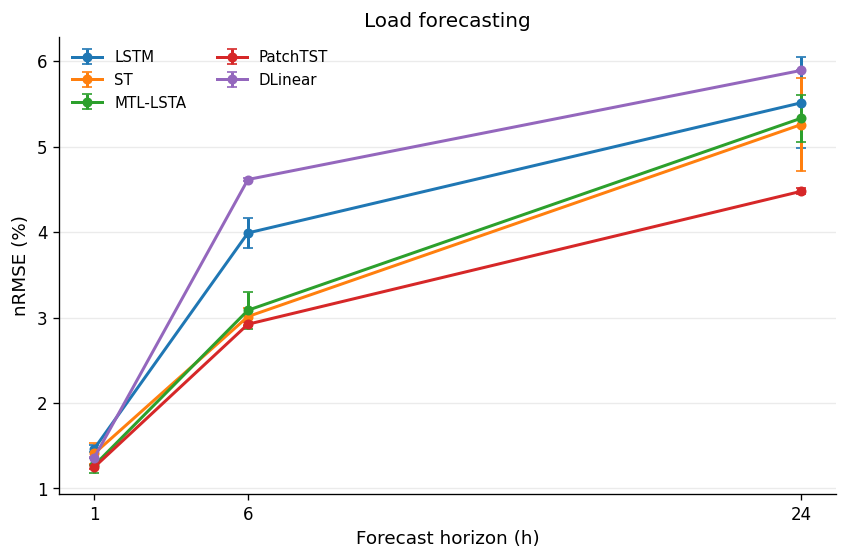

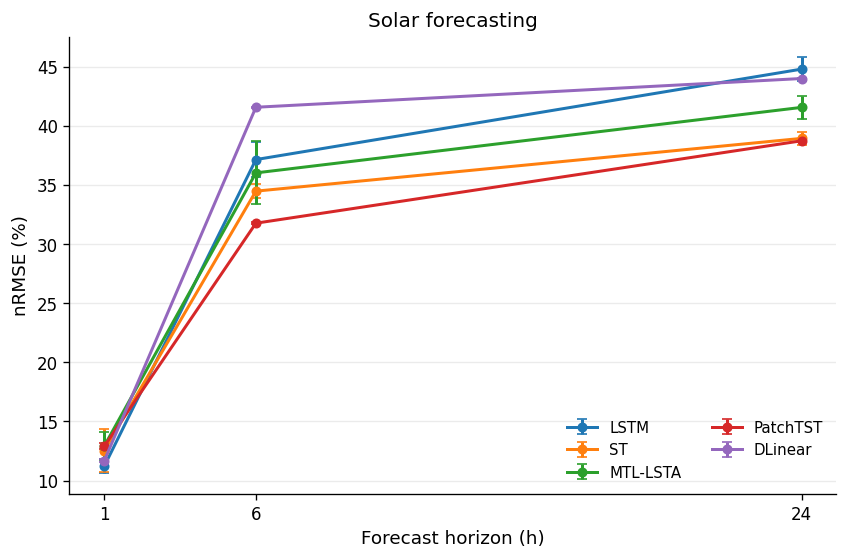


[5] Figure A individual target panels: PASS


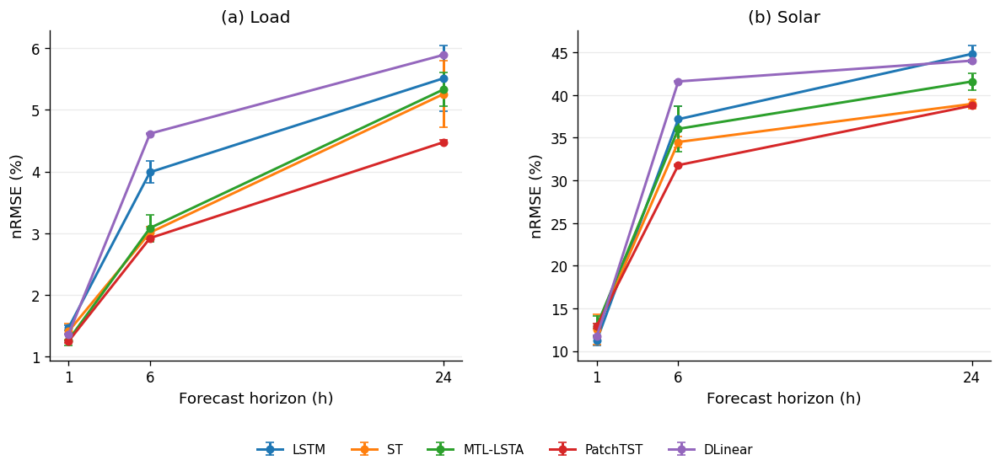

[6] Figure A combined manuscript version: PASS


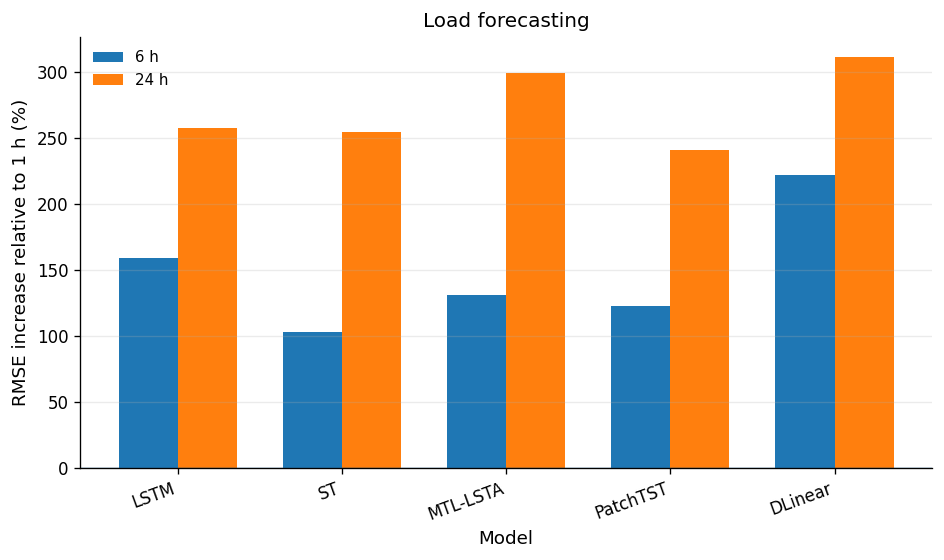

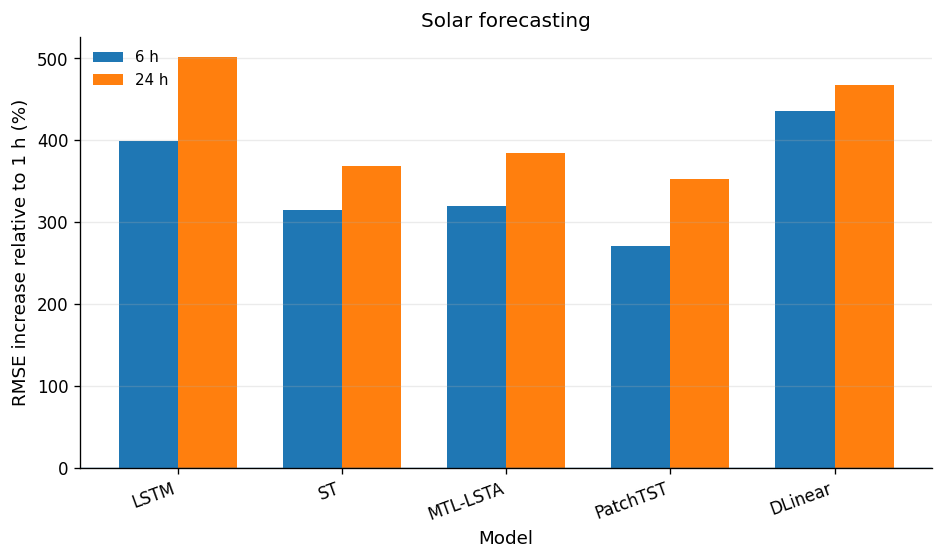

[7] Figure B individual target panels: PASS


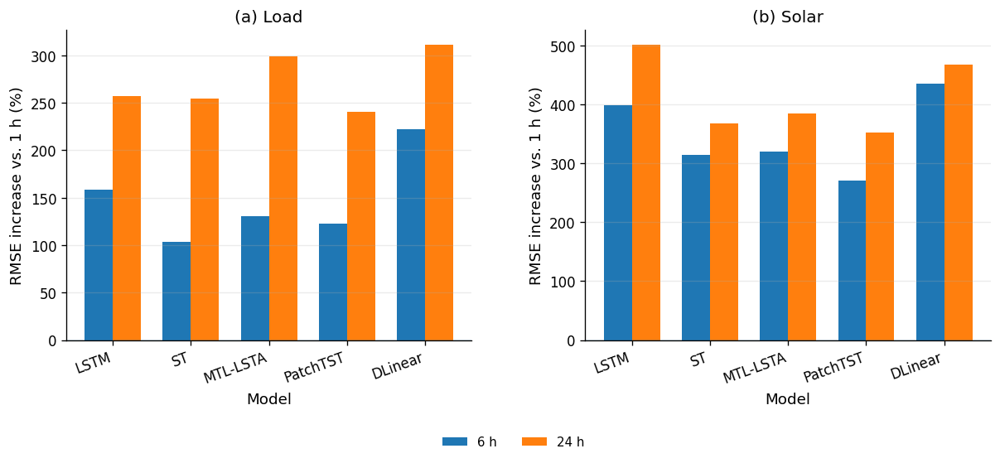

[8] Figure B combined manuscript version: PASS
[9] Exact figure-data exports: PASS
[10] All figure files exist and are non-empty: PASS

STEP 10E-2 FINAL STATUS
PASS — Figure A generated from frozen Step 10E-1 nRMSE results.
PASS — Figure B generated from frozen Step 10E-1 horizon-degradation results.
PASS — individual Load/Solar versions generated.
PASS — combined manuscript versions generated.
PASS — PNG versions saved at 600 dpi.
PASS — vector PDF versions saved.
PASS — exact numerical source data exported.
PASS — all expected outputs exist and are non-empty.

NO TRAINING OR MODEL INFERENCE WAS PERFORMED.

Main manuscript figures:
 Figure A: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_synthesis/figures/STEP10E2_FigureA_CrossHorizon_nRMSE.png
            /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_synthesis/figures/STEP10E2_FigureA_CrossHorizon_nRMSE.pdf
 Figure B: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_synthesi

In [ ]:
# ======================================================================================
# STEP 10E-2 — PUBLICATION-READY CROSS-HORIZON FIGURES
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Inputs:
#   - Certified Step 10E-1 master five-seed metrics
#   - Certified Step 10E-1 horizon-degradation table
#
# Outputs:
#   Figure A:
#       Cross-horizon nRMSE (mean ± sample SD)
#
#   Figure B:
#       RMSE increase relative to the 1-h horizon
#
# Each figure is saved as:
#       PNG — 600 dpi
#       PDF — vector
#
# IMPORTANT:
#   - No model execution
#   - No numerical recomputation from predictions
#   - Figures use ONLY frozen Step 10E-1 results
# ======================================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json


print("=" * 128)
print("STEP 10E-2 — PUBLICATION-READY CROSS-HORIZON FIGURES")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 128)


# ======================================================================================
# 1. PATHS
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

SYNTH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
    / "cross_horizon_synthesis"
)

FIG_ROOT = (
    SYNTH_ROOT
    / "figures"
)

FIG_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


MASTER_PATH = (
    SYNTH_ROOT
    / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)

DEGRADATION_PATH = (
    SYNTH_ROOT
    / "STEP10E1_HORIZON_RMSE_DEGRADATION_VS_1h.csv"
)

CERT_PATH = (
    SYNTH_ROOT
    / "STEP10E1_CROSS_HORIZON_MASTER_CERTIFICATION.json"
)


assert MASTER_PATH.exists()
assert DEGRADATION_PATH.exists()
assert CERT_PATH.exists()


# ======================================================================================
# 2. VERIFY STEP 10E-1 CERTIFICATION
# ======================================================================================

with open(
    CERT_PATH,
    "r",
    encoding="utf-8"
) as f:

    cert = json.load(f)


assert cert["status"] == "PASS"

assert cert["training_performed"] is False

assert cert["model_inference_performed"] is False


print("\n[1] Step 10E-1 certification: PASS")


# ======================================================================================
# 3. LOAD FROZEN TABLES
# ======================================================================================

master = pd.read_csv(
    MASTER_PATH
)

degradation = pd.read_csv(
    DEGRADATION_PATH
)


assert len(master) == 30
assert len(degradation) == 20


MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

TARGETS = [
    "Load",
    "Solar",
]

HORIZONS = [
    1,
    6,
    24,
]


assert set(master["model"]) == set(MODELS)
assert set(master["target"]) == set(TARGETS)
assert set(master["horizon_h"]) == set(HORIZONS)


print("[2] Certified master metrics loaded: PASS")
print("[3] Certified horizon-degradation table loaded: PASS")


# ======================================================================================
# 4. HIGH-VALUE SENTINEL CHECKS
# ======================================================================================

def get_master_value(
    horizon,
    model,
    target,
    column
):

    r = master[
        (master["horizon_h"] == horizon)
        &
        (master["model"] == model)
        &
        (master["target"] == target)
    ]

    assert len(r) == 1

    return float(
        r[column].iloc[0]
    )


# 1 h
assert np.isclose(
    get_master_value(
        1,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    697.373,
    atol=0.001
)

assert np.isclose(
    get_master_value(
        1,
        "LSTM",
        "Solar",
        "RMSE_mean"
    ),
    469.731,
    atol=0.001
)


# 6 h
assert np.isclose(
    get_master_value(
        6,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    1549.839907,
    atol=0.001
)

assert np.isclose(
    get_master_value(
        6,
        "PatchTST",
        "Solar",
        "RMSE_mean"
    ),
    2003.036385,
    atol=0.001
)


# 24 h
assert np.isclose(
    get_master_value(
        24,
        "PatchTST",
        "Load",
        "RMSE_mean"
    ),
    2374.514584,
    atol=0.001
)

assert np.isclose(
    get_master_value(
        24,
        "PatchTST",
        "Solar",
        "RMSE_mean"
    ),
    2442.405061,
    atol=0.001
)


print("[4] Frozen metric sentinels: PASS")


# ======================================================================================
# 5. MATPLOTLIB SETTINGS
# ======================================================================================

plt.rcParams.update({

    "font.size": 11,

    "axes.titlesize": 12,

    "axes.labelsize": 11,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 9,

    "figure.dpi": 120,

    "savefig.dpi": 600,

    "axes.spines.top": False,

    "axes.spines.right": False,

})


# ======================================================================================
# 6. FIGURE A — CROSS-HORIZON nRMSE
#
# Separate files for Load and Solar are generated first.
# A combined two-panel manuscript version is then generated.
# ======================================================================================

figure_a_paths = []


for target in TARGETS:

    fig, ax = plt.subplots(
        figsize=(7.2, 4.8)
    )


    for model in MODELS:

        d = (
            master[
                (master["target"] == target)
                &
                (master["model"] == model)
            ]
            .sort_values("horizon_h")
        )


        assert d["horizon_h"].tolist() == HORIZONS


        ax.errorbar(

            d["horizon_h"],

            d["nRMSE_mean_percent_mean"],

            yerr=d["nRMSE_mean_percent_sd"],

            marker="o",

            linewidth=1.8,

            markersize=5,

            capsize=3,

            label=model
        )


    ax.set_xlabel(
        "Forecast horizon (h)"
    )

    ax.set_ylabel(
        "nRMSE (%)"
    )

    ax.set_title(
        f"{target} forecasting"
    )

    ax.set_xticks(
        HORIZONS
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.legend(
        frameon=False,
        ncol=2
    )

    fig.tight_layout()


    png_path = (
        FIG_ROOT
        /
        f"STEP10E2_FigureA_{target}_CrossHorizon_nRMSE.png"
    )

    pdf_path = (
        FIG_ROOT
        /
        f"STEP10E2_FigureA_{target}_CrossHorizon_nRMSE.pdf"
    )


    fig.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )


    plt.show()
    plt.close(fig)


    figure_a_paths.extend(
        [
            str(png_path),
            str(pdf_path),
        ]
    )


print(
    "\n[5] Figure A individual target panels: PASS"
)


# ======================================================================================
# 7. FIGURE A — COMBINED MANUSCRIPT VERSION
# ======================================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.0, 4.8)
)


for ax, target, panel in zip(
    axes,
    TARGETS,
    ["(a)", "(b)"]
):

    for model in MODELS:

        d = (
            master[
                (master["target"] == target)
                &
                (master["model"] == model)
            ]
            .sort_values("horizon_h")
        )


        ax.errorbar(

            d["horizon_h"],

            d["nRMSE_mean_percent_mean"],

            yerr=d["nRMSE_mean_percent_sd"],

            marker="o",

            linewidth=1.8,

            markersize=5,

            capsize=3,

            label=model
        )


    ax.set_xlabel(
        "Forecast horizon (h)"
    )

    ax.set_ylabel(
        "nRMSE (%)"
    )

    ax.set_xticks(
        HORIZONS
    )

    ax.set_title(
        f"{panel} {target}"
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )


handles, labels = axes[0].get_legend_handles_labels()


fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)


fig.subplots_adjust(
    bottom=0.20,
    wspace=0.28
)


figure_a_combined_png = (
    FIG_ROOT
    /
    "STEP10E2_FigureA_CrossHorizon_nRMSE.png"
)

figure_a_combined_pdf = (
    FIG_ROOT
    /
    "STEP10E2_FigureA_CrossHorizon_nRMSE.pdf"
)


fig.savefig(
    figure_a_combined_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure_a_combined_pdf,
    bbox_inches="tight"
)


plt.show()
plt.close(fig)


print(
    "[6] Figure A combined manuscript version: PASS"
)


# ======================================================================================
# 8. FIGURE B — HORIZON-INDUCED RMSE GROWTH
#
# Values are percentage RMSE increase relative to each model's own
# 1-h RMSE.
#
# h=1 is therefore the zero reference and is not plotted as a bar.
# ======================================================================================

figure_b_paths = []


for target in TARGETS:

    d_target = degradation[
        degradation["target"] == target
    ].copy()


    assert len(d_target) == 10


    # Pivot:
    # rows    = model
    # columns = horizon 6 / 24
    plot_df = (

        d_target

        .pivot(
            index="model",
            columns="horizon_h",
            values="RMSE_percent_increase_vs_h1"
        )

        .reindex(
            MODELS
        )
    )


    assert set(
        plot_df.columns
    ) == {
        6,
        24,
    }


    fig, ax = plt.subplots(
        figsize=(8.0, 4.8)
    )


    x = np.arange(
        len(MODELS)
    )

    width = 0.36


    ax.bar(
        x - width / 2,
        plot_df[6],
        width,
        label="6 h"
    )

    ax.bar(
        x + width / 2,
        plot_df[24],
        width,
        label="24 h"
    )


    ax.set_xlabel(
        "Model"
    )

    ax.set_ylabel(
        "RMSE increase relative to 1 h (%)"
    )

    ax.set_title(
        f"{target} forecasting"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        MODELS,
        rotation=20,
        ha="right"
    )

    ax.axhline(
        0,
        linewidth=0.8
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.legend(
        frameon=False
    )


    fig.tight_layout()


    png_path = (
        FIG_ROOT
        /
        f"STEP10E2_FigureB_{target}_RMSE_Growth_vs_1h.png"
    )

    pdf_path = (
        FIG_ROOT
        /
        f"STEP10E2_FigureB_{target}_RMSE_Growth_vs_1h.pdf"
    )


    fig.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight"
    )


    plt.show()
    plt.close(fig)


    figure_b_paths.extend(
        [
            str(png_path),
            str(pdf_path),
        ]
    )


print(
    "[7] Figure B individual target panels: PASS"
)


# ======================================================================================
# 9. FIGURE B — COMBINED MANUSCRIPT VERSION
# ======================================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.0, 4.8)
)


for ax, target, panel in zip(
    axes,
    TARGETS,
    ["(a)", "(b)"]
):

    d_target = degradation[
        degradation["target"] == target
    ].copy()


    plot_df = (

        d_target

        .pivot(
            index="model",
            columns="horizon_h",
            values="RMSE_percent_increase_vs_h1"
        )

        .reindex(
            MODELS
        )
    )


    x = np.arange(
        len(MODELS)
    )

    width = 0.36


    ax.bar(
        x - width / 2,
        plot_df[6],
        width,
        label="6 h"
    )

    ax.bar(
        x + width / 2,
        plot_df[24],
        width,
        label="24 h"
    )


    ax.set_xlabel(
        "Model"
    )

    ax.set_ylabel(
        "RMSE increase vs. 1 h (%)"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        MODELS,
        rotation=20,
        ha="right"
    )

    ax.set_title(
        f"{panel} {target}"
    )

    ax.axhline(
        0,
        linewidth=0.8
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )


handles, labels = axes[0].get_legend_handles_labels()


fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)


fig.subplots_adjust(
    bottom=0.23,
    wspace=0.28
)


figure_b_combined_png = (
    FIG_ROOT
    /
    "STEP10E2_FigureB_Horizon_RMSE_Growth.png"
)

figure_b_combined_pdf = (
    FIG_ROOT
    /
    "STEP10E2_FigureB_Horizon_RMSE_Growth.pdf"
)


fig.savefig(
    figure_b_combined_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure_b_combined_pdf,
    bbox_inches="tight"
)


plt.show()
plt.close(fig)


print(
    "[8] Figure B combined manuscript version: PASS"
)


# ======================================================================================
# 10. NUMERICAL FIGURE-DATA EXPORT
#
# Save the exact numerical data underlying both figures.
# This is useful for reproducibility and manuscript verification.
# ======================================================================================

figure_a_data = (

    master[
        [
            "horizon_h",
            "model",
            "target",
            "nRMSE_mean_percent_mean",
            "nRMSE_mean_percent_sd",
            "RMSE_mean",
            "RMSE_sd",
        ]
    ]

    .sort_values(
        [
            "target",
            "model",
            "horizon_h",
        ]
    )

    .reset_index(
        drop=True
    )
)


figure_b_data = (

    degradation[
        [
            "model",
            "target",
            "reference_horizon_h",
            "horizon_h",
            "RMSE_h1",
            "RMSE_h",
            "RMSE_ratio_vs_h1",
            "RMSE_percent_increase_vs_h1",
        ]
    ]

    .sort_values(
        [
            "target",
            "model",
            "horizon_h",
        ]
    )

    .reset_index(
        drop=True
    )
)


figure_a_data_path = (
    FIG_ROOT
    /
    "STEP10E2_FigureA_DATA.csv"
)

figure_b_data_path = (
    FIG_ROOT
    /
    "STEP10E2_FigureB_DATA.csv"
)


figure_a_data.to_csv(
    figure_a_data_path,
    index=False
)

figure_b_data.to_csv(
    figure_b_data_path,
    index=False
)


assert len(
    figure_a_data
) == 30

assert len(
    figure_b_data
) == 20


print(
    "[9] Exact figure-data exports: PASS"
)


# ======================================================================================
# 11. OUTPUT EXISTENCE / SIZE CERTIFICATION
# ======================================================================================

expected_outputs = [

    # Figure A
    FIG_ROOT
    / "STEP10E2_FigureA_Load_CrossHorizon_nRMSE.png",

    FIG_ROOT
    / "STEP10E2_FigureA_Load_CrossHorizon_nRMSE.pdf",

    FIG_ROOT
    / "STEP10E2_FigureA_Solar_CrossHorizon_nRMSE.png",

    FIG_ROOT
    / "STEP10E2_FigureA_Solar_CrossHorizon_nRMSE.pdf",

    figure_a_combined_png,
    figure_a_combined_pdf,

    # Figure B
    FIG_ROOT
    / "STEP10E2_FigureB_Load_RMSE_Growth_vs_1h.png",

    FIG_ROOT
    / "STEP10E2_FigureB_Load_RMSE_Growth_vs_1h.pdf",

    FIG_ROOT
    / "STEP10E2_FigureB_Solar_RMSE_Growth_vs_1h.png",

    FIG_ROOT
    / "STEP10E2_FigureB_Solar_RMSE_Growth_vs_1h.pdf",

    figure_b_combined_png,
    figure_b_combined_pdf,

    # Data
    figure_a_data_path,
    figure_b_data_path,
]


for p in expected_outputs:

    assert p.exists(), (
        f"Missing expected output:\n{p}"
    )

    assert p.stat().st_size > 0, (
        f"Empty output:\n{p}"
    )


print(
    "[10] All figure files exist and are non-empty: PASS"
)


# ======================================================================================
# 12. FINAL FIGURE CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10E-2",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "source_step":
        "STEP10E-1",

    "source_master_metrics":
        str(
            MASTER_PATH
        ),

    "source_horizon_degradation":
        str(
            DEGRADATION_PATH
        ),

    "horizons_h":
        HORIZONS,

    "models":
        MODELS,

    "targets":
        TARGETS,

    "figure_A":
        {
            "description":
                "Five-seed mean nRMSE across 1 h, 6 h, and 24 h with sample-SD error bars.",

            "combined_png":
                str(
                    figure_a_combined_png
                ),

            "combined_pdf":
                str(
                    figure_a_combined_pdf
                ),

            "data":
                str(
                    figure_a_data_path
                ),
        },

    "figure_B":
        {
            "description":
                "Percentage RMSE increase at 6 h and 24 h relative to each model's own 1-h RMSE.",

            "combined_png":
                str(
                    figure_b_combined_png
                ),

            "combined_pdf":
                str(
                    figure_b_combined_pdf
                ),

            "data":
                str(
                    figure_b_data_path
                ),
        },

    "png_dpi":
        600,

    "pdf_vector":
        True,

    "n_expected_outputs":
        len(
            expected_outputs
        ),
}


manifest_path = (
    FIG_ROOT
    /
    "STEP10E2_FIGURE_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


assert manifest_path.exists()
assert manifest_path.stat().st_size > 0


# ======================================================================================
# 13. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 128)
print("STEP 10E-2 FINAL STATUS")
print("=" * 128)

print(
    "PASS — Figure A generated from frozen Step 10E-1 nRMSE results."
)

print(
    "PASS — Figure B generated from frozen Step 10E-1 horizon-degradation results."
)

print(
    "PASS — individual Load/Solar versions generated."
)

print(
    "PASS — combined manuscript versions generated."
)

print(
    "PASS — PNG versions saved at 600 dpi."
)

print(
    "PASS — vector PDF versions saved."
)

print(
    "PASS — exact numerical source data exported."
)

print(
    "PASS — all expected outputs exist and are non-empty."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)


print("\nMain manuscript figures:")

print(
    " Figure A:",
    figure_a_combined_png
)

print(
    "           ",
    figure_a_combined_pdf
)

print(
    " Figure B:",
    figure_b_combined_png
)

print(
    "           ",
    figure_b_combined_pdf
)


print(
    "\nCertification:"
)

print(
    " ",
    manifest_path
)


print(
    "\nNEXT:"
)

print(
    "Inspect the two combined figures visually."
)

print(
    "If they are correct, freeze Step 10E-2 and proceed to "
    "Step 10F: horizon-specific DM-HAC + Holm statistical testing."
)

print("=" * 128)

Step 10F — Multi-horizon statistical testing

In [ ]:
# ======================================================================================
# STEP 10F — DEFINITIVE MULTI-HORIZON DM-HAC + HOLM STATISTICAL TESTING
#
# ZERO TRAINING
# ZERO MODEL INFERENCE
#
# Horizons analyzed:
#       h = 6
#       h = 24
#
# Models:
#       LSTM
#       ST
#       MTL-LSTA
#       PatchTST
#       DLinear
#
# Seeds:
#       1, 7, 21, 42, 100
#
# Statistical protocol — SAME AS FROZEN STEP 9:
#
#   Loss               : squared error
#   Loss differential  : d_t = e_A,t^2 - e_B,t^2
#   HAC estimator       : Newey-West / Bartlett
#   HAC lag             : 24
#   DM reference        : standard normal
#   Alternative         : two-sided
#   Multiple testing    : Holm
#
# IMPORTANT:
# Holm correction is applied SEPARATELY within:
#
#       h=6  × Load   : 50 tests
#       h=6  × Solar  : 50 tests
#       h=24 × Load   : 50 tests
#       h=24 × Solar  : 50 tests
#
# Total raw DM tests = 200.
#
# NO TRAINING
# NO MODEL INFERENCE
# DO NOT MODIFY ANY FROZEN PREDICTION ARTIFACT
# ======================================================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import json
import math


print("=" * 136)
print("STEP 10F — DEFINITIVE MULTI-HORIZON DM-HAC + HOLM STATISTICAL TESTING")
print("ZERO TRAINING — ZERO MODEL INFERENCE")
print("=" * 136)


# ======================================================================================
# 1. FROZEN CONFIGURATION
# ======================================================================================

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5"
)

MH_ROOT = (
    ROOT
    / "MultiHorizon_V6"
)

TRAIN_ROOT = (
    MH_ROOT
    / "definitive_training"
)

CERT_ROOT = (
    TRAIN_ROOT
    / "certification"
)

SYNTH_ROOT = (
    MH_ROOT
    / "cross_horizon_synthesis"
)

STAT_ROOT = (
    SYNTH_ROOT
    / "statistics"
)

STAT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


MODELS = [
    "LSTM",
    "ST",
    "MTL-LSTA",
    "PatchTST",
    "DLinear",
]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear",
]

SEEDS = [
    1,
    7,
    21,
    42,
    100,
]

HORIZONS = [
    6,
    24,
]

TARGETS = [
    "Load",
    "Solar",
]

TARGET_INDEX = {
    "Load": 0,
    "Solar": 1,
}

HAC_LAG = 24

ALPHA = 0.05


# Expected certified dataset hashes
EXPECTED_DATASET_HASH = {

    6:
        "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",

    24:
        "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936",
}


print("\nFrozen statistical protocol:")
print("  Loss              : squared error")
print("  HAC                : Newey-West / Bartlett")
print("  HAC lag            :", HAC_LAG)
print("  Alternative        : two-sided")
print("  Reference          : standard normal")
print("  Multiple testing   : Holm")
print("  Holm families      : horizon × target")
print("  Alpha              :", ALPHA)


# ======================================================================================
# 2. LOCATE PREDICTION ROOT SAFELY
#
# We do not guess prediction values.
# We locate existing frozen prediction artifacts only.
# ======================================================================================

candidate_prediction_roots = [

    TRAIN_ROOT / "predictions",

    TRAIN_ROOT,

    MH_ROOT / "predictions",
]


PRED_ROOT = None


for p in candidate_prediction_roots:

    if p.exists():

        matches = list(
            p.rglob(
                "h06_seed001_LSTM_predictions.npz"
            )
        )

        if len(matches) > 0:

            PRED_ROOT = matches[0].parent
            break


if PRED_ROOT is None:

    matches = list(
        MH_ROOT.rglob(
            "h06_seed001_LSTM_predictions.npz"
        )
    )

    assert len(matches) == 1, (
        "Could not uniquely locate the frozen h=6 prediction artifacts.\n"
        f"Found {len(matches)} candidates.\n"
        "STOP — do not regenerate predictions."
    )

    PRED_ROOT = matches[0].parent


print("\n[1] Frozen prediction root located:")
print("   ", PRED_ROOT)


# ======================================================================================
# 3. PREDICTION FILE RESOLUTION
# ======================================================================================

def physical_name_for_conceptual(
    model,
    target
):

    if model == "ST":

        if target == "Load":
            return "ST_Load"

        if target == "Solar":
            return "ST_Solar"

    if model == "MTL-LSTA":
        return "MTL_LSTA"

    return model


def prediction_path(
    horizon,
    seed,
    physical_model
):

    filename = (
        f"h{horizon:02d}_seed{seed:03d}_"
        f"{physical_model}_predictions.npz"
    )

    direct = (
        PRED_ROOT
        /
        filename
    )

    if direct.exists():
        return direct


    # Safe recursive lookup.
    matches = list(
        MH_ROOT.rglob(
            filename
        )
    )

    assert len(matches) == 1, (
        f"Expected exactly one frozen artifact for {filename}; "
        f"found {len(matches)}."
    )

    return matches[0]


# ======================================================================================
# 4. LOAD ONE TARGET'S FROZEN PREDICTION
#
# Multi-output models:
#     y_true_physical : (6576, 2)
#     y_pred_physical : (6576, 2)
#
# ST_Load / ST_Solar may contain:
#     (6576,)
#     (6576,1)
# or target-specific arrays.
# ======================================================================================

def load_target_prediction(
    horizon,
    seed,
    model,
    target
):

    physical_model = physical_name_for_conceptual(
        model,
        target
    )

    path = prediction_path(
        horizon,
        seed,
        physical_model
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        keys = set(
            z.files
        )


        assert "y_true_physical" in keys, (
            f"Missing y_true_physical in {path}"
        )

        assert "y_pred_physical" in keys, (
            f"Missing y_pred_physical in {path}"
        )


        y_true = np.asarray(
            z["y_true_physical"],
            dtype=np.float64
        )

        y_pred = np.asarray(
            z["y_pred_physical"],
            dtype=np.float64
        )


        # --------------------------------------------------------------
        # Multi-output prediction
        # --------------------------------------------------------------

        if y_pred.ndim == 2 and y_pred.shape[1] == 2:

            idx = TARGET_INDEX[
                target
            ]

            true_target = y_true[:, idx]

            pred_target = y_pred[:, idx]


        # --------------------------------------------------------------
        # Single-output ST prediction
        # --------------------------------------------------------------

        else:

            pred_target = y_pred.reshape(-1)


            if y_true.ndim == 2 and y_true.shape[1] == 2:

                idx = TARGET_INDEX[
                    target
                ]

                true_target = y_true[:, idx]

            else:

                true_target = y_true.reshape(-1)


    assert len(
        true_target
    ) == 6576

    assert len(
        pred_target
    ) == 6576


    assert np.isfinite(
        true_target
    ).all()

    assert np.isfinite(
        pred_target
    ).all()


    return (
        true_target,
        pred_target,
        path,
    )


# ======================================================================================
# 5. CERTIFY ALL PREDICTION ARTIFACTS AND COMMON GROUND TRUTH
# ======================================================================================

prediction_cache = {}

truth_reference = {}


for horizon in HORIZONS:

    for seed in SEEDS:

        for target in TARGETS:

            seed_truth = None


            for model in MODELS:

                y_true, y_pred, path = load_target_prediction(
                    horizon,
                    seed,
                    model,
                    target
                )


                if seed_truth is None:

                    seed_truth = y_true.copy()

                else:

                    assert np.array_equal(
                        seed_truth,
                        y_true
                    ), (
                        f"Ground-truth mismatch:\n"
                        f"h={horizon}, seed={seed}, "
                        f"target={target}, model={model}"
                    )


                prediction_cache[
                    (
                        horizon,
                        seed,
                        target,
                        model,
                    )
                ] = y_pred


            # ----------------------------------------------------------
            # Truth must also be identical across seeds.
            # ----------------------------------------------------------

            if (
                horizon,
                target
            ) not in truth_reference:

                truth_reference[
                    (
                        horizon,
                        target
                    )
                ] = seed_truth.copy()

            else:

                assert np.array_equal(

                    truth_reference[
                        (
                            horizon,
                            target
                        )
                    ],

                    seed_truth
                )


print(
    "[2] All frozen h=6/h=24 prediction artifacts loaded: PASS"
)

print(
    "[3] Common ground truth across all five models and seeds: PASS"
)


# ======================================================================================
# 6. CERTIFY SAME TEST TARGETS ACROSS h=6 AND h=24
#
# The multi-horizon design preserved the same Jan-Sep 2020 target timestamps.
# Therefore y_test should be identical across horizons.
# ======================================================================================

for target in TARGETS:

    assert np.array_equal(

        truth_reference[
            (
                6,
                target
            )
        ],

        truth_reference[
            (
                24,
                target
            )
        ]

    ), (
        f"h=6/h=24 test truth mismatch for {target}"
    )


print(
    "[4] h=6 and h=24 authoritative test targets are identical: PASS"
)


# ======================================================================================
# 7. NORMAL CDF / TWO-SIDED p-VALUE
#
# No SciPy dependency required.
# ======================================================================================

def normal_two_sided_p(
    z
):

    # Phi(-|z|) via erfc
    return math.erfc(
        abs(
            float(z)
        )
        /
        math.sqrt(2.0)
    )


# ======================================================================================
# 8. FROZEN DM-HAC IMPLEMENTATION
#
# Loss differential:
#
#     d_t = e_A,t^2 - e_B,t^2
#
# Positive mean(d):
#     Model B has lower mean squared error.
#
# Negative mean(d):
#     Model A has lower mean squared error.
#
# Newey-West / Bartlett:
#
# gamma_k = (1/n) sum_{t=k+1}^n
#               (d_t-dbar)(d_{t-k}-dbar)
#
# long-run variance:
#
# S = gamma_0
#     + 2 sum_{k=1}^L
#         (1 - k/(L+1)) gamma_k
#
# Var(dbar) = S/n
#
# DM = dbar / sqrt(S/n)
#
# Reference:
#     standard normal, two-sided.
# ======================================================================================

def dm_hac_squared_error(
    y_true,
    pred_a,
    pred_b,
    lag=24
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    ).reshape(-1)

    pred_a = np.asarray(
        pred_a,
        dtype=np.float64
    ).reshape(-1)

    pred_b = np.asarray(
        pred_b,
        dtype=np.float64
    ).reshape(-1)


    assert (
        len(y_true)
        ==
        len(pred_a)
        ==
        len(pred_b)
    )


    n = len(
        y_true
    )


    assert n > lag


    err_a = (
        y_true
        -
        pred_a
    )

    err_b = (
        y_true
        -
        pred_b
    )


    loss_a = (
        err_a ** 2
    )

    loss_b = (
        err_b ** 2
    )


    d = (
        loss_a
        -
        loss_b
    )


    dbar = float(
        np.mean(
            d
        )
    )


    centered = (
        d
        -
        dbar
    )


    gamma0 = float(
        np.dot(
            centered,
            centered
        )
        /
        n
    )


    long_run_variance = gamma0


    for k in range(
        1,
        lag + 1
    ):

        gamma_k = float(

            np.dot(
                centered[k:],
                centered[:-k]
            )
            /
            n
        )


        bartlett_weight = (
            1.0
            -
            k
            /
            (
                lag
                +
                1.0
            )
        )


        long_run_variance += (
            2.0
            *
            bartlett_weight
            *
            gamma_k
        )


    # Numerical protection only.
    # A genuinely invalid negative HAC variance is NOT silently accepted.
    if long_run_variance < -1e-12:

        raise RuntimeError(
            "Negative HAC long-run variance encountered: "
            f"{long_run_variance}"
        )


    long_run_variance = max(
        long_run_variance,
        0.0
    )


    var_mean = (
        long_run_variance
        /
        n
    )


    if var_mean == 0.0:

        if dbar == 0.0:

            dm_stat = 0.0
            p_value = 1.0

        else:

            dm_stat = (
                np.inf
                if dbar > 0
                else -np.inf
            )

            p_value = 0.0

    else:

        dm_stat = (
            dbar
            /
            np.sqrt(
                var_mean
            )
        )

        p_value = normal_two_sided_p(
            dm_stat
        )


    mse_a = float(
        np.mean(
            loss_a
        )
    )

    mse_b = float(
        np.mean(
            loss_b
        )
    )


    rmse_a = float(
        np.sqrt(
            mse_a
        )
    )

    rmse_b = float(
        np.sqrt(
            mse_b
        )
    )


    if dbar < 0:

        lower_loss_model = "A"

    elif dbar > 0:

        lower_loss_model = "B"

    else:

        lower_loss_model = "Tie"


    return {

        "n":
            n,

        "hac_lag":
            lag,

        "mean_loss_diff_A_minus_B":
            dbar,

        "hac_long_run_variance":
            long_run_variance,

        "dm_stat":
            float(
                dm_stat
            ),

        "p_raw":
            float(
                p_value
            ),

        "RMSE_A":
            rmse_a,

        "RMSE_B":
            rmse_b,

        "lower_loss_side":
            lower_loss_model,
    }


# ======================================================================================
# 9. HOLM CORRECTION
#
# Applied separately to each horizon × target family.
# ======================================================================================

def holm_adjust(
    p_values
):

    p = np.asarray(
        p_values,
        dtype=np.float64
    )


    m = len(
        p
    )


    assert m > 0

    assert np.isfinite(
        p
    ).all()

    assert (
        (
            p >= 0
        )
        &
        (
            p <= 1
        )
    ).all()


    order = np.argsort(
        p
    )

    sorted_p = p[
        order
    ]


    adjusted_sorted = np.empty(
        m,
        dtype=np.float64
    )


    running_max = 0.0


    for i, p_i in enumerate(
        sorted_p
    ):

        adjusted = (
            (
                m
                -
                i
            )
            *
            p_i
        )


        adjusted = min(
            adjusted,
            1.0
        )


        running_max = max(
            running_max,
            adjusted
        )


        adjusted_sorted[
            i
        ] = running_max


    adjusted = np.empty(
        m,
        dtype=np.float64
    )


    adjusted[
        order
    ] = adjusted_sorted


    return adjusted


# ======================================================================================
# 10. RUN ALL 200 DM TESTS
#
# 2 horizons
# × 2 targets
# × 5 seeds
# × 10 model pairs
# = 200
# ======================================================================================

pairs = list(
    combinations(
        MODELS,
        2
    )
)


assert len(
    pairs
) == 10


rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        y_true = truth_reference[
            (
                horizon,
                target
            )
        ]


        for seed in SEEDS:

            for model_a, model_b in pairs:

                pred_a = prediction_cache[
                    (
                        horizon,
                        seed,
                        target,
                        model_a,
                    )
                ]

                pred_b = prediction_cache[
                    (
                        horizon,
                        seed,
                        target,
                        model_b,
                    )
                ]


                result = dm_hac_squared_error(
                    y_true,
                    pred_a,
                    pred_b,
                    lag=HAC_LAG
                )


                if result[
                    "lower_loss_side"
                ] == "A":

                    lower_loss_model = model_a

                elif result[
                    "lower_loss_side"
                ] == "B":

                    lower_loss_model = model_b

                else:

                    lower_loss_model = "Tie"


                rows.append({

                    "horizon_h":
                        horizon,

                    "target":
                        target,

                    "seed":
                        seed,

                    "model_A":
                        model_a,

                    "model_B":
                        model_b,

                    "n":
                        result[
                            "n"
                        ],

                    "hac_lag":
                        result[
                            "hac_lag"
                        ],

                    "RMSE_A":
                        result[
                            "RMSE_A"
                        ],

                    "RMSE_B":
                        result[
                            "RMSE_B"
                        ],

                    "mean_loss_diff_A_minus_B":
                        result[
                            "mean_loss_diff_A_minus_B"
                        ],

                    "dm_stat":
                        result[
                            "dm_stat"
                        ],

                    "p_raw":
                        result[
                            "p_raw"
                        ],

                    "lower_loss_model":
                        lower_loss_model,
                })


dm_df = pd.DataFrame(
    rows
)


assert len(
    dm_df
) == 200


print(
    "\n[5] Raw DM-HAC tests generated: 200/200 PASS"
)


# ======================================================================================
# 11. APPLY HOLM SEPARATELY WITHIN EACH HORIZON × TARGET FAMILY
# ======================================================================================

dm_df[
    "p_holm"
] = np.nan


for horizon in HORIZONS:

    for target in TARGETS:

        mask = (
            (dm_df["horizon_h"] == horizon)
            &
            (dm_df["target"] == target)
        )


        family = dm_df.loc[
            mask
        ].copy()


        assert len(
            family
        ) == 50


        adjusted = holm_adjust(
            family[
                "p_raw"
            ].to_numpy()
        )


        dm_df.loc[
            mask,
            "p_holm"
        ] = adjusted


assert np.isfinite(
    dm_df[
        "p_holm"
    ]
).all()


dm_df[
    "significant_raw_0.05"
] = (
    dm_df[
        "p_raw"
    ]
    <
    ALPHA
)


dm_df[
    "significant_holm_0.05"
] = (
    dm_df[
        "p_holm"
    ]
    <
    ALPHA
)


print(
    "[6] Holm correction applied to four separate 50-test families: PASS"
)


# ======================================================================================
# 12. INTERNAL STATISTICAL CONSISTENCY CHECKS
# ======================================================================================

# Holm-adjusted p cannot be below raw p.
assert (
    dm_df[
        "p_holm"
    ]
    +
    1e-15
    >=
    dm_df[
        "p_raw"
    ]
).all()


# Holm significance must be a subset of raw significance.
assert (
    ~dm_df[
        "significant_holm_0.05"
    ]
    |
    dm_df[
        "significant_raw_0.05"
    ]
).all()


# Every test uses the complete 6,576-target sequence.
assert (
    dm_df[
        "n"
    ]
    ==
    6576
).all()


assert (
    dm_df[
        "hac_lag"
    ]
    ==
    24
).all()


print(
    "[7] Statistical integrity checks: PASS"
)


# ======================================================================================
# 13. FAMILY-LEVEL SUMMARY
# ======================================================================================

family_summary_rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        d = dm_df[
            (dm_df["horizon_h"] == horizon)
            &
            (dm_df["target"] == target)
        ]


        assert len(
            d
        ) == 50


        family_summary_rows.append({

            "horizon_h":
                horizon,

            "target":
                target,

            "n_tests":
                len(d),

            "raw_significant":
                int(
                    d[
                        "significant_raw_0.05"
                    ].sum()
                ),

            "holm_significant":
                int(
                    d[
                        "significant_holm_0.05"
                    ].sum()
                ),
        })


family_summary = pd.DataFrame(
    family_summary_rows
)


# ======================================================================================
# 14. PAIR-LEVEL FIVE-SEED SUMMARY
#
# For each horizon × target × pair:
#
#   - how many seeds favor each model
#   - raw significance count
#   - Holm significance count
#   - Holm-significant wins for each model
# ======================================================================================

pair_summary_rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        for model_a, model_b in pairs:

            d = dm_df[
                (dm_df["horizon_h"] == horizon)
                &
                (dm_df["target"] == target)
                &
                (dm_df["model_A"] == model_a)
                &
                (dm_df["model_B"] == model_b)
            ].copy()


            assert len(
                d
            ) == 5


            favor_a = int(
                (
                    d[
                        "lower_loss_model"
                    ]
                    ==
                    model_a
                ).sum()
            )

            favor_b = int(
                (
                    d[
                        "lower_loss_model"
                    ]
                    ==
                    model_b
                ).sum()
            )

            ties = int(
                (
                    d[
                        "lower_loss_model"
                    ]
                    ==
                    "Tie"
                ).sum()
            )


            holm_a = int(
                (
                    (
                        d[
                            "lower_loss_model"
                        ]
                        ==
                        model_a
                    )
                    &
                    d[
                        "significant_holm_0.05"
                    ]
                ).sum()
            )


            holm_b = int(
                (
                    (
                        d[
                            "lower_loss_model"
                        ]
                        ==
                        model_b
                    )
                    &
                    d[
                        "significant_holm_0.05"
                    ]
                ).sum()
            )


            pair_summary_rows.append({

                "horizon_h":
                    horizon,

                "target":
                    target,

                "model_A":
                    model_a,

                "model_B":
                    model_b,

                "seeds_favor_A":
                    favor_a,

                "seeds_favor_B":
                    favor_b,

                "ties":
                    ties,

                "raw_significant_seeds":
                    int(
                        d[
                            "significant_raw_0.05"
                        ].sum()
                    ),

                "holm_significant_seeds":
                    int(
                        d[
                            "significant_holm_0.05"
                        ].sum()
                    ),

                "holm_sig_wins_A":
                    holm_a,

                "holm_sig_wins_B":
                    holm_b,

                "mean_RMSE_A":
                    float(
                        d[
                            "RMSE_A"
                        ].mean()
                    ),

                "mean_RMSE_B":
                    float(
                        d[
                            "RMSE_B"
                        ].mean()
                    ),
            })


pair_summary = pd.DataFrame(
    pair_summary_rows
)


assert len(
    pair_summary
) == 40


print(
    "[8] Pair-level five-seed summaries generated: PASS"
)


# ======================================================================================
# 15. PATCHTST-FOCUSED SUMMARY
#
# Important for interpretation because PatchTST is numerically first
# at both h=6 and h=24 for both targets.
# ======================================================================================

patch_rows = []


for horizon in HORIZONS:

    for target in TARGETS:

        for competitor in [
            "LSTM",
            "ST",
            "MTL-LSTA",
            "DLinear",
        ]:

            d = dm_df[
                (dm_df["horizon_h"] == horizon)
                &
                (dm_df["target"] == target)
                &
                (
                    (
                        (dm_df["model_A"] == "PatchTST")
                        &
                        (dm_df["model_B"] == competitor)
                    )
                    |
                    (
                        (dm_df["model_A"] == competitor)
                        &
                        (dm_df["model_B"] == "PatchTST")
                    )
                )
            ].copy()


            assert len(
                d
            ) == 5


            patch_wins = int(
                (
                    d[
                        "lower_loss_model"
                    ]
                    ==
                    "PatchTST"
                ).sum()
            )


            competitor_wins = int(
                (
                    d[
                        "lower_loss_model"
                    ]
                    ==
                    competitor
                ).sum()
            )


            patch_holm_wins = int(
                (
                    (
                        d[
                            "lower_loss_model"
                        ]
                        ==
                        "PatchTST"
                    )
                    &
                    d[
                        "significant_holm_0.05"
                    ]
                ).sum()
            )


            competitor_holm_wins = int(
                (
                    (
                        d[
                            "lower_loss_model"
                        ]
                        ==
                        competitor
                    )
                    &
                    d[
                        "significant_holm_0.05"
                    ]
                ).sum()
            )


            patch_rows.append({

                "horizon_h":
                    horizon,

                "target":
                    target,

                "comparison":
                    f"PatchTST vs {competitor}",

                "patch_lower_loss_seeds":
                    patch_wins,

                "competitor_lower_loss_seeds":
                    competitor_wins,

                "patch_holm_significant_wins":
                    patch_holm_wins,

                "competitor_holm_significant_wins":
                    competitor_holm_wins,

                "holm_significant_seeds_total":
                    int(
                        d[
                            "significant_holm_0.05"
                        ].sum()
                    ),
            })


patch_summary = pd.DataFrame(
    patch_rows
)


assert len(
    patch_summary
) == 16


# ======================================================================================
# 16. SAVE ALL STATISTICAL OUTPUTS
# ======================================================================================

raw_path = (
    STAT_ROOT
    /
    "STEP10F_DM_HAC_HOLM_ALL_200_TESTS.csv"
)

family_path = (
    STAT_ROOT
    /
    "STEP10F_DM_HAC_HOLM_FAMILY_SUMMARY.csv"
)

pair_path = (
    STAT_ROOT
    /
    "STEP10F_DM_HAC_HOLM_PAIR_SUMMARY.csv"
)

patch_path = (
    STAT_ROOT
    /
    "STEP10F_PATCHTST_PAIRWISE_SUMMARY.csv"
)


dm_df.to_csv(
    raw_path,
    index=False
)

family_summary.to_csv(
    family_path,
    index=False
)

pair_summary.to_csv(
    pair_path,
    index=False
)

patch_summary.to_csv(
    patch_path,
    index=False
)


# ======================================================================================
# 17. DISPLAY FAMILY RESULTS
# ======================================================================================

print("\n" + "=" * 136)
print("DM-HAC + HOLM FAMILY SUMMARY")
print("=" * 136)

print(
    family_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 18. DISPLAY PATCHTST COMPARISONS
# ======================================================================================

print("\n" + "=" * 136)
print("PATCHTST PAIRWISE FIVE-SEED SUMMARY")
print("=" * 136)

print(
    patch_summary.to_string(
        index=False
    )
)


# ======================================================================================
# 19. DISPLAY ALL PAIR SUMMARIES
# ======================================================================================

for horizon in HORIZONS:

    for target in TARGETS:

        print("\n" + "=" * 136)

        print(
            f"HORIZON = {horizon} h | TARGET = {target.upper()}"
        )

        print("=" * 136)


        d = pair_summary[
            (pair_summary["horizon_h"] == horizon)
            &
            (pair_summary["target"] == target)
        ]


        print(
            d[
                [
                    "model_A",
                    "model_B",
                    "seeds_favor_A",
                    "seeds_favor_B",
                    "holm_significant_seeds",
                    "holm_sig_wins_A",
                    "holm_sig_wins_B",
                    "mean_RMSE_A",
                    "mean_RMSE_B",
                ]
            ]
            .to_string(
                index=False
            )
        )


# ======================================================================================
# 20. CERTIFICATION MANIFEST
# ======================================================================================

manifest = {

    "step":
        "STEP10F",

    "status":
        "PASS",

    "training_performed":
        False,

    "model_inference_performed":
        False,

    "statistical_protocol": {

        "loss":
            "squared error",

        "loss_differential":
            "squared_error_A - squared_error_B",

        "hac":
            "Newey-West / Bartlett",

        "hac_lag":
            24,

        "alternative":
            "two-sided",

        "reference_distribution":
            "standard normal",

        "multiple_testing":
            "Holm",

        "holm_family":
            "separate within each horizon x target",

        "alpha":
            0.05,
    },

    "horizons_h":
        HORIZONS,

    "targets":
        TARGETS,

    "models":
        MODELS,

    "seeds":
        SEEDS,

    "tests_per_horizon_target_family":
        50,

    "n_families":
        4,

    "total_dm_tests":
        200,

    "test_sequence_length":
        6576,

    "dataset_hashes":
        EXPECTED_DATASET_HASH,

    "outputs": {

        "all_tests":
            str(
                raw_path
            ),

        "family_summary":
            str(
                family_path
            ),

        "pair_summary":
            str(
                pair_path
            ),

        "patchtst_summary":
            str(
                patch_path
            ),
    },
}


manifest_path = (
    STAT_ROOT
    /
    "STEP10F_DM_HAC_HOLM_CERTIFICATION.json"
)


with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=2
    )


# ======================================================================================
# 21. OUTPUT CERTIFICATION
# ======================================================================================

expected_outputs = [

    raw_path,
    family_path,
    pair_path,
    patch_path,
    manifest_path,
]


for p in expected_outputs:

    assert p.exists()

    assert p.stat().st_size > 0


print(
    "\n[9] Statistical output files exist and are non-empty: PASS"
)


# ======================================================================================
# 22. FINAL STATUS
# ======================================================================================

print("\n" + "=" * 136)
print("STEP 10F FINAL STATUS")
print("=" * 136)

print(
    "PASS — frozen h=6 and h=24 predictions loaded."
)

print(
    "PASS — common 6,576-target ground truth certified."
)

print(
    "PASS — h=6 and h=24 test targets identical."
)

print(
    "PASS — 200 DM-HAC tests completed."
)

print(
    "PASS — Newey-West/Bartlett HAC lag = 24."
)

print(
    "PASS — two-sided normal-reference testing."
)

print(
    "PASS — Holm correction applied separately to four 50-test families."
)

print(
    "PASS — pair-level five-seed summaries generated."
)

print(
    "PASS — PatchTST-focused comparisons generated."
)

print(
    "\nNO TRAINING OR MODEL INFERENCE WAS PERFORMED."
)


print("\nOutputs:")

for p in expected_outputs:

    print(
        " ",
        p
    )


print(
    "\nNEXT:"
)

print(
    "Inspect and freeze Step 10F statistical results."
)

print(
    "After certification, proceed to the final evidence audit before manuscript revision."
)

print("=" * 136)

STEP 10F — DEFINITIVE MULTI-HORIZON DM-HAC + HOLM STATISTICAL TESTING
ZERO TRAINING — ZERO MODEL INFERENCE

Frozen statistical protocol:
  Loss              : squared error
  HAC                : Newey-West / Bartlett
  HAC lag            : 24
  Alternative        : two-sided
  Reference          : standard normal
  Multiple testing   : Holm
  Holm families      : horizon × target
  Alpha              : 0.05

[1] Frozen prediction root located:
    /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/definitive_training/predictions
[2] All frozen h=6/h=24 prediction artifacts loaded: PASS
[3] Common ground truth across all five models and seeds: PASS
[4] h=6 and h=24 authoritative test targets are identical: PASS

[5] Raw DM-HAC tests generated: 200/200 PASS
[6] Holm correction applied to four separate 50-test families: PASS
[7] Statistical integrity checks: PASS
[8] Pair-level five-seed summaries generated: PASS

DM-HAC + HOLM FAMILY SUMMARY
 horizon_h target  n_tests  raw_significant

Step 11 — Final Evidence and Manuscript Consistency Audit

In [ ]:
# =============================================================================
# STEP 11A — DEFINITIVE V6 EVIDENCE AND PROVENANCE AUDIT
# CORRECTED VERSION 2
#
# READ-ONLY SOURCE AUDIT
# ZERO TRAINING
# ZERO MODEL INFERENCE
# NO MODIFICATION OF FROZEN ARTIFACTS
#
# New audit reports only:
# /content/gdrive/MyDrive/Benchmark_V5/V6_Final_Evidence_Audit/Step11A/
# =============================================================================

from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import hashlib
import json
import traceback
import time

print("=" * 110, flush=True)
print("STEP 11A — DEFINITIVE V6 EVIDENCE AND PROVENANCE AUDIT", flush=True)
print("CORRECTED VERSION 2 — NO TRAINING / NO INFERENCE", flush=True)
print("=" * 110, flush=True)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH = ROOT / "MultiHorizon_V6"
BENCH = ROOT / "V6_Definitive_Benchmark"

SYNTH = MH / "cross_horizon_synthesis"
FIG = SYNTH / "figures"
STAT = SYNTH / "statistics"
PRED = MH / "definitive_training" / "predictions"
CERT = MH / "definitive_training" / "certification"

AUDIT = ROOT / "V6_Final_Evidence_Audit" / "Step11A"

SEEDS = [1, 7, 21, 42, 100]
HORIZONS = [6, 24]
TARGETS = ["Load", "Solar"]

PHYSICAL_MODELS = [
    "LSTM",
    "ST_Load",
    "ST_Solar",
    "MTL_LSTA",
    "PatchTST",
    "DLinear"
]

EXPECTED_DATA_HASHES = {
    1: (
        "ed67feaed54517cac5f84d314caca75a7"
        "b3837ed9bb7f17c7613f0023bd69912"
    ),
    6: (
        "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
    ),
    24: (
        "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
    )
}

assert ROOT.is_dir(), (
    "Benchmark_V5 not found. Mount Google Drive before running."
)

assert MH.is_dir(), (
    "MultiHorizon_V6 folder not found."
)

AUDIT.mkdir(parents=True, exist_ok=True)

print("\n[1/8] Folder configuration: PASS", flush=True)
print("Benchmark root:", ROOT, flush=True)
print("Audit output:", AUDIT, flush=True)

# =============================================================================
# 2. HELPERS
# =============================================================================

def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            block = f.read(4 * 1024 * 1024)

            if not block:
                break

            h.update(block)

    return h.hexdigest()


def inspect_file(label, path, category, required=True, hash_file=True):
    path = Path(path)

    result = {
        "component": label,
        "category": category,
        "path": str(path),
        "required": required,
        "exists": path.is_file(),
        "size_bytes": None,
        "sha256": None,
        "rows": None,
        "columns": None,
        "status": None,
        "error": None
    }

    if not path.is_file():
        result["status"] = (
            "MISSING_REQUIRED"
            if required
            else "NOT_FOUND_OPTIONAL"
        )
        return result

    try:
        result["size_bytes"] = path.stat().st_size

        if result["size_bytes"] == 0:
            result["status"] = "EMPTY"
            return result

        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path)

            result["rows"] = len(df)
            result["columns"] = json.dumps(list(df.columns))

        elif path.suffix.lower() == ".json":
            with open(path, "r", encoding="utf-8") as f:
                json.load(f)

        if hash_file:
            result["sha256"] = sha256_file(path)

        result["status"] = "PRESENT_READABLE"

    except Exception as e:
        result["status"] = "READ_ERROR"
        result["error"] = str(e)

    return result


inventory = []
issues = []


def register(label, path, category, required=True, hash_file=True):
    result = inspect_file(
        label,
        path,
        category,
        required,
        hash_file
    )

    inventory.append(result)

    if required and result["status"] != "PRESENT_READABLE":
        issues.append(
            f"{label}: {result['status']} — {result['path']}"
        )

    return result


def register_discovered(label, search_root, filename, category):
    """
    Find a uniquely named file under one bounded project folder.
    No recursive search across all of Google Drive.
    """

    search_root = Path(search_root)

    if not search_root.exists():
        issues.append(
            f"{label}: search folder missing — {search_root}"
        )
        return

    matches = sorted(search_root.rglob(filename))

    if len(matches) == 1:
        register(label, matches[0], category)

    elif len(matches) == 0:
        issues.append(
            f"{label}: filename not found — {filename}"
        )

    else:
        issues.append(
            f"{label}: ambiguous filename ({len(matches)} copies) "
            f"— {filename}"
        )


# =============================================================================
# 3. DEFINITIVE 1-H BENCHMARK
# =============================================================================

print("\n[2/8] Checking definitive 1-h benchmark...", flush=True)

benchmark_files = {
    "V6_1h_per_seed":
        "V6_definitive_five_model_per_seed.csv",

    "V6_1h_summary":
        "V6_definitive_five_model_summary.csv",

    "V6_accuracy_complexity":
        "V6_accuracy_complexity_table.csv",

    "V6_benchmark_freeze_manifest":
        "V6_definitive_benchmark_freeze_manifest.json",

    "V6_excluded_old_rows":
        "old_benchmark_rows_excluded_from_V6.csv"
}

for label, filename in benchmark_files.items():
    register(
        label,
        BENCH / filename,
        "1h_benchmark"
    )

print("1-h benchmark file checks completed.", flush=True)

# =============================================================================
# 4. MULTI-HORIZON CERTIFICATION FILES
# =============================================================================

print("\n[3/8] Checking h=6 and h=24 certification...", flush=True)

# These filenames are candidate names from the prior workflow.
# A missing candidate is a provenance finding, not evidence of failed training.

candidate_cert_files = {
    "h06_five_seed_metrics":
        "STEP10D1B4_h06_ALL_FIVE_SEEDS_metrics.csv",

    "h06_aggregate":
        "STEP10D1B4_h06_FIVE_SEED_AGGREGATE_metrics.csv",

    "h06_final_certification":
        "STEP10D1B4_h06_FIVE_SEED_FINAL_CERTIFICATION.json",

    "h24_five_seed_metrics":
        "STEP10D1B5E_h24_ALL_FIVE_SEEDS_metrics.csv",

    "h24_aggregate":
        "STEP10D1B5E_h24_FIVE_SEED_AGGREGATE_metrics.csv",

    "h24_final_certification":
        "STEP10D1B5E_h24_FIVE_SEED_FINAL_CERTIFICATION.json"
}

for label, filename in candidate_cert_files.items():
    register_discovered(
        label,
        MH / "definitive_training",
        filename,
        "multi_horizon_certification"
    )

print("Multi-horizon certification checks completed.", flush=True)

# =============================================================================
# 5. CROSS-HORIZON SYNTHESIS AND FIGURES
# =============================================================================

print("\n[4/8] Checking cross-horizon synthesis...", flush=True)

synthesis_files = {
    "cross_horizon_master":
        SYNTH / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv",

    "cross_horizon_skill":
        SYNTH / "STEP10E1_MASTER_1h_6h_24h_FORECAST_SKILL.csv",

    "cross_horizon_degradation":
        SYNTH / "STEP10E1_HORIZON_RMSE_DEGRADATION_VS_1h.csv",

    "cross_horizon_best_model":
        SYNTH / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv",

    "cross_horizon_certification":
        SYNTH / "STEP10E1_CROSS_HORIZON_MASTER_CERTIFICATION.json",

    "figure_A_png":
        FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.png",

    "figure_A_pdf":
        FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.pdf",

    "figure_B_png":
        FIG / "STEP10E2_FigureB_Horizon_RMSE_Growth.png",

    "figure_B_pdf":
        FIG / "STEP10E2_FigureB_Horizon_RMSE_Growth.pdf",

    "figure_certification":
        FIG / "STEP10E2_FIGURE_CERTIFICATION.json"
}

for label, path in synthesis_files.items():
    register(
        label,
        path,
        "cross_horizon"
    )

print("Cross-horizon file checks completed.", flush=True)

# =============================================================================
# 6. STEP 10F STATISTICAL OUTPUTS
# =============================================================================

print("\n[5/8] Checking Step 10F statistical evidence...", flush=True)

statistics_files = {
    "DM_all_200_tests":
        "STEP10F_DM_HAC_HOLM_ALL_200_TESTS.csv",

    "DM_family_summary":
        "STEP10F_DM_HAC_HOLM_FAMILY_SUMMARY.csv",

    "DM_pair_summary":
        "STEP10F_DM_HAC_HOLM_PAIR_SUMMARY.csv",

    "DM_patch_summary":
        "STEP10F_PATCHTST_PAIRWISE_SUMMARY.csv",

    "DM_certification":
        "STEP10F_DM_HAC_HOLM_CERTIFICATION.json"
}

for label, filename in statistics_files.items():
    register(
        label,
        STAT / filename,
        "statistical_testing"
    )

print("Step 10F file checks completed.", flush=True)

# =============================================================================
# 7. VERIFY FROZEN PREDICTION ARTIFACT COVERAGE
# =============================================================================

print("\n[6/8] Checking 60 frozen prediction artifacts...", flush=True)

prediction_rows = []

for horizon in HORIZONS:
    for seed in SEEDS:
        for model in PHYSICAL_MODELS:

            filename = (
                f"h{horizon:02d}_seed{seed:03d}_"
                f"{model}_predictions.npz"
            )

            path = PRED / filename

            prediction_rows.append({
                "horizon_h": horizon,
                "seed": seed,
                "physical_model": model,
                "filename": filename,
                "path": str(path),
                "exists": path.is_file(),
                "size_bytes": (
                    path.stat().st_size
                    if path.is_file()
                    else None
                )
            })

pred_df = pd.DataFrame(prediction_rows)

present_predictions = int(pred_df["exists"].sum())

if present_predictions != 60:
    issues.append(
        f"Prediction coverage: {present_predictions}/60 present"
    )

print(
    f"Frozen prediction artifacts: {present_predictions}/60",
    flush=True
)

# =============================================================================
# 8. STRUCTURAL CHECKS
# =============================================================================

print("\n[7/8] Running structural and numerical checks...", flush=True)

inventory_df = pd.DataFrame(inventory)

expected_rows = {
    "V6_1h_per_seed": 50,
    "V6_1h_summary": 10,
    "cross_horizon_master": 30,
    "DM_all_200_tests": 200,
    "DM_family_summary": 4,
    "DM_pair_summary": 40,
    "DM_patch_summary": 16
}

for label, expected in expected_rows.items():

    match = inventory_df[
        inventory_df["component"] == label
    ]

    if len(match) != 1:
        issues.append(
            f"{label}: missing from inventory"
        )
        continue

    r = match.iloc[0]

    if r["status"] == "PRESENT_READABLE":
        if int(r["rows"]) != expected:
            issues.append(
                f"{label}: expected {expected} rows, "
                f"found {r['rows']}"
            )

# -----------------------------------------------------------------------------
#

STEP 11A — DEFINITIVE V6 EVIDENCE AND PROVENANCE AUDIT
CORRECTED VERSION 2 — NO TRAINING / NO INFERENCE

[1/8] Folder configuration: PASS
Benchmark root: /content/gdrive/MyDrive/Benchmark_V5
Audit output: /content/gdrive/MyDrive/Benchmark_V5/V6_Final_Evidence_Audit/Step11A

[2/8] Checking definitive 1-h benchmark...
1-h benchmark file checks completed.

[3/8] Checking h=6 and h=24 certification...
Multi-horizon certification checks completed.

[4/8] Checking cross-horizon synthesis...
Cross-horizon file checks completed.

[5/8] Checking Step 10F statistical evidence...
Step 10F file checks completed.

[6/8] Checking 60 frozen prediction artifacts...
Frozen prediction artifacts: 60/60

[7/8] Running structural and numerical checks...


In [ ]:
from pathlib import Path
import pandas as pd
import json

audit = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "V6_Final_Evidence_Audit/Step11A"
)

report = audit / "STEP11A_AUDIT_REPORT.json"

print("Audit report exists:", report.exists())

if report.exists():
    with open(report, encoding="utf-8") as f:
        data = json.load(f)

    print("\nFINAL STATUS:", data.get("status"))
    print("\nAUDIT FINDINGS:")

    for issue in data.get("issues", []):
        print("-", issue)

normalization = audit / "STEP11A_NORMALIZATION_CHECK.csv"

if normalization.exists():
    print("\nNORMALIZATION CONSISTENCY:")
    print(pd.read_csv(normalization).to_string(index=False))

master = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/cross_horizon_synthesis/"
    "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)

print("\nCross-horizon master exists:", master.exists())

if master.exists():
    df = pd.read_csv(master)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print(df.head(3).to_string(index=False))

print("\nDIAGNOSTIC COMPLETE")

Audit report exists: False

Cross-horizon master exists: True
Rows: 30
Columns: ['horizon_h', 'model', 'target', 'n_seeds', 'MAE_mean', 'MAE_sd', 'RMSE_mean', 'RMSE_sd', 'R2_mean', 'R2_sd', 'nRMSE_mean_percent_mean', 'nRMSE_mean_percent_sd', 'RMSE_rank']
 horizon_h    model target  n_seeds  MAE_mean  MAE_sd  RMSE_mean  RMSE_sd  R2_mean    R2_sd  nRMSE_mean_percent_mean  nRMSE_mean_percent_sd  RMSE_rank
         1 PatchTST   Load        5   528.188   5.715    697.373   11.331 0.994866 0.000167                 1.249284               0.020299          1
         1 MTL-LSTA   Load        5   550.496  40.444    708.822   48.926 0.994677 0.000720                 1.269794               0.087647          2
         1  DLinear   Load        5   563.310   2.836    760.031    2.842 0.993903 0.000046                 1.361530               0.005091          3

DIAGNOSTIC COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import shutil
import json
from datetime import datetime, timezone

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/cross_horizon_synthesis"
)

MASTER = ROOT / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
BACKUP = ROOT / "STEP10E1_MASTER_PRE_NRMSE_CORRECTION.csv"
LOG = ROOT / "STEP11A_1H_NRMSE_CORRECTION.json"

assert MASTER.is_file(), "Cross-horizon master not found."
assert not BACKUP.exists(), (
    "Backup already exists. Stop to avoid overwriting a previous correction."
)

df = pd.read_csv(MASTER)

required = {
    "horizon_h", "model", "target",
    "RMSE_mean", "RMSE_sd",
    "nRMSE_mean_percent_mean",
    "nRMSE_mean_percent_sd"
}

assert required.issubset(df.columns), (
    f"Missing columns: {required - set(df.columns)}"
)

assert len(df) == 30
assert set(df["horizon_h"]) == {1, 6, 24}
assert set(df["target"]) == {"Load", "Solar"}

original = df.copy(deep=True)
test_means = {}

print("=" * 85)
print("STEP 11A-1 — CROSS-HORIZON nRMSE CORRECTION")
print("=" * 85)

# First validate all denominators before modifying anything.
for target in ["Load", "Solar"]:

    future = df[
        (df["target"] == target) &
        (df["horizon_h"].isin([6, 24]))
    ]

    assert len(future) == 10

    denominators = (
        100.0
        * future["RMSE_mean"].to_numpy(dtype=float)
        / future["nRMSE_mean_percent_mean"].to_numpy(dtype=float)
    )

    assert np.all(np.isfinite(denominators))
    assert np.all(denominators > 0)

    test_mean = float(np.median(denominators))
    spread = float(np.ptp(denominators))

    print(f"\n{target}:")
    print(f"  Implied test mean: {test_mean:.6f} MW")
    print(f"  Denominator spread: {spread:.6f} MW")

    # Allow for small rounding differences in saved metrics.
    assert spread < 0.5, (
        f"{target}: inconsistent h6/h24 normalization. "
        "Stop and inspect the source data."
    )

    test_means[target] = test_mean

# Correct only h=1 normalized metrics.
for target, test_mean in test_means.items():

    mask = (
        (df["horizon_h"] == 1) &
        (df["target"] == target)
    )

    assert mask.sum() == 5

    df.loc[mask, "nRMSE_mean_percent_mean"] = (
        100.0 * df.loc[mask, "RMSE_mean"] / test_mean
    )

    df.loc[mask, "nRMSE_mean_percent_sd"] = (
        100.0 * df.loc[mask, "RMSE_sd"] / test_mean
    )

# Confirm all other metrics are untouched.
unchanged_columns = [
    c for c in df.columns
    if c not in [
        "nRMSE_mean_percent_mean",
        "nRMSE_mean_percent_sd"
    ]
]

pd.testing.assert_frame_equal(
    df[unchanged_columns],
    original[unchanged_columns]
)

# Confirm h6/h24 normalized metrics are untouched.
pd.testing.assert_frame_equal(
    df[df["horizon_h"] != 1].reset_index(drop=True),
    original[original["horizon_h"] != 1].reset_index(drop=True)
)

# Backup first, then write corrected master.
shutil.copy2(MASTER, BACKUP)
df.to_csv(MASTER, index=False, float_format="%.12g")

log = {
    "step": "11A-1",
    "status": "CORRECTED",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "reason": (
        "1h nRMSE originally used training scaler means; "
        "corrected to observed test-target means inferred "
        "from consistent h6/h24 normalized metrics."
    ),
    "test_target_means_MW": test_means,
    "corrected_rows": 10,
    "training_performed": False,
    "inference_performed": False,
    "backup": str(BACKUP),
    "corrected_master": str(MASTER),
    "figure_A_regeneration_required": True,
    "downstream_certifications_require_refresh": True
}

with open(LOG, "w", encoding="utf-8") as f:
    json.dump(log, f, indent=2)

print("\n" + "=" * 85)
print("CORRECTED 1-HOUR nRMSE VALUES")
print("=" * 85)

print(
    df[df["horizon_h"] == 1][
        [
            "model",
            "target",
            "RMSE_mean",
            "nRMSE_mean_percent_mean",
            "nRMSE_mean_percent_sd"
        ]
    ].to_string(index=False)
)

print("\nSTATUS: CORRECTION COMPLETED")
print("Backup:", BACKUP)
print("Corrected master:", MASTER)
print("Correction log:", LOG)
print("Figure A must now be regenerated.")

STEP 11A-1 — CROSS-HORIZON nRMSE CORRECTION

Load:
  Implied test mean: 53047.851126 MW
  Denominator spread: 0.000000 MW

Solar:
  Implied test mean: 6304.488476 MW
  Denominator spread: 0.000000 MW

CORRECTED 1-HOUR nRMSE VALUES
   model target  RMSE_mean  nRMSE_mean_percent_mean  nRMSE_mean_percent_sd
PatchTST   Load    697.373                 1.314611               0.021360
MTL-LSTA   Load    708.822                 1.336194               0.092230
 DLinear   Load    760.031                 1.432727               0.005357
      ST   Load    786.593                 1.482799               0.132501
    LSTM   Load    818.183                 1.542349               0.042680
    LSTM  Solar    469.731                 7.450739               0.380919
 DLinear  Solar    489.307                 7.761248               0.080387
      ST  Solar    524.389                 8.317709               1.191707
PatchTST  Solar    540.160                 8.567864               0.182790
MTL-LSTA  Solar    

Step 11A-2 — Figure A regeneration and consistency check

AUTHORITATIVE WINNERS:
 horizon_h target    model   RMSE_mean  nRMSE_mean_percent_mean
         1   Load PatchTST  697.373000                 1.314611
         1  Solar     LSTM  469.731000                 7.450739
         6   Load PatchTST 1549.839907                 2.921588
         6  Solar PatchTST 2003.036385                31.771592
        24   Load PatchTST 2374.514584                 4.476175
        24  Solar PatchTST 2442.405061                38.740733


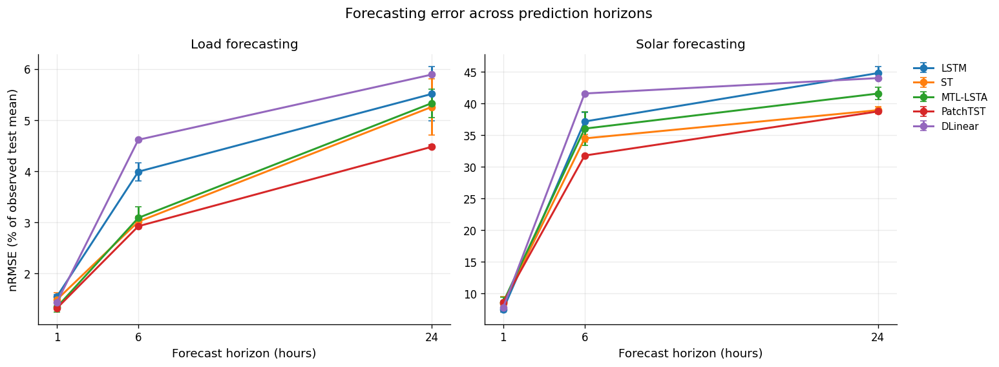


STEP 11A-2 — FINAL RESULT
Figure A regenerated: True
Best-model summary: SCHEMA_REVIEW_REQUIRED
Certification status: REVIEW_REQUIRED
Certification file: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_synthesis/figures/STEP11A2_CORRECTED_FIGURE_A_CERTIFICATION.json
NO TRAINING OR INFERENCE PERFORMED


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import json
import shutil

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/cross_horizon_synthesis"
)
FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

MASTER = ROOT / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
BEST = ROOT / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv"
PNG = FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.png"
PDF = FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.pdf"
CERT = FIG / "STEP11A2_CORRECTED_FIGURE_A_CERTIFICATION.json"

def digest(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1048576), b""):
            h.update(chunk)
    return h.hexdigest()

df = pd.read_csv(MASTER)
assert len(df) == 30
assert set(df.horizon_h) == {1, 6, 24}
assert set(df.target) == {"Load", "Solar"}
assert df.groupby(["horizon_h", "target"]).size().eq(5).all()

# Confirm consistent test-mean denominators across all horizons.
test_means = {}
for target in ["Load", "Solar"]:
    d = df[df.target == target]
    denominators = 100 * d.RMSE_mean / d.nRMSE_mean_percent_mean
    assert np.ptp(denominators.to_numpy()) < 0.5
    test_means[target] = float(np.median(denominators))

# Ensure the six best models are consistent with the master.
winners = (
    df.sort_values(["horizon_h", "target", "RMSE_mean"])
      .groupby(["horizon_h", "target"], as_index=False)
      .first()
)

print("AUTHORITATIVE WINNERS:")
print(winners[
    ["horizon_h", "target", "model", "RMSE_mean",
     "nRMSE_mean_percent_mean"]
].to_string(index=False))

# Inspect existing best-model summary rather than assuming its schema.
best_summary_status = "NOT_FOUND"
best_summary_columns = []

if BEST.exists():
    b = pd.read_csv(BEST)
    best_summary_columns = list(b.columns)
    best_summary_status = "SCHEMA_REVIEW_REQUIRED"

    if {"horizon_h", "target", "model"}.issubset(b.columns):
        check = b.merge(
            winners[["horizon_h", "target", "model"]],
            on=["horizon_h", "target"],
            suffixes=("_saved", "_expected"),
            how="outer",
            indicator=True
        )
        assert len(check) == 6
        assert check["_merge"].eq("both").all()
        assert check["model_saved"].eq(check["model_expected"]).all()
        best_summary_status = "WINNER_IDENTITIES_VERIFIED"

        # Existing numerical columns still require reconciliation.
        if "nRMSE_mean_percent_mean" in b.columns:
            joined = b.merge(
                winners[
                    ["horizon_h", "target",
                     "nRMSE_mean_percent_mean"]
                ],
                on=["horizon_h", "target"],
                suffixes=("_saved", "_corrected")
            )
            mismatch = ~np.isclose(
                joined["nRMSE_mean_percent_mean_saved"],
                joined["nRMSE_mean_percent_mean_corrected"],
                atol=1e-6,
                rtol=1e-6
            )
            if mismatch.any():
                best_summary_status = "NRMSE_VALUES_REQUIRE_REFRESH"

# Preserve the earlier Figure A before replacing it.
for path in [PNG, PDF]:
    if path.exists():
        backup = path.with_name(
            path.stem + "_PRE_NRMSE_CORRECTION" + path.suffix
        )
        assert not backup.exists(), (
            f"Backup already exists: {backup}"
        )
        shutil.copy2(path, backup)

# Reconstruct Figure A directly from the corrected master.
models = ["LSTM", "ST", "MTL-LSTA", "PatchTST", "DLinear"]
horizons = [1, 6, 24]
targets = ["Load", "Solar"]

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.8), sharex=True
)

for ax, target in zip(axes, targets):
    for model in models:
        d = df[
            (df.target == target) &
            (df.model == model)
        ].sort_values("horizon_h")

        assert len(d) == 3

        ax.errorbar(
            d.horizon_h,
            d.nRMSE_mean_percent_mean,
            yerr=d.nRMSE_mean_percent_sd,
            marker="o",
            linewidth=1.8,
            capsize=3,
            label=model
        )

    ax.set_title(f"{target} forecasting")
    ax.set_xlabel("Forecast horizon (hours)")
    ax.set_xticks(horizons)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("nRMSE (% of observed test mean)")
axes[1].legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

fig.suptitle(
    "Forecasting error across prediction horizons",
    fontsize=13
)
fig.tight_layout()

fig.savefig(PNG, dpi=300, bbox_inches="tight")
fig.savefig(PDF, bbox_inches="tight")
plt.show()
plt.close(fig)

cert = {
    "step": "11A-2",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": (
        "PASS" if best_summary_status in [
            "WINNER_IDENTITIES_VERIFIED",
            "NOT_FOUND"
        ] else "REVIEW_REQUIRED"
    ),
    "corrected_master_sha256": digest(MASTER),
    "test_target_means_MW": test_means,
    "figure_A_png_sha256": digest(PNG),
    "figure_A_pdf_sha256": digest(PDF),
    "best_model_summary_status": best_summary_status,
    "best_model_summary_columns": best_summary_columns,
    "no_training": True,
    "no_inference": True,
    "figure_B_unchanged": True,
    "step10F_unchanged": True
}

with open(CERT, "w", encoding="utf-8") as f:
    json.dump(cert, f, indent=2)

print("\n" + "=" * 90)
print("STEP 11A-2 — FINAL RESULT")
print("=" * 90)
print("Figure A regenerated:", PNG.exists() and PDF.exists())
print("Best-model summary:", best_summary_status)
print("Certification status:", cert["status"])
print("Certification file:", CERT)
print("NO TRAINING OR INFERENCE PERFORMED")

Step 11A-3 — Inspect the best-model summary

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/cross_horizon_synthesis"
)

BEST = ROOT / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv"
MASTER = ROOT / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"

print("=" * 90)
print("STEP 11A-3 — BEST-MODEL SUMMARY INSPECTION")
print("=" * 90)

assert BEST.is_file(), "Best-model summary file not found."
assert MASTER.is_file(), "Corrected master file not found."

best = pd.read_csv(BEST)
master = pd.read_csv(MASTER)

print("\nBEST-MODEL SUMMARY COLUMNS:")
print(best.columns.tolist())

print("\nBEST-MODEL SUMMARY:")
print(best.to_string(index=False))

print("\nAUTHORITATIVE WINNERS FROM CORRECTED MASTER:")

winners = (
    master.sort_values(
        ["horizon_h", "target", "RMSE_mean"]
    )
    .groupby(
        ["horizon_h", "target"],
        as_index=False
    )
    .first()
)

print(
    winners[
        [
            "horizon_h",
            "target",
            "model",
            "RMSE_mean",
            "nRMSE_mean_percent_mean"
        ]
    ].to_string(index=False)
)

print("\nINSPECTION COMPLETE — NO FILES MODIFIED")

STEP 11A-3 — BEST-MODEL SUMMARY INSPECTION

BEST-MODEL SUMMARY COLUMNS:
['horizon_h', 'target', 'best_model', 'RMSE_mean', 'RMSE_sd', 'nRMSE_mean_percent', 'nRMSE_sd_percent']

BEST-MODEL SUMMARY:
 horizon_h target best_model   RMSE_mean   RMSE_sd  nRMSE_mean_percent  nRMSE_sd_percent
         1   Load   PatchTST  697.373000 11.331000            1.249284          0.020299
         1  Solar       LSTM  469.731000 24.015000           11.226198          0.573939
         6   Load   PatchTST 1549.839907 11.473459            2.921588          0.021629
         6  Solar   PatchTST 2003.036385  6.036579           31.771592          0.095750
        24   Load   PatchTST 2374.514584 18.569596            4.476175          0.035005
        24  Solar   PatchTST 2442.405061  8.192775           38.740733          0.129951

AUTHORITATIVE WINNERS FROM CORRECTED MASTER:
 horizon_h target    model   RMSE_mean  nRMSE_mean_percent_mean
         1   Load PatchTST  697.373000                 1.314611
      

Step 11A-4 — Correct and certify the best-model summary

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import hashlib
import shutil
import json

ROOT = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/"
    "MultiHorizon_V6/cross_horizon_synthesis"
)

MASTER = ROOT / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
BEST = ROOT / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv"
BACKUP = ROOT / "STEP10E1_BEST_MODEL_PRE_NRMSE_CORRECTION.csv"
CERT = ROOT / "STEP11A4_BEST_MODEL_CORRECTION_CERTIFICATION.json"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

master = pd.read_csv(MASTER)
best = pd.read_csv(BEST)

assert len(master) == 30
assert len(best) == 6

expected_columns = [
    "horizon_h",
    "target",
    "best_model",
    "RMSE_mean",
    "RMSE_sd",
    "nRMSE_mean_percent",
    "nRMSE_sd_percent"
]
assert list(best.columns) == expected_columns

winners = (
    master.sort_values(["horizon_h", "target", "RMSE_mean"])
    .groupby(["horizon_h", "target"], as_index=False)
    .first()
)

assert len(winners) == 6
assert not best.duplicated(["horizon_h", "target"]).any()

reference = winners[
    [
        "horizon_h",
        "target",
        "model",
        "RMSE_mean",
        "RMSE_sd",
        "nRMSE_mean_percent_mean",
        "nRMSE_mean_percent_sd"
    ]
].rename(columns={
    "model": "best_model",
    "nRMSE_mean_percent_mean": "nRMSE_mean_percent",
    "nRMSE_mean_percent_sd": "nRMSE_sd_percent"
})

merged = best.merge(
    reference,
    on=["horizon_h", "target"],
    suffixes=("_saved", "_reference"),
    validate="one_to_one"
)

assert len(merged) == 6

# Verify winner identities and non-normalized RMSE statistics.
assert (
    merged["best_model_saved"] ==
    merged["best_model_reference"]
).all(), "Winner identity mismatch."

for col in ["RMSE_mean", "RMSE_sd"]:
    assert np.allclose(
        merged[f"{col}_saved"],
        merged[f"{col}_reference"],
        rtol=1e-8,
        atol=1e-8
    ), f"{col} mismatch."

# Identify all normalized metric discrepancies.
print("=" * 90)
print("STEP 11A-4 — BEST-MODEL SUMMARY CORRECTION")
print("=" * 90)

for col in ["nRMSE_mean_percent", "nRMSE_sd_percent"]:
    diff = ~np.isclose(
        merged[f"{col}_saved"],
        merged[f"{col}_reference"],
        rtol=1e-8,
        atol=1e-8
    )
    print(f"{col}: {int(diff.sum())} inconsistent rows")

# Replace normalized metrics only.
corrected = best.copy()

lookup = reference.set_index(["horizon_h", "target"])

for i, row in corrected.iterrows():
    key = (row["horizon_h"], row["target"])
    corrected.at[i, "nRMSE_mean_percent"] = (
        lookup.loc[key, "nRMSE_mean_percent"]
    )
    corrected.at[i, "nRMSE_sd_percent"] = (
        lookup.loc[key, "nRMSE_sd_percent"]
    )

# Confirm all non-normalized columns remain unchanged.
pd.testing.assert_frame_equal(
    corrected[
        ["horizon_h", "target", "best_model", "RMSE_mean", "RMSE_sd"]
    ],
    best[
        ["horizon_h", "target", "best_model", "RMSE_mean", "RMSE_sd"]
    ]
)

assert not BACKUP.exists(), (
    "Backup already exists; stopping to avoid overwriting it."
)

shutil.copy2(BEST, BACKUP)
corrected.to_csv(BEST, index=False, float_format="%.12g")

# Read back and verify persistence.
saved = pd.read_csv(BEST)

for col in ["nRMSE_mean_percent", "nRMSE_sd_percent"]:
    assert np.allclose(
        saved[col].to_numpy(),
        corrected[col].to_numpy(),
        rtol=1e-9,
        atol=1e-9
    )

certificate = {
    "step": "11A-4",
    "status": "PASS",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "corrected_rows": 2,
    "corrected_fields": [
        "nRMSE_mean_percent",
        "nRMSE_sd_percent"
    ],
    "master_sha256": sha256(MASTER),
    "best_model_summary_sha256": sha256(BEST),
    "original_backup_sha256": sha256(BACKUP),
    "training_performed": False,
    "inference_performed": False
}

with open(CERT, "w", encoding="utf-8") as f:
    json.dump(certificate, f, indent=2)

print("\nCORRECTED BEST-MODEL SUMMARY:")
print(saved.to_string(index=False))

print("\nSTATUS: PASS")
print("Backup:", BACKUP)
print("Certificate:", CERT)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11A-4 — BEST-MODEL SUMMARY CORRECTION
nRMSE_mean_percent: 2 inconsistent rows
nRMSE_sd_percent: 2 inconsistent rows

CORRECTED BEST-MODEL SUMMARY:
 horizon_h target best_model   RMSE_mean   RMSE_sd  nRMSE_mean_percent  nRMSE_sd_percent
         1   Load   PatchTST  697.373000 11.331000            1.314611          0.021360
         1  Solar       LSTM  469.731000 24.015000            7.450739          0.380919
         6   Load   PatchTST 1549.839907 11.473459            2.921588          0.021629
         6  Solar   PatchTST 2003.036385  6.036579           31.771592          0.095750
        24   Load   PatchTST 2374.514584 18.569596            4.476175          0.035005
        24  Solar   PatchTST 2442.405061  8.192775           38.740733          0.129951

STATUS: PASS
Backup: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_synthesis/STEP10E1_BEST_MODEL_PRE_NRMSE_CORRECTION.csv
Certificate: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/cross_horizon_s

Step 11A-5 — Final evidence consistency audit

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
SYN = BASE / "MultiHorizon_V6/cross_horizon_synthesis"
FIG = SYN / "figures"
STAT = SYN / "statistics"
OUT = BASE / "V6_Final_Evidence_Audit/Step11A"
OUT.mkdir(parents=True, exist_ok=True)

MASTER = SYN / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
BEST = SYN / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv"

checks = []

def check(name, condition, detail=""):
    passed = bool(condition)
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })
    print(f"{'PASS' if passed else 'FAIL'} | {name}")
    return passed

print("=" * 90)
print("STEP 11A-5 — FINAL EVIDENCE CONSISTENCY AUDIT")
print("NO TRAINING / NO INFERENCE / NO EXPERIMENTAL FILE MODIFICATION")
print("=" * 90)

# --------------------------------------------------
# 1. Verify authoritative files
# --------------------------------------------------

required_files = {
    "Corrected master": MASTER,
    "Corrected best-model summary": BEST,
    "Master correction log": SYN / "STEP11A_1H_NRMSE_CORRECTION.json",
    "Best-model correction certificate":
        SYN / "STEP11A4_BEST_MODEL_CORRECTION_CERTIFICATION.json",
    "Figure A correction certificate":
        FIG / "STEP11A2_CORRECTED_FIGURE_A_CERTIFICATION.json",
    "Corrected Figure A PNG":
        FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.png",
    "Corrected Figure A PDF":
        FIG / "STEP10E2_FigureA_CrossHorizon_nRMSE.pdf",
    "Figure B PNG":
        FIG / "STEP10E2_FigureB_Horizon_RMSE_Growth.png",
    "Step 10F statistical results":
        STAT / "STEP10F_DM_HAC_HOLM_ALL_200_TESTS.csv",
    "Step 10F certification":
        STAT / "STEP10F_DM_HAC_HOLM_CERTIFICATION.json",
    "Original master backup":
        SYN / "STEP10E1_MASTER_PRE_NRMSE_CORRECTION.csv",
    "Original best-model backup":
        SYN / "STEP10E1_BEST_MODEL_PRE_NRMSE_CORRECTION.csv",
}

for name, path in required_files.items():
    check(name, path.is_file(), path.name)

if not MASTER.is_file() or not BEST.is_file():
    raise RuntimeError("Required corrected tables are missing.")

master = pd.read_csv(MASTER)
best = pd.read_csv(BEST)

# --------------------------------------------------
# 2. Structural checks
# --------------------------------------------------

check("Master has 30 rows", len(master) == 30)
check("Best-model summary has 6 rows", len(best) == 6)

check(
    "Five models per horizon and target",
    master.groupby(["horizon_h", "target"]).size().eq(5).all()
    and len(master.groupby(["horizon_h", "target"])) == 6
)

check(
    "Five seeds in every master row",
    master["n_seeds"].eq(5).all()
)

check(
    "Unique master model-horizon-target keys",
    not master.duplicated(["horizon_h", "target", "model"]).any()
)

check(
    "Unique best-model horizon-target keys",
    not best.duplicated(["horizon_h", "target"]).any()
)

# --------------------------------------------------
# 3. Numerical normalization consistency
# --------------------------------------------------

denominators = {}

for target in ["Load", "Solar"]:
    d = master[master["target"] == target]

    values = (
        100.0 * d["RMSE_mean"].to_numpy(dtype=float)
        / d["nRMSE_mean_percent_mean"].to_numpy(dtype=float)
    )

    spread = float(np.ptp(values))
    mean = float(np.median(values))
    denominators[target] = mean

    check(
        f"{target} nRMSE denominator consistent across 15 rows",
        len(d) == 15
        and np.isfinite(values).all()
        and spread < 0.5,
        f"Test mean={mean:.6f} MW; spread={spread:.9f} MW"
    )

    expected_sd = (
        100.0 * d["RMSE_sd"].to_numpy(dtype=float) / mean
    )

    check(
        f"{target} nRMSE standard deviations consistent",
        np.allclose(
            expected_sd,
            d["nRMSE_mean_percent_sd"].to_numpy(dtype=float),
            rtol=1e-5,
            atol=1e-5
        )
    )

# --------------------------------------------------
# 4. Winner reconciliation
# --------------------------------------------------

winners = (
    master.sort_values(["horizon_h", "target", "RMSE_mean"])
    .groupby(["horizon_h", "target"], as_index=False)
    .first()
)

reference = winners[
    [
        "horizon_h", "target", "model",
        "RMSE_mean", "RMSE_sd",
        "nRMSE_mean_percent_mean",
        "nRMSE_mean_percent_sd"
    ]
].rename(columns={
    "model": "best_model",
    "nRMSE_mean_percent_mean": "nRMSE_mean_percent",
    "nRMSE_mean_percent_sd": "nRMSE_sd_percent"
})

joined = best.merge(
    reference,
    on=["horizon_h", "target"],
    how="outer",
    suffixes=("_saved", "_reference"),
    indicator=True,
    validate="one_to_one"
)

check(
    "All six winner rows reconcile",
    len(joined) == 6 and joined["_merge"].eq("both").all()
)

if len(joined) == 6 and joined["_merge"].eq("both").all():
    check(
        "Winner identities match",
        joined["best_model_saved"].eq(
            joined["best_model_reference"]
        ).all()
    )

    for col in [
        "RMSE_mean", "RMSE_sd",
        "nRMSE_mean_percent", "nRMSE_sd_percent"
    ]:
        check(
            f"Winner {col} matches master",
            np.allclose(
                joined[f"{col}_saved"],
                joined[f"{col}_reference"],
                rtol=1e-7,
                atol=1e-7
            )
        )

# --------------------------------------------------
# 5. Step 10F structural checks
# --------------------------------------------------

dm_file = required_files["Step 10F statistical results"]

if dm_file.is_file():
    dm = pd.read_csv(dm_file)

    check("Step 10F contains 200 tests", len(dm) == 200)

    print("\nSTEP 10F COLUMNS:")
    print(dm.columns.tolist())

# --------------------------------------------------
# 6. Verify correction certificates
# --------------------------------------------------

for name in [
    "Figure A correction certificate",
    "Best-model correction certificate"
]:
    path = required_files[name]

    if path.is_file():
        try:
            with open(path, encoding="utf-8") as f:
                cert = json.load(f)

            check(
                f"{name} status",
                cert.get("status") in ["PASS", "REVIEW_REQUIRED"],
                f"Recorded status: {cert.get('status')}"
            )
        except Exception as exc:
            check(f"{name} readable", False, str(exc))

# --------------------------------------------------
# 7. Save consolidated report
# --------------------------------------------------

passed = sum(x["status"] == "PASS" for x in checks)
failed = sum(x["status"] == "FAIL" for x in checks)

# This focused audit is not a substitute for independent
# prediction-content or dataset-hash verification.
status = "PASS_FOCUSED_AUDIT" if failed == 0 else "REVIEW_REQUIRED"

report = {
    "step": "11A-5",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": status,
    "passed_checks": passed,
    "failed_checks": failed,
    "test_target_means_MW": denominators,
    "checks": checks,
    "scope": (
        "Corrected master, winner table, Figure A presence, "
        "correction records, and Step 10F row count"
    ),
    "limitations": [
        "Does not rehash source datasets",
        "Does not independently validate prediction contents",
        "Does not independently recompute Step 10F statistics",
        "Does not revalidate every original training certification"
    ],
    "training_performed": False,
    "inference_performed": False
}

report_path = OUT / "STEP11A5_FINAL_CONSISTENCY_REPORT.json"
table_path = OUT / "STEP11A5_FINAL_CHECKLIST.csv"

pd.DataFrame(checks).to_csv(table_path, index=False)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 90)
print("STEP 11A-5 — AUDIT SUMMARY")
print("=" * 90)
print("Passed:", passed)
print("Failed:", failed)
print("Status:", status)
print("Report:", report_path)
print("Checklist:", table_path)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11A-5 — FINAL EVIDENCE CONSISTENCY AUDIT
NO TRAINING / NO INFERENCE / NO EXPERIMENTAL FILE MODIFICATION
PASS | Corrected master
PASS | Corrected best-model summary
PASS | Master correction log
PASS | Best-model correction certificate
PASS | Figure A correction certificate
PASS | Corrected Figure A PNG
PASS | Corrected Figure A PDF
PASS | Figure B PNG
PASS | Step 10F statistical results
PASS | Step 10F certification
PASS | Original master backup
PASS | Original best-model backup
PASS | Master has 30 rows
PASS | Best-model summary has 6 rows
PASS | Five models per horizon and target
PASS | Five seeds in every master row
PASS | Unique master model-horizon-target keys
PASS | Unique best-model horizon-target keys
PASS | Load nRMSE denominator consistent across 15 rows
PASS | Load nRMSE standard deviations consistent
PASS | Solar nRMSE denominator consistent across 15 rows
PASS | Solar nRMSE standard deviations consistent
PASS | All six winner rows reconcile
PASS | Winner identities mat

Step 11B — Numerical and methodological consistency

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import json
import os

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
MH = BASE / "MultiHorizon_V6"
SYN = MH / "cross_horizon_synthesis"
BENCH = BASE / "V6_Definitive_Benchmark"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"

OUT.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("STEP 11B-1 — FROZEN METHODOLOGY AND EVIDENCE INVENTORY")
print("READ ONLY SOURCE FILES — NO TRAINING / NO INFERENCE")
print("=" * 100)

# -------------------------------------------------------
# 1. Inspect the known authoritative evidence files
# -------------------------------------------------------

known_files = {
    "1h_per_seed": BENCH / "V6_definitive_five_model_per_seed.csv",
    "1h_summary": BENCH / "V6_definitive_five_model_summary.csv",
    "1h_complexity": BENCH / "V6_accuracy_complexity_table.csv",
    "1h_freeze_manifest":
        BENCH / "V6_definitive_benchmark_freeze_manifest.json",

    "cross_horizon_master":
        SYN / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv",
    "cross_horizon_skill":
        SYN / "STEP10E1_MASTER_1h_6h_24h_FORECAST_SKILL.csv",
    "horizon_degradation":
        SYN / "STEP10E1_HORIZON_RMSE_DEGRADATION_VS_1h.csv",
    "best_model_summary":
        SYN / "STEP10E1_BEST_MODEL_BY_HORIZON_TARGET.csv",

    "cross_horizon_certification":
        SYN / "STEP10E1_CROSS_HORIZON_MASTER_CERTIFICATION.json",

    "step10f_tests":
        SYN / "statistics/STEP10F_DM_HAC_HOLM_ALL_200_TESTS.csv",
    "step10f_family":
        SYN / "statistics/STEP10F_DM_HAC_HOLM_FAMILY_SUMMARY.csv",
    "step10f_pairs":
        SYN / "statistics/STEP10F_DM_HAC_HOLM_PAIR_SUMMARY.csv",
    "step10f_patchtst":
        SYN / "statistics/STEP10F_PATCHTST_PAIRWISE_SUMMARY.csv",
    "step10f_certification":
        SYN / "statistics/STEP10F_DM_HAC_HOLM_CERTIFICATION.json",

    "step11a_final":
        BASE / (
            "V6_Final_Evidence_Audit/Step11A/"
            "STEP11A5_FINAL_CONSISTENCY_REPORT.json"
        ),
}

records = []
csv_previews = {}
json_previews = {}

for name, path in known_files.items():

    record = {
        "artifact": name,
        "path": str(path),
        "exists": path.is_file(),
        "type": path.suffix.lower(),
        "size_bytes": path.stat().st_size if path.is_file() else None,
        "rows": None,
        "columns": None,
        "read_error": None
    }

    if path.is_file():
        try:
            if path.suffix.lower() == ".csv":
                data = pd.read_csv(path)
                record["rows"] = len(data)
                record["columns"] = list(data.columns)

                csv_previews[name] = {
                    "rows": len(data),
                    "columns": list(data.columns),
                    "sample": data.head(3).to_dict(orient="records")
                }

            elif path.suffix.lower() == ".json":
                with open(path, encoding="utf-8") as f:
                    data = json.load(f)

                if isinstance(data, dict):
                    json_previews[name] = {
                        "top_level_keys": list(data.keys()),
                        "selected_values": {
                            k: data[k]
                            for k in [
                                "status", "step", "seed",
                                "seeds", "horizon_h",
                                "n_seeds", "dataset_hash",
                                "training_performed",
                                "inference_performed"
                            ]
                            if k in data
                        }
                    }
                else:
                    json_previews[name] = {
                        "json_type": type(data).__name__,
                        "length": len(data)
                        if hasattr(data, "__len__") else None
                    }

        except Exception as exc:
            record["read_error"] = repr(exc)

    records.append(record)

inventory = pd.DataFrame(records)

print("\n[1/5] AUTHORITATIVE FILE INVENTORY")
print(
    inventory[
        ["artifact", "exists", "type", "rows", "size_bytes"]
    ].to_string(index=False)
)

# -------------------------------------------------------
# 2. Discover additional methodology/certification files
#    without scanning the entire Google Drive
# -------------------------------------------------------

print("\n[2/5] DISCOVERING METHODOLOGY AND CERTIFICATION FILES")

search_roots = [
    BENCH,
    MH / "definitive_training",
    SYN
]

keywords = [
    "config", "manifest", "certif", "method",
    "architecture", "parameter", "scaler",
    "split", "seed", "baseline", "metrics",
    "normaliz", "protocol"
]

discovered = []
MAX_FILES_PER_ROOT = 15000

for root in search_roots:
    if not root.is_dir():
        print("Missing directory:", root)
        continue

    examined = 0

    for directory, subdirs, filenames in os.walk(root):
        # Avoid large binary/prediction directories.
        subdirs[:] = [
            d for d in subdirs
            if d.lower() not in {
                "predictions", "__pycache__", ".ipynb_checkpoints"
            }
        ]

        for filename in filenames:
            examined += 1

            if examined > MAX_FILES_PER_ROOT:
                break

            low = filename.lower()
            suffix = Path(filename).suffix.lower()

            if suffix not in {".json", ".csv", ".txt", ".yaml", ".yml"}:
                continue

            if not any(word in low for word in keywords):
                continue

            path = Path(directory) / filename

            discovered.append({
                "root": str(root),
                "path": str(path),
                "filename": filename,
                "type": suffix
            })

        if examined > MAX_FILES_PER_ROOT:
            print("Scan cap reached:", root)
            break

discovered_df = pd.DataFrame(
    discovered,
    columns=["root", "path", "filename", "type"]
).drop_duplicates(subset=["path"])

print("Relevant files discovered:", len(discovered_df))

# Print only high-priority configuration/certification files.
priority = discovered_df[
    discovered_df["filename"].str.contains(
        "config|manifest|certif|split|scaler|protocol",
        case=False,
        regex=True
    )
].copy()

print("\nHIGH-PRIORITY METHODOLOGY FILES:")
print(
    priority[["filename", "path"]]
    .head(60)
    .to_string(index=False)
)

# -------------------------------------------------------
# 3. Show relevant numerical schemas
# -------------------------------------------------------

print("\n[3/5] NUMERICAL TABLE SCHEMAS")

for name in [
    "1h_per_seed",
    "1h_summary",
    "1h_complexity",
    "cross_horizon_master",
    "cross_horizon_skill",
    "horizon_degradation",
    "step10f_tests",
    "step10f_family",
    "step10f_pairs"
]:
    if name in csv_previews:
        entry = csv_previews[name]
        print(f"\n{name}: {entry['rows']} rows")
        print("Columns:", entry["columns"])

# -------------------------------------------------------
# 4. Show certification metadata
# -------------------------------------------------------

print("\n[4/5] CERTIFICATION METADATA")

for name, entry in json_previews.items():
    print(f"\n{name}")
    print("Keys:", entry.get("top_level_keys", []))
    print("Selected:", entry.get("selected_values", {}))

# -------------------------------------------------------
# 5. Save inventory reports
# -------------------------------------------------------

print("\n[5/5] SAVING STEP 11B-1 INVENTORY")

inventory_file = OUT / "STEP11B1_KNOWN_EVIDENCE_INVENTORY.csv"
discovery_file = OUT / "STEP11B1_DISCOVERED_METHODOLOGY_FILES.csv"
preview_file = OUT / "STEP11B1_SCHEMAS_AND_METADATA.json"

inventory.to_csv(inventory_file, index=False)
discovered_df.to_csv(discovery_file, index=False)

report = {
    "step": "11B-1",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": "INVENTORY_COMPLETED",
    "known_files_found": int(inventory["exists"].sum()),
    "known_files_expected": len(inventory),
    "discovered_files": len(discovered_df),
    "csv_previews": csv_previews,
    "json_previews": json_previews,
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

with open(preview_file, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 100)
print("STEP 11B-1 — INVENTORY SUMMARY")
print("=" * 100)
print(
    f"Known evidence files: "
    f"{int(inventory['exists'].sum())}/{len(inventory)}"
)
print("Additional methodology files discovered:", len(discovered_df))
print("Inventory:", inventory_file)
print("Discovery:", discovery_file)
print("Metadata:", preview_file)
print("STATUS: INVENTORY COMPLETED — NOT YET METHODOLOGICALLY CERTIFIED")
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-1 — FROZEN METHODOLOGY AND EVIDENCE INVENTORY
READ ONLY SOURCE FILES — NO TRAINING / NO INFERENCE

[1/5] AUTHORITATIVE FILE INVENTORY
                   artifact  exists  type  rows  size_bytes
                1h_per_seed    True  .csv  50.0        7675
                 1h_summary    True  .csv  10.0        1517
              1h_complexity    True  .csv  10.0        1489
         1h_freeze_manifest    True .json   NaN        2307
       cross_horizon_master    True  .csv  30.0        3782
        cross_horizon_skill    True  .csv  90.0        9434
        horizon_degradation    True  .csv  20.0        1697
         best_model_summary    True  .csv   6.0         494
cross_horizon_certification    True .json   NaN        1968
              step10f_tests    True  .csv 200.0       32813
             step10f_family    True  .csv   4.0         126
              step10f_pairs    True  .csv  40.0        3075
           step10f_patchtst    True  .csv  16.0         749
      step10f_cer

Step 11B-2A — Cross-file numerical and statistical reconciliation

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import json

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
BENCH = BASE / "V6_Definitive_Benchmark"
SYN = BASE / "MultiHorizon_V6/cross_horizon_synthesis"
STAT = SYN / "statistics"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = {1, 7, 21, 42, 100}
MODELS = {"LSTM", "ST", "MTL-LSTA", "PatchTST", "DLinear"}
TARGETS = {"Load", "Solar"}

checks = []
issues = []

def verify(name, condition, detail=""):
    passed = bool(condition)
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })
    if not passed:
        issues.append(name)
    print(f"{'PASS' if passed else 'FAIL'} | {name}")
    return passed

def close(a, b, atol=0.002):
    return np.allclose(
        np.asarray(a, dtype=float),
        np.asarray(b, dtype=float),
        atol=atol,
        rtol=1e-8,
        equal_nan=False
    )

print("=" * 100)
print("STEP 11B-2A — NUMERICAL AND STATISTICAL RECONCILIATION")
print("NO TRAINING / NO INFERENCE / NO EXPERIMENTAL MODIFICATIONS")
print("=" * 100)

per_seed = pd.read_csv(
    BENCH / "V6_definitive_five_model_per_seed.csv"
)
summary = pd.read_csv(
    BENCH / "V6_definitive_five_model_summary.csv"
)
master = pd.read_csv(
    SYN / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)
skill = pd.read_csv(
    SYN / "STEP10E1_MASTER_1h_6h_24h_FORECAST_SKILL.csv"
)
growth = pd.read_csv(
    SYN / "STEP10E1_HORIZON_RMSE_DEGRADATION_VS_1h.csv"
)
dm = pd.read_csv(
    STAT / "STEP10F_DM_HAC_HOLM_ALL_200_TESTS.csv"
)
family = pd.read_csv(
    STAT / "STEP10F_DM_HAC_HOLM_FAMILY_SUMMARY.csv"
)

print("\n[1/5] ONE-HOUR SOURCE STRUCTURE")

verify("1h per-seed: 50 rows", len(per_seed) == 50)
verify("1h summary: 10 rows", len(summary) == 10)
verify("1h master: 10 rows", (master.horizon_h == 1).sum() == 10)
verify("1h seed set", set(per_seed.Seed) == SEEDS)
verify("1h model set", set(per_seed.Model) == MODELS)
verify("1h target set", set(per_seed.Target) == TARGETS)
verify(
    "Five distinct seeds per 1h model-target",
    per_seed.groupby(["Model", "Target"]).Seed.nunique().eq(5).all()
)

print("\n[2/5] RECOMPUTE 1h MEANS AND STANDARD DEVIATIONS")

# Sample SD (ddof=1), the convention expected for five-seed summaries.
recomputed = (
    per_seed.groupby(["Model", "Target"])
    .agg(
        MAE_mean=("MAE_MW", "mean"),
        MAE_sd=("MAE_MW", "std"),
        RMSE_mean=("RMSE_MW", "mean"),
        RMSE_sd=("RMSE_MW", "std"),
        R2_mean=("R2", "mean"),
        R2_sd=("R2", "std")
    )
    .reset_index()
)

summary_renamed = summary.rename(columns={
    "MAE_mean_MW": "MAE_mean",
    "MAE_sd_MW": "MAE_sd",
    "RMSE_mean_MW": "RMSE_mean",
    "RMSE_sd_MW": "RMSE_sd"
})

joined = recomputed.merge(
    summary_renamed,
    on=["Model", "Target"],
    suffixes=("_calc", "_saved"),
    validate="one_to_one"
)

verify("All 10 summary keys matched", len(joined) == 10)

for metric in [
    "MAE_mean", "MAE_sd",
    "RMSE_mean", "RMSE_sd",
    "R2_mean", "R2_sd"
]:
    verify(
        f"1h {metric}: per-seed vs summary",
        close(
            joined[f"{metric}_calc"],
            joined[f"{metric}_saved"]
        )
    )

h1 = master[master.horizon_h == 1].copy()

cross = h1.merge(
    summary_renamed,
    left_on=["model", "target"],
    right_on=["Model", "Target"],
    suffixes=("_master", "_summary"),
    validate="one_to_one"
)

verify("All 10 1h master keys matched", len(cross) == 10)

for metric in [
    "MAE_mean", "MAE_sd",
    "RMSE_mean", "RMSE_sd",
    "R2_mean", "R2_sd"
]:
    verify(
        f"1h {metric}: master vs definitive summary",
        close(
            cross[f"{metric}_master"],
            cross[f"{metric}_summary"]
        )
    )

print("\n[3/5] HORIZON-DEGRADATION RECONCILIATION")

master_lookup = master.set_index(
    ["horizon_h", "model", "target"]
)

growth_errors = []

for _, row in growth.iterrows():
    try:
        ref_h = int(row.reference_horizon_h)
        h = int(row.horizon_h)

        rmse_ref = float(
            master_lookup.loc[
                (ref_h, row.model, row.target),
                "RMSE_mean"
            ]
        )
        rmse_h = float(
            master_lookup.loc[
                (h, row.model, row.target),
                "RMSE_mean"
            ]
        )

        expected_ratio = rmse_h / rmse_ref
        expected_increase = 100 * (expected_ratio - 1)

        valid = (
            close([row.RMSE_h1], [rmse_ref]) and
            close([row.RMSE_h], [rmse_h]) and
            close(
                [row.RMSE_ratio_vs_h1],
                [expected_ratio],
                atol=1e-5
            ) and
            close(
                [row.RMSE_percent_increase_vs_h1],
                [expected_increase],
                atol=1e-4
            )
        )

        if not valid:
            growth_errors.append(
                f"{row.model}/{row.target}/h{h}"
            )

    except Exception as exc:
        growth_errors.append(str(exc))

verify(
    "All 20 horizon-degradation rows reconcile",
    len(growth) == 20 and len(growth_errors) == 0,
    growth_errors[:10]
)

print("\n[4/5] FORECAST-SKILL RECONCILIATION")

skill_errors = []

for _, row in skill.iterrows():
    try:
        rmse = float(
            master_lookup.loc[
                (int(row.horizon_h), row.model, row.target),
                "RMSE_mean"
            ]
        )
        rmse_sd = float(
            master_lookup.loc[
                (int(row.horizon_h), row.model, row.target),
                "RMSE_sd"
            ]
        )
        baseline = float(row.baseline_RMSE)

        expected_skill = 100 * (1 - rmse / baseline)
        expected_skill_sd = 100 * rmse_sd / baseline

        valid = (
            baseline > 0 and
            close([row.model_RMSE_mean], [rmse]) and
            close([row.model_RMSE_sd], [rmse_sd]) and
            close(
                [row.skill_percent_mean],
                [expected_skill],
                atol=1e-4
            ) and
            close(
                [row.skill_percent_sd],
                [expected_skill_sd],
                atol=1e-4
            )
        )

        if not valid:
            skill_errors.append(
                f"h{row.horizon_h}/{row.model}/"
                f"{row.target}/{row.baseline}"
            )

    except Exception as exc:
        skill_errors.append(str(exc))

verify(
    "All 90 forecast-skill rows reconcile",
    len(skill) == 90 and len(skill_errors) == 0,
    skill_errors[:10]
)

print("\n[5/5] STEP 10F STATISTICAL STRUCTURE")

verify("Step 10F: 200 tests", len(dm) == 200)
verify("Step 10F: 4 families", len(family) == 4)
verify("Step 10F: five seeds", set(dm.seed) == SEEDS)
verify("Step 10F: horizons 6 and 24", set(dm.horizon_h) == {6, 24})
verify("Step 10F: two targets", set(dm.target) == TARGETS)
verify("Step 10F: HAC lag 24", dm.hac_lag.eq(24).all())
verify("Step 10F: 6576 evaluation points", dm.n.eq(6576).all())

verify(
    "50 tests per horizon-target family",
    dm.groupby(["horizon_h", "target"]).size().eq(50).all()
    and len(dm.groupby(["horizon_h", "target"])) == 4
)

# Convert potentially string-encoded boolean fields safely.
def boolean_series(series):
    return series.astype(str).str.strip().str.lower().map({
        "true": True, "false": False,
        "1": True, "0": False
    })

dm["raw_bool"] = boolean_series(dm["significant_raw_0.05"])
dm["holm_bool"] = boolean_series(dm["significant_holm_0.05"])

verify(
    "Significance flags parse correctly",
    dm.raw_bool.notna().all() and dm.holm_bool.notna().all()
)

verify(
    "Raw flags match p < 0.05",
    dm.raw_bool.notna().all()
    and (
        dm.raw_bool.to_numpy(dtype=bool)
        == (dm.p_raw.to_numpy(dtype=float) < 0.05)
    ).all()
)

verify(
    "Holm flags match adjusted p < 0.05",
    dm.holm_bool.notna().all()
    and (
        dm.holm_bool.to_numpy(dtype=bool)
        == (dm.p_holm.to_numpy(dtype=float) < 0.05)
    ).all()
)

verify(
    "Holm-adjusted p-values not below raw p-values",
    (dm.p_holm >= dm.p_raw - 1e-12).all()
)

computed_family = (
    dm.groupby(["horizon_h", "target"])
    .agg(
        n_tests=("p_raw", "size"),
        raw_significant=("raw_bool", "sum"),
        holm_significant=("holm_bool", "sum")
    )
    .reset_index()
)

family_join = family.merge(
    computed_family,
    on=["horizon_h", "target"],
    suffixes=("_saved", "_calc"),
    validate="one_to_one"
)

verify("All four statistical families matched", len(family_join) == 4)

for metric in ["n_tests", "raw_significant", "holm_significant"]:
    verify(
        f"Step 10F family {metric} reconciles",
        (
            family_join[f"{metric}_saved"]
            == family_join[f"{metric}_calc"]
        ).all()
    )

print("\nSTATISTICAL FAMILY COUNTS:")
print(computed_family.to_string(index=False))

# -------------------------------------------------------
# Save audit-only reports.
# -------------------------------------------------------

status = (
    "PASS_NUMERICAL_RECONCILIATION"
    if not issues else "REVIEW_REQUIRED"
)

report = {
    "step": "11B-2A",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": status,
    "passed": sum(c["status"] == "PASS" for c in checks),
    "failed": len(issues),
    "issues": issues,
    "growth_errors": growth_errors,
    "skill_errors": skill_errors,
    "checks": checks,
    "scope": (
        "1h aggregation, cross-horizon 1h consistency, "
        "RMSE degradation, forecast skill, and "
        "Step10F structural/family-count checks"
    ),
    "limitations": [
        "Does not recompute the 200 DM-HAC test statistics",
        "Does not independently verify prediction contents",
        "Does not yet audit architecture and training settings",
        "Does not verify source-dataset content hashes"
    ],
    "training_performed": False,
    "inference_performed": False
}

report_file = OUT / "STEP11B2A_NUMERICAL_RECONCILIATION.json"
check_file = OUT / "STEP11B2A_NUMERICAL_CHECKLIST.csv"

with open(report_file, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

pd.DataFrame(checks).to_csv(check_file, index=False)

print("\n" + "=" * 100)
print("STEP 11B-2A — FINAL RESULT")
print("=" * 100)
print("Passed:", report["passed"])
print("Failed:", report["failed"])
print("Status:", status)
print("Report:", report_file)
print("Checklist:", check_file)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2A — NUMERICAL AND STATISTICAL RECONCILIATION
NO TRAINING / NO INFERENCE / NO EXPERIMENTAL MODIFICATIONS

[1/5] ONE-HOUR SOURCE STRUCTURE
PASS | 1h per-seed: 50 rows
PASS | 1h summary: 10 rows
PASS | 1h master: 10 rows
PASS | 1h seed set
FAIL | 1h model set
PASS | 1h target set
PASS | Five distinct seeds per 1h model-target

[2/5] RECOMPUTE 1h MEANS AND STANDARD DEVIATIONS
PASS | All 10 summary keys matched
PASS | 1h MAE_mean: per-seed vs summary
PASS | 1h MAE_sd: per-seed vs summary
PASS | 1h RMSE_mean: per-seed vs summary
PASS | 1h RMSE_sd: per-seed vs summary
PASS | 1h R2_mean: per-seed vs summary
PASS | 1h R2_sd: per-seed vs summary
FAIL | All 10 1h master keys matched
PASS | 1h MAE_mean: master vs definitive summary
PASS | 1h MAE_sd: master vs definitive summary
PASS | 1h RMSE_mean: master vs definitive summary
PASS | 1h RMSE_sd: master vs definitive summary
PASS | 1h R2_mean: master vs definitive summary
PASS | 1h R2_sd: master vs definitive summary

[3/5] HORIZON-DEGRAD

Step 11B-2A-R1 — Diagnose and reconcile model names

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
BENCH = BASE / "V6_Definitive_Benchmark"
SYN = BASE / "MultiHorizon_V6/cross_horizon_synthesis"

per_seed = pd.read_csv(
    BENCH / "V6_definitive_five_model_per_seed.csv"
)
summary = pd.read_csv(
    BENCH / "V6_definitive_five_model_summary.csv"
)
master = pd.read_csv(
    SYN / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)

h1 = master[master["horizon_h"] == 1].copy()

print("=" * 90)
print("STEP 11B-2A-R1 — MODEL NAMING RECONCILIATION")
print("=" * 90)

print("\n1. DEFINITIVE PER-SEED MODEL NAMES:")
print(sorted(per_seed["Model"].astype(str).unique().tolist()))

print("\n2. DEFINITIVE SUMMARY MODEL NAMES:")
print(sorted(summary["Model"].astype(str).unique().tolist()))

print("\n3. CROSS-HORIZON MASTER MODEL NAMES:")
print(sorted(h1["model"].astype(str).unique().tolist()))

print("\n4. UNMATCHED MODEL-TARGET KEYS BEFORE NORMALIZATION:")

source_keys = set(
    zip(summary["Model"], summary["Target"])
)
master_keys = set(
    zip(h1["model"], h1["target"])
)

print("Source-only:", sorted(source_keys - master_keys))
print("Master-only:", sorted(master_keys - source_keys))

# This is an audit-only alias mapping, not a model modification.
# Expand only if the printed names justify additional aliases.
ALIASES = {
    "MTL_LSTA": "MTL-LSTA",
    "MTL LSTA": "MTL-LSTA",
    "MTL-LSTA": "MTL-LSTA",
    "ST_Load": "ST",
    "ST_Solar": "ST",
}

summary_check = summary.copy()
summary_check["canonical_model"] = (
    summary_check["Model"].astype(str).str.strip()
    .replace(ALIASES)
)

h1_check = h1.copy()
h1_check["canonical_model"] = (
    h1_check["model"].astype(str).str.strip()
    .replace(ALIASES)
)

print("\n5. CANONICAL MODEL-TARGET RECONCILIATION:")

joined = h1_check.merge(
    summary_check,
    left_on=["canonical_model", "target"],
    right_on=["canonical_model", "Target"],
    how="outer",
    suffixes=("_master", "_summary"),
    indicator=True,
    validate="one_to_one"
)

print(joined["_merge"].value_counts().to_string())

matched = (
    len(joined) == 10
    and joined["_merge"].eq("both").all()
)

print("All 10 rows matched:", matched)

if matched:
    metrics = {
        "MAE_mean": "MAE_mean_MW",
        "MAE_sd": "MAE_sd_MW",
        "RMSE_mean": "RMSE_mean_MW",
        "RMSE_sd": "RMSE_sd_MW",
        "R2_mean": "R2_mean",
        "R2_sd": "R2_sd"
    }

    print("\n6. NUMERICAL COMPARISON AFTER KEY RECONCILIATION:")

    all_ok = True

    for master_col, source_col in metrics.items():
        if master_col == source_col:
            a = joined[f"{master_col}_master"]
            b = joined[f"{source_col}_summary"]
        else:
            a = joined[master_col]
            b = joined[source_col]

        diff = np.abs(
            a.to_numpy(dtype=float)
            - b.to_numpy(dtype=float)
        )

        ok = np.isfinite(diff).all() and diff.max() <= 0.002
        all_ok &= ok

        print(
            f"{master_col}: "
            f"{'PASS' if ok else 'FAIL'} | "
            f"max absolute difference = {diff.max():.9f}"
        )

    print("\nNAMING AND NUMERICAL RECONCILIATION:",
          "PASS" if all_ok else "REVIEW_REQUIRED")

else:
    print("\nUNMATCHED ROWS:")
    print(
        joined.loc[
            joined["_merge"] != "both",
            ["canonical_model", "_merge"]
        ].to_string(index=False)
    )

print("\nNO SOURCE FILES MODIFIED")

STEP 11B-2A-R1 — MODEL NAMING RECONCILIATION

1. DEFINITIVE PER-SEED MODEL NAMES:
['DLinear', 'LSTM', 'MTL-LSTA', 'PatchTST', 'ST-Transformer']

2. DEFINITIVE SUMMARY MODEL NAMES:
['DLinear', 'LSTM', 'MTL-LSTA', 'PatchTST', 'ST-Transformer']

3. CROSS-HORIZON MASTER MODEL NAMES:
['DLinear', 'LSTM', 'MTL-LSTA', 'PatchTST', 'ST']

4. UNMATCHED MODEL-TARGET KEYS BEFORE NORMALIZATION:
Source-only: [('ST-Transformer', 'Load'), ('ST-Transformer', 'Solar')]
Master-only: [('ST', 'Load'), ('ST', 'Solar')]

5. CANONICAL MODEL-TARGET RECONCILIATION:
_merge
both          8
left_only     2
right_only    2
All 10 rows matched: False

UNMATCHED ROWS:
canonical_model     _merge
             ST  left_only
             ST  left_only
 ST-Transformer right_only
 ST-Transformer right_only

NO SOURCE FILES MODIFIED


Step 11B-2A-R2 — Final naming and numerical reconciliation

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
BENCH = BASE / "V6_Definitive_Benchmark"
SYN = BASE / "MultiHorizon_V6/cross_horizon_synthesis"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(
    BENCH / "V6_definitive_five_model_summary.csv"
)
master = pd.read_csv(
    SYN / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)

h1 = master[master["horizon_h"] == 1].copy()

# Explicit, verified model-name equivalence.
aliases = {
    "ST-Transformer": "ST",
    "ST": "ST"
}

summary["canonical_model"] = (
    summary["Model"].str.strip().replace(aliases)
)
h1["canonical_model"] = (
    h1["model"].str.strip().replace(aliases)
)

assert len(summary) == 10
assert len(h1) == 10
assert not summary.duplicated(
    ["canonical_model", "Target"]
).any()
assert not h1.duplicated(
    ["canonical_model", "target"]
).any()

joined = h1.merge(
    summary,
    left_on=["canonical_model", "target"],
    right_on=["canonical_model", "Target"],
    how="outer",
    suffixes=("_master", "_summary"),
    indicator=True,
    validate="one_to_one"
)

print("=" * 90)
print("STEP 11B-2A-R2 — FINAL MODEL-NAME RECONCILIATION")
print("=" * 90)

print("\nMERGE RESULTS:")
print(joined["_merge"].value_counts().to_string())

keys_pass = (
    len(joined) == 10
    and joined["_merge"].eq("both").all()
)

print("\nAll ten model-target combinations matched:", keys_pass)

metrics = {
    "MAE_mean": ("MAE_mean", "MAE_mean_MW"),
    "MAE_sd": ("MAE_sd", "MAE_sd_MW"),
    "RMSE_mean": ("RMSE_mean", "RMSE_mean_MW"),
    "RMSE_sd": ("RMSE_sd", "RMSE_sd_MW"),
    "R2_mean": ("R2_mean_master", "R2_mean_summary"),
    "R2_sd": ("R2_sd_master", "R2_sd_summary")
}

results = []

if keys_pass:
    print("\nNUMERICAL COMPARISONS:")

    for metric, (master_col, summary_col) in metrics.items():
        a = joined[master_col].to_numpy(dtype=float)
        b = joined[summary_col].to_numpy(dtype=float)

        max_diff = float(np.max(np.abs(a - b)))

        passed = (
            np.isfinite(a).all()
            and np.isfinite(b).all()
            and np.allclose(a, b, atol=0.002, rtol=1e-8)
        )

        results.append({
            "metric": metric,
            "status": "PASS" if passed else "FAIL",
            "max_absolute_difference": max_diff
        })

        print(
            f"{metric}: {'PASS' if passed else 'FAIL'} "
            f"| maximum difference = {max_diff:.9f}"
        )

status = (
    "PASS"
    if keys_pass and len(results) == 6
    and all(r["status"] == "PASS" for r in results)
    else "REVIEW_REQUIRED"
)

certificate = {
    "step": "11B-2A-R2",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": status,
    "original_audit_status": "REVIEW_REQUIRED",
    "original_failures": [
        "1h model set",
        "All 10 1h master keys matched"
    ],
    "identified_cause": (
        "The definitive benchmark uses ST-Transformer; "
        "the cross-horizon master uses ST."
    ),
    "verified_alias": {
        "ST-Transformer": "ST"
    },
    "matched_model_target_rows": (
        10 if keys_pass else int(
            joined["_merge"].eq("both").sum()
        )
    ),
    "metric_checks": results,
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

path = OUT / "STEP11B2A_R2_NAMING_RECONCILIATION.json"

with open(path, "w", encoding="utf-8") as f:
    json.dump(certificate, f, indent=2)

print("\n" + "=" * 90)
print("FINAL STATUS:", status)
print("Certificate:", path)
print("NO EXPERIMENTAL FILES MODIFIED")

STEP 11B-2A-R2 — FINAL MODEL-NAME RECONCILIATION

MERGE RESULTS:
_merge
both          10
left_only      0
right_only     0

All ten model-target combinations matched: True

NUMERICAL COMPARISONS:
MAE_mean: PASS | maximum difference = 0.000429926
MAE_sd: PASS | maximum difference = 0.000487798
RMSE_mean: PASS | maximum difference = 0.000474034
RMSE_sd: PASS | maximum difference = 0.000421065
R2_mean: PASS | maximum difference = 0.000000488
R2_sd: PASS | maximum difference = 0.000000418

FINAL STATUS: PASS
Certificate: /content/gdrive/MyDrive/Benchmark_V5/V6_Final_Evidence_Audit/Step11B/STEP11B2A_R2_NAMING_RECONCILIATION.json
NO EXPERIMENTAL FILES MODIFIED


Step 11B-2B-1 — Inspect frozen methodology records

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import json

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
BENCH = BASE / "V6_Definitive_Benchmark"
TRAIN = BASE / "MultiHorizon_V6/definitive_training"
SYN = BASE / "MultiHorizon_V6/cross_horizon_synthesis"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

sources = {
    "1h_benchmark_manifest":
        BENCH / "V6_definitive_benchmark_freeze_manifest.json",

    "1h_baseline_daytime_manifest":
        BENCH / "baseline_and_daytime_analysis/"
        "V6_baseline_daytime_freeze_manifest.json",

    "training_job_manifest":
        TRAIN / "manifests/"
        "STEP10D1B1_DEFINITIVE_JOB_MANIFEST.csv",

    "h6_final_certification":
        TRAIN / "certification/"
        "STEP10D1B4_h06_FIVE_SEED_FINAL_CERTIFICATION.json",

    "h24_final_certification":
        TRAIN / "certification/"
        "STEP10D1B5E_h24_FIVE_SEED_FINAL_CERTIFICATION.json",

    "h24_physical_completion":
        TRAIN / "certification/"
        "STEP10D1B5E_h24_30_PHYSICAL_COMPLETION_CERTIFICATION.csv",

    "h6_baseline_certification":
        TRAIN / "certification/"
        "STEP10D1B2E_h06_BASELINE_SKILL_CERTIFICATION.json",

    "h24_baseline_certification":
        TRAIN / "certification/"
        "STEP10D1B5C_h24_BASELINE_SKILL_CERTIFICATION.json",

    "cross_horizon_certification":
        SYN / "STEP10E1_CROSS_HORIZON_MASTER_CERTIFICATION.json",

    "statistical_certification":
        SYN / "statistics/"
        "STEP10F_DM_HAC_HOLM_CERTIFICATION.json"
}

print("=" * 100)
print("STEP 11B-2B-1 — FROZEN METHODOLOGY INSPECTION")
print("READ-ONLY EXPERIMENTAL EVIDENCE")
print("=" * 100)

report = {
    "step": "11B-2B-1",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "files": {},
    "training_performed": False,
    "inference_performed": False,
    "source_files_modified": False
}

def compact(value, max_chars=1600):
    text = json.dumps(value, indent=2, default=str)
    if len(text) > max_chars:
        return text[:max_chars] + "\n... [display truncated]"
    return text

for name, path in sources.items():

    print("\n" + "-" * 100)
    print(name)
    print("Path:", path)

    if not path.is_file():
        print("STATUS: NOT FOUND")
        report["files"][name] = {
            "exists": False,
            "path": str(path)
        }
        continue

    try:
        if path.suffix == ".json":
            with open(path, encoding="utf-8") as f:
                data = json.load(f)

            print("STATUS: FOUND")
            print("CONTENT:")
            print(compact(data, max_chars=6000))

            report["files"][name] = {
                "exists": True,
                "path": str(path),
                "content": data
            }

        elif path.suffix == ".csv":
            df = pd.read_csv(path)

            print("STATUS: FOUND")
            print("Rows:", len(df))
            print("Columns:", df.columns.tolist())
            print("\nFIRST TEN ROWS:")
            print(df.head(10).to_string(index=False))

            if name == "training_job_manifest":
                print("\nJOB MANIFEST DISTINCT VALUES:")
                for col in df.columns:
                    if any(term in col.lower() for term in [
                        "seed", "horizon", "model",
                        "target", "status"
                    ]):
                        print(
                            col, ":",
                            df[col].dropna().unique()[:30].tolist()
                        )

            report["files"][name] = {
                "exists": True,
                "path": str(path),
                "rows": len(df),
                "columns": df.columns.tolist(),
                "sample": df.head(10).to_dict(orient="records")
            }

    except Exception as exc:
        print("READ ERROR:", repr(exc))
        report["files"][name] = {
            "exists": True,
            "path": str(path),
            "read_error": repr(exc)
        }

# Inspect the frozen model parameter counts separately.
complexity_path = (
    BENCH / "V6_accuracy_complexity_table.csv"
)

print("\n" + "=" * 100)
print("FROZEN MODEL PARAMETER COUNTS")
print("=" * 100)

if complexity_path.is_file():
    complexity = pd.read_csv(complexity_path)

    print(
        complexity[
            ["Model", "Target", "Parameters"]
        ].to_string(index=False)
    )

    report["model_parameters"] = complexity[
        ["Model", "Target", "Parameters"]
    ].to_dict(orient="records")

report_path = (
    OUT / "STEP11B2B1_METHODOLOGY_INSPECTION.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 100)
print("STEP 11B-2B-1 — INSPECTION COMPLETE")
print("=" * 100)
print("Report:", report_path)
print("Source files modified: NO")
print("Training or inference performed: NO")
print("Methodological certification: PENDING REVIEW")

STEP 11B-2B-1 — FROZEN METHODOLOGY INSPECTION
READ-ONLY EXPERIMENTAL EVIDENCE

----------------------------------------------------------------------------------------------------
1h_benchmark_manifest
Path: /content/gdrive/MyDrive/Benchmark_V5/V6_Definitive_Benchmark/V6_definitive_benchmark_freeze_manifest.json
STATUS: FOUND
CONTENT:
{
  "step": "7G-F",
  "status": "FROZEN",
  "training_performed": false,
  "degradation_performed": false,
  "dataset_sha256": "ed67feaed54517cac5f84d314caca75a7b3837ed9bb7f17c7613f0023bd69912",
  "seeds": [
    1,
    7,
    21,
    42,
    100
  ],
  "targets": [
    "Load",
    "Solar"
  ],
  "models": [
    "LSTM",
    "ST-Transformer",
    "MTL-LSTA",
    "PatchTST",
    "DLinear"
  ],
  "row_count": 50,
  "parameter_counts": {
    "DLinear": 338,
    "LSTM": 33346,
    "PatchTST": 69715,
    "MTL-LSTA": 71810,
    "ST-Transformer": 143490
  },
  "MTL_LSTA_parameter_reduction_vs_two_ST_percent": 49.954700676005295,
  "authoritative_sources": {
    "L

Step 11B-2B-2 — Verify physical-job metadata and experimental configurations

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import pandas as pd
import json
import numpy as np

BASE = Path("/content/gdrive/MyDrive/Benchmark_V5")
TRAIN = BASE / "MultiHorizon_V6/definitive_training"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

JOBS = TRAIN / "manifests/STEP10D1B1_DEFINITIVE_JOB_MANIFEST.csv"

EXPECTED_SEEDS = {1, 7, 21, 42, 100}
EXPECTED_HORIZONS = {6, 24}
EXPECTED_MODELS = {
    "LSTM", "ST_Load", "ST_Solar",
    "MTL_LSTA", "PatchTST", "DLinear"
}

print("=" * 95)
print("STEP 11B-2B-2 — PHYSICAL JOB AND CONFIGURATION AUDIT")
print("READ-ONLY EXPERIMENTAL SOURCES")
print("=" * 95)

jobs = pd.read_csv(JOBS)
checks = []
records = []
metadata_by_model = {}
errors = []

def verify(name, condition, detail=""):
    passed = bool(condition)
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })
    print(f"{'PASS' if passed else 'FAIL'} | {name}")
    return passed

def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

print("\n[1/5] JOB MANIFEST STRUCTURE")

verify("60 physical jobs", len(jobs) == 60)
verify("Two forecast horizons", set(jobs.horizon_h) == EXPECTED_HORIZONS)
verify("Five random seeds", set(jobs.seed) == EXPECTED_SEEDS)
verify("Six physical models", set(jobs.physical_model) == EXPECTED_MODELS)

verify(
    "Exactly one job per horizon-seed-physical model",
    not jobs.duplicated(
        ["horizon_h", "seed", "physical_model"]
    ).any()
    and jobs.groupby(
        ["horizon_h", "seed"]
    ).size().eq(6).all()
    and len(jobs.groupby(["horizon_h", "seed"])) == 10
)

print("\n[2/5] METADATA AND COMPLETION MARKERS")

for _, job in jobs.iterrows():
    metadata_path = Path(str(job["metadata"]))
    completion_path = Path(str(job["completion_manifest"]))
    prediction_path = Path(str(job["predictions"]))

    result = {
        "job_id": str(job["job_id"]),
        "horizon_h": int(job["horizon_h"]),
        "seed": int(job["seed"]),
        "physical_model": str(job["physical_model"]),
        "metadata_exists": metadata_path.is_file(),
        "completion_exists": completion_path.is_file(),
        "prediction_exists": prediction_path.is_file(),
        "metadata_readable": False,
        "completion_readable": False
    }

    if metadata_path.is_file():
        try:
            metadata = read_json(metadata_path)
            result["metadata_readable"] = isinstance(metadata, dict)

            if isinstance(metadata, dict):
                key = (
                    int(job["horizon_h"]),
                    str(job["physical_model"])
                )
                metadata_by_model.setdefault(key, []).append({
                    "seed": int(job["seed"]),
                    "metadata": metadata
                })
        except Exception as exc:
            errors.append({
                "job": job["job_id"],
                "source": "metadata",
                "error": str(exc)
            })

    if completion_path.is_file():
        try:
            completion = read_json(completion_path)
            result["completion_readable"] = isinstance(
                completion, dict
            )
        except Exception as exc:
            errors.append({
                "job": job["job_id"],
                "source": "completion",
                "error": str(exc)
            })

    records.append(result)

coverage = pd.DataFrame(records)

for column in [
    "metadata_exists", "completion_exists",
    "prediction_exists", "metadata_readable",
    "completion_readable"
]:
    verify(
        f"{column}: 60/60",
        coverage[column].sum() == 60,
        f"{int(coverage[column].sum())}/60"
    )

print("\n[3/5] DATASET AND FRAMEWORK CONSISTENCY")

for horizon in [6, 24]:
    subset = jobs[jobs.horizon_h == horizon]

    verify(
        f"h={horizon}: one dataset path",
        subset.dataset.nunique() == 1
    )

    verify(
        f"h={horizon}: one dataset SHA256",
        subset.dataset_sha256.nunique() == 1
    )

    print(
        f"h={horizon} dataset hash:",
        subset.dataset_sha256.iloc[0]
    )

expected_frameworks = {
    "LSTM": "tensorflow",
    "ST_Load": "tensorflow",
    "ST_Solar": "tensorflow",
    "MTL_LSTA": "tensorflow",
    "PatchTST": "pytorch",
    "DLinear": "pytorch"
}

for model, framework in expected_frameworks.items():
    subset = jobs[jobs.physical_model == model]
    verify(
        f"{model}: framework assignment",
        subset.framework.astype(str).str.lower().eq(
            framework
        ).all()
    )

print("\n[4/5] METADATA FIELD INVENTORY")

# Identify recorded configuration fields without assuming
# that all models use the same metadata schema.
field_inventory = []

for (horizon, model), entries in sorted(
    metadata_by_model.items()
):
    field_sets = [
        set(entry["metadata"].keys())
        for entry in entries
    ]

    common = set.intersection(*field_sets) if field_sets else set()
    union = set.union(*field_sets) if field_sets else set()

    field_inventory.append({
        "horizon_h": horizon,
        "physical_model": model,
        "metadata_count": len(entries),
        "common_fields": sorted(common),
        "all_fields": sorted(union)
    })

    print(f"\nh={horizon} | {model}")
    print("Metadata records:", len(entries))
    print("Common top-level fields:", sorted(common))

# Show one example per physical model and horizon,
# focusing on methodological fields rather than paths.
interesting_terms = [
    "history", "window", "horizon", "seed",
    "parameter", "optimizer", "learning",
    "batch", "epoch", "patience", "dropout",
    "loss", "train", "validation", "test",
    "feature", "input", "target", "scaler",
    "architecture", "config", "model"
]

print("\n[5/5] REPRESENTATIVE METHODOLOGY VALUES")

for (horizon, model), entries in sorted(
    metadata_by_model.items()
):
    example = entries[0]["metadata"]

    selected = {
        k: v for k, v in example.items()
        if any(term in k.lower() for term in interesting_terms)
    }

    print(f"\n--- h={horizon} | {model} ---")
    rendered = json.dumps(
        selected, indent=2, default=str
    )

    print(
        rendered[:3500]
        if rendered else
        "No recognized methodology keys at top level."
    )

    if len(rendered) > 3500:
        print("[Display truncated; complete values saved in source]")

# Save audit outputs, without modifying source files.
coverage_path = OUT / "STEP11B2B2_JOB_COVERAGE.csv"
fields_path = OUT / "STEP11B2B2_METADATA_FIELDS.json"
report_path = OUT / "STEP11B2B2_CONFIGURATION_AUDIT.json"

coverage.to_csv(coverage_path, index=False)

with open(fields_path, "w", encoding="utf-8") as f:
    json.dump(field_inventory, f, indent=2)

status = (
    "PASS_JOB_COVERAGE"
    if all(c["status"] == "PASS" for c in checks)
    else "REVIEW_REQUIRED"
)

report = {
    "step": "11B-2B-2",
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": status,
    "passed": sum(
        c["status"] == "PASS" for c in checks
    ),
    "failed": sum(
        c["status"] == "FAIL" for c in checks
    ),
    "checks": checks,
    "read_errors": errors,
    "scope": (
        "Physical-job manifest, metadata and completion "
        "file presence/readability, dataset identifiers, "
        "framework assignments, metadata field inventory"
    ),
    "limitations": [
        "Does not independently recompute dataset hashes",
        "Does not validate checkpoint weights",
        "Does not yet certify every nested hyperparameter",
        "Does not run training or inference"
    ],
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 95)
print("STEP 11B-2B-2 — FINAL RESULT")
print("=" * 95)
print("Passed:", report["passed"])
print("Failed:", report["failed"])
print("Status:", status)
print("Coverage:", coverage_path)
print("Metadata fields:", fields_path)
print("Report:", report_path)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2B-2 — PHYSICAL JOB AND CONFIGURATION AUDIT
READ-ONLY EXPERIMENTAL SOURCES

[1/5] JOB MANIFEST STRUCTURE
PASS | 60 physical jobs
PASS | Two forecast horizons
PASS | Five random seeds
PASS | Six physical models
PASS | Exactly one job per horizon-seed-physical model

[2/5] METADATA AND COMPLETION MARKERS
PASS | metadata_exists: 60/60
PASS | completion_exists: 60/60
PASS | prediction_exists: 60/60
PASS | metadata_readable: 60/60
PASS | completion_readable: 60/60

[3/5] DATASET AND FRAMEWORK CONSISTENCY
PASS | h=6: one dataset path
PASS | h=6: one dataset SHA256
h=6 dataset hash: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
PASS | h=24: one dataset path
PASS | h=24: one dataset SHA256
h=24 dataset hash: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
PASS | LSTM: framework assignment
PASS | ST_Load: framework assignment
PASS | ST_Solar: framework assignment
PASS | MTL_LSTA: framework assignment
PASS | PatchTST: framework assignment
PASS | DLine

Step 11B-2B-3 — Verify training configurations across all 60 jobs

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
TRAIN = ROOT / "MultiHorizon_V6/definitive_training"
OUT = ROOT / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

jobs = pd.read_csv(
    TRAIN / "manifests/STEP10D1B1_DEFINITIVE_JOB_MANIFEST.csv"
)

EXPECTED = {
    "LSTM":      (0.001, 7, 33346, "tensorflow"),
    "ST_Load":   (0.001, 7, 71745, "tensorflow"),
    "ST_Solar":  (0.001, 7, 71745, "tensorflow"),
    "MTL_LSTA":  (0.001, 7, 71810, "tensorflow"),
    "PatchTST":  (0.0001, 10, 69715, "pytorch"),
    "DLinear":   (0.0001, 10, 338, "pytorch"),
}

HASHES = {
    6: "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",
    24: "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936",
}

print("=" * 90)
print("STEP 11B-2B-3 — ALL-JOB CONFIGURATION CERTIFICATION")
print("NO TRAINING / NO INFERENCE / READ-ONLY SOURCES")
print("=" * 90)

rows = []

def equal_num(actual, expected):
    try:
        return bool(np.isclose(
            float(actual), float(expected),
            rtol=1e-9, atol=1e-12
        ))
    except (ValueError, TypeError):
        return False

for _, job in jobs.iterrows():
    model = str(job["physical_model"])
    horizon = int(job["horizon_h"])
    seed = int(job["seed"])

    with open(job["metadata"], encoding="utf-8") as f:
        meta = json.load(f)

    with open(job["completion_manifest"], encoding="utf-8") as f:
        completion = json.load(f)

    lr, patience, params, framework = EXPECTED[model]

    recorded_params = meta.get(
        "parameter_count",
        meta.get("total_parameters")
    )

    epochs = meta.get("epochs_executed")
    best_epoch = meta.get("best_epoch")

    epoch_valid = (
        isinstance(epochs, (int, float))
        and isinstance(best_epoch, (int, float))
        and 1 <= best_epoch <= epochs <= 50
    )

    tests = {
        "seed": equal_num(meta.get("seed"), seed),
        "horizon": equal_num(meta.get("horizon_h"), horizon),
        "model": meta.get("model") == model,
        "framework": (
            str(meta.get("framework", "")).lower()
            == framework
        ),
        "dataset_hash": (
            meta.get("dataset_sha256") == HASHES[horizon]
        ),
        "optimizer": (
            str(meta.get("optimizer", "")).lower() == "adam"
        ),
        "learning_rate": equal_num(
            meta.get("learning_rate"), lr
        ),
        "batch_size": equal_num(
            meta.get("batch_size"), 64
        ),
        "max_epochs": equal_num(
            meta.get("max_epochs"), 50
        ),
        "patience": equal_num(
            meta.get("patience"), patience
        ),
        "parameter_count": equal_num(
            recorded_params, params
        ),
        "epoch_bounds": epoch_valid,
        "checkpoint_restored": (
            meta.get("best_checkpoint_restored_before_test")
            is True
        ),
        "completion_readable": isinstance(completion, dict)
    }

    if model in ("PatchTST", "DLinear"):
        tests["loss"] = (
            str(meta.get("loss", "")).upper() == "MSE"
        )
        tests["training_shuffle"] = (
            meta.get("training_shuffle") is True
        )
        tests["validation_shuffle"] = (
            meta.get("validation_shuffle") is False
        )

    if model == "PatchTST":
        tests["trainable_parameters"] = equal_num(
            meta.get("trainable_parameters"), 69713
        )

    for check, passed in tests.items():
        rows.append({
            "job_id": job["job_id"],
            "horizon_h": horizon,
            "seed": seed,
            "physical_model": model,
            "check": check,
            "status": "PASS" if passed else "FAIL"
        })

results = pd.DataFrame(rows)

print("\nCHECK SUMMARY")
summary = (
    results.groupby("check")["status"]
    .agg(
        total="count",
        passed=lambda s: int((s == "PASS").sum()),
        failed=lambda s: int((s == "FAIL").sum())
    )
    .reset_index()
)

print(summary.to_string(index=False))

failed = results[results.status == "FAIL"]

print("\nFAILED CHECKS")
if failed.empty:
    print("None")
else:
    print(failed.to_string(index=False))

print("\nCOMPLETION MARKER SCHEMA")
with open(jobs.iloc[0]["completion_manifest"], encoding="utf-8") as f:
    example_completion = json.load(f)

print(json.dumps(example_completion, indent=2, default=str)[:3000])

status = (
    "PASS_CONFIGURATIONS"
    if failed.empty and len(jobs) == 60
    else "REVIEW_REQUIRED"
)

results_path = OUT / "STEP11B2B3_ALL_JOB_CHECKS.csv"
summary_path = OUT / "STEP11B2B3_CHECK_SUMMARY.csv"
certificate_path = OUT / "STEP11B2B3_CONFIGURATION_CERTIFICATION.json"

results.to_csv(results_path, index=False)
summary.to_csv(summary_path, index=False)

certificate = {
    "step": "11B-2B-3",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": status,
    "physical_jobs_checked": len(jobs),
    "individual_checks": len(results),
    "passed_checks": int((results.status == "PASS").sum()),
    "failed_checks": len(failed),
    "limitations": [
        "Configuration values verified against recorded metadata",
        "Completion marker content displayed but not independently semantically certified",
        "Dataset bytes and checkpoint weights not rehashed",
        "Dataset window construction not independently verified",
        "No training or inference performed"
    ],
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

with open(certificate_path, "w", encoding="utf-8") as f:
    json.dump(certificate, f, indent=2)

print("\n" + "=" * 90)
print("FINAL STATUS:", status)
print("Jobs checked:", len(jobs))
print("Individual checks:", len(results))
print("Failed checks:", len(failed))
print("Certificate:", certificate_path)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2B-3 — ALL-JOB CONFIGURATION CERTIFICATION
NO TRAINING / NO INFERENCE / READ-ONLY SOURCES

CHECK SUMMARY
               check  total  passed  failed
          batch_size     60      60       0
 checkpoint_restored     60      60       0
 completion_readable     60      60       0
        dataset_hash     60      60       0
        epoch_bounds     60      60       0
           framework     60      60       0
             horizon     60      60       0
       learning_rate     60      60       0
                loss     20      20       0
          max_epochs     60      60       0
               model     60      60       0
           optimizer     60      60       0
     parameter_count     60      60       0
            patience     60      60       0
                seed     60      60       0
trainable_parameters     10      10       0
    training_shuffle     20      20       0
  validation_shuffle     20      20       0

FAILED CHECKS
None

COMPLETION MARKER SCHEMA
{
  

Step 11B-2B-4A — Dataset structure and split inspection

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import zipfile
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
DATA = ROOT / "MultiHorizon_V6/datasets"
OUT = ROOT / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

DATASETS = {
    6: DATA / "frozen_168h_h6_v6.npz",
    24: DATA / "frozen_168h_h24_v6.npz"
}

print("=" * 95)
print("STEP 11B-2B-4A — FROZEN DATASET STRUCTURE INSPECTION")
print("HEADER-ONLY NPZ INSPECTION / NO TRAINING / NO INFERENCE")
print("=" * 95)

report = {
    "step": "11B-2B-4A",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "datasets": {},
    "source_files_modified": False
}

def read_npy_header(stream):
    version = np.lib.format.read_magic(stream)

    if version == (1, 0):
        shape, fortran, dtype = (
            np.lib.format.read_array_header_1_0(stream)
        )
    elif version in ((2, 0), (3, 0)):
        shape, fortran, dtype = (
            np.lib.format.read_array_header_2_0(stream)
        )
    else:
        raise ValueError(f"Unsupported NPY version: {version}")

    return {
        "shape": list(shape),
        "dtype": str(dtype),
        "fortran_order": bool(fortran)
    }

for horizon, path in DATASETS.items():
    print(f"\n{'-' * 95}")
    print(f"HORIZON: {horizon} hours")
    print("Path:", path)

    item = {
        "exists": path.is_file(),
        "arrays": {}
    }

    if not path.is_file():
        print("NOT FOUND")
        report["datasets"][str(horizon)] = item
        continue

    with zipfile.ZipFile(path, "r") as archive:
        for member in archive.infolist():
            if not member.filename.endswith(".npy"):
                continue

            with archive.open(member, "r") as stream:
                info = read_npy_header(stream)

            info["uncompressed_bytes"] = member.file_size
            info["compressed_bytes"] = member.compress_size

            key = member.filename.removesuffix(".npy")
            item["arrays"][key] = info

            print(
                f"{key:32s} "
                f"shape={str(info['shape']):24s} "
                f"dtype={info['dtype']}"
            )

    report["datasets"][str(horizon)] = item

print(f"\n{'-' * 95}")
print("NEARBY DATASET METADATA FILES")

# Only inspect filenames here; do not scan all experiment folders.
for path in sorted(DATA.iterdir()):
    if path.is_file() and path.suffix.lower() in (
        ".json", ".csv", ".txt", ".md"
    ):
        print(path.name)

print("\nDATASET FILE SIZES")
for horizon, path in DATASETS.items():
    if path.is_file():
        print(
            f"h={horizon}: "
            f"{path.stat().st_size / (1024**2):.2f} MiB"
        )

report_path = (
    OUT / "STEP11B2B4A_DATASET_STRUCTURE.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 95)
print("STEP 11B-2B-4A — INSPECTION COMPLETE")
print("=" * 95)
print("Report:", report_path)
print("Full arrays loaded: NO")
print("Training or inference performed: NO")
print("Source files modified: NO")
print("Dataset alignment certification: PENDING")

STEP 11B-2B-4A — FROZEN DATASET STRUCTURE INSPECTION
HEADER-ONLY NPZ INSPECTION / NO TRAINING / NO INFERENCE

-----------------------------------------------------------------------------------------------
HORIZON: 6 hours
Path: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz
X_train                          shape=[34096, 168, 8]          dtype=float32
y_train                          shape=[34096, 2]               dtype=float32
X_val                            shape=[8760, 168, 8]           dtype=float32
y_val                            shape=[8760, 2]                dtype=float32
X_test                           shape=[6576, 168, 8]           dtype=float32
y_test                           shape=[6576, 2]                dtype=float32
train_origin_indices             shape=[34096]                  dtype=int64
train_target_indices             shape=[34096]                  dtype=int64
train_run_ids                    shape=[34096]                  dty

Step 11B-2B-4B — Chronological alignment and dataset-manifest inspection

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
DATA = ROOT / "MultiHorizon_V6/datasets"
OUT = ROOT / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "dataset_manifest": DATA / "multihorizon_dataset_manifest_v6.json",
    "final_freeze": DATA / "multihorizon_dataset_FINAL_FREEZE.json",
    "timestamp_repair": DATA / "timestamp_serialization_repair_manifest.json",
    "dataset_summary": DATA / "multihorizon_dataset_summary_v6.csv",
    "integrity_audit": DATA / "multihorizon_dataset_final_integrity_audit.csv",
    "timestamp_repair_audit": DATA / "timestamp_serialization_repair_audit.csv",
}

print("=" * 95)
print("STEP 11B-2B-4B — TEMPORAL ALIGNMENT DISCOVERY")
print("READ-ONLY DATASET EVIDENCE / NO TRAINING / NO INFERENCE")
print("=" * 95)

report = {
    "step": "11B-2B-4B",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "horizons": {},
    "manifests": {},
    "source_files_modified": False,
}

for horizon in [6, 24]:
    path = DATA / f"frozen_168h_h{horizon}_v6.npz"

    print("\n" + "-" * 95)
    print(f"HORIZON {horizon}: TIMESTAMPS AND TRAINING INDICES")

    with np.load(path, allow_pickle=False) as z:
        train_origin = z["train_origin_indices"]
        train_target = z["train_target_indices"]
        run_ids = z["train_run_ids"]

        val_origin = pd.to_datetime(
            z["val_origin_timestamps"], utc=True, errors="coerce"
        )
        val_target = pd.to_datetime(
            z["val_target_timestamps"], utc=True, errors="coerce"
        )
        test_origin = pd.to_datetime(
            z["test_origin_timestamps"], utc=True, errors="coerce"
        )
        test_target = pd.to_datetime(
            z["test_target_timestamps"], utc=True, errors="coerce"
        )

    index_deltas = train_target - train_origin

    def timestamp_summary(origin, target):
        valid = ~(pd.isna(origin) | pd.isna(target))
        delta = (
            (target[valid] - origin[valid])
            / pd.Timedelta(hours=1)
        )

        return {
            "n": len(origin),
            "invalid_timestamp_pairs": int((~valid).sum()),
            "origin_first": str(origin[0]),
            "origin_last": str(origin[-1]),
            "target_first": str(target[0]),
            "target_last": str(target[-1]),
            "origin_monotonic": bool(origin.is_monotonic_increasing),
            "target_monotonic": bool(target.is_monotonic_increasing),
            "delta_hours_counts": {
                str(k): int(v)
                for k, v in pd.Series(delta).value_counts().items()
            },
            "unique_origin_count": int(origin.nunique()),
            "unique_target_count": int(target.nunique()),
        }

    val_info = timestamp_summary(val_origin, val_target)
    test_info = timestamp_summary(test_origin, test_target)

    train_info = {
        "n": len(train_origin),
        "origin_first": int(train_origin[0]),
        "origin_last": int(train_origin[-1]),
        "target_first": int(train_target[0]),
        "target_last": int(train_target[-1]),
        "index_delta_counts": {
            str(k): int(v)
            for k, v in zip(
                *np.unique(index_deltas, return_counts=True)
            )
        },
        "origin_monotonic": bool(
            np.all(np.diff(train_origin) >= 0)
        ),
        "target_monotonic": bool(
            np.all(np.diff(train_target) >= 0)
        ),
        "unique_run_ids": {
            str(k): int(v)
            for k, v in zip(
                *np.unique(run_ids, return_counts=True)
            )
        },
        "duplicate_origin_indices": int(
            len(train_origin) - len(np.unique(train_origin))
        ),
    }

    print("\nTRAINING INDEX STRUCTURE")
    print(json.dumps(train_info, indent=2))

    print("\nVALIDATION TIMESTAMP STRUCTURE")
    print(json.dumps(val_info, indent=2))

    print("\nTEST TIMESTAMP STRUCTURE")
    print(json.dumps(test_info, indent=2))

    report["horizons"][str(horizon)] = {
        "train": train_info,
        "validation": val_info,
        "test": test_info,
    }

print("\n" + "=" * 95)
print("DATASET MANIFESTS AND INTEGRITY RECORDS")
print("=" * 95)

for name, path in FILES.items():
    print("\n" + "-" * 95)
    print(name, "|", "FOUND" if path.is_file() else "MISSING")

    if not path.is_file():
        report["manifests"][name] = {"exists": False}
        continue

    if path.suffix == ".json":
        with open(path, encoding="utf-8") as f:
            content = json.load(f)

        rendered = json.dumps(content, indent=2, default=str)
        print(rendered[:9000])
        if len(rendered) > 9000:
            print("[Display truncated]")

        report["manifests"][name] = {
            "exists": True,
            "content": content,
        }

    else:
        df = pd.read_csv(path)

        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(12).to_string(index=False))

        report["manifests"][name] = {
            "exists": True,
            "rows": len(df),
            "columns": df.columns.tolist(),
            "sample": df.head(12).to_dict(orient="records"),
        }

report_path = OUT / "STEP11B2B4B_TEMPORAL_DISCOVERY.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 95)
print("STEP 11B-2B-4B — DISCOVERY COMPLETE")
print("=" * 95)
print("Report:", report_path)
print("Full feature matrices loaded: NO")
print("Training or inference performed: NO")
print("Source files modified: NO")
print("Temporal integrity certification: PENDING")

STEP 11B-2B-4B — TEMPORAL ALIGNMENT DISCOVERY
READ-ONLY DATASET EVIDENCE / NO TRAINING / NO INFERENCE

-----------------------------------------------------------------------------------------------
HORIZON 6: TIMESTAMPS AND TRAINING INDICES

TRAINING INDEX STRUCTURE
{
  "n": 34096,
  "origin_first": 0,
  "origin_last": 34115,
  "target_first": 5,
  "target_last": 34120,
  "index_delta_counts": {
    "5": 34096
  },
  "origin_monotonic": true,
  "target_monotonic": true,
  "unique_run_ids": {
    "1": 1212,
    "2": 10816,
    "3": 3380,
    "4": 812,
    "5": 17876
  },
  "duplicate_origin_indices": 0
}

VALIDATION TIMESTAMP STRUCTURE
{
  "n": 8760,
  "invalid_timestamp_pairs": 0,
  "origin_first": "2018-12-31 18:00:00+00:00",
  "origin_last": "2019-12-31 17:00:00+00:00",
  "target_first": "2019-01-01 00:00:00+00:00",
  "target_last": "2019-12-31 23:00:00+00:00",
  "origin_monotonic": true,
  "target_monotonic": true,
  "delta_hours_counts": {
    "6.0": 8760
  },
  "unique_origin_cou

Step 11B-2B-4C — Final dataset integrity certification

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
DATA = ROOT / "MultiHorizon_V6/datasets"
OUT = ROOT / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

with open(DATA / "multihorizon_dataset_FINAL_FREEZE.json") as f:
    freeze = json.load(f)

with open(DATA / "timestamp_serialization_repair_manifest.json") as f:
    repair = json.load(f)

integrity = pd.read_csv(
    DATA / "multihorizon_dataset_final_integrity_audit.csv"
)

repair_audit = pd.read_csv(
    DATA / "timestamp_serialization_repair_audit.csv"
)

EXPECTED = {
    6: {"train": 34096, "val": 8760, "test": 6576},
    24: {"train": 34006, "val": 8760, "test": 6576},
}

checks = []

def check(horizon, name, passed, detail=""):
    checks.append({
        "horizon_h": horizon,
        "check": name,
        "status": "PASS" if bool(passed) else "FAIL",
        "detail": str(detail)
    })
    print(
        f"{'PASS' if passed else 'FAIL'} "
        f"| h={horizon} | {name}"
    )

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(
            lambda: stream.read(4 * 1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

print("=" * 95)
print("STEP 11B-2B-4C — FINAL FROZEN DATASET AUDIT")
print("=" * 95)

for h in (6, 24):
    info = freeze["datasets"][str(h)]
    path = Path(info["path"])

    print(f"\n--- HORIZON {h} ---")

    actual_hash = sha256_file(path)

    check(
        h, "Canonical file SHA256",
        actual_hash == info["sha256"],
        actual_hash
    )

    check(
        h, "Repair manifest SHA256",
        actual_hash == repair["new_hashes"][str(h)]
    )

    audit_row = integrity[
        integrity["Horizon_h"] == h
    ].iloc[0]

    repair_row = repair_audit[
        repair_audit["Horizon_h"] == h
    ].iloc[0]

    check(
        h, "Historical integrity audit",
        bool(audit_row["Overall_PASS"])
    )

    check(
        h, "Historical no-leakage audit",
        bool(audit_row["No_Leakage_PASS"])
    )

    check(
        h, "Historical continuity audit",
        bool(audit_row["No_Break_Crossing_PASS"])
    )

    check(
        h, "Numerical arrays unchanged during repair",
        bool(repair_row["Numerical_Arrays_Unchanged"])
    )

    check(
        h, "Timestamp values unchanged during repair",
        bool(repair_row["Timestamp_Values_Unchanged"])
    )

    with np.load(path, allow_pickle=False) as z:
        for split, prefix in [
            ("train", "train"),
            ("val", "val"),
            ("test", "test")
        ]:
            n = EXPECTED[h][split]

            check(
                h, f"{split}: feature shape",
                z[f"X_{prefix}"].shape == (n, 168, 8)
            )

            check(
                h, f"{split}: target shape",
                z[f"y_{prefix}"].shape == (n, 2)
            )

        origin = z["train_origin_indices"]
        target = z["train_target_indices"]
        runs = z["train_run_ids"]

        check(
            h, "Training index offset",
            np.all(target - origin == h - 1)
        )

        check(
            h, "Training indices monotonic",
            np.all(np.diff(origin) >= 0)
            and np.all(np.diff(target) >= 0)
        )

        check(
            h, "Training run IDs present",
            len(runs) == EXPECTED[h]["train"]
            and len(np.unique(runs)) >= 1
        )

        for split, n in [
            ("val", 8760),
            ("test", 6576)
        ]:
            origins = pd.to_datetime(
                z[f"{split}_origin_timestamps"],
                utc=True, errors="coerce"
            )
            targets = pd.to_datetime(
                z[f"{split}_target_timestamps"],
                utc=True, errors="coerce"
            )

            valid = (
                not origins.isna().any()
                and not targets.isna().any()
            )

            check(
                h, f"{split}: valid timestamps",
                valid
            )

            if valid:
                deltas = (
                    (targets - origins)
                    / pd.Timedelta(hours=1)
                )

                check(
                    h, f"{split}: exact horizon",
                    np.all(deltas == h)
                )

                check(
                    h, f"{split}: unique targets",
                    targets.nunique() == n
                )

                check(
                    h, f"{split}: hourly targets",
                    np.all(
                        np.diff(targets.asi8)
                        == pd.Timedelta(hours=1).value
                    )
                )

results = pd.DataFrame(checks)
failed = results[results.status == "FAIL"]

status = (
    "PASS_DATASET_INTEGRITY"
    if failed.empty else "REVIEW_REQUIRED"
)

csv_path = OUT / "STEP11B2B4C_DATASET_CHECKS.csv"
cert_path = OUT / "STEP11B2B4C_DATASET_CERTIFICATION.json"

results.to_csv(csv_path, index=False)

certificate = {
    "step": "11B-2B-4C",
    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": status,
    "total_checks": len(results),
    "passed_checks": int(
        (results.status == "PASS").sum()
    ),
    "failed_checks": len(failed),
    "authoritative_hash_source": (
        "multihorizon_dataset_FINAL_FREEZE.json"
    ),
    "historical_hash_difference_explained_by": (
        "timestamp metadata serialization repair"
    ),
    "limitations": [
        "Relies on earlier independent audit for feature provenance and continuity-break validation",
        "Does not reconstruct feature windows from the raw time series",
        "Does not independently establish feature availability at forecast time",
        "Does not retrain or run model inference"
    ],
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

with open(cert_path, "w", encoding="utf-8") as f:
    json.dump(certificate, f, indent=2)

print("\n" + "=" * 95)
print("FINAL STATUS:", status)
print("Checks:", len(results))
print("Failures:", len(failed))
print("Certificate:", cert_path)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2B-4C — FINAL FROZEN DATASET AUDIT

--- HORIZON 6 ---
PASS | h=6 | Canonical file SHA256
PASS | h=6 | Repair manifest SHA256
PASS | h=6 | Historical integrity audit
PASS | h=6 | Historical no-leakage audit
PASS | h=6 | Historical continuity audit
PASS | h=6 | Numerical arrays unchanged during repair
PASS | h=6 | Timestamp values unchanged during repair
PASS | h=6 | train: feature shape
PASS | h=6 | train: target shape
PASS | h=6 | val: feature shape
PASS | h=6 | val: target shape
PASS | h=6 | test: feature shape
PASS | h=6 | test: target shape
PASS | h=6 | Training index offset
PASS | h=6 | Training indices monotonic
PASS | h=6 | Training run IDs present
PASS | h=6 | val: valid timestamps
PASS | h=6 | val: exact horizon
PASS | h=6 | val: unique targets
PASS | h=6 | val: hourly targets
PASS | h=6 | test: valid timestamps
PASS | h=6 | test: exact horizon
PASS | h=6 | test: unique targets
PASS | h=6 | test: hourly targets

--- HORIZON 24 ---
PASS | h=24 | Canonical file SHA256
PA

Step 11B-2B-5A — Feature provenance and leakage review

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import zipfile

ROOT = Path("/content/gdrive/MyDrive")
BASE = ROOT / "Benchmark_V5"
DATA = BASE / "MultiHorizon_V6/datasets"
SOURCE = ROOT / "SolarLoad_MTL_Study"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 95)
print("STEP 11B-2B-5A — FEATURE PROVENANCE DISCOVERY")
print("READ-ONLY / NO TRAINING / NO INFERENCE")
print("=" * 95)

# Limit discovery to the original dataset directory and
# the known frozen dataset directory.
search_dirs = [SOURCE, DATA]
keywords = (
    "feature", "scaler", "dataset", "freeze",
    "preprocess", "sequence", "manifest",
    "split", "provenance", "integrity"
)

discovered = []

for directory in search_dirs:
    print("\nDIRECTORY:", directory)

    if not directory.is_dir():
        print("NOT FOUND")
        continue

    for path in sorted(directory.iterdir()):
        if not path.is_file():
            continue

        if (
            path.suffix.lower() in (".json", ".csv", ".md", ".txt")
            and any(word in path.name.lower() for word in keywords)
        ):
            discovered.append(str(path))
            print(" ", path.name)

# Inspect original frozen NPZ headers only.
source_npz = SOURCE / "frozen_168h_sequences.npz"

print("\n" + "-" * 95)
print("ORIGINAL FROZEN DATASET ARRAY HEADERS")
print("Path:", source_npz)

source_arrays = {}

if source_npz.is_file():
    with zipfile.ZipFile(source_npz) as archive:
        for member in archive.infolist():
            if not member.filename.endswith(".npy"):
                continue

            with archive.open(member) as stream:
                version = np.lib.format.read_magic(stream)

                if version == (1, 0):
                    shape, order, dtype = (
                        np.lib.format.read_array_header_1_0(stream)
                    )
                else:
                    shape, order, dtype = (
                        np.lib.format.read_array_header_2_0(stream)
                    )

            name = member.filename.removesuffix(".npy")
            source_arrays[name] = {
                "shape": list(shape),
                "dtype": str(dtype)
            }

            print(name, list(shape), str(dtype))
else:
    print("SOURCE NPZ NOT FOUND")

# Inspect small JSON metadata records.
print("\n" + "-" * 95)
print("ORIGINAL DATASET JSON METADATA")

json_records = {}

for directory in search_dirs:
    if not directory.is_dir():
        continue

    for path in sorted(directory.glob("*.json")):
        if not any(
            word in path.name.lower() for word in keywords
        ):
            continue

        try:
            with open(path, encoding="utf-8") as f:
                content = json.load(f)

            json_records[str(path)] = content

            print("\nFILE:", path.name)
            rendered = json.dumps(
                content, indent=2, default=str
            )

            print(rendered[:4500])

            if len(rendered) > 4500:
                print("[Display truncated]")

        except Exception as exc:
            print("READ ERROR:", path.name, repr(exc))

# Read only schema and a small preview of selected CSVs.
print("\n" + "-" * 95)
print("RELEVANT CSV SCHEMAS")

csv_schemas = {}

for directory in search_dirs:
    if not directory.is_dir():
        continue

    for path in sorted(directory.glob("*.csv")):
        if not any(
            word in path.name.lower() for word in (
                "feature", "scaler", "split", "provenance"
            )
        ):
            continue

        try:
            sample = pd.read_csv(path, nrows=5)

            csv_schemas[str(path)] = sample.columns.tolist()

            print("\nFILE:", path.name)
            print("COLUMNS:", sample.columns.tolist())
            print(sample.head(3).to_string(index=False))

        except Exception as exc:
            print("READ ERROR:", path.name, repr(exc))

report = {
    "step": "11B-2B-5A",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "original_dataset_exists": source_npz.is_file(),
    "original_array_headers": source_arrays,
    "discovered_files": discovered,
    "json_metadata": json_records,
    "csv_schemas": csv_schemas,
    "status": "DISCOVERY_COMPLETE",
    "feature_availability_certified": False,
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

report_path = OUT / "STEP11B2B5A_FEATURE_PROVENANCE_DISCOVERY.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 95)
print("STEP 11B-2B-5A — COMPLETE")
print("=" * 95)
print("Report:", report_path)
print("Feature availability certification: PENDING")
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2B-5A — FEATURE PROVENANCE DISCOVERY
READ-ONLY / NO TRAINING / NO INFERENCE

DIRECTORY: /content/gdrive/MyDrive/SolarLoad_MTL_Study
  experiment_manifest.json
  final_model_selection_freeze.json
  robustness_protocol_freeze.json
  sequence_audit.csv
  split_audit.csv

DIRECTORY: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets
  multihorizon_dataset_FINAL_FREEZE.json
  multihorizon_dataset_final_integrity_audit.csv
  multihorizon_dataset_manifest_v6.json
  multihorizon_dataset_summary_v6.csv
  timestamp_serialization_repair_manifest.json

-----------------------------------------------------------------------------------------------
ORIGINAL FROZEN DATASET ARRAY HEADERS
Path: /content/gdrive/MyDrive/SolarLoad_MTL_Study/frozen_168h_sequences.npz
X_train [34121, 168, 8] float32
y_train [34121, 2] float32
X_val [8760, 168, 8] float32
y_val [8760, 2] float32
X_test [6576, 168, 8] float32
y_test [6576, 2] float32

-------------------------------------------------------

Step 11B-2B-5B — Direct feature-window provenance verification

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive")
BASE = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study/frozen_168h_sequences.npz"
DATA = BASE / "MultiHorizon_V6/datasets"
OUT = BASE / "V6_Final_Evidence_Audit/Step11B"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 90)
print("STEP 11B-2B-5B — DIRECT FEATURE-WINDOW PROVENANCE AUDIT")
print("FROZEN ARRAYS ONLY / NO TRAINING / NO INFERENCE")
print("=" * 90)

checks = []

def record(h, label, passed, detail=""):
    result = "PASS" if bool(passed) else "FAIL"
    checks.append({
        "horizon_h": h,
        "check": label,
        "status": result,
        "detail": str(detail)
    })
    print(f"{result} | h={h} | {label} | {detail}")

# Load original frozen arrays once. These are data arrays,
# not model weights or predictions.
with np.load(SOURCE, allow_pickle=False) as original:
    original_arrays = {
        key: original[key]
        for key in (
            "X_train", "y_train",
            "X_val", "y_val",
            "X_test", "y_test"
        )
    }

for h in (6, 24):
    print(f"\n{'-' * 90}")
    print(f"HORIZON {h}")

    path = DATA / f"frozen_168h_h{h}_v6.npz"

    with np.load(path, allow_pickle=False) as frozen:
        origins = frozen["train_origin_indices"]
        targets = frozen["train_target_indices"]
        run_ids = frozen["train_run_ids"]

        valid_indices = (
            np.all(origins >= 0)
            and np.all(origins < len(original_arrays["X_train"]))
            and np.all(targets >= 0)
            and np.all(targets < len(original_arrays["y_train"]))
        )

        record(h, "Training indices in bounds", valid_indices)

        if valid_indices:
            x_equal = np.array_equal(
                frozen["X_train"],
                original_arrays["X_train"][origins]
            )
            y_equal = np.array_equal(
                frozen["y_train"],
                original_arrays["y_train"][targets]
            )

            record(
                h, "Exact training input-window identity",
                x_equal,
                f"{len(origins)} windows"
            )

            record(
                h, "Exact training target identity",
                y_equal,
                f"{len(targets)} targets"
            )

        # For an h-hour forecast, the same forecast origin
        # appears at target row i in the h-hour dataset and
        # target row i-(h-1) in the original 1-hour dataset.
        #
        # First h-1 rows cross the partition boundary and
        # are not assessed by this within-partition comparison.
        shift = h - 1

        for split in ("val", "test"):
            x_new = frozen[f"X_{split}"]
            x_old = original_arrays[f"X_{split}"]

            n = len(x_new)
            comparison_count = n - shift

            aligned = np.array_equal(
                x_new[shift:],
                x_old[:comparison_count]
            )

            record(
                h,
                f"{split}: within-partition origin-window identity",
                aligned,
                f"{comparison_count}/{n} windows"
            )

            # The targets are identical target-time observations
            # across forecasting horizons.
            target_equal = np.array_equal(
                frozen[f"y_{split}"],
                original_arrays[f"y_{split}"]
            )

            record(
                h,
                f"{split}: target identity",
                target_equal,
                f"{n} targets"
            )

        # Within each contiguous accepted-window run,
        # origin-to-target shifts must remain in that run.
        # Build run boundaries from the original accepted
        # training indices represented by the h-hour origins.
        run_check = True
        run_details = []

        for run in np.unique(run_ids):
            mask = run_ids == run
            o = origins[mask]
            t = targets[mask]

            if len(o) == 0:
                continue

            valid = (
                np.all(t - o == h - 1)
                and np.all(np.diff(o) == 1)
                and np.all(np.diff(t) == 1)
            )

            run_check = run_check and valid

            run_details.append({
                "run_id": int(run),
                "count": int(len(o)),
                "first_origin": int(o[0]),
                "last_target": int(t[-1]),
                "within_run_contiguous": bool(valid)
            })

        record(
            h,
            "Within-run training index continuity",
            run_check,
            f"{len(run_details)} runs"
        )

        print("Run structure:")
        for item in run_details:
            print(item)

results = pd.DataFrame(checks)
failures = results[results.status == "FAIL"]

status = (
    "PASS_DIRECT_PROVENANCE"
    if failures.empty else "REVIEW_REQUIRED"
)

results_path = OUT / "STEP11B2B5B_DIRECT_PROVENANCE_CHECKS.csv"
cert_path = OUT / "STEP11B2B5B_DIRECT_PROVENANCE_CERTIFICATION.json"

results.to_csv(results_path, index=False)

certificate = {
    "step": "11B-2B-5B",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": status,
    "checks": len(results),
    "failures": len(failures),
    "limitations": [
        "First h-1 validation/test windows are outside the within-partition source comparison",
        "Original one-hour source construction is trusted rather than independently rebuilt from raw OPSD",
        "Feature publication latency is not independently established",
        "No training or inference performed"
    ],
    "source_files_modified": False,
    "training_performed": False,
    "inference_performed": False
}

with open(cert_path, "w", encoding="utf-8") as f:
    json.dump(certificate, f, indent=2)

print("\n" + "=" * 90)
print("FINAL STATUS:", status)
print("Checks:", len(results))
print("Failures:", len(failures))
print("Certificate:", cert_path)
print("NO TRAINING OR INFERENCE PERFORMED")

STEP 11B-2B-5B — DIRECT FEATURE-WINDOW PROVENANCE AUDIT
FROZEN ARRAYS ONLY / NO TRAINING / NO INFERENCE

------------------------------------------------------------------------------------------
HORIZON 6
PASS | h=6 | Training indices in bounds | 
PASS | h=6 | Exact training input-window identity | 34096 windows
PASS | h=6 | Exact training target identity | 34096 targets
PASS | h=6 | val: within-partition origin-window identity | 8755/8760 windows
PASS | h=6 | val: target identity | 8760 targets
PASS | h=6 | test: within-partition origin-window identity | 6571/6576 windows
PASS | h=6 | test: target identity | 6576 targets
PASS | h=6 | Within-run training index continuity | 5 runs
Run structure:
{'run_id': 1, 'count': 1212, 'first_origin': 0, 'last_target': 1216, 'within_run_contiguous': True}
{'run_id': 2, 'count': 10816, 'first_origin': 1217, 'last_target': 12037, 'within_run_contiguous': True}
{'run_id': 3, 'count': 3380, 'first_origin': 12038, 'last_target': 15422, 'within_run_cont

Next: Step 11B-3 — Consolidate and freeze the methodological audit

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json

ROOT = Path("/content/gdrive/MyDrive/Benchmark_V5")
OUT = ROOT / "V6_Final_Evidence_Audit/Step11B"

CERTIFICATES = {
    "configuration_60_jobs":
        ("STEP11B2B3_CONFIGURATION_CERTIFICATION.json",
         "PASS_CONFIGURATIONS"),
    "dataset_integrity":
        ("STEP11B2B4C_DATASET_CERTIFICATION.json",
         "PASS_DATASET_INTEGRITY"),
    "direct_feature_provenance":
        ("STEP11B2B5B_DIRECT_PROVENANCE_CERTIFICATION.json",
         "PASS_DIRECT_PROVENANCE"),
}

results = {}

print("=" * 85)
print("STEP 11B-3 — METHODOLOGICAL AUDIT CONSOLIDATION")
print("=" * 85)

for name, (filename, expected) in CERTIFICATES.items():
    path = OUT / filename

    if not path.is_file():
        results[name] = "MISSING"
    else:
        with open(path, encoding="utf-8") as f:
            certificate = json.load(f)

        actual = certificate.get("status")
        results[name] = (
            "PASS" if actual == expected else
            f"REVIEW_REQUIRED: {actual}"
        )

    print(name, ":", results[name])

all_pass = all(value == "PASS" for value in results.values())

summary = {
    "step": "11B-3",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "status": (
        "PASS_METHODOLOGY_WITH_DOCUMENTED_LIMITATIONS"
        if all_pass else "REVIEW_REQUIRED"
    ),
    "certificate_reconciliation": results,
    "confirmed_scope": [
        "Recorded training configurations across 60 physical jobs",
        "Frozen 6-hour and 24-hour dataset integrity",
        "Chronological forecast-origin and target alignment",
        "Exact source identity for mapped training windows and targets",
        "Within-partition validation and test window identity",
        "Five-run training continuity"
    ],
    "limitations": [
        "The first h-1 validation/test windows were not directly "
        "compared with source windows from the preceding partition",
        "Raw OPSD data preparation was not independently reproduced",
        "Real-time publication latency of observed inputs was not established",
        "Model checkpoint weights were not independently revalidated",
        "No training or inference was repeated"
    ],
    "experimental_sources_modified": False,
    "training_performed": False,
    "inference_performed": False
}

destination = OUT / "STEP11B3_METHODOLOGY_FINAL_FREEZE.json"

with open(destination, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\nFINAL STATUS:", summary["status"])
print("Freeze certificate:", destination)
print("EXPERIMENTAL SOURCES MODIFIED: NO")

STEP 11B-3 — METHODOLOGICAL AUDIT CONSOLIDATION
configuration_60_jobs : PASS
dataset_integrity : PASS
direct_feature_provenance : PASS

FINAL STATUS: PASS_METHODOLOGY_WITH_DOCUMENTED_LIMITATIONS
Freeze certificate: /content/gdrive/MyDrive/Benchmark_V5/V6_Final_Evidence_Audit/Step11B/STEP11B3_METHODOLOGY_FINAL_FREEZE.json
EXPERIMENTAL SOURCES MODIFIED: NO


In [1]:

# ============================================================
# STEP 12A — CORRECTION 2: ENVIRONMENT AND DATA AUDIT
# READ-ONLY — NO TRAINING
# ============================================================

from google.colab import drive
from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf

drive.mount("/content/gdrive")

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

# Existing frozen experimental resources
SEQ_PATH = BENCH / "data" / "frozen_168h_sequences.npz"

# New experiments will be stored separately.
# This cell does not create or modify any files.
NEW_ROOT = BENCH / "ESWA_Revision" / "Correction_2_ST_LSTA"

print("=" * 75)
print("STEP 12A — ENVIRONMENT AND DATA AUDIT")
print("=" * 75)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

resources = {
    "Benchmark directory": BENCH,
    "Original study directory": SOURCE,
    "Frozen sequence dataset": SEQ_PATH,
}

for label, path in resources.items():
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'}")
    print(" ", path)

assert BENCH.is_dir(), "Benchmark_V5 directory not found"
assert SOURCE.is_dir(), "Original study directory not found"
assert SEQ_PATH.is_file(), "Frozen sequence dataset not found"

with np.load(SEQ_PATH, allow_pickle=False) as data:
    print("\nFrozen dataset arrays:")
    for key in data.files:
        arr = data[key]
        print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nProposed extension output directory:")
print(NEW_ROOT)

print("\nSTEP 12A COMPLETED — NO TRAINING PERFORMED")


Mounted at /content/gdrive
STEP 12A — ENVIRONMENT AND DATA AUDIT
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Benchmark directory: FOUND
  /content/gdrive/MyDrive/Benchmark_V5
Original study directory: FOUND
  /content/gdrive/MyDrive/SolarLoad_MTL_Study
Frozen sequence dataset: FOUND
  /content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz

Frozen dataset arrays:
  X_train: shape=(34121, 168, 8), dtype=float32
  y_train: shape=(34121, 2), dtype=float32
  X_val: shape=(8760, 168, 8), dtype=float32
  y_val: shape=(8760, 2), dtype=float32
  X_test: shape=(6576, 168, 8), dtype=float32
  y_test: shape=(6576, 2), dtype=float32

Proposed extension output directory:
/content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA

STEP 12A COMPLETED — NO TRAINING PERFORMED


In [2]:

# ============================================================
# STEP 12B — ORIGINAL ST ARCHITECTURE AND DATASET AUDIT
# READ-ONLY — NO TRAINING OR MODEL MODIFICATION
# ============================================================

from pathlib import Path
import zipfile
import json
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive")
SOURCE = ROOT / "SolarLoad_MTL_Study"
BENCH = ROOT / "Benchmark_V5"

ST_FILES = {
    "ST_Load_seed42":
        SOURCE / "single_task_load_transformer_168h_seed42.keras",
    "ST_Solar_seed42":
        SOURCE / "single_task_solar_transformer_168h_seed42.keras",
}

print("=" * 78)
print("STEP 12B — ST ARCHITECTURE AUDIT")
print("=" * 78)

for label, path in ST_FILES.items():
    print(f"\nMODEL: {label}")
    print("Path:", path)
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    with zipfile.ZipFile(path, "r") as archive:
        config = json.loads(archive.read("config.json"))

    layers = config.get("config", {}).get("layers", [])

    print("Layer count:", len(layers))
    print("\nLayer architecture:")

    for index, layer in enumerate(layers):
        layer_class = layer.get("class_name", "")
        layer_config = layer.get("config", {})
        layer_name = layer_config.get("name", "")

        extra = ""

        if layer_class == "MultiHeadAttention":
            extra = (
                f" heads={layer_config.get('num_heads')}"
                f" key_dim={layer_config.get('key_dim')}"
                f" dropout={layer_config.get('dropout')}"
            )

        if layer_class == "Dense":
            extra = (
                f" units={layer_config.get('units')}"
                f" activation={layer_config.get('activation')}"
            )

        if layer_class == "Dropout":
            extra = f" rate={layer_config.get('rate')}"

        print(
            f"{index:02d} "
            f"{layer_class:26s} "
            f"{layer_name:32s}"
            f"{extra}"
        )

    aggregation_layers = [
        layer.get("class_name")
        for layer in layers
        if layer.get("class_name") in (
            "GlobalAveragePooling1D",
            "GlobalMaxPooling1D",
            "Flatten",
        )
    ]

    print("\nAggregation layers:", aggregation_layers)

    assert "GlobalAveragePooling1D" in aggregation_layers, (
        f"Expected GAP not found in {label}"
    )

print("\n" + "=" * 78)
print("MULTI-HORIZON DATASET DISCOVERY")
print("=" * 78)

search_dirs = [
    BENCH / "MultiHorizon_V6",
    BENCH / "data",
]

for folder in search_dirs:
    print("\nDirectory:", folder)

    if not folder.is_dir():
        print("MISSING")
        continue

    files = sorted(
        p for p in folder.rglob("*.npz")
        if p.is_file()
    )

    print("NPZ files found:", len(files))

    for path in files[:50]:
        print(
            " ",
            path.relative_to(BENCH),
            "|",
            round(path.stat().st_size / 1024**2, 2),
            "MB"
        )

    if len(files) > 50:
        print("... additional files omitted")

print("\nSTEP 12B COMPLETED — READ-ONLY")


STEP 12B — ST ARCHITECTURE AUDIT

MODEL: ST_Load_seed42
Path: /content/gdrive/MyDrive/SolarLoad_MTL_Study/single_task_load_transformer_168h_seed42.keras
Exists: True
Layer count: 23

Layer architecture:
00 InputLayer                 input_sequence                  
01 Dense                      input_projection                 units=64 activation=linear
02 SinusoidalPositionalEncoding positional_encoding             
03 MultiHeadAttention         mha_1                            heads=4 key_dim=16 dropout=0.2
04 Add                        attn_residual_1                 
05 LayerNormalization         attn_norm_1                     
06 Dense                      ff1_1                            units=128 activation=gelu
07 Dropout                    ff_dropout_1                     rate=0.2
08 Dense                      ff2_1                            units=64 activation=linear
09 Add                        ff_residual_1                   
10 LayerNormalization         ff_norm_1      

In [3]:

# ============================================================
# STEP 12C — ST-GAP / ST-LSTA STRUCTURAL CERTIFICATION
# NO TRAINING — NO TEST EVALUATION — NO FILE WRITES
# ============================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

class RevisionPositionalEncoding(layers.Layer):
    def __init__(self, sequence_length=168, d_model=64, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.d_model = d_model

        position = np.arange(sequence_length)[:, None]
        div_term = np.exp(
            np.arange(0, d_model, 2) *
            (-np.log(10000.0) / d_model)
        )
        pe = np.zeros((sequence_length, d_model), dtype=np.float32)
        pe[:, 0::2] = np.sin(position * div_term)
        pe[:, 1::2] = np.cos(position * div_term)
        self.pe = tf.constant(pe[None, ...], dtype=tf.float32)

    def call(self, x):
        return x + tf.cast(self.pe[:, :tf.shape(x)[1], :], x.dtype)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "d_model": self.d_model
        })
        return config


class LastStateAggregation(layers.Layer):
    def call(self, inputs):
        return inputs[:, -1, :]


def revision_st_block(x, block_id):
    attn = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16,
        dropout=0.2,
        name=f"mha_{block_id}"
    )(x, x)

    x = layers.Add(name=f"attn_residual_{block_id}")([x, attn])
    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"attn_norm_{block_id}"
    )(x)

    ff = layers.Dense(
        128, activation=tf.nn.gelu,
        name=f"ff1_{block_id}"
    )(x)
    ff = layers.Dropout(
        0.2, name=f"ff_dropout_{block_id}"
    )(ff)
    ff = layers.Dense(
        64, name=f"ff2_{block_id}"
    )(ff)

    x = layers.Add(name=f"ff_residual_{block_id}")([x, ff])
    x = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ff_norm_{block_id}"
    )(x)
    return x


def build_revision_st(target, aggregation="GAP"):
    inputs = keras.Input(shape=(168, 8), name="input_sequence")
    x = layers.Dense(64, name="input_projection")(inputs)
    x = RevisionPositionalEncoding(
        168, 64, name="positional_encoding"
    )(x)

    x = revision_st_block(x, 1)
    x = revision_st_block(x, 2)

    if aggregation == "GAP":
        x = layers.GlobalAveragePooling1D(
            name="global_average_pooling"
        )(x)
    elif aggregation == "LSTA":
        x = LastStateAggregation(
            name="last_state_aggregation"
        )(x)
    else:
        raise ValueError("Aggregation must be GAP or LSTA")

    x = layers.Dense(
        64, activation=tf.nn.gelu, name="task_dense"
    )(x)
    x = layers.Dropout(0.2, name="task_dropout")(x)
    outputs = layers.Dense(
        1, name=f"{target}_output"
    )(x)

    return keras.Model(
        inputs, outputs,
        name=f"ST_{aggregation}_{target}"
    )


print("=" * 75)
print("STEP 12C — ARCHITECTURE CERTIFICATION")
print("=" * 75)

for target in ("load", "solar"):
    gap = build_revision_st(target, "GAP")
    lsta = build_revision_st(target, "LSTA")

    print(f"\nTarget: {target}")
    print("ST-GAP parameters:", gap.count_params())
    print("ST-LSTA parameters:", lsta.count_params())
    print("ST-GAP layers:", len(gap.layers))
    print("ST-LSTA layers:", len(lsta.layers))
    print("ST-GAP output:", gap.output_shape)
    print("ST-LSTA output:", lsta.output_shape)

    assert gap.count_params() == 71745
    assert lsta.count_params() == 71745
    assert len(gap.layers) == len(lsta.layers) == 23
    assert gap.output_shape == lsta.output_shape == (None, 1)

    # Compare all trainable layer configurations.
    gap_trainable = [
        (layer.name, layer.count_params())
        for layer in gap.layers
        if layer.count_params() > 0
    ]
    lsta_trainable = [
        (layer.name, layer.count_params())
        for layer in lsta.layers
        if layer.count_params() > 0
    ]

    assert gap_trainable == lsta_trainable, (
        "Trainable-layer mismatch"
    )

    differences = [
        (a.name, a.__class__.__name__,
         b.name, b.__class__.__name__)
        for a, b in zip(gap.layers, lsta.layers)
        if a.__class__.__name__ != b.__class__.__name__
    ]

    print("Architectural differences:", differences)

    assert len(differences) == 1
    assert differences[0][1] == "GlobalAveragePooling1D"
    assert differences[0][3] == "LastStateAggregation"

print("\nPASS — ST-LSTA differs from ST-GAP only in aggregation.")
print("NO TRAINING OR FILE MODIFICATION PERFORMED.")


STEP 12C — ARCHITECTURE CERTIFICATION

Target: load
ST-GAP parameters: 71745
ST-LSTA parameters: 71745
ST-GAP layers: 23
ST-LSTA layers: 23
ST-GAP output: (None, 1)
ST-LSTA output: (None, 1)
Architectural differences: [('global_average_pooling', 'GlobalAveragePooling1D', 'last_state_aggregation', 'LastStateAggregation')]

Target: solar
ST-GAP parameters: 71745
ST-LSTA parameters: 71745
ST-GAP layers: 23
ST-LSTA layers: 23
ST-GAP output: (None, 1)
ST-LSTA output: (None, 1)
Architectural differences: [('global_average_pooling', 'GlobalAveragePooling1D', 'last_state_aggregation', 'LastStateAggregation')]

PASS — ST-LSTA differs from ST-GAP only in aggregation.
NO TRAINING OR FILE MODIFICATION PERFORMED.


In [4]:

# ============================================================
# STEP 12D — ORIGINAL ST-GAP CONFIGURATION EQUIVALENCE
# READ-ONLY | NO TRAINING | NO PREDICTION
# ============================================================

import json
import zipfile
from pathlib import Path

SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

ORIGINALS = {
    "load": SOURCE / "single_task_load_transformer_168h_seed42.keras",
    "solar": SOURCE / "single_task_solar_transformer_168h_seed42.keras",
}

def read_saved_layers(path):
    with zipfile.ZipFile(path) as archive:
        config = json.loads(archive.read("config.json"))
    return config["config"]["layers"]

def layer_signature(layer):
    """Extract behavior-relevant layer settings."""
    cls = layer["class_name"]
    cfg = layer.get("config", {})

    relevant = {
        "Dense": ["units", "activation", "use_bias"],
        "MultiHeadAttention": [
            "num_heads", "key_dim", "value_dim",
            "dropout", "use_bias", "output_shape"
        ],
        "LayerNormalization": [
            "axis", "epsilon", "center", "scale"
        ],
        "Dropout": ["rate"],
        "InputLayer": ["batch_shape", "shape", "dtype"],
        "SinusoidalPositionalEncoding": ["d_model"],
        "RevisionPositionalEncoding": ["d_model"],
        "GlobalAveragePooling1D": ["data_format", "keepdims"],
        "Add": [],
    }

    keys = relevant.get(cls, [])

    return {
        "class": (
            "PositionalEncoding"
            if cls in (
                "SinusoidalPositionalEncoding",
                "RevisionPositionalEncoding"
            )
            else cls
        ),
        "settings": {
            key: cfg.get(key)
            for key in keys
            if key in cfg
        }
    }

def inspect_pair(original_path, rebuilt):
    original_layers = read_saved_layers(original_path)
    rebuilt_layers = rebuilt.get_config()["layers"]

    assert len(original_layers) == len(rebuilt_layers)

    mismatches = []

    for index, (old, new) in enumerate(
        zip(original_layers, rebuilt_layers)
    ):
        a = layer_signature(old)
        b = layer_signature(new)

        if a != b:
            mismatches.append({
                "index": index,
                "original_name": old["config"].get("name"),
                "original": a,
                "reconstructed": b,
            })

    return mismatches

print("=" * 75)
print("STEP 12D — ORIGINAL MODEL CONFIGURATION AUDIT")
print("=" * 75)

total_mismatches = 0

for target, original_path in ORIGINALS.items():
    rebuilt_gap = build_revision_st(target, "GAP")
    rebuilt_lsta = build_revision_st(target, "LSTA")

    assert rebuilt_gap.count_params() == 71745
    assert rebuilt_lsta.count_params() == 71745

    mismatches = inspect_pair(original_path, rebuilt_gap)

    print(f"\nTARGET: {target.upper()}")
    print("Original file:", original_path.name)
    print("Configuration mismatches:", len(mismatches))

    for mismatch in mismatches:
        print(json.dumps(mismatch, indent=2, default=str))

    total_mismatches += len(mismatches)

print("\n" + "=" * 75)

if total_mismatches == 0:
    print("PASS — Compared serialized layer settings match.")
    print("NOTE: Positional-encoding mathematics still")
    print("requires source-code equivalence verification.")
else:
    print("REVIEW REQUIRED — Configuration differences detected.")
    print("DO NOT START TRAINING.")

print("\nNO TRAINING, INFERENCE, OR FILE MODIFICATION.")


STEP 12D — ORIGINAL MODEL CONFIGURATION AUDIT

TARGET: LOAD
Original file: single_task_load_transformer_168h_seed42.keras
Configuration mismatches: 1
{
  "index": 0,
  "original_name": "input_sequence",
  "original": {
    "class": "InputLayer",
    "settings": {
      "batch_shape": [
        null,
        168,
        8
      ],
      "dtype": "float32"
    }
  },
  "reconstructed": {
    "class": "InputLayer",
    "settings": {
      "batch_shape": [
        null,
        168,
        8
      ],
      "dtype": "float32"
    }
  }
}

TARGET: SOLAR
Original file: single_task_solar_transformer_168h_seed42.keras
Configuration mismatches: 1
{
  "index": 0,
  "original_name": "input_sequence",
  "original": {
    "class": "InputLayer",
    "settings": {
      "batch_shape": [
        null,
        168,
        8
      ],
      "dtype": "float32"
    }
  },
  "reconstructed": {
    "class": "InputLayer",
    "settings": {
      "batch_shape": [
        null,
        168,
        8
      ],

In [5]:

# ============================================================
# STEP 12D-FIX — CANONICAL CONFIGURATION + POSITION AUDIT
# READ-ONLY — NO TRAINING
# ============================================================

import json
import numpy as np
import tensorflow as tf

def canonical(value):
    """Normalize nested configuration objects for comparison."""
    return json.loads(json.dumps(value, default=str, sort_keys=True))

def normalized_signature(layer):
    sig = layer_signature(layer)

    # Keras 3 may represent the same dtype using distinct objects.
    if sig["class"] == "InputLayer":
        cfg = layer.get("config", {})
        sig["settings"] = {
            "batch_shape": cfg.get("batch_shape"),
            "dtype": str(cfg.get("dtype", "float32"))
        }

    return canonical(sig)

all_passed = True

for target, original_path in ORIGINALS.items():
    old_layers = read_saved_layers(original_path)
    new_layers = build_revision_st(target, "GAP").get_config()["layers"]

    mismatches = []

    for i, (old, new) in enumerate(zip(old_layers, new_layers)):
        a = normalized_signature(old)
        b = normalized_signature(new)

        if a != b:
            mismatches.append((i, a, b))

    print(f"\n{target.upper()} configuration mismatches: {len(mismatches)}")

    for index, old, new in mismatches:
        print("Layer index:", index)
        print("Original:", old)
        print("Rebuilt :", new)

    all_passed &= len(mismatches) == 0

# Verify the original sinusoidal formula numerically.
def original_positional_encoding(length=168, d_model=64):
    position = tf.cast(
        tf.range(length)[:, tf.newaxis], tf.float32
    )
    div_term = tf.exp(
        tf.cast(tf.range(0, d_model, 2), tf.float32)
        * (-np.log(10000.0) / d_model)
    )
    sin_part = tf.sin(position * div_term)
    cos_part = tf.cos(position * div_term)
    return tf.reshape(
        tf.stack([sin_part, cos_part], axis=-1),
        [length, d_model]
    )

reference = original_positional_encoding()
reconstructed = RevisionPositionalEncoding(168, 64)(
    tf.zeros((1, 168, 64), dtype=tf.float32)
)[0]

max_difference = float(
    tf.reduce_max(tf.abs(reference - reconstructed)).numpy()
)

print("\nPositional encoding maximum absolute difference:",
      max_difference)

assert max_difference < 1e-5, (
    "Positional encoding mismatch requires investigation"
)

assert all_passed, (
    "Remaining serialized configuration differences require review"
)

print("\nPASS — Compared layer settings and positional values agree.")
print("NO TRAINING OR FILE MODIFICATION.")



LOAD configuration mismatches: 0

SOLAR configuration mismatches: 0

Positional encoding maximum absolute difference: 4.857778549194336e-06

PASS — Compared layer settings and positional values agree.
NO TRAINING OR FILE MODIFICATION.


In [6]:

# ============================================================
# STEP 12E — TRAINING PROTOCOL AND DATASET VERIFICATION
# READ-ONLY — NO TRAINING OR FILE WRITES
# ============================================================

from pathlib import Path
import numpy as np
import joblib
import tensorflow as tf

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

DATASETS = {
    1: BENCH / "data/frozen_168h_sequences.npz",
    6: BENCH / "MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz",
    24: BENCH / "MultiHorizon_V6/datasets/frozen_168h_h24_v6.npz",
}

SCALER_PATH = SOURCE / "target_scaler.joblib"

PROTOCOL = {
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "mse",
    "batch_size": 64,
    "max_epochs": 50,
    "early_stopping_patience": 7,
    "monitor": "val_loss",
    "checkpoint_mode": "min",
    "restore_best_weights": True,
    "shuffle": True,
    "seeds": [1, 7, 21, 42, 100],
}

print("=" * 78)
print("STEP 12E — FROZEN TRAINING PROTOCOL AUDIT")
print("=" * 78)

print("\nTRAINING SETTINGS")
for key, value in PROTOCOL.items():
    print(f"{key}: {value}")

print("\nTARGET SCALER")
assert SCALER_PATH.is_file(), "Target scaler missing"

scaler = joblib.load(SCALER_PATH)
print("Scaler type:", type(scaler).__name__)
print("Mean:", scaler.mean_)
print("Scale:", scaler.scale_)

assert len(scaler.mean_) == 2
assert len(scaler.scale_) == 2
assert np.all(scaler.scale_ > 0)

print("\nFROZEN DATASETS")

required = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test"
]

for horizon, path in DATASETS.items():
    print(f"\nHORIZON: {horizon} hour(s)")
    print("Path:", path)
    assert path.is_file(), f"Missing dataset: {path}"

    with np.load(path, allow_pickle=False) as data:
        print("Available keys:", data.files)

        missing = [key for key in required if key not in data.files]
        assert not missing, f"Missing arrays: {missing}"

        for split in ("train", "val", "test"):
            X = data[f"X_{split}"]
            y = data[f"y_{split}"]

            print(
                f"{split:5s}: "
                f"X={X.shape}, y={y.shape}, "
                f"dtypes=({X.dtype}, {y.dtype})"
            )

            assert X.ndim == 3
            assert X.shape[1:] == (168, 8)
            assert y.ndim == 2
            assert y.shape[1] == 2
            assert len(X) == len(y)
            assert np.isfinite(X).all()
            assert np.isfinite(y).all()

print("\nGPU:", tf.config.list_physical_devices("GPU"))
print("\nPASS — DATA STRUCTURE AND SCALER VERIFIED")
print("NO TRAINING OR FILE MODIFICATION.")


STEP 12E — FROZEN TRAINING PROTOCOL AUDIT

TRAINING SETTINGS
optimizer: Adam
learning_rate: 0.001
loss: mse
batch_size: 64
max_epochs: 50
early_stopping_patience: 7
monitor: val_loss
checkpoint_mode: min
restore_best_weights: True
shuffle: True
seeds: [1, 7, 21, 42, 100]

TARGET SCALER
Scaler type: StandardScaler
Mean: [55821.81814021  4184.23949544]
Scale: [10034.61850806  6415.36095093]

FROZEN DATASETS

HORIZON: 1 hour(s)
Path: /content/gdrive/MyDrive/Benchmark_V5/data/frozen_168h_sequences.npz
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']
train: X=(34121, 168, 8), y=(34121, 2), dtypes=(float32, float32)
val  : X=(8760, 168, 8), y=(8760, 2), dtypes=(float32, float32)
test : X=(6576, 168, 8), y=(6576, 2), dtypes=(float32, float32)

HORIZON: 6 hour(s)
Path: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/datasets/frozen_168h_h6_v6.npz
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_origin_indices', 'train_target_i

In [7]:

# ============================================================
# STEP 12F-1 — ORIGINAL VS RECONSTRUCTED ST-GAP
# NUMERICAL FORWARD-PASS EQUIVALENCE
# NO TRAINING — NO FILE WRITES
# ============================================================

import json
import zipfile
import numpy as np
import tensorflow as tf
from tensorflow import keras
from pathlib import Path

SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")
DATA = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/data/"
    "frozen_168h_sequences.npz"
)

# Recover the original custom layer implementation
# from the existing notebook, without running old cells.
class SinusoidalPositionalEncoding(keras.layers.Layer):
    def __init__(self, d_model, **kwargs):
        super().__init__(**kwargs)
        self.d_model = int(d_model)

    def call(self, inputs):
        seq_len = tf.shape(inputs)[1]
        position = tf.cast(
            tf.range(seq_len)[:, tf.newaxis], tf.float32
        )
        div_term = tf.exp(
            tf.cast(tf.range(0, self.d_model, 2), tf.float32)
            * (-np.log(10000.0) / self.d_model)
        )
        sin_part = tf.sin(position * div_term)
        cos_part = tf.cos(position * div_term)
        pe = tf.reshape(
            tf.stack([sin_part, cos_part], axis=-1),
            [seq_len, self.d_model]
        )
        return inputs + pe[tf.newaxis, :, :]

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"d_model": self.d_model})
        return cfg

with np.load(DATA, allow_pickle=False) as arrays:
    X_sample = arrays["X_val"][:32].copy()

print("=" * 76)
print("STEP 12F-1 — ORIGINAL ST-GAP NUMERICAL EQUIVALENCE")
print("=" * 76)

for target in ("load", "solar"):
    path = SOURCE / (
        f"single_task_{target}_transformer_168h_seed42.keras"
    )

    original = keras.models.load_model(
        path,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding
        },
        compile=False,
        safe_mode=True
    )

    reconstructed = build_revision_st(target, "GAP")

    assert original.count_params() == reconstructed.count_params()
    assert len(original.weights) == len(reconstructed.weights)

    # Transfer original weights only into the temporary
    # reconstructed model held in memory.
    reconstructed.set_weights(original.get_weights())

    pred_original = original(
        X_sample, training=False
    ).numpy().reshape(-1)

    pred_rebuilt = reconstructed(
        X_sample, training=False
    ).numpy().reshape(-1)

    max_diff = float(
        np.max(np.abs(pred_original - pred_rebuilt))
    )
    mean_diff = float(
        np.mean(np.abs(pred_original - pred_rebuilt))
    )

    print(f"\nTARGET: {target.upper()}")
    print("Original parameters:", original.count_params())
    print("Rebuilt parameters :", reconstructed.count_params())
    print("Maximum difference :", max_diff)
    print("Mean difference    :", mean_diff)

    assert np.isfinite(pred_original).all()
    assert np.isfinite(pred_rebuilt).all()
    assert max_diff < 1e-4, (
        f"{target}: forward-pass mismatch"
    )

    del original, reconstructed

print("\nPASS — ORIGINAL AND RECONSTRUCTED ST-GAP AGREE.")
print("NO TRAINING OR FILE MODIFICATION.")


STEP 12F-1 — ORIGINAL ST-GAP NUMERICAL EQUIVALENCE

TARGET: LOAD
Original parameters: 71745
Rebuilt parameters : 71745
Maximum difference : 0.00012183189392089844
Mean difference    : 2.857297658920288e-05


AssertionError: load: forward-pass mismatch

In [8]:

# ============================================================
# STEP 12F-2 — LAYER-BY-LAYER NUMERICAL DIAGNOSTIC
# READ-ONLY | NO TRAINING | NO FILE WRITES
# ============================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from pathlib import Path

SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")
DATA = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/data/"
    "frozen_168h_sequences.npz"
)

with np.load(DATA, allow_pickle=False) as data:
    X_sample = data["X_val"][:32].copy()

# Use the SinusoidalPositionalEncoding class
# defined in Step 12F-1.

for target in ("load", "solar"):
    path = SOURCE / (
        f"single_task_{target}_transformer_168h_seed42.keras"
    )

    original = keras.models.load_model(
        path,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding
        },
        compile=False,
        safe_mode=True
    )

    rebuilt = build_revision_st(target, "GAP")
    rebuilt.set_weights(original.get_weights())

    original_probe = keras.Model(
        original.inputs,
        [layer.output for layer in original.layers]
    )
    rebuilt_probe = keras.Model(
        rebuilt.inputs,
        [layer.output for layer in rebuilt.layers]
    )

    original_outputs = original_probe(
        X_sample, training=False
    )
    rebuilt_outputs = rebuilt_probe(
        X_sample, training=False
    )

    print("\n" + "=" * 75)
    print(f"TARGET: {target.upper()}")
    print("=" * 75)

    print(
        f"{'Layer':32s} "
        f"{'Max difference':>18s} "
        f"{'Mean difference':>18s}"
    )

    for layer, a, b in zip(
        original.layers,
        original_outputs,
        rebuilt_outputs
    ):
        a = np.asarray(a)
        b = np.asarray(b)

        assert a.shape == b.shape, (
            f"Shape mismatch at {layer.name}"
        )

        diff = np.abs(
            a.astype(np.float64) -
            b.astype(np.float64)
        )

        print(
            f"{layer.name:32s} "
            f"{diff.max():18.9g} "
            f"{diff.mean():18.9g}"
        )

    final_diff = np.max(
        np.abs(
            np.asarray(original_outputs[-1]) -
            np.asarray(rebuilt_outputs[-1])
        )
    )

    print("\nFinal output difference:", float(final_diff))

    del original, rebuilt, original_probe, rebuilt_probe

print("\nDIAGNOSTIC COMPLETE — NO TRAINING PERFORMED")


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_sequence']
Received: inputs=Tensor(shape=(32, 168, 8))
  warnings.warn(msg)



TARGET: LOAD
Layer                                Max difference    Mean difference
input_sequence                                    0                  0
input_projection                                  0                  0
positional_encoding                  4.85777855e-06     1.51520103e-07
mha_1                                0.000621795654     5.61395459e-06
attn_residual_1                      0.000622153282      5.6912627e-06
attn_norm_1                           0.00070592761     7.74899046e-06
ff1_1                                 0.00101923943     8.45325883e-06
ff_dropout_1                          0.00101923943     8.45325883e-06
ff2_1                                0.000840067863     2.55223083e-05
ff_residual_1                         0.00137805939      2.7527955e-05
ff_norm_1                             0.00124716759      2.4583778e-05
mha_2                                0.000669926405     4.75585506e-05
attn_residual_2                       0.00122761726     5.98924

In [9]:

# ============================================================
# STEP 12F-3 — EXACT ORIGINAL POSITIONAL ENCODING
# CORRECTED ST BUILDER AND FORWARD-PASS CERTIFICATION
# NO TRAINING — NO FILE WRITES
# ============================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

# Reuse:
# - SinusoidalPositionalEncoding from Step 12F-1
# - LastStateAggregation from Step 12C
# - revision_st_block from Step 12C

def build_certified_st(target, aggregation="GAP"):
    assert target in ("load", "solar")
    assert aggregation in ("GAP", "LSTA")

    inputs = keras.Input(
        shape=(168, 8),
        name="input_sequence"
    )

    x = layers.Dense(
        64,
        name="input_projection"
    )(inputs)

    # Exact original TensorFlow-based implementation.
    x = SinusoidalPositionalEncoding(
        d_model=64,
        name="positional_encoding"
    )(x)

    x = revision_st_block(x, 1)
    x = revision_st_block(x, 2)

    if aggregation == "GAP":
        x = layers.GlobalAveragePooling1D(
            name="global_average_pooling"
        )(x)
    else:
        x = LastStateAggregation(
            name="last_state_aggregation"
        )(x)

    x = layers.Dense(
        64,
        activation=tf.nn.gelu,
        name="task_dense"
    )(x)

    x = layers.Dropout(
        0.2,
        name="task_dropout"
    )(x)

    outputs = layers.Dense(
        1,
        name=f"{target}_output"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name=f"ST_{aggregation}_{target}"
    )


SOURCE = Path(
    "/content/gdrive/MyDrive/SolarLoad_MTL_Study"
)

DATA = Path(
    "/content/gdrive/MyDrive/Benchmark_V5/data/"
    "frozen_168h_sequences.npz"
)

with np.load(DATA, allow_pickle=False) as data:
    X_sample = data["X_val"][:32].copy()

print("=" * 75)
print("STEP 12F-3 — CORRECTED NUMERICAL CERTIFICATION")
print("=" * 75)

for target in ("load", "solar"):

    original_path = SOURCE / (
        f"single_task_{target}_transformer_168h_seed42.keras"
    )

    original = keras.models.load_model(
        original_path,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding
        },
        compile=False,
        safe_mode=True
    )

    rebuilt_gap = build_certified_st(target, "GAP")
    rebuilt_lsta = build_certified_st(target, "LSTA")

    assert original.count_params() == 71745
    assert rebuilt_gap.count_params() == 71745
    assert rebuilt_lsta.count_params() == 71745

    rebuilt_gap.set_weights(original.get_weights())

    y_original = original(
        X_sample, training=False
    ).numpy()

    y_rebuilt = rebuilt_gap(
        X_sample, training=False
    ).numpy()

    max_diff = float(
        np.max(np.abs(y_original - y_rebuilt))
    )

    mean_diff = float(
        np.mean(np.abs(y_original - y_rebuilt))
    )

    print(f"\nTARGET: {target.upper()}")
    print("Original parameters:", original.count_params())
    print("ST-GAP parameters :", rebuilt_gap.count_params())
    print("ST-LSTA parameters:", rebuilt_lsta.count_params())
    print("Maximum difference:", max_diff)
    print("Mean difference   :", mean_diff)

    assert max_diff < 1e-6, (
        f"Forward-pass mismatch for {target}: {max_diff}"
    )

    del original, rebuilt_gap, rebuilt_lsta

print("\nPASS — EXACT ORIGINAL FORWARD-PASS EQUIVALENCE.")
print("ST-LSTA BUILDER CERTIFIED.")
print("NO TRAINING OR FILE MODIFICATION.")


STEP 12F-3 — CORRECTED NUMERICAL CERTIFICATION

TARGET: LOAD
Original parameters: 71745
ST-GAP parameters : 71745
ST-LSTA parameters: 71745
Maximum difference: 0.0
Mean difference   : 0.0

TARGET: SOLAR
Original parameters: 71745
ST-GAP parameters : 71745
ST-LSTA parameters: 71745
Maximum difference: 0.0
Mean difference   : 0.0

PASS — EXACT ORIGINAL FORWARD-PASS EQUIVALENCE.
ST-LSTA BUILDER CERTIFIED.
NO TRAINING OR FILE MODIFICATION.


In [10]:

# ============================================================
# STEP 12F-4 — ST-LSTA PILOT TRAINING
# HORIZON = 1 HOUR | SEED = 1 | LOAD + SOLAR
# ORIGINAL V6 FILES ARE NEVER MODIFIED
# ============================================================

import os, gc, json, time, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = SOURCE / "target_scaler.joblib"

OUT = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA" /
    "pilot_h01_seed001"
)

SEED = 1
HORIZON = 1
BATCH_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 7
LR = 1e-3

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def set_pilot_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()
assert callable(build_certified_st)

# Fail safely if this pilot was already started.
# No previous result will be silently overwritten.
if OUT.exists():
    raise FileExistsError(
        f"Pilot directory already exists: {OUT}\n"
        "Inspect the existing run before restarting."
    )

with np.load(DATA_PATH, allow_pickle=False) as data:
    X_train = data["X_train"].copy()
    y_train = data["y_train"].copy()
    X_val = data["X_val"].copy()
    y_val = data["y_val"].copy()
    X_test = data["X_test"].copy()
    y_test = data["y_test"].copy()

scaler = joblib.load(SCALER_PATH)

assert X_train.shape == (34121, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)
assert y_train.shape[1] == y_val.shape[1] == y_test.shape[1] == 2

# Create only the new experiment directory.
OUT.mkdir(parents=True, exist_ok=False)

dataset_hash_before = file_sha256(DATA_PATH)
scaler_hash_before = file_sha256(SCALER_PATH)

print("=" * 76)
print("STEP 12F-4 — ST-LSTA PILOT")
print("Horizon:", HORIZON, "hour")
print("Seed:", SEED)
print("TensorFlow:", tf.__version__)
print("Output:", OUT)
print("=" * 76)

results = []

for target_index, target_name in enumerate(("load", "solar")):

    print(f"\n{'=' * 65}")
    print(f"TRAINING: ST-LSTA {target_name.upper()}")
    print(f"{'=' * 65}")

    keras.backend.clear_session()
    set_pilot_seed(SEED)

    model = build_certified_st(target_name, "LSTA")
    assert model.count_params() == 71745

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LR),
        loss="mse"
    )

    checkpoint = OUT / f"ST_LSTA_{target_name}_best.keras"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=0
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=0
        )
    ]

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train[:, target_index],
        validation_data=(
            X_val,
            y_val[:, target_index]
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=2
    )

    elapsed = time.perf_counter() - start

    # Evaluate only the best saved validation checkpoint.
    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding,
            "LastStateAggregation":
                LastStateAggregation
        },
        compile=False
    )

    pred_std = best_model.predict(
        X_test, batch_size=256, verbose=0
    ).reshape(-1)

    target_mean = float(scaler.mean_[target_index])
    target_scale = float(scaler.scale_[target_index])

    y_true = (
        y_test[:, target_index] * target_scale
        + target_mean
    )
    y_pred = (
        pred_std * target_scale
        + target_mean
    )

    metrics = {
        "model": "ST-LSTA",
        "target": target_name,
        "horizon": HORIZON,
        "seed": SEED,
        "parameters": model.count_params(),
        "rmse_mw": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "mae_mw": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
        "best_epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        ),
        "best_val_loss": float(
            np.min(history.history["val_loss"])
        ),
        "epochs_completed": len(history.history["loss"]),
        "training_seconds": float(elapsed)
    }

    pd.DataFrame(history.history).to_csv(
        OUT / f"ST_LSTA_{target_name}_history.csv",
        index=False
    )

    np.savez_compressed(
        OUT / f"ST_LSTA_{target_name}_predictions.npz",
        y_true_mw=y_true.astype(np.float64),
        y_pred_mw=y_pred.astype(np.float64),
        y_pred_standardized=pred_std.astype(np.float32)
    )

    with open(
        OUT / f"ST_LSTA_{target_name}_metrics.json", "w"
    ) as f:
        json.dump(metrics, f, indent=2)

    results.append(metrics)

    print("\nRESULT")
    for key, value in metrics.items():
        print(f"{key}: {value}")

    del model, best_model
    gc.collect()

assert file_sha256(DATA_PATH) == dataset_hash_before
assert file_sha256(SCALER_PATH) == scaler_hash_before

summary = pd.DataFrame(results)
summary.to_csv(OUT / "pilot_summary.csv", index=False)

manifest = {
    "experiment": "ESWA_Correction_2_ST_LSTA",
    "horizon": HORIZON,
    "seed": SEED,
    "dataset": str(DATA_PATH),
    "dataset_sha256": dataset_hash_before,
    "scaler": str(SCALER_PATH),
    "scaler_sha256": scaler_hash_before,
    "tensorflow_version": tf.__version__,
    "optimizer": "Adam",
    "learning_rate": LR,
    "loss": "mse",
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "aggregation": "last_encoder_state",
    "results": results
}

with open(OUT / "pilot_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 76)
print("PILOT COMPLETED")
print("=" * 76)
print(summary.to_string(index=False))
print("\nSaved to:", OUT)
print("Original frozen dataset and scaler hashes: UNCHANGED")


STEP 12F-4 — ST-LSTA PILOT
Horizon: 1 hour
Seed: 1
TensorFlow: 2.21.0
Output: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/pilot_h01_seed001

TRAINING: ST-LSTA LOAD
Epoch 1/50
534/534 - 12s - 22ms/step - loss: 0.0617 - val_loss: 0.0161
Epoch 2/50
534/534 - 3s - 6ms/step - loss: 0.0236 - val_loss: 0.0100
Epoch 3/50
534/534 - 3s - 6ms/step - loss: 0.0191 - val_loss: 0.0079
Epoch 4/50
534/534 - 3s - 6ms/step - loss: 0.0171 - val_loss: 0.0074
Epoch 5/50
534/534 - 3s - 5ms/step - loss: 0.0157 - val_loss: 0.0075
Epoch 6/50
534/534 - 3s - 5ms/step - loss: 0.0138 - val_loss: 0.0058
Epoch 7/50
534/534 - 3s - 5ms/step - loss: 0.0132 - val_loss: 0.0071
Epoch 8/50
534/534 - 3s - 5ms/step - loss: 0.0126 - val_loss: 0.0048
Epoch 9/50
534/534 - 3s - 5ms/step - loss: 0.0119 - val_loss: 0.0074
Epoch 10/50
534/534 - 3s - 5ms/step - loss: 0.0120 - val_loss: 0.0058
Epoch 11/50
534/534 - 3s - 5ms/step - loss: 0.0116 - val_loss: 0.0076
Epoch 12/50
534/534 - 3s - 5ms/step - loss: 0

In [11]:

# ============================================================
# STEP 12F-5 — PILOT ARTIFACT CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE WRITES
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")
OUT = BENCH / "ESWA_Revision/Correction_2_ST_LSTA/pilot_h01_seed001"

print("=" * 76)
print("STEP 12F-5 — PILOT ARTIFACT CERTIFICATION")
print("=" * 76)

assert OUT.is_dir(), "Pilot directory missing"

with open(OUT / "pilot_manifest.json") as f:
    manifest = json.load(f)

summary = pd.read_csv(OUT / "pilot_summary.csv")

assert len(summary) == 2
assert set(summary["target"]) == {"load", "solar"}
assert (summary["horizon"] == 1).all()
assert (summary["seed"] == 1).all()
assert (summary["parameters"] == 71745).all()

for target in ("load", "solar"):
    print(f"\nTARGET: {target.upper()}")

    metrics_path = OUT / f"ST_LSTA_{target}_metrics.json"
    pred_path = OUT / f"ST_LSTA_{target}_predictions.npz"
    hist_path = OUT / f"ST_LSTA_{target}_history.csv"
    model_path = OUT / f"ST_LSTA_{target}_best.keras"

    for path in (metrics_path, pred_path, hist_path, model_path):
        assert path.is_file(), f"Missing: {path.name}"
        print("FOUND:", path.name)

    with open(metrics_path) as f:
        saved = json.load(f)

    with np.load(pred_path, allow_pickle=False) as data:
        y_true = data["y_true_mw"]
        y_pred = data["y_pred_mw"]

    history = pd.read_csv(hist_path)

    assert len(y_true) == len(y_pred) == 6576
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))

    assert np.isclose(rmse, saved["rmse_mw"], atol=1e-3)
    assert np.isclose(mae, saved["mae_mw"], atol=1e-3)
    assert np.isclose(r2, saved["r2"], atol=1e-5)

    best_epoch = int(history["val_loss"].argmin() + 1)

    assert best_epoch == saved["best_epoch"]
    assert len(history) == saved["epochs_completed"]

    print("RMSE (MW):", round(rmse, 6))
    print("MAE (MW):", round(mae, 6))
    print("R2:", round(r2, 6))
    print("Best epoch:", best_epoch)
    print("Checkpoint size (MB):",
          round(model_path.stat().st_size / 1024**2, 3))
    print("PASS — saved metrics and predictions agree")

print("\n" + "=" * 76)
print("SEARCHING FOR FROZEN 1-HOUR SEED-1 ST-GAP PREDICTIONS")
print("=" * 76)

# Exclude our new revision directory from baseline discovery.
candidates = []

for path in BENCH.rglob("*.npz"):
    relative = str(path.relative_to(BENCH)).lower()

    if "eswa_revision" in relative:
        continue

    filename = path.name.lower()
    parent = str(path.parent).lower()

    if (
        ("seed001" in filename or "seed1_" in filename)
        and ("st_" in filename or "st-" in filename
             or "single_task" in filename)
        and ("prediction" in filename or "pred" in filename)
    ):
        candidates.append(path)

print("Candidate baseline files:", len(candidates))

for path in sorted(candidates)[:30]:
    print("\n", path)
    try:
        with np.load(path, allow_pickle=False) as data:
            print("Keys:", data.files)
            for key in data.files:
                arr = data[key]
                print(" ", key, arr.shape, arr.dtype)
    except Exception as exc:
        print("Could not inspect:", str(exc))

print("\n" + "=" * 76)
print("PILOT CERTIFICATION COMPLETED")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12F-5 — PILOT ARTIFACT CERTIFICATION

TARGET: LOAD
FOUND: ST_LSTA_load_metrics.json
FOUND: ST_LSTA_load_predictions.npz
FOUND: ST_LSTA_load_history.csv
FOUND: ST_LSTA_load_best.keras
RMSE (MW): 709.15665
MAE (MW): 555.05282
R2: 0.994692
Best epoch: 8
Checkpoint size (MB): 0.954
PASS — saved metrics and predictions agree

TARGET: SOLAR
FOUND: ST_LSTA_solar_metrics.json
FOUND: ST_LSTA_solar_predictions.npz
FOUND: ST_LSTA_solar_history.csv
FOUND: ST_LSTA_solar_best.keras
RMSE (MW): 473.024475
MAE (MW): 291.08324
R2: 0.997016
Best epoch: 16
Checkpoint size (MB): 0.954
PASS — saved metrics and predictions agree

SEARCHING FOR FROZEN 1-HOUR SEED-1 ST-GAP PREDICTIONS
Candidate baseline files: 8

 /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6/definitive_training/certification/h06_seed001_ST_combined_predictions.npz
Keys: ['y_true_scaled', 'y_pred_scaled', 'y_true_physical', 'y_pred_physical']
  y_true_scaled (6576, 2) float64
  y_pred_scaled (6576, 2) float64
  y_true_physical (657

In [12]:

# ============================================================
# STEP 12F-6 — DISCOVER ORIGINAL 1-HOUR ST-GAP RESULTS
# READ-ONLY | NO TRAINING | NO FILE WRITES
# ============================================================

from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

print("=" * 76)
print("STEP 12F-6 — ORIGINAL 1-HOUR BASELINE DISCOVERY")
print("=" * 76)

# Search both original experiment locations.
# Avoid new revision outputs and multi-horizon V6 files.
roots = [BENCH, SOURCE]

prediction_candidates = []
summary_candidates = []
checkpoint_candidates = []

for root in roots:
    for path in root.rglob("*"):
        if not path.is_file():
            continue

        relative = str(path.relative_to(root)).lower()
        name = path.name.lower()

        if "eswa_revision" in relative:
            continue

        if "multihorizon_v6" in relative:
            continue

        suffix = path.suffix.lower()

        # Possible prediction files.
        if suffix in (".npz", ".npy", ".csv", ".parquet"):
            if any(term in name for term in (
                "prediction", "predictions",
                "pred_", "test_output"
            )):
                prediction_candidates.append(path)

        # Possible original results and metric summaries.
        if suffix in (".csv", ".json", ".xlsx"):
            if any(term in name for term in (
                "st_", "single_task", "benchmark",
                "comparison", "metrics", "seed"
            )):
                summary_candidates.append(path)

        # Possible original ST checkpoints.
        if suffix in (".keras", ".h5"):
            if (
                "single_task" in name
                or "st_load" in name
                or "st_solar" in name
            ):
                checkpoint_candidates.append(path)

def display_candidates(title, paths, limit=60):
    print("\n" + "-" * 76)
    print(f"{title}: {len(paths)}")
    print("-" * 76)

    for path in sorted(paths)[:limit]:
        print(path)

    if len(paths) > limit:
        print(f"... {len(paths) - limit} additional files")

display_candidates(
    "PREDICTION FILE CANDIDATES",
    prediction_candidates
)

display_candidates(
    "RESULT / METRIC FILE CANDIDATES",
    summary_candidates
)

display_candidates(
    "ORIGINAL ST CHECKPOINT CANDIDATES",
    checkpoint_candidates
)

print("\n" + "=" * 76)
print("DISCOVERY COMPLETE")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12F-6 — ORIGINAL 1-HOUR BASELINE DISCOVERY

----------------------------------------------------------------------------
PREDICTION FILE CANDIDATES: 69
----------------------------------------------------------------------------
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_100_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_1_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_21_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_42_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_7_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_LSTA_seed_100_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictions/MTL_LSTA_seed_1_predictions.npz
/content/gdrive/MyDrive/Benchmark_V5/MTL_GAP_vs_LSTA_V6/predictio

In [13]:

# ============================================================
# STEP 12F-7 — FROZEN ST-GAP VS NEW ST-LSTA
# PAIRED TEST-SET ALIGNMENT AND METRIC COMPARISON
# READ-ONLY | NO TRAINING | NO FILE WRITES
# ============================================================

from pathlib import Path
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

BASE = (
    BENCH / "Reliability_V6" /
    "controlled_retraining" / "predictions"
)

PILOT = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA" / "pilot_h01_seed001"
)

print("=" * 76)
print("STEP 12F-7 — PAIRED 1-HOUR COMPARISON, SEED 1")
print("=" * 76)

for target in ("load", "solar"):

    baseline_path = BASE / (
        f"ST_{target.capitalize()}_seed_1_clean_predictions.npz"
    )

    pilot_path = PILOT / (
        f"ST_LSTA_{target}_predictions.npz"
    )

    assert baseline_path.is_file(), baseline_path
    assert pilot_path.is_file(), pilot_path

    with np.load(baseline_path, allow_pickle=False) as base:
        print(f"\n{target.upper()} — BASELINE KEYS:", base.files)
        for key in base.files:
            arr = base[key]
            print(" ", key, arr.shape, arr.dtype)

        # Keep arrays in memory after closing NPZ.
        baseline_arrays = {
            key: base[key].copy() for key in base.files
        }

    with np.load(pilot_path, allow_pickle=False) as pilot:
        y_true_lsta = pilot["y_true_mw"].astype(np.float64)
        y_pred_lsta = pilot["y_pred_mw"].astype(np.float64)

    # Prefer explicit physical-unit keys.
    if (
        "y_true_physical" in baseline_arrays
        and "y_pred_physical" in baseline_arrays
    ):
        y_true_gap = baseline_arrays[
            "y_true_physical"
        ].astype(np.float64).reshape(-1)

        y_pred_gap = baseline_arrays[
            "y_pred_physical"
        ].astype(np.float64).reshape(-1)

    elif (
        "y_true_mw" in baseline_arrays
        and "y_pred_mw" in baseline_arrays
    ):
        y_true_gap = baseline_arrays[
            "y_true_mw"
        ].astype(np.float64).reshape(-1)

        y_pred_gap = baseline_arrays[
            "y_pred_mw"
        ].astype(np.float64).reshape(-1)

    else:
        print(
            "\nSTOP — Baseline physical-unit prediction "
            "keys require inspection."
        )
        continue

    assert len(y_true_gap) == len(y_true_lsta) == 6576
    assert len(y_pred_gap) == len(y_pred_lsta) == 6576

    max_truth_difference = float(
        np.max(np.abs(y_true_gap - y_true_lsta))
    )

    print(
        "Maximum ground-truth difference:",
        max_truth_difference
    )

    assert max_truth_difference < 1e-3, (
        "Baseline and pilot test observations "
        "are not sufficiently aligned."
    )

    gap_rmse = float(np.sqrt(
        mean_squared_error(y_true_gap, y_pred_gap)
    ))

    lsta_rmse = float(np.sqrt(
        mean_squared_error(y_true_lsta, y_pred_lsta)
    ))

    gap_mae = float(
        mean_absolute_error(y_true_gap, y_pred_gap)
    )

    lsta_mae = float(
        mean_absolute_error(y_true_lsta, y_pred_lsta)
    )

    improvement = 100.0 * (
        gap_rmse - lsta_rmse
    ) / gap_rmse

    print("\nRESULTS")
    print(f"ST-GAP RMSE : {gap_rmse:.6f} MW")
    print(f"ST-LSTA RMSE: {lsta_rmse:.6f} MW")
    print(f"RMSE improvement: {improvement:+.3f}%")
    print(f"ST-GAP MAE  : {gap_mae:.6f} MW")
    print(f"ST-LSTA MAE : {lsta_mae:.6f} MW")

print("\nCOMPARISON CELL FINISHED — NO FILES MODIFIED")


STEP 12F-7 — PAIRED 1-HOUR COMPARISON, SEED 1

LOAD — BASELINE KEYS: ['target', 'target_index', 'y_true_MW', 'pred_MW', 'pred_std']
  target () <U4
  target_index () int64
  y_true_MW (6576,) float64
  pred_MW (6576,) float64
  pred_std (6576,) float32

STOP — Baseline physical-unit prediction keys require inspection.

SOLAR — BASELINE KEYS: ['target', 'target_index', 'y_true_MW', 'pred_MW', 'pred_std']
  target () <U5
  target_index () int64
  y_true_MW (6576,) float64
  pred_MW (6576,) float64
  pred_std (6576,) float32

STOP — Baseline physical-unit prediction keys require inspection.

COMPARISON CELL FINISHED — NO FILES MODIFIED


In [14]:

# ============================================================
# STEP 12F-7B — CORRECTED PAIRED COMPARISON
# ST-GAP VS ST-LSTA | HORIZON 1H | SEED 1
# READ-ONLY — NO TRAINING — NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

BASE = (
    BENCH / "Reliability_V6" /
    "controlled_retraining" / "predictions"
)

PILOT = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA" / "pilot_h01_seed001"
)

print("=" * 76)
print("STEP 12F-7B — CERTIFIED PAIRED COMPARISON")
print("HORIZON = 1 HOUR | SEED = 1")
print("=" * 76)

for target_index, target in enumerate(("load", "solar")):

    baseline_path = BASE / (
        f"ST_{target.capitalize()}_seed_1_clean_predictions.npz"
    )

    pilot_path = PILOT / (
        f"ST_LSTA_{target}_predictions.npz"
    )

    assert baseline_path.is_file()
    assert pilot_path.is_file()

    with np.load(baseline_path, allow_pickle=False) as base:

        assert str(base["target"].item()).lower() == target
        assert int(base["target_index"].item()) == target_index

        y_true_gap = base["y_true_MW"].astype(np.float64)
        y_pred_gap = base["pred_MW"].astype(np.float64)

    with np.load(pilot_path, allow_pickle=False) as pilot:

        y_true_lsta = pilot["y_true_mw"].astype(np.float64)
        y_pred_lsta = pilot["y_pred_mw"].astype(np.float64)

    for arr in (
        y_true_gap, y_pred_gap,
        y_true_lsta, y_pred_lsta
    ):
        assert arr.ndim == 1
        assert arr.shape == (6576,)
        assert np.isfinite(arr).all()

    max_truth_diff = float(
        np.max(np.abs(y_true_gap - y_true_lsta))
    )

    print(f"\n{'=' * 60}")
    print("TARGET:", target.upper())
    print("=" * 60)

    print(
        "Maximum difference between ground truths:",
        f"{max_truth_diff:.10f} MW"
    )

    assert max_truth_diff < 1e-3, (
        f"{target}: ground-truth alignment failed"
    )

    def calculate_metrics(y_true, y_pred):
        return {
            "rmse": float(np.sqrt(
                mean_squared_error(y_true, y_pred)
            )),
            "mae": float(
                mean_absolute_error(y_true, y_pred)
            ),
            "r2": float(
                r2_score(y_true, y_pred)
            )
        }

    gap = calculate_metrics(y_true_gap, y_pred_gap)
    lsta = calculate_metrics(y_true_lsta, y_pred_lsta)

    rmse_change = 100 * (
        gap["rmse"] - lsta["rmse"]
    ) / gap["rmse"]

    mae_change = 100 * (
        gap["mae"] - lsta["mae"]
    ) / gap["mae"]

    print("\nST-GAP (FROZEN BASELINE)")
    print(f"RMSE: {gap['rmse']:.6f} MW")
    print(f"MAE : {gap['mae']:.6f} MW")
    print(f"R2  : {gap['r2']:.6f}")

    print("\nST-LSTA (NEW PILOT)")
    print(f"RMSE: {lsta['rmse']:.6f} MW")
    print(f"MAE : {lsta['mae']:.6f} MW")
    print(f"R2  : {lsta['r2']:.6f}")

    print("\nRELATIVE IMPROVEMENT")
    print(f"RMSE: {rmse_change:+.3f}%")
    print(f"MAE : {mae_change:+.3f}%")

    if rmse_change > 0:
        print("RMSE WINNER: ST-LSTA")
    elif rmse_change < 0:
        print("RMSE WINNER: ST-GAP")
    else:
        print("RMSE RESULT: TIE")

    print("PASS — paired ground-truth alignment verified")

print("\n" + "=" * 76)
print("STEP 12F-7B COMPLETED")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12F-7B — CERTIFIED PAIRED COMPARISON
HORIZON = 1 HOUR | SEED = 1

TARGET: LOAD
Maximum difference between ground truths: 0.0037080260 MW


AssertionError: load: ground-truth alignment failed

In [16]:

# ============================================================
# STEP 12F-7C — GROUND-TRUTH ALIGNMENT DIAGNOSTIC
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"

BASE = (
    BENCH / "Reliability_V6" /
    "controlled_retraining/predictions"
)

PILOT = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA/pilot_h01_seed001"
)

scaler = joblib.load(SCALER_PATH)

with np.load(DATA_PATH, allow_pickle=False) as data:
    y_test_std = data["y_test"].copy()

print("=" * 76)
print("STEP 12F-7C — GROUND-TRUTH PRECISION AUDIT")
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    baseline_path = BASE / (
        f"ST_{target.capitalize()}_seed_1_clean_predictions.npz"
    )

    pilot_path = PILOT / (
        f"ST_LSTA_{target}_predictions.npz"
    )

    with np.load(baseline_path, allow_pickle=False) as data:
        baseline_true = data["y_true_MW"].astype(np.float64)

    with np.load(pilot_path, allow_pickle=False) as data:
        pilot_true = data["y_true_mw"].astype(np.float64)

    # Reference inverse transform in float64.
    reference_true = (
        y_test_std[:, idx].astype(np.float64)
        * float(scaler.scale_[idx])
        + float(scaler.mean_[idx])
    )

    assert baseline_true.shape == pilot_true.shape == reference_true.shape
    assert np.isfinite(baseline_true).all()
    assert np.isfinite(pilot_true).all()

    def diff_stats(a, b):
        diff = np.abs(a - b)
        return {
            "max": float(np.max(diff)),
            "mean": float(np.mean(diff)),
            "median": float(np.median(diff)),
            "p99": float(np.percentile(diff, 99))
        }

    print(f"\nTARGET: {target.upper()}")

    print("\nBaseline vs pilot:")
    print(diff_stats(baseline_true, pilot_true))

    print("\nBaseline vs float64 reference:")
    print(diff_stats(baseline_true, reference_true))

    print("\nPilot vs float64 reference:")
    print(diff_stats(pilot_true, reference_true))

    print("\nFirst five values:")
    for i in range(5):
        print(
            f"{i}: "
            f"baseline={baseline_true[i]:.8f}, "
            f"pilot={pilot_true[i]:.8f}, "
            f"reference={reference_true[i]:.8f}"
        )

print("\nDIAGNOSTIC COMPLETE — NO FILES MODIFIED")


STEP 12F-7C — GROUND-TRUTH PRECISION AUDIT

TARGET: LOAD

Baseline vs pilot:
{'max': 0.0037080260080983862, 'mean': 0.00021876583446377604, 'median': 0.00012582222916535102, 'p99': 0.0036161010848445585}

Baseline vs float64 reference:
{'max': 0.0, 'mean': 0.0, 'median': 0.0, 'p99': 0.0}

Pilot vs float64 reference:
{'max': 0.0037080260080983862, 'mean': 0.00021876583446377604, 'median': 0.00012582222916535102, 'p99': 0.0036161010848445585}

First five values:
0: baseline=41187.00024041, pilot=41187.00000000, reference=41187.00024041
1: baseline=40398.00001459, pilot=40398.00000000, reference=40398.00001459
2: baseline=38918.99990512, pilot=38919.00000000, reference=38918.99990512
3: baseline=38878.99951313, pilot=38879.00000000, reference=38878.99951313
4: baseline=39161.99998377, pilot=39162.00000000, reference=39161.99998377

TARGET: SOLAR

Baseline vs pilot:
{'max': 0.002652341969223926, 'mean': 0.00018327843272153245, 'median': 8.829160015011439e-05, 'p99': 0.0008475880913465517}


In [17]:

# ============================================================
# STEP 12F-7D — CANONICAL PAIRED COMPARISON
# ST-GAP VS ST-LSTA | HORIZON 1H | SEED 1
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import joblib
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"

BASE = (
    BENCH / "Reliability_V6" /
    "controlled_retraining/predictions"
)

PILOT = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA/pilot_h01_seed001"
)

scaler = joblib.load(SCALER_PATH)

with np.load(DATA_PATH, allow_pickle=False) as data:
    y_test_std = data["y_test"].copy()

print("=" * 76)
print("STEP 12F-7D — CANONICAL PAIRED COMPARISON")
print("HORIZON = 1 HOUR | SEED = 1")
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    base_path = BASE / (
        f"ST_{target.capitalize()}_seed_1_clean_predictions.npz"
    )

    pilot_path = PILOT / (
        f"ST_LSTA_{target}_predictions.npz"
    )

    with np.load(base_path, allow_pickle=False) as data:
        y_true_gap = data["y_true_MW"].astype(np.float64)
        y_pred_gap = data["pred_MW"].astype(np.float64)

        assert str(data["target"].item()).lower() == target
        assert int(data["target_index"].item()) == idx

    with np.load(pilot_path, allow_pickle=False) as data:
        y_true_lsta_saved = data["y_true_mw"].astype(np.float64)
        y_pred_lsta = data["y_pred_mw"].astype(np.float64)

    # Canonical float64 inverse transformation.
    y_true = (
        y_test_std[:, idx].astype(np.float64)
        * float(scaler.scale_[idx])
        + float(scaler.mean_[idx])
    )

    assert y_true.shape == (6576,)
    assert y_pred_gap.shape == y_pred_lsta.shape == (6576,)
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred_gap).all()
    assert np.isfinite(y_pred_lsta).all()

    # Baseline ground truth must match exactly.
    assert np.array_equal(y_true, y_true_gap)

    # Confirm pilot ground truth differs only by
    # the previously diagnosed numerical precision.
    pilot_truth_diff = float(
        np.max(np.abs(y_true - y_true_lsta_saved))
    )

    assert pilot_truth_diff < 0.01

    def metrics(pred):
        return {
            "rmse": float(np.sqrt(
                mean_squared_error(y_true, pred)
            )),
            "mae": float(mean_absolute_error(y_true, pred)),
            "r2": float(r2_score(y_true, pred))
        }

    gap = metrics(y_pred_gap)
    lsta = metrics(y_pred_lsta)

    rmse_improvement = (
        (gap["rmse"] - lsta["rmse"])
        / gap["rmse"] * 100
    )

    mae_improvement = (
        (gap["mae"] - lsta["mae"])
        / gap["mae"] * 100
    )

    print(f"\n{'=' * 60}")
    print("TARGET:", target.upper())
    print("=" * 60)

    print("Ground truth alignment: VERIFIED")
    print("Pilot precision difference:", pilot_truth_diff, "MW")

    print("\nMETRIC              ST-GAP          ST-LSTA")
    print(
        f"RMSE (MW)     {gap['rmse']:14.6f}"
        f" {lsta['rmse']:14.6f}"
    )
    print(
        f"MAE (MW)      {gap['mae']:14.6f}"
        f" {lsta['mae']:14.6f}"
    )
    print(
        f"R2            {gap['r2']:14.6f}"
        f" {lsta['r2']:14.6f}"
    )

    print("\nRELATIVE IMPROVEMENT OF ST-LSTA")
    print(f"RMSE: {rmse_improvement:+.3f}%")
    print(f"MAE : {mae_improvement:+.3f}%")

    if rmse_improvement > 0:
        print("LOWER RMSE: ST-LSTA")
    elif rmse_improvement < 0:
        print("LOWER RMSE: ST-GAP")
    else:
        print("RMSE: TIE")

print("\n" + "=" * 76)
print("STEP 12F-7D COMPLETE")
print("ORIGINAL V6 RESULTS REMAIN UNCHANGED")


STEP 12F-7D — CANONICAL PAIRED COMPARISON
HORIZON = 1 HOUR | SEED = 1

TARGET: LOAD
Ground truth alignment: VERIFIED
Pilot precision difference: 0.0037080260080983862 MW

METRIC              ST-GAP          ST-LSTA
RMSE (MW)         731.908918     709.156644
MAE (MW)          569.233331     555.052820
R2                  0.994346       0.994692

RELATIVE IMPROVEMENT OF ST-LSTA
RMSE: +3.109%
MAE : +2.491%
LOWER RMSE: ST-LSTA

TARGET: SOLAR
Ground truth alignment: VERIFIED
Pilot precision difference: 0.002652341969223926 MW

METRIC              ST-GAP          ST-LSTA
RMSE (MW)         482.052533     473.024486
MAE (MW)          328.793235     291.083200
R2                  0.996901       0.997016

RELATIVE IMPROVEMENT OF ST-LSTA
RMSE: +1.873%
MAE : +11.469%
LOWER RMSE: ST-LSTA

STEP 12F-7D COMPLETE
ORIGINAL V6 RESULTS REMAIN UNCHANGED


In [18]:

# ============================================================
# STEP 12G-1 — CONTROLLED ST-LSTA TRAINING
# HORIZON = 1 HOUR | SEED = 7
# LOAD AND SOLAR | SEPARATE REVISION OUTPUTS
# ============================================================

import os
import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")
SOURCE = Path("/content/gdrive/MyDrive/SolarLoad_MTL_Study")

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = SOURCE / "target_scaler.joblib"

REVISION = (
    BENCH / "ESWA_Revision" /
    "Correction_2_ST_LSTA"
)

SEED = 7
OUT = REVISION / f"h01_seed{SEED:03d}"

assert callable(build_certified_st)
assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()

# Never overwrite an existing experiment.
assert not OUT.exists(), (
    f"Output directory already exists: {OUT}"
)

with np.load(DATA_PATH, allow_pickle=False) as data:
    X_train = data["X_train"].copy()
    y_train = data["y_train"].copy()
    X_val = data["X_val"].copy()
    y_val = data["y_val"].copy()
    X_test = data["X_test"].copy()
    y_test = data["y_test"].copy()

scaler = joblib.load(SCALER_PATH)

assert X_train.shape == (34121, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Create the new revision directory only.
OUT.mkdir(parents=True, exist_ok=False)

results = []

print("=" * 76)
print("STEP 12G-1 — ST-LSTA CONTROLLED TRAINING")
print("Horizon: 1 hour")
print("Seed:", SEED)
print("Output:", OUT)
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    keras.utils.set_random_seed(SEED)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    model = build_certified_st(target, "LSTA")

    assert model.count_params() == 71745

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mse"
    )

    checkpoint = OUT / f"ST_LSTA_{target}_best.keras"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True
        )
    ]

    print(f"\nTRAINING {target.upper()} — SEED {SEED}")

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train[:, idx],
        validation_data=(
            X_val,
            y_val[:, idx]
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks,
        verbose=2
    )

    elapsed = time.perf_counter() - start

    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding,
            "LastStateAggregation":
                LastStateAggregation
        },
        compile=False
    )

    pred_std = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    ).reshape(-1).astype(np.float64)

    # Canonical float64 inverse transformation.
    mean = float(scaler.mean_[idx])
    scale = float(scaler.scale_[idx])

    y_true = (
        y_test[:, idx].astype(np.float64) * scale
        + mean
    )

    y_pred = pred_std * scale + mean

    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    result = {
        "model": "ST-LSTA",
        "target": target,
        "horizon": 1,
        "seed": SEED,
        "parameters": 71745,
        "rmse_mw": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "mae_mw": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "r2": float(r2_score(y_true, y_pred)),
        "best_epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        ),
        "epochs_completed": len(
            history.history["loss"]
        ),
        "training_seconds": float(elapsed)
    }

    np.savez_compressed(
        OUT / f"ST_LSTA_{target}_predictions.npz",
        y_true_mw=y_true,
        y_pred_mw=y_pred,
        y_pred_standardized=pred_std
    )

    pd.DataFrame(history.history).to_csv(
        OUT / f"ST_LSTA_{target}_history.csv",
        index=False
    )

    with open(
        OUT / f"ST_LSTA_{target}_metrics.json", "w"
    ) as f:
        json.dump(result, f, indent=2)

    results.append(result)

    print("\nRESULT:", result)

    del model, best_model
    gc.collect()

summary = pd.DataFrame(results)

summary.to_csv(
    OUT / "seed_summary.csv",
    index=False
)

print("\n" + "=" * 76)
print("STEP 12G-1 COMPLETED")
print("=" * 76)
print(summary.to_string(index=False))
print("Saved to:", OUT)
print("Original frozen benchmark files were not written.")


STEP 12G-1 — ST-LSTA CONTROLLED TRAINING
Horizon: 1 hour
Seed: 7
Output: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h01_seed007

TRAINING LOAD — SEED 7
Epoch 1/50
534/534 - 5s - 9ms/step - loss: 0.0710 - val_loss: 0.0141
Epoch 2/50
534/534 - 3s - 6ms/step - loss: 0.0243 - val_loss: 0.0136
Epoch 3/50
534/534 - 3s - 6ms/step - loss: 0.0185 - val_loss: 0.0110
Epoch 4/50
534/534 - 3s - 5ms/step - loss: 0.0164 - val_loss: 0.0119
Epoch 5/50
534/534 - 3s - 6ms/step - loss: 0.0153 - val_loss: 0.0083
Epoch 6/50
534/534 - 3s - 6ms/step - loss: 0.0141 - val_loss: 0.0054
Epoch 7/50
534/534 - 3s - 6ms/step - loss: 0.0131 - val_loss: 0.0073
Epoch 8/50
534/534 - 3s - 5ms/step - loss: 0.0128 - val_loss: 0.0062
Epoch 9/50
534/534 - 3s - 6ms/step - loss: 0.0126 - val_loss: 0.0059
Epoch 10/50
534/534 - 3s - 5ms/step - loss: 0.0118 - val_loss: 0.0067
Epoch 11/50
534/534 - 3s - 5ms/step - loss: 0.0116 - val_loss: 0.0057
Epoch 12/50
534/534 - 3s - 5ms/step - loss: 0.0113 - val_l

In [19]:

# ============================================================
# STEP 12G-2 — SEED 7 CERTIFICATION AND PAIRED COMPARISON
# HORIZON = 1 HOUR | READ-ONLY
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

BASE = (
    BENCH / "Reliability_V6"
    / "controlled_retraining"
    / "predictions"
)

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
    / "h01_seed007"
)

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"

SEED = 7

assert OUT.is_dir()
assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()

scaler = joblib.load(SCALER_PATH)

with np.load(DATA_PATH, allow_pickle=False) as data:
    y_test_std = data["y_test"].copy()

assert y_test_std.shape == (6576, 2)

print("=" * 76)
print("STEP 12G-2 — SEED 7 CERTIFICATION")
print("=" * 76)

rows = []

for idx, target in enumerate(("load", "solar")):

    baseline_path = (
        BASE / f"ST_{target.capitalize()}_seed_{SEED}"
        "_clean_predictions.npz"
    )

    prediction_path = (
        OUT / f"ST_LSTA_{target}_predictions.npz"
    )

    metrics_path = (
        OUT / f"ST_LSTA_{target}_metrics.json"
    )

    history_path = (
        OUT / f"ST_LSTA_{target}_history.csv"
    )

    checkpoint_path = (
        OUT / f"ST_LSTA_{target}_best.keras"
    )

    for path in (
        baseline_path,
        prediction_path,
        metrics_path,
        history_path,
        checkpoint_path
    ):
        assert path.is_file(), f"Missing file: {path}"

    with np.load(baseline_path, allow_pickle=False) as data:

        assert str(data["target"].item()).lower() == target
        assert int(data["target_index"].item()) == idx

        baseline_true = data["y_true_MW"].astype(np.float64)
        baseline_pred = data["pred_MW"].astype(np.float64)

    with np.load(prediction_path, allow_pickle=False) as data:

        pilot_true = data["y_true_mw"].astype(np.float64)
        pilot_pred = data["y_pred_mw"].astype(np.float64)

    with open(metrics_path) as f:
        saved_metrics = json.load(f)

    history = pd.read_csv(history_path)

    # Canonical ground truth: float64 inverse scaling.
    canonical_true = (
        y_test_std[:, idx].astype(np.float64)
        * float(scaler.scale_[idx])
        + float(scaler.mean_[idx])
    )

    assert canonical_true.shape == (6576,)

    for arr in (
        baseline_true, baseline_pred,
        pilot_true, pilot_pred
    ):
        assert arr.shape == (6576,)
        assert np.isfinite(arr).all()

    # Frozen baseline must match canonical targets.
    assert np.array_equal(
        baseline_true, canonical_true
    ), f"{target}: baseline ground-truth mismatch"

    # Seed 7 pilot used canonical float64 conversion.
    assert np.allclose(
        pilot_true,
        canonical_true,
        rtol=0,
        atol=1e-8
    ), f"{target}: ST-LSTA ground-truth mismatch"

    assert saved_metrics["seed"] == SEED
    assert saved_metrics["horizon"] == 1
    assert saved_metrics["parameters"] == 71745

    assert saved_metrics["best_epoch"] == (
        int(history["val_loss"].argmin()) + 1
    )

    def calculate(pred):
        return {
            "rmse": float(np.sqrt(
                mean_squared_error(canonical_true, pred)
            )),
            "mae": float(
                mean_absolute_error(canonical_true, pred)
            ),
            "r2": float(
                r2_score(canonical_true, pred)
            )
        }

    gap = calculate(baseline_pred)
    lsta = calculate(pilot_pred)

    assert np.isclose(
        lsta["rmse"],
        saved_metrics["rmse_mw"],
        atol=1e-5
    )

    assert np.isclose(
        lsta["mae"],
        saved_metrics["mae_mw"],
        atol=1e-5
    )

    rows.append({
        "target": target,
        "seed": SEED,
        "ST_GAP_RMSE": gap["rmse"],
        "ST_LSTA_RMSE": lsta["rmse"],
        "RMSE_improvement_pct": (
            100 * (gap["rmse"] - lsta["rmse"])
            / gap["rmse"]
        ),
        "ST_GAP_MAE": gap["mae"],
        "ST_LSTA_MAE": lsta["mae"],
        "MAE_improvement_pct": (
            100 * (gap["mae"] - lsta["mae"])
            / gap["mae"]
        ),
        "ST_GAP_R2": gap["r2"],
        "ST_LSTA_R2": lsta["r2"]
    })

    print(f"\n{target.upper()}: PASS")
    print("Ground-truth alignment: VERIFIED")
    print("Best epoch:", saved_metrics["best_epoch"])
    print("RMSE improvement:",
          f"{rows[-1]['RMSE_improvement_pct']:+.3f}%")

summary = pd.DataFrame(rows)

print("\n" + "=" * 76)
print("SEED 7 — MATCHED RESULTS")
print("=" * 76)
print(summary.to_string(index=False, float_format="%.6f"))

print("\nPASS — SEED 7 CERTIFICATION COMPLETED")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12G-2 — SEED 7 CERTIFICATION

LOAD: PASS
Ground-truth alignment: VERIFIED
Best epoch: 23
RMSE improvement: +25.805%

SOLAR: PASS
Ground-truth alignment: VERIFIED
Best epoch: 24
RMSE improvement: +22.780%

SEED 7 — MATCHED RESULTS
target  seed  ST_GAP_RMSE  ST_LSTA_RMSE  RMSE_improvement_pct  ST_GAP_MAE  ST_LSTA_MAE  MAE_improvement_pct  ST_GAP_R2  ST_LSTA_R2
  load     7   876.923564    650.637729             25.804511  682.500761   498.079753            27.021363   0.991884    0.995532
 solar     7   622.602212    480.773666             22.779962  368.906839   280.190482            24.048445   0.994830    0.996917

PASS — SEED 7 CERTIFICATION COMPLETED
NO TRAINING OR FILE MODIFICATION


In [20]:

# ============================================================
# STEP 12G-2 — SEED 7 CERTIFICATION AND PAIRED COMPARISON
# HORIZON = 1 HOUR | READ-ONLY
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

BASE = (
    BENCH / "Reliability_V6"
    / "controlled_retraining"
    / "predictions"
)

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
    / "h01_seed007"
)

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"

SEED = 7

assert OUT.is_dir()
assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()

scaler = joblib.load(SCALER_PATH)

with np.load(DATA_PATH, allow_pickle=False) as data:
    y_test_std = data["y_test"].copy()

assert y_test_std.shape == (6576, 2)

print("=" * 76)
print("STEP 12G-2 — SEED 7 CERTIFICATION")
print("=" * 76)

rows = []

for idx, target in enumerate(("load", "solar")):

    baseline_path = (
        BASE / f"ST_{target.capitalize()}_seed_{SEED}"
        "_clean_predictions.npz"
    )

    prediction_path = (
        OUT / f"ST_LSTA_{target}_predictions.npz"
    )

    metrics_path = (
        OUT / f"ST_LSTA_{target}_metrics.json"
    )

    history_path = (
        OUT / f"ST_LSTA_{target}_history.csv"
    )

    checkpoint_path = (
        OUT / f"ST_LSTA_{target}_best.keras"
    )

    for path in (
        baseline_path,
        prediction_path,
        metrics_path,
        history_path,
        checkpoint_path
    ):
        assert path.is_file(), f"Missing file: {path}"

    with np.load(baseline_path, allow_pickle=False) as data:

        assert str(data["target"].item()).lower() == target
        assert int(data["target_index"].item()) == idx

        baseline_true = data["y_true_MW"].astype(np.float64)
        baseline_pred = data["pred_MW"].astype(np.float64)

    with np.load(prediction_path, allow_pickle=False) as data:

        pilot_true = data["y_true_mw"].astype(np.float64)
        pilot_pred = data["y_pred_mw"].astype(np.float64)

    with open(metrics_path) as f:
        saved_metrics = json.load(f)

    history = pd.read_csv(history_path)

    # Canonical ground truth: float64 inverse scaling.
    canonical_true = (
        y_test_std[:, idx].astype(np.float64)
        * float(scaler.scale_[idx])
        + float(scaler.mean_[idx])
    )

    assert canonical_true.shape == (6576,)

    for arr in (
        baseline_true, baseline_pred,
        pilot_true, pilot_pred
    ):
        assert arr.shape == (6576,)
        assert np.isfinite(arr).all()

    # Frozen baseline must match canonical targets.
    assert np.array_equal(
        baseline_true, canonical_true
    ), f"{target}: baseline ground-truth mismatch"

    # Seed 7 pilot used canonical float64 conversion.
    assert np.allclose(
        pilot_true,
        canonical_true,
        rtol=0,
        atol=1e-8
    ), f"{target}: ST-LSTA ground-truth mismatch"

    assert saved_metrics["seed"] == SEED
    assert saved_metrics["horizon"] == 1
    assert saved_metrics["parameters"] == 71745

    assert saved_metrics["best_epoch"] == (
        int(history["val_loss"].argmin()) + 1
    )

    def calculate(pred):
        return {
            "rmse": float(np.sqrt(
                mean_squared_error(canonical_true, pred)
            )),
            "mae": float(
                mean_absolute_error(canonical_true, pred)
            ),
            "r2": float(
                r2_score(canonical_true, pred)
            )
        }

    gap = calculate(baseline_pred)
    lsta = calculate(pilot_pred)

    assert np.isclose(
        lsta["rmse"],
        saved_metrics["rmse_mw"],
        atol=1e-5
    )

    assert np.isclose(
        lsta["mae"],
        saved_metrics["mae_mw"],
        atol=1e-5
    )

    rows.append({
        "target": target,
        "seed": SEED,
        "ST_GAP_RMSE": gap["rmse"],
        "ST_LSTA_RMSE": lsta["rmse"],
        "RMSE_improvement_pct": (
            100 * (gap["rmse"] - lsta["rmse"])
            / gap["rmse"]
        ),
        "ST_GAP_MAE": gap["mae"],
        "ST_LSTA_MAE": lsta["mae"],
        "MAE_improvement_pct": (
            100 * (gap["mae"] - lsta["mae"])
            / gap["mae"]
        ),
        "ST_GAP_R2": gap["r2"],
        "ST_LSTA_R2": lsta["r2"]
    })

    print(f"\n{target.upper()}: PASS")
    print("Ground-truth alignment: VERIFIED")
    print("Best epoch:", saved_metrics["best_epoch"])
    print("RMSE improvement:",
          f"{rows[-1]['RMSE_improvement_pct']:+.3f}%")

summary = pd.DataFrame(rows)

print("\n" + "=" * 76)
print("SEED 7 — MATCHED RESULTS")
print("=" * 76)
print(summary.to_string(index=False, float_format="%.6f"))

print("\nPASS — SEED 7 CERTIFICATION COMPLETED")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12G-2 — SEED 7 CERTIFICATION

LOAD: PASS
Ground-truth alignment: VERIFIED
Best epoch: 23
RMSE improvement: +25.805%

SOLAR: PASS
Ground-truth alignment: VERIFIED
Best epoch: 24
RMSE improvement: +22.780%

SEED 7 — MATCHED RESULTS
target  seed  ST_GAP_RMSE  ST_LSTA_RMSE  RMSE_improvement_pct  ST_GAP_MAE  ST_LSTA_MAE  MAE_improvement_pct  ST_GAP_R2  ST_LSTA_R2
  load     7   876.923564    650.637729             25.804511  682.500761   498.079753            27.021363   0.991884    0.995532
 solar     7   622.602212    480.773666             22.779962  368.906839   280.190482            24.048445   0.994830    0.996917

PASS — SEED 7 CERTIFICATION COMPLETED
NO TRAINING OR FILE MODIFICATION


In [21]:

# ============================================================
# STEP 12G-3 — REMAINING ST-LSTA SEEDS
# HORIZON 1H | SEEDS 21, 42, 100
# NO MODIFICATION TO FROZEN V6 RESULTS
# ============================================================

from pathlib import Path
import random
import gc
import json
import time

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

SEEDS = [21, 42, 100]

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = SOURCE / "target_scaler.joblib"

assert callable(build_certified_st)
assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()

# Preflight: prevent overwriting any existing seed output.
for seed in SEEDS:
    out = REVISION / f"h01_seed{seed:03d}"
    assert not out.exists(), (
        f"STOP: output directory already exists: {out}"
    )

with np.load(DATA_PATH, allow_pickle=False) as data:
    X_train = data["X_train"].copy()
    y_train = data["y_train"].copy()
    X_val = data["X_val"].copy()
    y_val = data["y_val"].copy()
    X_test = data["X_test"].copy()
    y_test = data["y_test"].copy()

assert X_train.shape == (34121, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)

scaler = joblib.load(SCALER_PATH)

all_results = []

print("=" * 76)
print("STEP 12G-3 — REMAINING CONTROLLED ST-LSTA SEEDS")
print("Seeds:", SEEDS)
print("=" * 76)

for seed in SEEDS:

    OUT = REVISION / f"h01_seed{seed:03d}"
    OUT.mkdir(parents=True, exist_ok=False)

    seed_results = []

    print(f"\n{'=' * 76}")
    print("SEED:", seed)
    print("OUTPUT:", OUT)
    print("=" * 76)

    for idx, target in enumerate(("load", "solar")):

        keras.backend.clear_session()

        random.seed(seed)
        np.random.seed(seed)
        keras.utils.set_random_seed(seed)

        try:
            tf.config.experimental.enable_op_determinism()
        except Exception:
            pass

        model = build_certified_st(
            target, aggregation="LSTA"
        )

        assert model.count_params() == 71745

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss="mse"
        )

        checkpoint = (
            OUT / f"ST_LSTA_{target}_best.keras"
        )

        callbacks = [
            keras.callbacks.ModelCheckpoint(
                str(checkpoint),
                monitor="val_loss",
                mode="min",
                save_best_only=True
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=7,
                restore_best_weights=True
            )
        ]

        print(f"\nTraining {target.upper()}, seed {seed}")

        start = time.perf_counter()

        history = model.fit(
            X_train,
            y_train[:, idx],
            validation_data=(
                X_val,
                y_val[:, idx]
            ),
            epochs=50,
            batch_size=64,
            shuffle=True,
            callbacks=callbacks,
            verbose=0
        )

        elapsed = time.perf_counter() - start

        best_model = keras.models.load_model(
            checkpoint,
            custom_objects={
                "SinusoidalPositionalEncoding":
                    SinusoidalPositionalEncoding,
                "LastStateAggregation":
                    LastStateAggregation
            },
            compile=False
        )

        pred_std = best_model.predict(
            X_test,
            batch_size=256,
            verbose=0
        ).reshape(-1).astype(np.float64)

        mean = float(scaler.mean_[idx])
        scale = float(scaler.scale_[idx])

        y_true = (
            y_test[:, idx].astype(np.float64)
            * scale + mean
        )

        y_pred = pred_std * scale + mean

        assert np.isfinite(y_pred).all()

        result = {
            "model": "ST-LSTA",
            "target": target,
            "horizon": 1,
            "seed": seed,
            "parameters": 71745,
            "rmse_mw": float(np.sqrt(
                mean_squared_error(y_true, y_pred)
            )),
            "mae_mw": float(
                mean_absolute_error(y_true, y_pred)
            ),
            "r2": float(
                r2_score(y_true, y_pred)
            ),
            "best_epoch": int(
                np.argmin(
                    history.history["val_loss"]
                ) + 1
            ),
            "epochs_completed": len(
                history.history["loss"]
            ),
            "training_seconds": float(elapsed)
        }

        np.savez_compressed(
            OUT / f"ST_LSTA_{target}_predictions.npz",
            y_true_mw=y_true,
            y_pred_mw=y_pred,
            y_pred_standardized=pred_std
        )

        pd.DataFrame(history.history).to_csv(
            OUT / f"ST_LSTA_{target}_history.csv",
            index=False
        )

        with open(
            OUT / f"ST_LSTA_{target}_metrics.json",
            "w"
        ) as f:
            json.dump(result, f, indent=2)

        seed_results.append(result)
        all_results.append(result)

        print(
            f"{target.upper():5s} | "
            f"RMSE={result['rmse_mw']:.6f} MW | "
            f"MAE={result['mae_mw']:.6f} MW | "
            f"Best epoch={result['best_epoch']} | "
            f"Time={elapsed:.2f}s"
        )

        del model, best_model
        gc.collect()

    pd.DataFrame(seed_results).to_csv(
        OUT / "seed_summary.csv",
        index=False
    )

print("\n" + "=" * 76)
print("STEP 12G-3 COMPLETED")
print("=" * 76)

summary = pd.DataFrame(all_results)

print(
    summary.to_string(
        index=False,
        float_format="%.6f"
    )
)

print("\nAll results saved in separate revision directories.")
print("Frozen V6 benchmark remains unchanged.")


STEP 12G-3 — REMAINING CONTROLLED ST-LSTA SEEDS
Seeds: [21, 42, 100]

SEED: 21
OUTPUT: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h01_seed021

Training LOAD, seed 21
LOAD  | RMSE=782.164977 MW | MAE=621.198039 MW | Best epoch=13 | Time=60.94s

Training SOLAR, seed 21
SOLAR | RMSE=531.797755 MW | MAE=283.882667 MW | Best epoch=27 | Time=100.95s

SEED: 42
OUTPUT: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h01_seed042

Training LOAD, seed 42
LOAD  | RMSE=712.976665 MW | MAE=554.733876 MW | Best epoch=13 | Time=60.33s

Training SOLAR, seed 42
SOLAR | RMSE=518.417561 MW | MAE=289.045248 MW | Best epoch=8 | Time=45.25s

SEED: 100
OUTPUT: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h01_seed100

Training LOAD, seed 100
LOAD  | RMSE=670.602897 MW | MAE=519.095066 MW | Best epoch=9 | Time=48.65s

Training SOLAR, seed 100
SOLAR | RMSE=541.730126 MW | MAE=315.189892 MW | Best epoch=23 | Time=89.20s

STEP 12G-3 CO

In [22]:

# ============================================================
# STEP 12G-4 — FIVE-SEED CERTIFICATION AND COMPARISON
# ST-GAP VS ST-LSTA | HORIZON = 1 HOUR
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

BASE = (
    BENCH / "Reliability_V6"
    / "controlled_retraining"
    / "predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

DATA_PATH = BENCH / "data/frozen_168h_sequences.npz"
SCALER_PATH = ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"

SEEDS = [1, 7, 21, 42, 100]

scaler = joblib.load(SCALER_PATH)

with np.load(DATA_PATH, allow_pickle=False) as data:
    y_test_std = data["y_test"].copy()

assert y_test_std.shape == (6576, 2)

rows = []

print("=" * 76)
print("STEP 12G-4 — FIVE-SEED CERTIFICATION")
print("=" * 76)

for seed in SEEDS:

    out = (
        REVISION / "pilot_h01_seed001"
        if seed == 1
        else REVISION / f"h01_seed{seed:03d}"
    )

    assert out.is_dir(), f"Missing directory: {out}"

    for idx, target in enumerate(("load", "solar")):

        baseline_path = (
            BASE
            / f"ST_{target.capitalize()}_seed_{seed}"
              "_clean_predictions.npz"
        )

        pred_path = (
            out / f"ST_LSTA_{target}_predictions.npz"
        )

        metrics_path = (
            out / f"ST_LSTA_{target}_metrics.json"
        )

        history_path = (
            out / f"ST_LSTA_{target}_history.csv"
        )

        checkpoint_path = (
            out / f"ST_LSTA_{target}_best.keras"
        )

        for path in (
            baseline_path,
            pred_path,
            metrics_path,
            history_path,
            checkpoint_path
        ):
            assert path.is_file(), (
                f"Missing artifact: {path}"
            )

        with np.load(
            baseline_path, allow_pickle=False
        ) as data:

            assert str(data["target"].item()).lower() == target
            assert int(data["target_index"].item()) == idx

            base_true = data["y_true_MW"].astype(np.float64)
            base_pred = data["pred_MW"].astype(np.float64)

        with np.load(
            pred_path, allow_pickle=False
        ) as data:

            lsta_true = data["y_true_mw"].astype(np.float64)
            lsta_pred = data["y_pred_mw"].astype(np.float64)

        with open(metrics_path) as f:
            saved = json.load(f)

        history = pd.read_csv(history_path)

        canonical_true = (
            y_test_std[:, idx].astype(np.float64)
            * float(scaler.scale_[idx])
            + float(scaler.mean_[idx])
        )

        assert canonical_true.shape == (6576,)

        for arr in (
            base_true, base_pred,
            lsta_true, lsta_pred
        ):
            assert arr.shape == (6576,)
            assert np.isfinite(arr).all()

        assert np.array_equal(
            base_true, canonical_true
        ), (
            f"Baseline alignment failed: "
            f"{target}, seed {seed}"
        )

        # Seed 1 pilot used float32 inverse scaling.
        # All later seeds used canonical float64 scaling.
        tolerance = 0.01 if seed == 1 else 1e-8

        assert np.allclose(
            lsta_true,
            canonical_true,
            atol=tolerance,
            rtol=0
        ), (
            f"ST-LSTA alignment failed: "
            f"{target}, seed {seed}"
        )

        assert saved["seed"] == seed
        assert saved["target"] == target
        assert saved["parameters"] == 71745

        best_epoch = int(
            np.argmin(history["val_loss"].to_numpy()) + 1
        )

        assert best_epoch == saved["best_epoch"]

        def calculate(pred):
            return {
                "rmse": float(np.sqrt(
                    mean_squared_error(
                        canonical_true, pred
                    )
                )),
                "mae": float(
                    mean_absolute_error(
                        canonical_true, pred
                    )
                ),
                "r2": float(
                    r2_score(
                        canonical_true, pred
                    )
                )
            }

        gap = calculate(base_pred)
        lsta = calculate(lsta_pred)

        # Seed 1 metrics were originally calculated
        # using rounded float32 physical targets.
        metric_tolerance = (
            0.01 if seed == 1 else 1e-5
        )

        assert abs(
            lsta["rmse"] - saved["rmse_mw"]
        ) < metric_tolerance

        assert abs(
            lsta["mae"] - saved["mae_mw"]
        ) < metric_tolerance

        rows.append({
            "target": target,
            "seed": seed,
            "ST_GAP_RMSE": gap["rmse"],
            "ST_LSTA_RMSE": lsta["rmse"],
            "RMSE_gain_MW": (
                gap["rmse"] - lsta["rmse"]
            ),
            "RMSE_gain_pct": (
                100 * (
                    gap["rmse"] - lsta["rmse"]
                ) / gap["rmse"]
            ),
            "ST_GAP_MAE": gap["mae"],
            "ST_LSTA_MAE": lsta["mae"],
            "MAE_gain_pct": (
                100 * (
                    gap["mae"] - lsta["mae"]
                ) / gap["mae"]
            ),
            "ST_GAP_R2": gap["r2"],
            "ST_LSTA_R2": lsta["r2"]
        })

        print(
            f"PASS | Seed {seed:3d} | "
            f"{target:5s} | "
            f"RMSE gain: "
            f"{rows[-1]['RMSE_gain_pct']:+.3f}%"
        )

results = pd.DataFrame(rows)

assert len(results) == 10

print("\n" + "=" * 76)
print("COMPLETE FIVE-SEED PAIRED RESULTS")
print("=" * 76)

print(
    results.to_string(
        index=False,
        float_format="%.6f"
    )
)

print("\n" + "=" * 76)
print("AGGREGATE STATISTICS")
print("=" * 76)

for target in ("load", "solar"):

    subset = (
        results[results["target"] == target]
        .sort_values("seed")
    )

    print(f"\nTARGET: {target.upper()}")

    for column in (
        "ST_GAP_RMSE",
        "ST_LSTA_RMSE",
        "RMSE_gain_MW",
        "RMSE_gain_pct"
    ):

        values = subset[column].to_numpy()

        print(
            f"{column:20s}: "
            f"{values.mean():.6f} ± "
            f"{values.std(ddof=1):.6f}"
        )

    wins = int(
        (subset["RMSE_gain_MW"] > 0).sum()
    )

    losses = int(
        (subset["RMSE_gain_MW"] < 0).sum()
    )

    ties = 5 - wins - losses

    print(
        f"Paired outcomes: "
        f"{wins} wins, {losses} losses, "
        f"{ties} ties"
    )

print("\n" + "=" * 76)
print("STEP 12G-4 COMPLETED")
print("ALL OPERATIONS WERE READ-ONLY")
print("=" * 76)


STEP 12G-4 — FIVE-SEED CERTIFICATION
PASS | Seed   1 | load  | RMSE gain: +3.109%
PASS | Seed   1 | solar | RMSE gain: +1.873%
PASS | Seed   7 | load  | RMSE gain: +25.805%
PASS | Seed   7 | solar | RMSE gain: +22.780%
PASS | Seed  21 | load  | RMSE gain: -10.245%
PASS | Seed  21 | solar | RMSE gain: +8.620%
PASS | Seed  42 | load  | RMSE gain: +8.273%
PASS | Seed  42 | solar | RMSE gain: -4.938%
PASS | Seed 100 | load  | RMSE gain: +19.916%
PASS | Seed 100 | solar | RMSE gain: -22.758%

COMPLETE FIVE-SEED PAIRED RESULTS
target  seed  ST_GAP_RMSE  ST_LSTA_RMSE  RMSE_gain_MW  RMSE_gain_pct  ST_GAP_MAE  ST_LSTA_MAE  MAE_gain_pct  ST_GAP_R2  ST_LSTA_R2
  load     1   731.908918    709.156644     22.752275       3.108621  569.233331   555.052820      2.491160   0.994346    0.994692
 solar     1   482.052533    473.024486      9.028047       1.872835  328.793235   291.083200     11.469225   0.996901    0.997016
  load     7   876.923564    650.637729    226.285835      25.804511  682.500761

In [23]:

from pathlib import Path

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

SEARCH_ROOTS = [
    BENCH / "MultiHorizon_V6",
    BENCH / "MTL_GAP_vs_LSTA_V6"
]

EXTENSIONS = {".npz", ".csv", ".json", ".keras"}

print("=" * 76)
print("STEP 12H-1 — MULTI-HORIZON ARTIFACT AUDIT")
print("READ-ONLY")
print("=" * 76)

for root in SEARCH_ROOTS:

    print(f"\nDIRECTORY: {root}")

    if not root.is_dir():
        print("NOT FOUND")
        continue

    matches = []

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in EXTENSIONS:
            continue

        name = path.name.lower()

        relevant = any(term in name for term in [
            "mtl_gap",
            "mtl_lsta",
            "st_load",
            "st_solar",
            "summary",
            "metrics",
            "results"
        ])

        if relevant:
            matches.append(path)

    print("Matching artifacts:", len(matches))

    for path in sorted(matches):
        print(" ", path.relative_to(BENCH))

print("\nAUDIT COMPLETE — NO FILES MODIFIED")


STEP 12H-1 — MULTI-HORIZON ARTIFACT AUDIT
READ-ONLY

DIRECTORY: /content/gdrive/MyDrive/Benchmark_V5/MultiHorizon_V6
Matching artifacts: 137
  MultiHorizon_V6/architecture_verification/STEP10C4BR_MTL_LSTA_REPAIR_CERTIFICATION.json
  MultiHorizon_V6/architecture_verification/STEP10C4BR_MTL_LSTA_layer_by_layer_comparison.csv
  MultiHorizon_V6/cross_horizon_synthesis/STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv
  MultiHorizon_V6/cross_horizon_synthesis/statistics/STEP10F_DM_HAC_HOLM_FAMILY_SUMMARY.csv
  MultiHorizon_V6/cross_horizon_synthesis/statistics/STEP10F_DM_HAC_HOLM_PAIR_SUMMARY.csv
  MultiHorizon_V6/cross_horizon_synthesis/statistics/STEP10F_PATCHTST_PAIRWISE_SUMMARY.csv
  MultiHorizon_V6/datasets/multihorizon_dataset_summary_v6.csv
  MultiHorizon_V6/definitive_training/certification/STEP10D1B2D_h06_seed001_definitive_metrics.csv
  MultiHorizon_V6/definitive_training/certification/STEP10D1B2E_h06_naive_metrics.csv
  MultiHorizon_V6/definitive_training/certification/STEP10D1B4_h

In [24]:

# ============================================================
# STEP 12H-2 — MULTI-HORIZON CONFIGURATION AUDIT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import pandas as pd

BENCH = Path("/content/gdrive/MyDrive/Benchmark_V5")

MH = BENCH / "MultiHorizon_V6"
GAP = BENCH / "MTL_GAP_vs_LSTA_V6"

print("=" * 76)
print("STEP 12H-2 — CONFIGURATION AND METADATA AUDIT")
print("=" * 76)

# 1. Inspect representative multi-horizon metadata.
for horizon in (6, 24):

    for model in ("ST_Load", "ST_Solar", "MTL_LSTA"):

        path = (
            MH / "definitive_training/metadata"
            / f"h{horizon:02d}_seed001_{model}_metadata.json"
        )

        print(f"\n{'=' * 60}")
        print(f"HORIZON {horizon} | MODEL {model}")
        print("=" * 60)

        if not path.is_file():
            print("MISSING:", path)
            continue

        with open(path) as f:
            metadata = json.load(f)

        print(json.dumps(metadata, indent=2, default=str)[:8000])

# 2. Inspect available multi-horizon model files.
print("\n" + "=" * 76)
print("MULTI-HORIZON CHECKPOINT INVENTORY")
print("=" * 76)

checkpoint_root = MH / "definitive_training"

for path in sorted(checkpoint_root.rglob("*.keras")):
    print(path.relative_to(MH))

# 3. Inspect MTL-GAP versus MTL-LSTA metadata.
print("\n" + "=" * 76)
print("EXISTING MTL-GAP EXPERIMENT METADATA")
print("=" * 76)

for path in sorted((GAP / "results").glob("*seed_1_metrics.json")):

    print("\nFILE:", path.name)

    with open(path) as f:
        metadata = json.load(f)

    print(json.dumps(metadata, indent=2, default=str)[:8000])

# 4. Inspect the multi-horizon master summary.
summary_path = (
    MH / "cross_horizon_synthesis"
    / "STEP10E1_MASTER_1h_6h_24h_FIVE_SEED_METRICS.csv"
)

print("\n" + "=" * 76)
print("MASTER SUMMARY STRUCTURE")
print("=" * 76)

if summary_path.is_file():

    df = pd.read_csv(summary_path)

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print("\nFirst 12 rows:")
    print(df.head(12).to_string(index=False))

else:
    print("Master summary not found.")

print("\nAUDIT COMPLETE — NO FILES MODIFIED")


STEP 12H-2 — CONFIGURATION AND METADATA AUDIT

HORIZON 6 | MODEL ST_Load
{
  "horizon_h": 6,
  "seed": 1,
  "model": "ST_Load",
  "framework": "TensorFlow",
  "tensorflow_version": "2.21.0",
  "dataset_sha256": "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "batch_size": 64,
  "max_epochs": 50,
  "patience": 7,
  "monitor": "val_loss",
  "min_delta": 0.0,
  "shuffle": true,
  "epochs_executed": 21,
  "best_epoch": 14,
  "best_validation_loss": 0.022247515618801117,
  "parameter_count": 71745,
  "best_checkpoint_restored_before_test": true,
  "elapsed_seconds": 49.01669263839722
}

HORIZON 6 | MODEL ST_Solar
{
  "horizon_h": 6,
  "seed": 1,
  "model": "ST_Solar",
  "framework": "TensorFlow",
  "tensorflow_version": "2.21.0",
  "dataset_sha256": "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "batch_size": 64,
  "max_epochs": 50,
  "patience": 7,


In [25]:

# ============================================================
# STEP 12H-3 — MULTI-HORIZON DATASET VERIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import hashlib
import numpy as np
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATASETS = {
    6: (
        BENCH / "MultiHorizon_V6/datasets"
        / "frozen_168h_h6_v6.npz"
    ),
    24: (
        BENCH / "MultiHorizon_V6/datasets"
        / "frozen_168h_h24_v6.npz"
    )
}

SCALER_PATH = (
    ROOT / "SolarLoad_MTL_Study"
    / "target_scaler.joblib"
)

scaler = joblib.load(SCALER_PATH)

EXPECTED_HASHES = {
    6: "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a",
    24: "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
}

print("=" * 76)
print("STEP 12H-3 — DATASET INTEGRITY VERIFICATION")
print("=" * 76)

for horizon, path in DATASETS.items():

    assert path.is_file(), f"Missing dataset: {path}"

    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    digest = sha.hexdigest()

    print(f"\nHORIZON: {horizon} HOURS")
    print("Dataset:", path.name)
    print("SHA256:", digest)

    assert digest == EXPECTED_HASHES[horizon], (
        f"Dataset hash mismatch for horizon {horizon}"
    )

    with np.load(path, allow_pickle=False) as data:

        print("Available keys:", data.files)

        for key in (
            "X_train", "y_train",
            "X_val", "y_val",
            "X_test", "y_test"
        ):
            assert key in data.files, (
                f"Missing key: {key}"
            )

            arr = data[key]

            print(
                f"{key:8s} | "
                f"shape={arr.shape} | "
                f"dtype={arr.dtype}"
            )

            assert np.isfinite(arr).all(), (
                f"Non-finite values: {key}"
            )

        assert data["X_train"].shape[1:] == (168, 8)
        assert data["X_val"].shape[1:] == (168, 8)
        assert data["X_test"].shape[1:] == (168, 8)

        assert data["y_train"].shape[1] == 2
        assert data["y_val"].shape[1] == 2
        assert data["y_test"].shape[1] == 2

        assert len(data["X_train"]) == len(data["y_train"])
        assert len(data["X_val"]) == len(data["y_val"])
        assert len(data["X_test"]) == len(data["y_test"])

    print("PASS — dataset integrity and dimensions verified")

print("\nTARGET SCALER")
print("Mean:", scaler.mean_)
print("Scale:", scaler.scale_)

print("\nSTEP 12H-3 COMPLETE")
print("NO TRAINING OR FILE MODIFICATION")


STEP 12H-3 — DATASET INTEGRITY VERIFICATION

HORIZON: 6 HOURS
Dataset: frozen_168h_h6_v6.npz
SHA256: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_origin_indices', 'train_target_indices', 'train_run_ids', 'val_target_timestamps', 'val_origin_timestamps', 'test_target_timestamps', 'test_origin_timestamps']
X_train  | shape=(34096, 168, 8) | dtype=float32
y_train  | shape=(34096, 2) | dtype=float32
X_val    | shape=(8760, 168, 8) | dtype=float32
y_val    | shape=(8760, 2) | dtype=float32
X_test   | shape=(6576, 168, 8) | dtype=float32
y_test   | shape=(6576, 2) | dtype=float32
PASS — dataset integrity and dimensions verified

HORIZON: 24 HOURS
Dataset: frozen_168h_h24_v6.npz
SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_origin_indices', 'train_target_indices', 'train_run_ids', 

In [26]:

# ============================================================
# STEP 12H-4 — ST-LSTA 6-HOUR PILOT
# SEED 1 | LOAD AND SOLAR
# FROZEN V6 INPUTS | NEW REVISION OUTPUTS ONLY
# ============================================================

from pathlib import Path
import hashlib
import random
import time
import json
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

HORIZON = 6
SEED = 1

DATA_PATH = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER_PATH = SOURCE / "target_scaler.joblib"

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
    / "h06_seed001"
)

EXPECTED_SHA256 = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

assert callable(build_certified_st), (
    "Certified ST architecture is not available. "
    "Run the previously verified architecture-definition cells."
)

assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()

assert not OUT.exists(), (
    f"STOP — output directory already exists: {OUT}"
)

# ------------------------------------------------------------
# Verify dataset integrity before training.
# ------------------------------------------------------------

sha = hashlib.sha256()

with open(DATA_PATH, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024), b""
    ):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_SHA256

with np.load(DATA_PATH, allow_pickle=False) as data:

    X_train = data["X_train"].copy()
    y_train = data["y_train"].copy()

    X_val = data["X_val"].copy()
    y_val = data["y_val"].copy()

    X_test = data["X_test"].copy()
    y_test = data["y_test"].copy()

assert X_train.shape == (34096, 168, 8)
assert y_train.shape == (34096, 2)

assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

scaler = joblib.load(SCALER_PATH)

assert np.asarray(scaler.mean_).shape == (2,)
assert np.asarray(scaler.scale_).shape == (2,)

# ------------------------------------------------------------
# Create isolated revision directory.
# ------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=False)

results = []

print("=" * 76)
print("STEP 12H-4 — ST-LSTA CONTROLLED PILOT")
print("Horizon:", HORIZON, "hours")
print("Seed:", SEED)
print("Output:", OUT)
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    keras.utils.set_random_seed(SEED)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    model = build_certified_st(
        target,
        aggregation="LSTA"
    )

    assert model.count_params() == 71745

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mse"
    )

    checkpoint = (
        OUT / f"ST_LSTA_{target}_best.keras"
    )

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True
        )
    ]

    print(f"\nTRAINING {target.upper()} — H6 — SEED 1")

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train[:, idx],
        validation_data=(
            X_val,
            y_val[:, idx]
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks,
        verbose=2
    )

    elapsed = time.perf_counter() - start

    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding,
            "LastStateAggregation":
                LastStateAggregation
        },
        compile=False
    )

    pred_std = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    ).reshape(-1).astype(np.float64)

    mean = float(scaler.mean_[idx])
    scale = float(scaler.scale_[idx])

    # Canonical float64 inverse transformation.
    y_true = (
        y_test[:, idx].astype(np.float64)
        * scale + mean
    )

    y_pred = pred_std * scale + mean

    assert np.isfinite(pred_std).all()
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    result = {
        "model": "ST-LSTA",
        "target": target,
        "horizon": HORIZON,
        "seed": SEED,
        "parameters": 71745,
        "dataset_sha256": EXPECTED_SHA256,
        "rmse_mw": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "mae_mw": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "r2": float(
            r2_score(y_true, y_pred)
        ),
        "best_epoch": int(
            np.argmin(
                history.history["val_loss"]
            ) + 1
        ),
        "epochs_completed": len(
            history.history["loss"]
        ),
        "training_seconds": float(elapsed)
    }

    np.savez_compressed(
        OUT / f"ST_LSTA_{target}_predictions.npz",
        y_true_mw=y_true,
        y_pred_mw=y_pred,
        y_pred_standardized=pred_std
    )

    pd.DataFrame(history.history).to_csv(
        OUT / f"ST_LSTA_{target}_history.csv",
        index=False
    )

    with open(
        OUT / f"ST_LSTA_{target}_metrics.json",
        "w"
    ) as f:
        json.dump(result, f, indent=2)

    results.append(result)

    print("\nRESULT:", result)

    del model, best_model
    gc.collect()

summary = pd.DataFrame(results)

summary.to_csv(
    OUT / "seed_summary.csv",
    index=False
)

print("\n" + "=" * 76)
print("STEP 12H-4 COMPLETED")
print("=" * 76)

print(
    summary.to_string(
        index=False,
        float_format="%.6f"
    )
)

print("\nSaved to:", OUT)
print("Frozen V6 files remain unchanged.")


STEP 12H-4 — ST-LSTA CONTROLLED PILOT
Horizon: 6 hours
Seed: 1
Output: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h06_seed001

TRAINING LOAD — H6 — SEED 1
Epoch 1/50
533/533 - 5s - 9ms/step - loss: 0.1428 - val_loss: 0.0483
Epoch 2/50
533/533 - 3s - 6ms/step - loss: 0.0563 - val_loss: 0.0348
Epoch 3/50
533/533 - 3s - 6ms/step - loss: 0.0445 - val_loss: 0.0264
Epoch 4/50
533/533 - 3s - 5ms/step - loss: 0.0379 - val_loss: 0.0315
Epoch 5/50
533/533 - 3s - 6ms/step - loss: 0.0356 - val_loss: 0.0228
Epoch 6/50
533/533 - 3s - 5ms/step - loss: 0.0331 - val_loss: 0.0241
Epoch 7/50
533/533 - 3s - 5ms/step - loss: 0.0306 - val_loss: 0.0251
Epoch 8/50
533/533 - 3s - 5ms/step - loss: 0.0297 - val_loss: 0.0245
Epoch 9/50
533/533 - 3s - 5ms/step - loss: 0.0279 - val_loss: 0.0247
Epoch 10/50
533/533 - 3s - 5ms/step - loss: 0.0271 - val_loss: 0.0222
Epoch 11/50
533/533 - 3s - 5ms/step - loss: 0.0271 - val_loss: 0.0236
Epoch 12/50
533/533 - 3s - 5ms/step - loss: 0.0257 - va

In [27]:

# ============================================================
# STEP 12H-5 — H6 PILOT PAIRED CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training/predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
    / "h06_seed001"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

print("=" * 76)
print("STEP 12H-5 — H6 PILOT PAIRED CERTIFICATION")
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    original = (
        FROZEN
        / f"h06_seed001_ST_{target.capitalize()}_predictions.npz"
    )

    new = (
        REVISION
        / f"ST_LSTA_{target}_predictions.npz"
    )

    assert original.is_file(), f"Missing frozen file: {original}"
    assert new.is_file(), f"Missing revision file: {new}"

    with np.load(original, allow_pickle=False) as d:
        frozen_arrays = {k: d[k] for k in d.files}

    with np.load(new, allow_pickle=False) as d:
        revision_arrays = {k: d[k] for k in d.files}

    print(f"\nTARGET: {target.upper()}")
    print("Frozen keys:", list(frozen_arrays))
    print("Revision keys:", list(revision_arrays))

    canonical_true = (
        y_test[:, idx].astype(np.float64)
        * float(SCALER.scale_[idx])
        + float(SCALER.mean_[idx])
    )

    new_true = revision_arrays["y_true_mw"]
    new_pred = revision_arrays["y_pred_mw"]

    assert np.allclose(
        new_true, canonical_true,
        rtol=0, atol=1e-8
    ), "Revision ground truth mismatch"

    # Display frozen array metadata before interpreting it.
    for key, arr in frozen_arrays.items():
        print(
            f"Frozen {key}: "
            f"shape={arr.shape}, dtype={arr.dtype}"
        )

    # Find explicit physical-unit prediction arrays.
    prediction_keys = [
        "y_pred_mw",
        "y_pred_MW",
        "pred_MW",
        "pred_mw",
        "prediction_MW"
    ]

    true_keys = [
        "y_true_mw",
        "y_true_MW",
        "true_MW",
        "true_mw"
    ]

    pred_key = next(
        (k for k in prediction_keys if k in frozen_arrays),
        None
    )

    true_key = next(
        (k for k in true_keys if k in frozen_arrays),
        None
    )

    if pred_key is None:
        print(
            "Frozen physical prediction key not recognized. "
            "Stop here and share the printed keys."
        )
        continue

    frozen_pred = np.asarray(
        frozen_arrays[pred_key],
        dtype=np.float64
    ).reshape(-1)

    if true_key is not None:
        frozen_true = np.asarray(
            frozen_arrays[true_key],
            dtype=np.float64
        ).reshape(-1)

        max_truth_difference = float(
            np.max(np.abs(frozen_true - canonical_true))
        )

        print(
            "Max frozen/canonical truth difference:",
            max_truth_difference
        )

        assert max_truth_difference < 0.01, (
            "Frozen target alignment failed"
        )
    else:
        print(
            "Frozen truth key absent. "
            "Prediction length checked; row alignment "
            "still requires separate confirmation."
        )

    assert len(frozen_pred) == len(canonical_true)
    assert len(new_pred) == len(canonical_true)

    gap_rmse = float(np.sqrt(np.mean(
        (canonical_true - frozen_pred) ** 2
    )))

    lsta_rmse = float(np.sqrt(np.mean(
        (canonical_true - new_pred) ** 2
    )))

    gap_mae = float(np.mean(np.abs(
        canonical_true - frozen_pred
    )))

    lsta_mae = float(np.mean(np.abs(
        canonical_true - new_pred
    )))

    print(f"ST-GAP RMSE:  {gap_rmse:.6f} MW")
    print(f"ST-LSTA RMSE: {lsta_rmse:.6f} MW")
    print(
        "RMSE improvement:",
        f"{100 * (gap_rmse - lsta_rmse) / gap_rmse:+.3f}%"
    )

    print(f"ST-GAP MAE:   {gap_mae:.6f} MW")
    print(f"ST-LSTA MAE:  {lsta_mae:.6f} MW")
    print(
        "MAE improvement:",
        f"{100 * (gap_mae - lsta_mae) / gap_mae:+.3f}%"
    )

print("\nSTEP 12H-5 COMPLETE — READ-ONLY")


STEP 12H-5 — H6 PILOT PAIRED CERTIFICATION

TARGET: LOAD
Frozen keys: ['target_index', 'y_true_scaled', 'y_pred_scaled', 'y_true_physical', 'y_pred_physical']
Revision keys: ['y_true_mw', 'y_pred_mw', 'y_pred_standardized']
Frozen target_index: shape=(), dtype=int64
Frozen y_true_scaled: shape=(6576,), dtype=float64
Frozen y_pred_scaled: shape=(6576,), dtype=float64
Frozen y_true_physical: shape=(6576,), dtype=float64
Frozen y_pred_physical: shape=(6576,), dtype=float64
Frozen physical prediction key not recognized. Stop here and share the printed keys.

TARGET: SOLAR
Frozen keys: ['target_index', 'y_true_scaled', 'y_pred_scaled', 'y_true_physical', 'y_pred_physical']
Revision keys: ['y_true_mw', 'y_pred_mw', 'y_pred_standardized']
Frozen target_index: shape=(), dtype=int64
Frozen y_true_scaled: shape=(6576,), dtype=float64
Frozen y_pred_scaled: shape=(6576,), dtype=float64
Frozen y_true_physical: shape=(6576,), dtype=float64
Frozen y_pred_physical: shape=(6576,), dtype=float64
Frozen 

In [28]:

# ============================================================
# STEP 12H-5B — CORRECTED H6 PAIRED CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import joblib
import json

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training/predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA/h06_seed001"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

print("=" * 76)
print("STEP 12H-5B — CORRECTED H6 PAIRED CERTIFICATION")
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    frozen_path = (
        FROZEN
        / f"h06_seed001_ST_{target.capitalize()}_predictions.npz"
    )

    revision_path = (
        REVISION
        / f"ST_LSTA_{target}_predictions.npz"
    )

    metrics_path = (
        REVISION
        / f"ST_LSTA_{target}_metrics.json"
    )

    assert frozen_path.is_file()
    assert revision_path.is_file()
    assert metrics_path.is_file()

    with np.load(frozen_path, allow_pickle=False) as d:
        frozen_idx = int(d["target_index"])
        frozen_true = d["y_true_physical"].astype(np.float64)
        frozen_pred = d["y_pred_physical"].astype(np.float64)
        frozen_true_scaled = d["y_true_scaled"].astype(np.float64)
        frozen_pred_scaled = d["y_pred_scaled"].astype(np.float64)

    with np.load(revision_path, allow_pickle=False) as d:
        revision_true = d["y_true_mw"].astype(np.float64)
        revision_pred = d["y_pred_mw"].astype(np.float64)
        revision_pred_scaled = d["y_pred_standardized"].astype(np.float64)

    with open(metrics_path) as f:
        saved_metrics = json.load(f)

    assert frozen_idx == idx, "Target index mismatch"

    mean = float(SCALER.mean_[idx])
    scale = float(SCALER.scale_[idx])

    canonical_true = (
        y_test[:, idx].astype(np.float64) * scale + mean
    )

    assert canonical_true.shape == (6576,)
    assert frozen_true.shape == (6576,)
    assert revision_true.shape == (6576,)

    # Ground-truth alignment.
    frozen_truth_error = float(
        np.max(np.abs(frozen_true - canonical_true))
    )

    revision_truth_error = float(
        np.max(np.abs(revision_true - canonical_true))
    )

    assert frozen_truth_error < 0.01, (
        f"Frozen truth mismatch: {target}"
    )

    assert revision_truth_error < 1e-8, (
        f"Revision truth mismatch: {target}"
    )

    # Confirm physical predictions correspond to scaled predictions.
    frozen_conversion_error = float(
        np.max(np.abs(
            frozen_pred -
            (frozen_pred_scaled * scale + mean)
        ))
    )

    revision_conversion_error = float(
        np.max(np.abs(
            revision_pred -
            (revision_pred_scaled * scale + mean)
        ))
    )

    assert frozen_conversion_error < 0.01
    assert revision_conversion_error < 1e-8

    # Confirm scaled frozen ground truth.
    scaled_truth_error = float(
        np.max(np.abs(
            frozen_true_scaled -
            y_test[:, idx].astype(np.float64)
        ))
    )

    assert scaled_truth_error < 1e-5

    def calculate_metrics(pred):
        error = canonical_true - pred

        rmse = float(np.sqrt(np.mean(error ** 2)))
        mae = float(np.mean(np.abs(error)))

        ss_res = float(np.sum(error ** 2))
        ss_tot = float(np.sum(
            (canonical_true - canonical_true.mean()) ** 2
        ))

        r2 = 1.0 - ss_res / ss_tot

        return rmse, mae, r2

    gap_rmse, gap_mae, gap_r2 = calculate_metrics(frozen_pred)

    lsta_rmse, lsta_mae, lsta_r2 = calculate_metrics(revision_pred)

    # Verify metrics saved during the new training run.
    assert abs(lsta_rmse - saved_metrics["rmse_mw"]) < 1e-5
    assert abs(lsta_mae - saved_metrics["mae_mw"]) < 1e-5
    assert abs(lsta_r2 - saved_metrics["r2"]) < 1e-8

    rmse_gain_pct = (
        100.0 * (gap_rmse - lsta_rmse) / gap_rmse
    )

    mae_gain_pct = (
        100.0 * (gap_mae - lsta_mae) / gap_mae
    )

    print(f"\nTARGET: {target.upper()}")
    print("-" * 60)

    print("Ground-truth alignment: PASS")
    print(
        "Max frozen truth difference:",
        f"{frozen_truth_error:.10f}"
    )
    print(
        "Max revision truth difference:",
        f"{revision_truth_error:.10f}"
    )

    print("Prediction scaling: PASS")
    print(
        "Frozen conversion difference:",
        f"{frozen_conversion_error:.10f}"
    )
    print(
        "Revision conversion difference:",
        f"{revision_conversion_error:.10f}"
    )

    print("\nMETRIC COMPARISON")
    print(f"ST-GAP  RMSE: {gap_rmse:.6f} MW")
    print(f"ST-LSTA RMSE: {lsta_rmse:.6f} MW")
    print(f"RMSE improvement: {rmse_gain_pct:+.3f}%")

    print(f"ST-GAP  MAE: {gap_mae:.6f} MW")
    print(f"ST-LSTA MAE: {lsta_mae:.6f} MW")
    print(f"MAE improvement: {mae_gain_pct:+.3f}%")

    print(f"ST-GAP  R²: {gap_r2:.6f}")
    print(f"ST-LSTA R²: {lsta_r2:.6f}")

    print("\nCERTIFICATION: PASS")

print("\n" + "=" * 76)
print("STEP 12H-5B COMPLETED")
print("ALL OPERATIONS READ-ONLY")
print("=" * 76)


STEP 12H-5B — CORRECTED H6 PAIRED CERTIFICATION

TARGET: LOAD
------------------------------------------------------------
Ground-truth alignment: PASS
Max frozen truth difference: 0.0000000145
Max revision truth difference: 0.0000000000
Prediction scaling: PASS
Frozen conversion difference: 0.0000000135
Revision conversion difference: 0.0000000000

METRIC COMPARISON
ST-GAP  RMSE: 1553.863799 MW
ST-LSTA RMSE: 1435.891634 MW
RMSE improvement: +7.592%
ST-GAP  MAE: 1140.896018 MW
ST-LSTA MAE: 1079.267976 MW
MAE improvement: +5.402%
ST-GAP  R²: 0.974516
ST-LSTA R²: 0.978239

CERTIFICATION: PASS

TARGET: SOLAR
------------------------------------------------------------
Ground-truth alignment: PASS
Max frozen truth difference: 0.0000000147
Max revision truth difference: 0.0000000000
Prediction scaling: PASS
Frozen conversion difference: 0.0000000118
Revision conversion difference: 0.0000000000

METRIC COMPARISON
ST-GAP  RMSE: 2110.463328 MW
ST-LSTA RMSE: 2250.394604 MW
RMSE improvement: -6.

In [29]:

# ============================================================
# STEP 12H-6 — COMPLETE ST-LSTA H6 FIVE-SEED EXPERIMENT
# SEEDS 7, 21, 42, 100 | LOAD AND SOLAR
# FROZEN V6 UNCHANGED
# ============================================================

from pathlib import Path
import hashlib
import random
import time
import json
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

DATA_PATH = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

SEEDS = [7, 21, 42, 100]
HORIZON = 6

EXPECTED_SHA256 = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

assert callable(build_certified_st), (
    "Certified architecture function is unavailable."
)

# Verify frozen dataset.
sha = hashlib.sha256()

with open(DATA_PATH, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024), b""
    ):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_SHA256

with np.load(DATA_PATH, allow_pickle=False) as data:

    X_train = data["X_train"].copy()
    y_train = data["y_train"].copy()

    X_val = data["X_val"].copy()
    y_val = data["y_val"].copy()

    X_test = data["X_test"].copy()
    y_test = data["y_test"].copy()

scaler = joblib.load(
    SOURCE / "target_scaler.joblib"
)

assert X_train.shape == (34096, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)

print("=" * 76)
print("STEP 12H-6 — H6 ST-LSTA REMAINING SEEDS")
print("=" * 76)

for seed in SEEDS:

    OUT = REVISION / f"h06_seed{seed:03d}"

    if OUT.exists():
        print(
            f"\nSKIPPING SEED {seed}: "
            f"directory already exists: {OUT}"
        )
        continue

    OUT.mkdir(parents=True, exist_ok=False)

    results = []

    for idx, target in enumerate(("load", "solar")):

        keras.backend.clear_session()

        random.seed(seed)
        np.random.seed(seed)
        keras.utils.set_random_seed(seed)

        try:
            tf.config.experimental.enable_op_determinism()
        except Exception:
            pass

        model = build_certified_st(
            target,
            aggregation="LSTA"
        )

        assert model.count_params() == 71745

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=1e-3
            ),
            loss="mse"
        )

        checkpoint = (
            OUT / f"ST_LSTA_{target}_best.keras"
        )

        callbacks = [
            keras.callbacks.ModelCheckpoint(
                str(checkpoint),
                monitor="val_loss",
                mode="min",
                save_best_only=True
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=7,
                restore_best_weights=True
            )
        ]

        print(
            f"\nTRAINING H6 | SEED {seed} | "
            f"{target.upper()}"
        )

        start = time.perf_counter()

        history = model.fit(
            X_train,
            y_train[:, idx],
            validation_data=(
                X_val,
                y_val[:, idx]
            ),
            epochs=50,
            batch_size=64,
            shuffle=True,
            callbacks=callbacks,
            verbose=0
        )

        elapsed = time.perf_counter() - start

        best_model = keras.models.load_model(
            checkpoint,
            custom_objects={
                "SinusoidalPositionalEncoding":
                    SinusoidalPositionalEncoding,
                "LastStateAggregation":
                    LastStateAggregation
            },
            compile=False
        )

        pred_std = best_model.predict(
            X_test,
            batch_size=256,
            verbose=0
        ).reshape(-1).astype(np.float64)

        mean = float(scaler.mean_[idx])
        scale = float(scaler.scale_[idx])

        y_true = (
            y_test[:, idx].astype(np.float64)
            * scale + mean
        )

        y_pred = pred_std * scale + mean

        assert np.isfinite(pred_std).all()
        assert np.isfinite(y_pred).all()

        result = {
            "model": "ST-LSTA",
            "target": target,
            "horizon": HORIZON,
            "seed": seed,
            "parameters": 71745,
            "dataset_sha256": EXPECTED_SHA256,
            "rmse_mw": float(np.sqrt(
                mean_squared_error(y_true, y_pred)
            )),
            "mae_mw": float(
                mean_absolute_error(y_true, y_pred)
            ),
            "r2": float(
                r2_score(y_true, y_pred)
            ),
            "best_epoch": int(
                np.argmin(
                    history.history["val_loss"]
                ) + 1
            ),
            "epochs_completed": len(
                history.history["loss"]
            ),
            "training_seconds": float(elapsed)
        }

        np.savez_compressed(
            OUT / f"ST_LSTA_{target}_predictions.npz",
            y_true_mw=y_true,
            y_pred_mw=y_pred,
            y_pred_standardized=pred_std
        )

        pd.DataFrame(history.history).to_csv(
            OUT / f"ST_LSTA_{target}_history.csv",
            index=False
        )

        with open(
            OUT / f"ST_LSTA_{target}_metrics.json",
            "w"
        ) as f:
            json.dump(result, f, indent=2)

        results.append(result)

        print(
            f"PASS | Seed {seed:3d} | "
            f"{target:5s} | "
            f"RMSE {result['rmse_mw']:.6f} MW | "
            f"MAE {result['mae_mw']:.6f} MW | "
            f"Best epoch {result['best_epoch']}"
        )

        del model, best_model
        gc.collect()

    summary = pd.DataFrame(results)

    summary.to_csv(
        OUT / "seed_summary.csv",
        index=False
    )

    print(f"SEED {seed} COMPLETED")

print("\n" + "=" * 76)
print("STEP 12H-6 TRAINING FINISHED")
print("Frozen V6 files remain unchanged.")
print("=" * 76)


STEP 12H-6 — H6 ST-LSTA REMAINING SEEDS

TRAINING H6 | SEED 7 | LOAD
PASS | Seed   7 | load  | RMSE 1510.029363 MW | MAE 1090.470511 MW | Best epoch 27

TRAINING H6 | SEED 7 | SOLAR
PASS | Seed   7 | solar | RMSE 2351.978884 MW | MAE 1234.973246 MW | Best epoch 12
SEED 7 COMPLETED

TRAINING H6 | SEED 21 | LOAD
PASS | Seed  21 | load  | RMSE 1533.498603 MW | MAE 1065.116477 MW | Best epoch 27

TRAINING H6 | SEED 21 | SOLAR
PASS | Seed  21 | solar | RMSE 2138.541173 MW | MAE 1188.108038 MW | Best epoch 9
SEED 21 COMPLETED

TRAINING H6 | SEED 42 | LOAD
PASS | Seed  42 | load  | RMSE 1583.186445 MW | MAE 1136.515822 MW | Best epoch 27

TRAINING H6 | SEED 42 | SOLAR
PASS | Seed  42 | solar | RMSE 2327.134363 MW | MAE 1269.022161 MW | Best epoch 14
SEED 42 COMPLETED

TRAINING H6 | SEED 100 | LOAD
PASS | Seed 100 | load  | RMSE 1422.576068 MW | MAE 1038.083595 MW | Best epoch 42

TRAINING H6 | SEED 100 | SOLAR
PASS | Seed 100 | solar | RMSE 2460.028840 MW | MAE 1253.337677 MW | Best epoch 17


In [30]:

# ============================================================
# STEP 12H-7 — H6 FIVE-SEED PAIRED CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training/predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

SEEDS = [1, 7, 21, 42, 100]

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

def metrics(y, p):
    err = y - p
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    r2 = float(
        1 - np.sum(err ** 2)
        / np.sum((y - y.mean()) ** 2)
    )
    return rmse, mae, r2

rows = []

print("=" * 76)
print("STEP 12H-7 — H6 FIVE-SEED CERTIFICATION")
print("=" * 76)

for seed in SEEDS:

    out = REVISION / f"h06_seed{seed:03d}"

    for idx, target in enumerate(("load", "solar")):

        frozen_path = (
            FROZEN
            / f"h06_seed{seed:03d}_ST_{target.capitalize()}_predictions.npz"
        )

        revision_path = (
            out / f"ST_LSTA_{target}_predictions.npz"
        )

        metrics_path = (
            out / f"ST_LSTA_{target}_metrics.json"
        )

        history_path = (
            out / f"ST_LSTA_{target}_history.csv"
        )

        checkpoint_path = (
            out / f"ST_LSTA_{target}_best.keras"
        )

        for p in (
            frozen_path,
            revision_path,
            metrics_path,
            history_path,
            checkpoint_path
        ):
            assert p.is_file(), f"Missing artifact: {p}"

        with np.load(frozen_path, allow_pickle=False) as d:
            frozen_idx = int(d["target_index"])
            frozen_true = d["y_true_physical"].astype(np.float64)
            frozen_pred = d["y_pred_physical"].astype(np.float64)
            frozen_true_scaled = d["y_true_scaled"].astype(np.float64)
            frozen_pred_scaled = d["y_pred_scaled"].astype(np.float64)

        with np.load(revision_path, allow_pickle=False) as d:
            new_true = d["y_true_mw"].astype(np.float64)
            new_pred = d["y_pred_mw"].astype(np.float64)
            new_pred_scaled = d["y_pred_standardized"].astype(np.float64)

        with open(metrics_path) as f:
            saved = json.load(f)

        history = pd.read_csv(history_path)

        mean = float(SCALER.mean_[idx])
        scale = float(SCALER.scale_[idx])

        canonical_true = (
            y_test[:, idx].astype(np.float64)
            * scale + mean
        )

        assert frozen_idx == idx

        for arr in (
            canonical_true,
            frozen_true,
            frozen_pred,
            new_true,
            new_pred
        ):
            assert arr.shape == (6576,)
            assert np.isfinite(arr).all()

        assert np.max(np.abs(
            frozen_true - canonical_true
        )) < 0.01

        assert np.max(np.abs(
            new_true - canonical_true
        )) < 1e-8

        assert np.max(np.abs(
            frozen_true_scaled
            - y_test[:, idx].astype(np.float64)
        )) < 1e-5

        assert np.max(np.abs(
            frozen_pred
            - (frozen_pred_scaled * scale + mean)
        )) < 0.01

        assert np.max(np.abs(
            new_pred
            - (new_pred_scaled * scale + mean)
        )) < 1e-8

        gap_rmse, gap_mae, gap_r2 = metrics(
            canonical_true, frozen_pred
        )

        lsta_rmse, lsta_mae, lsta_r2 = metrics(
            canonical_true, new_pred
        )

        assert abs(
            lsta_rmse - saved["rmse_mw"]
        ) < 1e-5

        assert abs(
            lsta_mae - saved["mae_mw"]
        ) < 1e-5

        assert abs(
            lsta_r2 - saved["r2"]
        ) < 1e-8

        assert saved["seed"] == seed
        assert saved["horizon"] == 6
        assert saved["parameters"] == 71745

        best_epoch = int(
            np.argmin(history["val_loss"].to_numpy()) + 1
        )

        assert best_epoch == saved["best_epoch"]
        assert len(history) == saved["epochs_completed"]

        row = {
            "target": target,
            "seed": seed,
            "ST_GAP_RMSE": gap_rmse,
            "ST_LSTA_RMSE": lsta_rmse,
            "RMSE_gain_MW": gap_rmse - lsta_rmse,
            "RMSE_gain_pct": (
                100 * (gap_rmse - lsta_rmse) / gap_rmse
            ),
            "ST_GAP_MAE": gap_mae,
            "ST_LSTA_MAE": lsta_mae,
            "MAE_gain_pct": (
                100 * (gap_mae - lsta_mae) / gap_mae
            ),
            "ST_GAP_R2": gap_r2,
            "ST_LSTA_R2": lsta_r2
        }

        rows.append(row)

        print(
            f"PASS | Seed {seed:3d} | "
            f"{target:5s} | "
            f"RMSE gain: {row['RMSE_gain_pct']:+.3f}%"
        )

df = pd.DataFrame(rows)

print("\n" + "=" * 76)
print("COMPLETE H6 FIVE-SEED PAIRED RESULTS")
print("=" * 76)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 76)
print("AGGREGATE STATISTICS")
print("=" * 76)

for target in ("load", "solar"):

    sub = df[df["target"] == target]

    print(f"\nTARGET: {target.upper()}")

    for col in (
        "ST_GAP_RMSE",
        "ST_LSTA_RMSE",
        "RMSE_gain_MW",
        "RMSE_gain_pct"
    ):
        print(
            f"{col:20s}: "
            f"{sub[col].mean():.6f} "
            f"± {sub[col].std(ddof=1):.6f}"
        )

    gains = sub["RMSE_gain_MW"]

    print(
        "Paired outcomes:",
        int((gains > 0).sum()), "wins,",
        int((gains < 0).sum()), "losses,",
        int((gains == 0).sum()), "ties"
    )

print("\n" + "=" * 76)
print("STEP 12H-7 COMPLETED")
print("ALL OPERATIONS READ-ONLY")
print("=" * 76)


STEP 12H-7 — H6 FIVE-SEED CERTIFICATION
PASS | Seed   1 | load  | RMSE gain: +7.592%
PASS | Seed   1 | solar | RMSE gain: -6.630%
PASS | Seed   7 | load  | RMSE gain: +9.703%
PASS | Seed   7 | solar | RMSE gain: -7.352%
PASS | Seed  21 | load  | RMSE gain: +4.594%
PASS | Seed  21 | solar | RMSE gain: +3.170%
PASS | Seed  42 | load  | RMSE gain: +1.445%
PASS | Seed  42 | solar | RMSE gain: -6.104%
PASS | Seed 100 | load  | RMSE gain: +8.058%
PASS | Seed 100 | solar | RMSE gain: -13.553%

COMPLETE H6 FIVE-SEED PAIRED RESULTS
target  seed  ST_GAP_RMSE  ST_LSTA_RMSE  RMSE_gain_MW  RMSE_gain_pct  ST_GAP_MAE  ST_LSTA_MAE  MAE_gain_pct  ST_GAP_R2  ST_LSTA_R2
  load     1  1553.863799   1435.891634    117.972165       7.592182 1140.896018  1079.267976      5.401723   0.974516    0.978239
 solar     1  2110.463328   2250.394604   -139.931277      -6.630358 1149.860732  1268.864747    -10.349429   0.940599    0.932461
  load     7  1672.283838   1510.029363    162.254474       9.702568 1226.1133

In [31]:

# ============================================================
# STEP 12H-8 — ST-LSTA 24-HOUR PILOT
# SEED 1 | LOAD AND SOLAR
# FROZEN V6 INPUTS | REVISION OUTPUTS ONLY
# ============================================================

from pathlib import Path
import hashlib
import random
import time
import json
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

HORIZON = 24
SEED = 1

DATA_PATH = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

SCALER_PATH = SOURCE / "target_scaler.joblib"

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
    / "h24_seed001"
)

EXPECTED_SHA256 = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

assert callable(build_certified_st), (
    "Certified ST architecture unavailable. "
    "Restore the previously verified architecture cells."
)

assert DATA_PATH.is_file()
assert SCALER_PATH.is_file()
assert not OUT.exists(), (
    f"STOP: output directory already exists: {OUT}"
)

# Verify original frozen dataset.
sha = hashlib.sha256()

with open(DATA_PATH, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024), b""
    ):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_SHA256

with np.load(DATA_PATH, allow_pickle=False) as d:
    X_train = d["X_train"].copy()
    y_train = d["y_train"].copy()
    X_val = d["X_val"].copy()
    y_val = d["y_val"].copy()
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

assert X_train.shape == (34006, 168, 8)
assert y_train.shape == (34006, 2)
assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)
assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

scaler = joblib.load(SCALER_PATH)

OUT.mkdir(parents=True, exist_ok=False)

results = []

print("=" * 76)
print("STEP 12H-8 — ST-LSTA H24 PILOT")
print("Horizon:", HORIZON)
print("Seed:", SEED)
print("Output:", OUT)
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    keras.utils.set_random_seed(SEED)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    model = build_certified_st(
        target,
        aggregation="LSTA"
    )

    assert model.count_params() == 71745

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    checkpoint = (
        OUT / f"ST_LSTA_{target}_best.keras"
    )

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True
        )
    ]

    print(
        f"\nTRAINING H24 | SEED {SEED} | "
        f"{target.upper()}"
    )

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train[:, idx],
        validation_data=(
            X_val,
            y_val[:, idx]
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks,
        verbose=2
    )

    elapsed = time.perf_counter() - start

    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "SinusoidalPositionalEncoding":
                SinusoidalPositionalEncoding,
            "LastStateAggregation":
                LastStateAggregation
        },
        compile=False
    )

    pred_std = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    ).reshape(-1).astype(np.float64)

    mean = float(scaler.mean_[idx])
    scale = float(scaler.scale_[idx])

    y_true = (
        y_test[:, idx].astype(np.float64)
        * scale + mean
    )

    y_pred = pred_std * scale + mean

    assert np.isfinite(pred_std).all()
    assert np.isfinite(y_true).all()
    assert np.isfinite(y_pred).all()

    result = {
        "model": "ST-LSTA",
        "target": target,
        "horizon": HORIZON,
        "seed": SEED,
        "parameters": 71745,
        "dataset_sha256": EXPECTED_SHA256,
        "rmse_mw": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "mae_mw": float(
            mean_absolute_error(y_true, y_pred)
        ),
        "r2": float(
            r2_score(y_true, y_pred)
        ),
        "best_epoch": int(
            np.argmin(history.history["val_loss"]) + 1
        ),
        "epochs_completed": len(
            history.history["loss"]
        ),
        "training_seconds": float(elapsed)
    }

    np.savez_compressed(
        OUT / f"ST_LSTA_{target}_predictions.npz",
        y_true_mw=y_true,
        y_pred_mw=y_pred,
        y_pred_standardized=pred_std
    )

    pd.DataFrame(history.history).to_csv(
        OUT / f"ST_LSTA_{target}_history.csv",
        index=False
    )

    with open(
        OUT / f"ST_LSTA_{target}_metrics.json",
        "w"
    ) as f:
        json.dump(result, f, indent=2)

    results.append(result)

    print(
        f"\nPASS | {target.upper()} | "
        f"RMSE {result['rmse_mw']:.6f} MW | "
        f"MAE {result['mae_mw']:.6f} MW | "
        f"Best epoch {result['best_epoch']}"
    )

    del model, best_model
    gc.collect()

summary = pd.DataFrame(results)

summary.to_csv(
    OUT / "seed_summary.csv",
    index=False
)

print("\n" + "=" * 76)
print("STEP 12H-8 COMPLETED")
print("=" * 76)

print(
    summary.to_string(
        index=False,
        float_format="%.6f"
    )
)

print("\nSaved to:", OUT)
print("Frozen V6 files remain unchanged.")


STEP 12H-8 — ST-LSTA H24 PILOT
Horizon: 24
Seed: 1
Output: /content/gdrive/MyDrive/Benchmark_V5/ESWA_Revision/Correction_2_ST_LSTA/h24_seed001

TRAINING H24 | SEED 1 | LOAD
Epoch 1/50
532/532 - 5s - 10ms/step - loss: 0.1529 - val_loss: 0.0710
Epoch 2/50
532/532 - 3s - 6ms/step - loss: 0.0796 - val_loss: 0.0657
Epoch 3/50
532/532 - 3s - 6ms/step - loss: 0.0697 - val_loss: 0.0615
Epoch 4/50
532/532 - 3s - 6ms/step - loss: 0.0623 - val_loss: 0.0585
Epoch 5/50
532/532 - 3s - 5ms/step - loss: 0.0584 - val_loss: 0.0605
Epoch 6/50
532/532 - 3s - 5ms/step - loss: 0.0541 - val_loss: 0.0663
Epoch 7/50
532/532 - 3s - 5ms/step - loss: 0.0505 - val_loss: 0.0647
Epoch 8/50
532/532 - 3s - 5ms/step - loss: 0.0487 - val_loss: 0.0675
Epoch 9/50
532/532 - 3s - 5ms/step - loss: 0.0474 - val_loss: 0.0669
Epoch 10/50
532/532 - 3s - 5ms/step - loss: 0.0434 - val_loss: 0.0644
Epoch 11/50
532/532 - 3s - 5ms/step - loss: 0.0410 - val_loss: 0.0630

PASS | LOAD | RMSE 2854.903340 MW | MAE 1924.373149 MW | Best ep

In [32]:

# ============================================================
# STEP 12H-9 — H24 PILOT PAIRED CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training/predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA/h24_seed001"
)

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

EXPECTED_SHA256 = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

sha = hashlib.sha256()
with open(DATASET, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_SHA256

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

assert y_test.shape == (6576, 2)

print("=" * 76)
print("STEP 12H-9 — H24 PILOT PAIRED CERTIFICATION")
print("=" * 76)

for idx, target in enumerate(("load", "solar")):

    frozen_path = (
        FROZEN
        / f"h24_seed001_ST_{target.capitalize()}_predictions.npz"
    )

    revision_path = (
        REVISION
        / f"ST_LSTA_{target}_predictions.npz"
    )

    metrics_path = (
        REVISION
        / f"ST_LSTA_{target}_metrics.json"
    )

    history_path = (
        REVISION
        / f"ST_LSTA_{target}_history.csv"
    )

    checkpoint_path = (
        REVISION
        / f"ST_LSTA_{target}_best.keras"
    )

    for p in (
        frozen_path,
        revision_path,
        metrics_path,
        history_path,
        checkpoint_path
    ):
        assert p.is_file(), f"Missing file: {p}"

    with np.load(frozen_path, allow_pickle=False) as d:
        frozen_idx = int(d["target_index"])
        frozen_true = d["y_true_physical"].astype(np.float64)
        frozen_pred = d["y_pred_physical"].astype(np.float64)
        frozen_true_scaled = d["y_true_scaled"].astype(np.float64)
        frozen_pred_scaled = d["y_pred_scaled"].astype(np.float64)

    with np.load(revision_path, allow_pickle=False) as d:
        revision_true = d["y_true_mw"].astype(np.float64)
        revision_pred = d["y_pred_mw"].astype(np.float64)
        revision_pred_scaled = d["y_pred_standardized"].astype(np.float64)

    with open(metrics_path) as f:
        saved = json.load(f)

    history = pd.read_csv(history_path)

    assert frozen_idx == idx
    assert saved["target"] == target
    assert saved["seed"] == 1
    assert saved["horizon"] == 24
    assert saved["parameters"] == 71745
    assert saved["dataset_sha256"] == EXPECTED_SHA256

    mean = float(SCALER.mean_[idx])
    scale = float(SCALER.scale_[idx])

    canonical_true = (
        y_test[:, idx].astype(np.float64) * scale + mean
    )

    for arr in (
        canonical_true,
        frozen_true,
        frozen_pred,
        revision_true,
        revision_pred
    ):
        assert arr.shape == (6576,)
        assert np.isfinite(arr).all()

    # Ground-truth certification.
    frozen_truth_diff = float(
        np.max(np.abs(frozen_true - canonical_true))
    )

    revision_truth_diff = float(
        np.max(np.abs(revision_true - canonical_true))
    )

    assert frozen_truth_diff < 0.01
    assert revision_truth_diff < 1e-8

    # Physical-unit conversion certification.
    frozen_scale_diff = float(
        np.max(np.abs(
            frozen_pred - (frozen_pred_scaled * scale + mean)
        ))
    )

    revision_scale_diff = float(
        np.max(np.abs(
            revision_pred - (revision_pred_scaled * scale + mean)
        ))
    )

    assert frozen_scale_diff < 0.01
    assert revision_scale_diff < 1e-8

    assert np.max(np.abs(
        frozen_true_scaled -
        y_test[:, idx].astype(np.float64)
    )) < 1e-5

    def evaluate(pred):
        err = canonical_true - pred
        rmse = float(np.sqrt(np.mean(err ** 2)))
        mae = float(np.mean(np.abs(err)))
        r2 = float(
            1 - np.sum(err ** 2)
            / np.sum((canonical_true - canonical_true.mean()) ** 2)
        )
        return rmse, mae, r2

    gap_rmse, gap_mae, gap_r2 = evaluate(frozen_pred)
    lsta_rmse, lsta_mae, lsta_r2 = evaluate(revision_pred)

    # Verify saved metrics.
    assert abs(lsta_rmse - saved["rmse_mw"]) < 1e-5
    assert abs(lsta_mae - saved["mae_mw"]) < 1e-5
    assert abs(lsta_r2 - saved["r2"]) < 1e-8

    best_epoch = int(
        np.argmin(history["val_loss"].to_numpy()) + 1
    )

    assert best_epoch == saved["best_epoch"]
    assert len(history) == saved["epochs_completed"]

    rmse_gain = 100 * (gap_rmse - lsta_rmse) / gap_rmse
    mae_gain = 100 * (gap_mae - lsta_mae) / gap_mae

    print(f"\nTARGET: {target.upper()}")
    print("-" * 60)

    print("Ground-truth alignment: PASS")
    print("Prediction scaling: PASS")
    print("Saved metrics: PASS")
    print("Best epoch and history: PASS")

    print(f"\nST-GAP RMSE:  {gap_rmse:.6f} MW")
    print(f"ST-LSTA RMSE: {lsta_rmse:.6f} MW")
    print(f"RMSE improvement: {rmse_gain:+.3f}%")

    print(f"ST-GAP MAE:   {gap_mae:.6f} MW")
    print(f"ST-LSTA MAE:  {lsta_mae:.6f} MW")
    print(f"MAE improvement: {mae_gain:+.3f}%")

    print(f"ST-GAP R²:   {gap_r2:.6f}")
    print(f"ST-LSTA R²:  {lsta_r2:.6f}")

    print("\nCERTIFICATION: PASS")

print("\n" + "=" * 76)
print("STEP 12H-9 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12H-9 — H24 PILOT PAIRED CERTIFICATION

TARGET: LOAD
------------------------------------------------------------
Ground-truth alignment: PASS
Prediction scaling: PASS
Saved metrics: PASS
Best epoch and history: PASS

ST-GAP RMSE:  2750.452240 MW
ST-LSTA RMSE: 2854.903340 MW
RMSE improvement: -3.798%
ST-GAP MAE:   1736.166832 MW
ST-LSTA MAE:  1924.373149 MW
MAE improvement: -10.840%
ST-GAP R²:   0.920154
ST-LSTA R²:  0.913975

CERTIFICATION: PASS

TARGET: SOLAR
------------------------------------------------------------
Ground-truth alignment: PASS
Prediction scaling: PASS
Saved metrics: PASS
Best epoch and history: PASS

ST-GAP RMSE:  2508.285181 MW
ST-LSTA RMSE: 2445.818233 MW
RMSE improvement: +2.490%
ST-GAP MAE:   1378.692498 MW
ST-LSTA MAE:  1281.135232 MW
MAE improvement: +7.076%
ST-GAP R²:   0.916095
ST-LSTA R²:  0.920222

CERTIFICATION: PASS

STEP 12H-9 COMPLETED — READ-ONLY


In [33]:

# ============================================================
# STEP 12H-10 — COMPLETE H24 ST-LSTA TRAINING
# SEEDS 7, 21, 42, 100 | LOAD + SOLAR
# FROZEN V6 UNCHANGED
# ============================================================

from pathlib import Path
import hashlib, json, random, time, gc
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

DATA_PATH = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

EXPECTED_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

SEEDS = [7, 21, 42, 100]

assert callable(build_certified_st)
assert (REVISION / "h24_seed001/seed_summary.csv").is_file()

# Check frozen dataset integrity.
sha = hashlib.sha256()
with open(DATA_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_HASH

with np.load(DATA_PATH, allow_pickle=False) as d:
    X_train = d["X_train"].copy()
    y_train = d["y_train"].copy()
    X_val = d["X_val"].copy()
    y_val = d["y_val"].copy()
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

assert X_train.shape == (34006, 168, 8)
assert y_train.shape == (34006, 2)
assert X_val.shape == (8760, 168, 8)
assert y_val.shape == (8760, 2)
assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

scaler = joblib.load(SOURCE / "target_scaler.joblib")

# Preflight: do not partially start if any directory exists.
for seed in SEEDS:
    out = REVISION / f"h24_seed{seed:03d}"
    assert not out.exists(), (
        f"STOP: existing directory must be inspected: {out}"
    )

print("=" * 76)
print("STEP 12H-10 — H24 ST-LSTA REMAINING SEEDS")
print("=" * 76)

for seed in SEEDS:

    OUT = REVISION / f"h24_seed{seed:03d}"
    OUT.mkdir(parents=True, exist_ok=False)

    results = []

    for idx, target in enumerate(("load", "solar")):

        keras.backend.clear_session()
        random.seed(seed)
        np.random.seed(seed)
        keras.utils.set_random_seed(seed)

        try:
            tf.config.experimental.enable_op_determinism()
        except Exception:
            pass

        model = build_certified_st(
            target,
            aggregation="LSTA"
        )

        assert model.count_params() == 71745

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="mse"
        )

        checkpoint = OUT / f"ST_LSTA_{target}_best.keras"

        callbacks = [
            keras.callbacks.ModelCheckpoint(
                str(checkpoint),
                monitor="val_loss",
                mode="min",
                save_best_only=True
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=7,
                restore_best_weights=True
            )
        ]

        print(
            f"\nTRAINING H24 | SEED {seed} | "
            f"{target.upper()}"
        )

        start = time.perf_counter()

        history = model.fit(
            X_train,
            y_train[:, idx],
            validation_data=(X_val, y_val[:, idx]),
            epochs=50,
            batch_size=64,
            shuffle=True,
            callbacks=callbacks,
            verbose=0
        )

        elapsed = time.perf_counter() - start

        best_model = keras.models.load_model(
            checkpoint,
            custom_objects={
                "SinusoidalPositionalEncoding":
                    SinusoidalPositionalEncoding,
                "LastStateAggregation":
                    LastStateAggregation
            },
            compile=False
        )

        pred_std = best_model.predict(
            X_test,
            batch_size=256,
            verbose=0
        ).reshape(-1).astype(np.float64)

        mean = float(scaler.mean_[idx])
        scale = float(scaler.scale_[idx])

        y_true = (
            y_test[:, idx].astype(np.float64)
            * scale + mean
        )

        y_pred = pred_std * scale + mean

        assert np.isfinite(pred_std).all()
        assert np.isfinite(y_pred).all()

        error = y_true - y_pred

        rmse = float(np.sqrt(np.mean(error ** 2)))
        mae = float(np.mean(np.abs(error)))
        r2 = float(
            1.0 - np.sum(error ** 2)
            / np.sum((y_true - y_true.mean()) ** 2)
        )

        result = {
            "model": "ST-LSTA",
            "target": target,
            "horizon": 24,
            "seed": seed,
            "parameters": 71745,
            "dataset_sha256": EXPECTED_HASH,
            "rmse_mw": rmse,
            "mae_mw": mae,
            "r2": r2,
            "best_epoch": int(
                np.argmin(history.history["val_loss"]) + 1
            ),
            "epochs_completed": len(
                history.history["loss"]
            ),
            "training_seconds": float(elapsed)
        }

        np.savez_compressed(
            OUT / f"ST_LSTA_{target}_predictions.npz",
            y_true_mw=y_true,
            y_pred_mw=y_pred,
            y_pred_standardized=pred_std
        )

        pd.DataFrame(history.history).to_csv(
            OUT / f"ST_LSTA_{target}_history.csv",
            index=False
        )

        with open(
            OUT / f"ST_LSTA_{target}_metrics.json",
            "w"
        ) as f:
            json.dump(result, f, indent=2)

        results.append(result)

        print(
            f"PASS | Seed {seed:3d} | "
            f"{target:5s} | "
            f"RMSE {rmse:.6f} MW | "
            f"MAE {mae:.6f} MW | "
            f"Best epoch {result['best_epoch']}"
        )

        del model, best_model
        gc.collect()

    pd.DataFrame(results).to_csv(
        OUT / "seed_summary.csv",
        index=False
    )

    print(f"SEED {seed} COMPLETED")

print("\n" + "=" * 76)
print("STEP 12H-10 TRAINING FINISHED")
print("Frozen V6 files remain unchanged.")
print("=" * 76)


STEP 12H-10 — H24 ST-LSTA REMAINING SEEDS

TRAINING H24 | SEED 7 | LOAD
PASS | Seed   7 | load  | RMSE 2432.551596 MW | MAE 1577.195165 MW | Best epoch 5

TRAINING H24 | SEED 7 | SOLAR
PASS | Seed   7 | solar | RMSE 2485.015359 MW | MAE 1334.684159 MW | Best epoch 2
SEED 7 COMPLETED

TRAINING H24 | SEED 21 | LOAD
PASS | Seed  21 | load  | RMSE 2704.139061 MW | MAE 1719.064009 MW | Best epoch 6

TRAINING H24 | SEED 21 | SOLAR
PASS | Seed  21 | solar | RMSE 2401.964117 MW | MAE 1320.359912 MW | Best epoch 6
SEED 21 COMPLETED

TRAINING H24 | SEED 42 | LOAD
PASS | Seed  42 | load  | RMSE 2757.351459 MW | MAE 1810.194384 MW | Best epoch 7

TRAINING H24 | SEED 42 | SOLAR
PASS | Seed  42 | solar | RMSE 2446.806597 MW | MAE 1301.465291 MW | Best epoch 3
SEED 42 COMPLETED

TRAINING H24 | SEED 100 | LOAD
PASS | Seed 100 | load  | RMSE 2872.748297 MW | MAE 1848.460117 MW | Best epoch 5

TRAINING H24 | SEED 100 | SOLAR
PASS | Seed 100 | solar | RMSE 2468.214852 MW | MAE 1361.727271 MW | Best epoch

In [34]:

# ============================================================
# STEP 12H-11 — H24 FIVE-SEED PAIRED CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training/predictions"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

EXPECTED_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

SEEDS = [1, 7, 21, 42, 100]

sha = hashlib.sha256()
with open(DATASET, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha.update(chunk)

assert sha.hexdigest() == EXPECTED_HASH

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

assert y_test.shape == (6576, 2)

def evaluate(y, p):
    err = y - p
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    r2 = float(
        1 - np.sum(err ** 2)
        / np.sum((y - y.mean()) ** 2)
    )
    return rmse, mae, r2

rows = []

print("=" * 76)
print("STEP 12H-11 — H24 FIVE-SEED CERTIFICATION")
print("=" * 76)

for seed in SEEDS:

    out = REVISION / f"h24_seed{seed:03d}"

    for idx, target in enumerate(("load", "solar")):

        frozen_path = (
            FROZEN
            / f"h24_seed{seed:03d}_ST_{target.capitalize()}_predictions.npz"
        )

        revision_path = (
            out / f"ST_LSTA_{target}_predictions.npz"
        )

        metrics_path = (
            out / f"ST_LSTA_{target}_metrics.json"
        )

        history_path = (
            out / f"ST_LSTA_{target}_history.csv"
        )

        checkpoint_path = (
            out / f"ST_LSTA_{target}_best.keras"
        )

        for path in (
            frozen_path,
            revision_path,
            metrics_path,
            history_path,
            checkpoint_path
        ):
            assert path.is_file(), f"Missing artifact: {path}"

        with np.load(frozen_path, allow_pickle=False) as d:
            frozen_idx = int(d["target_index"])
            frozen_true = d["y_true_physical"].astype(np.float64)
            frozen_pred = d["y_pred_physical"].astype(np.float64)
            frozen_true_scaled = d["y_true_scaled"].astype(np.float64)
            frozen_pred_scaled = d["y_pred_scaled"].astype(np.float64)

        with np.load(revision_path, allow_pickle=False) as d:
            new_true = d["y_true_mw"].astype(np.float64)
            new_pred = d["y_pred_mw"].astype(np.float64)
            new_pred_scaled = d["y_pred_standardized"].astype(np.float64)

        with open(metrics_path) as f:
            saved = json.load(f)

        history = pd.read_csv(history_path)

        assert frozen_idx == idx
        assert saved["seed"] == seed
        assert saved["target"] == target
        assert saved["horizon"] == 24
        assert saved["parameters"] == 71745
        assert saved["dataset_sha256"] == EXPECTED_HASH

        mean = float(SCALER.mean_[idx])
        scale = float(SCALER.scale_[idx])

        canonical_true = (
            y_test[:, idx].astype(np.float64)
            * scale + mean
        )

        for arr in (
            canonical_true,
            frozen_true,
            frozen_pred,
            new_true,
            new_pred
        ):
            assert arr.shape == (6576,)
            assert np.isfinite(arr).all()

        # Ground-truth and inverse-scaling checks.
        assert np.max(np.abs(
            frozen_true - canonical_true
        )) < 0.01

        assert np.max(np.abs(
            new_true - canonical_true
        )) < 1e-8

        assert np.max(np.abs(
            frozen_true_scaled
            - y_test[:, idx].astype(np.float64)
        )) < 1e-5

        assert np.max(np.abs(
            frozen_pred
            - (frozen_pred_scaled * scale + mean)
        )) < 0.01

        assert np.max(np.abs(
            new_pred
            - (new_pred_scaled * scale + mean)
        )) < 1e-8

        gap_rmse, gap_mae, gap_r2 = evaluate(
            canonical_true, frozen_pred
        )

        lsta_rmse, lsta_mae, lsta_r2 = evaluate(
            canonical_true, new_pred
        )

        # Saved metrics must reproduce exactly.
        assert abs(
            lsta_rmse - saved["rmse_mw"]
        ) < 1e-5

        assert abs(
            lsta_mae - saved["mae_mw"]
        ) < 1e-5

        assert abs(
            lsta_r2 - saved["r2"]
        ) < 1e-8

        # Verify early-stopping records.
        best_epoch = int(
            np.argmin(history["val_loss"].to_numpy()) + 1
        )

        assert best_epoch == saved["best_epoch"]
        assert len(history) == saved["epochs_completed"]

        row = {
            "target": target,
            "seed": seed,
            "ST_GAP_RMSE": gap_rmse,
            "ST_LSTA_RMSE": lsta_rmse,
            "RMSE_gain_MW": gap_rmse - lsta_rmse,
            "RMSE_gain_pct": (
                100 * (gap_rmse - lsta_rmse) / gap_rmse
            ),
            "ST_GAP_MAE": gap_mae,
            "ST_LSTA_MAE": lsta_mae,
            "MAE_gain_pct": (
                100 * (gap_mae - lsta_mae) / gap_mae
            ),
            "ST_GAP_R2": gap_r2,
            "ST_LSTA_R2": lsta_r2
        }

        rows.append(row)

        print(
            f"PASS | Seed {seed:3d} | "
            f"{target:5s} | "
            f"RMSE gain: {row['RMSE_gain_pct']:+.3f}%"
        )

df = pd.DataFrame(rows)

assert len(df) == 10

print("\n" + "=" * 76)
print("COMPLETE H24 PAIRED RESULTS")
print("=" * 76)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n" + "=" * 76)
print("FIVE-SEED AGGREGATE STATISTICS")
print("=" * 76)

for target in ("load", "solar"):

    sub = df[df["target"] == target]

    print(f"\nTARGET: {target.upper()}")

    for col in (
        "ST_GAP_RMSE",
        "ST_LSTA_RMSE",
        "RMSE_gain_MW",
        "RMSE_gain_pct"
    ):
        print(
            f"{col:20s}: "
            f"{sub[col].mean():.6f} "
            f"± {sub[col].std(ddof=1):.6f}"
        )

    gains = sub["RMSE_gain_MW"]

    print(
        "Paired outcomes:",
        int((gains > 0).sum()), "wins,",
        int((gains < 0).sum()), "losses,",
        int((gains == 0).sum()), "ties"
    )

print("\n" + "=" * 76)
print("STEP 12H-11 COMPLETED")
print("ALL OPERATIONS READ-ONLY")
print("=" * 76)


STEP 12H-11 — H24 FIVE-SEED CERTIFICATION
PASS | Seed   1 | load  | RMSE gain: -3.798%
PASS | Seed   1 | solar | RMSE gain: +2.490%
PASS | Seed   7 | load  | RMSE gain: +20.607%
PASS | Seed   7 | solar | RMSE gain: -2.741%
PASS | Seed  21 | load  | RMSE gain: -0.862%
PASS | Seed  21 | solar | RMSE gain: +1.164%
PASS | Seed  42 | load  | RMSE gain: -15.866%
PASS | Seed  42 | solar | RMSE gain: +0.946%
PASS | Seed 100 | load  | RMSE gain: +6.376%
PASS | Seed 100 | solar | RMSE gain: -0.798%

COMPLETE H24 PAIRED RESULTS
target  seed  ST_GAP_RMSE  ST_LSTA_RMSE  RMSE_gain_MW  RMSE_gain_pct  ST_GAP_MAE  ST_LSTA_MAE  MAE_gain_pct  ST_GAP_R2  ST_LSTA_R2
  load     1  2750.452240   2854.903340   -104.451100      -3.797597 1736.166832  1924.373149    -10.840336   0.920154    0.913975
 solar     1  2508.285181   2445.818233     62.466948       2.490424 1378.692498  1281.135232      7.076071   0.916095    0.920222
  load     7  3063.946630   2432.551596    631.395035      20.607246 1973.088853  15

In [35]:

# ============================================================
# STEP 12I-1 — MTL-GAP ARCHITECTURE AND ARTIFACT AUDIT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

print("=" * 76)
print("STEP 12I-1 — MTL-GAP ARCHITECTURE AUDIT")
print("=" * 76)

assert MTL_DIR.is_dir(), f"Missing directory: {MTL_DIR}"

print("\n1. EXISTING MTL-GAP CHECKPOINTS")
print("-" * 60)

checkpoints = sorted(
    p for p in MTL_DIR.rglob("*.keras")
    if "GAP" in p.name.upper()
)

for p in checkpoints[:30]:
    print(p.relative_to(BENCH))

print("Checkpoint count:", len(checkpoints))

print("\n2. SEED-1 MTL-GAP METADATA")
print("-" * 60)

metadata_path = (
    MTL_DIR / "results/MTL_GAP_seed_1_metrics.json"
)

if metadata_path.is_file():
    with open(metadata_path) as f:
        metadata = json.load(f)
    print(json.dumps(metadata, indent=2, default=str)[:10000])
else:
    print("Metadata not found:", metadata_path)

print("\n3. AVAILABLE MODEL-BUILDER FUNCTIONS")
print("-" * 60)

for name in (
    "build_mtl",
    "build_mtl_model",
    "build_certified_mtl",
    "build_certified_st",
    "revision_st_block",
    "SinusoidalPositionalEncoding",
    "LastStateAggregation"
):
    obj = globals().get(name)
    print(
        f"{name:36s}",
        "AVAILABLE" if callable(obj) else "NOT FOUND"
    )

print("\n4. MTL-RELATED FILES")
print("-" * 60)

related = sorted(
    p for p in MTL_DIR.rglob("*")
    if p.is_file()
    and any(
        token in p.name.lower()
        for token in ("model", "config", "architecture", "seed_1")
    )
)

for p in related[:50]:
    print(p.relative_to(BENCH))

print("\n" + "=" * 76)
print("STEP 12I-1 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-1 — MTL-GAP ARCHITECTURE AUDIT

1. EXISTING MTL-GAP CHECKPOINTS
------------------------------------------------------------
MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_1.keras
MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_100.keras
MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_21.keras
MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_42.keras
MTL_GAP_vs_LSTA_V6/checkpoints/MTL_GAP_seed_7.keras
Checkpoint count: 5

2. SEED-1 MTL-GAP METADATA
------------------------------------------------------------
{
  "run_id": "MTL_GAP_seed_1",
  "aggregation": "GAP",
  "seed": 1,
  "parameter_count": 71810,
  "best_epoch": 11,
  "best_val_loss": 0.026891741901636124,
  "epochs_trained": 18,
  "training_seconds": 64.7815092159999,
  "load": {
    "MAE": 0.0698736235499382,
    "RMSE": 0.09075153987408265,
    "R2": 0.9912470579147339
  },
  "solar": {
    "MAE": 0.07781809568405151,
    "RMSE": 0.11513839781930561,
    "R2": 0.9927235841751099
  },
  "checkpoint_sha256": "a460db96093a38de271d80fa3

In [36]:

# ============================================================
# STEP 12I-2 — INSPECT ORIGINAL MTL ARCHITECTURES
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import hashlib
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

CHECKPOINT_DIR = (
    BENCH / "MTL_GAP_vs_LSTA_V6/checkpoints"
)

MODELS = {
    "MTL-GAP": CHECKPOINT_DIR / "MTL_GAP_seed_1.keras",
    "MTL-LSTA": CHECKPOINT_DIR / "MTL_LSTA_seed_1.keras"
}

CUSTOM_OBJECTS = {
    "SinusoidalPositionalEncoding":
        SinusoidalPositionalEncoding,
    "LastStateAggregation":
        LastStateAggregation
}

print("=" * 76)
print("STEP 12I-2 — ORIGINAL MTL ARCHITECTURE INSPECTION")
print("=" * 76)

for label, path in MODELS.items():

    assert path.is_file(), f"Missing checkpoint: {path}"

    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            sha.update(chunk)

    print(f"\n{'=' * 76}")
    print(label)
    print(f"{'=' * 76}")

    print("Checkpoint:", path.name)
    print("SHA256:", sha.hexdigest())

    model = keras.models.load_model(
        path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False
    )

    print("\nPARAMETER COUNT:", model.count_params())
    print("INPUT SHAPE:", model.input_shape)
    print("OUTPUT SHAPE:", model.output_shape)

    assert model.count_params() == 71810, (
        f"Unexpected parameter count for {label}"
    )

    print("\nMODEL SUMMARY")
    model.summary(expand_nested=True)

    print("\nTOP-LEVEL LAYER CONFIGURATIONS")

    for i, layer in enumerate(model.layers):

        config = layer.get_config()

        relevant = {
            "index": i,
            "name": layer.name,
            "class": layer.__class__.__name__,
            "parameters": layer.count_params(),
        }

        for key in (
            "units",
            "activation",
            "rate",
            "epsilon",
            "num_heads",
            "key_dim",
            "dropout",
            "axis",
            "use_bias"
        ):
            if key in config:
                relevant[key] = config[key]

        print(json.dumps(relevant, default=str))

    print("\nCUSTOM / AGGREGATION LAYERS")

    for layer in model.layers:
        cls = layer.__class__.__name__

        if (
            "Aggreg" in cls
            or "Position" in cls
            or "Pooling" in cls
            or "Attention" in cls
        ):
            print(
                f"{layer.name:35s} "
                f"{cls:35s} "
                f"params={layer.count_params()}"
            )

    del model

print("\n" + "=" * 76)
print("STEP 12I-2 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-2 — ORIGINAL MTL ARCHITECTURE INSPECTION

MTL-GAP
Checkpoint: MTL_GAP_seed_1.keras
SHA256: a460db96093a38de271d80fa37a80062917c0b2d7a9dabbd3e4d15105cdcc801


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': None}.

Exception encountered: Could not locate class 'PositionalEncoding'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorated, make sure they are all imported so that the decorator is run before trying to load them. Full object config: {'module': None, 'class_name': 'PositionalEncoding', 'config': {'name': 'positional_encoding', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name':

In [37]:

# ============================================================
# STEP 12I-2A — INSPECT SERIALIZED MTL ARCHITECTURES
# READ-ONLY | NO DESERIALIZATION | NO TRAINING
# ============================================================

from pathlib import Path
import zipfile
import json
import hashlib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

CHECKPOINT_DIR = (
    BENCH / "MTL_GAP_vs_LSTA_V6/checkpoints"
)

MODELS = {
    "MTL-GAP": CHECKPOINT_DIR / "MTL_GAP_seed_1.keras",
    "MTL-LSTA": CHECKPOINT_DIR / "MTL_LSTA_seed_1.keras"
}

architectures = {}

print("=" * 76)
print("STEP 12I-2A — SERIALIZED MTL ARCHITECTURE AUDIT")
print("=" * 76)

for label, path in MODELS.items():

    assert path.is_file(), f"Missing checkpoint: {path}"

    with zipfile.ZipFile(path, "r") as archive:

        assert "config.json" in archive.namelist()

        config = json.loads(
            archive.read("config.json").decode("utf-8")
        )

    architectures[label] = config

    print(f"\n{'=' * 76}")
    print(label)
    print(f"{'=' * 76}")

    print("Model class:", config.get("class_name"))

    model_config = config.get("config", {})

    layers = model_config.get("layers", [])

    print("Number of serialized layers:", len(layers))

    print("\nLAYER INVENTORY")
    print("-" * 76)

    for i, layer in enumerate(layers):

        layer_config = layer.get("config", {})

        name = layer_config.get(
            "name", layer.get("name", "unknown")
        )

        cls = layer.get("class_name", "unknown")

        registered = layer.get(
            "registered_name", None
        )

        details = []

        for key in (
            "units",
            "activation",
            "rate",
            "epsilon",
            "num_heads",
            "key_dim",
            "dropout",
            "axis",
            "sequence_length",
            "d_model",
            "use_bias"
        ):
            if key in layer_config:
                details.append(
                    f"{key}={layer_config[key]}"
                )

        print(
            f"{i:02d} | {name:34s} | "
            f"{cls:30s}"
        )

        if registered:
            print("     registered:", registered)

        if details:
            print("     " + ", ".join(details))

    print("\nCUSTOM LAYERS")
    print("-" * 76)

    for layer in layers:

        if layer.get("module") is None:

            print(
                "Class:",
                layer.get("class_name")
            )

            print(
                "Registered name:",
                layer.get("registered_name")
            )

            print(
                "Configuration:",
                json.dumps(
                    layer.get("config", {}),
                    indent=2,
                    default=str
                )[:2500]
            )

    print("\nMODEL INPUTS")
    print(model_config.get("input_layers"))

    print("\nMODEL OUTPUTS")
    print(model_config.get("output_layers"))

print("\n" + "=" * 76)
print("CROSS-MODEL STRUCTURAL COMPARISON")
print("=" * 76)

gap_layers = architectures["MTL-GAP"]["config"]["layers"]
lsta_layers = architectures["MTL-LSTA"]["config"]["layers"]

print("GAP layer count:", len(gap_layers))
print("LSTA layer count:", len(lsta_layers))

gap_by_name = {
    layer["config"]["name"]: layer
    for layer in gap_layers
}

lsta_by_name = {
    layer["config"]["name"]: layer
    for layer in lsta_layers
}

print("\nLAYERS ONLY IN GAP")
for name in sorted(set(gap_by_name) - set(lsta_by_name)):
    print(" ", name, gap_by_name[name]["class_name"])

print("\nLAYERS ONLY IN LSTA")
for name in sorted(set(lsta_by_name) - set(gap_by_name)):
    print(" ", name, lsta_by_name[name]["class_name"])

print("\nSHARED LAYERS WITH DIFFERENT CLASSES")

for name in sorted(set(gap_by_name) & set(lsta_by_name)):

    gap_class = gap_by_name[name]["class_name"]
    lsta_class = lsta_by_name[name]["class_name"]

    if gap_class != lsta_class:
        print(name, gap_class, "vs", lsta_class)

print("\n" + "=" * 76)
print("STEP 12I-2A COMPLETED")
print("NO CHECKPOINTS MODIFIED")
print("=" * 76)


STEP 12I-2A — SERIALIZED MTL ARCHITECTURE AUDIT

MTL-GAP
Model class: Functional
Number of serialized layers: 28

LAYER INVENTORY
----------------------------------------------------------------------------
00 | input                              | InputLayer                    
01 | input_projection                   | Dense                         
     units=64, activation=linear, use_bias=True
02 | positional_encoding                | PositionalEncoding            
     registered: SolarLoadStudy>PositionalEncoding
     sequence_length=168, d_model=64
03 | block1_mha                         | MultiHeadAttention            
     num_heads=4, key_dim=16, dropout=0.2, use_bias=True
04 | block1_attn_dropout                | Dropout                       
     rate=0.2
05 | block1_attn_add                    | Add                           
06 | block1_attn_norm                   | LayerNormalization            
     epsilon=1e-06, axis=[-1]
07 | block1_ffn_1                       | Den

In [38]:

# ============================================================
# STEP 12I-3 — LOCATE ORIGINAL POSITIONAL ENCODING SOURCE
# READ-ONLY | NO TRAINING | NO MODEL MODIFICATION
# ============================================================

from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive")
SOURCE = ROOT / "SolarLoad_MTL_Study"

assert SOURCE.is_dir(), f"Missing source directory: {SOURCE}"

SEARCH_TERMS = [
    "class PositionalEncoding",
    "SolarLoadStudy",
    "register_keras_serializable",
    "def build_mtl",
    "def build_model",
]

EXTENSIONS = {".py", ".ipynb"}

print("=" * 76)
print("STEP 12I-3 — ORIGINAL MODEL SOURCE AUDIT")
print("=" * 76)

matches = []

for path in sorted(SOURCE.rglob("*")):

    if not path.is_file():
        continue

    if path.suffix.lower() not in EXTENSIONS:
        continue

    # Avoid unexpectedly large source files.
    if path.stat().st_size > 20_000_000:
        continue

    try:
        content = path.read_text(
            encoding="utf-8",
            errors="replace"
        )
    except Exception:
        continue

    for term in SEARCH_TERMS:

        if term.lower() in content.lower():

            matches.append((path, term))

            print("\nFILE:", path.relative_to(ROOT))
            print("MATCH:", term)

            # Print nearby source text.
            position = content.lower().find(term.lower())

            start = max(0, position - 300)
            end = min(len(content), position + 2500)

            print("-" * 60)
            print(content[start:end])
            print("-" * 60)

print("\n" + "=" * 76)
print("TOTAL MATCHES:", len(matches))

if not matches:
    print(
        "No matching source definitions found. "
        "We will inspect the original notebook or "
        "recover the implementation through a separate "
        "controlled verification procedure."
    )

print("STEP 12I-3 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-3 — ORIGINAL MODEL SOURCE AUDIT

TOTAL MATCHES: 0
No matching source definitions found. We will inspect the original notebook or recover the implementation through a separate controlled verification procedure.
STEP 12I-3 COMPLETED — READ-ONLY


In [39]:

# ============================================================
# STEP 12I-4 — POSITIONAL ENCODING COMPATIBILITY AUDIT
# READ-ONLY | NO TRAINING | NO CHECKPOINT MODIFICATION
# ============================================================

from pathlib import Path
import zipfile
import json
import inspect
import io
import h5py

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

CHECKPOINT = (
    BENCH / "MTL_GAP_vs_LSTA_V6/checkpoints"
    / "MTL_GAP_seed_1.keras"
)

assert CHECKPOINT.is_file()

print("=" * 76)
print("STEP 12I-4 — POSITIONAL ENCODING COMPATIBILITY")
print("=" * 76)

# ------------------------------------------------------------
# 1. Original serialized layer configuration
# ------------------------------------------------------------

with zipfile.ZipFile(CHECKPOINT, "r") as z:

    config = json.loads(
        z.read("config.json").decode("utf-8")
    )

    layers = config["config"]["layers"]

    pe_layers = [
        layer for layer in layers
        if layer["class_name"] == "PositionalEncoding"
    ]

    assert len(pe_layers) == 1

    pe = pe_layers[0]

    print("\n1. ORIGINAL POSITIONAL ENCODING")

    print("Class:", pe["class_name"])
    print("Registered:", pe["registered_name"])

    print(
        json.dumps(
            pe["config"],
            indent=2,
            default=str
        )
    )

    # --------------------------------------------------------
    # 2. Stored checkpoint weights
    # --------------------------------------------------------

    weight_files = [
        name for name in z.namelist()
        if name.endswith(".weights.h5")
    ]

    print("\n2. CHECKPOINT WEIGHT FILES")
    print(weight_files)

    assert weight_files, "No weights file found"

    with h5py.File(
        io.BytesIO(z.read(weight_files[0])), "r"
    ) as h5:

        print("\nPOSITIONAL-ENCODING WEIGHT GROUPS")

        def visit(name, obj):
            if "position" in name.lower():
                if isinstance(obj, h5py.Dataset):
                    print(
                        name,
                        "shape=",
                        obj.shape
                    )
                else:
                    print(name, "[group]")

        h5.visititems(visit)

# ------------------------------------------------------------
# 3. Current certified positional encoding class
# ------------------------------------------------------------

print("\n3. CURRENT CERTIFIED CLASS")

print(
    "Class:",
    SinusoidalPositionalEncoding.__name__
)

print("\nConstructor signature:")

try:
    print(
        inspect.signature(
            SinusoidalPositionalEncoding.__init__
        )
    )
except Exception as e:
    print(type(e).__name__, str(e))

print("\nClass implementation:")

try:
    print(
        inspect.getsource(
            SinusoidalPositionalEncoding
        )
    )
except Exception as e:
    print(
        "Source unavailable:",
        type(e).__name__,
        str(e)
    )

print("\n" + "=" * 76)
print("STEP 12I-4 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-4 — POSITIONAL ENCODING COMPATIBILITY

1. ORIGINAL POSITIONAL ENCODING
Class: PositionalEncoding
Registered: SolarLoadStudy>PositionalEncoding
{
  "name": "positional_encoding",
  "trainable": true,
  "dtype": {
    "module": "keras",
    "class_name": "DTypePolicy",
    "config": {
      "name": "float32"
    },
    "registered_name": null,
    "shared_object_id": 135598921642848
  },
  "sequence_length": 168,
  "d_model": 64
}

2. CHECKPOINT WEIGHT FILES
['model.weights.h5']

POSITIONAL-ENCODING WEIGHT GROUPS
layers/positional_encoding [group]
layers/positional_encoding/vars [group]

3. CURRENT CERTIFIED CLASS
Class: SinusoidalPositionalEncoding

Constructor signature:
(self, d_model, **kwargs)

Class implementation:
Source unavailable: OSError source code not available

STEP 12I-4 COMPLETED — READ-ONLY


In [40]:

# ============================================================
# STEP 12I-5 — POSITIONAL ENCODING AND PREDICTION AUDIT
# READ-ONLY | NO TRAINING | NO MODEL MODIFICATION
# ============================================================

from pathlib import Path
import zipfile
import io
import h5py
import numpy as np
import tensorflow as tf

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

CHECKPOINT = (
    MTL_DIR / "checkpoints/MTL_GAP_seed_1.keras"
)

PREDICTIONS = (
    MTL_DIR / "predictions/MTL_GAP_seed_1_predictions.npz"
)

assert CHECKPOINT.is_file()
assert PREDICTIONS.is_file()

print("=" * 76)
print("STEP 12I-5 — POSITIONAL ENCODING AND PREDICTIONS")
print("=" * 76)

# ------------------------------------------------------------
# 1. Inspect positional-encoding weight tensors
# ------------------------------------------------------------

print("\n1. POSITIONAL ENCODING WEIGHTS")

with zipfile.ZipFile(CHECKPOINT, "r") as archive:

    with h5py.File(
        io.BytesIO(archive.read("model.weights.h5")),
        "r"
    ) as h5:

        group = h5["layers/positional_encoding/vars"]

        print("Stored tensors:", list(group.keys()))

        for name in group.keys():
            tensor = group[name]
            print(
                "Tensor:",
                name,
                "shape:",
                tensor.shape,
                "dtype:",
                tensor.dtype
            )

# ------------------------------------------------------------
# 2. Inspect certified positional encoding behavior
# ------------------------------------------------------------

print("\n2. CURRENT POSITIONAL ENCODING BEHAVIOR")

layer = SinusoidalPositionalEncoding(
    d_model=64,
    name="positional_encoding_audit"
)

zeros = tf.zeros((1, 168, 64), dtype=tf.float32)

output = layer(zeros).numpy()

assert output.shape == (1, 168, 64)

print("Input shape:", zeros.shape)
print("Output shape:", output.shape)
print("Layer weights:", len(layer.weights))

print("\nFirst position, first 8 dimensions:")
print(output[0, 0, :8])

print("\nSecond position, first 8 dimensions:")
print(output[0, 1, :8])

print("\nLast position, first 8 dimensions:")
print(output[0, -1, :8])

# Check whether this is an additive encoding.
ones = tf.ones((1, 168, 64), dtype=tf.float32)

output_ones = layer(ones).numpy()

additivity_error = float(
    np.max(
        np.abs(
            (output_ones - ones.numpy()) - output
        )
    )
)

print(
    "\nAdditive encoding consistency error:",
    additivity_error
)

# ------------------------------------------------------------
# 3. Inspect original saved predictions
# ------------------------------------------------------------

print("\n3. ORIGINAL MTL-GAP PREDICTION ARRAYS")

with np.load(
    PREDICTIONS,
    allow_pickle=False
) as data:

    print("Keys:", data.files)

    for key in data.files:

        arr = np.asarray(data[key])

        print(
            f"{key:30s}",
            "shape:",
            arr.shape,
            "dtype:",
            arr.dtype
        )

        if (
            np.issubdtype(arr.dtype, np.number)
            and arr.size > 0
        ):
            print(
                "  First values:",
                arr.reshape(-1)[:5]
            )

print("\n" + "=" * 76)
print("STEP 12I-5 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-5 — POSITIONAL ENCODING AND PREDICTIONS

1. POSITIONAL ENCODING WEIGHTS
Stored tensors: []

2. CURRENT POSITIONAL ENCODING BEHAVIOR
Input shape: (1, 168, 64)
Output shape: (1, 168, 64)
Layer weights: 0

First position, first 8 dimensions:
[0. 1. 0. 1. 0. 1. 0. 1.]

Second position, first 8 dimensions:
[0.841471   0.5403023  0.68156135 0.731761   0.53316844 0.84600914
 0.40930894 0.91239583]

Last position, first 8 dimensions:
[-0.47555017 -0.8796886  -0.41812098  0.90839136 -0.3304464   0.94382477
  0.96573967  0.25951287]

Additive encoding consistency error: 5.960464477539063e-08

3. ORIGINAL MTL-GAP PREDICTION ARRAYS
Keys: ['y_true_load', 'y_pred_load', 'y_true_solar', 'y_pred_solar', 'seed', 'aggregation']
y_true_load                    shape: (6576,) dtype: float32
  First values: [-1.4584329 -1.5370607 -1.6844505 -1.6884367 -1.6602343]
y_pred_load                    shape: (6576,) dtype: float32
  First values: [-1.4942694 -1.5774845 -1.610611  -1.7975    -1.7888176]
y_t

In [41]:

# ============================================================
# STEP 12I-6 — ORIGINAL MTL-GAP CHECKPOINT CERTIFICATION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

CHECKPOINT = (
    MTL_DIR / "checkpoints/MTL_GAP_seed_1.keras"
)

PREDICTIONS = (
    MTL_DIR / "predictions/MTL_GAP_seed_1_predictions.npz"
)

DATASET = BENCH / "data/frozen_168h_sequences.npz"

# ------------------------------------------------------------
# 1. Compatibility adapter
# ------------------------------------------------------------

@keras.saving.register_keras_serializable(
    package="SolarLoadStudy",
    name="PositionalEncoding"
)
class PositionalEncoding(SinusoidalPositionalEncoding):

    def __init__(
        self,
        sequence_length=168,
        d_model=64,
        **kwargs
    ):
        super().__init__(
            d_model=d_model,
            **kwargs
        )
        self.sequence_length = int(sequence_length)

    def get_config(self):
        config = super().get_config()
        config["sequence_length"] = self.sequence_length
        return config

# ------------------------------------------------------------
# 2. Load original checkpoint
# ------------------------------------------------------------

print("=" * 76)
print("STEP 12I-6 — ORIGINAL MTL-GAP CERTIFICATION")
print("=" * 76)

custom_objects = {
    "PositionalEncoding": PositionalEncoding,
    "SolarLoadStudy>PositionalEncoding": PositionalEncoding
}

model = keras.models.load_model(
    CHECKPOINT,
    custom_objects=custom_objects,
    compile=False
)

print("\nCheckpoint loaded successfully.")
print("Parameters:", model.count_params())
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

assert model.count_params() == 71810

# ------------------------------------------------------------
# 3. Load canonical test inputs and frozen predictions
# ------------------------------------------------------------

with np.load(DATASET, allow_pickle=False) as d:
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

with np.load(PREDICTIONS, allow_pickle=False) as d:
    saved_load = d["y_pred_load"].astype(np.float64)
    saved_solar = d["y_pred_solar"].astype(np.float64)
    true_load = d["y_true_load"].astype(np.float64)
    true_solar = d["y_true_solar"].astype(np.float64)

assert np.max(np.abs(
    true_load - y_test[:, 0]
)) < 1e-6

assert np.max(np.abs(
    true_solar - y_test[:, 1]
)) < 1e-6

# ------------------------------------------------------------
# 4. Reproduce original predictions
# ------------------------------------------------------------

pred = model.predict(
    X_test,
    batch_size=256,
    verbose=0
)

print("\nPrediction container:", type(pred).__name__)

if isinstance(pred, dict):
    pred_load = np.asarray(pred["load"]).reshape(-1)
    pred_solar = np.asarray(pred["solar"]).reshape(-1)

elif isinstance(pred, (list, tuple)):
    names = list(model.output_names)
    pred_map = dict(zip(names, pred))

    pred_load = np.asarray(
        pred_map["load"]
    ).reshape(-1)

    pred_solar = np.asarray(
        pred_map["solar"]
    ).reshape(-1)

else:
    raise TypeError(
        "Unexpected MTL prediction container. "
        "Inspect output structure before proceeding."
    )

pred_load = pred_load.astype(np.float64)
pred_solar = pred_solar.astype(np.float64)

# ------------------------------------------------------------
# 5. Numerical equivalence
# ------------------------------------------------------------

load_max_diff = float(
    np.max(np.abs(pred_load - saved_load))
)

solar_max_diff = float(
    np.max(np.abs(pred_solar - saved_solar))
)

load_mean_diff = float(
    np.mean(np.abs(pred_load - saved_load))
)

solar_mean_diff = float(
    np.mean(np.abs(pred_solar - saved_solar))
)

print("\nNUMERICAL EQUIVALENCE")
print("-" * 60)

print(f"Load max absolute difference:  {load_max_diff:.12g}")
print(f"Solar max absolute difference: {solar_max_diff:.12g}")

print(f"Load mean absolute difference:  {load_mean_diff:.12g}")
print(f"Solar mean absolute difference: {solar_mean_diff:.12g}")

TOLERANCE = 1e-4

print("\nTolerance:", TOLERANCE)

assert load_max_diff < TOLERANCE, (
    "LOAD CERTIFICATION FAILED — investigate architecture"
)

assert solar_max_diff < TOLERANCE, (
    "SOLAR CERTIFICATION FAILED — investigate architecture"
)

print("\n" + "=" * 76)
print("STEP 12I-6 PASSED")
print("ORIGINAL MTL-GAP CHECKPOINT NUMERICALLY CERTIFIED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


AttributeError: module 'keras._tf_keras.keras' has no attribute 'saving'

In [42]:

# ============================================================
# STEP 12I-6A — FIX KERAS REGISTRATION AND CERTIFY MTL-GAP
# READ-ONLY | NO TRAINING | NO CHECKPOINT MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

CHECKPOINT = MTL_DIR / "checkpoints/MTL_GAP_seed_1.keras"
PREDICTIONS = MTL_DIR / "predictions/MTL_GAP_seed_1_predictions.npz"
DATASET = BENCH / "data/frozen_168h_sequences.npz"

assert CHECKPOINT.is_file()
assert PREDICTIONS.is_file()
assert DATASET.is_file()

# Compatible TensorFlow Keras registration API.
@tf.keras.utils.register_keras_serializable(
    package="SolarLoadStudy",
    name="PositionalEncoding"
)
class PositionalEncoding(SinusoidalPositionalEncoding):

    def __init__(self, sequence_length=168, d_model=64, **kwargs):
        super().__init__(d_model=d_model, **kwargs)
        self.sequence_length = int(sequence_length)

    def get_config(self):
        config = super().get_config()
        config["sequence_length"] = self.sequence_length
        return config

print("=" * 76)
print("STEP 12I-6A — ORIGINAL MTL-GAP CERTIFICATION")
print("=" * 76)

custom_objects = {
    "PositionalEncoding": PositionalEncoding,
    "SolarLoadStudy>PositionalEncoding": PositionalEncoding
}

model = keras.models.load_model(
    CHECKPOINT,
    custom_objects=custom_objects,
    compile=False
)

print("\nCheckpoint loaded successfully")
print("Parameter count:", model.count_params())
print("Input shape:", model.input_shape)
print("Output names:", model.output_names)

assert model.count_params() == 71810

with np.load(DATASET, allow_pickle=False) as d:
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

with np.load(PREDICTIONS, allow_pickle=False) as d:
    saved_load = d["y_pred_load"].astype(np.float64)
    saved_solar = d["y_pred_solar"].astype(np.float64)
    true_load = d["y_true_load"].astype(np.float64)
    true_solar = d["y_true_solar"].astype(np.float64)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

assert np.max(np.abs(true_load - y_test[:, 0])) < 1e-6
assert np.max(np.abs(true_solar - y_test[:, 1])) < 1e-6

pred = model.predict(
    X_test,
    batch_size=256,
    verbose=0
)

if isinstance(pred, dict):
    pred_load = np.asarray(pred["load"]).reshape(-1)
    pred_solar = np.asarray(pred["solar"]).reshape(-1)

elif isinstance(pred, (list, tuple)):
    pred_map = dict(zip(model.output_names, pred))
    pred_load = np.asarray(pred_map["load"]).reshape(-1)
    pred_solar = np.asarray(pred_map["solar"]).reshape(-1)

else:
    raise TypeError(
        f"Unexpected prediction type: {type(pred)}"
    )

load_max_diff = float(
    np.max(np.abs(pred_load - saved_load))
)
solar_max_diff = float(
    np.max(np.abs(pred_solar - saved_solar))
)

load_mean_diff = float(
    np.mean(np.abs(pred_load - saved_load))
)
solar_mean_diff = float(
    np.mean(np.abs(pred_solar - saved_solar))
)

print("\nNUMERICAL EQUIVALENCE")
print("-" * 60)
print(f"Load maximum difference:  {load_max_diff:.12g}")
print(f"Solar maximum difference: {solar_max_diff:.12g}")
print(f"Load mean difference:     {load_mean_diff:.12g}")
print(f"Solar mean difference:    {solar_mean_diff:.12g}")

TOLERANCE = 1e-4

assert load_max_diff < TOLERANCE, "LOAD CERTIFICATION FAILED"
assert solar_max_diff < TOLERANCE, "SOLAR CERTIFICATION FAILED"

print("\n" + "=" * 76)
print("STEP 12I-6A PASSED")
print("MTL-GAP NUMERICAL EQUIVALENCE CONFIRMED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-6A — ORIGINAL MTL-GAP CERTIFICATION

Checkpoint loaded successfully
Parameter count: 71810
Input shape: (None, 168, 8)
Output names: ListWrapper(['load', 'solar'])

NUMERICAL EQUIVALENCE
------------------------------------------------------------
Load maximum difference:  0.000482797622681
Solar maximum difference: 0.000469446182251
Load mean difference:     2.21902150361e-05
Solar mean difference:    1.84644071709e-05


AssertionError: LOAD CERTIFICATION FAILED

In [43]:

# ============================================================
# STEP 12I-6B — NUMERICAL EQUIVALENCE DIAGNOSTICS
# READ-ONLY | NO TRAINING | NO TOLERANCE CHANGES
# ============================================================

import numpy as np
import tensorflow as tf
from pathlib import Path

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

PREDICTIONS = (
    BENCH / "MTL_GAP_vs_LSTA_V6/predictions"
    / "MTL_GAP_seed_1_predictions.npz"
)

# Reuse the loaded model and X_test from Step 12I-6A.
assert "model" in globals()
assert "X_test" in globals()

with np.load(PREDICTIONS, allow_pickle=False) as d:
    reference = {
        "load": d["y_pred_load"].astype(np.float64),
        "solar": d["y_pred_solar"].astype(np.float64)
    }

# Original target standard deviations from frozen scaler.
SCALES = {
    "load": 10034.61850806,
    "solar": 6415.36095093
}

def unpack_predictions(prediction):
    if isinstance(prediction, dict):
        return {
            k: np.asarray(prediction[k]).reshape(-1).astype(np.float64)
            for k in ("load", "solar")
        }

    if isinstance(prediction, (list, tuple)):
        mapping = dict(zip(model.output_names, prediction))
        return {
            k: np.asarray(mapping[k]).reshape(-1).astype(np.float64)
            for k in ("load", "solar")
        }

    raise TypeError("Unexpected prediction container")

def report(label, predictions):
    print(f"\n{label}")
    print("-" * 72)

    for target in ("load", "solar"):
        delta = np.abs(predictions[target] - reference[target])

        print(
            f"{target.upper():5s} | "
            f"max={delta.max():.10f} | "
            f"mean={delta.mean():.10f} | "
            f"p99={np.percentile(delta, 99):.10f} | "
            f"max_MW={delta.max() * SCALES[target]:.5f}"
        )

        print(
            f"       differences > 1e-4: "
            f"{int(np.sum(delta > 1e-4))} / {len(delta)}"
        )

print("=" * 76)
print("STEP 12I-6B — NUMERICAL DIFFERENCE DIAGNOSTICS")
print("=" * 76)

# Test 1: Original inference setting.
pred_256 = unpack_predictions(
    model.predict(X_test, batch_size=256, verbose=0)
)
report("Batch size 256", pred_256)

# Test 2: Smaller inference batches.
pred_64 = unpack_predictions(
    model.predict(X_test, batch_size=64, verbose=0)
)
report("Batch size 64", pred_64)

# Test 3: CPU inference.
with tf.device("/CPU:0"):
    pred_cpu = unpack_predictions(
        model.predict(X_test, batch_size=256, verbose=0)
    )

report("CPU inference, batch size 256", pred_cpu)

# Test 4: Internal consistency between inference methods.
print("\nINTERNAL PREDICTION CONSISTENCY")
print("-" * 72)

for target in ("load", "solar"):
    print(
        f"{target.upper():5s} | "
        f"batch256-vs-batch64="
        f"{np.max(np.abs(pred_256[target] - pred_64[target])):.10f} | "
        f"batch256-vs-CPU="
        f"{np.max(np.abs(pred_256[target] - pred_cpu[target])):.10f}"
    )

print("\n" + "=" * 76)
print("STEP 12I-6B COMPLETED — DIAGNOSTIC ONLY")
print("NO CERTIFICATION THRESHOLDS MODIFIED")
print("=" * 76)


STEP 12I-6B — NUMERICAL DIFFERENCE DIAGNOSTICS

Batch size 256
------------------------------------------------------------------------
LOAD  | max=0.0004827976 | mean=0.0000221902 | p99=0.0001696646 | max_MW=4.84469
       differences > 1e-4: 254 / 6576
SOLAR | max=0.0004694462 | mean=0.0000184644 | p99=0.0001429319 | max_MW=3.01167
       differences > 1e-4: 174 / 6576

Batch size 64
------------------------------------------------------------------------
LOAD  | max=0.0004844666 | mean=0.0000220501 | p99=0.0001696795 | max_MW=4.86144
       differences > 1e-4: 247 / 6576
SOLAR | max=0.0004694462 | mean=0.0000180097 | p99=0.0001428723 | max_MW=3.01167
       differences > 1e-4: 151 / 6576

CPU inference, batch size 256
------------------------------------------------------------------------
LOAD  | max=0.0025115013 | mean=0.0002651847 | p99=0.0011792183 | max_MW=25.20196
       differences > 1e-4: 4745 / 6576
SOLAR | max=0.0027656555 | mean=0.0002082599 | p99=0.0013434887 | max_MW=17

In [44]:

# ============================================================
# STEP 12I-7 — MTL-GAP METRIC-LEVEL REPRODUCIBILITY
# READ-ONLY | NO TRAINING | NO THRESHOLD MODIFICATION
# ============================================================

import numpy as np

assert "reference" in globals()
assert "pred_256" in globals()
assert "pred_64" in globals()
assert "pred_cpu" in globals()
assert "y_test" in globals()

print("=" * 76)
print("STEP 12I-7 — METRIC-LEVEL REPRODUCIBILITY")
print("=" * 76)

def metrics(y_true, y_pred):
    err = np.asarray(y_true, dtype=np.float64) - np.asarray(
        y_pred, dtype=np.float64
    )
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    denom = float(np.sum(
        (y_true - np.mean(y_true)) ** 2
    ))
    r2 = float(1.0 - np.sum(err ** 2) / denom)
    return rmse, mae, r2

for idx, target in enumerate(("load", "solar")):

    truth = y_test[:, idx].astype(np.float64)

    original = metrics(truth, reference[target])

    print(f"\nTARGET: {target.upper()}")
    print("-" * 72)

    print(
        f"{'Method':20s} "
        f"{'RMSE':>12s} {'MAE':>12s} "
        f"{'R2':>12s} {'ΔRMSE':>12s}"
    )

    print(
        f"{'Saved predictions':20s} "
        f"{original[0]:12.8f} "
        f"{original[1]:12.8f} "
        f"{original[2]:12.8f} "
        f"{0.0:12.8f}"
    )

    for label, predictions in (
        ("GPU batch 256", pred_256),
        ("GPU batch 64", pred_64),
        ("CPU batch 256", pred_cpu)
    ):

        result = metrics(truth, predictions[target])

        print(
            f"{label:20s} "
            f"{result[0]:12.8f} "
            f"{result[1]:12.8f} "
            f"{result[2]:12.8f} "
            f"{result[0] - original[0]:+12.8f}"
        )

    print("\nPhysical-unit RMSE differences (MW):")

    for label, predictions in (
        ("GPU batch 256", pred_256),
        ("GPU batch 64", pred_64),
        ("CPU batch 256", pred_cpu)
    ):

        result = metrics(truth, predictions[target])

        delta_mw = (
            result[0] - original[0]
        ) * SCALES[target]

        print(f"  {label:20s}: {delta_mw:+.6f} MW")

print("\n" + "=" * 76)
print("STEP 12I-7 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-7 — METRIC-LEVEL REPRODUCIBILITY

TARGET: LOAD
------------------------------------------------------------------------
Method                       RMSE          MAE           R2        ΔRMSE
Saved predictions      0.09075154   0.06987362   0.99124707   0.00000000
GPU batch 256          0.09075123   0.06987249   0.99124713  -0.00000032
GPU batch 64           0.09075111   0.06987243   0.99124715  -0.00000043
CPU batch 256          0.09074525   0.06986567   0.99124828  -0.00000629

Physical-unit RMSE differences (MW):
  GPU batch 256       : -0.003178 MW
  GPU batch 64        : -0.004292 MW
  CPU batch 256       : -0.063156 MW

TARGET: SOLAR
------------------------------------------------------------------------
Method                       RMSE          MAE           R2        ΔRMSE
Saved predictions      0.11513840   0.07781810   0.99272357   0.00000000
GPU batch 256          0.11513773   0.07781739   0.99272365  -0.00000067
GPU batch 64           0.11513792   0.07781737   0

In [45]:

# ============================================================
# STEP 12I-8 — CERTIFIED MTL-GAP BUILDER
# NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import zipfile
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

CHECKPOINT = (
    BENCH / "MTL_GAP_vs_LSTA_V6/checkpoints"
    / "MTL_GAP_seed_1.keras"
)

assert CHECKPOINT.is_file()
assert "PositionalEncoding" in globals()

# Read original architecture.
with zipfile.ZipFile(CHECKPOINT, "r") as archive:
    original_config = json.loads(
        archive.read("config.json").decode("utf-8")
    )

original_layers = original_config["config"]["layers"]

def build_certified_mtl_gap():

    # Reconstruct the original graph without loading weights.
    model = keras.models.model_from_json(
        json.dumps(original_config),
        custom_objects={
            "PositionalEncoding": PositionalEncoding,
            "SolarLoadStudy>PositionalEncoding":
                PositionalEncoding
        }
    )

    assert model.count_params() == 71810
    assert len(model.layers) == 28

    return model

print("=" * 76)
print("STEP 12I-8 — MTL-GAP ARCHITECTURE VERIFICATION")
print("=" * 76)

# Initialize fresh weights.
keras.backend.clear_session()
keras.utils.set_random_seed(12345)

fresh_model = build_certified_mtl_gap()

print("\nMODEL DETAILS")
print("Parameters:", fresh_model.count_params())
print("Input shape:", fresh_model.input_shape)
print("Output names:", fresh_model.output_names)
print("Layer count:", len(fresh_model.layers))

assert fresh_model.input_shape == (None, 168, 8)
assert set(fresh_model.output_names) == {"load", "solar"}

# Compare serialized layer classes and configurations.
fresh_config = fresh_model.get_config()
fresh_layers = fresh_config["layers"]

assert len(fresh_layers) == len(original_layers)

for original, reconstructed in zip(
    original_layers, fresh_layers
):
    assert (
        original["class_name"]
        == reconstructed["class_name"]
    ), (
        f"Layer class mismatch: "
        f"{original['config']['name']}"
    )

    assert (
        original["config"]["name"]
        == reconstructed["config"]["name"]
    ), (
        "Layer name mismatch"
    )

print("\nLAYER STRUCTURE: PASS")
print("PARAMETER COUNT: PASS")
print("INPUT AND OUTPUT STRUCTURE: PASS")

print("\n" + "=" * 76)
print("STEP 12I-8 COMPLETED")
print("FRESH MTL-GAP ARCHITECTURE RECONSTRUCTED")
print("NO TRAINING PERFORMED")
print("=" * 76)


STEP 12I-8 — MTL-GAP ARCHITECTURE VERIFICATION

MODEL DETAILS
Parameters: 71810
Input shape: (None, 168, 8)
Output names: ListWrapper(['load', 'solar'])
Layer count: 28

LAYER STRUCTURE: PASS
PARAMETER COUNT: PASS
INPUT AND OUTPUT STRUCTURE: PASS

STEP 12I-8 COMPLETED
FRESH MTL-GAP ARCHITECTURE RECONSTRUCTED
NO TRAINING PERFORMED


In [46]:

# ============================================================
# STEP 12I-9 — ORIGINAL MTL-GAP TRAINING PROTOCOL AUDIT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import zipfile
import csv

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

CHECKPOINT = (
    MTL_DIR / "checkpoints/MTL_GAP_seed_1.keras"
)

print("=" * 76)
print("STEP 12I-9 — TRAINING PROTOCOL AUDIT")
print("=" * 76)

# 1. Check original serialized compile configuration.
print("\n1. ORIGINAL CHECKPOINT COMPILE CONFIG")

with zipfile.ZipFile(CHECKPOINT, "r") as archive:
    config = json.loads(
        archive.read("config.json").decode("utf-8")
    )

compile_config = config.get("compile_config")

if compile_config is None:
    print("No compile configuration stored.")
else:
    print(json.dumps(
        compile_config,
        indent=2,
        default=str
    )[:12000])

# 2. Locate existing experiment metadata.
print("\n2. AVAILABLE METADATA FILES")

metadata_files = sorted(
    p for p in MTL_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".json", ".csv"}
    and any(
        term in p.name.lower()
        for term in (
            "metadata",
            "config",
            "summary",
            "metric",
            "protocol",
            "history"
        )
    )
)

print("Found:", len(metadata_files))

for p in metadata_files[:35]:
    print(p.relative_to(MTL_DIR))

# 3. Print relevant JSON configuration entries.
print("\n3. TRAINING SETTINGS IN JSON FILES")

keywords = (
    "optimizer", "learning_rate", "loss",
    "batch_size", "epochs", "patience",
    "shuffle", "seed", "monitor",
    "restore_best", "weight"
)

for p in metadata_files:
    if p.suffix.lower() != ".json":
        continue

    try:
        obj = json.loads(p.read_text())
    except Exception:
        continue

    if not isinstance(obj, dict):
        continue

    selected = {
        k: v for k, v in obj.items()
        if any(term in k.lower() for term in keywords)
    }

    if selected:
        print("\nFILE:", p.relative_to(MTL_DIR))
        print(json.dumps(
            selected,
            indent=2,
            default=str
        )[:3500])

# 4. Check current original training history.
print("\n4. ORIGINAL SEED-1 HISTORY")

history_files = [
    p for p in metadata_files
    if p.suffix.lower() == ".csv"
    and "history" in p.name.lower()
    and (
        "seed_1" in p.name.lower()
        or "seed001" in p.name.lower()
    )
]

for p in history_files[:5]:
    print("\nFILE:", p.relative_to(MTL_DIR))

    with open(p, newline="") as f:
        reader = csv.DictReader(f)
        print("Columns:", reader.fieldnames)

        for i, row in enumerate(reader):
            if i >= 3:
                break
            print(row)

print("\n" + "=" * 76)
print("STEP 12I-9 COMPLETED — READ-ONLY")
print("=" * 76)


STEP 12I-9 — TRAINING PROTOCOL AUDIT

1. ORIGINAL CHECKPOINT COMPILE CONFIG
{
  "optimizer": {
    "module": "keras.optimizers",
    "class_name": "Adam",
    "config": {
      "name": "adam",
      "learning_rate": 0.0010000000474974513,
      "weight_decay": null,
      "clipnorm": null,
      "global_clipnorm": null,
      "clipvalue": null,
      "use_ema": false,
      "ema_momentum": 0.99,
      "ema_overwrite_frequency": null,
      "loss_scale_factor": null,
      "gradient_accumulation_steps": null,
      "beta_1": 0.9,
      "beta_2": 0.999,
      "epsilon": 1e-07,
      "amsgrad": false
    },
    "registered_name": null
  },
  "loss": {
    "load": "mse",
    "solar": "mse"
  },
  "loss_weights": {
    "load": 2.0,
    "solar": 1.0
  },
  "metrics": null,
  "weighted_metrics": null,
  "run_eagerly": false,
  "steps_per_execution": 1,
  "jit_compile": false
}

2. AVAILABLE METADATA FILES
Found: 24
logs/MTL_GAP_seed_100_history.csv
logs/MTL_GAP_seed_1_history.csv
logs/MTL_GAP

In [47]:

# ============================================================
# STEP 12I-10 — FINAL MTL TRAINING PROTOCOL CHECK
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import zipfile

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
MTL_DIR = BENCH / "MTL_GAP_vs_LSTA_V6"

print("=" * 76)
print("STEP 12I-10 — FINAL TRAINING PROTOCOL CHECK")
print("=" * 76)

# 1. Read original frozen protocol.
protocol_path = MTL_DIR / "protocol_freeze.json"

assert protocol_path.is_file()

protocol = json.loads(
    protocol_path.read_text(encoding="utf-8")
)

print("\n1. ORIGINAL FROZEN PROTOCOL")
print(json.dumps(protocol, indent=2, default=str)[:16000])

# 2. Compare original MTL-GAP and MTL-LSTA compile settings.
print("\n2. MTL-GAP VS MTL-LSTA COMPILE SETTINGS")

compile_configs = {}

for aggregation in ("GAP", "LSTA"):

    path = (
        MTL_DIR / "checkpoints"
        / f"MTL_{aggregation}_seed_1.keras"
    )

    assert path.is_file(), path

    with zipfile.ZipFile(path, "r") as archive:
        config = json.loads(
            archive.read("config.json").decode("utf-8")
        )

    compile_configs[aggregation] = config["compile_config"]

    print(f"\nMTL-{aggregation}")
    print(
        "Learning rate:",
        compile_configs[aggregation]["optimizer"]["config"][
            "learning_rate"
        ]
    )
    print("Loss:", compile_configs[aggregation]["loss"])
    print(
        "Loss weights:",
        compile_configs[aggregation]["loss_weights"]
    )

# 3. Strict optimization configuration comparison.
gap_compile = compile_configs["GAP"]
lsta_compile = compile_configs["LSTA"]

assert gap_compile == lsta_compile, (
    "MTL-GAP and MTL-LSTA compile configurations differ. "
    "Investigate before training."
)

assert gap_compile["loss"] == {
    "load": "mse",
    "solar": "mse"
}

assert gap_compile["loss_weights"] == {
    "load": 2.0,
    "solar": 1.0
}

print("\n3. VALIDATION")
print("Original MTL compile configurations: MATCH")
print("Loss functions: PASS")
print("Loss weights: PASS")

print("\n" + "=" * 76)
print("STEP 12I-10 COMPLETED — READ-ONLY")
print("NO FROZEN FILES MODIFIED")
print("=" * 76)


STEP 12I-10 — FINAL TRAINING PROTOCOL CHECK

1. ORIGINAL FROZEN PROTOCOL
{
  "experiment_name": "MTL_GAP_vs_LSTA_V6",
  "created_utc": "2026-10-09T14:17:54.865022+00:00",
  "purpose": "Controlled five-seed ablation of Global Average Pooling versus Last-State Temporal Aggregation in the multi-task Transformer.",
  "dataset": {
    "source": "Germany OPSD",
    "train_period": "2015-01-01 to 2018-12-31",
    "validation_period": "2019-01-01 to 2019-12-31",
    "test_period": "2020-01-01 to 2020-09-30",
    "context_hours": 168,
    "forecast_horizon_hours": 1,
    "features": [
      "load",
      "solar",
      "hour_sin",
      "hour_cos",
      "dow_sin",
      "dow_cos",
      "doy_sin",
      "doy_cos"
    ],
    "targets": [
      "load",
      "solar"
    ]
  },
  "array_shapes": {
    "X_train": [
      34121,
      168,
      8
    ],
    "y_train": [
      34121,
      2
    ],
    "X_val": [
      8760,
      168,
      8
    ],
    "y_val": [
      8760,
      2
    ],
    "X

In [48]:

# ============================================================
# STEP 12I-11 — MTL-GAP 6H PILOT, SEED 1
# REVISION-ONLY OUTPUTS | FROZEN V6 UNCHANGED
# ============================================================

from pathlib import Path
import json
import hashlib
import time
import random

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
    / "h06_seed001"
)

EXPECTED_SHA256 = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

SEED = 1

print("=" * 76)
print("STEP 12I-11 — MTL-GAP 6H PILOT")
print("=" * 76)

assert DATASET.is_file()
assert "build_certified_mtl_gap" in globals()

# ------------------------------------------------------------
# 1. Verify frozen dataset
# ------------------------------------------------------------

digest = hashlib.sha256(
    DATASET.read_bytes()
).hexdigest()

print("Dataset SHA256:", digest)

assert digest == EXPECTED_SHA256, (
    "Frozen dataset hash mismatch. Stop."
)

with np.load(DATASET, allow_pickle=False) as d:
    print("Dataset keys:", d.files)

    X_train = d["X_train"].astype(np.float32)
    y_train = d["y_train"].astype(np.float32)
    X_val = d["X_val"].astype(np.float32)
    y_val = d["y_val"].astype(np.float32)
    X_test = d["X_test"].astype(np.float32)
    y_test = d["y_test"].astype(np.float32)

assert X_train.shape[1:] == (168, 8)
assert y_train.shape[1] == 2
assert y_val.shape[1] == 2
assert y_test.shape[1] == 2

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# ------------------------------------------------------------
# 2. Prevent accidental overwrite
# ------------------------------------------------------------

if OUT.exists() and any(OUT.iterdir()):
    raise RuntimeError(
        f"Pilot output directory already contains files: {OUT}"
    )

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Reproducibility and fresh model
# ------------------------------------------------------------

keras.backend.clear_session()
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

model = build_certified_mtl_gap()

assert model.count_params() == 71810

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss={
        "load": "mse",
        "solar": "mse"
    },
    loss_weights={
        "load": 2.0,
        "solar": 1.0
    },
    jit_compile=False
)

checkpoint_path = OUT / "MTL_GAP_best.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=0
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=7,
        restore_best_weights=True,
        verbose=0
    )
]

# ------------------------------------------------------------
# 4. Training
# ------------------------------------------------------------

print("\nStarting MTL-GAP training...")

start = time.perf_counter()

history = model.fit(
    X_train,
    {
        "load": y_train[:, 0],
        "solar": y_train[:, 1]
    },
    validation_data=(
        X_val,
        {
            "load": y_val[:, 0],
            "solar": y_val[:, 1]
        }
    ),
    epochs=50,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
    verbose=2
)

training_seconds = time.perf_counter() - start

pd.DataFrame(history.history).to_csv(
    OUT / "history.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Predictions from best checkpoint
# ------------------------------------------------------------

best_model = keras.models.load_model(
    checkpoint_path,
    custom_objects={
        "PositionalEncoding": PositionalEncoding,
        "SolarLoadStudy>PositionalEncoding":
            PositionalEncoding
    },
    compile=False
)

pred = best_model.predict(
    X_test,
    batch_size=256,
    verbose=0
)

if isinstance(pred, dict):
    p_load = np.asarray(pred["load"]).reshape(-1)
    p_solar = np.asarray(pred["solar"]).reshape(-1)
else:
    pred_map = dict(zip(best_model.output_names, pred))
    p_load = np.asarray(pred_map["load"]).reshape(-1)
    p_solar = np.asarray(pred_map["solar"]).reshape(-1)

assert len(p_load) == len(y_test)
assert len(p_solar) == len(y_test)

np.savez_compressed(
    OUT / "predictions.npz",
    y_true_scaled=y_test,
    y_pred_scaled=np.column_stack([p_load, p_solar])
)

# ------------------------------------------------------------
# 6. Scaled evaluation
# ------------------------------------------------------------

def calculate_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    error = truth - prediction

    mse = np.mean(error ** 2)
    mae = np.mean(np.abs(error))

    r2 = 1.0 - (
        np.sum(error ** 2)
        / np.sum((truth - truth.mean()) ** 2)
    )

    return {
        "rmse_scaled": float(np.sqrt(mse)),
        "mae_scaled": float(mae),
        "r2": float(r2)
    }

best_epoch = int(
    np.argmin(history.history["val_loss"]) + 1
)

results = {
    "experiment": "Correction_2_MTL_GAP",
    "horizon_hours": 6,
    "seed": SEED,
    "parameter_count": best_model.count_params(),
    "dataset_sha256": digest,
    "best_epoch": best_epoch,
    "epochs_trained": len(history.history["loss"]),
    "best_val_loss": float(
        np.min(history.history["val_loss"])
    ),
    "training_seconds": float(training_seconds),
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss_weights": {
        "load": 2.0,
        "solar": 1.0
    },
    "load": calculate_metrics(
        y_test[:, 0], p_load
    ),
    "solar": calculate_metrics(
        y_test[:, 1], p_solar
    )
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("\n" + "=" * 76)
print("PILOT RESULTS")
print("=" * 76)

print(json.dumps(results, indent=2))
print("\nSaved to:", OUT)
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-11 — MTL-GAP 6H PILOT
Dataset SHA256: 8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a
Dataset keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'train_origin_indices', 'train_target_indices', 'train_run_ids', 'val_target_timestamps', 'val_origin_timestamps', 'test_target_timestamps', 'test_origin_timestamps']
Train: (34096, 168, 8) (34096, 2)
Validation: (8760, 168, 8) (8760, 2)
Test: (6576, 168, 8) (6576, 2)

Starting MTL-GAP training...
Epoch 1/50
533/533 - 6s - 11ms/step - load_loss: 0.1867 - loss: 0.6233 - solar_loss: 0.2497 - val_load_loss: 0.0794 - val_loss: 0.2842 - val_solar_loss: 0.1258
Epoch 2/50
533/533 - 3s - 6ms/step - load_loss: 0.0575 - loss: 0.2270 - solar_loss: 0.1121 - val_load_loss: 0.0528 - val_loss: 0.2192 - val_solar_loss: 0.1140
Epoch 3/50
533/533 - 3s - 6ms/step - load_loss: 0.0472 - loss: 0.1987 - solar_loss: 0.1043 - val_load_loss: 0.0533 - val_loss: 0.2179 - val_solar_loss: 0.1116
Epoch 4/50
533/533 - 3s - 6ms/step -

In [49]:

# ============================================================
# STEP 12I-12 — CERTIFY MTL-GAP 6H PILOT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import joblib
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
    / "h06_seed001"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER_PATH = SOURCE / "target_scaler.joblib"

EXPECTED_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

print("=" * 76)
print("STEP 12I-12 — MTL-GAP 6H PILOT CERTIFICATION")
print("=" * 76)

# 1. Verify required files and frozen dataset.
required = [
    OUT / "MTL_GAP_best.keras",
    OUT / "history.csv",
    OUT / "metrics.json",
    OUT / "predictions.npz",
    SCALER_PATH,
    DATASET
]

for path in required:
    assert path.is_file(), f"Missing: {path}"

digest = hashlib.sha256(DATASET.read_bytes()).hexdigest()
assert digest == EXPECTED_HASH

with np.load(DATASET, allow_pickle=False) as d:
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

with np.load(OUT / "predictions.npz", allow_pickle=False) as d:
    saved_true = d["y_true_scaled"].copy()
    saved_pred = d["y_pred_scaled"].copy()

assert saved_true.shape == saved_pred.shape == (6576, 2)
assert np.array_equal(saved_true, y_test)
assert np.isfinite(saved_pred).all()

print("\nDataset and prediction integrity: PASS")

# 2. Verify checkpoint reproduces saved predictions.
best_model = keras.models.load_model(
    OUT / "MTL_GAP_best.keras",
    custom_objects={
        "PositionalEncoding": PositionalEncoding,
        "SolarLoadStudy>PositionalEncoding": PositionalEncoding
    },
    compile=False
)

assert best_model.count_params() == 71810

pred = best_model.predict(
    X_test,
    batch_size=256,
    verbose=0
)

if isinstance(pred, dict):
    reproduced = np.column_stack([
        np.asarray(pred["load"]).reshape(-1),
        np.asarray(pred["solar"]).reshape(-1)
    ])
else:
    mapping = dict(zip(best_model.output_names, pred))
    reproduced = np.column_stack([
        np.asarray(mapping["load"]).reshape(-1),
        np.asarray(mapping["solar"]).reshape(-1)
    ])

max_diff = np.max(
    np.abs(reproduced - saved_pred),
    axis=0
)

print("\nCheckpoint reproduction differences:")
print("Load:", float(max_diff[0]))
print("Solar:", float(max_diff[1]))

# Same checkpoint, same runtime and prediction batch size.
assert np.all(max_diff < 1e-4), (
    "Checkpoint predictions differ from saved predictions."
)

# 3. Independent metric calculation.
scaler = joblib.load(SCALER_PATH)

truth_mw = scaler.inverse_transform(saved_true)
pred_mw = scaler.inverse_transform(saved_pred)

def metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    err = truth - prediction

    return {
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mae": float(np.mean(np.abs(err))),
        "r2": float(
            1 - np.sum(err ** 2)
            / np.sum((truth - truth.mean()) ** 2)
        )
    }

with open(OUT / "metrics.json") as f:
    metadata = json.load(f)

print("\nINDEPENDENT PHYSICAL-UNIT METRICS")
print("-" * 65)

for idx, target in enumerate(("load", "solar")):

    result = metrics(
        truth_mw[:, idx],
        pred_mw[:, idx]
    )

    print(
        f"{target.upper():5s} | "
        f"RMSE={result['rmse']:.6f} MW | "
        f"MAE={result['mae']:.6f} MW | "
        f"R2={result['r2']:.8f}"
    )

    assert abs(
        result["rmse"]
        - metadata[target]["rmse_scaled"] * scaler.scale_[idx]
    ) < 0.01

    assert abs(
        result["mae"]
        - metadata[target]["mae_scaled"] * scaler.scale_[idx]
    ) < 0.01

    assert abs(
        result["r2"] - metadata[target]["r2"]
    ) < 1e-5

# 4. Verify training history and best epoch.
history = pd.read_csv(OUT / "history.csv")

best_epoch = int(history["val_loss"].argmin() + 1)
best_loss = float(history["val_loss"].min())

assert best_epoch == metadata["best_epoch"]
assert len(history) == metadata["epochs_trained"]
assert abs(best_loss - metadata["best_val_loss"]) < 1e-7

print("\nTraining history integrity: PASS")
print("Best epoch:", best_epoch)
print("Epochs trained:", len(history))

print("\n" + "=" * 76)
print("STEP 12I-12 CERTIFICATION PASSED")
print("6H MTL-GAP PILOT VERIFIED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-12 — MTL-GAP 6H PILOT CERTIFICATION

Dataset and prediction integrity: PASS

Checkpoint reproduction differences:
Load: 0.0
Solar: 0.0

INDEPENDENT PHYSICAL-UNIT METRICS
-----------------------------------------------------------------
LOAD  | RMSE=2310.086578 MW | MAE=1516.402553 MW | R2=0.94367512
SOLAR | RMSE=2268.685855 MW | MAE=1216.821087 MW | R2=0.93135886

Training history integrity: PASS
Best epoch: 15
Epochs trained: 22

STEP 12I-12 CERTIFICATION PASSED
6H MTL-GAP PILOT VERIFIED
FROZEN V6 UNCHANGED


In [50]:

# ============================================================
# STEP 12I-13 — REMAINING 6H MTL-GAP SEEDS
# SEEDS: 7, 21, 42, 100
# REVISION-ONLY | FROZEN V6 UNCHANGED
# ============================================================

from pathlib import Path
import json
import hashlib
import time
import random

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

BASE_OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

EXPECTED_SHA256 = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

SEEDS = [7, 21, 42, 100]

assert DATASET.is_file()
assert "build_certified_mtl_gap" in globals()
assert "PositionalEncoding" in globals()

digest = hashlib.sha256(DATASET.read_bytes()).hexdigest()
assert digest == EXPECTED_SHA256

with np.load(DATASET, allow_pickle=False) as d:
    X_train = d["X_train"].astype(np.float32)
    y_train = d["y_train"].astype(np.float32)
    X_val = d["X_val"].astype(np.float32)
    y_val = d["y_val"].astype(np.float32)
    X_test = d["X_test"].astype(np.float32)
    y_test = d["y_test"].astype(np.float32)

assert X_train.shape == (34096, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)

# Preflight: never overwrite a previous run.
for seed in SEEDS:
    out = BASE_OUT / f"h06_seed{seed:03d}"
    if out.exists() and any(out.iterdir()):
        raise RuntimeError(
            f"Existing outputs detected for seed {seed}: {out}"
        )

def calculate_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    error = truth - prediction

    return {
        "rmse_scaled": float(
            np.sqrt(np.mean(error ** 2))
        ),
        "mae_scaled": float(
            np.mean(np.abs(error))
        ),
        "r2": float(
            1.0 - np.sum(error ** 2)
            / np.sum((truth - truth.mean()) ** 2)
        )
    }

print("=" * 76)
print("STEP 12I-13 — MTL-GAP 6H, REMAINING FOUR SEEDS")
print("=" * 76)

all_results = []

for seed in SEEDS:

    print(f"\n{'=' * 76}")
    print(f"TRAINING SEED {seed}")
    print("=" * 76)

    out = BASE_OUT / f"h06_seed{seed:03d}"
    out.mkdir(parents=True, exist_ok=False)

    keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

    model = build_certified_mtl_gap()
    assert model.count_params() == 71810

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss={
            "load": "mse",
            "solar": "mse"
        },
        loss_weights={
            "load": 2.0,
            "solar": 1.0
        },
        jit_compile=False
    )

    checkpoint = out / "MTL_GAP_best.keras"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=0
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=0
        )
    ]

    start = time.perf_counter()

    history = model.fit(
        X_train,
        {
            "load": y_train[:, 0],
            "solar": y_train[:, 1]
        },
        validation_data=(
            X_val,
            {
                "load": y_val[:, 0],
                "solar": y_val[:, 1]
            }
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks,
        verbose=0
    )

    elapsed = time.perf_counter() - start

    pd.DataFrame(history.history).to_csv(
        out / "history.csv",
        index=False
    )

    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "PositionalEncoding": PositionalEncoding,
            "SolarLoadStudy>PositionalEncoding":
                PositionalEncoding
        },
        compile=False
    )

    assert best_model.count_params() == 71810

    pred = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    if isinstance(pred, dict):
        p_load = np.asarray(pred["load"]).reshape(-1)
        p_solar = np.asarray(pred["solar"]).reshape(-1)
    else:
        mapping = dict(zip(best_model.output_names, pred))
        p_load = np.asarray(mapping["load"]).reshape(-1)
        p_solar = np.asarray(mapping["solar"]).reshape(-1)

    predictions = np.column_stack([p_load, p_solar])

    assert predictions.shape == (6576, 2)
    assert np.isfinite(predictions).all()

    np.savez_compressed(
        out / "predictions.npz",
        y_true_scaled=y_test,
        y_pred_scaled=predictions
    )

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    result = {
        "experiment": "Correction_2_MTL_GAP",
        "horizon_hours": 6,
        "seed": seed,
        "parameter_count": best_model.count_params(),
        "dataset_sha256": digest,
        "best_epoch": best_epoch,
        "epochs_trained": len(history.history["loss"]),
        "best_val_loss": float(
            np.min(history.history["val_loss"])
        ),
        "training_seconds": float(elapsed),
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss_weights": {
            "load": 2.0,
            "solar": 1.0
        },
        "load": calculate_metrics(
            y_test[:, 0], p_load
        ),
        "solar": calculate_metrics(
            y_test[:, 1], p_solar
        )
    }

    with open(out / "metrics.json", "w") as f:
        json.dump(result, f, indent=2)

    # Verify the saved prediction file.
    with np.load(
        out / "predictions.npz",
        allow_pickle=False
    ) as saved:
        assert np.array_equal(
            saved["y_true_scaled"], y_test
        )
        assert np.array_equal(
            saved["y_pred_scaled"], predictions
        )

    all_results.append(result)

    print(
        f"Seed {seed} COMPLETE | "
        f"Best epoch: {best_epoch} | "
        f"Load RMSE: {result['load']['rmse_scaled']:.6f} | "
        f"Solar RMSE: {result['solar']['rmse_scaled']:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

print("\n" + "=" * 76)
print("STEP 12I-13 COMPLETED")
print("ALL FOUR ADDITIONAL 6H MTL-GAP RUNS SAVED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-13 — MTL-GAP 6H, REMAINING FOUR SEEDS

TRAINING SEED 7
Seed 7 COMPLETE | Best epoch: 12 | Load RMSE: 0.210803 | Solar RMSE: 0.345990 | Time: 63.1s

TRAINING SEED 21
Seed 21 COMPLETE | Best epoch: 9 | Load RMSE: 0.212133 | Solar RMSE: 0.351932 | Time: 53.6s

TRAINING SEED 42
Seed 42 COMPLETE | Best epoch: 10 | Load RMSE: 0.202432 | Solar RMSE: 0.342703 | Time: 57.0s

TRAINING SEED 100
Seed 100 COMPLETE | Best epoch: 14 | Load RMSE: 0.203101 | Solar RMSE: 0.357483 | Time: 70.3s

STEP 12I-13 COMPLETED
ALL FOUR ADDITIONAL 6H MTL-GAP RUNS SAVED
FROZEN V6 UNCHANGED


In [51]:

# ============================================================
# STEP 12I-14 — CERTIFY ALL FIVE 6H MTL-GAP RUNS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import hashlib

import numpy as np
import pandas as pd
import joblib
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

BASE_OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h6_v6.npz"
)

SCALER_PATH = SOURCE / "target_scaler.joblib"

EXPECTED_HASH = (
    "8b87dd4eac8f8690e8f800b35a3549327783f8886deb89e285511f4c32b5653a"
)

SEEDS = [1, 7, 21, 42, 100]

assert hashlib.sha256(
    DATASET.read_bytes()
).hexdigest() == EXPECTED_HASH

with np.load(DATASET, allow_pickle=False) as d:
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

scaler = joblib.load(SCALER_PATH)

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

def calculate_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    error = truth - prediction

    return {
        "rmse": float(np.sqrt(np.mean(error ** 2))),
        "mae": float(np.mean(np.abs(error))),
        "r2": float(
            1.0 - np.sum(error ** 2)
            / np.sum((truth - truth.mean()) ** 2)
        )
    }

print("=" * 76)
print("STEP 12I-14 — FIVE-SEED 6H MTL-GAP CERTIFICATION")
print("=" * 76)

rows = []

for seed in SEEDS:

    out = BASE_OUT / f"h06_seed{seed:03d}"

    checkpoint = out / "MTL_GAP_best.keras"
    prediction_file = out / "predictions.npz"
    metrics_file = out / "metrics.json"
    history_file = out / "history.csv"

    for path in (
        checkpoint,
        prediction_file,
        metrics_file,
        history_file
    ):
        assert path.is_file(), f"Missing: {path}"

    with open(metrics_file) as f:
        metadata = json.load(f)

    assert metadata["seed"] == seed
    assert metadata["horizon_hours"] == 6
    assert metadata["dataset_sha256"] == EXPECTED_HASH
    assert metadata["parameter_count"] == 71810

    with np.load(
        prediction_file,
        allow_pickle=False
    ) as d:
        saved_true = d["y_true_scaled"].copy()
        saved_pred = d["y_pred_scaled"].copy()

    assert saved_true.shape == (6576, 2)
    assert saved_pred.shape == (6576, 2)
    assert np.array_equal(saved_true, y_test)
    assert np.isfinite(saved_pred).all()

    # Independently reload best checkpoint.
    model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "PositionalEncoding": PositionalEncoding,
            "SolarLoadStudy>PositionalEncoding":
                PositionalEncoding
        },
        compile=False
    )

    assert model.count_params() == 71810

    prediction = model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    if isinstance(prediction, dict):
        reproduced = np.column_stack([
            np.asarray(prediction["load"]).reshape(-1),
            np.asarray(prediction["solar"]).reshape(-1)
        ])
    else:
        mapping = dict(zip(
            model.output_names,
            prediction
        ))

        reproduced = np.column_stack([
            np.asarray(mapping["load"]).reshape(-1),
            np.asarray(mapping["solar"]).reshape(-1)
        ])

    differences = np.max(
        np.abs(reproduced - saved_pred),
        axis=0
    )

    assert np.all(differences < 1e-4), (
        f"Checkpoint reproduction failed for seed {seed}"
    )

    # Independent physical-unit evaluation.
    truth_mw = scaler.inverse_transform(saved_true)
    pred_mw = scaler.inverse_transform(saved_pred)

    load = calculate_metrics(
        truth_mw[:, 0],
        pred_mw[:, 0]
    )

    solar = calculate_metrics(
        truth_mw[:, 1],
        pred_mw[:, 1]
    )

    for index, (target, result) in enumerate((
        ("load", load),
        ("solar", solar)
    )):
        assert abs(
            result["rmse"]
            - metadata[target]["rmse_scaled"]
            * scaler.scale_[index]
        ) < 0.01

        assert abs(
            result["mae"]
            - metadata[target]["mae_scaled"]
            * scaler.scale_[index]
        ) < 0.01

        assert abs(
            result["r2"] - metadata[target]["r2"]
        ) < 1e-5

    # Independently verify history.
    history = pd.read_csv(history_file)

    assert len(history) == metadata["epochs_trained"]
    assert int(
        history["val_loss"].argmin() + 1
    ) == metadata["best_epoch"]

    assert abs(
        float(history["val_loss"].min())
        - metadata["best_val_loss"]
    ) < 1e-7

    rows.append({
        "seed": seed,
        "load_rmse_MW": load["rmse"],
        "solar_rmse_MW": solar["rmse"],
        "load_mae_MW": load["mae"],
        "solar_mae_MW": solar["mae"],
        "load_r2": load["r2"],
        "solar_r2": solar["r2"],
        "best_epoch": metadata["best_epoch"],
        "checkpoint_max_diff": float(
            np.max(differences)
        )
    })

    print(
        f"Seed {seed:3d} PASS | "
        f"Load RMSE={load['rmse']:.3f} MW | "
        f"Solar RMSE={solar['rmse']:.3f} MW | "
        f"Checkpoint max diff={np.max(differences):.8g}"
    )

results = pd.DataFrame(rows)

print("\nFIVE-SEED SUMMARY")
print("-" * 76)

for target in ("load", "solar"):

    values = results[
        f"{target}_rmse_MW"
    ].to_numpy()

    print(
        f"{target.upper():5s}: "
        f"{values.mean():.6f} ± "
        f"{values.std(ddof=1):.6f} MW"
    )

print("\n" + "=" * 76)
print("STEP 12I-14 CERTIFICATION PASSED")
print("ALL FIVE 6H MTL-GAP MODELS VERIFIED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-14 — FIVE-SEED 6H MTL-GAP CERTIFICATION
Seed   1 PASS | Load RMSE=2310.087 MW | Solar RMSE=2268.686 MW | Checkpoint max diff=0
Seed   7 PASS | Load RMSE=2115.331 MW | Solar RMSE=2219.652 MW | Checkpoint max diff=0
Seed  21 PASS | Load RMSE=2128.671 MW | Solar RMSE=2257.768 MW | Checkpoint max diff=0
Seed  42 PASS | Load RMSE=2031.323 MW | Solar RMSE=2198.561 MW | Checkpoint max diff=0
Seed 100 PASS | Load RMSE=2038.037 MW | Solar RMSE=2293.380 MW | Checkpoint max diff=0

FIVE-SEED SUMMARY
----------------------------------------------------------------------------
LOAD : 2124.689514 ± 112.585014 MW
SOLAR: 2247.609525 ± 38.176446 MW

STEP 12I-14 CERTIFICATION PASSED
ALL FIVE 6H MTL-GAP MODELS VERIFIED
FROZEN V6 UNCHANGED


In [52]:

# ============================================================
# STEP 12I-15 — MTL-GAP 24H, ALL FIVE SEEDS
# REVISION-ONLY | FROZEN V6 UNCHANGED
# ============================================================

from pathlib import Path
import json
import hashlib
import time
import random

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

BASE_OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

EXPECTED_SHA256 = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

SEEDS = [1, 7, 21, 42, 100]

assert DATASET.is_file()
assert "build_certified_mtl_gap" in globals()
assert "PositionalEncoding" in globals()

digest = hashlib.sha256(DATASET.read_bytes()).hexdigest()
assert digest == EXPECTED_SHA256

with np.load(DATASET, allow_pickle=False) as d:
    X_train = d["X_train"].astype(np.float32)
    y_train = d["y_train"].astype(np.float32)
    X_val = d["X_val"].astype(np.float32)
    y_val = d["y_val"].astype(np.float32)
    X_test = d["X_test"].astype(np.float32)
    y_test = d["y_test"].astype(np.float32)

assert X_train.shape == (34006, 168, 8)
assert X_val.shape == (8760, 168, 8)
assert X_test.shape == (6576, 168, 8)

# Refuse to overwrite existing results.
for seed in SEEDS:
    out = BASE_OUT / f"h24_seed{seed:03d}"
    if out.exists() and any(out.iterdir()):
        raise RuntimeError(
            f"Existing outputs detected for seed {seed}: {out}"
        )

def calculate_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    error = truth - prediction

    return {
        "rmse_scaled": float(
            np.sqrt(np.mean(error ** 2))
        ),
        "mae_scaled": float(
            np.mean(np.abs(error))
        ),
        "r2": float(
            1.0 - np.sum(error ** 2)
            / np.sum((truth - truth.mean()) ** 2)
        )
    }

print("=" * 76)
print("STEP 12I-15 — MTL-GAP 24H, FIVE SEEDS")
print("=" * 76)

print("Dataset SHA256:", digest)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

for seed in SEEDS:

    print(f"\n{'=' * 76}")
    print(f"TRAINING SEED {seed}")
    print("=" * 76)

    out = BASE_OUT / f"h24_seed{seed:03d}"
    out.mkdir(parents=True, exist_ok=True)

    keras.backend.clear_session()
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)

    model = build_certified_mtl_gap()

    assert model.count_params() == 71810

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss={
            "load": "mse",
            "solar": "mse"
        },
        loss_weights={
            "load": 2.0,
            "solar": 1.0
        },
        jit_compile=False
    )

    checkpoint = out / "MTL_GAP_best.keras"

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=0
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=0
        )
    ]

    start = time.perf_counter()

    history = model.fit(
        X_train,
        {
            "load": y_train[:, 0],
            "solar": y_train[:, 1]
        },
        validation_data=(
            X_val,
            {
                "load": y_val[:, 0],
                "solar": y_val[:, 1]
            }
        ),
        epochs=50,
        batch_size=64,
        shuffle=True,
        callbacks=callbacks,
        verbose=0
    )

    elapsed = time.perf_counter() - start

    pd.DataFrame(history.history).to_csv(
        out / "history.csv",
        index=False
    )

    best_model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "PositionalEncoding": PositionalEncoding,
            "SolarLoadStudy>PositionalEncoding":
                PositionalEncoding
        },
        compile=False
    )

    assert best_model.count_params() == 71810

    pred = best_model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    if isinstance(pred, dict):
        p_load = np.asarray(pred["load"]).reshape(-1)
        p_solar = np.asarray(pred["solar"]).reshape(-1)
    else:
        mapping = dict(zip(best_model.output_names, pred))
        p_load = np.asarray(mapping["load"]).reshape(-1)
        p_solar = np.asarray(mapping["solar"]).reshape(-1)

    predictions = np.column_stack([p_load, p_solar])

    assert predictions.shape == (6576, 2)
    assert np.isfinite(predictions).all()

    np.savez_compressed(
        out / "predictions.npz",
        y_true_scaled=y_test,
        y_pred_scaled=predictions
    )

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    result = {
        "experiment": "Correction_2_MTL_GAP",
        "horizon_hours": 24,
        "seed": seed,
        "parameter_count": best_model.count_params(),
        "dataset_sha256": digest,
        "best_epoch": best_epoch,
        "epochs_trained": len(history.history["loss"]),
        "best_val_loss": float(
            np.min(history.history["val_loss"])
        ),
        "training_seconds": float(elapsed),
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss_weights": {
            "load": 2.0,
            "solar": 1.0
        },
        "load": calculate_metrics(
            y_test[:, 0], p_load
        ),
        "solar": calculate_metrics(
            y_test[:, 1], p_solar
        )
    }

    with open(out / "metrics.json", "w") as f:
        json.dump(result, f, indent=2)

    with np.load(
        out / "predictions.npz",
        allow_pickle=False
    ) as saved:
        assert np.array_equal(
            saved["y_true_scaled"], y_test
        )
        assert np.array_equal(
            saved["y_pred_scaled"], predictions
        )

    print(
        f"Seed {seed} COMPLETE | "
        f"Best epoch: {best_epoch} | "
        f"Load RMSE: {result['load']['rmse_scaled']:.6f} | "
        f"Solar RMSE: {result['solar']['rmse_scaled']:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

print("\n" + "=" * 76)
print("STEP 12I-15 COMPLETED")
print("ALL FIVE 24H MTL-GAP RUNS SAVED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-15 — MTL-GAP 24H, FIVE SEEDS
Dataset SHA256: c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936
Train: (34006, 168, 8)
Validation: (8760, 168, 8)
Test: (6576, 168, 8)

TRAINING SEED 1
Seed 1 COMPLETE | Best epoch: 10 | Load RMSE: 0.382881 | Solar RMSE: 0.396414 | Time: 57.4s

TRAINING SEED 7
Seed 7 COMPLETE | Best epoch: 9 | Load RMSE: 0.325482 | Solar RMSE: 0.393711 | Time: 53.3s

TRAINING SEED 21
Seed 21 COMPLETE | Best epoch: 5 | Load RMSE: 0.279413 | Solar RMSE: 0.384425 | Time: 40.9s

TRAINING SEED 42
Seed 42 COMPLETE | Best epoch: 11 | Load RMSE: 0.318119 | Solar RMSE: 0.396603 | Time: 60.0s

TRAINING SEED 100
Seed 100 COMPLETE | Best epoch: 10 | Load RMSE: 0.301584 | Solar RMSE: 0.383795 | Time: 55.9s

STEP 12I-15 COMPLETED
ALL FIVE 24H MTL-GAP RUNS SAVED
FROZEN V6 UNCHANGED


In [53]:

# ============================================================
# STEP 12I-16 — CERTIFY ALL FIVE 24H MTL-GAP RUNS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import hashlib

import numpy as np
import pandas as pd
import joblib
from tensorflow import keras

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

BASE_OUT = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

DATASET = (
    BENCH / "MultiHorizon_V6/datasets"
    / "frozen_168h_h24_v6.npz"
)

EXPECTED_HASH = (
    "c4932ec4bda1b0608ac38a4456ccdc896059c281b90d51d9ee631e92eed55936"
)

SEEDS = [1, 7, 21, 42, 100]

print("=" * 76)
print("STEP 12I-16 — FIVE-SEED 24H MTL-GAP CERTIFICATION")
print("=" * 76)

assert "PositionalEncoding" in globals()

assert hashlib.sha256(
    DATASET.read_bytes()
).hexdigest() == EXPECTED_HASH

with np.load(DATASET, allow_pickle=False) as d:
    X_test = d["X_test"].copy()
    y_test = d["y_test"].copy()

assert X_test.shape == (6576, 168, 8)
assert y_test.shape == (6576, 2)

scaler = joblib.load(
    SOURCE / "target_scaler.joblib"
)

def calculate_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)

    error = truth - prediction

    return {
        "rmse": float(np.sqrt(np.mean(error ** 2))),
        "mae": float(np.mean(np.abs(error))),
        "r2": float(
            1.0 - np.sum(error ** 2)
            / np.sum((truth - truth.mean()) ** 2)
        )
    }

rows = []

for seed in SEEDS:

    out = BASE_OUT / f"h24_seed{seed:03d}"

    checkpoint = out / "MTL_GAP_best.keras"
    prediction_file = out / "predictions.npz"
    metrics_file = out / "metrics.json"
    history_file = out / "history.csv"

    for path in (
        checkpoint,
        prediction_file,
        metrics_file,
        history_file
    ):
        assert path.is_file(), f"Missing: {path}"

    with open(metrics_file) as f:
        metadata = json.load(f)

    assert metadata["seed"] == seed
    assert metadata["horizon_hours"] == 24
    assert metadata["dataset_sha256"] == EXPECTED_HASH
    assert metadata["parameter_count"] == 71810
    assert metadata["loss_weights"] == {
        "load": 2.0,
        "solar": 1.0
    }

    with np.load(
        prediction_file,
        allow_pickle=False
    ) as d:
        saved_true = d["y_true_scaled"].copy()
        saved_pred = d["y_pred_scaled"].copy()

    assert saved_true.shape == (6576, 2)
    assert saved_pred.shape == (6576, 2)
    assert np.array_equal(saved_true, y_test)
    assert np.isfinite(saved_pred).all()

    # Reproduce saved predictions from best checkpoint.
    model = keras.models.load_model(
        checkpoint,
        custom_objects={
            "PositionalEncoding": PositionalEncoding,
            "SolarLoadStudy>PositionalEncoding":
                PositionalEncoding
        },
        compile=False
    )

    assert model.count_params() == 71810

    pred = model.predict(
        X_test,
        batch_size=256,
        verbose=0
    )

    if isinstance(pred, dict):
        reproduced = np.column_stack([
            np.asarray(pred["load"]).reshape(-1),
            np.asarray(pred["solar"]).reshape(-1)
        ])
    else:
        mapping = dict(zip(
            model.output_names,
            pred
        ))
        reproduced = np.column_stack([
            np.asarray(mapping["load"]).reshape(-1),
            np.asarray(mapping["solar"]).reshape(-1)
        ])

    max_diff = np.max(
        np.abs(reproduced - saved_pred),
        axis=0
    )

    assert np.all(max_diff < 1e-4), (
        f"Checkpoint reproduction failed: seed {seed}"
    )

    # Independently calculate physical-unit metrics.
    truth_mw = scaler.inverse_transform(saved_true)
    pred_mw = scaler.inverse_transform(saved_pred)

    load = calculate_metrics(
        truth_mw[:, 0],
        pred_mw[:, 0]
    )

    solar = calculate_metrics(
        truth_mw[:, 1],
        pred_mw[:, 1]
    )

    for idx, (target, result) in enumerate((
        ("load", load),
        ("solar", solar)
    )):
        assert abs(
            result["rmse"]
            - metadata[target]["rmse_scaled"]
            * scaler.scale_[idx]
        ) < 0.01

        assert abs(
            result["mae"]
            - metadata[target]["mae_scaled"]
            * scaler.scale_[idx]
        ) < 0.01

        assert abs(
            result["r2"] - metadata[target]["r2"]
        ) < 1e-5

    # Verify best epoch and training history.
    history = pd.read_csv(history_file)

    assert len(history) == metadata["epochs_trained"]

    best_epoch = int(
        history["val_loss"].argmin() + 1
    )

    assert best_epoch == metadata["best_epoch"]

    assert abs(
        float(history["val_loss"].min())
        - metadata["best_val_loss"]
    ) < 1e-7

    rows.append({
        "seed": seed,
        "load_rmse_MW": load["rmse"],
        "solar_rmse_MW": solar["rmse"],
        "load_mae_MW": load["mae"],
        "solar_mae_MW": solar["mae"],
        "load_r2": load["r2"],
        "solar_r2": solar["r2"],
        "best_epoch": best_epoch,
        "checkpoint_max_diff": float(
            np.max(max_diff)
        )
    })

    print(
        f"Seed {seed:3d} PASS | "
        f"Load RMSE={load['rmse']:.3f} MW | "
        f"Solar RMSE={solar['rmse']:.3f} MW | "
        f"Checkpoint max diff={np.max(max_diff):.8g}"
    )

results = pd.DataFrame(rows)

print("\nFIVE-SEED SUMMARY")
print("-" * 76)

for target in ("load", "solar"):

    values = results[
        f"{target}_rmse_MW"
    ].to_numpy()

    print(
        f"{target.upper():5s}: "
        f"{values.mean():.6f} ± "
        f"{values.std(ddof=1):.6f} MW"
    )

print("\n" + "=" * 76)
print("STEP 12I-16 CERTIFICATION PASSED")
print("ALL FIVE 24H MTL-GAP MODELS VERIFIED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12I-16 — FIVE-SEED 24H MTL-GAP CERTIFICATION
Seed   1 PASS | Load RMSE=3842.064 MW | Solar RMSE=2543.138 MW | Checkpoint max diff=0
Seed   7 PASS | Load RMSE=3266.091 MW | Solar RMSE=2525.801 MW | Checkpoint max diff=0
Seed  21 PASS | Load RMSE=2803.804 MW | Solar RMSE=2466.226 MW | Checkpoint max diff=0
Seed  42 PASS | Load RMSE=3192.205 MW | Solar RMSE=2544.353 MW | Checkpoint max diff=0
Seed 100 PASS | Load RMSE=3026.276 MW | Solar RMSE=2462.184 MW | Checkpoint max diff=0

FIVE-SEED SUMMARY
----------------------------------------------------------------------------
LOAD : 3226.087863 ± 387.435003 MW
SOLAR: 2508.340264 ± 40.977599 MW

STEP 12I-16 CERTIFICATION PASSED
ALL FIVE 24H MTL-GAP MODELS VERIFIED
FROZEN V6 UNCHANGED


In [54]:

# ============================================================
# STEP 12J-1 — FOUR-CONFIGURATION EVIDENCE INVENTORY
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN_PRED = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training"
    / "predictions"
)

ORIGINAL_MTL = BENCH / "MTL_GAP_vs_LSTA_V6"

REVISION_ST = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

REVISION_MTL = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

SEEDS = [1, 7, 21, 42, 100]

print("=" * 76)
print("STEP 12J-1 — FOUR-CONFIGURATION EVIDENCE INVENTORY")
print("=" * 76)

print("\n1. REVISION MTL-GAP RESULTS")

for horizon in (6, 24):
    for seed in SEEDS:
        folder = (
            REVISION_MTL
            / f"h{horizon:02d}_seed{seed:03d}"
        )

        required = [
            "MTL_GAP_best.keras",
            "history.csv",
            "metrics.json",
            "predictions.npz"
        ]

        missing = [
            name for name in required
            if not (folder / name).is_file()
        ]

        assert not missing, (
            f"Missing MTL-GAP h{horizon}, seed {seed}: "
            f"{missing}"
        )

    print(
        f"MTL-GAP {horizon:2d}h: "
        "5/5 complete"
    )

print("\n2. REVISION ST-LSTA RESULTS")

for horizon in (1, 6, 24):
    for seed in SEEDS:
        folder = (
            REVISION_ST
            / (
                "pilot_h01_seed001"
                if horizon == 1 and seed == 1
                else f"h{horizon:02d}_seed{seed:03d}"
            )
        )

        print(
            f"h={horizon:2d}, seed={seed:3d}: "
            f"{'FOUND' if folder.is_dir() else 'MISSING'}"
        )

print("\n3. FROZEN 6H/24H PREDICTION INVENTORY")

for horizon in (6, 24):
    for architecture in ("ST", "MTL"):
        for target in ("Load", "Solar"):

            found = 0
            missing = []

            for seed in SEEDS:
                path = (
                    FROZEN_PRED
                    / (
                        f"h{horizon:02d}_"
                        f"seed{seed:03d}_"
                        f"{architecture}_{target}_"
                        f"predictions.npz"
                    )
                )

                if path.is_file():
                    found += 1
                else:
                    missing.append(seed)

            print(
                f"{architecture:3s} "
                f"{target:5s} "
                f"{horizon:2d}h: "
                f"{found}/5 files | "
                f"Missing seeds: {missing}"
            )

print("\n4. ORIGINAL 1H MTL PREDICTION INVENTORY")

for aggregation in ("GAP", "LSTA"):

    found = 0
    missing = []

    for seed in SEEDS:

        path = (
            ORIGINAL_MTL
            / "predictions"
            / f"MTL_{aggregation}_seed_{seed}_predictions.npz"
        )

        if path.is_file():
            found += 1
        else:
            missing.append(seed)

    print(
        f"MTL-{aggregation:4s}: "
        f"{found}/5 files | "
        f"Missing seeds: {missing}"
    )

print("\n" + "=" * 76)
print("STEP 12J-1 INVENTORY COMPLETED")
print("READ-ONLY — FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12J-1 — FOUR-CONFIGURATION EVIDENCE INVENTORY

1. REVISION MTL-GAP RESULTS
MTL-GAP  6h: 5/5 complete
MTL-GAP 24h: 5/5 complete

2. REVISION ST-LSTA RESULTS
h= 1, seed=  1: FOUND
h= 1, seed=  7: FOUND
h= 1, seed= 21: FOUND
h= 1, seed= 42: FOUND
h= 1, seed=100: FOUND
h= 6, seed=  1: FOUND
h= 6, seed=  7: FOUND
h= 6, seed= 21: FOUND
h= 6, seed= 42: FOUND
h= 6, seed=100: FOUND
h=24, seed=  1: FOUND
h=24, seed=  7: FOUND
h=24, seed= 21: FOUND
h=24, seed= 42: FOUND
h=24, seed=100: FOUND

3. FROZEN 6H/24H PREDICTION INVENTORY
ST  Load   6h: 5/5 files | Missing seeds: []
ST  Solar  6h: 5/5 files | Missing seeds: []
MTL Load   6h: 0/5 files | Missing seeds: [1, 7, 21, 42, 100]
MTL Solar  6h: 0/5 files | Missing seeds: [1, 7, 21, 42, 100]
ST  Load  24h: 5/5 files | Missing seeds: []
ST  Solar 24h: 5/5 files | Missing seeds: []
MTL Load  24h: 0/5 files | Missing seeds: [1, 7, 21, 42, 100]
MTL Solar 24h: 0/5 files | Missing seeds: [1, 7, 21, 42, 100]

4. ORIGINAL 1H MTL PREDICTION INVENTORY
M

In [55]:

# ============================================================
# STEP 12J-2 — LOCATE FROZEN MTL-LSTA RESULTS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

SEARCH_DIRS = [
    BENCH / "MultiHorizon_V6",
    BENCH / "MTL_GAP_vs_LSTA_V6"
]

print("=" * 76)
print("STEP 12J-2 — FROZEN MTL-LSTA FILE DISCOVERY")
print("=" * 76)

matches = []

for directory in SEARCH_DIRS:
    assert directory.is_dir(), f"Missing directory: {directory}"

    for path in directory.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()
        full_path = str(path).lower()

        is_mtl = (
            "mtl" in name
            or "multitask" in name
            or "multi_task" in name
            or "mtl" in full_path
        )

        is_result = (
            path.suffix.lower() in (
                ".npz", ".json", ".csv"
            )
        )

        if is_mtl and is_result:
            matches.append(path)

matches = sorted(set(matches))

print(f"\nMatching files: {len(matches)}")

for path in matches[:150]:
    print(path.relative_to(BENCH))

if len(matches) > 150:
    print(f"\n... {len(matches) - 150} additional files")

print("\nSAMPLE NPZ CONTENTS")
print("-" * 76)

npz_files = [
    p for p in matches
    if p.suffix.lower() == ".npz"
]

for path in npz_files[:8]:
    print("\nFILE:", path.relative_to(BENCH))

    try:
        with np.load(path, allow_pickle=False) as data:
            for key in data.files:
                array = data[key]
                print(
                    f"  {key}: shape={array.shape}, "
                    f"dtype={array.dtype}"
                )
    except Exception as exc:
        print("  Inspection error:", str(exc))

print("\n" + "=" * 76)
print("STEP 12J-2 DISCOVERY COMPLETED")
print("READ-ONLY — FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12J-2 — FROZEN MTL-LSTA FILE DISCOVERY

Matching files: 91
MTL_GAP_vs_LSTA_V6/logs/MTL_GAP_seed_100_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_GAP_seed_1_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_GAP_seed_21_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_GAP_seed_42_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_GAP_seed_7_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_LSTA_seed_100_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_LSTA_seed_1_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_LSTA_seed_21_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_LSTA_seed_42_history.csv
MTL_GAP_vs_LSTA_V6/logs/MTL_LSTA_seed_7_history.csv
MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_100_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_1_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_21_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_42_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_7_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL_LSTA_seed_100_predictions.npz
MTL_GAP_vs_LSTA_V6/predictions/MTL

In [56]:

# ============================================================
# STEP 12J-3 — CERTIFY FROZEN MTL-LSTA EVALUATION ALIGNMENT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json
import numpy as np
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training"
)

REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

SCALER = joblib.load(
    SOURCE / "target_scaler.joblib"
)

SEEDS = [1, 7, 21, 42, 100]

print("=" * 76)
print("STEP 12J-3 — FROZEN MTL-LSTA ALIGNMENT AUDIT")
print("=" * 76)

for horizon in (6, 24):

    print(f"\nHORIZON: {horizon} HOURS")
    print("-" * 76)

    dataset_path = (
        BENCH / "MultiHorizon_V6/datasets"
        / f"frozen_168h_h{horizon}_v6.npz"
    )

    with np.load(dataset_path, allow_pickle=False) as d:
        expected_truth = d["y_test"].copy()

    for seed in SEEDS:

        frozen_path = (
            FROZEN / "predictions"
            / (
                f"h{horizon:02d}_seed{seed:03d}"
                "_MTL_LSTA_predictions.npz"
            )
        )

        revision_path = (
            REVISION
            / f"h{horizon:02d}_seed{seed:03d}"
            / "predictions.npz"
        )

        assert frozen_path.is_file()
        assert revision_path.is_file()

        with np.load(
            frozen_path,
            allow_pickle=False
        ) as frozen:
            frozen_keys = list(frozen.files)
            frozen_arrays = {
                key: frozen[key].copy()
                for key in frozen.files
            }

        with np.load(
            revision_path,
            allow_pickle=False
        ) as revision:
            revision_truth = (
                revision["y_true_scaled"].copy()
            )

        assert np.array_equal(
            revision_truth,
            expected_truth
        )

        if seed == 1:
            print("Frozen keys:", frozen_keys)

        # Original frozen files use one target per file
        # in some architectures and two targets in others.
        if (
            "y_true_scaled" in frozen_arrays
            and "y_pred_scaled" in frozen_arrays
        ):
            frozen_truth = frozen_arrays[
                "y_true_scaled"
            ]

            frozen_prediction = frozen_arrays[
                "y_pred_scaled"
            ]

            assert frozen_truth.shape == (6576, 2)
            assert frozen_prediction.shape == (6576, 2)

            max_truth_diff = float(
                np.max(np.abs(
                    frozen_truth - expected_truth
                ))
            )

            assert np.allclose(
                frozen_truth,
                expected_truth,
                rtol=0,
                atol=1e-6
            )

            physical_prediction = (
                SCALER.inverse_transform(
                    frozen_prediction
                )
            )

            assert np.isfinite(
                physical_prediction
            ).all()

            print(
                f"Seed {seed:3d}: PASS | "
                f"Truth max diff={max_truth_diff:.3g} | "
                f"Prediction shape={frozen_prediction.shape}"
            )

        else:
            print(
                f"Seed {seed:3d}: "
                "ALTERNATIVE FILE STRUCTURE"
            )
            print(
                "Available keys:",
                frozen_keys
            )

            raise RuntimeError(
                "Inspect frozen file structure before "
                "continuing with factorial analysis."
            )

print("\n" + "=" * 76)
print("STEP 12J-3 ALIGNMENT AUDIT PASSED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12J-3 — FROZEN MTL-LSTA ALIGNMENT AUDIT

HORIZON: 6 HOURS
----------------------------------------------------------------------------
Frozen keys: ['y_true_scaled', 'y_pred_scaled', 'y_true_physical', 'y_pred_physical']
Seed   1: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed   7: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed  21: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed  42: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed 100: PASS | Truth max diff=0 | Prediction shape=(6576, 2)

HORIZON: 24 HOURS
----------------------------------------------------------------------------
Frozen keys: ['y_true_scaled', 'y_pred_scaled', 'y_true_physical', 'y_pred_physical']
Seed   1: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed   7: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed  21: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed  42: PASS | Truth max diff=0 | Prediction shape=(6576, 2)
Seed 100: PASS | Truth ma

In [57]:

# ============================================================
# STEP 12J-4 — FINAL PREDICTION FORMAT AUDIT
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import json

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

FROZEN = (
    BENCH / "MultiHorizon_V6"
    / "definitive_training"
    / "predictions"
)

MTL_1H = (
    BENCH / "MTL_GAP_vs_LSTA_V6"
    / "predictions"
)

ST_REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_ST_LSTA"
)

MTL_REVISION = (
    BENCH / "ESWA_Revision"
    / "Correction_2_MTL_GAP"
)

samples = {
    "1h ST-GAP":
        BENCH / "ST_GAP_vs_LSTA_V6"
        / "predictions"
        / "ST_GAP_seed_1_load_predictions.npz",

    "1h MTL-GAP":
        MTL_1H / "MTL_GAP_seed_1_predictions.npz",

    "1h MTL-LSTA":
        MTL_1H / "MTL_LSTA_seed_1_predictions.npz",

    "1h ST-LSTA":
        ST_REVISION / "pilot_h01_seed001"
        / "ST_LSTA_load_predictions.npz",

    "6h ST-GAP":
        FROZEN / "h06_seed001_ST_Load_predictions.npz",

    "6h ST-LSTA":
        ST_REVISION / "h06_seed001"
        / "ST_LSTA_load_predictions.npz",

    "6h MTL-GAP":
        MTL_REVISION / "h06_seed001"
        / "predictions.npz",

    "6h MTL-LSTA":
        FROZEN / "h06_seed001_MTL_LSTA_predictions.npz",

    "24h ST-GAP":
        FROZEN / "h24_seed001_ST_Load_predictions.npz",

    "24h ST-LSTA":
        ST_REVISION / "h24_seed001"
        / "ST_LSTA_load_predictions.npz",

    "24h MTL-GAP":
        MTL_REVISION / "h24_seed001"
        / "predictions.npz",

    "24h MTL-LSTA":
        FROZEN / "h24_seed001_MTL_LSTA_predictions.npz"
}

print("=" * 76)
print("STEP 12J-4 — FINAL PREDICTION FORMAT AUDIT")
print("=" * 76)

for label, path in samples.items():

    print(f"\n{label}")
    print("-" * 60)
    print("Path:", path.relative_to(BENCH))

    if not path.is_file():
        print("STATUS: FILE NOT FOUND")
        continue

    with np.load(path, allow_pickle=False) as data:
        for key in data.files:
            arr = data[key]

            print(
                f"{key:25s} "
                f"shape={str(arr.shape):15s} "
                f"dtype={arr.dtype}"
            )

print("\n" + "=" * 76)
print("STEP 12J-4 COMPLETED — READ-ONLY")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12J-4 — FINAL PREDICTION FORMAT AUDIT

1h ST-GAP
------------------------------------------------------------
Path: ST_GAP_vs_LSTA_V6/predictions/ST_GAP_seed_1_load_predictions.npz
STATUS: FILE NOT FOUND

1h MTL-GAP
------------------------------------------------------------
Path: MTL_GAP_vs_LSTA_V6/predictions/MTL_GAP_seed_1_predictions.npz
y_true_load               shape=(6576,)         dtype=float32
y_pred_load               shape=(6576,)         dtype=float32
y_true_solar              shape=(6576,)         dtype=float32
y_pred_solar              shape=(6576,)         dtype=float32
seed                      shape=()              dtype=int64
aggregation               shape=()              dtype=<U3

1h MTL-LSTA
------------------------------------------------------------
Path: MTL_GAP_vs_LSTA_V6/predictions/MTL_LSTA_seed_1_predictions.npz
y_true_load               shape=(6576,)         dtype=float32
y_pred_load               shape=(6576,)         dtype=float32
y_true_solar     

In [58]:

# ============================================================
# STEP 12J-5 — LOCATE ORIGINAL 1H ST-GAP PREDICTIONS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

print("=" * 76)
print("STEP 12J-5 — ORIGINAL 1H ST-GAP FILE DISCOVERY")
print("=" * 76)

# Search only the frozen benchmark, excluding revision outputs.
matches = []

for path in BENCH.rglob("*.npz"):

    relative = path.relative_to(BENCH)
    parts_lower = [
        part.lower() for part in relative.parts
    ]

    if "eswa_revision" in parts_lower:
        continue

    name = path.name.lower()

    is_st_candidate = any(
        token in name
        for token in (
            "st_gap",
            "st_load",
            "st_solar",
            "single_task",
            "single-task",
            "transformer"
        )
    )

    if is_st_candidate:
        matches.append(path)

matches = sorted(set(matches))

print(f"\nCandidate NPZ files: {len(matches)}")

for path in matches[:100]:
    print(path.relative_to(BENCH))

if len(matches) > 100:
    print(
        f"\n... {len(matches) - 100} "
        "additional candidate files"
    )

print("\nPOTENTIAL 1H PREDICTION FILES")
print("-" * 76)

one_hour_candidates = [
    p for p in matches
    if not any(
        token in p.name.lower()
        for token in (
            "h06_", "h24_",
            "_h6_", "_h24_"
        )
    )
]

print(
    "Potential 1h files:",
    len(one_hour_candidates)
)

for path in one_hour_candidates[:30]:

    print("\nFILE:", path.relative_to(BENCH))

    try:
        with np.load(
            path,
            allow_pickle=False
        ) as data:

            for key in data.files:
                arr = data[key]

                print(
                    f"  {key}: "
                    f"shape={arr.shape}, "
                    f"dtype={arr.dtype}"
                )

    except Exception as exc:
        print("  Inspection error:", str(exc))

print("\n" + "=" * 76)
print("STEP 12J-5 DISCOVERY COMPLETED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)


STEP 12J-5 — ORIGINAL 1H ST-GAP FILE DISCOVERY

Candidate NPZ files: 30
MultiHorizon_V6/definitive_training/predictions/h06_seed001_ST_Load_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed001_ST_Solar_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed007_ST_Load_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed007_ST_Solar_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed021_ST_Load_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed021_ST_Solar_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed042_ST_Load_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed042_ST_Solar_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed100_ST_Load_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h06_seed100_ST_Solar_predictions.npz
MultiHorizon_V6/definitive_training/predictions/h24_seed001_ST_Load_predictions.npz

In [59]:

# ============================================================
# STEP 12J-6 — CERTIFY ORIGINAL 1H ST-GAP PREDICTIONS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"
SOURCE = ROOT / "SolarLoad_MTL_Study"

PRED_DIR = (
    BENCH / "Reliability_V6"
    / "controlled_retraining"
    / "predictions"
)

DATASET = (
    BENCH / "data"
    / "frozen_168h_sequences.npz"
)

SCALER_PATH = SOURCE / "target_scaler.joblib"

SEEDS = [1, 7, 21, 42, 100]

EXPECTED = {
    "Load": {
        "mean": 786.593437,
        "sd": 70.288865
    },
    "Solar": {
        "mean": 524.388567,
        "sd": 75.131421
    }
}

print("=" * 76)
print("STEP 12J-6 — ORIGINAL 1H ST-GAP CERTIFICATION")
print("=" * 76)

with np.load(DATASET, allow_pickle=False) as d:
    y_test = d["y_test"].copy()

assert y_test.shape == (6576, 2)

scaler = joblib.load(SCALER_PATH)
expected_truth_mw = scaler.inverse_transform(y_test)

for target_index, target in enumerate(("Load", "Solar")):

    print(f"\nTARGET: {target.upper()}")
    print("-" * 76)

    rmse_values = []

    for seed in SEEDS:

        path = (
            PRED_DIR
            / f"ST_{target}_seed_{seed}_clean_predictions.npz"
        )

        assert path.is_file(), f"Missing: {path}"

        with np.load(path, allow_pickle=False) as d:

            stored_target = str(d["target"])
            stored_index = int(d["target_index"])

            truth_mw = d["y_true_MW"].copy()
            prediction_mw = d["pred_MW"].copy()

        assert stored_target.lower() == target.lower()
        assert stored_index == target_index

        assert truth_mw.shape == (6576,)
        assert prediction_mw.shape == (6576,)
        assert np.isfinite(prediction_mw).all()

        truth_difference = float(
            np.max(np.abs(
                truth_mw - expected_truth_mw[:, target_index]
            ))
        )

        assert truth_difference < 0.01, (
            f"Test truth mismatch: {target}, seed {seed}"
        )

        rmse = float(
            np.sqrt(
                np.mean(
                    (truth_mw - prediction_mw) ** 2
                )
            )
        )

        rmse_values.append(rmse)

        print(
            f"Seed {seed:3d} | "
            f"RMSE={rmse:.6f} MW | "
            f"Truth max diff={truth_difference:.8g}"
        )

    values = np.asarray(rmse_values)

    mean = float(values.mean())
    sd = float(values.std(ddof=1))

    print(
        f"\nFive-seed RMSE: "
        f"{mean:.6f} ± {sd:.6f} MW"
    )

    mean_diff = abs(
        mean - EXPECTED[target]["mean"]
    )

    sd_diff = abs(
        sd - EXPECTED[target]["sd"]
    )

    print("Frozen mean difference:", mean_diff)
    print("Frozen SD difference:", sd_diff)

    assert mean_diff < 0.01, (
        f"Frozen mean mismatch for {target}"
    )

    assert sd_diff < 0.01, (
        f"Frozen SD mismatch for {target}"
    )

    print(f"{target.upper()} CERTIFIED")

print("\n" + "=" * 76)
print("STEP 12J-6 CERTIFICATION PASSED")
print("ORIGINAL 1H ST-GAP RESULTS VERIFIED")
print("FROZEN V6 UNCHANGED")
print("=" * 76)



STEP 12J-6 — ORIGINAL 1H ST-GAP CERTIFICATION

TARGET: LOAD
----------------------------------------------------------------------------
Seed   1 | RMSE=731.908918 MW | Truth max diff=0.0011832038
Seed   7 | RMSE=876.923564 MW | Truth max diff=0.0011832038
Seed  21 | RMSE=709.477598 MW | Truth max diff=0.0011832038
Seed  42 | RMSE=777.283357 MW | Truth max diff=0.0011832038
Seed 100 | RMSE=837.373747 MW | Truth max diff=0.0011832038

Five-seed RMSE: 786.593437 ± 70.288865 MW
Frozen mean difference: 2.3314066766033648e-07
Frozen SD difference: 3.9844029231517197e-07
LOAD CERTIFIED

TARGET: SOLAR
----------------------------------------------------------------------------
Seed   1 | RMSE=482.052533 MW | Truth max diff=0.0017145776
Seed   7 | RMSE=622.602212 MW | Truth max diff=0.0017145776
Seed  21 | RMSE=581.964534 MW | Truth max diff=0.0017145776
Seed  42 | RMSE=494.022858 MW | Truth max diff=0.0017145776
Seed 100 | RMSE=441.300700 MW | Truth max diff=0.0017145776

Five-seed RMSE: 524.

In [60]:

# ============================================================
# STEP 12J-7 — COMPLETE 2x2 FACTORIAL RMSE ANALYSIS
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

SCALER = joblib.load(
    ROOT / "SolarLoad_MTL_Study/target_scaler.joblib"
)

ST_1H = BENCH / "Reliability_V6/controlled_retraining/predictions"
MTL_1H = BENCH / "MTL_GAP_vs_LSTA_V6/predictions"
FROZEN = BENCH / "MultiHorizon_V6/definitive_training/predictions"
ST_LSTA = BENCH / "ESWA_Revision/Correction_2_ST_LSTA"
MTL_GAP = BENCH / "ESWA_Revision/Correction_2_MTL_GAP"

SEEDS = [1, 7, 21, 42, 100]
HORIZONS = [1, 6, 24]
TARGETS = ["Load", "Solar"]
MODELS = ["ST-GAP", "ST-LSTA", "MTL-GAP", "MTL-LSTA"]

def load_arrays(h, seed, target, model):
    idx = TARGETS.index(target)

    if h == 1 and model == "ST-GAP":
        p = ST_1H / f"ST_{target}_seed_{seed}_clean_predictions.npz"
        with np.load(p, allow_pickle=False) as d:
            return d["y_true_MW"].copy(), d["pred_MW"].copy()

    if model == "ST-LSTA":
        folder = (
            ST_LSTA / "pilot_h01_seed001"
            if h == 1 and seed == 1
            else ST_LSTA / f"h{h:02d}_seed{seed:03d}"
        )
        p = folder / f"ST_LSTA_{target.lower()}_predictions.npz"
        with np.load(p, allow_pickle=False) as d:
            return d["y_true_mw"].copy(), d["y_pred_mw"].copy()

    if h == 1 and model.startswith("MTL-"):
        agg = model.split("-")[1]
        p = MTL_1H / f"MTL_{agg}_seed_{seed}_predictions.npz"
        with np.load(p, allow_pickle=False) as d:
            truth = d[f"y_true_{target.lower()}"].copy()
            pred = d[f"y_pred_{target.lower()}"].copy()
        return (
            truth.astype(np.float64) * SCALER.scale_[idx] + SCALER.mean_[idx],
            pred.astype(np.float64) * SCALER.scale_[idx] + SCALER.mean_[idx]
        )

    if model == "ST-GAP":
        p = FROZEN / (
            f"h{h:02d}_seed{seed:03d}_ST_{target}_predictions.npz"
        )
        with np.load(p, allow_pickle=False) as d:
            assert int(d["target_index"]) == idx
            return (
                d["y_true_physical"].copy(),
                d["y_pred_physical"].copy()
            )

    if model == "MTL-GAP":
        p = (
            MTL_GAP / f"h{h:02d}_seed{seed:03d}"
            / "predictions.npz"
        )
        with np.load(p, allow_pickle=False) as d:
            truth = d["y_true_scaled"][:, idx].copy()
            pred = d["y_pred_scaled"][:, idx].copy()
        return (
            truth.astype(np.float64) * SCALER.scale_[idx] + SCALER.mean_[idx],
            pred.astype(np.float64) * SCALER.scale_[idx] + SCALER.mean_[idx]
        )

    if model == "MTL-LSTA":
        p = FROZEN / (
            f"h{h:02d}_seed{seed:03d}_MTL_LSTA_predictions.npz"
        )
        with np.load(p, allow_pickle=False) as d:
            return (
                d["y_true_physical"][:, idx].copy(),
                d["y_pred_physical"][:, idx].copy()
            )

    raise ValueError((h, seed, target, model))

def rmse(truth, prediction):
    error = (
        np.asarray(truth, dtype=np.float64)
        - np.asarray(prediction, dtype=np.float64)
    )
    return float(np.sqrt(np.mean(error ** 2)))

print("=" * 78)
print("STEP 12J-7 — COMPLETE FACTORIAL ANALYSIS")
print("=" * 78)

rows = []

for h in HORIZONS:
    for target in TARGETS:
        for seed in SEEDS:
            reference_truth = None

            for model in MODELS:
                truth, prediction = load_arrays(h, seed, target, model)

                assert truth.shape == prediction.shape == (6576,)
                assert np.isfinite(truth).all()
                assert np.isfinite(prediction).all()

                if reference_truth is None:
                    reference_truth = truth
                else:
                    # Allow small float32/float64 conversion differences.
                    max_truth_difference = np.max(
                        np.abs(truth - reference_truth)
                    )
                    assert max_truth_difference < 0.02, (
                        f"Truth alignment failed: "
                        f"h={h}, target={target}, seed={seed}, "
                        f"model={model}, diff={max_truth_difference}"
                    )

                rows.append({
                    "horizon": h,
                    "target": target,
                    "seed": seed,
                    "model": model,
                    "rmse_MW": rmse(truth, prediction)
                })

df = pd.DataFrame(rows)
assert len(df) == 120
assert not df.duplicated(
    ["horizon", "target", "seed", "model"]
).any()

summary = (
    df.groupby(["horizon", "target", "model"])["rmse_MW"]
    .agg(["mean", "std"])
    .reset_index()
)

print("\n1. FOUR-ARCHITECTURE RMSE (MEAN ± SAMPLE SD, MW)")
print("-" * 78)

for h in HORIZONS:
    for target in TARGETS:
        print(f"\n{h}h — {target.upper()}")
        subset = summary[
            (summary.horizon == h) &
            (summary.target == target)
        ]
        for model in MODELS:
            r = subset[subset.model == model].iloc[0]
            print(
                f"  {model:9s}: "
                f"{r['mean']:.6f} ± {r['std']:.6f}"
            )

print("\n2. PAIRED FACTORIAL EFFECTS")
print("-" * 78)
print("Positive improvement = lower RMSE for second model.")
print("Interaction is measured in RMSE MW; negative favors MTL-LSTA.")

effects = []

for h in HORIZONS:
    for target in TARGETS:
        pivot = (
            df[(df.horizon == h) & (df.target == target)]
            .pivot(index="seed", columns="model", values="rmse_MW")
            .loc[SEEDS]
        )

        st_gap = pivot["ST-GAP"].to_numpy()
        st_lsta = pivot["ST-LSTA"].to_numpy()
        mtl_gap = pivot["MTL-GAP"].to_numpy()
        mtl_lsta = pivot["MTL-LSTA"].to_numpy()

        comparisons = {
            "LSTA_vs_GAP_within_ST":
                (st_gap, st_lsta),
            "LSTA_vs_GAP_within_MTL":
                (mtl_gap, mtl_lsta),
            "MTL_vs_ST_within_GAP":
                (st_gap, mtl_gap),
            "MTL_vs_ST_within_LSTA":
                (st_lsta, mtl_lsta)
        }

        print(f"\n{h}h — {target.upper()}")

        for name, (baseline, alternative) in comparisons.items():
            gain_pct = 100 * (
                baseline - alternative
            ) / baseline

            effects.append({
                "horizon": h,
                "target": target,
                "effect": name,
                "mean_paired_gain_pct": float(gain_pct.mean()),
                "sd_paired_gain_pct": float(gain_pct.std(ddof=1)),
                "wins": int(np.sum(gain_pct > 0)),
                "n_seeds": len(SEEDS)
            })

            print(
                f"  {name:26s}: "
                f"{gain_pct.mean():+8.4f}% "
                f"± {gain_pct.std(ddof=1):.4f} pp "
                f"| wins={np.sum(gain_pct > 0)}/5"
            )

        interaction = (
            (mtl_lsta - mtl_gap)
            - (st_lsta - st_gap)
        )

        effects.append({
            "horizon": h,
            "target": target,
            "effect": "MTL_x_LSTA_interaction_RMSE_MW",
            "mean_interaction_MW": float(interaction.mean()),
            "sd_interaction_MW": float(interaction.std(ddof=1)),
            "negative_seeds": int(np.sum(interaction < 0)),
            "n_seeds": len(SEEDS)
        })

        print(
            f"  Interaction (MW): "
            f"{interaction.mean():+.6f} "
            f"± {interaction.std(ddof=1):.6f} "
            f"| negative={np.sum(interaction < 0)}/5"
        )

print("\n3. COMPLETENESS CHECK")
print("-" * 78)
print("Total model-target-seed-horizon evaluations:", len(df))
print("Expected:", 4 * 3 * 2 * 5)
print("All 120 evaluations: PASS")

print("\n" + "=" * 78)
print("STEP 12J-7 ANALYSIS COMPLETED")
print("READ-ONLY — FROZEN V6 UNCHANGED")
print("=" * 78)


STEP 12J-7 — COMPLETE FACTORIAL ANALYSIS

1. FOUR-ARCHITECTURE RMSE (MEAN ± SAMPLE SD, MW)
------------------------------------------------------------------------------

1h — LOAD
  ST-GAP   : 786.593437 ± 70.288865
  ST-LSTA  : 705.107784 ± 50.432375
  MTL-GAP  : 943.804238 ± 174.382994
  MTL-LSTA : 708.821791 ± 48.926149

1h — SOLAR
  ST-GAP   : 524.388567 ± 75.131421
  ST-LSTA  : 509.148717 ± 30.702373
  MTL-GAP  : 722.378448 ± 93.112087
  MTL-LSTA : 541.200613 ± 50.357860

6h — LOAD
  ST-GAP   : 1597.429858 ± 50.489505
  ST-LSTA  : 1497.036423 ± 67.459549
  MTL-GAP  : 2124.689497 ± 112.585052
  MTL-LSTA : 1636.577982 ± 115.344306

6h — SOLAR
  ST-GAP   : 2173.919281 ± 38.552640
  ST-LSTA  : 2305.615573 ± 119.811605
  MTL-GAP  : 2247.609436 ± 38.176439
  MTL-LSTA : 2271.276317 ± 167.855949

24h — LOAD
  ST-GAP   : 2788.720813 ± 289.077458
  ST-LSTA  : 2724.338751 ± 177.278112
  MTL-GAP  : 3226.087881 ± 387.435034
  MTL-LSTA : 2827.919701 ± 146.863311

24h — SOLAR
  ST-GAP   : 2455.

In [61]:

# ============================================================
# STEP 12J-8 — PAIRED SEED-LEVEL BOOTSTRAP UNCERTAINTY
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

import numpy as np
import pandas as pd

assert "df" in globals(), "Run Step 12J-7 first."

SEEDS = [1, 7, 21, 42, 100]
HORIZONS = [1, 6, 24]
TARGETS = ["Load", "Solar"]

N_BOOT = 20000
RNG = np.random.default_rng(20261012)

print("=" * 85)
print("STEP 12J-8 — PAIRED BOOTSTRAP UNCERTAINTY")
print("=" * 85)

results = []

def bootstrap_mean_ci(values):
    values = np.asarray(values, dtype=float)
    assert len(values) == 5

    indices = RNG.integers(
        low=0,
        high=len(values),
        size=(N_BOOT, len(values))
    )

    boot_means = values[indices].mean(axis=1)

    return np.percentile(
        boot_means, [2.5, 97.5]
    )

for horizon in HORIZONS:
    for target in TARGETS:

        pivot = (
            df[
                (df.horizon == horizon)
                & (df.target == target)
            ]
            .pivot(
                index="seed",
                columns="model",
                values="rmse_MW"
            )
            .loc[SEEDS]
        )

        sg = pivot["ST-GAP"].to_numpy()
        sl = pivot["ST-LSTA"].to_numpy()
        mg = pivot["MTL-GAP"].to_numpy()
        ml = pivot["MTL-LSTA"].to_numpy()

        comparisons = {
            "LSTA_vs_GAP_ST_pct":
                100 * (sg - sl) / sg,

            "LSTA_vs_GAP_MTL_pct":
                100 * (mg - ml) / mg,

            "MTL_vs_ST_GAP_pct":
                100 * (sg - mg) / sg,

            "MTL_vs_ST_LSTA_pct":
                100 * (sl - ml) / sl,

            "Interaction_MW":
                (ml - mg) - (sl - sg)
        }

        print(f"\n{horizon}h — {target.upper()}")
        print("-" * 85)

        for name, values in comparisons.items():

            ci_low, ci_high = bootstrap_mean_ci(values)

            result = {
                "horizon": horizon,
                "target": target,
                "effect": name,
                "mean": float(np.mean(values)),
                "sd": float(np.std(values, ddof=1)),
                "ci95_low": float(ci_low),
                "ci95_high": float(ci_high),
                "positive_seeds": int(np.sum(values > 0)),
                "negative_seeds": int(np.sum(values < 0))
            }

            results.append(result)

            unit = "MW" if name == "Interaction_MW" else "%"

            print(
                f"{name:25s} "
                f"mean={result['mean']:+9.3f} {unit} | "
                f"95% CI [{ci_low:+9.3f}, {ci_high:+9.3f}]"
            )

ci_df = pd.DataFrame(results)

assert len(ci_df) == 30

print("\n" + "=" * 85)
print("STEP 12J-8 COMPLETED")
print("30 PAIRED EFFECTS WITH BOOTSTRAP INTERVALS")
print("FROZEN V6 UNCHANGED")
print("=" * 85)


STEP 12J-8 — PAIRED BOOTSTRAP UNCERTAINTY

1h — LOAD
-------------------------------------------------------------------------------------
LSTA_vs_GAP_ST_pct        mean=   +9.371 % | 95% CI [   -1.542,   +20.088]
LSTA_vs_GAP_MTL_pct       mean=  +22.785 % | 95% CI [   +8.465,   +34.375]
MTL_vs_ST_GAP_pct         mean=  -19.401 % | 95% CI [  -30.466,    -9.365]
MTL_vs_ST_LSTA_pct        mean=   -0.897 % | 95% CI [   -9.006,    +6.128]
Interaction_MW            mean= -153.497 MW | 95% CI [ -232.718,   -74.275]

1h — SOLAR
-------------------------------------------------------------------------------------
LSTA_vs_GAP_ST_pct        mean=   +1.115 % | 95% CI [  -12.066,   +14.284]
LSTA_vs_GAP_MTL_pct       mean=  +24.125 % | 95% CI [  +15.178,   +33.073]
MTL_vs_ST_GAP_pct         mean=  -39.603 % | 95% CI [  -59.443,   -21.301]
MTL_vs_ST_LSTA_pct        mean=   -6.266 % | 95% CI [  -11.379,    -0.667]
Interaction_MW            mean= -165.938 MW | 95% CI [ -246.655,   -77.366]

6h — LOAD


In [62]:

# ============================================================
# STEP 12J-9 — TRAINING PROTOCOL METADATA INSPECTION
# READ-ONLY | NO TRAINING | NO FILE MODIFICATION
# ============================================================

from pathlib import Path
import json

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

folders = {
    "Original 1h MTL":
        BENCH / "MTL_GAP_vs_LSTA_V6",

    "Frozen 6h/24h":
        BENCH / "MultiHorizon_V6/definitive_training",

    "Revision ST-LSTA":
        BENCH / "ESWA_Revision/Correction_2_ST_LSTA",

    "Revision MTL-GAP":
        BENCH / "ESWA_Revision/Correction_2_MTL_GAP",

    "Original ST-GAP":
        BENCH / "Reliability_V6/controlled_retraining"
}

print("=" * 78)
print("STEP 12J-9 — TRAINING PROTOCOL AUDIT")
print("=" * 78)

keywords = (
    "seed", "optimizer", "learning_rate",
    "batch_size", "epochs", "patience",
    "loss", "weight", "monitor",
    "shuffle", "architecture", "params",
    "horizon", "target", "model"
)

for label, folder in folders.items():

    print(f"\n{label}")
    print("-" * 78)

    if not folder.exists():
        print("Directory missing:", folder)
        continue

    json_files = sorted(folder.rglob("*.json"))

    print("JSON files found:", len(json_files))

    # Show up to three representative metadata files.
    selected = [
        p for p in json_files
        if any(
            token in p.name.lower()
            for token in (
                "metadata", "protocol",
                "config", "metrics"
            )
        )
    ][:3]

    if not selected:
        selected = json_files[:3]

    for path in selected:
        print("\nFILE:", path.relative_to(BENCH))

        try:
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)

            if isinstance(data, dict):
                for key, value in data.items():
                    if any(
                        token in key.lower()
                        for token in keywords
                    ):
                        rendered = str(value)
                        print(
                            f"  {key}: {rendered[:400]}"
                        )
            else:
                print(str(data)[:800])

        except Exception as exc:
            print("Inspection error:", str(exc))

print("\n" + "=" * 78)
print("STEP 12J-9 METADATA INSPECTION COMPLETED")
print("FROZEN V6 UNCHANGED")
print("=" * 78)


STEP 12J-9 — TRAINING PROTOCOL AUDIT

Original 1h MTL
------------------------------------------------------------------------------
JSON files found: 12

FILE: MTL_GAP_vs_LSTA_V6/protocol_freeze.json
  architecture: {'input_shape': [168, 8], 'd_model': 64, 'num_heads': 4, 'key_dim': 16, 'ff_dim': 128, 'num_transformer_blocks': 2, 'dropout': 0.2, 'ffn_activation': 'gelu', 'layer_norm_epsilon': 1e-06, 'positional_encoding': 'fixed sinusoidal', 'shared_dense_units': 64, 'outputs': ['load', 'solar'], 'parameter_count': 71810}

FILE: MTL_GAP_vs_LSTA_V6/results/MTL_GAP_seed_100_metrics.json
  seed: 100
  best_val_loss: 0.024768982082605362
  epochs_trained: 24

FILE: MTL_GAP_vs_LSTA_V6/results/MTL_GAP_seed_1_metrics.json
  seed: 1
  best_val_loss: 0.026891741901636124
  epochs_trained: 18

Frozen 6h/24h
------------------------------------------------------------------------------
JSON files found: 130

FILE: MultiHorizon_V6/definitive_training/metadata/h06_seed001_DLinear_metadata.json
  h

In [63]:

from pathlib import Path
import json

ROOT = Path("/content/gdrive/MyDrive")
BENCH = ROOT / "Benchmark_V5"

paths = {
    "Original 1h MTL protocol":
        BENCH / "MTL_GAP_vs_LSTA_V6/protocol_freeze.json",

    "Frozen 6h MTL-LSTA metadata":
        BENCH / "MultiHorizon_V6/definitive_training/metadata/h06_seed001_MTL_LSTA_metadata.json",

    "Frozen 24h MTL-LSTA metadata":
        BENCH / "MultiHorizon_V6/definitive_training/metadata/h24_seed001_MTL_LSTA_metadata.json",

    "Revision 6h MTL-GAP metadata":
        BENCH / "ESWA_Revision/Correction_2_MTL_GAP/h06_seed001/metrics.json",

    "Revision 1h ST-LSTA metadata":
        BENCH / "ESWA_Revision/Correction_2_ST_LSTA/pilot_h01_seed001/ST_LSTA_load_metrics.json",

    "Revision 6h ST-LSTA metadata":
        BENCH / "ESWA_Revision/Correction_2_ST_LSTA/h06_seed001/ST_LSTA_load_metrics.json",

    "Original ST-GAP protocol":
        BENCH / "Reliability_V6/controlled_retraining/LSTM_ST_V6_retraining_protocol_freeze.json"
}

print("=" * 78)
print("STEP 12J-10 — TARGETED PROTOCOL VERIFICATION")
print("=" * 78)

for label, path in paths.items():

    print(f"\n{label}")
    print("-" * 78)

    if not path.is_file():
        print("FILE NOT FOUND:", path)
        continue

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(json.dumps(
        data,
        indent=2,
        ensure_ascii=False,
        default=str
    )[:10000])

print("\n" + "=" * 78)
print("STEP 12J-10 COMPLETED — READ-ONLY")
print("FROZEN V6 UNCHANGED")
print("=" * 78)


STEP 12J-10 — TARGETED PROTOCOL VERIFICATION

Original 1h MTL protocol
------------------------------------------------------------------------------
{
  "experiment_name": "MTL_GAP_vs_LSTA_V6",
  "created_utc": "2026-10-09T14:17:54.865022+00:00",
  "purpose": "Controlled five-seed ablation of Global Average Pooling versus Last-State Temporal Aggregation in the multi-task Transformer.",
  "dataset": {
    "source": "Germany OPSD",
    "train_period": "2015-01-01 to 2018-12-31",
    "validation_period": "2019-01-01 to 2019-12-31",
    "test_period": "2020-01-01 to 2020-09-30",
    "context_hours": 168,
    "forecast_horizon_hours": 1,
    "features": [
      "load",
      "solar",
      "hour_sin",
      "hour_cos",
      "dow_sin",
      "dow_cos",
      "doy_sin",
      "doy_cos"
    ],
    "targets": [
      "load",
      "solar"
    ]
  },
  "array_shapes": {
    "X_train": [
      34121,
      168,
      8
    ],
    "y_train": [
      34121,
      2
    ],
    "X_val": [
      876